# 11 — NAM + DNAMite Master Experiment, Efficiency & Interpretability Notebook

This Google Colab notebook combines **DNAMite Optimized**, **NAM v1** (the 18 experiments from `9_NAM_Colab.ipynb`), and **NAM v2** (the optimized NAM experiments) under a common evaluation protocol.

**Additions:**
- preserves the existing experiment-specific hyperparameter configurations;
- uses the same master outer folds across model families; regression is **severity-stratified when feasible**, with `KFold` fallback, while PHQ-8 remains continuous;
- adds deployment-style latency benchmarking with **20 repetitions per held-out sample**, separately for **model-only** and **end-to-end pipeline** latency;
- adds training/inference resource and optional energy logging hooks;
- adds paper-oriented classification/regression/efficiency table builders;
- adds fold-level contribution-curve aggregation with uncertainty bands and a domain-expectation sanity-check template;
- writes reproducibility manifests (seeds, versions, hardware, configuration).
- expanded interpretability is now executed for every outer fold of NAM v1, NAM v2, and DNAMite; DNAMite interpretability plots are resized for long labels; exact duplicate NAM helper definitions are removed/reused.
- **NAM v1 source:** `9_NAM_Colab.ipynb`
- **NAM v2 source:** `9_NAM_Optimized_Updated.ipynb`


# Shared Experiment Infrastructure

The cells in this section define infrastructure shared across DNAMite, NAM v1, and NAM v2 so the comparison uses the same evaluation and artifact protocol.

Shared components include:
- master outer folds;
- common metric definitions and fold-metric recording;
- Google Drive artifact paths;
- training resource monitoring;
- energy monitoring;
- reproducibility metadata/manifests;
- common plotting and saving utilities.

Model-specific training and interpretability logic is kept in the model sections below.


In [ ]:
!pip install dnamite

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 106.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 15.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.9/52.9 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 85.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 118.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 104.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 141.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
!pip install scikit-learn==1.6.1 --force-reinstall

  Using cached numpy-2.5.3-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 140.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 31.6 MB/s eta 0:00:00
Using cached numpy-2.5.3-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 76.7 MB/s eta 0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: cloudpickle
    Found existing installation: cloudpickle 3.1.2
    Uninstalling cloudpickle-3.1.2:
      Successfully uninstalle

In [ ]:
!pip install -q codecarbon

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 114.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 97.0 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import json, time, os, gc, pickle, hashlib, platform
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

THESIS_ROOT = Path('/content/drive/MyDrive/Thesis')
MASTER_OUTPUT_ROOT = THESIS_ROOT / 'Model_Comparison_Results'
MASTER_FOLD_ROOT = MASTER_OUTPUT_ROOT / 'master_folds'
MASTER_METRICS_ROOT = MASTER_OUTPUT_ROOT / 'fold_metrics'
MASTER_MODEL_ROOT = MASTER_OUTPUT_ROOT / 'models'
MASTER_INTERP_ROOT = MASTER_OUTPUT_ROOT / 'interpretability'
MASTER_RESOURCE_ROOT = MASTER_OUTPUT_ROOT / 'resources'
MASTER_DEVELOPMENT_COST_ROOT = MASTER_OUTPUT_ROOT / 'development_cost'
for p in [MASTER_OUTPUT_ROOT, MASTER_FOLD_ROOT, MASTER_METRICS_ROOT, MASTER_MODEL_ROOT, MASTER_INTERP_ROOT, MASTER_RESOURCE_ROOT, MASTER_DEVELOPMENT_COST_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print('Master output:', MASTER_OUTPUT_ROOT)


Mounted at /content/drive
Master output: /content/drive/MyDrive/Thesis/Model_Comparison_Results


In [ ]:
# Distribution of 5 folds for regression

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, KFold

npz_path = THESIS_ROOT / "Model_Comparison_Results" / "master_folds" / "regression_135_74b76fd5eec4.npz"

y_reg = np.asarray(y_regression_development, dtype=float)

n_splits = 5
random_state = 42

with np.load(npz_path, allow_pickle=False) as data:
    saved = [
        (data[f"train_{i}"], data[f"val_{i}"])
        for i in range(1, n_splits + 1)
    ]

assert len(y_reg) == 135

def matches_saved(candidate):
    return all(
        np.array_equal(a, c) and np.array_equal(b, d)
        for (a, b), (c, d) in zip(candidate, saved)
    )

def make_stratified(strata):
    return list(
        StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=random_state
        ).split(np.zeros(len(y_reg)), strata)
    )

def feasible(strata):
    counts = pd.Series(strata).value_counts()
    return len(counts) >= 2 and counts.min() >= n_splits

# fixed PHQ-8 severity bands
fixed = pd.cut(
    y_reg,
    bins=[-np.inf, 5, 10, 15, 20, np.inf],
    labels=False,
    right=False
)

if feasible(fixed):
    print("Fixed severity bands:",
          matches_saved(make_stratified(fixed)))
else:
    print("Fixed severity bands: infeasible")

# quantile bins
for q in range(min(5, max(2, len(y_reg) // n_splits)), 1, -1):
    try:
        strata = pd.qcut(
            y_reg, q=q, labels=False, duplicates="drop"
        )

        if feasible(strata):
            print(
                f"Quantile bins (requested q={q}, "
                f"actual bins={len(pd.Series(strata).unique())}):",
                matches_saved(make_stratified(strata))
            )
    except Exception as exc:
        print(f"q={q}: {exc}")

# ordinary KFold
kfold = list(
    KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    ).split(np.arange(len(y_reg)))
)

print("Ordinary KFold:", matches_saved(kfold))

# Inspect the actual held-out participants' score distributions
for i, (_, val_idx) in enumerate(saved, start=1):
    scores = y_reg[val_idx]
    print(
        f"Fold {i}: n={len(scores)}, "
        f"mean PHQ-8={scores.mean():.2f}, "
        f"min={scores.min():.0f}, "
        f"max={scores.max():.0f}"
    )


Fixed severity bands: infeasible
Quantile bins (requested q=5, actual bins=5): True
Quantile bins (requested q=4, actual bins=4): False
Quantile bins (requested q=3, actual bins=3): False
Quantile bins (requested q=2, actual bins=2): False
Ordinary KFold: False
Fold 1: n=27, mean PHQ-8=6.56, min=0, max=19
Fold 2: n=27, mean PHQ-8=6.70, min=0, max=23
Fold 3: n=27, mean PHQ-8=6.85, min=0, max=20
Fold 4: n=27, mean PHQ-8=6.52, min=0, max=16
Fold 5: n=27, mean PHQ-8=6.63, min=0, max=20


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

fold_dir = Path(
    "/content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds"
)

files = list(fold_dir.glob("classification_*.npz"))
print("Available classification fold files:", files)

assert len(files) == 1, "Check which classification file to use."

# Original classification labels, in participant order
y_cls = np.asarray(y_binary_development, dtype=int)

rows = []

with np.load(files[0], allow_pickle=False) as data:
    for i in range(1, 6):
        for partition, key in [
            ("Outer training", f"train_{i}"),
            ("Outer held-out", f"val_{i}"),
        ]:
            labels = y_cls[data[key]]

            rows.append({
                "Fold": i,
                "Partition": partition,
                "Total": len(labels),
                "Depressed (n)": int(np.sum(labels == 1)),
                "Depressed (%)": round(100 * np.mean(labels == 1), 2),
                "Not depressed (n)": int(np.sum(labels == 0)),
                "Not depressed (%)": round(100 * np.mean(labels == 0), 2),
            })

display(pd.DataFrame(rows))

Available classification fold files: [PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz')]


,Fold,Partition,Total,Depressed (n),Depressed (%),Not depressed (n),Not depressed (%)
0,1,Outer training,108,32,29.63,76,70.37
1,1,Outer held-out,27,8,29.63,19,70.37
2,2,Outer training,108,32,29.63,76,70.37
3,2,Outer held-out,27,8,29.63,19,70.37
4,3,Outer training,108,32,29.63,76,70.37
5,3,Outer held-out,27,8,29.63,19,70.37
6,4,Outer training,108,32,29.63,76,70.37
7,4,Outer held-out,27,8,29.63,19,70.37
8,5,Outer training,108,32,29.63,76,70.37
9,5,Outer held-out,27,8,29.63,19,70.37


In [ ]:
import numpy as np
import pandas as pd

# Same labels used in the classification experiments
y_cls = np.asarray(y_binary_development, dtype=int)

# Retrieve the shared 5 outer-fold assignments
folds = get_master_outer_folds(
    task="classification",
    y=y_cls,
    n_splits=5,
    random_state=42,
)

rows = []

for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    for partition, indices in [
        ("Outer training", train_idx),
        ("Outer held-out", val_idx),
    ]:
        labels = y_cls[indices]
        n_depressed = int(np.sum(labels == 1))
        n_not_depressed = int(np.sum(labels == 0))
        total = len(labels)

        rows.append({
            "Fold": fold_number,
            "Partition": partition,
            "Total": total,
            "Depressed (n)": n_depressed,
            "Depressed (%)": round(100 * n_depressed / total, 2),
            "Not depressed (n)": n_not_depressed,
            "Not depressed (%)": round(100 * n_not_depressed / total, 2),
        })

fold_summary = pd.DataFrame(rows)
display(fold_summary)

print("\nOverall development-set distribution:")
print(pd.Series(y_cls).value_counts().sort_index())
print("Depression prevalence:", round(100 * np.mean(y_cls == 1), 2), "%")


NameError: name 'get_master_outer_folds' is not defined

### Verifying DNAMite and NAM Model Restoration

In [ ]:

from pathlib import Path
import json
import pickle
import joblib
import numpy as np
import pandas as pd
import time
import traceback

THESIS_ROOT = Path("/content/drive/MyDrive/Thesis")

DNAMITE_ROOT = (
    THESIS_ROOT / "Model_Comparison_Results"
    / "models" / "DNAMite_Optimized"
)

OUTPUT_ROOT = (
    THESIS_ROOT / "Model_Comparison_Results"
    / "latency"
)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

def describe_object(obj):
    info = {
        "type": type(obj).__name__,
        "module": type(obj).__module__,
    }

    if isinstance(obj, dict):
        info["keys"] = list(map(str, obj.keys()))
        info["value_types"] = {
            str(k): type(v).__name__
            for k, v in obj.items()
        }
    else:
        info["attributes"] = [
            a for a in [
                "predict", "predict_proba",
                "transform", "feature_names_in_",
                "n_features_in_"
            ]
            if hasattr(obj, a)
        ]
    return info

rows = []

for experiment_dir in sorted(DNAMITE_ROOT.iterdir()):
    if not experiment_dir.is_dir():
        continue

    final_dir = experiment_dir / "final"
    model_path = final_dir / "model_full.pkl"
    prep_path = final_dir / "preprocessing.joblib"
    config_path = final_dir / "model_config.json"

    result = {
        "experiment_name": experiment_dir.name,
        "model_exists": model_path.is_file(),
        "preprocessing_exists": prep_path.is_file(),
        "config_exists": config_path.is_file(),
        "model_loaded": False,
        "preprocessing_loaded": False,
    }

    if model_path.is_file():
        try:
            start = time.perf_counter_ns()
            with open(model_path, "rb") as f:
                model = pickle.load(f)
            result["model_load_ms"] = (
                time.perf_counter_ns() - start
            ) / 1e6
            result["model_loaded"] = True
            result["model_info"] = json.dumps(
                describe_object(model), default=str
            )
            result["has_predict"] = hasattr(
                model, "predict"
            )
            result["has_predict_proba"] = hasattr(
                model, "predict_proba"
            )
        except Exception:
            result["model_error"] = traceback.format_exc()

    if prep_path.is_file():
        try:
            prep = joblib.load(prep_path)
            result["preprocessing_loaded"] = True
            result["preprocessing_info"] = json.dumps(
                describe_object(prep), default=str
            )
        except Exception:
            result["preprocessing_error"] = (
                traceback.format_exc()
            )

    if config_path.is_file():
        try:
            config = json.loads(config_path.read_text())
            result["config_keys"] = json.dumps(
                list(config.keys())
            )
        except Exception as e:
            result["config_error"] = str(e)

    rows.append(result)

report = pd.DataFrame(rows)
display(report)

report.to_csv(
    OUTPUT_ROOT / "dnamite_restoration_inspection.csv",
    index=False
)

print("Experiments inspected:", len(report))
print("Models loaded:", int(report.model_loaded.sum()))
print(
    "Preprocessing loaded:",
    int(report.preprocessing_loaded.sum())
)


,experiment_name,model_exists,preprocessing_exists,config_exists,model_loaded,preprocessing_loaded,model_load_ms,model_info,has_predict,has_predict_proba,preprocessing_info,config_keys
0,Experiment_1a_-_Speech_Only,True,True,True,True,True,6091.669703,"{""type"": ""DNAMiteBinaryClassifier"", ""module"": ...",True,True,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
1,Experiment_1b_-_Speech_Only_Feature_Selection,True,True,True,True,True,735.524646,"{""type"": ""DNAMiteBinaryClassifier"", ""module"": ...",True,True,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
2,Experiment_1c_-_Speech_Only_Regression,True,True,True,True,True,733.309188,"{""type"": ""DNAMiteRegressor"", ""module"": ""dnamit...",True,False,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
3,Experiment_1d_-_Speech_Only_DNAMite_Feature_Se...,True,True,True,True,True,698.234439,"{""type"": ""DNAMiteRegressor"", ""module"": ""dnamit...",True,False,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
4,Experiment_1e_-_Speech_Only_Weighted_BCE,True,True,True,True,True,798.466212,"{""type"": ""DNAMiteBinaryClassifier"", ""module"": ...",True,True,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
5,Experiment_1f_-_Speech_Only_LDS,True,True,True,True,True,701.007410,"{""type"": ""DNAMiteRegressor"", ""module"": ""dnamit...",True,False,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
6,Experiment_2a_-_Speech_TF-IDF_Unigrams,True,True,True,True,True,815.707826,"{""type"": ""DNAMiteBinaryClassifier"", ""module"": ...",True,True,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
7,Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite...,True,True,True,True,True,583.483706,"{""type"": ""DNAMiteBinaryClassifier"", ""module"": ...",True,True,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
8,Experiment_2c_-_Speech_TF-IDF_Unigrams,True,True,True,True,True,689.188593,"{""type"": ""DNAMiteRegressor"", ""module"": ""dnamit...",True,False,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."
9,Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite...,True,True,True,True,True,670.197105,"{""type"": ""DNAMiteRegressor"", ""module"": ""dnamit...",True,False,"{""type"": ""dict"", ""module"": ""builtins"", ""keys"":...","[""experiment"", ""task"", ""parameters"", ""model_cl..."


Experiments inspected: 19
Models loaded: 18
Preprocessing loaded: 18


In [ ]:
import joblib

DNAMITE_ROOT = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/DNAMite_Optimized"
)

experiment_name = "Experiment_2a_-_Speech_TF-IDF_Unigrams"

experiment_dir = DNAMITE_ROOT / experiment_name

print("Directory exists:", experiment_dir.exists())

# Find all experiments beginning with Experiment_2a
print("\nMatching directories:")
for folder in sorted(DNAMITE_ROOT.glob("Experiment_2a*")):
    print(folder.name)

if experiment_dir.exists():
    prep = joblib.load(
        experiment_dir / "final" / "preprocessing.joblib"
    )

    print("\nPreprocessing keys:", list(prep.keys()))
    print("Number of saved features:",
          len(prep["feature_names"]))
    print("Number of active features:",
          len(prep["active_feature_names"]))

    print("\nFirst 10 feature names:")
    print(prep["feature_names"][:10])

    print("\nLast 10 feature names:")
    print(prep["feature_names"][-10:])

    print("\nSelected text indices:")
    selected = prep.get("selected_text_indices")
    print(
        None if selected is None
        else {
            "count": len(selected),
            "first_10": list(selected[:10])
        }
    )


Directory exists: True

Matching directories:
Experiment_2a_-_Speech_TF-IDF_Unigrams

Preprocessing keys: ['feature_names', 'active_feature_names', 'active_feature_indices', 'selected_text_indices', 'calibrator', 'threshold']
Number of saved features: 28
Number of active features: 28

First 10 feature names:
['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']

Last 10 feature names:
['speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']

Selected text indices:
None


In [ ]:
import pickle

model_path = (
    experiment_dir / "final" / "model_full.pkl"
)

with open(model_path, "rb") as f:
    dnamite_text_model = pickle.load(f)

print("Experiment:", model_path.name)
print("Model type:", type(dnamite_text_model).__name__)

print("\nModel feature_names_in_:")
if hasattr(dnamite_text_model, "feature_names_in_"):
    names = list(dnamite_text_model.feature_names_in_)
    print("Count:", len(names))
    print("First 10:", names[:10])
    print("Last 10:", names[-10:])
else:
    print("Not available")

print("\nOther model attributes:")
for attr in [
    "n_features_in_",
    "feature_names",
    "selected_features",
    "num_features"
]:
    if hasattr(dnamite_text_model, attr):
        value = getattr(dnamite_text_model, attr)
        print(attr, ":", value)


Experiment: model_full.pkl
Model type: DNAMiteBinaryClassifier

Model feature_names_in_:
Count: 28
First 10: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
Last 10: ['speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']

Other model attributes:


In [ ]:
import joblib
import pandas as pd
from pathlib import Path

rows = []

for folder in sorted(DNAMITE_ROOT.iterdir()):
    prep_path = folder / "final" / "preprocessing.joblib"

    if not prep_path.exists():
        continue

    prep = joblib.load(prep_path)
    features = list(prep["feature_names"])
    active = list(prep["active_feature_names"])
    selected = prep.get("selected_text_indices")

    rows.append({
        "experiment": folder.name,
        "saved_features": len(features),
        "active_features": len(active),
        "speech_features": sum(
            str(x).startswith("speech__") for x in features
        ),
        "text_features": sum(
            not str(x).startswith("speech__") for x in features
        ),
        "selected_text_indices": (
            0 if selected is None else len(selected)
        )
    })

df = pd.DataFrame(rows)

display(df)

print("\nExperiments with text features:",
      (df["text_features"] > 0).sum())

print("Experiments with selected text indices:",
      (df["selected_text_indices"] > 0).sum())


,experiment,saved_features,active_features,speech_features,text_features,selected_text_indices
0,Experiment_1a_-_Speech_Only,28,28,28,0,0
1,Experiment_1b_-_Speech_Only_Feature_Selection,28,13,28,0,0
2,Experiment_1c_-_Speech_Only_Regression,28,28,28,0,0
3,Experiment_1d_-_Speech_Only_DNAMite_Feature_Se...,28,16,28,0,0
4,Experiment_1e_-_Speech_Only_Weighted_BCE,28,28,28,0,0
5,Experiment_1f_-_Speech_Only_LDS,28,28,28,0,0
6,Experiment_2a_-_Speech_TF-IDF_Unigrams,28,28,28,0,0
7,Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite...,28,10,28,0,0
8,Experiment_2c_-_Speech_TF-IDF_Unigrams,28,28,28,0,0
9,Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite...,28,27,28,0,0



Experiments with text features: 0
Experiments with selected text indices: 0


In [ ]:
from pathlib import Path
import pickle
import joblib
import numpy as np
import pandas as pd

DNAMITE_ROOT = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/DNAMite_Optimized"
)

dnamite_candidates = []

for folder in sorted(DNAMITE_ROOT.iterdir()):
    final = folder / "final"
    model_path = final / "model_full.pkl"
    prep_path = final / "preprocessing.joblib"

    if not (model_path.exists() and prep_path.exists()):
        continue

    metadata = joblib.load(prep_path)
    feature_names = list(metadata["feature_names"])

    if any(str(name).startswith("text__") for name in feature_names):
        dnamite_candidates.append(
            (folder, len(feature_names))
        )

print("DNAMite experiments with TF-IDF:",
      len(dnamite_candidates))

for folder, n_features in dnamite_candidates:
    print(folder.name, "|", n_features, "features")

assert dnamite_candidates, "No TF-IDF experiments found."

# Prefer a smaller feature space for this initial test.
dnamite_candidates.sort(key=lambda item: item[1])

dnamite_dir = dnamite_candidates[0][0]
dnamite_final = dnamite_dir / "final"

with open(dnamite_final / "model_full.pkl", "rb") as f:
    dnamite_model = pickle.load(f)

dnamite_prep = joblib.load(
    dnamite_final / "preprocessing.joblib"
)

print("\nSelected experiment:", dnamite_dir.name)
print("Model:", type(dnamite_model).__name__)
print("Saved features:",
      len(dnamite_prep["feature_names"]))
print("Active features:",
      len(dnamite_prep["active_feature_names"]))
print("Selected text indices:",
      dnamite_prep["selected_text_indices"] is not None)


DNAMite experiments with TF-IDF: 0


AssertionError: No TF-IDF experiments found.

In [ ]:
from pathlib import Path
import json,pickle,time,traceback
import numpy as np
import pandas as pd
import joblib

THESIS_ROOT=Path('/content/drive/MyDrive/Thesis')
ROOT=THESIS_ROOT/'Model_Comparison_Results'
OUT=ROOT/'latency';OUT.mkdir(parents=True,exist_ok=True)
rows=[]

def check_dnamite():
    root=ROOT/'models'/'DNAMite_Optimized'
    for exp in sorted(root.glob('*/final')):
        name=exp.parent.name
        row={'model_family':'DNAMite Optimized','experiment_name':name,'restore_ok':False,'prediction_ok':False,'feature_reconstruction':'not_verified','error':''}
        try:
            with (exp/'model_full.pkl').open('rb') as f:model=pickle.load(f)
            prep=joblib.load(exp/'preprocessing.joblib')
            config=json.loads((exp/'model_config.json').read_text())
            row['restore_ok']=True
            row['model_class']=type(model).__name__
            row['preprocessing_keys']=','.join(map(str,prep.keys())) if isinstance(prep,dict) else type(prep).__name__
            row['n_feature_names']=len(prep.get('feature_names',[])) if isinstance(prep,dict) and prep.get('feature_names') is not None else None
            row['n_active_features']=len(prep.get('active_feature_names',[])) if isinstance(prep,dict) and prep.get('active_feature_names') is not None else None
            row['active_indices_present']=isinstance(prep,dict) and prep.get('active_feature_indices') is not None
            row['selected_text_indices_present']=isinstance(prep,dict) and prep.get('selected_text_indices') is not None
            row['config_keys']=','.join(config.keys())
            row['prediction_status']='requires original held-out feature matrix; no synthetic input substituted'
            row['feature_reconstruction']='requires raw held-out speech/text matrices and their fitted upstream transforms'
        except Exception as e:row['error']=repr(e)
        rows.append(row)

def check_nam():
    import tensorflow as tf
    from scipy import sparse
    root=ROOT/'models'/'NAM_v1'
    if not root.exists():
        raise FileNotFoundError(f'NAM root missing: {root}; check _safe_name("NAM v1") in notebook')
    for exp in sorted(root.glob('*/final')):
        name=exp.parent.name; b=exp/'latency_bundle'
        row={'model_family':'NAM v1','experiment_name':name,'restore_ok':False,'prediction_ok':False,'feature_reconstruction':'not_verified','error':''}
        try:
            with (b/'preprocessing.pkl').open('rb') as f:p=pickle.load(f)
            x=np.load(b/'model_ready_X.npy',allow_pickle=False).astype('float32')
            speech=np.load(b/'raw_speech.npy',allow_pickle=True)
            text=sparse.load_npz(b/'raw_text.npz') if (b/'raw_text.npz').exists() else (np.load(b/'raw_text.npy',allow_pickle=True) if (b/'raw_text.npy').exists() else None)
            row['n_test_participants']=len(x);row['n_features']=x.shape[1]
            try:
                model=tf.keras.models.load_model(exp/'model.keras',compile=False)
                row['load_method']='keras_model'
            except Exception as e:
                row['full_model_error']=repr(e)
                if 'create_nam_model' not in globals():
                    raise RuntimeError('Full Keras load failed. Run notebook cell defining create_nam_model, then rerun this script in same notebook with %run.')
                model=create_nam_model(num_features=x.shape[1],parameters=p['parameters'])
                model.load_weights(exp/'model.weights.h5')
                row['load_method']='recreated_from_weights'
            row['restore_ok']=True
            y=np.asarray(model(x[:1],training=False))
            row['prediction_ok']=bool(y.size and np.all(np.isfinite(y)))
            row['prediction_shape']=str(y.shape)
            a=p['speech_scaler'].transform(p['speech_imputer'].transform(speech))
            if text is not None:
                t=text
                if p.get('selected_text_indices') is not None:t=t[:,np.asarray(p['selected_text_indices'],dtype=int)]
                if sparse.issparse(t):t=t.toarray()
                a=np.hstack([a,t])
            if p.get('joint_selected_indices') is not None:a=a[:,np.asarray(p['joint_selected_indices'],dtype=int)]
            a=np.asarray(a,dtype='float32')
            row['reconstructed_shape']=str(a.shape)
            row['max_abs_feature_difference']=float(np.max(np.abs(a-x))) if a.shape==x.shape and np.all(np.isfinite(a)) else None
            row['feature_reconstruction']='match' if a.shape==x.shape and np.allclose(a,x,rtol=1e-5,atol=1e-5,equal_nan=True) else 'mismatch'
            if row['feature_reconstruction']=='match':
                y2=np.asarray(model(a[:1],training=False))
                row['prediction_equivalent']=bool(np.allclose(y,y2,rtol=1e-5,atol=1e-5))
        except Exception as e:row['error']=traceback.format_exc()[-1800:]
        finally:
            rows.append(row)
            try:del model
            except NameError:pass
            tf.keras.backend.clear_session()

In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/NAM_v1"
)

rows = []

for exp in sorted(root.iterdir()):
    if not exp.is_dir():
        continue

    final = exp / "final"
    rows.append({
        "experiment": exp.name,
        "model_keras": (final / "model.keras").exists(),
        "weights_h5": (final / "model.weights.h5").exists(),
        "preprocessing": (final / "preprocessing.pkl").exists(),
        "latency_bundle": (final / "latency_bundle").exists(),
        "files_in_final": ", ".join(
            p.name for p in final.iterdir()
        ) if final.exists() else "FINAL DIR MISSING",
    })

nam_files = pd.DataFrame(rows)
display(nam_files)

nam_files.to_csv(
    Path(
        "/content/drive/MyDrive/Thesis/"
        "Model_Comparison_Results/latency/nam_file_check.csv"
    ),
    index=False,
)


,experiment,model_keras,weights_h5,preprocessing,latency_bundle,files_in_final
0,NAM_1A_-_Speech_Only_-_Baseline,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
1,NAM_1B_-_Speech_Only_-_Feature_Selection,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
2,NAM_1C_-_Speech_Only_-_Weighted_BCE,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
3,NAM_1D_-_Speech_Only_-_Regression_Baseline,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
4,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
5,NAM_1F_-_Speech_Only_-_Regression_LDS,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
6,NAM_2A_-_Speech_Unigrams_-_Baseline,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
7,NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selec...,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
8,NAM_2C_-_Speech_Unigrams_-_Weighted_BCE,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."
9,NAM_2D_-_Speech_Unigrams_-_Regression_Baseline,True,True,True,True,"model.keras, MODEL_SAVE_ERROR.txt, model.weigh..."


In [ ]:
from pathlib import Path
import pickle
import numpy as np
import tensorflow as tf

NAM_ROOT = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/NAM_v1"
)

experiments = sorted(
    p for p in NAM_ROOT.iterdir()
    if p.is_dir()
    and (p / "final" / "model.weights.h5").exists()
)

exp_dir = experiments[0]
final_dir = exp_dir / "final"

with open(final_dir / "preprocessing.pkl", "rb") as f:
    prep = pickle.load(f)

X_test = np.load(
    final_dir / "latency_bundle" / "model_ready_X.npy"
)

print("Experiment:", exp_dir.name)
print("X_test shape:", X_test.shape)
print("Preprocessing keys:",
      list(prep.keys()) if isinstance(prep, dict) else type(prep))

Experiment: NAM_1A_-_Speech_Only_-_Baseline
X_test shape: (46, 28)
Preprocessing keys: ['speech_imputer', 'speech_scaler', 'selected_text_indices', 'joint_selected_indices', 'parameters', 'task', 'text_representation']


In [ ]:
check_dnamite()
check_nam()
df=pd.DataFrame(rows)
df.to_csv(OUT/'model_restoration_and_feature_validation.csv',index=False)
print(df[['model_family','experiment_name','restore_ok','prediction_ok','feature_reconstruction','error']].to_string(index=False,max_colwidth=85))
print('Saved:',OUT/'model_restoration_and_feature_validation.csv')

     model_family                                                          experiment_name  restore_ok  prediction_ok                                                          feature_reconstruction                                                                                 error
DNAMite Optimized                                              Experiment_1a_-_Speech_Only        True          False requires raw held-out speech/text matrices and their fitted upstream transforms                                                                                      
DNAMite Optimized                            Experiment_1b_-_Speech_Only_Feature_Selection        True          False requires raw held-out speech/text matrices and their fitted upstream transforms                                                                                      
DNAMite Optimized                                   Experiment_1c_-_Speech_Only_Regression        True          False requires raw held-out speech/t

In [ ]:
import torch

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print("Using device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

Using device: cuda
GPU: NVIDIA A100-SXM4-80GB


In [ ]:
# Shared outer-fold cache used by ALL model families
from sklearn.model_selection import StratifiedKFold, KFold

MASTER_OUTER_FOLDS = 5
MASTER_RANDOM_STATE = 42
_MASTER_FOLD_CACHE = {}

def _regression_strata_master(y, n_splits=5):
    y = np.asarray(y, dtype=float)
    # PHQ-8 bands: 0-4, 5-9, 10-14, 15-19, 20+
    fixed = pd.cut(y, bins=[-np.inf,5,10,15,20,np.inf], labels=False, right=False)
    counts = pd.Series(fixed).value_counts()
    if len(counts) >= 2 and counts.min() >= n_splits:
        return np.asarray(fixed, dtype=int)
    # Quantile fallback before plain KFold
    for q in range(min(5, max(2, len(y)//n_splits)), 1, -1):
        try:
            s = pd.qcut(y, q=q, labels=False, duplicates='drop')
            c = pd.Series(s).value_counts()
            if len(c) >= 2 and c.min() >= n_splits:
                return np.asarray(s, dtype=int)
        except Exception:
            pass
    return None

def get_master_outer_folds(task, y, n_splits=MASTER_OUTER_FOLDS, random_state=MASTER_RANDOM_STATE):
    y = np.asarray(y)
    # Same target/task -> same cached indices across DNAMite/NAM/NAM v2.
    digest = hashlib.sha1(np.ascontiguousarray(y).tobytes()).hexdigest()[:12]
    key = (task, len(y), digest, n_splits, random_state)
    if key in _MASTER_FOLD_CACHE:
        return [(a.copy(), b.copy()) for a,b in _MASTER_FOLD_CACHE[key]]
    if task == 'classification':
        splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
        folds = list(splitter.split(np.zeros(len(y)), y))
    else:
        strata = _regression_strata_master(y, n_splits)
        if strata is not None:
            splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
            folds = list(splitter.split(np.zeros(len(y)), strata))
        else:
            splitter = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
            folds = list(splitter.split(np.arange(len(y))))
    _MASTER_FOLD_CACHE[key] = [(np.asarray(a),np.asarray(b)) for a,b in folds]
    out = MASTER_FOLD_ROOT / f'{task}_{len(y)}_{digest}.npz'
    np.savez(out, **{f'train_{i+1}':a for i,(a,b) in enumerate(folds)}, **{f'val_{i+1}':b for i,(a,b) in enumerate(folds)})
    print('Saved/reused master outer folds:', out)
    return [(a.copy(), b.copy()) for a,b in folds]


In [ ]:
# Standardized result/model/resource helpers
import tracemalloc

def _safe_name(s):
    return re.sub(r'[^A-Za-z0-9_.-]+','_',str(s)).strip('_') if 're' in globals() else str(s).replace(' ','_')

# ensure re exists
import re

# def record_fold_metrics(model_family, experiment_name, task, outer_fold, metrics, parameters=None, extras=None):
#     d = {'model_family':model_family,'experiment_name':experiment_name,'task':task,'outer_fold':int(outer_fold)}
#     d.update({k:(float(v) if isinstance(v,(np.floating,float,int,np.integer)) and not isinstance(v,bool) else v) for k,v in (metrics or {}).items()})
#     d['parameters_json'] = json.dumps(parameters or {}, default=str, sort_keys=True)
#     if extras: d.update(extras)
#     path = MASTER_METRICS_ROOT / f'{_safe_name(model_family)}__{_safe_name(experiment_name)}__fold_{outer_fold}.json'
#     path.write_text(json.dumps(d, indent=2, default=str))
#     return path

def record_fold_metrics(
    model_family,
    experiment_name,
    task,
    outer_fold,
    metrics,
    parameters=None,
    extras=None,
):

    d = {
        "model_family": model_family,
        "experiment_name": experiment_name,
        "task": task,
        "outer_fold": int(
            outer_fold
        ),
    }

    d.update(
        {
            k: (
                float(v)
                if isinstance(
                    v,
                    (
                        np.floating,
                        float,
                        int,
                        np.integer,
                    ),
                )
                and not isinstance(
                    v,
                    bool,
                )
                else v
            )
            for k, v in (
                metrics or {}
            ).items()
        }
    )

    d[
        "parameters_json"
    ] = json.dumps(
        parameters or {},
        default=str,
        sort_keys=True,
    )

    if extras:
        d.update(
            extras
        )


    # --------------------------------------------------------
    # Model family / experiment folder
    # --------------------------------------------------------

    output_directory = (
        MASTER_METRICS_ROOT
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
    )

    output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    path = (
        output_directory
        / (
            f"fold_"
            f"{int(outer_fold):02d}.json"
        )
    )


    path.write_text(
        json.dumps(
            d,
            indent=2,
            default=str,
        )
    )

    return path

def save_nam_model_artifacts(
    model,
    model_directory,
    parameters,
    num_features,
):
    """
    Save a Google Research NAM without relying on whole-model
    Keras serialization.

    Saves:
        - TensorFlow/Keras weights
        - architecture/training metadata needed for reconstruction
    """

    model_directory = Path(
        model_directory
    )

    model_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    # --------------------------------------------------------
    # Weights
    # --------------------------------------------------------

    weights_path = (
        model_directory
        / "model.weights.h5"
    )

    model.save_weights(
        str(
            weights_path
        )
    )


    # --------------------------------------------------------
    # Reconstruction metadata
    # --------------------------------------------------------

    metadata = {
        "num_features": int(
            num_features
        ),
        "parameters": dict(
            parameters
        ),
        "parameter_count": (
            count_nam_parameters(
                model
            )
        ),
        "save_format": (
            "keras_weights_only"
        ),
    }

    metadata_path = (
        model_directory
        / "model_metadata.json"
    )

    metadata_path.write_text(
        json.dumps(
            metadata,
            indent=2,
            default=str,
        )
    )


    return str(
        weights_path
    )

def save_keras_fold_model(
    model,
    model_family,
    experiment_name,
    outer_fold,
    parameters=None,
    num_features=None,
):
    """
    Save a fold model.

    For Google Research NAM models, save weights plus metadata
    because the legacy NAM class is not reliably serializable
    as a full .keras model under newer TensorFlow/Keras versions.

    Other Keras models are saved normally as model.keras.
    """

    folder = (
        MASTER_MODEL_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / f"fold_{outer_fold:02d}"
    )

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


    # --------------------------------------------------------
    # Google Research NAM
    # --------------------------------------------------------

    if (
        str(model_family).lower()
        .startswith("nam")
    ):

        try:

            if parameters is None:
                raise ValueError(
                    "parameters must be provided "
                    "when saving a NAM model."
                )

            if num_features is None:
                raise ValueError(
                    "num_features must be provided "
                    "when saving a NAM model."
                )


            # ----------------------------------------------
            # Save weights
            # ----------------------------------------------

            weights_path = (
                folder
                / "model.weights.h5"
            )

            model.save_weights(
                str(weights_path)
            )


            # ----------------------------------------------
            # Save reconstruction metadata
            # ----------------------------------------------

            metadata = {
                "model_family": (
                    model_family
                ),
                "experiment_name": (
                    experiment_name
                ),
                "outer_fold": int(
                    outer_fold
                ),
                "num_features": int(
                    num_features
                ),
                "parameters": dict(
                    parameters
                ),
                "parameter_count": (
                    count_nam_parameters(
                        model
                    )
                ),
                "save_format": (
                    "keras_weights_only"
                ),
            }


            metadata_path = (
                folder
                / "model_metadata.json"
            )

            metadata_path.write_text(
                json.dumps(
                    metadata,
                    indent=2,
                    default=str,
                )
            )


            # Remove an old error file if a
            # previous save attempt failed.
            error_path = (
                folder
                / "SAVE_ERROR.txt"
            )

            if error_path.exists():
                error_path.unlink()


            print(
                "Saved NAM weights:",
                weights_path,
            )

            return str(
                weights_path
            )


        except Exception as e:

            error_path = (
                folder
                / "SAVE_ERROR.txt"
            )

            error_path.write_text(
                str(e)
            )

            print(
                "NAM model save warning:",
                e,
            )

            return None


    # --------------------------------------------------------
    # Other Keras models
    # --------------------------------------------------------

    path = (
        folder
        / "model.keras"
    )

    try:

        model.save(
            path
        )

        return str(
            path
        )

    except Exception as e:

        (
            folder
            / "SAVE_ERROR.txt"
        ).write_text(
            str(e)
        )

        return None

# def save_keras_fold_model(model, model_family, experiment_name, outer_fold):
#     folder = MASTER_MODEL_ROOT / _safe_name(model_family) / _safe_name(experiment_name) / f'fold_{outer_fold:02d}'
#     folder.mkdir(parents=True, exist_ok=True)
#     path = folder / 'model.keras'
#     try:
#         model.save(path)
#         return str(path)
#     except Exception as e:
#         (folder/'SAVE_ERROR.txt').write_text(str(e))
#         return None

def save_pickle_bundle(obj, model_family, experiment_name, outer_fold, filename='bundle.pkl'):
    folder = MASTER_MODEL_ROOT / _safe_name(model_family) / _safe_name(experiment_name) / f'fold_{outer_fold:02d}'
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / filename
    try:
        with open(path,'wb') as f: pickle.dump(obj,f)
        return str(path)
    except Exception as e:
        (folder/'PICKLE_SAVE_ERROR.txt').write_text(str(e))
        return None

def benchmark_inference(predict_fn, X, warmup=10, repeats=100):
    # Run after loading a saved model to measure deployment-style latency.
    n = len(X) if hasattr(X,'__len__') else 1
    for _ in range(warmup): predict_fn(X)
    times=[]
    for _ in range(repeats):
        t0=time.perf_counter(); predict_fn(X); times.append(time.perf_counter()-t0)
    a=np.asarray(times)
    return {'batch_size':int(n),'mean_batch_ms':float(a.mean()*1000),'median_batch_ms':float(np.median(a)*1000),
            'p95_batch_ms':float(np.percentile(a,95)*1000),'mean_per_sample_ms':float(a.mean()*1000/max(n,1))}

def resource_snapshot():
    d={'timestamp':time.time(),'platform':platform.platform(),'python':platform.python_version()}
    try:
        import psutil
        p=psutil.Process(os.getpid()); d['rss_mb']=p.memory_info().rss/1024**2; d['cpu_percent']=psutil.cpu_percent(interval=0.1)
    except Exception: pass
    try:
        import tensorflow as tf
        d['gpu_devices']=[x.name for x in tf.config.list_physical_devices('GPU')]
    except Exception: pass
    return d

def summarize_resource_utilization(
    model_family,
    experiment_name,
):

    resource_dir = (
        MASTER_RESOURCE_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
    )


    files = sorted(
        resource_dir.glob(
            "fold_*.json"
        )
    )


    if len(files) == 0:

        raise FileNotFoundError(
            "No resource files found in "
            f"{resource_dir}"
        )


    rows = []

    for path in files:

        with open(
            path,
            "r",
        ) as f:

            rows.append(
                json.load(f)
            )


    resource_df = pd.DataFrame(
        rows
    )


    metrics = [
        "train_seconds",
        "peak_ram_mb",
        "peak_gpu_memory_mb",
        "peak_gpu_reserved_mb",
    ]


    summary = pd.DataFrame(
        {
            "Mean": (
                resource_df[
                    metrics
                ].mean()
            ),

            "SD": (
                resource_df[
                    metrics
                ].std(
                    ddof=1
                )
            ),

            "Min": (
                resource_df[
                    metrics
                ].min()
            ),

            "Max": (
                resource_df[
                    metrics
                ].max()
            ),
        }
    )


    summary_dir = (
        resource_dir
        / "summary"
    )

    summary_dir.mkdir(
        parents=True,
        exist_ok=True,
    )


    resource_df.to_csv(
        summary_dir
        / "all_fold_resources.csv",
        index=False,
    )


    summary.to_csv(
        summary_dir
        / "resource_summary.csv"
    )


    print(
        f"Found {len(files)} folds"
    )

    print(
        "Resource summary saved to:"
    )

    print(
        summary_dir
    )


    display(
        summary
    )


    return {
        "all_folds": resource_df,
        "summary": summary,
    }


In [ ]:
import threading
import time
import os
import json
import psutil
import torch
from codecarbon import EmissionsTracker


class TrainingEnergyMonitor:

    def __init__(
        self,
    ):
        self.tracker = None
        self.is_running = False


    def start(
        self,
    ):
        if self.is_running:
            raise RuntimeError(
                "TrainingEnergyMonitor is "
                "already running."
            )

        self.tracker = EmissionsTracker(
            save_to_file=False,
            log_level="error",
        )

        self.tracker.start()

        self.is_running = True


    def stop(
        self,
    ):
        if (
            self.tracker is None
            or not self.is_running
        ):
            return {
                "training_energy_kwh": None,
                "training_co2_kg": None,
            }

        try:

            emissions_kg = (
                self.tracker.stop()
            )

            energy_kwh = None

            if hasattr(
                self.tracker,
                "_total_energy",
            ):
                total_energy = (
                    self.tracker._total_energy
                )

                if hasattr(
                    total_energy,
                    "kWh",
                ):
                    energy_kwh = float(
                        total_energy.kWh
                    )

            return {
                "training_energy_kwh":
                    energy_kwh,

                "training_co2_kg": (
                    float(emissions_kg)
                    if emissions_kg
                    is not None
                    else None
                ),
            }

        finally:

            self.is_running = False
            self.tracker = None

class TrainingResourceMonitor:
    """
    Monitor:
        - wall-clock training time
        - peak process RAM
        - GPU memory

    Supports:
        framework="pytorch"
        framework="tensorflow"
        framework="none"
    """

    def __init__(
        self,
        sample_interval=0.1,
        framework="pytorch",
    ):
        self.sample_interval = sample_interval
        self.framework = framework.lower()

        self.process = psutil.Process(
            os.getpid()
        )

        self.start_ram_mb = 0.0
        self.peak_ram_mb = 0.0

        self._stop_event = threading.Event()
        self._thread = None

        self.start_time = None
        self.end_time = None

        # TensorFlow GPU state
        self.tf_gpu_available = False
        self.tf_gpu_device = None
        self.start_gpu_memory_bytes = 0


    def _sample_ram(self):

        while not self._stop_event.is_set():

            ram_mb = (
                self.process
                .memory_info()
                .rss
                / 1024**2
            )

            self.peak_ram_mb = max(
                self.peak_ram_mb,
                ram_mb,
            )

            time.sleep(
                self.sample_interval
            )


    def start(self):

        # ----------------------------------------------------
        # RAM
        # ----------------------------------------------------

        self.start_ram_mb = (
            self.process
            .memory_info()
            .rss
            / 1024**2
        )

        self.peak_ram_mb = (
            self.start_ram_mb
        )


        # ----------------------------------------------------
        # PYTORCH GPU
        # ----------------------------------------------------

        if (
            self.framework == "pytorch"
            and torch.cuda.is_available()
        ):

            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()


        # ----------------------------------------------------
        # TENSORFLOW GPU
        # ----------------------------------------------------

        elif self.framework == "tensorflow":

            gpus = tf.config.list_physical_devices(
                "GPU"
            )

            self.tf_gpu_available = (
                len(gpus) > 0
            )

            if self.tf_gpu_available:

                self.tf_gpu_device = "GPU:0"

                try:

                    # Reset the peak statistic.
                    tf.config.experimental.reset_memory_stats(
                        self.tf_gpu_device
                    )

                    # Record how much TensorFlow GPU memory
                    # is already allocated before this fit.
                    memory_info = (
                        tf.config.experimental
                        .get_memory_info(
                            self.tf_gpu_device
                        )
                    )

                    self.start_gpu_memory_bytes = int(
                        memory_info["current"]
                    )

                    print(
                        "GPU memory at training start:",
                        self.start_gpu_memory_bytes
                        / 1024**2,
                        "MB",
                    )

                except Exception as e:

                    print(
                        "Warning: could not reset/read "
                        "TensorFlow GPU memory stats:",
                        e,
                    )

                    self.start_gpu_memory_bytes = 0


        # ----------------------------------------------------
        # TIMER
        # ----------------------------------------------------

        self.start_time = time.perf_counter()

        self._stop_event.clear()

        self._thread = threading.Thread(
            target=self._sample_ram,
            daemon=True,
        )

        self._thread.start()


    def stop(self):

        # ----------------------------------------------------
        # Synchronize PyTorch
        # ----------------------------------------------------

        if (
            self.framework == "pytorch"
            and torch.cuda.is_available()
        ):

            torch.cuda.synchronize()


        # ----------------------------------------------------
        # TIMER
        # ----------------------------------------------------

        self.end_time = time.perf_counter()

        self._stop_event.set()

        if self._thread is not None:
            self._thread.join()


        # ----------------------------------------------------
        # FINAL RAM
        # ----------------------------------------------------

        final_ram_mb = (
            self.process
            .memory_info()
            .rss
            / 1024**2
        )

        self.peak_ram_mb = max(
            self.peak_ram_mb,
            final_ram_mb,
        )

        incremental_peak_ram_mb = max(
            0.0,
            self.peak_ram_mb
            - self.start_ram_mb,
        )

        print(
            "RAM memory:"
        )

        print(
            "  start:",
            self.start_ram_mb,
            "MB",
        )

        print(
            "  absolute peak:",
            self.peak_ram_mb,
            "MB",
        )

        print(
            "  incremental peak:",
            incremental_peak_ram_mb,
            "MB",
        )


        # ----------------------------------------------------
        # DEFAULT GPU VALUES
        # ----------------------------------------------------

        peak_gpu_memory_mb = 0.0
        peak_gpu_reserved_mb = 0.0

        start_gpu_memory_mb = 0.0
        end_gpu_memory_mb = 0.0
        absolute_peak_gpu_memory_mb = 0.0


        # ----------------------------------------------------
        # PYTORCH GPU
        # ----------------------------------------------------

        if (
            self.framework == "pytorch"
            and torch.cuda.is_available()
        ):

            peak_gpu_memory_mb = (
                torch.cuda
                .max_memory_allocated()
                / 1024**2
            )

            peak_gpu_reserved_mb = (
                torch.cuda
                .max_memory_reserved()
                / 1024**2
            )


        # ----------------------------------------------------
        # TENSORFLOW GPU
        # ----------------------------------------------------

        elif (
            self.framework == "tensorflow"
            and self.tf_gpu_available
        ):

            try:

                memory_info = (
                    tf.config.experimental
                    .get_memory_info(
                        self.tf_gpu_device
                    )
                )

                end_gpu_memory_bytes = int(
                    memory_info["current"]
                )

                absolute_peak_gpu_memory_bytes = int(
                    memory_info["peak"]
                )

                # Additional GPU memory required during
                # this particular measured fit.
                incremental_peak_gpu_memory_bytes = max(
                    0,
                    absolute_peak_gpu_memory_bytes
                    - self.start_gpu_memory_bytes,
                )

                start_gpu_memory_mb = (
                    self.start_gpu_memory_bytes
                    / 1024**2
                )

                end_gpu_memory_mb = (
                    end_gpu_memory_bytes
                    / 1024**2
                )

                absolute_peak_gpu_memory_mb = (
                    absolute_peak_gpu_memory_bytes
                    / 1024**2
                )

                peak_gpu_memory_mb = (
                    incremental_peak_gpu_memory_bytes
                    / 1024**2
                )

                # TensorFlow does not expose an equivalent
                # to torch.cuda.max_memory_reserved().
                peak_gpu_reserved_mb = np.nan


                print(
                    "GPU memory:"
                )

                print(
                    "  start:",
                    start_gpu_memory_mb,
                    "MB",
                )

                print(
                    "  end:",
                    end_gpu_memory_mb,
                    "MB",
                )

                print(
                    "  absolute peak:",
                    absolute_peak_gpu_memory_mb,
                    "MB",
                )

                print(
                    "  incremental peak:",
                    peak_gpu_memory_mb,
                    "MB",
                )


            except Exception as e:

                print(
                    "Warning: could not read "
                    "TensorFlow GPU memory:",
                    e,
                )

                peak_gpu_memory_mb = np.nan
                peak_gpu_reserved_mb = np.nan

                start_gpu_memory_mb = np.nan
                end_gpu_memory_mb = np.nan
                absolute_peak_gpu_memory_mb = np.nan


        # ----------------------------------------------------
        # RETURN
        # ----------------------------------------------------

        return {
            "train_seconds": float(
                self.end_time
                - self.start_time
            ),

            # RAM already allocated to the Python process
            # immediately before this training fit.
            "start_ram_mb": float(
                self.start_ram_mb
            ),

            # Highest absolute process RAM observed during
            # this training fit.
            "peak_ram_mb": float(
                self.peak_ram_mb
            ),

            # Additional process RAM required above the
            # amount already present at training start.
            "incremental_peak_ram_mb": float(
                incremental_peak_ram_mb
            ),

            # For TensorFlow this is:
            # absolute peak - memory present at start.
            #
            # For PyTorch this remains:
            # max_memory_allocated().
            "peak_gpu_memory_mb": float(
                peak_gpu_memory_mb
            ),

            "peak_gpu_reserved_mb": float(
                peak_gpu_reserved_mb
            ),

            # Diagnostic TensorFlow fields.
            "start_gpu_memory_mb": float(
                start_gpu_memory_mb
            ),

            "end_gpu_memory_mb": float(
                end_gpu_memory_mb
            ),

            "absolute_peak_gpu_memory_mb": float(
                absolute_peak_gpu_memory_mb
            ),

            "resource_framework": (
                self.framework
            ),
        }

def summarize_development_cost(
    fit_measurements,
):
    """
    Aggregate computational cost across all model fits used
    during inner-CV model selection.

    Energy and elapsed time are summed because they accumulate
    across fits.

    Peak RAM/GPU memory are maxima because they represent the
    largest instantaneous resource requirement.

    For RAM:
        - development_peak_ram_mb is the largest absolute
          process RAM observed.
        - development_incremental_peak_ram_mb is the largest
          additional RAM required above the RAM present at
          the start of an individual fit.
    """

    if len(fit_measurements) == 0:
        return {
            "development_fit_count": 0,
            "development_seconds": 0.0,
            "development_energy_kwh": 0.0,
            "development_co2_kg": 0.0,

            "development_start_ram_mb": 0.0,
            "development_peak_ram_mb": 0.0,
            "development_incremental_peak_ram_mb": 0.0,

            "development_peak_gpu_memory_mb": 0.0,
            "development_peak_gpu_reserved_mb": 0.0,
        }

    return {
        "development_fit_count": int(
            len(fit_measurements)
        ),

        "development_seconds": float(
            sum(
                row["train_seconds"]
                for row in fit_measurements
            )
        ),

        "development_energy_kwh": float(
            sum(
                row["training_energy_kwh"]
                for row in fit_measurements
                if row["training_energy_kwh"]
                is not None
            )
        ),

        "development_co2_kg": float(
            sum(
                row["training_co2_kg"]
                for row in fit_measurements
                if row["training_co2_kg"]
                is not None
            )
        ),

        "development_start_ram_mb": float(
            fit_measurements[0]["start_ram_mb"]
        ),

        # Largest absolute process RAM observed across
        # all inner-CV development fits.
        "development_peak_ram_mb": float(
            max(
                row["peak_ram_mb"]
                for row in fit_measurements
            )
        ),

        # Largest additional RAM required by any
        # individual inner-CV development fit.
        "development_incremental_peak_ram_mb": float(
            max(
                row["incremental_peak_ram_mb"]
                for row in fit_measurements
            )
        ),

        "development_peak_gpu_memory_mb": float(
            max(
                row["peak_gpu_memory_mb"]
                for row in fit_measurements
            )
        ),

        "development_peak_gpu_reserved_mb": float(
            max(
                row["peak_gpu_reserved_mb"]
                for row in fit_measurements
            )
        ),
    }

def save_fold_development_cost(
    model_family,
    experiment_name,
    task,
    outer_fold,
    development_cost,
):

    output_dir = (
        MASTER_DEVELOPMENT_COST_ROOT
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
    )

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    output = {
        "model_family": (
            model_family
        ),
        "experiment_name": (
            experiment_name
        ),
        "task": task,
        "outer_fold": int(
            outer_fold
        ),
        **development_cost,
    }

    path = (
        output_dir
        / f"fold_{int(outer_fold):02d}.json"
    )

    path.write_text(
        json.dumps(
            output,
            indent=2,
            default=str,
        )
    )

    return path

# Shared expanded interpretability framework

This section is used by **NAM v1, NAM v2, and DNAMite Optimized**. For regular DNAMite experiments it exports PHQ-8 severity × feature contributions, low/medium/high regression-error contribution summaries, TP/TN/FP/FN contribution summaries, DNAMite native shape tables and plotted uncertainty intervals, fitted pairwise interaction importance, raw interaction surfaces, and interaction heatmaps.

In [ ]:
# ============================================================
# SHARED INTERPRETABILITY
# ============================================================
from pathlib import Path
import json, math, re, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

INTERPRET_TOP_N = 20
INTERPRET_TOP_K_STABILITY = 10
INTERPRET_DPI = 300
INTERPRET_LABEL_WRAP = 38


def _safe_slug(value):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(value)).strip("_")


def _interpretability_dir(
    model_family,
    experiment_name,
    outer_fold,
):
    root = (
        MASTER_INTERP_ROOT
        / _safe_slug(model_family)
        / _safe_slug(experiment_name)
        / f"fold_{int(outer_fold):02d}"
    )

    root.mkdir(
        parents=True,
        exist_ok=True,
    )

    for subdir in [
        "figures",
        "contribution_curves",
        "native_shape_tables",
        "local_explanations",
        "interactions",
        "bin_information",
        "shape_summaries",
        "feature_selection",
    ]:
        (
            root / subdir
        ).mkdir(
            parents=True,
            exist_ok=True,
        )

    return root


def _wrap_labels(values, width=INTERPRET_LABEL_WRAP):
    return ["\n".join(textwrap.wrap(str(v), width=width)) for v in values]


def save_current_figure(base_path, dpi=INTERPRET_DPI):
    base_path = Path(base_path)
    base_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(base_path.with_suffix(".png"), dpi=dpi, bbox_inches="tight")
    plt.savefig(base_path.with_suffix(".pdf"), bbox_inches="tight")


def plot_readable_feature_importance(importance_df, feature_col="feature", importance_col="importance", top_n=INTERPRET_TOP_N, title="Global feature importance", save_base=None):
    d = importance_df[[feature_col, importance_col]].dropna().copy()
    d = d.sort_values(importance_col, ascending=False).head(top_n).sort_values(importance_col)
    n = max(len(d), 1)
    fig_h = max(6.0, 0.48 * n)
    fig, ax = plt.subplots(figsize=(12, fig_h))
    ax.barh(np.arange(n), d[importance_col].to_numpy())
    ax.set_yticks(np.arange(n))
    ax.set_yticklabels(_wrap_labels(d[feature_col]), fontsize=10)
    ax.set_xlabel("Mean absolute contribution / native importance")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.2)
    fig.subplots_adjust(left=0.38)
    fig.tight_layout()
    if save_base is not None:
        save_current_figure(save_base)
    plt.show()
    return d


def phq8_severity_labels(y):
    y = np.asarray(y, dtype=float)
    return pd.cut(y, bins=[-np.inf, 5, 10, 15, 20, np.inf], right=False,
                  labels=["Minimal", "Mild", "Moderate", "Moderately severe", "Severe"]).astype(str)


def _nam_feature_contributions(model, X):
    """Return N x P NAM additive contributions using each feature NN."""
    X = np.asarray(X, dtype=np.float32)
    feature_nns = getattr(model, "feature_nns", None)
    if feature_nns is None:
        raise AttributeError("NAM model does not expose feature_nns.")
    cols = []
    for j, feature_nn in enumerate(feature_nns):
        xj = X[:, j:j+1]
        out = feature_nn(
            tf.convert_to_tensor(
                xj,
                dtype=tf.float32,
            ),
            training=tf.constant(
                False,
                dtype=tf.bool,
            ),
        )
        arr = np.asarray(out.numpy()).reshape(len(X), -1)
        cols.append(arr[:, 0])
    return np.column_stack(cols)


def resolve_nam_feature_names(speech_features, prepared, text_representation=None):
    names = list(getattr(speech_features, "columns", [f"speech_{i}" for i in range(speech_features.shape[1])]))
    selected_text = prepared.get("selected_text_indices")
    if selected_text is not None:
        vocab = None
        for obj_name in (["unigram_data"] if text_representation == "unigram" else ["unigram_bigram_data"]):
            obj = globals().get(obj_name)
            if isinstance(obj, dict):
                for key in ["feature_names", "vocabulary", "vocab", "terms"]:
                    if key in obj:
                        vocab = np.asarray(obj[key]); break
        if vocab is not None:
            names += [f"text__{vocab[int(i)]}" for i in selected_text]
        else:
            names += [f"text_feature_{int(i)}" for i in selected_text]
    joint = prepared.get("joint_selected_indices")
    if joint is not None:
        names = list(np.asarray(names, dtype=object)[np.asarray(joint, dtype=int)])
    n_final = int(prepared["X_val"].shape[1])
    if len(names) != n_final:
        names = [f"feature_{i:04d}" for i in range(n_final)]
    return names


def save_nam_fold_interpretability(model, X_val, y_true, predictions, feature_names,
                                    model_family, experiment_name, outer_fold, task,
                                    sample_indices=None):
    root = _interpretability_dir(model_family, experiment_name, outer_fold)
    contributions = _nam_feature_contributions(model, X_val)
    feature_names = list(feature_names)
    sample_indices = np.arange(len(y_true)) if sample_indices is None else np.asarray(sample_indices)

    contrib_df = pd.DataFrame(contributions, columns=feature_names)
    contrib_df.insert(0, "sample_index", sample_indices)
    contrib_df.insert(1, "y_true", np.asarray(y_true))
    pred_values = predictions.get("predictions") if isinstance(predictions, dict) else predictions
    contrib_df.insert(2, "prediction", np.asarray(pred_values))
    contrib_df.to_csv(root / "local_explanations" / "heldout_feature_contributions.csv", index=False)

    imp = np.mean(np.abs(contributions), axis=0)
    importance_df = pd.DataFrame({"feature": feature_names, "importance": imp}).sort_values("importance", ascending=False)
    importance_df.to_csv(root / "feature_importance.csv", index=False)
    plot_readable_feature_importance(importance_df, title=f"{experiment_name} — fold {outer_fold} feature importance",
                                     save_base=root / "figures" / "global_feature_importance")

    # Held-out severity/error summaries.
    analysis = pd.DataFrame({"sample_index": sample_indices, "y_true": np.asarray(y_true), "prediction": np.asarray(pred_values)})
    if task == "regression":
        analysis["severity"] = phq8_severity_labels(y_true)
        analysis["absolute_error"] = np.abs(analysis["y_true"] - analysis["prediction"])
        analysis["error_group"] = pd.qcut(analysis["absolute_error"].rank(method="first"), q=3,
                                          labels=["Low error", "Medium error", "High error"])
        for group_col in ["severity", "error_group"]:
            rows=[]
            for group, idx in analysis.groupby(group_col).groups.items():
                vals=np.mean(np.abs(contributions[np.asarray(list(idx), dtype=int)]), axis=0)
                rows += [{group_col: group, "feature": f, "mean_abs_contribution": v} for f,v in zip(feature_names, vals)]
            pd.DataFrame(rows).to_csv(root / f"{group_col}_feature_contributions.csv", index=False)
    else:
        yt=np.asarray(y_true).astype(int); yp=np.asarray(pred_values).astype(int)
        outcome=np.where((yt==1)&(yp==1),"TP",np.where((yt==0)&(yp==0),"TN",np.where((yt==0)&(yp==1),"FP","FN")))
        analysis["outcome"] = outcome
        rows=[]
        for group in pd.unique(outcome):
            mask=outcome==group; vals=np.mean(np.abs(contributions[mask]), axis=0)
            rows += [{"outcome":group,"feature":f,"mean_abs_contribution":v} for f,v in zip(feature_names,vals)]
        pd.DataFrame(rows).to_csv(root / "classification_outcome_feature_contributions.csv", index=False)
    analysis.to_csv(root / "heldout_prediction_analysis.csv", index=False)

    # Shape curves on a common within-fold grid. Curves are generated directly from feature NNs.
    top_features = importance_df.head(INTERPRET_TOP_N)["feature"].tolist()
    X_arr=np.asarray(X_val, dtype=np.float32)
    curve_rows=[]
    for feature in top_features:
        j=feature_names.index(feature)
        finite=X_arr[:,j][np.isfinite(X_arr[:,j])]
        if len(finite)<2: continue
        lo,hi=np.quantile(finite,[0.02,0.98])
        if lo==hi: continue
        grid=np.linspace(lo,hi,100,dtype=np.float32)
        out=model.feature_nns[j](grid.reshape(-1,1),training=False)
        effect=np.asarray(out.numpy()).reshape(len(grid),-1)[:,0]
        curve_rows += [{"feature":feature,"feature_value":float(x),"contribution":float(v),"fold":int(outer_fold)} for x,v in zip(grid,effect)]
        fig,ax=plt.subplots(figsize=(9,6)); ax.plot(grid,effect); ax.axhline(0,linewidth=1,alpha=.5)
        ax.set_xlabel(feature); ax.set_ylabel("NAM contribution"); ax.set_title(f"{feature} — fold {outer_fold}")
        # rug showing observed support
        ymin,ymax=ax.get_ylim(); rug_y=ymin+0.02*(ymax-ymin); ax.plot(finite,np.full_like(finite,rug_y),'|',alpha=.18)
        fig.tight_layout(); save_current_figure(root/"contribution_curves"/_safe_slug(feature)); plt.close(fig)
    pd.DataFrame(curve_rows).to_csv(root / "feature_curves.csv", index=False)
    return {"importance": importance_df, "contributions": contrib_df}


def _normalize_dnamite_importance(df):
    d=df.copy()
    feature_candidates=[c for c in d.columns if str(c).lower() in {"feature","feature_name","name"}]
    value_candidates=[c for c in d.columns if "importance" in str(c).lower()]
    if not feature_candidates: feature_candidates=[d.columns[0]]
    if not value_candidates:
        nums=d.select_dtypes(include=np.number).columns.tolist(); value_candidates=[nums[-1]] if nums else []
    if not value_candidates: raise ValueError("Could not identify DNAMite importance column")
    return d.rename(columns={feature_candidates[0]:"feature",value_candidates[0]:"importance"})[["feature","importance"]]


def _extract_native_shape_from_plot(model, feature):
    """Capture DNAMite's plotted mean shape and, when present, plotted CI bounds."""
    plt.close("all")
    model.plot_shape_function(feature)
    fig = plt.gcf(); ax = plt.gca()
    lines = ax.get_lines()
    if not lines:
        return None, fig
    line = max(lines, key=lambda z: len(np.asarray(z.get_xdata())))
    x = np.asarray(line.get_xdata(), dtype=float)
    y = np.asarray(line.get_ydata(), dtype=float)
    out = pd.DataFrame({"feature": feature, "feature_value": x, "contribution": y})

    # DNAMite renders pointwise uncertainty as a filled region. Recover its
    # upper/lower envelope when Matplotlib exposes the polygon vertices.
    for coll in ax.collections:
        try:
            paths = coll.get_paths()
            if not paths:
                continue
            verts = np.concatenate([p.vertices for p in paths if len(p.vertices)], axis=0)
            if verts.ndim != 2 or verts.shape[1] < 2:
                continue
            vx, vy = verts[:, 0], verts[:, 1]
            lo, hi = [], []
            for xx in x:
                tol = max(np.ptp(x) * 1e-7, 1e-10)
                vals = vy[np.isclose(vx, xx, atol=tol, rtol=0)]
                if len(vals):
                    lo.append(float(np.nanmin(vals))); hi.append(float(np.nanmax(vals)))
                else:
                    lo.append(np.nan); hi.append(np.nan)
            if np.isfinite(lo).sum() >= max(2, len(x)//3):
                out["ci_lower"] = lo; out["ci_upper"] = hi
                break
        except Exception:
            pass
    return out, fig


def _get_native_shape_table(model, feature):
    """Save DNAMite's public get_shape_function output verbatim when available."""
    method = getattr(model, "get_shape_function", None)
    if not callable(method):
        return None
    try:
        value = method(feature)
        if isinstance(value, pd.DataFrame):
            return value.copy()
        return pd.DataFrame(value)
    except Exception:
        return None


def _parse_pair_name(value):
    """DNAMite documents interactions in importance tables as 'A || B'."""
    text = str(value)
    if "||" not in text:
        return None
    a, b = [x.strip() for x in text.split("||", 1)]
    return (a, b) if a and b else None


def _dnamite_interaction_pairs(model, importance_df):
    pairs = []
    # Public importance output is the most version-stable source of fitted pairs.
    for value in importance_df["feature"].astype(str):
        pair = _parse_pair_name(value)
        if pair is not None:
            pairs.append(pair)
    # Fall back to common fitted-model attributes when needed.
    for attr in ["pairs_list", "selected_pairs", "pairs", "pair_names"]:
        value = getattr(model, attr, None)
        if value is None:
            continue
        try:
            for item in value:
                if isinstance(item, (list, tuple)) and len(item) == 2:
                    pairs.append((str(item[0]), str(item[1])))
                else:
                    pair = _parse_pair_name(item)
                    if pair is not None: pairs.append(pair)
        except Exception:
            pass
    return list(dict.fromkeys(pairs))


def _save_dnamite_interactions(model, importance_df, root, outer_fold):
    """Export fitted pair importance, raw pair surfaces, and readable heatmaps."""
    pairs = _dnamite_interaction_pairs(model, importance_df)
    if not pairs:
        (root/"interactions"/"README.txt").write_text(
            "No fitted DNAMite pairwise interactions were found for this fold. "
            "Interaction outputs are only available when the fitted experiment contains pairs."
        )
        return

    imp_lookup = dict(zip(importance_df["feature"].astype(str), importance_df["importance"]))
    pair_rows=[]
    for a,b in pairs:
        label=f"{a} || {b}"
        pair_rows.append({"feature_1":a,"feature_2":b,"interaction":label,
                          "importance":imp_lookup.get(label, np.nan),"fold":int(outer_fold)})
        try:
            raw = model.get_pair_shape_function(a,b)
            raw = raw.copy() if isinstance(raw,pd.DataFrame) else pd.DataFrame(raw)
            raw.insert(0,"feature_1",a); raw.insert(1,"feature_2",b); raw["fold"]=int(outer_fold)
            raw.to_csv(root/"interactions"/f"{_safe_slug(a)}__X__{_safe_slug(b)}_surface.csv",index=False)
        except Exception as e:
            print(f"DNAMite interaction table warning for {label}: {e}")
        try:
            plt.close("all"); model.plot_pair_shape_function(a,b)
            fig=plt.gcf(); fig.set_size_inches(9.5,7.5,forward=True)
            for ax in fig.axes: ax.tick_params(axis="both",labelsize=9)
            fig.tight_layout(); plt.figure(fig.number)
            save_current_figure(root/"interactions"/f"{_safe_slug(a)}__X__{_safe_slug(b)}_heatmap")
            plt.close(fig)
        except Exception as e:
            print(f"DNAMite interaction plot warning for {label}: {e}")
    pd.DataFrame(pair_rows).sort_values("importance",ascending=False,na_position="last").to_csv(
        root/"interaction_importance.csv",index=False)


def _save_dnamite_group_contribution_analyses(arr, feature_names, y_true, predictions, task, root):
    """Severity/error/outcome analyses from held-out per-sample DNAMite contributions."""
    y_true=np.asarray(y_true); predictions=np.asarray(predictions)
    analysis=pd.DataFrame({"row_within_fold":np.arange(len(y_true)),"y_true":y_true,"prediction":predictions})
    if task == "regression":
        analysis["severity"] = phq8_severity_labels(y_true)
        analysis["absolute_error"] = np.abs(y_true.astype(float)-predictions.astype(float))
        if len(analysis) >= 3:
            analysis["error_group"] = pd.qcut(
                analysis["absolute_error"].rank(method="first"), q=3,
                labels=["Low error","Medium error","High error"])
        else:
            analysis["error_group"] = "Insufficient samples"
        for group_col in ["severity","error_group"]:
            rows=[]
            for group, positions in analysis.groupby(group_col, observed=False).groups.items():
                pos=np.asarray(list(positions),dtype=int)
                if len(pos)==0: continue
                vals=np.mean(np.abs(arr[pos]),axis=0)
                rows.extend({group_col:str(group),"feature":f,"mean_abs_contribution":float(v),"n_samples":len(pos)}
                            for f,v in zip(feature_names,vals))
            pd.DataFrame(rows).to_csv(root/f"{group_col}_feature_contributions.csv",index=False)
    else:
        yt=y_true.astype(int); yp=predictions.astype(int)
        outcome=np.where((yt==1)&(yp==1),"TP",np.where((yt==0)&(yp==0),"TN",np.where((yt==0)&(yp==1),"FP","FN")))
        analysis["outcome"]=outcome; rows=[]
        for group in ["TP","TN","FP","FN"]:
            mask=outcome==group
            if not mask.any(): continue
            vals=np.mean(np.abs(arr[mask]),axis=0)
            rows.extend({"outcome":group,"feature":f,"mean_abs_contribution":float(v),"n_samples":int(mask.sum())}
                        for f,v in zip(feature_names,vals))
        pd.DataFrame(rows).to_csv(root/"classification_outcome_feature_contributions.csv",index=False)
    analysis.to_csv(root/"heldout_prediction_analysis.csv",index=False)

def save_interpretability_manifest(
    model,
    root,
    model_family,
    experiment_name,
    outer_fold,
    task,
    feature_names,
    feature_selection_enabled,
    selection_reg_param=None,
    local_contributions_available=None,
    interactions_found=None,
):
    manifest = {
        "model_family": (
            model_family
        ),
        "experiment": (
            experiment_name
        ),
        "outer_fold": int(
            outer_fold
        ),
        "task": task,
        "n_input_features": int(
            len(
                feature_names
            )
        ),
        "feature_selection_enabled": (
            bool(
                feature_selection_enabled
            )
        ),
        "selection_reg_param": (
            None
            if selection_reg_param is None
            else float(
                selection_reg_param
            )
        ),
        "requested_max_bins": (
            int(
                model.max_bins
            )
            if hasattr(
                model,
                "max_bins"
            )
            else None
        ),
        "local_contributions_available": (
            local_contributions_available
        ),
        "interactions_found": (
            interactions_found
        ),
    }

    with open(
        root
        / "interpretability_manifest.json",
        "w",
    ) as f:
        json.dump(
            manifest,
            f,
            indent=2,
        )

    return manifest

def save_dnamite_feature_selection(
    model,
    feature_names,
    root,
    outer_fold,
    selection_reg_param=None,
    feature_selection_enabled=False,
):

    feature_names = list(feature_names)

    # --------------------------------------------------------
    # Determine active features
    # --------------------------------------------------------

    if not feature_selection_enabled:

        active_indices = list(
            range(len(feature_names))
        )

    else:

        active_indices = None

        # Check fitted internal DNAMite model first
        internal_models = getattr(
            model,
            "models",
            [],
        )

        if len(internal_models) > 0:

            active_feats = getattr(
                internal_models[0],
                "active_feats",
                None,
            )

            if active_feats is not None:

                if hasattr(
                    active_feats,
                    "detach",
                ):
                    active_feats = (
                        active_feats
                        .detach()
                        .cpu()
                        .numpy()
                    )

                active_indices = [
                    int(x)
                    for x in
                    np.asarray(
                        active_feats
                    ).reshape(-1)
                ]

        # ----------------------------------------------------
        # Fallback
        # ----------------------------------------------------

        if active_indices is None:

            print(
                "WARNING: Could not find "
                "DNAMite active_feats."
            )

            active_indices = []


    active_set = set(
        active_indices
    )

    # --------------------------------------------------------
    # Build table
    # --------------------------------------------------------

    rows = []

    for index, feature in enumerate(
        feature_names
    ):

        rows.append(
            {
                "fold": int(
                    outer_fold
                ),
                "feature_index": int(
                    index
                ),
                "feature": str(
                    feature
                ),
                "selected": (
                    index in active_set
                ),
                "selection_reg_param": (
                    selection_reg_param
                ),
                "feature_selection_enabled": (
                    bool(
                        feature_selection_enabled
                    )
                ),
            }
        )


    selection_df = pd.DataFrame(
        rows
    )


    selection_df.to_csv(
        root
        / "feature_selection"
        / "feature_selection.csv",
        index=False,
    )


    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    selected_features = [
        feature_names[i]
        for i in active_indices
        if 0 <= i < len(feature_names)
    ]


    summary = {

        "fold": int(
            outer_fold
        ),

        "feature_selection_enabled": bool(
            feature_selection_enabled
        ),

        "selection_reg_param": (
            None
            if selection_reg_param is None
            else float(
                selection_reg_param
            )
        ),

        "n_features_available": int(
            len(feature_names)
        ),

        "n_features_selected": int(
            len(active_indices)
        ),

        "selected_feature_indices": [
            int(i)
            for i in active_indices
        ],

        "selected_features": [
            str(x)
            for x in selected_features
        ],

    }


    with open(
        root
        / "feature_selection"
        / "feature_selection_summary.json",
        "w",
    ) as f:

        json.dump(
            summary,
            f,
            indent=2,
        )


    return selection_df

def summarize_dnamite_shapes(
    feature_curves_df,
    root,
    outer_fold,
):
    """
    Convert raw shape functions into compact numerical
    summaries that can be compared across folds/models.
    """

    if (
        feature_curves_df is None
        or len(feature_curves_df) == 0
    ):
        return None

    rows = []

    for feature, df in (
        feature_curves_df
        .groupby(
            "feature"
        )
    ):
        df = (
            df
            .sort_values(
                "feature_value"
            )
            .dropna(
                subset=[
                    "feature_value",
                    "contribution",
                ]
            )
        )

        if len(df) == 0:
            continue

        x = df[
            "feature_value"
        ].to_numpy(
            dtype=float
        )

        y = df[
            "contribution"
        ].to_numpy(
            dtype=float
        )

        if len(y) > 1:
            changes = np.abs(
                np.diff(y)
            )

            largest_change_idx = int(
                np.argmax(
                    changes
                )
            )

            largest_change = float(
                changes[
                    largest_change_idx
                ]
            )

            largest_change_location = float(
                (
                    x[
                        largest_change_idx
                    ]
                    + x[
                        largest_change_idx
                        + 1
                    ]
                )
                / 2
            )
        else:
            largest_change = np.nan
            largest_change_location = (
                np.nan
            )

        net_change = float(
            y[-1] - y[0]
        )

        if np.isclose(
            net_change,
            0.0,
        ):
            direction = "flat"
        elif net_change > 0:
            direction = "increasing"
        else:
            direction = "decreasing"

        rows.append(
            {
                "fold": int(
                    outer_fold
                ),
                "feature": feature,
                "min_feature_value": float(
                    np.min(x)
                ),
                "max_feature_value": float(
                    np.max(x)
                ),
                "min_effect": float(
                    np.min(y)
                ),
                "max_effect": float(
                    np.max(y)
                ),
                "effect_range": float(
                    np.max(y)
                    - np.min(y)
                ),
                "mean_abs_effect": float(
                    np.mean(
                        np.abs(y)
                    )
                ),
                "net_change": (
                    net_change
                ),
                "overall_direction": (
                    direction
                ),
                "largest_adjacent_change": (
                    largest_change
                ),
                "largest_change_location": (
                    largest_change_location
                ),
                "n_shape_points": int(
                    len(y)
                ),
            }
        )

    summary_df = pd.DataFrame(
        rows
    )

    summary_df.to_csv(
        root
        / "shape_summaries"
        / "shape_function_summary.csv",
        index=False,
    )

    return summary_df

def save_dnamite_bin_information(
    model,
    feature_names,
    root,
    outer_fold,
):
    """
    Save the actual discretization learned by DNAMite.

    This is different from max_bins. For example, max_bins=4
    does not necessarily mean that every feature receives four
    observed-data bins.
    """

    rows = []

    model_feature_names = list(
        getattr(
            model,
            "feature_names_in_",
            feature_names,
        )
    )

    feature_bins = getattr(
        model,
        "feature_bins_",
        None,
    )

    feature_sizes = getattr(
        model,
        "feature_sizes_",
        None,
    )

    has_missing_bin = getattr(
        model,
        "has_missing_bin_",
        None,
    )

    has_missing_values = getattr(
        model,
        "has_missing_values_",
        None,
    )

    requested_max_bins = getattr(
        model,
        "max_bins",
        np.nan,
    )

    if feature_bins is None:
        print(
            "DNAMite does not expose "
            "feature_bins_."
        )
        return None

    for j, feature in enumerate(
        model_feature_names
    ):
        cut_points = np.asarray(
            feature_bins[j]
        ).reshape(-1)

        n_cut_points = len(
            cut_points
        )

        # Continuous feature:
        # number of non-missing regions =
        # number of cut points + 1.
        n_nonmissing_bins = (
            n_cut_points + 1
        )

        row = {
            "fold": int(
                outer_fold
            ),
            "feature": str(
                feature
            ),
            "requested_max_bins": (
                requested_max_bins
            ),
            "n_cut_points": (
                n_cut_points
            ),
            "n_nonmissing_bins": (
                n_nonmissing_bins
            ),
            "cut_points": json.dumps(
                [
                    float(x)
                    for x in cut_points
                    if np.isfinite(x)
                ]
            ),
        }

        if (
            feature_sizes
            is not None
            and j < len(feature_sizes)
        ):
            row[
                "feature_size_including_reserved_bins"
            ] = int(
                feature_sizes[j]
            )

        if (
            has_missing_bin
            is not None
            and j < len(has_missing_bin)
        ):
            row[
                "has_missing_bin"
            ] = bool(
                has_missing_bin[j]
            )

        if (
            has_missing_values
            is not None
            and j < len(has_missing_values)
        ):
            row[
                "observed_missing_values"
            ] = bool(
                has_missing_values[j]
            )

        rows.append(
            row
        )

    bin_df = pd.DataFrame(
        rows
    )

    bin_df.to_csv(
        root
        / "bin_information"
        / "effective_bins.csv",
        index=False,
    )

    return bin_df

def save_dnamite_fold_interpretability(
    model,
    feature_names,
    model_family,
    experiment_name,
    outer_fold,
    task,
    X_heldout=None,
    y_true=None,
    predictions=None,
    feature_selection_enabled=False,
    selection_reg_param=None,
):
    root = _interpretability_dir(
        model_family=model_family,
        experiment_name=experiment_name,
        outer_fold=outer_fold,
    )

    print(
        "\n--- DNAMite interpretability export ---"
    )

    print(
        "Experiment:",
        experiment_name,
    )

    print(
        "Fold:",
        outer_fold,
    )

    print(
        "Task:",
        task,
    )

    print(
        "Number of features:",
        len(feature_names),
    )

    print(
        "Saving interpretability to:"
    )

    print(root)


    test_path = (
        root
        / "interpretability_export_started.txt"
    )

    with open(
        test_path,
        "w",
    ) as f:
        f.write(
            "Interpretability export started successfully."
        )

    print(
        "Write test successful:",
        test_path.exists(),
    )

    print(
        "Saving interpretability to:"
    )
    print(root)

    root=_interpretability_dir(model_family,experiment_name,outer_fold)
    native=model.get_feature_importances()
    native.to_csv(root/"native_feature_importance_raw.csv",index=False)
    importance_df=_normalize_dnamite_importance(native).sort_values("importance",ascending=False)
    importance_df.to_csv(root/"feature_importance.csv",index=False)
    plot_readable_feature_importance(importance_df,title=f"{experiment_name} — fold {outer_fold} DNAMite importance",
                                     save_base=root/"figures"/"global_feature_importance")

    # Main-effect shapes + DNAMite native uncertainty.
    curve_rows=[]
    native_shape_dir=root/"native_shape_tables"; native_shape_dir.mkdir(exist_ok=True)
    main_effects=[f for f in importance_df["feature"].astype(str) if _parse_pair_name(f) is None][:INTERPRET_TOP_N]
    for feature in main_effects:
        try:

            # ----------------------------------------------------
            # Native DNAMite shape table
            # ----------------------------------------------------

            native_shape = _get_native_shape_table(
                model,
                feature,
            )

            if native_shape is not None:

                native_shape = native_shape.copy()

                # Prevent index/column naming collisions
                native_shape = native_shape.reset_index(
                    drop=True
                )

                # Only add feature if DNAMite did not
                # already provide it.
                if "feature" not in native_shape.columns:
                    native_shape[
                        "feature"
                    ] = str(feature)

                native_shape[
                    "fold"
                ] = int(outer_fold)

                native_shape.to_csv(
                    native_shape_dir
                    / f"{_safe_slug(feature)}.csv",
                    index=False,
                )


            # ----------------------------------------------------
            # Extract shape curve from native DNAMite plot
            # ----------------------------------------------------

            cdf, fig = (
                _extract_native_shape_from_plot(
                    model,
                    feature,
                )
            )

            if cdf is not None:

                cdf = cdf.copy()

                cdf[
                    "fold"
                ] = int(outer_fold)

                curve_rows.append(
                    cdf
                )


            # ----------------------------------------------------
            # Save figure
            # ----------------------------------------------------

            if fig is not None:
                fig.set_size_inches(
                    10,
                    6.5,
                    forward=True,
                )

                for ax in fig.axes:

                    ax.tick_params(
                        axis="both",
                        labelsize=10,
                    )

                fig.tight_layout()

                plt.figure(
                    fig.number
                )

                save_current_figure(
                    root
                    / "contribution_curves"
                    / _safe_slug(feature)
                )

                plt.close(
                    fig
                )


        except Exception as e:

            print(
                f"DNAMite shape export warning "
                f"for {feature}: {e}"
            )

    if curve_rows:
        shape_curves_df = pd.concat(
            curve_rows,
            ignore_index=True,
        )

        shape_curves_df.to_csv(
            root
            / "feature_curves.csv",
            index=False,
        )

        summarize_dnamite_shapes(
            feature_curves_df=(
                shape_curves_df
            ),
            root=root,
            outer_fold=outer_fold,
        )

    # Pairwise interactions: importance + raw surfaces + native heatmaps.
    _save_dnamite_interactions(model,importance_df,root,outer_fold)

    # Held-out local contributions. Group analyses are produced only when the
    # installed DNAMite build exposes a compatible per-sample contribution API.
    if X_heldout is not None and y_true is not None:
        local=None; used=None
        for method_name in ["predict_contributions","get_feature_contributions","predict_components"]:
            method=getattr(model,method_name,None)
            if callable(method):
                try:
                    candidate=method(X_heldout)
                    candidate=np.asarray(candidate)
                    if candidate.ndim==2 and candidate.shape[0]==len(y_true):
                        local=candidate; used=method_name; break
                except Exception:
                    pass
        if local is not None:
            # Some APIs can include pair terms as extra columns. Use public importance
            # labels when dimensions match; otherwise require the main feature count.
            if local.shape[1] == len(feature_names):
                local_names=list(feature_names)
            elif local.shape[1] == len(importance_df):
                local_names=importance_df["feature"].astype(str).tolist()
            else:
                local_names=[f"component_{i:04d}" for i in range(local.shape[1])]
            ldf=pd.DataFrame(local,columns=local_names); ldf.insert(0,"y_true",np.asarray(y_true))
            if predictions is not None: ldf.insert(1,"prediction",np.asarray(predictions))
            ldf.to_csv(root/"local_explanations"/"heldout_feature_contributions.csv",index=False)
            (root/"local_explanations"/"api_used.txt").write_text(str(used))
            if predictions is not None:
                _save_dnamite_group_contribution_analyses(local,local_names,y_true,predictions,task,root)
        else:
            (root/"local_explanations"/"README.txt").write_text(
                "This installed DNAMite build did not expose a recognized public per-sample contribution method. "
                "Therefore PHQ-8 severity-by-contribution, regression error-group, and TP/TN/FP/FN contribution "
                "analyses cannot be computed safely from this build without reconstructing DNAMite internals. "
                "Native global importance, shape functions/uncertainty, and fitted pair interactions are still exported."
            )
    bin_information = (
        save_dnamite_bin_information(
            model=model,
            feature_names=feature_names,
            root=root,
            outer_fold=outer_fold,
        )
    )
    save_dnamite_feature_selection(
        model=model,
        feature_names=feature_names,
        root=root,
        outer_fold=outer_fold,
        selection_reg_param=(
            selection_reg_param
        ),
        feature_selection_enabled=(
            feature_selection_enabled
        ),
    )
    interaction_pairs = (
        _dnamite_interaction_pairs(
            model,
            importance_df,
        )
    )

    save_interpretability_manifest(
        model=model,
        root=root,
        model_family=model_family,
        experiment_name=(
            experiment_name
        ),
        outer_fold=outer_fold,
        task=task,
        feature_names=feature_names,
        feature_selection_enabled=(
            feature_selection_enabled
        ),
        selection_reg_param=(
            selection_reg_param
        ),
        interactions_found=(
            len(
                interaction_pairs
            )
        ),
    )
    return importance_df


def aggregate_interpretability_across_folds(model_family, experiment_name, top_k=INTERPRET_TOP_K_STABILITY):
    exp_root = (
        MASTER_INTERP_ROOT
        / _safe_slug(model_family)
        / _safe_slug(experiment_name)
    )
    print(
        "\n--- Aggregating interpretability ---"
    )

    print(
        "Reading from:",
        exp_root,
    )

    print(
        "Experiment directory exists:",
        exp_root.exists(),
    )

    fold_dirs = sorted(
        exp_root.glob("fold_*")
    )

    print(
        "Fold directories found:",
        len(fold_dirs),
    )

    for fold_dir in fold_dirs:

        print(
            "\n",
            fold_dir.name,
        )

        print(
            "  feature_importance.csv:",
            (
                fold_dir
                / "feature_importance.csv"
            ).exists(),
        )

        print(
            "  feature_curves.csv:",
            (
                fold_dir
                / "feature_curves.csv"
            ).exists(),
        )
    summary_root=exp_root/"interpretability_summary"; summary_root.mkdir(parents=True,exist_ok=True)
    imp_frames=[]; curve_frames=[]
    for fold_dir in sorted(exp_root.glob("fold_*")):
        fold=int(fold_dir.name.split("_")[-1])
        p=fold_dir/"feature_importance.csv"
        if p.exists():
            d=pd.read_csv(p); d["fold"]=fold; d["rank"]=d["importance"].rank(ascending=False,method="min"); imp_frames.append(d)
        c=fold_dir/"feature_curves.csv"
        if c.exists():
            d = pd.read_csv(c)

            # Explicitly assign the current outer fold
            d["fold"] = fold

            curve_frames.append(d)
    if imp_frames:
        all_imp=pd.concat(imp_frames,ignore_index=True); all_imp.to_csv(summary_root/"all_fold_feature_importance.csv",index=False)
        summary=(all_imp.groupby("feature").agg(mean_importance=("importance","mean"),sd_importance=("importance","std"),mean_rank=("rank","mean"),sd_rank=("rank","std"),folds_present=("fold","nunique")).reset_index())
        top_counts=(all_imp.assign(in_top_k=all_imp["rank"]<=top_k).groupby("feature")["in_top_k"].sum().rename("top_k_frequency").reset_index())
        summary=summary.merge(top_counts,on="feature",how="left").sort_values("mean_importance",ascending=False)
        summary.to_csv(summary_root/"feature_stability.csv",index=False)
        rows=[]; folds=sorted(all_imp.fold.unique())
        for i,a in enumerate(folds):
            for b in folds[i+1:]:
                da=all_imp[all_imp.fold==a][["feature","rank"]]; db=all_imp[all_imp.fold==b][["feature","rank"]]
                m=da.merge(db,on="feature",suffixes=("_a","_b"))
                rho=np.nan if len(m)<2 else spearmanr(m.rank_a,m.rank_b).statistic
                rows.append({"fold_a":a,"fold_b":b,"n_common":len(m),"spearman_rank_rho":rho})
        pd.DataFrame(rows).to_csv(summary_root/"cross_fold_rank_correlations.csv",index=False)
        plot_readable_feature_importance(summary.rename(columns={"mean_importance":"importance"}),
            title=f"{experiment_name} — cross-fold global importance",save_base=summary_root/"global_importance_mean")
    if curve_frames:
        curves=pd.concat(curve_frames,ignore_index=True); curves.to_csv(summary_root/"all_fold_feature_curves.csv",index=False)
        out=[]
        for feature,g in curves.groupby("feature"):
            lo=max(x.feature_value.min() for _,x in g.groupby("fold")); hi=min(x.feature_value.max() for _,x in g.groupby("fold"))
            if not np.isfinite(lo+hi) or lo>=hi: continue
            grid=np.linspace(lo,hi,100); vals=[]
            for fold,fg in g.groupby("fold"):
                fg=fg.sort_values("feature_value").drop_duplicates("feature_value")
                vals.append(np.interp(grid,fg.feature_value,fg.contribution))
            A=np.vstack(vals); mean=A.mean(0); sd=A.std(0,ddof=1) if len(vals)>1 else np.zeros_like(mean)
            for x,m,s in zip(grid,mean,sd): out.append({"feature":feature,"feature_value":x,"mean_contribution":m,"sd_across_outer_folds":s,"n_folds":len(vals)})
        pd.DataFrame(out).to_csv(summary_root/"curve_stability.csv",index=False)

        # --------------------------------------------------------
        # Feature-selection stability
        # --------------------------------------------------------

        selection_frames = []

        for fold_dir in sorted(
            exp_root.glob(
                "fold_*"
            )
        ):
            selection_path = (
                fold_dir
                / "feature_selection"
                / "feature_selection.csv"
            )

            if not selection_path.exists():
                continue

            d = pd.read_csv(
                selection_path
            )

            selection_frames.append(
                d
            )

        if selection_frames:

            all_selection = pd.concat(
                selection_frames,
                ignore_index=True,
            )

            all_selection.to_csv(
                summary_root
                / "all_fold_feature_selection.csv",
                index=False,
            )

            selection_stability = (
                all_selection
                .groupby(
                    "feature"
                )
                .agg(
                    selected_folds=(
                        "selected",
                        "sum",
                    ),
                    total_folds=(
                        "fold",
                        "nunique",
                    ),
                )
                .reset_index()
            )

            selection_stability[
                "selection_frequency"
            ] = (
                selection_stability[
                    "selected_folds"
                ]
                / selection_stability[
                    "total_folds"
                ]
            )

            selection_stability = (
                selection_stability
                .sort_values(
                    [
                        "selection_frequency",
                        "selected_folds",
                    ],
                    ascending=False,
                )
            )

            selection_stability.to_csv(
                summary_root
                / "feature_selection_stability.csv",
                index=False,
            )

    # Aggregate the new held-out group analyses and pair importance without retraining.
    for filename in ["severity_feature_contributions.csv","error_group_feature_contributions.csv",
                     "classification_outcome_feature_contributions.csv","interaction_importance.csv"]:
        frames=[]
        for fold_dir in sorted(exp_root.glob("fold_*/interpretability")):
            p=fold_dir/filename
            if p.exists():
                d=pd.read_csv(p); d["fold"]=int(fold_dir.parent.name.split("_")[-1]); frames.append(d)
        if frames:
            pd.concat(frames,ignore_index=True).to_csv(summary_root/("all_fold_"+filename),index=False)
    return summary_root

def save_fold_energy_metrics(
    model_family,
    experiment_name,
    task,
    outer_fold,
    energy_metrics,
):

    energy_dir = (
        MASTER_ENERGY_ROOT
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
    )

    energy_dir.mkdir(
        parents=True,
        exist_ok=True,
    )


    output = {
        "model_family": (
            model_family
        ),

        "experiment_name": (
            experiment_name
        ),

        "task": (
            task
        ),

        "outer_fold": int(
            outer_fold
        ),

        **energy_metrics,
    }


    path = (
        energy_dir
        / f"fold_{int(outer_fold):02d}.json"
    )


    path.write_text(
        json.dumps(
            output,
            indent=2,
            default=str,
        )
    )


    return path

def save_fold_resource_metrics(
    model_family,
    experiment_name,
    task,
    outer_fold,
    resource_metrics,
):

    resource_dir = (
        MASTER_RESOURCE_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
    )

    resource_dir.mkdir(
        parents=True,
        exist_ok=True,
    )


    output = {
        "model_family": (
            model_family
        ),
        "experiment_name": (
            experiment_name
        ),
        "task": (
            task
        ),
        "outer_fold": int(
            outer_fold
        ),
        **resource_metrics,
    }


    path = (
        resource_dir
        / f"fold_{int(outer_fold):02d}.json"
    )


    path.write_text(
        json.dumps(
            output,
            indent=2,
            default=str,
        )
    )

    return path


# Study protocol additions

These settings are shared across the comparison. Existing NAM/NAM-Optimized/DNAMite experiment hyperparameter configurations remain unchanged.

In [2]:
from pathlib import Path

# ============================================================
# STUDY CONFIGURATION
# ============================================================

LATENCY_REPETITIONS = 20
LATENCY_WARMUP_CALLS = 30
LATENCY_BATCH_SIZES = [1, 8, 16, 32]

THESIS_ROOT = Path('/content/drive/MyDrive/Thesis')
MASTER_OUTPUT_ROOT = THESIS_ROOT / 'Model_Comparison_Results'

# Output folders
MASTER_LATENCY_ROOT = MASTER_OUTPUT_ROOT / "latency"
MASTER_FINAL_RESULTS_ROOT = MASTER_OUTPUT_ROOT / "final_results"
MASTER_ENERGY_ROOT = MASTER_OUTPUT_ROOT / "energy"
MASTER_MANIFEST_ROOT = MASTER_OUTPUT_ROOT / "manifests"
MASTER_TABLE_ROOT = MASTER_OUTPUT_ROOT / "paper_tables"
MASTER_SANITY_ROOT = MASTER_OUTPUT_ROOT / "domain_sanity_checks"
for _p in [MASTER_LATENCY_ROOT, MASTER_FINAL_RESULTS_ROOT, MASTER_ENERGY_ROOT, MASTER_MANIFEST_ROOT, MASTER_TABLE_ROOT, MASTER_SANITY_ROOT]:
    _p.mkdir(parents=True, exist_ok=True)

print("Latency repetitions per held-out sample:", LATENCY_REPETITIONS)

Latency repetitions per held-out sample: 20


In [ ]:
# ============================================================
# REPRODUCIBILITY MANIFEST
# ============================================================
import sys, subprocess, datetime

def _safe_version(module_name):
    try:
        mod = __import__(module_name)
        return getattr(mod, "__version__", "unknown")
    except Exception:
        return None

def collect_reproducibility_manifest(extra=None):
    manifest = {
        "created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
        "random_seed": int(MASTER_RANDOM_STATE),
        "outer_cv_folds": int(MASTER_OUTER_FOLDS),
        "regression_fold_policy": "PHQ-8 severity-stratified when feasible; KFold fallback; continuous target unchanged",
        "latency_repetitions_per_sample": int(LATENCY_REPETITIONS),
        "latency_warmup_calls": int(LATENCY_WARMUP_CALLS),
        "python": platform.python_version(),
        "platform": platform.platform(),
        "numpy": _safe_version("numpy"),
        "pandas": _safe_version("pandas"),
        "sklearn": _safe_version("sklearn"),
        "tensorflow": _safe_version("tensorflow"),
        "torch": _safe_version("torch"),
    }
    try:
        manifest["nvidia_smi"] = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
            text=True, stderr=subprocess.STDOUT
        ).strip()
    except Exception as e:
        manifest["nvidia_smi"] = None
    if extra:
        manifest.update(extra)
    return manifest

def save_reproducibility_manifest(name, extra=None):
    manifest = collect_reproducibility_manifest(extra=extra)
    path = MASTER_MANIFEST_ROOT / f"{_safe_name(name)}.json"
    path.write_text(json.dumps(manifest, indent=2, default=str))
    print("Saved:", path)
    return manifest

Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/master_run.json


## Latency protocol

Latency is measured **after training from saved models**. For each outer-fold model, use that fold's actual held-out inputs. After warm-up, every held-out sample is predicted individually **20 times**. Save both: (1) model-only latency from already-preprocessed features, and (2) pipeline latency including the preprocessing needed by that saved fold. The same held-out samples and repetition count should be used for every model family. Batch-size benchmarks are optional secondary throughput results.

In [ ]:
# ============================================================
# POST-TRAINING LATENCY BENCHMARK
# 20 repetitions per held-out sample
# ============================================================

def _materialize_prediction(value):
    # Force lazy/asynchronous framework results to materialize when possible.
    try:
        return value.numpy()
    except Exception:
        return np.asarray(value)

def _get_one(X, i):
    if hasattr(X, "iloc"):
        return X.iloc[[i]]
    try:
        return X[i:i+1]
    except Exception:
        return [X[i]]

def benchmark_per_sample_latency(
    predict_fn,
    X,
    repetitions=LATENCY_REPETITIONS,
    warmup_calls=LATENCY_WARMUP_CALLS,
):
    n = len(X)
    if n == 0:
        raise ValueError("X has no samples")

    # Warm up on real held-out inputs; warm-up timings are discarded.
    for j in range(warmup_calls):
        x = _get_one(X, j % n)
        _materialize_prediction(predict_fn(x))

    records = []
    for rep in range(repetitions):
        for i in range(n):
            x = _get_one(X, i)
            t0 = time.perf_counter_ns()
            pred = predict_fn(x)
            _materialize_prediction(pred)
            elapsed_ms = (time.perf_counter_ns() - t0) / 1e6
            records.append({
                "sample_index_within_fold": i,
                "repetition": rep + 1,
                "latency_ms": elapsed_ms,
            })

    raw = pd.DataFrame(records)
    a = raw["latency_ms"].to_numpy()
    summary = {
        "n_unique_test_samples": int(n),
        "repetitions_per_sample": int(repetitions),
        "n_timed_predictions": int(len(raw)),
        "mean_ms": float(np.mean(a)),
        "sd_ms": float(np.std(a, ddof=1)) if len(a) > 1 else 0.0,
        "median_ms": float(np.median(a)),
        "p95_ms": float(np.percentile(a, 95)),
        "p99_ms": float(np.percentile(a, 99)),
        "throughput_samples_per_sec": float(1000.0 / np.mean(a)),
    }
    return summary, raw

def benchmark_model_and_pipeline_latency(
    model_predict_fn,
    pipeline_predict_fn,
    X_model_ready,
    X_pipeline_input,
    model_family,
    experiment_name,
    outer_fold,
):
    model_summary, model_raw = benchmark_per_sample_latency(
        model_predict_fn, X_model_ready
    )
    pipeline_summary, pipeline_raw = benchmark_per_sample_latency(
        pipeline_predict_fn, X_pipeline_input
    )

    base = MASTER_LATENCY_ROOT / _safe_name(model_family) / _safe_name(experiment_name) / f"fold_{outer_fold:02d}"
    base.mkdir(parents=True, exist_ok=True)
    model_raw.to_csv(base / "model_only_latency_raw.csv", index=False)
    pipeline_raw.to_csv(base / "pipeline_latency_raw.csv", index=False)
    payload = {
        "model_family": model_family,
        "experiment_name": experiment_name,
        "outer_fold": int(outer_fold),
        "model_only": model_summary,
        "pipeline": pipeline_summary,
        "environment": collect_reproducibility_manifest(),
    }
    (base / "latency_summary.json").write_text(json.dumps(payload, indent=2, default=str))
    return payload


# DNAMite

The following cells are derived from the supplied `8_DNAMite_Optimized_Update.ipynb` notebook.


## DNAMite-specific helpers, interpretability, and 18 experiments

The cells below retain the existing DNAMite implementation and experiment code. DNAMite-specific model construction, fitting, prediction, feature selection, shape-function/feature-importance helpers, nested CV, final fitting, and the 18 primary experiments remain unchanged from the `8_DNAMite_Optimized_Update.ipynb` notebook.

In [ ]:
MODEL_FAMILY = 'DNAMite Optimized'
print('Running model family:', MODEL_FAMILY)

Running model family: DNAMite Optimized


In [ ]:
from pathlib import Path
from itertools import product
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from scipy import sparse
from scipy.stats import pearsonr, spearmanr

from sklearn.linear_model import (
    Lasso,
    LogisticRegression,
)
from sklearn.metrics import (
    accuracy_score,
    auc,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    KFold,
    ParameterGrid,
    StratifiedKFold,
)

import dnamite
from dnamite.models import (
    DNAMiteBinaryClassifier,
    DNAMiteRegressor,
)

from dnamite.models.base_single_split import (
    _BaseSingleSplitDNAMiteModel,
)

warnings.filterwarnings("ignore")

In [ ]:
import importlib.metadata
import pandas as pd
import numpy as np

print("DNAMite:", importlib.metadata.version("dnamite"))
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

X_check = pd.DataFrame(
    np.random.randn(5, 3)
)

print(
    "Writable:",
    X_check.to_numpy().flags.writeable
)

DNAMite: 1.0.8
pandas: 2.2.3
NumPy: 2.5.3
Writable: True


### Paths and global configuration

In [ ]:
# ============================================================
# PATHS
# ============================================================

THESIS_ROOT = Path(
    '/content/drive/MyDrive/Thesis'
)

SPEECH_CSV_PATH = (
    THESIS_ROOT
    / "DAICWOZ_speechfeatures.csv"
)

TFIDF_VERSION = ""

TFIDF_ROOT = (
    THESIS_ROOT
    / "TFIDF"
    / TFIDF_VERSION
)

RESULTS_ROOT = (
    THESIS_ROOT
    / "DNAMite_Results_Optimized"
    / TFIDF_VERSION
)

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# TF-IDF EXPERIMENT FOLDERS
# ============================================================

UNIGRAM_FOLDER = "unigram_3000"

UNIGRAM_BIGRAM_FOLDER = (
    "unigram_bigram_3000"
)


# ============================================================
# TARGETS
# ============================================================

BINARY_TARGET = "PHQ8_Binary"
REGRESSION_TARGET = "PHQ8_Score"

PARTICIPANT_ID_COLUMN = "Participant_ID"
DATASET_COLUMN = "Dataset"


# ============================================================
# PHQ-8 RANGE
# ============================================================

PHQ8_MIN = 0
PHQ8_MAX = 24

PHQ8_CLASS_LABELS = np.arange(
    PHQ8_MIN,
    PHQ8_MAX + 1,
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42


# ============================================================
# NESTED CROSS-VALIDATION
# ============================================================

OUTER_CV_FOLDS = 5
INNER_CV_FOLDS = 3


# ============================================================
# FEATURE SELECTION TOGGLES
# ============================================================

# L1 Logistic Regression / LASSO selection on TF-IDF.
USE_TEXT_L1_SELECTION = True

# DNAMite's own feature-selection algorithm.
#USE_DNAMITE_FEATURE_SELECTION = False


# ============================================================
# TEXT FEATURE SELECTION
# ============================================================

UNIGRAM_REPRESENTATION = "unigram"

UNIGRAM_BIGRAM_REPRESENTATION = (
    "unigram_bigram"
)

TEXT_SELECTION_CONFIG = {
    "unigram": {
        "classification": {
            "C": 2.5,
        },
        "regression": {
            "alpha": 0.0025,
        },
    },

    "unigram_bigram": {
        "classification": {
            "C": 5.0,
        },
        "regression": {
            "alpha": 0.01,
        },
    },
}

TEXT_LASSO_TOLERANCE = 1e-4

TEXT_LASSO_MAX_ITER = 20_000
TEXT_LOGISTIC_MAX_ITER = 10_000
TEXT_LOGISTIC_CLASS_WEIGHT = "balanced"

# ============================================================
# DNAMITE FEATURE SELECTION
# ============================================================

DNAMITE_SELECTION_REG_PARAM = 0.01


# ============================================================
# DNAMITE INTERNAL VALIDATION
# ============================================================

# External nested CV is doing the main model-selection work.
#
# DNAMite still internally creates validation data while
# fitting an individual model.
DNAMITE_VALIDATION_SIZE = 0.20

# Start with 1 to limit the computational explosion caused by
# external nested CV.
DNAMITE_INTERNAL_VAL_SPLITS = 1


# ============================================================
# MODEL TRAINING
# ============================================================

DNAMITE_MAX_EPOCHS = 500
DNAMITE_BATCH_SIZE = 128

DNAMITE_DEVICE = "cpu"


# ============================================================
# PARAMETER SEARCH -- OPTIMIZED
# ============================================================

# Expanded from the original 4 configurations while keeping
# the search computationally manageable for nested CV.
# The same architecture grid is used for classification and
# regression.
DNAMITE_PARAM_GRID = {
    "max_bins": [
        4,
        8,
        16,
        32,
    ],
    "learning_rate": [
        5e-4,
        1e-3,
    ],
    "n_embed": [
        16,
        32,
    ],
    "n_hidden": [
        16,
        32,
    ],
    "n_layers": [
        2,
    ],
}

DNAMITE_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        DNAMITE_PARAM_GRID
    )
)

print(
    "DNAMite configurations:",
    len(DNAMITE_PARAMETER_CANDIDATES),
)


# ============================================================
# REGRESSION CV -- STRATIFIED WHEN FEASIBLE
# ============================================================

# PHQ-8 remains a continuous regression target. Severity
# strata are used ONLY for fold assignment.
USE_STRATIFIED_REGRESSION_CV = True


# ============================================================
# DNAMITE EARLY STOPPING
# ============================================================

# DNAMite 1.0.x hardcodes early stopping patience=5 inside
# _BaseSingleSplitDNAMiteModel.train_. The helper below patches
# only that patience value while preserving DNAMite's training
# logic and best-weight restoration.
DNAMITE_EARLY_STOPPING_PATIENCE = 30


# ============================================================
# STAGED TUNING
# ============================================================

# Feature-selection strength and imbalance strength are tuned
# first using this fixed, modest architecture. Then the full
# DNAMite architecture grid above is searched using the chosen
# setting. This avoids a very large Cartesian product.
STAGE_TUNING_DNAMITE_PARAMETERS = {
    "max_bins": 16,
    "learning_rate": 5e-4,
    "n_embed": 16,
    "n_hidden": 16,
    "n_layers": 2,
}

# DNAMite's own feature-selection regularization.
DNAMITE_SELECTION_REG_PARAM_CANDIDATES = [
    1e-4,
    5e-4,
    1e-3,
    5e-3,
    1e-2,
    5e-2,
    1e-1,
]

# Weighted BCE multiplier applied to the automatic
# n_negative / n_positive positive-class weight.
WEIGHTED_BCE_POSITIVE_MULTIPLIERS = [
    1.0,
    1.25,
    1.5,
    2.0,
]

# LDS sigma=2 / sqrt_inverse remains included, but is no
# longer assumed to be optimal.
LDS_SIGMA_CANDIDATES = [
    0.5,
    1.0,
    2.0,
    3.0,
    4.0,
]

LDS_REWEIGHT_METHOD_CANDIDATES = [
    "sqrt_inverse",
    "inverse",
]

DNAMITE_PARAMETER_CANDIDATES


DNAMite configurations: 32


[{'learning_rate': 0.0005,
  'max_bins': 4,
  'n_embed': 16,
  'n_hidden': 16,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 4,
  'n_embed': 16,
  'n_hidden': 32,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 4,
  'n_embed': 32,
  'n_hidden': 16,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 4,
  'n_embed': 32,
  'n_hidden': 32,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 8,
  'n_embed': 16,
  'n_hidden': 16,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 8,
  'n_embed': 16,
  'n_hidden': 32,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 8,
  'n_embed': 32,
  'n_hidden': 16,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 8,
  'n_embed': 32,
  'n_hidden': 32,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 16,
  'n_embed': 16,
  'n_hidden': 16,
  'n_layers': 2},
 {'learning_rate': 0.0005,
  'max_bins': 16,
  'n_embed': 16,
  'n_hidden': 32,
  'n_layers': 2},
 {'learning_rate': 0.0005,
 

### The 28 speech features

In [ ]:
CORE_SPEECH_FEATURES = [ "speaking_rate", "articulation_rate", "phonation_ratio", "pause_rate", "mean_pause_duration", "mean_f0_hertz", "std_f0_hertz", "mean_intensity_db", "std_intensity_db", "range_ratio_intensity_db", "mean_hnr_db", "std_hnr_db", "spectral_slope", "spectral_tilt", "cepstral_peak_prominence_mean", "cepstral_peak_prominence_std", "mean_f1_loc", "std_f1_loc", "mean_b1_loc", "std_b1_loc", "mean_f2_loc", "std_f2_loc", "mean_b2_loc", "std_b2_loc", "spectral_gravity", "spectral_std_dev", "spectral_skewness", "spectral_kurtosis"]

print(
    "Number of speech features:",
    len(CORE_SPEECH_FEATURES),
)

Number of speech features: 28


### Load speech dataset

In [ ]:
speech_df = pd.read_csv(
    SPEECH_CSV_PATH
)

speech_df[DATASET_COLUMN] = (
    speech_df[DATASET_COLUMN]
    .astype(str)
    .str.strip()
    .str.lower()
)

speech_df[PARTICIPANT_ID_COLUMN] = (
    pd.to_numeric(
        speech_df[PARTICIPANT_ID_COLUMN],
        errors="raise",
    )
    .astype(int)
)


# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------

required_columns = [
    PARTICIPANT_ID_COLUMN,
    DATASET_COLUMN,
    BINARY_TARGET,
    REGRESSION_TARGET,
    *CORE_SPEECH_FEATURES,
]

missing_columns = [
    column
    for column in required_columns
    if column not in speech_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# Verify one row per participant
# ------------------------------------------------------------

if speech_df[
    PARTICIPANT_ID_COLUMN
].duplicated().any():
    duplicate_ids = (
        speech_df.loc[
            speech_df[
                PARTICIPANT_ID_COLUMN
            ].duplicated(
                keep=False
            ),
            PARTICIPANT_ID_COLUMN,
        ]
        .tolist()
    )

    raise ValueError(
        "Participant_ID is not unique. "
        f"Duplicates: {duplicate_ids}"
    )


print(
    "Rows:",
    len(speech_df),
)

print(
    "Unique participants:",
    speech_df[
        PARTICIPANT_ID_COLUMN
    ].nunique(),
)

print()

print(
    speech_df[
        DATASET_COLUMN
    ].value_counts()
)

Rows: 181
Unique participants: 181

Dataset
train    103
test      46
dev       32
Name: count, dtype: int64


### Combine train + dev and lock test

In [ ]:
development_df = (
    speech_df[
        speech_df[
            DATASET_COLUMN
        ].isin(
            [
                "train",
                "dev",
            ]
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

test_df = (
    speech_df[
        speech_df[
            DATASET_COLUMN
        ].eq(
            "test"
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "Development participants:",
    len(development_df),
)

print(
    "Test participants:",
    len(test_df),
)


# ------------------------------------------------------------
# Make sure nobody appears in both
# ------------------------------------------------------------

overlap = set(
    development_df[
        PARTICIPANT_ID_COLUMN
    ]
).intersection(
    set(
        test_df[
            PARTICIPANT_ID_COLUMN
        ]
    )
)

if overlap:
    raise ValueError(
        "Participant leakage between development "
        f"and test: {sorted(overlap)}"
    )


print(
    "\nBinary target distribution "
    "in development data:"
)

print(
    development_df[
        BINARY_TARGET
    ].value_counts(
        sort=False
    )
)

print(
    "\nPHQ-8 score distribution "
    "in development data:"
)

print(
    development_df[
        REGRESSION_TARGET
    ]
    .value_counts(
        sort=False
    )
    .sort_index()
)

Development participants: 135
Test participants: 46

Binary target distribution in development data:
PHQ8_Binary
0    95
1    40
Name: count, dtype: int64

PHQ-8 score distribution in development data:
PHQ8_Score
0     19
1     11
2     11
3      9
4     10
5      6
6      5
7     13
8      4
9      6
10     9
11     7
12     5
13     2
14     2
15     3
16     5
17     1
18     2
19     1
20     3
23     1
Name: count, dtype: int64


### Prefix the speech feature names

In [ ]:
SPEECH_FEATURE_NAMES = [
    f"speech__{feature}"
    for feature in CORE_SPEECH_FEATURES
]


development_speech = (
    development_df[
        CORE_SPEECH_FEATURES
    ]
    .copy()
)

development_speech.columns = (
    SPEECH_FEATURE_NAMES
)


test_speech = (
    test_df[
        CORE_SPEECH_FEATURES
    ]
    .copy()
)

test_speech.columns = (
    SPEECH_FEATURE_NAMES
)


# Ensure numeric values
development_speech = (
    development_speech
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)

test_speech = (
    test_speech
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)


print(
    development_speech.shape
)

print(
    test_speech.shape
)

(135, 28)
(46, 28)


### Target arrays

In [ ]:
y_binary_development = (
    development_df[
        BINARY_TARGET
    ]
    .astype(int)
    .to_numpy()
)

y_binary_test = (
    test_df[
        BINARY_TARGET
    ]
    .astype(int)
    .to_numpy()
)


y_regression_development = (
    development_df[
        REGRESSION_TARGET
    ]
    .astype(float)
    .to_numpy()
)

y_regression_test = (
    test_df[
        REGRESSION_TARGET
    ]
    .astype(float)
    .to_numpy()
)

### TF-IDF loading utilities

In [ ]:
def find_participant_id_column(df):
    """
    Find the participant-ID column in a TF-IDF rows CSV.
    """

    candidates = [
        "Participant_ID",
        "participant_id",
        "Participant ID",
        "participant",
        "Participant",
    ]

    for candidate in candidates:
        if candidate in df.columns:
            return candidate

    raise ValueError(
        "Could not identify participant ID column. "
        f"Available columns: {df.columns.tolist()}"
    )


def normalize_participant_ids(series):
    """
    Convert participant IDs to integer IDs.
    """

    return (
        pd.to_numeric(
            series,
            errors="raise",
        )
        .astype(int)
    )


def load_tfidf_split(
    experiment_directory,
    split_name,
):
    """
    Load one TF-IDF sparse matrix and its corresponding
    participant metadata.
    """

    matrix_path = (
        experiment_directory
        / f"{split_name}.npz"
    )

    rows_path = (
        experiment_directory
        / f"{split_name}_rows.csv"
    )

    if not matrix_path.exists():
        raise FileNotFoundError(
            matrix_path
        )

    if not rows_path.exists():
        raise FileNotFoundError(
            rows_path
        )


    X = sparse.load_npz(
        matrix_path
    )

    rows = pd.read_csv(
        rows_path
    )

    participant_column = (
        find_participant_id_column(
            rows
        )
    )

    rows = rows.copy()

    rows[PARTICIPANT_ID_COLUMN] = (
        normalize_participant_ids(
            rows[
                participant_column
            ]
        )
    )


    if X.shape[0] != len(rows):
        raise ValueError(
            f"{split_name}: matrix has "
            f"{X.shape[0]} rows but rows CSV "
            f"contains {len(rows)} rows."
        )


    if rows[
        PARTICIPANT_ID_COLUMN
    ].duplicated().any():
        raise ValueError(
            f"Duplicate participants found in "
            f"{split_name}_rows.csv."
        )


    return X, rows


def reorder_sparse_matrix_by_participant(
    X,
    rows,
    requested_participant_ids,
):
    """
    Reorder sparse TF-IDF matrix rows so that they exactly
    match requested_participant_ids.
    """

    participant_to_row = {
        participant_id: row_index
        for row_index, participant_id
        in enumerate(
            rows[
                PARTICIPANT_ID_COLUMN
            ].tolist()
        )
    }


    missing = [
        participant_id
        for participant_id
        in requested_participant_ids
        if participant_id
        not in participant_to_row
    ]

    if missing:
        raise ValueError(
            "TF-IDF data is missing participants: "
            f"{missing}"
        )


    matrix_indices = [
        participant_to_row[
            participant_id
        ]
        for participant_id
        in requested_participant_ids
    ]

    return X[
        matrix_indices
    ]


def load_tfidf_experiment(
    folder_name,
):
    """
    Load train/dev/test TF-IDF matrices from an experiment,
    combine the old train+dev matrices, then realign everything
    to the current speech DataFrame participant ordering.
    """

    experiment_directory = (
        TFIDF_ROOT
        / folder_name
    )


    print(
        "Loading:",
        experiment_directory
    )


    X_train_old, train_rows = (
        load_tfidf_split(
            experiment_directory,
            "train",
        )
    )

    X_dev_old, dev_rows = (
        load_tfidf_split(
            experiment_directory,
            "dev",
        )
    )

    X_test_old, test_rows = (
        load_tfidf_split(
            experiment_directory,
            "test",
        )
    )


    # --------------------------------------------------------
    # Combine original train + dev TF-IDF data
    # --------------------------------------------------------

    X_development_old = (
        sparse.vstack(
            [
                X_train_old,
                X_dev_old,
            ],
            format="csr",
        )
    )

    development_rows_old = (
        pd.concat(
            [
                train_rows,
                dev_rows,
            ],
            ignore_index=True,
        )
    )


    # --------------------------------------------------------
    # Align to speech dataset order
    # --------------------------------------------------------

    development_ids = (
        development_df[
            PARTICIPANT_ID_COLUMN
        ].tolist()
    )

    test_ids = (
        test_df[
            PARTICIPANT_ID_COLUMN
        ].tolist()
    )


    X_development = (
        reorder_sparse_matrix_by_participant(
            X_development_old,
            development_rows_old,
            development_ids,
        )
    )

    X_test = (
        reorder_sparse_matrix_by_participant(
            X_test_old,
            test_rows,
            test_ids,
        )
    )


    # --------------------------------------------------------
    # Recover actual unigram/bigram names
    # --------------------------------------------------------

    vectorizer_path = (
        experiment_directory
        / "vectorizer.joblib"
    )

    vectorizer = joblib.load(
        vectorizer_path
    )

    vocabulary = np.asarray(
        vectorizer.get_feature_names_out()
    )


    if (
        X_development.shape[1]
        != len(vocabulary)
    ):
        raise ValueError(
            "Vocabulary length does not match "
            "TF-IDF matrix width."
        )


    print(
        "Development:",
        X_development.shape
    )

    print(
        "Test:",
        X_test.shape
    )

    print(
        "Vocabulary:",
        len(vocabulary)
    )


    return {
        "X_development": (
            X_development.tocsr()
        ),
        "X_test": (
            X_test.tocsr()
        ),
        "vocabulary": vocabulary,
        "vectorizer": vectorizer,
    }

### Load both TF-IDF experiments

In [ ]:
from pathlib import Path

tfidf_root = Path(
    "/content/drive/MyDrive/Thesis/TFIDF"
)

for path in tfidf_root.rglob("*.npz"):
    print(path)

/content/drive/MyDrive/Thesis/TFIDF/unigram_3000/test.npz
/content/drive/MyDrive/Thesis/TFIDF/unigram_3000/dev.npz
/content/drive/MyDrive/Thesis/TFIDF/unigram_3000/train.npz
/content/drive/MyDrive/Thesis/TFIDF/unigram_bigram_3000/test.npz
/content/drive/MyDrive/Thesis/TFIDF/unigram_bigram_3000/dev.npz
/content/drive/MyDrive/Thesis/TFIDF/unigram_bigram_3000/train.npz


In [ ]:
unigram_data = (
    load_tfidf_experiment(
        UNIGRAM_FOLDER
    )
)

print()

unigram_bigram_data = (
    load_tfidf_experiment(
        UNIGRAM_BIGRAM_FOLDER
    )
)

Loading: /content/drive/MyDrive/Thesis/TFIDF/unigram_3000
Development: (135, 3000)
Test: (46, 3000)
Vocabulary: 3000

Loading: /content/drive/MyDrive/Thesis/TFIDF/unigram_bigram_3000
Development: (135, 3000)
Test: (46, 3000)
Vocabulary: 3000


### Reconstructing DNAMite

In [ ]:
from pathlib import Path
import pickle
import joblib
import numpy as np
import pandas as pd

DNAMITE_ROOT = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/DNAMite_Optimized"
)

# Find the first experiment containing the saved artifacts.
experiment_dirs = sorted(
    p for p in DNAMITE_ROOT.iterdir()
    if p.is_dir()
    and (p / "final" / "model_full.pkl").exists()
    and (p / "final" / "preprocessing.joblib").exists()
)

assert experiment_dirs, "No saved DNAMite experiments found"

exp_dir = experiment_dirs[0]
final_dir = exp_dir / "final"

with open(final_dir / "model_full.pkl", "rb") as f:
    model = pickle.load(f)

prep = joblib.load(final_dir / "preprocessing.joblib")

print("Experiment:", exp_dir.name)
print("Model:", type(model).__name__)
print("Preprocessing keys:", list(prep.keys()))

Experiment: Experiment_1a_-_Speech_Only
Model: DNAMiteBinaryClassifier
Preprocessing keys: ['feature_names', 'active_feature_names', 'active_feature_indices', 'selected_text_indices', 'calibrator', 'threshold']


In [ ]:
saved_names = list(prep["active_feature_names"])

print("Number of active features:", len(saved_names))
print("First 20 active features:")
print(saved_names[:20])

print("\nTotal feature names:", len(prep["feature_names"]))
print("Active feature indices:", prep["active_feature_indices"])

for attr in [
    "feature_names_in_",
    "feature_names",
    "n_features_in_",
]:
    if hasattr(model, attr):
        value = getattr(model, attr)
        print(f"\n{attr}:", str(value)[:1000])

Number of active features: 28
First 20 active features:
['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']

Total feature names: 28
Active feature indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]

feature_names_in_: Index(['speech__speaking_rate', 'speech__articulation_rate',
       'speech__phonation_ratio', 'speech__pause_rate',
       'speech__mean_pause_duration', 'speech__mean_f0_hertz',
       'speech__std_f0_hertz', 'speech__mean_int

In [ ]:
import numpy as np
import pandas as pd

# Use the exact feature names expected by the saved model.
expected_features = list(model.feature_names_in_)

# Reconstruct the held-out speech matrix.
X = test_speech.loc[:, expected_features].copy()

print("Experiment:", exp_dir.name)
print("X shape:", X.shape)
print("Model expected features:", len(expected_features))
print("Feature order matches:",
      X.columns.equals(model.feature_names_in_))
print("Missing values:", int(X.isna().sum().sum()))

Experiment: Experiment_1a_-_Speech_Only
X shape: (46, 28)
Model expected features: 28
Feature order matches: True
Missing values: 0


In [ ]:
# Verify inference works without retraining.
predictions = np.asarray(model.predict_proba(X))

print("Prediction shape:", predictions.shape)
print("All predictions finite:",
      np.isfinite(predictions).all())
print("First 5 predictions:", predictions[:5])

Prediction shape: (46,)
All predictions finite: True
First 5 predictions: [0.34079374 0.33056183 0.31904601 0.33098584 0.33227795]


In [ ]:
import numpy as np
import pandas as pd

print("Experiment:", exp_dir.name)
print("Model type:", type(model).__name__)
print("X shape:", X.shape)
print("X column count:", len(X.columns))
print("Duplicate columns:", X.columns.duplicated().sum())

print("\nFirst 10 X columns:")
print(X.columns[:10].tolist())

print("\nModel feature metadata:")
for attr in [
    "feature_names_in_",
    "feature_names",
    "n_features_in_",
    "selected_features",
    "feature_names_",
]:
    if hasattr(model, attr):
        value = getattr(model, attr)
        if isinstance(value, (list, tuple, np.ndarray, pd.Index)):
            print(attr, "length:", len(value))
            print("First 10:", list(value[:10]))
        else:
            print(attr, repr(value)[:500])

print("\nSaved preprocessing metadata:")
print("feature_names:", len(prep["feature_names"]))
print("active_feature_names:", len(prep["active_feature_names"]))
print("active_feature_indices:",
      len(prep["active_feature_indices"]))
print("selected_text_indices:", prep["selected_text_indices"])

print("\nInput dtypes:")
print(X.dtypes.value_counts())

print("\nMissing values:", int(X.isna().sum().sum()))
print("Infinite values:",
      int(np.isinf(X.select_dtypes(include="number")).sum().sum()))


Experiment: Experiment_1a_-_Speech_Only
Model type: DNAMiteBinaryClassifier
X shape: (46, 28)
X column count: 28
Duplicate columns: 0

First 10 X columns:
['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']

Model feature metadata:
feature_names_in_ length: 28
First 10: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']

Saved preprocessing metadata:
feature_names: 28
active_feature_names: 28
active_feature_indices: 28
selected_text_indices: None

Input dtypes:
float64    28
Name: count, dtype: int64

Missing values: 0
Infinite values: 0


In [ ]:
from pathlib import Path
import joblib
import pickle
import pandas as pd
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results"
)

DNAMITE_ROOT = ROOT / "models" / "DNAMite_Optimized"
LATENCY_ROOT = ROOT / "latency"
LATENCY_ROOT.mkdir(parents=True, exist_ok=True)

required = [
    "test_df",
    "test_speech",
    "unigram_data",
    "unigram_bigram_data",
]

for name in required:
    assert name in globals(), f"Missing: {name}"

# Rebuild a common feature pool from the original
# held-out speech and precomputed TF-IDF matrices.
feature_pool = test_speech.reset_index(drop=True).copy()

for data in [unigram_data, unigram_bigram_data]:
    text = pd.DataFrame(
        data["X_test"].toarray(),
        columns=[
            "text__" + str(word)
            for word in data["vocabulary"]
        ],
    )
    assert len(text) == len(feature_pool)

    for column in text.columns:
        if column not in feature_pool.columns:
            feature_pool[column] = text[column].to_numpy()

results = []

for exp_dir in sorted(DNAMITE_ROOT.iterdir()):
    final = exp_dir / "final"
    if not (final / "model_full.pkl").exists():
        continue

    prep = joblib.load(final / "preprocessing.joblib")
    names = list(prep["active_feature_names"])

    missing = [
        name for name in names
        if name not in feature_pool.columns
    ]

    row = {
        "experiment": exp_dir.name,
        "n_active_features": len(names),
        "n_missing_features": len(missing),
        "missing_features": ",".join(missing),
    }

    if not missing:
        X = feature_pool.loc[:, names].copy()

        with open(final / "model_full.pkl", "rb") as f:
            model = pickle.load(f)

        if hasattr(model, "predict_proba"):
            predictions = model.predict_proba(X)
        else:
            predictions = model.predict(X)

        predictions = np.asarray(predictions)
        row["prediction_ok"] = bool(
            predictions.size > 0
            and np.isfinite(predictions).all()
        )
        row["n_test_participants"] = len(X)
        row["prediction_shape"] = str(predictions.shape)

        # Save model-ready input for later latency tests.
        bundle = LATENCY_ROOT / "DNAMite_Optimized" / exp_dir.name
        bundle.mkdir(parents=True, exist_ok=True)
        X.to_pickle(bundle / "model_ready_X.pkl")
    else:
        row["prediction_ok"] = False

    results.append(row)

report = pd.DataFrame(results)
display(report)

report.to_csv(
    LATENCY_ROOT / "dnamite_feature_validation.csv",
    index=False,
)


ValueError: Lengths must match to compare

In [ ]:
print(
    "Unigram TF-IDF norm:",
    unigram_data[
        "vectorizer"
    ].norm
)

print(
    "Unigram + bigram TF-IDF norm:",
    unigram_bigram_data[
        "vectorizer"
    ].norm
)

Unigram TF-IDF norm: l2
Unigram + bigram TF-IDF norm: l2


### L1 TF-IDF feature selection

In [ ]:
def select_text_features(
    X_train_text,
    y_train,
    task,
    text_representation,
):
    """
    Leakage-safe TF-IDF feature selection.

    Classification:
        L1 Logistic Regression.

    Regression:
        LASSO.

    Uses the previously established C / alpha as the starting
    regularization value. If a particular nested-CV training
    fold selects zero features, regularization is weakened
    until at least one feature is retained.
    """

    if not USE_TEXT_L1_SELECTION:
        return np.arange(
            X_train_text.shape[1]
        )


    if (
        text_representation
        not in TEXT_SELECTION_CONFIG
    ):
        raise ValueError(
            "Unknown text representation: "
            f"{text_representation}"
        )


    # ========================================================
    # CLASSIFICATION
    # ========================================================

    if task == "classification":

        base_C = (
            TEXT_SELECTION_CONFIG[
                text_representation
            ][
                "classification"
            ][
                "C"
            ]
        )

        # Larger C = weaker L1 regularization.
        candidate_C_values = [
            base_C,
            base_C * 2,
            base_C * 4,
            base_C * 8,
        ]

        selected_indices = None
        selected_C = None
        coefficients = None


        for C in candidate_C_values:

            selector = LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=C,
                class_weight=(
                    TEXT_LOGISTIC_CLASS_WEIGHT
                ),
                max_iter=(
                    TEXT_LOGISTIC_MAX_ITER
                ),
                random_state=RANDOM_STATE,
            )

            selector.fit(
                X_train_text,
                y_train,
            )

            coefficients = (
                selector.coef_[0]
            )

            current_selected_indices = (
                np.flatnonzero(
                    coefficients != 0
                )
            )


            if (
                len(
                    current_selected_indices
                )
                > 0
            ):
                selected_indices = (
                    current_selected_indices
                )

                selected_C = C

                break


        if selected_indices is None:
            raise RuntimeError(
                "TF-IDF classification feature selection "
                "returned zero features even after trying "
                f"C values: {candidate_C_values}"
            )


        print(
            f"Selected "
            f"{len(selected_indices)} "
            f"TF-IDF features for "
            f"classification / "
            f"{text_representation} "
            f"using C={selected_C}"
        )


        return np.asarray(
            selected_indices,
            dtype=int,
        )


    # ========================================================
    # REGRESSION
    # ========================================================

    elif task == "regression":

        base_alpha = (
            TEXT_SELECTION_CONFIG[
                text_representation
            ][
                "regression"
            ][
                "alpha"
            ]
        )

        # Smaller alpha = weaker LASSO regularization.
        candidate_alpha_values = [
            base_alpha,
            base_alpha / 2,
            base_alpha / 4,
            base_alpha / 8,
        ]

        selected_indices = None
        selected_alpha = None
        coefficients = None


        for alpha in candidate_alpha_values:

            selector = Lasso(
                alpha=alpha,
                max_iter=(
                    TEXT_LASSO_MAX_ITER
                ),
                tol=(
                    TEXT_LASSO_TOLERANCE
                ),
                random_state=RANDOM_STATE,
            )

            selector.fit(
                X_train_text,
                y_train,
            )

            coefficients = (
                selector.coef_
            )

            current_selected_indices = (
                np.flatnonzero(
                    coefficients != 0
                )
            )


            if (
                len(
                    current_selected_indices
                )
                > 0
            ):
                selected_indices = (
                    current_selected_indices
                )

                selected_alpha = alpha

                break


        if selected_indices is None:
            raise RuntimeError(
                "TF-IDF regression feature selection "
                "returned zero features even after trying "
                f"alpha values: "
                f"{candidate_alpha_values}"
            )


        print(
            f"Selected "
            f"{len(selected_indices)} "
            f"TF-IDF features for "
            f"regression / "
            f"{text_representation} "
            f"using alpha={selected_alpha}"
        )


        return np.asarray(
            selected_indices,
            dtype=int,
        )


    else:
        raise ValueError(
            f"Unknown task: {task}"
        )

### Build DNAMite DataFrames

In [ ]:
def build_feature_dataframe(
    speech_features,
    row_indices,
    text_matrix=None,
    text_vocabulary=None,
    selected_text_indices=None,
):
    """
    Build one DNAMite input DataFrame.

    Speech columns are always included.

    TF-IDF columns are optionally appended.
    """

    row_indices = np.asarray(
        row_indices
    )


    # --------------------------------------------------------
    # Speech
    # --------------------------------------------------------

    X = (
        speech_features
        .iloc[
            row_indices
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )


    # --------------------------------------------------------
    # Text
    # --------------------------------------------------------

    if text_matrix is not None:

        if selected_text_indices is None:
            selected_text_indices = (
                np.arange(
                    text_matrix.shape[1]
                )
            )

        selected_text_indices = (
            np.asarray(
                selected_text_indices,
                dtype=int,
            )
        )

        X_text_sparse = (
            text_matrix[
                row_indices
            ][
                :,
                selected_text_indices
            ]
        )

        X_text_dense = (
            X_text_sparse
            .toarray()
            .astype(
                np.float32
            )
        )

        text_names = [
            "text__"
            + str(
                text_vocabulary[index]
            )
            for index
            in selected_text_indices
        ]

        X_text_df = pd.DataFrame(
            X_text_dense,
            columns=text_names,
        )

        X = pd.concat(
            [
                X,
                X_text_df,
            ],
            axis=1,
        )


    return X

### DNAMite model creation

In [ ]:
def _dnamite_train_with_configurable_patience(
    self,
    train_epoch_fn,
    test_epoch_fn,
    train_loader,
    test_loader,
    optimizer,
    n_epochs,
    mains=True,
    verbose=False,
    show_feat_count=False,
    show_pair_count=False,
):
    """
    DNAMite's original single-split training loop, with the
    early-stopping patience exposed through
    DNAMITE_EARLY_STOPPING_PATIENCE.

    The best validation-loss weights are still restored.
    """
    early_stopping_counter = 0
    best_test_loss = float("inf")
    best_model_state = None
    best_epoch = 0
    epochs_ran = 0

    for epoch in range(n_epochs):
        train_loss = train_epoch_fn(
            self,
            train_loader,
            optimizer,
        )
        test_loss, _ = test_epoch_fn(
            self,
            test_loader,
        )
        epochs_ran = epoch + 1

        if self.penalized:
            if mains:
                self.prune_parameters(
                    mains=True,
                    pairs=False,
                )
            else:
                self.prune_parameters(
                    mains=False,
                    pairs=True,
                )

        if show_feat_count:
            self.logger.info(
                f"Epoch {epoch + 1} | "
                f"Train loss: {train_loss:.3f} | "
                f"Test loss: {test_loss:.3f} | "
                f"Active features: {len(self.active_feats)}"
            )
        elif show_pair_count:
            self.logger.info(
                f"Epoch {epoch + 1} | "
                f"Train loss: {train_loss:.3f} | "
                f"Test loss: {test_loss:.3f} | "
                f"Active pairs: {len(self.active_pairs)}"
            )
        else:
            self.logger.info(
                f"Epoch {epoch + 1} | "
                f"Train loss: {train_loss:.3f} | "
                f"Test loss: {test_loss:.3f}"
            )

        if test_loss < best_test_loss:
            best_test_loss = float(test_loss)
            best_epoch = epoch + 1
            early_stopping_counter = 0
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in self.state_dict().items()
            }
        else:
            early_stopping_counter += 1

        if (
            early_stopping_counter
            >= DNAMITE_EARLY_STOPPING_PATIENCE
        ):
            self.logger.info(
                f"Early stopping at {epoch + 1} epochs: "
                "validation loss has not improved for "
                f"{DNAMITE_EARLY_STOPPING_PATIENCE} "
                "consecutive epochs."
            )
            break

    if best_model_state is not None:
        self.load_state_dict(
            best_model_state
        )

    self.training_epochs_ran_ = int(
        epochs_ran
    )
    self.best_epoch_ = int(
        best_epoch
    )
    self.best_val_loss_ = float(
        best_test_loss
    )
    self.hit_epoch_ceiling_ = bool(
        epochs_ran >= n_epochs
    )

    return best_test_loss


_BaseSingleSplitDNAMiteModel.train_ = (
    _dnamite_train_with_configurable_patience
)


def get_dnamite_epoch_diagnostics(
    model,
):
    """
    Collect epoch diagnostics from DNAMite's internal
    validation-split models.
    """
    diagnostics = []

    for split_number, internal_model in enumerate(
        getattr(model, "models", []),
        start=1,
    ):
        diagnostics.append(
            {
                "internal_split": split_number,
                "epochs_ran": getattr(
                    internal_model,
                    "training_epochs_ran_",
                    np.nan,
                ),
                "best_epoch": getattr(
                    internal_model,
                    "best_epoch_",
                    np.nan,
                ),
                "best_val_loss": getattr(
                    internal_model,
                    "best_val_loss_",
                    np.nan,
                ),
                "hit_epoch_ceiling": getattr(
                    internal_model,
                    "hit_epoch_ceiling_",
                    False,
                ),
            }
        )

    return diagnostics


def create_dnamite_model(
    task,
    parameters,
    imbalance_strategy="none",
):
    """
    Create a fresh DNAMite model.

    Tuned extras are read from parameters when applicable:
        selection_reg_param
        positive_class_multiplier
        lds_sigma
        lds_reweight_method
    """
    common_parameters = {
        "n_embed": int(
            parameters["n_embed"]
        ),
        "n_hidden": int(
            parameters["n_hidden"]
        ),
        "n_layers": int(
            parameters["n_layers"]
        ),
        "max_bins": int(
            parameters["max_bins"]
        ),
        "learning_rate": float(
            parameters["learning_rate"]
        ),
        "validation_size": (
            DNAMITE_VALIDATION_SIZE
        ),
        "n_val_splits": (
            DNAMITE_INTERNAL_VAL_SPLITS
        ),
        "max_epochs": (
            DNAMITE_MAX_EPOCHS
        ),
        "batch_size": (
            DNAMITE_BATCH_SIZE
        ),
        "device": (
            DEVICE
        ),
        "random_state": (
            RANDOM_STATE
        ),
        "verbosity": 0,
    }

    if task == "classification":
        if imbalance_strategy == "weighted_bce":
            model = WeightedBCEDNAMiteBinaryClassifier(
                **common_parameters
            )
            model.positive_class_multiplier_ = float(
                parameters.get(
                    "positive_class_multiplier",
                    1.0,
                )
            )
            return model

        if imbalance_strategy == "none":
            return DNAMiteBinaryClassifier(
                **common_parameters
            )

        raise ValueError(
            "Classification imbalance strategy "
            f"not recognized: {imbalance_strategy}"
        )

    if task == "regression":
        if imbalance_strategy == "lds":
            model = LDSDNAMiteRegressor(
                **common_parameters
            )
            model.lds_sigma_ = float(
                parameters.get(
                    "lds_sigma",
                    LDS_SIGMA,
                )
            )
            model.lds_reweight_method_ = (
                parameters.get(
                    "lds_reweight_method",
                    LDS_REWEIGHT_METHOD,
                )
            )
            return model

        if imbalance_strategy == "none":
            return DNAMiteRegressor(
                **common_parameters
            )

        raise ValueError(
            "Regression imbalance strategy "
            f"not recognized: {imbalance_strategy}"
        )

    raise ValueError(
        f"Unknown task: {task}"
    )


### Fit one fold

In [ ]:
def prepare_dnamite_dataframe(X):
    return (
        X
        .copy(deep=True)
        .reset_index(drop=True)
    )


def fit_fold_model(
    task,
    parameters,
    speech_features,
    train_indices,
    y,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    use_feature_selection=False,
):
    """
    Perform leakage-safe TF-IDF feature selection and train
    one DNAMite model.
    """

    train_indices = np.asarray(
        train_indices
    )

    y_train = y[
        train_indices
    ]

    selected_text_indices = None


    # --------------------------------------------------------
    # Optional text feature selection
    # --------------------------------------------------------

    if text_matrix is not None:

        if text_representation is None:

            raise ValueError(
                "text_representation must be provided "
                "when text_matrix is provided."
            )

        selected_text_indices = (
            select_text_features(
                X_train_text=(
                    text_matrix[
                        train_indices
                    ]
                ),
                y_train=y_train,
                task=task,
                text_representation=(
                    text_representation
                ),
            )
        )


    # --------------------------------------------------------
    # Build DNAMite input
    # --------------------------------------------------------

    X_train = (
        build_feature_dataframe(
            speech_features=(
                speech_features
            ),
            row_indices=(
                train_indices
            ),
            text_matrix=(
                text_matrix
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            selected_text_indices=(
                selected_text_indices
            ),
        )
    )


    X_train = (
        prepare_dnamite_dataframe(
            X_train
        )
    )


    # --------------------------------------------------------
    # Create DNAMite model
    # --------------------------------------------------------

    model = (
        create_dnamite_model(
            task=task,
            parameters=parameters,
            imbalance_strategy=(
                imbalance_strategy
            ),
        )
    )

    # --------------------------------------------------------
    # Optional DNAMite feature selection
    # --------------------------------------------------------

    selected_reg_param = None

    resource_monitor = (
        TrainingResourceMonitor()
    )

    energy_monitor = (
        TrainingEnergyMonitor()
    )


    resource_monitor.start()
    energy_monitor.start()


    try:

        # --------------------------------------------------------
        # Optional DNAMite feature selection
        # --------------------------------------------------------

        selected_reg_param = None

        if use_feature_selection:

            selected_reg_param = float(
                parameters.get(
                    "selection_reg_param",
                    DNAMITE_SELECTION_REG_PARAM,
                )
            )

            print(
                "Running DNAMite feature selection | "
                f"reg_param={selected_reg_param}"
            )

            model.select_features(
                X_train,
                y_train,
                reg_param=(
                    selected_reg_param
                ),
                select_pairs=False,
            )

        # --------------------------------------------------------
        # Fit model
        # --------------------------------------------------------

        model.fit(
            X_train,
            y_train,
        )

    finally:

        energy_metrics = (
            energy_monitor.stop()
        )

        resource_metrics = (
            resource_monitor.stop()
        )


    # --------------------------------------------------------
    # Determine active features AFTER fitting
    # --------------------------------------------------------

    active_feature_indices = None
    active_feature_names = None


    if (
        hasattr(
            model,
            "models",
        )
        and len(
            model.models
        ) > 0
    ):

        internal_model = (
            model.models[0]
        )

        active_feats = getattr(
            internal_model,
            "active_feats",
            None,
        )


        if active_feats is not None:

            if hasattr(
                active_feats,
                "detach",
            ):

                active_feature_indices = (
                    active_feats
                    .detach()
                    .cpu()
                    .numpy()
                    .astype(int)
                    .reshape(-1)
                    .tolist()
                )

            else:

                active_feature_indices = (
                    np.asarray(
                        active_feats
                    )
                    .astype(int)
                    .reshape(-1)
                    .tolist()
                )


    if active_feature_indices is not None:

        active_feature_names = [
            X_train.columns[i]
            for i in active_feature_indices
            if (
                0
                <= i
                < X_train.shape[1]
            )
        ]


        print(
            "DNAMite active features | "
            f"{len(active_feature_indices)} / "
            f"{X_train.shape[1]}"
        )


        if use_feature_selection:

            print(
                "Active features:",
                active_feature_names,
            )


    else:

        print(
            "WARNING: Could not retrieve "
            "DNAMite active_feats from "
            "the fitted model."
        )


    # --------------------------------------------------------
    # Epoch diagnostics
    # --------------------------------------------------------

    epoch_diagnostics = (
        get_dnamite_epoch_diagnostics(
            model
        )
    )


    for diagnostic in epoch_diagnostics:

        print(
            "DNAMite epochs | "
            f"split="
            f"{diagnostic['internal_split']} | "
            f"ran="
            f"{diagnostic['epochs_ran']} | "
            f"best="
            f"{diagnostic['best_epoch']} | "
            f"best val_loss="
            f"{diagnostic['best_val_loss']:.6f} | "
            f"hit ceiling="
            f"{diagnostic['hit_epoch_ceiling']}"
        )


    return {

        "model": (
            model
        ),

        "selected_text_indices": (
            selected_text_indices
        ),

        "feature_names": (
            X_train.columns.tolist()
        ),

        "selection_reg_param": (
            selected_reg_param
        ),

        "active_feature_indices": (
            active_feature_indices
        ),

        "active_feature_names": (
            active_feature_names
        ),

        "epoch_diagnostics": (
            epoch_diagnostics
        ),
        "resource_metrics": (
            resource_metrics
        ),
        "energy_metrics": (
            energy_metrics
        )
    }


### Prediction helpers

In [ ]:
def predict_classification_probability(
    model,
    X,
):
    """
    Normalize DNAMite predict_proba output to a one-dimensional
    positive-class probability vector.
    """

    probabilities = np.asarray(
        model.predict_proba(
            X
        )
    )


    if probabilities.ndim == 2:

        if probabilities.shape[1] == 2:
            return probabilities[
                :,
                1
            ]

        if probabilities.shape[1] == 1:
            return probabilities[
                :,
                0
            ]


    return probabilities.reshape(
        -1
    )


def predict_fold(
    fit_result,
    task,
    speech_features,
    row_indices,
    text_matrix=None,
    text_vocabulary=None,
):
    """
    Predict using a fitted fold model.
    """

    X = build_feature_dataframe(
        speech_features=(
            speech_features
        ),
        row_indices=(
            row_indices
        ),
        text_matrix=(
            text_matrix
        ),
        text_vocabulary=(
            text_vocabulary
        ),
        selected_text_indices=(
            fit_result[
                "selected_text_indices"
            ]
        ),
    )

    X = prepare_dnamite_dataframe(
        X
    )


    model = fit_result[
        "model"
    ]


    if task == "classification":

        return (
            predict_classification_probability(
                model,
                X,
            )
        )


    return np.asarray(
        model.predict(
            X
        )
    ).reshape(
        -1
    )

### Classification metrics

In [ ]:
def calculate_auprc(
    y_true,
    probabilities,
):
    """
    Area under the precision-recall curve.
    """

    precision, recall, _ = (
        precision_recall_curve(
            y_true,
            probabilities,
        )
    )

    return auc(
        recall[::-1],
        precision[::-1],
    )


def classification_metrics(
    y_true,
    probabilities,
    threshold=0.5,
):
    """
    Classification discrimination, threshold metrics,
    and calibration metrics.
    """

    y_true = np.asarray(
        y_true
    ).astype(
        int
    )

    probabilities = np.asarray(
        probabilities
    ).astype(
        float
    )

    probabilities = np.clip(
        probabilities,
        1e-7,
        1 - 1e-7,
    )

    predictions = (
        probabilities
        >= threshold
    ).astype(
        int
    )


    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[
            0,
            1,
        ],
    )

    tn, fp, fn, tp = (
        cm.ravel()
    )


    specificity = (
        tn
        / (tn + fp)
        if (
            tn + fp
        ) > 0
        else np.nan
    )


    return {
        "ROC_AUC": (
            roc_auc_score(
                y_true,
                probabilities,
            )
        ),
        "PR_AUC": (
            calculate_auprc(
                y_true,
                probabilities,
            )
        ),
        # Backward-compatible alias used by earlier cells.
        "AUPRC": (
            calculate_auprc(
                y_true,
                probabilities,
            )
        ),
        "Accuracy": (
            accuracy_score(
                y_true,
                predictions,
            )
        ),
        "Balanced_Accuracy": (
            balanced_accuracy_score(
                y_true,
                predictions,
            )
        ),
        "Precision": (
            precision_score(
                y_true,
                predictions,
                zero_division=0,
            )
        ),
        "Sensitivity": (
            recall_score(
                y_true,
                predictions,
                zero_division=0,
            )
        ),
        "Specificity": (
            specificity
        ),
        "F1": (
            f1_score(
                y_true,
                predictions,
                zero_division=0,
            )
        ),
        "Brier_Score": (
            brier_score_loss(
                y_true,
                probabilities,
            )
        ),
        "Log_Loss": (
            log_loss(
                y_true,
                probabilities,
                labels=[
                    0,
                    1,
                ],
            )
        ),
        "Threshold": (
            threshold
        ),
    }

### Regression metrics

In [ ]:
def round_phq8_predictions(
    predictions,
):
    """
    Round regression predictions to the nearest valid
    PHQ-8 integer score.
    """

    return np.clip(
        np.rint(
            predictions
        ),
        PHQ8_MIN,
        PHQ8_MAX,
    ).astype(
        int
    )


def safe_spearman(
    y_true,
    y_pred,
):
    try:
        result = spearmanr(
            y_true,
            y_pred,
        )

        return (
            float(
                result.statistic
            ),
            float(
                result.pvalue
            ),
        )

    except Exception:
        return (
            np.nan,
            np.nan,
        )


def safe_pearson(
    y_true,
    y_pred,
):
    try:
        result = pearsonr(
            y_true,
            y_pred,
        )

        return (
            float(
                result.statistic
            ),
            float(
                result.pvalue
            ),
        )

    except Exception:
        return (
            np.nan,
            np.nan,
        )


def regression_metrics(
    y_true,
    predictions,
):
    """
    Regression and rounded-score metrics.
    """

    y_true = np.asarray(
        y_true,
        dtype=float,
    )

    predictions = np.asarray(
        predictions,
        dtype=float,
    )


    rounded_predictions = (
        round_phq8_predictions(
            predictions
        )
    )

    integer_true = (
        np.rint(
            y_true
        )
        .astype(
            int
        )
    )


    errors = np.abs(
        rounded_predictions
        - integer_true
    )


    spearman_rho, spearman_p = (
        safe_spearman(
            y_true,
            predictions,
        )
    )

    pearson_r, pearson_p = (
        safe_pearson(
            y_true,
            predictions,
        )
    )


    return {
        "MAE": (
            mean_absolute_error(
                y_true,
                predictions,
            )
        ),
        "RMSE": (
            np.sqrt(
                mean_squared_error(
                    y_true,
                    predictions,
                )
            )
        ),
        "R2": (
            r2_score(
                y_true,
                predictions,
            )
        ),
        "Spearman_Rho": (
            spearman_rho
        ),
        "Spearman_P": (
            spearman_p
        ),
        "Pearson_R": (
            pearson_r
        ),
        "Pearson_P": (
            pearson_p
        ),

        # Exact score after rounding
        "Exact_Accuracy": (
            np.mean(
                errors == 0
            )
        ),

        "Within_1": (
            np.mean(
                errors <= 1
            )
        ),

        "Within_2": (
            np.mean(
                errors <= 2
            )
        ),

        "Within_3": (
            np.mean(
                errors <= 3
            )
        ),
    }

### Calibration

In [ ]:
def probability_to_logit(
    probabilities,
):
    probabilities = np.clip(
        probabilities,
        1e-7,
        1 - 1e-7,
    )

    return np.log(
        probabilities
        / (
            1
            - probabilities
        )
    )


def fit_probability_calibrator(
    y_true,
    probabilities,
):
    """
    Fit Platt-style sigmoid calibration using model logits.
    """

    logits = probability_to_logit(
        probabilities
    ).reshape(
        -1,
        1,
    )

    calibrator = (
        LogisticRegression(
            solver="lbfgs",
            random_state=RANDOM_STATE,
        )
    )

    calibrator.fit(
        logits,
        y_true,
    )

    return calibrator


def apply_probability_calibrator(
    calibrator,
    probabilities,
):
    logits = probability_to_logit(
        probabilities
    ).reshape(
        -1,
        1,
    )

    return calibrator.predict_proba(
        logits
    )[
        :,
        1
    ]

### Select classification threshold

In [ ]:
def choose_balanced_accuracy_threshold(
    y_true,
    probabilities,
):
    """
    Select the threshold giving the best balanced accuracy
    on training-only out-of-fold predictions.
    """

    candidate_thresholds = np.linspace(
        0.05,
        0.95,
        181,
    )

    best_threshold = 0.5
    best_score = -np.inf


    for threshold in candidate_thresholds:

        predictions = (
            probabilities
            >= threshold
        ).astype(
            int
        )

        score = (
            balanced_accuracy_score(
                y_true,
                predictions,
            )
        )

        if score > best_score:
            best_score = score
            best_threshold = threshold


    return (
        float(
            best_threshold
        ),
        float(
            best_score
        ),
    )

### Confusion matrix plotting

In [ ]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    labels,
    title,
    figsize=(7, 6),
):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )


    fig, ax = plt.subplots(
        figsize=figsize
    )

    image = ax.imshow(
        cm
    )

    fig.colorbar(
        image,
        ax=ax,
    )


    ax.set_xticks(
        np.arange(
            len(labels)
        )
    )

    ax.set_yticks(
        np.arange(
            len(labels)
        )
    )

    ax.set_xticklabels(
        labels
    )

    ax.set_yticklabels(
        labels
    )

    ax.set_xlabel(
        "Predicted"
    )

    ax.set_ylabel(
        "Actual"
    )

    ax.set_title(
        title
    )


    if len(labels) <= 10:

        for i in range(
            len(labels)
        ):
            for j in range(
                len(labels)
            ):
                ax.text(
                    j,
                    i,
                    cm[i, j],
                    ha="center",
                    va="center",
                )


    plt.tight_layout()
    plt.show()


    return cm

### Classification plots

In [ ]:
def plot_classification_curves(
    y_true,
    probabilities,
    title_prefix="",
):
    # --------------------------------------------------------
    # ROC
    # --------------------------------------------------------

    fpr, tpr, _ = roc_curve(
        y_true,
        probabilities,
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities,
    )

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {roc_auc:.3f}",
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"{title_prefix} ROC Curve"
    )

    plt.legend()

    plt.tight_layout()
    plt.show()


    # --------------------------------------------------------
    # Precision-recall
    # --------------------------------------------------------

    precision, recall, _ = (
        precision_recall_curve(
            y_true,
            probabilities,
        )
    )

    auprc = calculate_auprc(
        y_true,
        probabilities,
    )

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        recall,
        precision,
        label=f"AUPRC = {auprc:.3f}",
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        f"{title_prefix} Precision-Recall Curve"
    )

    plt.legend()

    plt.tight_layout()
    plt.show()

### Calibration plot

In [ ]:
def plot_calibration_curve_manual(
    y_true,
    probabilities,
    n_bins=5,
    title="Calibration Plot",
):
    """
    Small manual quantile-binned reliability diagram.

    We use only 5 bins because the final test set has only
    46 participants.
    """

    calibration_df = pd.DataFrame(
        {
            "y": y_true,
            "probability": (
                probabilities
            ),
        }
    )


    try:

        calibration_df["bin"] = (
            pd.qcut(
                calibration_df[
                    "probability"
                ],
                q=n_bins,
                duplicates="drop",
            )
        )

    except ValueError:

        calibration_df["bin"] = (
            pd.cut(
                calibration_df[
                    "probability"
                ],
                bins=n_bins,
            )
        )


    calibration_summary = (
        calibration_df
        .groupby(
            "bin",
            observed=True,
        )
        .agg(
            mean_predicted_probability=(
                "probability",
                "mean",
            ),
            observed_fraction_positive=(
                "y",
                "mean",
            ),
            n=(
                "y",
                "size",
            ),
        )
        .reset_index(
            drop=True
        )
    )


    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        calibration_summary[
            "mean_predicted_probability"
        ],
        calibration_summary[
            "observed_fraction_positive"
        ],
        marker="o",
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
    )

    plt.xlabel(
        "Mean Predicted Probability"
    )

    plt.ylabel(
        "Observed Fraction Positive"
    )

    plt.title(
        title
    )

    plt.tight_layout()
    plt.show()


    return calibration_summary

### Regression actual-vs-predicted plot

In [ ]:
def plot_regression_predictions(
    y_true,
    predictions,
    title,
):
    plt.figure(
        figsize=(7, 6)
    )

    plt.scatter(
        y_true,
        predictions,
        alpha=0.75,
    )

    plt.plot(
        [
            PHQ8_MIN,
            PHQ8_MAX,
        ],
        [
            PHQ8_MIN,
            PHQ8_MAX,
        ],
        linestyle="--",
    )

    plt.xlim(
        PHQ8_MIN - 1,
        PHQ8_MAX + 1,
    )

    plt.ylim(
        PHQ8_MIN - 1,
        PHQ8_MAX + 1,
    )

    plt.xlabel(
        "Actual PHQ-8 Score"
    )

    plt.ylabel(
        "Predicted PHQ-8 Score"
    )

    plt.title(
        title
    )

    plt.tight_layout()
    plt.show()

### Inner-CV classification hyperparameter search

In [ ]:
def make_regression_strata(
    y,
    n_splits,
):
    """
    Create strata ONLY for fold assignment; the PHQ-8 target
    remains continuous.

    First try clinically interpretable 5-point PHQ-8 bands.
    If any band is too small, fall back to quantile strata.
    """
    y = np.asarray(
        y,
        dtype=float,
    )

    fixed = pd.cut(
        y,
        bins=[
            -np.inf,
            5,
            10,
            15,
            20,
            np.inf,
        ],
        labels=False,
        right=False,
    ).astype(int)

    fixed_counts = (
        pd.Series(fixed)
        .value_counts()
    )

    if (
        len(fixed_counts) >= 2
        and fixed_counts.min() >= n_splits
    ):
        return fixed

    max_q = min(
        5,
        max(
            2,
            len(y) // n_splits,
        ),
    )

    for q in range(
        max_q,
        1,
        -1,
    ):
        try:
            strata = pd.qcut(
                y,
                q=q,
                labels=False,
                duplicates="drop",
            )
            strata = np.asarray(
                strata,
                dtype=int,
            )
            counts = (
                pd.Series(strata)
                .value_counts()
            )

            if (
                len(counts) >= 2
                and counts.min() >= n_splits
            ):
                return strata

        except (
            ValueError,
            TypeError,
        ):
            pass

    return None


def make_relative_cv_folds(
    task,
    y_subset,
    n_splits,
    random_state,
):
    """
    Return relative train/validation indices.
    """
    y_subset = np.asarray(
        y_subset
    )

    if task == "classification":
        splitter = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=random_state,
        )
        return list(
            splitter.split(
                np.zeros(
                    len(y_subset)
                ),
                y_subset,
            )
        )

    if (
        task == "regression"
        and USE_STRATIFIED_REGRESSION_CV
    ):
        strata = make_regression_strata(
            y_subset,
            n_splits=n_splits,
        )

        if strata is not None:
            print(
                "Regression fold strata counts:",
                (
                    pd.Series(strata)
                    .value_counts()
                    .sort_index()
                    .to_dict()
                ),
            )

            splitter = StratifiedKFold(
                n_splits=n_splits,
                shuffle=True,
                random_state=random_state,
            )

            return list(
                splitter.split(
                    np.zeros(
                        len(y_subset)
                    ),
                    strata,
                )
            )

        warnings.warn(
            "Could not form valid regression strata; "
            "falling back to KFold."
        )

    splitter = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    return list(
        splitter.split(
            np.arange(
                len(y_subset)
            )
        )
    )


def _score_dnamite_candidate(
    task,
    y_true,
    predictions,
):
    if task == "classification":
        return calculate_auprc(
            y_true,
            predictions,
        )

    return mean_absolute_error(
        y_true,
        predictions,
    )


def tune_dnamite_feature_selection_strength(
    task,
    speech_features,
    y,
    training_indices,
    inner_folds,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
):
    """
    Tune DNAMite's select_features(reg_param=...) inside the
    inner CV using downstream predictive performance.
    """

    development_fit_measurements = []

    rows = []

    for reg_param in (
        DNAMITE_SELECTION_REG_PARAM_CANDIDATES
    ):

        fold_scores = []
        fold_n_features = []

        for (
            train_relative,
            val_relative,
        ) in inner_folds:

            train_indices = (
                training_indices[
                    train_relative
                ]
            )

            val_indices = (
                training_indices[
                    val_relative
                ]
            )

            parameters = dict(
                STAGE_TUNING_DNAMITE_PARAMETERS
            )

            parameters[
                "selection_reg_param"
            ] = float(
                reg_param
            )

            fit_result = fit_fold_model(
                task=task,
                parameters=parameters,
                speech_features=speech_features,
                train_indices=train_indices,
                y=y,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
                text_representation=(
                    text_representation
                ),
                imbalance_strategy="none",
                use_feature_selection=True,
            )

            development_fit_measurements.append(
                {
                    **fit_result[
                        "resource_metrics"
                    ],
                    **fit_result[
                        "energy_metrics"
                    ],
                    "tuning_stage": (
                        "feature_selection"
                    ),
                }
            )

            active_feature_indices = (
                fit_result.get(
                    "active_feature_indices"
                )
            )

            if active_feature_indices is None:

                n_active_features = (
                    np.nan
                )

            else:

                n_active_features = len(
                    active_feature_indices
                )

            fold_n_features.append(
                n_active_features
            )

            predictions = predict_fold(
                fit_result=fit_result,
                task=task,
                speech_features=speech_features,
                row_indices=val_indices,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
            )

            fold_scores.append(
                _score_dnamite_candidate(
                    task=task,
                    y_true=y[
                        val_indices
                    ],
                    predictions=predictions,
                )
            )

        candidate_valid = all(
            (
                not np.isnan(
                    n_features
                )
                and n_features > 0
            )
            for n_features in (
                fold_n_features
            )
        )

        rows.append(
            {
                "selection_reg_param": (
                    float(
                        reg_param
                    )
                ),

                "mean_score": float(
                    np.mean(
                        fold_scores
                    )
                ),

                "mean_n_features": float(
                    np.nanmean(
                        fold_n_features
                    )
                ),

                "min_n_features": float(
                    np.nanmin(
                        fold_n_features
                    )
                ),

                "max_n_features": float(
                    np.nanmax(
                        fold_n_features
                    )
                ),

                "valid_candidate": (
                    candidate_valid
                ),
            }
        )

    valid_rows = [
        row
        for row in rows
        if row[
            "valid_candidate"
        ]
    ]


    if len(
        valid_rows
    ) == 0:

        raise RuntimeError(
            "All DNAMite feature-selection "
            "regularization candidates were "
            "invalid because at least one "
            "inner fold had zero or unavailable "
            "active features."
        )


    if task == "classification":

        best = max(
            valid_rows,
            key=lambda row: row[
                "mean_score"
            ],
        )

    else:

        best = min(
            valid_rows,
            key=lambda row: row[
                "mean_score"
            ],
        )

    print(
        "\nDNAMite feature-selection "
        "tuning results:"
    )

    display(
        pd.DataFrame(
            rows
        )
    )

    print(
        "Best DNAMite feature-selection "
        "reg_param:",
        best[
            "selection_reg_param"
        ],
        "inner score:",
        best[
            "mean_score"
        ],
        "mean active features:",
        best[
            "mean_n_features"
        ],
    )

    return {
        **best,
        "development_fit_measurements": (
            development_fit_measurements
        ),
    }

def tune_dnamite_imbalance_strength(
    task,
    speech_features,
    y,
    training_indices,
    inner_folds,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
):
    """
    Tune Weighted-BCE strength or LDS settings inside inner CV.
    """
    development_fit_measurements = []
    if task == "classification":
        candidates = [
            {
                "positive_class_multiplier": (
                    float(value)
                )
            }
            for value in (
                WEIGHTED_BCE_POSITIVE_MULTIPLIERS
            )
        ]
        strategy = "weighted_bce"
    else:
        candidates = [
            {
                "lds_sigma": float(sigma),
                "lds_reweight_method": method,
            }
            for sigma in (
                LDS_SIGMA_CANDIDATES
            )
            for method in (
                LDS_REWEIGHT_METHOD_CANDIDATES
            )
        ]
        strategy = "lds"

    rows = []

    for extra_parameters in candidates:
        fold_scores = []

        for (
            train_relative,
            val_relative,
        ) in inner_folds:
            train_indices = (
                training_indices[
                    train_relative
                ]
            )
            val_indices = (
                training_indices[
                    val_relative
                ]
            )

            parameters = dict(
                STAGE_TUNING_DNAMITE_PARAMETERS
            )
            parameters.update(
                extra_parameters
            )

            fit_result = fit_fold_model(
                task=task,
                parameters=parameters,
                speech_features=speech_features,
                train_indices=train_indices,
                y=y,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
                text_representation=(
                    text_representation
                ),
                imbalance_strategy=strategy,
            )

            development_fit_measurements.append(
                {
                    **fit_result[
                        "resource_metrics"
                    ],
                    **fit_result[
                        "energy_metrics"
                    ],
                    "tuning_stage": (
                        "imbalance"
                    ),
                }
            )

            predictions = predict_fold(
                fit_result=fit_result,
                task=task,
                speech_features=speech_features,
                row_indices=val_indices,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
            )

            fold_scores.append(
                _score_dnamite_candidate(
                    task=task,
                    y_true=y[
                        val_indices
                    ],
                    predictions=predictions,
                )
            )

        rows.append(
            {
                "extra_parameters": dict(
                    extra_parameters
                ),
                "mean_score": float(
                    np.mean(fold_scores)
                ),
                "sd_score": float(
                    np.std(
                        fold_scores,
                        ddof=1,
                    )
                ),
                "fold_scores": [
                    float(score)
                    for score in fold_scores
                ],
            }
        )

    imbalance_search_df = pd.DataFrame(
        [
            {
                **row["extra_parameters"],
                "mean_score": row["mean_score"],
                "sd_score": row["sd_score"],
            }
            for row in rows
        ]
    )

    # Sort so the best candidate appears first.
    if task == "classification":
        imbalance_search_df = (
            imbalance_search_df
            .sort_values(
                "mean_score",
                ascending=False,
            )
            .reset_index(drop=True)
        )
    else:
        imbalance_search_df = (
            imbalance_search_df
            .sort_values(
                "mean_score",
                ascending=True,
            )
            .reset_index(drop=True)
        )

    display(
        imbalance_search_df
    )

    if task == "classification":
        best = max(
            rows,
            key=lambda row: row[
                "mean_score"
            ],
        )
    else:
        best = min(
            rows,
            key=lambda row: row[
                "mean_score"
            ],
        )

    score_name = (
        "PR-AUC"
        if task == "classification"
        else "MAE"
    )

    print(
        "Best imbalance parameters:",
        best["extra_parameters"],
        f"mean inner {score_name}:",
        best["mean_score"],
    )

    best[
    "development_fit_measurements"
    ] = (
        development_fit_measurements
    )

    return best


def tune_classification_parameters(
    speech_features,
    y,
    training_indices,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    random_state=RANDOM_STATE,
    use_feature_selection=False
):
    """
    Leakage-safe inner CV for classification.

    When DNAMite feature selection is enabled, architecture
    hyperparameters and feature-selection regularization strength
    are tuned jointly within the inner CV.

    Primary model-selection metric:
        PR-AUC / AUPRC

    If Weighted BCE is enabled, the positive-class multiplier
    is tuned separately before the joint architecture search.
    """
    development_fit_measurements = []

    training_indices = np.asarray(
        training_indices
    )

    y_outer_train = y[
        training_indices
    ]

    inner_folds = make_relative_cv_folds(
        task="classification",
        y_subset=y_outer_train,
        n_splits=INNER_CV_FOLDS,
        random_state=random_state,
    )

    extra_parameters = {}

    if imbalance_strategy == "weighted_bce":
        imbalance_result = (
            tune_dnamite_imbalance_strength(
                task="classification",
                speech_features=speech_features,
                y=y,
                training_indices=training_indices,
                inner_folds=inner_folds,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
                text_representation=(
                    text_representation
                ),
            )
        )

        development_fit_measurements.extend(
            imbalance_result[
                "development_fit_measurements"
            ]
        )

        extra_parameters.update(
            imbalance_result[
                "extra_parameters"
            ]
        )

    # ------------------------------------------------------------
    # Build DNAMite hyperparameter candidates.
    #
    # When feature selection is enabled, jointly tune the
    # architecture and selection_reg_param.
    # ------------------------------------------------------------

    if use_feature_selection:

        joint_candidates = []

        for base_parameters in (
            DNAMITE_PARAMETER_CANDIDATES
        ):

            for selection_reg_param in (
                DNAMITE_SELECTION_REG_PARAM_CANDIDATES
            ):

                parameters = dict(
                    base_parameters
                )

                parameters[
                    "selection_reg_param"
                ] = float(
                    selection_reg_param
                )

                joint_candidates.append(
                    parameters
                )

    else:

        joint_candidates = [
            dict(parameters)
            for parameters
            in DNAMITE_PARAMETER_CANDIDATES
        ]

    search_records = []

    for config_number, candidate_parameters in enumerate(
        joint_candidates,
        start=1,
    ):

        parameters = dict(
            candidate_parameters
        )
        parameters.update(
            extra_parameters
        )

        print(
            f"DNAMite candidate "
            f"{config_number}/"
            f"{len(joint_candidates)}:",
            parameters,
        )

        fold_scores = []
        fold_n_features = []

        for (
            inner_fold,
            (
                train_relative,
                val_relative,
            ),
        ) in enumerate(
            inner_folds,
            start=1,
        ):
            print(
                f"  Inner fold "
                f"{inner_fold}/"
                f"{INNER_CV_FOLDS}"
            )

            train_indices = (
                training_indices[
                    train_relative
                ]
            )
            val_indices = (
                training_indices[
                    val_relative
                ]
            )

            fit_result = fit_fold_model(
                task="classification",
                parameters=parameters,
                speech_features=speech_features,
                train_indices=train_indices,
                y=y,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
                text_representation=(
                    text_representation
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),
                use_feature_selection=use_feature_selection
            )

            if use_feature_selection:
                active_feature_indices = (
                    fit_result.get(
                        "active_feature_indices"
                    )
                )

                n_active_features = (
                    len(active_feature_indices)
                    if active_feature_indices
                    is not None
                    else 0
                )

                fold_n_features.append(
                    n_active_features
                )

            development_fit_measurements.append(
                {
                    **fit_result[
                        "resource_metrics"
                    ],
                    **fit_result[
                        "energy_metrics"
                    ],
                    "tuning_stage": (
                        "joint_architecture_feature_selection"
                        if use_feature_selection
                        else "architecture"
                    ),
                }
            )

            probabilities = predict_fold(
                fit_result=fit_result,
                task="classification",
                speech_features=speech_features,
                row_indices=val_indices,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
            )

            fold_scores.append(
                calculate_auprc(
                    y[
                        val_indices
                    ],
                    probabilities,
                )
            )

        if use_feature_selection:

            candidate_valid = all(
                n_features > 0
                for n_features
                in fold_n_features
            )

        else:

            candidate_valid = True

        record = {
            **parameters,

            "Mean_Inner_PR_AUC": float(
                np.mean(
                    fold_scores
                )
            ),

            "SD_Inner_PR_AUC": float(
                np.std(
                    fold_scores,
                    ddof=1,
                )
            )
            if len(fold_scores) > 1
            else 0.0,

            # --------------------------------------------------------
            # Feature-selection validity
            # --------------------------------------------------------

            "valid_candidate": (
                candidate_valid
            ),

            "mean_n_features": (
                float(
                    np.mean(
                        fold_n_features
                    )
                )
                if use_feature_selection
                else np.nan
            ),

            "min_n_features": (
                int(
                    np.min(
                        fold_n_features
                    )
                )
                if use_feature_selection
                else np.nan
            ),

            "max_n_features": (
                int(
                    np.max(
                        fold_n_features
                    )
                )
                if use_feature_selection
                else np.nan
            ),
        }

        search_records.append(
            record
        )

    search_df = pd.DataFrame(
        search_records
    )


    if use_feature_selection:

        valid_search_df = (
            search_df[
                search_df[
                    "valid_candidate"
                ]
            ]
            .copy()
        )

        if len(valid_search_df) == 0:

            raise RuntimeError(
                "No DNAMite classification "
                "hyperparameter combination "
                "produced at least one active "
                "feature in every inner fold."
            )

    else:

        valid_search_df = (
            search_df.copy()
        )


    # ------------------------------------------------------------
    # Rank eligible candidates by PR-AUC.
    # Higher is better.
    # ------------------------------------------------------------

    valid_search_df = (
        valid_search_df
        .sort_values(
            "Mean_Inner_PR_AUC",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )


    # ------------------------------------------------------------
    # Keep complete search table, including invalid candidates.
    # ------------------------------------------------------------

    if use_feature_selection:

        search_df = (
            search_df
            .sort_values(
                [
                    "valid_candidate",
                    "Mean_Inner_PR_AUC",
                ],
                ascending=[
                    False,
                    False,
                ],
            )
            .reset_index(
                drop=True
            )
        )

    else:

        search_df = (
            search_df
            .sort_values(
                "Mean_Inner_PR_AUC",
                ascending=False,
            )
            .reset_index(
                drop=True
            )
        )


    # ============================================================
    # Select winner ONLY from valid candidates
    # ============================================================

    best_row = (
        valid_search_df.iloc[0]
    )


    parameter_keys = list(
        DNAMITE_PARAM_GRID.keys()
    )

    if use_feature_selection:

        parameter_keys.append(
            "selection_reg_param"
        )

    parameter_keys += list(
        extra_parameters.keys()
    )


    best_parameters = {
        key: best_row[
            key
        ]
        for key in parameter_keys
    }


    for key in [
        "max_bins",
        "n_embed",
        "n_hidden",
        "n_layers",
    ]:

        best_parameters[key] = int(
            best_parameters[
                key
            ]
        )


    if use_feature_selection:

        best_parameters[
            "selection_reg_param"
        ] = float(
            best_parameters[
                "selection_reg_param"
            ]
        )


    if use_feature_selection:

        assert bool(
            best_row[
                "valid_candidate"
            ]
        )

        assert (
            best_row[
                "min_n_features"
            ] > 0
        )

        print(
            "\nSelected valid DNAMite "
            "classification configuration:"
        )

        print(
            best_parameters
        )

        print(
            "Inner-fold selected features:",
            (
                int(
                    best_row[
                        "min_n_features"
                    ]
                ),
                float(
                    best_row[
                        "mean_n_features"
                    ]
                ),
                int(
                    best_row[
                        "max_n_features"
                    ]
                ),
            ),
        )


    development_cost = (
        summarize_development_cost(
            development_fit_measurements
        )
    )


    return (
        best_parameters,
        search_df,
        development_cost,
    )


### Inner-CV regression hyperparameter search

In [ ]:
def tune_regression_parameters(
    speech_features,
    y,
    training_indices,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    random_state=RANDOM_STATE,
    use_feature_selection=False,
):
    """
    Leakage-safe staged inner CV for PHQ-8 regression.

    Primary architecture-selection metric:
        MAE

    Regression folds are stratified by PHQ-8 severity when
    feasible; the continuous target itself is unchanged.
    """
    training_indices = np.asarray(
        training_indices
    )

    y_outer_train = y[
        training_indices
    ]

    inner_folds = make_relative_cv_folds(
        task="regression",
        y_subset=y_outer_train,
        n_splits=INNER_CV_FOLDS,
        random_state=random_state,
    )

    extra_parameters = {}
    development_fit_measurements = []

    if imbalance_strategy == "lds":
        imbalance_result = (
            tune_dnamite_imbalance_strength(
                task="regression",
                speech_features=speech_features,
                y=y,
                training_indices=training_indices,
                inner_folds=inner_folds,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
                text_representation=(
                    text_representation
                ),
            )
        )

        development_fit_measurements.extend(
            imbalance_result[
                "development_fit_measurements"
            ]
        )

        extra_parameters.update(
            imbalance_result[
                "extra_parameters"
            ]
        )

    # ------------------------------------------------------------
    # Build DNAMite hyperparameter candidates.
    #
    # When feature selection is enabled, jointly tune the
    # architecture and selection_reg_param.
    # ------------------------------------------------------------

    if use_feature_selection:

        joint_candidates = []

        for base_parameters in (
            DNAMITE_PARAMETER_CANDIDATES
        ):

            for selection_reg_param in (
                DNAMITE_SELECTION_REG_PARAM_CANDIDATES
            ):

                parameters = dict(
                    base_parameters
                )

                parameters[
                    "selection_reg_param"
                ] = float(
                    selection_reg_param
                )

                joint_candidates.append(
                    parameters
                )

    else:

        joint_candidates = [
            dict(parameters)
            for parameters
            in DNAMITE_PARAMETER_CANDIDATES
        ]

    search_records = []

    for config_number, candidate_parameters in enumerate(
        joint_candidates,
        start=1,
    ):

        parameters = dict(
            candidate_parameters
        )

        parameters.update(
            extra_parameters
        )

        print(
            f"DNAMite candidate "
            f"{config_number}/"
            f"{len(joint_candidates)}:",
            parameters,
        )

        fold_scores = []
        fold_n_features = []

        for (
            inner_fold,
            (
                train_relative,
                val_relative,
            ),
        ) in enumerate(
            inner_folds,
            start=1,
        ):
            print(
                f"  Inner fold "
                f"{inner_fold}/"
                f"{INNER_CV_FOLDS}"
            )

            train_indices = (
                training_indices[
                    train_relative
                ]
            )
            val_indices = (
                training_indices[
                    val_relative
                ]
            )

            fit_result = fit_fold_model(
                task="regression",
                parameters=parameters,
                speech_features=speech_features,
                train_indices=train_indices,
                y=y,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
                text_representation=(
                    text_representation
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),
                use_feature_selection=use_feature_selection
            )

            if use_feature_selection:
                active_feature_indices = (
                    fit_result.get(
                        "active_feature_indices"
                    )
                )

                n_active_features = (
                    len(active_feature_indices)
                    if active_feature_indices
                    is not None
                    else 0
                )

                fold_n_features.append(
                    n_active_features
                )

            development_fit_measurements.append(
                {
                    **fit_result[
                        "resource_metrics"
                    ],
                    **fit_result[
                        "energy_metrics"
                    ],
                    "tuning_stage": (
                        "joint_architecture_feature_selection"
                        if use_feature_selection
                        else "architecture"
                    ),
                }
            )

            predictions = predict_fold(
                fit_result=fit_result,
                task="regression",
                speech_features=speech_features,
                row_indices=val_indices,
                text_matrix=text_matrix,
                text_vocabulary=text_vocabulary,
            )

            fold_scores.append(
                mean_absolute_error(
                    y[
                        val_indices
                    ],
                    predictions,
                )
            )

        if use_feature_selection:
            candidate_valid = all(
                n_features > 0
                for n_features
                in fold_n_features
            )

        else:
            candidate_valid = True

        record = {
            **parameters,

            "Mean_Inner_MAE": float(
                np.mean(
                    fold_scores
                )
            ),

            "SD_Inner_MAE": float(
                np.std(
                    fold_scores,
                    ddof=1,
                )
            )
            if len(fold_scores) > 1
            else 0.0,

            # --------------------------------------------------------
            # Feature-selection validity
            # --------------------------------------------------------

            "valid_candidate": (
                candidate_valid
            ),

            "mean_n_features": (
                float(
                    np.mean(
                        fold_n_features
                    )
                )
                if use_feature_selection
                else np.nan
            ),

            "min_n_features": (
                int(
                    np.min(
                        fold_n_features
                    )
                )
                if use_feature_selection
                else np.nan
            ),

            "max_n_features": (
                int(
                    np.max(
                        fold_n_features
                    )
                )
                if use_feature_selection
                else np.nan
            ),
        }

        search_records.append(
            record
        )

    search_df = pd.DataFrame(
        search_records
    )


    if use_feature_selection:

        valid_search_df = (
            search_df[
                search_df[
                    "valid_candidate"
                ]
            ]
            .copy()
        )

        if len(valid_search_df) == 0:

            raise RuntimeError(
                "No DNAMite architecture "
                "candidate produced at least "
                "one active feature in every "
                "inner fold."
            )

    else:

        valid_search_df = (
            search_df.copy()
        )

    valid_search_df = (
        valid_search_df
        .sort_values(
            "Mean_Inner_MAE",
            ascending=True,
        )
        .reset_index(
            drop=True
        )
    )


    if use_feature_selection:

        search_df = (
            search_df
            .sort_values(
                [
                    "valid_candidate",
                    "Mean_Inner_MAE",
                ],
                ascending=[
                    False,
                    True,
                ],
            )
            .reset_index(
                drop=True
            )
        )

    else:

        search_df = (
            search_df
            .sort_values(
                "Mean_Inner_MAE",
                ascending=True,
            )
            .reset_index(
                drop=True
            )
        )

    # ============================================================
    # Select the winning architecture ONLY from valid candidates
    # ============================================================

    best_row = (
        valid_search_df.iloc[0]
    )


    parameter_keys = list(
        DNAMITE_PARAM_GRID.keys()
    )

    if use_feature_selection:

        parameter_keys.append(
            "selection_reg_param"
        )

    parameter_keys += list(
        extra_parameters.keys()
    )


    best_parameters = {
        key: best_row[
            key
        ]
        for key in parameter_keys
    }

    for key in [
        "max_bins",
        "n_embed",
        "n_hidden",
        "n_layers",
    ]:
        best_parameters[key] = int(
            best_parameters[
                key
            ]
        )

    if use_feature_selection:

        best_parameters[
            "selection_reg_param"
        ] = float(
            best_parameters[
                "selection_reg_param"
            ]
        )

    if use_feature_selection:

        assert bool(
            best_row[
                "valid_candidate"
            ]
        )

        assert (
            best_row[
                "min_n_features"
            ] > 0
        )

        print(
            "\nSelected valid DNAMite "
            "architecture:"
        )

        print(
            best_parameters
        )

        print(
            "Inner-fold selected features:",
            (
                int(
                    best_row[
                        "min_n_features"
                    ]
                ),
                float(
                    best_row[
                        "mean_n_features"
                    ]
                ),
                int(
                    best_row[
                        "max_n_features"
                    ]
                ),
            ),
        )

    development_cost = (
        summarize_development_cost(
            development_fit_measurements
        )
    )

    return (
        best_parameters,
        search_df,
        development_cost,
    )


### Generate classification OOF probabilities

In [ ]:
def generate_classification_oof_probabilities(
    speech_features,
    y,
    training_indices,
    parameters,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    random_state=RANDOM_STATE,
    use_feature_selection=False,
):
    training_indices = np.asarray(
        training_indices
    )

    training_y = y[
        training_indices
    ]


    splitter = StratifiedKFold(
        n_splits=INNER_CV_FOLDS,
        shuffle=True,
        random_state=random_state,
    )


    oof_probabilities = np.full(
        len(
            training_indices
        ),
        np.nan,
        dtype=float,
    )


    for (
        train_relative,
        val_relative,
    ) in splitter.split(
        np.zeros(
            len(training_indices)
        ),
        training_y,
    ):

        train_indices = (
            training_indices[
                train_relative
            ]
        )

        val_indices = (
            training_indices[
                val_relative
            ]
        )


        fit_result = fit_fold_model(
            task="classification",
            parameters=parameters,
            speech_features=speech_features,
            train_indices=train_indices,
            y=y,
            text_matrix=text_matrix,
            text_vocabulary=text_vocabulary,
            text_representation=(
                text_representation
            ),
            imbalance_strategy=imbalance_strategy,
            use_feature_selection=use_feature_selection
        )


        probabilities = predict_fold(
            fit_result=fit_result,
            task="classification",
            speech_features=(
                speech_features
            ),
            row_indices=(
                val_indices
            ),
            text_matrix=(
                text_matrix
            ),
            text_vocabulary=(
                text_vocabulary
            ),
        )


        oof_probabilities[
            val_relative
        ] = probabilities


    if np.isnan(
        oof_probabilities
    ).any():
        raise RuntimeError(
            "Some OOF probabilities were not generated."
        )


    return oof_probabilities

### Full nested CV: classification

In [ ]:
def nested_cv_classification(
    experiment_name,
    speech_features,
    y,
    text_matrix=None,
    text_vocabulary=None,
    imbalance_strategy="none",
    text_representation=None,
    use_feature_selection=False,
):
    """
    5 outer folds × 3 inner folds.

    Inner CV:
        chooses hyperparameters.

    Outer CV:
        estimates generalization performance.

    Calibration:
        learned from OOF predictions generated only from
        the outer-training portion.

    Feature selection:
        controlled explicitly by use_feature_selection.
        For each outer-fold model, the fitted DNAMite
        active features are recorded.
    """

    outer_cv = None  # master folds are created once and reused

    master_outer_folds = get_master_outer_folds(
        "classification",
        y,
        OUTER_CV_FOLDS,
        RANDOM_STATE,
    )

    all_indices = np.arange(
        len(y)
    )

    outer_records = []

    oof_raw_probabilities = np.full(
        len(y),
        np.nan,
    )

    oof_calibrated_probabilities = np.full(
        len(y),
        np.nan,
    )

    oof_predictions = np.full(
        len(y),
        -1,
        dtype=int,
    )


    for outer_fold, (
        outer_train_indices,
        outer_val_indices,
    ) in enumerate(
        master_outer_folds,
        start=1,
    ):

        print(
            "\n"
            + "=" * 70
        )

        print(
            f"{experiment_name} | "
            f"Classification | "
            f"Outer fold {outer_fold}"
        )

        print(
            "=" * 70
        )


        # ----------------------------------------------------
        # Inner CV parameter search
        # ----------------------------------------------------

        best_parameters, search_df, development_cost = (
            tune_classification_parameters(
                speech_features=(
                    speech_features
                ),
                y=y,
                training_indices=(
                    outer_train_indices
                ),
                text_matrix=(
                    text_matrix
                ),
                text_vocabulary=(
                    text_vocabulary
                ),
                text_representation=(
                    text_representation
                ),
                random_state=(
                    RANDOM_STATE
                    + outer_fold
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),
                use_feature_selection=(
                    use_feature_selection
                ),
            )
        )

        development_cost_path = (
            save_fold_development_cost(
                model_family=MODEL_FAMILY,
                experiment_name=experiment_name,
                task="classification",
                outer_fold=outer_fold,
                development_cost=(
                    development_cost
                ),
            )
        )

        print(
            "Saved development cost to:",
            development_cost_path,
        )


        print(
            "Best parameters:",
            best_parameters,
        )

        print(
            "\nHyperparameter-search / "
            "development cost:"
        )

        print(
            json.dumps(
                development_cost,
                indent=2,
            )
        )


        # ----------------------------------------------------
        # Training-only OOF probabilities for calibration
        # ----------------------------------------------------

        inner_oof_probabilities = (
            generate_classification_oof_probabilities(
                speech_features=(
                    speech_features
                ),
                y=y,
                training_indices=(
                    outer_train_indices
                ),
                parameters=(
                    best_parameters
                ),
                text_matrix=(
                    text_matrix
                ),
                text_vocabulary=(
                    text_vocabulary
                ),
                text_representation=(
                    text_representation
                ),
                random_state=(
                    RANDOM_STATE
                    + 100
                    + outer_fold
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),

                use_feature_selection=(
                    use_feature_selection
                ),
            )
        )


        calibrator = (
            fit_probability_calibrator(
                y_true=(
                    y[
                        outer_train_indices
                    ]
                ),
                probabilities=(
                    inner_oof_probabilities
                ),
            )
        )


        calibrated_inner_oof = (
            apply_probability_calibrator(
                calibrator,
                inner_oof_probabilities,
            )
        )


        threshold, _ = (
            choose_balanced_accuracy_threshold(
                y_true=(
                    y[
                        outer_train_indices
                    ]
                ),
                probabilities=(
                    calibrated_inner_oof
                ),
            )
        )


        # ----------------------------------------------------
        # Retrain on entire outer-training fold
        # ----------------------------------------------------

        fit_result = fit_fold_model(
            task="classification",
            parameters=best_parameters,
            speech_features=(
                speech_features
            ),
            train_indices=(
                outer_train_indices
            ),
            y=y,
            text_matrix=(
                text_matrix
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            text_representation=(
                text_representation
            ),
            imbalance_strategy=(
                imbalance_strategy
            ),

            use_feature_selection=(
                use_feature_selection
            ),
        )

        resource_metrics = (
            fit_result[
                "resource_metrics"
            ]
        )

        energy_metrics = (
            fit_result[
                "energy_metrics"
            ]
        )

        print(
            "Outer-fold resource utilization:"
        )

        print(
            resource_metrics
        )

        print(
            "Outer-fold energy / emissions:"
        )

        print(
            energy_metrics
        )

        resource_path = (
            save_fold_resource_metrics(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task="classification",
                outer_fold=(
                    outer_fold
                ),
                resource_metrics=(
                    resource_metrics
                ),
            )
        )

        print(
            "Saved resource metrics to:",
            resource_path,
        )

        energy_path = (
            save_fold_energy_metrics(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task="classification",
                outer_fold=(
                    outer_fold
                ),
                energy_metrics=(
                    energy_metrics
                ),
            )
        )


        print(
            "Saved energy metrics to:",
            energy_path,
        )

        # ----------------------------------------------------
        # Save trained outer-fold model
        # ----------------------------------------------------

        model = (
            fit_result[
                "model"
            ]
        )

        model_path = (
            save_pickle_bundle(
                obj={
                    "model": model,

                    "best_parameters": (
                        best_parameters
                    ),

                    "selected_text_indices": (
                        fit_result.get(
                            "selected_text_indices"
                        )
                    ),

                    "active_feature_indices": (
                        fit_result.get(
                            "active_feature_indices"
                        )
                    ),

                    "active_feature_names": (
                        fit_result.get(
                            "active_feature_names"
                        )
                    ),

                    "feature_selection_enabled": (
                        use_feature_selection
                    ),

                    "resource_metrics": (
                        resource_metrics
                    ),
                    "energy_metrics": (
                        energy_metrics
                    )
                },

                model_family=(
                    MODEL_FAMILY
                ),

                experiment_name=(
                    experiment_name
                ),

                outer_fold=(
                    outer_fold
                ),

                filename=(
                    "model_bundle.pkl"
                ),
            )
        )


        print(
            "Saved outer-fold model to:",
            model_path,
        )


        # ----------------------------------------------------
        # Record actual active features in fitted outer model
        # ----------------------------------------------------

        feature_names = list(
            fit_result[
                "feature_names"
            ]
        )

        active_feats = fit_result.get(
            "active_feature_indices"
        )

        selected_feature_names = fit_result.get(
            "active_feature_names"
        )

        selection_reg_param = fit_result.get(
            "selection_reg_param"
        )

        if (
            use_feature_selection
            and active_feats is not None
            and len(
                active_feats
            ) == 0
        ):

            raise RuntimeError(
                f"Outer fold {outer_fold}: "
                "DNAMite feature selection produced "
                "zero active features using "
                f"selection_reg_param="
                f"{selection_reg_param}. "
                "Stopping because this outer-fold "
                "model is invalid."
            )


        if active_feats is None:

            print(
                "WARNING: DNAMite active features "
                "could not be retrieved from the "
                "fitted model."
            )

        else:

            print(
                f"Outer fold {outer_fold}: "
                f"{len(active_feats)}/"
                f"{len(feature_names)} "
                f"features active"
            )


        if use_feature_selection:

            print(
                "Selection reg param:",
                selection_reg_param,
            )

            print(
                "Selected features:",
                selected_feature_names,
            )


        # ----------------------------------------------------
        # Outer validation prediction
        # ----------------------------------------------------

        raw_probabilities = (
            predict_fold(
                fit_result=(
                    fit_result
                ),
                task=(
                    "classification"
                ),
                speech_features=(
                    speech_features
                ),
                row_indices=(
                    outer_val_indices
                ),
                text_matrix=(
                    text_matrix
                ),
                text_vocabulary=(
                    text_vocabulary
                ),
            )
        )


        calibrated_probabilities = (
            apply_probability_calibrator(
                calibrator,
                raw_probabilities,
            )
        )


        predicted_classes = (
            calibrated_probabilities
            >= threshold
        ).astype(
            int
        )


        oof_raw_probabilities[
            outer_val_indices
        ] = raw_probabilities

        oof_calibrated_probabilities[
            outer_val_indices
        ] = calibrated_probabilities

        oof_predictions[
            outer_val_indices
        ] = predicted_classes


        fold_metrics = (
            classification_metrics(
                y_true=(
                    y[
                        outer_val_indices
                    ]
                ),
                probabilities=(
                    calibrated_probabilities
                ),
                threshold=(
                    threshold
                ),
            )
        )


        # ----------------------------------------------------
        # Save feature-selection information in outer_results
        # ----------------------------------------------------

        record = {

            "Outer_Fold": (
                outer_fold
            ),

            **best_parameters,

            "feature_selection_enabled": (
                bool(
                    use_feature_selection
                )
            ),

            "selection_reg_param": (
                selection_reg_param
            ),

            "n_features_available": (
                len(
                    feature_names
                )
            ),

            "n_features_selected": (
                len(
                    active_feats
                )
                if active_feats is not None
                else np.nan
            ),

            "selected_feature_indices": (
                active_feats
            ),

            "selected_features": (
                selected_feature_names
            ),

            **fold_metrics,
            "outer_fold_train_seconds": (
                resource_metrics[
                    "train_seconds"
                ]
            ),

            "peak_ram_mb": (
                resource_metrics[
                    "peak_ram_mb"
                ]
            ),

            "peak_gpu_memory_mb": (
                resource_metrics[
                    "peak_gpu_memory_mb"
                ]
            ),

            "peak_gpu_reserved_mb": (
                resource_metrics[
                    "peak_gpu_reserved_mb"
                ]
            ),
            "training_energy_kwh": (
                energy_metrics[
                    "training_energy_kwh"
                ]
            ),

            "training_co2_kg": (
                energy_metrics[
                    "training_co2_kg"
                ]
            ),
        }


        outer_records.append(
            record
        )


        record_fold_metrics(
            MODEL_FAMILY,
            experiment_name,
            "classification",
            outer_fold,
            fold_metrics,
            best_parameters,
        )


        # ----------------------------------------------------
        # Expanded DNAMite interpretability
        # for this held-out outer fold
        # ----------------------------------------------------

        try:

            _X_heldout = (
                build_feature_dataframe(
                    speech_features=(
                        speech_features
                    ),
                    row_indices=(
                        outer_val_indices
                    ),
                    text_matrix=(
                        text_matrix
                    ),
                    text_vocabulary=(
                        text_vocabulary
                    ),
                    selected_text_indices=(
                        fit_result.get(
                            "selected_text_indices"
                        )
                    ),
                )
            )


            _X_heldout = (
                prepare_dnamite_dataframe(
                    _X_heldout
                )
            )


            save_dnamite_fold_interpretability(

                model=(
                    fit_result[
                        "model"
                    ]
                ),

                feature_names=(
                    fit_result[
                        "feature_names"
                    ]
                ),

                model_family=(
                    MODEL_FAMILY
                ),

                experiment_name=(
                    experiment_name
                ),

                outer_fold=(
                    outer_fold
                ),

                task=(
                    "classification"
                ),

                X_heldout=(
                    _X_heldout
                ),

                y_true=(
                    y[
                        outer_val_indices
                    ]
                ),

                predictions=(
                    predicted_classes
                ),

                feature_selection_enabled=(
                    use_feature_selection
                ),

                selection_reg_param=(
                    selection_reg_param
                ),
            )


        except Exception as _interpret_error:

            import traceback

            print(
                "\nDNAMite interpretability "
                "export FAILED"
            )

            print(
                "Error:",
                repr(
                    _interpret_error
                ),
            )

            traceback.print_exc()

            raise


        print(
            pd.Series(
                fold_metrics
            )
        )


    outer_results = (
        pd.DataFrame(
            outer_records
        )
    )


    # --------------------------------------------------------
    # Summary mean ± SD
    # --------------------------------------------------------

    metric_columns = [
        "ROC_AUC",
        "PR_AUC",
        "AUPRC",
        "Accuracy",
        "Balanced_Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1",
        "Brier_Score",
        "Log_Loss",
    ]


    summary = pd.DataFrame(
        {
            "Mean": (
                outer_results[
                    metric_columns
                ].mean()
            ),

            "SD": (
                outer_results[
                    metric_columns
                ].std(
                    ddof=1
                )
            ),
        }
    )


    print(
        "\nNested CV summary:"
    )


    display(
        summary
    )


    # --------------------------------------------------------
    # Display feature-selection behavior across folds
    # --------------------------------------------------------

    feature_selection_columns = [
        "Outer_Fold",
        "feature_selection_enabled",
        "selection_reg_param",
        "n_features_available",
        "n_features_selected",
        "selected_features",
    ]


    print(
        "\nFeature-selection summary:"
    )


    display(
        outer_results[
            feature_selection_columns
        ]
    )


    return {

        "outer_results": (
            outer_results
        ),

        "summary": (
            summary
        ),

        "oof_raw_probabilities": (
            oof_raw_probabilities
        ),

        "oof_calibrated_probabilities": (
            oof_calibrated_probabilities
        ),

        "oof_predictions": (
            oof_predictions
        ),
    }

### Full nested CV: regression

In [ ]:
def nested_cv_regression(
    experiment_name,
    speech_features,
    y,
    text_matrix=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    use_feature_selection=False,
):
    """
    Leakage-safe nested CV for PHQ-8 regression.

    Outer and inner folds use PHQ-8 severity stratification
    when feasible. The target itself remains continuous.

    Each outer fold also reports a leakage-safe trivial
    mean-predictor baseline using only that outer-training fold.
    """
    y = np.asarray(
        y,
        dtype=float,
    )

    outer_folds = get_master_outer_folds(
        "regression", y, OUTER_CV_FOLDS, RANDOM_STATE
    )

    outer_records = []

    oof_predictions = np.full(
        len(y),
        np.nan,
        dtype=float,
    )

    oof_baseline_predictions = np.full(
        len(y),
        np.nan,
        dtype=float,
    )

    for outer_fold, (
        outer_train_indices,
        outer_val_indices,
    ) in enumerate(
        outer_folds,
        start=1,
    ):
        print(
            "\n"
            + "=" * 70
        )
        print(
            f"{experiment_name} | "
            f"Regression | "
            f"Outer fold {outer_fold}"
        )
        print(
            "=" * 70
        )

        best_parameters, search_df, development_cost = (
            tune_regression_parameters(
                speech_features=(
                    speech_features
                ),
                y=y,
                training_indices=(
                    outer_train_indices
                ),
                text_matrix=text_matrix,
                text_vocabulary=(
                    text_vocabulary
                ),
                text_representation=(
                    text_representation
                ),
                random_state=(
                    RANDOM_STATE
                    + outer_fold
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),
                use_feature_selection=(
                    use_feature_selection
                ),
            )
        )

        development_cost_path = (
            save_fold_development_cost(
                model_family=MODEL_FAMILY,
                experiment_name=experiment_name,
                task="regression",
                outer_fold=outer_fold,
                development_cost=(
                    development_cost
                ),
            )
        )

        print(
            "Saved development cost to:",
            development_cost_path,
        )

        print(
            "Best parameters:",
            best_parameters,
        )

        fit_result = fit_fold_model(
            task="regression",
            parameters=best_parameters,
            speech_features=speech_features,
            train_indices=(
                outer_train_indices
            ),
            y=y,
            text_matrix=text_matrix,
            text_vocabulary=text_vocabulary,
            text_representation=(
                text_representation
            ),
            imbalance_strategy=(
                imbalance_strategy
            ),
            use_feature_selection=(
                use_feature_selection
            ),
        )

        resource_metrics = (
            fit_result[
                "resource_metrics"
            ]
        )

        energy_metrics = (
            fit_result[
                "energy_metrics"
            ]
        )

        print(
            "Outer-fold resource utilization:"
        )

        print(
            resource_metrics
        )

        predictions = predict_fold(
            fit_result=fit_result,
            task="regression",
            speech_features=speech_features,
            row_indices=(
                outer_val_indices
            ),
            text_matrix=text_matrix,
            text_vocabulary=text_vocabulary,
        )

        oof_predictions[
            outer_val_indices
        ] = predictions

        fold_metrics = regression_metrics(
            y_true=y[
                outer_val_indices
            ],
            predictions=predictions,
        )

        # Leakage-safe trivial baseline: predict the mean of
        # only the outer-training targets.
        baseline_value = float(
            np.mean(
                y[
                    outer_train_indices
                ]
            )
        )

        baseline_predictions = np.full(
            len(
                outer_val_indices
            ),
            baseline_value,
            dtype=float,
        )

        oof_baseline_predictions[
            outer_val_indices
        ] = baseline_predictions

        baseline_metrics = regression_metrics(
            y_true=y[
                outer_val_indices
            ],
            predictions=baseline_predictions,
        )

        record = {
            "Outer_Fold": outer_fold,
            **best_parameters,
            **fold_metrics,

            "Baseline_MAE": (
                baseline_metrics["MAE"]
            ),
            "Baseline_RMSE": (
                baseline_metrics["RMSE"]
            ),
            "Baseline_R2": (
                baseline_metrics["R2"]
            ),

            "outer_fold_train_seconds": (
                resource_metrics[
                    "train_seconds"
                ]
            ),

            "peak_ram_mb": (
                resource_metrics[
                    "peak_ram_mb"
                ]
            ),

            "peak_gpu_memory_mb": (
                resource_metrics[
                    "peak_gpu_memory_mb"
                ]
            ),

            "peak_gpu_reserved_mb": (
                resource_metrics[
                    "peak_gpu_reserved_mb"
                ]
            ),
            "training_energy_kwh": (
                energy_metrics[
                    "training_energy_kwh"
                ]
            ),

            "training_co2_kg": (
                energy_metrics[
                    "training_co2_kg"
                ]
            ),
        }

        outer_records.append(
            record
        )

        resource_path = (
            save_fold_resource_metrics(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task="regression",
                outer_fold=(
                    outer_fold
                ),
                resource_metrics=(
                    resource_metrics
                ),
            )
        )

        energy_path = (
            save_fold_energy_metrics(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task="regression",
                outer_fold=(
                    outer_fold
                ),
                energy_metrics=(
                    energy_metrics
                ),
            )
        )


        print(
            "Saved energy metrics to:",
            energy_path,
        )

        print(
            "Saved resource metrics to:",
            resource_path,
        )

        # ----------------------------------------------------
        # Save trained outer-fold model
        # ----------------------------------------------------

        model = (
            fit_result[
                "model"
            ]
        )

        model_path = (
            save_pickle_bundle(
                obj={
                    "model": model,

                    "best_parameters": (
                        best_parameters
                    ),

                    "selected_text_indices": (
                        fit_result.get(
                            "selected_text_indices"
                        )
                    ),

                    "active_feature_indices": (
                        fit_result.get(
                            "active_feature_indices"
                        )
                    ),

                    "active_feature_names": (
                        fit_result.get(
                            "active_feature_names"
                        )
                    ),

                    "feature_selection_enabled": (
                        use_feature_selection
                    ),

                    "resource_metrics": (
                        resource_metrics
                    ),
                    "energy_metrics": (
                        energy_metrics
                    )
                },

                model_family=(
                    MODEL_FAMILY
                ),

                experiment_name=(
                    experiment_name
                ),

                outer_fold=(
                    outer_fold
                ),

                filename=(
                    "model_bundle.pkl"
                ),
            )
        )

        print(
            "Saved outer-fold model to:",
            model_path,
        )

        #record_fold_metrics(MODEL_FAMILY, experiment_name, "regression", outer_fold, fold_metrics, best_parameters, {"baseline_mae": baseline_metrics["MAE"]})
        regression_fold_metrics = {
            **fold_metrics,

            "Baseline_MAE": (
                baseline_metrics[
                    "MAE"
                ]
            ),

            "Baseline_RMSE": (
                baseline_metrics[
                    "RMSE"
                ]
            ),

            "Baseline_R2": (
                baseline_metrics[
                    "R2"
                ]
            ),
        }

        record_fold_metrics(
            MODEL_FAMILY,
            experiment_name,
            "regression",
            outer_fold,
            regression_fold_metrics,
            best_parameters,
        )

        # Expanded DNAMite interpretability for this held-out outer fold.
        try:
            _X_heldout = build_feature_dataframe(
                speech_features=speech_features, row_indices=outer_val_indices,
                text_matrix=text_matrix, text_vocabulary=text_vocabulary,
                selected_text_indices=fit_result.get("selected_text_indices"),
            )
            _X_heldout = prepare_dnamite_dataframe(_X_heldout)
            save_dnamite_fold_interpretability(
                model=fit_result["model"], feature_names=fit_result["feature_names"],
                model_family=MODEL_FAMILY, experiment_name=experiment_name, outer_fold=outer_fold,
                task="regression", X_heldout=_X_heldout,
                y_true=y[outer_val_indices], predictions=predictions,
            )
        except Exception as _interpret_error:
            print("DNAMite interpretability export warning:", _interpret_error)



        print(
            pd.Series(
                fold_metrics
            )
        )

        print(
            "Trivial mean baseline:",
            {
                "MAE": baseline_metrics["MAE"],
                "RMSE": baseline_metrics["RMSE"],
                "R2": baseline_metrics["R2"],
            },
        )

    outer_results = pd.DataFrame(
        outer_records
    )

    metric_columns = [
        "MAE",
        "RMSE",
        "R2",
        "Spearman_Rho",
        "Pearson_R",
        "Exact_Accuracy",
        "Within_1",
        "Within_2",
        "Within_3",
    ]

    summary = pd.DataFrame(
        {
            "Mean": (
                outer_results[
                    metric_columns
                ].mean()
            ),
            "SD": (
                outer_results[
                    metric_columns
                ].std(
                    ddof=1
                )
            ),
        }
    )

    baseline_summary = pd.DataFrame(
        {
            "Mean": outer_results[
                [
                    "Baseline_MAE",
                    "Baseline_RMSE",
                    "Baseline_R2",
                ]
            ].mean(),
            "SD": outer_results[
                [
                    "Baseline_MAE",
                    "Baseline_RMSE",
                    "Baseline_R2",
                ]
            ].std(
                ddof=1
            ),
        }
    )

    print(
        "\nNested CV summary:"
    )
    display(
        summary
    )

    print(
        "\nTrivial mean-predictor baseline:"
    )
    display(
        baseline_summary
    )

    return {
        "outer_results": (
            outer_results
        ),
        "summary": (
            summary
        ),
        "trivial_baseline_summary": (
            baseline_summary
        ),
        "oof_predictions": (
            oof_predictions
        ),
        "oof_baseline_predictions": (
            oof_baseline_predictions
        ),
    }


### Final classification model

In [ ]:
def train_final_classification_model(
    speech_development,
    y_development,
    speech_test,
    y_test,
    text_development=None,
    text_test=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    use_feature_selection=False,
    experiment_name="Unnamed Experiment",
    save_outputs=True
):
    """
    Tune using development data only, calibrate using OOF
    development predictions, train final model on all
    development participants, then evaluate test exactly once.
    """

    development_indices = np.arange(
        len(
            y_development
        )
    )


    # --------------------------------------------------------
    # Final hyperparameter selection
    # --------------------------------------------------------

    best_parameters, search_df, development_cost = (
        tune_classification_parameters(
            speech_features=(
                speech_development
            ),
            y=y_development,
            training_indices=(
                development_indices
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            text_representation=(
                text_representation
            ),
            random_state=(
                RANDOM_STATE + 1000
            ),
            imbalance_strategy=imbalance_strategy,
            use_feature_selection=use_feature_selection
        )
    )


    print(
        "Final best parameters:",
        best_parameters,
    )


    # --------------------------------------------------------
    # OOF development probabilities → calibration
    # --------------------------------------------------------

    development_oof_raw = (
        generate_classification_oof_probabilities(
            speech_features=(
                speech_development
            ),
            y=y_development,
            training_indices=(
                development_indices
            ),
            parameters=(
                best_parameters
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            text_representation=(
                text_representation
            ),
            random_state=(
                RANDOM_STATE + 2000
            ),
            imbalance_strategy=imbalance_strategy,
            use_feature_selection=use_feature_selection
        )
    )


    calibrator = (
        fit_probability_calibrator(
            y_true=(
                y_development
            ),
            probabilities=(
                development_oof_raw
            ),
        )
    )


    development_oof_calibrated = (
        apply_probability_calibrator(
            calibrator,
            development_oof_raw,
        )
    )


    threshold, threshold_score = (
        choose_balanced_accuracy_threshold(
            y_true=(
                y_development
            ),
            probabilities=(
                development_oof_calibrated
            ),
        )
    )


    print(
        "Selected probability threshold:",
        round(
            threshold,
            4,
        )
    )

    print(
        "Development OOF balanced accuracy "
        "at threshold:",
        round(
            threshold_score,
            4,
        )
    )


    # --------------------------------------------------------
    # Final text selection on all development participants
    # --------------------------------------------------------

    selected_text_indices = None

    if text_development is not None:

        selected_text_indices = (
            select_text_features(
                X_train_text=(
                    text_development
                ),
                y_train=(
                    y_development
                ),
                task="classification",
                text_representation=(
                    text_representation
                ),
            )
        )


    # --------------------------------------------------------
    # Build final development/test feature frames
    # --------------------------------------------------------

    X_development = (
        build_feature_dataframe(
            speech_features=(
                speech_development
            ),
            row_indices=(
                development_indices
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            selected_text_indices=(
                selected_text_indices
            ),
        )
    )

    X_development = (
        prepare_dnamite_dataframe(
            X_development
        )
    )

    X_test = (
        speech_test
        .reset_index(
            drop=True
        )
        .copy()
    )

    X_test = (
        prepare_dnamite_dataframe(
            X_test
        )
    )

    if text_test is not None:

        X_test_text = (
            text_test[
                :,
                selected_text_indices
            ]
            .toarray()
            .astype(
                np.float32
            )
        )

        test_text_names = [
            "text__"
            + str(
                text_vocabulary[index]
            )
            for index
            in selected_text_indices
        ]

        X_test_text_df = (
            pd.DataFrame(
                X_test_text,
                columns=(
                    test_text_names
                ),
            )
        )

        X_test = pd.concat(
            [
                X_test,
                X_test_text_df,
            ],
            axis=1,
        )

    # --------------------------------------------------------
    # Train final DNAMite
    # --------------------------------------------------------

    model = create_dnamite_model(
        task="classification",
        parameters=(
            best_parameters
        ),
        imbalance_strategy=(
            imbalance_strategy
        ),
    )


    # --------------------------------------------------------
    # Optional DNAMite feature selection
    # --------------------------------------------------------

    selection_reg_param = None


    resource_monitor = (
        TrainingResourceMonitor()
    )

    energy_monitor = (
        TrainingEnergyMonitor()
    )


    resource_monitor.start()
    energy_monitor.start()


    try:

        if use_feature_selection:

            selection_reg_param = float(
                best_parameters.get(
                    "selection_reg_param",
                    DNAMITE_SELECTION_REG_PARAM,
                )
            )

            print(
                "Running final DNAMite "
                "feature selection | "
                f"reg_param={selection_reg_param}"
            )

            model.select_features(
                X_development,
                y_development,
                reg_param=(
                    selection_reg_param
                ),
                select_pairs=False,
            )


        model.fit(
            X_development,
            y_development,
        )

    finally:
        final_energy_metrics = (
            energy_monitor.stop()
        )

        final_resource_metrics = (
            resource_monitor.stop()
        )


    # --------------------------------------------------------
    # Recover actual active DNAMite features
    # --------------------------------------------------------

    active_feature_indices = None
    active_feature_names = None

    if (
        hasattr(model, "models")
        and len(model.models) > 0
        and hasattr(
            model.models[0],
            "active_feats",
        )
    ):

        active = (
            model.models[0]
            .active_feats
        )

        if hasattr(
            active,
            "detach",
        ):
            active = (
                active
                .detach()
                .cpu()
                .numpy()
            )

        active_feature_indices = (
            np.asarray(active)
            .astype(int)
            .tolist()
        )

        active_feature_names = [
            X_development.columns[index]
            for index
            in active_feature_indices
        ]


    # --------------------------------------------------------
    # Safety check for feature-selection experiments
    # --------------------------------------------------------

    if use_feature_selection:

        if active_feature_indices is None:

            raise RuntimeError(
                "Could not determine DNAMite's "
                "active features after fitting."
            )

        print(
            "Final DNAMite active features:",
            f"{len(active_feature_indices)} / "
            f"{X_development.shape[1]}"
        )

        print(
            "Active features:",
            active_feature_names,
        )

        if len(active_feature_indices) == 0:

            raise RuntimeError(
                "Final DNAMite feature selection "
                "produced zero active features using "
                f"selection_reg_param="
                f"{selection_reg_param}."
            )

    epoch_diagnostics = (
        get_dnamite_epoch_diagnostics(
            model
        )
    )

    print(
        "Final DNAMite epoch diagnostics:",
        epoch_diagnostics,
    )


    # --------------------------------------------------------
    # Final test prediction
    # --------------------------------------------------------

    raw_test_probabilities = (
        predict_classification_probability(
            model,
            X_test,
        )
    )


    calibrated_test_probabilities = (
        apply_probability_calibrator(
            calibrator,
            raw_test_probabilities,
        )
    )


    test_metrics = (
        classification_metrics(
            y_true=(
                y_test
            ),
            probabilities=(
                calibrated_test_probabilities
            ),
            threshold=(
                threshold
            ),
        )
    )


    test_predictions = (
        calibrated_test_probabilities
        >= threshold
    ).astype(
        int
    )

    # ============================================================
    # SAVE FINAL TEST RESULTS
    # ============================================================

    final_results_root = (
        MASTER_OUTPUT_ROOT
        / "final_results"
        / _safe_name(MODEL_FAMILY)
        / _safe_name(experiment_name)
    )

    final_results_root.mkdir(
        parents=True,
        exist_ok=True,
    )


    if save_outputs:

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------

        with open(
            final_results_root
            / "test_metrics.json",
            "w",
        ) as f:

            json.dump(
                test_metrics,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Best hyperparameters
        # --------------------------------------------------------

        with open(
            final_results_root
            / "best_parameters.json",
            "w",
        ) as f:

            json.dump(
                best_parameters,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Predictions
        # --------------------------------------------------------

        pd.DataFrame(
            {
                "y_true": (
                    np.asarray(y_test)
                ),
                "raw_probability": (
                    raw_test_probabilities
                ),
                "calibrated_probability": (
                    calibrated_test_probabilities
                ),
                "prediction": (
                    test_predictions
                ),
            }
        ).to_csv(
            final_results_root
            / "test_predictions.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Hyperparameter search
        # --------------------------------------------------------

        search_df.to_csv(
            final_results_root
            / "hyperparameter_search.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Feature-selection metadata
        # --------------------------------------------------------

        feature_selection_info = {
            "feature_selection_enabled": (
                bool(
                    use_feature_selection
                )
            ),
            "selection_reg_param": (
                selection_reg_param
            ),
            "n_features_available": int(
                X_development.shape[1]
            ),
            "n_features_selected": (
                len(
                    active_feature_indices
                )
                if active_feature_indices
                is not None
                else None
            ),
            "selected_features": (
                active_feature_names
            ),
        }

        with open(
            final_results_root
            / "feature_selection.json",
            "w",
        ) as f:

            json.dump(
                feature_selection_info,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Save model bundle using your EXISTING helper
        # --------------------------------------------------------

        model_bundle = {
            "model": model,
            "calibrator": calibrator,
            "threshold": threshold,
            "best_parameters": (
                best_parameters
            ),
            "selected_text_indices": (
                selected_text_indices
            ),
            "feature_names": (
                X_development
                .columns
                .tolist()
            ),
            "active_feature_indices": (
                active_feature_indices
            ),
            "active_feature_names": (
                active_feature_names
            ),
        }

        model_path = save_pickle_bundle(
            obj=model_bundle,
            model_family=MODEL_FAMILY,
            experiment_name=(
                experiment_name
            ),
            outer_fold=0,
            filename="final_model_bundle.pkl",
        )


        print(
            "\nFinal test results saved to:"
        )

        print(
            final_results_root
        )

        print(
            "Final model saved to:"
        )

        print(
            model_path
        )

        # --------------------------------------------------------
        # Computational resource utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "resource_utilization.json",
            "w",
        ) as f:

            json.dump(
                final_resource_metrics,
                f,
                indent=2,
                default=str,
            )

        # --------------------------------------------------------
        # Energy utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "energy_emissions.json",
            "w",
        ) as f:

            json.dump(
                final_energy_metrics,
                f,
                indent=2,
                default=str,
            )

    print(
        "\nFinal test results saved to:"
    )

    print(
        final_results_root
    )


    return {
        "model": model,
        "best_parameters": (
            best_parameters
        ),
        "search_results": (
            search_df
        ),
        "calibrator": (
            calibrator
        ),
        "threshold": (
            threshold
        ),
        "selected_text_indices": (
            selected_text_indices
        ),
        "X_development": (
            X_development
        ),
        "X_test": (
            X_test
        ),
        "raw_test_probabilities": (
            raw_test_probabilities
        ),
        "test_probabilities": (
            calibrated_test_probabilities
        ),
        "test_predictions": (
            test_predictions
        ),
        "test_metrics": (
            test_metrics
        ),
        "resource_metrics": (
            final_resource_metrics
        ),
        "energy_metrics": (
            final_energy_metrics
        ),
        "epoch_diagnostics": (
            epoch_diagnostics
        ),
        "development_oof_raw": (
            development_oof_raw
        ),
        "development_oof_calibrated": (
            development_oof_calibrated
        ),
        "active_feature_indices": (
            active_feature_indices
        ),
        "active_feature_names": (
            active_feature_names
        ),
        "selection_reg_param": (
            selection_reg_param
        ),
        "final_results_root": (
            str(final_results_root)
        ),
        "model_path": (
            model_path
            if save_outputs
            else None
        ),
    }

### Final regression model

In [ ]:
def train_final_regression_model(
    speech_development,
    y_development,
    speech_test,
    y_test,
    text_development=None,
    text_test=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    use_feature_selection=False,
    experiment_name="Unnamed Experiment",
    save_outputs=True,
):
    """
    Tune on development data only, train on all development
    participants, evaluate the locked test once, and compare
    against a mean-predictor baseline.
    """
    y_development = np.asarray(
        y_development,
        dtype=float,
    )
    y_test = np.asarray(
        y_test,
        dtype=float,
    )

    development_indices = np.arange(
        len(
            y_development
        )
    )

    best_parameters, search_df, development_cost = (
        tune_regression_parameters(
            speech_features=(
                speech_development
            ),
            y=y_development,
            training_indices=(
                development_indices
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            text_representation=(
                text_representation
            ),
            imbalance_strategy=(
                imbalance_strategy
            ),
            random_state=(
                RANDOM_STATE + 3000
            ),
            use_feature_selection=(
                use_feature_selection
            ),
        )
    )

    original_best_parameters = dict(
        best_parameters
    )

    feature_selection_refit_info = {
        "cv_selected_reg_param": (
            original_best_parameters.get(
                "selection_reg_param"
            )
        ),
        "final_reg_param": (
            original_best_parameters.get(
                "selection_reg_param"
            )
        ),
        "fallback_used": False,
        "failed_reg_params": [],
    }

    print(
        "Final best parameters:",
        best_parameters,
    )

    selected_text_indices = None

    if text_development is not None:
        selected_text_indices = (
            select_text_features(
                X_train_text=(
                    text_development
                ),
                y_train=(
                    y_development
                ),
                task="regression",
                text_representation=(
                    text_representation
                ),
            )
        )

    X_development = (
        build_feature_dataframe(
            speech_features=(
                speech_development
            ),
            row_indices=(
                development_indices
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            selected_text_indices=(
                selected_text_indices
            ),
        )
    )

    X_development = (
        prepare_dnamite_dataframe(
            X_development
        )
    )

    X_test = (
        speech_test
        .reset_index(
            drop=True
        )
        .copy()
    )

    X_test = (
        prepare_dnamite_dataframe(
            X_test
        )
    )

    if text_test is not None:
        X_test_text = (
            text_test[
                :,
                selected_text_indices
            ]
            .toarray()
            .astype(
                np.float32
            )
        )

        test_text_names = [
            "text__"
            + str(
                text_vocabulary[index]
            )
            for index in (
                selected_text_indices
            )
        ]

        X_test_text_df = pd.DataFrame(
            X_test_text,
            columns=test_text_names,
        )

        X_test = pd.concat(
            [
                X_test,
                X_test_text_df,
            ],
            axis=1,
        )

    model = create_dnamite_model(
        task="regression",
        parameters=best_parameters,
        imbalance_strategy=(
            imbalance_strategy
        ),
    )

    # --------------------------------------------------------
    # Optional DNAMite feature selection
    # --------------------------------------------------------

    selection_reg_param = None


    resource_monitor = (
        TrainingResourceMonitor()
    )

    energy_monitor = (
        TrainingEnergyMonitor()
    )


    resource_monitor.start()
    energy_monitor.start()


    try:

        if use_feature_selection:

            selection_reg_param = float(
                best_parameters.get(
                    "selection_reg_param",
                    DNAMITE_SELECTION_REG_PARAM,
                )
            )

            print(
                "Running final DNAMite "
                "feature selection | "
                f"reg_param={selection_reg_param}"
            )

            model.select_features(
                X_development,
                y_development,
                reg_param=(
                    selection_reg_param
                ),
                select_pairs=False,
            )


        model.fit(
            X_development,
            y_development,
        )

    finally:
        final_energy_metrics = (
            energy_monitor.stop()
        )

        final_resource_metrics = (
            resource_monitor.stop()
        )


    # --------------------------------------------------------
    # Recover actual active DNAMite features
    # --------------------------------------------------------

    active_feature_indices = None
    active_feature_names = None

    if (
        hasattr(model, "models")
        and len(model.models) > 0
        and hasattr(
            model.models[0],
            "active_feats",
        )
    ):

        active = (
            model.models[0]
            .active_feats
        )

        if hasattr(
            active,
            "detach",
        ):
            active = (
                active
                .detach()
                .cpu()
                .numpy()
            )

        active_feature_indices = (
            np.asarray(active)
            .astype(int)
            .tolist()
        )

        active_feature_names = [
            X_development.columns[index]
            for index
            in active_feature_indices
        ]


    # --------------------------------------------------------
    # Safety check for feature-selection experiments
    # --------------------------------------------------------

    if use_feature_selection:

        if active_feature_indices is None:

            raise RuntimeError(
                "Could not determine DNAMite's "
                "active features after fitting."
            )

        print(
            "Final DNAMite active features:",
            f"{len(active_feature_indices)} / "
            f"{X_development.shape[1]}"
        )

        print(
            "Active features:",
            active_feature_names,
        )

        if len(active_feature_indices) == 0:

            raise RuntimeError(
                "Final DNAMite feature selection "
                "produced zero active features using "
                f"selection_reg_param="
                f"{selection_reg_param}."
            )

    epoch_diagnostics = (
        get_dnamite_epoch_diagnostics(
            model
        )
    )

    print(
        "Final DNAMite epoch diagnostics:",
        epoch_diagnostics,
    )

    predictions = np.asarray(
        model.predict(
            X_test
        )
    ).reshape(
        -1
    )

    test_metrics = regression_metrics(
        y_true=y_test,
        predictions=predictions,
    )

    rounded_predictions = (
        round_phq8_predictions(
            predictions
        )
    )

    # Trivial baseline: mean PHQ-8 of all development
    # participants, with no use of test labels.
    baseline_value = float(
        np.mean(
            y_development
        )
    )

    baseline_predictions = np.full(
        len(y_test),
        baseline_value,
        dtype=float,
    )

    trivial_baseline_metrics = (
        regression_metrics(
            y_true=y_test,
            predictions=(
                baseline_predictions
            ),
        )
    )

    print(
        "\nFINAL TEST METRICS"
    )
    print(
        test_metrics
    )

    print(
        "\nTRIVIAL MEAN-PREDICTOR TEST BASELINE"
    )
    print(
        trivial_baseline_metrics
    )

    # ============================================================
    # SAVE FINAL REGRESSION RESULTS
    # ============================================================

    final_results_root = (
        MASTER_OUTPUT_ROOT
        / "final_results"
        / _safe_name(MODEL_FAMILY)
        / _safe_name(experiment_name)
    )

    final_results_root.mkdir(
        parents=True,
        exist_ok=True,
    )

    model_path = None


    if save_outputs:

        # --------------------------------------------------------
        # Test metrics
        # --------------------------------------------------------

        with open(
            final_results_root
            / "test_metrics.json",
            "w",
        ) as f:

            json.dump(
                test_metrics,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Trivial baseline metrics
        # --------------------------------------------------------

        with open(
            final_results_root
            / "trivial_baseline_metrics.json",
            "w",
        ) as f:

            json.dump(
                trivial_baseline_metrics,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Best hyperparameters
        # --------------------------------------------------------

        with open(
            final_results_root
            / "best_parameters.json",
            "w",
        ) as f:

            json.dump(
                best_parameters,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Test predictions
        # --------------------------------------------------------

        pd.DataFrame(
            {
                "y_true": (
                    np.asarray(y_test)
                ),
                "prediction": (
                    predictions
                ),
                "rounded_prediction": (
                    rounded_predictions
                ),
                "baseline_prediction": (
                    baseline_predictions
                ),
            }
        ).to_csv(
            final_results_root
            / "test_predictions.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Hyperparameter search
        # --------------------------------------------------------

        search_df.to_csv(
            final_results_root
            / "hyperparameter_search.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Feature-selection information
        # --------------------------------------------------------

        feature_selection_info = {
            "feature_selection_enabled": (
                bool(
                    use_feature_selection
                )
            ),
            "selection_reg_param": (
                selection_reg_param
            ),
            "n_features_available": int(
                X_development.shape[1]
            ),
            "n_features_selected": (
                len(
                    active_feature_indices
                )
                if active_feature_indices
                is not None
                else None
            ),
            "selected_features": (
                active_feature_names
            ),
            "cv_selected_reg_param": (
                feature_selection_refit_info[
                    "cv_selected_reg_param"
                ]
            ),

            "final_reg_param": (
                feature_selection_refit_info[
                    "final_reg_param"
                ]
            ),

            "fallback_used": (
                feature_selection_refit_info[
                    "fallback_used"
                ]
            ),

            "failed_reg_params": (
                feature_selection_refit_info[
                    "failed_reg_params"
                ]
            ),
        }

        with open(
            final_results_root
            / "feature_selection.json",
            "w",
        ) as f:

            json.dump(
                feature_selection_info,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Save final model bundle
        # --------------------------------------------------------

        model_bundle = {
            "model": model,
            "best_parameters": (
                best_parameters
            ),
            "selected_text_indices": (
                selected_text_indices
            ),
            "feature_names": (
                X_development
                .columns
                .tolist()
            ),
            "active_feature_indices": (
                active_feature_indices
            ),
            "active_feature_names": (
                active_feature_names
            ),
            "feature_selection_enabled": (
                use_feature_selection
            ),

            "selection_reg_param": (
                selection_reg_param
            ),

            "feature_selection_refit": (
                feature_selection_refit_info
            )
        }

        model_path = save_pickle_bundle(
            obj=model_bundle,
            model_family=MODEL_FAMILY,
            experiment_name=(
                experiment_name
            ),
            outer_fold=0,
            filename=(
                "final_model_bundle.pkl"
            ),
        )

        # --------------------------------------------------------
        # Computational resource utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "resource_utilization.json",
            "w",
        ) as f:

            json.dump(
                final_resource_metrics,
                f,
                indent=2,
                default=str,
            )

        # --------------------------------------------------------
        # Energy utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "energy_emissions.json",
            "w",
        ) as f:

            json.dump(
                final_energy_metrics,
                f,
                indent=2,
                default=str,
            )


        print(
            "\nFinal regression results saved to:"
        )

        print(
            final_results_root
        )

        print(
            "Final regression model saved to:"
        )

        print(
            model_path
        )

    return {
        "model": model,
        "best_parameters": (
            best_parameters
        ),
        "search_results": (
            search_df
        ),
        "selected_text_indices": (
            selected_text_indices
        ),
        "X_development": (
            X_development
        ),
        "X_test": (
            X_test
        ),
        "test_predictions": (
            predictions
        ),
        "test_rounded_predictions": (
            rounded_predictions
        ),
        "test_metrics": (
            test_metrics
        ),
        "trivial_baseline_predictions": (
            baseline_predictions
        ),
        "trivial_baseline_metrics": (
            trivial_baseline_metrics
        ),
        "resource_metrics": (
            final_resource_metrics
        ),
        "energy_metrics": (
            final_energy_metrics
        ),
        "epoch_diagnostics": (
            epoch_diagnostics
        ),
        "active_feature_indices": (
            active_feature_indices
        ),
        "active_feature_names": (
            active_feature_names
        ),
        "selection_reg_param": (
            selection_reg_param
        ),
        "final_results_root": (
            str(
                final_results_root
            )
        ),
        "model_path": (
            model_path
        ),
    }


### Feature importance helper

In [ ]:
def show_feature_importance(
    model,
    top_n=30,
):
    importance_df = (
        model.get_feature_importances()
    )

    display(
        importance_df.head(
            top_n
        )
    )

    model.plot_feature_importances(
        n_features=top_n
    )

    plt.show()

    return importance_df

### Helper

In [ ]:
# ============================================================
# Shared fold-level result bookkeeping
# ============================================================

import copy
import pandas as pd


# All models/experiments append their outer-fold results here.
ALL_FOLD_RESULTS = []

def record_fold_metrics(
    model_family,
    experiment_name,
    task,
    outer_fold,
    metrics,
    selected_parameters=None,
):
    """
    Store one outer fold's performance metrics and selected
    hyperparameters in memory and on disk.

    This is for recording purposes only.
    """

    record = {
        "model_family": model_family,
        "experiment": experiment_name,
        "task": task,
        "outer_fold": int(outer_fold),
    }

    # Add fold metrics
    for metric_name, metric_value in metrics.items():

        try:
            record[metric_name] = float(
                metric_value
            )

        except (TypeError, ValueError):
            record[metric_name] = metric_value

    # Keep selected parameters separately
    record["selected_parameters"] = (
        copy.deepcopy(
            selected_parameters
            if selected_parameters is not None
            else {}
        )
    )

    # Keep in memory
    ALL_FOLD_RESULTS.append(
        record
    )

    # --------------------------------------------------------
    # SAVE TO GOOGLE DRIVE
    # --------------------------------------------------------

    output_dir = (
        MASTER_METRICS_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
    )

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    output_path = (
        output_dir
        / (
            f"{_safe_name(task)}"
            f"_fold_{int(outer_fold):02d}.json"
        )
    )

    output_path.write_text(
        json.dumps(
            record,
            indent=2,
            default=str,
        )
    )

    return record


def get_fold_results_dataframe():
    """
    Return all recorded outer-fold results as a DataFrame.
    """

    if len(ALL_FOLD_RESULTS) == 0:
        return pd.DataFrame()

    return pd.DataFrame(
        ALL_FOLD_RESULTS
    )

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
)


def make_regression_strata(
    y,
    n_splits,
):
    """
    Create temporary PHQ-8 severity strata for regression CV.

    The continuous PHQ-8 target is NOT changed.
    These labels are used only to construct folds.
    """
    y = np.asarray(y).reshape(-1)

    # First try clinically meaningful PHQ-8 severity bands:
    # 0-4, 5-9, 10-14, 15-19, 20+
    strata = pd.cut(
        y,
        bins=[
            -np.inf,
            5,
            10,
            15,
            20,
            np.inf,
        ],
        labels=False,
        right=False,
    )

    strata = np.asarray(strata)

    unique, counts = np.unique(
        strata,
        return_counts=True,
    )

    if (
        len(unique) >= 2
        and counts.min() >= n_splits
    ):
        return strata

    # If severity bands are too sparse,
    # try quantile-based strata.
    max_q = min(
        5,
        len(y) // n_splits,
    )

    for q in range(
        max_q,
        1,
        -1,
    ):
        try:
            strata = pd.qcut(
                y,
                q=q,
                labels=False,
                duplicates="drop",
            )

            strata = np.asarray(strata)

            unique, counts = np.unique(
                strata,
                return_counts=True,
            )

            if (
                len(unique) >= 2
                and counts.min() >= n_splits
            ):
                return strata

        except ValueError:
            continue

    return None

In [ ]:
def create_dnamite_model(
    task,
    parameters,
    imbalance_strategy="none",
):
    """
    Create a fresh DNAMite model.

    Tuned extras are read from parameters when applicable:
        selection_reg_param
        positive_class_multiplier
        lds_sigma
        lds_reweight_method
    """
    common_parameters = {
        "n_embed": int(
            parameters["n_embed"]
        ),
        "n_hidden": int(
            parameters["n_hidden"]
        ),
        "n_layers": int(
            parameters["n_layers"]
        ),
        "max_bins": int(
            parameters["max_bins"]
        ),
        "learning_rate": float(
            parameters["learning_rate"]
        ),
        "validation_size": (
            DNAMITE_VALIDATION_SIZE
        ),
        "n_val_splits": (
            DNAMITE_INTERNAL_VAL_SPLITS
        ),
        "max_epochs": (
            DNAMITE_MAX_EPOCHS
        ),
        "batch_size": (
            DNAMITE_BATCH_SIZE
        ),
        "device": (
            DNAMITE_DEVICE
        ),
        "random_state": (
            RANDOM_STATE
        ),
        "verbosity": 0,
    }

    if task == "classification":
        if imbalance_strategy == "weighted_bce":
            model = WeightedBCEDNAMiteBinaryClassifier(
                **common_parameters
            )
            model.positive_class_multiplier_ = float(
                parameters.get(
                    "positive_class_multiplier",
                    1.0,
                )
            )
            return model

        if imbalance_strategy == "none":
            return DNAMiteBinaryClassifier(
                **common_parameters
            )

        raise ValueError(
            "Classification imbalance strategy "
            f"not recognized: {imbalance_strategy}"
        )

    if task == "regression":
        if imbalance_strategy == "lds":
            model = LDSDNAMiteRegressor(
                **common_parameters
            )
            model.lds_sigma_ = float(
                parameters.get(
                    "lds_sigma",
                    LDS_SIGMA,
                )
            )
            model.lds_reweight_method_ = (
                parameters.get(
                    "lds_reweight_method",
                    LDS_REWEIGHT_METHOD,
                )
            )
            return model

        if imbalance_strategy == "none":
            return DNAMiteRegressor(
                **common_parameters
            )

        raise ValueError(
            "Regression imbalance strategy "
            f"not recognized: {imbalance_strategy}"
        )

    raise ValueError(
        f"Unknown task: {task}"
    )

import numpy as np
import matplotlib.pyplot as plt
import textwrap


def plot_dnamite_shape_full_range(
    model,
    X,
    feature,
    display_name=None,
    bins=20,
    save_path=None,
):
    """
    Plot a DNAMite main-effect shape function over the full
    observed feature range.

    Parameters
    ----------
    model :
        Fitted DNAMite model.

    X : pd.DataFrame
        Data used to determine the observed feature range.
        For the final model, this can be X_development.

    feature : str
        Exact DNAMite feature name, e.g.
        "speech__mean_pause_duration".

    display_name : str, optional
        Human-readable feature name for the x-axis.

    bins : int
        Number of histogram bins.

    save_path : str or Path, optional
        If provided, saves both PNG and PDF versions.
        Do not include the file extension.
    """

    # ---------------------------------------------------------
    # 1. Locate feature
    # ---------------------------------------------------------

    if feature not in model.feature_names_in_:
        raise ValueError(
            f"{feature!r} is not in model.feature_names_in_."
        )

    feature_index = (
        model.feature_names_in_.get_loc(feature)
    )

    # ---------------------------------------------------------
    # 2. Get observed values
    # ---------------------------------------------------------

    values = (
        X[feature]
        .dropna()
        .astype(float)
        .values
    )

    if len(values) == 0:
        raise ValueError(
            f"No non-missing observations for {feature}."
        )

    x_min = float(np.min(values))
    x_max = float(np.max(values))

    # ---------------------------------------------------------
    # 3. Get DNAMite cut points
    # ---------------------------------------------------------

    cut_points = np.asarray(
        model.feature_bins_[feature_index],
        dtype=float,
    )

    # ---------------------------------------------------------
    # 4. Get learned scores
    # ---------------------------------------------------------

    internal_model = model.models[0]

    scores = np.asarray(
        internal_model.bin_scores[feature_index]
    ).reshape(-1)

    has_missing_bin = bool(
        model.has_missing_bin_[feature_index]
    )

    # Continuous DNAMite features reserve bin 0 for missing
    # values. Remove it from the displayed shape.
    if has_missing_bin:
        missing_score = scores[0]
        shape_scores = scores[1:]
    else:
        missing_score = None
        shape_scores = scores

    # There should be one more ordinary bin than cut points.
    expected_n_scores = len(cut_points) + 1

    if len(shape_scores) != expected_n_scores:
        raise ValueError(
            "Unexpected DNAMite bin structure.\n"
            f"Feature: {feature}\n"
            f"Cut points: {len(cut_points)}\n"
            f"Non-missing scores: {len(shape_scores)}\n"
            f"Expected scores: {expected_n_scores}"
        )

    # ---------------------------------------------------------
    # 5. Construct full-range step function
    # ---------------------------------------------------------

    # Example:
    #
    # observed range = [0, 4.17]
    # cut point = [1.30]
    #
    # edges:
    # [0, 1.30, 4.17]
    #
    # scores:
    # [-0.000337, +0.000301]

    edges = np.concatenate(
        (
            [x_min],
            cut_points,
            [x_max],
        )
    )

    # For plt.stairs(), len(edges) must equal
    # len(values) + 1.

    # ---------------------------------------------------------
    # 6. Clean display name
    # ---------------------------------------------------------

    if display_name is None:
        display_name = (
            feature
            .replace("speech__", "")
            .replace("text__", "")
            .replace("_", " ")
            .title()
        )

    display_name = "\n".join(
        textwrap.wrap(
            display_name,
            width=40,
        )
    )

    # ---------------------------------------------------------
    # 7. Plot
    # ---------------------------------------------------------

    fig = plt.figure(
        figsize=(10, 7)
    )

    gs = fig.add_gridspec(
        2,
        1,
        height_ratios=[4, 1],
        hspace=0.08,
    )

    ax_shape = fig.add_subplot(
        gs[0]
    )

    ax_hist = fig.add_subplot(
        gs[1],
        sharex=ax_shape,
    )

    # ---------------------------------------------------------
    # Shape function
    # ---------------------------------------------------------

    ax_shape.stairs(
        shape_scores,
        edges,
        linewidth=2.5,
    )

    # Zero reference
    ax_shape.axhline(
        0,
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )

    # Learned cut points
    for cut in cut_points:
        ax_shape.axvline(
            cut,
            linestyle=":",
            linewidth=1.5,
            alpha=0.7,
        )

    ax_shape.set_ylabel(
        "Contribution to log-odds",
        fontsize=12,
    )

    ax_shape.set_title(
        f"DNAMite Shape Function: {display_name}",
        fontsize=14,
        pad=12,
    )

    ax_shape.tick_params(
        axis="both",
        labelsize=10,
    )

    # Hide upper x labels because histogram shares x-axis
    ax_shape.tick_params(
        axis="x",
        labelbottom=False,
    )

    # ---------------------------------------------------------
    # Histogram
    # ---------------------------------------------------------

    ax_hist.hist(
        values,
        bins=bins,
        alpha=0.8,
    )

    for cut in cut_points:
        ax_hist.axvline(
            cut,
            linestyle=":",
            linewidth=1.5,
            alpha=0.7,
        )

    ax_hist.set_ylabel(
        "Count",
        fontsize=11,
    )

    ax_hist.set_xlabel(
        display_name,
        fontsize=12,
    )

    ax_hist.tick_params(
        axis="both",
        labelsize=10,
    )

    # Force full observed range
    ax_hist.set_xlim(
        x_min,
        x_max,
    )

    # ---------------------------------------------------------
    # 8. Small annotation
    # ---------------------------------------------------------

    info = (
        f"Observed range: "
        f"{x_min:.3f}–{x_max:.3f}"
        f"   |   "
        f"Cut points: {len(cut_points)}"
        f"   |   "
        f"Effective non-missing bins: "
        f"{len(shape_scores)}"
    )

    fig.text(
        0.5,
        0.01,
        info,
        ha="center",
        fontsize=9,
    )

    plt.tight_layout(
        rect=[0, 0.04, 1, 1]
    )

    # ---------------------------------------------------------
    # 9. Save publication versions
    # ---------------------------------------------------------

    if save_path is not None:

        save_path = str(
            save_path
        )

        fig.savefig(
            save_path + ".png",
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            save_path + ".pdf",
            bbox_inches="tight",
        )

    plt.show()

    # ---------------------------------------------------------
    # 10. Return useful numerical information
    # ---------------------------------------------------------

    return {
        "feature": feature,
        "observed_min": x_min,
        "observed_max": x_max,
        "cut_points": cut_points,
        "shape_scores": shape_scores,
        "missing_score": missing_score,
        "n_observations": len(values),
    }

In [ ]:
def summarize_energy_utilization(
    model_family,
    experiment_name,
):

    energy_dir = (
        MASTER_ENERGY_ROOT
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
    )


    files = sorted(
        energy_dir.glob(
            "fold_*.json"
        )
    )


    if len(files) == 0:

        raise FileNotFoundError(
            "No energy files found in "
            f"{energy_dir}"
        )


    rows = []

    for path in files:

        with open(
            path,
            "r",
        ) as f:

            rows.append(
                json.load(f)
            )


    energy_df = (
        pd.DataFrame(
            rows
        )
    )


    metrics = [
        "training_energy_kwh",
        "training_co2_kg",
    ]


    summary = pd.DataFrame(
        {
            "Mean": (
                energy_df[
                    metrics
                ].mean()
            ),

            "SD": (
                energy_df[
                    metrics
                ].std(
                    ddof=1
                )
            ),

            "Min": (
                energy_df[
                    metrics
                ].min()
            ),

            "Max": (
                energy_df[
                    metrics
                ].max()
            ),
        }
    )


    summary_dir = (
        energy_dir
        / "summary"
    )

    summary_dir.mkdir(
        parents=True,
        exist_ok=True,
    )


    energy_df.to_csv(
        summary_dir
        / "all_fold_energy.csv",
        index=False,
    )


    summary.to_csv(
        summary_dir
        / "energy_summary.csv"
    )


    display(
        summary
    )


    return {
        "all_folds": (
            energy_df
        ),

        "summary": (
            summary
        ),
    }

In [ ]:
print("MASTER_INTERP_ROOT:")
print(MASTER_INTERP_ROOT)

print("\nExpected experiment directory:")

expected_dir = (
    MASTER_INTERP_ROOT
    / _safe_slug(MODEL_FAMILY)
    / _safe_slug(
        "Experiment 1 - Speech Only"
    )
)

print(expected_dir)
print("Exists:", expected_dir.exists())

MASTER_INTERP_ROOT:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability

Expected experiment directory:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1_-_Speech_Only
Exists: False


In [ ]:
test_root = _interpretability_dir(
    model_family="DNAMite",
    experiment_name="Experiment 1 - Speech Only",
    outer_fold=1,
)

print(test_root)
print("Exists:", test_root.exists())

for p in sorted(test_root.iterdir()):
    print(p.name)

/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite/Experiment_1_-_Speech_Only/fold_01
Exists: True
bin_information
contribution_curves
feature_selection
figures
interactions
local_explanations
native_shape_tables
shape_summaries


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Current GPU allocated:",
        torch.cuda.memory_allocated() / 1024**2,
        "MB",
    )

CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
Current GPU allocated: 16.51806640625 MB


### Updated Final Model with Best Hyperparameters

In [ ]:
def train_final_classification_model(
    speech_development,
    y_development,
    speech_test,
    y_test,
    text_development=None,
    text_test=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    use_feature_selection=False,
    experiment_name="Unnamed Experiment",
    save_outputs=True,
    final_parameters=None,
):
    """
    Optionally use preselected outer-CV parameters; calibrate using OOF
    development predictions, train final model on all
    development participants, then evaluate test exactly once.
    """

    development_indices = np.arange(
        len(
            y_development
        )
    )


    # --------------------------------------------------------
    # Final hyperparameter selection
    # --------------------------------------------------------

    # Use saved outer-CV parameters when supplied; otherwise retain
    # the original development-data hyperparameter search.
    if final_parameters is not None:
        if not isinstance(final_parameters, dict) or not final_parameters:
            raise ValueError("final_parameters must be a non-empty dict or None")
        best_parameters = dict(final_parameters)
        search_df = pd.DataFrame([{
            **best_parameters,
            "selection_method": "outer_cv_most_frequent",
        }])
        development_cost = {}
        print("Using preselected outer-CV hyperparameters:", best_parameters)
    else:
        best_parameters, search_df, development_cost = (
            tune_classification_parameters(
                speech_features=(
                    speech_development
                ),
                y=y_development,
                training_indices=(
                    development_indices
                ),
                text_matrix=(
                    text_development
                ),
                text_vocabulary=(
                    text_vocabulary
                ),
                text_representation=(
                    text_representation
                ),
                random_state=(
                    RANDOM_STATE + 1000
                ),
                imbalance_strategy=imbalance_strategy,
                use_feature_selection=use_feature_selection
            )
        )

    print(
        "Final best parameters:",
        best_parameters,
    )


    # --------------------------------------------------------
    # OOF development probabilities → calibration
    # --------------------------------------------------------

    development_oof_raw = (
        generate_classification_oof_probabilities(
            speech_features=(
                speech_development
            ),
            y=y_development,
            training_indices=(
                development_indices
            ),
            parameters=(
                best_parameters
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            text_representation=(
                text_representation
            ),
            random_state=(
                RANDOM_STATE + 2000
            ),
            imbalance_strategy=imbalance_strategy,
            use_feature_selection=use_feature_selection
        )
    )


    calibrator = (
        fit_probability_calibrator(
            y_true=(
                y_development
            ),
            probabilities=(
                development_oof_raw
            ),
        )
    )


    development_oof_calibrated = (
        apply_probability_calibrator(
            calibrator,
            development_oof_raw,
        )
    )


    threshold, threshold_score = (
        choose_balanced_accuracy_threshold(
            y_true=(
                y_development
            ),
            probabilities=(
                development_oof_calibrated
            ),
        )
    )


    print(
        "Selected probability threshold:",
        round(
            threshold,
            4,
        )
    )

    print(
        "Development OOF balanced accuracy "
        "at threshold:",
        round(
            threshold_score,
            4,
        )
    )


    # --------------------------------------------------------
    # Final text selection on all development participants
    # --------------------------------------------------------

    selected_text_indices = None

    if text_development is not None:

        selected_text_indices = (
            select_text_features(
                X_train_text=(
                    text_development
                ),
                y_train=(
                    y_development
                ),
                task="classification",
                text_representation=(
                    text_representation
                ),
            )
        )


    # --------------------------------------------------------
    # Build final development/test feature frames
    # --------------------------------------------------------

    X_development = (
        build_feature_dataframe(
            speech_features=(
                speech_development
            ),
            row_indices=(
                development_indices
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            selected_text_indices=(
                selected_text_indices
            ),
        )
    )

    X_development = (
        prepare_dnamite_dataframe(
            X_development
        )
    )

    X_test = (
        speech_test
        .reset_index(
            drop=True
        )
        .copy()
    )

    X_test = (
        prepare_dnamite_dataframe(
            X_test
        )
    )

    if text_test is not None:

        X_test_text = (
            text_test[
                :,
                selected_text_indices
            ]
            .toarray()
            .astype(
                np.float32
            )
        )

        test_text_names = [
            "text__"
            + str(
                text_vocabulary[index]
            )
            for index
            in selected_text_indices
        ]

        X_test_text_df = (
            pd.DataFrame(
                X_test_text,
                columns=(
                    test_text_names
                ),
            )
        )

        X_test = pd.concat(
            [
                X_test,
                X_test_text_df,
            ],
            axis=1,
        )

    # --------------------------------------------------------
    # Train final DNAMite
    # --------------------------------------------------------

    model = create_dnamite_model(
        task="classification",
        parameters=(
            best_parameters
        ),
        imbalance_strategy=(
            imbalance_strategy
        ),
    )


    # --------------------------------------------------------
    # Optional DNAMite feature selection
    # --------------------------------------------------------

    selection_reg_param = None


    resource_monitor = (
        TrainingResourceMonitor()
    )

    energy_monitor = (
        TrainingEnergyMonitor()
    )


    resource_monitor.start()
    energy_monitor.start()


    try:

        if use_feature_selection:

            selection_reg_param = float(
                best_parameters.get(
                    "selection_reg_param",
                    DNAMITE_SELECTION_REG_PARAM,
                )
            )

            print(
                "Running final DNAMite "
                "feature selection | "
                f"reg_param={selection_reg_param}"
            )

            model.select_features(
                X_development,
                y_development,
                reg_param=(
                    selection_reg_param
                ),
                select_pairs=False,
            )


        model.fit(
            X_development,
            y_development,
        )

    finally:
        final_energy_metrics = (
            energy_monitor.stop()
        )

        final_resource_metrics = (
            resource_monitor.stop()
        )


    # --------------------------------------------------------
    # Recover actual active DNAMite features
    # --------------------------------------------------------

    active_feature_indices = None
    active_feature_names = None

    if (
        hasattr(model, "models")
        and len(model.models) > 0
        and hasattr(
            model.models[0],
            "active_feats",
        )
    ):

        active = (
            model.models[0]
            .active_feats
        )

        if hasattr(
            active,
            "detach",
        ):
            active = (
                active
                .detach()
                .cpu()
                .numpy()
            )

        active_feature_indices = (
            np.asarray(active)
            .astype(int)
            .tolist()
        )

        active_feature_names = [
            X_development.columns[index]
            for index
            in active_feature_indices
        ]


    # --------------------------------------------------------
    # Safety check for feature-selection experiments
    # --------------------------------------------------------

    if use_feature_selection:

        if active_feature_indices is None:

            raise RuntimeError(
                "Could not determine DNAMite's "
                "active features after fitting."
            )

        print(
            "Final DNAMite active features:",
            f"{len(active_feature_indices)} / "
            f"{X_development.shape[1]}"
        )

        print(
            "Active features:",
            active_feature_names,
        )

        if len(active_feature_indices) == 0:

            raise RuntimeError(
                "Final DNAMite feature selection "
                "produced zero active features using "
                f"selection_reg_param="
                f"{selection_reg_param}."
            )

    epoch_diagnostics = (
        get_dnamite_epoch_diagnostics(
            model
        )
    )

    print(
        "Final DNAMite epoch diagnostics:",
        epoch_diagnostics,
    )


    # --------------------------------------------------------
    # Final test prediction
    # --------------------------------------------------------

    raw_test_probabilities = (
        predict_classification_probability(
            model,
            X_test,
        )
    )


    calibrated_test_probabilities = (
        apply_probability_calibrator(
            calibrator,
            raw_test_probabilities,
        )
    )


    test_metrics = (
        classification_metrics(
            y_true=(
                y_test
            ),
            probabilities=(
                calibrated_test_probabilities
            ),
            threshold=(
                threshold
            ),
        )
    )


    test_predictions = (
        calibrated_test_probabilities
        >= threshold
    ).astype(
        int
    )

    # ============================================================
    # SAVE FINAL TEST RESULTS
    # ============================================================

    final_results_root = (
        MASTER_OUTPUT_ROOT
        / "final_results"
        / _safe_name(MODEL_FAMILY)
        / _safe_name(experiment_name)
    )

    final_results_root.mkdir(
        parents=True,
        exist_ok=True,
    )


    if save_outputs:

        # --------------------------------------------------------
        # Metrics
        # --------------------------------------------------------

        with open(
            final_results_root
            / "test_metrics.json",
            "w",
        ) as f:

            json.dump(
                test_metrics,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Best hyperparameters
        # --------------------------------------------------------

        with open(
            final_results_root
            / "best_parameters.json",
            "w",
        ) as f:

            json.dump(
                best_parameters,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Predictions
        # --------------------------------------------------------

        pd.DataFrame(
            {
                "y_true": (
                    np.asarray(y_test)
                ),
                "raw_probability": (
                    raw_test_probabilities
                ),
                "calibrated_probability": (
                    calibrated_test_probabilities
                ),
                "prediction": (
                    test_predictions
                ),
            }
        ).to_csv(
            final_results_root
            / "test_predictions.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Hyperparameter search
        # --------------------------------------------------------

        search_df.to_csv(
            final_results_root
            / "hyperparameter_search.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Feature-selection metadata
        # --------------------------------------------------------

        feature_selection_info = {
            "feature_selection_enabled": (
                bool(
                    use_feature_selection
                )
            ),
            "selection_reg_param": (
                selection_reg_param
            ),
            "n_features_available": int(
                X_development.shape[1]
            ),
            "n_features_selected": (
                len(
                    active_feature_indices
                )
                if active_feature_indices
                is not None
                else None
            ),
            "selected_features": (
                active_feature_names
            ),
        }

        with open(
            final_results_root
            / "feature_selection.json",
            "w",
        ) as f:

            json.dump(
                feature_selection_info,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Save model bundle using your EXISTING helper
        # --------------------------------------------------------

        model_bundle = {
            "model": model,
            "calibrator": calibrator,
            "threshold": threshold,
            "best_parameters": (
                best_parameters
            ),
            "selected_text_indices": (
                selected_text_indices
            ),
            "feature_names": (
                X_development
                .columns
                .tolist()
            ),
            "active_feature_indices": (
                active_feature_indices
            ),
            "active_feature_names": (
                active_feature_names
            ),
        }

        model_path = save_pickle_bundle(
            obj=model_bundle,
            model_family=MODEL_FAMILY,
            experiment_name=(
                experiment_name
            ),
            outer_fold=0,
            filename="final_model_bundle.pkl",
        )


        print(
            "\nFinal test results saved to:"
        )

        print(
            final_results_root
        )

        print(
            "Final model saved to:"
        )

        print(
            model_path
        )

        # --------------------------------------------------------
        # Computational resource utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "resource_utilization.json",
            "w",
        ) as f:

            json.dump(
                final_resource_metrics,
                f,
                indent=2,
                default=str,
            )

        # --------------------------------------------------------
        # Energy utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "energy_emissions.json",
            "w",
        ) as f:

            json.dump(
                final_energy_metrics,
                f,
                indent=2,
                default=str,
            )

    print(
        "\nFinal test results saved to:"
    )

    print(
        final_results_root
    )


    return {
        "model": model,
        "best_parameters": (
            best_parameters
        ),
        "search_results": (
            search_df
        ),
        "calibrator": (
            calibrator
        ),
        "threshold": (
            threshold
        ),
        "selected_text_indices": (
            selected_text_indices
        ),
        "X_development": (
            X_development
        ),
        "X_test": (
            X_test
        ),
        "raw_test_probabilities": (
            raw_test_probabilities
        ),
        "test_probabilities": (
            calibrated_test_probabilities
        ),
        "test_predictions": (
            test_predictions
        ),
        "test_metrics": (
            test_metrics
        ),
        "resource_metrics": (
            final_resource_metrics
        ),
        "energy_metrics": (
            final_energy_metrics
        ),
        "epoch_diagnostics": (
            epoch_diagnostics
        ),
        "development_oof_raw": (
            development_oof_raw
        ),
        "development_oof_calibrated": (
            development_oof_calibrated
        ),
        "active_feature_indices": (
            active_feature_indices
        ),
        "active_feature_names": (
            active_feature_names
        ),
        "selection_reg_param": (
            selection_reg_param
        ),
        "final_results_root": (
            str(final_results_root)
        ),
        "model_path": (
            model_path
            if save_outputs
            else None
        ),
    }

def train_final_regression_model(
    speech_development,
    y_development,
    speech_test,
    y_test,
    text_development=None,
    text_test=None,
    text_vocabulary=None,
    text_representation=None,
    imbalance_strategy="none",
    use_feature_selection=False,
    experiment_name="Unnamed Experiment",
    save_outputs=True,
    final_parameters=None,
):
    """
    Optionally use preselected outer-CV parameters, train on all development
    participants, evaluate the locked test once, and compare
    against a mean-predictor baseline.
    """
    y_development = np.asarray(
        y_development,
        dtype=float,
    )
    y_test = np.asarray(
        y_test,
        dtype=float,
    )

    development_indices = np.arange(
        len(
            y_development
        )
    )

    # Use saved outer-CV parameters when supplied; otherwise retain
    # the original development-data hyperparameter search.
    if final_parameters is not None:
        if not isinstance(final_parameters, dict) or not final_parameters:
            raise ValueError("final_parameters must be a non-empty dict or None")
        best_parameters = dict(final_parameters)
        search_df = pd.DataFrame([{
            **best_parameters,
            "selection_method": "outer_cv_most_frequent",
        }])
        development_cost = {}
        print("Using preselected outer-CV hyperparameters:", best_parameters)
    else:
        best_parameters, search_df, development_cost = (
            tune_regression_parameters(
                speech_features=(
                    speech_development
                ),
                y=y_development,
                training_indices=(
                    development_indices
                ),
                text_matrix=(
                    text_development
                ),
                text_vocabulary=(
                    text_vocabulary
                ),
                text_representation=(
                    text_representation
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),
                random_state=(
                    RANDOM_STATE + 3000
                ),
                use_feature_selection=(
                    use_feature_selection
                ),
            )
        )

    original_best_parameters = dict(
        best_parameters
    )

    feature_selection_refit_info = {
        "cv_selected_reg_param": (
            original_best_parameters.get(
                "selection_reg_param"
            )
        ),
        "final_reg_param": (
            original_best_parameters.get(
                "selection_reg_param"
            )
        ),
        "fallback_used": False,
        "failed_reg_params": [],
    }

    print(
        "Final best parameters:",
        best_parameters,
    )

    selected_text_indices = None

    if text_development is not None:
        selected_text_indices = (
            select_text_features(
                X_train_text=(
                    text_development
                ),
                y_train=(
                    y_development
                ),
                task="regression",
                text_representation=(
                    text_representation
                ),
            )
        )

    X_development = (
        build_feature_dataframe(
            speech_features=(
                speech_development
            ),
            row_indices=(
                development_indices
            ),
            text_matrix=(
                text_development
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            selected_text_indices=(
                selected_text_indices
            ),
        )
    )

    X_development = (
        prepare_dnamite_dataframe(
            X_development
        )
    )

    X_test = (
        speech_test
        .reset_index(
            drop=True
        )
        .copy()
    )

    X_test = (
        prepare_dnamite_dataframe(
            X_test
        )
    )

    if text_test is not None:
        X_test_text = (
            text_test[
                :,
                selected_text_indices
            ]
            .toarray()
            .astype(
                np.float32
            )
        )

        test_text_names = [
            "text__"
            + str(
                text_vocabulary[index]
            )
            for index in (
                selected_text_indices
            )
        ]

        X_test_text_df = pd.DataFrame(
            X_test_text,
            columns=test_text_names,
        )

        X_test = pd.concat(
            [
                X_test,
                X_test_text_df,
            ],
            axis=1,
        )

    model = create_dnamite_model(
        task="regression",
        parameters=best_parameters,
        imbalance_strategy=(
            imbalance_strategy
        ),
    )

    # --------------------------------------------------------
    # Optional DNAMite feature selection
    # --------------------------------------------------------

    selection_reg_param = None


    resource_monitor = (
        TrainingResourceMonitor()
    )

    energy_monitor = (
        TrainingEnergyMonitor()
    )


    resource_monitor.start()
    energy_monitor.start()


    try:

        if use_feature_selection:

            selection_reg_param = float(
                best_parameters.get(
                    "selection_reg_param",
                    DNAMITE_SELECTION_REG_PARAM,
                )
            )

            print(
                "Running final DNAMite "
                "feature selection | "
                f"reg_param={selection_reg_param}"
            )

            model.select_features(
                X_development,
                y_development,
                reg_param=(
                    selection_reg_param
                ),
                select_pairs=False,
            )


        model.fit(
            X_development,
            y_development,
        )

    finally:
        final_energy_metrics = (
            energy_monitor.stop()
        )

        final_resource_metrics = (
            resource_monitor.stop()
        )


    # --------------------------------------------------------
    # Recover actual active DNAMite features
    # --------------------------------------------------------

    active_feature_indices = None
    active_feature_names = None

    if (
        hasattr(model, "models")
        and len(model.models) > 0
        and hasattr(
            model.models[0],
            "active_feats",
        )
    ):

        active = (
            model.models[0]
            .active_feats
        )

        if hasattr(
            active,
            "detach",
        ):
            active = (
                active
                .detach()
                .cpu()
                .numpy()
            )

        active_feature_indices = (
            np.asarray(active)
            .astype(int)
            .tolist()
        )

        active_feature_names = [
            X_development.columns[index]
            for index
            in active_feature_indices
        ]


    # --------------------------------------------------------
    # Safety check for feature-selection experiments
    # --------------------------------------------------------

    if use_feature_selection:

        if active_feature_indices is None:

            raise RuntimeError(
                "Could not determine DNAMite's "
                "active features after fitting."
            )

        print(
            "Final DNAMite active features:",
            f"{len(active_feature_indices)} / "
            f"{X_development.shape[1]}"
        )

        print(
            "Active features:",
            active_feature_names,
        )

        if len(active_feature_indices) == 0:

            raise RuntimeError(
                "Final DNAMite feature selection "
                "produced zero active features using "
                f"selection_reg_param="
                f"{selection_reg_param}."
            )

    epoch_diagnostics = (
        get_dnamite_epoch_diagnostics(
            model
        )
    )

    print(
        "Final DNAMite epoch diagnostics:",
        epoch_diagnostics,
    )

    predictions = np.asarray(
        model.predict(
            X_test
        )
    ).reshape(
        -1
    )

    test_metrics = regression_metrics(
        y_true=y_test,
        predictions=predictions,
    )

    rounded_predictions = (
        round_phq8_predictions(
            predictions
        )
    )

    # Trivial baseline: mean PHQ-8 of all development
    # participants, with no use of test labels.
    baseline_value = float(
        np.mean(
            y_development
        )
    )

    baseline_predictions = np.full(
        len(y_test),
        baseline_value,
        dtype=float,
    )

    trivial_baseline_metrics = (
        regression_metrics(
            y_true=y_test,
            predictions=(
                baseline_predictions
            ),
        )
    )

    print(
        "\nFINAL TEST METRICS"
    )
    print(
        test_metrics
    )

    print(
        "\nTRIVIAL MEAN-PREDICTOR TEST BASELINE"
    )
    print(
        trivial_baseline_metrics
    )

    # ============================================================
    # SAVE FINAL REGRESSION RESULTS
    # ============================================================

    final_results_root = (
        MASTER_OUTPUT_ROOT
        / "final_results"
        / _safe_name(MODEL_FAMILY)
        / _safe_name(experiment_name)
    )

    final_results_root.mkdir(
        parents=True,
        exist_ok=True,
    )

    model_path = None


    if save_outputs:

        # --------------------------------------------------------
        # Test metrics
        # --------------------------------------------------------

        with open(
            final_results_root
            / "test_metrics.json",
            "w",
        ) as f:

            json.dump(
                test_metrics,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Trivial baseline metrics
        # --------------------------------------------------------

        with open(
            final_results_root
            / "trivial_baseline_metrics.json",
            "w",
        ) as f:

            json.dump(
                trivial_baseline_metrics,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Best hyperparameters
        # --------------------------------------------------------

        with open(
            final_results_root
            / "best_parameters.json",
            "w",
        ) as f:

            json.dump(
                best_parameters,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Test predictions
        # --------------------------------------------------------

        pd.DataFrame(
            {
                "y_true": (
                    np.asarray(y_test)
                ),
                "prediction": (
                    predictions
                ),
                "rounded_prediction": (
                    rounded_predictions
                ),
                "baseline_prediction": (
                    baseline_predictions
                ),
            }
        ).to_csv(
            final_results_root
            / "test_predictions.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Hyperparameter search
        # --------------------------------------------------------

        search_df.to_csv(
            final_results_root
            / "hyperparameter_search.csv",
            index=False,
        )


        # --------------------------------------------------------
        # Feature-selection information
        # --------------------------------------------------------

        feature_selection_info = {
            "feature_selection_enabled": (
                bool(
                    use_feature_selection
                )
            ),
            "selection_reg_param": (
                selection_reg_param
            ),
            "n_features_available": int(
                X_development.shape[1]
            ),
            "n_features_selected": (
                len(
                    active_feature_indices
                )
                if active_feature_indices
                is not None
                else None
            ),
            "selected_features": (
                active_feature_names
            ),
            "cv_selected_reg_param": (
                feature_selection_refit_info[
                    "cv_selected_reg_param"
                ]
            ),

            "final_reg_param": (
                feature_selection_refit_info[
                    "final_reg_param"
                ]
            ),

            "fallback_used": (
                feature_selection_refit_info[
                    "fallback_used"
                ]
            ),

            "failed_reg_params": (
                feature_selection_refit_info[
                    "failed_reg_params"
                ]
            ),
        }

        with open(
            final_results_root
            / "feature_selection.json",
            "w",
        ) as f:

            json.dump(
                feature_selection_info,
                f,
                indent=2,
                default=str,
            )


        # --------------------------------------------------------
        # Save final model bundle
        # --------------------------------------------------------

        model_bundle = {
            "model": model,
            "best_parameters": (
                best_parameters
            ),
            "selected_text_indices": (
                selected_text_indices
            ),
            "feature_names": (
                X_development
                .columns
                .tolist()
            ),
            "active_feature_indices": (
                active_feature_indices
            ),
            "active_feature_names": (
                active_feature_names
            ),
            "feature_selection_enabled": (
                use_feature_selection
            ),

            "selection_reg_param": (
                selection_reg_param
            ),

            "feature_selection_refit": (
                feature_selection_refit_info
            )
        }

        model_path = save_pickle_bundle(
            obj=model_bundle,
            model_family=MODEL_FAMILY,
            experiment_name=(
                experiment_name
            ),
            outer_fold=0,
            filename=(
                "final_model_bundle.pkl"
            ),
        )

        # --------------------------------------------------------
        # Computational resource utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "resource_utilization.json",
            "w",
        ) as f:

            json.dump(
                final_resource_metrics,
                f,
                indent=2,
                default=str,
            )

        # --------------------------------------------------------
        # Energy utilization
        # --------------------------------------------------------

        with open(
            final_results_root
            / "energy_emissions.json",
            "w",
        ) as f:

            json.dump(
                final_energy_metrics,
                f,
                indent=2,
                default=str,
            )


        print(
            "\nFinal regression results saved to:"
        )

        print(
            final_results_root
        )

        print(
            "Final regression model saved to:"
        )

        print(
            model_path
        )

    return {
        "model": model,
        "best_parameters": (
            best_parameters
        ),
        "search_results": (
            search_df
        ),
        "selected_text_indices": (
            selected_text_indices
        ),
        "X_development": (
            X_development
        ),
        "X_test": (
            X_test
        ),
        "test_predictions": (
            predictions
        ),
        "test_rounded_predictions": (
            rounded_predictions
        ),
        "test_metrics": (
            test_metrics
        ),
        "trivial_baseline_predictions": (
            baseline_predictions
        ),
        "trivial_baseline_metrics": (
            trivial_baseline_metrics
        ),
        "resource_metrics": (
            final_resource_metrics
        ),
        "energy_metrics": (
            final_energy_metrics
        ),
        "epoch_diagnostics": (
            epoch_diagnostics
        ),
        "active_feature_indices": (
            active_feature_indices
        ),
        "active_feature_names": (
            active_feature_names
        ),
        "selection_reg_param": (
            selection_reg_param
        ),
        "final_results_root": (
            str(
                final_results_root
            )
        ),
        "model_path": (
            model_path
        ),
    }


In [ ]:
# ============================================================
# DNAMite Optimized: final-model runner
# Running EXISTING 18 final-experiment cells through the wrapper below.
# ============================================================
import json, pickle, sys, platform, importlib.metadata
from collections import Counter
from pathlib import Path
from contextlib import contextmanager
import numpy as np
import pandas as pd
import torch
import joblib

DNAMITE_FOLD_ROOT = Path("/content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/DNAMite_Optimized")
DNAMITE_MODEL_ROOT = Path("/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized")
DNAMITE_RESULTS_ROOT = Path("/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized")
DNAMITE_INTERP_ROOT = Path("/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized")

def _final_slug(name):
    return _safe_name(name) if "_safe_name" in globals() else str(name).replace(" ", "_")

def select_saved_dnamite_parameters(experiment_name, task):
    paths = sorted(DNAMITE_FOLD_ROOT.rglob("*.json"))
    rows = []
    for path in paths:
        try:
            record = json.loads(path.read_text())
        except (ValueError, OSError):
            continue
        if (record.get("experiment") == experiment_name
                and record.get("task") == task
                and isinstance(record.get("selected_parameters"), dict)):
            rows.append((path, record))
    if not rows:
        raise FileNotFoundError(
            f"No matching fold JSON for experiment={experiment_name!r}, task={task!r} "
            f"under {DNAMITE_FOLD_ROOT.resolve()}"
        )
    fold_ids = [r["outer_fold"] for _, r in rows]
    if len(set(fold_ids)) != len(fold_ids):
        raise ValueError(f"Duplicate outer-fold IDs for {experiment_name}: {fold_ids}")
    serialized = [json.dumps(r["selected_parameters"], sort_keys=True) for _, r in rows]
    chosen = pd.Series(serialized).value_counts().index[0]
    counts = pd.Series(serialized).value_counts()
    print(f"\nExperiment: {experiment_name}")
    print(f"Task: {task}")
    print("Selected final hyperparameters:")
    print(json.dumps(json.loads(chosen), indent=2))
    return json.loads(chosen), {
        "experiment": experiment_name,
        "task": task,
        "n_outer_folds": len(rows),
        "outer_fold_ids": sorted(fold_ids),
        "parameter_frequencies": [
            {"parameters": json.loads(k), "count": int(v)} for k, v in counts.items()
        ],
        "source_files": [str(p) for p, _ in rows],
        "selected_parameters": json.loads(chosen),
    }

@contextmanager
def _use_saved_final_parameters(task, parameters):
    """Replace ONLY final tuning call, preserving existing final-training logic."""
    key = ("tune_classification_parameters" if task == "classification"
           else "tune_regression_parameters")
    original = globals()[key]
    def saved_tuning(*args, **kwargs):
        return dict(parameters), pd.DataFrame([dict(parameters)]), {}
    globals()[key] = saved_tuning
    try:
        yield
    finally:
        globals()[key] = original

@contextmanager
def _final_interpretability_directory():
    """Reuse fold exporter, routing its output to experiment/final_test."""
    original = globals()["_interpretability_dir"]
    def final_dir(model_family, experiment_name, outer_fold):
        root = DNAMITE_INTERP_ROOT / _final_slug(experiment_name) / "final_test"
        root.mkdir(parents=True, exist_ok=True)
        for sub in ("figures", "contribution_curves", "native_shape_tables",
                    "local_explanations", "interactions", "bin_information",
                    "shape_summaries", "feature_selection"):
            (root / sub).mkdir(exist_ok=True)
        return root
    globals()["_interpretability_dir"] = final_dir
    try:
        yield
    finally:
        globals()["_interpretability_dir"] = original

def _save_final_dnamite_artifacts(result, experiment_name, task, parameters, selection, y_test):
    model = result["model"]
    slug = _final_slug(experiment_name)
    model_dir = DNAMITE_MODEL_ROOT / slug / "final"
    results_dir = DNAMITE_RESULTS_ROOT / slug
    model_dir.mkdir(parents=True, exist_ok=True)
    results_dir.mkdir(parents=True, exist_ok=True)

    (results_dir / "selected_parameters.json").write_text(
        json.dumps(selection, indent=2, default=str))
    (results_dir / "test_metrics.json").write_text(
        json.dumps(result["test_metrics"], indent=2, default=str))

    # The existing final function already writes predictions and metrics.
    # Write a second, explicit copy here for stable naming.
    predictions = np.asarray(result["test_predictions"])
    pd.DataFrame({"prediction": predictions}).to_csv(
        results_dir / "test_predictions_final.csv", index=False)

    config = {
        "experiment": experiment_name, "task": task,
        "parameters": parameters,
        "model_class": f"{type(model).__module__}.{type(model).__qualname__}",
        "feature_names": list(result["X_development"].columns),
        "active_feature_names": result.get("active_feature_names"),
        "active_feature_indices": result.get("active_feature_indices"),
        "selected_text_indices": (
            np.asarray(result.get("selected_text_indices")).tolist()
            if result.get("selected_text_indices") is not None else None
        ),
        "threshold": result.get("threshold"),
        "python_version": platform.python_version(),
        "torch_version": torch.__version__,
    }
    try:
        config["dnamite_version"] = importlib.metadata.version("dnamite")
    except importlib.metadata.PackageNotFoundError:
        pass
    (model_dir / "model_config.json").write_text(
        json.dumps(config, indent=2, default=str))

    # The model object is often more than a bare nn.Module.
    # Save full pickle + a state_dict when a compatible module is found.
    try:
        with (model_dir / "model_full.pkl").open("wb") as f:
            pickle.dump(model, f, protocol=pickle.HIGHEST_PROTOCOL)
    except Exception as exc:
        print(f"Full-model pickle warning ({experiment_name}): {exc}")

    saved_weights = False
    if callable(getattr(model, "state_dict", None)):
        torch.save(model.state_dict(), model_dir / "model_weights.pt")
        saved_weights = True
    else:
        # DNAMite versions may hold their torch modules inside fitted estimators.
        for name in ("model_", "model", "feature_net_", "feature_net"):
            candidate = getattr(model, name, None)
            if callable(getattr(candidate, "state_dict", None)):
                torch.save(candidate.state_dict(), model_dir / "model_weights.pt")
                config["state_dict_owner"] = name
                saved_weights = True
                break
    if not saved_weights:
        print(f"WARNING: no public state_dict found for {experiment_name}; "
              "full pickle saved if serialization succeeded.")

    # Persist what the final-training function exposes.
    # NOTE: feature metadata alone is NOT a fitted TF-IDF vectorizer or imputer.
    preprocessing = {
        "feature_names": config["feature_names"],
        "active_feature_names": config["active_feature_names"],
        "active_feature_indices": config["active_feature_indices"],
        "selected_text_indices": config["selected_text_indices"],
        "calibrator": result.get("calibrator"),
        "threshold": result.get("threshold"),
    }
    joblib.dump(preprocessing, model_dir / "preprocessing.joblib")
    (model_dir / "model_config.json").write_text(
        json.dumps(config, indent=2, default=str))

    with _final_interpretability_directory():
        save_dnamite_fold_interpretability(
            model=model,
            feature_names=config["feature_names"],
            model_family=MODEL_FAMILY,
            experiment_name=experiment_name,
            outer_fold=0,
            task=task,
            X_heldout=result["X_test"],
            y_true=np.asarray(y_test),
            predictions=predictions,
            feature_selection_enabled=bool(
                result.get("active_feature_indices") is not None),
            selection_reg_param=result.get("selection_reg_param"),
        )
    print("Final model:", model_dir)
    print("Final results:", results_dir)
    return result

def train_final_dnamite_from_saved_folds(
    *,
    task,
    experiment_name,
    **kwargs,
):
    params, selection = select_saved_dnamite_parameters(
        experiment_name,
        task,
    )

    print(f"\nExperiment: {experiment_name}")
    print(f"Task: {task}")
    print("Selected final hyperparameters:")
    print(json.dumps(params, indent=2))

    if task == "classification":
        train_function = train_final_classification_model

    elif task == "regression":
        train_function = train_final_regression_model

    else:
        raise ValueError(f"Unsupported task: {task}")

    result = train_function(
        experiment_name=experiment_name,
        final_parameters=params,
        **kwargs,
    )

    return _save_final_dnamite_artifacts(
        result,
        experiment_name,
        task,
        params,
        selection,
        kwargs["y_test"],
    )

### Run final model training for all 18 experiments

[codecarbon WARNING @ 17:06:12] Multiple instances of codecarbon are allowed to run at the same time.



Experiment: Experiment 1a - Speech Only
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 32,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}

Experiment: Experiment 1a - Speech Only
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 32,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 32, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 32, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
RAM memory:
  start: 2248.65625 MB
  absolute peak: 2270.37109375 MB
  incremental peak: 21.71484375 MB
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=0.665306 | hit ceiling=False
RAM memory:
  start: 2270.37109375 MB
  absolute peak: 2273.7265625 MB
  incremental peak: 3.35546875 MB
DNAMite active features | 28 / 28
DNAM

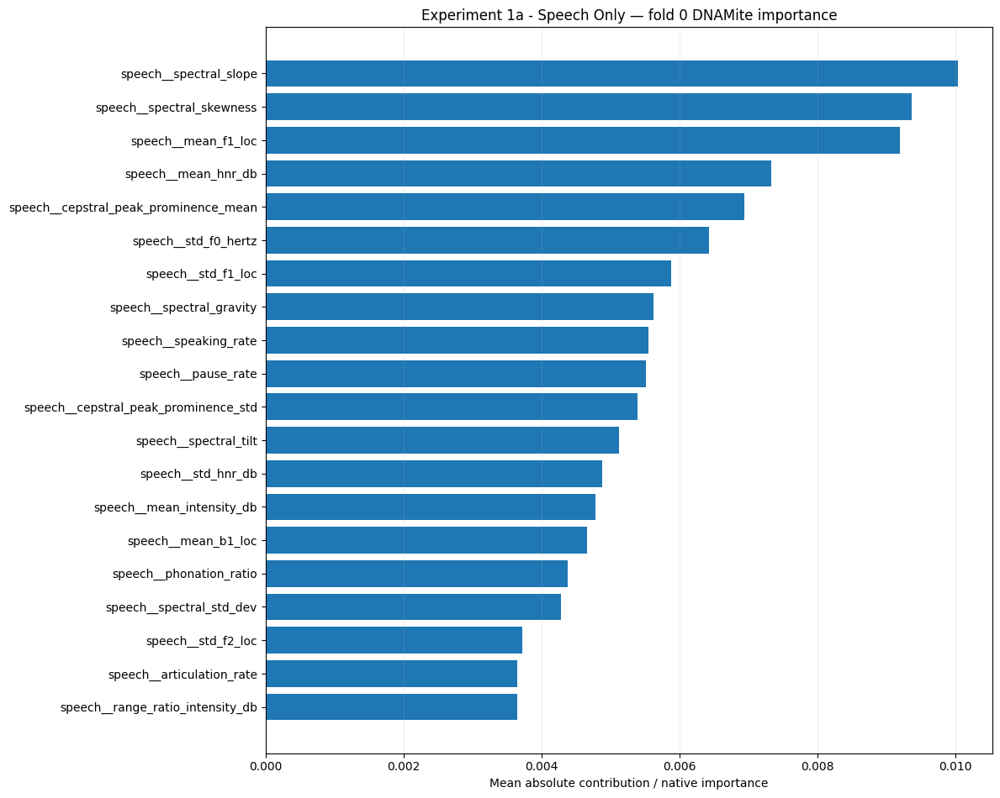

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1a_-_Speech_Only/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1a_-_Speech_Only


In [ ]:
EXPERIMENT_1A_NAME = (
    "Experiment 1a - Speech Only"
)

experiment_1a_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_1A_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 1b - Speech Only + Feature Selection
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2,
  "selection_reg_param": 0.001
}

Experiment: Experiment 1b - Speech Only + Feature Selection
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2,
  "selection_reg_param": 0.001
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.001, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.001}
Final best parameters: {'learning_rate': 0.001, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.001}
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2515.3828125 MB
  absolute peak: 2515.8984375 MB
  incremental peak: 0.515625 MB
DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=38 | best=8 | best val_loss=0.668376 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2515.890625 MB
  absolute peak: 2518.87109375 MB
  incremental peak: 2.98046875 MB
DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.686679 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2518.86328125 MB
  absolute peak: 2518.8828125 MB
  incremental peak: 0.01953125 MB
DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=40 | best=10 | best val_loss=0.636436 | hit ceiling=False
Selected probability threshold: 0.3
Development OOF balanced accuracy at threshold: 0.5118
Running final DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2518.87890625 MB
  absolute peak: 2518.8984375 MB
  incremental peak: 0.01953125 MB
Final DNAMite active features: 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 40, 'best_epoch': 10, 'best_val_loss': 0.636701226234436, 'hit_epoch_ceiling': False}]

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection
Final model saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_00/final_model_bun

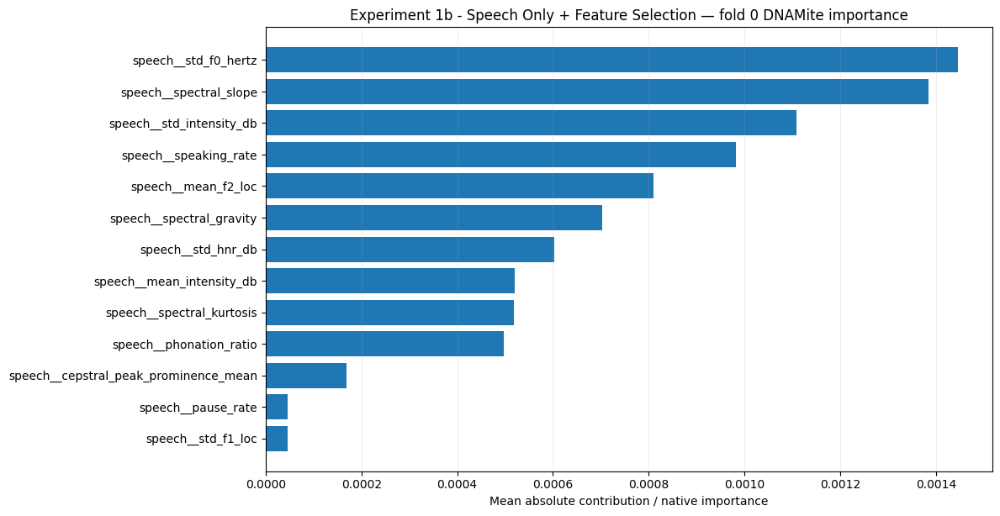

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection


In [ ]:
EXPERIMENT_1B_NAME = (
    "Experiment 1b - Speech Only + Feature Selection"
)

experiment_1b_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_1B_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=True,
    save_outputs=True,
)


Experiment: Experiment 1c - Speech Only Regression
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}

Experiment: Experiment 1c - Speech Only Regression
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.001, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
Final best parameters: {'learning_rate': 0.001, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
RAM memory:
  start: 2636.05859375 MB
  absolute peak: 2636.38671875 MB
  incremental peak: 0.328125 MB
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 34, 'best_epoch': 4, 'best_val_loss': 1.0430525541305542, 'hit_epoch_ceiling': False}]

FINAL TEST METRICS
{'MAE': 5.450296820404973, 'RMSE': np.float64(6.459427414632046), 'R2': -0.015

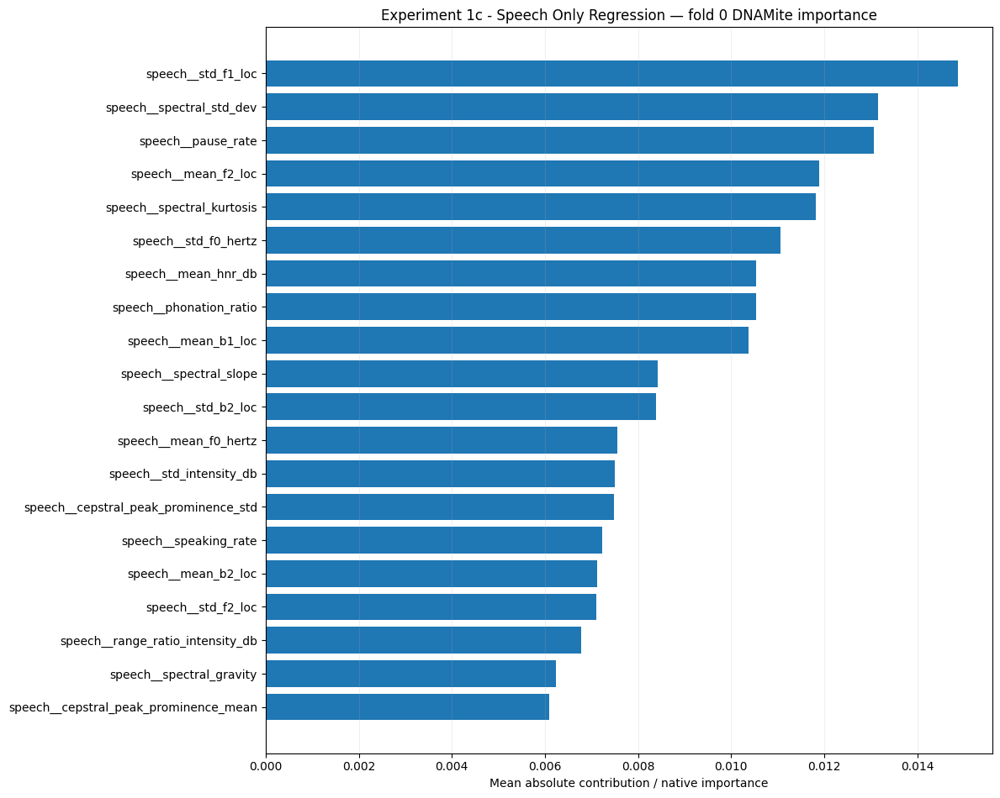

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1c_-_Speech_Only_Regression/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1c_-_Speech_Only_Regression


In [ ]:
EXPERIMENT_1C_NAME = (
    "Experiment 1c - Speech Only Regression"
)

experiment_1c_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_1C_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 1d - Speech Only + DNAMite Feature Selection
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 8,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2,
  "selection_reg_param": 0.0005
}

Experiment: Experiment 1d - Speech Only + DNAMite Feature Selection
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 8,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2,
  "selection_reg_param": 0.0005
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 8, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0005}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 8, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0005}
Running final DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2550.4453125 MB
  absolute peak: 2550.4609375 MB
  incremental peak: 0.015625 MB
Final DNAMite active features: 16 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 62, 'best_epoch': 32, 'best_val_loss': 1.0254693031311035, 'hit_epoch_ceiling': False}]

FINAL TEST METRICS
{'MAE': 5.433244906351278, 'RMSE': np.float64(6.506315420614734), 'R2': -0.030057255389790205, 'Spearman_Rho': 0.09990163174832777, 'Spearman_P': 0.5088852603530047, 'Pearson_R': 0.06457704382044244, 'Pearson_P

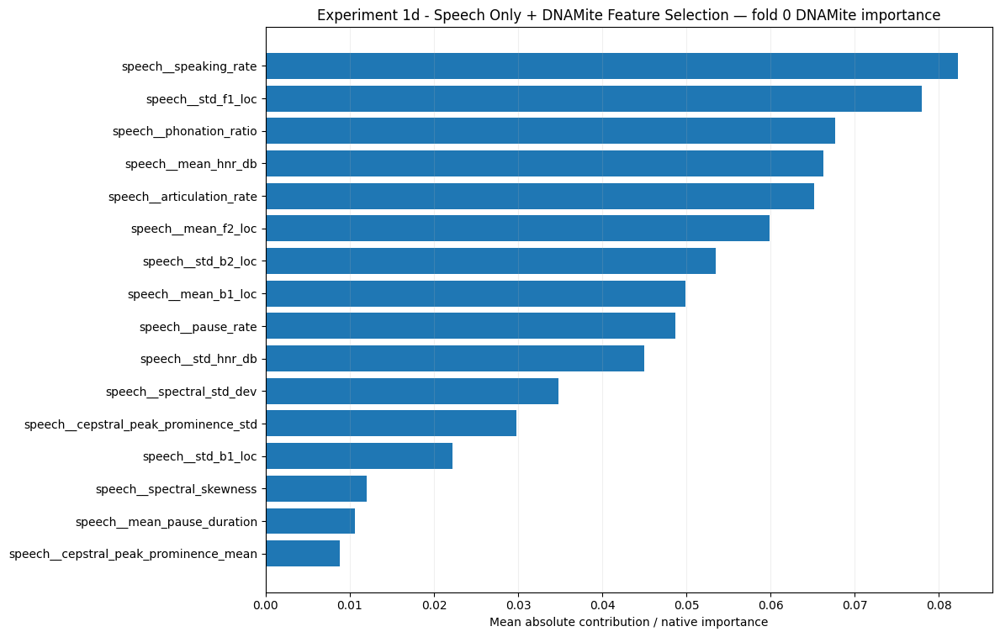

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection


In [ ]:
EXPERIMENT_1D_NAME = (
    "Experiment 1d - "
    "Speech Only + DNAMite Feature Selection"
)

experiment_1d_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_1D_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=True,
    save_outputs=True,
)


Experiment: Experiment 1e - Speech Only + Weighted BCE
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 16,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2,
  "positive_class_multiplier": 2.0
}

Experiment: Experiment 1e - Speech Only + Weighted BCE
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 16,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2,
  "positive_class_multiplier": 2.0
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.001, 'max_bins': 16, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'positive_class_multiplier': 2.0}
Final best parameters: {'learning_rate': 0.001, 'max_bins': 16, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'positive_class_multiplier': 2.0}
RAM memory:
  start: 2555.6015625 MB
  absolute peak: 2555.61328125 MB
  incremental peak: 0.01171875 MB
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=32 | best=2 | best val_loss=0.665

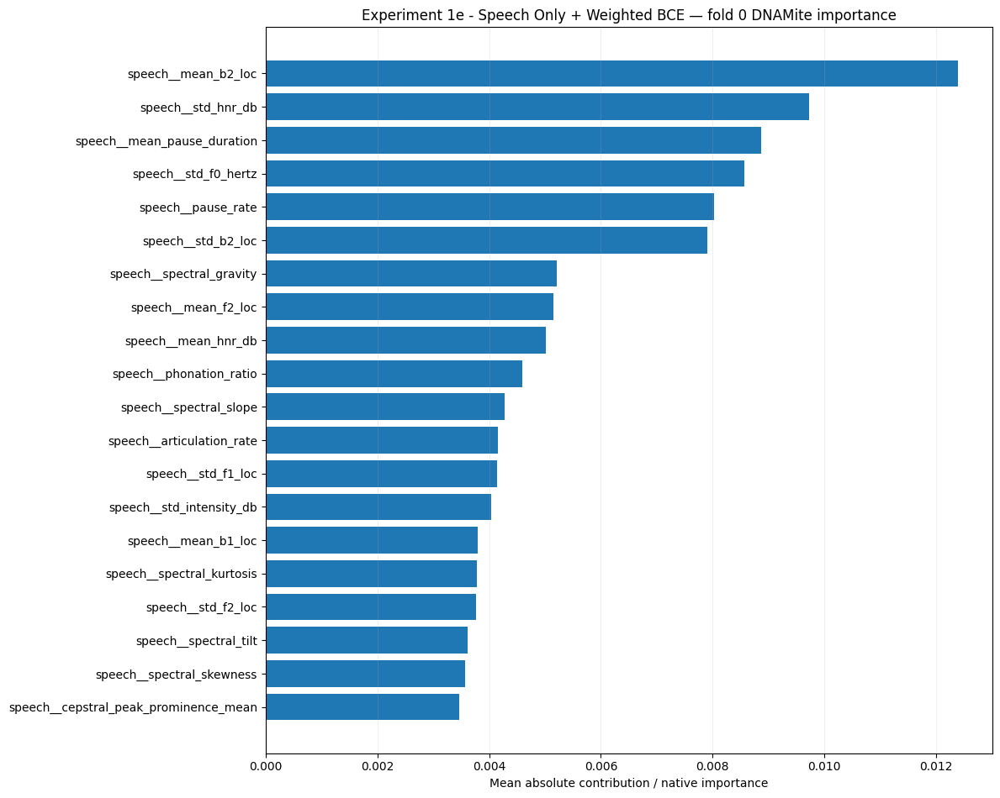

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1e_-_Speech_Only_Weighted_BCE/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1e_-_Speech_Only_Weighted_BCE


In [ ]:
EXPERIMENT_1E_NAME = (
    "Experiment 1e - Speech Only + Weighted BCE"
)

experiment_1e_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_1E_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 1f - Speech Only + LDS
Task: regression
Selected final hyperparameters:
{
  "lds_reweight_method": "sqrt_inverse",
  "lds_sigma": 0.5,
  "learning_rate": 0.001,
  "max_bins": 32,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2
}

Experiment: Experiment 1f - Speech Only + LDS
Task: regression
Selected final hyperparameters:
{
  "lds_reweight_method": "sqrt_inverse",
  "lds_sigma": 0.5,
  "learning_rate": 0.001,
  "max_bins": 32,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'lds_reweight_method': 'sqrt_inverse', 'lds_sigma': 0.5, 'learning_rate': 0.001, 'max_bins': 32, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2}
Final best parameters: {'lds_reweight_method': 'sqrt_inverse', 'lds_sigma': 0.5, 'learning_rate': 0.001, 'max_bins': 32, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2}
RAM memory:
  start: 2654.453125 MB
  absolute peak: 2654.4609375 MB
  incremental peak: 0.0078125 MB
Final DNAMite epoch diagnostics

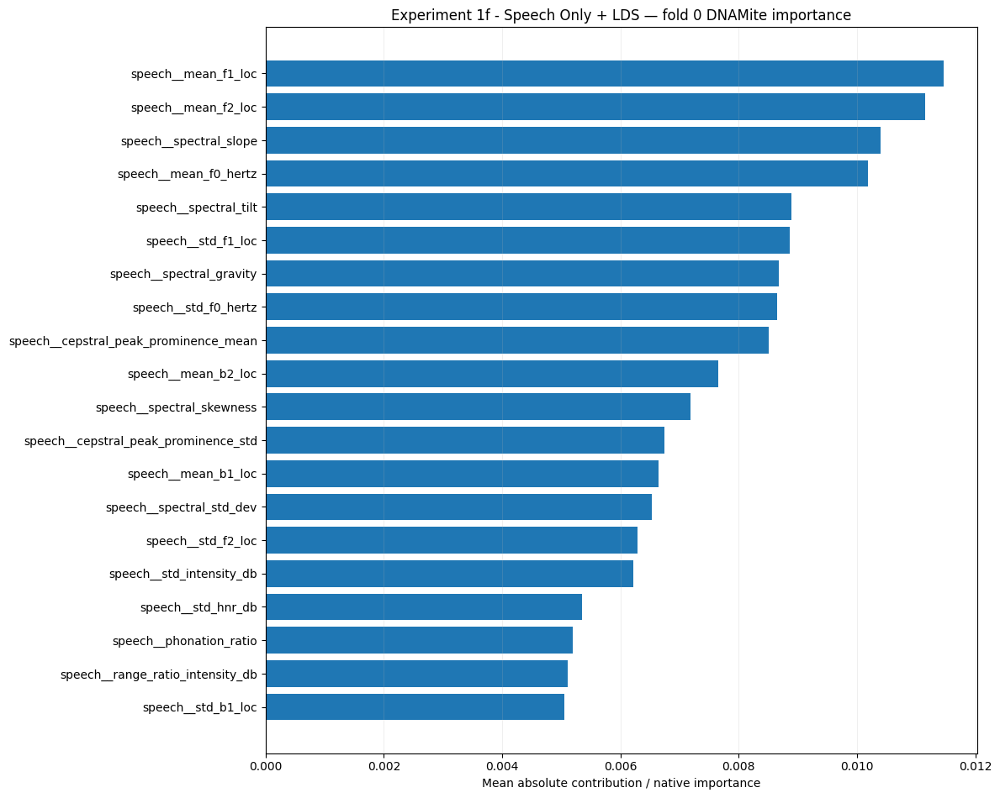

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1f_-_Speech_Only_LDS/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1f_-_Speech_Only_LDS


In [ ]:
EXPERIMENT_1F_NAME = (
    "Experiment 1f - Speech Only + LDS"
)

experiment_1f_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_1F_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 2a - Speech + TF-IDF Unigrams
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2
}

Experiment: Experiment 2a - Speech + TF-IDF Unigrams
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.001, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2}
Final best parameters: {'learning_rate': 0.001, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2}
RAM memory:
  start: 2589.02734375 MB
  absolute peak: 2589.03515625 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=32 | best=2 | best val_loss=0.668507 | hit ceiling=False
RAM memory:
  start: 2589.02734375 MB
  absolute peak: 2589.03515625 MB
  incremental peak: 0.0078125 MB
DNAMite active feat

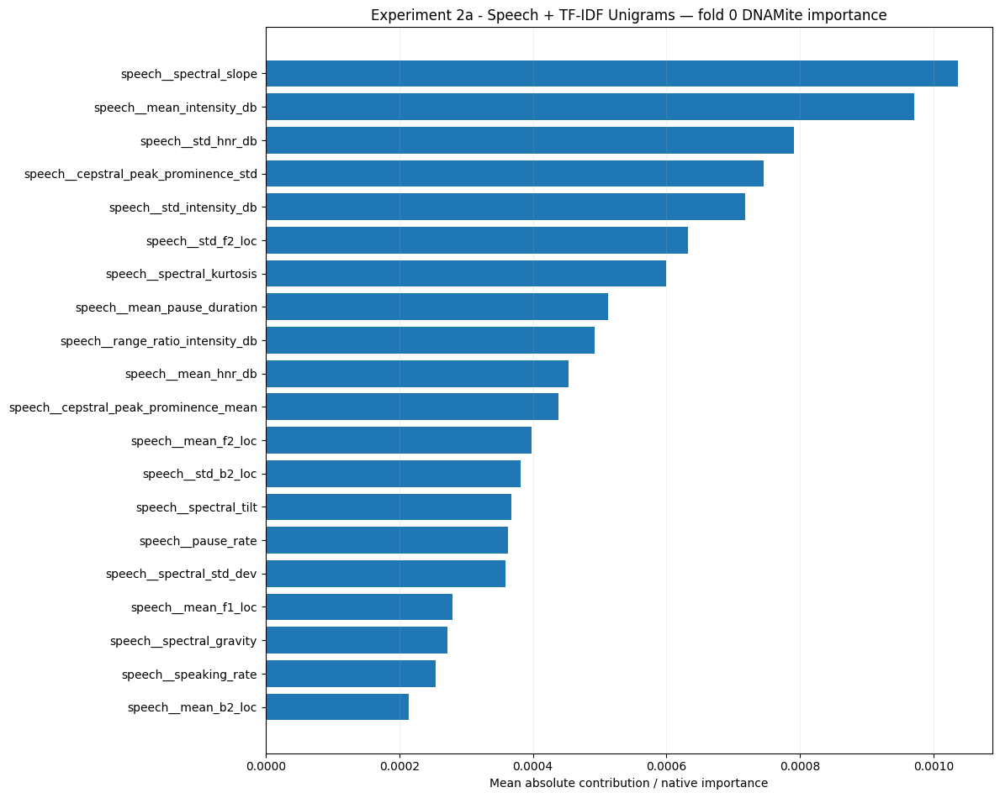

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2a_-_Speech_TF-IDF_Unigrams/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2a_-_Speech_TF-IDF_Unigrams


In [ ]:
EXPERIMENT_2A_NAME = (
    "Experiment 2a - Speech + TF-IDF Unigrams"
)

experiment_2a_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_2A_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 8,
  "n_embed": 16,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.001
}

Experiment: Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 8,
  "n_embed": 16,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.001
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 8, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 8, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2676.9140625 MB
  absolute peak: 2676.921875 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.663906 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2676.9140625 MB
  absolute peak: 2676.921875 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=39 | best=9 | best val_loss=0.687980 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2676.9140625 MB
  absolute peak: 2676.921875 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.636114 | hit ceiling=False
Selected probability threshold: 0.295
Development OOF balanced accuracy at threshold: 0.5329
Running final DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2676.9140625 MB
  absolute peak: 2676.93359375 MB
  incremental peak: 0.01953125 MB
Final DNAMite active features: 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 95, 'best_epoch': 65, 'best_val_loss': 0.6247941255569458, 'hit_epoch_ceiling': False}]

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection
Final model saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_00/final_model_bundle.pkl

Final test results save

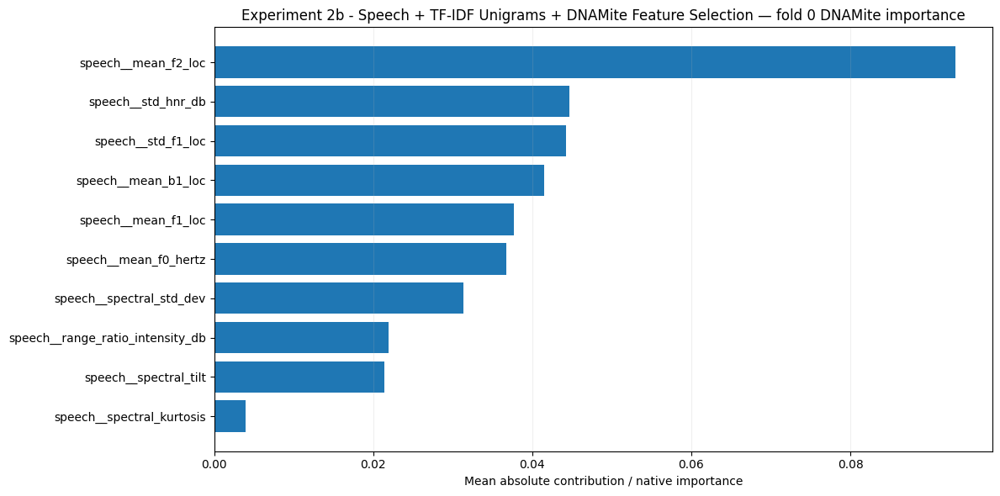

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection


In [ ]:
EXPERIMENT_2B_NAME = (
    "Experiment 2b - "
    "Speech + TF-IDF Unigrams + "
    "DNAMite Feature Selection"
)

experiment_2b_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_2B_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=True,
    save_outputs=True,
)


Experiment: Experiment 2c - Speech + TF-IDF Unigrams
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 32,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2
}

Experiment: Experiment 2c - Speech + TF-IDF Unigrams
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 32,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 32, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 32, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2}
RAM memory:
  start: 2743.234375 MB
  absolute peak: 2743.2421875 MB
  incremental peak: 0.0078125 MB
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 34, 'best_epoch': 4, 'best_val_loss': 1.0661890506744385, 'hit_epoch_ceiling': False}]

FINAL TEST METRICS
{'MAE': 5.382997766904472, 'RMSE': np.float64(6.378041390314259), 'R2': 

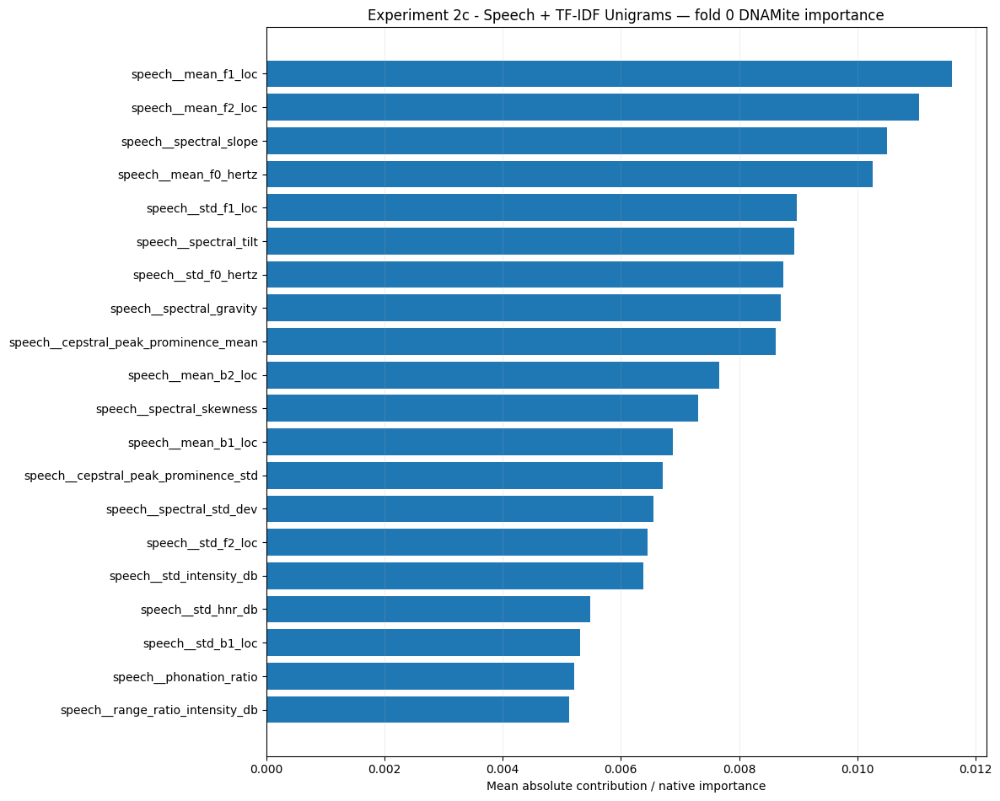

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2c_-_Speech_TF-IDF_Unigrams/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2c_-_Speech_TF-IDF_Unigrams


In [ ]:
EXPERIMENT_2C_NAME = (
    "Experiment 2c - Speech + TF-IDF Unigrams"
)

experiment_2c_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_2C_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.0005
}

Experiment: Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.0005
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Running final DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2752.2578125 MB
  absolute peak: 2752.265625 MB
  incremental peak: 0.0078125 MB
Final DNAMite active features: 27 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 61, 'best_epoch': 31, 'best_val_loss': 1.037769079208

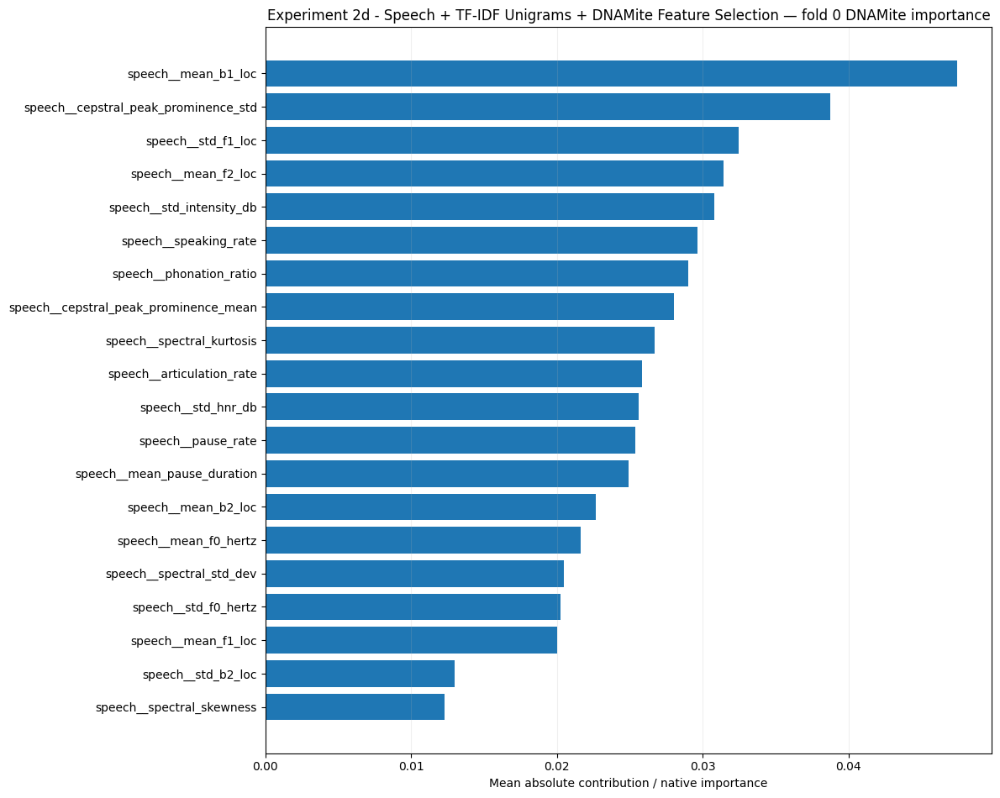

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection


In [ ]:
EXPERIMENT_2D_NAME = (
    "Experiment 2d - "
    "Speech + TF-IDF Unigrams + "
    "DNAMite Feature Selection"
)

experiment_2d_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_2D_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=True,
    save_outputs=True,
)


Experiment: Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2,
  "positive_class_multiplier": 1.5
}

Experiment: Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2,
  "positive_class_multiplier": 1.5
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.5}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.5}
RAM memory:
  start: 2752.2578125 MB
  absolute peak: 2752.265625 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=36 | best=

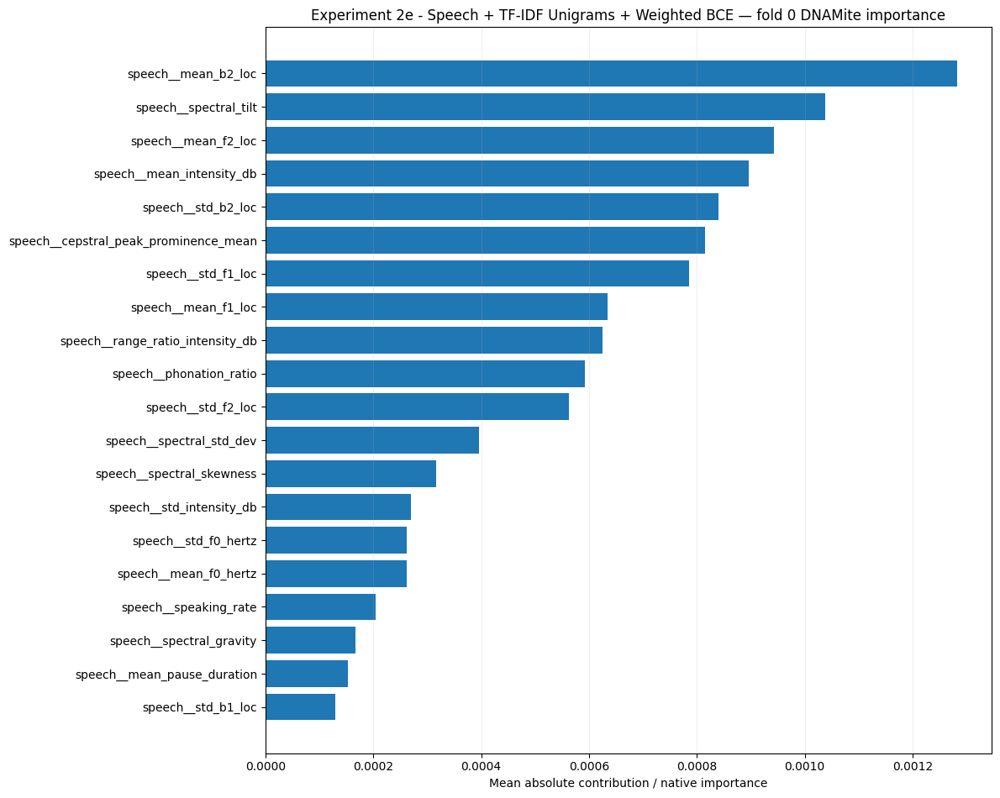

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2e_-_Speech_TF-IDF_Unigrams_Weighted_BCE/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2e_-_Speech_TF-IDF_Unigrams_Weighted_BCE


In [ ]:
EXPERIMENT_2E_NAME = (
    "Experiment 2e - "
    "Speech + TF-IDF Unigrams + Weighted BCE"
)

experiment_2e_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_2E_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 2f - Speech + TF-IDF Unigrams + LDS
Task: regression
Selected final hyperparameters:
{
  "lds_reweight_method": "inverse",
  "lds_sigma": 2.0,
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2
}

Experiment: Experiment 2f - Speech + TF-IDF Unigrams + LDS
Task: regression
Selected final hyperparameters:
{
  "lds_reweight_method": "inverse",
  "lds_sigma": 2.0,
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'lds_reweight_method': 'inverse', 'lds_sigma': 2.0, 'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2}
Final best parameters: {'lds_reweight_method': 'inverse', 'lds_sigma': 2.0, 'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2}
RAM memory:
  start: 2752.2421875 MB
  absolute peak: 2752.25 MB
  incremental peak: 0.0078125 MB
Final DNAMite epoch diagn

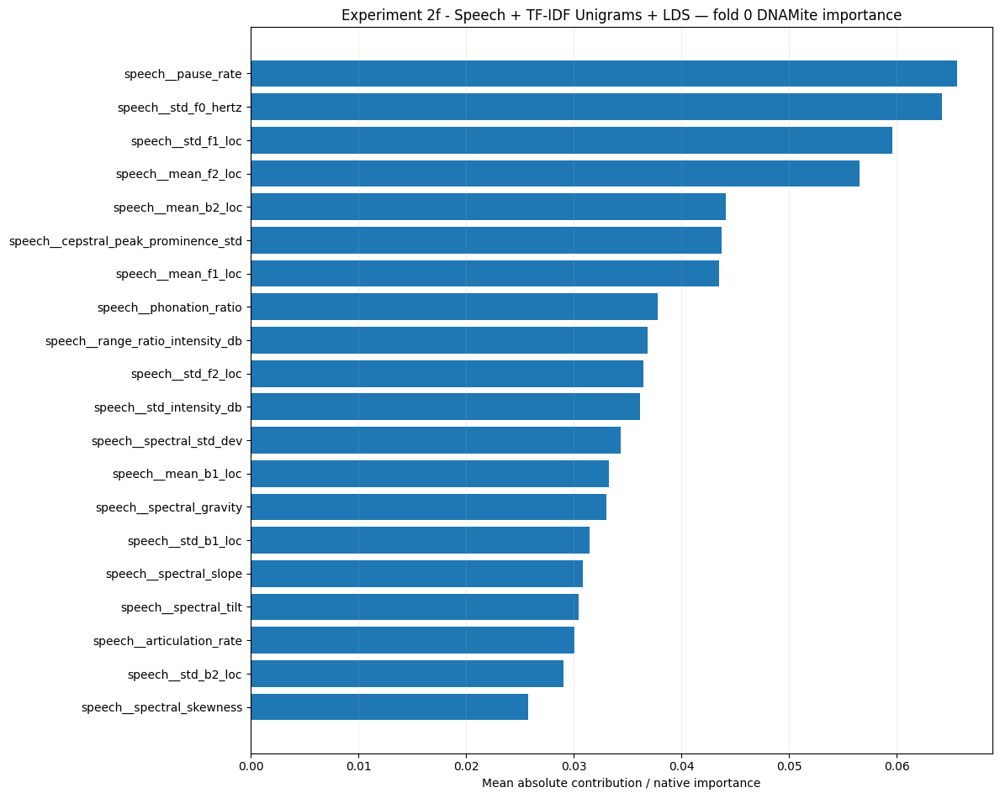

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2f_-_Speech_TF-IDF_Unigrams_LDS/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2f_-_Speech_TF-IDF_Unigrams_LDS


In [ ]:
EXPERIMENT_2F_NAME = (
    "Experiment 2f - "
    "Speech + TF-IDF Unigrams + LDS"
)

experiment_2f_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_2F_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 3a - Speech + TF-IDF Unigrams/Bigrams
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2
}

Experiment: Experiment 3a - Speech + TF-IDF Unigrams/Bigrams
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 4,
  "n_embed": 32,
  "n_hidden": 32,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2}
RAM memory:
  start: 2777.1953125 MB
  absolute peak: 2777.21484375 MB
  incremental peak: 0.01953125 MB
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.668523 | hit ceiling=False
RAM memory:
  start: 2777.20703125 MB
  absolute peak: 2777.21484375 MB
  incremental peak: 0.0078125 MB

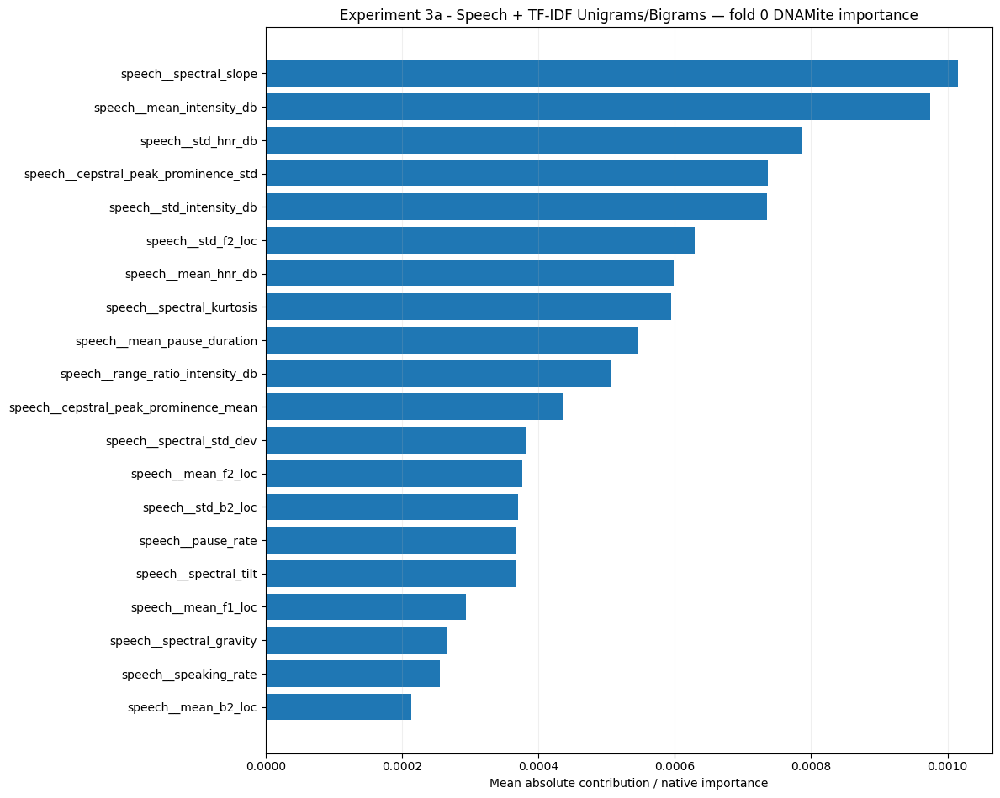

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3a_-_Speech_TF-IDF_Unigrams_Bigrams/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3a_-_Speech_TF-IDF_Unigrams_Bigrams


In [ ]:
EXPERIMENT_3A_NAME = (
    "Experiment 3a - "
    "Speech + TF-IDF Unigrams/Bigrams"
)

experiment_3a_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_3A_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 8,
  "n_embed": 16,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.001
}

Experiment: Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.001,
  "max_bins": 8,
  "n_embed": 16,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.001
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.001, 'max_bins': 8, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Final best parameters: {'learning_rate': 0.001, 'max_bins': 8, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2770.0078125 MB
  absolute peak: 2770.015625 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=38 | best=8 | best val_loss=0.664084 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2770.0078125 MB
  absolute peak: 2770.015625 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.687989 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2770.0078125 MB
  absolute peak: 2770.015625 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=0.636065 | hit ceiling=False
Selected probability threshold: 0.295
Development OOF balanced accuracy at threshold: 0.5329
Running final DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2770.0078125 MB
  absolute peak: 2770.02734375 MB
  incremental peak: 0.01953125 MB
Final DNAMite active features: 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 69, 'best_epoch': 39, 'best_val_loss': 0.624359130859375, 'hit_epoch_ceiling': False}]

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection
Final model saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_00/final_model_bundle.pkl

Final te

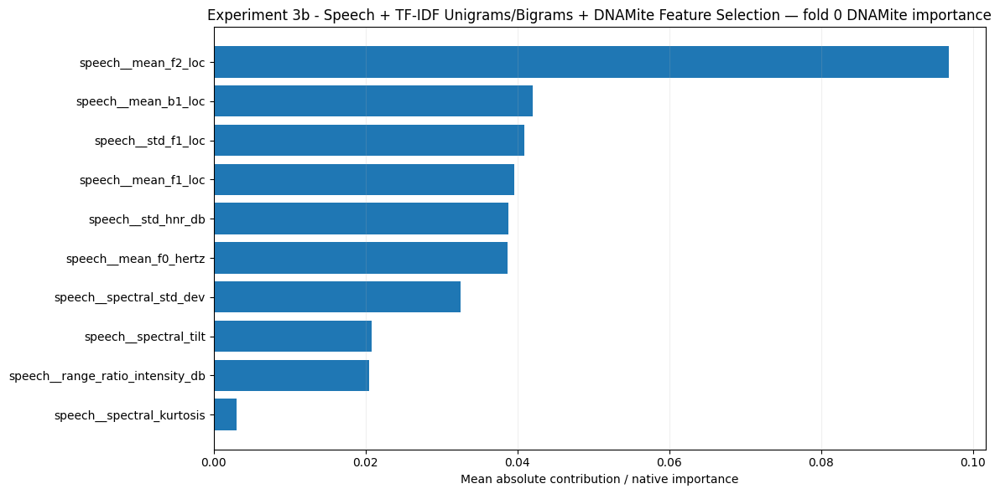

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection


In [ ]:
EXPERIMENT_3B_NAME = (
    "Experiment 3b - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "DNAMite Feature Selection"
)

experiment_3b_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_3B_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=True,
    save_outputs=True,
)


Experiment: Experiment 3c - Speech + TF-IDF Unigrams/Bigrams
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}

Experiment: Experiment 3c - Speech + TF-IDF Unigrams/Bigrams
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
RAM memory:
  start: 2818.85546875 MB
  absolute peak: 2818.86328125 MB
  incremental peak: 0.0078125 MB
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 37, 'best_epoch': 7, 'best_val_loss': 1.0466212034225464, 'hit_epoch_ceiling': False}]

FINAL TEST METRICS
{'MAE': 5.4591296505111275, 'RMSE': np.float64(6.4531

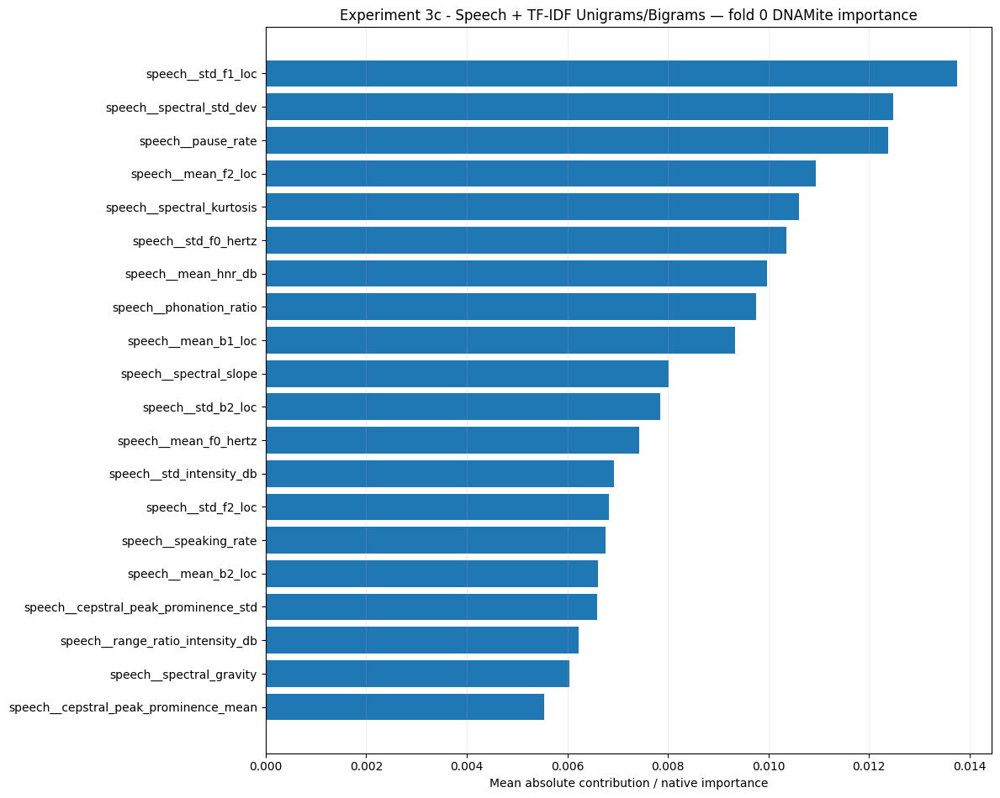

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3c_-_Speech_TF-IDF_Unigrams_Bigrams/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3c_-_Speech_TF-IDF_Unigrams_Bigrams


In [ ]:
EXPERIMENT_3C_NAME = (
    "Experiment 3c - "
    "Speech + TF-IDF Unigrams/Bigrams"
)

experiment_3c_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_3C_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 8,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.0005
}

Experiment: Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection
Task: regression
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 8,
  "n_embed": 32,
  "n_hidden": 16,
  "n_layers": 2,
  "selection_reg_param": 0.0005
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 8, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 8, 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Running final DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


RAM memory:
  start: 2818.85546875 MB
  absolute peak: 2818.86328125 MB
  incremental peak: 0.0078125 MB
Final DNAMite active features: 28 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 33, 'best_epoch': 3, 

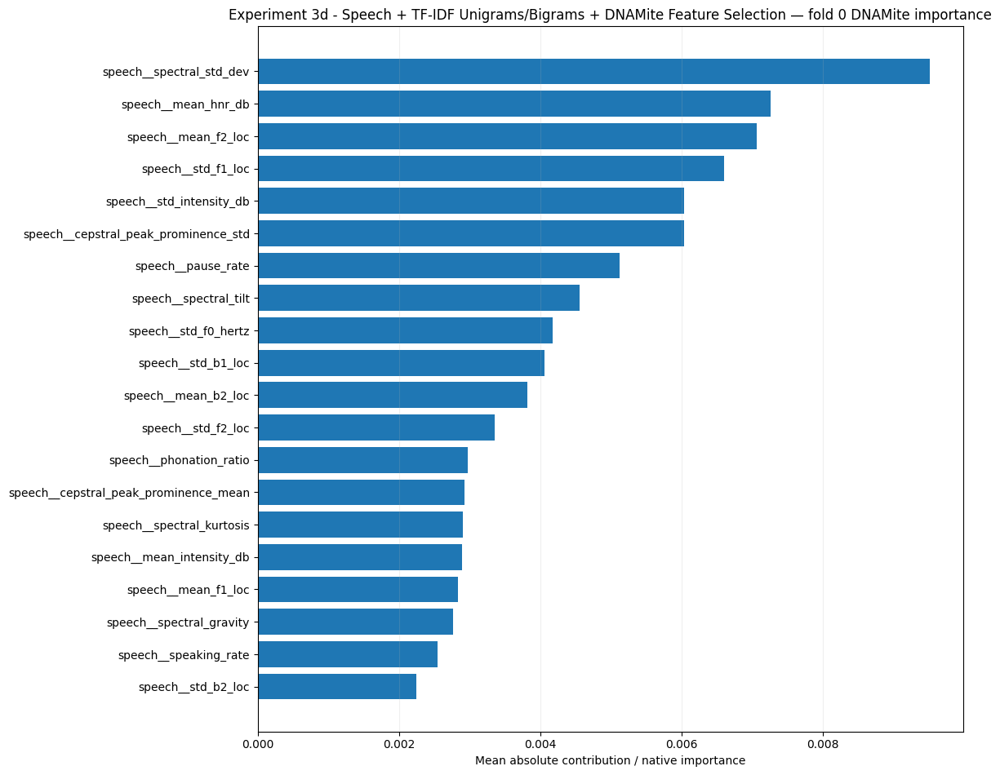

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection


In [ ]:
EXPERIMENT_3D_NAME = (
    "Experiment 3d - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "DNAMite Feature Selection"
)

experiment_3d_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_3D_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=True,
    save_outputs=True,
)


Experiment: Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 32,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2,
  "positive_class_multiplier": 1.5
}

Experiment: Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE
Task: classification
Selected final hyperparameters:
{
  "learning_rate": 0.0005,
  "max_bins": 32,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2,
  "positive_class_multiplier": 1.5
}
Using preselected outer-CV hyperparameters: {'learning_rate': 0.0005, 'max_bins': 32, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'positive_class_multiplier': 1.5}
Final best parameters: {'learning_rate': 0.0005, 'max_bins': 32, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'positive_class_multiplier': 1.5}
RAM memory:
  start: 2704.5 MB
  absolute peak: 2704.5078125 MB
  incremental peak: 0.0078125 MB
DNAMite active features | 28 / 28
DNAMite epochs | split=1 |

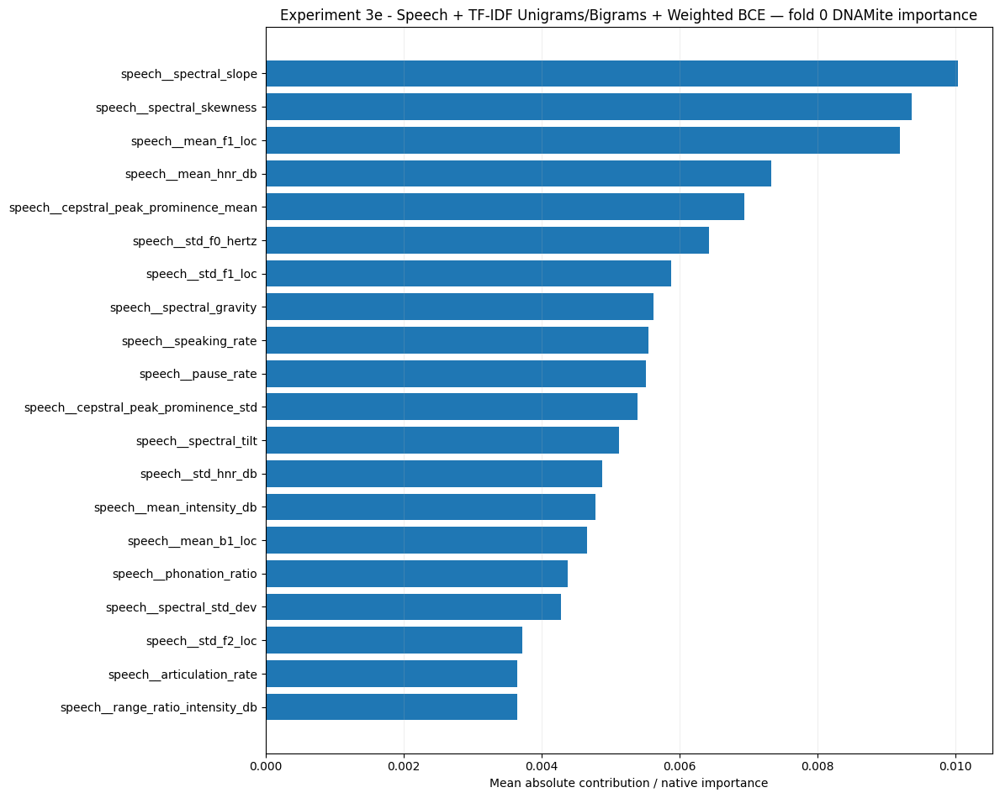

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3e_-_Speech_TF-IDF_Unigrams_Bigrams_Weighted_BCE/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3e_-_Speech_TF-IDF_Unigrams_Bigrams_Weighted_BCE


In [ ]:
EXPERIMENT_3E_NAME = (
    "Experiment 3e - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "Weighted BCE"
)

experiment_3e_binary_final = train_final_dnamite_from_saved_folds(
    task="classification",
    experiment_name=EXPERIMENT_3E_NAME,
    speech_development=development_speech,
    y_development=y_binary_development,
    speech_test=test_speech,
    y_test=y_binary_test,
    use_feature_selection=False,
    save_outputs=True,
)


Experiment: Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS
Task: regression
Selected final hyperparameters:
{
  "lds_reweight_method": "sqrt_inverse",
  "lds_sigma": 4.0,
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}

Experiment: Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS
Task: regression
Selected final hyperparameters:
{
  "lds_reweight_method": "sqrt_inverse",
  "lds_sigma": 4.0,
  "learning_rate": 0.0005,
  "max_bins": 16,
  "n_embed": 16,
  "n_hidden": 32,
  "n_layers": 2
}
Using preselected outer-CV hyperparameters: {'lds_reweight_method': 'sqrt_inverse', 'lds_sigma': 4.0, 'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
Final best parameters: {'lds_reweight_method': 'sqrt_inverse', 'lds_sigma': 4.0, 'learning_rate': 0.0005, 'max_bins': 16, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
RAM memory:
  start: 2726.046875 MB
  absolute peak: 2726.0546875 MB
  incremental peak

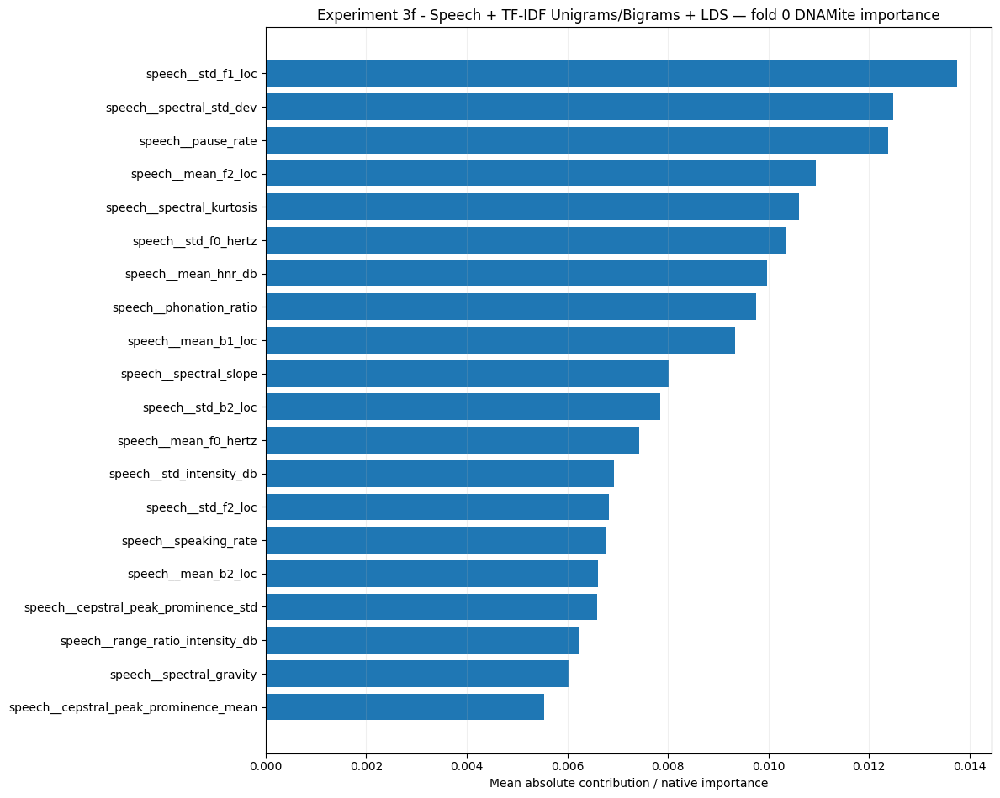

Final model: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams_LDS/final
Final results: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams_LDS


In [ ]:
EXPERIMENT_3F_NAME = (
    "Experiment 3f - "
    "Speech + TF-IDF Unigrams/Bigrams + LDS"
)

experiment_3f_regression_final = train_final_dnamite_from_saved_folds(
    task="regression",
    experiment_name=EXPERIMENT_3F_NAME,
    speech_development=development_speech,
    y_development=y_regression_development,
    speech_test=test_speech,
    y_test=y_regression_test,
    use_feature_selection=False,
    save_outputs=True,
)

## EXPERIMENT 1 — SPEECH ONLY

### Experiment 1a binary nested CV

[codecarbon WARNING @ 19:36:52] Multiple instances of codecarbon are allowed to run at the same time.



Experiment 1a - Speech Only | Classification | Outer fold 1
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=71 | best=41 | best val_loss=0.580768 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=71 | best=41 | best val_loss=0.516538 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=57 | best=27 | best val_loss=0.636976 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.579691 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=46 | best=16 | best val_loss=0.515324 | hit ceiling=False
  Inner fold 3/3


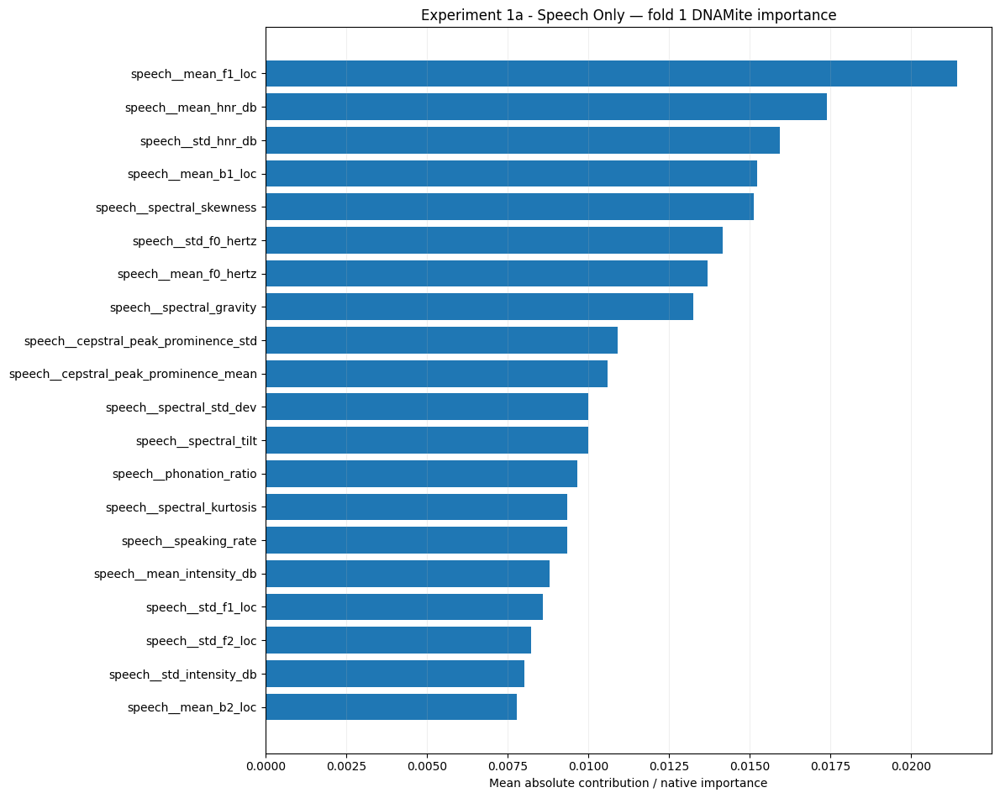

ROC_AUC              0.651316
PR_AUC               0.344688
AUPRC                0.344688
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208478
Log_Loss             0.607630
Threshold            0.050000
dtype: float64

Experiment 1a - Speech Only | Classification | Outer fold 2
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=72 | best=42 | best val_loss=0.578763 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=57 | best=27 | best val_loss=0.635588 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=68 | best=38 | best val_loss=0.580388 | hit ceiling=False
DNAMite candidate 2/32: {'learnin

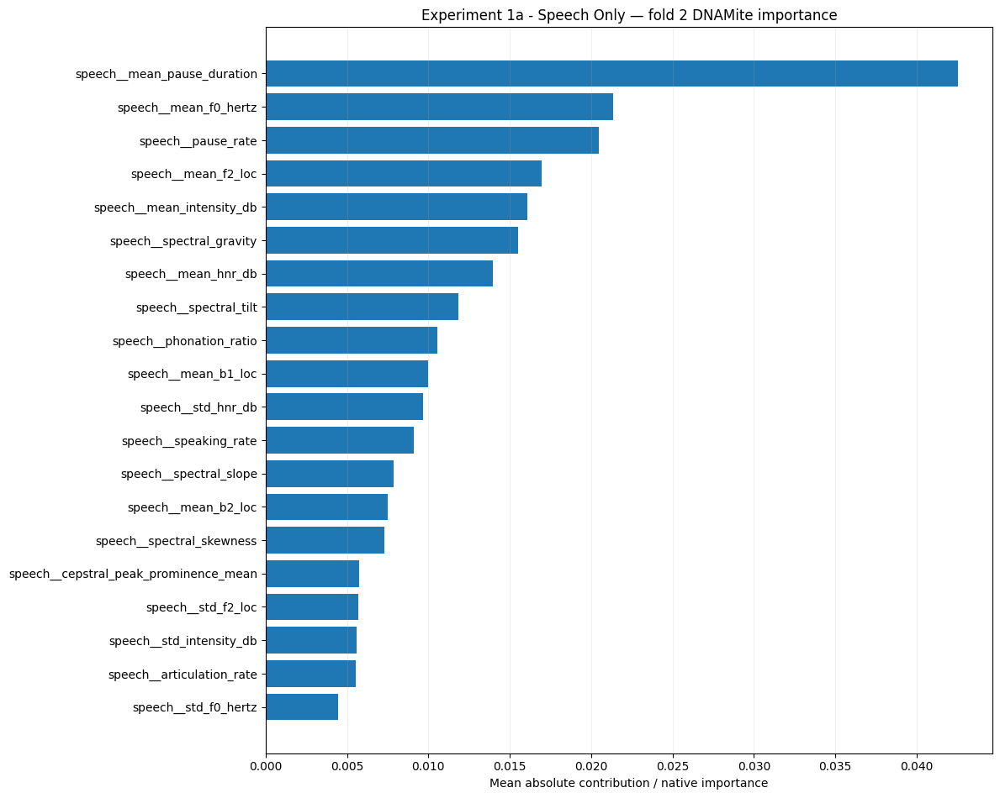

ROC_AUC              0.631579
PR_AUC               0.359346
AUPRC                0.359346
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208220
Log_Loss             0.607015
Threshold            0.285000
dtype: float64

Experiment 1a - Speech Only | Classification | Outer fold 3
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=57 | best=27 | best val_loss=0.635661 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=57 | best=27 | best val_loss=0.636588 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=70 | best=40 | best val_loss=0.516192 | hit ceiling=False
DNAMite candidate 2/32: {'learnin

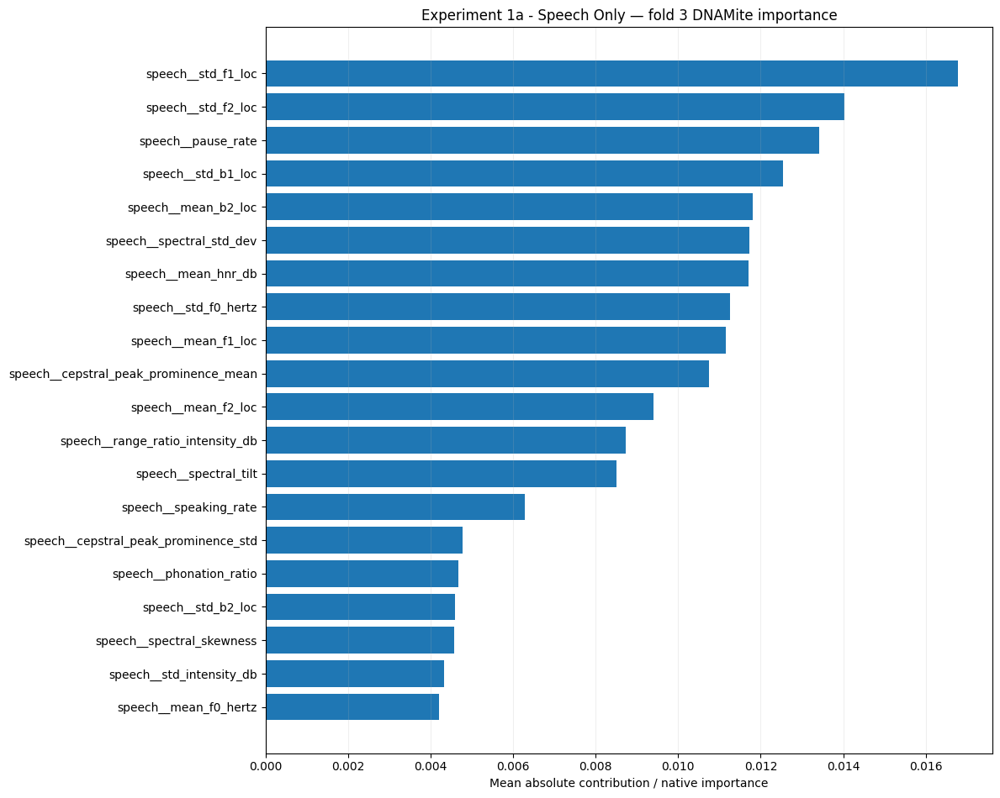

ROC_AUC              0.486842
PR_AUC               0.296531
AUPRC                0.296531
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208490
Log_Loss             0.607683
Threshold            0.345000
dtype: float64

Experiment 1a - Speech Only | Classification | Outer fold 4
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=70 | best=40 | best val_loss=0.580992 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=78 | best=48 | best val_loss=0.579347 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=70 | best=40 | best val_loss=0.516407 | hit ceiling=False
DNAMite candidate 2/32: {'learnin

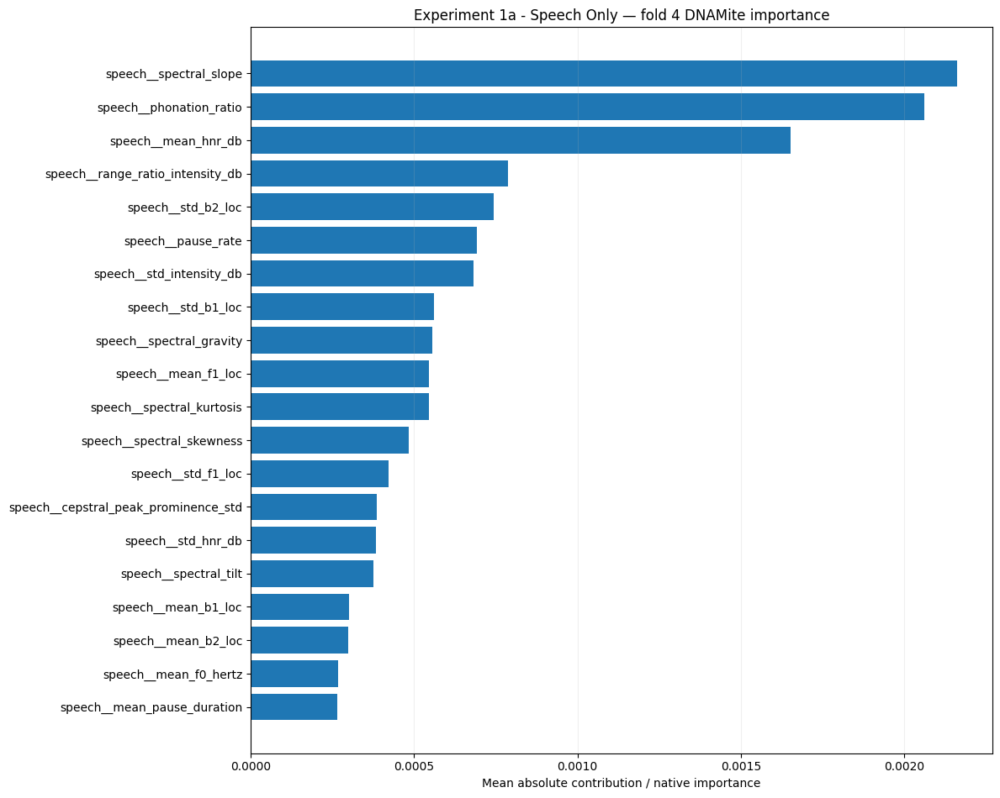

ROC_AUC              0.282895
PR_AUC               0.205013
AUPRC                0.205013
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208511
Log_Loss             0.607709
Threshold            0.295000
dtype: float64

Experiment 1a - Speech Only | Classification | Outer fold 5
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=66 | best=36 | best val_loss=0.443103 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=67 | best=37 | best val_loss=0.579559 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=57 | best=27 | best val_loss=0.635941 | hit ceiling=False
DNAMite candidate 2/32: {'learnin

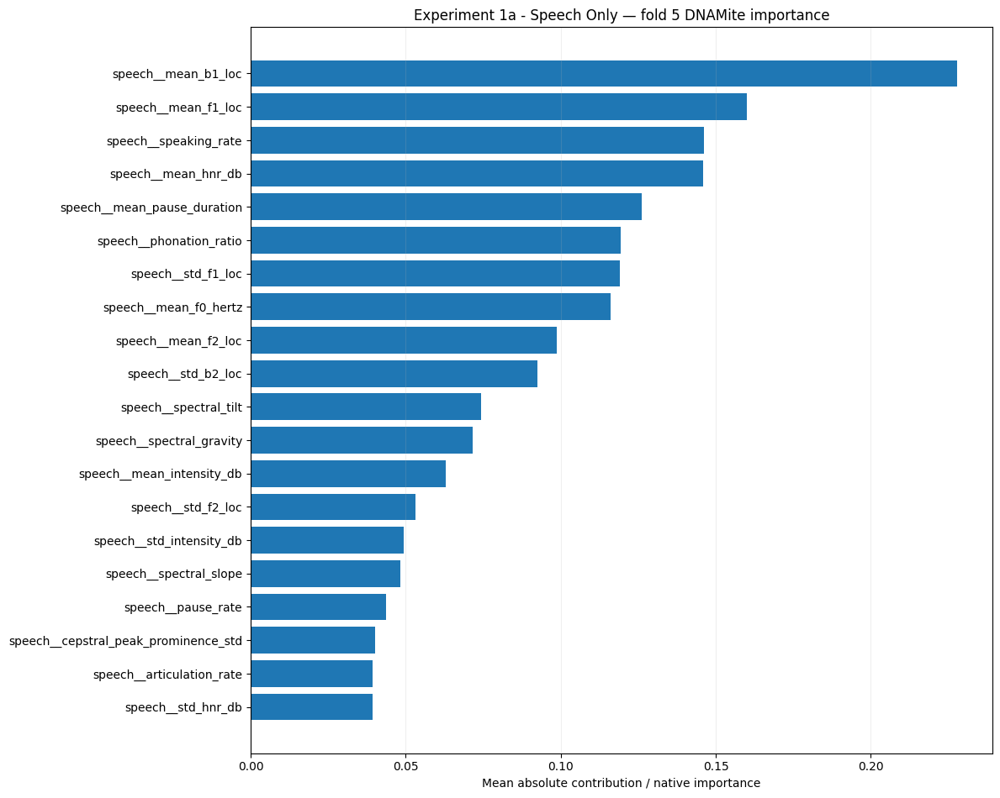

ROC_AUC              0.532895
PR_AUC               0.402340
AUPRC                0.402340
Accuracy             0.592593
Balanced_Accuracy    0.565789
Precision            0.363636
Sensitivity          0.500000
Specificity          0.631579
F1                   0.421053
Brier_Score          0.208411
Log_Loss             0.607559
Threshold            0.310000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.517105,0.147594
PR_AUC,0.321584,0.075329
AUPRC,0.321584,0.075329
Accuracy,0.437037,0.196680
Balanced_Accuracy,0.513158,0.029422
Precision,0.250505,0.143040
Sensitivity,0.700000,0.447214
Specificity,0.326316,0.465425
F1,0.358496,0.201014
Brier_Score,0.208422,0.000119



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
1,2,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
2,3,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
3,4,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
4,5,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
EXPERIMENT_1A_NAME = (
    "Experiment 1a - Speech Only"
)

experiment_1a_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_1A_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        use_feature_selection=False,
    )
)


--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1a_-_Speech_Only
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


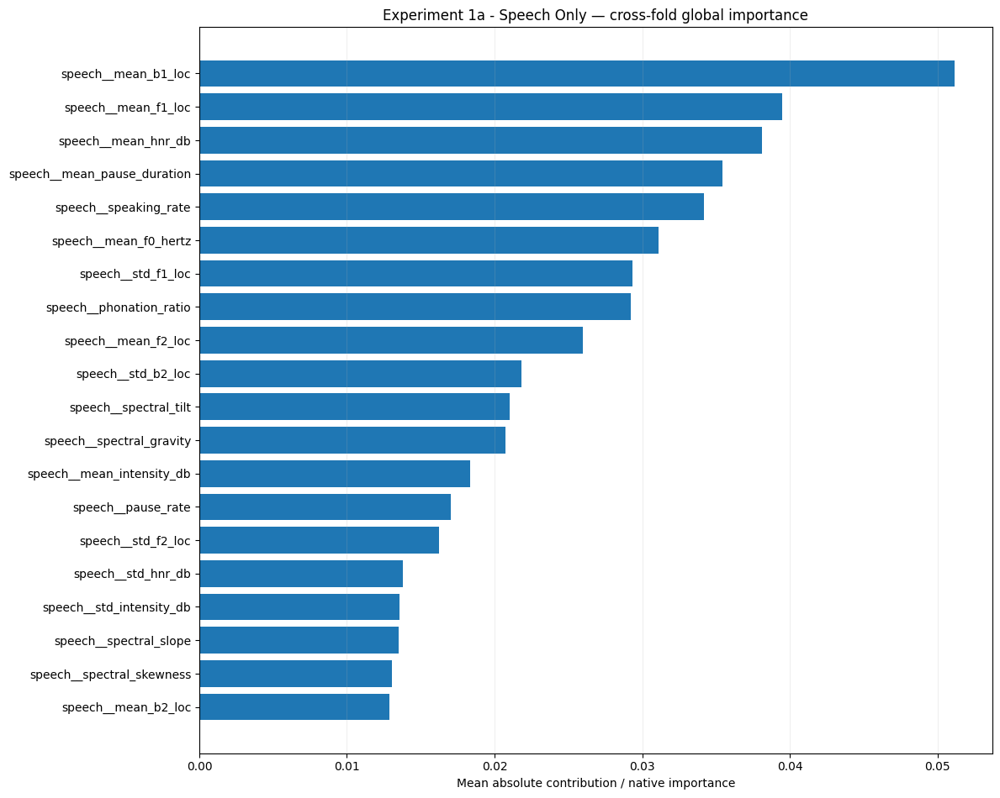

Interpretability summary saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1a_-_Speech_Only/interpretability_summary


In [ ]:
experiment_1a_binary_interpretability = (
    aggregate_interpretability_across_folds(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1A_NAME
        ),
        top_k=10,
    )
)

print(
    "Interpretability summary saved to:"
)

print(
    experiment_1a_binary_interpretability
)

In [ ]:
experiment_1a_energy = (
    summarize_energy_utilization(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1A_NAME
        ),
    )
)

,Mean,SD,Min,Max
training_energy_kwh,0.000019,0.000005,0.000016,0.000028
training_co2_kg,0.000009,0.000002,0.000008,0.000013


### Experiment 1a binary development confusion matrix

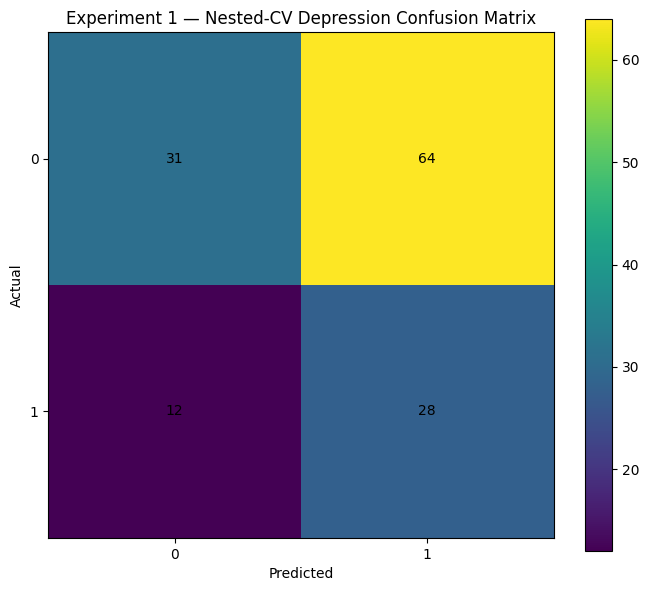

In [ ]:
experiment_1a_binary_cv_cm = (
    plot_confusion_matrix(
        y_true=(
            y_binary_development
        ),
        y_pred=(
            experiment_1a_binary_cv[
                "oof_predictions"
            ]
        ),
        labels=[
            0,
            1,
        ],
        title=(
            "Experiment 1 — "
            "Nested-CV Depression Confusion Matrix"
        ),
    )
)

### Experiment 1a final binary model

In [ ]:
experiment_1a_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        experiment_name=(
            EXPERIMENT_1A_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)


print(
    "\nFINAL TEST METRICS"
)

display(
    pd.Series(
        experiment_1a_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=79 | best=49 | best val_loss=0.590059 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=70 | best=40 | best val_loss=0.537777 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=70 | best=40 | best val_loss=0.485201 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.589566 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=46 | best=16 | best val_loss=0.537264 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | 

,Value
ROC_AUC,0.575893
PR_AUC,0.328077
AUPRC,0.328077
Accuracy,0.304348
Balanced_Accuracy,0.500000
Precision,0.304348
Sensitivity,1.000000
Specificity,0.000000
F1,0.466667
Brier_Score,0.211740


In [ ]:
print(
    "Experiment 1a best parameters =",
    experiment_1a_binary_final[
        "best_parameters"
    ]
)

Experiment 1a best parameters = {'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}


### Experiment 1a binary test plots

In [ ]:
model = experiment_1a_binary_final[
    "model"
]

X_test = experiment_1a_binary_final[
    "X_test"
]

raw_prob = np.asarray(
    model.predict_proba(X_test)
).reshape(-1)

print(
    pd.Series(raw_prob).describe()
)

print(
    "Unique:",
    len(np.unique(raw_prob))
)

print("=== RAW DNAMITE TEST PROBABILITIES ===")

print(
    "min:",
    raw_prob.min()
)

print(
    "max:",
    raw_prob.max()
)

print(
    "mean:",
    raw_prob.mean()
)

print(
    "std:",
    raw_prob.std()
)

print(
    "n unique:",
    len(
        np.unique(raw_prob)
    )
)

print(
    "\nFirst 20:"
)

print(
    raw_prob[:20]
)

count    46.000000
mean      0.325918
std       0.008237
min       0.304075
25%       0.320290
50%       0.325377
75%       0.332050
max       0.340995
dtype: float64
Unique: 46
=== RAW DNAMITE TEST PROBABILITIES ===
min: 0.3040747077551081
max: 0.3409953217445421
mean: 0.32591838789752886
std: 0.008147429870399825
n unique: 46

First 20:
[0.33853309 0.32861559 0.31730251 0.32938227 0.33034928 0.31971272
 0.32776627 0.32055413 0.32526705 0.32020258 0.32800188 0.32521107
 0.31862943 0.31939987 0.32098872 0.3221006  0.31398713 0.30741966
 0.33915242 0.33341423]


In [ ]:
calibrator = experiment_1a_binary_final[
    "calibrator"
]

print(
    "Coefficient:",
    calibrator.coef_
)

print(
    "Intercept:",
    calibrator.intercept_
)

print(
    "Classes:",
    calibrator.classes_
)

Coefficient: [[-0.03540208]]
Intercept: [-0.88228686]
Classes: [0 1]


In [ ]:
result = experiment_1a_binary_final

print(
    result.keys()
)

dict_keys(['model', 'best_parameters', 'search_results', 'calibrator', 'threshold', 'selected_text_indices', 'X_development', 'X_test', 'raw_test_probabilities', 'test_probabilities', 'test_predictions', 'test_metrics', 'resource_metrics', 'energy_metrics', 'epoch_diagnostics', 'development_oof_raw', 'development_oof_calibrated', 'active_feature_indices', 'active_feature_names', 'selection_reg_param', 'final_results_root', 'model_path'])


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ============================================================
# Raw out-of-fold predictions used to train the calibrator
# ============================================================

raw_oof = np.asarray(
    experiment_1a_binary_final[
        "development_oof_raw"
    ]
).reshape(-1)

y_dev = np.asarray(
    y_binary_development
).reshape(-1)


# ============================================================
# Sanity check
# ============================================================

print("=== SHAPES ===")

print(
    "OOF predictions:",
    raw_oof.shape
)

print(
    "Development labels:",
    y_dev.shape
)

assert len(raw_oof) == len(y_dev), (
    f"Length mismatch: "
    f"{len(raw_oof)} OOF predictions vs "
    f"{len(y_dev)} labels"
)


# ============================================================
# Raw OOF probability distribution
# ============================================================

print(
    "\n=== RAW DEVELOPMENT OOF ==="
)

print(
    pd.Series(raw_oof).describe()
)

print(
    "\nUnique:",
    len(np.unique(raw_oof))
)

print(
    "Range:",
    raw_oof.max() - raw_oof.min()
)

print(
    "SD:",
    raw_oof.std()
)


# ============================================================
# Label distribution
# ============================================================

print(
    "\n=== LABEL DISTRIBUTION ==="
)

labels, counts = np.unique(
    y_dev,
    return_counts=True,
)

print(
    dict(zip(labels, counts))
)

print(
    "Positive prevalence:",
    y_dev.mean()
)


# ============================================================
# Raw predictions by true class
# ============================================================

comparison_df = pd.DataFrame({
    "raw_oof_probability": raw_oof,
    "true_label": y_dev,
})

print(
    "\n=== RAW OOF BY CLASS ==="
)

display(
    comparison_df
    .groupby("true_label")[
        "raw_oof_probability"
    ]
    .describe()
)


# ============================================================
# Discrimination BEFORE calibration
# ============================================================

print(
    "\n=== RAW OOF PERFORMANCE ==="
)

raw_roc_auc = roc_auc_score(
    y_dev,
    raw_oof,
)

raw_pr_auc = average_precision_score(
    y_dev,
    raw_oof,
)

print(
    "ROC-AUC:",
    raw_roc_auc
)

print(
    "PR-AUC:",
    raw_pr_auc
)


# ============================================================
# Correlation
# ============================================================

correlation = np.corrcoef(
    raw_oof,
    y_dev,
)[0, 1]

print(
    "\nCorrelation:",
    correlation
)


# ============================================================
# Calibrator
# ============================================================

calibrator = experiment_1a_binary_final[
    "calibrator"
]

print(
    "\n=== CALIBRATOR ==="
)

print(
    "Coefficient:",
    calibrator.coef_
)

print(
    "Intercept:",
    calibrator.intercept_
)

print(
    "Calibrated OOF unique values:",
    len(
        np.unique(
            experiment_1a_binary_final[
                "development_oof_calibrated"
            ]
        )
    )
)

=== SHAPES ===
OOF predictions: (135,)
Development labels: (135,)

=== RAW DEVELOPMENT OOF ===
count    135.000000
mean       0.381151
std        0.051704
min        0.307825
25%        0.334869
50%        0.365711
75%        0.445677
max        0.461657
dtype: float64

Unique: 135
Range: 0.15383189348732446
SD: 0.05151172860583714

=== LABEL DISTRIBUTION ===
{np.int64(0): np.int64(95), np.int64(1): np.int64(40)}
Positive prevalence: 0.2962962962962963

=== RAW OOF BY CLASS ===


,count,mean,std,min,25%,50%,75%,max
true_label,,,,,,,,
0,95.0,0.381345,0.051508,0.307825,0.335739,0.365915,0.445257,0.460957
1,40.0,0.380689,0.052821,0.308896,0.334711,0.361899,0.447129,0.461657



=== RAW OOF PERFORMANCE ===
ROC-AUC: 0.5081578947368421
PR-AUC: 0.3585106058904808

Correlation: -0.005814392042702971

=== CALIBRATOR ===
Coefficient: [[-0.03540208]]
Intercept: [-0.88228686]
Calibrated OOF unique values: 135


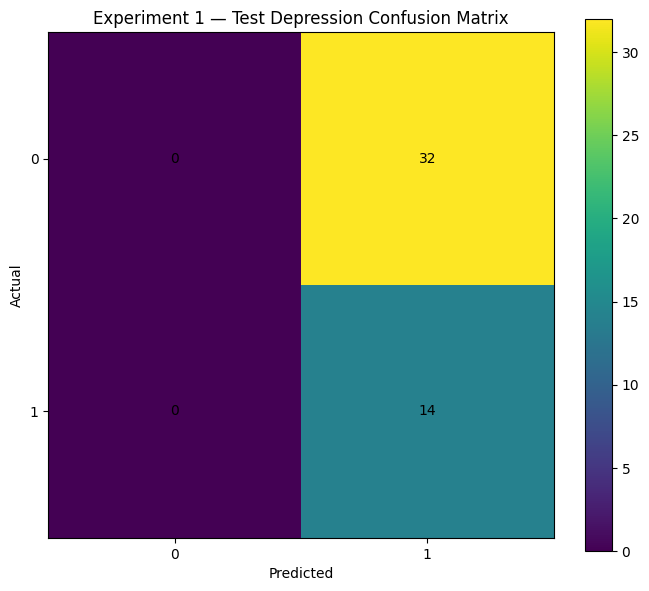

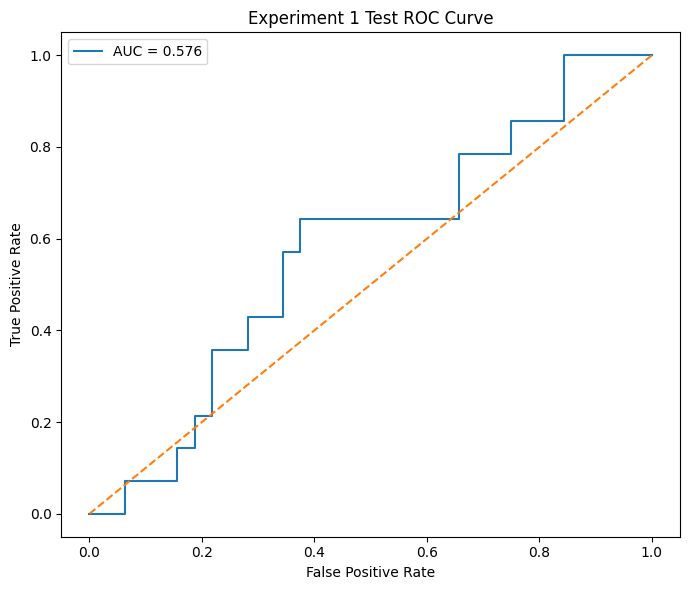

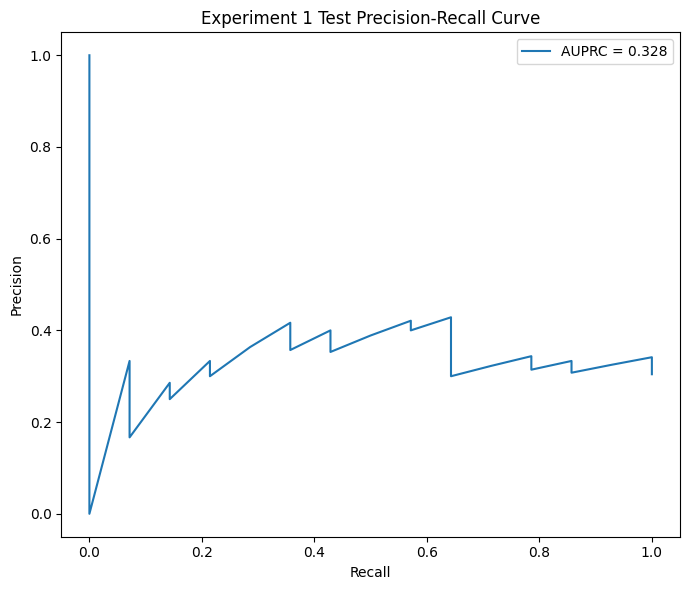

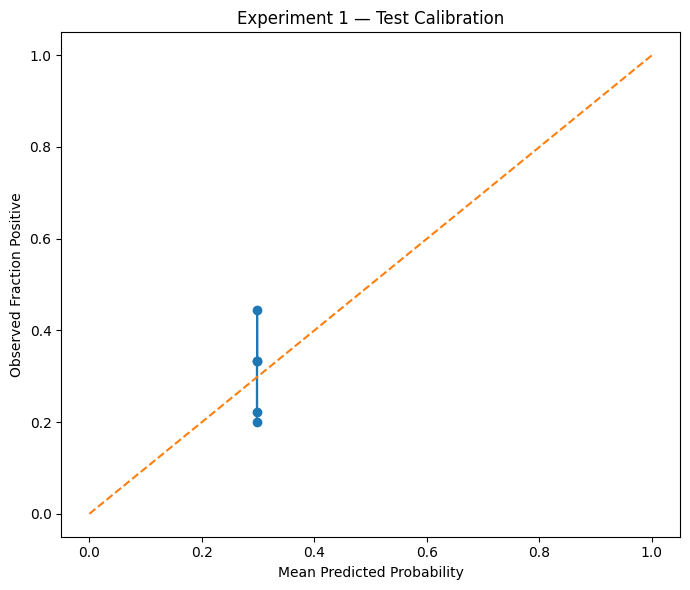

,mean_predicted_probability,observed_fraction_positive,n
0,0.297695,0.200000,10
1,0.297908,0.333333,9
2,0.298074,0.222222,9
3,0.298227,0.444444,9
4,0.298439,0.333333,9


In [ ]:
plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_1a_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 1 — "
        "Test Depression Confusion Matrix"
    ),
)


plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_1a_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 1 Test"
    ),
)


experiment_1_calibration = (
    plot_calibration_curve_manual(
        y_true=(
            y_binary_test
        ),
        probabilities=(
            experiment_1a_binary_final[
                "test_probabilities"
            ]
        ),
        n_bins=5,
        title=(
            "Experiment 1 — "
            "Test Calibration"
        ),
    )
)

display(
    experiment_1_calibration
)

### Experiment 1a binary feature importance

In [ ]:
selection_model = create_dnamite_model(
    task="classification",
    parameters=(
        experiment_1a_binary_final[
            "best_parameters"
        ]
    ),
    imbalance_strategy="none",
)

selection_model.select_features(
    experiment_1a_binary_final[
        "X_development"
    ],
    y_binary_development,
    reg_param=float(
        experiment_1a_binary_final[
            "best_parameters"
        ].get(
            "selection_reg_param",
            DNAMITE_SELECTION_REG_PARAM,
        )
    ),
    select_pairs=False,
)


print(
    "Top-level feature_names_in_:",
    selection_model.feature_names_in_.tolist(),
)

print(
    "\nselected_feats:",
    getattr(
        selection_model,
        "selected_feats",
        "NOT FOUND",
    ),
)

print(
    "\nselected_feats_:",
    getattr(
        selection_model,
        "selected_feats_",
        "NOT FOUND",
    ),
)

print(
    "\nselected_features:",
    getattr(
        selection_model,
        "selected_features",
        "NOT FOUND",
    ),
)

print(
    "\nselected_features_:",
    getattr(
        selection_model,
        "selected_features_",
        "NOT FOUND",
    ),
)

print(
    "\nAttributes containing 'select':"
)

print([
    attr
    for attr in dir(selection_model)
    if "select" in attr.lower()
])

Top-level feature_names_in_: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']

selected_feats: NOT FOUND

selected_feats_: ['speech__pause_rate', 'speech__std_intensity_db', 'speech__std_hnr_db', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__std_f1_loc', 'speech__mean_f2_

In [ ]:
model = experiment_1a_binary_final[
    "model"
]

feature = (
    "speech__mean_pause_duration"
)

shape = model.get_shape_function(
    feature
)

print("=== SHAPE FUNCTION ===")
print(type(shape))

display(shape)

print("\nShape:")
print(shape.shape)

print("\nColumns:")
print(shape.columns.tolist())


print("\n=== TRAINING FEATURE ===")

X_dev = experiment_1a_binary_final[
    "X_development"
]

print(
    X_dev[feature].describe()
)

print(
    "\nNumber of unique values:",
    X_dev[feature].nunique()
)

print(
    "\nFirst 20 unique values:"
)

print(
    np.sort(
        X_dev[feature]
        .dropna()
        .unique()
    )[:20]
)


print("\n=== DNAMITE BIN INFORMATION ===")

internal = model.models[0]

feature_index = (
    internal
    .feature_names_in_
    .get_loc(feature)
)

print(
    "Feature index:",
    feature_index
)

print(
    "\nFeature bins:"
)

print(
    internal.feature_bins[
        feature_index
    ]
)

print(
    "\nBin scores:"
)

print(
    internal.bin_scores[
        feature_index
    ]
)

=== SHAPE FUNCTION ===
<class 'pandas.core.frame.DataFrame'>


,index,feature,bin,score,count,split
0,0,speech__mean_pause_duration,0.739315,-0.000777,3.0,0
1,1,speech__mean_pause_duration,0.749315,-0.002498,2.0,0
2,2,speech__mean_pause_duration,0.853201,-0.002482,3.0,0
3,3,speech__mean_pause_duration,0.935456,-0.001278,4.0,0
4,4,speech__mean_pause_duration,0.954065,0.000307,4.0,0
5,5,speech__mean_pause_duration,0.974307,-0.000155,3.0,0
6,6,speech__mean_pause_duration,1.003071,-0.002503,4.0,0
7,7,speech__mean_pause_duration,1.040758,-0.004626,4.0,0
8,8,speech__mean_pause_duration,1.082920,-0.004981,3.0,0
9,9,speech__mean_pause_duration,1.129318,-0.003079,4.0,0



Shape:
(30, 6)

Columns:
['index', 'feature', 'bin', 'score', 'count', 'split']

=== TRAINING FEATURE ===
count    135.000000
mean       1.429102
std        0.568503
min        0.000000
25%        1.053930
50%        1.304687
75%        1.642976
max        4.173231
Name: speech__mean_pause_duration, dtype: float64

Number of unique values: 135

First 20 unique values:
[0.         0.71979487 0.73079452 0.74060488 0.74912195 0.74950779
 0.76457711 0.79144186 0.79948014 0.80584946 0.90055311 0.90189474
 0.90501266 0.92981132 0.93035294 0.94055814 0.94224906 0.94637224
 0.94952975 0.95062948]

=== DNAMITE BIN INFORMATION ===
Feature index: 4

Feature bins:
[0.74931487 0.85320128 0.93545554 0.95406474 0.97430664 1.00307074
 1.04075761 1.08292046 1.12931814 1.15148932 1.17421153 1.2049858
 1.22490758 1.27397571 1.29121772 1.31186606 1.36063054 1.40850924
 1.44703647 1.46706878 1.50413693 1.54645017 1.62072863 1.70670232
 1.7616129  1.83817258 2.0197805  2.3854574  2.76992657]

Bin scores:
[

In [ ]:
print(
    experiment_1a_binary_final[
        "best_parameters"
    ]
)

print(
    "\nConfigured max_bins:",
    experiment_1a_binary_final[
        "best_parameters"
    ][
        "max_bins"
    ]
)

{'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}

Configured max_bins: 32


In [ ]:
model = experiment_1a_binary_final[
    "model"
]

internal = model.models[0]

bin_summary = []

for i, feature in enumerate(
    internal.feature_names_in_
):

    bins = (
        internal.feature_bins[i]
    )

    scores = (
        internal.bin_scores[i]
    )

    bin_summary.append(
        {
            "feature": feature,
            "n_cut_points": len(bins),
            "n_bin_scores": len(scores),
            "cut_points": bins,
        }
    )

bin_summary_df = pd.DataFrame(
    bin_summary
)

display(
    bin_summary_df[
        [
            "feature",
            "n_cut_points",
            "n_bin_scores",
        ]
    ]
)

,feature,n_cut_points,n_bin_scores
0,speech__speaking_rate,29,31
1,speech__articulation_rate,29,31
2,speech__phonation_ratio,29,31
3,speech__pause_rate,29,31
4,speech__mean_pause_duration,29,31
5,speech__mean_f0_hertz,29,31
6,speech__std_f0_hertz,29,31
7,speech__mean_intensity_db,29,31
8,speech__std_intensity_db,29,31
9,speech__range_ratio_intensity_db,29,31


In [ ]:
model = experiment_1a_binary_final["model"]

print(
    "max_bins:",
    model.max_bins
)

print(
    "min_samples_per_bin:",
    model.min_samples_per_bin
)

print(
    "n development samples:",
    len(
        experiment_1a_binary_final[
            "X_development"
        ]
    )
)

max_bins: 32
min_samples_per_bin: None
n development samples: 135


In [ ]:
model = experiment_1a_binary_final[
    "model"
]

print(
    "has_missing_bin_:",
    model.has_missing_bin_[4]
)

print(
    "has_missing_values_:",
    model.has_missing_values_[4]
)

print(
    "feature_sizes_:",
    model.feature_sizes_[4]
)

print(
    "feature_bins_:",
    model.feature_bins_[4]
)

has_missing_bin_: True
has_missing_values_: False
feature_sizes_: 31
feature_bins_: [0.74931487 0.85320128 0.93545554 0.95406474 0.97430664 1.00307074
 1.04075761 1.08292046 1.12931814 1.15148932 1.17421153 1.2049858
 1.22490758 1.27397571 1.29121772 1.31186606 1.36063054 1.40850924
 1.44703647 1.46706878 1.50413693 1.54645017 1.62072863 1.70670232
 1.7616129  1.83817258 2.0197805  2.3854574  2.76992657]


,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.004986,31
1,0,speech__articulation_rate,0.003442,31
2,0,speech__phonation_ratio,0.004370,31
3,0,speech__pause_rate,0.005697,31
4,0,speech__mean_pause_duration,0.002415,31
5,0,speech__mean_f0_hertz,0.002280,31
6,0,speech__std_f0_hertz,0.006077,31
7,0,speech__mean_intensity_db,0.004673,31
8,0,speech__std_intensity_db,0.002960,31
9,0,speech__range_ratio_intensity_db,0.003766,31


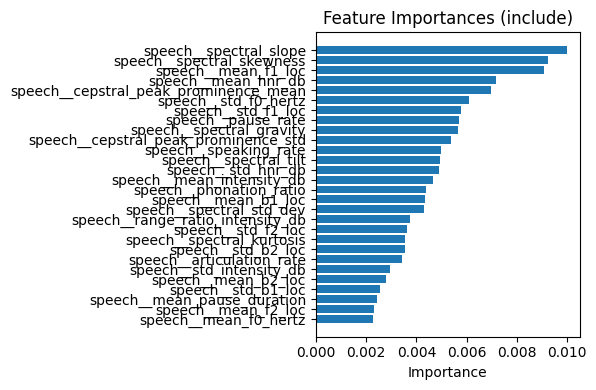

In [ ]:
experiment_1_binary_importance = (
    show_feature_importance(
        experiment_1a_binary_final[
            "model"
        ],
        top_n=28,
    )
)

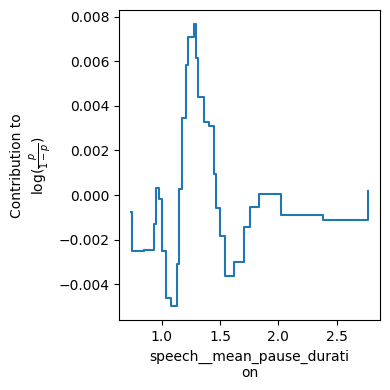

In [ ]:
experiment_1a_binary_final[
    "model"
].plot_shape_function(
    "speech__mean_pause_duration"
)

plt.show()

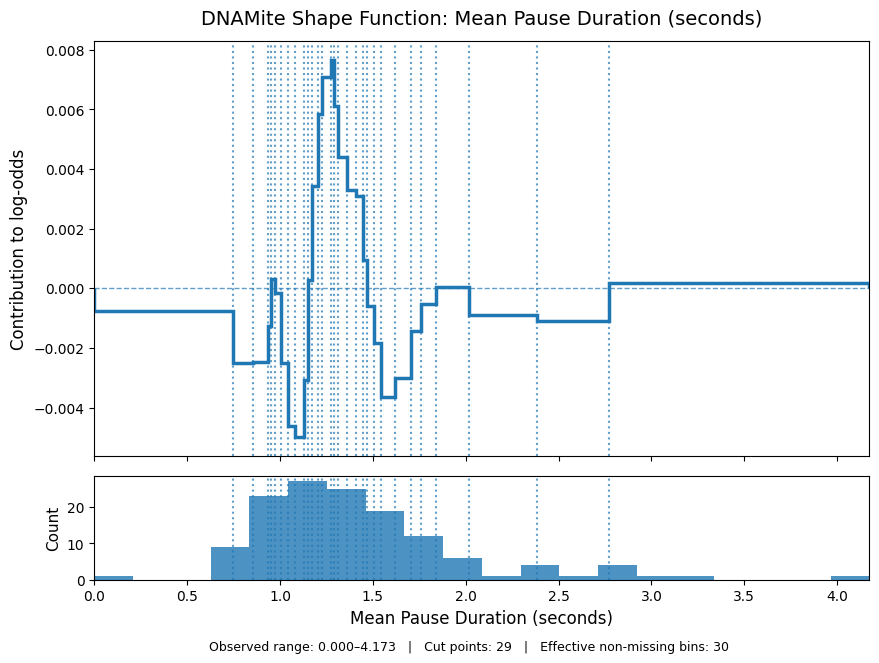

In [ ]:
shape_info = plot_dnamite_shape_full_range(
    model=experiment_1a_binary_final[
        "model"
    ],
    X=experiment_1a_binary_final[
        "X_development"
    ],
    feature=(
        "speech__mean_pause_duration"
    ),
    display_name=(
        "Mean Pause Duration (seconds)"
    ),
)

### Experiment 1b with Feature Selection

In [ ]:
# ============================================================
# EXPERIMENT 1b
# Speech Only + DNAMite Feature Selection
# Binary Depression Classification
# ============================================================

### Experiment 1b nested CV


Experiment 1b - Speech Only + Feature Selection | Classification | Outer fold 1
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=75 | best=45 | best val_loss=0.582515 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=75 | best=45 | best val_loss=0.525365 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=46 | best=16 | best val_loss=0.506158 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.579255 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.394429 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 0.9173514069989324, 'peak_ram_mb': 2898.34375, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 2.1112328945807344e-05, 'training_co2_kg': 8.312673449795108e-08}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_01.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/M

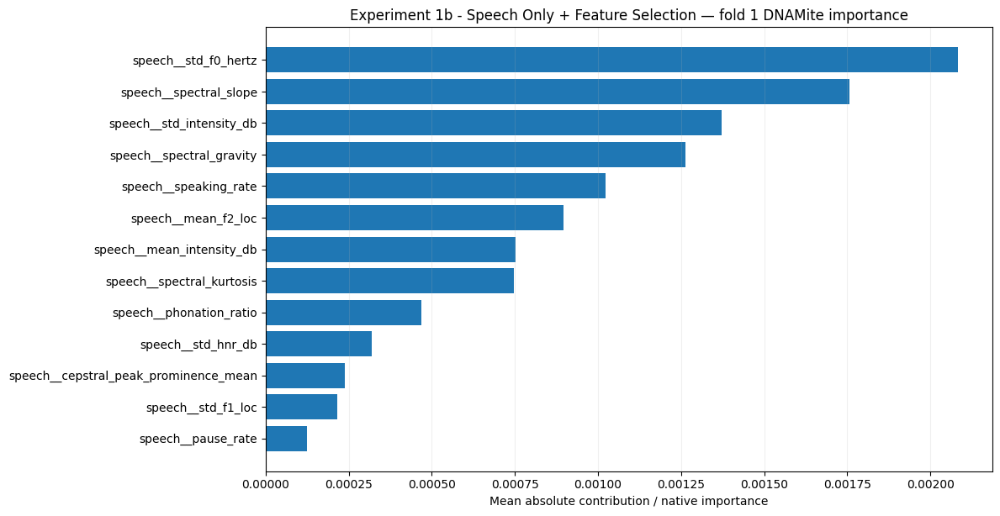

ROC_AUC              0.388158
PR_AUC               0.231436
AUPRC                0.231436
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208515
Log_Loss             0.607718
Threshold            0.295000
dtype: float64

Experiment 1b - Speech Only + Feature Selection | Classification | Outer fold 2
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=75 | best=45 | best val_loss=0.581654 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=60 | best=30 | best val_loss=0.635998 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 9 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db']
DNAMite epochs | split=1 | ran=173 | best=143 | best val_loss=0.573238 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 9 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db']
DNAMite epochs | split=1 | ran=48 | best=18 | best val_loss=0.506041 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 9 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db']
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.452390 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 0.8925515570008429, 'peak_ram_mb': 2898.89453125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 2.246058640443782e-05, 'training_co2_kg': 8.843530277983714e-08}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_02.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_02.jso

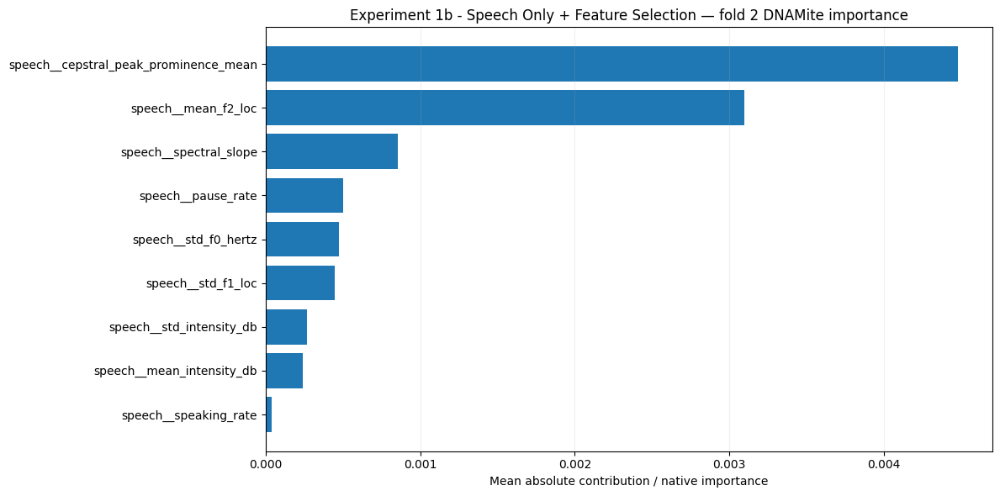

ROC_AUC              0.391447
PR_AUC               0.247025
AUPRC                0.247025
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208648
Log_Loss             0.608042
Threshold            0.295000
dtype: float64

Experiment 1b - Speech Only + Feature Selection | Classification | Outer fold 3
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=59 | best=29 | best val_loss=0.636677 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=59 | best=29 | best val_loss=0.636654 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 6 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz']
DNAMite epochs | split=1 | ran=111 | best=81 | best val_loss=0.556252 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 7 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz']
DNAMite epochs | split=1 | ran=140 | best=110 | best val_loss=0.595882 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=69 | best=39 | best val_loss=0.539273 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.2347343350011215, 'peak_ram_mb': 2899.14453125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 3.4216764053305954e-05, 'training_co2_kg': 1.347235479391794e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_03.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1b_-_Spe

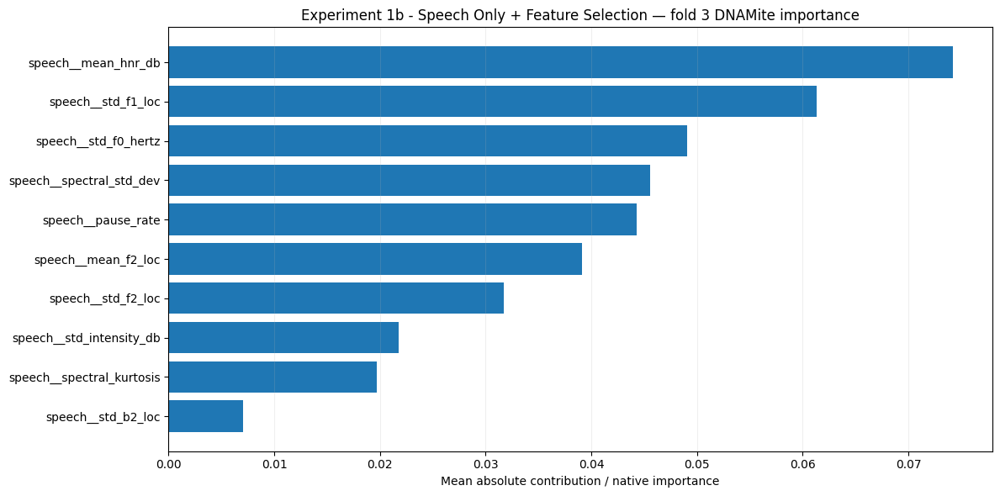

ROC_AUC              0.532895
PR_AUC               0.318236
AUPRC                0.318236
Accuracy             0.666667
Balanced_Accuracy    0.546053
Precision            0.400000
Sensitivity          0.250000
Specificity          0.842105
F1                   0.307692
Brier_Score          0.208974
Log_Loss             0.609165
Threshold            0.340000
dtype: float64

Experiment 1b - Speech Only + Feature Selection | Classification | Outer fold 4
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=75 | best=45 | best val_loss=0.582994 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=77 | best=47 | best val_loss=0.580026 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=71 | best=41 | best val_loss=0.545515 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=83 | best=53 | best val_loss=0.548058 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 9 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db']
DNAMite epochs | split=1 | ran=115 | best=85 | best val_loss=0.413729 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.3053880509978626, 'peak_ram_mb': 2899.45703125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 3.460053955862566e-05, 'training_co2_kg': 1.3623460835413488e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_04.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_04.j

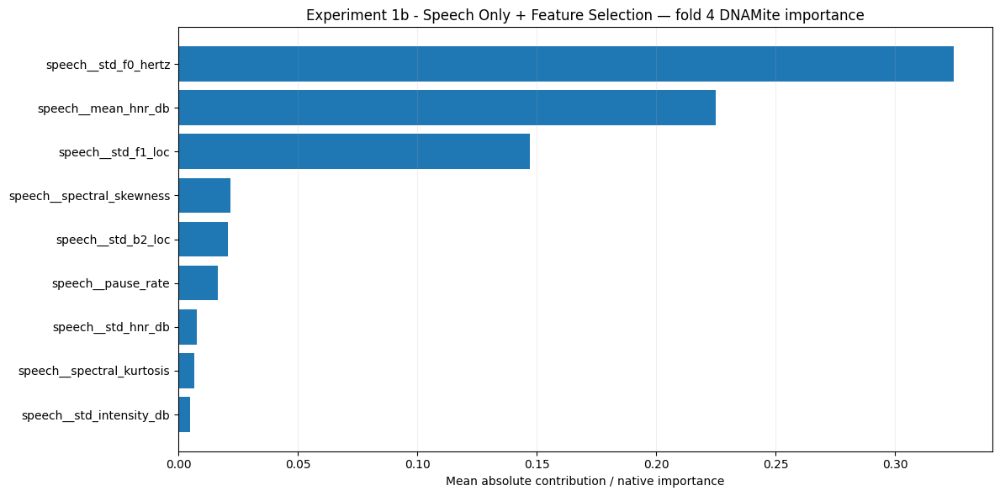

ROC_AUC              0.460526
PR_AUC               0.269332
AUPRC                0.269332
Accuracy             0.444444
Balanced_Accuracy    0.424342
Precision            0.230769
Sensitivity          0.375000
Specificity          0.473684
F1                   0.285714
Brier_Score          0.221807
Log_Loss             0.637293
Threshold            0.330000
dtype: float64

Experiment 1b - Speech Only + Feature Selection | Classification | Outer fold 5
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=65 | best=35 | best val_loss=0.471847 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=77 | best=47 | best val_loss=0.580172 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 4 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate']
DNAMite epochs | split=1 | ran=48 | best=18 | best val_loss=0.653220 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 3 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio']
DNAMite epochs | split=1 | ran=102 | best=72 | best val_loss=0.458596 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 4 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate']
DNAMite epochs | split=1 | ran=73 | best=43 | best val_loss=0.563341 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.0287645820026228, 'peak_ram_mb': 3006.73046875, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 2.4408002059510176e-05, 'training_co2_kg': 9.610296959821063e-08}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_05.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_05.json
Saved outer-fold model to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1b_-_Speech_Only

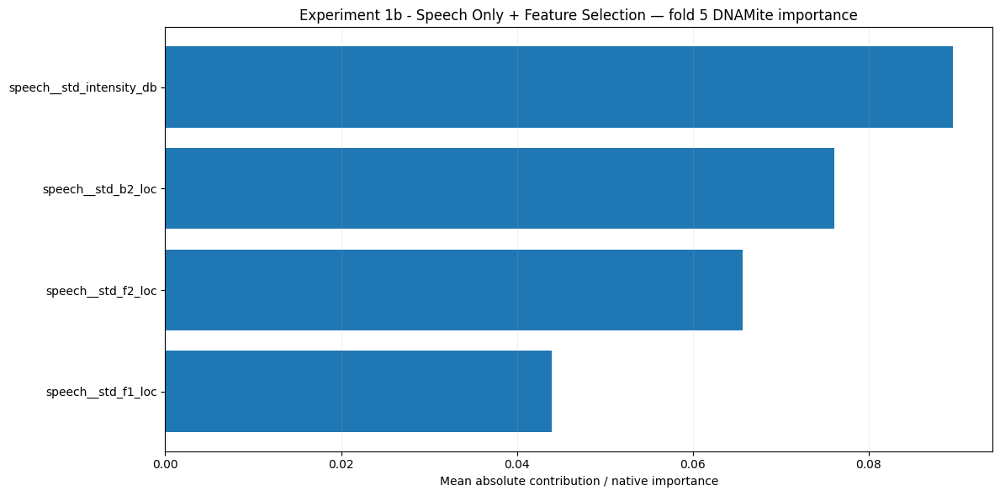

ROC_AUC              0.427632
PR_AUC               0.253956
AUPRC                0.253956
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208916
Log_Loss             0.608691
Threshold            0.315000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.440132,0.059684
PR_AUC,0.263997,0.033239
AUPRC,0.263997,0.033239
Accuracy,0.644444,0.112948
Balanced_Accuracy,0.494079,0.043788
Precision,0.126154,0.182812
Sensitivity,0.125000,0.176777
Specificity,0.863158,0.228205
F1,0.118681,0.162697
Brier_Score,0.211372,0.005836



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,True,0.0010,28,13,"[speech__speaking_rate, speech__articulation_r..."
1,2,True,0.0100,28,9,"[speech__speaking_rate, speech__articulation_r..."
2,3,True,0.0010,28,10,"[speech__speaking_rate, speech__articulation_r..."
3,4,True,0.0001,28,9,"[speech__speaking_rate, speech__articulation_r..."
4,5,True,0.0050,28,4,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
EXPERIMENT_1B_NAME = (
    "Experiment 1b - Speech Only + Feature Selection"
)

experiment_1b_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_1B_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        use_feature_selection=True,
    )
)

In [ ]:
display(
    experiment_1b_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "selection_reg_param",
            "n_features_available",
            "n_features_selected",
            "selected_features",
            "PR_AUC",
            "Balanced_Accuracy",
        ]
    ]
)

,Outer_Fold,selection_reg_param,n_features_available,n_features_selected,selected_features,PR_AUC,Balanced_Accuracy
0,1,0.0010,28,13,"[speech__speaking_rate, speech__articulation_r...",0.231436,0.500000
1,2,0.0100,28,9,"[speech__speaking_rate, speech__articulation_r...",0.247025,0.500000
2,3,0.0010,28,10,"[speech__speaking_rate, speech__articulation_r...",0.318236,0.546053
3,4,0.0001,28,9,"[speech__speaking_rate, speech__articulation_r...",0.269332,0.424342
4,5,0.0050,28,4,"[speech__speaking_rate, speech__articulation_r...",0.253956,0.500000



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


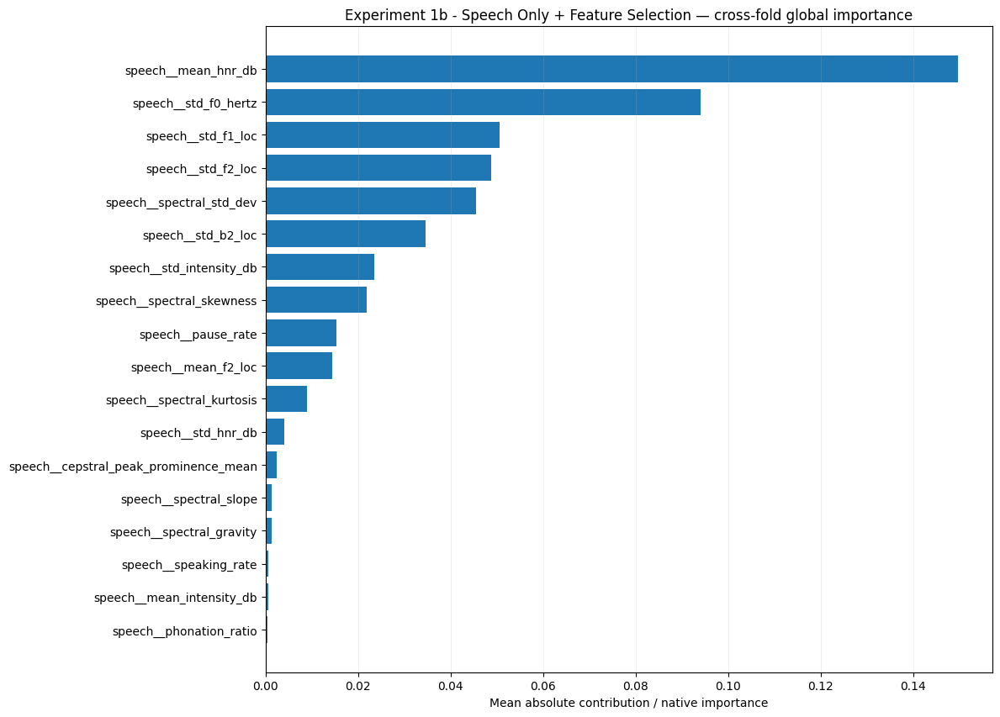

Interpretability summary saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/interpretability_summary


In [ ]:
experiment_1b_binary_interpretability = (
    aggregate_interpretability_across_folds(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1B_NAME
        ),
        top_k=10,
    )
)

print(
    "Interpretability summary saved to:"
)

print(
    experiment_1b_binary_interpretability
)

In [ ]:
outer_results = (
    experiment_1b_binary_cv[
        "outer_results"
    ]
)

print(
    outer_results.columns.tolist()
)

display(
    outer_results
)

['Outer_Fold', 'max_bins', 'learning_rate', 'n_embed', 'n_hidden', 'n_layers', 'selection_reg_param', 'feature_selection_enabled', 'n_features_available', 'n_features_selected', 'selected_feature_indices', 'selected_features', 'ROC_AUC', 'PR_AUC', 'AUPRC', 'Accuracy', 'Balanced_Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1', 'Brier_Score', 'Log_Loss', 'Threshold', 'outer_fold_train_seconds', 'peak_ram_mb', 'peak_gpu_memory_mb', 'peak_gpu_reserved_mb', 'training_energy_kwh', 'training_co2_kg']


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,feature_selection_enabled,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0010,32,32,2,0.0010,True,28,13,...,0.000000,0.208515,0.607718,0.295,0.917351,2898.343750,16.518066,22.0,0.000021,8.312673e-08
1,2,4,0.0010,32,32,2,0.0100,True,28,9,...,0.000000,0.208648,0.608042,0.295,0.892552,2898.894531,16.518066,22.0,0.000022,8.843530e-08
2,3,8,0.0005,32,16,2,0.0010,True,28,10,...,0.307692,0.208974,0.609165,0.340,1.234734,2899.144531,16.518066,22.0,0.000034,1.347235e-07
3,4,8,0.0010,32,16,2,0.0001,True,28,9,...,0.285714,0.221807,0.637293,0.330,1.305388,2899.457031,16.518066,22.0,0.000035,1.362346e-07
4,5,32,0.0005,32,16,2,0.0050,True,28,4,...,0.000000,0.208916,0.608691,0.315,1.028765,3006.730469,16.518066,22.0,0.000024,9.610297e-08


In [ ]:
experiment_1b_energy = (
    summarize_energy_utilization(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1B_NAME
        ),
    )
)

,Mean,SD,Min,Max
training_energy_kwh,2.735964e-05,6.542029e-06,2.111233e-05,3.460054e-05
training_co2_kg,1.077246e-07,2.575829e-08,8.312673e-08,1.362346e-07


In [ ]:
from pathlib import Path
import pandas as pd
import json

experiment_root = (
    MASTER_INTERP_ROOT
    / _safe_slug(MODEL_FAMILY)
    / _safe_slug(
        "Experiment 1b - "
        "Speech Only + DNAMite Feature Selection"
    )
)

for fold_dir in sorted(
    experiment_root.glob("fold_*")
):
    print(
        "\n",
        "=" * 60,
    )

    print(
        fold_dir.name
    )

    csv_path = (
        fold_dir
        / "feature_selection"
        / "feature_selection.csv"
    )

    json_path = (
        fold_dir
        / "feature_selection"
        / "feature_selection_summary.json"
    )

    print(
        "CSV exists:",
        csv_path.exists(),
    )

    print(
        "JSON exists:",
        json_path.exists(),
    )

    if json_path.exists():

        with open(
            json_path,
            "r",
        ) as f:
            info = json.load(f)

        print(
            "Selection enabled:",
            info.get(
                "feature_selection_enabled"
            ),
        )

        print(
            "Selection reg param:",
            info.get(
                "selection_reg_param"
            ),
        )

        print(
            "Features available:",
            info.get(
                "n_features_available"
            ),
        )

        print(
            "Features selected:",
            info.get(
                "n_features_selected"
            ),
        )

        print(
            "Selected features:",
            info.get(
                "selected_features"
            ),
        )

### Experiment 1b nested CV summary

In [ ]:
display(
    experiment_1b_binary_cv[
        "outer_results"
    ]
)

print(
    "\nNested-CV mean ± SD:"
)

display(
    experiment_1b_binary_cv[
        "summary"
    ]
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,feature_selection_enabled,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0010,32,32,2,0.0010,True,28,13,...,0.000000,0.208515,0.607718,0.295,0.917351,2898.343750,16.518066,22.0,0.000021,8.312673e-08
1,2,4,0.0010,32,32,2,0.0100,True,28,9,...,0.000000,0.208648,0.608042,0.295,0.892552,2898.894531,16.518066,22.0,0.000022,8.843530e-08
2,3,8,0.0005,32,16,2,0.0010,True,28,10,...,0.307692,0.208974,0.609165,0.340,1.234734,2899.144531,16.518066,22.0,0.000034,1.347235e-07
3,4,8,0.0010,32,16,2,0.0001,True,28,9,...,0.285714,0.221807,0.637293,0.330,1.305388,2899.457031,16.518066,22.0,0.000035,1.362346e-07
4,5,32,0.0005,32,16,2,0.0050,True,28,4,...,0.000000,0.208916,0.608691,0.315,1.028765,3006.730469,16.518066,22.0,0.000024,9.610297e-08



Nested-CV mean ± SD:


,Mean,SD
ROC_AUC,0.440132,0.059684
PR_AUC,0.263997,0.033239
AUPRC,0.263997,0.033239
Accuracy,0.644444,0.112948
Balanced_Accuracy,0.494079,0.043788
Precision,0.126154,0.182812
Sensitivity,0.125000,0.176777
Specificity,0.863158,0.228205
F1,0.118681,0.162697
Brier_Score,0.211372,0.005836


### Experiment 1b nested CV confusion matrix

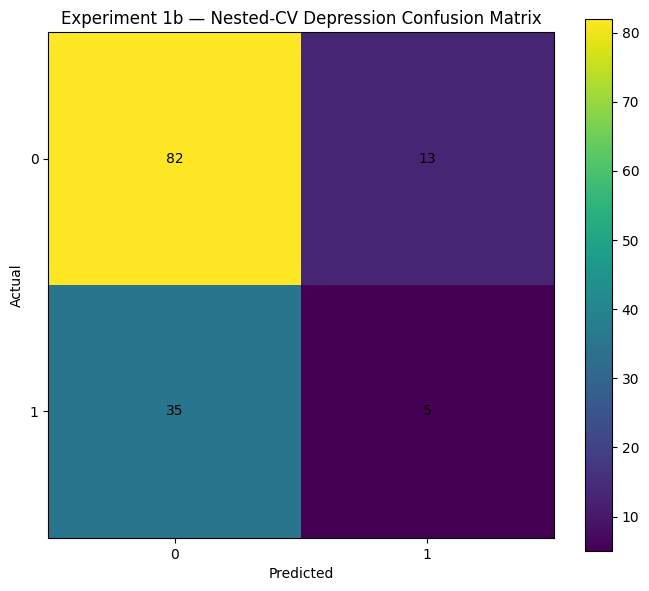

In [ ]:
experiment_1b_binary_cv_cm = (
    plot_confusion_matrix(
        y_true=(
            y_binary_development
        ),
        y_pred=(
            experiment_1b_binary_cv[
                "oof_predictions"
            ]
        ),
        labels=[
            0,
            1,
        ],
        title=(
            "Experiment 1b — "
            "Nested-CV Depression Confusion Matrix"
        ),
    )
)

### Experiment 1b Final Model

In [ ]:
experiment_1b_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        experiment_name=(
            EXPERIMENT_1B_NAME
        ),
        use_feature_selection=True,
        save_outputs=True,
    )
)

DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=77 | best=47 | best val_loss=0.590622 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=74 | best=44 | best val_loss=0.545074 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 13 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=0.702366 | hit ceiling=False
Running DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 12 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db']
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.626126 | hit ceiling=False
Selected probability threshold: 0.305
Development OOF balanced accuracy at threshold: 0.5289
Running final DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


Final DNAMite active features: 5 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 44, 'best_epoch': 14, 'best_val_loss': 0.6468613147735596, 'hit_epoch_ceiling': False}]

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection
Final model saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/fold_00/final_model_bundle.pkl

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection


### Experiment 1b Final Test Metrics

In [ ]:
print(
    "FINAL TEST METRICS"
)

display(
    pd.Series(
        experiment_1b_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

FINAL TEST METRICS


,Value
ROC_AUC,0.488839
PR_AUC,0.316498
AUPRC,0.316498
Accuracy,0.673913
Balanced_Accuracy,0.504464
Precision,0.333333
Sensitivity,0.071429
Specificity,0.937500
F1,0.117647
Brier_Score,0.211787


### Experiment 1b Test Confusion Matrix

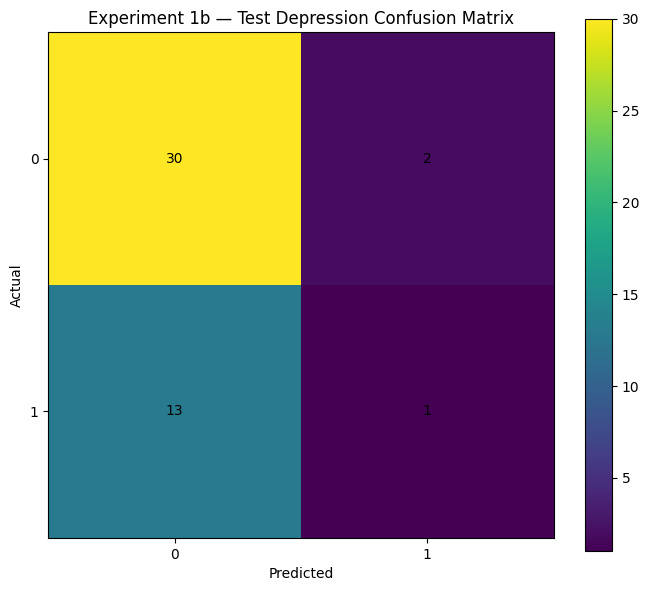

array([[30,  2],
       [13,  1]])

In [ ]:
plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_1b_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 1b — "
        "Test Depression Confusion Matrix"
    ),
)

### Experiment 1b ROC and Precision-Recall Curves

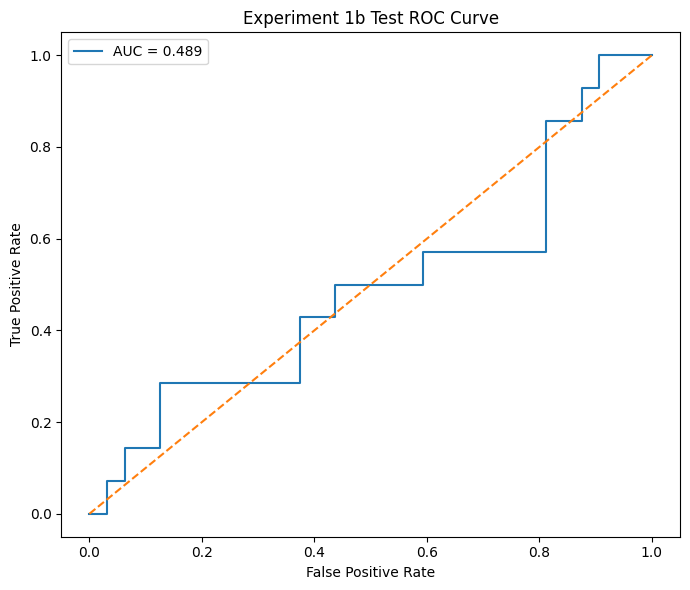

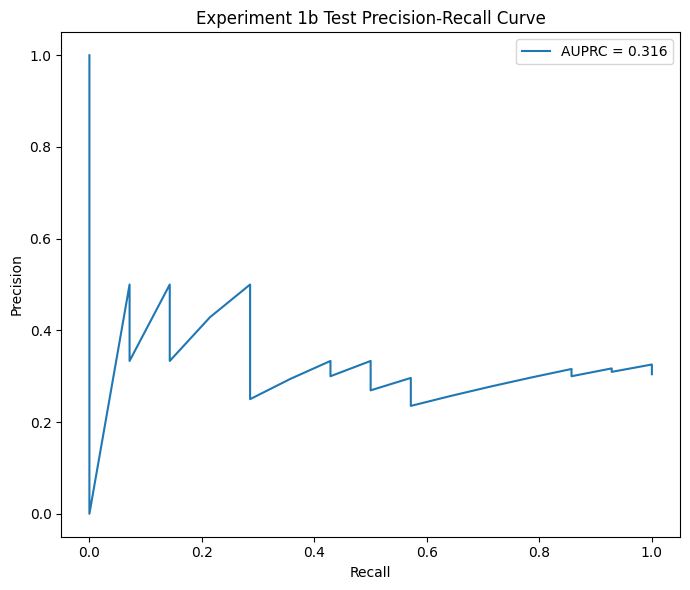

In [ ]:
plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_1b_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 1b Test"
    ),
)

### Experiment 1b Calibration

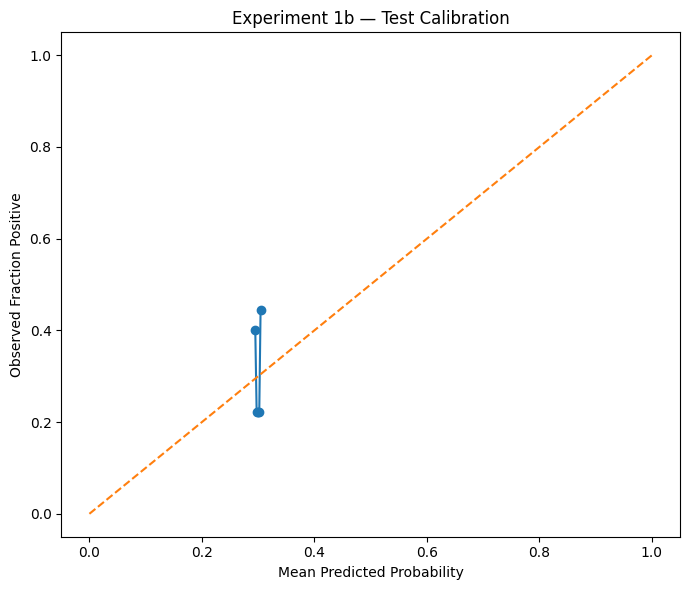

,mean_predicted_probability,observed_fraction_positive,n
0,0.294923,0.400000,10
1,0.297308,0.222222,9
2,0.299416,0.222222,9
3,0.301992,0.222222,9
4,0.304324,0.444444,9


In [ ]:
experiment_1b_calibration = (
    plot_calibration_curve_manual(
        y_true=(
            y_binary_test
        ),
        probabilities=(
            experiment_1b_binary_final[
                "test_probabilities"
            ]
        ),
        n_bins=5,
        title=(
            "Experiment 1b — "
            "Test Calibration"
        ),
    )
)

display(
    experiment_1b_calibration
)

### Experiment 1b Selected Features

In [ ]:
# ============================================================
# EXPERIMENT 1B — SELECTED FEATURES
# ============================================================

experiment_1b_model = (
    experiment_1b_binary_final[
        "model"
    ]
)

print(
    "Selected feature indices:"
)

print(
    experiment_1b_model.selected_feats_
)

Selected feature indices:
['speech__std_intensity_db', 'speech__std_f1_loc', 'speech__std_f2_loc', 'speech__std_b2_loc', 'speech__spectral_kurtosis']


In [ ]:
print(
    "Model type:",
    type(experiment_1b_model),
)

print(
    "\nAttributes containing 'select':"
)

for attr in dir(experiment_1b_model):
    if "select" in attr.lower():
        print(attr)


print(
    "\nAttributes containing 'feat':"
)

for attr in dir(experiment_1b_model):
    if "feat" in attr.lower():
        print(attr)

Model type: <class 'dnamite.models.binary_classifier.DNAMiteBinaryClassifier'>

Attributes containing 'select':
_select_features
_select_pairs
select_features
selected_feats_

Attributes containing 'feat':
_check_feature_names
_check_n_features
_select_features
cat_feat_mask_
feature_bins_
feature_dtypes_
feature_names_in_
feature_sizes_
get_feature_importances
n_features
plot_feature_importances
select_features
selected_feats_


### Experiment 1b Selected Feature Names

In [ ]:
# ============================================================
# EXPERIMENT 1B — SELECTED FEATURE NAMES
# ============================================================

selected_feature_names = (
    experiment_1b_model.selected_feats_
)

print(
    "Number of selected features:",
    len(selected_feature_names)
)

print(
    "\nSelected features:"
)

for feature in selected_feature_names:
    print(feature)

Number of selected features: 5

Selected features:
speech__std_intensity_db
speech__std_f1_loc
speech__std_f2_loc
speech__std_b2_loc
speech__spectral_kurtosis


### Experiment 1b Feature Importance

,split,feature,importance,n_bins
0,0,speech__std_intensity_db,0.014102,31
1,0,speech__std_f1_loc,0.043307,31
2,0,speech__std_f2_loc,0.017299,31
3,0,speech__std_b2_loc,0.002135,31
4,0,speech__spectral_kurtosis,0.073852,31


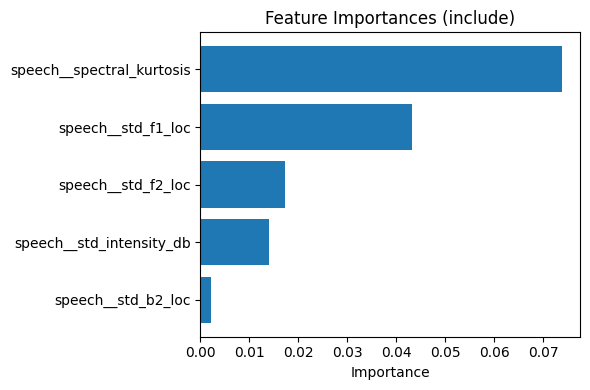

In [ ]:
experiment_1b_binary_importance = (
    show_feature_importance(
        experiment_1b_binary_final[
            "model"
        ],
        top_n=28,
    )
)

### Experiment 1a vs. 1b Test Comparison

In [ ]:
experiment_1a_vs_1b_binary_test = (
    pd.DataFrame(
        {
            "Experiment 1a - Speech Only": (
                experiment_1a_binary_final[
                    "test_metrics"
                ]
            ),

            "Experiment 1b - Speech + DNAMite Selection": (
                experiment_1b_binary_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_1a_vs_1b_binary_test
)

,Experiment 1a - Speech Only,Experiment 1b - Speech + DNAMite Selection
ROC_AUC,0.575893,0.488839
PR_AUC,0.328077,0.316498
AUPRC,0.328077,0.316498
Accuracy,0.304348,0.673913
Balanced_Accuracy,0.500000,0.504464
Precision,0.304348,0.333333
Sensitivity,1.000000,0.071429
Specificity,0.000000,0.937500
F1,0.466667,0.117647
Brier_Score,0.211740,0.211787


### Experiment 1a vs. 1b Nested CV Comparison

In [ ]:
# ============================================================
# EXPERIMENT 1A VS 1B — NESTED CV COMPARISON
# ============================================================

experiment_1a_vs_1b_binary_cv = (
    pd.DataFrame(
        {
            "Experiment 1a - Speech Only": (
                experiment_1a_binary_cv[
                    "summary"
                ][
                    "Mean"
                ]
            ),

            "Experiment 1b - Speech + DNAMite Selection": (
                experiment_1b_binary_cv[
                    "summary"
                ][
                    "Mean"
                ]
            ),
        }
    )
)

display(
    experiment_1a_vs_1b_binary_cv
)

,Experiment 1a - Speech Only,Experiment 1b - Speech + DNAMite Selection
ROC_AUC,0.517105,0.440132
PR_AUC,0.321584,0.263997
AUPRC,0.321584,0.263997
Accuracy,0.437037,0.644444
Balanced_Accuracy,0.513158,0.494079
Precision,0.250505,0.126154
Sensitivity,0.700000,0.125000
Specificity,0.326316,0.863158
F1,0.358496,0.118681
Brier_Score,0.208422,0.211372


### Experiment 1c regression nested CV

Using severity-stratified master regression folds.

Experiment 1c - Speech Only Regression | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=43 | best=13 | best val_loss=0.823467 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=1.065762 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.495651 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=0.857623 | hit ceiling=False
  Inner fold 2/3
DNAMite active fea

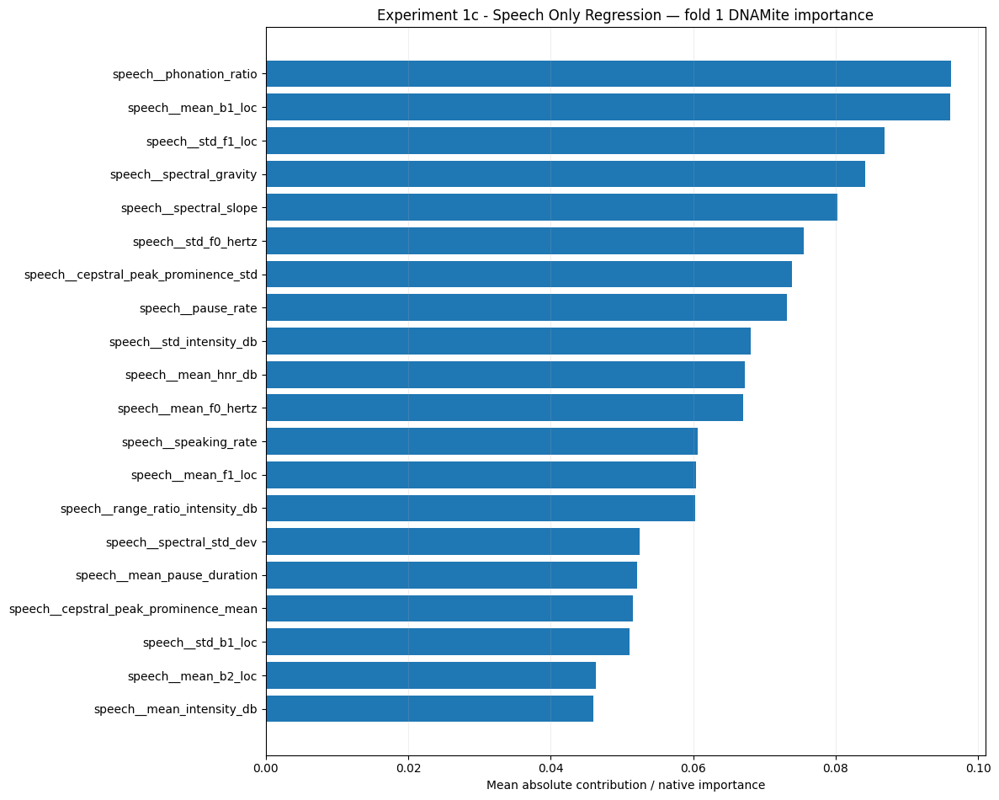

MAE               4.249468
RMSE              5.477908
R2               -0.082193
Spearman_Rho      0.022352
Spearman_P        0.911886
Pearson_R         0.072511
Pearson_P         0.719280
Exact_Accuracy    0.074074
Within_1          0.333333
Within_2          0.407407
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 1c - Speech Only Regression | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.825330 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.866895 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 

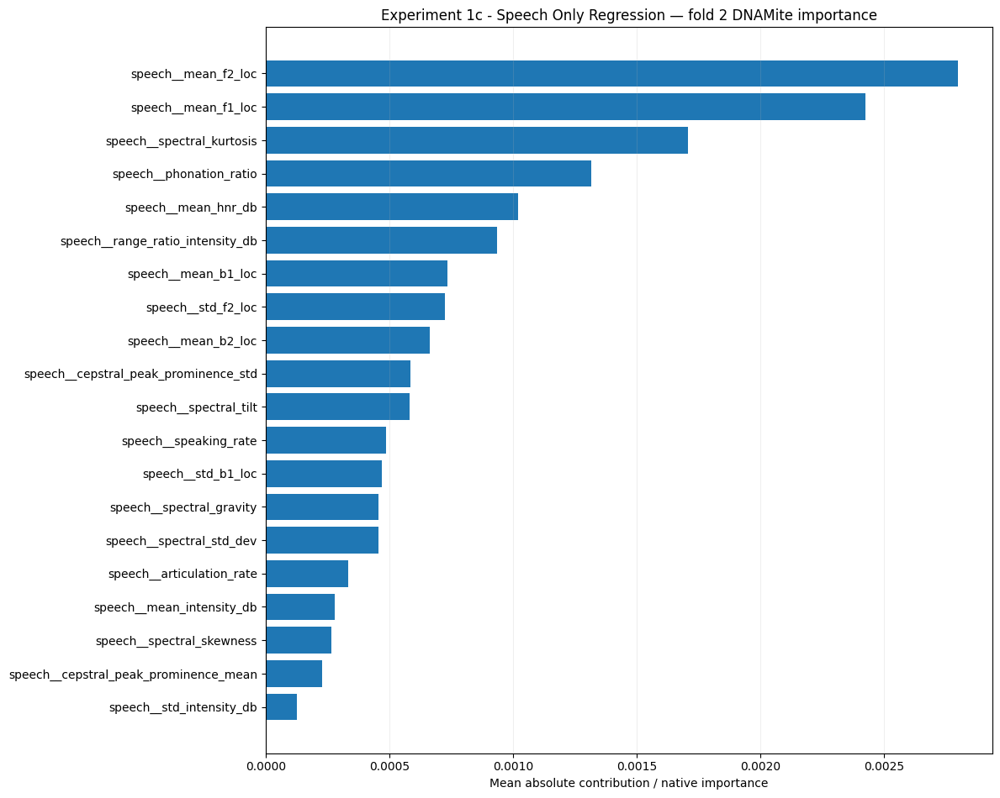

MAE               4.996287
RMSE              6.240460
R2                0.002049
Spearman_Rho      0.007055
Spearman_P        0.972139
Pearson_R         0.209329
Pearson_P         0.294683
Exact_Accuracy    0.074074
Within_1          0.148148
Within_2          0.259259
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 1c - Speech Only Regression | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=166 | best=136 | best val_loss=0.743588 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=50 | best=20 | best val_loss=0.836771 | hit ceiling=False
  Inner fold 3/3
DNAMite active features 

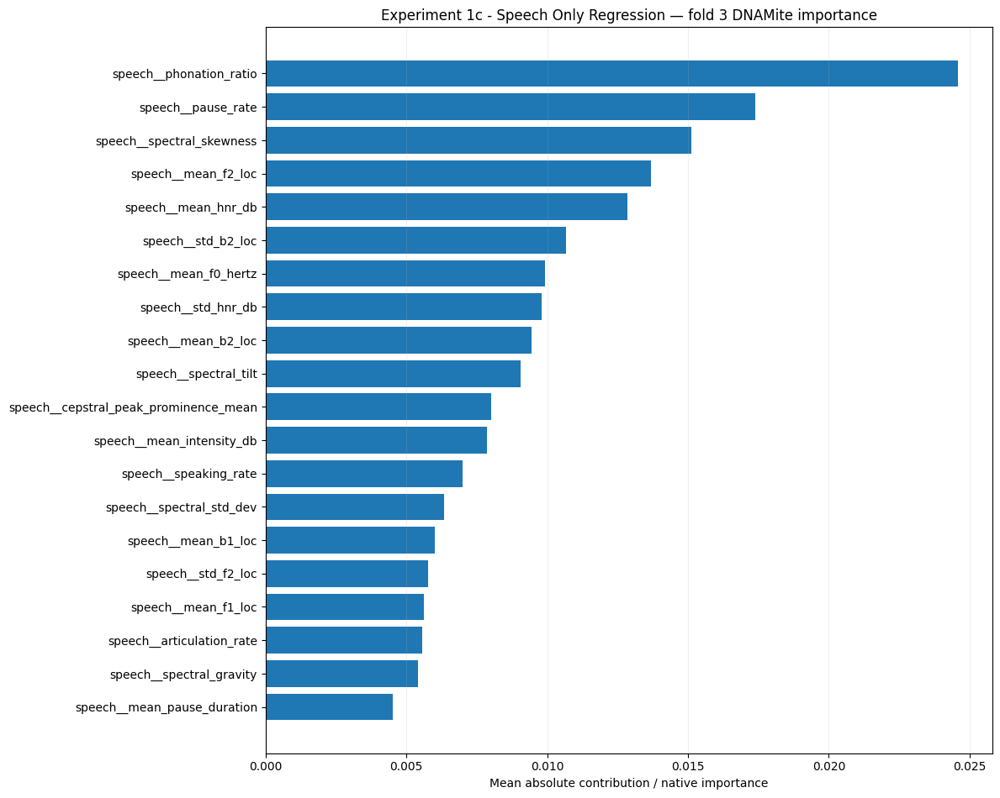

MAE               4.686297
RMSE              5.720738
R2               -0.040284
Spearman_Rho     -0.248010
Spearman_P        0.212282
Pearson_R        -0.231379
Pearson_P         0.245547
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.407407
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 1c - Speech Only Regression | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.805850 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.792681 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 /

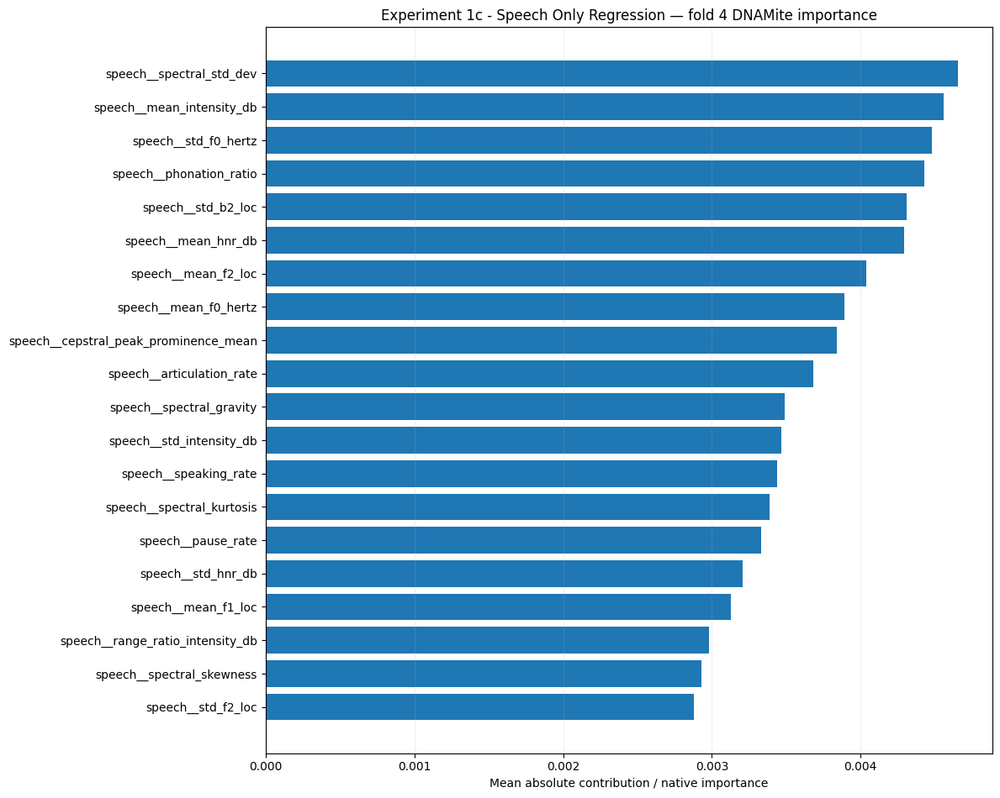

MAE               4.565801
RMSE              5.144853
R2               -0.016985
Spearman_Rho      0.193935
Spearman_P        0.332407
Pearson_R         0.174841
Pearson_P         0.383067
Exact_Accuracy    0.037037
Within_1          0.148148
Within_2          0.185185
Within_3          0.333333
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 1c - Speech Only Regression | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=56 | best=26 | best val_loss=0.721421 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.803141 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28

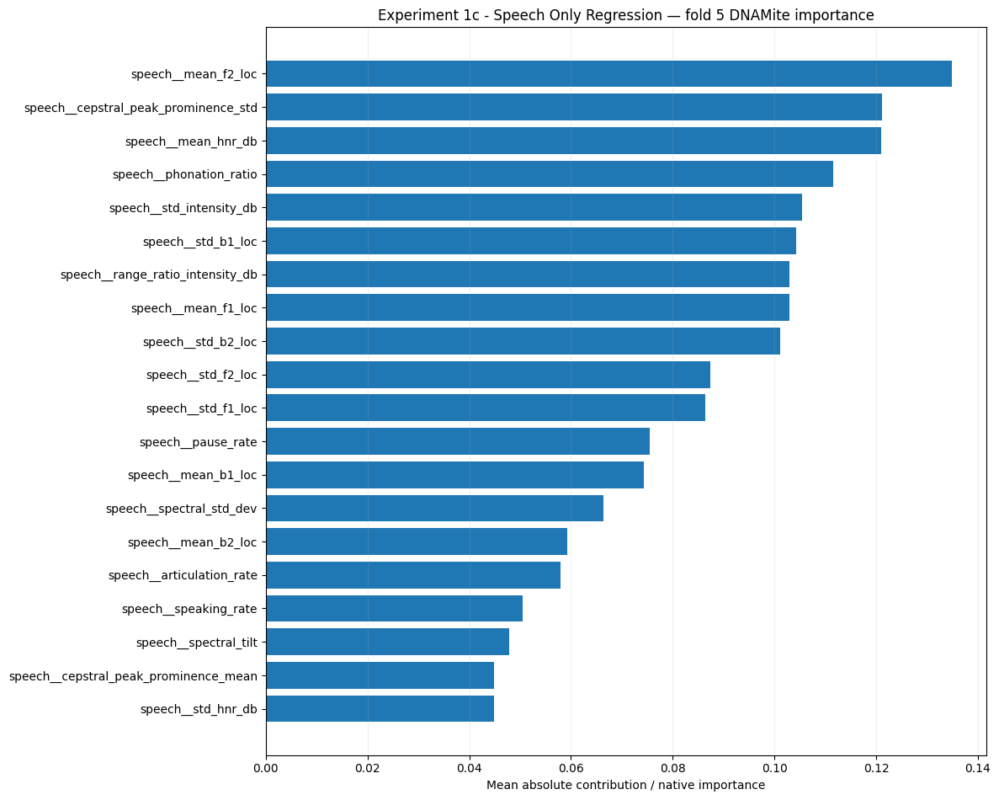

MAE               5.197057
RMSE              6.582972
R2               -0.369617
Spearman_Rho     -0.082440
Spearman_P        0.682687
Pearson_R        -0.157763
Pearson_P         0.431921
Exact_Accuracy    0.000000
Within_1          0.148148
Within_2          0.296296
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.738982,0.370280
RMSE,5.833386,0.578948
R2,-0.101406,0.153193
Spearman_Rho,-0.021422,0.161378
Pearson_R,0.013508,0.198216
Exact_Accuracy,0.037037,0.037037
Within_1,0.192593,0.080294
Within_2,0.288889,0.080294
Within_3,0.400000,0.048290



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
EXPERIMENT_1C_NAME = (
    "Experiment 1c - Speech Only Regression"
)

experiment_1c_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_1C_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        use_feature_selection=False,
    )
)


--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1c_-_Speech_Only_Regression
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


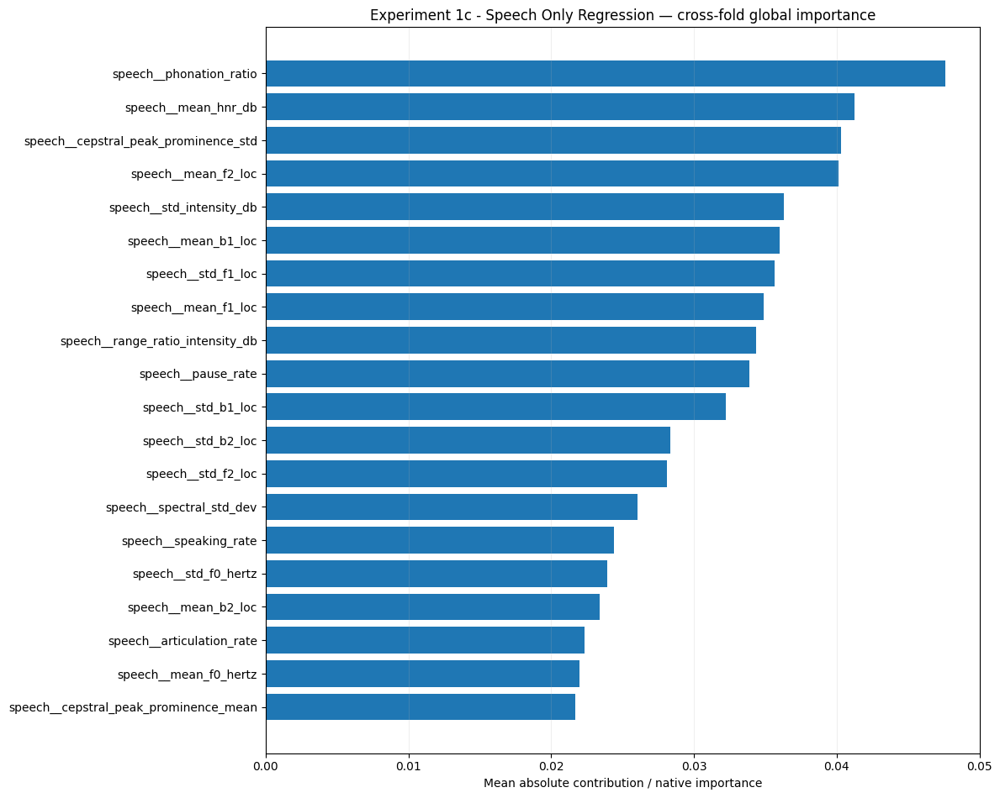

Interpretability summary saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1c_-_Speech_Only_Regression/interpretability_summary


In [ ]:
experiment_1c_regression_interpretability = (
    aggregate_interpretability_across_folds(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1C_NAME
        ),
        top_k=10,
    )
)

print(
    "Interpretability summary saved to:"
)

print(
    experiment_1c_regression_interpretability
)

In [ ]:
experiment_1c_energy = (
    summarize_energy_utilization(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1C_NAME
        ),
    )
)

,Mean,SD,Min,Max
training_energy_kwh,1.854856e-05,7.570759e-06,1.334545e-05,3.066777e-05
training_co2_kg,7.303226e-08,2.980877e-08,5.254579e-08,1.207499e-07


### Experiment 1c nested-CV PHQ-8 confusion matrix

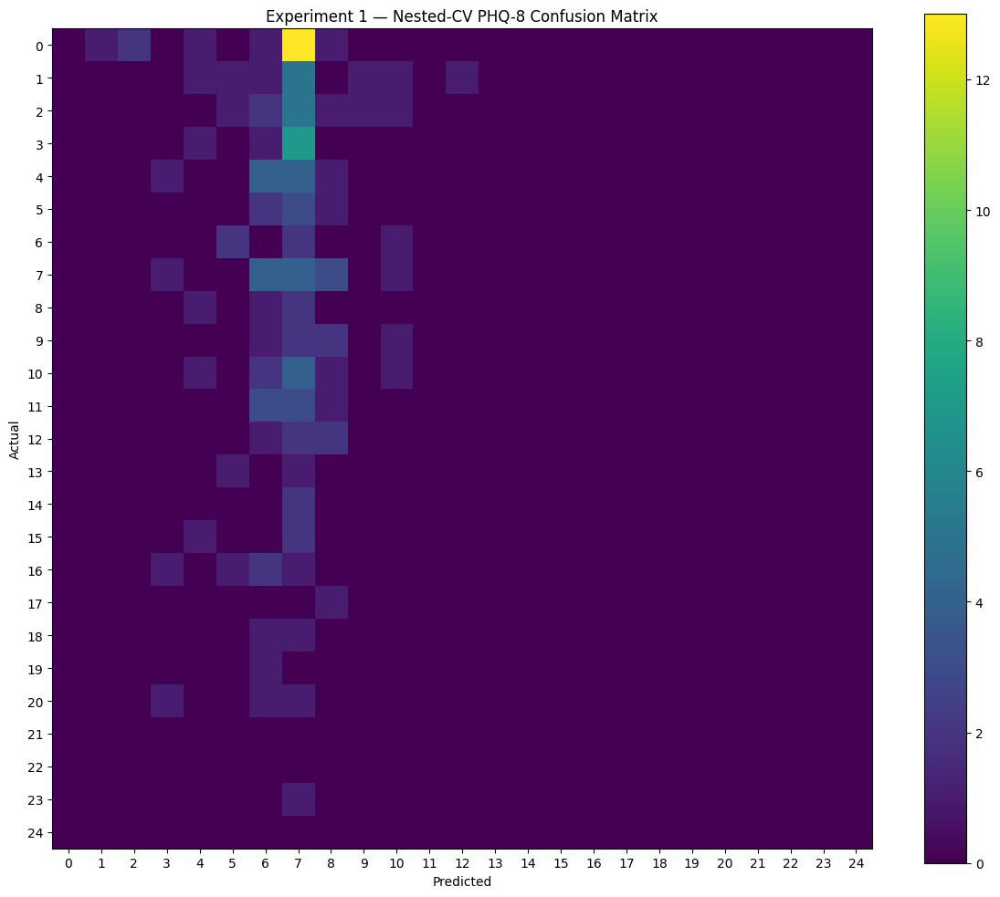

array([[ 0,  1,  2,  0,  1,  0,  1, 13,  1,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  1,  1,  5,  0,  1,  1,  0,  1,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  1,  2,  5,  1,  1,  1,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  0,  1,  7,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  1,  0,  0,  4,  4,  1,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  2,  3,  1,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  2,  0,  2,  0,  0,  1,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  1,  0,  0,  4,  4,  3,  0,  1,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  0,  1,  2,  0,  0,  0,  0,  0,  0, 

In [ ]:
experiment_1c_cv_rounded = (
    round_phq8_predictions(
        experiment_1c_regression_cv[
            "oof_predictions"
        ]
    )
)


plot_confusion_matrix(
    y_true=(
        y_regression_development
        .astype(int)
    ),
    y_pred=(
        experiment_1c_cv_rounded
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 1 — "
        "Nested-CV PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

### Experiment 1c final regression

In [ ]:
experiment_1c_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        experiment_name=(
            EXPERIMENT_1C_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=81 | best=51 | best val_loss=1.642090 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.433072 | hit ceiling=False
  Inner fold 3/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=42 | best=12 | best val_loss=1.461201 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=1.645505 | hit ceiling=False
  Inner fold 2/3
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.500080 | hit ceiling=False
  Inner fold 3

In [ ]:
print(
    "\nFINAL TEST METRICS"
)

display(
    pd.Series(
        experiment_1c_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)


FINAL TEST METRICS


,Value
MAE,5.491376
RMSE,6.534583
R2,-0.039027
Spearman_Rho,-0.086037
Spearman_P,0.569678
Pearson_R,-0.092317
Pearson_P,0.541732
Exact_Accuracy,0.043478
Within_1,0.086957
Within_2,0.173913


### Experiment 1c regression test plots

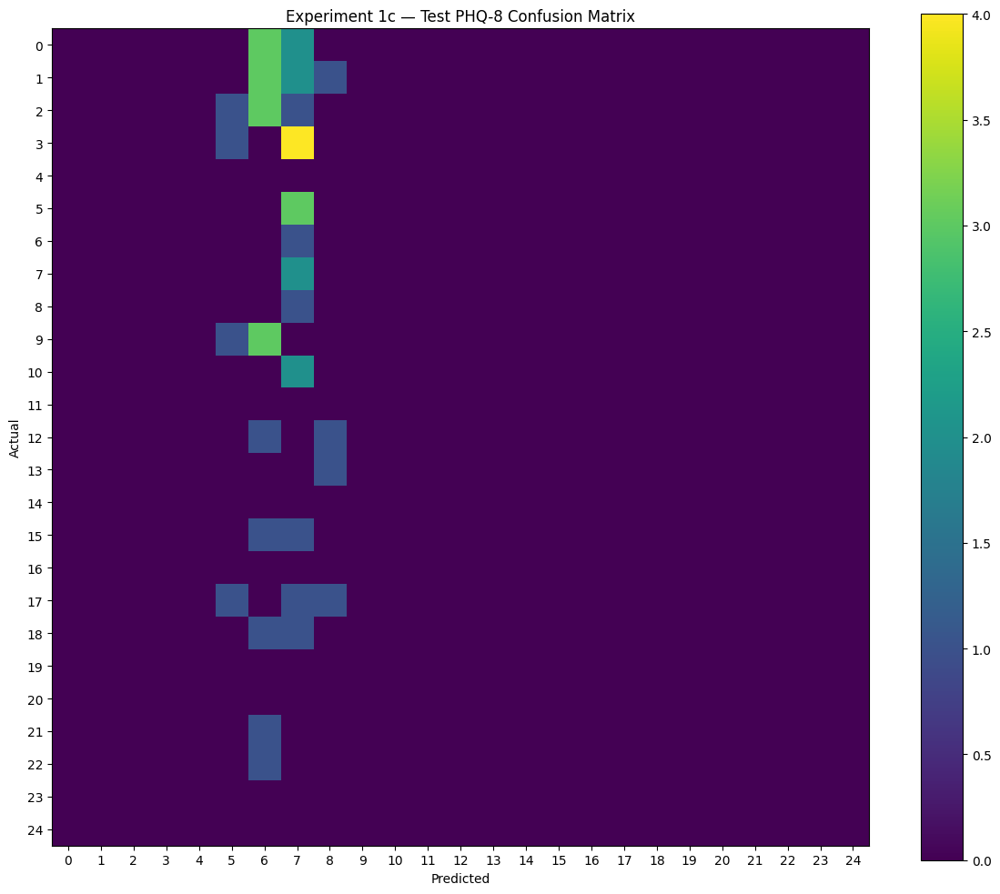

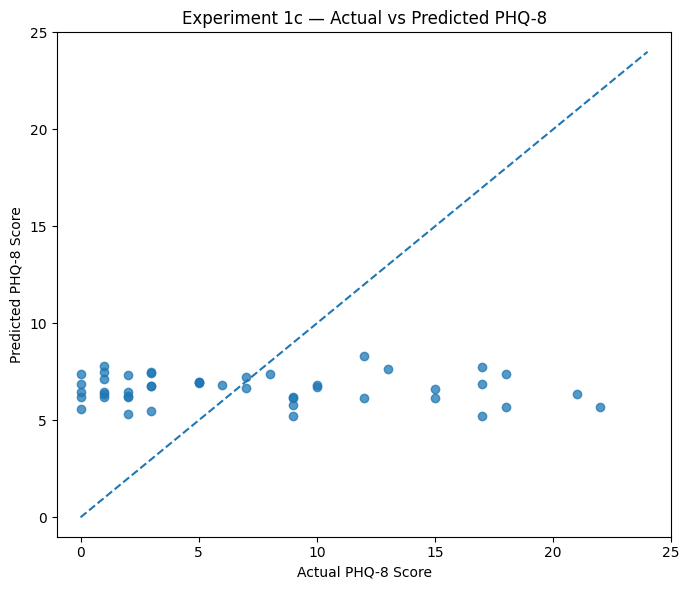

In [ ]:
plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        experiment_1c_regression_final[
            "test_rounded_predictions"
        ]
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 1c — "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)


plot_regression_predictions(
    y_true=(
        y_regression_test
    ),
    predictions=(
        experiment_1c_regression_final[
            "test_predictions"
        ]
    ),
    title=(
        "Experiment 1c — "
        "Actual vs Predicted PHQ-8"
    ),
)

### Experiment 1c regression feature importance

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.026021,31
1,0,speech__articulation_rate,0.017720,31
2,0,speech__phonation_ratio,0.025268,31
3,0,speech__pause_rate,0.020787,31
4,0,speech__mean_pause_duration,0.019020,31
5,0,speech__mean_f0_hertz,0.011475,31
6,0,speech__std_f0_hertz,0.019167,31
7,0,speech__mean_intensity_db,0.006113,31
8,0,speech__std_intensity_db,0.013935,31
9,0,speech__range_ratio_intensity_db,0.012282,31


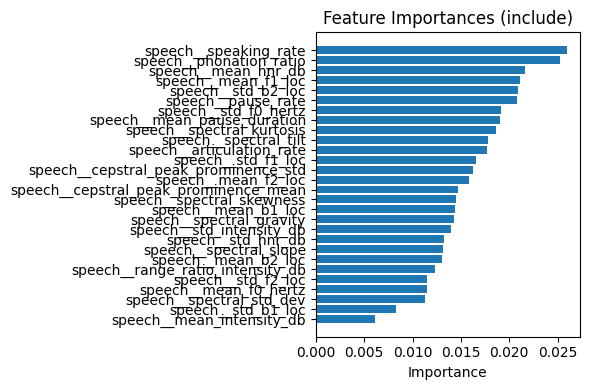

In [ ]:
experiment_1c_regression_importance = (
    show_feature_importance(
        experiment_1c_regression_final[
            "model"
        ],
        top_n=28,
    )
)

### Experiment 1d Speech Only + DNAMite Feature Selection

In [ ]:
# ============================================================
# EXPERIMENT 1d
# Speech Only + DNAMite Feature Selection
# PHQ-8 Score Regression
# ============================================================

DNAMITE_SELECTION_REG_PARAM = 0.0001

### Experiment 1d Nested CV

Using severity-stratified master regression folds.

Experiment 1d - Speech Only + DNAMite Feature Selection | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 22 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc']
DNAMite epochs | split=1 | ran=33 | best=3 | best val_loss=0.823515 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=1.066769 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.147026 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.547714 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0005}
Inner-fold selected features: (12, 13.333333333333334, 14)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_01.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0005}
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 9 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db']
DNAMite epochs | split=1 | ran=45 | best=15 | best val_loss=0.932962 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.5636671669999487, 'peak_ram_mb': 2873.96875, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_01.json
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_01.json
Saved outer-fold model to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimize

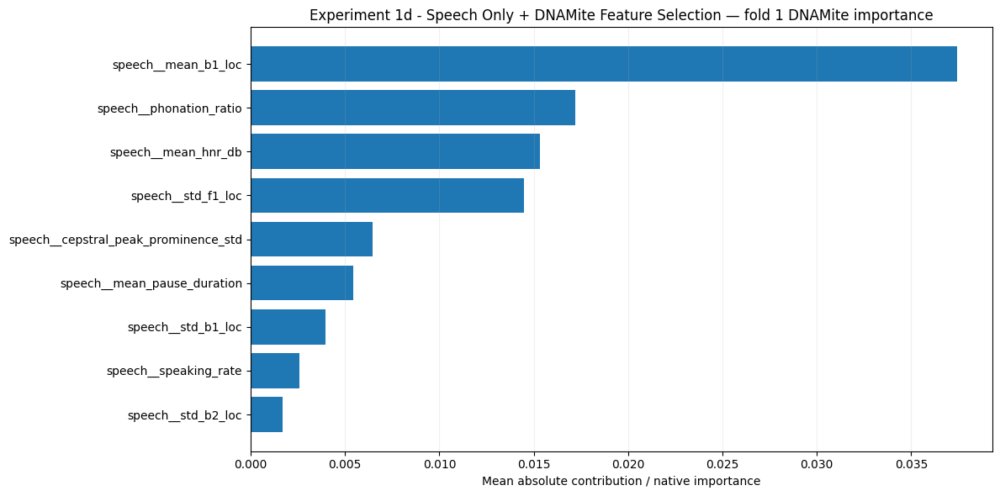

MAE               4.205895
RMSE              5.171265
R2                0.035574
Spearman_Rho      0.361300
Spearman_P        0.064077
Pearson_R         0.327337
Pearson_P         0.095576
Exact_Accuracy    0.074074
Within_1          0.259259
Within_2          0.333333
Within_3          0.481481
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 1d - Speech Only + DNAMite Feature Selection | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 28 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.825330 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 28 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.866895 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.904849 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.035560 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}
Inner-fold selected features: (15, 15.666666666666666, 16)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_02.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 15 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean']
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.542902 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.0237471379987255, 'peak_ram_mb': 2877.5859375, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_02.json
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimi

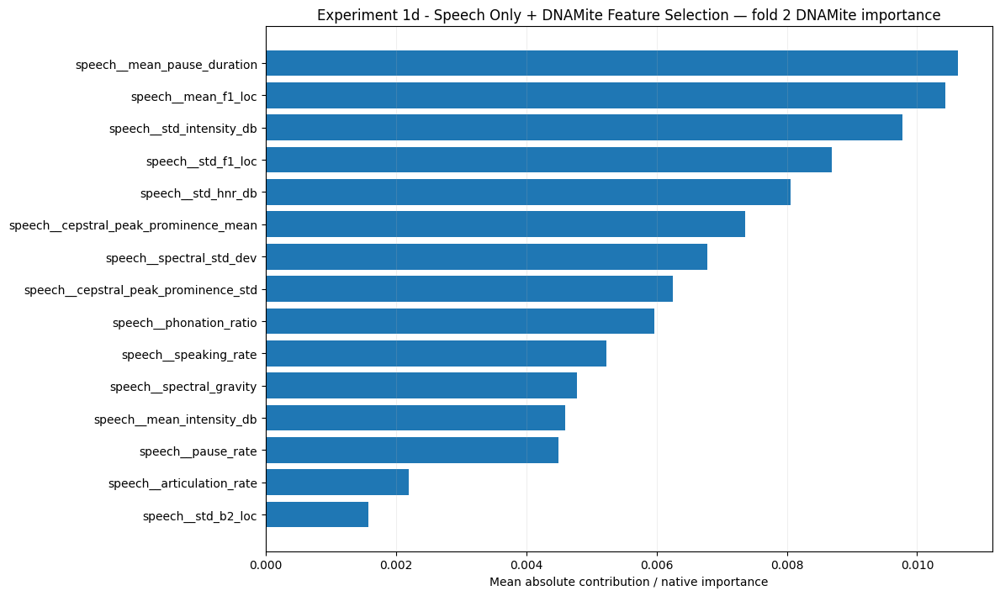

MAE               4.977240
RMSE              6.265175
R2               -0.005871
Spearman_Rho      0.012884
Spearman_P        0.949146
Pearson_R        -0.064523
Pearson_P         0.749165
Exact_Accuracy    0.000000
Within_1          0.222222
Within_2          0.259259
Within_3          0.407407
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 1d - Speech Only + DNAMite Feature Selection | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 19 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc']
DNAMite epochs | split=1 | ran=186 | best=156 | best val_loss=0.739042 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 25 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity']
DNAMite epochs | split=1 | ran=39 | best=9 | best val_loss=0.839703 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.850494 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.704962 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 16, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Inner-fold selected features: (21, 22.333333333333332, 24)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_03.json
Best parameters: {'max_bins': 16, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=46 | best=16 | best val_loss=0.868821 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.148799955000868, 'peak_ram_mb': 2885.05078125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature

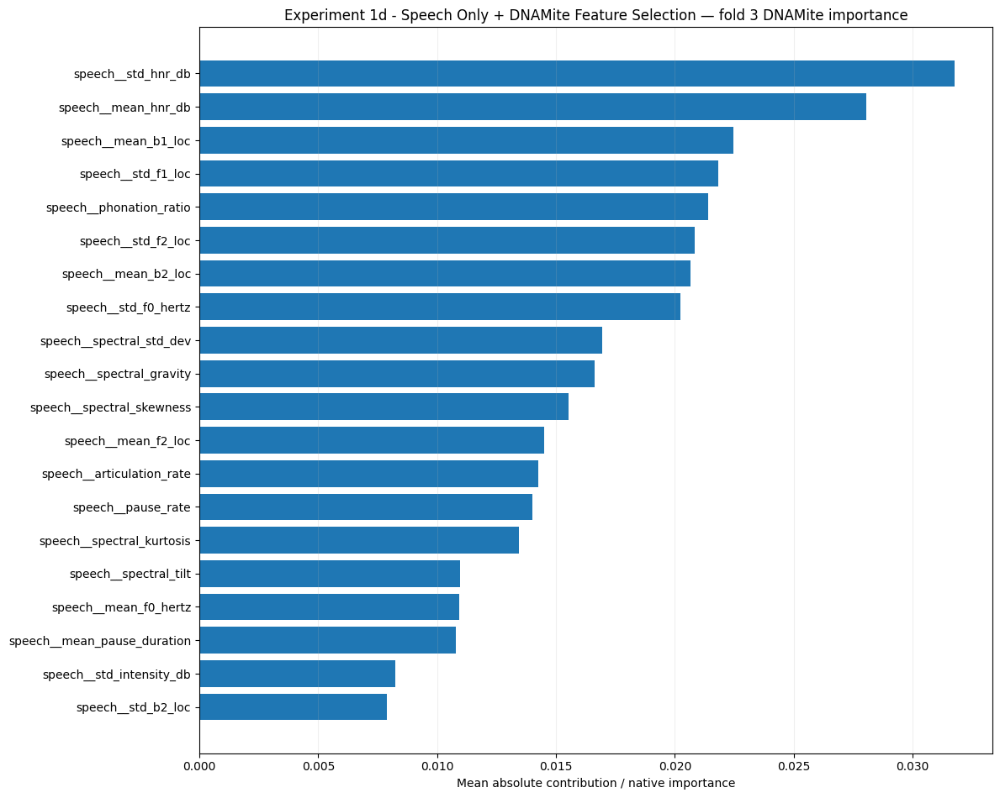

MAE               4.687230
RMSE              5.728804
R2               -0.043220
Spearman_Rho     -0.111589
Spearman_P        0.579488
Pearson_R        -0.169053
Pearson_P         0.399256
Exact_Accuracy    0.111111
Within_1          0.148148
Within_2          0.222222
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 1d - Speech Only + DNAMite Feature Selection | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 19 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc']
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.806412 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 24 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc']
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.792623 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.814650 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.684759 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 32, 'learning_rate': np.float64(0.0005), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}
Inner-fold selected features: (13, 14.0, 15)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_04.json
Best parameters: {'max_bins': 32, 'learning_rate': np.float64(0.0005), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 26 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev']
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.614050 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.142799429999286, 'peak_ram_mb': 2894.77734375, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Sa

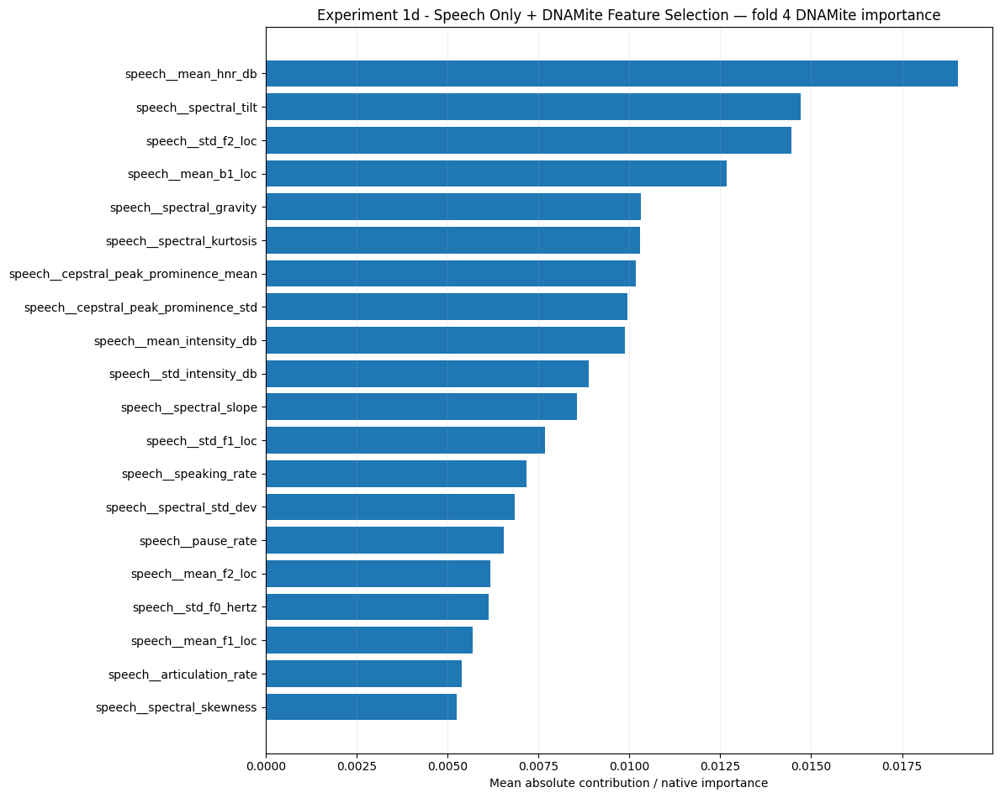

MAE               4.412145
RMSE              5.106134
R2               -0.001735
Spearman_Rho      0.048714
Spearman_P        0.809331
Pearson_R         0.025995
Pearson_P         0.897594
Exact_Accuracy    0.111111
Within_1          0.148148
Within_2          0.222222
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 1d - Speech Only + DNAMite Feature Selection | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 27 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness']
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.728082 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 22 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc']
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.803225 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.817457 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.361301 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
Inner-fold selected features: (26, 26.0, 26)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/fold_05.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 28 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
DNAMite epochs | split=1 | ran=97 | best=67 | best val_loss=0.820873 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 3.288807111999631, 'peak_ram_mb': 2897.66015625, 'peak_gpu_me

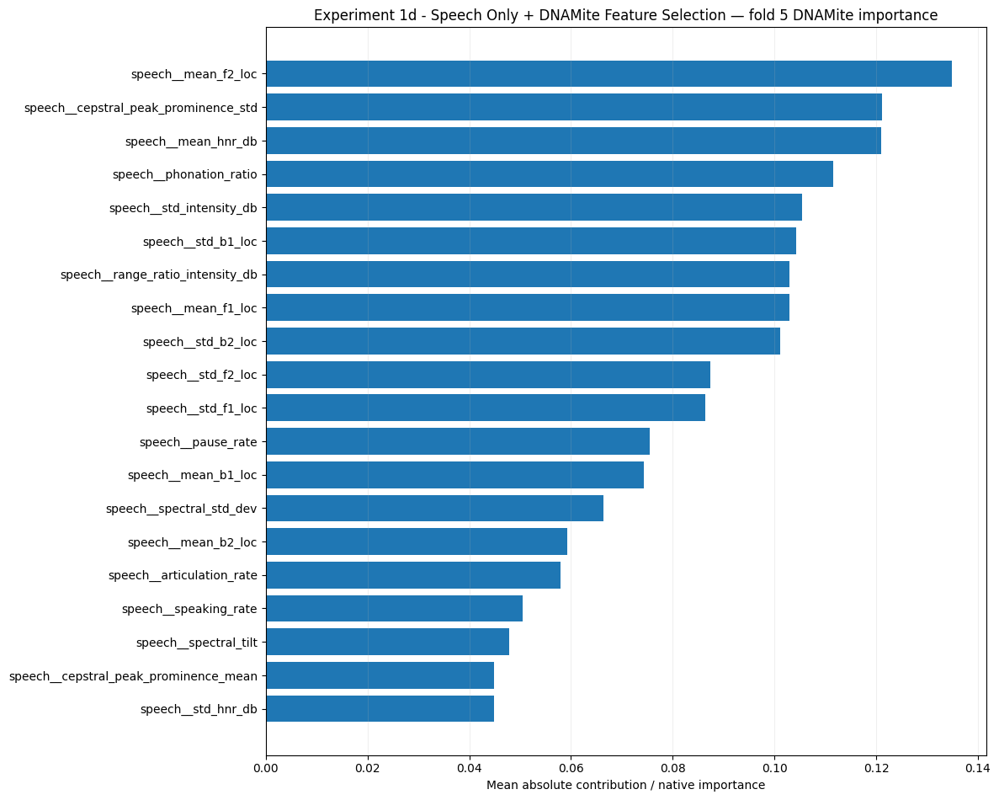

MAE               5.197057
RMSE              6.582972
R2               -0.369617
Spearman_Rho     -0.082440
Spearman_P        0.682687
Pearson_R        -0.157763
Pearson_P         0.431921
Exact_Accuracy    0.000000
Within_1          0.148148
Within_2          0.296296
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.695913,0.403425
RMSE,5.770870,0.653264
R2,-0.076974,0.165954
Spearman_Rho,0.045774,0.188314
Pearson_R,-0.007601,0.203204
Exact_Accuracy,0.059259,0.056169
Within_1,0.185185,0.052378
Within_2,0.266667,0.048290
Within_3,0.429630,0.042229



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
EXPERIMENT_1D_NAME = (
    "Experiment 1d - "
    "Speech Only + DNAMite Feature Selection"
)

experiment_1d_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_1D_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        use_feature_selection=True,
    )
)

### Experiment 1d Nested CV Results

In [ ]:
print(
    "Experiment 1d - "
    "Nested-CV Outer Fold Results"
)

display(
    experiment_1d_regression_cv[
        "outer_results"
    ]
)


print(
    "\nExperiment 1d - "
    "Nested-CV Mean ± SD"
)

display(
    experiment_1d_regression_cv[
        "summary"
    ]
)

Experiment 1d - Nested-CV Outer Fold Results


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,MAE,RMSE,R2,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0005,32,32,2,0.0005,4.205895,5.171265,0.035574,...,0.481481,4.334362,5.267151,-0.000523,1.563667,2873.968750,16.518066,22.0,0.000045,2.106268e-05
1,2,8,0.0005,16,32,2,0.0001,4.977240,6.265175,-0.005871,...,0.407407,4.996914,6.247201,-0.000108,1.023747,2877.585938,16.518066,22.0,0.000026,1.040168e-07
2,3,16,0.0005,32,16,2,0.0010,4.687230,5.728804,-0.043220,...,0.444444,4.607339,5.614449,-0.001987,1.148800,2885.050781,16.518066,22.0,0.000029,1.142966e-07
3,4,32,0.0005,16,32,2,0.0001,4.412145,5.106134,-0.001735,...,0.370370,4.469822,5.104431,-0.001067,1.142799,2894.777344,16.518066,22.0,0.000030,1.180542e-07
4,5,8,0.0005,32,16,2,0.0001,5.197057,6.582972,-0.369617,...,0.444444,4.728052,5.625067,-0.000024,3.288807,2897.660156,16.518066,22.0,0.000105,4.145976e-07



Experiment 1d - Nested-CV Mean ± SD


,Mean,SD
MAE,4.695913,0.403425
RMSE,5.770870,0.653264
R2,-0.076974,0.165954
Spearman_Rho,0.045774,0.188314
Pearson_R,-0.007601,0.203204
Exact_Accuracy,0.059259,0.056169
Within_1,0.185185,0.052378
Within_2,0.266667,0.048290
Within_3,0.429630,0.042229


### Experiment 1d Best Parameters by Outer Fold

In [ ]:
PARAMETER_COLUMNS = [
    "max_bins",
    "learning_rate",
    "n_embed",
    "n_hidden",
    "n_layers",
]

experiment_1d_best_parameters_by_fold = (
    experiment_1d_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            *PARAMETER_COLUMNS,
        ]
    ]
)

display(
    experiment_1d_best_parameters_by_fold
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers
0,1,8,0.0005,32,32,2
1,2,8,0.0005,16,32,2
2,3,16,0.0005,32,16,2
3,4,32,0.0005,16,32,2
4,5,8,0.0005,32,16,2


### Experiment 1d Nested-CV Rounded Predictions

In [ ]:
experiment_1d_cv_rounded = (
    round_phq8_predictions(
        experiment_1d_regression_cv[
            "oof_predictions"
        ]
    )
)


--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


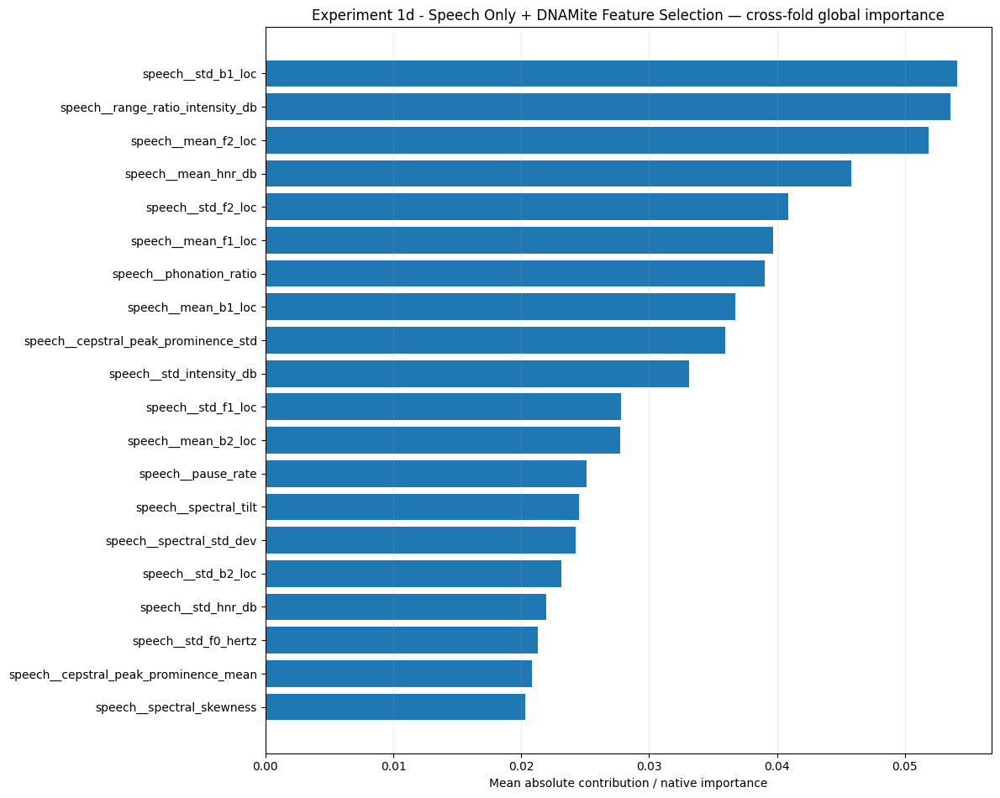

Interpretability summary saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection/interpretability_summary


In [ ]:
experiment_1d_regression_interpretability = (
    aggregate_interpretability_across_folds(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1D_NAME
        ),
        top_k=10,
    )
)

print(
    "Interpretability summary saved to:"
)

print(
    experiment_1d_regression_interpretability
)

In [ ]:
experiment_1d_energy = (
    summarize_energy_utilization(
        model_family=(
            MODEL_FAMILY
        ),
        experiment_name=(
            EXPERIMENT_1D_NAME
        ),
    )
)

,Mean,SD,Min,Max
training_energy_kwh,0.000047,0.000033,2.641793e-05,0.000105
training_co2_kg,0.000004,0.000009,1.040168e-07,0.000021


### Experiment 1d Nested-CV PHQ-8 Confusion Matrix

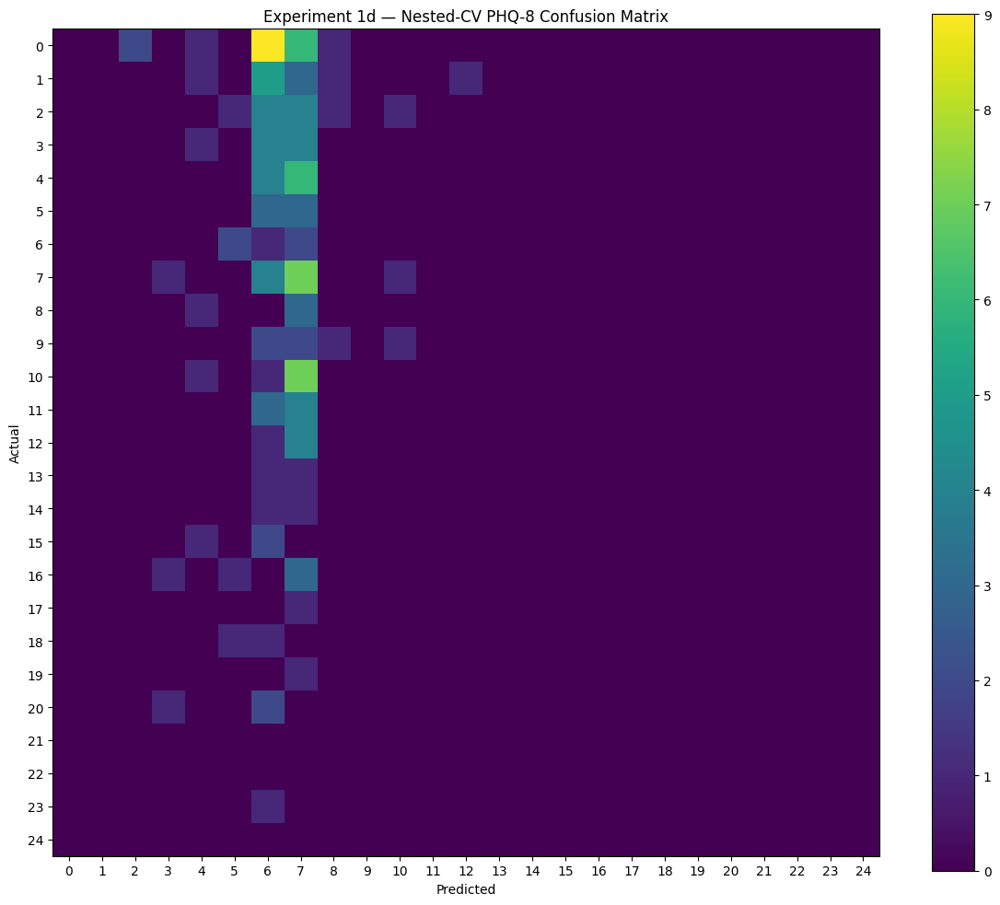

In [ ]:
experiment_1d_cv_confusion_matrix = (
    plot_confusion_matrix(
        y_true=(
            y_regression_development
            .astype(int)
        ),
        y_pred=(
            experiment_1d_cv_rounded
        ),
        labels=(
            PHQ8_CLASS_LABELS
        ),
        title=(
            "Experiment 1d — "
            "Nested-CV PHQ-8 Confusion Matrix"
        ),
        figsize=(
            12,
            10,
        ),
    )
)

### Experiment 1d Final Regression Model

In [ ]:
experiment_1d_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        experiment_name=(
            EXPERIMENT_1D_NAME
        ),
        use_feature_selection=True,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 28 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
DNAMite epochs | split=1 | ran=81 | best=51 | best val_loss=1.642090 | hit ceiling=False
  Inner fold 2/3
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 27 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness']
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.471357 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.481104 | hit ceiling=False
  Inner fold 3/3
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 28
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.495524 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}
Inner-fold selected features: (12, 13.333333333333334, 14)
Final best parameters: {'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}
Running final DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


Final DNAMite active features: 15 / 28
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 39, 'best_epoch': 9, 'best_val_loss': 1.0786850452423096, 'hit_epoch_ceiling': False}]

FINAL TEST METRICS
{'MAE': 5.449739627066312, 'RMSE': np.float64(6.521434669648684), 'R2': -0.03485007162347742, 'Spearman_Rho': -0.2642998559884508, 'Spearman_P': 0.07590637917442636, 'Pearson_R': -0.2718705489969009, 'Pearson_P': 0.06758450217344537, 'Exact_Accuracy': np.float64(0.021739130434782608), 'Within_1': np.float64(0.10869565217391304), 'Within_2': np.float64

### Experiment 1d Final Best Parameters

In [ ]:
print(
    "Experiment 1d - "
    "Final Selected DNAMite Parameters"
)

print(
    experiment_1d_regression_final[
        "best_parameters"
    ]
)

Experiment 1d - Final Selected DNAMite Parameters
{'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0001}


### Experiment 1d Final Test Metrics

In [ ]:
print(
    "Experiment 1d - "
    "FINAL TEST METRICS"
)

display(
    pd.Series(
        experiment_1d_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

Experiment 1d - FINAL TEST METRICS


,Value
MAE,5.449740
RMSE,6.521435
R2,-0.034850
Spearman_Rho,-0.264300
Spearman_P,0.075906
Pearson_R,-0.271871
Pearson_P,0.067585
Exact_Accuracy,0.021739
Within_1,0.108696
Within_2,0.173913


### Experiment 1d Test PHQ-8 Confusion Matrix

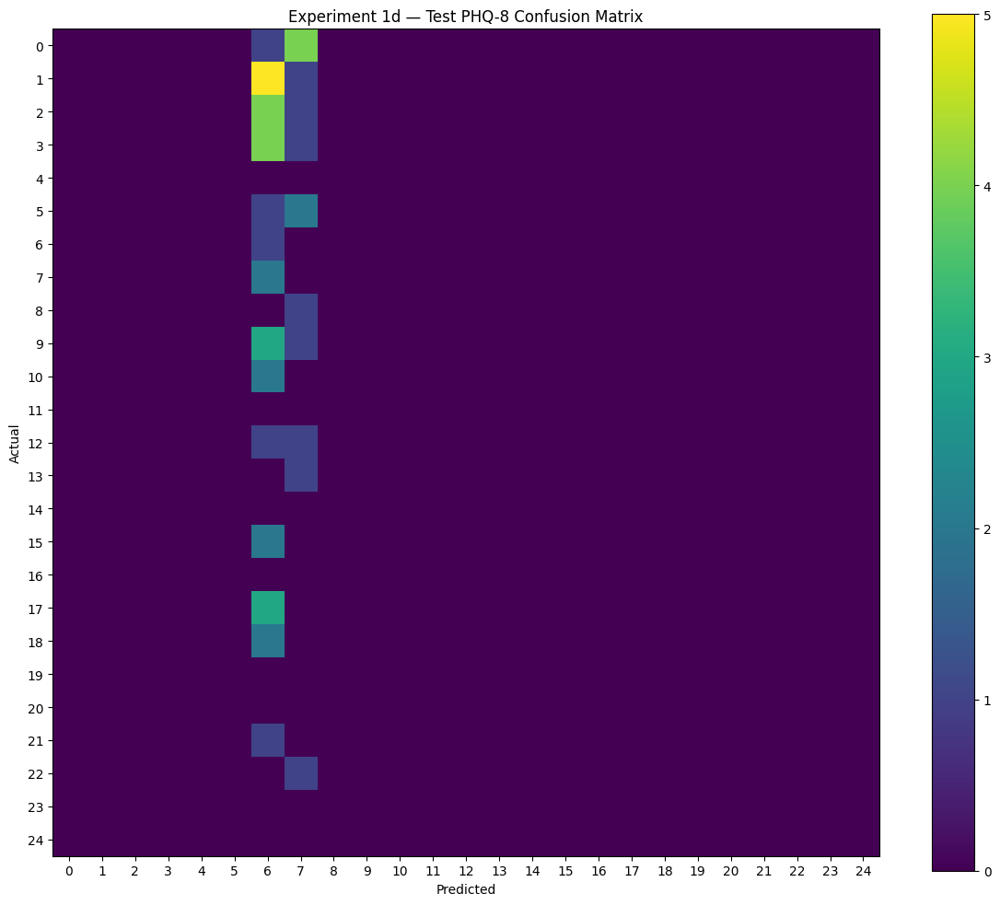

In [ ]:
experiment_1d_test_confusion_matrix = (
    plot_confusion_matrix(
        y_true=(
            y_regression_test
            .astype(int)
        ),
        y_pred=(
            experiment_1d_regression_final[
                "test_rounded_predictions"
            ]
        ),
        labels=(
            PHQ8_CLASS_LABELS
        ),
        title=(
            "Experiment 1d — "
            "Test PHQ-8 Confusion Matrix"
        ),
        figsize=(
            12,
            10,
        ),
    )
)

### Experiment 1d Actual vs. Predicted PHQ-8

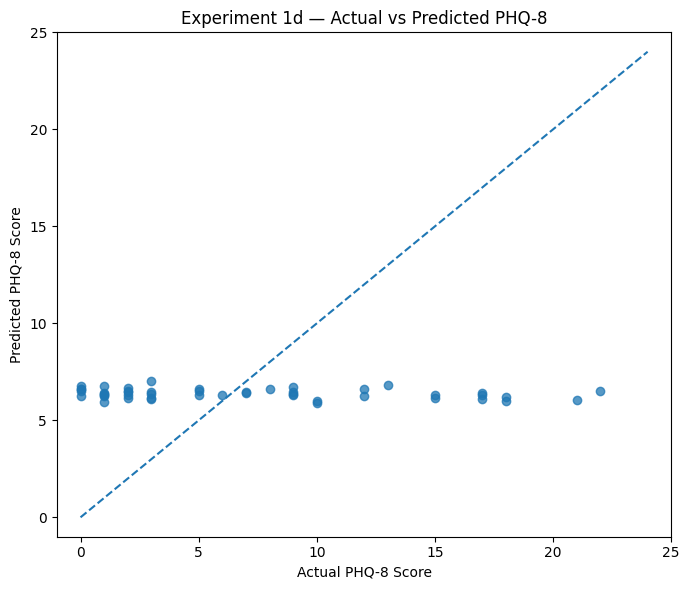

In [ ]:
plot_regression_predictions(
    y_true=(
        y_regression_test
    ),
    predictions=(
        experiment_1d_regression_final[
            "test_predictions"
        ]
    ),
    title=(
        "Experiment 1d — "
        "Actual vs Predicted PHQ-8"
    ),
)

### Experiment 1d Selected Speech Features

In [ ]:
# ============================================================
# EXPERIMENT 1D — SELECTED SPEECH FEATURES
# ============================================================

experiment_1d_model = (
    experiment_1d_regression_final[
        "model"
    ]
)

selected_feature_names = (
    experiment_1d_model.selected_feats_
)


print(
    "Number of selected speech features:",
    len(
        selected_feature_names
    )
)

print(
    "\nSelected speech features:"
)

for feature in selected_feature_names:
    print(
        feature
    )

Number of selected speech features: 15

Selected speech features:
speech__speaking_rate
speech__articulation_rate
speech__mean_pause_duration
speech__mean_f0_hertz
speech__mean_intensity_db
speech__mean_hnr_db
speech__spectral_slope
speech__cepstral_peak_prominence_std
speech__mean_f1_loc
speech__mean_b1_loc
speech__std_b1_loc
speech__std_f2_loc
speech__std_b2_loc
speech__spectral_std_dev
speech__spectral_skewness


### Experiment 1d Selected Features Table

In [ ]:
experiment_1d_selected_features_df = (
    pd.DataFrame(
        {
            "Selected_Feature": (
                selected_feature_names
            )
        }
    )
)

display(
    experiment_1d_selected_features_df
)

,Selected_Feature
0,speech__speaking_rate
1,speech__articulation_rate
2,speech__mean_pause_duration
3,speech__mean_f0_hertz
4,speech__mean_intensity_db
5,speech__mean_hnr_db
6,speech__spectral_slope
7,speech__cepstral_peak_prominence_std
8,speech__mean_f1_loc
9,speech__mean_b1_loc


### Experiment 1d Feature Importance

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.009245,31
1,0,speech__articulation_rate,0.006608,31
2,0,speech__mean_pause_duration,0.013463,31
3,0,speech__mean_f0_hertz,0.011677,31
4,0,speech__mean_intensity_db,0.006361,31
5,0,speech__mean_hnr_db,0.003813,31
6,0,speech__spectral_slope,0.008305,31
7,0,speech__cepstral_peak_prominence_std,0.008067,31
8,0,speech__mean_f1_loc,0.010289,31
9,0,speech__mean_b1_loc,0.015668,31


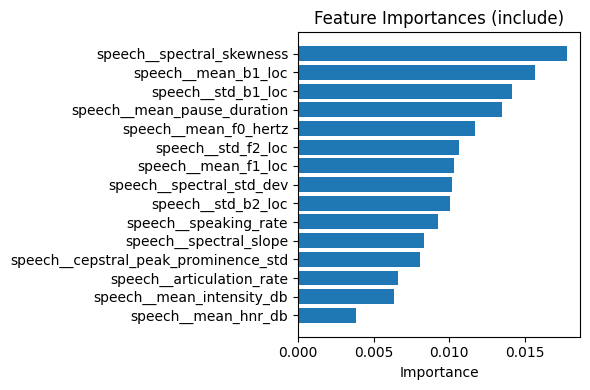

In [ ]:
experiment_1d_regression_importance = (
    show_feature_importance(
        experiment_1d_regression_final[
            "model"
        ],
        top_n=28,
    )
)

### Experiment 1d Shape Function

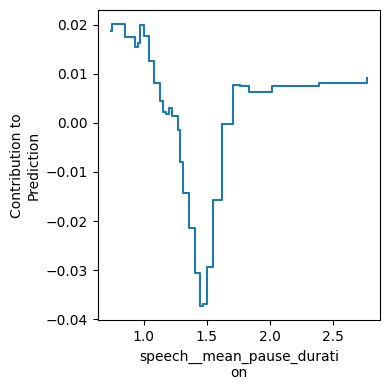

In [ ]:
# ============================================================
# EXPERIMENT 1D — EXAMPLE SHAPE FUNCTION
# ============================================================

feature_to_plot = (
    "speech__mean_pause_duration"
)

if (
    feature_to_plot
    in selected_feature_names
):
    experiment_1d_model.plot_shape_function(
        feature_to_plot
    )

    plt.show()

else:
    print(
        feature_to_plot,
        "was not selected by DNAMite."
    )

In [ ]:
# ============================================================
# RESET DNAMITE FEATURE SELECTION
# ============================================================

DNAMITE_SELECTION_REG_PARAM = 0.01

### Experiment 1e and 1f Functions

In [ ]:
import torch
import torch.nn.functional as F

from scipy.ndimage import gaussian_filter1d

In [ ]:
imbalance_strategy="none"

In [ ]:
def calculate_positive_class_weight(y_train):
    """
    Positive-class weight for BCEWithLogitsLoss.

    pos_weight = n_negative / n_positive
    """

    y_train = np.asarray(
        y_train
    ).astype(int)

    n_negative = np.sum(
        y_train == 0
    )

    n_positive = np.sum(
        y_train == 1
    )

    if n_positive == 0:
        raise ValueError(
            "Training fold contains no positive examples."
        )

    return (
        n_negative
        / n_positive
    )

In [ ]:
# ============================================================
# IMBALANCE-HANDLING CONFIGURATION -- OPTIMIZED
# ============================================================

LDS_EPSILON = 1e-6

# Backward-compatible defaults for diagnostics/direct calls.
LDS_SIGMA = 2.0
LDS_REWEIGHT_METHOD = "sqrt_inverse"

# These are tuned inside inner CV for LDS experiments.
LDS_SIGMA_CANDIDATES = [
    0.5,
    1.0,
    2.0,
    3.0,
    4.0,
]

LDS_REWEIGHT_METHOD_CANDIDATES = [
    "sqrt_inverse",
    "inverse",
]

# Tuned inside inner CV for Weighted-BCE experiments.
WEIGHTED_BCE_POSITIVE_MULTIPLIERS = [
    1.0,
    1.25,
    1.5,
    2.0,
]


In [ ]:
from scipy.ndimage import gaussian_filter1d


LDS_KERNEL_SIGMA = 2.0
LDS_EPSILON = 1e-6


def calculate_lds_weights(
    y_train,
    min_score=PHQ8_MIN,
    max_score=PHQ8_MAX,
    sigma=LDS_KERNEL_SIGMA,
):
    """
    Compute Label Distribution Smoothing weights for
    integer PHQ-8 targets.

    Returns one weight per training participant.
    """

    y_train = np.asarray(
        y_train
    ).astype(int)

    score_values = np.arange(
        min_score,
        max_score + 1,
    )

    counts = np.array(
        [
            np.sum(
                y_train == score
            )
            for score in score_values
        ],
        dtype=float,
    )


    # Smooth neighboring PHQ-8 label frequencies.
    effective_density = gaussian_filter1d(
        counts,
        sigma=sigma,
        mode="constant",
    )


    # Rare effective target regions receive larger weights.
    inverse_density = (
        1.0
        / (
            effective_density
            + LDS_EPSILON
        )
    )


    # Map each participant's PHQ-8 score to its weight.
    sample_weights = np.array(
        [
            inverse_density[
                score - min_score
            ]
            for score in y_train
        ],
        dtype=float,
    )


    # Normalize so mean weight = 1.
    sample_weights = (
        sample_weights
        / sample_weights.mean()
    )


    return sample_weights

In [ ]:
class WeightedBCEDNAMiteBinaryClassifier(
    DNAMiteBinaryClassifier
):
    """
    DNAMite binary classifier using class-weighted BCE.

    The positive-class weight is recomputed every time fit()
    is called:

        pos_weight = n_negative / n_positive

    Therefore nested-CV folds automatically calculate weights
    using training data only.
    """

    def fit(
        self,
        X,
        y,
        pairs_list=None,
        partialed_feats=None,
    ):
        y_array = (
            np.asarray(y)
            .reshape(-1)
            .astype(int)
        )

        n_negative = np.sum(
            y_array == 0
        )

        n_positive = np.sum(
            y_array == 1
        )

        if n_positive == 0:
            raise ValueError(
                "Cannot calculate weighted BCE: "
                "training data contains no positive examples."
            )

        if n_negative == 0:
            raise ValueError(
                "Cannot calculate weighted BCE: "
                "training data contains no negative examples."
            )


        automatic_pos_weight = (
            n_negative
            / n_positive
        )

        multiplier = float(
            getattr(
                self,
                "positive_class_multiplier_",
                1.0,
            )
        )

        self.pos_weight_value_ = (
            automatic_pos_weight
            * multiplier
        )

        self.pos_weight_ = torch.tensor(
            self.pos_weight_value_,
            dtype=torch.float32,
            device=self.device,
        )


        print(
            "Weighted BCE | "
            f"negative={n_negative}, "
            f"positive={n_positive}, "
            f"automatic_pos_weight="
            f"{automatic_pos_weight:.4f}, "
            f"multiplier={multiplier:.2f}, "
            f"final_pos_weight="
            f"{self.pos_weight_value_:.4f}"
        )


        return super().fit(
            X,
            y,
            pairs_list=pairs_list,
            partialed_feats=partialed_feats,
        )


    def train_epoch_mains(
        self,
        model,
        train_loader,
        optimizer,
        partialed_indices=None,
        on_partialed_set=False,
    ):
        """
        Same DNAMite training procedure, except BCE uses
        positive-class weighting.
        """

        model.train()

        total_loss = 0

        active_feats = model.active_feats
        y_pred_init = 0


        for X_main, labels in train_loader:

            X_main = X_main.to(
                self.device
            )

            labels = labels.to(
                self.device
            )


            if partialed_indices is not None:

                with torch.no_grad():

                    model.active_feats = (
                        torch.tensor(
                            partialed_indices
                        ).to(
                            self.device
                        )
                    )

                    y_pred_init = (
                        model(
                            mains=X_main
                        )
                        .squeeze(-1)
                    )


                    model.active_feats = (
                        torch.tensor(
                            [
                                i
                                for i in active_feats
                                if i
                                not in partialed_indices
                            ]
                        ).to(
                            self.device
                        )
                    )


            y_pred = (
                model(
                    mains=X_main,
                    on_partialed_set=(
                        on_partialed_set
                    ),
                )
                .squeeze(-1)
            )

            y_pred += y_pred_init


            # =================================================
            # CHANGE FROM STANDARD DNAMITE:
            # weighted BCE
            # =================================================

            loss = (
                F.binary_cross_entropy_with_logits(
                    y_pred,
                    labels,
                    pos_weight=(
                        self.pos_weight_
                    ),
                )
            )


            if model.penalized:

                loss += (
                    model.loss_penalty(
                        mains=True
                    )
                )


            optimizer.zero_grad()

            loss.backward()

            optimizer.step()


            total_loss += (
                loss.item()
            )


        model.active_feats = (
            active_feats
        )


        return (
            total_loss
            / len(
                train_loader
            )
        )

In [ ]:
def calculate_lds_weight_lookup(
    y_train,
    min_score=PHQ8_MIN,
    max_score=PHQ8_MAX,
    sigma=LDS_SIGMA,
    reweight_method=LDS_REWEIGHT_METHOD,
):
    """
    Calculate LDS weights for PHQ-8 scores.

    Steps:
        1. Count observations at every PHQ-8 score.
        2. Smooth that histogram with a Gaussian kernel.
        3. Give rarer effective target regions larger weights.
        4. Normalize weights so the mean training weight = 1.

    Returns
    -------
    weight_lookup : np.ndarray
        One weight for each score from PHQ8_MIN to PHQ8_MAX.

    effective_density : np.ndarray
        Smoothed label density.
    """

    y_train = (
        np.asarray(
            y_train
        )
        .reshape(-1)
    )


    y_integer = (
        np.rint(
            y_train
        )
        .astype(int)
    )


    if np.any(
        y_integer < min_score
    ) or np.any(
        y_integer > max_score
    ):
        raise ValueError(
            "Found PHQ-8 score outside "
            f"[{min_score}, {max_score}]."
        )


    # ========================================================
    # RAW LABEL DISTRIBUTION
    # ========================================================

    counts = np.zeros(
        max_score
        - min_score
        + 1,
        dtype=float,
    )


    for score in y_integer:

        counts[
            score
            - min_score
        ] += 1


    # ========================================================
    # LABEL DISTRIBUTION SMOOTHING
    # ========================================================

    effective_density = (
        gaussian_filter1d(
            counts,
            sigma=sigma,
            mode="constant",
        )
    )


    # ========================================================
    # REWEIGHTING
    # ========================================================

    if (
        reweight_method
        == "inverse"
    ):

        weight_lookup = (
            1.0
            / (
                effective_density
                + LDS_EPSILON
            )
        )


    elif (
        reweight_method
        == "sqrt_inverse"
    ):

        weight_lookup = (
            1.0
            / np.sqrt(
                effective_density
                + LDS_EPSILON
            )
        )


    else:
        raise ValueError(
            "reweight_method must be "
            "'inverse' or 'sqrt_inverse'."
        )


    # ========================================================
    # NORMALIZE USING OBSERVED TRAINING SAMPLES
    # ========================================================

    sample_weights = np.array(
        [
            weight_lookup[
                score
                - min_score
            ]
            for score
            in y_integer
        ],
        dtype=float,
    )


    mean_training_weight = (
        sample_weights.mean()
    )


    weight_lookup = (
        weight_lookup
        / mean_training_weight
    )


    return (
        weight_lookup,
        effective_density,
    )

In [ ]:
class LDSDNAMiteRegressor(
    DNAMiteRegressor
):
    """
    DNAMite regressor using LDS-weighted MSE during training.

    LDS weights are recalculated every time fit() is called,
    so nested-CV training folds remain leakage-safe.
    """

    def fit(
        self,
        X,
        y,
        pairs_list=None,
        partialed_feats=None,
    ):
        (
            self.lds_weight_lookup_,
            self.lds_effective_density_,
        ) = calculate_lds_weight_lookup(
            y_train=y,
            sigma=float(
                getattr(
                    self,
                    "lds_sigma_",
                    LDS_SIGMA,
                )
            ),
            reweight_method=(
                getattr(
                    self,
                    "lds_reweight_method_",
                    LDS_REWEIGHT_METHOD,
                )
            ),
        )


        self.lds_weight_lookup_tensor_ = (
            torch.tensor(
                self.lds_weight_lookup_,
                dtype=torch.float32,
                device=self.device,
            )
        )

        print(
            "LDS | "
            f"sigma={getattr(self, 'lds_sigma_', LDS_SIGMA)}, "
            f"method={getattr(self, 'lds_reweight_method_', LDS_REWEIGHT_METHOD)}, "
            f"weight range=("
            f"{self.lds_weight_lookup_.min():.3f}, "
            f"{self.lds_weight_lookup_.max():.3f})"
        )


        return super().fit(
            X,
            y,
            pairs_list=pairs_list,
            partialed_feats=partialed_feats,
        )


    def train_epoch_mains(
        self,
        model,
        train_loader,
        optimizer,
        partialed_indices=None,
        on_partialed_set=False,
    ):
        """
        Same DNAMite training loop, except MSE is weighted
        according to LDS target-density weights.
        """

        model.train()

        total_loss = 0

        active_feats = model.active_feats
        y_pred_init = 0


        for X_main, labels in train_loader:

            X_main = X_main.to(
                self.device
            )

            labels = labels.to(
                self.device
            )


            if partialed_indices is not None:

                with torch.no_grad():

                    model.active_feats = (
                        torch.tensor(
                            partialed_indices
                        ).to(
                            self.device
                        )
                    )

                    y_pred_init = (
                        model(
                            mains=X_main
                        )
                        .squeeze(-1)
                    )


                    model.active_feats = (
                        torch.tensor(
                            [
                                i
                                for i in active_feats
                                if i
                                not in partialed_indices
                            ]
                        ).to(
                            self.device
                        )
                    )


            y_pred = (
                model(
                    mains=X_main,
                    on_partialed_set=(
                        on_partialed_set
                    ),
                )
                .squeeze(-1)
            )

            y_pred += y_pred_init


            # =================================================
            # MAP PHQ-8 LABEL → LDS WEIGHT
            # =================================================

            label_indices = (
                torch.round(
                    labels
                )
                .long()
                .clamp(
                    PHQ8_MIN,
                    PHQ8_MAX,
                )
                - PHQ8_MIN
            )


            sample_weights = (
                self
                .lds_weight_lookup_tensor_[
                    label_indices
                ]
            )


            # =================================================
            # PER-SAMPLE MSE
            # =================================================

            per_sample_loss = (
                F.mse_loss(
                    y_pred,
                    labels,
                    reduction="none",
                )
            )


            # =================================================
            # LDS-WEIGHTED MSE
            # =================================================

            loss = (
                sample_weights
                * per_sample_loss
            ).mean()


            if model.penalized:

                loss += (
                    model.loss_penalty(
                        mains=True
                    )
                )


            optimizer.zero_grad()

            loss.backward()

            optimizer.step()


            total_loss += (
                loss.item()
            )


        model.active_feats = (
            active_feats
        )


        return (
            total_loss
            / len(
                train_loader
            )
        )

### Experiment 1e Binary Classification BCE


Experiment 1e - Speech Only + Weighted BCE | Classification | Outer fold 1
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=55 | best=25 | best val_loss=0.660188 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.682344 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=55 | best=25 | best val_loss=0.667387 | hit ceiling=False
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.25, final_pos_weight=2.8409
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.715624 | hit ce

,positive_class_multiplier,mean_score,sd_score
0,2.00,0.319804,0.142341
1,1.25,0.319686,0.130247
2,1.50,0.318587,0.129409
3,1.00,0.312899,0.087804


Best imbalance parameters: {'positive_class_multiplier': 2.0} mean inner PR-AUC: 0.31980382617843484
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 2.0}
  Inner fold 1/3
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=2.00, final_pos_weight=4.5455
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=38 | best=8 | best val_loss=0.888365 | hit ceiling=False
  Inner fold 2/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=2.00, final_pos_weight=4.8571
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.968939 | hit ceiling=False
  Inner fold 3/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=2.00, final_pos_weight=4.8571
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=0.810258 | hit ceiling=False
DNA

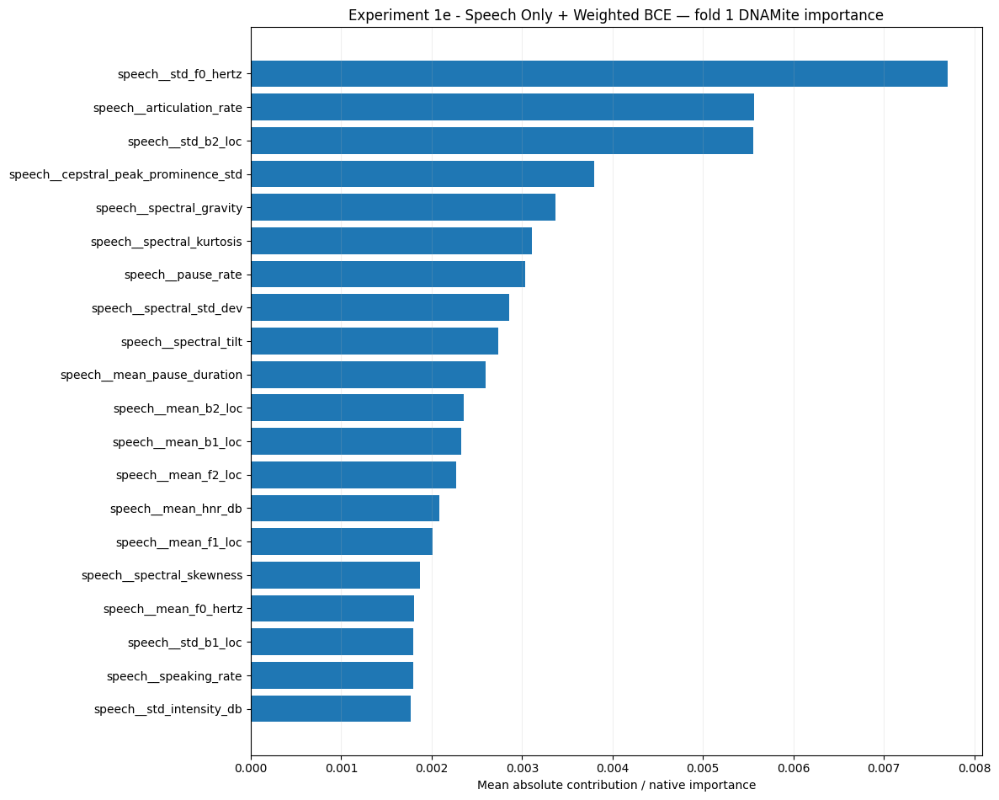

ROC_AUC              0.657895
PR_AUC               0.359537
AUPRC                0.359537
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208497
Log_Loss             0.607674
Threshold            0.050000
dtype: float64

Experiment 1e - Speech Only + Weighted BCE | Classification | Outer fold 2
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=126 | best=96 | best val_loss=0.458202 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=58 | best=28 | best val_loss=0.664917 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier

,positive_class_multiplier,mean_score,sd_score
0,1.25,0.326534,0.077512
1,1.00,0.319251,0.069778
2,1.50,0.293223,0.021551
3,2.00,0.289255,0.021583


Best imbalance parameters: {'positive_class_multiplier': 1.25} mean inner PR-AUC: 0.32653378996090693
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.25}
  Inner fold 1/3
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.25, final_pos_weight=2.8409
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.716070 | hit ceiling=False
  Inner fold 2/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.691498 | hit ceiling=False
  Inner fold 3/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.713743 | hit ceiling=False

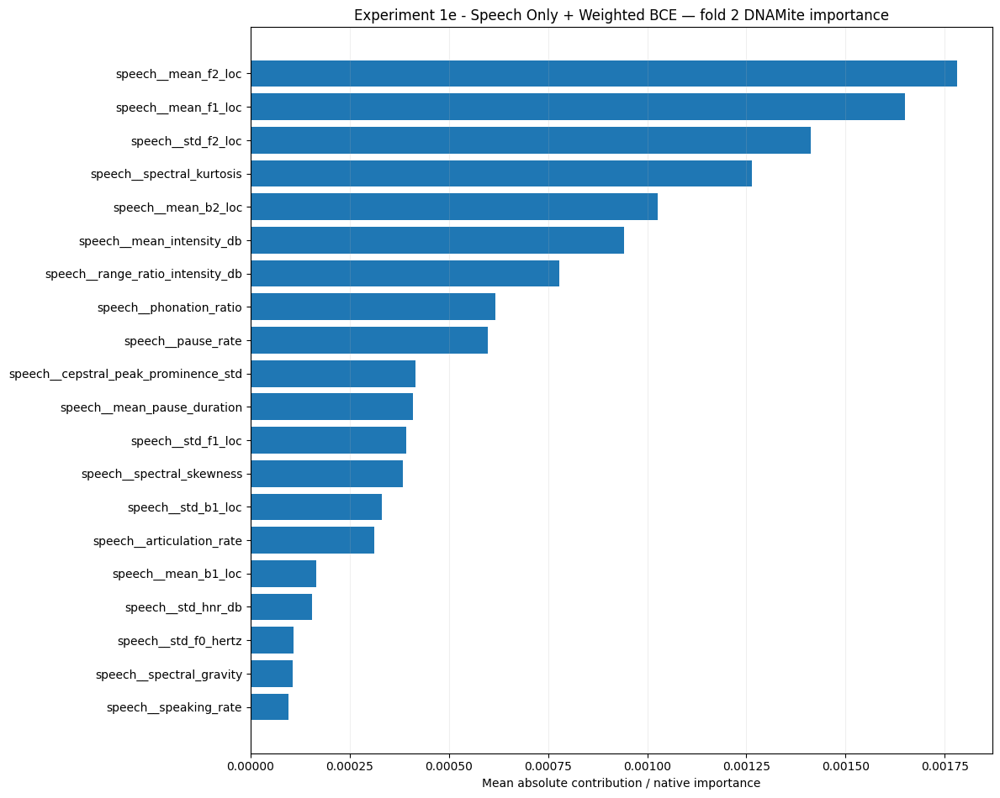

ROC_AUC              0.414474
PR_AUC               0.256499
AUPRC                0.256499
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208886
Log_Loss             0.608585
Threshold            0.295000
dtype: float64

Experiment 1e - Speech Only + Weighted BCE | Classification | Outer fold 3
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=58 | best=28 | best val_loss=0.666508 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=58 | best=28 | best val_loss=0.662431 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=

,positive_class_multiplier,mean_score,sd_score
0,1.25,0.378905,0.144132
1,1.50,0.373849,0.151536
2,1.00,0.369340,0.144174
3,2.00,0.327330,0.087404


Best imbalance parameters: {'positive_class_multiplier': 1.25} mean inner PR-AUC: 0.3789052907451782
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.25}
  Inner fold 1/3
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.25, final_pos_weight=2.8409
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.694842 | hit ceiling=False
  Inner fold 2/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.692293 | hit ceiling=False
  Inner fold 3/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.748769 | hit ceiling=False


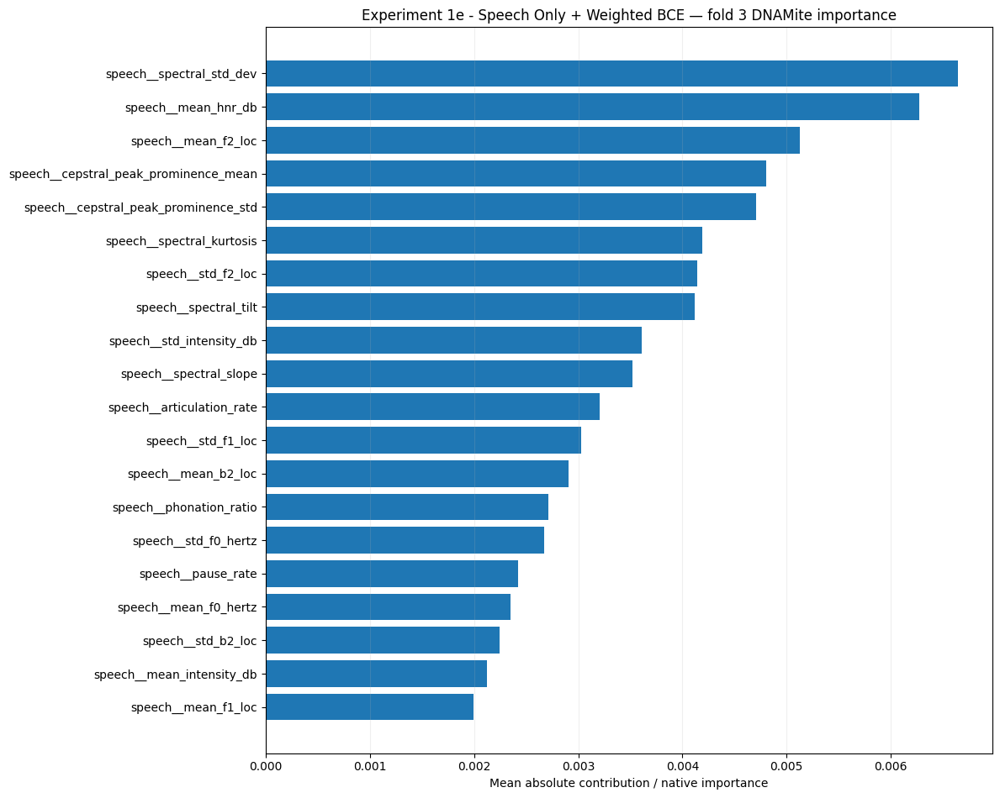

ROC_AUC              0.486842
PR_AUC               0.318432
AUPRC                0.318432
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208861
Log_Loss             0.608528
Threshold            0.305000
dtype: float64

Experiment 1e - Speech Only + Weighted BCE | Classification | Outer fold 4
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.695435 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=117 | best=87 | best val_loss=0.555061 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier

,positive_class_multiplier,mean_score,sd_score
0,1.25,0.362847,0.112724
1,1.00,0.345769,0.083005
2,2.00,0.340399,0.120654
3,1.50,0.336505,0.120745


Best imbalance parameters: {'positive_class_multiplier': 1.25} mean inner PR-AUC: 0.36284651054900924
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.25}
  Inner fold 1/3
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.25, final_pos_weight=2.8409
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.719650 | hit ceiling=False
  Inner fold 2/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.713750 | hit ceiling=False
  Inner fold 3/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.749626 | hit ceiling=False

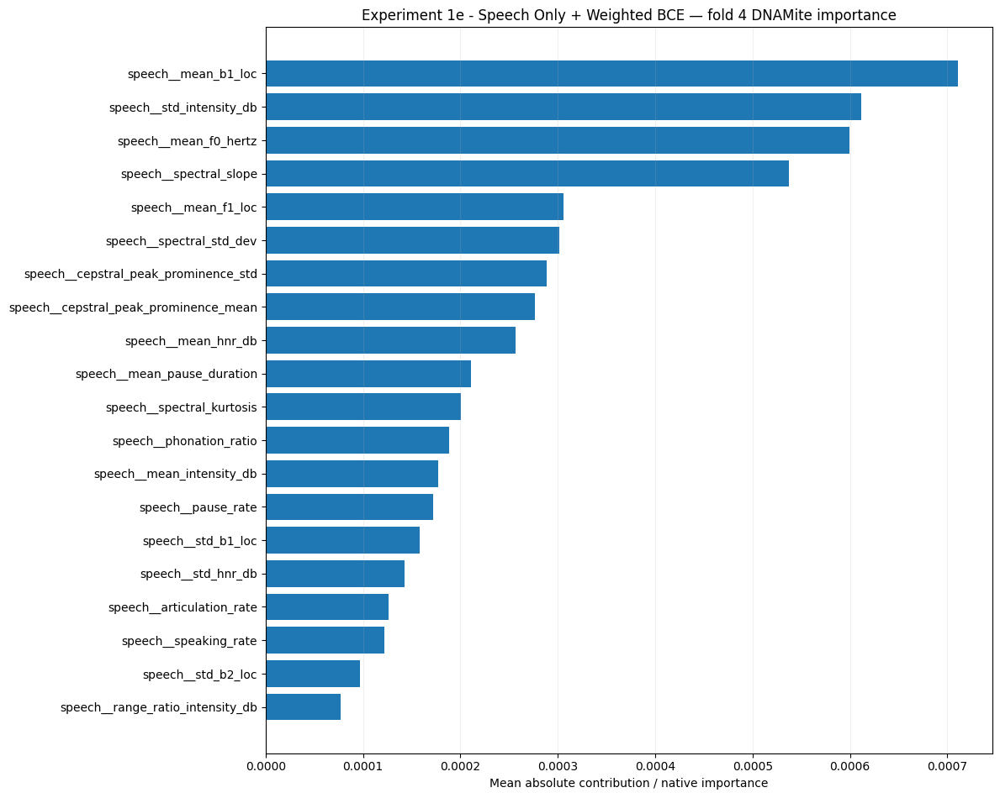

ROC_AUC              0.401316
PR_AUC               0.233554
AUPRC                0.233554
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208505
Log_Loss             0.607694
Threshold            0.050000
dtype: float64

Experiment 1e - Speech Only + Weighted BCE | Classification | Outer fold 5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.754894 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=55 | best=25 | best val_loss=0.660233 | hit ceiling=False
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=

,positive_class_multiplier,mean_score,sd_score
0,1.25,0.389884,0.143360
1,1.50,0.384920,0.132128
2,2.00,0.372812,0.123012
3,1.00,0.340715,0.134881


Best imbalance parameters: {'positive_class_multiplier': 1.25} mean inner PR-AUC: 0.3898844887038239
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.25}
  Inner fold 1/3
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.25, final_pos_weight=2.8409
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.861618 | hit ceiling=False
  Inner fold 2/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.712771 | hit ceiling=False
  Inner fold 3/3
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.691352 | hit ceiling=False


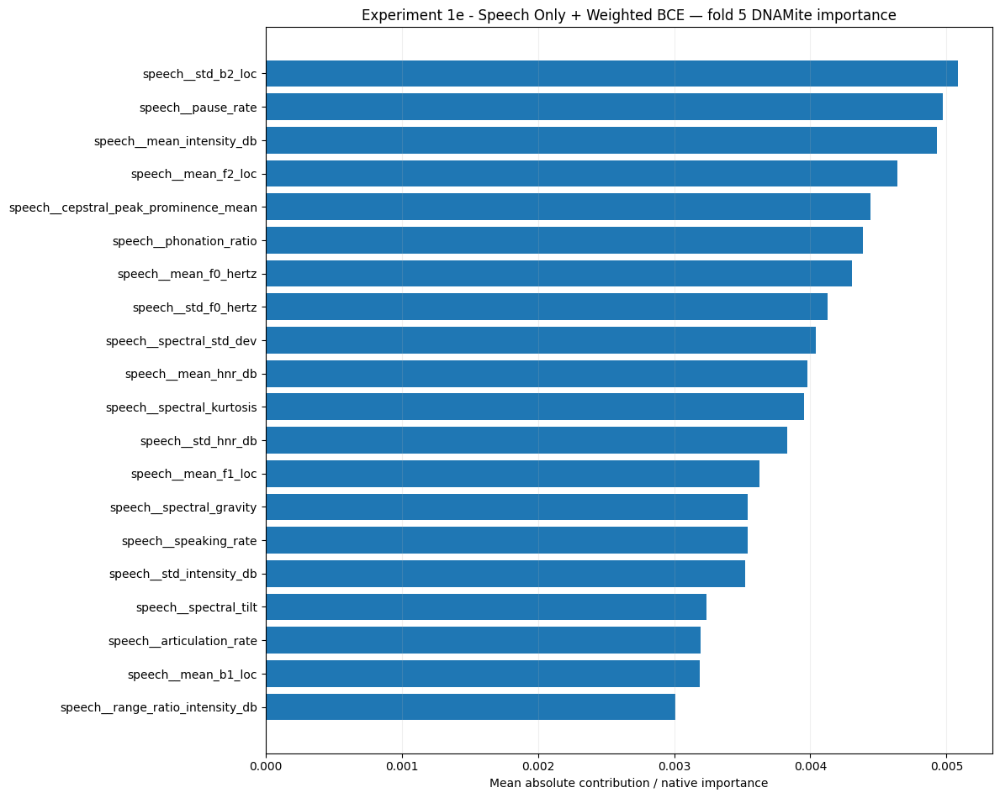

ROC_AUC              0.565789
PR_AUC               0.328826
AUPRC                0.328826
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208491
Log_Loss             0.607660
Threshold            0.295000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.505263,0.107642
PR_AUC,0.299369,0.052490
AUPRC,0.299369,0.052490
Accuracy,0.296296,0.000000
Balanced_Accuracy,0.500000,0.000000
Precision,0.296296,0.000000
Sensitivity,1.000000,0.000000
Specificity,0.000000,0.000000
F1,0.457143,0.000000
Brier_Score,0.208648,0.000206



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
1,2,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
2,3,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
3,4,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."
4,5,False,None,28,28,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 1e
# Speech Only + Weighted BCE
# Nested Cross-Validation
# ============================================================

EXPERIMENT_1E_NAME = (
    "Experiment 1e - Speech Only + Weighted BCE"
)


experiment_1e_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_1E_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        imbalance_strategy=(
            "weighted_bce"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 1e
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")
display(
    experiment_1e_binary_cv[
        "outer_results"
    ]
)

print("\nCV SUMMARY")
display(
    experiment_1e_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier,feature_selection_enabled,selection_reg_param,n_features_available,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0010,32,32,2,2.00,False,None,28,...,0.457143,0.208497,0.607674,0.050,0.628666,3007.238281,16.518066,22.0,0.000011,4.310448e-08
1,2,4,0.0010,32,16,2,1.25,False,None,28,...,0.457143,0.208886,0.608585,0.295,0.622246,2897.804688,16.518066,22.0,0.000012,4.893601e-08
2,3,8,0.0005,32,16,2,1.25,False,None,28,...,0.457143,0.208861,0.608528,0.305,0.605891,2986.414062,16.518066,22.0,0.000011,4.215398e-08
3,4,4,0.0005,16,32,2,1.25,False,None,28,...,0.457143,0.208505,0.607694,0.050,0.590212,3056.863281,16.518066,22.0,0.000012,4.800506e-08
4,5,32,0.0010,32,32,2,1.25,False,None,28,...,0.457143,0.208491,0.607660,0.295,0.666572,3080.308594,16.518066,22.0,0.000013,5.200088e-08



CV SUMMARY


,Mean,SD
ROC_AUC,0.505263,0.107642
PR_AUC,0.299369,0.052490
AUPRC,0.299369,0.052490
Accuracy,0.296296,0.000000
Balanced_Accuracy,0.500000,0.000000
Precision,0.296296,0.000000
Sensitivity,1.000000,0.000000
Specificity,0.000000,0.000000
F1,0.457143,0.000000
Brier_Score,0.208648,0.000206


In [ ]:
# ============================================================
# Experiment 1e
# Cross-Validation Performance
# ============================================================

experiment_1e_cv_metrics = (
    experiment_1e_binary_cv[
        "outer_results"
    ].copy()
)

experiment_1e_cv_summary = (
    experiment_1e_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")
display(
    experiment_1e_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")
display(
    experiment_1e_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier,feature_selection_enabled,selection_reg_param,n_features_available,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0010,32,32,2,2.00,False,None,28,...,0.457143,0.208497,0.607674,0.050,0.628666,3007.238281,16.518066,22.0,0.000011,4.310448e-08
1,2,4,0.0010,32,16,2,1.25,False,None,28,...,0.457143,0.208886,0.608585,0.295,0.622246,2897.804688,16.518066,22.0,0.000012,4.893601e-08
2,3,8,0.0005,32,16,2,1.25,False,None,28,...,0.457143,0.208861,0.608528,0.305,0.605891,2986.414062,16.518066,22.0,0.000011,4.215398e-08
3,4,4,0.0005,16,32,2,1.25,False,None,28,...,0.457143,0.208505,0.607694,0.050,0.590212,3056.863281,16.518066,22.0,0.000012,4.800506e-08
4,5,32,0.0010,32,32,2,1.25,False,None,28,...,0.457143,0.208491,0.607660,0.295,0.666572,3080.308594,16.518066,22.0,0.000013,5.200088e-08



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.505263,0.107642
PR_AUC,0.299369,0.052490
AUPRC,0.299369,0.052490
Accuracy,0.296296,0.000000
Balanced_Accuracy,0.500000,0.000000
Precision,0.296296,0.000000
Sensitivity,1.000000,0.000000
Specificity,0.000000,0.000000
F1,0.457143,0.000000
Brier_Score,0.208648,0.000206


In [ ]:
# ============================================================
# Experiment 1e
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_1e_parameters = (
    experiment_1e_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "positive_class_multiplier",
        ]
    ]
    .copy()
)

display(
    experiment_1e_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier
0,1,16,0.0010,32,32,2,2.00
1,2,4,0.0010,32,16,2,1.25
2,3,8,0.0005,32,16,2,1.25
3,4,4,0.0005,16,32,2,1.25
4,5,32,0.0010,32,32,2,1.25



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1e_-_Speech_Only_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


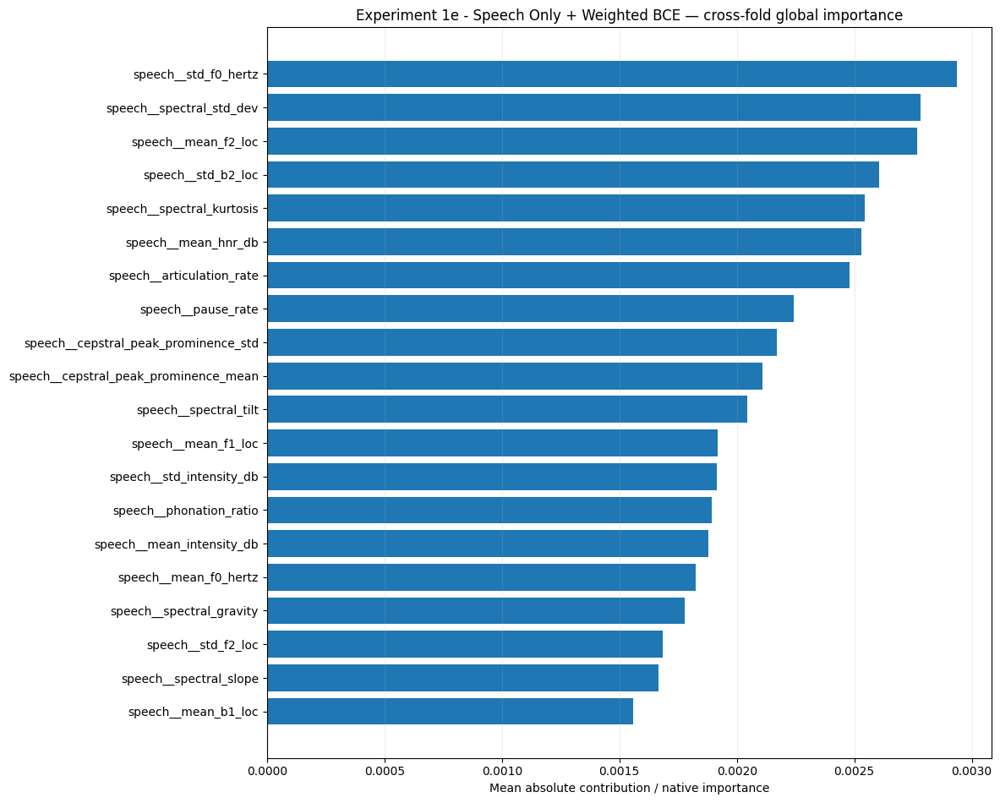

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1e_-_Speech_Only_Weighted_BCE/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 1e
# Cross-Fold Interpretability
# Speech Only + Weighted BCE
# ============================================================

experiment_1e_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_1E_NAME
        ),
        top_k=10,
    )
)

experiment_1e_interpretability

In [ ]:
# ============================================================
# Experiment 1e
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_1e_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_1E_NAME)
)


development_rows = []

for path in sorted(
    experiment_1e_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        development_rows.append(
            json.load(file)
        )


experiment_1e_development_df = (
    pd.DataFrame(
        development_rows
    )
)

display(
    experiment_1e_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 1e - Speech Only + Weighted BCE,classification,1,108,76.422989,0.001568,0.000006,3007.320312,16.518066,22.0
1,DNAMite Optimized,Experiment 1e - Speech Only + Weighted BCE,classification,2,108,118.858118,0.003037,0.000012,2897.921875,16.518066,22.0
2,DNAMite Optimized,Experiment 1e - Speech Only + Weighted BCE,classification,3,108,86.441587,0.001903,0.000007,2986.449219,16.518066,22.0
3,DNAMite Optimized,Experiment 1e - Speech Only + Weighted BCE,classification,4,108,82.945933,0.001797,0.000007,3056.980469,16.518066,22.0
4,DNAMite Optimized,Experiment 1e - Speech Only + Weighted BCE,classification,5,108,90.951423,0.002021,0.000008,3080.320312,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 1e
# Speech Only + Weighted BCE
# Final Model
# ============================================================

EXPERIMENT_1E_NAME = (
    "Experiment 1e - Speech Only + Weighted BCE"
)

experiment_1e_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        experiment_name=(
            EXPERIMENT_1E_NAME
        ),
        imbalance_strategy=(
            "weighted_bce"
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

[codecarbon WARNING @ 17:12:29] Multiple instances of codecarbon are allowed to run at the same time.


Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.674950 | hit ceiling=False
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.694409 | hit ceiling=False
Weighted BCE | negative=64, positive=26, automatic_pos_weight=2.4615, multiplier=1.00, final_pos_weight=2.4615
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.678697 | hit ceiling=False
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.25, final_pos_weight=2.9167
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=50 | best=20 | best val_loss=0.730224 | hit ceiling=False
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.

,positive_class_multiplier,mean_score,sd_score
0,2.00,0.385630,0.147105
1,1.50,0.370796,0.124943
2,1.25,0.359749,0.115083
3,1.00,0.341494,0.105685


Best imbalance parameters: {'positive_class_multiplier': 2.0} mean inner PR-AUC: 0.3856302549109725
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 2.0}
  Inner fold 1/3
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=2.00, final_pos_weight=4.6667
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=39 | best=9 | best val_loss=0.871851 | hit ceiling=False
  Inner fold 2/3
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=2.00, final_pos_weight=4.6667
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.939053 | hit ceiling=False
  Inner fold 3/3
Weighted BCE | negative=64, positive=26, automatic_pos_weight=2.4615, multiplier=2.00, final_pos_weight=4.9231
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=1.010568 | hit ceiling=False
DNAMi

In [ ]:
# ============================================================
# Experiment 1e
# Final Test Results
# ============================================================

display(
    pd.Series(
        experiment_1e_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.464286
PR_AUC,0.447884
AUPRC,0.447884
Accuracy,0.521739
Balanced_Accuracy,0.475446
Precision,0.277778
Sensitivity,0.357143
Specificity,0.593750
F1,0.312500
Brier_Score,0.211451


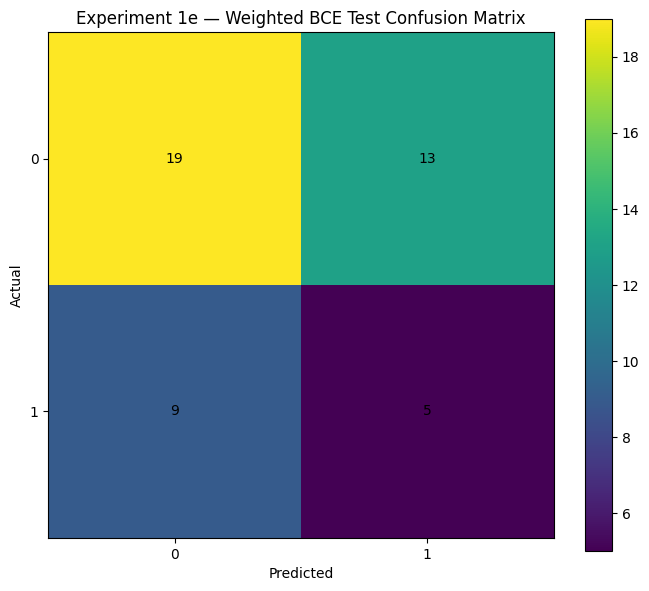

array([[19, 13],
       [ 9,  5]])

In [ ]:
plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_1e_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 1e — "
        "Weighted BCE Test Confusion Matrix"
    ),
)

### Experiment 1f Regression with LDS

In [ ]:
# test_parameters = {
#     "max_bins": 16,
#     "learning_rate": 1e-3,
#     "n_embed": 32,
#     "n_hidden": 32,
#     "n_layers": 2,
# }

# test_lds_model = create_dnamite_model(
#     task="regression",
#     parameters=test_parameters,
#     imbalance_strategy="lds",
# )

# print(type(test_lds_model))

Using severity-stratified master regression folds.

Experiment 1f - Speech Only + LDS | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.660, 6.282)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=43 | best=13 | best val_loss=0.840846 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.632, 2007.659)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=42 | best=12 | best val_loss=1.051992 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.695, 6.210)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.540294 | hit ceiling=False
LDS | sigma=0.5, method=inverse, weight range=(0.393, 35.637)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.842008 | hit ceiling=False
LDS | sigma=0.5, method=inverse, weight range=(0.369, 3719012.383)

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,0.5,sqrt_inverse,4.917883,0.230391
1,0.5,inverse,4.926461,0.203019
2,1.0,inverse,4.945576,0.250244
3,3.0,sqrt_inverse,4.974382,0.213807
4,2.0,sqrt_inverse,4.974404,0.213337
5,4.0,sqrt_inverse,4.974407,0.213203
6,1.0,sqrt_inverse,4.976326,0.204536
7,4.0,inverse,4.976347,0.223316
8,3.0,inverse,4.976414,0.224539
9,2.0,inverse,4.976477,0.223757


Best imbalance parameters: {'lds_sigma': 0.5, 'lds_reweight_method': 'sqrt_inverse'} mean inner MAE: 4.917883349267858
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 0.5, 'lds_reweight_method': 'sqrt_inverse'}
  Inner fold 1/3
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.660, 6.282)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=43 | best=13 | best val_loss=0.823266 | hit ceiling=False
  Inner fold 2/3
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.632, 2007.659)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=1.065673 | hit ceiling=False
  Inner fold 3/3
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.695, 6.210)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.536347 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 

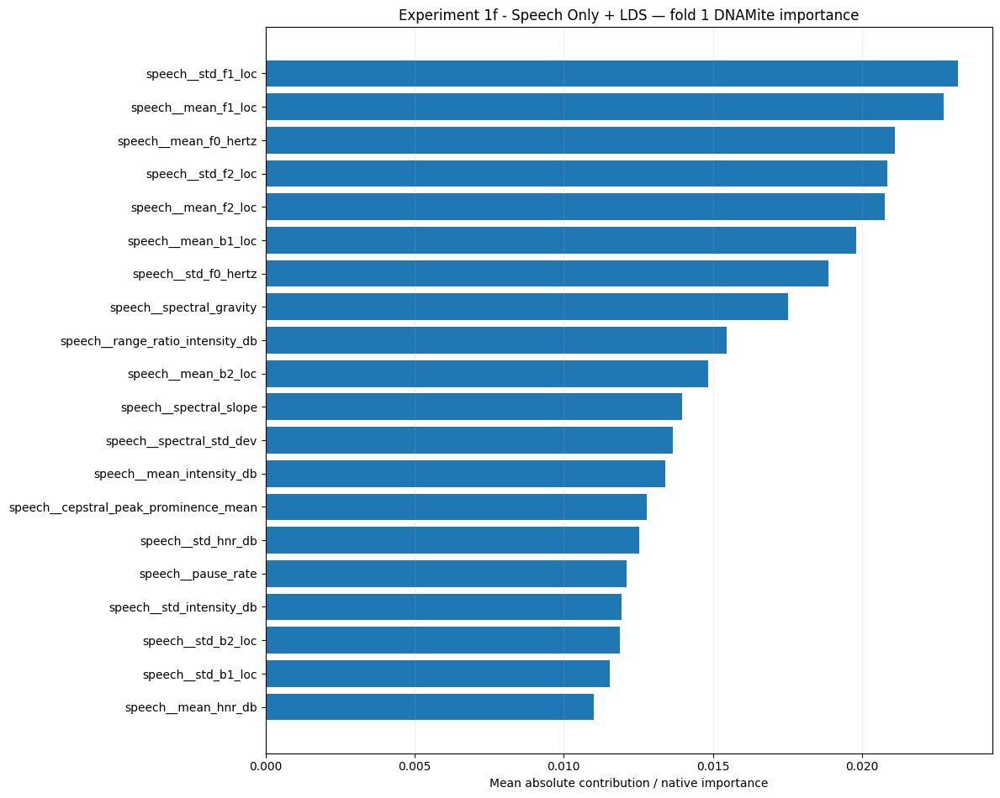

MAE               4.362392
RMSE              5.209113
R2                0.021405
Spearman_Rho      0.419475
Spearman_P        0.029398
Pearson_R         0.316145
Pearson_P         0.108160
Exact_Accuracy    0.000000
Within_1          0.222222
Within_2          0.370370
Within_3          0.481481
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 1f - Speech Only + LDS | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.691, 2093.983)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.808213 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.717, 2005.506)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.878053 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.7

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,1.0,inverse,4.515446,0.088596
1,2.0,inverse,4.522368,0.097782
2,1.0,sqrt_inverse,4.522957,0.093674
3,4.0,inverse,4.524657,0.098160
4,3.0,inverse,4.525183,0.098563
5,2.0,sqrt_inverse,4.525541,0.096820
6,3.0,sqrt_inverse,4.526963,0.097484
7,4.0,sqrt_inverse,4.527866,0.097784
8,0.5,sqrt_inverse,4.539088,0.117260
9,0.5,inverse,4.570981,0.165803


Best imbalance parameters: {'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.515445560398766
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
LDS | sigma=1.0, method=inverse, weight range=(0.580, 3601592.090)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.826018 | hit ceiling=False
  Inner fold 2/3
LDS | sigma=1.0, method=inverse, weight range=(0.514, 12750.590)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.860221 | hit ceiling=False
  Inner fold 3/3
LDS | sigma=1.0, method=inverse, weight range=(0.481, 12456.246)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=63 | best=33 | best val_loss=1.021424 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers'

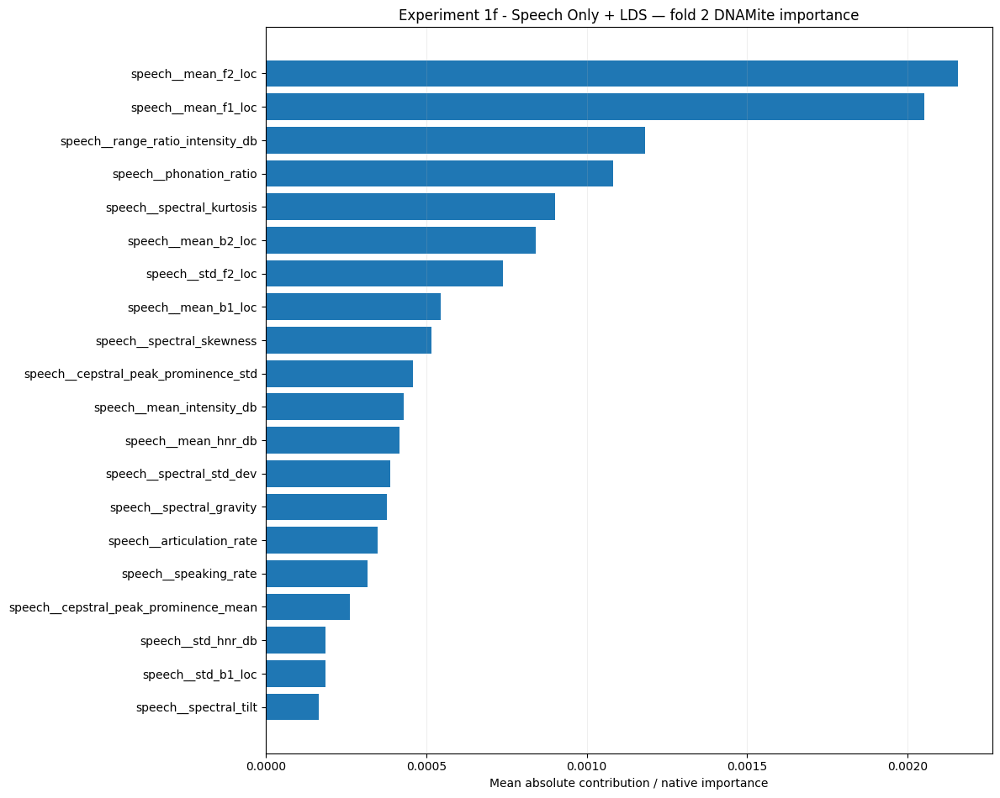

MAE               4.960419
RMSE              6.251998
R2               -0.001644
Spearman_Rho      0.085891
Spearman_P        0.670129
Pearson_R         0.254240
Pearson_P         0.200648
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.407407
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 1f - Speech Only + LDS | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.661, 5.944)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=62 | best=32 | best val_loss=0.729456 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.703, 6.025)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=50 | best=20 | best val_loss=0.768679 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.672, 20

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,2.0,sqrt_inverse,4.577575,0.230648
1,3.0,sqrt_inverse,4.578064,0.230191
2,4.0,sqrt_inverse,4.579868,0.229437
3,2.0,inverse,4.581692,0.241286
4,3.0,inverse,4.582549,0.237886
5,4.0,inverse,4.583714,0.239551
6,1.0,inverse,4.590923,0.215275
7,1.0,sqrt_inverse,4.591010,0.218886
8,0.5,sqrt_inverse,4.607361,0.243486
9,0.5,inverse,4.636419,0.266643


Best imbalance parameters: {'lds_sigma': 2.0, 'lds_reweight_method': 'sqrt_inverse'} mean inner MAE: 4.577575296312062
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 2.0, 'lds_reweight_method': 'sqrt_inverse'}
  Inner fold 1/3
LDS | sigma=2.0, method=sqrt_inverse, weight range=(0.771, 3.852)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=176 | best=146 | best val_loss=0.744590 | hit ceiling=False
  Inner fold 2/3
LDS | sigma=2.0, method=sqrt_inverse, weight range=(0.766, 3.959)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.836646 | hit ceiling=False
  Inner fold 3/3
LDS | sigma=2.0, method=sqrt_inverse, weight range=(0.798, 7.149)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.679124 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 3

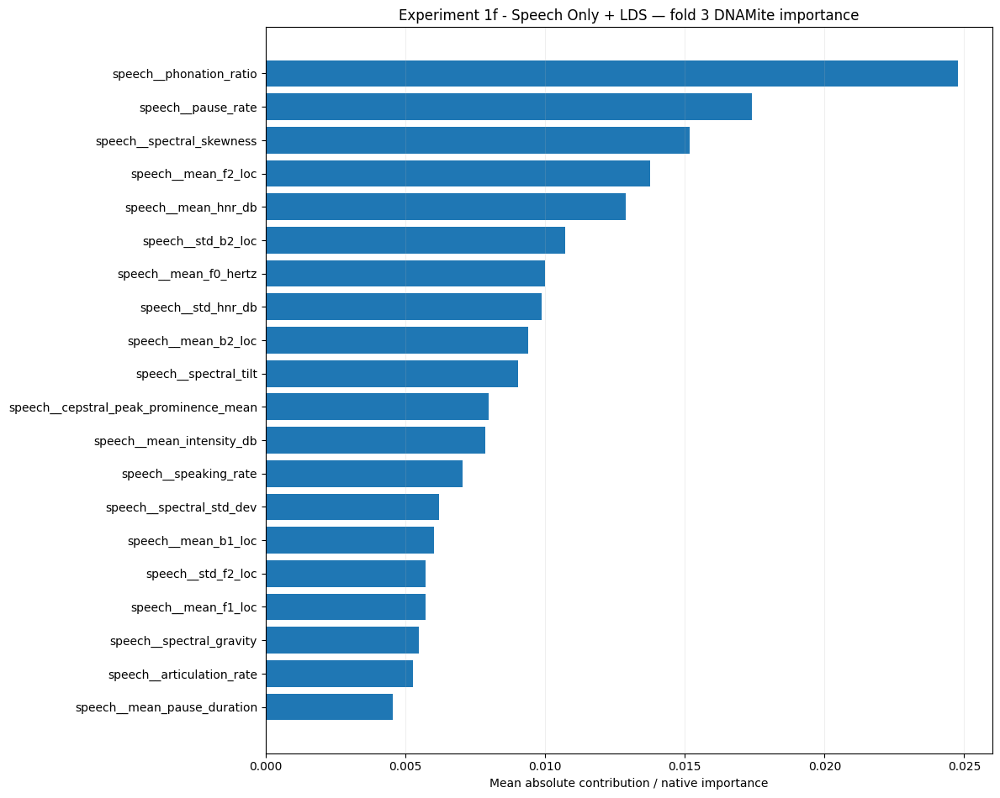

MAE               4.686367
RMSE              5.724658
R2               -0.041710
Spearman_Rho     -0.248010
Spearman_P        0.212282
Pearson_R        -0.228213
Pearson_P         0.252248
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.407407
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 1f - Speech Only + LDS | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.603, 5.926)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=45 | best=15 | best val_loss=0.768206 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.645, 6.025)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.808780 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.754, 2044.6

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,4.0,sqrt_inverse,4.636795,0.661054
1,4.0,inverse,4.637118,0.667585
2,2.0,sqrt_inverse,4.638110,0.660812
3,3.0,sqrt_inverse,4.638274,0.657924
4,3.0,inverse,4.639042,0.671298
5,2.0,inverse,4.642630,0.672784
6,1.0,sqrt_inverse,4.649318,0.653807
7,0.5,sqrt_inverse,4.655061,0.658409
8,1.0,inverse,4.660783,0.659656
9,0.5,inverse,4.718678,0.634056


Best imbalance parameters: {'lds_sigma': 4.0, 'lds_reweight_method': 'sqrt_inverse'} mean inner MAE: 4.63679464922996
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 4.0, 'lds_reweight_method': 'sqrt_inverse'}
  Inner fold 1/3
LDS | sigma=4.0, method=sqrt_inverse, weight range=(0.831, 2.707)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.805887 | hit ceiling=False
  Inner fold 2/3
LDS | sigma=4.0, method=sqrt_inverse, weight range=(0.834, 2.926)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.792594 | hit ceiling=False
  Inner fold 3/3
LDS | sigma=4.0, method=sqrt_inverse, weight range=(0.833, 3.439)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.607132 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 

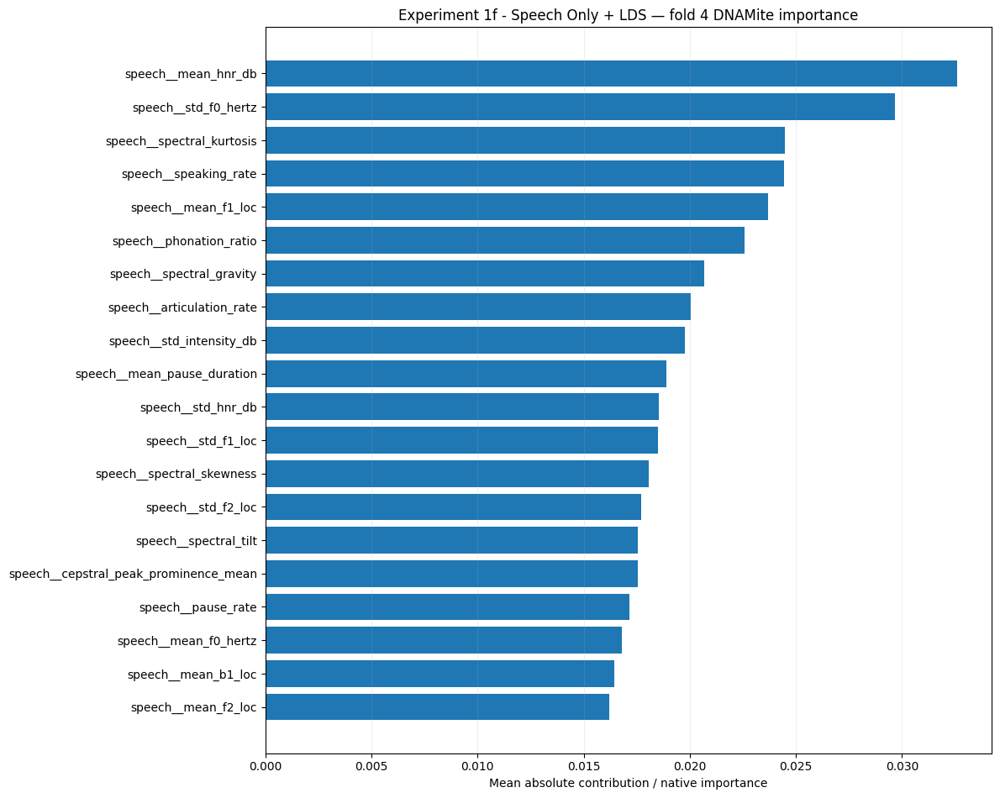

MAE               4.600371
RMSE              5.263976
R2               -0.064624
Spearman_Rho     -0.045650
Spearman_P        0.821126
Pearson_R        -0.073940
Pearson_P         0.713972
Exact_Accuracy    0.074074
Within_1          0.074074
Within_2          0.185185
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 1f - Speech Only + LDS | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.676, 1996.945)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.733193 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.609, 6.091)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=71 | best=41 | best val_loss=0.757932 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.745, 5

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,1.0,sqrt_inverse,4.530726,0.240209
1,1.0,inverse,4.538972,0.220585
2,0.5,sqrt_inverse,4.578759,0.173299
3,3.0,inverse,4.590002,0.152405
4,4.0,inverse,4.591637,0.154016
5,2.0,inverse,4.591995,0.152743
6,4.0,sqrt_inverse,4.593262,0.147885
7,3.0,sqrt_inverse,4.595205,0.151750
8,2.0,sqrt_inverse,4.596230,0.151598
9,0.5,inverse,4.650363,0.104688


Best imbalance parameters: {'lds_sigma': 1.0, 'lds_reweight_method': 'sqrt_inverse'} mean inner MAE: 4.530726180415085
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 1.0, 'lds_reweight_method': 'sqrt_inverse'}
  Inner fold 1/3
LDS | sigma=1.0, method=sqrt_inverse, weight range=(0.733, 116.862)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=54 | best=24 | best val_loss=0.721471 | hit ceiling=False
  Inner fold 2/3
LDS | sigma=1.0, method=sqrt_inverse, weight range=(0.727, 3.749)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.803058 | hit ceiling=False
  Inner fold 3/3
LDS | sigma=1.0, method=sqrt_inverse, weight range=(0.745, 3.779)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=65 | best=35 | best val_loss=0.353563 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 3

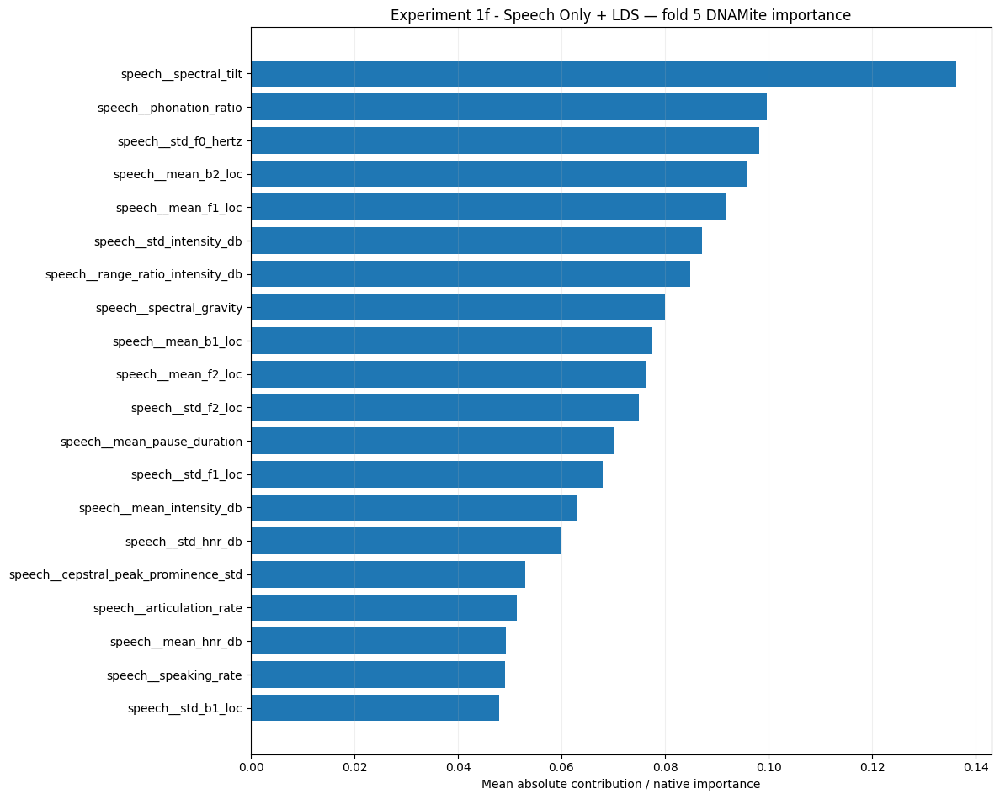

MAE               4.972302
RMSE              6.445865
R2               -0.313160
Spearman_Rho     -0.008888
Spearman_P        0.964907
Pearson_R        -0.125266
Pearson_P         0.533572
Exact_Accuracy    0.074074
Within_1          0.222222
Within_2          0.296296
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.716370,0.257253
RMSE,5.779122,0.561562
R2,-0.079947,0.134619
Spearman_Rho,0.040564,0.244326
Pearson_R,0.028593,0.241732
Exact_Accuracy,0.029630,0.040572
Within_1,0.177778,0.060858
Within_2,0.288889,0.066254
Within_3,0.422222,0.042229



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 1f
# Speech Only + LDS
# Nested Cross-Validation
# ============================================================

EXPERIMENT_1F_NAME = (
    "Experiment 1f - Speech Only + LDS"
)


experiment_1f_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_1F_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        imbalance_strategy=(
            "lds"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 1f
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_1f_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_1f_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method,MAE,RMSE,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,32,0.0010,32,16,2,0.5,sqrt_inverse,4.362392,5.209113,...,0.481481,4.334362,5.267151,-0.000523,0.704976,3124.460938,16.518066,22.0,0.000014,5.346960e-08
1,2,4,0.0010,32,16,2,1.0,inverse,4.960419,6.251998,...,0.407407,4.996914,6.247201,-0.000108,0.605776,3124.558594,16.518066,22.0,0.000011,4.141953e-08
2,3,16,0.0010,16,16,2,2.0,sqrt_inverse,4.686367,5.724658,...,0.407407,4.607339,5.614449,-0.001987,0.754324,3058.226562,16.518066,22.0,0.000017,6.545770e-08
3,4,32,0.0010,32,32,2,4.0,sqrt_inverse,4.600371,5.263976,...,0.370370,4.469822,5.104431,-0.001067,0.762161,3058.320312,16.518066,22.0,0.000017,6.609307e-08
4,5,16,0.0005,32,16,2,1.0,sqrt_inverse,4.972302,6.445865,...,0.444444,4.728052,5.625067,-0.000024,1.181038,3058.402344,16.518066,22.0,0.000032,1.276289e-07



CV SUMMARY


,Mean,SD
MAE,4.716370,0.257253
RMSE,5.779122,0.561562
R2,-0.079947,0.134619
Spearman_Rho,0.040564,0.244326
Pearson_R,0.028593,0.241732
Exact_Accuracy,0.029630,0.040572
Within_1,0.177778,0.060858
Within_2,0.288889,0.066254
Within_3,0.422222,0.042229


In [ ]:
# ============================================================
# Experiment 1f
# Cross-Validation Performance
# ============================================================

experiment_1f_cv_metrics = (
    experiment_1f_regression_cv[
        "outer_results"
    ].copy()
)

experiment_1f_cv_summary = (
    experiment_1f_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_1f_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_1f_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method,MAE,RMSE,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,32,0.0010,32,16,2,0.5,sqrt_inverse,4.362392,5.209113,...,0.481481,4.334362,5.267151,-0.000523,0.704976,3124.460938,16.518066,22.0,0.000014,5.346960e-08
1,2,4,0.0010,32,16,2,1.0,inverse,4.960419,6.251998,...,0.407407,4.996914,6.247201,-0.000108,0.605776,3124.558594,16.518066,22.0,0.000011,4.141953e-08
2,3,16,0.0010,16,16,2,2.0,sqrt_inverse,4.686367,5.724658,...,0.407407,4.607339,5.614449,-0.001987,0.754324,3058.226562,16.518066,22.0,0.000017,6.545770e-08
3,4,32,0.0010,32,32,2,4.0,sqrt_inverse,4.600371,5.263976,...,0.370370,4.469822,5.104431,-0.001067,0.762161,3058.320312,16.518066,22.0,0.000017,6.609307e-08
4,5,16,0.0005,32,16,2,1.0,sqrt_inverse,4.972302,6.445865,...,0.444444,4.728052,5.625067,-0.000024,1.181038,3058.402344,16.518066,22.0,0.000032,1.276289e-07



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.716370,0.257253
RMSE,5.779122,0.561562
R2,-0.079947,0.134619
Spearman_Rho,0.040564,0.244326
Pearson_R,0.028593,0.241732
Exact_Accuracy,0.029630,0.040572
Within_1,0.177778,0.060858
Within_2,0.288889,0.066254
Within_3,0.422222,0.042229


In [ ]:
# ============================================================
# Experiment 1f
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_1f_parameters = (
    experiment_1f_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "lds_sigma",
            "lds_reweight_method",
        ]
    ]
    .copy()
)

display(
    experiment_1f_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method
0,1,32,0.0010,32,16,2,0.5,sqrt_inverse
1,2,4,0.0010,32,16,2,1.0,inverse
2,3,16,0.0010,16,16,2,2.0,sqrt_inverse
3,4,32,0.0010,32,32,2,4.0,sqrt_inverse
4,5,16,0.0005,32,16,2,1.0,sqrt_inverse



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1f_-_Speech_Only_LDS
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


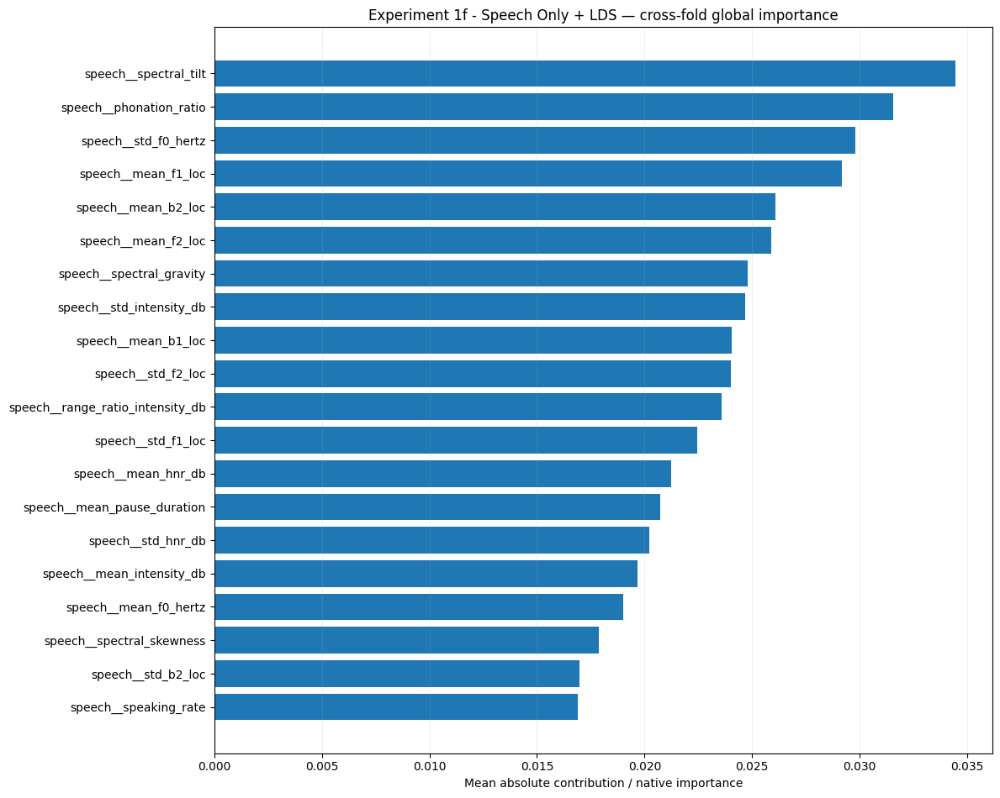

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_1f_-_Speech_Only_LDS/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 1f
# Cross-Fold Interpretability
# Speech Only + LDS
# ============================================================

experiment_1f_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_1F_NAME
        ),
        top_k=10,
    )
)

experiment_1f_interpretability

In [ ]:
# ============================================================
# Experiment 1f
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_1f_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_1F_NAME)
)


experiment_1f_development_rows = []

for path in sorted(
    experiment_1f_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_1f_development_rows.append(
            json.load(file)
        )


experiment_1f_development_df = (
    pd.DataFrame(
        experiment_1f_development_rows
    )
)

display(
    experiment_1f_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 1f - Speech Only + LDS,regression,1,126,81.860746,0.001571,0.000006,3124.542969,16.518066,22.0
1,DNAMite Optimized,Experiment 1f - Speech Only + LDS,regression,2,126,98.017333,0.002138,0.000008,3124.582031,16.518066,22.0
2,DNAMite Optimized,Experiment 1f - Speech Only + LDS,regression,3,126,109.585334,0.002576,0.000010,3058.332031,16.518066,22.0
3,DNAMite Optimized,Experiment 1f - Speech Only + LDS,regression,4,126,89.715493,0.001886,0.000007,3058.367188,16.518066,22.0
4,DNAMite Optimized,Experiment 1f - Speech Only + LDS,regression,5,126,102.868813,0.002334,0.000009,3058.402344,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 1f
# Development Cost Summary
# ============================================================

experiment_1f_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_1f_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_1f_development_df[
                    experiment_1f_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_1f_development_df[
                    experiment_1f_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_1f_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_1f_development_summary[
            "Mean"
        ],
        experiment_1f_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_1f_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,126.000000,0.000000,126.000000 ± 0.000000
development_seconds,96.409544,10.890207,96.409544 ± 10.890207
development_energy_kwh,0.002101,0.000390,0.002101 ± 0.000390
development_co2_kg,0.000008,0.000002,0.000008 ± 0.000002


In [ ]:
# ============================================================
# Experiment 1f
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_1f_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_1f_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_1f_regression_cv[
                    "outer_results"
                ][
                    experiment_1f_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_1f_regression_cv[
                    "outer_results"
                ][
                    experiment_1f_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_1f_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_1f_training_summary[
            "Mean"
        ],
        experiment_1f_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_1f_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,8.016550e-01,2.210471e-01,0.80165498 ± 0.22104707
peak_ram_mb,3.084794e+03,3.625567e+01,3084.79375000 ± 36.25566587
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,1.798511e-05,8.465284e-06,0.00001799 ± 0.00000847
training_co2_kg,7.081377e-08,3.333083e-08,0.00000007 ± 0.00000003


In [ ]:
# ============================================================
# Experiment 1f
# Speech Only + LDS
# Final Model
# ============================================================

EXPERIMENT_1F_NAME = (
    "Experiment 1f - Speech Only + LDS"
)

experiment_1f_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        imbalance_strategy=(
            "lds"
        ),
        experiment_name=(
            EXPERIMENT_1F_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.681, 2277.947)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=109 | best=79 | best val_loss=1.637628 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.708, 6.654)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.489559 | hit ceiling=False
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.645, 6.751)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=43 | best=13 | best val_loss=1.473427 | hit ceiling=False
LDS | sigma=0.5, method=inverse, weight range=(0.417, 4663662.836)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=101 | best=71 | best val_loss=1.649896 | hit ceiling=False
LDS | sigma=0.5, method=inverse, weight range=(0.450, 39.747)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.522217 | hit c

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,1.0,inverse,4.793775,0.181332
1,0.5,sqrt_inverse,4.809619,0.213282
2,0.5,inverse,4.827358,0.232446
3,1.0,sqrt_inverse,4.840511,0.257453
4,3.0,inverse,4.865573,0.284525
5,3.0,sqrt_inverse,4.866154,0.296775
6,4.0,sqrt_inverse,4.866632,0.298822
7,4.0,inverse,4.869205,0.296468
8,2.0,sqrt_inverse,4.871217,0.303744
9,2.0,inverse,4.876116,0.296717


Best imbalance parameters: {'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.793774852812171
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
LDS | sigma=1.0, method=inverse, weight range=(0.486, 10713.196)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=81 | best=51 | best val_loss=1.642003 | hit ceiling=False
  Inner fold 2/3
LDS | sigma=1.0, method=inverse, weight range=(0.495, 15.446)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=55 | best=25 | best val_loss=0.418816 | hit ceiling=False
  Inner fold 3/3
LDS | sigma=1.0, method=inverse, weight range=(0.476, 15.575)
DNAMite active features | 28 / 28
DNAMite epochs | split=1 | ran=42 | best=12 | best val_loss=1.461182 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'ld

In [ ]:
# ============================================================
# Experiment 1f
# Final Test Results
# ============================================================

display(
    pd.Series(
        experiment_1f_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,5.438550
RMSE,6.448435
R2,-0.011812
Spearman_Rho,-0.048403
Spearman_P,0.749393
Pearson_R,-0.029002
Pearson_P,0.848267
Exact_Accuracy,0.065217
Within_1,0.108696
Within_2,0.173913


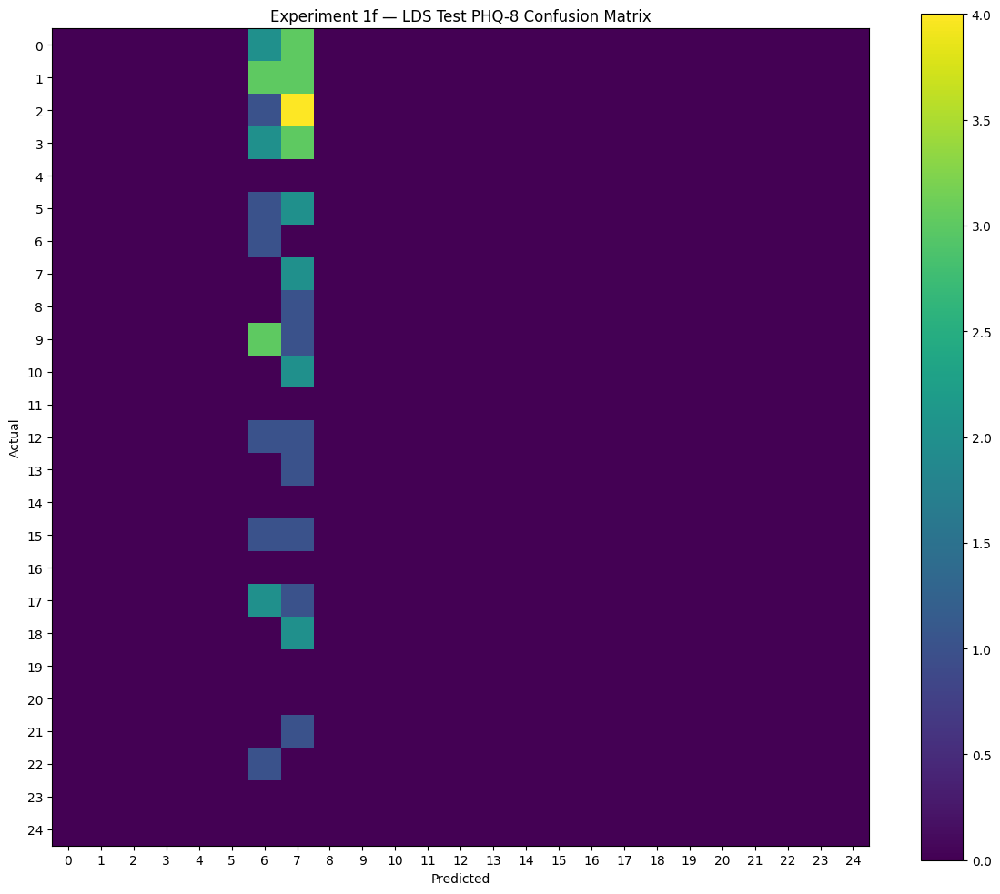

array([[0, 0, 0, 0, 0, 0, 2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 2, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 3, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 1f
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_1f_regression_final[
                "test_rounded_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 1f — "
        "LDS Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

## EXPERIMENT 2 — SPEECH + TF-IDF UNIGRAMS

### Experiment 2a binary nested CV


Experiment 2a - Speech + TF-IDF Unigrams | Classification | Outer fold 1
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.580732 | hit ceiling=False
  Inner fold 2/3
Selected 13 TF-IDF features for classification / unigram using C=5.0
DNAMite active features | 41 / 41
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.528680 | hit ceiling=False
  Inner fold 3/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=32 | best=2 | best val_loss=0.641562 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2

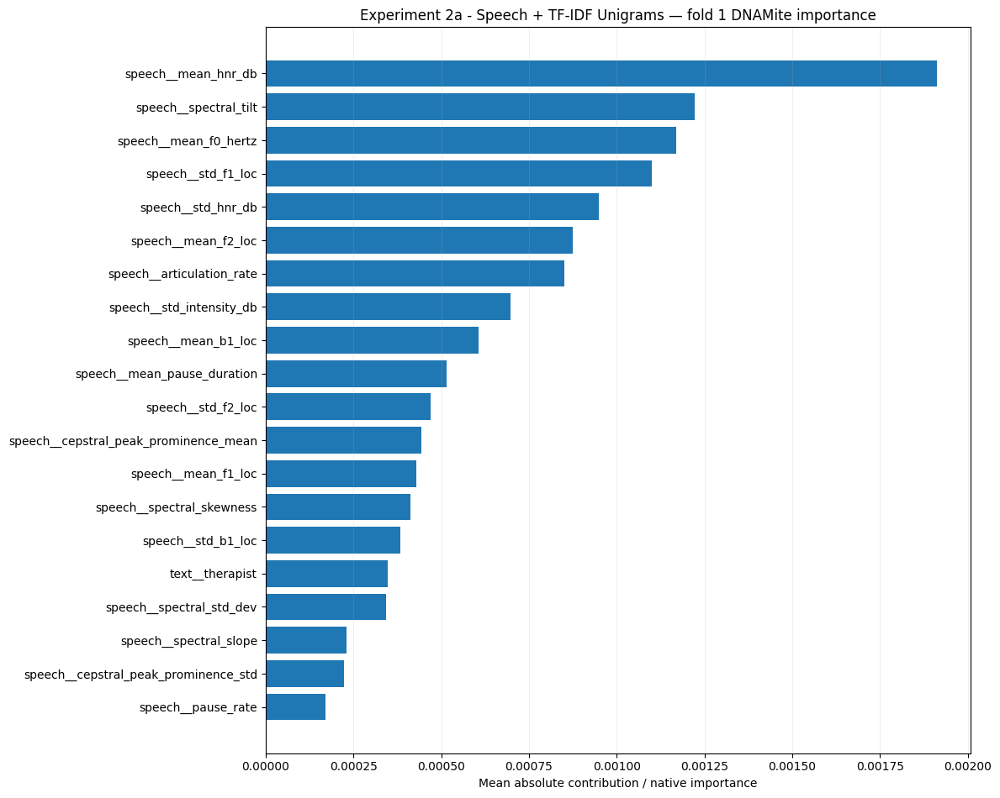

ROC_AUC              0.914474
PR_AUC               0.826254
AUPRC                0.826254
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208544
Log_Loss             0.607790
Threshold            0.345000
dtype: float64

Experiment 2a - Speech + TF-IDF Unigrams | Classification | Outer fold 2
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.580007 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=500 | best=499 | best val_loss=0.144173 | hit ceiling=True
  Inner fold 3/3
Selecte

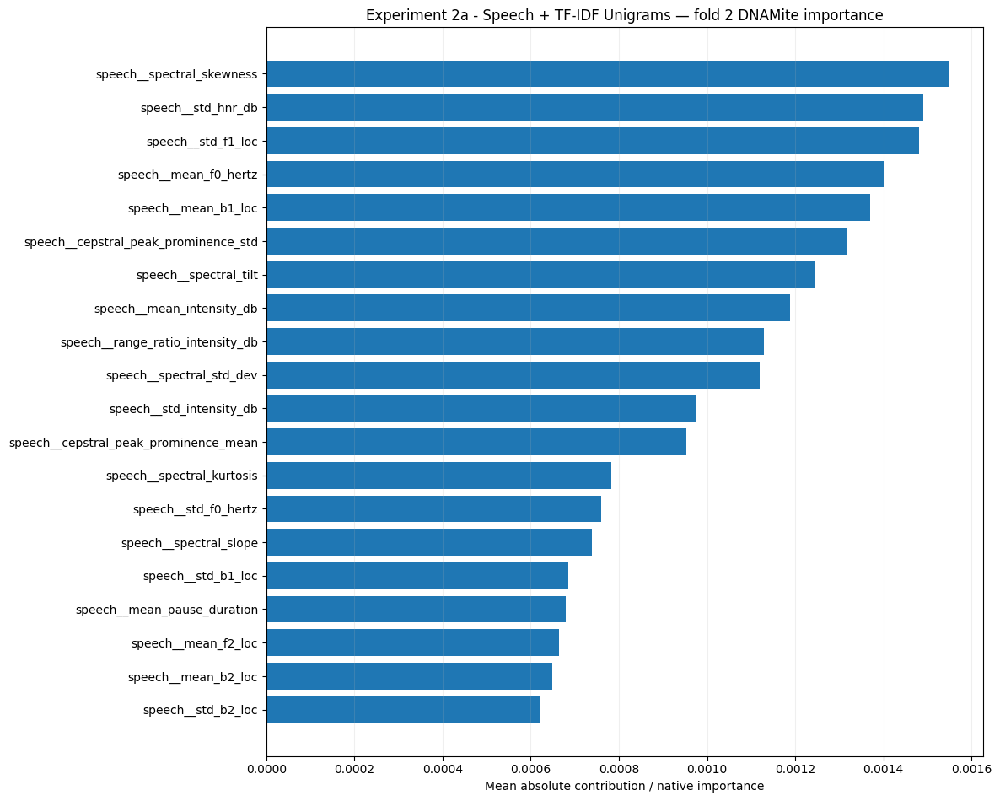

ROC_AUC              0.375000
PR_AUC               0.237945
AUPRC                0.237945
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208589
Log_Loss             0.607893
Threshold            0.345000
dtype: float64

Experiment 2a - Speech + TF-IDF Unigrams | Classification | Outer fold 3
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram using C=5.0
DNAMite active features | 39 / 39
DNAMite epochs | split=1 | ran=276 | best=246 | best val_loss=0.459869 | hit ceiling=False
  Inner fold 2/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
DNAMite active features | 42 / 42
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.637338 | hit ceiling=False
  Inner fold 3/3
Sele

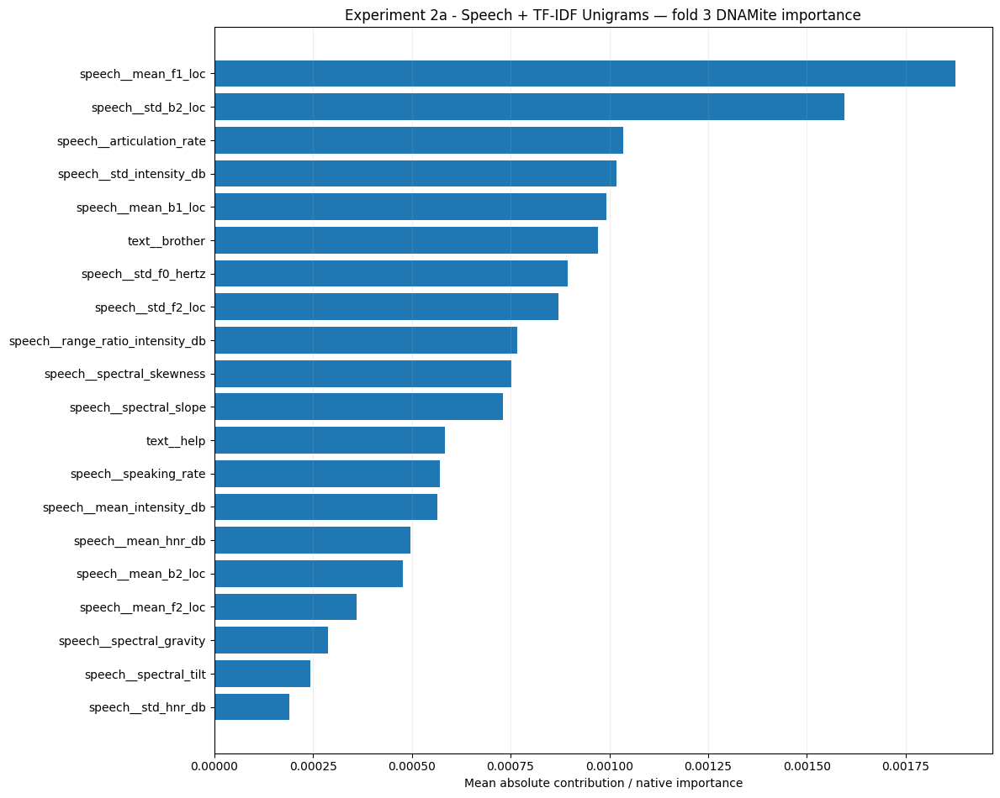

ROC_AUC              0.335526
PR_AUC               0.217209
AUPRC                0.217209
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208517
Log_Loss             0.607723
Threshold            0.290000
dtype: float64

Experiment 2a - Speech + TF-IDF Unigrams | Classification | Outer fold 4
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=33 | best=3 | best val_loss=0.584609 | hit ceiling=False
  Inner fold 2/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
DNAMite active features | 42 / 42
DNAMite epochs | split=1 | ran=165 | best=135 | best val_loss=0.537771 | hit ceiling=False
  Inner fold 3/3
Selec

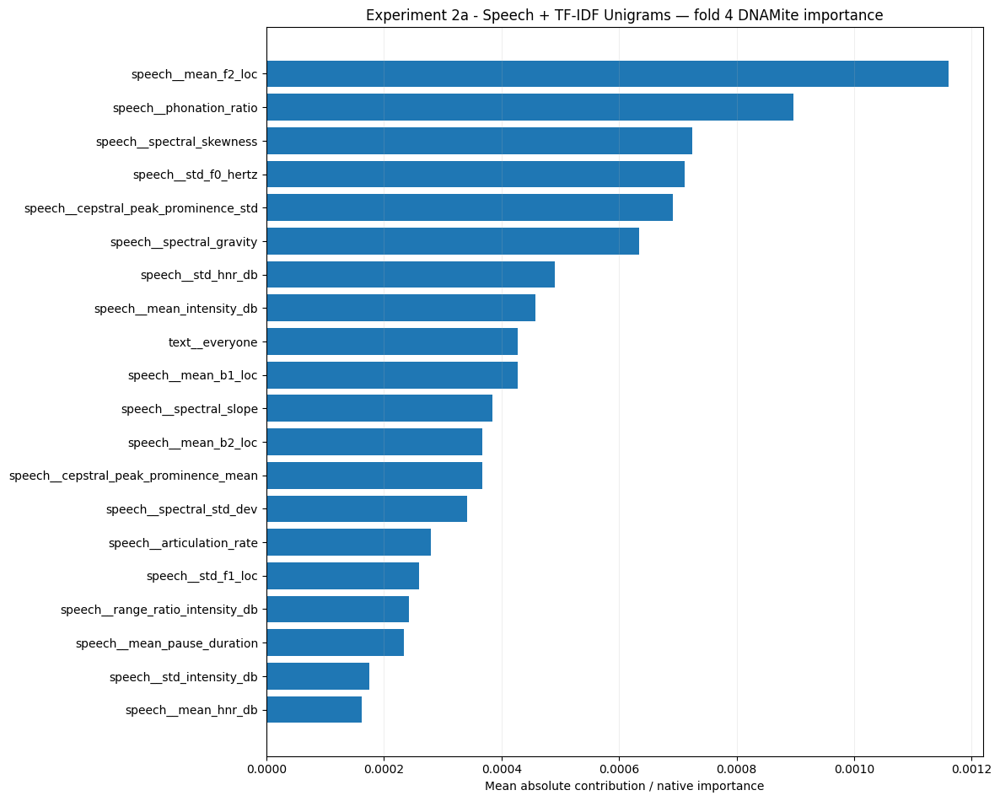

ROC_AUC              0.480263
PR_AUC               0.319962
AUPRC                0.319962
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208523
Log_Loss             0.607736
Threshold            0.235000
dtype: float64

Experiment 2a - Speech + TF-IDF Unigrams | Classification | Outer fold 5
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 12 TF-IDF features for classification / unigram using C=5.0
DNAMite active features | 40 / 40
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.435238 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.580811 | hit ceiling=False
  Inner fold 3/3
Selecte

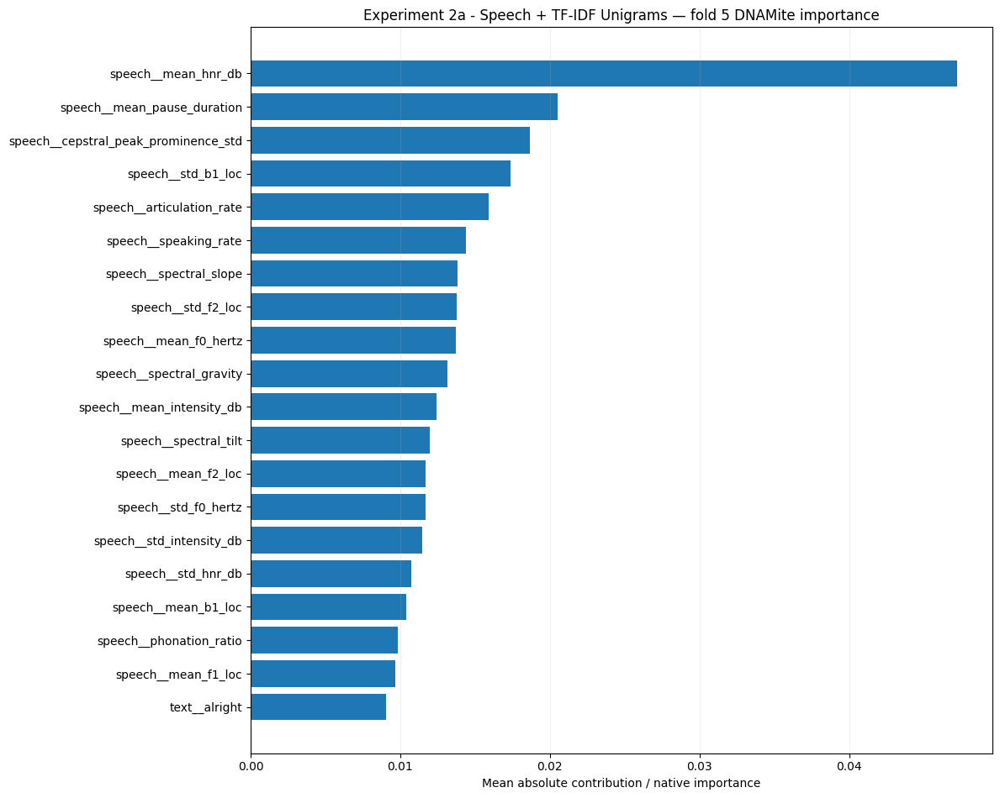

ROC_AUC              0.250000
PR_AUC               0.214778
AUPRC                0.214778
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.212008
Log_Loss             0.615745
Threshold            0.275000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.471053,0.261326
PR_AUC,0.363230,0.262355
AUPRC,0.363230,0.262355
Accuracy,0.459259,0.223146
Balanced_Accuracy,0.500000,0.000000
Precision,0.177778,0.162288
Sensitivity,0.600000,0.547723
Specificity,0.400000,0.547723
F1,0.274286,0.250387
Brier_Score,0.209236,0.001550



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,False,None,29,29,"[speech__speaking_rate, speech__articulation_r..."
1,2,False,None,30,30,"[speech__speaking_rate, speech__articulation_r..."
2,3,False,None,31,31,"[speech__speaking_rate, speech__articulation_r..."
3,4,False,None,30,30,"[speech__speaking_rate, speech__articulation_r..."
4,5,False,None,29,29,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 2a
# Speech + TF-IDF Unigrams
# Classification Nested Cross-Validation
# ============================================================

EXPERIMENT_2A_NAME = (
    "Experiment 2a - Speech + TF-IDF Unigrams"
)


experiment_2a_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_2A_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 2a
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_2a_binary_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_2a_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0010,32,32,2,False,None,29,29,...,0.000000,0.208544,0.607790,0.345,0.698094,3058.542969,16.518066,22.0,0.000014,5.524664e-08
1,2,4,0.0010,16,16,2,False,None,30,30,...,0.000000,0.208589,0.607893,0.345,0.691042,3058.570312,16.518066,22.0,0.000016,6.443298e-08
2,3,4,0.0010,32,16,2,False,None,31,31,...,0.457143,0.208517,0.607723,0.290,0.781327,3124.839844,16.518066,22.0,0.000017,6.866162e-08
3,4,4,0.0010,16,32,2,False,None,30,30,...,0.457143,0.208523,0.607736,0.235,0.767061,3080.242188,16.518066,22.0,0.000017,6.696993e-08
4,5,16,0.0005,32,32,2,False,None,29,29,...,0.457143,0.212008,0.615745,0.275,0.878056,3124.796875,16.518066,22.0,0.000021,8.113105e-08



CV SUMMARY


,Mean,SD
ROC_AUC,0.471053,0.261326
PR_AUC,0.363230,0.262355
AUPRC,0.363230,0.262355
Accuracy,0.459259,0.223146
Balanced_Accuracy,0.500000,0.000000
Precision,0.177778,0.162288
Sensitivity,0.600000,0.547723
Specificity,0.400000,0.547723
F1,0.274286,0.250387
Brier_Score,0.209236,0.001550


In [ ]:
# ============================================================
# Experiment 2a
# Cross-Validation Performance
# ============================================================

experiment_2a_cv_metrics = (
    experiment_2a_binary_cv[
        "outer_results"
    ].copy()
)

experiment_2a_cv_summary = (
    experiment_2a_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_2a_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_2a_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0010,32,32,2,False,None,29,29,...,0.000000,0.208544,0.607790,0.345,0.698094,3058.542969,16.518066,22.0,0.000014,5.524664e-08
1,2,4,0.0010,16,16,2,False,None,30,30,...,0.000000,0.208589,0.607893,0.345,0.691042,3058.570312,16.518066,22.0,0.000016,6.443298e-08
2,3,4,0.0010,32,16,2,False,None,31,31,...,0.457143,0.208517,0.607723,0.290,0.781327,3124.839844,16.518066,22.0,0.000017,6.866162e-08
3,4,4,0.0010,16,32,2,False,None,30,30,...,0.457143,0.208523,0.607736,0.235,0.767061,3080.242188,16.518066,22.0,0.000017,6.696993e-08
4,5,16,0.0005,32,32,2,False,None,29,29,...,0.457143,0.212008,0.615745,0.275,0.878056,3124.796875,16.518066,22.0,0.000021,8.113105e-08



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.471053,0.261326
PR_AUC,0.363230,0.262355
AUPRC,0.363230,0.262355
Accuracy,0.459259,0.223146
Balanced_Accuracy,0.500000,0.000000
Precision,0.177778,0.162288
Sensitivity,0.600000,0.547723
Specificity,0.400000,0.547723
F1,0.274286,0.250387
Brier_Score,0.209236,0.001550


In [ ]:
# ============================================================
# Experiment 2a
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_2a_parameters = (
    experiment_2a_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
        ]
    ]
    .copy()
)

display(
    experiment_2a_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers
0,1,4,0.0010,32,32,2
1,2,4,0.0010,16,16,2
2,3,4,0.0010,32,16,2
3,4,4,0.0010,16,32,2
4,5,16,0.0005,32,32,2



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2a_-_Speech_TF-IDF_Unigrams
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


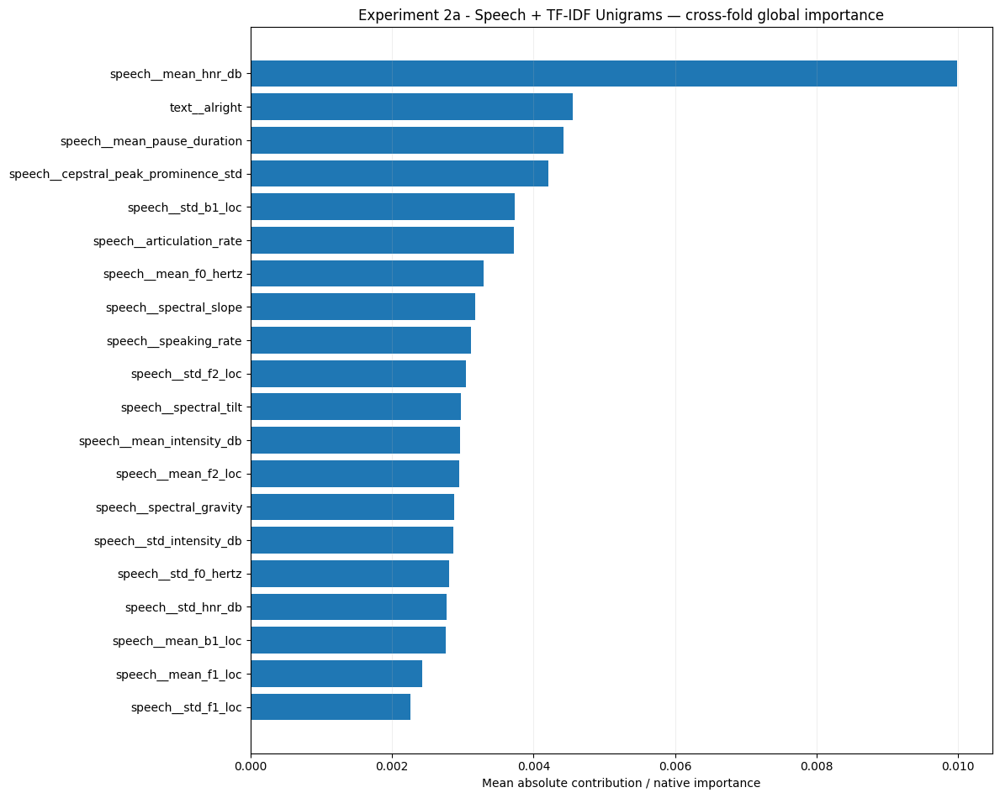

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2a_-_Speech_TF-IDF_Unigrams/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 2a
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams
# ============================================================

experiment_2a_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_2A_NAME
        ),
        top_k=30,
    )
)

experiment_2a_interpretability

In [ ]:
# ============================================================
# Experiment 2a
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_2a_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_2A_NAME)
)


experiment_2a_development_rows = []

for path in sorted(
    experiment_2a_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_2a_development_rows.append(
            json.load(file)
        )


experiment_2a_development_df = (
    pd.DataFrame(
        experiment_2a_development_rows
    )
)

display(
    experiment_2a_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 2a - Speech + TF-IDF Unigrams,classification,1,96,87.662748,0.002078,0.000008,3058.648438,16.518066,22.0
1,DNAMite Optimized,Experiment 2a - Speech + TF-IDF Unigrams,classification,2,96,115.923754,0.003082,0.000012,3058.687500,16.518066,22.0
2,DNAMite Optimized,Experiment 2a - Speech + TF-IDF Unigrams,classification,3,96,114.645137,0.003046,0.000012,3124.910156,16.518066,22.0
3,DNAMite Optimized,Experiment 2a - Speech + TF-IDF Unigrams,classification,4,96,90.526487,0.002139,0.000008,3080.312500,16.518066,22.0
4,DNAMite Optimized,Experiment 2a - Speech + TF-IDF Unigrams,classification,5,96,93.184234,0.002267,0.000009,3124.855469,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 2a
# Development Cost Summary
# ============================================================

experiment_2a_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_2a_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2a_development_df[
                    experiment_2a_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_2a_development_df[
                    experiment_2a_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2a_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_2a_development_summary[
            "Mean"
        ],
        experiment_2a_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_2a_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,96.000000,0.000000,96.000000 ± 0.000000
development_seconds,100.388472,13.745011,100.388472 ± 13.745011
development_energy_kwh,0.002523,0.000499,0.002523 ± 0.000499
development_co2_kg,0.000010,0.000002,0.000010 ± 0.000002


In [ ]:
# ============================================================
# Experiment 2a
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_2a_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_2a_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2a_binary_cv[
                    "outer_results"
                ][
                    experiment_2a_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_2a_binary_cv[
                    "outer_results"
                ][
                    experiment_2a_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2a_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_2a_training_summary[
            "Mean"
        ],
        experiment_2a_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_2a_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,7.631160e-01,7.579726e-02,0.76311599 ± 0.07579726
peak_ram_mb,3.089398e+03,3.352392e+01,3089.39843750 ± 33.52391986
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,1.708976e-05,2.364733e-06,0.00001709 ± 0.00000236
training_co2_kg,6.728845e-08,9.310794e-09,0.00000007 ± 0.00000001


### Experiment 2a final binary model

In [ ]:
# ============================================================
# Experiment 2a
# Speech + TF-IDF Unigrams
# Final Model
# ============================================================

EXPERIMENT_2A_NAME = (
    "Experiment 2a - Speech + TF-IDF Unigrams"
)

experiment_2a_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        text_development=(
            unigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        experiment_name=(
            EXPERIMENT_2A_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=113 | best=83 | best val_loss=0.574535 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.540059 | hit ceiling=False
  Inner fold 3/3
Selected 3 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 31 / 31
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.489803 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=56 |

In [ ]:
# ============================================================
# Experiment 2a
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_2a_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.504464
PR_AUC,0.352205
AUPRC,0.352205
Accuracy,0.369565
Balanced_Accuracy,0.526786
Precision,0.317073
Sensitivity,0.928571
Specificity,0.125000
F1,0.472727
Brier_Score,0.211651


### Experiment 2a binary confusion matrix and curves

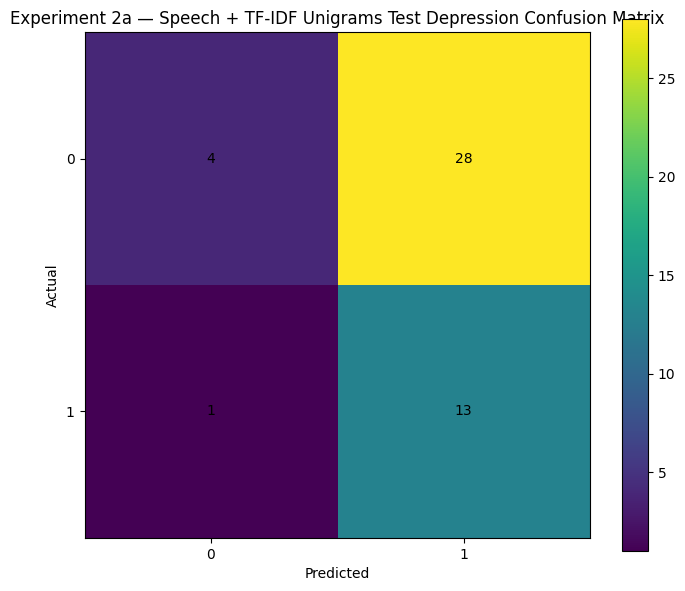

array([[ 4, 28],
       [ 1, 13]])

In [ ]:
# ============================================================
# Experiment 2a
# Final Test Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_2a_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 2a — "
        "Speech + TF-IDF Unigrams "
        "Test Depression Confusion Matrix"
    ),
)

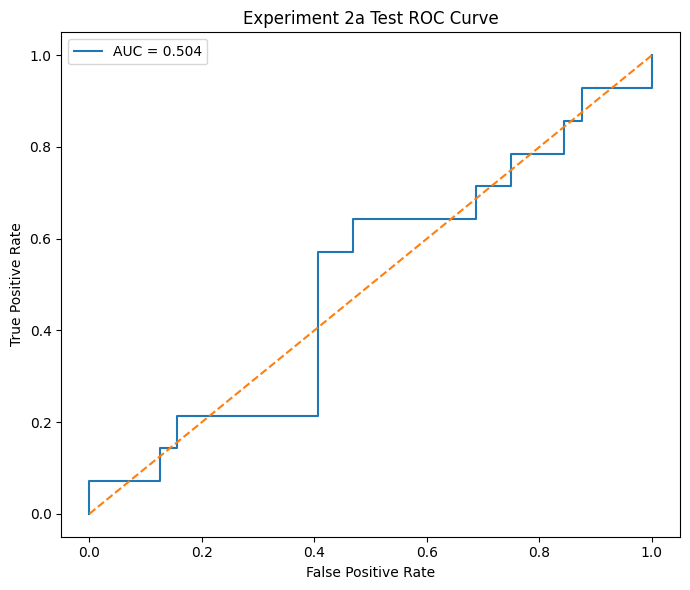

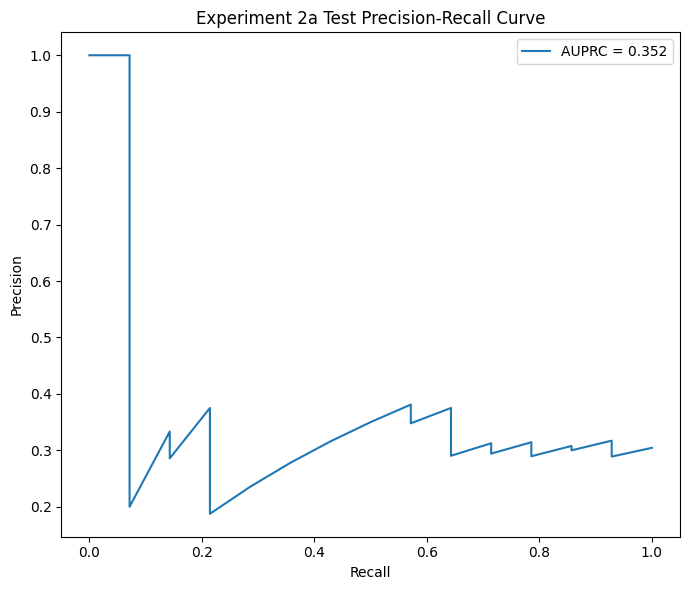

In [ ]:
# ============================================================
# Experiment 2a
# Final Test Classification Curves
# ============================================================

plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_2a_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 2a Test"
    ),
)

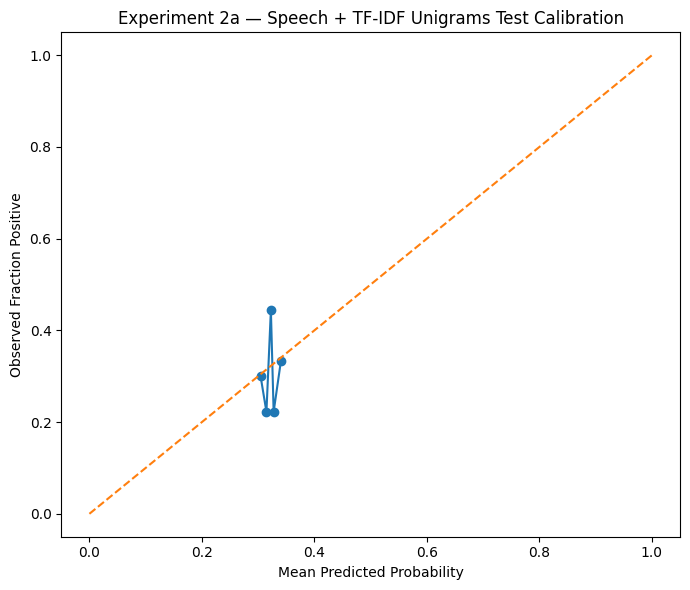

,mean_predicted_probability,observed_fraction_positive,n
0,0.304362,0.300000,10
1,0.314737,0.222222,9
2,0.322646,0.444444,9
3,0.327531,0.222222,9
4,0.340495,0.333333,9


In [ ]:
# ============================================================
# Experiment 2a
# Final Test Calibration
# ============================================================

plot_calibration_curve_manual(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_2a_binary_final[
            "test_probabilities"
        ]
    ),
    n_bins=5,
    title=(
        "Experiment 2a — "
        "Speech + TF-IDF Unigrams "
        "Test Calibration"
    ),
)

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.036566,31
1,0,speech__articulation_rate,0.047290,31
2,0,speech__phonation_ratio,0.036404,31
3,0,speech__pause_rate,0.043558,31
4,0,speech__mean_pause_duration,0.041416,31
5,0,speech__mean_f0_hertz,0.035841,31
6,0,speech__std_f0_hertz,0.022156,31
7,0,speech__mean_intensity_db,0.011418,31
8,0,speech__std_intensity_db,0.038287,31
9,0,speech__range_ratio_intensity_db,0.036526,31


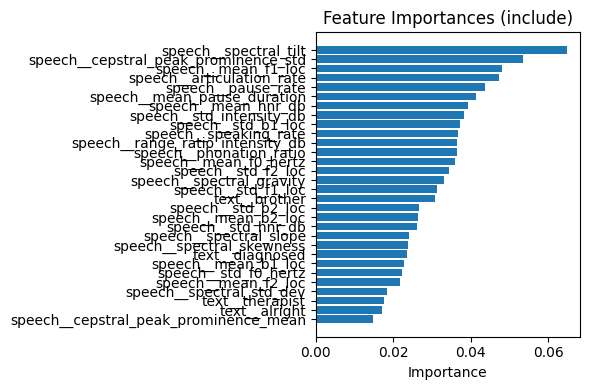

In [ ]:
# ============================================================
# Experiment 2a
# Final Model Feature Importance
# ============================================================

experiment_2a_binary_importance = (
    show_feature_importance(
        experiment_2a_binary_final[
            "model"
        ],
        top_n=30,
    )
)

### Experiment 2b Speech + TF-IDF Unigrams with Feature Selection


Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Classification | Outer fold 1
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 18 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc']
DNAMite epochs | split=1 | ran=77 | best=47 | best val_loss=0.580260 | hit ceiling=False
  Inner fold 2/3
Selected 13 TF-IDF features for classification / unigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 33 / 41
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__brother', 'text__certain', 'text__daughter', 'text__even', 'text__everyone']
DNAMite epochs | split=1 | ran=46 | best=16 | best val_loss=0.516846 | hit ceiling=False
  Inner fold 3/3
Selected 1 

...

DNAMite active features | 8 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db']
DNAMite epochs | split=1 | ran=89 | best=59 | best val_loss=0.523261 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 8 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db']
DNAMite epochs | split=1 | ran=85 | best=55 | best val_loss=0.589012 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 11 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db']
DNAMite epochs | split=1 | ran=183 | best=153 | best val_loss=0.366861 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 2.388136123001459, 'peak_ram_mb': 3080.82421875, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 7.769764411968216e-05, 'training_co2_kg': 3.059232096294019e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_01.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/en

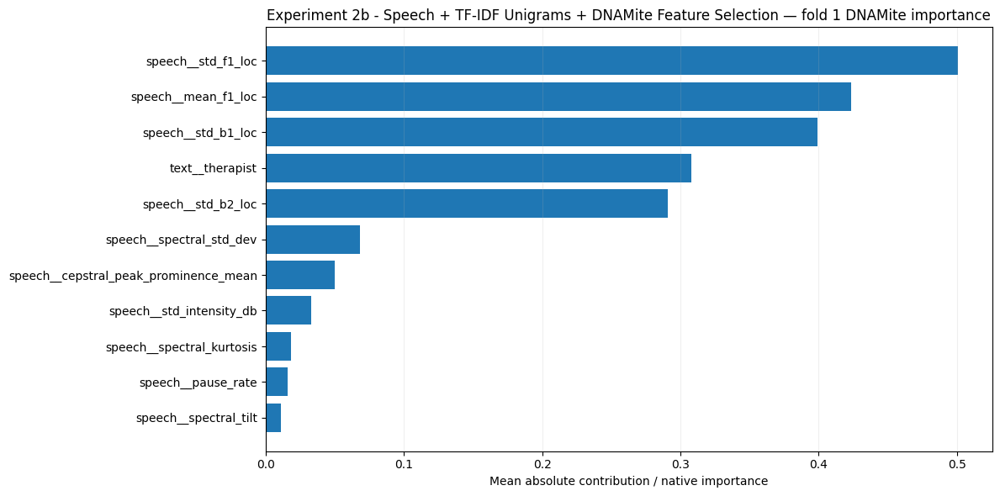

ROC_AUC              0.572368
PR_AUC               0.368313
AUPRC                0.368313
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.207735
Log_Loss             0.605844
Threshold            0.050000
dtype: float64

Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Classification | Outer fold 2
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 18 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc']
DNAMite epochs | split=1 | ran=77 | best=47 | best val_loss=0.579710 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 16 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std']
DNAMite epochs | split=1 | ran=39 | best=9 | best val_loss=0.636462 | hit ceiling=False
  Inner fold 3/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 12 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db']
DNAMite epochs | split=1 | ran=88 | best=58 | best val_loss=0.385825 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 12 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db']
DNAMite epochs | split=1 | ran=91 | best=61 | best val_loss=0.357067 | hit ceiling=False
Selected 2 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 13 / 30
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=123 | best=93 | best val_loss=0.399458 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.5328506829973776, 'peak_ram_mb': 3081.65625, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 4.472114318023936e-05, 'training_co2_kg': 1.7608301789589482e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_02.json
Saved energy metrics to: /content/dr

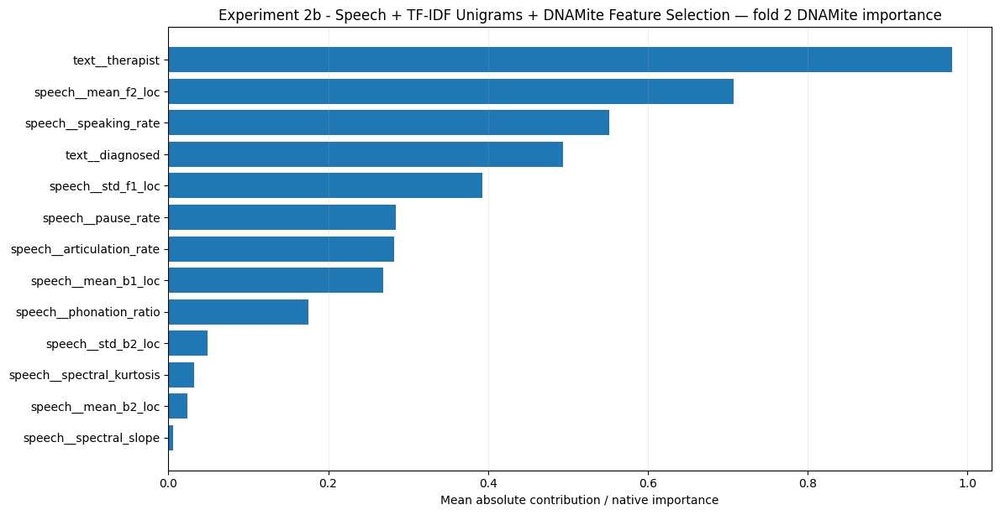

ROC_AUC              0.513158
PR_AUC               0.300090
AUPRC                0.300090
Accuracy             0.629630
Balanced_Accuracy    0.483553
Precision            0.250000
Sensitivity          0.125000
Specificity          0.842105
F1                   0.166667
Brier_Score          0.240119
Log_Loss             0.706693
Threshold            0.420000
dtype: float64

Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Classification | Outer fold 3
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 24 / 39
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc']
DNAMite epochs | split=1 | ran=256 | best=226 | best val_loss=0.543231 | hit ceiling=False
  Inner fold 2/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 29 / 42
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__brother']
DNAMite epochs | split=1 | ran=296 | best=266 | best val_loss=0.501619 | hit ceiling=False
  Inner fold 3/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
Running

...

DNAMite active features | 29 / 39
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__brother']
DNAMite epochs | split=1 | ran=81 | best=51 | best val_loss=0.569749 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature sel

[WARNING] Found selected features. Using only those features.


DNAMite active features | 21 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc']
DNAMite epochs | split=1 | ran=48 | best=18 | best val_loss=0.637368 | hit ceiling=False
Selected 3 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 26 / 31
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev']
DNAMite epochs | split=1 | ran=72 | best=42 | best val_loss=0.545876 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.3711152620016946, 'peak_ram_mb': 3082.078125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Out

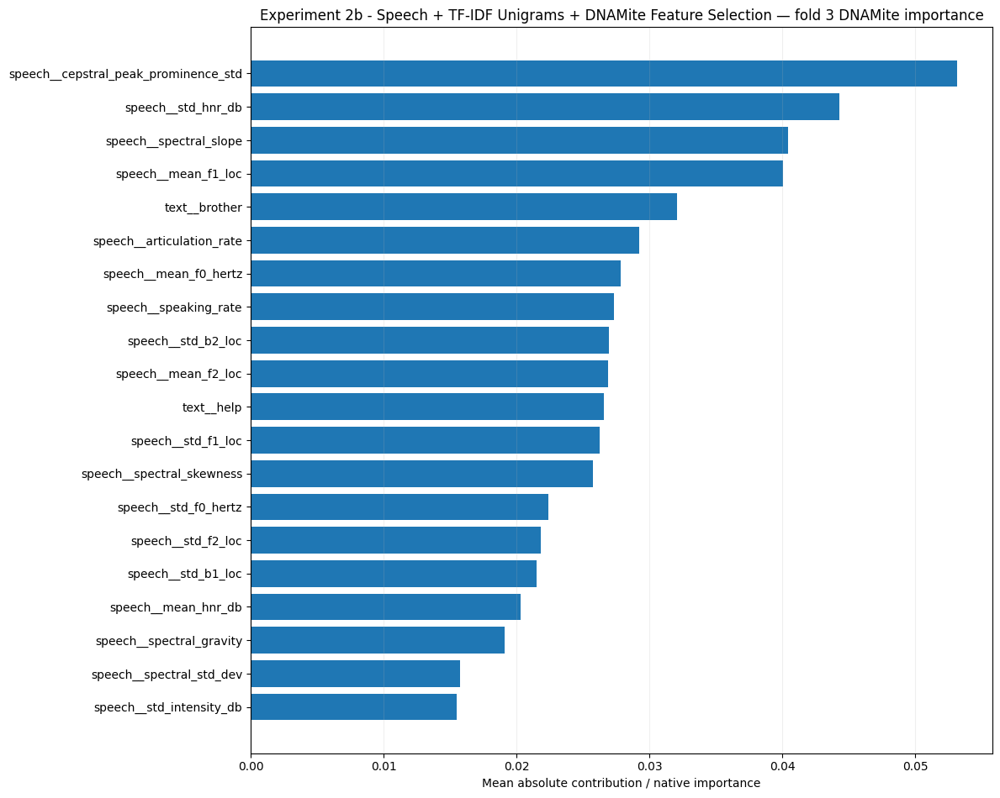

ROC_AUC              0.631579
PR_AUC               0.434443
AUPRC                0.434443
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208119
Log_Loss             0.606765
Threshold            0.280000
dtype: float64

Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Classification | Outer fold 4
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 30
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=76 | best=46 | best val_loss=0.582266 | hit ceiling=False
  Inner fold 2/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 30 / 42
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__afraid', 'text__alright']
DNAMite epochs | split=1 | ran=147 | best=117 | best val_loss=0.538805 | hit ceiling=False
  Inner fold 3/3
Selected 13 TF-IDF features for classification / unigram usi

...

DNAMite active features | 10 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=291 | best=261 | best val_loss=0.343024 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 11 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db']
DNAMite epochs | split=1 | ran=196 | best=166 | best val_loss=0.532300 | hit ceiling=False
Selected 2 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 23 / 30
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc']
DNAMite epochs | split=1 | ran=187 | best=157 | best val_loss=0.396104 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 2.1471886900035315, 'peak_ram_mb': 3082.46875, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 6.439539154683651e-05, 't

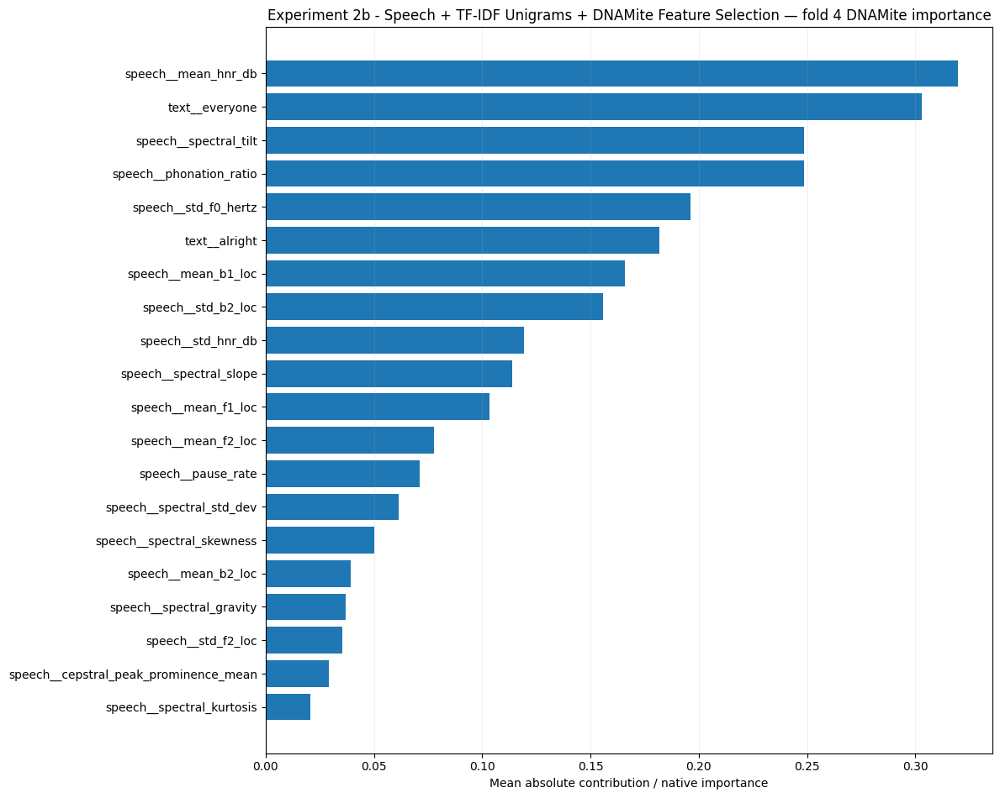

ROC_AUC              0.644737
PR_AUC               0.598045
AUPRC                0.598045
Accuracy             0.666667
Balanced_Accuracy    0.582237
Precision            0.428571
Sensitivity          0.375000
Specificity          0.789474
F1                   0.400000
Brier_Score          0.207080
Log_Loss             0.604259
Threshold            0.295000
dtype: float64

Experiment 2b - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Classification | Outer fold 5
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 12 TF-IDF features for classification / unigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 31 / 40
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__anymore', 'text__biggest', 'text__by']
DNAMite epochs | split=1 | ran=38 | best=8 | best val_loss=0.461943 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / un

[WARNING] Found selected features. Using only those features.


DNAMite active features | 16 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std']
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.580654 | hit ceiling=False
  Inner fold 3/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 3 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio']
DNAMite epochs | split=1 | ran=63 | best=33 | best val_loss=0.668374 | hit ceiling=False
Selected 8 TF-IDF features for classification / unigram using C=5.0
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 1 / 36
Active features: ['speech__speaking_rate']
DNAMite epochs | split=1 | ran=129 | best=99 | best val_loss=0.514103 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 2 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate']
DNAMite epochs | split=1 | ran=109 | best=79 | best val_loss=0.517033 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.6128129940043436, 'peak_ram_mb': 3082.8125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 4.508183333589573e-05, 'training_co2_kg': 1.7750318309331262e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_05.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_05.json
Saved outer-fold model to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DN

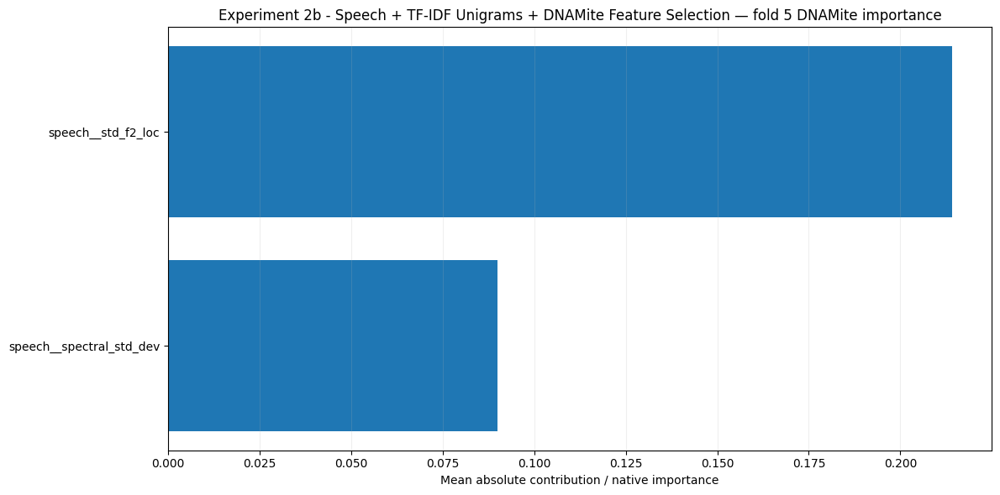

ROC_AUC              0.365132
PR_AUC               0.226145
AUPRC                0.226145
Accuracy             0.518519
Balanced_Accuracy    0.368421
Precision            0.000000
Sensitivity          0.000000
Specificity          0.736842
F1                   0.000000
Brier_Score          0.209187
Log_Loss             0.609322
Threshold            0.300000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.545395,0.113532
PR_AUC,0.385407,0.141911
AUPRC,0.385407,0.141911
Accuracy,0.481481,0.177623
Balanced_Accuracy,0.486842,0.076617
Precision,0.254233,0.156991
Sensitivity,0.500000,0.475986
Specificity,0.473684,0.434011
F1,0.296190,0.204385
Brier_Score,0.214448,0.014371



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,True,0.0010,29,11,"[speech__speaking_rate, speech__articulation_r..."
1,2,True,0.0010,30,13,"[speech__speaking_rate, speech__articulation_r..."
2,3,True,0.0005,31,26,"[speech__speaking_rate, speech__articulation_r..."
3,4,True,0.0005,30,23,"[speech__speaking_rate, speech__articulation_r..."
4,5,True,0.0100,29,2,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 2b
# Speech + TF-IDF Unigrams + DNAMite Feature Selection
# Nested Cross-Validation
# ============================================================

EXPERIMENT_2B_NAME = (
    "Experiment 2b - "
    "Speech + TF-IDF Unigrams + "
    "DNAMite Feature Selection"
)


experiment_2b_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_2B_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        use_feature_selection=True,
    )
)

### Experiment 2b Nested CV Results

In [ ]:
# ============================================================
# Experiment 2b
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_2b_binary_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_2b_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,feature_selection_enabled,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0005,16,16,2,0.0010,True,29,11,...,0.457143,0.207735,0.605844,0.050,2.388136,3080.824219,16.518066,22.0,0.000078,3.059232e-07
1,2,8,0.0010,32,32,2,0.0010,True,30,13,...,0.166667,0.240119,0.706693,0.420,1.532851,3081.656250,16.518066,22.0,0.000045,1.760830e-07
2,3,32,0.0005,16,16,2,0.0005,True,31,26,...,0.457143,0.208119,0.606765,0.280,1.371115,3082.078125,16.518066,22.0,0.000038,1.500222e-07
3,4,8,0.0005,16,16,2,0.0005,True,30,23,...,0.400000,0.207080,0.604259,0.295,2.147189,3082.468750,16.518066,22.0,0.000064,2.535475e-07
4,5,16,0.0005,32,16,2,0.0100,True,29,2,...,0.000000,0.209187,0.609322,0.300,1.612813,3082.812500,16.518066,22.0,0.000045,1.775032e-07



CV SUMMARY


,Mean,SD
ROC_AUC,0.545395,0.113532
PR_AUC,0.385407,0.141911
AUPRC,0.385407,0.141911
Accuracy,0.481481,0.177623
Balanced_Accuracy,0.486842,0.076617
Precision,0.254233,0.156991
Sensitivity,0.500000,0.475986
Specificity,0.473684,0.434011
F1,0.296190,0.204385
Brier_Score,0.214448,0.014371


In [ ]:
# ============================================================
# Experiment 2b
# Cross-Validation Performance
# ============================================================

experiment_2b_cv_metrics = (
    experiment_2b_binary_cv[
        "outer_results"
    ].copy()
)

experiment_2b_cv_summary = (
    experiment_2b_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_2b_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_2b_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,feature_selection_enabled,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0005,16,16,2,0.0010,True,29,11,...,0.457143,0.207735,0.605844,0.050,2.388136,3080.824219,16.518066,22.0,0.000078,3.059232e-07
1,2,8,0.0010,32,32,2,0.0010,True,30,13,...,0.166667,0.240119,0.706693,0.420,1.532851,3081.656250,16.518066,22.0,0.000045,1.760830e-07
2,3,32,0.0005,16,16,2,0.0005,True,31,26,...,0.457143,0.208119,0.606765,0.280,1.371115,3082.078125,16.518066,22.0,0.000038,1.500222e-07
3,4,8,0.0005,16,16,2,0.0005,True,30,23,...,0.400000,0.207080,0.604259,0.295,2.147189,3082.468750,16.518066,22.0,0.000064,2.535475e-07
4,5,16,0.0005,32,16,2,0.0100,True,29,2,...,0.000000,0.209187,0.609322,0.300,1.612813,3082.812500,16.518066,22.0,0.000045,1.775032e-07



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.545395,0.113532
PR_AUC,0.385407,0.141911
AUPRC,0.385407,0.141911
Accuracy,0.481481,0.177623
Balanced_Accuracy,0.486842,0.076617
Precision,0.254233,0.156991
Sensitivity,0.500000,0.475986
Specificity,0.473684,0.434011
F1,0.296190,0.204385
Brier_Score,0.214448,0.014371


In [ ]:
# ============================================================
# Experiment 2b
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_2b_parameters = (
    experiment_2b_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "selection_reg_param",
        ]
    ]
    .copy()
)

display(
    experiment_2b_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param
0,1,8,0.0005,16,16,2,0.0010
1,2,8,0.0010,32,32,2,0.0010
2,3,32,0.0005,16,16,2,0.0005
3,4,8,0.0005,16,16,2,0.0005
4,5,16,0.0005,32,16,2,0.0100



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


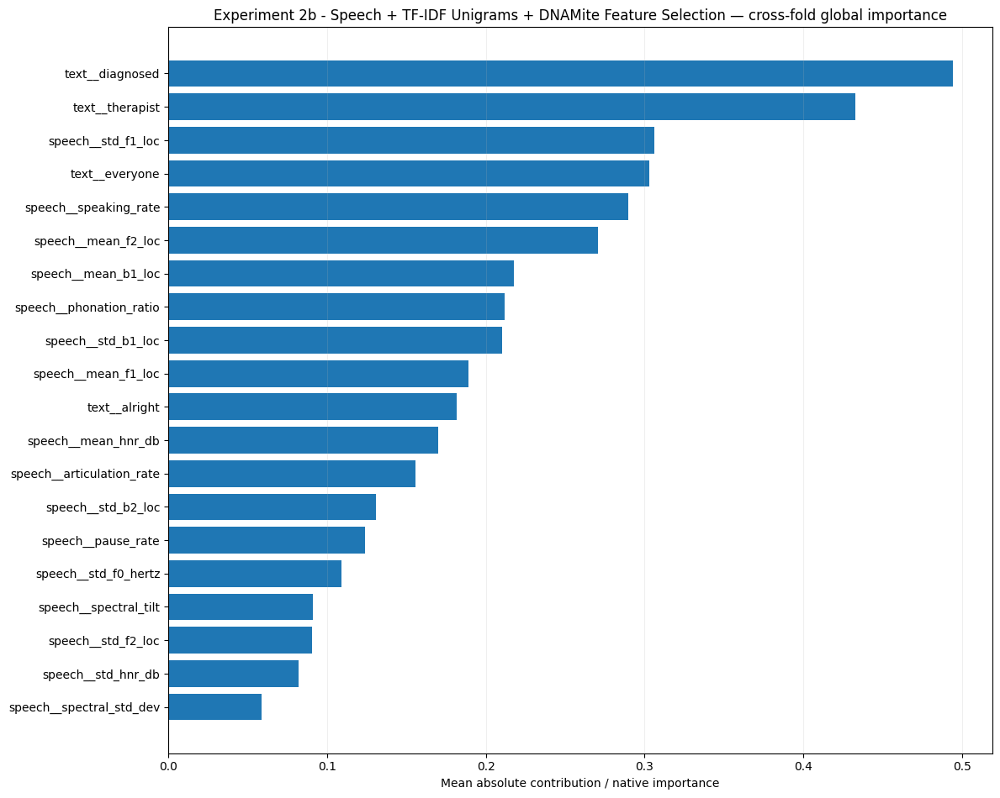

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 2b
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams + Feature Selection
# ============================================================

experiment_2b_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_2B_NAME
        ),
        top_k=30,
    )
)

experiment_2b_interpretability

In [ ]:
# ============================================================
# Experiment 2b
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_2b_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_2B_NAME)
)


experiment_2b_development_rows = []

for path in sorted(
    experiment_2b_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_2b_development_rows.append(
            json.load(file)
        )


experiment_2b_development_df = (
    pd.DataFrame(
        experiment_2b_development_rows
    )
)

display(
    experiment_2b_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,classification,1,672,785.966880,0.021105,0.000083,3080.941406,16.518066,22.0
1,DNAMite Optimized,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,classification,2,672,883.879616,0.024328,0.000096,3081.671875,16.518066,22.0
2,DNAMite Optimized,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,classification,3,672,971.719337,0.027955,0.000110,3082.117188,16.518066,22.0
3,DNAMite Optimized,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,classification,4,672,819.330034,0.021743,0.000086,3082.574219,16.518066,22.0
4,DNAMite Optimized,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,classification,5,672,677.991142,0.016809,0.000066,3082.835938,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 2b
# Development Cost Summary
# ============================================================

experiment_2b_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_2b_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2b_development_df[
                    experiment_2b_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_2b_development_df[
                    experiment_2b_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2b_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_2b_development_summary[
            "Mean"
        ],
        experiment_2b_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_2b_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,672.000000,0.000000,672.000000 ± 0.000000
development_seconds,827.777402,109.683796,827.777402 ± 109.683796
development_energy_kwh,0.022388,0.004121,0.022388 ± 0.004121
development_co2_kg,0.000088,0.000016,0.000088 ± 0.000016


In [ ]:
# ============================================================
# Experiment 2b
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_2b_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_2b_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2b_binary_cv[
                    "outer_results"
                ][
                    experiment_2b_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_2b_binary_cv[
                    "outer_results"
                ][
                    experiment_2b_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2b_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_2b_training_summary[
            "Mean"
        ],
        experiment_2b_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_2b_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,1.810421e+00,4.348135e-01,1.81042075 ± 0.43481346
peak_ram_mb,3.081968e+03,7.716025e-01,3081.96796875 ± 0.77160254
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,5.399966e-05,1.649251e-05,0.00005400 ± 0.00001649
training_co2_kg,2.126158e-07,6.493686e-08,0.00000021 ± 0.00000006


### Experiment 2b Final Model

In [ ]:
# ============================================================
# Experiment 2b
# Speech + TF-IDF Unigrams + DNAMite Feature Selection
# Final Model
# ============================================================

EXPERIMENT_2B_NAME = (
    "Experiment 2b - "
    "Speech + TF-IDF Unigrams + "
    "DNAMite Feature Selection"
)

experiment_2b_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        text_development=(
            unigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        experiment_name=(
            EXPERIMENT_2B_NAME
        ),
        use_feature_selection=True,
        save_outputs=True,
    )
)

DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 21 / 30
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc']
DNAMite epochs | split=1 | ran=61 | best=31 | best val_loss=0.589159 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 26 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev']
DNAMite epochs | split=1 | ran=82 | best=52 | best val_loss=0.540091 | hit ceiling=False
  Inner fold 3/3
Selected 3 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 18 / 46
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc']
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.687387 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 24 / 29
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc']
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=0.636478 | hit ceiling=False
Selected probability threshold: 0.3
Development OOF balanced accuracy at threshold: 0.5118
Selected 4 TF-IDF features for classification / unigram using C=2.5
Running final DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


Final DNAMite active features: 10 / 32
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 59, 'best_epoch': 29, 'best_val_loss': 0.636371910572052, 'hit_epoch_ceiling': False}]

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection
Final model saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_00/final_model_bundle.pkl

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_2b

In [ ]:
# ============================================================
# Experiment 2b
# Final Model Feature Selection
# ============================================================

print(
    "Selection reg param:",
    experiment_2b_binary_final[
        "selection_reg_param"
    ],
)

print(
    "Number of selected features:",
    len(
        experiment_2b_binary_final[
            "active_feature_names"
        ]
    ),
)

print(
    "\nSelected features:"
)

display(
    pd.DataFrame(
        {
            "Feature": (
                experiment_2b_binary_final[
                    "active_feature_names"
                ]
            )
        }
    )
)

Selection reg param: 0.0001
Number of selected features: 10

Selected features:


,Feature
0,speech__speaking_rate
1,speech__articulation_rate
2,speech__phonation_ratio
3,speech__pause_rate
4,speech__mean_pause_duration
5,speech__mean_f0_hertz
6,speech__std_f0_hertz
7,speech__mean_intensity_db
8,speech__std_intensity_db
9,speech__range_ratio_intensity_db


### Experiment 2b Final Test Metrics

In [ ]:
# ============================================================
# Experiment 2b
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_2b_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.640625
PR_AUC,0.465643
AUPRC,0.465643
Accuracy,0.304348
Balanced_Accuracy,0.500000
Precision,0.304348
Sensitivity,1.000000
Specificity,0.000000
F1,0.466667
Brier_Score,0.211707


### Expeirment 2b Test Confusion Matrix

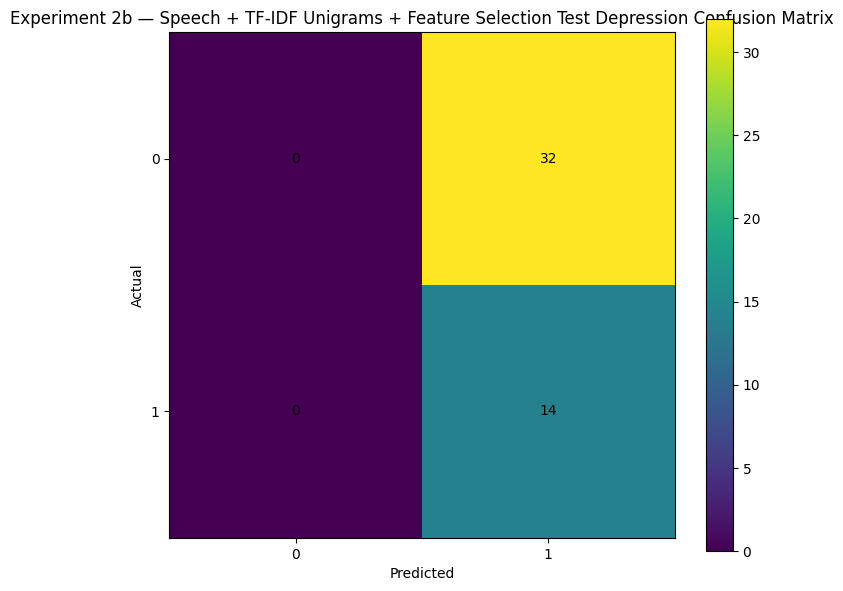

array([[ 0, 32],
       [ 0, 14]])

In [ ]:
# ============================================================
# Experiment 2b
# Final Test Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_2b_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 2b — "
        "Speech + TF-IDF Unigrams + "
        "Feature Selection "
        "Test Depression Confusion Matrix"
    ),
)

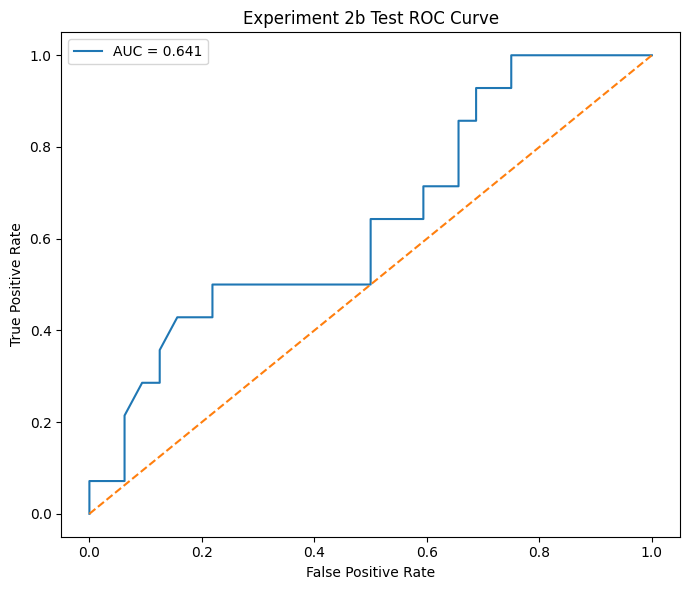

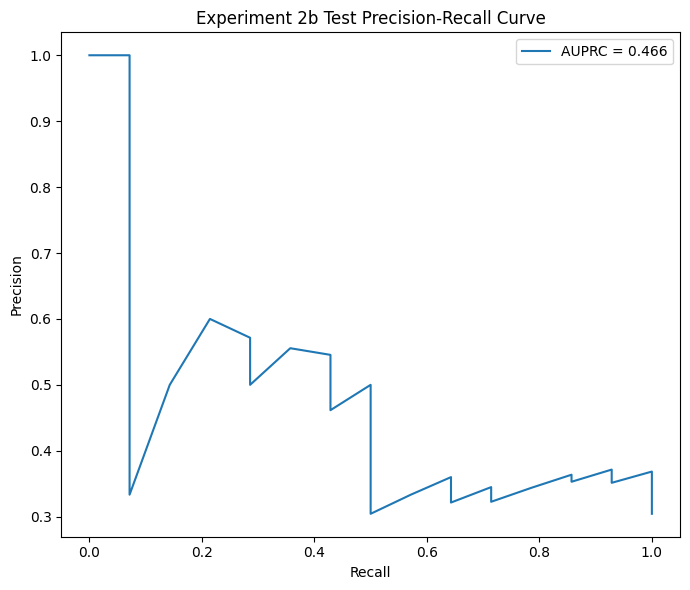

In [ ]:
# ============================================================
# Experiment 2b
# Final Test Classification Curves
# ============================================================

plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_2b_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 2b Test"
    ),
)

### Experiment 2b Calibration

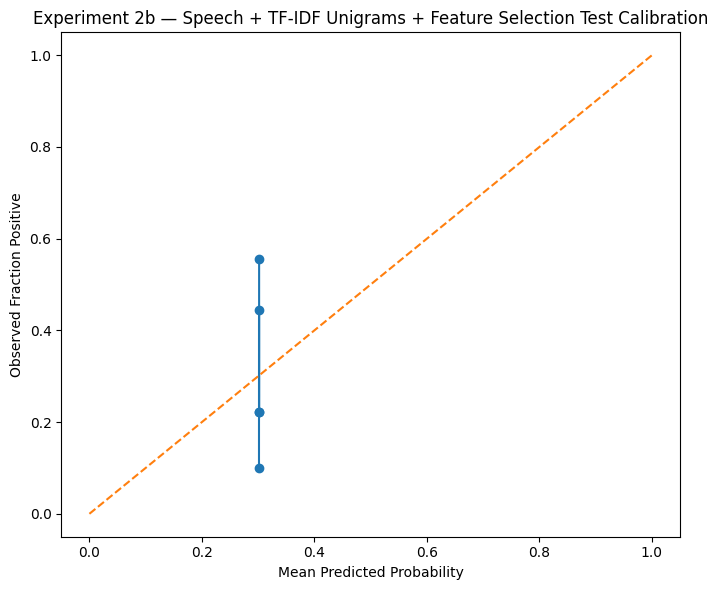

,mean_predicted_probability,observed_fraction_positive,n
0,0.301508,0.100000,10
1,0.301583,0.444444,9
2,0.301619,0.222222,9
3,0.301670,0.222222,9
4,0.301740,0.555556,9


In [ ]:
# ============================================================
# Experiment 2b
# Final Test Calibration
# ============================================================

plot_calibration_curve_manual(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_2b_binary_final[
            "test_probabilities"
        ]
    ),
    n_bins=5,
    title=(
        "Experiment 2b — "
        "Speech + TF-IDF Unigrams + "
        "Feature Selection "
        "Test Calibration"
    ),
)

,split,feature,importance,n_bins
0,0,speech__phonation_ratio,0.000248,3
1,0,speech__mean_pause_duration,0.000519,3
2,0,speech__std_intensity_db,0.000075,3
3,0,speech__mean_hnr_db,0.000315,3
4,0,speech__mean_f1_loc,0.001671,3
5,0,speech__std_f1_loc,0.001189,3
6,0,speech__mean_b1_loc,0.002171,3
7,0,speech__mean_f2_loc,0.001235,3
8,0,speech__mean_b2_loc,0.003074,3
9,0,speech__spectral_gravity,0.000031,3


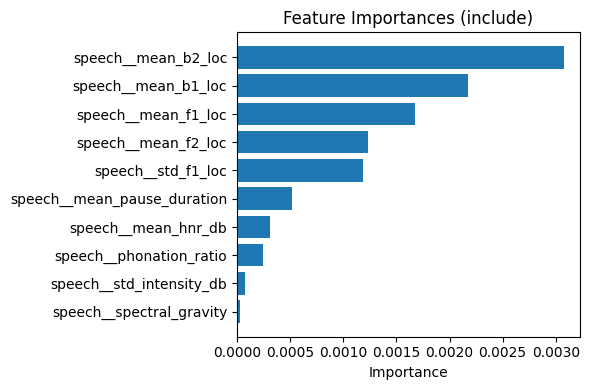

In [ ]:
# ============================================================
# Experiment 2b
# Final Model Feature Importance
# ============================================================

experiment_2b_binary_importance = (
    show_feature_importance(
        experiment_2b_binary_final[
            "model"
        ],
        top_n=30,
    )
)

In [ ]:
display(
    pd.Series(
        experiment_2b_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.640625
PR_AUC,0.465643
AUPRC,0.465643
Accuracy,0.304348
Balanced_Accuracy,0.500000
Precision,0.304348
Sensitivity,1.000000
Specificity,0.000000
F1,0.466667
Brier_Score,0.211707


In [ ]:
# ============================================================
# EXPERIMENT 2A VS 2B — TEST COMPARISON
# ============================================================

experiment_2a_vs_2b_binary_test = (
    pd.DataFrame(
        {
            "Experiment 2a - No DNAMite Selection": (
                experiment_2a_binary_final[
                    "test_metrics"
                ]
            ),

            "Experiment 2b - DNAMite Selection": (
                experiment_2b_binary_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_2a_vs_2b_binary_test
)

,Experiment 2a - No DNAMite Selection,Experiment 2b - DNAMite Selection
ROC_AUC,0.504464,0.640625
PR_AUC,0.352205,0.465643
AUPRC,0.352205,0.465643
Accuracy,0.369565,0.304348
Balanced_Accuracy,0.526786,0.500000
Precision,0.317073,0.304348
Sensitivity,0.928571,1.000000
Specificity,0.125000,0.000000
F1,0.472727,0.466667
Brier_Score,0.211651,0.211707


In [ ]:
experiment_2a_vs_2b_binary_cv = (
    pd.DataFrame(
        {
            "Experiment 2a - No DNAMite Selection": (
                experiment_2a_binary_cv[
                    "summary"
                ][
                    "Mean"
                ]
            ),

            "Experiment 2b - DNAMite Selection": (
                experiment_2b_binary_cv[
                    "summary"
                ][
                    "Mean"
                ]
            ),
        }
    )
)

display(
    experiment_2a_vs_2b_binary_cv
)

,Experiment 2a - No DNAMite Selection,Experiment 2b - DNAMite Selection
ROC_AUC,0.471053,0.545395
PR_AUC,0.363230,0.385407
AUPRC,0.363230,0.385407
Accuracy,0.459259,0.481481
Balanced_Accuracy,0.500000,0.486842
Precision,0.177778,0.254233
Sensitivity,0.600000,0.500000
Specificity,0.400000,0.473684
F1,0.274286,0.296190
Brier_Score,0.209236,0.214448


In [ ]:
# ============================================================
# RESET DNAMITE FEATURE SELECTION
# ============================================================

DNAMITE_SELECTION_REG_PARAM = 0.01

### Experiment 2c regression nested CV

Using severity-stratified master regression folds.

Experiment 2c - Speech + TF-IDF Unigrams | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 61 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 89 / 89
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.833289 | hit ceiling=False
  Inner fold 2/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.067763 | hit ceiling=False
  Inner fold 3/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=0.461852 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_em

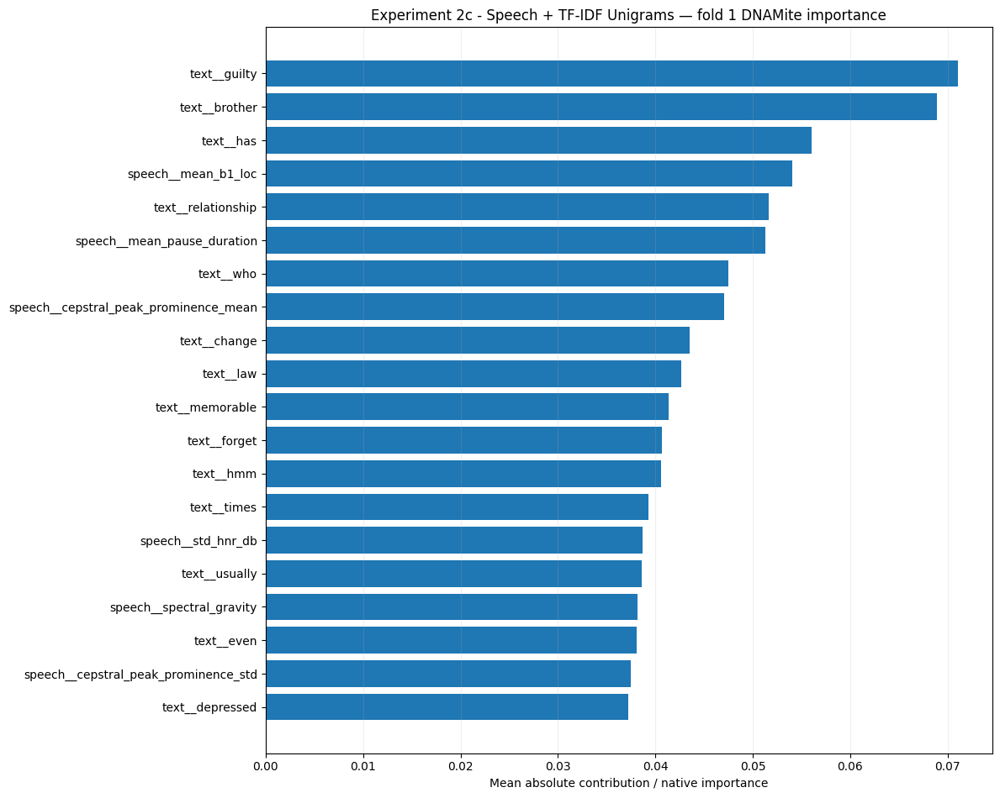

MAE               4.080522
RMSE              4.930900
R2                0.123145
Spearman_Rho      0.333131
Spearman_P        0.089511
Pearson_R         0.365464
Pearson_P         0.060850
Exact_Accuracy    0.037037
Within_1          0.185185
Within_2          0.259259
Within_3          0.518519
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 2c - Speech + TF-IDF Unigrams | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.817627 | hit ceiling=False
  Inner fold 2/3
Selected 60 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active featur

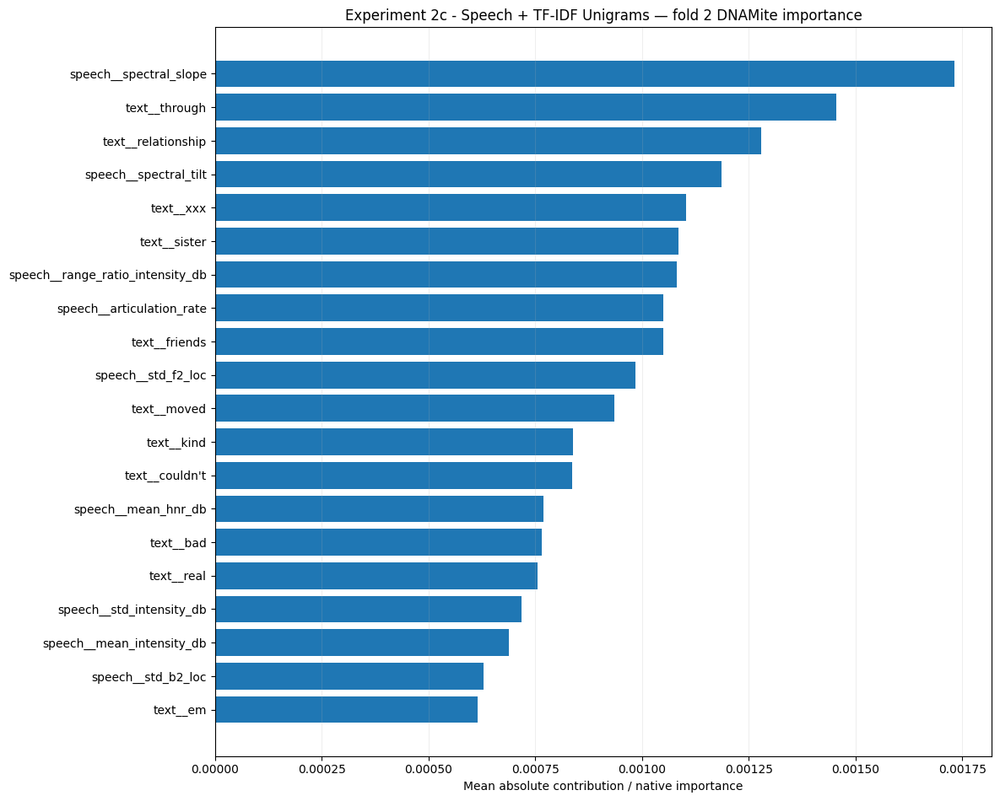

MAE               5.060062
RMSE              7.104901
R2               -0.293576
Spearman_Rho     -0.095400
Spearman_P        0.635972
Pearson_R        -0.068567
Pearson_P         0.733986
Exact_Accuracy    0.111111
Within_1          0.222222
Within_2          0.370370
Within_3          0.555556
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 2c - Speech + TF-IDF Unigrams | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=336 | best=306 | best val_loss=0.165271 | hit ceiling=False
  Inner fold 2/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active fea

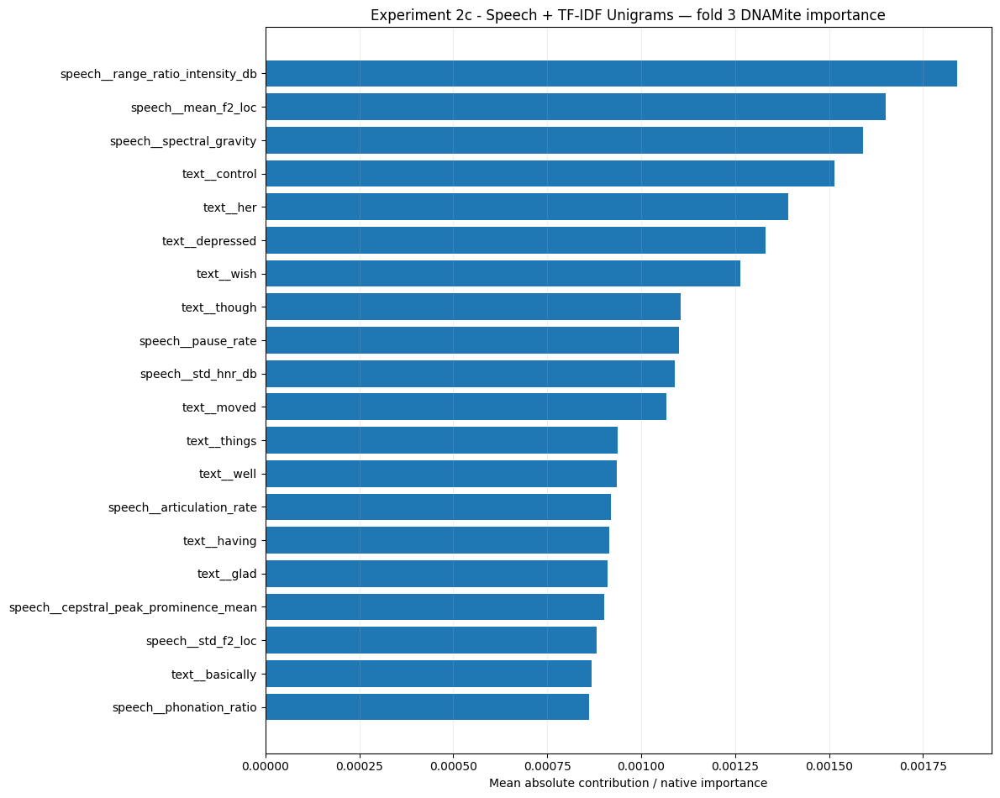

MAE               4.627297
RMSE              5.671324
R2               -0.022390
Spearman_Rho     -0.154814
Spearman_P        0.440683
Pearson_R        -0.234542
Pearson_P         0.238972
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 2c - Speech + TF-IDF Unigrams | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=466 | best=436 | best val_loss=0.240246 | hit ceiling=False
  Inner fold 2/3
Selected 68 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active feature

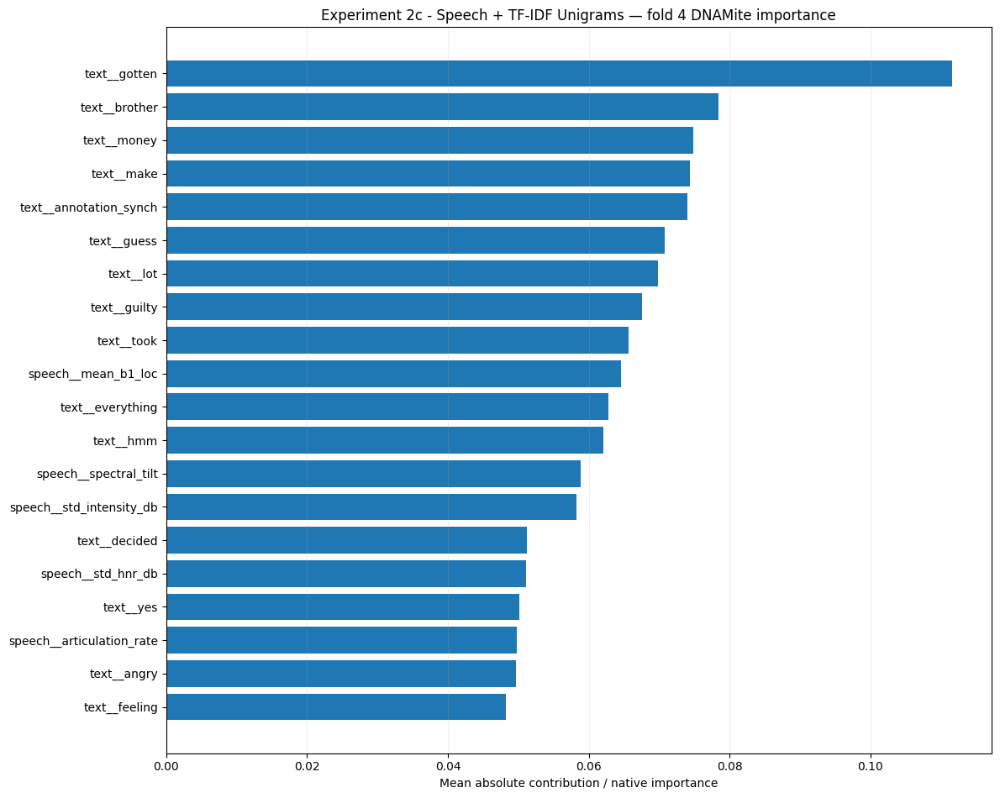

MAE               4.387454
RMSE              5.154381
R2               -0.020755
Spearman_Rho      0.301166
Spearman_P        0.126873
Pearson_R         0.276606
Pearson_P         0.162503
Exact_Accuracy    0.111111
Within_1          0.148148
Within_2          0.259259
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 2c - Speech + TF-IDF Unigrams | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=195 | best=165 | best val_loss=0.194377 | hit ceiling=False
  Inner fold 2/3
Selected 60 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active featu

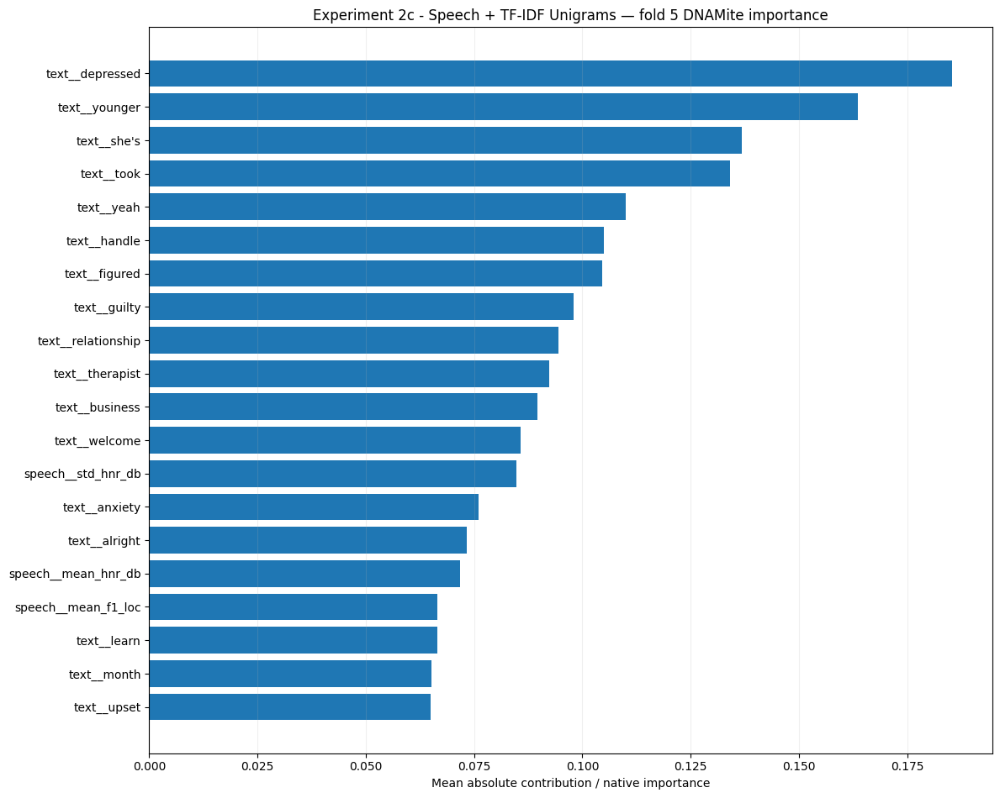

MAE               5.447860
RMSE              6.767804
R2               -0.447607
Spearman_Rho     -0.008275
Spearman_P        0.967326
Pearson_R        -0.112856
Pearson_P         0.575162
Exact_Accuracy    0.037037
Within_1          0.111111
Within_2          0.259259
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.720639,0.541649
RMSE,5.925862,0.968107
R2,-0.132237,0.231950
Spearman_Rho,0.075162,0.227249
Pearson_R,0.045221,0.260911
Exact_Accuracy,0.059259,0.049690
Within_1,0.170370,0.042229
Within_2,0.288889,0.048290
Within_3,0.451852,0.084457



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 2c
# Speech + TF-IDF Unigrams
# Regression Nested Cross-Validation
# ============================================================

EXPERIMENT_2C_NAME = (
    "Experiment 2c - Speech + TF-IDF Unigrams"
)


experiment_2c_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_2C_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 2c
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_2c_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_2c_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,MAE,RMSE,R2,Spearman_Rho,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,32,0.0005,32,16,2,4.080522,4.930900,0.123145,0.333131,...,0.518519,4.334362,5.267151,-0.000523,3.024790,3172.750000,16.518066,22.0,0.000091,3.569339e-07
1,2,4,0.0005,32,16,2,5.060062,7.104901,-0.293576,-0.095400,...,0.555556,4.996914,6.247201,-0.000108,1.282406,3115.656250,16.518066,22.0,0.000033,1.290358e-07
2,3,4,0.0010,16,16,2,4.627297,5.671324,-0.022390,-0.154814,...,0.444444,4.607339,5.614449,-0.001987,2.115352,3116.117188,16.518066,22.0,0.000060,2.375701e-07
3,4,16,0.0005,16,32,2,4.387454,5.154381,-0.020755,0.301166,...,0.370370,4.469822,5.104431,-0.001067,2.582853,3137.218750,16.518066,22.0,0.000078,3.056085e-07
4,5,4,0.0005,32,32,2,5.447860,6.767804,-0.447607,-0.008275,...,0.370370,4.728052,5.625067,-0.000024,11.824421,3383.617188,16.518066,22.0,0.000388,1.527303e-06



CV SUMMARY


,Mean,SD
MAE,4.720639,0.541649
RMSE,5.925862,0.968107
R2,-0.132237,0.231950
Spearman_Rho,0.075162,0.227249
Pearson_R,0.045221,0.260911
Exact_Accuracy,0.059259,0.049690
Within_1,0.170370,0.042229
Within_2,0.288889,0.048290
Within_3,0.451852,0.084457


In [ ]:
# ============================================================
# Experiment 2c
# Cross-Validation Performance
# ============================================================

experiment_2c_cv_metrics = (
    experiment_2c_regression_cv[
        "outer_results"
    ].copy()
)

experiment_2c_cv_summary = (
    experiment_2c_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_2c_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_2c_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,MAE,RMSE,R2,Spearman_Rho,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,32,0.0005,32,16,2,4.080522,4.930900,0.123145,0.333131,...,0.518519,4.334362,5.267151,-0.000523,3.024790,3172.750000,16.518066,22.0,0.000091,3.569339e-07
1,2,4,0.0005,32,16,2,5.060062,7.104901,-0.293576,-0.095400,...,0.555556,4.996914,6.247201,-0.000108,1.282406,3115.656250,16.518066,22.0,0.000033,1.290358e-07
2,3,4,0.0010,16,16,2,4.627297,5.671324,-0.022390,-0.154814,...,0.444444,4.607339,5.614449,-0.001987,2.115352,3116.117188,16.518066,22.0,0.000060,2.375701e-07
3,4,16,0.0005,16,32,2,4.387454,5.154381,-0.020755,0.301166,...,0.370370,4.469822,5.104431,-0.001067,2.582853,3137.218750,16.518066,22.0,0.000078,3.056085e-07
4,5,4,0.0005,32,32,2,5.447860,6.767804,-0.447607,-0.008275,...,0.370370,4.728052,5.625067,-0.000024,11.824421,3383.617188,16.518066,22.0,0.000388,1.527303e-06



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.720639,0.541649
RMSE,5.925862,0.968107
R2,-0.132237,0.231950
Spearman_Rho,0.075162,0.227249
Pearson_R,0.045221,0.260911
Exact_Accuracy,0.059259,0.049690
Within_1,0.170370,0.042229
Within_2,0.288889,0.048290
Within_3,0.451852,0.084457


In [ ]:
# ============================================================
# Experiment 2c
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_2c_parameters = (
    experiment_2c_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
        ]
    ]
    .copy()
)

display(
    experiment_2c_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers
0,1,32,0.0005,32,16,2
1,2,4,0.0005,32,16,2
2,3,4,0.0010,16,16,2
3,4,16,0.0005,16,32,2
4,5,4,0.0005,32,32,2



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2c_-_Speech_TF-IDF_Unigrams
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


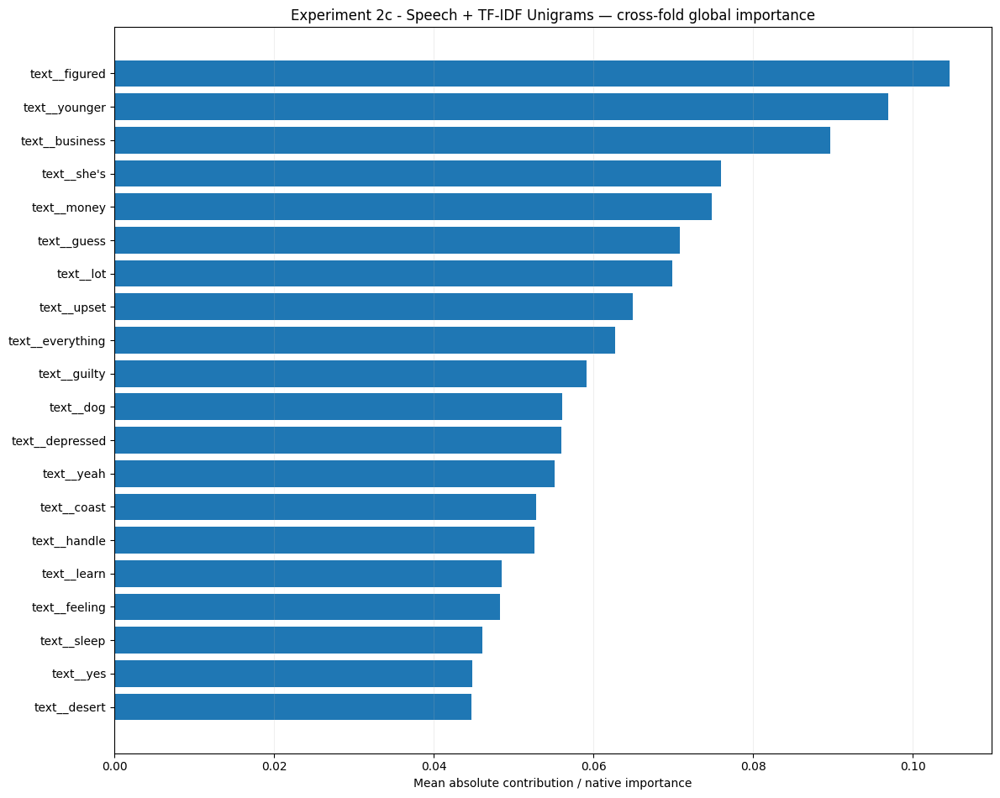

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2c_-_Speech_TF-IDF_Unigrams/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 2c
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams
# ============================================================

experiment_2c_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_2C_NAME
        ),
        top_k=30,
    )
)

experiment_2c_interpretability

In [ ]:
# ============================================================
# Experiment 2c
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_2c_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_2C_NAME)
)


experiment_2c_development_rows = []

for path in sorted(
    experiment_2c_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_2c_development_rows.append(
            json.load(file)
        )


experiment_2c_development_df = (
    pd.DataFrame(
        experiment_2c_development_rows
    )
)

display(
    experiment_2c_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 2c - Speech + TF-IDF Unigrams,regression,1,96,148.936379,0.004100,0.000016,3214.246094,16.518066,22.0
1,DNAMite Optimized,Experiment 2c - Speech + TF-IDF Unigrams,regression,2,96,208.591571,0.006142,0.000024,3177.671875,16.518066,22.0
2,DNAMite Optimized,Experiment 2c - Speech + TF-IDF Unigrams,regression,3,96,205.593058,0.006036,0.000024,3179.964844,16.518066,22.0
3,DNAMite Optimized,Experiment 2c - Speech + TF-IDF Unigrams,regression,4,96,196.047913,0.005732,0.000023,3165.031250,16.518066,22.0
4,DNAMite Optimized,Experiment 2c - Speech + TF-IDF Unigrams,regression,5,96,180.102308,0.005173,0.000020,3216.390625,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 2c
# Development Cost Summary
# ============================================================

experiment_2c_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_2c_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2c_development_df[
                    experiment_2c_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_2c_development_df[
                    experiment_2c_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2c_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_2c_development_summary[
            "Mean"
        ],
        experiment_2c_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_2c_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,96.000000,0.000000,96.000000 ± 0.000000
development_seconds,187.854246,24.426068,187.854246 ± 24.426068
development_energy_kwh,0.005437,0.000837,0.005437 ± 0.000837
development_co2_kg,0.000021,0.000003,0.000021 ± 0.000003


In [ ]:
# ============================================================
# Experiment 2c
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_2c_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_2c_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2c_regression_cv[
                    "outer_results"
                ][
                    experiment_2c_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_2c_regression_cv[
                    "outer_results"
                ][
                    experiment_2c_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2c_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_2c_training_summary[
            "Mean"
        ],
        experiment_2c_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_2c_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,4.165965e+00,4.329561e+00,4.16596463 ± 4.32956113
peak_ram_mb,3.185072e+03,1.133967e+02,3185.07187500 ± 113.39672528
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,1.298563e-04,1.458688e-04,0.00012986 ± 0.00014587
training_co2_kg,5.112902e-07,5.743372e-07,0.00000051 ± 0.00000057


### Experiment 2c final regression

In [ ]:
# ============================================================
# Experiment 2c
# Speech + TF-IDF Unigrams
# Final Regression Model
# ============================================================

EXPERIMENT_2C_NAME = (
    "Experiment 2c - Speech + TF-IDF Unigrams"
)

experiment_2c_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        text_development=(
            unigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        experiment_name=(
            EXPERIMENT_2C_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 107 / 107
DNAMite epochs | split=1 | ran=401 | best=371 | best val_loss=0.957320 | hit ceiling=False
  Inner fold 2/3
Selected 83 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 111 / 111
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.411368 | hit ceiling=False
  Inner fold 3/3
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
DNAMite active features | 107 / 107
DNAMite epochs | split=1 | ran=58 | best=28 | best val_loss=1.455234 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
Selected 79 TF-IDF features for regression / unigram

In [ ]:
# ============================================================
# Experiment 2c
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_2c_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,5.076773
RMSE,6.348446
R2,0.019323
Spearman_Rho,0.306637
Spearman_P,0.038200
Pearson_R,0.235860
Pearson_P,0.114563
Exact_Accuracy,0.021739
Within_1,0.173913
Within_2,0.347826


### Experiment 2c regression plots

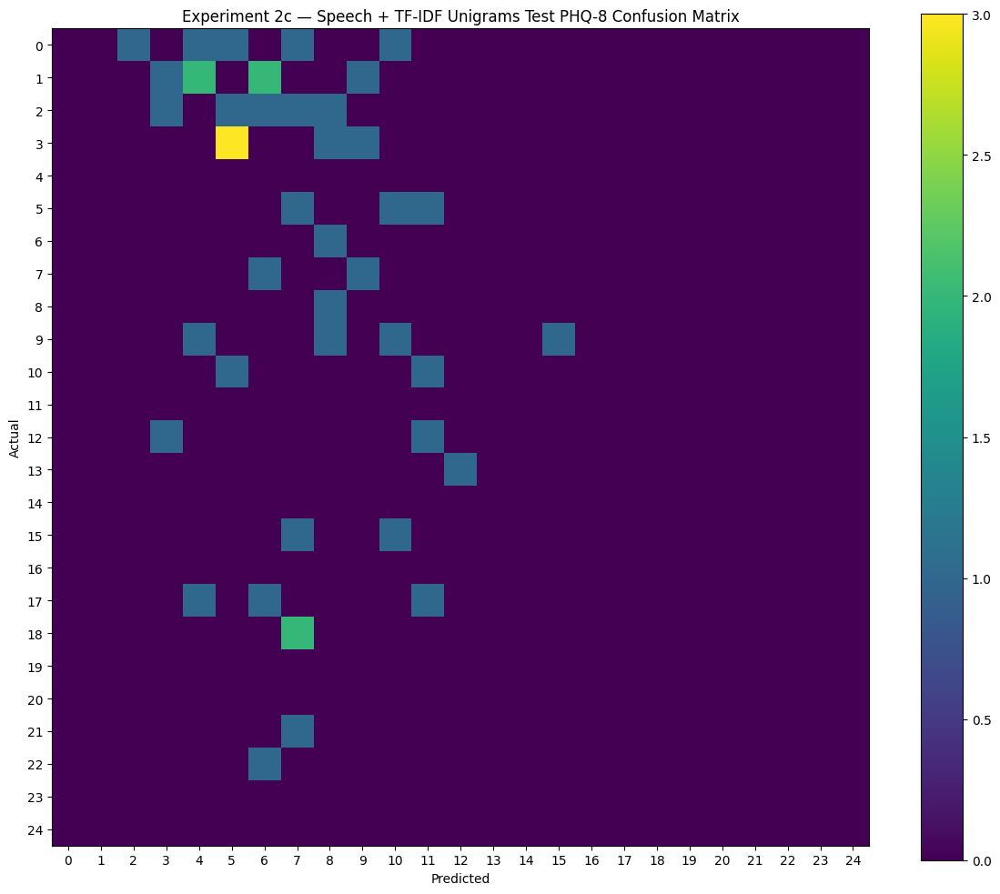

array([[0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 1, 2, 0, 2, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 3, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 2c
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_2c_regression_final[
                "test_rounded_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 2c — "
        "Speech + TF-IDF Unigrams "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

### Experiment 2c regression feature importance

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.055506,31
1,0,speech__articulation_rate,0.016002,31
2,0,speech__phonation_ratio,0.019863,31
3,0,speech__pause_rate,0.025931,31
4,0,speech__mean_pause_duration,0.023502,31
5,0,speech__mean_f0_hertz,0.015445,31
6,0,speech__std_f0_hertz,0.009656,31
7,0,speech__mean_intensity_db,0.003474,31
8,0,speech__std_intensity_db,0.016114,31
9,0,speech__range_ratio_intensity_db,0.019600,31


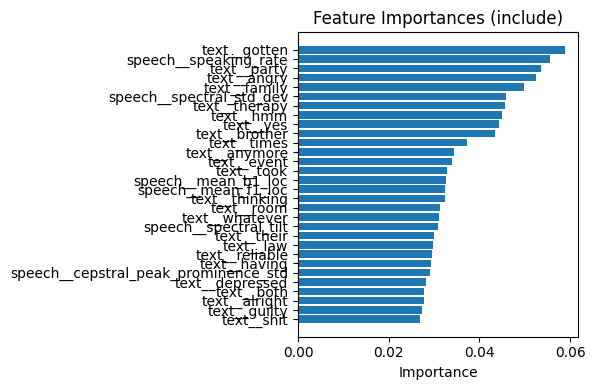

In [ ]:
# ============================================================
# Experiment 2c
# Final Model Feature Importance
# ============================================================

experiment_2c_regression_importance = (
    show_feature_importance(
        experiment_2c_regression_final[
            "model"
        ],
        top_n=30,
    )
)

### Experiment 2d Speech + TF-IDF Unigrams with Feature Selection

### Experiment 2d Nested CV

Using severity-stratified master regression folds.

Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 61 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 69 / 89
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__air', 'text__animals', 'text__annotation_sniff', 'text__birthday', 'text__brother', 'text__changing', "text__couldn't", 'text__diagnosed', 'text__different', 'text__disturbing', 'text__even', 't

[WARNING] Found selected features. Using only those features.


DNAMite active features | 85 / 93
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__acting', 'text__age', 'text__air', 'text__alright', 'text__also', 'text__am', 'text__animals', 'text__annotation_clears_throat', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__anno

...

DNAMite active features | 0 / 93
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.147026 | hit ceiling=False
  Inner fold 3/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 93
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.547714 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 16, 'learning_rate': np.float64(0.0005), 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Inner-fold selected features: (73, 77.0, 80)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_01.json
Best parameters: {'max_bins': 16, 'learning_rate': np.float64(0.0005), 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Selected 96 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 120 / 124
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__acting', 'text__ahead', 'text__air', 'text__animals', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__annotation_ss', 'text__annotation_w', 'text__anymore', 'text__anywhere', 'tex

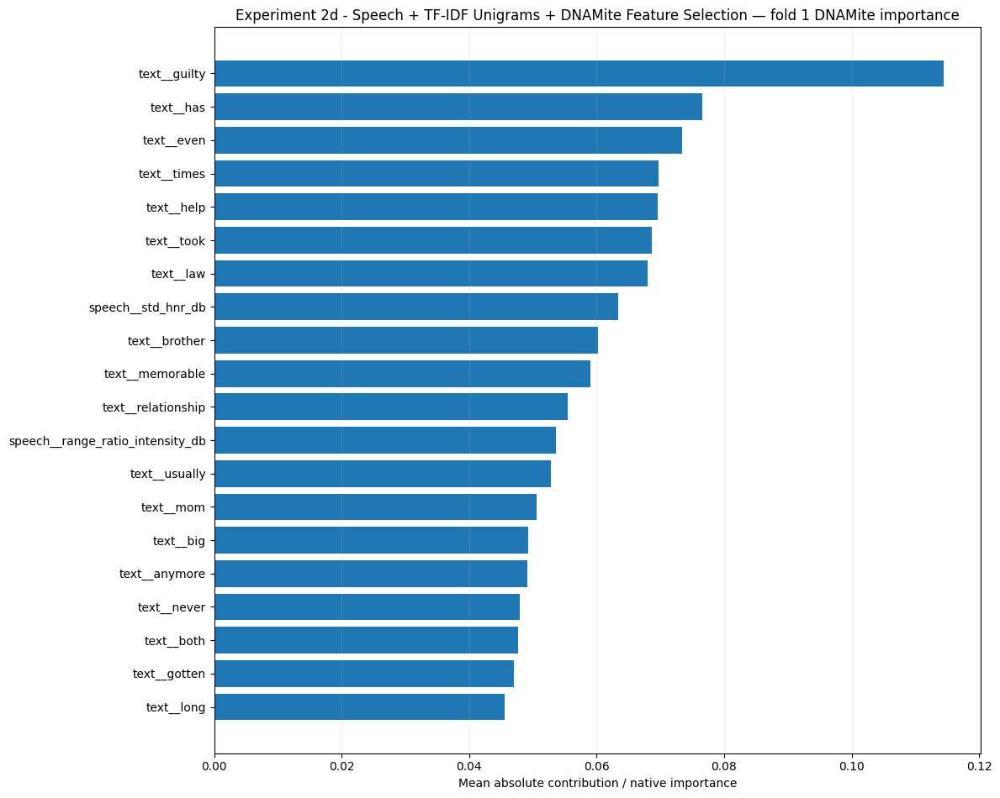

MAE               4.838598
RMSE              5.901678
R2               -0.256106
Spearman_Rho     -0.007348
Spearman_P        0.970981
Pearson_R        -0.045866
Pearson_P         0.820291
Exact_Accuracy    0.037037
Within_1          0.111111
Within_2          0.222222
Within_3          0.333333
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 81 / 93
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__air', 'text__angry', 'text__annotation_ss', 'text__asleep', 'text__behavior', 'text__brother', 'text__care', 'text__court', 'text__cry', 'text__dancing', 'text__decided', 'text__depressed', 'tex

[WARNING] Found selected features. Using only those features.


DNAMite active features | 82 / 88
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__alright', 'text__animals', 'text__annotation_sigh', 'text__annotation_sniff', 'text__annotation_tisk', 'text__answer', 'text__any', 'text__bad', 'text__birthday', 'text__caring', 'text__certain'

...

DNAMite active features | 0 / 88
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.904849 | hit ceiling=False
  Inner fold 3/3
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 94
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.035560 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 4, 'learning_rate': np.float64(0.001), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.05}
Inner-fold selected features: (18, 29.333333333333332, 38)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_02.json
Best parameters: {'max_bins': 4, 'learning_rate': np.float64(0.001), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.05}
Selected 100 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.05


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 128
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.555977 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.0531454860029044, 'peak_ram_mb': 3187.12890625, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_02.json
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_02.json
Saved outer-fold model to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_02/model_bundle.pkl

--- DNAMite interpretability export ---
Experiment: Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection

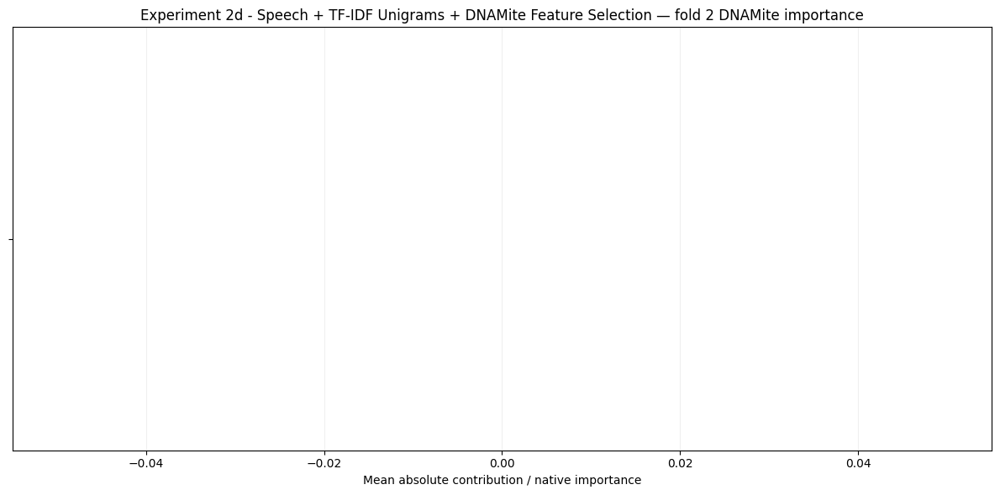

MAE               4.996914
RMSE              6.247201
R2               -0.000108
Spearman_Rho           NaN
Spearman_P             NaN
Pearson_R              NaN
Pearson_P              NaN
Exact_Accuracy    0.074074
Within_1          0.148148
Within_2          0.259259
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 85 / 91
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__air', 'text__alright', 'text__annotation_t', 'text__argued', 'text__basis', 'text__behavior', 'text__bike', 'text__books', 'text__boyfriend', 'text__brother', 'text__come', 'text__communication'

[WARNING] Found selected features. Using only those features.


DNAMite active features | 84 / 91
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__acting', 'text__air', 'text__alright', 'text__annoying', 'text__anything', 'text__anywhere', 'text__basically', 'text__become', 'text__better', 'text__brother', "text__can't", "text__couldn't", 

...

DNAMite active features | 0 / 91
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.850494 | hit ceiling=False
  Inner fold 3/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 91
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.704962 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
Inner-fold selected features: (77, 77.33333333333333, 78)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_03.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
Selected 102 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 127 / 130
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__acting', 'text__air', 'text__alright', 'text__anger', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__annotation_w', 'text__basically', 'text__basis', 'text__behavior', 'text__bet

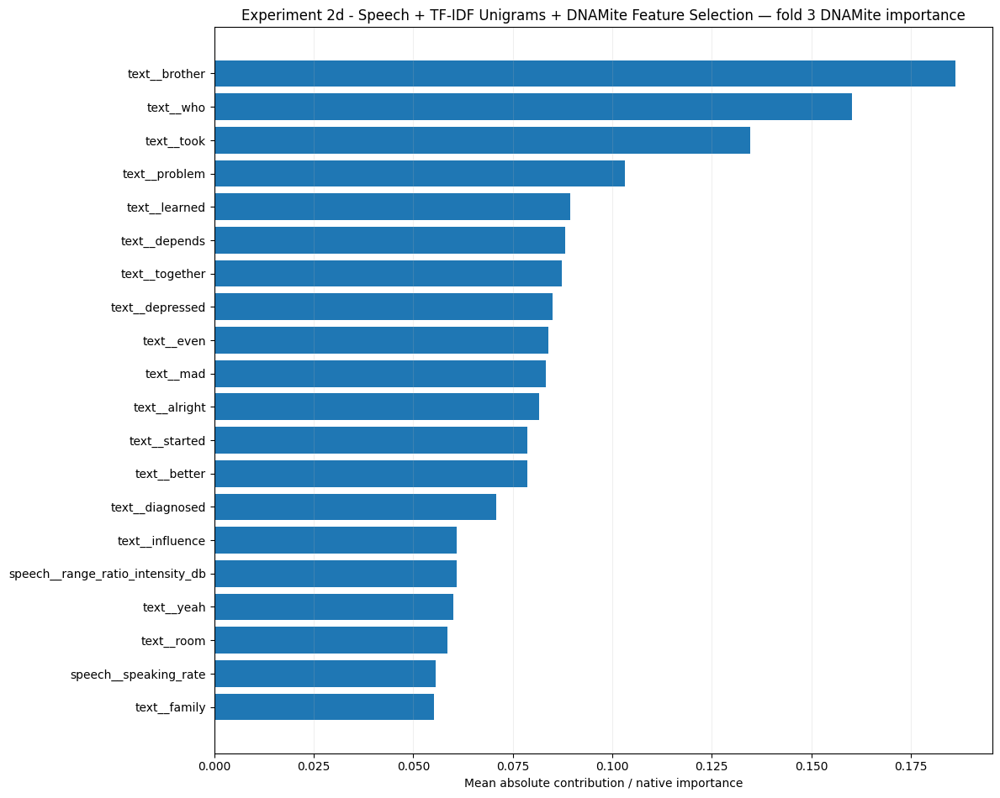

MAE               4.746336
RMSE              6.289204
R2               -0.257301
Spearman_Rho      0.175048
Spearman_P        0.382497
Pearson_R         0.098532
Pearson_P         0.624874
Exact_Accuracy    0.185185
Within_1          0.259259
Within_2          0.333333
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 85 / 91
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__accident', 'text__alright', 'text__amount', 'text__animals', 'text__annotation_sniff', 'text__annotation_w', 'text__anxiety', 'text__anymore', 'text__aunt', 'text__body', 'text__business', "text

[WARNING] Found selected features. Using only those features.


DNAMite active features | 81 / 96
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__air', 'text__alright', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__annoying', 'text__anxiety', 'text__arguing', 'text__art', 'text__arts', 'text__attacks', 'text__beautiful', 't

...

DNAMite active features | 13 / 96
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.665599 | hit ceiling=False
  Inner fold 3/3
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 94
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.684759 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Inner-fold selected features: (74, 77.0, 80)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_04.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Selected 89 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 110 / 117
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__accident', 'text__alright', 'text__angry', 'text__animals', 'text__annotation_sniff', 'text__annotation_synch', 'text__annotation_w', 'text__anxiety', 'text__art', 'text__arts', 'text__asleep'

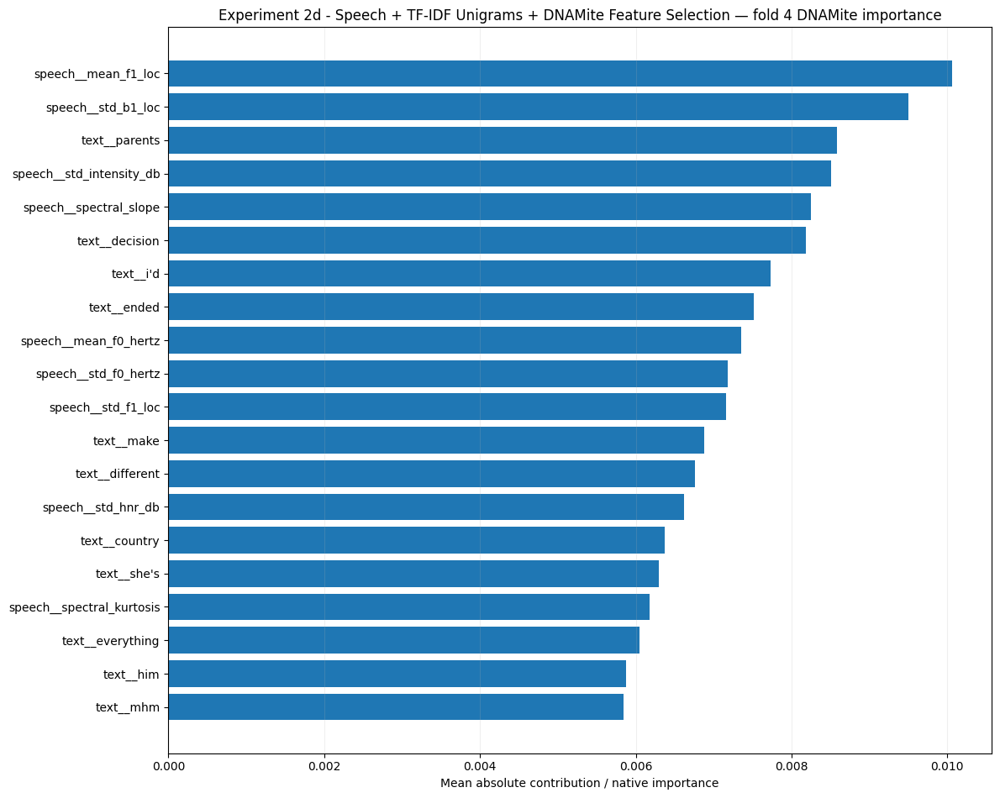

MAE               4.586200
RMSE              5.761693
R2               -0.275466
Spearman_Rho      0.088542
Spearman_P        0.660536
Pearson_R         0.046202
Pearson_P         0.818999
Exact_Accuracy    0.074074
Within_1          0.185185
Within_2          0.333333
Within_3          0.518519
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 2d - Speech + TF-IDF Unigrams + DNAMite Feature Selection | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 83 / 91
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__acting', 'text__alright', 'text__animals', 'text__annotation_sigh', 'text__anxiety', 'text__apartment', 'text__around', 'text__attack', 'text__behavior', 'text__bike', 'text__birthday', 'text__b

[WARNING] Found selected features. Using only those features.


DNAMite active features | 81 / 88
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__agree', 'text__annotation_clears_throat', 'text__annotation_laughter', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__annotation_so', 'text__anyone', 'text__argue', 'text__attacks'

...

DNAMite active features | 0 / 88
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.817457 | hit ceiling=False
  Inner fold 3/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 91
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.361301 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.01}
Inner-fold selected features: (40, 42.666666666666664, 44)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_05.json
Best parameters: {'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.01}
Selected 95 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 5 / 123
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration']
DNAMite epochs | split=1 | ran=74 | best=44 | best val_loss=0.906437 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.722939008002868, 'peak_ram_mb': 3181.64453125, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_05.json
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_05.json
Saved outer-fold model to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/fold_05/model_

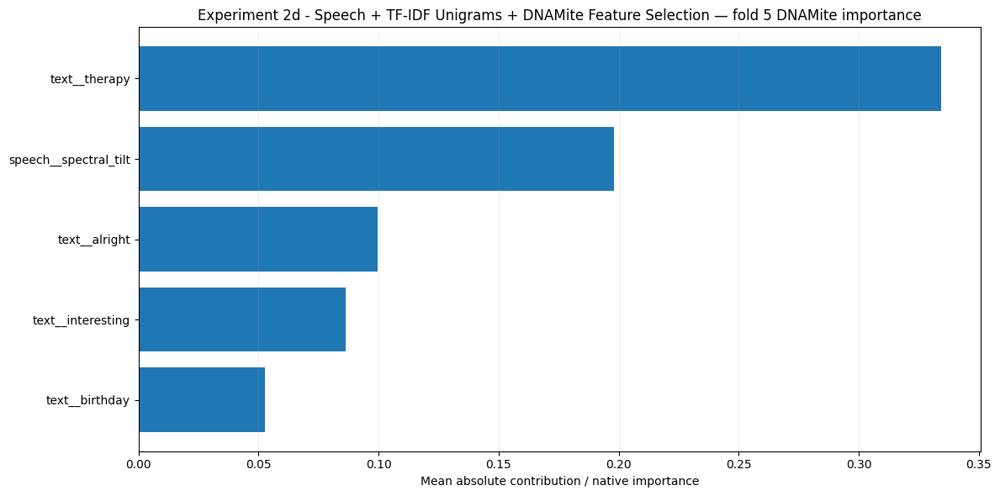

MAE               5.160666
RMSE              5.993449
R2               -0.135295
Spearman_Rho      0.050184
Spearman_P        0.803684
Pearson_R         0.149388
Pearson_P         0.457057
Exact_Accuracy    0.037037
Within_1          0.111111
Within_2          0.185185
Within_3          0.296296
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.865743,0.222106
RMSE,6.038645,0.225710
R2,-0.184855,0.117392
Spearman_Rho,0.076606,0.076550
Pearson_R,0.062064,0.083379
Exact_Accuracy,0.081481,0.060858
Within_1,0.162963,0.061975
Within_2,0.266667,0.066254
Within_3,0.392593,0.089197



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 2d
# Speech + TF-IDF Unigrams + DNAMite Feature Selection
# Regression Nested Cross-Validation
# ============================================================

EXPERIMENT_2D_NAME = (
    "NAM 2D - "
    "Speech + Unigrams - "
    "Regression Baseline"
)


experiment_2d_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_2D_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        use_feature_selection=True,
    )
)

### Experiment 2d Nested CV Results

In [ ]:
# ============================================================
# Experiment 2d
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_2d_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_2d_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,MAE,RMSE,R2,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,16,16,2,0.0005,4.838598,5.901678,-0.256106,...,0.333333,4.334362,5.267151,-0.000523,7.310020,3122.890625,16.518066,22.0,0.000236,9.273995e-07
1,2,4,0.0010,32,16,2,0.0500,4.996914,6.247201,-0.000108,...,0.370370,4.996914,6.247201,-0.000108,1.053145,3187.128906,16.518066,22.0,0.000026,1.033080e-07
2,3,8,0.0005,32,16,2,0.0001,4.746336,6.289204,-0.257301,...,0.444444,4.607339,5.614449,-0.001987,12.310070,3190.996094,16.518066,22.0,0.000403,1.585453e-06
3,4,8,0.0005,32,16,2,0.0005,4.586200,5.761693,-0.275466,...,0.518519,4.469822,5.104431,-0.001067,2.779949,3198.152344,16.518066,22.0,0.000084,3.301370e-07
4,5,32,0.0010,32,16,2,0.0100,5.160666,5.993449,-0.135295,...,0.296296,4.728052,5.625067,-0.000024,1.722939,3181.644531,16.518066,22.0,0.000048,1.883028e-07



CV SUMMARY


,Mean,SD
MAE,4.865743,0.222106
RMSE,6.038645,0.225710
R2,-0.184855,0.117392
Spearman_Rho,0.076606,0.076550
Pearson_R,0.062064,0.083379
Exact_Accuracy,0.081481,0.060858
Within_1,0.162963,0.061975
Within_2,0.266667,0.066254
Within_3,0.392593,0.089197


In [ ]:
# ============================================================
# Experiment 2d
# Cross-Validation Performance
# ============================================================

experiment_2d_cv_metrics = (
    experiment_2d_regression_cv[
        "outer_results"
    ].copy()
)

experiment_2d_cv_summary = (
    experiment_2d_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_2d_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_2d_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,MAE,RMSE,R2,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,16,16,2,0.0005,4.838598,5.901678,-0.256106,...,0.333333,4.334362,5.267151,-0.000523,7.310020,3122.890625,16.518066,22.0,0.000236,9.273995e-07
1,2,4,0.0010,32,16,2,0.0500,4.996914,6.247201,-0.000108,...,0.370370,4.996914,6.247201,-0.000108,1.053145,3187.128906,16.518066,22.0,0.000026,1.033080e-07
2,3,8,0.0005,32,16,2,0.0001,4.746336,6.289204,-0.257301,...,0.444444,4.607339,5.614449,-0.001987,12.310070,3190.996094,16.518066,22.0,0.000403,1.585453e-06
3,4,8,0.0005,32,16,2,0.0005,4.586200,5.761693,-0.275466,...,0.518519,4.469822,5.104431,-0.001067,2.779949,3198.152344,16.518066,22.0,0.000084,3.301370e-07
4,5,32,0.0010,32,16,2,0.0100,5.160666,5.993449,-0.135295,...,0.296296,4.728052,5.625067,-0.000024,1.722939,3181.644531,16.518066,22.0,0.000048,1.883028e-07



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.865743,0.222106
RMSE,6.038645,0.225710
R2,-0.184855,0.117392
Spearman_Rho,0.076606,0.076550
Pearson_R,0.062064,0.083379
Exact_Accuracy,0.081481,0.060858
Within_1,0.162963,0.061975
Within_2,0.266667,0.066254
Within_3,0.392593,0.089197


In [ ]:
# ============================================================
# Experiment 2d
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_2d_parameters = (
    experiment_2d_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "selection_reg_param",
        ]
    ]
    .copy()
)

display(
    experiment_2d_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param
0,1,16,0.0005,16,16,2,0.0005
1,2,4,0.0010,32,16,2,0.0500
2,3,8,0.0005,32,16,2,0.0001
3,4,8,0.0005,32,16,2,0.0005
4,5,32,0.0010,32,16,2,0.0100



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: False

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


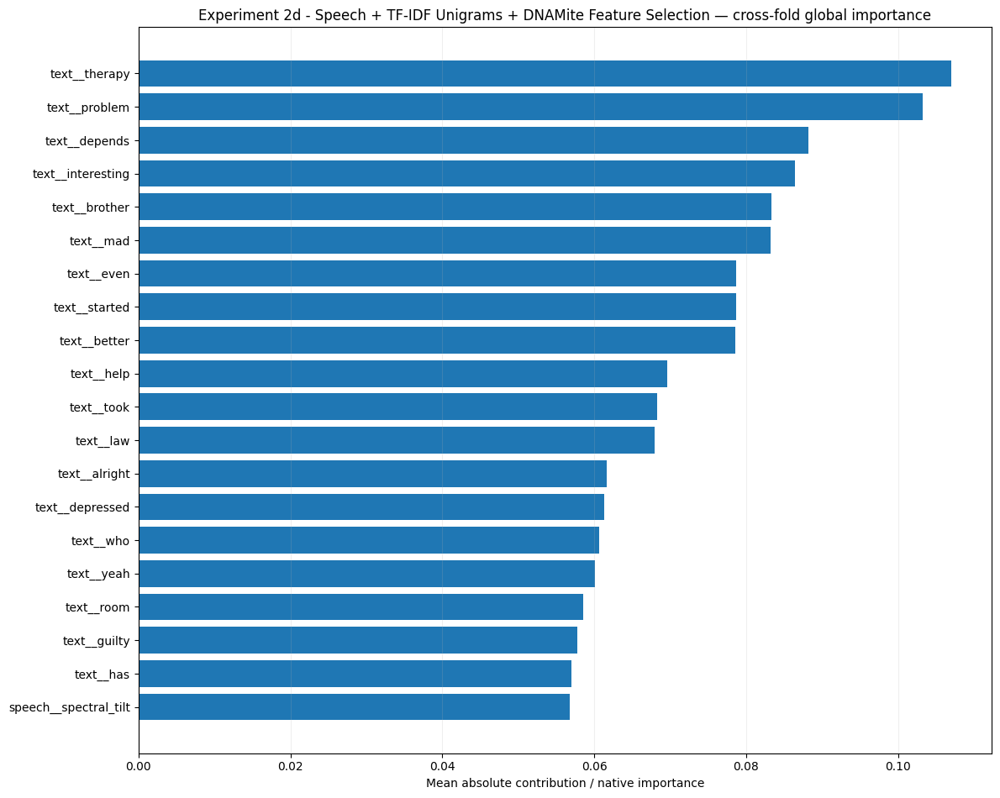

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite_Feature_Selection/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 2d
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams + Feature Selection
# ============================================================

experiment_2d_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_2D_NAME
        ),
        top_k=30,
    )
)

experiment_2d_interpretability

In [ ]:
# ============================================================
# Experiment 2d
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_2d_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_2D_NAME)
)


experiment_2d_development_rows = []

for path in sorted(
    experiment_2d_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_2d_development_rows.append(
            json.load(file)
        )


experiment_2d_development_df = (
    pd.DataFrame(
        experiment_2d_development_rows
    )
)

display(
    experiment_2d_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,regression,1,672,1251.436240,0.035985,0.000142,3223.167969,16.518066,22.0
1,DNAMite Optimized,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,regression,2,672,1578.195228,0.047159,0.000186,3188.046875,16.518066,22.0
2,DNAMite Optimized,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,regression,3,672,1640.035393,0.049317,0.000194,3189.464844,16.518066,22.0
3,DNAMite Optimized,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,regression,4,672,1474.219976,0.043549,0.000171,3230.750000,16.518066,22.0
4,DNAMite Optimized,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,regression,5,672,1464.661610,0.043286,0.000170,3189.671875,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 2d
# Development Cost Summary
# ============================================================

experiment_2d_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_2d_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2d_development_df[
                    experiment_2d_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_2d_development_df[
                    experiment_2d_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2d_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_2d_development_summary[
            "Mean"
        ],
        experiment_2d_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_2d_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,672.000000,0.000000,672.000000 ± 0.000000
development_seconds,1481.709689,148.112357,1481.709689 ± 148.112357
development_energy_kwh,0.043859,0.005077,0.043859 ± 0.005077
development_co2_kg,0.000173,0.000020,0.000173 ± 0.000020


In [ ]:
# ============================================================
# Experiment 2d
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_2d_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_2d_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2d_regression_cv[
                    "outer_results"
                ][
                    experiment_2d_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_2d_regression_cv[
                    "outer_results"
                ][
                    experiment_2d_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2d_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_2d_training_summary[
            "Mean"
        ],
        experiment_2d_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_2d_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,5.035225e+00,4.743747e+00,5.03522458 ± 4.74374668
peak_ram_mb,3.176162e+03,3.038008e+01,3176.16250000 ± 30.38007624
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,1.592237e-04,1.587974e-04,0.00015922 ± 0.00015880
training_co2_kg,6.269201e-07,6.252416e-07,0.00000063 ± 0.00000063


### Experiment 2d Final Model

In [ ]:
# ============================================================
# Experiment 2d
# Speech + TF-IDF Unigrams + DNAMite Feature Selection
# Final Regression Model
# ============================================================

EXPERIMENT_2D_NAME = (
    "NAM 2D - "
    "Speech + Unigrams - "
    "Regression Baseline"
)

experiment_2d_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        text_development=(
            unigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        experiment_name=(
            EXPERIMENT_2D_NAME
        ),
        use_feature_selection=True,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 101 / 107
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__alright', 'text__animals', 'text__asleep', 'text__basis', 'text__behavior', 'text__boy', 'text__broke', 'text__brother', 'text__brought', 'text__budget', 'text__caring', 'text__completely', 't

[WARNING] Found selected features. Using only those features.


DNAMite active features | 108 / 111
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__accomplish', 'text__air', 'text__already', 'text__alright', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__annotation_t', 'text__annotation_w', 'text__anywhere', 'text__asleep', 

...

DNAMite active features | 0 / 111
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.481104 | hit ceiling=False
  Inner fold 3/3
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 32 / 107
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__acting', 'text__afraid', 'text__air', 'text__angry']
DNAMite epochs | split=1 | ran=57 | best=27 | best val_loss=1.380925 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 

[WARNING] Found selected features. Using only those features.


Final DNAMite active features: 55 / 143
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__air', 'text__alright', 'text__angry', 'text__animals', 'text__annotation_sniff', 'text__annotation_sniffle', 'text__annotation_ss', 'text__annotation_w', 'text__anxiety', 'text__any', 'tex

In [ ]:
# ============================================================
# Experiment 2d
# Final Model Feature Selection
# ============================================================

print(
    "Selection reg param:",
    experiment_2d_regression_final[
        "selection_reg_param"
    ],
)

print(
    "Number of selected features:",
    len(
        experiment_2d_regression_final[
            "active_feature_names"
        ]
    ),
)


print("\nSelected features:")

experiment_2d_selected_features = (
    pd.DataFrame(
        {
            "Feature": (
                experiment_2d_regression_final[
                    "active_feature_names"
                ]
            )
        }
    )
)

display(
    experiment_2d_selected_features
)

Selection reg param: 0.001
Number of selected features: 55

Selected features:


,Feature
0,speech__speaking_rate
1,speech__articulation_rate
2,speech__phonation_ratio
3,speech__pause_rate
4,speech__mean_pause_duration
5,speech__mean_f0_hertz
6,speech__std_f0_hertz
7,speech__mean_intensity_db
8,speech__std_intensity_db
9,speech__range_ratio_intensity_db


In [ ]:
# ============================================================
# Experiment 2d
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_2d_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,5.114729
RMSE,6.177809
R2,0.071333
Spearman_Rho,0.349903
Spearman_P,0.017137
Pearson_R,0.321947
Pearson_P,0.029116
Exact_Accuracy,0.021739
Within_1,0.173913
Within_2,0.217391


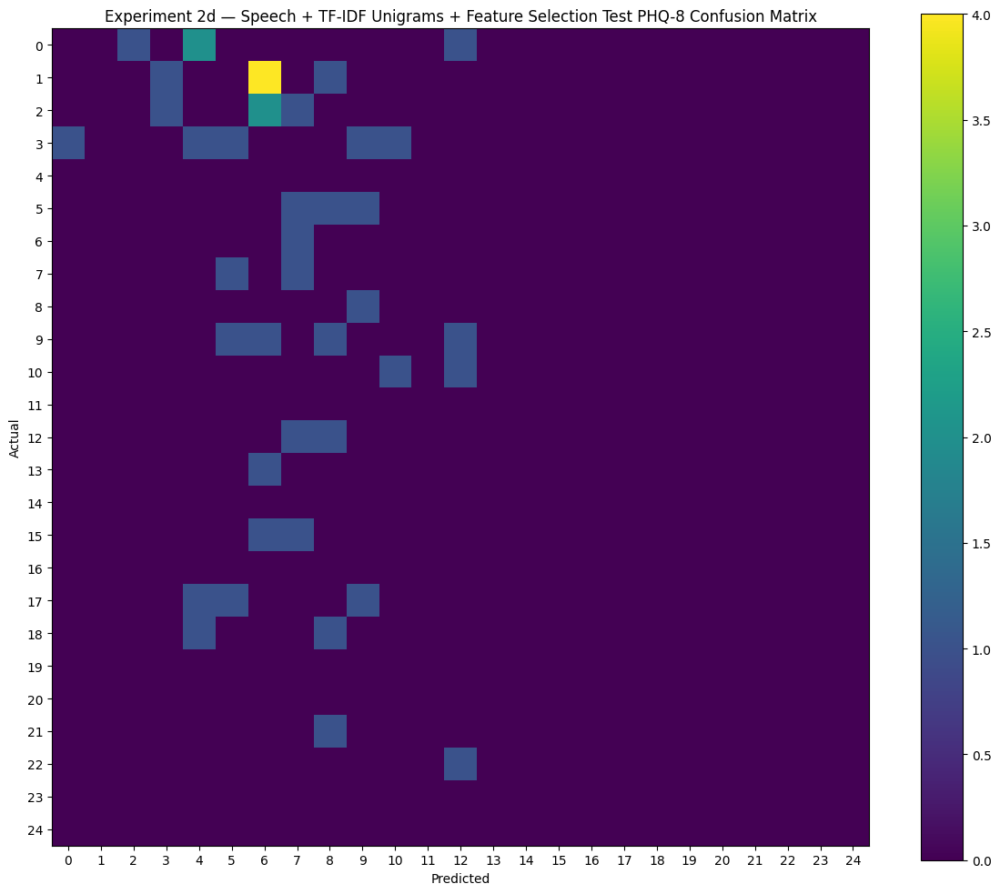

array([[0, 0, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 1, 0, 0, 4, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 2d
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_2d_regression_final[
                "test_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 2d — "
        "Speech + TF-IDF Unigrams + "
        "Feature Selection "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

,split,feature,importance,n_bins
0,0,speech__std_f0_hertz,0.010040,7
1,0,speech__std_intensity_db,0.004858,7
2,0,speech__std_hnr_db,0.025895,7
3,0,speech__cepstral_peak_prominence_mean,0.006032,7
4,0,speech__std_b1_loc,0.003748,7
5,0,speech__spectral_gravity,0.018472,7
6,0,speech__spectral_std_dev,0.028097,7
7,0,speech__spectral_kurtosis,0.026604,7
8,0,text__air,0.015892,7
9,0,text__alright,0.052049,7


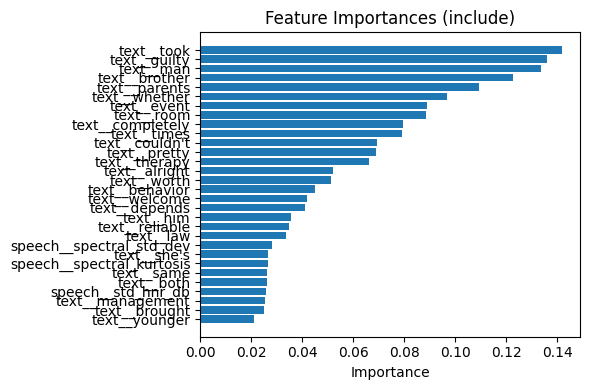

In [ ]:
# ============================================================
# Experiment 2d
# Final Model Feature Importance
# ============================================================

experiment_2d_regression_importance = (
    show_feature_importance(
        experiment_2d_regression_final[
            "model"
        ],
        top_n=30,
    )
)

### Compare 2c vs. 2d Test Comparison

In [ ]:
# ============================================================
# EXPERIMENT 2C VS 2D — TEST COMPARISON
# ============================================================

experiment_2c_vs_2d_regression_test = (
    pd.DataFrame(
        {
            "Experiment 2c - No DNAMite Selection": (
                experiment_2c_regression_final[
                    "test_metrics"
                ]
            ),

            "Experiment 2d - DNAMite Selection": (
                experiment_2d_regression_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_2c_vs_2d_regression_test
)

,Experiment 2c - No DNAMite Selection,Experiment 2d - DNAMite Selection
MAE,5.076773,5.114729
RMSE,6.348446,6.177809
R2,0.019323,0.071333
Spearman_Rho,0.306637,0.349903
Spearman_P,0.038200,0.017137
Pearson_R,0.235860,0.321947
Pearson_P,0.114563,0.029116
Exact_Accuracy,0.021739,0.021739
Within_1,0.173913,0.173913
Within_2,0.347826,0.217391


### Compare 2c vs. 2d Nested CV Comparison

In [ ]:
# ============================================================
# EXPERIMENT 2C VS 2D — CV COMPARISON
# Mean ± SD Across Outer Folds
# ============================================================

experiment_2c_vs_2d_regression_cv = (
    pd.DataFrame(
        {
            "Experiment 2c - No DNAMite Selection": (
                experiment_2c_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 2d - DNAMite Selection": (
                experiment_2d_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_2c_vs_2d_regression_cv
)

,Experiment 2c - No DNAMite Selection,Experiment 2d - DNAMite Selection
MAE,4.7206 ± 0.5416,4.8657 ± 0.2221
RMSE,5.9259 ± 0.9681,6.0386 ± 0.2257
R2,-0.1322 ± 0.2320,-0.1849 ± 0.1174
Spearman_Rho,0.0752 ± 0.2272,0.0766 ± 0.0765
Pearson_R,0.0452 ± 0.2609,0.0621 ± 0.0834
Exact_Accuracy,0.0593 ± 0.0497,0.0815 ± 0.0609
Within_1,0.1704 ± 0.0422,0.1630 ± 0.0620
Within_2,0.2889 ± 0.0483,0.2667 ± 0.0663
Within_3,0.4519 ± 0.0845,0.3926 ± 0.0892


### Experiment 2e with BCE


Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE | Classification | Outer fold 1
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.582829 | hit ceiling=False
Selected 13 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 41 / 41
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.547099 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=33 | best=3 | best val_loss=0.635285 | hit ceiling=False
Selecte

,positive_class_multiplier,mean_score,sd_score
0,1.50,0.310464,0.032066
1,2.00,0.307817,0.029961
2,1.00,0.306865,0.033823
3,1.25,0.306820,0.033655


Best imbalance parameters: {'positive_class_multiplier': 1.5} mean inner PR-AUC: 0.31046411561068105
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.5}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.50, final_pos_weight=3.4091
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.580788 | hit ceiling=False
  Inner fold 2/3
Selected 13 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.50, final_pos_weight=3.6429
DNAMite active features | 41 / 41
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.553128 | hit ceiling=False
  Inner fold 3/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, posi

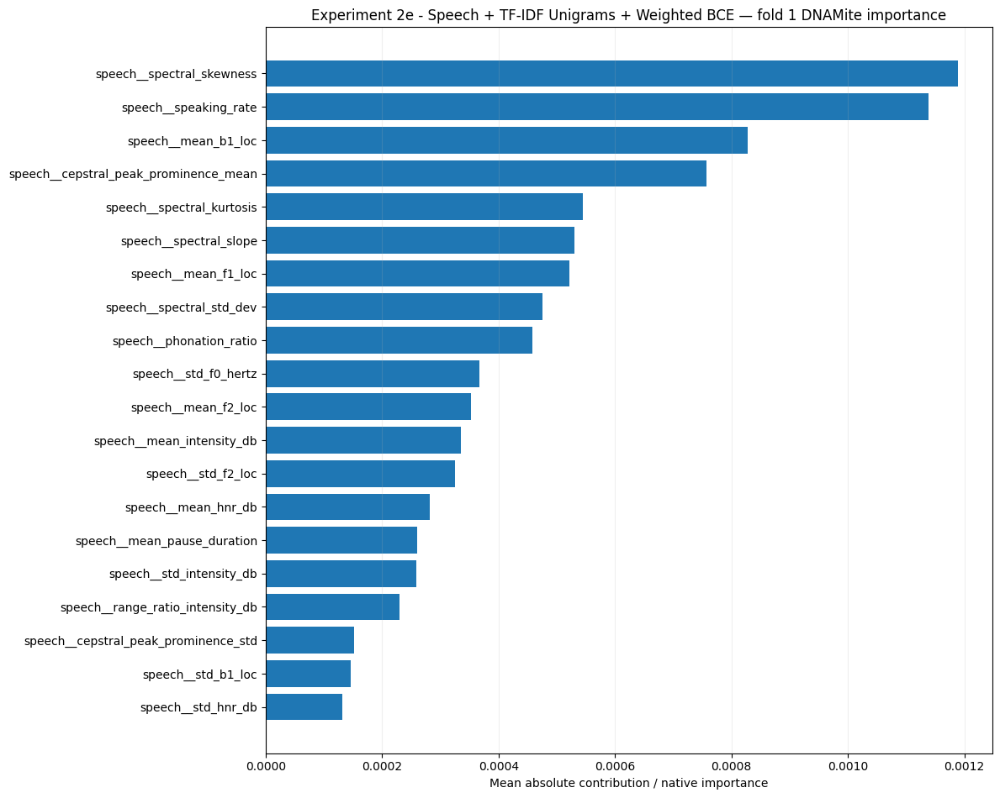

ROC_AUC              0.276316
PR_AUC               0.201674
AUPRC                0.201674
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208575
Log_Loss             0.607861
Threshold            0.285000
dtype: float64

Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE | Classification | Outer fold 2
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.577290 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 29 / 29
DNAMite epochs | split

,positive_class_multiplier,mean_score,sd_score
0,2.00,0.458797,0.140932
1,1.50,0.431728,0.169635
2,1.25,0.431216,0.170804
3,1.00,0.427796,0.169358


Best imbalance parameters: {'positive_class_multiplier': 2.0} mean inner PR-AUC: 0.4587967879839215
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 2.0}
  Inner fold 1/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=2.00, final_pos_weight=4.5455
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.580153 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=2.00, final_pos_weight=4.8571
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.636030 | hit ceiling=False
  Inner fold 3/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, positi

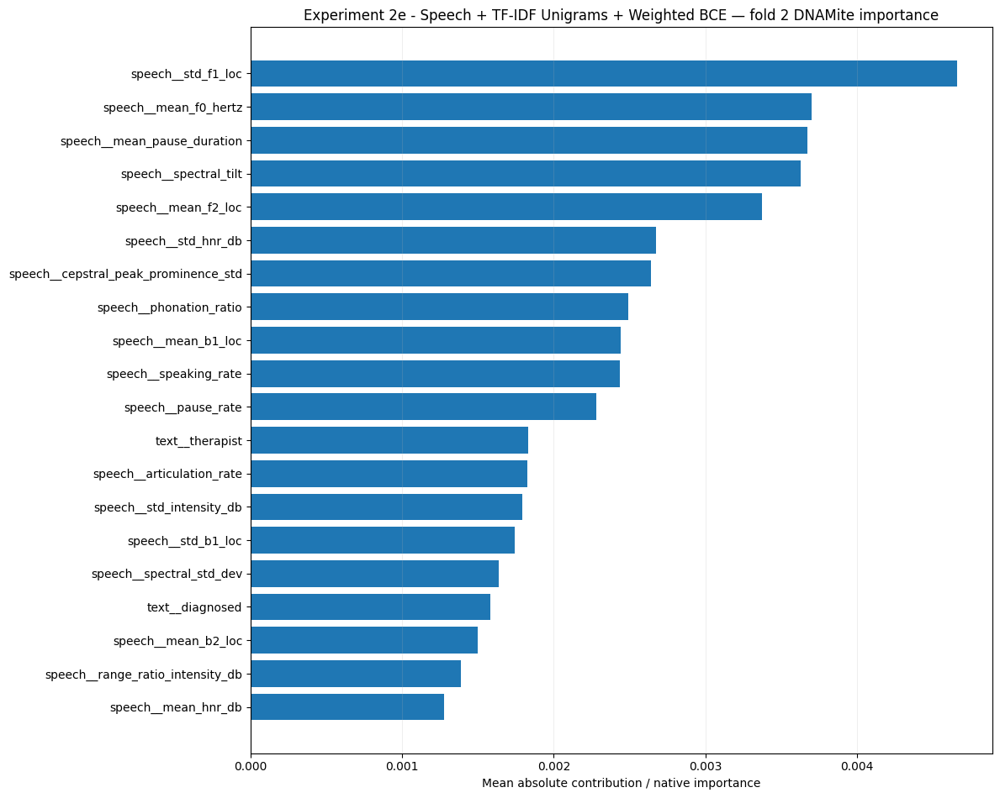

ROC_AUC              0.361842
PR_AUC               0.332806
AUPRC                0.332806
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208680
Log_Loss             0.608107
Threshold            0.300000
dtype: float64

Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE | Classification | Outer fold 3
Selected 11 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 39 / 39
DNAMite epochs | split=1 | ran=96 | best=66 | best val_loss=0.602944 | hit ceiling=False
Selected 14 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 42 / 42
DNAMite epochs | sp

,positive_class_multiplier,mean_score,sd_score
0,1.25,0.385589,0.092451
1,1.50,0.370897,0.080840
2,2.00,0.366820,0.079135
3,1.00,0.333496,0.129443


Best imbalance parameters: {'positive_class_multiplier': 1.25} mean inner PR-AUC: 0.38558864370588414
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.25}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.25, final_pos_weight=2.8409
DNAMite active features | 39 / 39
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.648971 | hit ceiling=False
  Inner fold 2/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.25, final_pos_weight=3.0357
DNAMite active features | 42 / 42
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.643953 | hit ceiling=False
  Inner fold 3/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, 

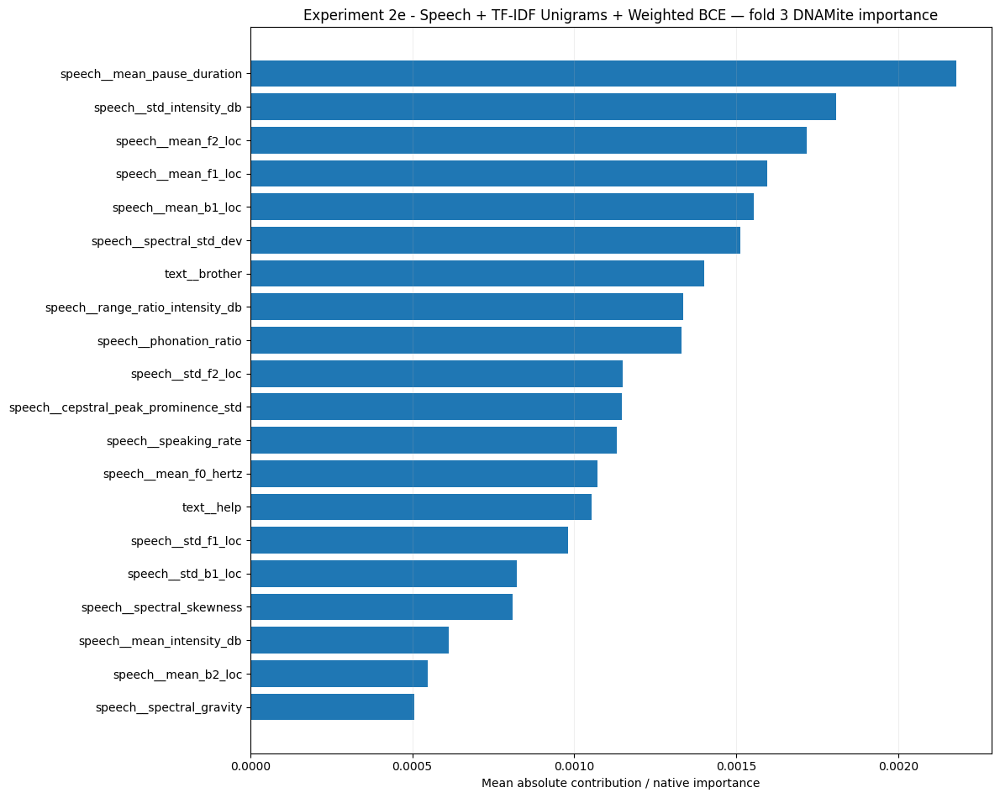

ROC_AUC              0.526316
PR_AUC               0.396272
AUPRC                0.396272
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208600
Log_Loss             0.607924
Threshold            0.295000
dtype: float64

Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE | Classification | Outer fold 4
Selected 2 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.592061 | hit ceiling=False
Selected 14 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 42 / 42
DNAMite epochs | spli

,positive_class_multiplier,mean_score,sd_score
0,1.00,0.329788,0.145904
1,1.25,0.258566,0.043124
2,1.50,0.257765,0.042065
3,2.00,0.257478,0.041692


Best imbalance parameters: {'positive_class_multiplier': 1.0} mean inner PR-AUC: 0.3297884654881045
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.0}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.589861 | hit ceiling=False
  Inner fold 2/3
Selected 14 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 42 / 42
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.612812 | hit ceiling=False
  Inner fold 3/3
Selected 13 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=51, posi

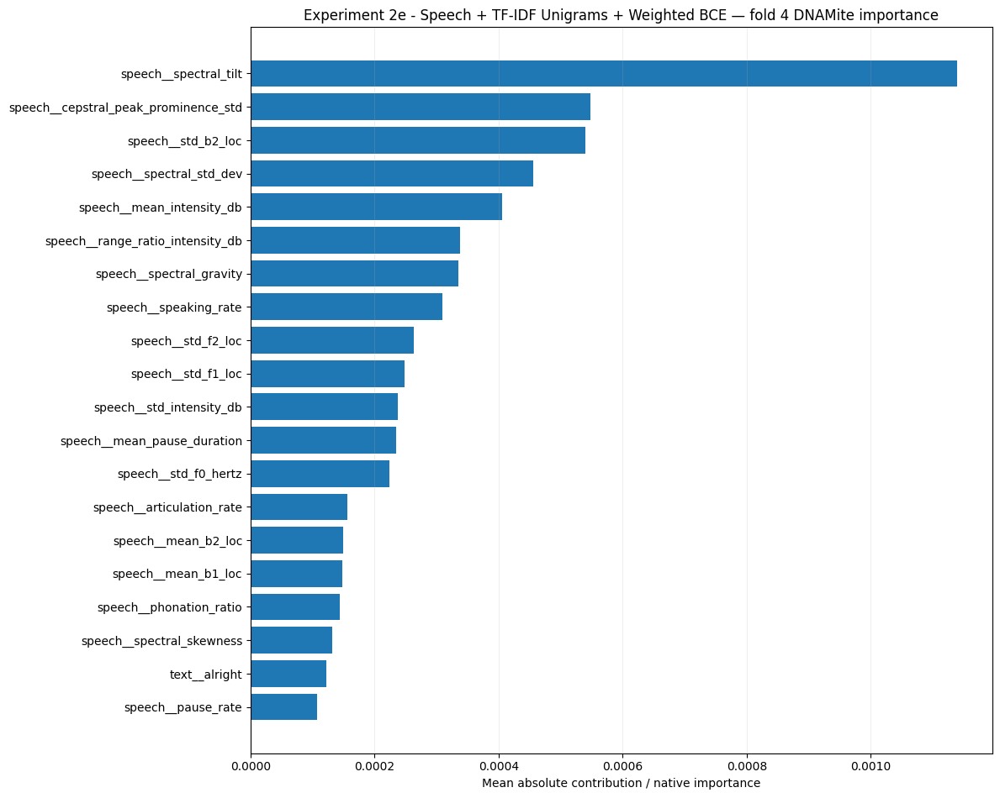

ROC_AUC              0.750000
PR_AUC               0.708592
AUPRC                0.708592
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208504
Log_Loss             0.607692
Threshold            0.050000
dtype: float64

Experiment 2e - Speech + TF-IDF Unigrams + Weighted BCE | Classification | Outer fold 5
Selected 12 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 40 / 40
DNAMite epochs | split=1 | ran=500 | best=498 | best val_loss=0.270762 | hit ceiling=True
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 29 / 29
DNAMite epochs | sp

,positive_class_multiplier,mean_score,sd_score
0,2.00,0.296316,0.047327
1,1.50,0.292474,0.048433
2,1.25,0.277697,0.060117
3,1.00,0.276568,0.061052


Best imbalance parameters: {'positive_class_multiplier': 2.0} mean inner PR-AUC: 0.2963158176299743
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 2.0}
  Inner fold 1/3
Selected 12 TF-IDF features for classification / unigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=2.00, final_pos_weight=4.5455
DNAMite active features | 40 / 40
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.859389 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=2.00, final_pos_weight=4.8571
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.580822 | hit ceiling=False
  Inner fold 3/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=51, posit

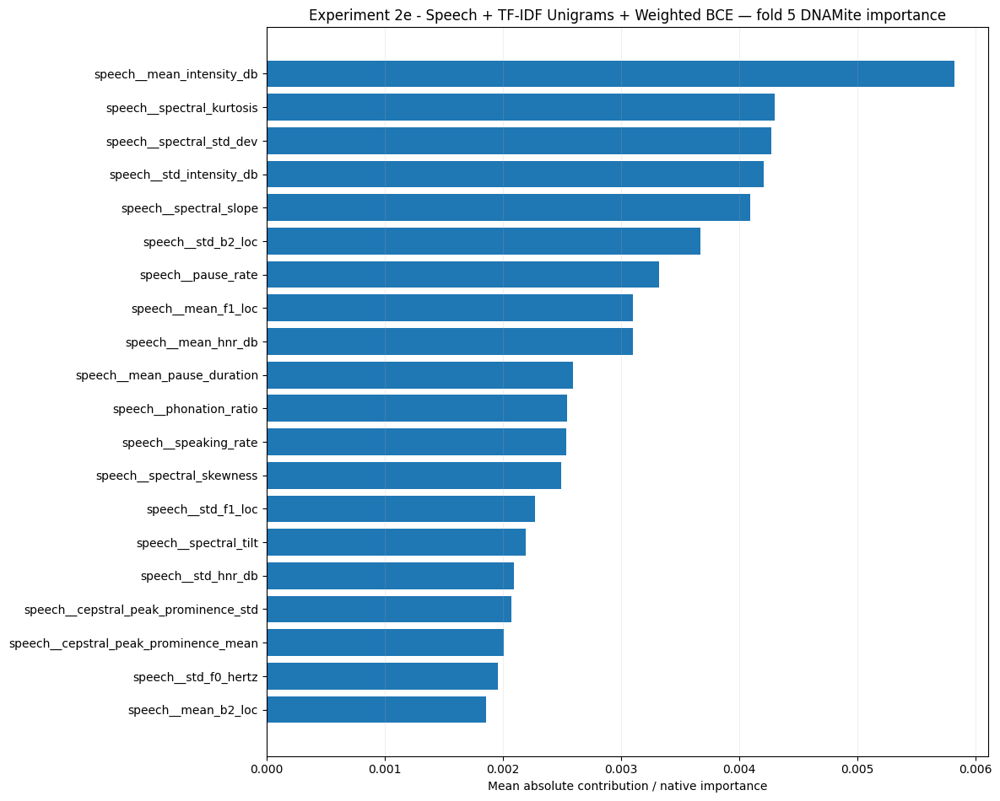

ROC_AUC              0.407895
PR_AUC               0.238417
AUPRC                0.238417
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208527
Log_Loss             0.607748
Threshold            0.305000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.464474,0.183363
PR_AUC,0.375552,0.201378
AUPRC,0.375552,0.201378
Accuracy,0.459259,0.223146
Balanced_Accuracy,0.500000,0.000000
Precision,0.177778,0.162288
Sensitivity,0.600000,0.547723
Specificity,0.400000,0.547723
F1,0.274286,0.250387
Brier_Score,0.208577,0.000069



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,False,None,29,29,"[speech__speaking_rate, speech__articulation_r..."
1,2,False,None,30,30,"[speech__speaking_rate, speech__articulation_r..."
2,3,False,None,31,31,"[speech__speaking_rate, speech__articulation_r..."
3,4,False,None,30,30,"[speech__speaking_rate, speech__articulation_r..."
4,5,False,None,29,29,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 2e
# Speech + TF-IDF Unigrams + Weighted BCE
# Classification Nested Cross-Validation
# ============================================================

EXPERIMENT_2E_NAME = (
    "Experiment 2e - "
    "Speech + TF-IDF Unigrams + Weighted BCE"
)


experiment_2e_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_2E_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        imbalance_strategy=(
            "weighted_bce"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 2e
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_2e_binary_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_2e_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier,feature_selection_enabled,selection_reg_param,n_features_available,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0005,32,16,2,1.50,False,None,29,...,0.457143,0.208575,0.607861,0.285,0.610117,3116.539062,16.518066,22.0,0.000011,4.202405e-08
1,2,8,0.0010,32,32,2,2.00,False,None,30,...,0.457143,0.208680,0.608107,0.300,0.716646,3159.062500,16.518066,22.0,0.000014,5.634289e-08
2,3,4,0.0010,32,16,2,1.25,False,None,31,...,0.000000,0.208600,0.607924,0.295,0.667541,3135.796875,16.518066,22.0,0.000014,5.347755e-08
3,4,4,0.0005,16,32,2,1.00,False,None,30,...,0.457143,0.208504,0.607692,0.050,0.628119,3268.496094,16.518066,22.0,0.000013,5.094161e-08
4,5,16,0.0010,32,32,2,2.00,False,None,29,...,0.000000,0.208527,0.607748,0.305,0.722955,3335.406250,16.518066,22.0,0.000014,5.461474e-08



CV SUMMARY


,Mean,SD
ROC_AUC,0.464474,0.183363
PR_AUC,0.375552,0.201378
AUPRC,0.375552,0.201378
Accuracy,0.459259,0.223146
Balanced_Accuracy,0.500000,0.000000
Precision,0.177778,0.162288
Sensitivity,0.600000,0.547723
Specificity,0.400000,0.547723
F1,0.274286,0.250387
Brier_Score,0.208577,0.000069


In [ ]:
# ============================================================
# Experiment 2e
# Cross-Validation Performance
# ============================================================

experiment_2e_cv_metrics = (
    experiment_2e_binary_cv[
        "outer_results"
    ].copy()
)

experiment_2e_cv_summary = (
    experiment_2e_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_2e_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_2e_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier,feature_selection_enabled,selection_reg_param,n_features_available,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0005,32,16,2,1.50,False,None,29,...,0.457143,0.208575,0.607861,0.285,0.610117,3116.539062,16.518066,22.0,0.000011,4.202405e-08
1,2,8,0.0010,32,32,2,2.00,False,None,30,...,0.457143,0.208680,0.608107,0.300,0.716646,3159.062500,16.518066,22.0,0.000014,5.634289e-08
2,3,4,0.0010,32,16,2,1.25,False,None,31,...,0.000000,0.208600,0.607924,0.295,0.667541,3135.796875,16.518066,22.0,0.000014,5.347755e-08
3,4,4,0.0005,16,32,2,1.00,False,None,30,...,0.457143,0.208504,0.607692,0.050,0.628119,3268.496094,16.518066,22.0,0.000013,5.094161e-08
4,5,16,0.0010,32,32,2,2.00,False,None,29,...,0.000000,0.208527,0.607748,0.305,0.722955,3335.406250,16.518066,22.0,0.000014,5.461474e-08



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.464474,0.183363
PR_AUC,0.375552,0.201378
AUPRC,0.375552,0.201378
Accuracy,0.459259,0.223146
Balanced_Accuracy,0.500000,0.000000
Precision,0.177778,0.162288
Sensitivity,0.600000,0.547723
Specificity,0.400000,0.547723
F1,0.274286,0.250387
Brier_Score,0.208577,0.000069


In [ ]:
# ============================================================
# Experiment 2e
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_2e_parameters = (
    experiment_2e_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "positive_class_multiplier",
        ]
    ]
    .copy()
)

display(
    experiment_2e_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier
0,1,4,0.0005,32,16,2,1.50
1,2,8,0.0010,32,32,2,2.00
2,3,4,0.0010,32,16,2,1.25
3,4,4,0.0005,16,32,2,1.00
4,5,16,0.0010,32,32,2,2.00



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2e_-_Speech_TF-IDF_Unigrams_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


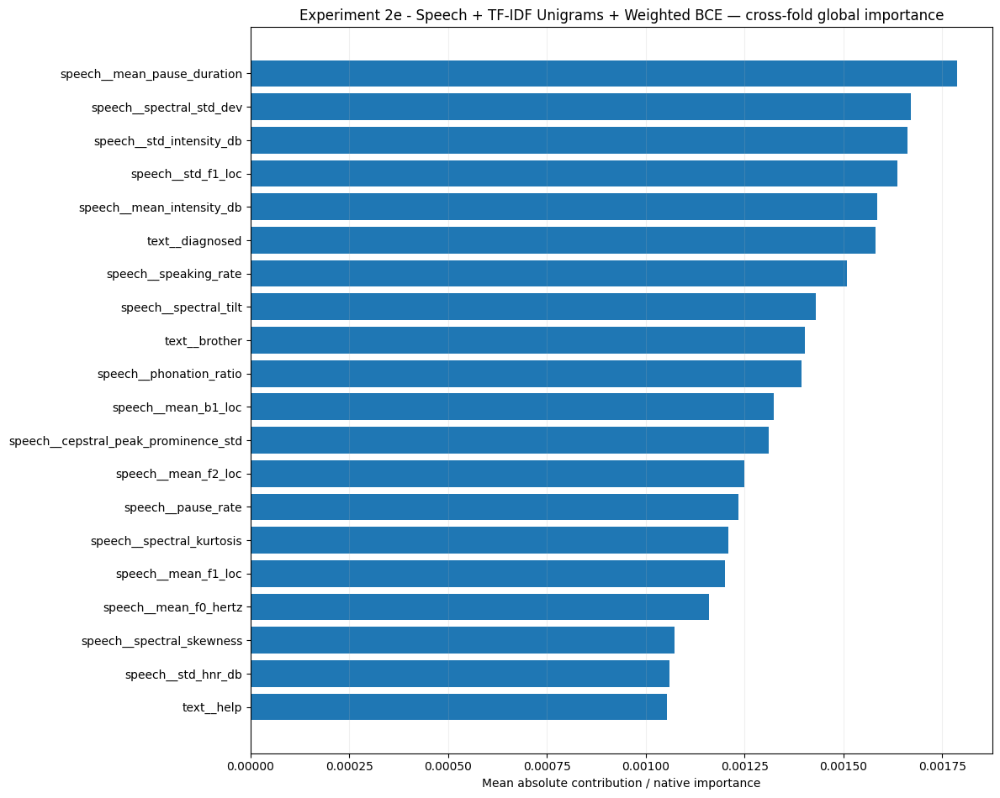

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2e_-_Speech_TF-IDF_Unigrams_Weighted_BCE/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 2e
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams + Weighted BCE
# ============================================================

experiment_2e_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_2E_NAME
        ),
        top_k=30,
    )
)

experiment_2e_interpretability

In [ ]:
# ============================================================
# Experiment 2e
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_2e_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_2E_NAME)
)


experiment_2e_development_rows = []

for path in sorted(
    experiment_2e_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_2e_development_rows.append(
            json.load(file)
        )


experiment_2e_development_df = (
    pd.DataFrame(
        experiment_2e_development_rows
    )
)

display(
    experiment_2e_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,classification,1,108,74.445901,0.001486,0.000006,3116.621094,16.518066,22.0
1,DNAMite Optimized,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,classification,2,108,75.561062,0.001532,0.000006,3159.121094,16.518066,22.0
2,DNAMite Optimized,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,classification,3,108,106.745187,0.002590,0.000010,3135.843750,16.518066,22.0
3,DNAMite Optimized,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,classification,4,108,88.404236,0.001976,0.000008,3268.519531,16.518066,22.0
4,DNAMite Optimized,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,classification,5,108,81.607112,0.001740,0.000007,3335.511719,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 2e
# Development Cost Summary
# ============================================================

experiment_2e_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_2e_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2e_development_df[
                    experiment_2e_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_2e_development_df[
                    experiment_2e_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2e_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_2e_development_summary[
            "Mean"
        ],
        experiment_2e_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_2e_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,108.000000,0.000000,108.000000 ± 0.000000
development_seconds,85.352700,13.189145,85.352700 ± 13.189145
development_energy_kwh,0.001865,0.000449,0.001865 ± 0.000449
development_co2_kg,0.000007,0.000002,0.000007 ± 0.000002


In [ ]:
# ============================================================
# Experiment 2e
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_2e_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_2e_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2e_binary_cv[
                    "outer_results"
                ][
                    experiment_2e_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_2e_binary_cv[
                    "outer_results"
                ][
                    experiment_2e_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2e_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_2e_training_summary[
            "Mean"
        ],
        experiment_2e_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_2e_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,6.690758e-01,5.079799e-02,0.66907579 ± 0.05079799
peak_ram_mb,3.203060e+03,9.452962e+01,3203.06015625 ± 94.52961556
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,1.307481e-05,1.432045e-06,0.00001307 ± 0.00000143
training_co2_kg,5.148017e-08,5.638469e-09,0.00000005 ± 0.00000001


In [ ]:
# ============================================================
# Experiment 2e
# Speech + TF-IDF Unigrams + Weighted BCE
# Final Classification Model
# ============================================================

EXPERIMENT_2E_NAME = (
    "Experiment 2e - "
    "Speech + TF-IDF Unigrams + Weighted BCE"
)

experiment_2e_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        text_development=(
            unigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        imbalance_strategy=(
            "weighted_bce"
        ),
        experiment_name=(
            EXPERIMENT_2E_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Selected 2 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.586647 | hit ceiling=False
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.539730 | hit ceiling=False
Selected 3 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=64, positive=26, automatic_pos_weight=2.4615, multiplier=1.00, final_pos_weight=2.4615
DNAMite active features | 31 / 31
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.633170 | hit ceiling=False
Selected 2 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=63, p

,positive_class_multiplier,mean_score,sd_score
0,1.00,0.273758,0.051384
1,1.25,0.272144,0.048589
2,1.50,0.271449,0.047385
3,2.00,0.269796,0.045678


Best imbalance parameters: {'positive_class_multiplier': 1.0} mean inner PR-AUC: 0.27375786899187604
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.0}
  Inner fold 1/3
Selected 2 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 30 / 30
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.597431 | hit ceiling=False
  Inner fold 2/3
Selected 1 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 29 / 29
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.540158 | hit ceiling=False
  Inner fold 3/3
Selected 3 TF-IDF features for classification / unigram using C=2.5
Weighted BCE | negative=64, posit

In [ ]:
# ============================================================
# Experiment 2e
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_2e_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.450893
PR_AUC,0.326662
AUPRC,0.326662
Accuracy,0.282609
Balanced_Accuracy,0.464286
Precision,0.288889
Sensitivity,0.928571
Specificity,0.000000
F1,0.440678
Brier_Score,0.211887


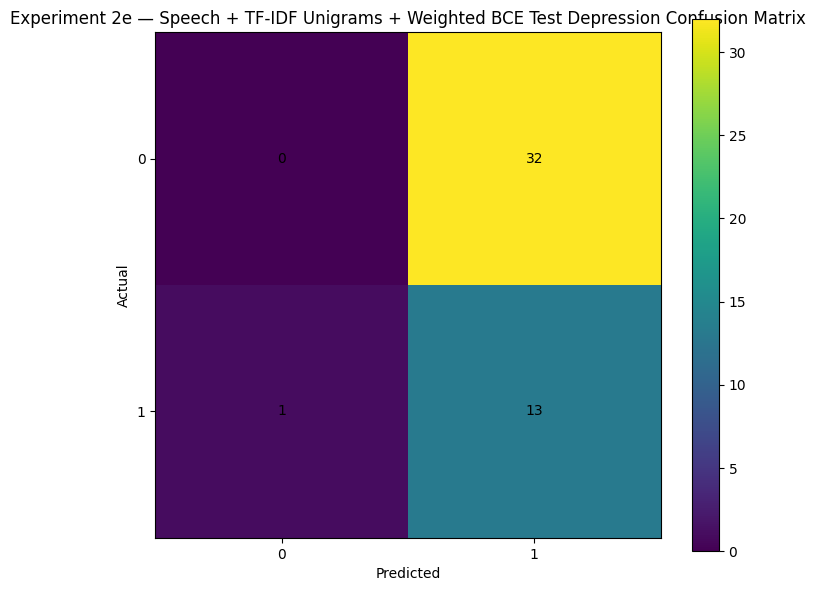

array([[ 0, 32],
       [ 1, 13]])

In [ ]:
# ============================================================
# Experiment 2e
# Final Test Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_2e_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 2e — "
        "Speech + TF-IDF Unigrams + "
        "Weighted BCE "
        "Test Depression Confusion Matrix"
    ),
)

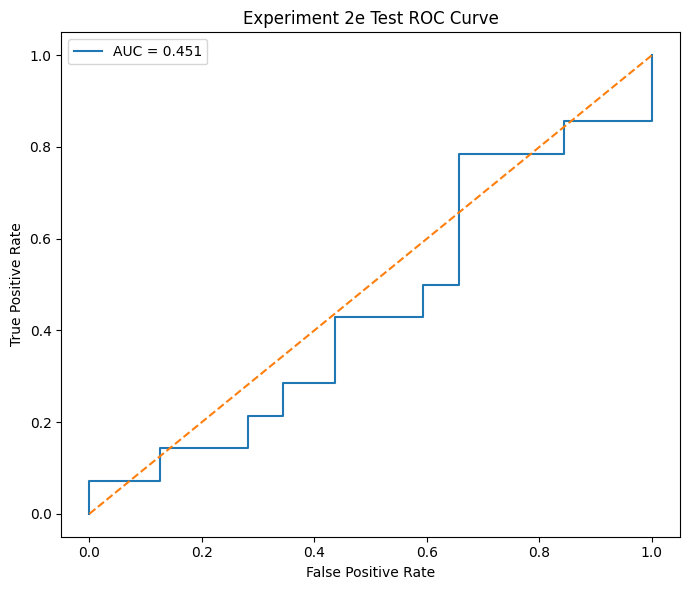

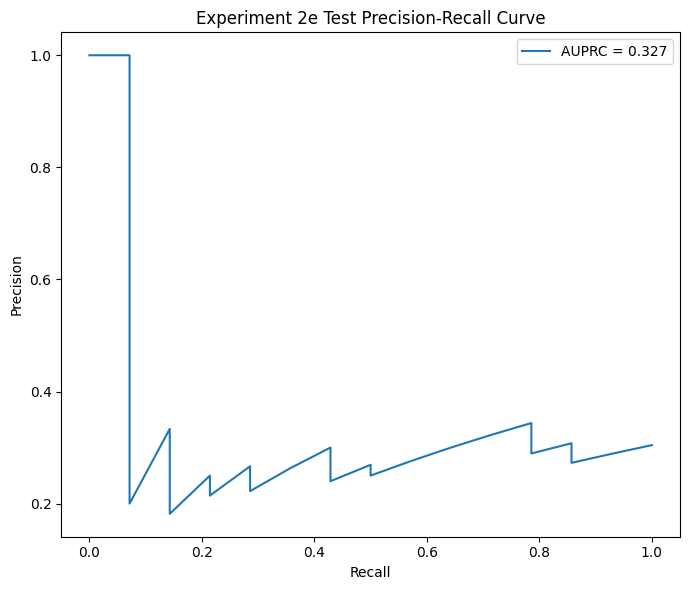

In [ ]:
# ============================================================
# Experiment 2e
# Final Test Classification Curves
# ============================================================

plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_2e_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 2e Test"
    ),
)

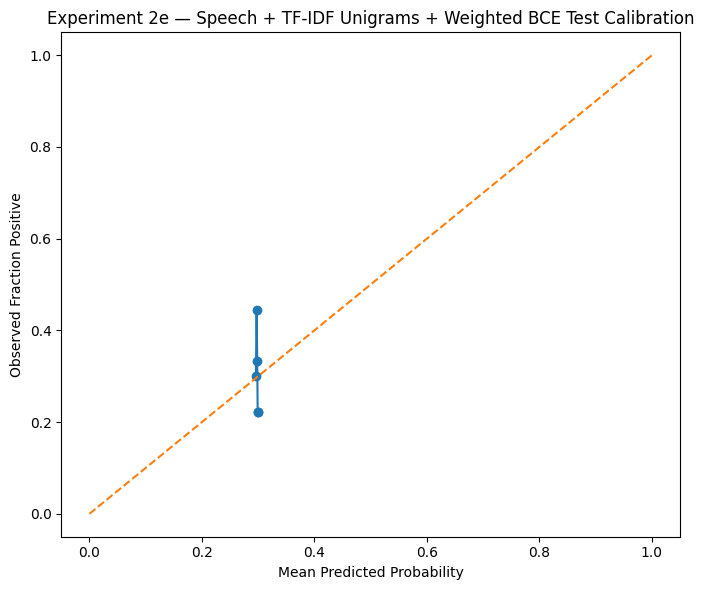

,mean_predicted_probability,observed_fraction_positive,n
0,0.295998,0.300000,10
1,0.297259,0.444444,9
2,0.298414,0.333333,9
3,0.299132,0.222222,9
4,0.299987,0.222222,9


In [ ]:
# ============================================================
# Experiment 2e
# Final Test Calibration
# ============================================================

plot_calibration_curve_manual(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_2e_binary_final[
            "test_probabilities"
        ]
    ),
    n_bins=5,
    title=(
        "Experiment 2e — "
        "Speech + TF-IDF Unigrams + "
        "Weighted BCE "
        "Test Calibration"
    ),
)

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.027671,15
1,0,speech__articulation_rate,0.086028,15
2,0,speech__phonation_ratio,0.019577,15
3,0,speech__pause_rate,0.043370,15
4,0,speech__mean_pause_duration,0.032319,15
5,0,speech__mean_f0_hertz,0.065239,15
6,0,speech__std_f0_hertz,0.028747,15
7,0,speech__mean_intensity_db,0.062760,15
8,0,speech__std_intensity_db,0.042920,15
9,0,speech__range_ratio_intensity_db,0.057899,15


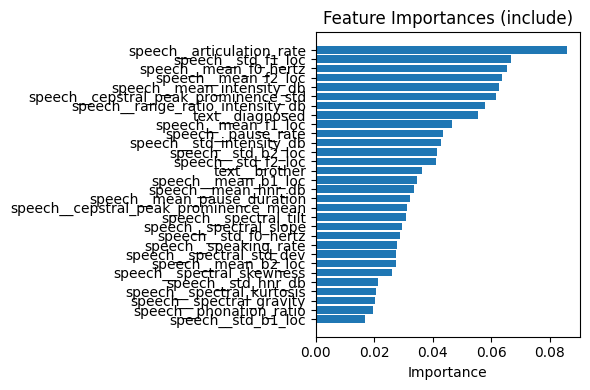

In [ ]:
# ============================================================
# Experiment 2e
# Final Model Feature Importance
# ============================================================

experiment_2e_binary_importance = (
    show_feature_importance(
        experiment_2e_binary_final[
            "model"
        ],
        top_n=30,
    )
)

### Experiment 2f with LDS

Using severity-stratified master regression folds.

Experiment 2f - Speech + TF-IDF Unigrams + LDS | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
Selected 61 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.660, 6.282)
DNAMite active features | 89 / 89
DNAMite epochs | split=1 | ran=66 | best=36 | best val_loss=0.724536 | hit ceiling=False
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.632, 2007.659)
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=145 | best=115 | best val_loss=0.540684 | hit ceiling=False
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.695, 6.210)
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.517977 | hit ceiling=False
Selected 61 TF-IDF fe

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,2.0,inverse,4.595816,0.553289
1,3.0,inverse,4.599246,0.550448
2,4.0,inverse,4.604250,0.546521
3,2.0,sqrt_inverse,4.608273,0.530236
4,3.0,sqrt_inverse,4.612728,0.529441
5,4.0,sqrt_inverse,4.614768,0.524134
6,1.0,sqrt_inverse,4.621232,0.509824
7,1.0,inverse,4.627599,0.510999
8,0.5,sqrt_inverse,4.645610,0.454126
9,0.5,inverse,4.652162,0.397849


Best imbalance parameters: {'lds_sigma': 2.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.595816190756156
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 2.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 61 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=inverse, weight range=(0.536, 11.749)
DNAMite active features | 89 / 89
DNAMite epochs | split=1 | ran=38 | best=8 | best val_loss=0.847123 | hit ceiling=False
  Inner fold 2/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=inverse, weight range=(0.585, 36.141)
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.067764 | hit ceiling=False
  Inner fold 3/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=inverse, weight range=(0.512, 13.467)
DNAMite active features | 

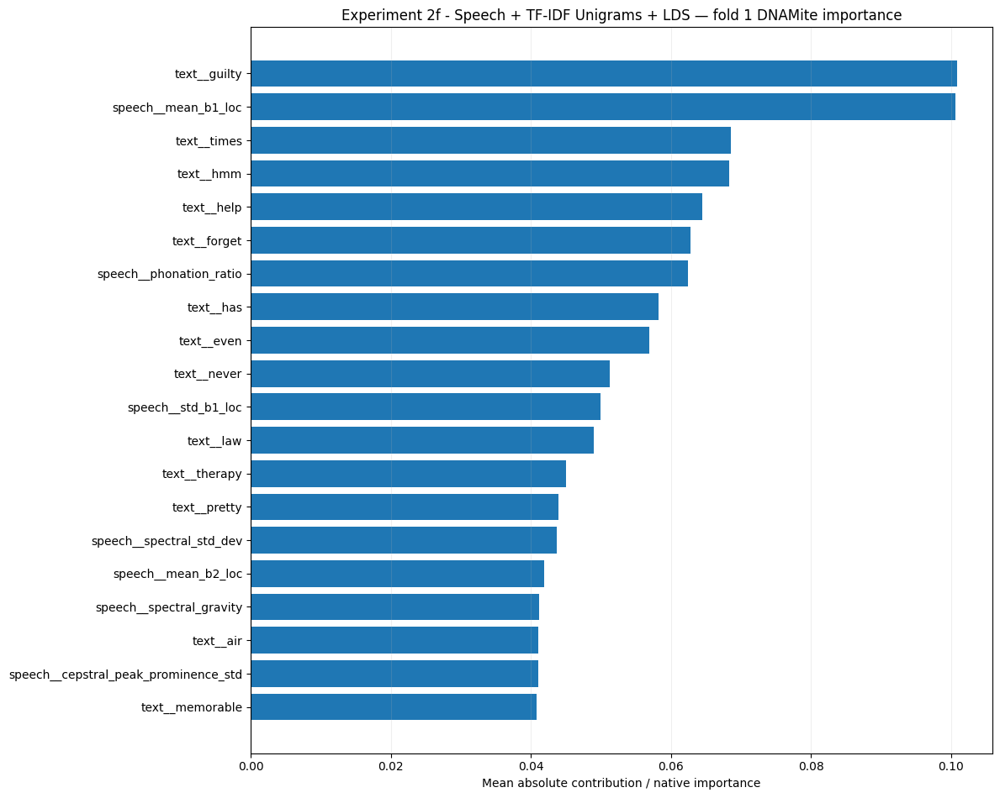

MAE               4.209122
RMSE              5.425217
R2               -0.061474
Spearman_Rho      0.161360
Spearman_P        0.421358
Pearson_R         0.149682
Pearson_P         0.456161
Exact_Accuracy    0.000000
Within_1          0.259259
Within_2          0.370370
Within_3          0.555556
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 2f - Speech + TF-IDF Unigrams + LDS | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.691, 2093.983)
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=142 | best=112 | best val_loss=0.329154 | hit ceiling=False
Selected 60 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.717, 2005.506)
DNAMite active feat

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,1.0,inverse,4.691664,0.115599
1,1.0,sqrt_inverse,4.692442,0.122022
2,0.5,inverse,4.693707,0.086139
3,0.5,sqrt_inverse,4.702294,0.110377
4,4.0,sqrt_inverse,4.704536,0.131035
5,2.0,inverse,4.707493,0.130880
6,2.0,sqrt_inverse,4.711652,0.130619
7,3.0,sqrt_inverse,4.713500,0.132604
8,3.0,inverse,4.715360,0.133696
9,4.0,inverse,4.723168,0.132342


Best imbalance parameters: {'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.691664358944265
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=1.0, method=inverse, weight range=(0.580, 3601592.090)
DNAMite active features | 93 / 93
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.817348 | hit ceiling=False
  Inner fold 2/3
Selected 60 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=1.0, method=inverse, weight range=(0.514, 12750.590)
DNAMite active features | 88 / 88
DNAMite epochs | split=1 | ran=38 | best=8 | best val_loss=0.849025 | hit ceiling=False
  Inner fold 3/3
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=1.0, method=inverse, weight range=(0.481, 12456.246)
DNAMite active 

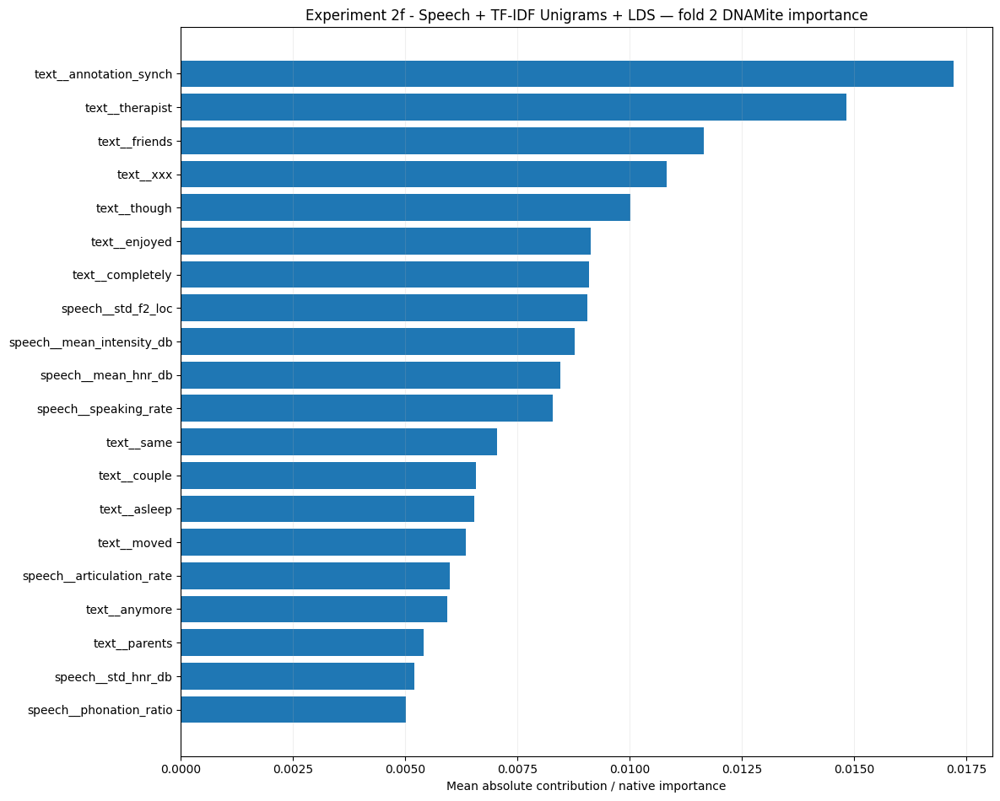

MAE               4.787411
RMSE              6.476884
R2               -0.074999
Spearman_Rho      0.292948
Spearman_P        0.138092
Pearson_R         0.289981
Pearson_P         0.142315
Exact_Accuracy    0.074074
Within_1          0.222222
Within_2          0.333333
Within_3          0.481481
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 2f - Speech + TF-IDF Unigrams + LDS | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.661, 5.944)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=100 | best=70 | best val_loss=0.387530 | hit ceiling=False
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.703, 6.025)
DNAMite active features | 

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,2.0,sqrt_inverse,4.641432,0.129228
1,2.0,inverse,4.648464,0.114290
2,4.0,inverse,4.652587,0.133715
3,3.0,inverse,4.653396,0.125058
4,4.0,sqrt_inverse,4.653665,0.134550
5,3.0,sqrt_inverse,4.657097,0.134977
6,1.0,inverse,4.660311,0.117303
7,1.0,sqrt_inverse,4.670403,0.127188
8,0.5,sqrt_inverse,4.693819,0.119731
9,0.5,inverse,4.695812,0.142040


Best imbalance parameters: {'lds_sigma': 2.0, 'lds_reweight_method': 'sqrt_inverse'} mean inner MAE: 4.641431919672893
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 2.0, 'lds_reweight_method': 'sqrt_inverse'}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=sqrt_inverse, weight range=(0.771, 3.852)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=366 | best=336 | best val_loss=0.172529 | hit ceiling=False
  Inner fold 2/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=sqrt_inverse, weight range=(0.766, 3.959)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=255 | best=225 | best val_loss=0.554707 | hit ceiling=False
  Inner fold 3/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=sqrt_inverse, weight range=(0.798, 7.149

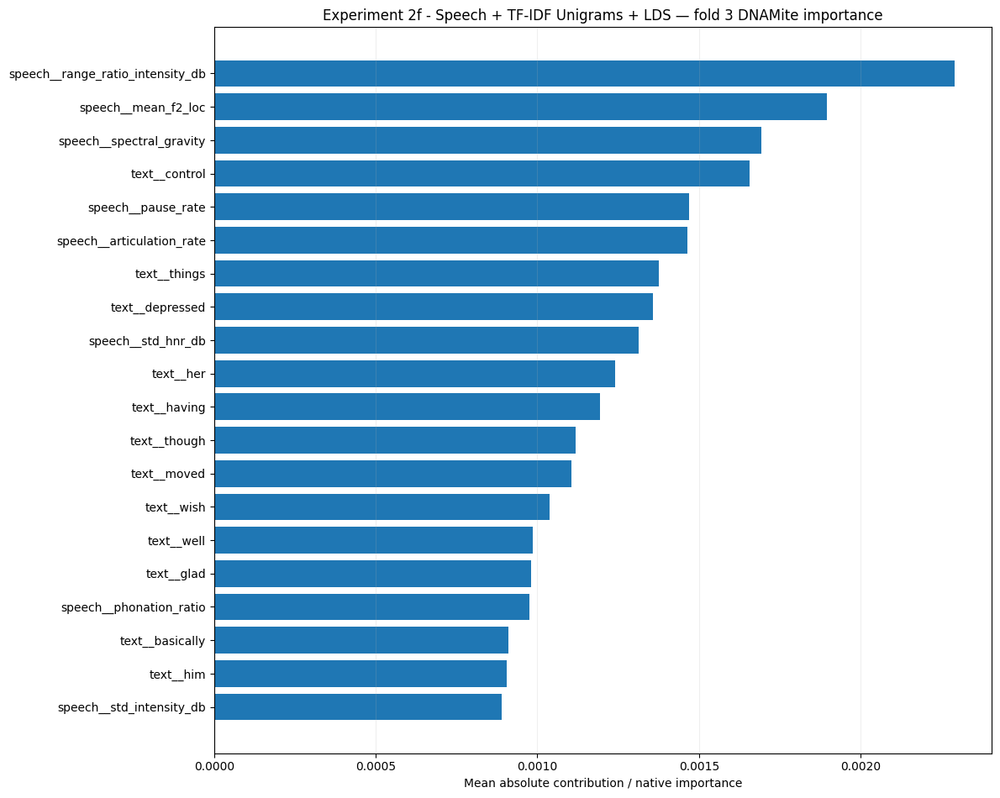

MAE               4.625787
RMSE              5.662940
R2               -0.019369
Spearman_Rho     -0.214901
Spearman_P        0.281722
Pearson_R        -0.256796
Pearson_P         0.196002
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 2f - Speech + TF-IDF Unigrams + LDS | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.603, 5.926)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=75 | best=45 | best val_loss=0.469472 | hit ceiling=False
Selected 68 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.645, 6.025)
DNAMite active features | 96 / 

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,1.0,inverse,4.683097,0.743481
1,0.5,sqrt_inverse,4.698192,0.721759
2,1.0,sqrt_inverse,4.703218,0.731361
3,2.0,inverse,4.704323,0.695917
4,3.0,sqrt_inverse,4.711810,0.702835
5,4.0,sqrt_inverse,4.714934,0.704624
6,3.0,inverse,4.719134,0.693060
7,4.0,inverse,4.727312,0.692889
8,2.0,sqrt_inverse,4.737654,0.687364
9,0.5,inverse,4.748760,0.748284


Best imbalance parameters: {'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.6830971595393605
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=1.0, method=inverse, weight range=(0.398, 12.303)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=500 | best=490 | best val_loss=0.253131 | hit ceiling=True
  Inner fold 2/3
Selected 68 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=1.0, method=inverse, weight range=(0.456, 12.352)
DNAMite active features | 96 / 96
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=0.801876 | hit ceiling=False
  Inner fold 3/3
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=1.0, method=inverse, weight range=(0.523, 12643.868)
DNAMite active featu

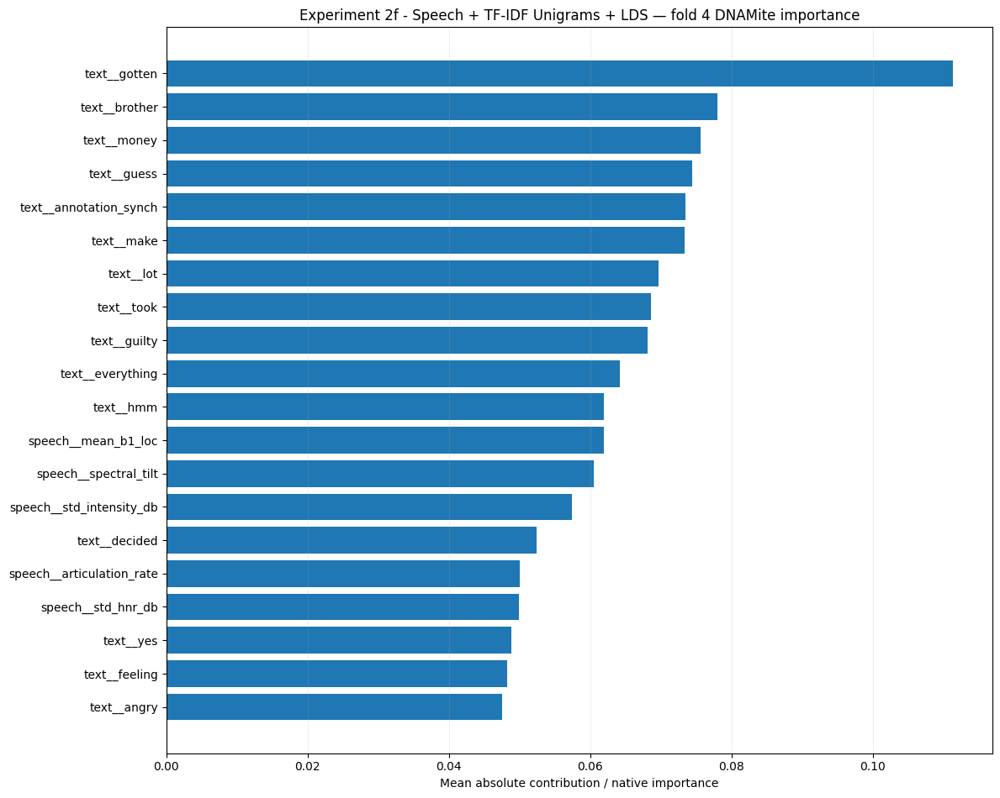

MAE               4.376126
RMSE              5.144127
R2               -0.016698
Spearman_Rho      0.302392
Spearman_P        0.125259
Pearson_R         0.278517
Pearson_P         0.159500
Exact_Accuracy    0.074074
Within_1          0.148148
Within_2          0.259259
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 2f - Speech + TF-IDF Unigrams + LDS | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.676, 1996.945)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=105 | best=75 | best val_loss=0.456600 | hit ceiling=False
Selected 60 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.609, 6.091)
DNAMite active features |

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,2.0,inverse,4.597751,0.357055
1,1.0,sqrt_inverse,4.598873,0.405364
2,0.5,sqrt_inverse,4.600473,0.441125
3,2.0,sqrt_inverse,4.601573,0.384792
4,1.0,inverse,4.601964,0.385414
5,3.0,inverse,4.604418,0.360618
6,0.5,inverse,4.606899,0.455383
7,3.0,sqrt_inverse,4.610136,0.376276
8,4.0,inverse,4.610474,0.369340
9,4.0,sqrt_inverse,4.612843,0.381851


Best imbalance parameters: {'lds_sigma': 2.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.597751495822936
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 2.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=inverse, weight range=(0.577, 48.197)
DNAMite active features | 91 / 91
DNAMite epochs | split=1 | ran=203 | best=173 | best val_loss=0.227650 | hit ceiling=False
  Inner fold 2/3
Selected 60 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=inverse, weight range=(0.532, 13.161)
DNAMite active features | 88 / 88
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.794430 | hit ceiling=False
  Inner fold 3/3
Selected 63 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=2.0, method=inverse, weight range=(0.518, 12.946)
DNAMite active feature

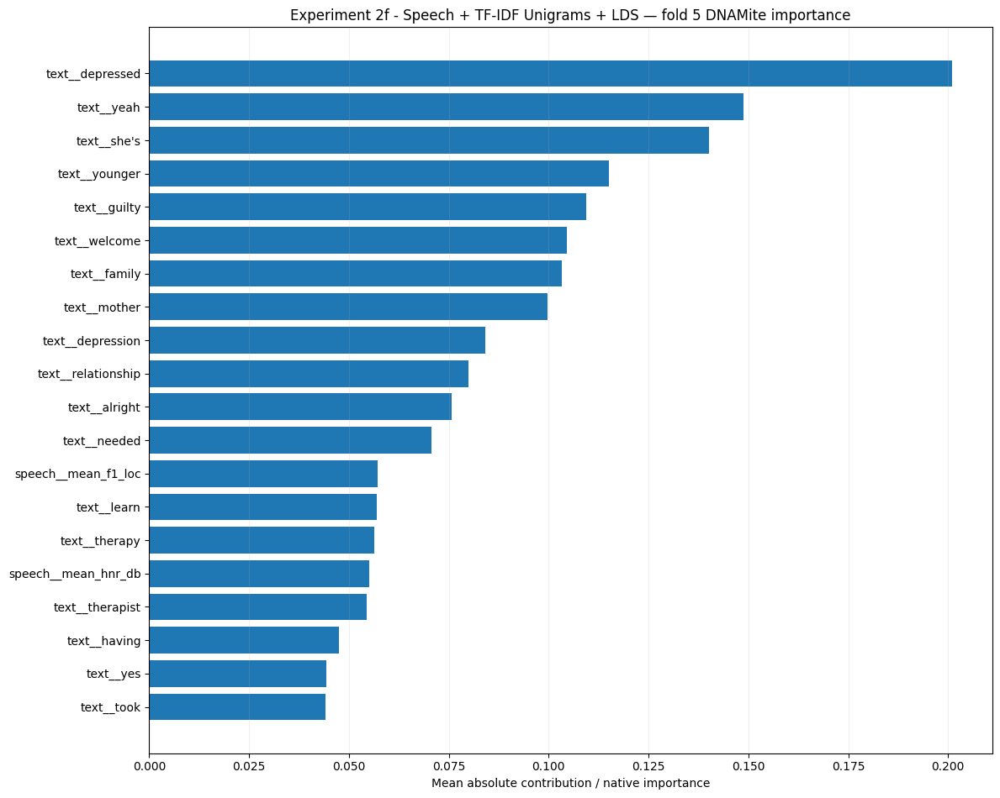

MAE               4.642674
RMSE              5.773692
R2               -0.053568
Spearman_Rho      0.136685
Spearman_P        0.496612
Pearson_R         0.190600
Pearson_P         0.340950
Exact_Accuracy    0.111111
Within_1          0.222222
Within_2          0.370370
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.528224,0.231709
RMSE,5.696572,0.498697
R2,-0.045222,0.025992
Spearman_Rho,0.135697,0.209817
Pearson_R,0.130397,0.224344
Exact_Accuracy,0.051852,0.049690
Within_1,0.207407,0.042229
Within_2,0.325926,0.048290
Within_3,0.459259,0.067281



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 2f
# Speech + TF-IDF Unigrams + LDS
# Regression Nested Cross-Validation
# ============================================================

EXPERIMENT_2F_NAME = (
    "Experiment 2f - "
    "Speech + TF-IDF Unigrams + LDS"
)


experiment_2f_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_2F_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        imbalance_strategy=(
            "lds"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 2f
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_2f_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_2f_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method,MAE,RMSE,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,32,16,2,2.0,inverse,4.209122,5.425217,...,0.555556,4.334362,5.267151,-0.000523,2.551834,3313.410156,16.518066,22.0,0.000077,3.044747e-07
1,2,8,0.0010,32,16,2,1.0,inverse,4.787411,6.476884,...,0.481481,4.996914,6.247201,-0.000108,1.604585,3345.304688,16.518066,22.0,0.000045,1.781913e-07
2,3,4,0.0005,16,16,2,2.0,sqrt_inverse,4.625787,5.662940,...,0.444444,4.607339,5.614449,-0.001987,2.589054,3202.250000,16.518066,22.0,0.000076,2.997958e-07
3,4,16,0.0005,16,32,2,1.0,inverse,4.376126,5.144127,...,0.370370,4.469822,5.104431,-0.001067,2.614859,3281.929688,16.518066,22.0,0.000077,3.025070e-07
4,5,4,0.0010,32,32,2,2.0,inverse,4.642674,5.773692,...,0.444444,4.728052,5.625067,-0.000024,4.106810,3437.148438,16.518066,22.0,0.000127,5.003993e-07



CV SUMMARY


,Mean,SD
MAE,4.528224,0.231709
RMSE,5.696572,0.498697
R2,-0.045222,0.025992
Spearman_Rho,0.135697,0.209817
Pearson_R,0.130397,0.224344
Exact_Accuracy,0.051852,0.049690
Within_1,0.207407,0.042229
Within_2,0.325926,0.048290
Within_3,0.459259,0.067281


In [ ]:
# ============================================================
# Experiment 2f
# Cross-Validation Performance
# ============================================================

experiment_2f_cv_metrics = (
    experiment_2f_regression_cv[
        "outer_results"
    ].copy()
)

experiment_2f_cv_summary = (
    experiment_2f_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_2f_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_2f_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method,MAE,RMSE,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,32,16,2,2.0,inverse,4.209122,5.425217,...,0.555556,4.334362,5.267151,-0.000523,2.551834,3313.410156,16.518066,22.0,0.000077,3.044747e-07
1,2,8,0.0010,32,16,2,1.0,inverse,4.787411,6.476884,...,0.481481,4.996914,6.247201,-0.000108,1.604585,3345.304688,16.518066,22.0,0.000045,1.781913e-07
2,3,4,0.0005,16,16,2,2.0,sqrt_inverse,4.625787,5.662940,...,0.444444,4.607339,5.614449,-0.001987,2.589054,3202.250000,16.518066,22.0,0.000076,2.997958e-07
3,4,16,0.0005,16,32,2,1.0,inverse,4.376126,5.144127,...,0.370370,4.469822,5.104431,-0.001067,2.614859,3281.929688,16.518066,22.0,0.000077,3.025070e-07
4,5,4,0.0010,32,32,2,2.0,inverse,4.642674,5.773692,...,0.444444,4.728052,5.625067,-0.000024,4.106810,3437.148438,16.518066,22.0,0.000127,5.003993e-07



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.528224,0.231709
RMSE,5.696572,0.498697
R2,-0.045222,0.025992
Spearman_Rho,0.135697,0.209817
Pearson_R,0.130397,0.224344
Exact_Accuracy,0.051852,0.049690
Within_1,0.207407,0.042229
Within_2,0.325926,0.048290
Within_3,0.459259,0.067281


In [ ]:
# ============================================================
# Experiment 2f
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_2f_parameters = (
    experiment_2f_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "lds_sigma",
            "lds_reweight_method",
        ]
    ]
    .copy()
)

display(
    experiment_2f_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method
0,1,16,0.0005,32,16,2,2.0,inverse
1,2,8,0.0010,32,16,2,1.0,inverse
2,3,4,0.0005,16,16,2,2.0,sqrt_inverse
3,4,16,0.0005,16,32,2,1.0,inverse
4,5,4,0.0010,32,32,2,2.0,inverse



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2f_-_Speech_TF-IDF_Unigrams_LDS
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


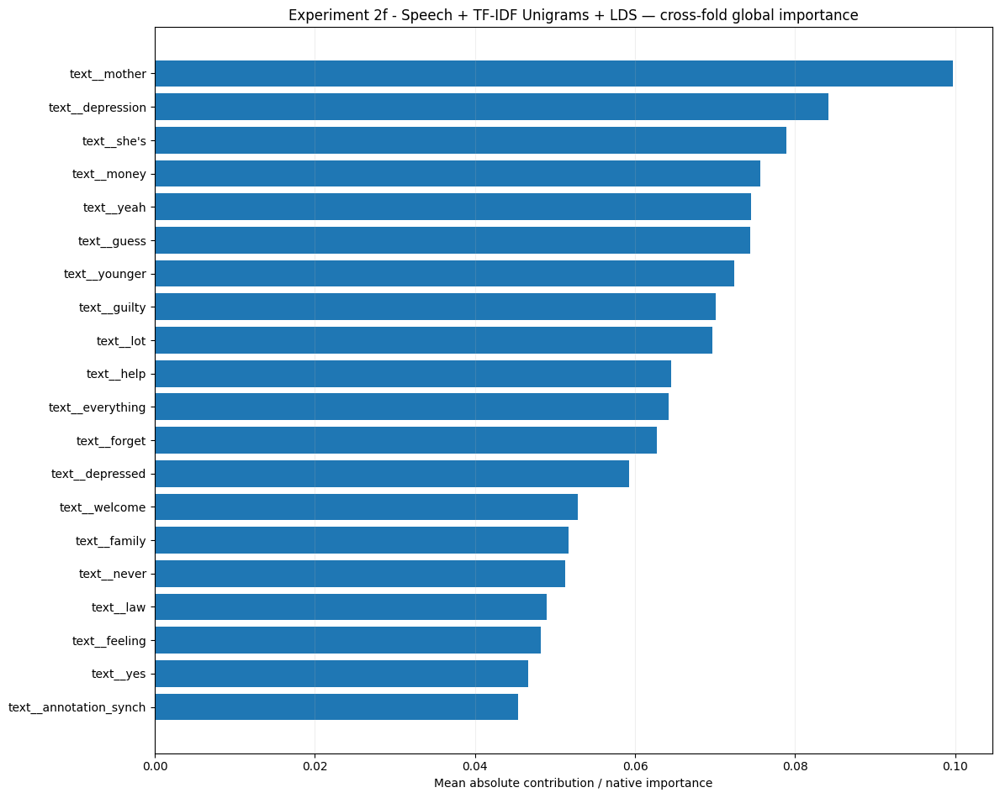

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_2f_-_Speech_TF-IDF_Unigrams_LDS/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 2f
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams + LDS
# ============================================================

experiment_2f_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_2F_NAME
        ),
        top_k=30,
    )
)

experiment_2f_interpretability

In [ ]:
# ============================================================
# Experiment 2f
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_2f_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_2F_NAME)
)


experiment_2f_development_rows = []

for path in sorted(
    experiment_2f_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_2f_development_rows.append(
            json.load(file)
        )


experiment_2f_development_df = (
    pd.DataFrame(
        experiment_2f_development_rows
    )
)

display(
    experiment_2f_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 2f - Speech + TF-IDF Unigrams + LDS,regression,1,126,200.132108,0.005518,0.000022,3346.847656,16.518066,22.0
1,DNAMite Optimized,Experiment 2f - Speech + TF-IDF Unigrams + LDS,regression,2,126,282.718346,0.008356,0.000033,3377.613281,16.518066,22.0
2,DNAMite Optimized,Experiment 2f - Speech + TF-IDF Unigrams + LDS,regression,3,126,273.180787,0.008009,0.000032,3441.730469,16.518066,22.0
3,DNAMite Optimized,Experiment 2f - Speech + TF-IDF Unigrams + LDS,regression,4,126,263.902946,0.007698,0.000030,3270.039062,16.518066,22.0
4,DNAMite Optimized,Experiment 2f - Speech + TF-IDF Unigrams + LDS,regression,5,126,239.093765,0.006858,0.000027,3330.667969,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 2f
# Development Cost Summary
# ============================================================

experiment_2f_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_2f_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2f_development_df[
                    experiment_2f_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_2f_development_df[
                    experiment_2f_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2f_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_2f_development_summary[
            "Mean"
        ],
        experiment_2f_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_2f_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,126.000000,0.000000,126.000000 ± 0.000000
development_seconds,251.805591,33.130736,251.805591 ± 33.130736
development_energy_kwh,0.007288,0.001134,0.007288 ± 0.001134
development_co2_kg,0.000029,0.000004,0.000029 ± 0.000004


In [ ]:
# ============================================================
# Experiment 2f
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_2f_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_2f_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_2f_regression_cv[
                    "outer_results"
                ][
                    experiment_2f_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_2f_regression_cv[
                    "outer_results"
                ][
                    experiment_2f_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_2f_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_2f_training_summary[
            "Mean"
        ],
        experiment_2f_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_2f_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,2.693428e+00,8.972658e-01,2.69342829 ± 0.89726584
peak_ram_mb,3.316009e+03,8.608464e+01,3316.00859375 ± 86.08464473
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,8.052960e-05,2.939071e-05,0.00008053 ± 0.00002939
training_co2_kg,3.170736e-07,1.157217e-07,0.00000032 ± 0.00000012


In [ ]:
# ============================================================
# Experiment 2f
# Speech + TF-IDF Unigrams + LDS
# Final Regression Model
# ============================================================

EXPERIMENT_2F_NAME = (
    "Experiment 2f - "
    "Speech + TF-IDF Unigrams + LDS"
)

experiment_2f_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        text_development=(
            unigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram"
        ),
        imbalance_strategy=(
            "lds"
        ),
        experiment_name=(
            EXPERIMENT_2F_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.681, 2277.947)
DNAMite active features | 107 / 107
DNAMite epochs | split=1 | ran=228 | best=198 | best val_loss=0.865644 | hit ceiling=False
Selected 83 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.708, 6.654)
DNAMite active features | 111 / 111
DNAMite epochs | split=1 | ran=103 | best=73 | best val_loss=0.360443 | hit ceiling=False
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.645, 6.751)
DNAMite active features | 107 / 107
DNAMite epochs | split=1 | ran=158 | best=128 | best val_loss=0.827662 | hit ceiling=False
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=inverse, weight range=(0.417, 4663662.836

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,0.5,inverse,4.893614,0.230575
1,0.5,sqrt_inverse,4.963913,0.093655
2,3.0,inverse,4.967654,0.107616
3,2.0,sqrt_inverse,4.968043,0.093290
4,2.0,inverse,4.969169,0.100407
5,4.0,inverse,4.970050,0.110458
6,1.0,inverse,4.972991,0.106397
7,4.0,sqrt_inverse,4.981194,0.095187
8,3.0,sqrt_inverse,4.981431,0.097588
9,1.0,sqrt_inverse,4.984711,0.099022


Best imbalance parameters: {'lds_sigma': 0.5, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.893613713142024
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 0.5, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=inverse, weight range=(0.417, 4663662.836)
DNAMite active features | 107 / 107
DNAMite epochs | split=1 | ran=364 | best=334 | best val_loss=0.947362 | hit ceiling=False
  Inner fold 2/3
Selected 83 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=inverse, weight range=(0.450, 39.747)
DNAMite active features | 111 / 111
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.411368 | hit ceiling=False
  Inner fold 3/3
Selected 79 TF-IDF features for regression / unigram using alpha=0.0025
LDS | sigma=0.5, method=inverse, weight range=(0.365, 39.947)
DNAMite active

In [ ]:
# ============================================================
# Experiment 2f
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_2f_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,5.028062
RMSE,6.308349
R2,0.031672
Spearman_Rho,0.315427
Spearman_P,0.032737
Pearson_R,0.249425
Pearson_P,0.094591
Exact_Accuracy,0.043478
Within_1,0.217391
Within_2,0.347826


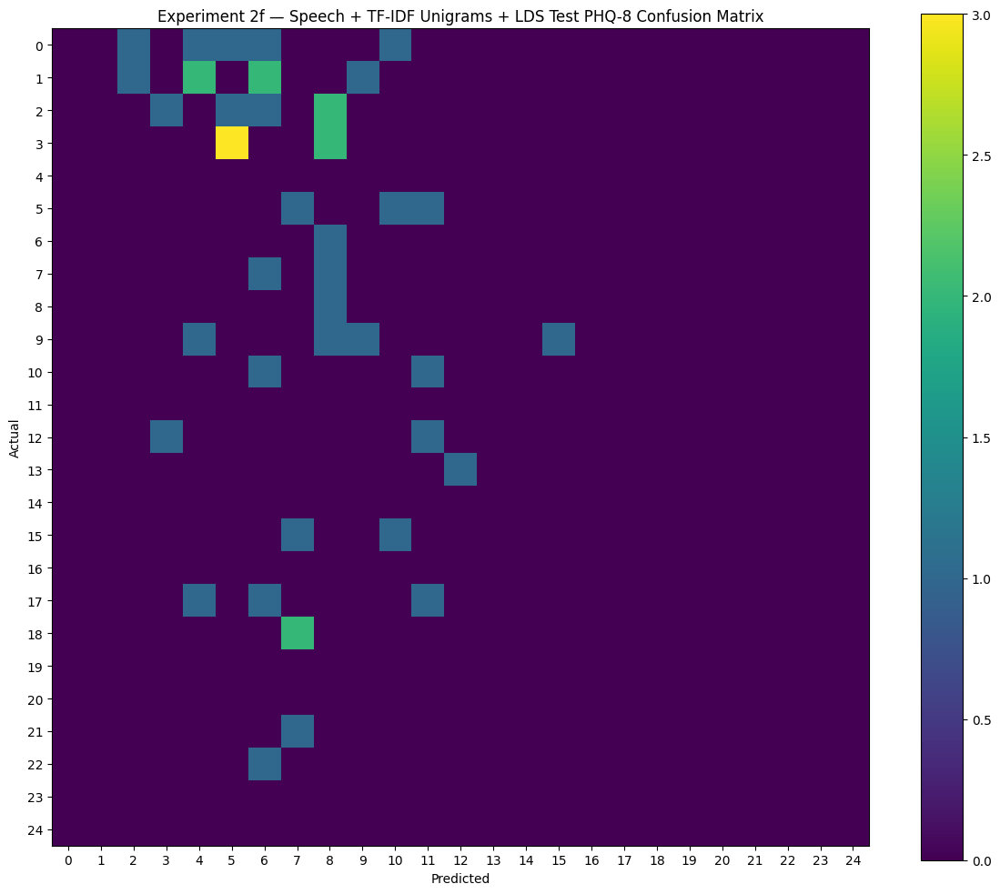

array([[0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 1, 0, 2, 0, 2, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 3, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 2f
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_2f_regression_final[
                "test_rounded_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 2f — "
        "Speech + TF-IDF Unigrams + LDS "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.051137,31
1,0,speech__articulation_rate,0.017877,31
2,0,speech__phonation_ratio,0.025942,31
3,0,speech__pause_rate,0.027191,31
4,0,speech__mean_pause_duration,0.023315,31
5,0,speech__mean_f0_hertz,0.015157,31
6,0,speech__std_f0_hertz,0.010506,31
7,0,speech__mean_intensity_db,0.003721,31
8,0,speech__std_intensity_db,0.017191,31
9,0,speech__range_ratio_intensity_db,0.019662,31


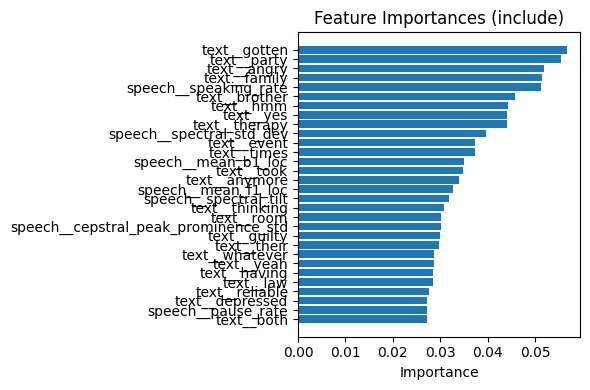

In [ ]:
# ============================================================
# Experiment 2f
# Final Model Feature Importance
# ============================================================

experiment_2f_regression_importance = (
    show_feature_importance(
        experiment_2f_regression_final[
            "model"
        ],
        top_n=30,
    )
)

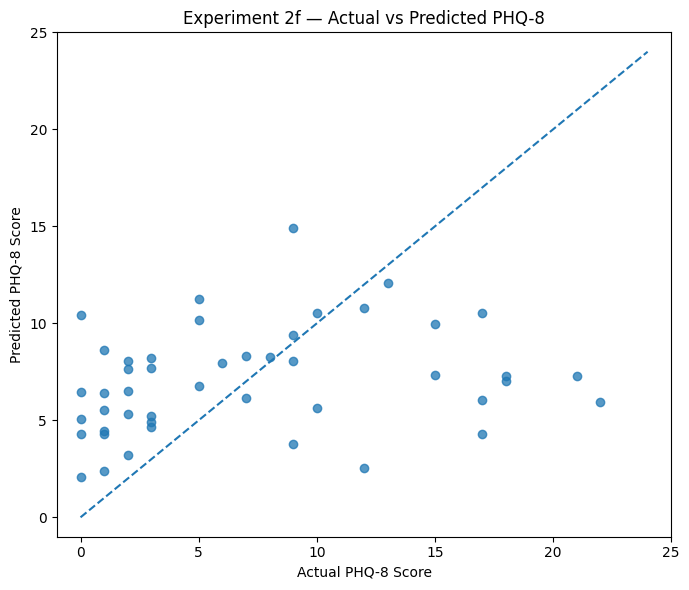

In [ ]:
# ============================================================
# Experiment 2f
# Actual vs predicted
# ============================================================

plot_regression_predictions(
    y_true=y_regression_test,
    predictions=(
        experiment_2f_regression_final[
            "test_predictions"
        ]
    ),
    title=(
        "Experiment 2f — "
        "Actual vs Predicted PHQ-8"
    ),
)

### Compare 2c vs 2f

In [ ]:
# ============================================================
# EXPERIMENT 2C VS 2F — TEST COMPARISON
# ============================================================

experiment_2c_vs_2f_regression_test = (
    pd.DataFrame(
        {
            "Experiment 2c - Baseline": (
                experiment_2c_regression_final[
                    "test_metrics"
                ]
            ),

            "Experiment 2f - LDS": (
                experiment_2f_regression_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_2c_vs_2f_regression_test
)

,Experiment 2c - Baseline,Experiment 2f - LDS
MAE,5.076773,5.028062
RMSE,6.348446,6.308349
R2,0.019323,0.031672
Spearman_Rho,0.306637,0.315427
Spearman_P,0.038200,0.032737
Pearson_R,0.235860,0.249425
Pearson_P,0.114563,0.094591
Exact_Accuracy,0.021739,0.043478
Within_1,0.173913,0.217391
Within_2,0.347826,0.347826


In [ ]:
# ============================================================
# EXPERIMENT 2C VS 2F — CV COMPARISON
# Mean ± SD Across Outer Folds
# ============================================================

experiment_2c_vs_2f_regression_cv = (
    pd.DataFrame(
        {
            "Experiment 2c - Baseline": (
                experiment_2c_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 2f - LDS": (
                experiment_2f_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_2c_vs_2f_regression_cv
)

,Experiment 2c - Baseline,Experiment 2f - LDS
MAE,4.7206 ± 0.5416,4.5282 ± 0.2317
RMSE,5.9259 ± 0.9681,5.6966 ± 0.4987
R2,-0.1322 ± 0.2320,-0.0452 ± 0.0260
Spearman_Rho,0.0752 ± 0.2272,0.1357 ± 0.2098
Pearson_R,0.0452 ± 0.2609,0.1304 ± 0.2243
Exact_Accuracy,0.0593 ± 0.0497,0.0519 ± 0.0497
Within_1,0.1704 ± 0.0422,0.2074 ± 0.0422
Within_2,0.2889 ± 0.0483,0.3259 ± 0.0483
Within_3,0.4519 ± 0.0845,0.4593 ± 0.0673


## EXPERIMENT 3 — SPEECH + TF-IDF UNIGRAMS/BIGRAMS

### Experiment 3a binary nested CV


Experiment 3a - Speech + TF-IDF Unigrams/Bigrams | Classification | Outer fold 1
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=382 | best=352 | best val_loss=0.146794 | hit ceiling=False
  Inner fold 2/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.529386 | hit ceiling=False
  Inner fold 3/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.638626 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
Selected 10 TF-IDF features for c

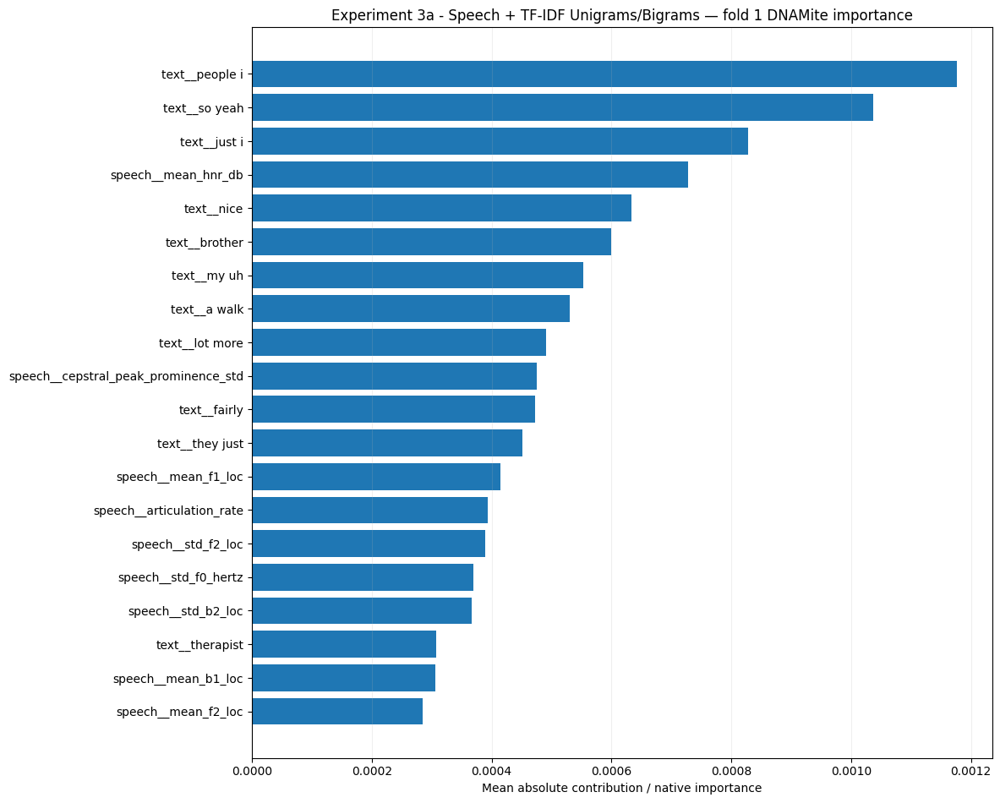

ROC_AUC              0.592105
PR_AUC               0.340891
AUPRC                0.340891
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208574
Log_Loss             0.607857
Threshold            0.290000
dtype: float64

Experiment 3a - Speech + TF-IDF Unigrams/Bigrams | Classification | Outer fold 2
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 36 / 36
DNAMite epochs | split=1 | ran=287 | best=257 | best val_loss=0.377828 | hit ceiling=False
  Inner fold 2/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 37 / 37
DNAMite epochs | split=1 | ran=33 | best=3 | best val_loss=0.636197 | hit ceiling=False
 

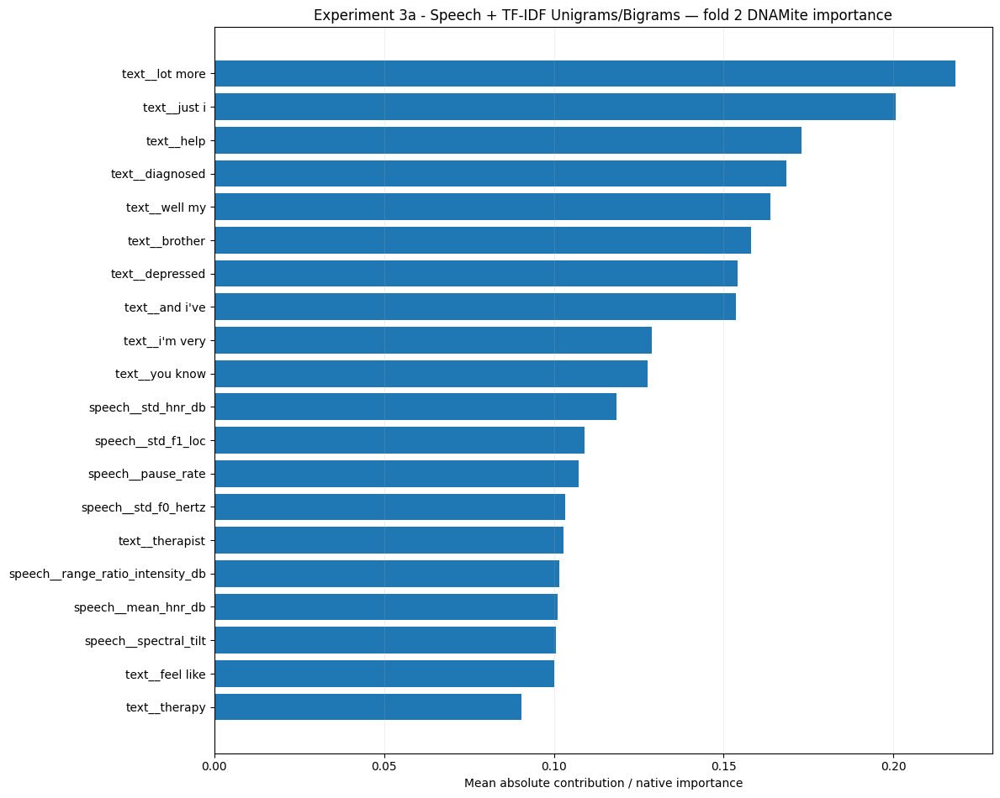

ROC_AUC              0.414474
PR_AUC               0.369429
AUPRC                0.369429
Accuracy             0.592593
Balanced_Accuracy    0.493421
Precision            0.285714
Sensitivity          0.250000
Specificity          0.736842
F1                   0.266667
Brier_Score          0.238133
Log_Loss             0.709696
Threshold            0.385000
dtype: float64

Experiment 3a - Speech + TF-IDF Unigrams/Bigrams | Classification | Outer fold 3
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=216 | best=186 | best val_loss=0.506311 | hit ceiling=False
  Inner fold 2/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.637631 | hit ceiling=False


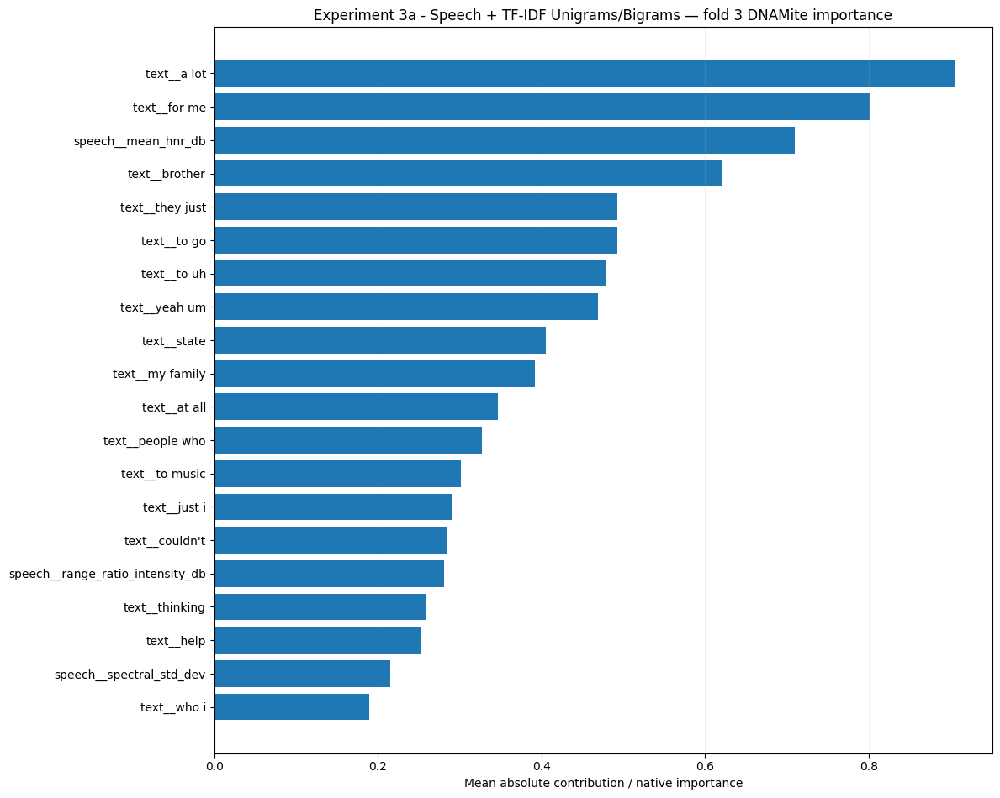

ROC_AUC              0.421053
PR_AUC               0.352600
AUPRC                0.352600
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208509
Log_Loss             0.607704
Threshold            0.050000
dtype: float64

Experiment 3a - Speech + TF-IDF Unigrams/Bigrams | Classification | Outer fold 4
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 13 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 41 / 41
DNAMite epochs | split=1 | ran=301 | best=271 | best val_loss=0.355225 | hit ceiling=False
  Inner fold 2/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 37 / 37
DNAMite epochs | split=1 | ran=282 | best=252 | best val_loss=0.428546 | hit ceiling=Fal

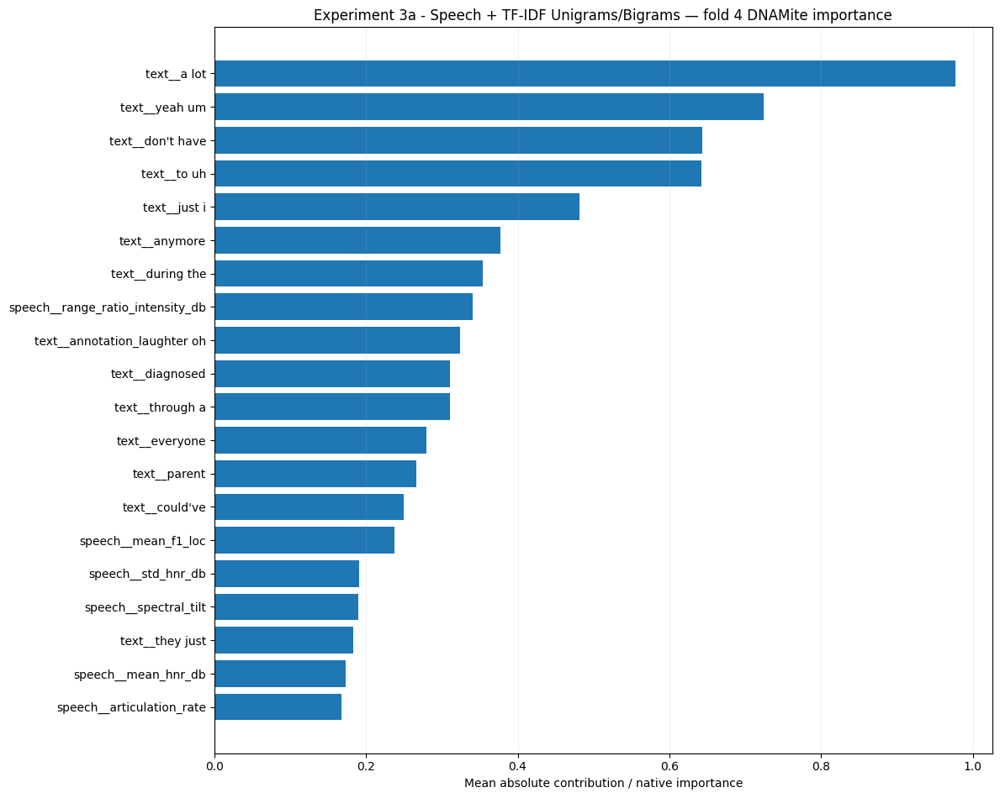

ROC_AUC              0.605263
PR_AUC               0.497360
AUPRC                0.497360
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.207767
Log_Loss             0.606341
Threshold            0.260000
dtype: float64

Experiment 3a - Speech + TF-IDF Unigrams/Bigrams | Classification | Outer fold 5
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 36 / 36
DNAMite epochs | split=1 | ran=41 | best=11 | best val_loss=0.478936 | hit ceiling=False
  Inner fold 2/3
Selected 6 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 34 / 34
DNAMite epochs | split=1 | ran=42 | best=12 | best val_loss=0.579943 | hit ceiling=False
  

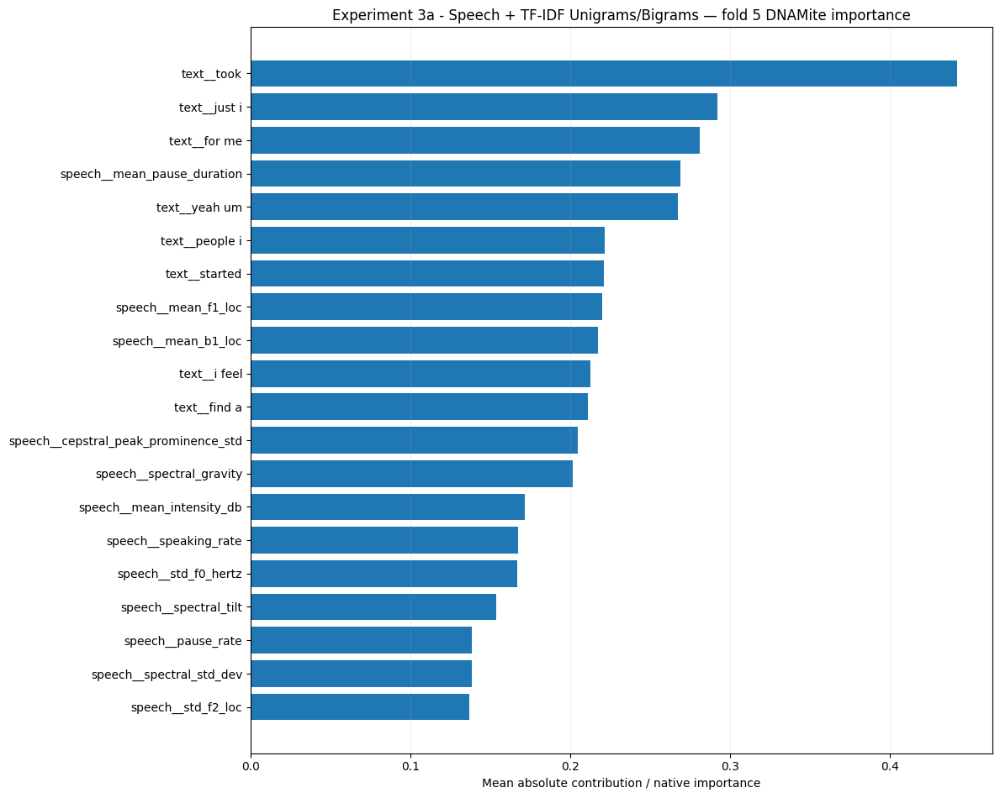

ROC_AUC              0.394737
PR_AUC               0.236539
AUPRC                0.236539
Accuracy             0.333333
Balanced_Accuracy    0.417763
Precision            0.250000
Sensitivity          0.625000
Specificity          0.210526
F1                   0.357143
Brier_Score          0.213580
Log_Loss             0.619452
Threshold            0.290000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.485526,0.103856
PR_AUC,0.359364,0.093029
AUPRC,0.359364,0.093029
Accuracy,0.362963,0.129365
Balanced_Accuracy,0.482237,0.036154
Precision,0.284921,0.020052
Sensitivity,0.775000,0.335410
Specificity,0.189474,0.319279
F1,0.399048,0.085741
Brier_Score,0.215313,0.012966



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,False,None,45,45,"[speech__speaking_rate, speech__articulation_r..."
1,2,False,None,45,45,"[speech__speaking_rate, speech__articulation_r..."
2,3,False,None,48,48,"[speech__speaking_rate, speech__articulation_r..."
3,4,False,None,47,47,"[speech__speaking_rate, speech__articulation_r..."
4,5,False,None,45,45,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 3a
# Speech + TF-IDF Unigrams/Bigrams
# Classification Nested Cross-Validation
# ============================================================

EXPERIMENT_3A_NAME = (
    "Experiment 3a - "
    "Speech + TF-IDF Unigrams/Bigrams"
)


experiment_3a_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_3A_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 3a
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_3a_binary_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_3a_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0005,32,32,2,False,None,45,45,...,0.457143,0.208574,0.607857,0.290,0.900933,3229.402344,16.518066,22.0,0.000017,6.602480e-08
1,2,8,0.0005,32,32,2,False,None,45,45,...,0.266667,0.238133,0.709696,0.385,1.207005,3294.097656,16.518066,22.0,0.000031,1.217016e-07
2,3,8,0.0010,16,32,2,False,None,48,48,...,0.457143,0.208509,0.607704,0.050,1.523528,3338.125000,16.518066,22.0,0.000041,1.632406e-07
3,4,8,0.0010,16,16,2,False,None,47,47,...,0.457143,0.207767,0.606341,0.260,1.743039,3249.308594,16.518066,22.0,0.000052,2.035864e-07
4,5,32,0.0005,32,16,2,False,None,45,45,...,0.357143,0.213580,0.619452,0.290,2.009211,3381.320312,16.518066,22.0,0.000058,2.273419e-07



CV SUMMARY


,Mean,SD
ROC_AUC,0.485526,0.103856
PR_AUC,0.359364,0.093029
AUPRC,0.359364,0.093029
Accuracy,0.362963,0.129365
Balanced_Accuracy,0.482237,0.036154
Precision,0.284921,0.020052
Sensitivity,0.775000,0.335410
Specificity,0.189474,0.319279
F1,0.399048,0.085741
Brier_Score,0.215313,0.012966


In [ ]:
# ============================================================
# Experiment 3a
# Cross-Validation Performance
# ============================================================

experiment_3a_cv_metrics = (
    experiment_3a_binary_cv[
        "outer_results"
    ].copy()
)

experiment_3a_cv_summary = (
    experiment_3a_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_3a_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_3a_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,4,0.0005,32,32,2,False,None,45,45,...,0.457143,0.208574,0.607857,0.290,0.900933,3229.402344,16.518066,22.0,0.000017,6.602480e-08
1,2,8,0.0005,32,32,2,False,None,45,45,...,0.266667,0.238133,0.709696,0.385,1.207005,3294.097656,16.518066,22.0,0.000031,1.217016e-07
2,3,8,0.0010,16,32,2,False,None,48,48,...,0.457143,0.208509,0.607704,0.050,1.523528,3338.125000,16.518066,22.0,0.000041,1.632406e-07
3,4,8,0.0010,16,16,2,False,None,47,47,...,0.457143,0.207767,0.606341,0.260,1.743039,3249.308594,16.518066,22.0,0.000052,2.035864e-07
4,5,32,0.0005,32,16,2,False,None,45,45,...,0.357143,0.213580,0.619452,0.290,2.009211,3381.320312,16.518066,22.0,0.000058,2.273419e-07



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.485526,0.103856
PR_AUC,0.359364,0.093029
AUPRC,0.359364,0.093029
Accuracy,0.362963,0.129365
Balanced_Accuracy,0.482237,0.036154
Precision,0.284921,0.020052
Sensitivity,0.775000,0.335410
Specificity,0.189474,0.319279
F1,0.399048,0.085741
Brier_Score,0.215313,0.012966


In [ ]:
# ============================================================
# Experiment 3a
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_3a_parameters = (
    experiment_3a_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
        ]
    ]
    .copy()
)

display(
    experiment_3a_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers
0,1,4,0.0005,32,32,2
1,2,8,0.0005,32,32,2
2,3,8,0.0010,16,32,2
3,4,8,0.0010,16,16,2
4,5,32,0.0005,32,16,2



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3a_-_Speech_TF-IDF_Unigrams_Bigrams
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


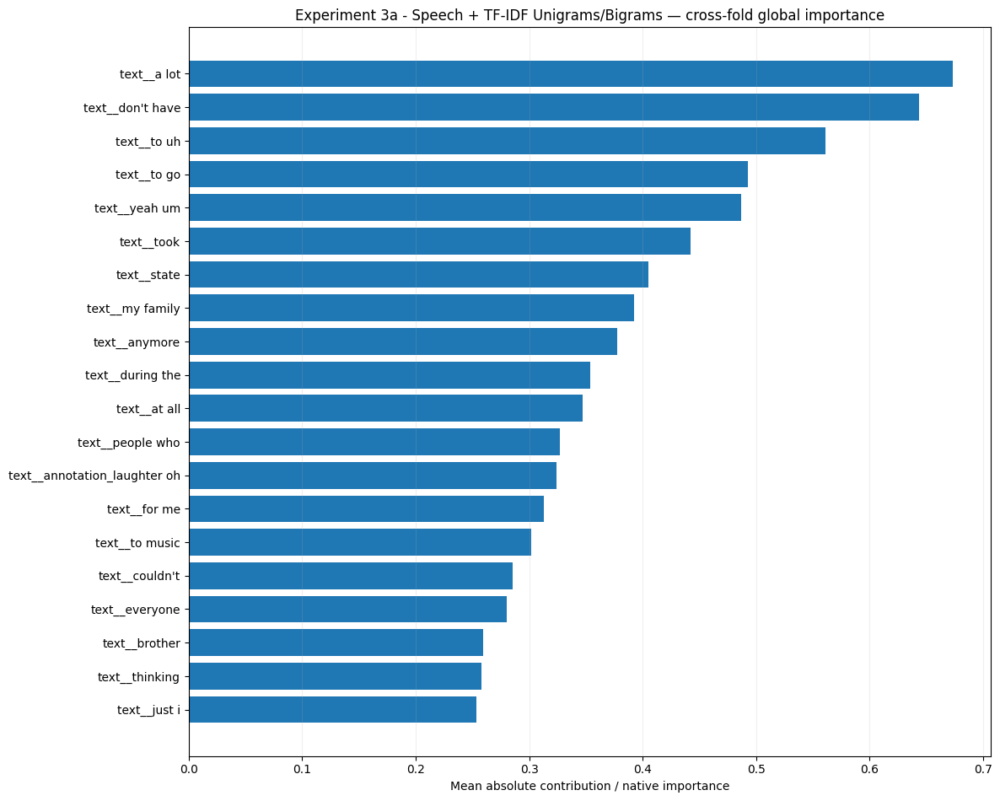

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3a_-_Speech_TF-IDF_Unigrams_Bigrams/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 3a
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams/Bigrams
# ============================================================

experiment_3a_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_3A_NAME
        ),
        top_k=30,
    )
)

experiment_3a_interpretability

In [ ]:
# ============================================================
# Experiment 3a
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_3a_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_3A_NAME)
)


experiment_3a_development_rows = []

for path in sorted(
    experiment_3a_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_3a_development_rows.append(
            json.load(file)
        )


experiment_3a_development_df = (
    pd.DataFrame(
        experiment_3a_development_rows
    )
)

display(
    experiment_3a_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,classification,1,96,113.598787,0.002785,0.000011,3229.390625,16.518066,22.0
1,DNAMite Optimized,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,classification,2,96,124.502928,0.003236,0.000013,3294.214844,16.518066,22.0
2,DNAMite Optimized,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,classification,3,96,99.109889,0.002432,0.000010,3338.242188,16.518066,22.0
3,DNAMite Optimized,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,classification,4,96,113.073241,0.002914,0.000011,3249.390625,16.518066,22.0
4,DNAMite Optimized,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,classification,5,96,134.020313,0.003640,0.000014,3381.390625,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 3a
# Development Cost Summary
# ============================================================

experiment_3a_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_3a_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3a_development_df[
                    experiment_3a_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_3a_development_df[
                    experiment_3a_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3a_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_3a_development_summary[
            "Mean"
        ],
        experiment_3a_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_3a_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,96.000000,0.000000,96.000000 ± 0.000000
development_seconds,116.861031,13.161802,116.861031 ± 13.161802
development_energy_kwh,0.003001,0.000459,0.003001 ± 0.000459
development_co2_kg,0.000012,0.000002,0.000012 ± 0.000002


In [ ]:
# ============================================================
# Experiment 3a
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_3a_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_3a_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3a_binary_cv[
                    "outer_results"
                ][
                    experiment_3a_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_3a_binary_cv[
                    "outer_results"
                ][
                    experiment_3a_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3a_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_3a_training_summary[
            "Mean"
        ],
        experiment_3a_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_3a_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,1.476743e+00,4.361592e-01,1.47674312 ± 0.43615924
peak_ram_mb,3.298451e+03,6.253598e+01,3298.45078125 ± 62.53597735
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,3.971678e-05,1.639964e-05,0.00003972 ± 0.00001640
training_co2_kg,1.563791e-07,6.457120e-08,0.00000016 ± 0.00000006


### Experiment 3a final binary model

In [ ]:
# ============================================================
# Experiment 3a
# Speech + TF-IDF Unigrams/Bigrams
# Final Classification Model
# ============================================================

EXPERIMENT_3A_NAME = (
    "Experiment 3a - "
    "Speech + TF-IDF Unigrams/Bigrams"
)

experiment_3a_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        experiment_name=(
            EXPERIMENT_3A_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 39 / 39
DNAMite epochs | split=1 | ran=280 | best=250 | best val_loss=0.287243 | hit ceiling=False
  Inner fold 2/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.532297 | hit ceiling=False
  Inner fold 3/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.469238 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram_bigram using C=5.0
DNAMite active features | 39 / 39
DNA

In [ ]:
# ============================================================
# Experiment 3a
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_3a_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.417411
PR_AUC,0.255266
AUPRC,0.255266
Accuracy,0.608696
Balanced_Accuracy,0.457589
Precision,0.166667
Sensitivity,0.071429
Specificity,0.843750
F1,0.100000
Brier_Score,0.215167


### Experiment 3a binary plots

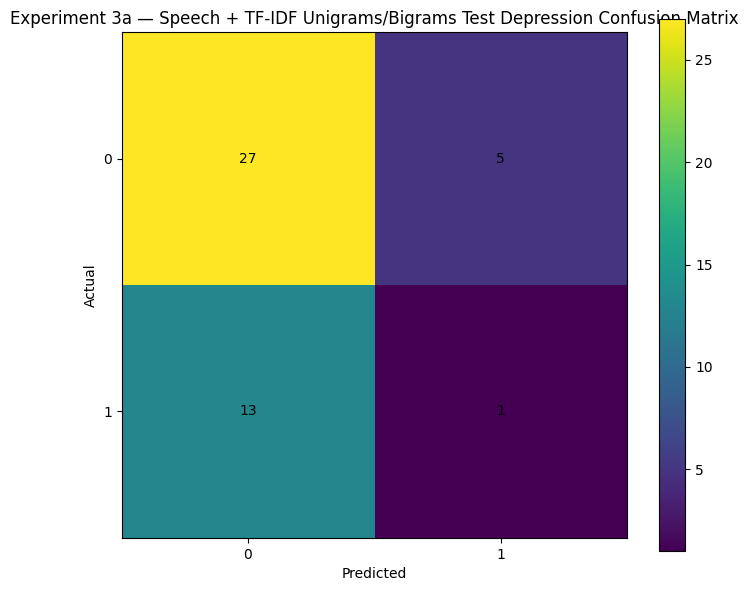

array([[27,  5],
       [13,  1]])

In [ ]:
# ============================================================
# Experiment 3a
# Final Test Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_3a_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 3a — "
        "Speech + TF-IDF Unigrams/Bigrams "
        "Test Depression Confusion Matrix"
    ),
)

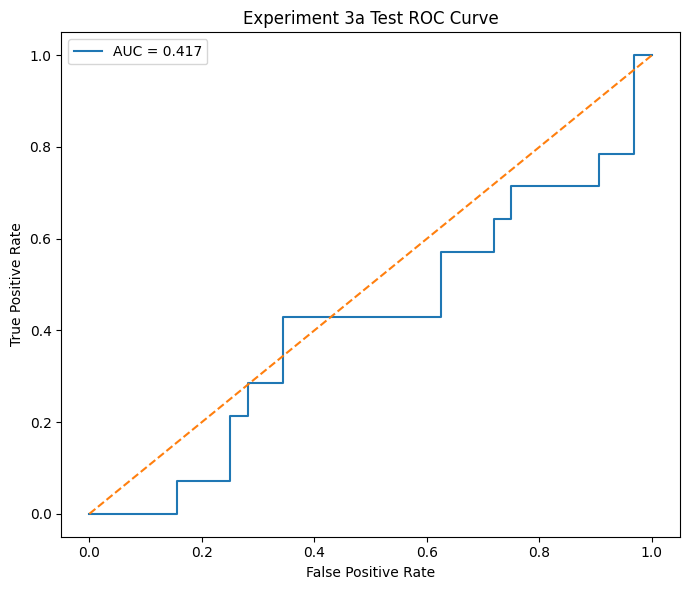

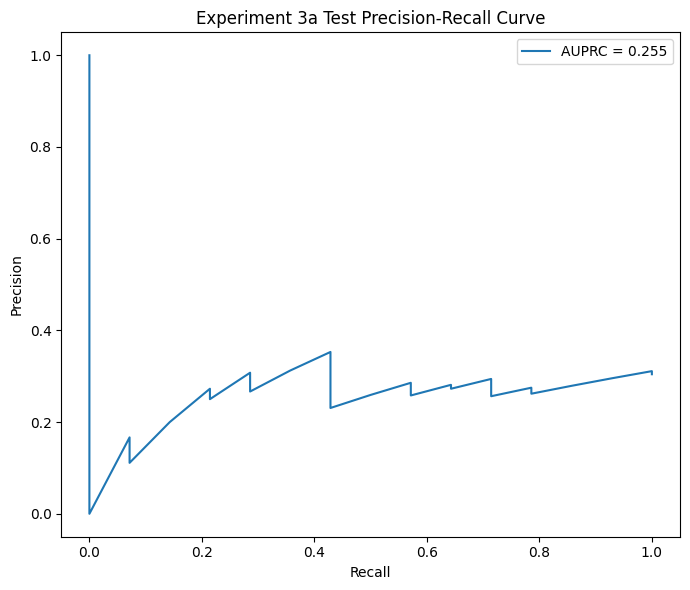

In [ ]:
# ============================================================
# Experiment 3a
# Final Test Classification Curves
# ============================================================

plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_3a_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 3a Test"
    ),
)

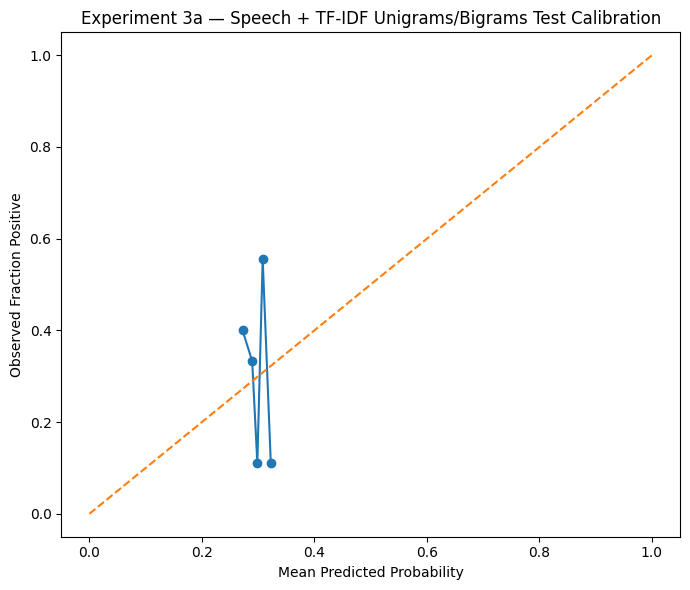

,mean_predicted_probability,observed_fraction_positive,n
0,0.272213,0.400000,10
1,0.289365,0.333333,9
2,0.298572,0.111111,9
3,0.308083,0.555556,9
4,0.322483,0.111111,9


In [ ]:
# ============================================================
# Experiment 3a
# Final Test Calibration
# ============================================================

plot_calibration_curve_manual(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_3a_binary_final[
            "test_probabilities"
        ]
    ),
    n_bins=5,
    title=(
        "Experiment 3a — "
        "Speech + TF-IDF Unigrams/Bigrams "
        "Test Calibration"
    ),
)

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.136963,31
1,0,speech__articulation_rate,0.124909,31
2,0,speech__phonation_ratio,0.073831,31
3,0,speech__pause_rate,0.101522,31
4,0,speech__mean_pause_duration,0.171853,31
5,0,speech__mean_f0_hertz,0.046142,31
6,0,speech__std_f0_hertz,0.038909,31
7,0,speech__mean_intensity_db,0.015456,31
8,0,speech__std_intensity_db,0.077903,31
9,0,speech__range_ratio_intensity_db,0.038237,31


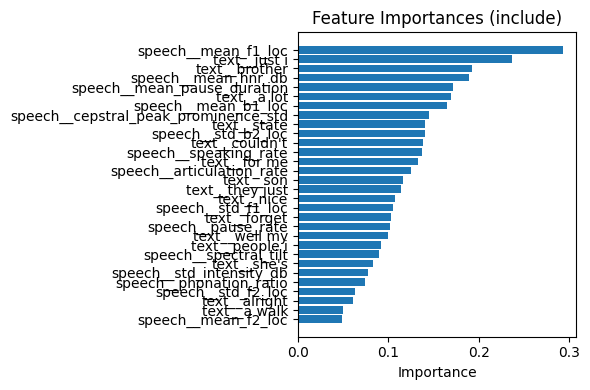

In [ ]:
# ============================================================
# Experiment 3a
# Final Model Feature Importance
# ============================================================

experiment_3a_binary_importance = (
    show_feature_importance(
        experiment_3a_binary_final[
            "model"
        ],
        top_n=30,
    )
)

### Experiment 2a vs. 3a

In [ ]:
# ============================================================
# EXPERIMENT 2A VS 3A — CV COMPARISON
# Unigrams vs Unigrams + Bigrams
# ============================================================

experiment_2a_vs_3a_binary_cv = (
    pd.DataFrame(
        {
            "Experiment 2a - Unigrams": (
                experiment_2a_binary_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 3a - Unigrams/Bigrams": (
                experiment_3a_binary_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_2a_vs_3a_binary_cv
)

,Experiment 2a - Unigrams,Experiment 3a - Unigrams/Bigrams
ROC_AUC,0.4711 ± 0.2613,0.4855 ± 0.1039
PR_AUC,0.3632 ± 0.2624,0.3594 ± 0.0930
AUPRC,0.3632 ± 0.2624,0.3594 ± 0.0930
Accuracy,0.4593 ± 0.2231,0.3630 ± 0.1294
Balanced_Accuracy,0.5000 ± 0.0000,0.4822 ± 0.0362
Precision,0.1778 ± 0.1623,0.2849 ± 0.0201
Sensitivity,0.6000 ± 0.5477,0.7750 ± 0.3354
Specificity,0.4000 ± 0.5477,0.1895 ± 0.3193
F1,0.2743 ± 0.2504,0.3990 ± 0.0857
Brier_Score,0.2092 ± 0.0015,0.2153 ± 0.0130


### Experiment 3b Speech + TF-IDF Unigrams/Bigrams with Feature Selection


Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Classification | Outer fold 1
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 28 / 38
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
DNAMite epochs | split=1 | ran=72 | best=42 | best val_loss=0.579611 | hit ceiling=False
  Inner fold 2/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feat

[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 35
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=77 | best=47 | best val_loss=0.520296 | hit ceiling=False
  Inner fold 3/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 18 / 35
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc']
DNAMite epochs | split=1 | ran=53 | best=23 | best val_loss=0.497110 | hit ceiling=False
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 22 / 37
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc']
DNAMite epochs | split=1 | ran=215 | best=185 | best val_loss=0.348843 | hit ceiling=False
Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 11 / 45
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db']
DNAMite epochs | split=1 | ran=48 | best=18 | best val_loss=0.403273 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 0.9643031740051811, 'peak_ram_mb': 3514.22265625, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 2.316559889190264e-05, 'training_co2_kg': 9.121118724117065e-08}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_01.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Res

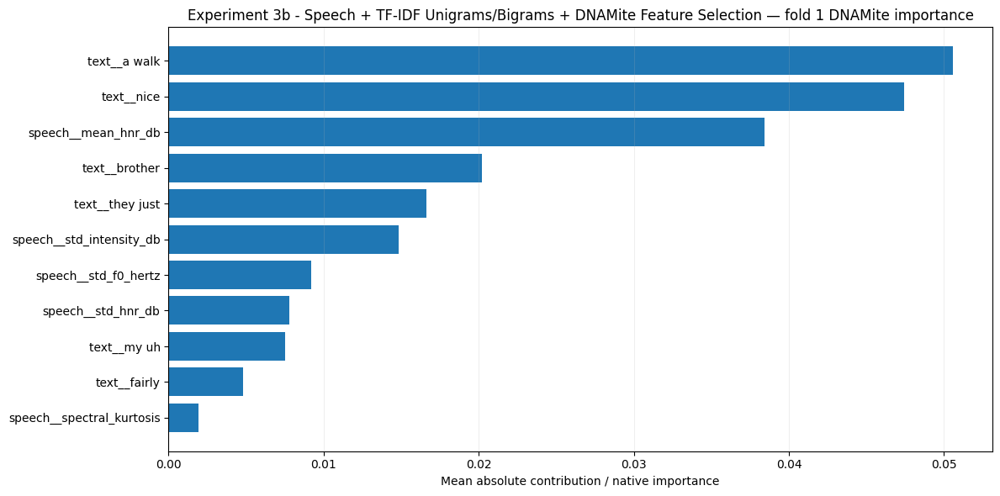

ROC_AUC              0.296053
PR_AUC               0.211283
AUPRC                0.211283
Accuracy             0.703704
Balanced_Accuracy    0.500000
Precision            0.000000
Sensitivity          0.000000
Specificity          1.000000
F1                   0.000000
Brier_Score          0.208822
Log_Loss             0.608470
Threshold            0.315000
dtype: float64

Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Classification | Outer fold 2
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 19 / 36
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc']
DNAMite epochs | split=1 | ran=71 | best=41 | best val_loss=0.580312 | hit ceiling=False
  Inner fold 2/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 22 / 37
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc']
DNAMite epochs | split=1 | ran=51 | best=21 | best val_loss=0.636242 | hit ceiling=False
  Inner fold 3/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 15 / 35
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean']
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.509043 | hit ceiling=False
Selected 6 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 34
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.693147 | hit ceiling=False
Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 18 / 45
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc']
DNAMite epochs | split=1 | ran=39 | best=9 | best val_loss=0.478239 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.0445015430013882, 'peak_ram_mb': 3381.6640625, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 2.6343556827091534e-05, 'training_co2_kg': 1.0372393589160154e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Compariso

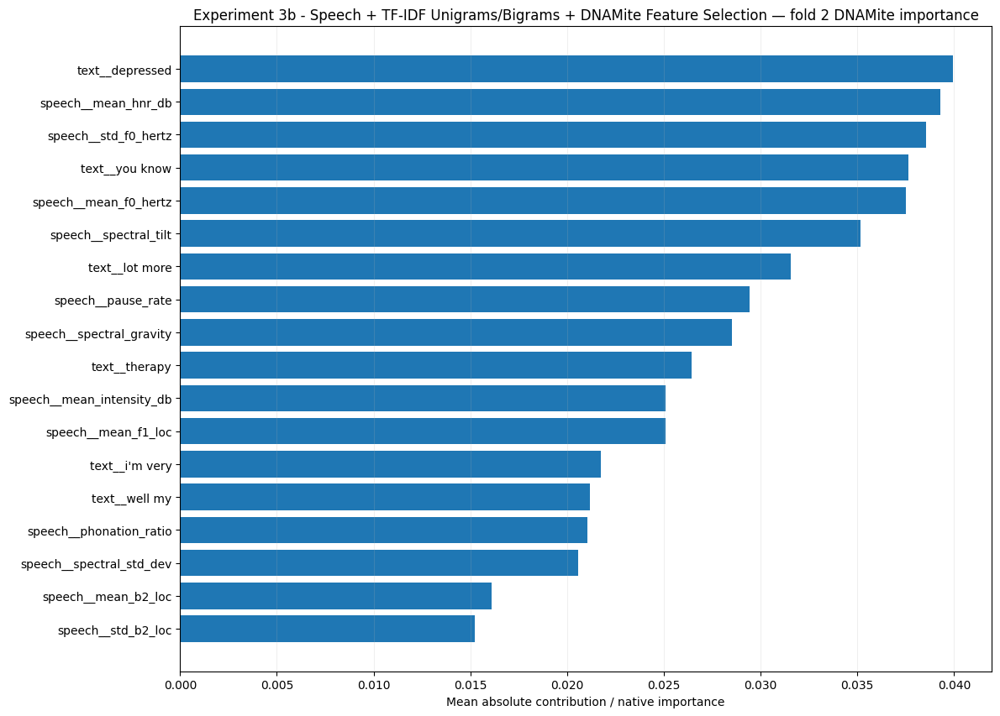

ROC_AUC              0.335526
PR_AUC               0.215655
AUPRC                0.215655
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.210922
Log_Loss             0.613629
Threshold            0.245000
dtype: float64

Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Classification | Outer fold 3
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 8 / 35
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db']
DNAMite epochs | split=1 | ran=87 | best=57 | best val_loss=0.634670 | hit ceiling=False
  Inner fold 2/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 25 / 38
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity']
DNAMite epochs | split=1 | ran=32 | best=2 | best val_loss=0.636646 | hit ceiling=False
  Inner fold 3/3
Selected 5 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 21 / 40
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc']
DNAMite epochs | split=1 | ran=186 | best=156 | best val_loss=0.437268 | hit ceiling=False
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 37
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=162 | best=132 | best val_loss=0.436381 | hit ceiling=False
Selected 20 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 48
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=191 | best=161 | best val_loss=0.403846 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 3.8509716800035676, 'peak_ram_mb': 3381.921875, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 0.0001218640783559356, 'training_co2_kg': 4.798221414763953e-07}
Saved resource metrics to: 

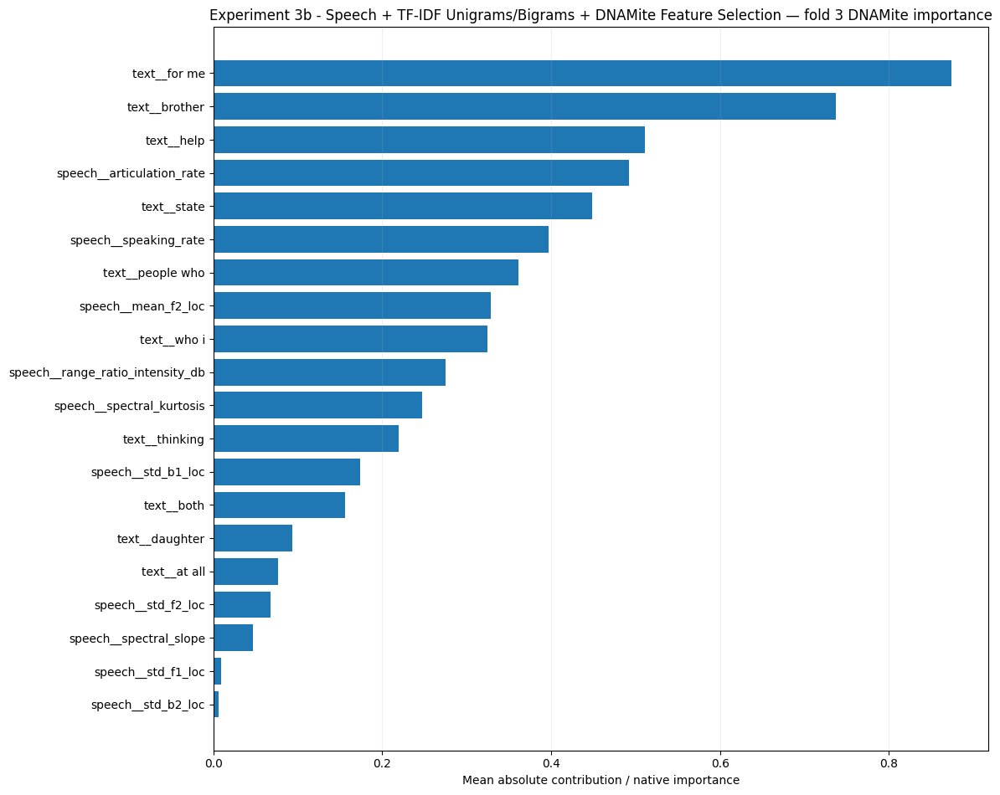

ROC_AUC              0.513158
PR_AUC               0.403415
AUPRC                0.403415
Accuracy             0.407407
Balanced_Accuracy    0.434211
Precision            0.250000
Sensitivity          0.500000
Specificity          0.368421
F1                   0.333333
Brier_Score          0.208381
Log_Loss             0.607693
Threshold            0.295000
dtype: float64

Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Classification | Outer fold 4
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 13 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 31 / 41
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__alright', 'text__depressed', 'text__diagnosed']
DNAMite epochs | split=1 | ran=45 | best=15 | best val_loss=0.580397 | hit ceiling=False
  Inner fold 2/3
Selected 9 TF-IDF features for classific

[WARNING] Found selected features. Using only those features.


DNAMite active features | 20 / 37
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc']
DNAMite epochs | split=1 | ran=83 | best=53 | best val_loss=0.580593 | hit ceiling=False
  Inner fold 3/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 15 / 40
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean']
DNAMite epochs | split=1 | ran=229 | best=199 | best val_loss=0.369479 | hit ceiling=False
Selected 11 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 12 / 39
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db']
DNAMite epochs | split=1 | ran=370 | best=340 | best val_loss=0.067712 | hit ceiling=False
Selected 19 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 37 / 47
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a lot', 'text__afraid', 'text__alright', 'text__annotation_laughter oh', 'text__anymore', "text__could've", 'text__diagnosed', "text__don't have", 'text__during the']
DNAMite epochs | split=1 | 

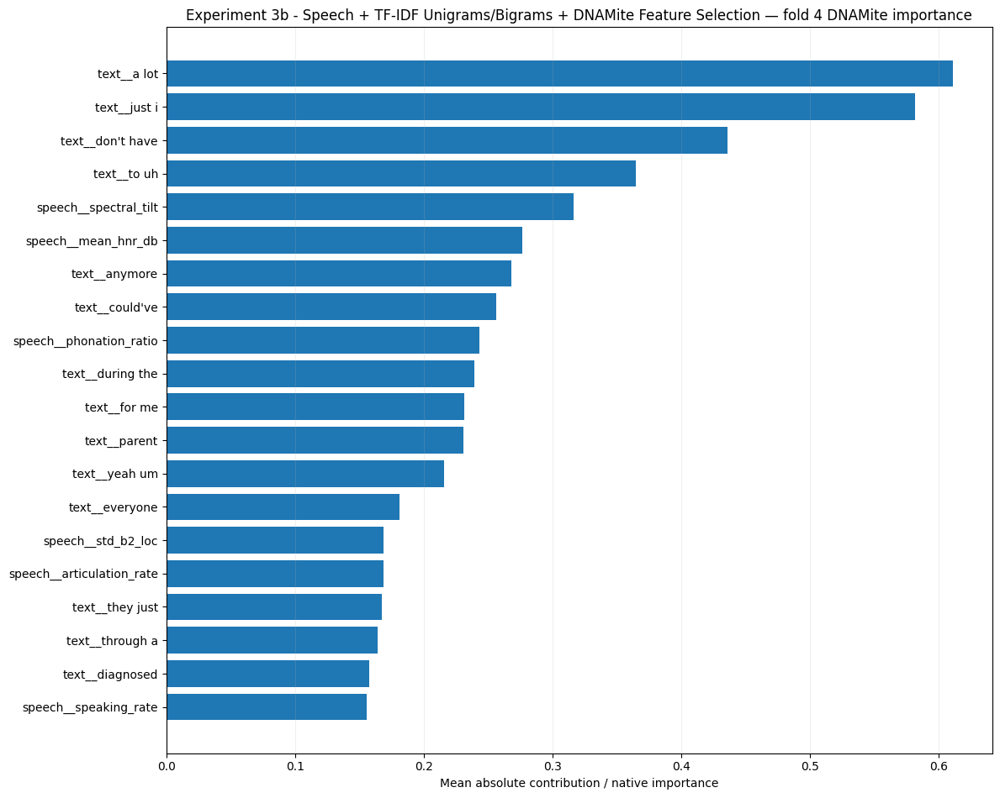

ROC_AUC              0.559211
PR_AUC               0.454337
AUPRC                0.454337
Accuracy             0.370370
Balanced_Accuracy    0.480263
Precision            0.285714
Sensitivity          0.750000
Specificity          0.210526
F1                   0.413793
Brier_Score          0.207492
Log_Loss             0.605426
Threshold            0.300000
dtype: float64

Experiment 3b - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Classification | Outer fold 5
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 28 / 36
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis']
DNAMite epochs | split=1 | ran=66 | best=36 | best val_loss=0.443676 | hit ceiling=False
  Inner fold 2/3
Selected 6 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feat

[WARNING] Found selected features. Using only those features.


DNAMite active features | 13 / 34
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope']
DNAMite epochs | split=1 | ran=92 | best=62 | best val_loss=0.578873 | hit ceiling=False
  Inner fold 3/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


...

DNAMite active features | 3 / 34
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio']
DNAMite epochs | split=1 | ran=61 | best=31 | best val_loss=0.666791 | hit ceiling=False
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 3 / 37
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio']
DNAMite epochs | split=1 | ran=108 | best=78 | best val_loss=0.430682 | hit ceiling=False
Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.01


[WARNING] Found selected features. Using only those features.


DNAMite active features | 5 / 45
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration']
DNAMite epochs | split=1 | ran=138 | best=108 | best val_loss=0.422450 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.614349283001502, 'peak_ram_mb': 3381.78515625, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Outer-fold energy / emissions:
{'training_energy_kwh': 4.623912440403218e-05, 'training_co2_kg': 1.820598488976759e-07}
Saved resource metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/resources/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_05.json
Saved energy metrics to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/energy/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_05.json
Saved outer-fold model to: /content/drive/MyDrive

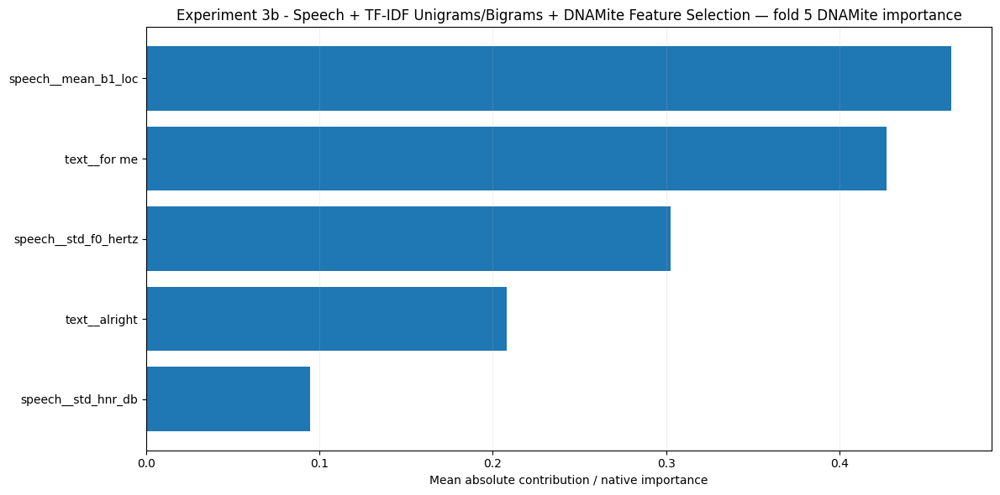

ROC_AUC              0.473684
PR_AUC               0.279280
AUPRC                0.279280
Accuracy             0.370370
Balanced_Accuracy    0.407895
Precision            0.235294
Sensitivity          0.500000
Specificity          0.315789
F1                   0.320000
Brier_Score          0.208629
Log_Loss             0.607681
Threshold            0.305000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.435526,0.114273
PR_AUC,0.312794,0.110804
AUPRC,0.312794,0.110804
Accuracy,0.429630,0.158439
Balanced_Accuracy,0.464474,0.041505
Precision,0.213461,0.121922
Sensitivity,0.550000,0.370810
Specificity,0.378947,0.374758
F1,0.304854,0.179608
Brier_Score,0.208849,0.001265



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,True,0.0010,45,11,"[speech__speaking_rate, speech__articulation_r..."
1,2,True,0.0050,45,18,"[speech__speaking_rate, speech__articulation_r..."
2,3,True,0.0001,48,20,"[speech__speaking_rate, speech__articulation_r..."
3,4,True,0.0005,47,37,"[speech__speaking_rate, speech__articulation_r..."
4,5,True,0.0100,45,5,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 3b
# Speech + TF-IDF Unigrams/Bigrams
# + DNAMite Feature Selection
# Classification Nested Cross-Validation
# ============================================================

EXPERIMENT_3B_NAME = (
    "Experiment 3b - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "DNAMite Feature Selection"
)


experiment_3b_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_3B_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        use_feature_selection=True,
    )
)

### Experiment 3b Nested CV Results

In [ ]:
# ============================================================
# Experiment 3b
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_3b_binary_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_3b_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,feature_selection_enabled,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0010,16,16,2,0.0010,True,45,11,...,0.000000,0.208822,0.608470,0.315,0.964303,3514.222656,16.518066,22.0,0.000023,9.121119e-08
1,2,32,0.0010,32,32,2,0.0050,True,45,18,...,0.457143,0.210922,0.613629,0.245,1.044502,3381.664062,16.518066,22.0,0.000026,1.037239e-07
2,3,8,0.0005,16,32,2,0.0001,True,48,20,...,0.333333,0.208381,0.607693,0.295,3.850972,3381.921875,16.518066,22.0,0.000122,4.798221e-07
3,4,8,0.0005,16,16,2,0.0005,True,47,37,...,0.413793,0.207492,0.605426,0.300,2.057776,3403.691406,16.518066,22.0,0.000061,2.383729e-07
4,5,16,0.0005,32,16,2,0.0100,True,45,5,...,0.320000,0.208629,0.607681,0.305,1.614349,3381.785156,16.518066,22.0,0.000046,1.820598e-07



CV SUMMARY


,Mean,SD
ROC_AUC,0.435526,0.114273
PR_AUC,0.312794,0.110804
AUPRC,0.312794,0.110804
Accuracy,0.429630,0.158439
Balanced_Accuracy,0.464474,0.041505
Precision,0.213461,0.121922
Sensitivity,0.550000,0.370810
Specificity,0.378947,0.374758
F1,0.304854,0.179608
Brier_Score,0.208849,0.001265


In [ ]:
# ============================================================
# Experiment 3b
# Cross-Validation Performance
# ============================================================

experiment_3b_cv_metrics = (
    experiment_3b_binary_cv[
        "outer_results"
    ].copy()
)

experiment_3b_cv_summary = (
    experiment_3b_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_3b_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_3b_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,feature_selection_enabled,n_features_available,n_features_selected,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0010,16,16,2,0.0010,True,45,11,...,0.000000,0.208822,0.608470,0.315,0.964303,3514.222656,16.518066,22.0,0.000023,9.121119e-08
1,2,32,0.0010,32,32,2,0.0050,True,45,18,...,0.457143,0.210922,0.613629,0.245,1.044502,3381.664062,16.518066,22.0,0.000026,1.037239e-07
2,3,8,0.0005,16,32,2,0.0001,True,48,20,...,0.333333,0.208381,0.607693,0.295,3.850972,3381.921875,16.518066,22.0,0.000122,4.798221e-07
3,4,8,0.0005,16,16,2,0.0005,True,47,37,...,0.413793,0.207492,0.605426,0.300,2.057776,3403.691406,16.518066,22.0,0.000061,2.383729e-07
4,5,16,0.0005,32,16,2,0.0100,True,45,5,...,0.320000,0.208629,0.607681,0.305,1.614349,3381.785156,16.518066,22.0,0.000046,1.820598e-07



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.435526,0.114273
PR_AUC,0.312794,0.110804
AUPRC,0.312794,0.110804
Accuracy,0.429630,0.158439
Balanced_Accuracy,0.464474,0.041505
Precision,0.213461,0.121922
Sensitivity,0.550000,0.370810
Specificity,0.378947,0.374758
F1,0.304854,0.179608
Brier_Score,0.208849,0.001265


In [ ]:
# ============================================================
# Experiment 3b
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_3b_parameters = (
    experiment_3b_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "selection_reg_param",
        ]
    ]
    .copy()
)

display(
    experiment_3b_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param
0,1,8,0.0010,16,16,2,0.0010
1,2,32,0.0010,32,32,2,0.0050
2,3,8,0.0005,16,32,2,0.0001
3,4,8,0.0005,16,16,2,0.0005
4,5,16,0.0005,32,16,2,0.0100



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


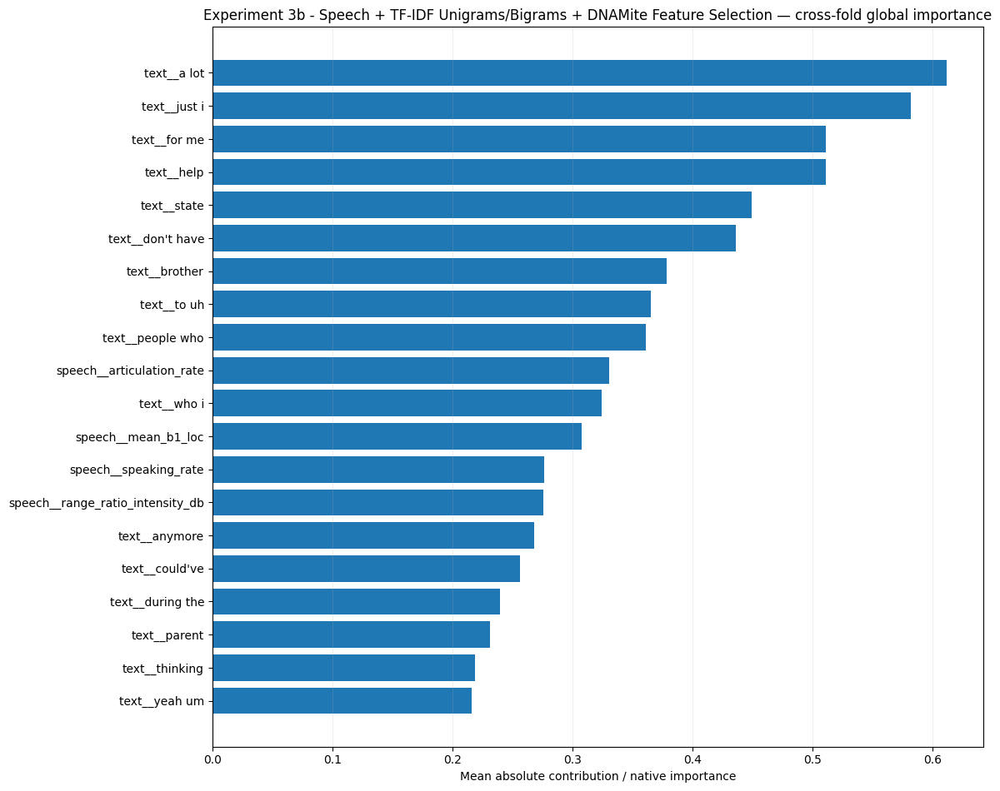

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 3b
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams/Bigrams
# + DNAMite Feature Selection
# ============================================================

experiment_3b_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_3B_NAME
        ),
        top_k=30,
    )
)

experiment_3b_interpretability

In [ ]:
# ============================================================
# Experiment 3b
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_3b_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_3B_NAME)
)


experiment_3b_development_rows = []

for path in sorted(
    experiment_3b_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_3b_development_rows.append(
            json.load(file)
        )


experiment_3b_development_df = (
    pd.DataFrame(
        experiment_3b_development_rows
    )
)

display(
    experiment_3b_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,classification,1,672,956.348552,0.026223,0.000103,3514.328125,16.518066,22.0
1,DNAMite Optimized,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,classification,2,672,1006.177996,0.027836,0.000110,3381.757812,16.518066,22.0
2,DNAMite Optimized,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,classification,3,672,956.532973,0.026074,0.000103,3381.980469,16.518066,22.0
3,DNAMite Optimized,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,classification,4,672,858.345209,0.022786,0.000090,3403.796875,16.518066,22.0
4,DNAMite Optimized,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,classification,5,672,912.321777,0.024628,0.000097,3381.855469,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 3b
# Development Cost Summary
# ============================================================

experiment_3b_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_3b_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3b_development_df[
                    experiment_3b_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_3b_development_df[
                    experiment_3b_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3b_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_3b_development_summary[
            "Mean"
        ],
        experiment_3b_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_3b_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,672.000000,0.000000,672.000000 ± 0.000000
development_seconds,937.945301,55.526168,937.945301 ± 55.526168
development_energy_kwh,0.025509,0.001900,0.025509 ± 0.001900
development_co2_kg,0.000100,0.000007,0.000100 ± 0.000007


In [ ]:
# ============================================================
# Experiment 3b
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_3b_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_3b_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3b_binary_cv[
                    "outer_results"
                ][
                    experiment_3b_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_3b_binary_cv[
                    "outer_results"
                ][
                    experiment_3b_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3b_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_3b_training_summary[
            "Mean"
        ],
        experiment_3b_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_3b_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,1.906380e+00,1.174732e+00,1.90638033 ± 1.17473217
peak_ram_mb,3.412657e+03,5.756354e+01,3412.65703125 ± 57.56354146
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,5.563075e-05,4.003404e-05,0.00005563 ± 0.00004003
training_co2_kg,2.190380e-07,1.576282e-07,0.00000022 ± 0.00000016


In [ ]:
# ============================================================
# Experiment 3b
# Speech + TF-IDF Unigrams/Bigrams
# + DNAMite Feature Selection
# Final Classification Model
# ============================================================

EXPERIMENT_3B_NAME = (
    "Experiment 3b - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "DNAMite Feature Selection"
)

experiment_3b_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        experiment_name=(
            EXPERIMENT_3B_NAME
        ),
        use_feature_selection=True,
        save_outputs=True,
    )
)

DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 15 / 39
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean']
DNAMite epochs | split=1 | ran=94 | best=64 | best val_loss=0.589571 | hit ceiling=False
  Inner fold 2/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 35 / 38
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a walk', 'text__brother', 'text__for me', "text__it it's", 'text__money', 'text__my family', 'text__parent']
DNAMite epochs | split=1 | ran=275 | best=245 | best val_loss=0.247308 | hit ceiling=

...

DNAMite active features | 18 / 41
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc']
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.697041 | hit ceiling=False
Selected 13 TF-IDF features for classification / unigram_bigram using C=5.0
Running DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 17 / 41
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc']
DNAMite epochs | split=1 | ran=40 | best=10 | best val_loss=0.636649 | hit ceiling=False
Selected probability threshold: 0.295
Development OOF balanced accuracy at threshold: 0.5059
Selected 28 TF-IDF features for classification / unigram_bigram using C=5.0
Running final DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


Final DNAMite active features: 4 / 56
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 61, 'best_epoch': 31, 'best_val_loss': 0.6368111371994019, 'hit_epoch_ceiling': False}]

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection
Final model saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/models/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_00/final_model_bundle.pkl

Final test results saved to:
/content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/DNAMite_Optimized/Experiment_3b_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection


In [ ]:
# ============================================================
# Experiment 3b
# Final Feature Selection
# ============================================================

print(
    "Selection regularization parameter:",
    experiment_3b_binary_final[
        "selection_reg_param"
    ],
)

print(
    "\nNumber of selected features:",
    len(
        experiment_3b_binary_final[
            "active_feature_names"
        ]
    ),
)

print(
    "\nSelected features:"
)

display(
    pd.DataFrame(
        {
            "Feature": (
                experiment_3b_binary_final[
                    "active_feature_names"
                ]
            )
        }
    )
)

Selection regularization parameter: 0.005

Number of selected features: 4

Selected features:


,Feature
0,speech__speaking_rate
1,speech__articulation_rate
2,speech__phonation_ratio
3,speech__pause_rate


In [ ]:
# ============================================================
# Experiment 3b
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_3b_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.470982
PR_AUC,0.340850
AUPRC,0.340850
Accuracy,0.304348
Balanced_Accuracy,0.500000
Precision,0.304348
Sensitivity,1.000000
Specificity,0.000000
F1,0.466667
Brier_Score,0.211757


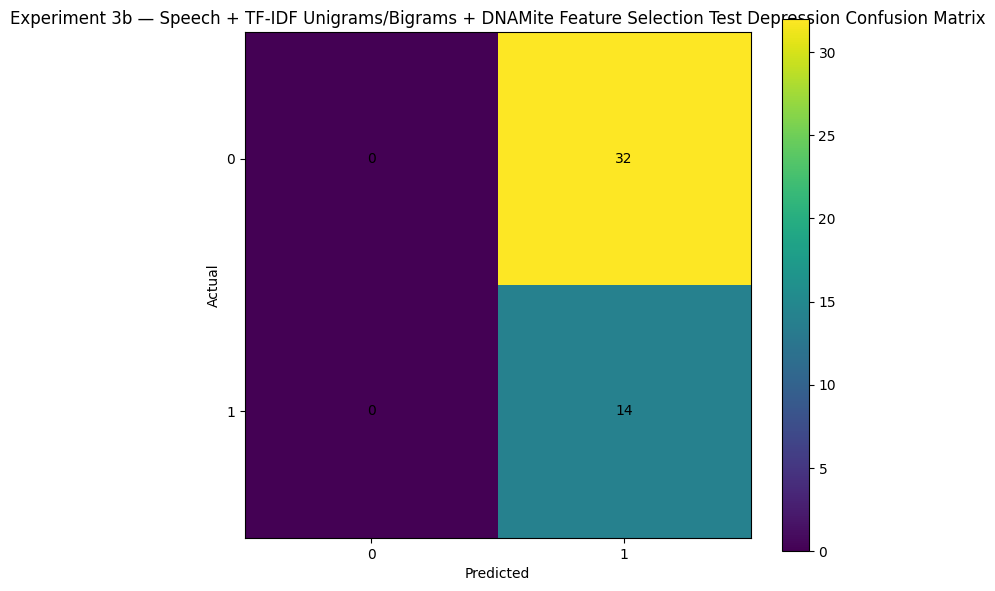

array([[ 0, 32],
       [ 0, 14]])

In [ ]:
# ============================================================
# Experiment 3b
# Final Test Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_3b_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 3b — "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "DNAMite Feature Selection "
        "Test Depression Confusion Matrix"
    ),
)

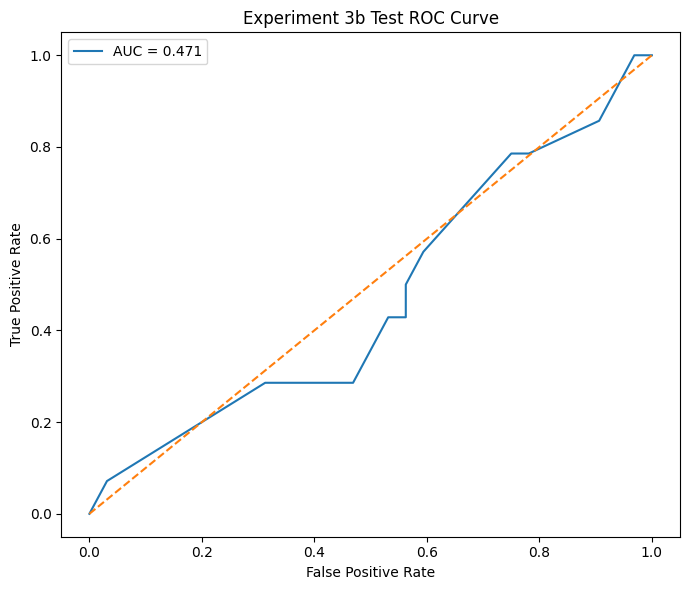

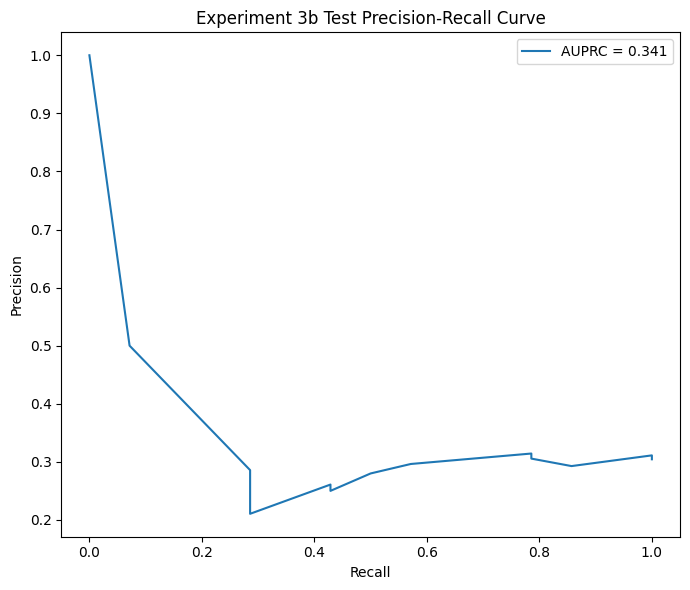

In [ ]:
# ============================================================
# Experiment 3b
# Final Test Classification Curves
# ============================================================

plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_3b_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 3b Test"
    ),
)

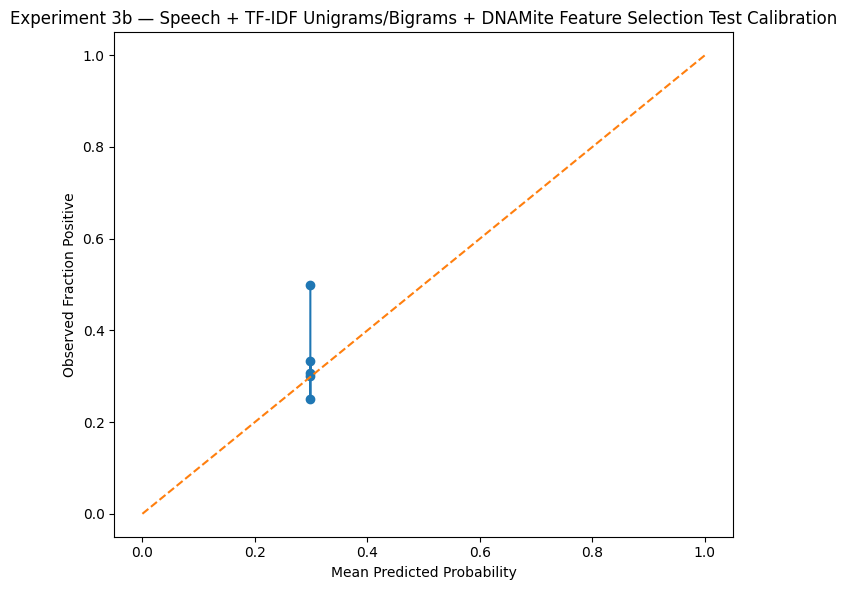

,mean_predicted_probability,observed_fraction_positive,n
0,0.298398,0.300000,10
1,0.298446,0.333333,9
2,0.298526,0.307692,13
3,0.298585,0.250000,12
4,0.298614,0.500000,2


In [ ]:
# ============================================================
# Experiment 3b
# Final Test Calibration
# ============================================================

plot_calibration_curve_manual(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_3b_binary_final[
            "test_probabilities"
        ]
    ),
    n_bins=5,
    title=(
        "Experiment 3b — "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "DNAMite Feature Selection "
        "Test Calibration"
    ),
)

,split,feature,importance,n_bins
0,0,speech__std_intensity_db,0.003874,3
1,0,text__couldn't,0.000909,3
2,0,text__people i,0.001058,3
3,0,text__therapist,0.000337,3


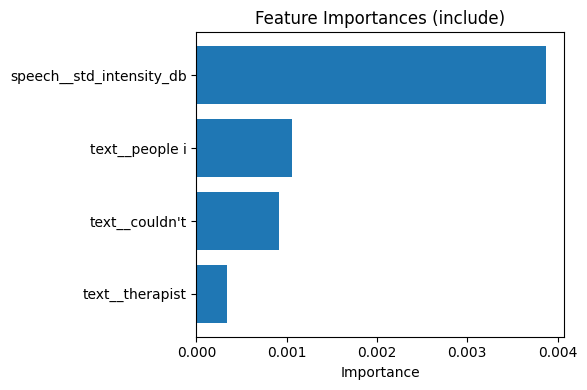

In [ ]:
# ============================================================
# Experiment 3b
# Final Model Feature Importance
# ============================================================

experiment_3b_binary_importance = (
    show_feature_importance(
        experiment_3b_binary_final[
            "model"
        ],
        top_n=30,
    )
)

### Comparison 3a vs. 3b Test Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3A VS 3B — TEST COMPARISON
# No Feature Selection vs DNAMite Feature Selection
# ============================================================

experiment_3a_vs_3b_binary_test = (
    pd.DataFrame(
        {
            "Experiment 3a - No Selection": (
                experiment_3a_binary_final[
                    "test_metrics"
                ]
            ),

            "Experiment 3b - DNAMite Selection": (
                experiment_3b_binary_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_3a_vs_3b_binary_test
)

,Experiment 3a - No Selection,Experiment 3b - DNAMite Selection
ROC_AUC,0.417411,0.470982
PR_AUC,0.255266,0.340850
AUPRC,0.255266,0.340850
Accuracy,0.608696,0.304348
Balanced_Accuracy,0.457589,0.500000
Precision,0.166667,0.304348
Sensitivity,0.071429,1.000000
Specificity,0.843750,0.000000
F1,0.100000,0.466667
Brier_Score,0.215167,0.211757


### Compare 3a vs. 3b Nested CV Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3A VS 3B — CV COMPARISON
# Mean ± SD Across Outer Folds
# ============================================================

experiment_3a_vs_3b_binary_cv = (
    pd.DataFrame(
        {
            "Experiment 3a - No Selection": (
                experiment_3a_binary_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 3b - DNAMite Selection": (
                experiment_3b_binary_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_3a_vs_3b_binary_cv
)

,Experiment 3a - No Selection,Experiment 3b - DNAMite Selection
ROC_AUC,0.4855 ± 0.1039,0.4355 ± 0.1143
PR_AUC,0.3594 ± 0.0930,0.3128 ± 0.1108
AUPRC,0.3594 ± 0.0930,0.3128 ± 0.1108
Accuracy,0.3630 ± 0.1294,0.4296 ± 0.1584
Balanced_Accuracy,0.4822 ± 0.0362,0.4645 ± 0.0415
Precision,0.2849 ± 0.0201,0.2135 ± 0.1219
Sensitivity,0.7750 ± 0.3354,0.5500 ± 0.3708
Specificity,0.1895 ± 0.3193,0.3789 ± 0.3748
F1,0.3990 ± 0.0857,0.3049 ± 0.1796
Brier_Score,0.2153 ± 0.0130,0.2088 ± 0.0013


### Experiment 3c regression nested CV

Using severity-stratified master regression folds.

Experiment 3c - Speech + TF-IDF Unigrams/Bigrams | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 77 / 77
DNAMite epochs | split=1 | ran=44 | best=14 | best val_loss=0.820282 | hit ceiling=False
  Inner fold 2/3
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 76 / 76
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=1.081263 | hit ceiling=False
  Inner fold 3/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.475087 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.00

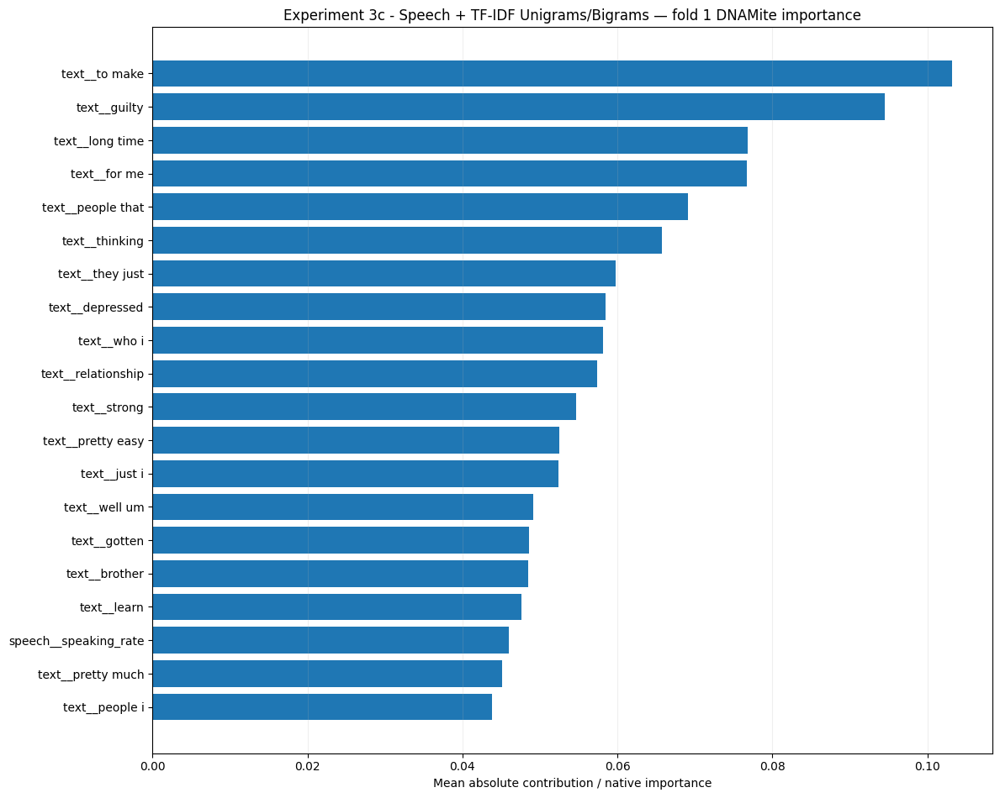

MAE               3.940817
RMSE              5.344109
R2               -0.029973
Spearman_Rho      0.382427
Spearman_P        0.048989
Pearson_R         0.252740
Pearson_P         0.203407
Exact_Accuracy    0.148148
Within_1          0.370370
Within_2          0.481481
Within_3          0.555556
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 3c - Speech + TF-IDF Unigrams/Bigrams | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.817631 | hit ceiling=False
  Inner fold 2/3
Selected 37 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNA

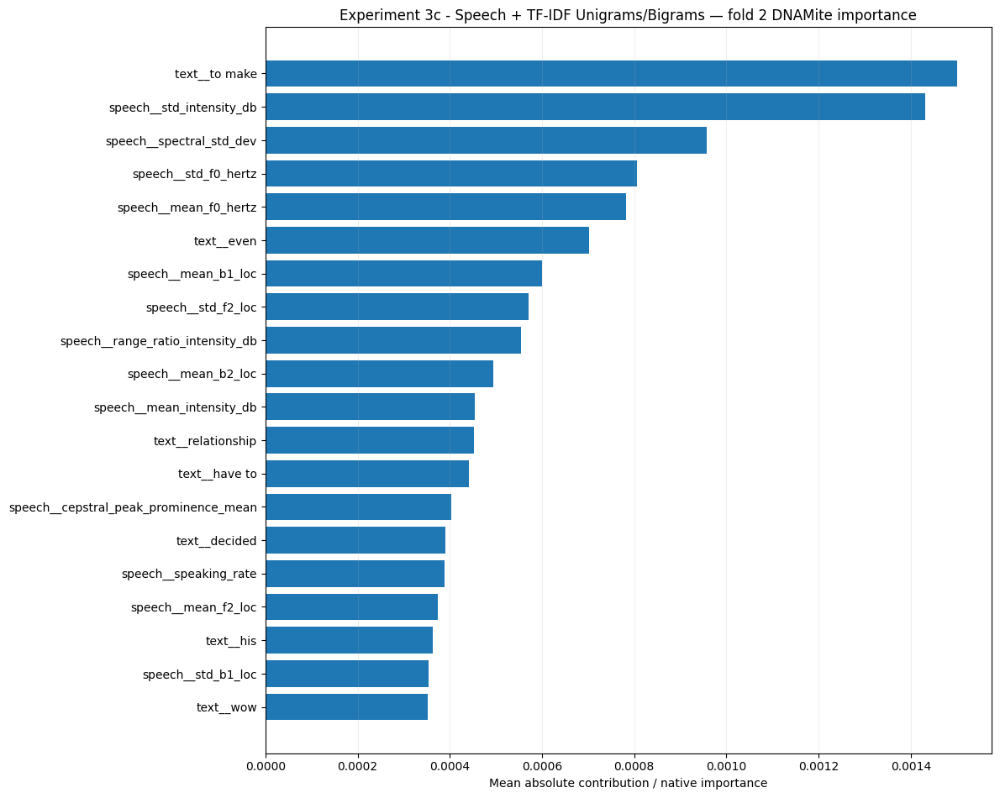

MAE               4.903463
RMSE              6.739272
R2               -0.163863
Spearman_Rho      0.036509
Spearman_P        0.856532
Pearson_R         0.080011
Pearson_P         0.691577
Exact_Accuracy    0.037037
Within_1          0.259259
Within_2          0.333333
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 3c - Speech + TF-IDF Unigrams/Bigrams | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 50 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 78 / 78
DNAMite epochs | split=1 | ran=369 | best=339 | best val_loss=0.545939 | hit ceiling=False
  Inner fold 2/3
Selected 40 TF-IDF features for regression / unigram_bigram using alpha=0.01


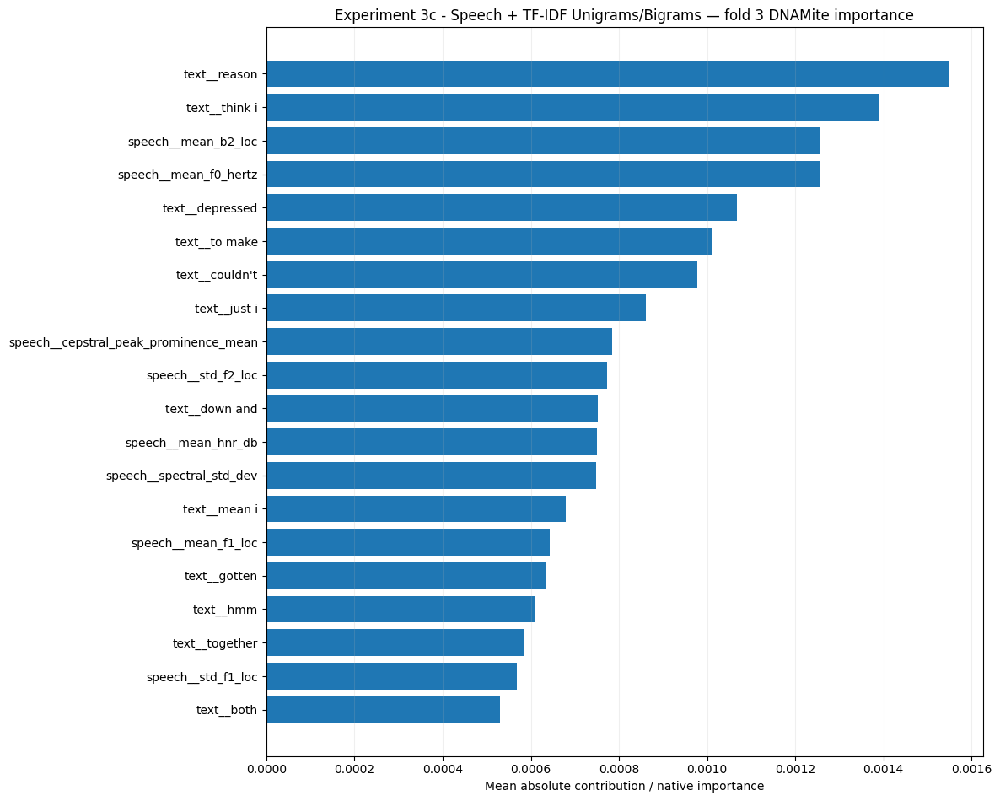

MAE               4.616683
RMSE              5.643133
R2               -0.012251
Spearman_Rho     -0.016861
Spearman_P        0.933476
Pearson_R        -0.029095
Pearson_P         0.885454
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.444444
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 3c - Speech + TF-IDF Unigrams/Bigrams | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=327 | best=297 | best val_loss=0.158224 | hit ceiling=False
  Inner fold 2/3
Selected 51 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAM

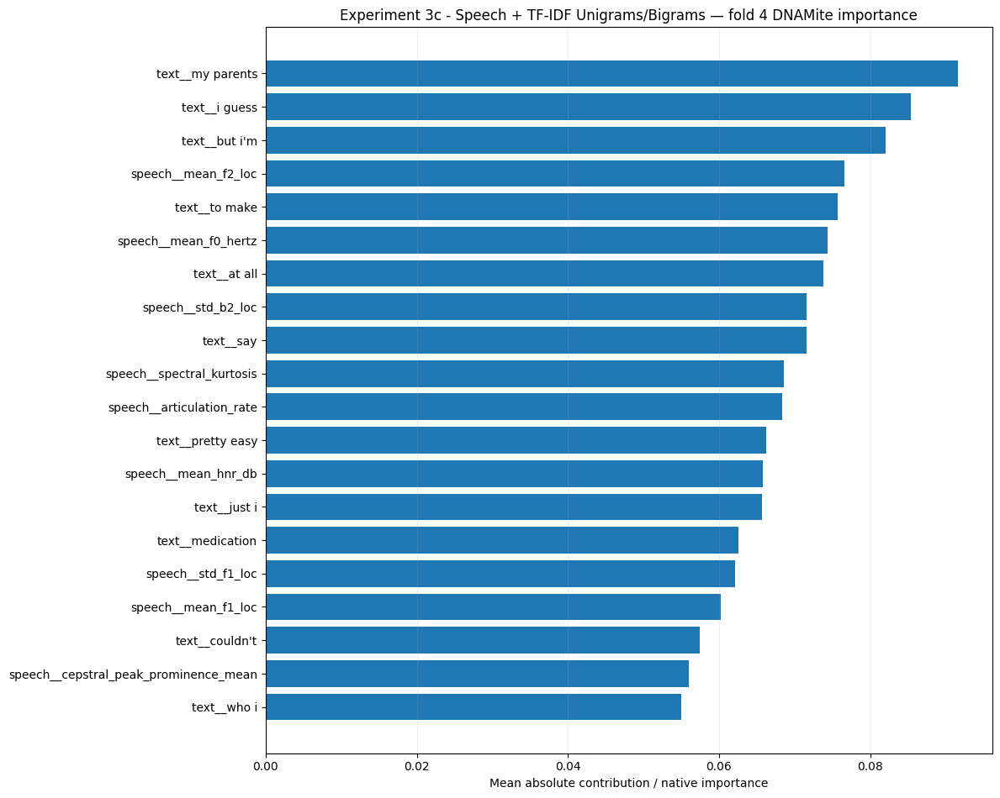

MAE               3.533367
RMSE              4.639325
R2                0.173052
Spearman_Rho      0.368875
Spearman_P        0.058301
Pearson_R         0.447811
Pearson_P         0.019162
Exact_Accuracy    0.111111
Within_1          0.370370
Within_2          0.518519
Within_3          0.592593
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 3c - Speech + TF-IDF Unigrams/Bigrams | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 75 / 75
DNAMite epochs | split=1 | ran=68 | best=38 | best val_loss=0.720312 | hit ceiling=False
  Inner fold 2/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAM

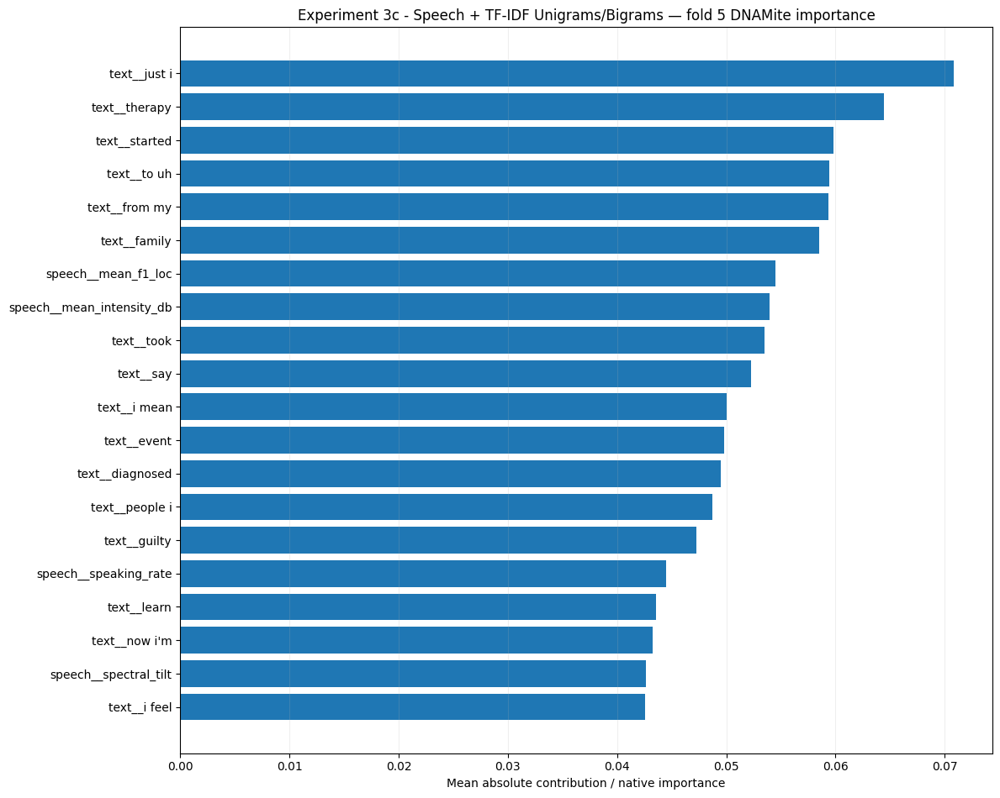

MAE               4.449657
RMSE              5.437814
R2                0.065447
Spearman_Rho      0.289000
Spearman_P        0.143730
Pearson_R         0.294283
Pearson_P         0.136223
Exact_Accuracy    0.148148
Within_1          0.185185
Within_2          0.259259
Within_3          0.296296
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.288798,0.548398
RMSE,5.560731,0.759403
R2,0.006482,0.124418
Spearman_Rho,0.211990,0.188917
Pearson_R,0.209150,0.186778
Exact_Accuracy,0.088889,0.067281
Within_1,0.274074,0.092962
Within_2,0.377778,0.115351
Within_3,0.466667,0.115944



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 3c
# Speech + TF-IDF Unigrams/Bigrams
# Regression Nested Cross-Validation
# ============================================================

EXPERIMENT_3C_NAME = (
    "Experiment 3c - "
    "Speech + TF-IDF Unigrams/Bigrams"
)


experiment_3c_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_3C_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 3c
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_3c_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_3c_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,MAE,RMSE,R2,Spearman_Rho,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,16,32,2,3.940817,5.344109,-0.029973,0.382427,...,0.555556,4.334362,5.267151,-0.000523,2.354650,3405.007812,16.518066,22.0,0.000070,2.746129e-07
1,2,4,0.0005,16,32,2,4.903463,6.739272,-0.163863,0.036509,...,0.444444,4.996914,6.247201,-0.000108,1.046079,3418.425781,16.518066,22.0,0.000025,9.672452e-08
2,3,4,0.0005,16,16,2,4.616683,5.643133,-0.012251,-0.016861,...,0.444444,4.607339,5.614449,-0.001987,1.632555,3417.707031,16.518066,22.0,0.000046,1.823043e-07
3,4,16,0.0005,32,16,2,3.533367,4.639325,0.173052,0.368875,...,0.592593,4.469822,5.104431,-0.001067,2.338538,3417.878906,16.518066,22.0,0.000069,2.728121e-07
4,5,32,0.0005,32,16,2,4.449657,5.437814,0.065447,0.289000,...,0.296296,4.728052,5.625067,-0.000024,2.294428,3418.085938,16.518066,22.0,0.000067,2.639013e-07



CV SUMMARY


,Mean,SD
MAE,4.288798,0.548398
RMSE,5.560731,0.759403
R2,0.006482,0.124418
Spearman_Rho,0.211990,0.188917
Pearson_R,0.209150,0.186778
Exact_Accuracy,0.088889,0.067281
Within_1,0.274074,0.092962
Within_2,0.377778,0.115351
Within_3,0.466667,0.115944


In [ ]:
# ============================================================
# Experiment 3c
# Cross-Validation Performance
# ============================================================

experiment_3c_cv_metrics = (
    experiment_3c_regression_cv[
        "outer_results"
    ].copy()
)

experiment_3c_cv_summary = (
    experiment_3c_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_3c_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_3c_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,MAE,RMSE,R2,Spearman_Rho,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,16,32,2,3.940817,5.344109,-0.029973,0.382427,...,0.555556,4.334362,5.267151,-0.000523,2.354650,3405.007812,16.518066,22.0,0.000070,2.746129e-07
1,2,4,0.0005,16,32,2,4.903463,6.739272,-0.163863,0.036509,...,0.444444,4.996914,6.247201,-0.000108,1.046079,3418.425781,16.518066,22.0,0.000025,9.672452e-08
2,3,4,0.0005,16,16,2,4.616683,5.643133,-0.012251,-0.016861,...,0.444444,4.607339,5.614449,-0.001987,1.632555,3417.707031,16.518066,22.0,0.000046,1.823043e-07
3,4,16,0.0005,32,16,2,3.533367,4.639325,0.173052,0.368875,...,0.592593,4.469822,5.104431,-0.001067,2.338538,3417.878906,16.518066,22.0,0.000069,2.728121e-07
4,5,32,0.0005,32,16,2,4.449657,5.437814,0.065447,0.289000,...,0.296296,4.728052,5.625067,-0.000024,2.294428,3418.085938,16.518066,22.0,0.000067,2.639013e-07



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.288798,0.548398
RMSE,5.560731,0.759403
R2,0.006482,0.124418
Spearman_Rho,0.211990,0.188917
Pearson_R,0.209150,0.186778
Exact_Accuracy,0.088889,0.067281
Within_1,0.274074,0.092962
Within_2,0.377778,0.115351
Within_3,0.466667,0.115944


In [ ]:
# ============================================================
# Experiment 3c
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_3c_parameters = (
    experiment_3c_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
        ]
    ]
    .copy()
)

display(
    experiment_3c_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers
0,1,16,0.0005,16,32,2
1,2,4,0.0005,16,32,2
2,3,4,0.0005,16,16,2
3,4,16,0.0005,32,16,2
4,5,32,0.0005,32,16,2



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3c_-_Speech_TF-IDF_Unigrams_Bigrams
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


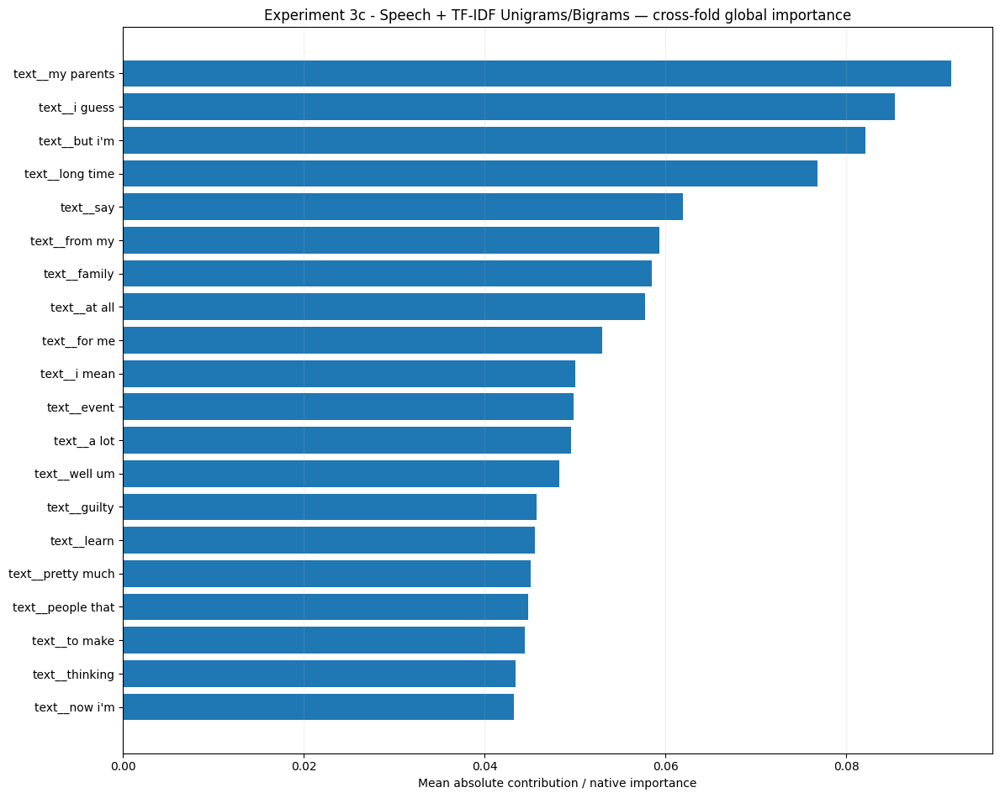

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3c_-_Speech_TF-IDF_Unigrams_Bigrams/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 3c
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams/Bigrams
# ============================================================

experiment_3c_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_3C_NAME
        ),
        top_k=30,
    )
)

experiment_3c_interpretability

In [ ]:
# ============================================================
# Experiment 3c
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_3c_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_3C_NAME)
)


experiment_3c_development_rows = []

for path in sorted(
    experiment_3c_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_3c_development_rows.append(
            json.load(file)
        )


experiment_3c_development_df = (
    pd.DataFrame(
        experiment_3c_development_rows
    )
)

display(
    experiment_3c_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,regression,1,96,127.069580,0.003356,0.000013,3405.031250,16.518066,22.0
1,DNAMite Optimized,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,regression,2,96,175.183996,0.004964,0.000020,3418.449219,16.518066,22.0
2,DNAMite Optimized,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,regression,3,96,197.180995,0.005723,0.000023,3417.765625,16.518066,22.0
3,DNAMite Optimized,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,regression,4,96,182.996743,0.005234,0.000021,3417.914062,16.518066,22.0
4,DNAMite Optimized,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,regression,5,96,165.903578,0.004658,0.000018,3418.109375,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 3c
# Development Cost Summary
# ============================================================

experiment_3c_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_3c_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3c_development_df[
                    experiment_3c_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_3c_development_df[
                    experiment_3c_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3c_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_3c_development_summary[
            "Mean"
        ],
        experiment_3c_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_3c_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,96.000000,0.000000,96.000000 ± 0.000000
development_seconds,169.666978,26.428407,169.666978 ± 26.428407
development_energy_kwh,0.004787,0.000891,0.004787 ± 0.000891
development_co2_kg,0.000019,0.000004,0.000019 ± 0.000004


In [ ]:
# ============================================================
# Experiment 3c
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_3c_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_3c_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3c_regression_cv[
                    "outer_results"
                ][
                    experiment_3c_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_3c_regression_cv[
                    "outer_results"
                ][
                    experiment_3c_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3c_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_3c_training_summary[
            "Mean"
        ],
        experiment_3c_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_3c_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,1.933250e+00,5.808990e-01,1.93324992 ± 0.58089905
peak_ram_mb,3.415421e+03,5.827356e+00,3415.42109375 ± 5.82735614
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,5.538515e-05,1.979487e-05,0.00005539 ± 0.00001979
training_co2_kg,2.180710e-07,7.793942e-08,0.00000022 ± 0.00000008


### Experiment 3c final regression

In [ ]:
# ============================================================
# Experiment 3c
# Speech + TF-IDF Unigrams/Bigrams
# Final Regression Model
# ============================================================

EXPERIMENT_3C_NAME = (
    "Experiment 3c - "
    "Speech + TF-IDF Unigrams/Bigrams"
)

experiment_3c_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        experiment_name=(
            EXPERIMENT_3C_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2}
  Inner fold 1/3
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 77 / 77
DNAMite epochs | split=1 | ran=499 | best=469 | best val_loss=0.444242 | hit ceiling=False
  Inner fold 2/3
Selected 56 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 84 / 84
DNAMite epochs | split=1 | ran=33 | best=3 | best val_loss=0.409333 | hit ceiling=False
  Inner fold 3/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=48 | best=18 | best val_loss=1.457448 | hit ceiling=False
DNAMite candidate 2/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2}
  Inner fold 1/3
Selected 49 TF-IDF features for regression 

In [ ]:
# ============================================================
# Experiment 3c
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_3c_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,5.384859
RMSE,6.433423
R2,-0.007106
Spearman_Rho,0.292834
Spearman_P,0.048271
Pearson_R,0.279976
Pearson_P,0.059495
Exact_Accuracy,0.021739
Within_1,0.130435
Within_2,0.282609


### Experiment 3c regression plots

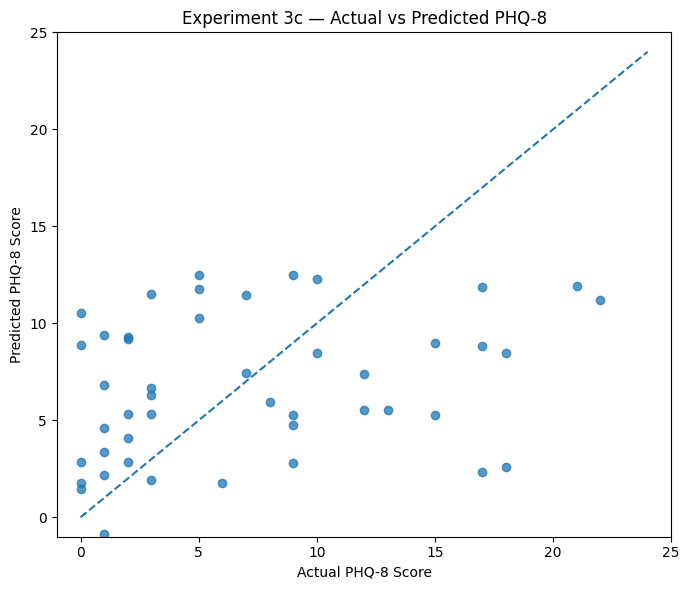

In [ ]:
# ============================================================
# Experiment 3c
# Actual vs Predicted PHQ-8
# ============================================================

plot_regression_predictions(
    y_true=(
        y_regression_test
    ),
    predictions=(
        experiment_3c_regression_final[
            "test_predictions"
        ]
    ),
    title=(
        "Experiment 3c — "
        "Actual vs Predicted PHQ-8"
    ),
)

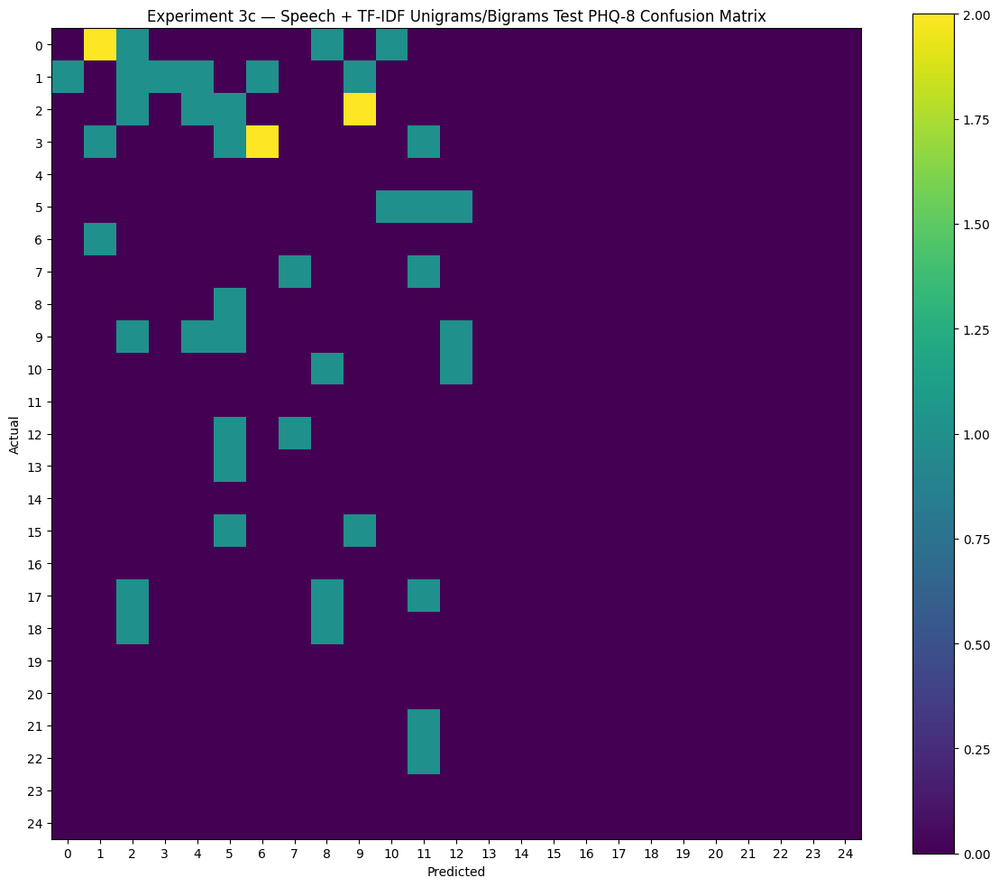

array([[0, 2, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 1, 0, 1, 1, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 1, 0, 0, 0, 1, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 3c
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_3c_regression_final[
                "test_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 3c — "
        "Speech + TF-IDF Unigrams/Bigrams "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

### Experiment 3c regression feature importance

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.022866,7
1,0,speech__articulation_rate,0.021262,7
2,0,speech__phonation_ratio,0.002833,7
3,0,speech__pause_rate,0.009703,7
4,0,speech__mean_pause_duration,0.004081,7
5,0,speech__mean_f0_hertz,0.011287,7
6,0,speech__std_f0_hertz,0.011940,7
7,0,speech__mean_intensity_db,0.003175,7
8,0,speech__std_intensity_db,0.007339,7
9,0,speech__range_ratio_intensity_db,0.011641,7


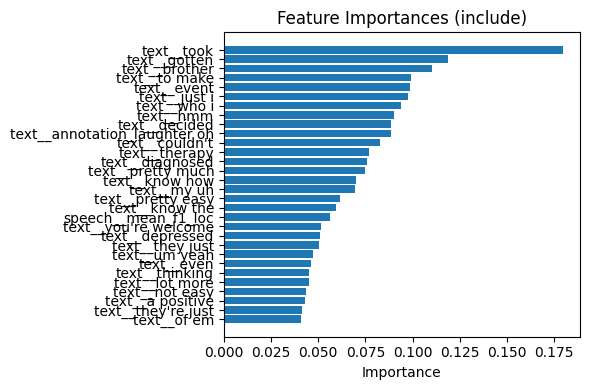

In [ ]:
# ============================================================
# Experiment 3c
# Final Model Feature Importance
# ============================================================

experiment_3c_regression_importance = (
    show_feature_importance(
        experiment_3c_regression_final[
            "model"
        ],
        top_n=30,
    )
)

### Compare 2c vs. 3c

In [ ]:
# ============================================================
# EXPERIMENT 2C VS 3C — TEST COMPARISON
# ============================================================

experiment_2c_vs_3c_regression_test = (
    pd.DataFrame(
        {
            "Experiment 2c - Unigrams": (
                experiment_2c_regression_final[
                    "test_metrics"
                ]
            ),

            "Experiment 3c - Unigrams/Bigrams": (
                experiment_3c_regression_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_2c_vs_3c_regression_test
)

,Experiment 2c - Unigrams,Experiment 3c - Unigrams/Bigrams
MAE,5.076773,5.384859
RMSE,6.348446,6.433423
R2,0.019323,-0.007106
Spearman_Rho,0.306637,0.292834
Spearman_P,0.038200,0.048271
Pearson_R,0.235860,0.279976
Pearson_P,0.114563,0.059495
Exact_Accuracy,0.021739,0.021739
Within_1,0.173913,0.130435
Within_2,0.347826,0.282609


In [ ]:
# ============================================================
# EXPERIMENT 2C VS 3C — CV COMPARISON
# Unigrams vs Unigrams + Bigrams
# ============================================================

experiment_2c_vs_3c_regression_cv = (
    pd.DataFrame(
        {
            "Experiment 2c - Unigrams": (
                experiment_2c_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 3c - Unigrams/Bigrams": (
                experiment_3c_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_2c_vs_3c_regression_cv
)

,Experiment 2c - Unigrams,Experiment 3c - Unigrams/Bigrams
MAE,4.7206 ± 0.5416,4.2888 ± 0.5484
RMSE,5.9259 ± 0.9681,5.5607 ± 0.7594
R2,-0.1322 ± 0.2320,0.0065 ± 0.1244
Spearman_Rho,0.0752 ± 0.2272,0.2120 ± 0.1889
Pearson_R,0.0452 ± 0.2609,0.2092 ± 0.1868
Exact_Accuracy,0.0593 ± 0.0497,0.0889 ± 0.0673
Within_1,0.1704 ± 0.0422,0.2741 ± 0.0930
Within_2,0.2889 ± 0.0483,0.3778 ± 0.1154
Within_3,0.4519 ± 0.0845,0.4667 ± 0.1159


### Experiment 3d Speech + TF-IDF Unigrams/Bigrams w/ Feature Selection

Using severity-stratified master regression folds.

Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 67 / 77
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__and you', 'text__animals', 'text__annotation_sigh uh', 'text__annotation_sniff', 'text__at all', 'text__bit of', 'text__brother', 'text__could be', 'text__dancing', 'text__depressed', 'text__dia

[WARNING] Found selected features. Using only those features.


DNAMite active features | 71 / 76
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a walk', 'text__alright', "text__and she's", 'text__and you', 'text__annotation_clears_throat', 'text__brother', 'text__child', 'text__country', 'text__court', 'text__depressed', "text__don't fe

...

DNAMite active features | 2 / 76
Active features: ['speech__speaking_rate', 'speech__articulation_rate']
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=1.117109 | hit ceiling=False
  Inner fold 3/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 10 / 74
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db']
DNAMite epochs | split=1 | ran=55 | best=25 | best val_loss=0.370177 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Inner-fold selected features: (62, 65.33333333333333, 69)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_01.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Selecte

[WARNING] Found selected features. Using only those features.


DNAMite active features | 83 / 88
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a walk', 'text__and you', 'text__animals', 'text__annotation_laughter oh', 'text__annotation_sigh uh', 'text__annotation_sniff', 'text__at all', 'text__brother', 'text__dancing', 'text__depresse

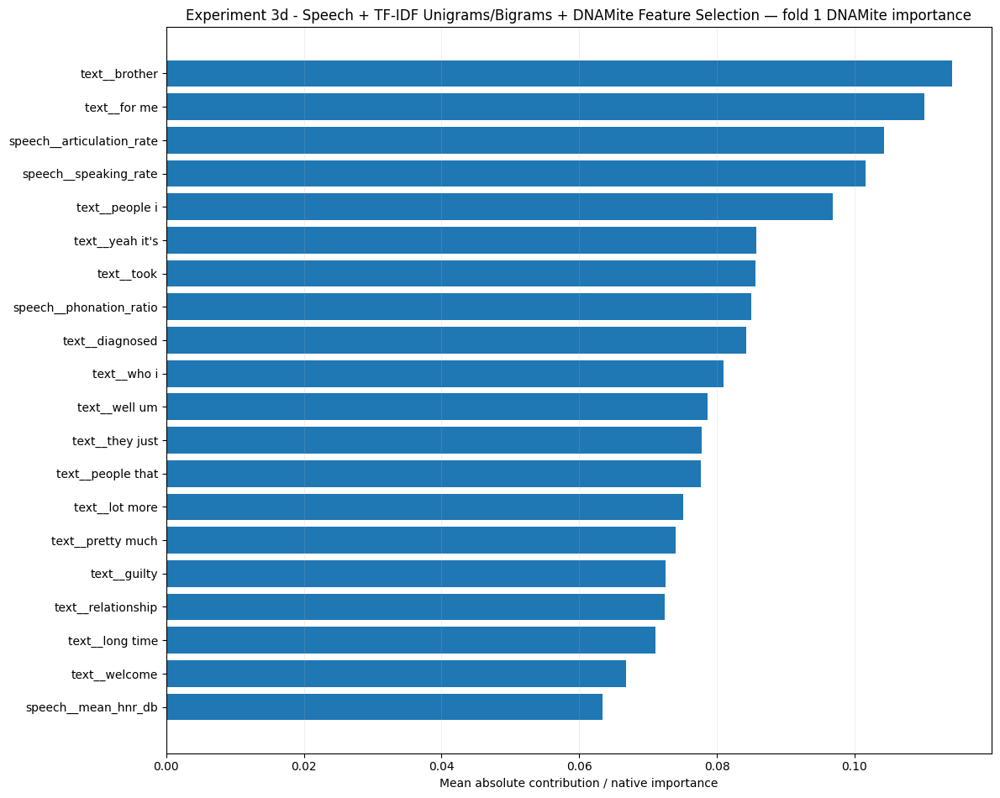

MAE               4.171828
RMSE              5.533816
R2               -0.104396
Spearman_Rho      0.288121
Spearman_P        0.145008
Pearson_R         0.206000
Pearson_P         0.302603
Exact_Accuracy    0.148148
Within_1          0.259259
Within_2          0.444444
Within_3          0.481481
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 65 / 74
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__asleep', 'text__at all', 'text__behavior', 'text__brother', "text__can't really", 'text__court', 'text__dancing', 'text__decided', 'text__different things', 'text__do and', 'text__erase', 'text_

[WARNING] Found selected features. Using only those features.


DNAMite active features | 59 / 65
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__and things', 'text__annotation_sniff', 'text__by the', 'text__dancing', 'text__daughter', 'text__decided', 'text__diagnosed', 'text__do it', 'text__during', 'text__even', 'text__even though', 't

...

DNAMite active features | 11 / 65
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db']
DNAMite epochs | split=1 | ran=68 | best=38 | best val_loss=0.755083 | hit ceiling=False
  Inner fold 3/3
Selected 51 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 4 / 79
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate']
DNAMite epochs | split=1 | ran=50 | best=20 | best val_loss=0.892158 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 4, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0005}
Inner-fold selected features: (30, 34.0, 37)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_02.json
Best parameters: {'max_bins': 4, 'learning_rate': np.float64(0.001), 'n_embed': 16, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.0005}
Selected 50 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0005


[WARNING] Found selected features. Using only those features.


DNAMite active features | 26 / 78
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev']
DNAMite epochs | split=1 | ran=37 | best=7 | best val_loss=0.456579 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 1.4102859480044572, 'peak_ram_mb': 3418.046875, 'peak_gpu_memory_mb': 16.51806640625, 'peak_gpu_reserved_mb': 22.0}
Save

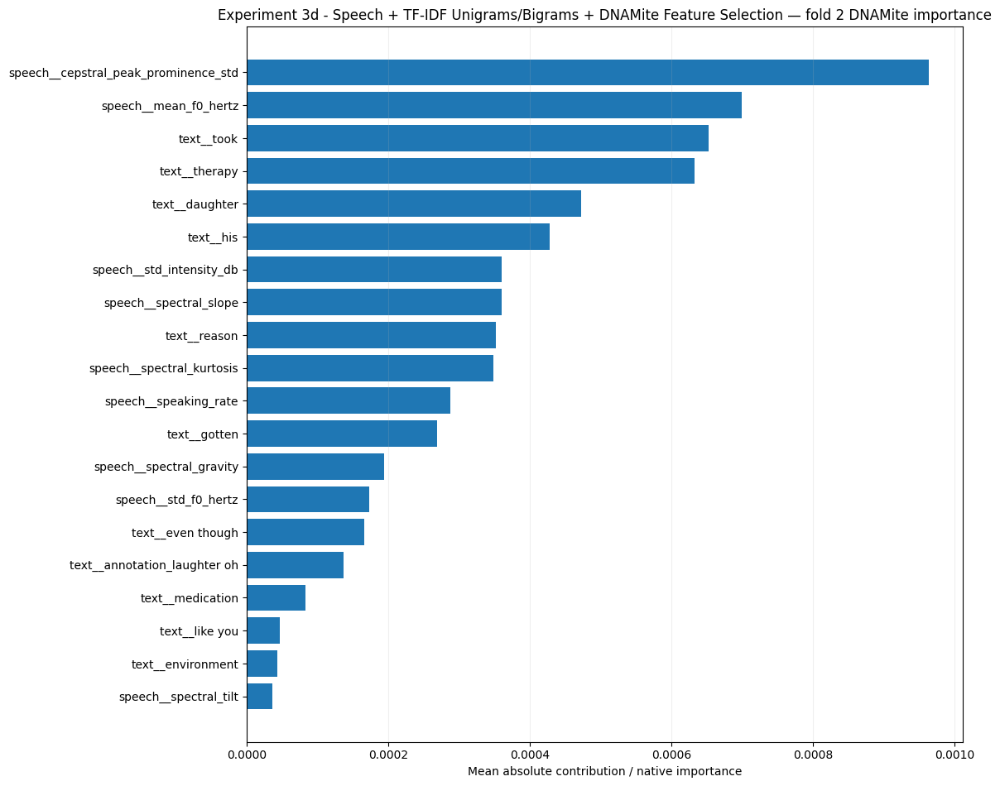

MAE               4.916558
RMSE              6.294885
R2               -0.015433
Spearman_Rho      0.004295
Spearman_P        0.983039
Pearson_R         0.072851
Pearson_P         0.718015
Exact_Accuracy    0.000000
Within_1          0.185185
Within_2          0.296296
Within_3          0.407407
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 50 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 72 / 78
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a person', 'text__a while', 'text__alright', 'text__and and', 'text__and do', 'text__annotation_sigh um', 'text__behavior', 'text__boyfriend', 'text__brother', 'text__children', 'text__dancing',

[WARNING] Found selected features. Using only those features.


DNAMite active features | 58 / 68
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a positive', 'text__alright', 'text__and he', 'text__annotation_deep_breath', 'text__annotation_laughter oh', 'text__at all', 'text__brother', 'text__depressed', 'text__diagnosed', "text__don't 

...

DNAMite active features | 16 / 68
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std']
DNAMite epochs | split=1 | ran=72 | best=42 | best val_loss=0.569653 | hit ceiling=False
  Inner fold 3/3
Selected 43 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 0 / 71
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.704962 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Inner-fold selected features: (57, 57.333333333333336, 58)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_03.json
Best parameters: {'max_bins': 8, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.001}
Selected 54 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 77 / 82
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a positive', 'text__alright', 'text__and do', 'text__and he', 'text__annotation_laughter oh', 'text__annotation_sniffle', 'text__both', 'text__brother', "text__couldn't", 'text__dancing', 'text_

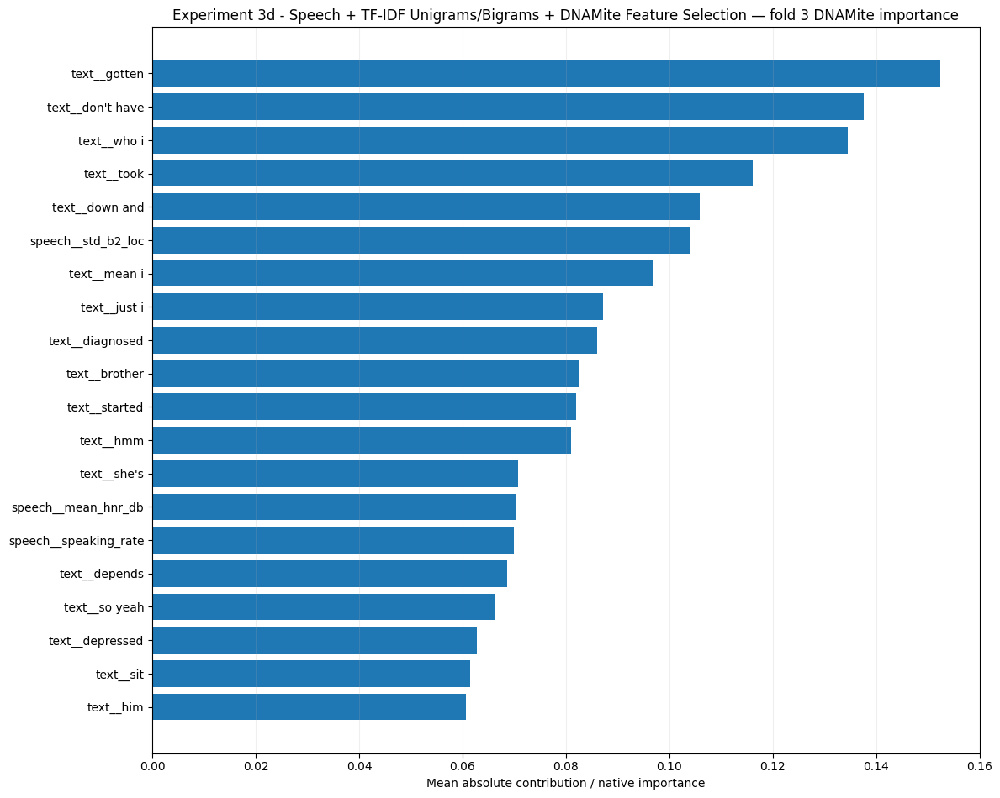

MAE               4.268531
RMSE              5.800868
R2               -0.069630
Spearman_Rho      0.244944
Spearman_P        0.218171
Pearson_R         0.253965
Pearson_P         0.201152
Exact_Accuracy    0.111111
Within_1          0.296296
Within_2          0.370370
Within_3          0.555556
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 68 / 74
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a therapist', 'text__and he', 'text__animals', 'text__annotation_laughter oh', 'text__annotation_sniff', 'text__annotation_synch', 'text__anymore', 'text__events', 'text__for me', 'text__get to'

[WARNING] Found selected features. Using only those features.


DNAMite active features | 68 / 79
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__alright', 'text__and just', 'text__and um', 'text__and you', 'text__annotation_laughter oh', 'text__annotation_sniff', 'text__at all', 'text__beautiful', 'text__both', "text__but i'm", 'text__bu

...

DNAMite active features | 3 / 79
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio']
DNAMite epochs | split=1 | ran=34 | best=4 | best val_loss=0.795234 | hit ceiling=False
  Inner fold 3/3
Selected 42 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 16 / 70
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std']
DNAMite epochs | split=1 | ran=47 | best=17 | best val_loss=0.634319 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 32, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.005}
Inner-fold selected features: (36, 41.333333333333336, 48)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature

[WARNING] Found selected features. Using only those features.


DNAMite active features | 66 / 78
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a lot', 'text__alright', 'text__and he', 'text__and you', 'text__annotation_laughter oh', 'text__annotation_sniff', 'text__at all', 'text__brother', "text__but i'm", 'text__but uh', "text__could

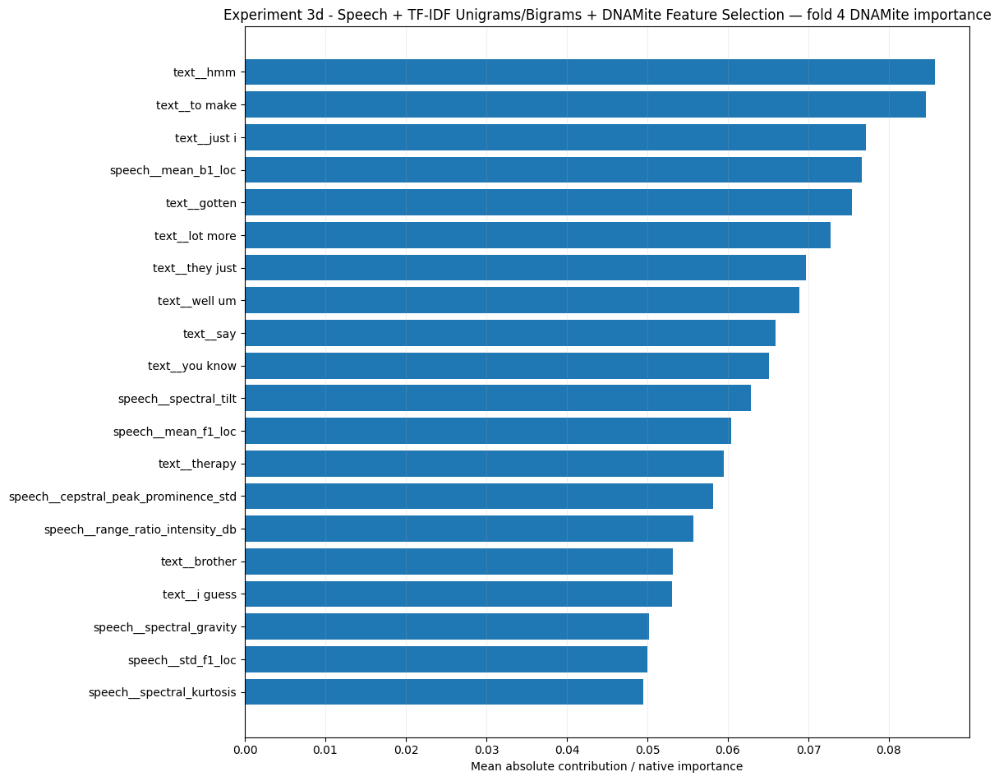

MAE               3.875464
RMSE              4.542999
R2                0.207035
Spearman_Rho      0.443937
Spearman_P        0.020359
Pearson_R         0.468297
Pearson_P         0.013756
Exact_Accuracy    0.074074
Within_1          0.148148
Within_2          0.370370
Within_3          0.518519
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 3d - Speech + TF-IDF Unigrams/Bigrams + DNAMite Feature Selection | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 71 / 75
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a person', 'text__a walk', 'text__alright', 'text__and sometimes', 'text__annotation_laughter oh', 'text__annotation_sigh', 'text__coast', 'text__control', 'text__could be', "text__couldn't", 't

[WARNING] Found selected features. Using only those features.


DNAMite active features | 66 / 74
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a walk', 'text__annotation_sniff', 'text__anyone', 'text__at all', 'text__been feeling', 'text__brother', 'text__business', 'text__children', 'text__could be', "text__could've", 'text__country',

...

DNAMite active features | 1 / 74
Active features: ['speech__speaking_rate']
DNAMite epochs | split=1 | ran=99 | best=69 | best val_loss=0.528744 | hit ceiling=False
  Inner fold 3/3
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 11 / 76
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db']
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=0.350668 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005}
Inner-fold selected features: (31, 32.0, 34)
Saved development cost to: /content/drive/MyDrive/Thesis/Model_Comparison_Results/development_cost/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/fold_05.json
Best parameters: {'max_bins': 32, 'learning_rate': np.float64(0.001), 'n_embed': 32, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0005

[WARNING] Found selected features. Using only those features.


DNAMite active features | 30 / 87
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a walk', 'text__alright']
DNAMite epochs | split=1 | ran=91 | best=61 | best val_loss=0.608165 | hit ceiling=False
Outer-fold resource utilization:
{'train_seconds': 2.9168160349945538, 'peak_ra

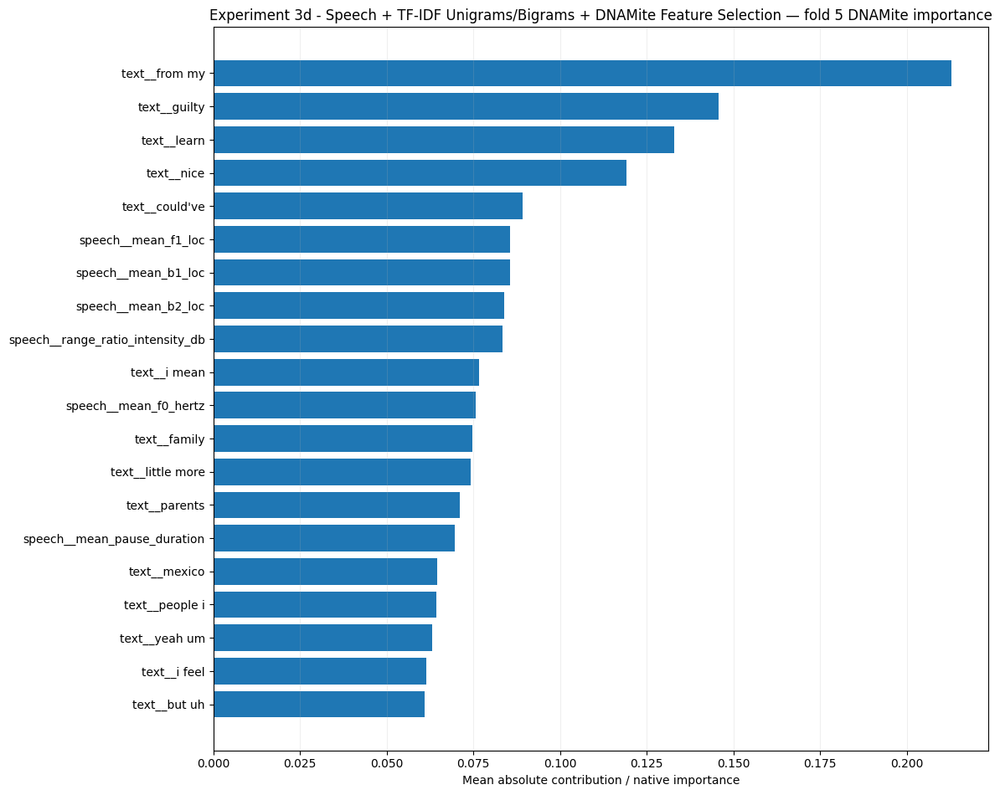

MAE               5.467526
RMSE              6.600480
R2               -0.376912
Spearman_Rho      0.001532
Spearman_P        0.993948
Pearson_R         0.041424
Pearson_P         0.837457
Exact_Accuracy    0.148148
Within_1          0.259259
Within_2          0.333333
Within_3          0.370370
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.539981,0.642836
RMSE,5.754610,0.794714
R2,-0.071867,0.209217
Spearman_Rho,0.196566,0.191652
Pearson_R,0.208507,0.170208
Exact_Accuracy,0.096296,0.061975
Within_1,0.229630,0.060858
Within_2,0.362963,0.054935
Within_3,0.466667,0.076802



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 3d
# Speech + TF-IDF Unigrams/Bigrams
# + DNAMite Feature Selection
# Regression Nested Cross-Validation
# ============================================================

EXPERIMENT_3D_NAME = (
    "Experiment 3d - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "DNAMite Feature Selection"
)


experiment_3d_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_3D_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        use_feature_selection=True,
    )
)

### Experiment 3d Nested CV Results

In [ ]:
# ============================================================
# Experiment 3d
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_3d_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_3d_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,MAE,RMSE,R2,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0005,32,16,2,0.0005,4.171828,5.533816,-0.104396,...,0.481481,4.334362,5.267151,-0.000523,8.935169,3418.683594,16.518066,22.0,0.000290,1.141550e-06
1,2,4,0.0010,16,32,2,0.0005,4.916558,6.294885,-0.015433,...,0.407407,4.996914,6.247201,-0.000108,1.410286,3418.046875,16.518066,22.0,0.000039,1.544113e-07
2,3,8,0.0005,32,16,2,0.0010,4.268531,5.800868,-0.069630,...,0.555556,4.607339,5.614449,-0.001987,5.150811,3418.878906,16.518066,22.0,0.000165,6.488868e-07
3,4,32,0.0005,32,16,2,0.0050,3.875464,4.542999,0.207035,...,0.518519,4.469822,5.104431,-0.001067,3.111367,3418.191406,16.518066,22.0,0.000098,3.845968e-07
4,5,32,0.0010,32,16,2,0.0005,5.467526,6.600480,-0.376912,...,0.370370,4.728052,5.625067,-0.000024,2.916816,3419.000000,16.518066,22.0,0.000090,3.557119e-07



CV SUMMARY


,Mean,SD
MAE,4.539981,0.642836
RMSE,5.754610,0.794714
R2,-0.071867,0.209217
Spearman_Rho,0.196566,0.191652
Pearson_R,0.208507,0.170208
Exact_Accuracy,0.096296,0.061975
Within_1,0.229630,0.060858
Within_2,0.362963,0.054935
Within_3,0.466667,0.076802


In [ ]:
# ============================================================
# Experiment 3d
# Cross-Validation Performance
# ============================================================

experiment_3d_cv_metrics = (
    experiment_3d_regression_cv[
        "outer_results"
    ].copy()
)

experiment_3d_cv_summary = (
    experiment_3d_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_3d_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_3d_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param,MAE,RMSE,R2,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,8,0.0005,32,16,2,0.0005,4.171828,5.533816,-0.104396,...,0.481481,4.334362,5.267151,-0.000523,8.935169,3418.683594,16.518066,22.0,0.000290,1.141550e-06
1,2,4,0.0010,16,32,2,0.0005,4.916558,6.294885,-0.015433,...,0.407407,4.996914,6.247201,-0.000108,1.410286,3418.046875,16.518066,22.0,0.000039,1.544113e-07
2,3,8,0.0005,32,16,2,0.0010,4.268531,5.800868,-0.069630,...,0.555556,4.607339,5.614449,-0.001987,5.150811,3418.878906,16.518066,22.0,0.000165,6.488868e-07
3,4,32,0.0005,32,16,2,0.0050,3.875464,4.542999,0.207035,...,0.518519,4.469822,5.104431,-0.001067,3.111367,3418.191406,16.518066,22.0,0.000098,3.845968e-07
4,5,32,0.0010,32,16,2,0.0005,5.467526,6.600480,-0.376912,...,0.370370,4.728052,5.625067,-0.000024,2.916816,3419.000000,16.518066,22.0,0.000090,3.557119e-07



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.539981,0.642836
RMSE,5.754610,0.794714
R2,-0.071867,0.209217
Spearman_Rho,0.196566,0.191652
Pearson_R,0.208507,0.170208
Exact_Accuracy,0.096296,0.061975
Within_1,0.229630,0.060858
Within_2,0.362963,0.054935
Within_3,0.466667,0.076802


In [ ]:
# ============================================================
# Experiment 3d
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_3d_parameters = (
    experiment_3d_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "selection_reg_param",
        ]
    ]
    .copy()
)

display(
    experiment_3d_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,selection_reg_param
0,1,8,0.0005,32,16,2,0.0005
1,2,4,0.0010,16,32,2,0.0005
2,3,8,0.0005,32,16,2,0.0010
3,4,32,0.0005,32,16,2,0.0050
4,5,32,0.0010,32,16,2,0.0005



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


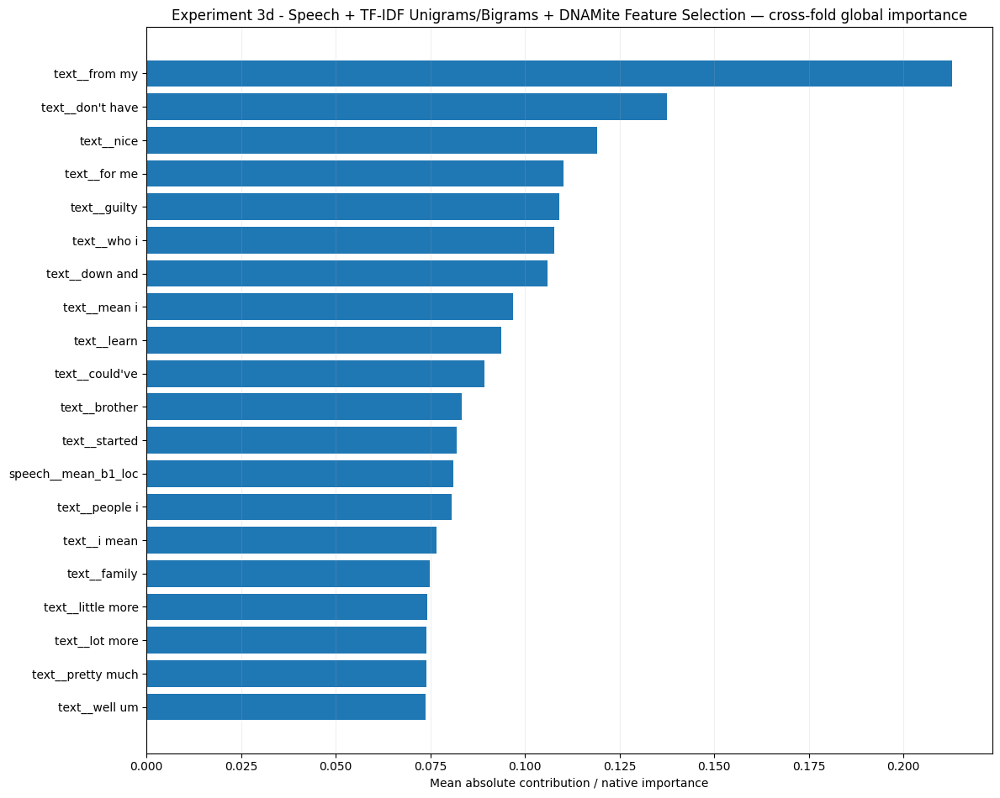

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3d_-_Speech_TF-IDF_Unigrams_Bigrams_DNAMite_Feature_Selection/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 3d
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams/Bigrams
# + DNAMite Feature Selection
# ============================================================

experiment_3d_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_3D_NAME
        ),
        top_k=30,
    )
)

experiment_3d_interpretability

In [ ]:
# ============================================================
# Experiment 3d
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_3d_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_3D_NAME)
)


experiment_3d_development_rows = []

for path in sorted(
    experiment_3d_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_3d_development_rows.append(
            json.load(file)
        )


experiment_3d_development_df = (
    pd.DataFrame(
        experiment_3d_development_rows
    )
)

display(
    experiment_3d_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,regression,1,672,1192.331876,0.033849,0.000133,3418.718750,16.518066,22.0
1,DNAMite Optimized,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,regression,2,672,1397.304015,0.040867,0.000161,3419.355469,16.518066,22.0
2,DNAMite Optimized,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,regression,3,672,1636.543955,0.049125,0.000193,3418.886719,16.518066,22.0
3,DNAMite Optimized,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,regression,4,672,1311.176614,0.038076,0.000150,3419.574219,16.518066,22.0
4,DNAMite Optimized,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,regression,5,672,1406.665480,0.041294,0.000163,3419.093750,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 3d
# Development Cost Summary
# ============================================================

experiment_3d_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_3d_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3d_development_df[
                    experiment_3d_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_3d_development_df[
                    experiment_3d_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3d_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_3d_development_summary[
            "Mean"
        ],
        experiment_3d_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_3d_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,672.000000,0.000000,672.000000 ± 0.000000
development_seconds,1388.804388,163.090217,1388.804388 ± 163.090217
development_energy_kwh,0.040643,0.005594,0.040643 ± 0.005594
development_co2_kg,0.000160,0.000022,0.000160 ± 0.000022


In [ ]:
# ============================================================
# Experiment 3d
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_3d_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_3d_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3d_regression_cv[
                    "outer_results"
                ][
                    experiment_3d_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_3d_regression_cv[
                    "outer_results"
                ][
                    experiment_3d_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3d_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_3d_training_summary[
            "Mean"
        ],
        experiment_3d_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_3d_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,4.304890e+00,2.910543e+00,4.30488964 ± 2.91054294
peak_ram_mb,3.418560e+03,4.212289e-01,3418.56015625 ± 0.42122889
peak_gpu_memory_mb,1.651807e+01,0.000000e+00,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,2.200000e+01,0.000000e+00,22.00000000 ± 0.00000000
training_energy_kwh,1.363939e-04,9.675055e-05,0.00013639 ± 0.00009675
training_co2_kg,5.370313e-07,3.809413e-07,0.00000054 ± 0.00000038


### Experiment 3d Final Model

In [ ]:
# ============================================================
# Experiment 3d
# Speech + TF-IDF Unigrams/Bigrams
# + DNAMite Feature Selection
# Final Regression Model
# ============================================================

EXPERIMENT_3D_NAME = (
    "Experiment 3d - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "DNAMite Feature Selection"
)

experiment_3d_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="none",
        experiment_name=(
            EXPERIMENT_3D_NAME
        ),
        use_feature_selection=True,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
DNAMite candidate 1/224: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'selection_reg_param': 0.0001}
  Inner fold 1/3
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.0001


[WARNING] Found selected features. Using only those features.


DNAMite active features | 70 / 77
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a person', 'text__alright', 'text__annotation_laughter oh', 'text__anymore', 'text__at all', 'text__bike', 'text__boy', 'text__brother', "text__couldn't", 'text__dancing', 'text__depression', 't

[WARNING] Found selected features. Using only those features.


DNAMite active features | 80 / 84
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz', 'speech__mean_intensity_db', 'speech__std_intensity_db', 'speech__range_ratio_intensity_db', 'speech__mean_hnr_db', 'speech__std_hnr_db', 'speech__spectral_slope', 'speech__spectral_tilt', 'speech__cepstral_peak_prominence_mean', 'speech__cepstral_peak_prominence_std', 'speech__mean_f1_loc', 'speech__std_f1_loc', 'speech__mean_b1_loc', 'speech__std_b1_loc', 'speech__mean_f2_loc', 'speech__std_f2_loc', 'speech__mean_b2_loc', 'speech__std_b2_loc', 'speech__spectral_gravity', 'speech__spectral_std_dev', 'speech__spectral_skewness', 'speech__spectral_kurtosis', 'text__a lot', 'text__a positive', 'text__alright', 'text__and do', 'text__annotation_laughter oh', 'text__annotation_sniff', 'text__both', 'text__boyfriend', 'text__brother', 'text__dancing', 'text__d

...

DNAMite active features | 0 / 84
Active features: []
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.481104 | hit ceiling=False
  Inner fold 3/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running DNAMite feature selection | reg_param=0.1


[WARNING] Found selected features. Using only those features.


DNAMite active features | 1 / 74
Active features: ['speech__speaking_rate']
DNAMite epochs | split=1 | ran=251 | best=221 | best val_loss=1.218527 | hit ceiling=False

Selected valid DNAMite architecture:
{'max_bins': 32, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.005}
Inner-fold selected features: (6, 7.333333333333333, 9)
Final best parameters: {'max_bins': 32, 'learning_rate': np.float64(0.0005), 'n_embed': 32, 'n_hidden': 32, 'n_layers': 2, 'selection_reg_param': 0.005}
Selected 59 TF-IDF features for regression / unigram_bigram using alpha=0.01
Running final DNAMite feature selection | reg_param=0.005


[WARNING] Found selected features. Using only those features.


Final DNAMite active features: 7 / 87
Active features: ['speech__speaking_rate', 'speech__articulation_rate', 'speech__phonation_ratio', 'speech__pause_rate', 'speech__mean_pause_duration', 'speech__mean_f0_hertz', 'speech__std_f0_hertz']
Final DNAMite epoch diagnostics: [{'internal_split': 1, 'epochs_ran': 118, 'best_epoch': 88, 'best_val_loss': 0.6864871978759766, 'hit_epoch_ceiling': False}]

FINAL TEST METRICS
{'MAE': 6.087245313092779, 'RMSE': np.float64(7.837406921691822), 'R2': -0.49463769269078095, 'Spearman_Rho': -0.09643540412880709, 'Spearman_P': 0.5237696998344669, 'Pearson_R': -0.10751347157916231, 'Pearson_P': 0.47696677354553335, 'Exact_Accuracy': np.float64(0.043478260869565216), 'Within_1': np.float64(0.15217391304347827), 'Within_2': np.float64(0.2826086956521739), 'Within_3': np.float64(0.4782608695652174)}

TRIVIAL MEAN-PREDICTOR TEST BASELINE
{'MAE': 5.426247987117553, 'RMSE': np.float64(6.426942287376253), 'R2': -0.005078396542139263, 'Spearman_Rho': nan, 'Spearma

In [ ]:
# ============================================================
# Experiment 3d
# Final Feature Selection
# ============================================================

print(
    "Selection regularization parameter:",
    experiment_3d_regression_final[
        "selection_reg_param"
    ],
)

print(
    "\nNumber of selected features:",
    len(
        experiment_3d_regression_final[
            "active_feature_names"
        ]
    ),
)

print(
    "\nSelected features:"
)

display(
    pd.DataFrame(
        {
            "Feature": (
                experiment_3d_regression_final[
                    "active_feature_names"
                ]
            )
        }
    )
)

Selection regularization parameter: 0.005

Number of selected features: 7

Selected features:


,Feature
0,speech__speaking_rate
1,speech__articulation_rate
2,speech__phonation_ratio
3,speech__pause_rate
4,speech__mean_pause_duration
5,speech__mean_f0_hertz
6,speech__std_f0_hertz


In [ ]:
# ============================================================
# Experiment 3d
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_3d_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,6.087245
RMSE,7.837407
R2,-0.494638
Spearman_Rho,-0.096435
Spearman_P,0.523770
Pearson_R,-0.107513
Pearson_P,0.476967
Exact_Accuracy,0.043478
Within_1,0.152174
Within_2,0.282609


### Experiment 3d Test PHQ-8 Confusion Matrix

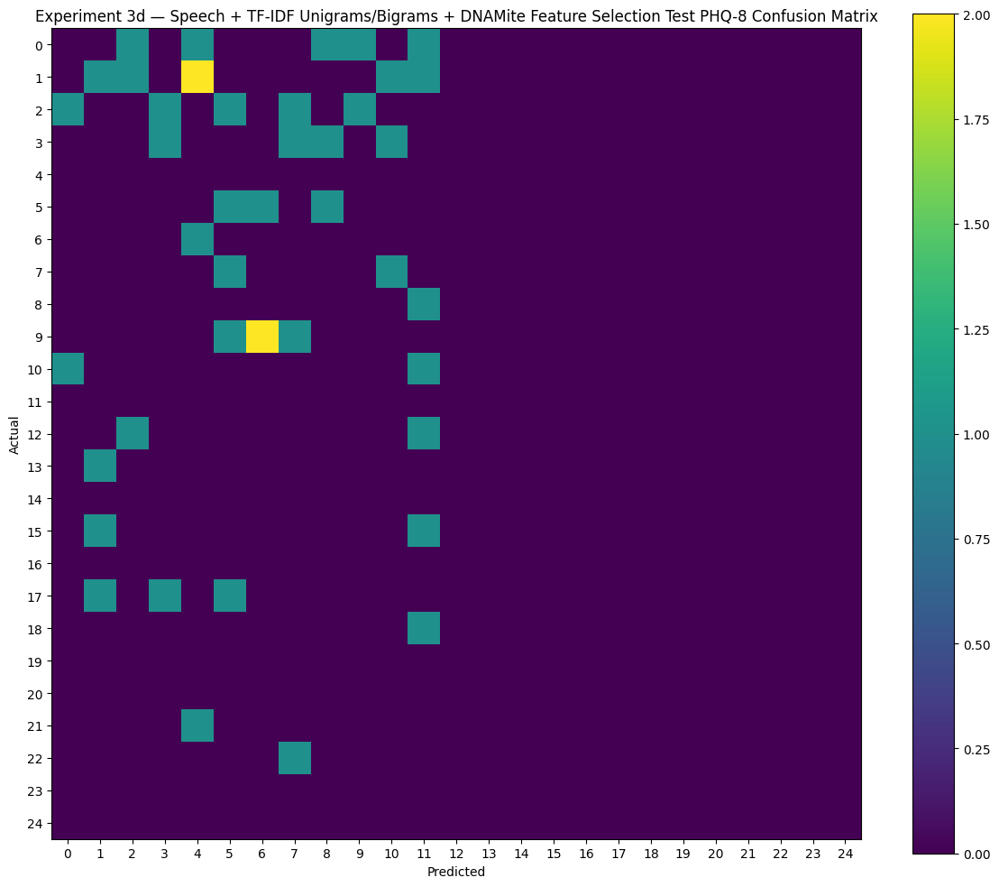

array([[0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 3d
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_3d_regression_final[
                "test_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 3d — "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "DNAMite Feature Selection "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

### Experiment 3d Actual vs. Predicted

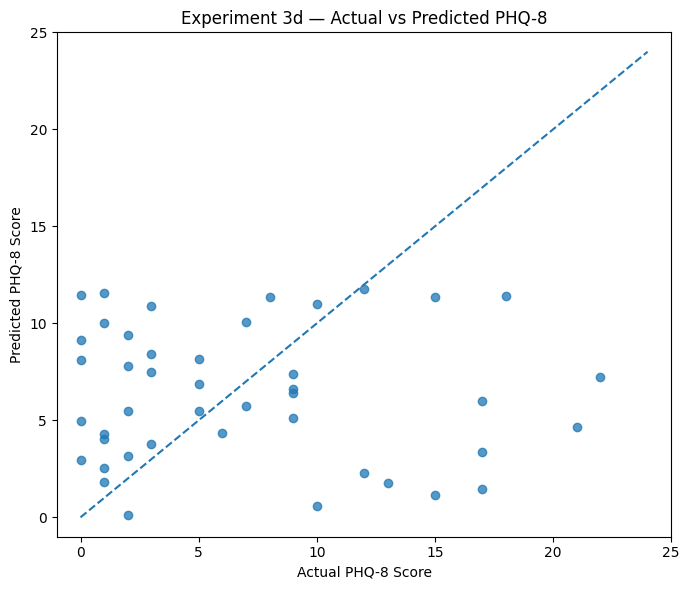

In [ ]:
# ============================================================
# Experiment 3d
# Actual vs Predicted PHQ-8
# ============================================================

plot_regression_predictions(
    y_true=(
        y_regression_test
    ),
    predictions=(
        experiment_3d_regression_final[
            "test_predictions"
        ]
    ),
    title=(
        "Experiment 3d — "
        "Actual vs Predicted PHQ-8"
    ),
)

,split,feature,importance,n_bins
0,0,speech__mean_hnr_db,0.243149,31
1,0,text__a positive,0.206050,21
2,0,text__medication,0.120799,15
3,0,text__relationship,0.183176,31
4,0,text__strong,0.109079,25
5,0,text__took,0.307659,31
6,0,text__you're welcome,0.173663,23


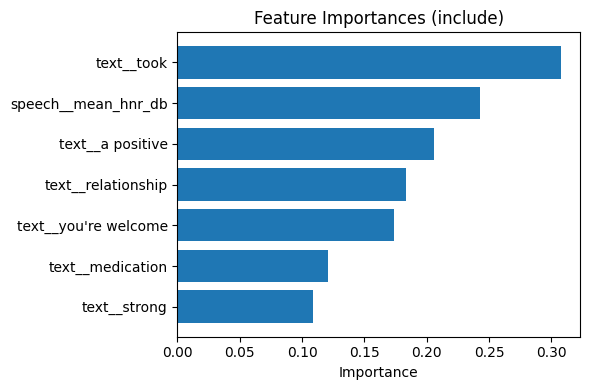

In [ ]:
# ============================================================
# Experiment 3d
# Final Model Feature Importance
# ============================================================

experiment_3d_regression_importance = (
    show_feature_importance(
        experiment_3d_regression_final[
            "model"
        ],
        top_n=30,
    )
)

### Compare 3c vs. 3d Test Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3C VS 3D — TEST COMPARISON
# ============================================================

experiment_3c_vs_3d_regression_test = (
    pd.DataFrame(
        {
            "Experiment 3c - No Selection": (
                experiment_3c_regression_final[
                    "test_metrics"
                ]
            ),

            "Experiment 3d - DNAMite Selection": (
                experiment_3d_regression_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_3c_vs_3d_regression_test
)

### Compare 3c vs. 3d CV Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3C VS 3D — CV COMPARISON
# No Feature Selection vs DNAMite Feature Selection
# ============================================================

experiment_3c_vs_3d_regression_cv = (
    pd.DataFrame(
        {
            "Experiment 3c - No Selection": (
                experiment_3c_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 3d - DNAMite Selection": (
                experiment_3d_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_3c_vs_3d_regression_cv
)

### Experiment 3e BCE


Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE | Classification | Outer fold 1
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.573629 | hit ceiling=False
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.561980 | hit ceiling=False
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.64186

,positive_class_multiplier,mean_score,sd_score
0,1.50,0.340698,0.086273
1,2.00,0.340263,0.087030
2,1.00,0.339413,0.085216
3,1.25,0.338707,0.085701


Best imbalance parameters: {'positive_class_multiplier': 1.5} mean inner PR-AUC: 0.34069844259721577
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.5}
  Inner fold 1/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.50, final_pos_weight=3.4091
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=32 | best=2 | best val_loss=0.579462 | hit ceiling=False
  Inner fold 2/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.50, final_pos_weight=3.6429
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.547471 | hit ceiling=False
  Inner fold 3/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BC

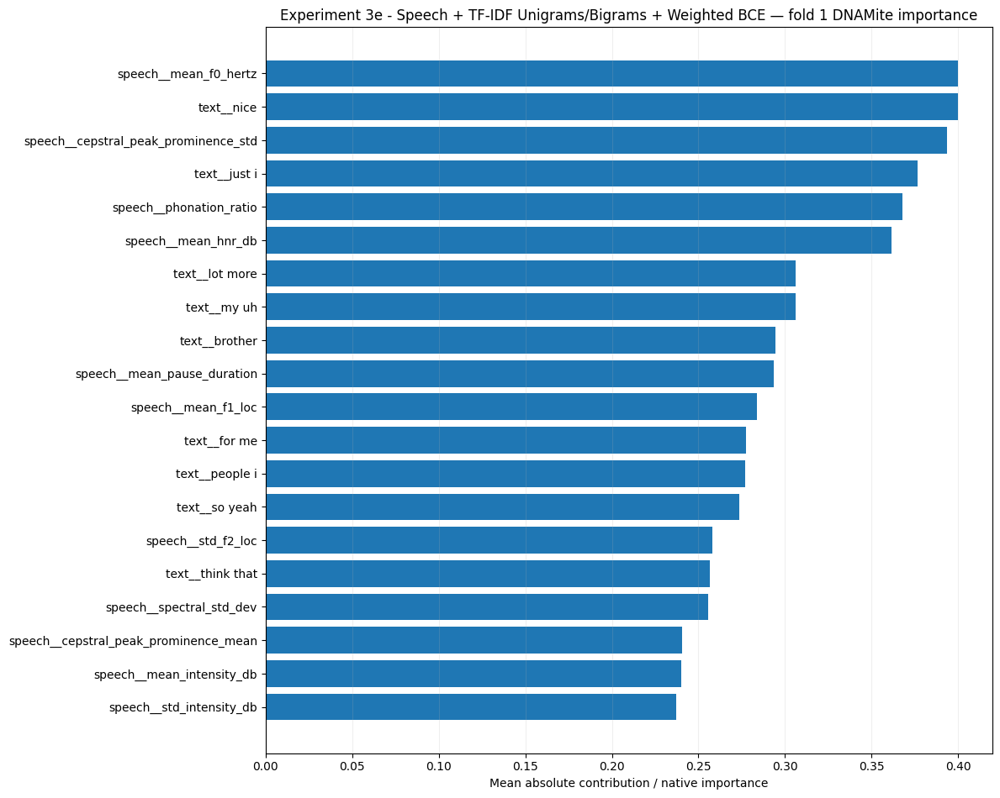

ROC_AUC              0.171053
PR_AUC               0.182105
AUPRC                0.182105
Accuracy             0.407407
Balanced_Accuracy    0.289474
Precision            0.000000
Sensitivity          0.000000
Specificity          0.578947
F1                   0.000000
Brier_Score          0.227716
Log_Loss             0.654456
Threshold            0.310000
dtype: float64

Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE | Classification | Outer fold 2
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 36 / 36
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.589580 | hit ceiling=False
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 37 / 37


,positive_class_multiplier,mean_score,sd_score
0,1.00,0.296439,0.091106
1,1.25,0.296404,0.090532
2,1.50,0.293278,0.086441
3,2.00,0.292324,0.086290


Best imbalance parameters: {'positive_class_multiplier': 1.0} mean inner PR-AUC: 0.2964389146601191
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.0}
  Inner fold 1/3
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 36 / 36
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.598005 | hit ceiling=False
  Inner fold 2/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 37 / 37
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.649586 | hit ceiling=False
  Inner fold 3/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE 

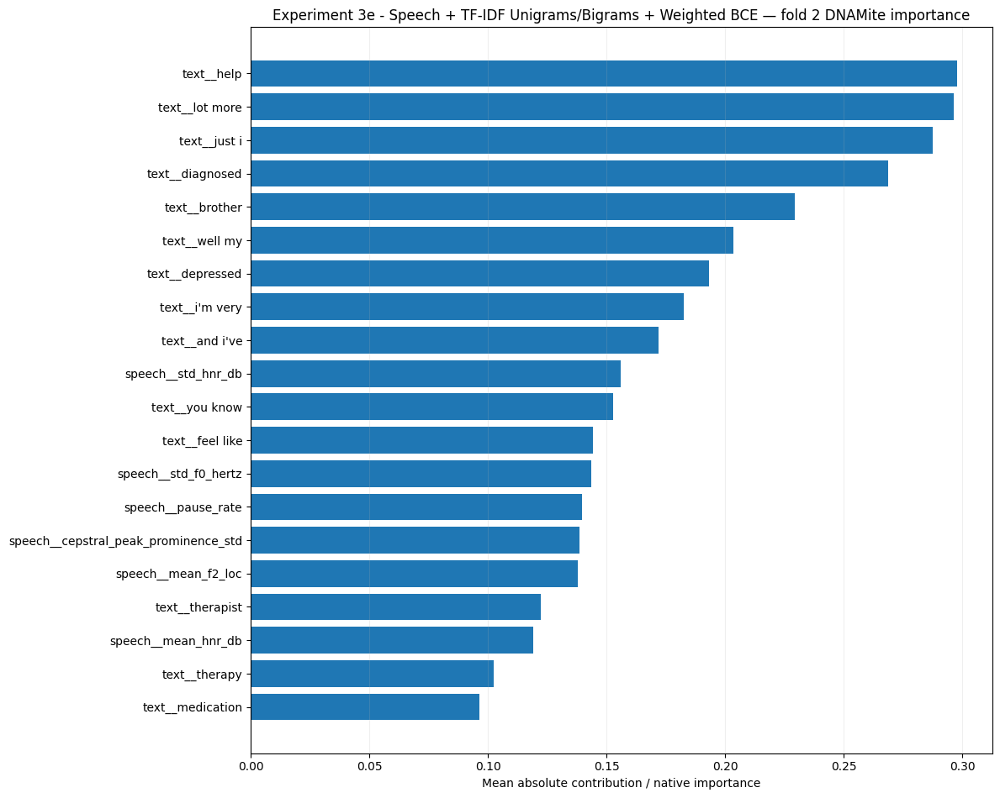

ROC_AUC              0.381579
PR_AUC               0.245747
AUPRC                0.245747
Accuracy             0.666667
Balanced_Accuracy    0.509868
Precision            0.333333
Sensitivity          0.125000
Specificity          0.894737
F1                   0.181818
Brier_Score          0.221301
Log_Loss             0.641805
Threshold            0.370000
dtype: float64

Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE | Classification | Outer fold 3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=111 | best=81 | best val_loss=0.557212 | hit ceiling=False
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 38 / 

,positive_class_multiplier,mean_score,sd_score
0,1.00,0.376255,0.124608
1,1.50,0.286770,0.067889
2,1.25,0.286638,0.067950
3,2.00,0.285566,0.062557


Best imbalance parameters: {'positive_class_multiplier': 1.0} mean inner PR-AUC: 0.37625470609928685
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.0}
  Inner fold 1/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 35 / 35
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.636524 | hit ceiling=False
  Inner fold 2/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=36 | best=6 | best val_loss=0.636130 | hit ceiling=False
  Inner fold 3/3
Selected 5 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BC

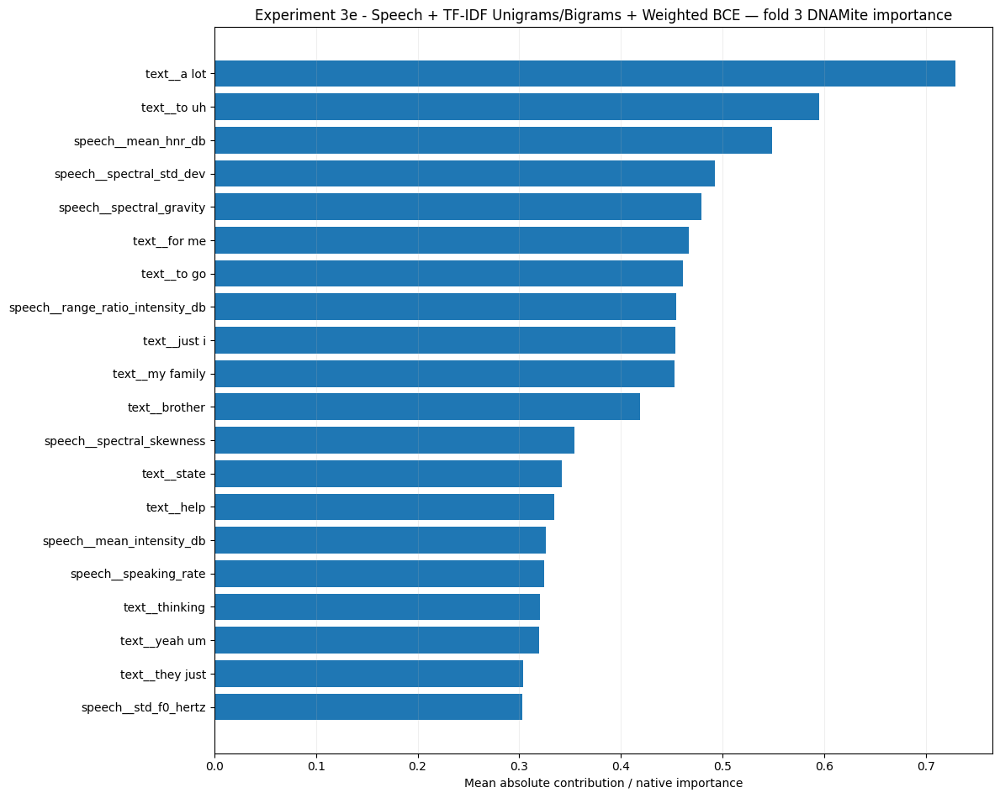

ROC_AUC              0.500000
PR_AUC               0.377012
AUPRC                0.377012
Accuracy             0.666667
Balanced_Accuracy    0.509868
Precision            0.333333
Sensitivity          0.125000
Specificity          0.894737
F1                   0.181818
Brier_Score          0.213369
Log_Loss             0.621317
Threshold            0.350000
dtype: float64

Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE | Classification | Outer fold 4
Selected 13 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 41 / 41
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.592623 | hit ceiling=False
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 37 / 37

,positive_class_multiplier,mean_score,sd_score
0,1.00,0.283853,0.041625
1,1.50,0.269946,0.014851
2,1.25,0.267864,0.013320
3,2.00,0.267470,0.017247


Best imbalance parameters: {'positive_class_multiplier': 1.0} mean inner PR-AUC: 0.28385327352115075
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.0}
  Inner fold 1/3
Selected 13 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 41 / 41
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.594530 | hit ceiling=False
  Inner fold 2/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 37 / 37
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.626623 | hit ceiling=False
  Inner fold 3/3
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BC

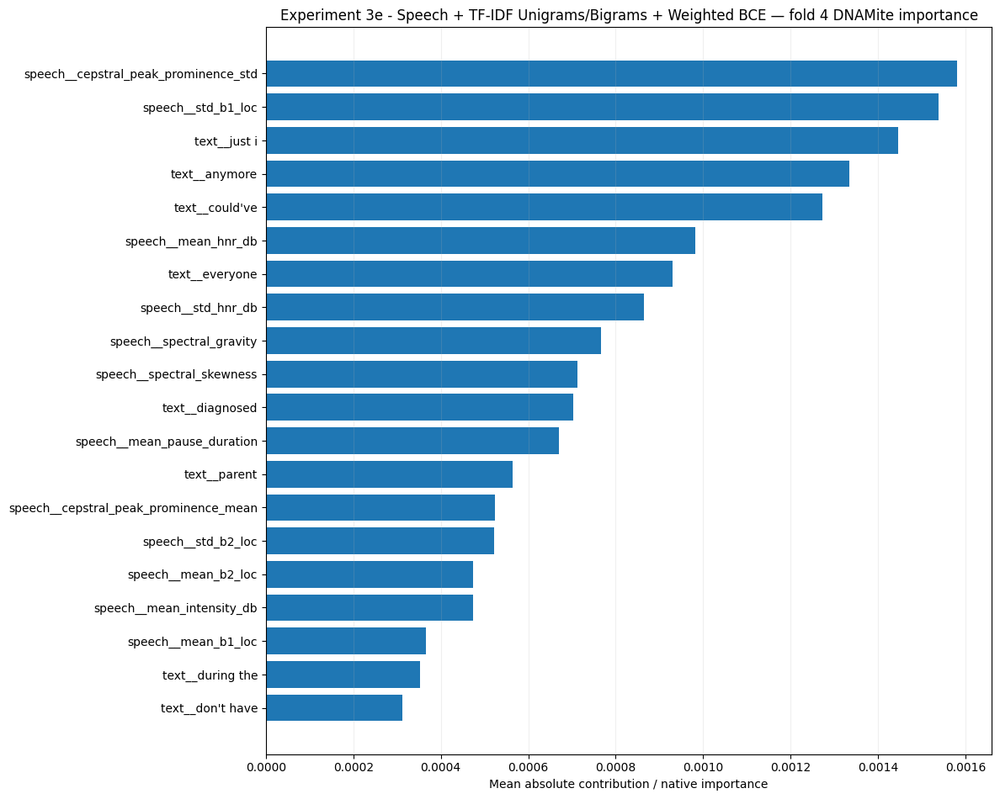

ROC_AUC              0.559211
PR_AUC               0.355309
AUPRC                0.355309
Accuracy             0.296296
Balanced_Accuracy    0.500000
Precision            0.296296
Sensitivity          1.000000
Specificity          0.000000
F1                   0.457143
Brier_Score          0.208500
Log_Loss             0.607683
Threshold            0.290000
dtype: float64

Experiment 3e - Speech + TF-IDF Unigrams/Bigrams + Weighted BCE | Classification | Outer fold 5
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.00, final_pos_weight=2.2727
DNAMite active features | 36 / 36
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.456557 | hit ceiling=False
Selected 6 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.00, final_pos_weight=2.4286
DNAMite active features | 34 / 34


,positive_class_multiplier,mean_score,sd_score
0,1.50,0.343185,0.110967
1,2.00,0.342380,0.109768
2,1.25,0.338398,0.103892
3,1.00,0.320438,0.100547


Best imbalance parameters: {'positive_class_multiplier': 1.5} mean inner PR-AUC: 0.343184617915325
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.5}
  Inner fold 1/3
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=50, positive=22, automatic_pos_weight=2.2727, multiplier=1.50, final_pos_weight=3.4091
DNAMite active features | 36 / 36
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.480498 | hit ceiling=False
  Inner fold 2/3
Selected 6 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=51, positive=21, automatic_pos_weight=2.4286, multiplier=1.50, final_pos_weight=3.6429
DNAMite active features | 34 / 34
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.627629 | hit ceiling=False
  Inner fold 3/3
Selected 7 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE |

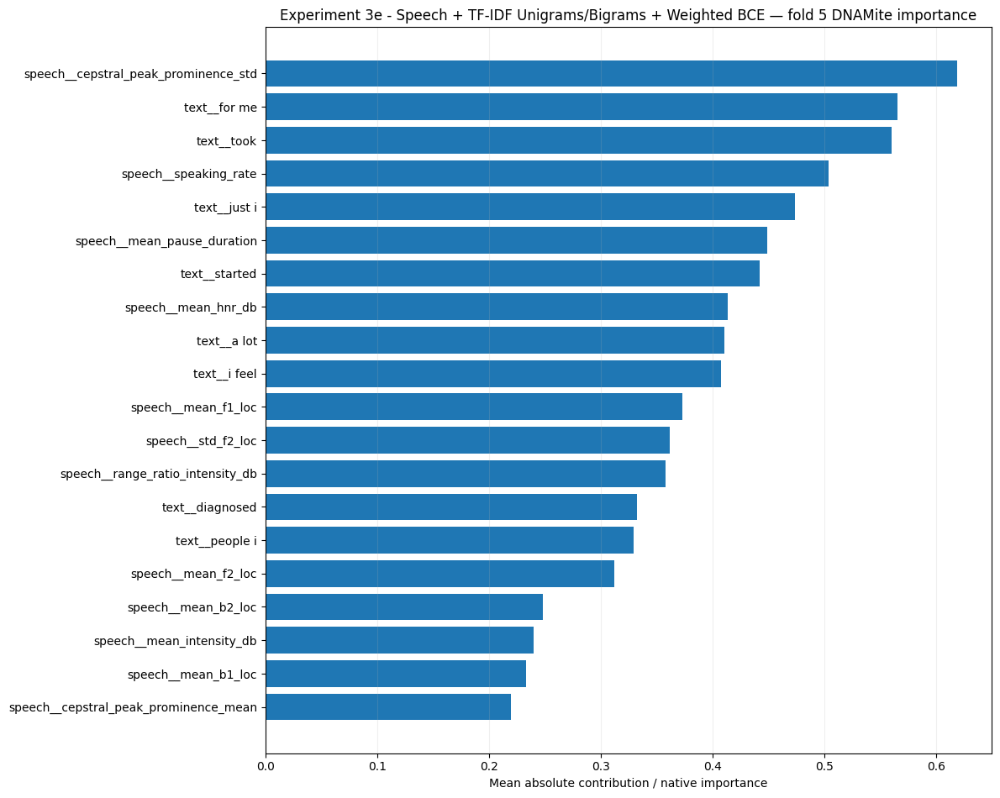

ROC_AUC              0.289474
PR_AUC               0.208088
AUPRC                0.208088
Accuracy             0.333333
Balanced_Accuracy    0.345395
Precision            0.187500
Sensitivity          0.375000
Specificity          0.315789
F1                   0.250000
Brier_Score          0.232310
Log_Loss             0.663542
Threshold            0.285000
dtype: float64

Nested CV summary:


,Mean,SD
ROC_AUC,0.380263,0.156822
PR_AUC,0.273652,0.087763
AUPRC,0.273652,0.087763
Accuracy,0.474074,0.180306
Balanced_Accuracy,0.430921,0.105545
Precision,0.230093,0.141825
Sensitivity,0.325000,0.401170
Specificity,0.536842,0.385686
F1,0.214156,0.164531
Brier_Score,0.220639,0.009835



Feature-selection summary:


,Outer_Fold,feature_selection_enabled,selection_reg_param,n_features_available,n_features_selected,selected_features
0,1,False,None,45,45,"[speech__speaking_rate, speech__articulation_r..."
1,2,False,None,45,45,"[speech__speaking_rate, speech__articulation_r..."
2,3,False,None,48,48,"[speech__speaking_rate, speech__articulation_r..."
3,4,False,None,47,47,"[speech__speaking_rate, speech__articulation_r..."
4,5,False,None,45,45,"[speech__speaking_rate, speech__articulation_r..."


In [ ]:
# ============================================================
# Experiment 3e
# Speech + TF-IDF Unigrams/Bigrams + Weighted BCE
# Classification Nested Cross-Validation
# ============================================================

EXPERIMENT_3E_NAME = (
    "Experiment 3e - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "Weighted BCE"
)


experiment_3e_binary_cv = (
    nested_cv_classification(
        experiment_name=(
            EXPERIMENT_3E_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_binary_development
        ),
        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy=(
            "weighted_bce"
        ),
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 3e
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_3e_binary_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_3e_binary_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier,feature_selection_enabled,selection_reg_param,n_features_available,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,32,0.0005,16,32,2,1.5,False,None,45,...,0.000000,0.227716,0.654456,0.310,1.378236,2652.820312,16.518066,22.0,0.000043,0.000011
1,2,8,0.0010,32,32,2,1.0,False,None,45,...,0.181818,0.221301,0.641805,0.370,0.956790,2772.242188,16.518066,22.0,0.000030,0.000008
2,3,16,0.0005,16,32,2,1.0,False,None,48,...,0.181818,0.213369,0.621317,0.350,1.602442,2897.546875,16.518066,22.0,0.000051,0.000014
3,4,4,0.0005,32,16,2,1.0,False,None,47,...,0.457143,0.208500,0.607683,0.290,0.710968,2972.273438,16.518066,22.0,0.000020,0.000005
4,5,16,0.0010,16,32,2,1.5,False,None,45,...,0.250000,0.232310,0.663542,0.285,1.075688,3081.402344,16.518066,22.0,0.000034,0.000009



CV SUMMARY


,Mean,SD
ROC_AUC,0.380263,0.156822
PR_AUC,0.273652,0.087763
AUPRC,0.273652,0.087763
Accuracy,0.474074,0.180306
Balanced_Accuracy,0.430921,0.105545
Precision,0.230093,0.141825
Sensitivity,0.325000,0.401170
Specificity,0.536842,0.385686
F1,0.214156,0.164531
Brier_Score,0.220639,0.009835


In [ ]:
# ============================================================
# Experiment 3e
# Cross-Validation Performance
# ============================================================

experiment_3e_cv_metrics = (
    experiment_3e_binary_cv[
        "outer_results"
    ].copy()
)

experiment_3e_cv_summary = (
    experiment_3e_binary_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_3e_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_3e_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier,feature_selection_enabled,selection_reg_param,n_features_available,...,F1,Brier_Score,Log_Loss,Threshold,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,32,0.0005,16,32,2,1.5,False,None,45,...,0.000000,0.227716,0.654456,0.310,1.378236,2652.820312,16.518066,22.0,0.000043,0.000011
1,2,8,0.0010,32,32,2,1.0,False,None,45,...,0.181818,0.221301,0.641805,0.370,0.956790,2772.242188,16.518066,22.0,0.000030,0.000008
2,3,16,0.0005,16,32,2,1.0,False,None,48,...,0.181818,0.213369,0.621317,0.350,1.602442,2897.546875,16.518066,22.0,0.000051,0.000014
3,4,4,0.0005,32,16,2,1.0,False,None,47,...,0.457143,0.208500,0.607683,0.290,0.710968,2972.273438,16.518066,22.0,0.000020,0.000005
4,5,16,0.0010,16,32,2,1.5,False,None,45,...,0.250000,0.232310,0.663542,0.285,1.075688,3081.402344,16.518066,22.0,0.000034,0.000009



Mean ± SD Across Outer Folds:


,Mean,SD
ROC_AUC,0.380263,0.156822
PR_AUC,0.273652,0.087763
AUPRC,0.273652,0.087763
Accuracy,0.474074,0.180306
Balanced_Accuracy,0.430921,0.105545
Precision,0.230093,0.141825
Sensitivity,0.325000,0.401170
Specificity,0.536842,0.385686
F1,0.214156,0.164531
Brier_Score,0.220639,0.009835


In [ ]:
# ============================================================
# Experiment 3e
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_3e_parameters = (
    experiment_3e_binary_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "positive_class_multiplier",
        ]
    ]
    .copy()
)

display(
    experiment_3e_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,positive_class_multiplier
0,1,32,0.0005,16,32,2,1.5
1,2,8,0.0010,32,32,2,1.0
2,3,16,0.0005,16,32,2,1.0
3,4,4,0.0005,32,16,2,1.0
4,5,16,0.0010,16,32,2,1.5



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3e_-_Speech_TF-IDF_Unigrams_Bigrams_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


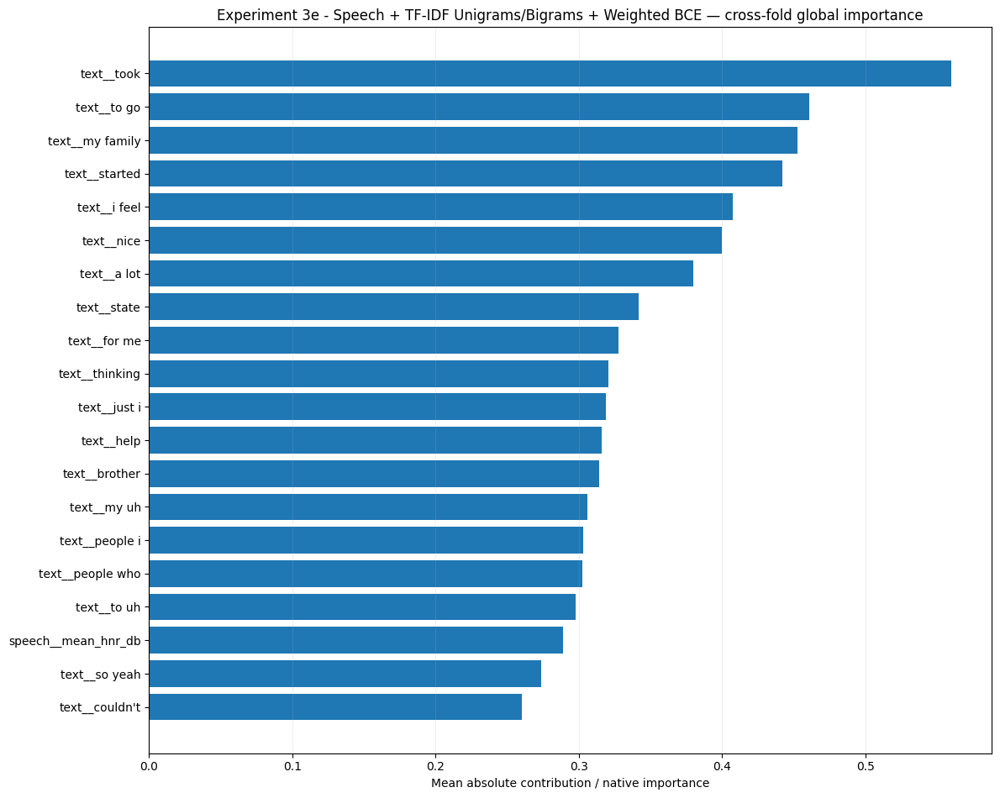

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3e_-_Speech_TF-IDF_Unigrams_Bigrams_Weighted_BCE/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 3e
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams/Bigrams + Weighted BCE
# ============================================================

experiment_3e_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_3E_NAME
        ),
        top_k=30,
    )
)

experiment_3e_interpretability

In [ ]:
# ============================================================
# Experiment 3e
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_3e_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_3E_NAME)
)


experiment_3e_development_rows = []

for path in sorted(
    experiment_3e_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_3e_development_rows.append(
            json.load(file)
        )


experiment_3e_development_df = (
    pd.DataFrame(
        experiment_3e_development_rows
    )
)

display(
    experiment_3e_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,classification,1,108,65.265870,0.001935,0.000518,2652.925781,16.518066,22.0
1,DNAMite Optimized,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,classification,2,108,81.156221,0.002439,0.000653,2772.308594,16.518066,22.0
2,DNAMite Optimized,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,classification,3,108,75.201801,0.002252,0.000603,2897.546875,16.518066,22.0
3,DNAMite Optimized,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,classification,4,108,75.286719,0.002255,0.000603,2972.320312,16.518066,22.0
4,DNAMite Optimized,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,classification,5,108,81.493985,0.002449,0.000655,3081.402344,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 3e
# Development Cost Summary
# ============================================================

experiment_3e_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_3e_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3e_development_df[
                    experiment_3e_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_3e_development_df[
                    experiment_3e_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3e_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_3e_development_summary[
            "Mean"
        ],
        experiment_3e_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_3e_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,108.000000,0.000000,108.000000 ± 0.000000
development_seconds,75.680919,6.569415,75.680919 ± 6.569415
development_energy_kwh,0.002266,0.000208,0.002266 ± 0.000208
development_co2_kg,0.000606,0.000056,0.000606 ± 0.000056


In [ ]:
# ============================================================
# Experiment 3e
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_3e_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_3e_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3e_binary_cv[
                    "outer_results"
                ][
                    experiment_3e_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_3e_binary_cv[
                    "outer_results"
                ][
                    experiment_3e_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3e_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_3e_training_summary[
            "Mean"
        ],
        experiment_3e_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_3e_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,1.144825,0.350807,1.14482464 ± 0.35080720
peak_ram_mb,2875.257031,167.701418,2875.25703125 ± 167.70141768
peak_gpu_memory_mb,16.518066,0.000000,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,22.000000,0.000000,22.00000000 ± 0.00000000
training_energy_kwh,0.000036,0.000012,0.00003557 ± 0.00001171
training_co2_kg,0.000010,0.000003,0.00000952 ± 0.00000313


In [ ]:
# ============================================================
# Experiment 3e
# Speech + TF-IDF Unigrams/Bigrams + Weighted BCE
# Final Classification Model
# ============================================================

EXPERIMENT_3E_NAME = (
    "Experiment 3e - "
    "Speech + TF-IDF Unigrams/Bigrams + "
    "Weighted BCE"
)

experiment_3e_binary_final = (
    train_final_classification_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_binary_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_binary_test
        ),
        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy=(
            "weighted_bce"
        ),
        experiment_name=(
            EXPERIMENT_3E_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Selected 11 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 39 / 39
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.625109 | hit ceiling=False
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.528155 | hit ceiling=False
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=64, positive=26, automatic_pos_weight=2.4615, multiplier=1.00, final_pos_weight=2.4615
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.481221 | hit ceiling=False
Selected 11 TF-IDF features for classification / unigram_bigram using C=5

,positive_class_multiplier,mean_score,sd_score
0,1.00,0.309525,0.049587
1,1.50,0.308576,0.047026
2,1.25,0.308322,0.048492
3,2.00,0.307646,0.047730


Best imbalance parameters: {'positive_class_multiplier': 1.0} mean inner PR-AUC: 0.3095246032382058
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'positive_class_multiplier': 1.0}
  Inner fold 1/3
Selected 11 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 39 / 39
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.627891 | hit ceiling=False
  Inner fold 2/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted BCE | negative=63, positive=27, automatic_pos_weight=2.3333, multiplier=1.00, final_pos_weight=2.3333
DNAMite active features | 38 / 38
DNAMite epochs | split=1 | ran=31 | best=1 | best val_loss=0.532342 | hit ceiling=False
  Inner fold 3/3
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Weighted B

In [ ]:
# ============================================================
# Experiment 3e
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_3e_binary_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
ROC_AUC,0.446429
PR_AUC,0.265094
AUPRC,0.265094
Accuracy,0.608696
Balanced_Accuracy,0.537946
Precision,0.357143
Sensitivity,0.357143
Specificity,0.718750
F1,0.357143
Brier_Score,0.212529


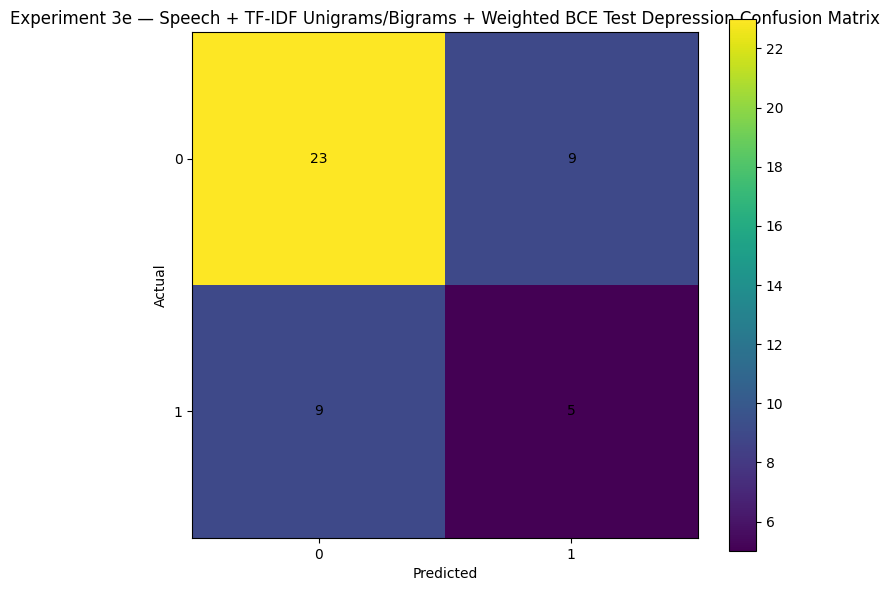

array([[23,  9],
       [ 9,  5]])

In [ ]:
# ============================================================
# Experiment 3e
# Final Test Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_binary_test
    ),
    y_pred=(
        experiment_3e_binary_final[
            "test_predictions"
        ]
    ),
    labels=[
        0,
        1,
    ],
    title=(
        "Experiment 3e — "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "Weighted BCE "
        "Test Depression Confusion Matrix"
    ),
)

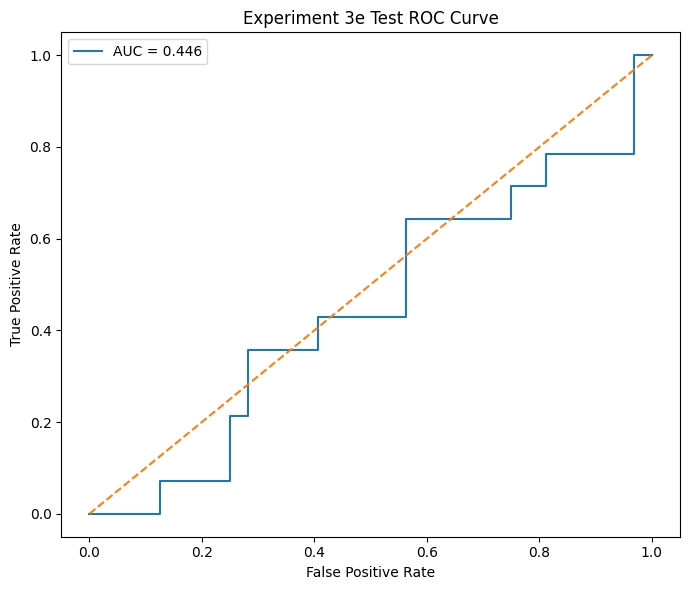

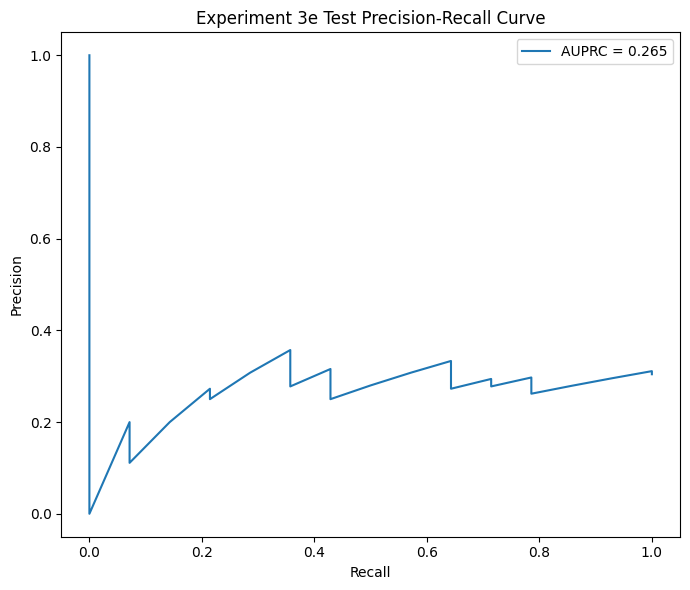

In [ ]:
# ============================================================
# Experiment 3e
# Final Test Classification Curves
# ============================================================

plot_classification_curves(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_3e_binary_final[
            "test_probabilities"
        ]
    ),
    title_prefix=(
        "Experiment 3e Test"
    ),
)

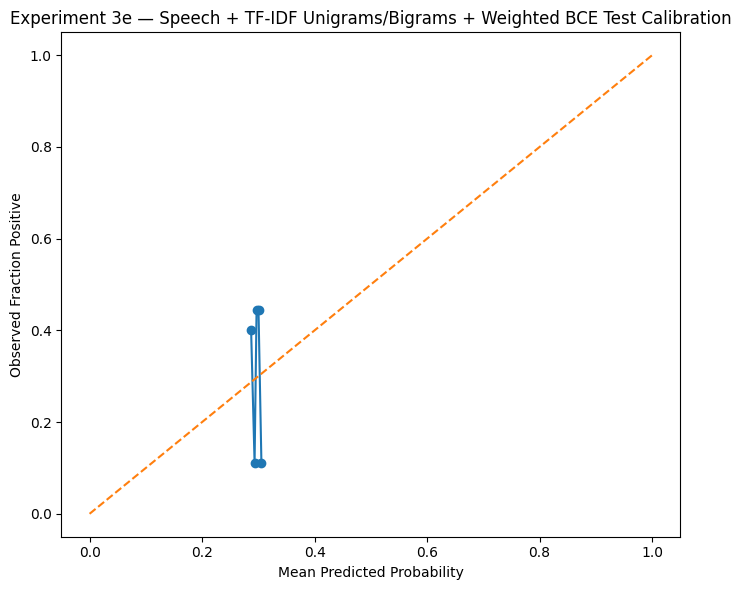

,mean_predicted_probability,observed_fraction_positive,n
0,0.287196,0.400000,10
1,0.293355,0.111111,9
2,0.296879,0.444444,9
3,0.300327,0.444444,9
4,0.305501,0.111111,9


In [ ]:
# ============================================================
# Experiment 3e
# Final Test Calibration
# ============================================================

plot_calibration_curve_manual(
    y_true=(
        y_binary_test
    ),
    probabilities=(
        experiment_3e_binary_final[
            "test_probabilities"
        ]
    ),
    n_bins=5,
    title=(
        "Experiment 3e — "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "Weighted BCE "
        "Test Calibration"
    ),
)

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.135057,31
1,0,speech__articulation_rate,0.157087,31
2,0,speech__phonation_ratio,0.075340,31
3,0,speech__pause_rate,0.075427,31
4,0,speech__mean_pause_duration,0.191202,31
5,0,speech__mean_f0_hertz,0.034021,31
6,0,speech__std_f0_hertz,0.061069,31
7,0,speech__mean_intensity_db,0.024961,31
8,0,speech__std_intensity_db,0.068384,31
9,0,speech__range_ratio_intensity_db,0.030787,31


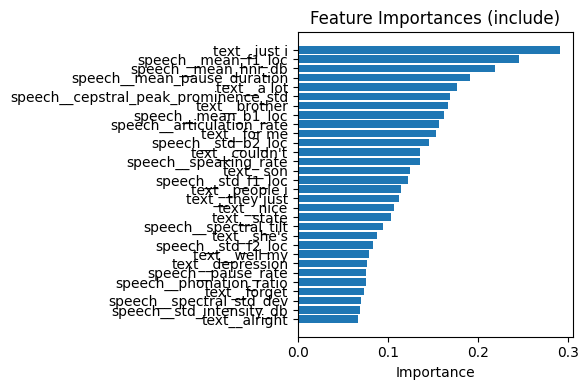

In [ ]:
# ============================================================
# Experiment 3e
# Final Model Feature Importance
# ============================================================

experiment_3e_binary_importance = (
    show_feature_importance(
        experiment_3e_binary_final[
            "model"
        ],
        top_n=30,
    )
)

### Compare 3a vs. 3e Test Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3A VS 3E — TEST COMPARISON
# ============================================================

experiment_3a_vs_3e_binary_test = (
    pd.DataFrame(
        {
            "Experiment 3a - Standard BCE": (
                experiment_3a_binary_final[
                    "test_metrics"
                ]
            ),

            "Experiment 3e - Weighted BCE": (
                experiment_3e_binary_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_3a_vs_3e_binary_test
)

### Compare 3a vs. 3e CV Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3A VS 3E — CV COMPARISON
# Standard BCE vs Weighted BCE
# ============================================================

experiment_3a_vs_3e_binary_cv = (
    pd.DataFrame(
        {
            "Experiment 3a - Standard BCE": (
                experiment_3a_binary_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 3e - Weighted BCE": (
                experiment_3e_binary_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_3a_vs_3e_binary_cv
)

### Experiment 3f LDS

Using severity-stratified master regression folds.

Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS | Regression | Outer fold 1
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.660, 6.282)
DNAMite active features | 77 / 77
DNAMite epochs | split=1 | ran=85 | best=55 | best val_loss=0.755859 | hit ceiling=False
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.632, 2007.659)
DNAMite active features | 76 / 76
DNAMite epochs | split=1 | ran=116 | best=86 | best val_loss=0.579453 | hit ceiling=False
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.695, 6.210)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=94 | best=64 | best val_loss=0.286875 | hit ceiling=Fals

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,4.0,sqrt_inverse,4.533765,0.535715
1,2.0,sqrt_inverse,4.534070,0.538559
2,2.0,inverse,4.534568,0.545068
3,3.0,inverse,4.542796,0.566551
4,1.0,sqrt_inverse,4.544857,0.516402
5,1.0,inverse,4.545246,0.525312
6,3.0,sqrt_inverse,4.561122,0.589973
7,4.0,inverse,4.563224,0.597795
8,0.5,sqrt_inverse,4.585502,0.486945
9,0.5,inverse,4.599948,0.475668


Best imbalance parameters: {'lds_sigma': 4.0, 'lds_reweight_method': 'sqrt_inverse'} mean inner MAE: 4.53376517896874
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 4.0, 'lds_reweight_method': 'sqrt_inverse'}
  Inner fold 1/3
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=4.0, method=sqrt_inverse, weight range=(0.836, 2.876)
DNAMite active features | 77 / 77
DNAMite epochs | split=1 | ran=43 | best=13 | best val_loss=0.820371 | hit ceiling=False
  Inner fold 2/3
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=4.0, method=sqrt_inverse, weight range=(0.850, 3.187)
DNAMite active features | 76 / 76
DNAMite epochs | split=1 | ran=35 | best=5 | best val_loss=1.092158 | hit ceiling=False
  Inner fold 3/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=4.0, method=sqrt_inverse, weight range=(0.8

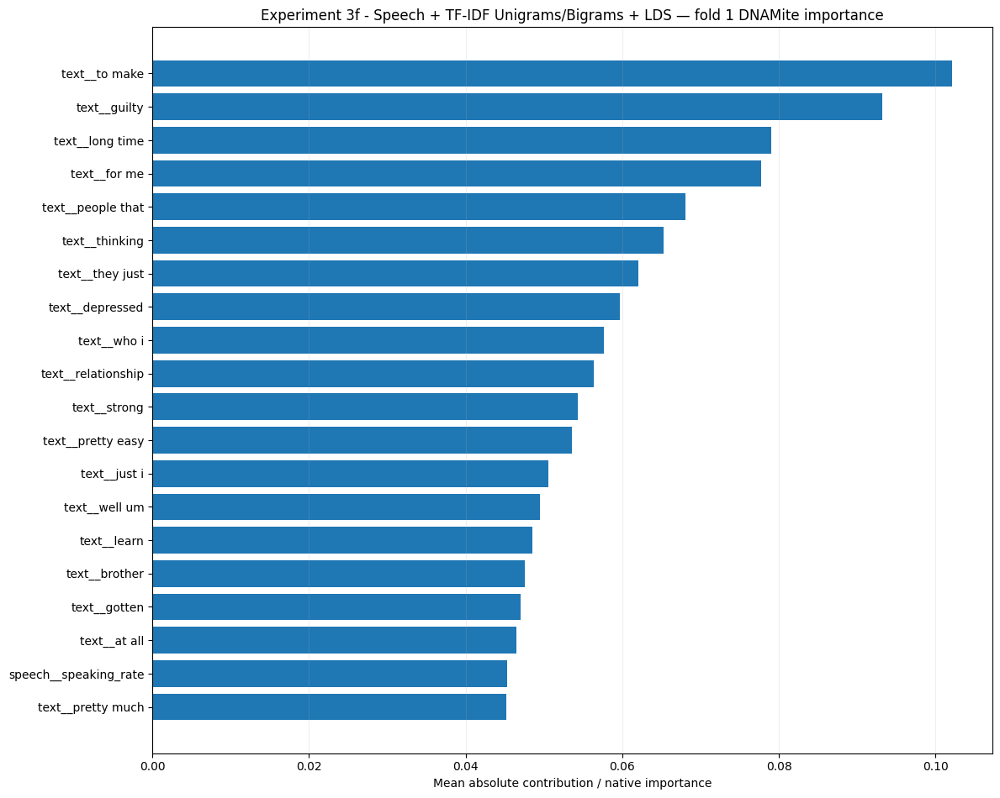

MAE               3.937112
RMSE              5.353085
R2               -0.033436
Spearman_Rho      0.373854
Spearman_P        0.054732
Pearson_R         0.248452
Pearson_P         0.211442
Exact_Accuracy    0.148148
Within_1          0.370370
Within_2          0.481481
Within_3          0.518519
dtype: float64
Trivial mean baseline: {'MAE': 4.334362139917695, 'RMSE': np.float64(5.267151420624956), 'R2': -0.0005225338874048635}

Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS | Regression | Outer fold 2
Regression fold strata counts: {0: 24, 1: 24, 2: 19, 3: 21, 4: 20}
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.691, 2093.983)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=127 | best=97 | best val_loss=0.364116 | hit ceiling=False
Selected 37 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.717, 2005.506)
DN

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,3.0,inverse,4.615272,0.228363
1,2.0,inverse,4.616037,0.227504
2,4.0,inverse,4.618796,0.232293
3,1.0,inverse,4.627775,0.231579
4,0.5,sqrt_inverse,4.643490,0.248138
5,2.0,sqrt_inverse,4.650420,0.255306
6,0.5,inverse,4.651251,0.253519
7,4.0,sqrt_inverse,4.654834,0.261028
8,3.0,sqrt_inverse,4.655026,0.258382
9,1.0,sqrt_inverse,4.663912,0.262340


Best imbalance parameters: {'lds_sigma': 3.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.615272324882679
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 3.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=3.0, method=inverse, weight range=(0.719, 57.478)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=39 | best=9 | best val_loss=0.817448 | hit ceiling=False
  Inner fold 2/3
Selected 37 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=3.0, method=inverse, weight range=(0.637, 16.129)
DNAMite active features | 65 / 65
DNAMite epochs | split=1 | ran=45 | best=15 | best val_loss=0.853376 | hit ceiling=False
  Inner fold 3/3
Selected 51 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=3.0, method=inverse, weight range=(0.649, 20.021)
DNAMite ac

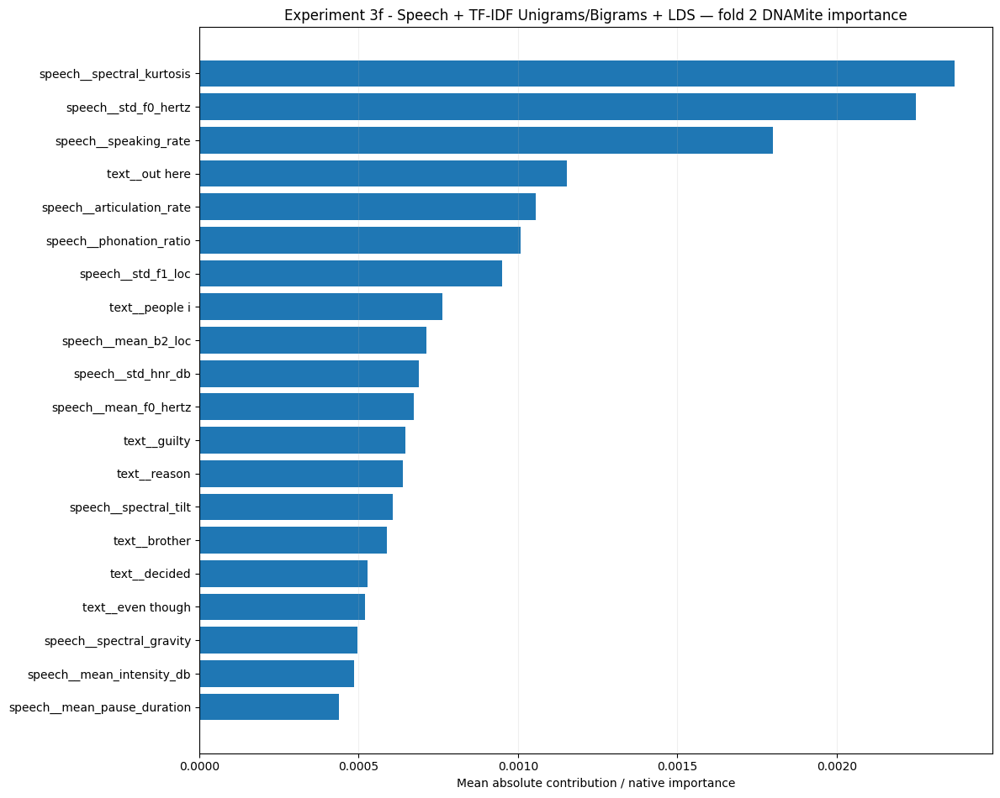

MAE               4.815810
RMSE              6.461020
R2               -0.069739
Spearman_Rho      0.157364
Spearman_P        0.433100
Pearson_R         0.155790
Pearson_P         0.437772
Exact_Accuracy    0.111111
Within_1          0.148148
Within_2          0.333333
Within_3          0.481481
dtype: float64
Trivial mean baseline: {'MAE': 4.996913580246913, 'RMSE': np.float64(6.247201019347119), 'R2': -0.00010765255905487159}

Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS | Regression | Outer fold 3
Regression fold strata counts: {0: 48, 1: 27, 2: 20, 3: 10, 4: 3}
Selected 50 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.661, 5.944)
DNAMite active features | 78 / 78
DNAMite epochs | split=1 | ran=148 | best=118 | best val_loss=0.393709 | hit ceiling=False
Selected 40 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.703, 6.025)
DNAMite

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,0.5,inverse,4.229310,0.447704
1,0.5,sqrt_inverse,4.246350,0.472964
2,4.0,inverse,4.325494,0.501889
3,1.0,sqrt_inverse,4.327378,0.480709
4,4.0,sqrt_inverse,4.329236,0.483489
5,3.0,sqrt_inverse,4.331788,0.483080
6,2.0,inverse,4.332758,0.497539
7,1.0,inverse,4.333288,0.471150
8,2.0,sqrt_inverse,4.336024,0.487168
9,3.0,inverse,4.340294,0.501847


Best imbalance parameters: {'lds_sigma': 0.5, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.229309812178456
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 0.5, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 50 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=inverse, weight range=(0.393, 31.789)
DNAMite active features | 78 / 78
DNAMite epochs | split=1 | ran=74 | best=44 | best val_loss=0.742371 | hit ceiling=False
  Inner fold 2/3
Selected 40 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=inverse, weight range=(0.433, 31.869)
DNAMite active features | 68 / 68
DNAMite epochs | split=1 | ran=310 | best=280 | best val_loss=0.188294 | hit ceiling=False
  Inner fold 3/3
Selected 43 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=inverse, weight range=(0.412, 3743300.014)
DN

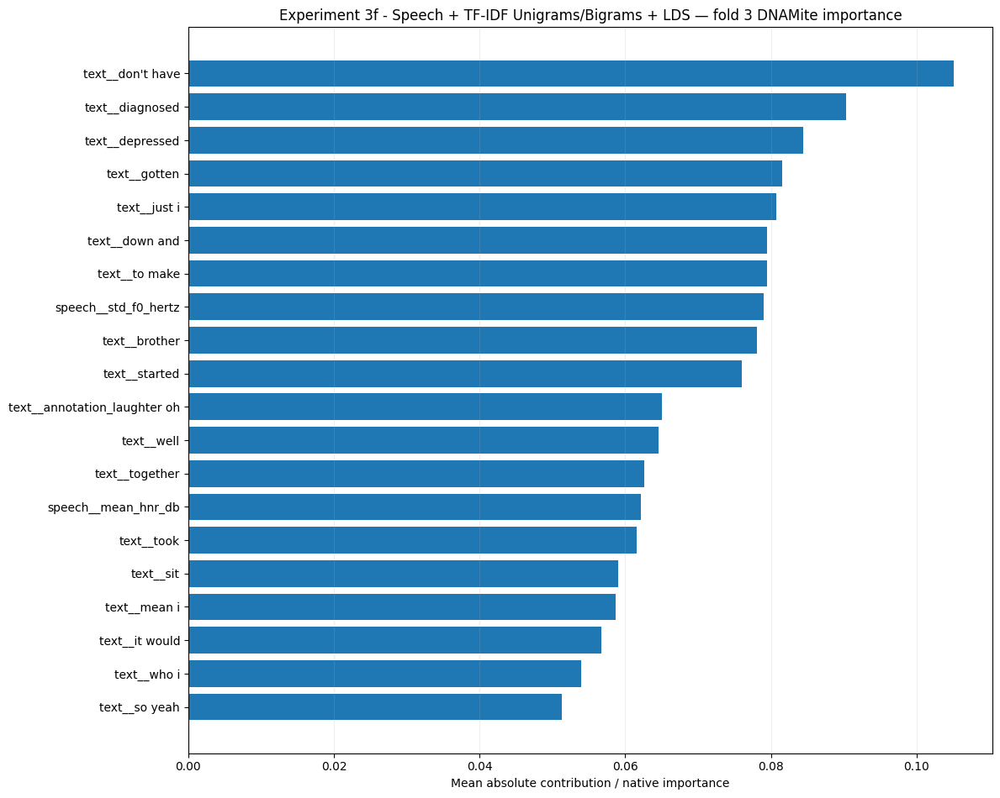

MAE               4.007579
RMSE              5.698524
R2               -0.032220
Spearman_Rho      0.328942
Spearman_P        0.093866
Pearson_R         0.258468
Pearson_P         0.193006
Exact_Accuracy    0.037037
Within_1          0.407407
Within_2          0.444444
Within_3          0.592593
dtype: float64
Trivial mean baseline: {'MAE': 4.607338820301783, 'RMSE': np.float64(5.614448646811346), 'R2': -0.00198667916630324}

Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS | Regression | Outer fold 4
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.603, 5.926)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=150 | best=120 | best val_loss=0.457948 | hit ceiling=False
Selected 51 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.645, 6.025)
DNAMite act

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,1.0,inverse,4.560819,0.567693
1,2.0,inverse,4.563076,0.552079
2,0.5,inverse,4.567530,0.567413
3,3.0,inverse,4.568198,0.552712
4,1.0,sqrt_inverse,4.573089,0.597513
5,2.0,sqrt_inverse,4.574013,0.576842
6,0.5,sqrt_inverse,4.574463,0.592412
7,4.0,sqrt_inverse,4.579405,0.574579
8,4.0,inverse,4.581902,0.559651
9,3.0,sqrt_inverse,4.588056,0.569352


Best imbalance parameters: {'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.560819239389604
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 1.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=1.0, method=inverse, weight range=(0.398, 12.303)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=500 | best=499 | best val_loss=0.133798 | hit ceiling=True
  Inner fold 2/3
Selected 51 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=1.0, method=inverse, weight range=(0.456, 12.352)
DNAMite active features | 79 / 79
DNAMite epochs | split=1 | ran=45 | best=15 | best val_loss=0.794287 | hit ceiling=False
  Inner fold 3/3
Selected 42 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=1.0, method=inverse, weight range=(0.523, 12643.868)
DNAMi

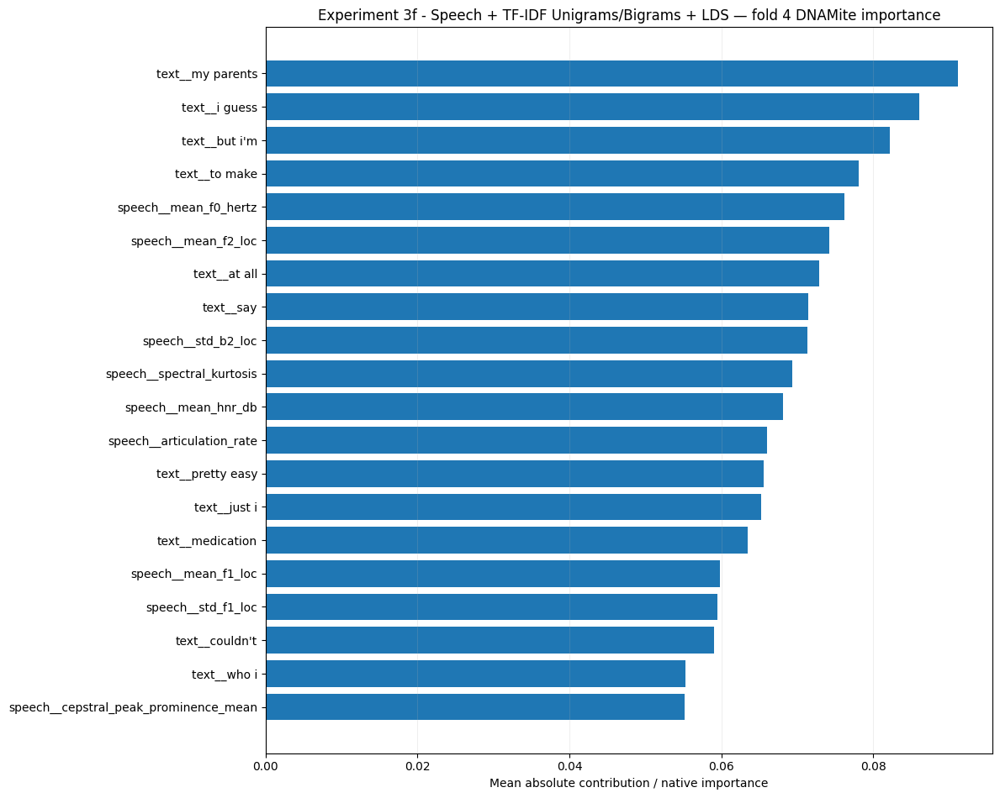

MAE               3.525557
RMSE              4.627889
R2                0.177124
Spearman_Rho      0.379598
Spearman_P        0.050829
Pearson_R         0.448512
Pearson_P         0.018952
Exact_Accuracy    0.111111
Within_1          0.370370
Within_2          0.518519
Within_3          0.592593
dtype: float64
Trivial mean baseline: {'MAE': 4.469821673525377, 'RMSE': np.float64(5.104430685201576), 'R2': -0.0010672499209445352}

Experiment 3f - Speech + TF-IDF Unigrams/Bigrams + LDS | Regression | Outer fold 5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.676, 1996.945)
DNAMite active features | 75 / 75
DNAMite epochs | split=1 | ran=183 | best=153 | best val_loss=0.301282 | hit ceiling=False
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.609, 6.091)
DNAMit

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,4.0,inverse,4.560110,0.381396
1,2.0,sqrt_inverse,4.565210,0.376022
2,3.0,sqrt_inverse,4.566404,0.390135
3,2.0,inverse,4.569669,0.381556
4,4.0,sqrt_inverse,4.570758,0.392364
5,3.0,inverse,4.570965,0.389096
6,1.0,sqrt_inverse,4.575269,0.348886
7,1.0,inverse,4.578291,0.331433
8,0.5,sqrt_inverse,4.624968,0.310925
9,0.5,inverse,4.697541,0.181356


Best imbalance parameters: {'lds_sigma': 4.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.560109857675801
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 4.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=4.0, method=inverse, weight range=(0.676, 11.638)
DNAMite active features | 75 / 75
DNAMite epochs | split=1 | ran=71 | best=41 | best val_loss=0.719422 | hit ceiling=False
  Inner fold 2/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=4.0, method=inverse, weight range=(0.642, 9.328)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=49 | best=19 | best val_loss=0.797421 | hit ceiling=False
  Inner fold 3/3
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=4.0, method=inverse, weight range=(0.632, 8.395)
DNAMite act

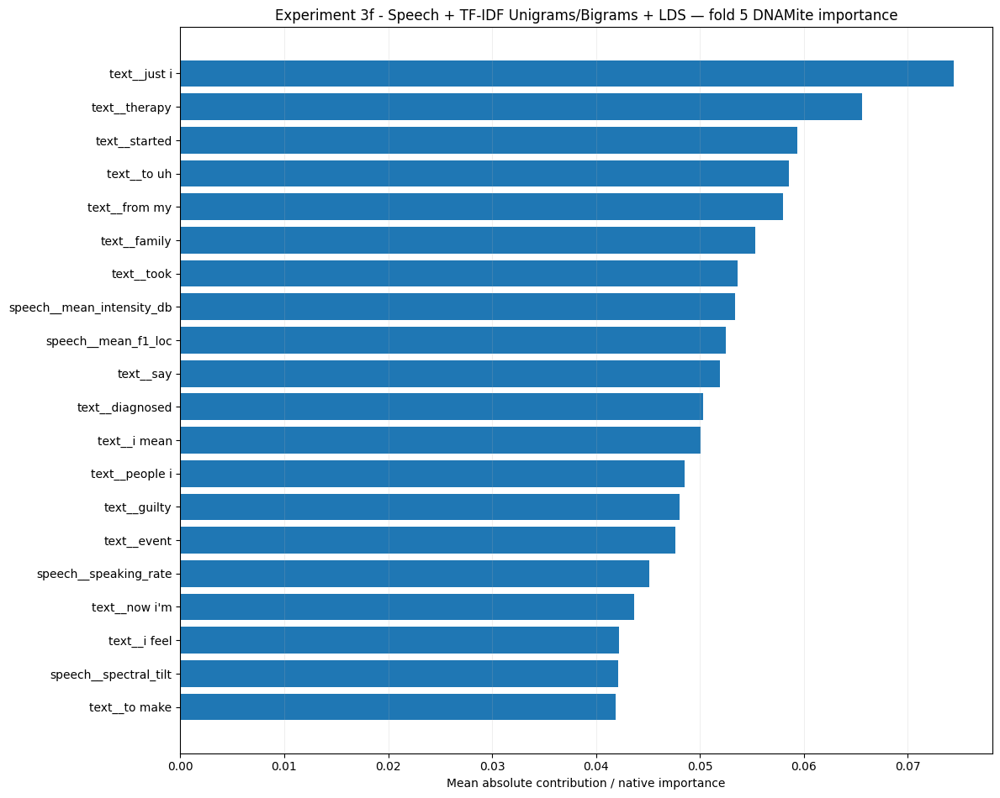

MAE               4.468618
RMSE              5.460855
R2                0.057510
Spearman_Rho      0.271838
Spearman_P        0.170168
Pearson_R         0.286048
Pearson_P         0.148054
Exact_Accuracy    0.148148
Within_1          0.185185
Within_2          0.259259
Within_3          0.296296
dtype: float64
Trivial mean baseline: {'MAE': 4.728052126200274, 'RMSE': np.float64(5.625066681513008), 'R2': -2.4386542963661384e-05}

Nested CV summary:


,Mean,SD
MAE,4.150935,0.500088
RMSE,5.520275,0.660419
R2,0.019848,0.099662
Spearman_Rho,0.302319,0.091841
Pearson_R,0.279454,0.106441
Exact_Accuracy,0.111111,0.045361
Within_1,0.296296,0.120014
Within_2,0.407407,0.107981
Within_3,0.496296,0.121716



Trivial mean-predictor baseline:


,Mean,SD
Baseline_MAE,4.627298,0.253858
Baseline_RMSE,5.571660,0.439337
Baseline_R2,-0.000742,0.000809


In [ ]:
# ============================================================
# Experiment 3f
# Speech + TF-IDF Unigrams/Bigrams + LDS
# Regression Nested Cross-Validation
# ============================================================

EXPERIMENT_3F_NAME = (
    "Experiment 3f - "
    "Speech + TF-IDF Unigrams/Bigrams + LDS"
)


experiment_3f_regression_cv = (
    nested_cv_regression(
        experiment_name=(
            EXPERIMENT_3F_NAME
        ),
        speech_features=(
            development_speech
        ),
        y=(
            y_regression_development
        ),
        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="lds",
        use_feature_selection=False,
    )
)

In [ ]:
# ============================================================
# Experiment 3f
# Inspect CV Results
# ============================================================

print("OUTER-FOLD RESULTS")

display(
    experiment_3f_regression_cv[
        "outer_results"
    ]
)


print("\nCV SUMMARY")

display(
    experiment_3f_regression_cv[
        "summary"
    ]
)

OUTER-FOLD RESULTS


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method,MAE,RMSE,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,16,32,2,4.0,sqrt_inverse,3.937112,5.353085,...,0.518519,4.334362,5.267151,-0.000523,2.297287,3072.773438,16.518066,22.0,0.000072,0.000019
1,2,4,0.0010,32,16,2,3.0,inverse,4.815810,6.461020,...,0.481481,4.996914,6.247201,-0.000108,0.686358,3073.125000,16.518066,22.0,0.000021,0.000006
2,3,16,0.0010,16,16,2,0.5,inverse,4.007579,5.698524,...,0.592593,4.607339,5.614449,-0.001987,2.493446,3072.812500,16.518066,22.0,0.000081,0.000022
3,4,16,0.0005,32,16,2,1.0,inverse,3.525557,4.627889,...,0.592593,4.469822,5.104431,-0.001067,2.235338,3073.039062,16.518066,22.0,0.000071,0.000019
4,5,32,0.0005,32,16,2,4.0,inverse,4.468618,5.460855,...,0.296296,4.728052,5.625067,-0.000024,2.126701,3073.308594,16.518066,22.0,0.000068,0.000018



CV SUMMARY


,Mean,SD
MAE,4.150935,0.500088
RMSE,5.520275,0.660419
R2,0.019848,0.099662
Spearman_Rho,0.302319,0.091841
Pearson_R,0.279454,0.106441
Exact_Accuracy,0.111111,0.045361
Within_1,0.296296,0.120014
Within_2,0.407407,0.107981
Within_3,0.496296,0.121716


In [ ]:
# ============================================================
# Experiment 3f
# Cross-Validation Performance
# ============================================================

experiment_3f_cv_metrics = (
    experiment_3f_regression_cv[
        "outer_results"
    ].copy()
)

experiment_3f_cv_summary = (
    experiment_3f_regression_cv[
        "summary"
    ].copy()
)


print("Outer-Fold Metrics:")

display(
    experiment_3f_cv_metrics
)


print("\nMean ± SD Across Outer Folds:")

display(
    experiment_3f_cv_summary
)

Outer-Fold Metrics:


,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method,MAE,RMSE,...,Within_3,Baseline_MAE,Baseline_RMSE,Baseline_R2,outer_fold_train_seconds,peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,training_energy_kwh,training_co2_kg
0,1,16,0.0005,16,32,2,4.0,sqrt_inverse,3.937112,5.353085,...,0.518519,4.334362,5.267151,-0.000523,2.297287,3072.773438,16.518066,22.0,0.000072,0.000019
1,2,4,0.0010,32,16,2,3.0,inverse,4.815810,6.461020,...,0.481481,4.996914,6.247201,-0.000108,0.686358,3073.125000,16.518066,22.0,0.000021,0.000006
2,3,16,0.0010,16,16,2,0.5,inverse,4.007579,5.698524,...,0.592593,4.607339,5.614449,-0.001987,2.493446,3072.812500,16.518066,22.0,0.000081,0.000022
3,4,16,0.0005,32,16,2,1.0,inverse,3.525557,4.627889,...,0.592593,4.469822,5.104431,-0.001067,2.235338,3073.039062,16.518066,22.0,0.000071,0.000019
4,5,32,0.0005,32,16,2,4.0,inverse,4.468618,5.460855,...,0.296296,4.728052,5.625067,-0.000024,2.126701,3073.308594,16.518066,22.0,0.000068,0.000018



Mean ± SD Across Outer Folds:


,Mean,SD
MAE,4.150935,0.500088
RMSE,5.520275,0.660419
R2,0.019848,0.099662
Spearman_Rho,0.302319,0.091841
Pearson_R,0.279454,0.106441
Exact_Accuracy,0.111111,0.045361
Within_1,0.296296,0.120014
Within_2,0.407407,0.107981
Within_3,0.496296,0.121716


In [ ]:
# ============================================================
# Experiment 3f
# Selected Hyperparameters Across Outer Folds
# ============================================================

experiment_3f_parameters = (
    experiment_3f_regression_cv[
        "outer_results"
    ][
        [
            "Outer_Fold",
            "max_bins",
            "learning_rate",
            "n_embed",
            "n_hidden",
            "n_layers",
            "lds_sigma",
            "lds_reweight_method",
        ]
    ]
    .copy()
)

display(
    experiment_3f_parameters
)

,Outer_Fold,max_bins,learning_rate,n_embed,n_hidden,n_layers,lds_sigma,lds_reweight_method
0,1,16,0.0005,16,32,2,4.0,sqrt_inverse
1,2,4,0.0010,32,16,2,3.0,inverse
2,3,16,0.0010,16,16,2,0.5,inverse
3,4,16,0.0005,32,16,2,1.0,inverse
4,5,32,0.0005,32,16,2,4.0,inverse



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams_LDS
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


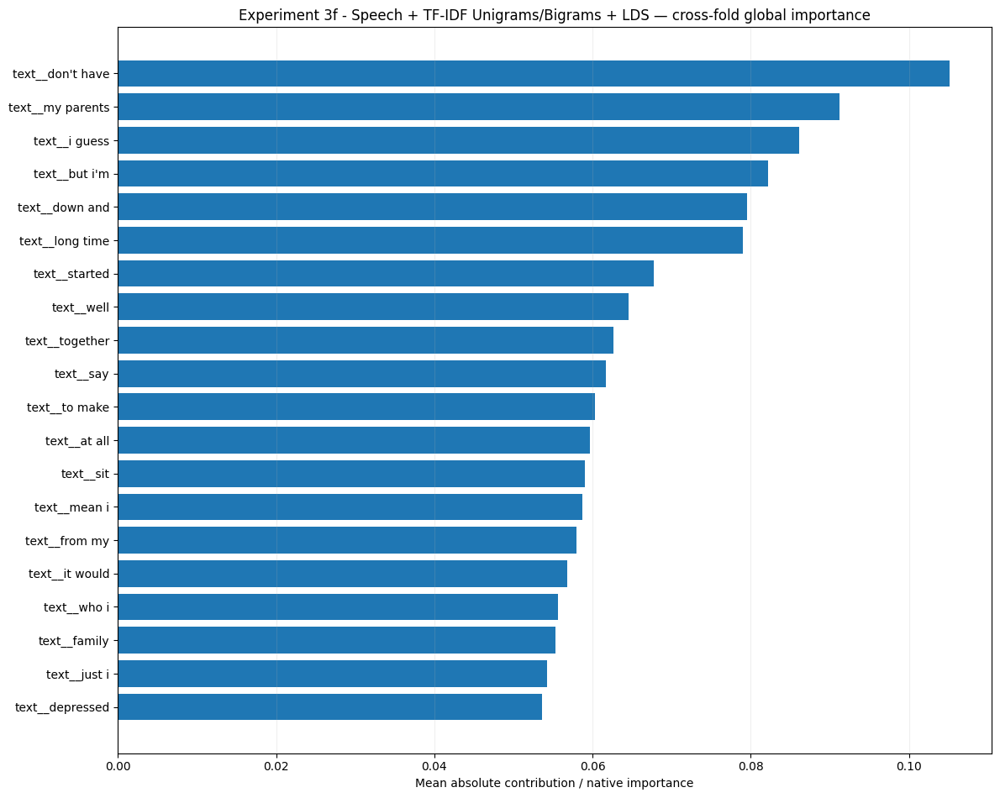

PosixPath('/content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/DNAMite_Optimized/Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams_LDS/interpretability_summary')

In [ ]:
# ============================================================
# Experiment 3f
# Cross-Fold Interpretability
# Speech + TF-IDF Unigrams/Bigrams + LDS
# ============================================================

experiment_3f_interpretability = (
    aggregate_interpretability_across_folds(
        model_family="DNAMite_Optimized",
        experiment_name=(
            EXPERIMENT_3F_NAME
        ),
        top_k=30,
    )
)

experiment_3f_interpretability

In [ ]:
# ============================================================
# Experiment 3f
# Hyperparameter-Search / Development Cost
# ============================================================

experiment_3f_development_dir = (
    MASTER_DEVELOPMENT_COST_ROOT
    / _safe_name("DNAMite_Optimized")
    / _safe_name(EXPERIMENT_3F_NAME)
)


experiment_3f_development_rows = []

for path in sorted(
    experiment_3f_development_dir.glob(
        "fold_*.json"
    )
):
    with open(
        path,
        "r",
    ) as file:
        experiment_3f_development_rows.append(
            json.load(file)
        )


experiment_3f_development_df = (
    pd.DataFrame(
        experiment_3f_development_rows
    )
)

display(
    experiment_3f_development_df
)

,model_family,experiment_name,task,outer_fold,development_fit_count,development_seconds,development_energy_kwh,development_co2_kg,development_peak_ram_mb,development_peak_gpu_memory_mb,development_peak_gpu_reserved_mb
0,DNAMite Optimized,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,regression,1,126,151.155837,0.004665,0.001248,3072.785156,16.518066,22.0
1,DNAMite Optimized,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,regression,2,126,252.774306,0.008058,0.002156,3073.160156,16.518066,22.0
2,DNAMite Optimized,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,regression,3,126,227.235314,0.007206,0.001929,3073.136719,16.518066,22.0
3,DNAMite Optimized,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,regression,4,126,216.862520,0.006863,0.001837,3073.074219,16.518066,22.0
4,DNAMite Optimized,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,regression,5,126,199.662835,0.006286,0.001682,3073.332031,16.518066,22.0


In [ ]:
# ============================================================
# Experiment 3f
# Development Cost Summary
# ============================================================

experiment_3f_development_metrics = [
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",
]


experiment_3f_development_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3f_development_df[
                    experiment_3f_development_metrics
                ].mean()
            ),
            "SD": (
                experiment_3f_development_df[
                    experiment_3f_development_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3f_development_summary[
    "Mean ± SD"
] = [
    f"{mean:.6f} ± {sd:.6f}"
    for mean, sd in zip(
        experiment_3f_development_summary[
            "Mean"
        ],
        experiment_3f_development_summary[
            "SD"
        ],
    )
]


display(
    experiment_3f_development_summary
)

,Mean,SD,Mean ± SD
development_fit_count,126.000000,0.000000,126.000000 ± 0.000000
development_seconds,209.538163,37.888710,209.538163 ± 37.888710
development_energy_kwh,0.006616,0.001265,0.006616 ± 0.001265
development_co2_kg,0.001770,0.000339,0.001770 ± 0.000339


In [ ]:
# ============================================================
# Experiment 3f
# Final Outer-Fold Training Resource / Energy Summary
# ============================================================

experiment_3f_training_metrics = [
    "outer_fold_train_seconds",
    "peak_ram_mb",
    "peak_gpu_memory_mb",
    "peak_gpu_reserved_mb",
    "training_energy_kwh",
    "training_co2_kg",
]


experiment_3f_training_summary = (
    pd.DataFrame(
        {
            "Mean": (
                experiment_3f_regression_cv[
                    "outer_results"
                ][
                    experiment_3f_training_metrics
                ].mean()
            ),
            "SD": (
                experiment_3f_regression_cv[
                    "outer_results"
                ][
                    experiment_3f_training_metrics
                ].std(
                    ddof=1
                )
            ),
        }
    )
)


experiment_3f_training_summary[
    "Mean ± SD"
] = [
    f"{mean:.8f} ± {sd:.8f}"
    for mean, sd in zip(
        experiment_3f_training_summary[
            "Mean"
        ],
        experiment_3f_training_summary[
            "SD"
        ],
    )
]


display(
    experiment_3f_training_summary
)

,Mean,SD,Mean ± SD
outer_fold_train_seconds,1.967826,0.728661,1.96782615 ± 0.72866061
peak_ram_mb,3073.011719,0.222588,3073.01171875 ± 0.22258771
peak_gpu_memory_mb,16.518066,0.000000,16.51806641 ± 0.00000000
peak_gpu_reserved_mb,22.000000,0.000000,22.00000000 ± 0.00000000
training_energy_kwh,0.000063,0.000023,0.00006264 ± 0.00002349
training_co2_kg,0.000017,0.000006,0.00001677 ± 0.00000629


In [ ]:
# ============================================================
# Experiment 3f
# Speech + TF-IDF Unigrams/Bigrams + LDS
# Final Regression Model
# ============================================================

EXPERIMENT_3F_NAME = (
    "Experiment 3f - "
    "Speech + TF-IDF Unigrams/Bigrams + LDS"
)

experiment_3f_regression_final = (
    train_final_regression_model(
        speech_development=(
            development_speech
        ),
        y_development=(
            y_regression_development
        ),
        speech_test=(
            test_speech
        ),
        y_test=(
            y_regression_test
        ),
        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),
        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),
        text_vocabulary=(
            unigram_bigram_data[
                "vocabulary"
            ]
        ),
        text_representation=(
            "unigram_bigram"
        ),
        imbalance_strategy="lds",
        experiment_name=(
            EXPERIMENT_3F_NAME
        ),
        use_feature_selection=False,
        save_outputs=True,
    )
)

Regression fold strata counts: {0: 60, 1: 34, 2: 25, 3: 12, 4: 4}
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.681, 2277.947)
DNAMite active features | 77 / 77
DNAMite epochs | split=1 | ran=301 | best=271 | best val_loss=0.619130 | hit ceiling=False
Selected 56 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.708, 6.654)
DNAMite active features | 84 / 84
DNAMite epochs | split=1 | ran=127 | best=97 | best val_loss=0.269504 | hit ceiling=False
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=sqrt_inverse, weight range=(0.645, 6.751)
DNAMite active features | 74 / 74
DNAMite epochs | split=1 | ran=125 | best=95 | best val_loss=0.761648 | hit ceiling=False
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=0.5, method=inverse, weight range=(0.417

,lds_sigma,lds_reweight_method,mean_score,sd_score
0,2.0,inverse,4.787331,0.149508
1,3.0,inverse,4.792675,0.154491
2,4.0,inverse,4.799475,0.144005
3,4.0,sqrt_inverse,4.853388,0.042854
4,1.0,sqrt_inverse,4.857016,0.056679
5,0.5,inverse,4.857796,0.010188
6,0.5,sqrt_inverse,4.863789,0.046635
7,1.0,inverse,4.864039,0.068518
8,2.0,sqrt_inverse,4.866790,0.042880
9,3.0,sqrt_inverse,4.868704,0.037199


Best imbalance parameters: {'lds_sigma': 2.0, 'lds_reweight_method': 'inverse'} mean inner MAE: 4.787330966842908
DNAMite candidate 1/32: {'learning_rate': 0.0005, 'max_bins': 4, 'n_embed': 16, 'n_hidden': 16, 'n_layers': 2, 'lds_sigma': 2.0, 'lds_reweight_method': 'inverse'}
  Inner fold 1/3
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=2.0, method=inverse, weight range=(0.588, 42.322)
DNAMite active features | 77 / 77
DNAMite epochs | split=1 | ran=500 | best=478 | best val_loss=0.462550 | hit ceiling=True
  Inner fold 2/3
Selected 56 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=2.0, method=inverse, weight range=(0.519, 14.832)
DNAMite active features | 84 / 84
DNAMite epochs | split=1 | ran=52 | best=22 | best val_loss=0.405980 | hit ceiling=False
  Inner fold 3/3
Selected 46 TF-IDF features for regression / unigram_bigram using alpha=0.01
LDS | sigma=2.0, method=inverse, weight range=(0.528, 16.030)
DNAMite 

In [ ]:
# ============================================================
# Experiment 3f
# Final Test Metrics
# ============================================================

display(
    pd.Series(
        experiment_3f_regression_final[
            "test_metrics"
        ]
    ).to_frame(
        "Value"
    )
)

,Value
MAE,4.995835
RMSE,6.200054
R2,0.064633
Spearman_Rho,0.403568
Spearman_P,0.005416
Pearson_R,0.335344
Pearson_P,0.022713
Exact_Accuracy,0.021739
Within_1,0.152174
Within_2,0.326087


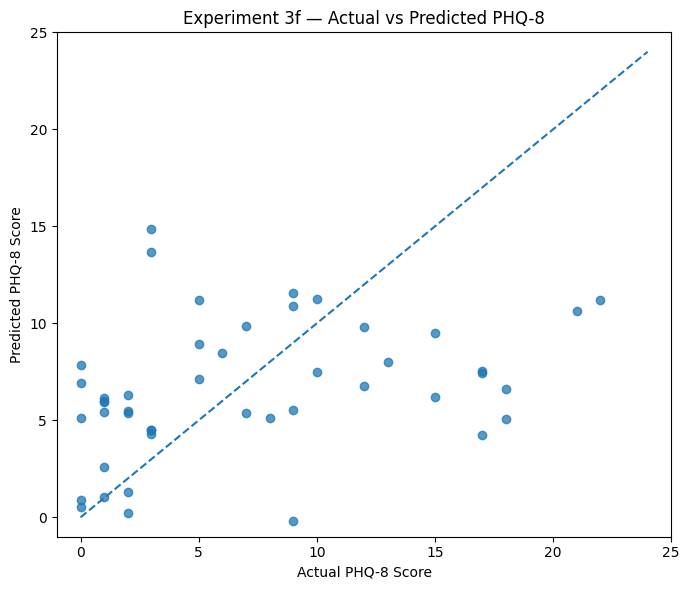

In [ ]:
# ============================================================
# Experiment 3f
# Actual vs Predicted PHQ-8
# ============================================================

plot_regression_predictions(
    y_true=(
        y_regression_test
    ),
    predictions=(
        experiment_3f_regression_final[
            "test_predictions"
        ]
    ),
    title=(
        "Experiment 3f — "
        "Actual vs Predicted PHQ-8"
    ),
)

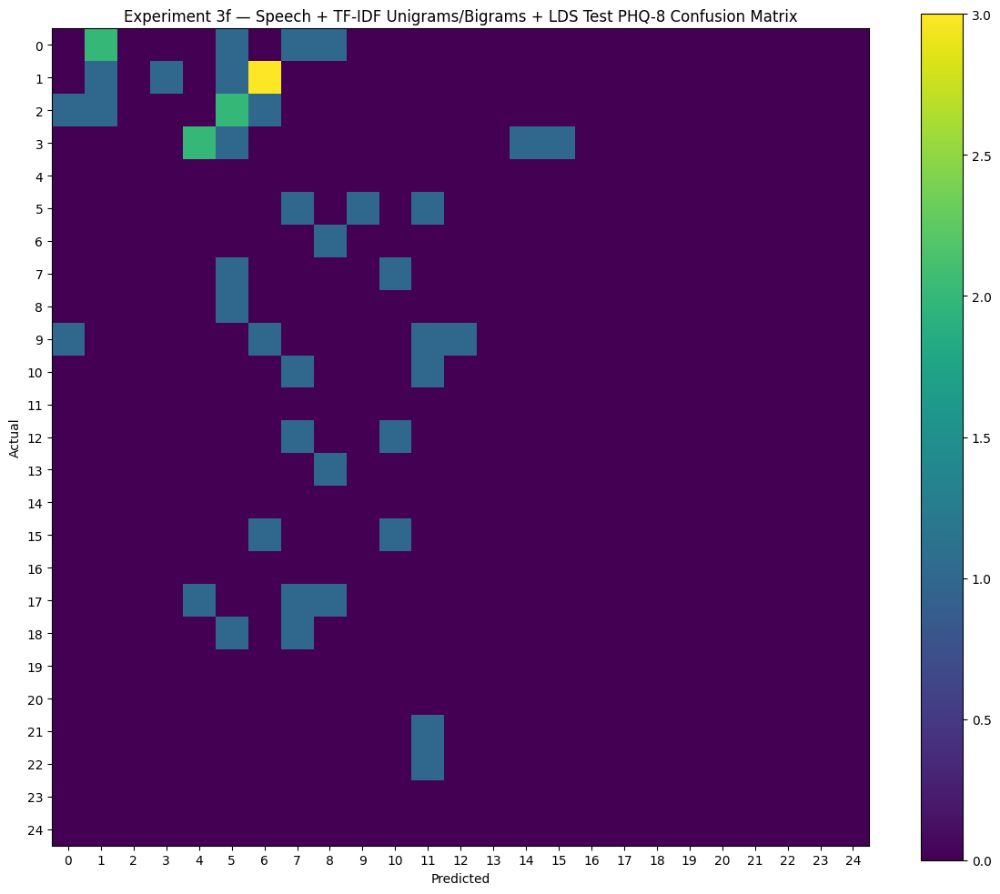

array([[0, 2, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 1, 0, 1, 0, 1, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [1, 1, 0, 0, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
      

In [ ]:
# ============================================================
# Experiment 3f
# Final Test PHQ-8 Confusion Matrix
# ============================================================

plot_confusion_matrix(
    y_true=(
        y_regression_test
        .astype(int)
    ),
    y_pred=(
        np.asarray(
            experiment_3f_regression_final[
                "test_rounded_predictions"
            ]
        )
        .astype(int)
    ),
    labels=(
        PHQ8_CLASS_LABELS
    ),
    title=(
        "Experiment 3f — "
        "Speech + TF-IDF Unigrams/Bigrams + LDS "
        "Test PHQ-8 Confusion Matrix"
    ),
    figsize=(
        12,
        10,
    ),
)

,split,feature,importance,n_bins
0,0,speech__speaking_rate,0.000019,3
1,0,speech__articulation_rate,0.004337,3
2,0,speech__phonation_ratio,0.053892,3
3,0,speech__pause_rate,0.000170,3
4,0,speech__mean_pause_duration,0.000035,3
5,0,speech__mean_f0_hertz,0.001275,3
6,0,speech__std_f0_hertz,0.000460,3
7,0,speech__mean_intensity_db,0.000181,3
8,0,speech__std_intensity_db,0.007550,3
9,0,speech__range_ratio_intensity_db,0.020806,3


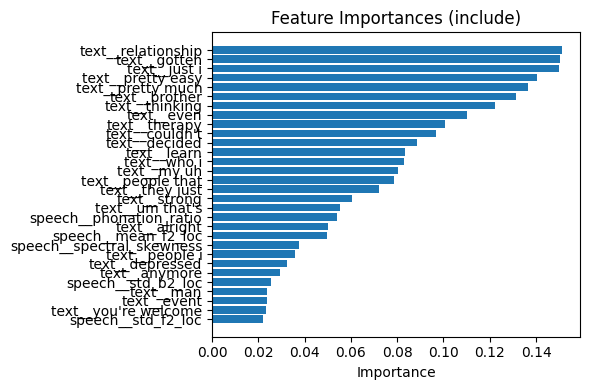

In [ ]:
# ============================================================
# Experiment 3f
# Final Model Feature Importance
# ============================================================

experiment_3f_regression_importance = (
    show_feature_importance(
        experiment_3f_regression_final[
            "model"
        ],
        top_n=30,
    )
)

### Experiment 3c vs. 3f Test Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3C VS 3F — TEST COMPARISON
# ============================================================

experiment_3c_vs_3f_regression_test = (
    pd.DataFrame(
        {
            "Experiment 3c - Baseline": (
                experiment_3c_regression_final[
                    "test_metrics"
                ]
            ),

            "Experiment 3f - LDS": (
                experiment_3f_regression_final[
                    "test_metrics"
                ]
            ),
        }
    )
)

display(
    experiment_3c_vs_3f_regression_test
)

### Experiment 3c vs. 3f CV Comparison

In [ ]:
# ============================================================
# EXPERIMENT 3C VS 3F — CV COMPARISON
# Standard Regression vs LDS
# ============================================================

experiment_3c_vs_3f_regression_cv = (
    pd.DataFrame(
        {
            "Experiment 3c - Baseline": (
                experiment_3c_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),

            "Experiment 3f - LDS": (
                experiment_3f_regression_cv[
                    "summary"
                ].apply(
                    lambda row: (
                        f"{row['Mean']:.4f} "
                        f"± {row['SD']:.4f}"
                    ),
                    axis=1,
                )
            ),
        }
    )
)

display(
    experiment_3c_vs_3f_regression_cv
)

## Comparison

In [ ]:
classification_imbalance_comparison_experiment = pd.DataFrame(
    {
        "1a Speech Standard": (
            experiment_1_binary_final[
                "test_metrics"
            ]
        ),
        "1b Speech with Feature Selection": (
            experiment_1b_binary_final[
                "test_metrics"
            ]
        ),
        "1e Speech Weighted BCE": (
            experiment_1e_binary_final[
                "test_metrics"
            ]
        ),
        "2a Speech+Uni Standard": (
            experiment_2_binary_final[
                "test_metrics"
            ]
        ),
        "2b Speech+Uni with Feature Selection": (
            experiment_2b_binary_final[
                "test_metrics"
            ]
        ),
        "2e Speech+Uni Weighted BCE": (
            experiment_2e_binary_final[
                "test_metrics"
            ]
        ),
        "3a Speech+UniBi Standard": (
            experiment_3_binary_final[
                "test_metrics"
            ]
        ),
        "3b Speech+UniBi with Feature Selection": (
            experiment_3b_binary_final[
                "test_metrics"
            ]
        ),
        "3e Speech+UniBi Weighted BCE": (
            experiment_3e_binary_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    classification_imbalance_comparison_experiment
)

In [ ]:
classification_imbalance_comparison_experiment1 = pd.DataFrame(
    {
        "1a Speech Standard": (
            experiment_1_binary_final[
                "test_metrics"
            ]
        ),
        "1b Speech with Feature Selection": (
            experiment_1b_binary_final[
                "test_metrics"
            ]
        ),
        "1e Speech Weighted BCE": (
            experiment_1e_binary_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    classification_imbalance_comparison_experiment1
)

In [ ]:
classification_imbalance_comparison_experiment2 = pd.DataFrame(
    {
        "2a Speech+Uni Standard": (
            experiment_2_binary_final[
                "test_metrics"
            ]
        ),
        "2b Speech+Uni with Feature Selection": (
            experiment_2b_binary_final[
                "test_metrics"
            ]
        ),
        "2e Speech+Uni Weighted BCE": (
            experiment_2e_binary_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    classification_imbalance_comparison_experiment2
)

In [ ]:
classification_imbalance_comparison_experiment3 = pd.DataFrame(
    {
        "3a Speech+UniBi Standard": (
            experiment_3_binary_final[
                "test_metrics"
            ]
        ),
        "3b Speech+UniBi with Feature Selection": (
            experiment_3b_binary_final[
                "test_metrics"
            ]
        ),
        "3e Speech+UniBi Weighted BCE": (
            experiment_3e_binary_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    classification_imbalance_comparison_experiment3
)

In [ ]:
regression_imbalance_comparison = pd.DataFrame(
    {
        "1c Speech Standard": (
            experiment_1_regression_final[
                "test_metrics"
            ]
        ),
        "1d Speech with Feature Selection": (
            experiment_1d_regression_final[
                "test_metrics"
            ]
        ),
        "1f Speech LDS": (
            experiment_1f_regression_final[
                "test_metrics"
            ]
        ),
        "2c Speech+Uni Standard": (
            experiment_2_regression_final[
                "test_metrics"
            ]
        ),
        "2d Speech+Uni with Feature Selection": (
            experiment_2d_regression_final[
                "test_metrics"
            ]
        ),
        "2f Speech+Uni LDS": (
            experiment_2f_regression_final[
                "test_metrics"
            ]
        ),
        "3c Speech+UniBi Standard": (
            experiment_3_regression_final[
                "test_metrics"
            ]
        ),
        "3d Speech+UniBi with Feature Selection": (
            experiment_3d_regression_final[
                "test_metrics"
            ]
        ),
        "3f Speech+UniBi LDS": (
            experiment_3f_regression_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    regression_imbalance_comparison
)

In [ ]:
regression_imbalance_comparison_experiment1 = pd.DataFrame(
    {
        "1c Speech Standard": (
            experiment_1_regression_final[
                "test_metrics"
            ]
        ),
        "1d Speech with Feature Selection": (
            experiment_1d_regression_final[
                "test_metrics"
            ]
        ),
        "1f Speech LDS": (
            experiment_1f_regression_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    regression_imbalance_comparison_experiment1
)

In [ ]:
regression_imbalance_comparison_experiment2 = pd.DataFrame(
    {
        "2c Speech+Uni Standard": (
            experiment_2_regression_final[
                "test_metrics"
            ]
        ),
        "2d Speech+Uni with Feature Selection": (
            experiment_2d_regression_final[
                "test_metrics"
            ]
        ),
        "2f Speech+Uni LDS": (
            experiment_2f_regression_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    regression_imbalance_comparison_experiment2
)

In [ ]:
regression_imbalance_comparison_experiment3 = pd.DataFrame(
    {
        "3c Speech+UniBi Standard": (
            experiment_3_regression_final[
                "test_metrics"
            ]
        ),
        "3d Speech+UniBi with Feature Selection": (
            experiment_3d_regression_final[
                "test_metrics"
            ]
        ),
        "3f Speech+UniBi LDS": (
            experiment_3f_regression_final[
                "test_metrics"
            ]
        ),
    }
)

display(
    regression_imbalance_comparison_experiment3
)

In [ ]:
development_participant_ids = (
    development_df["Participant_ID"]
    .tolist()
)

test_participant_ids = (
    test_df["Participant_ID"]
    .tolist()
)

print("Development IDs:")
print(development_participant_ids)

print("\nTest IDs:")
print(test_participant_ids)

print("\nDevelopment participants:", len(development_participant_ids))
print("Test participants:", len(test_participant_ids))

## DNAMite Interpretability Backfill

This section **does not retrain DNAMite**. It reuses the DNAMite artifacts already saved in Google Drive from the completed experiments.

The backfill follows a reuse-first strategy:

1. Inventory each DNAMite experiment/fold and preserve interpretability files that already exist.
2. Load the saved fitted `model_bundle.pkl` for a fold only when model-native interpretability artifacts are missing.
3. Regenerate model-native outputs such as feature importance, native shape tables/curves, shape uncertainty, interaction outputs, bin information, and feature-selection metadata using the **same fitted model**.
4. Re-run the shared cross-fold interpretability aggregation after missing fold artifacts have been backfilled.
5. Never call DNAMite training, nested CV, hyperparameter tuning, or `.fit()`.

Participant-level/local explanations are handled conservatively. They require both a compatible DNAMite local-contribution API and the original held-out model-ready feature matrix. The backfill will use a saved held-out matrix if one is present in the model bundle; otherwise it records that local explanations require reconstruction from the original data/preprocessing rather than silently substituting training data.

This ensures that expanded interpretability refers to the **same DNAMite models used for the reported performance results**.


In [ ]:

# ============================================================
# DNAMITE INTERPRETABILITY BACKFILL — NO RETRAINING
# ============================================================
from pathlib import Path
import json
import pickle
import numpy as np
import pandas as pd


DNAMITE_BACKFILL_OVERWRITE = False


def _first_existing_path(candidates):
    for candidate in candidates:
        candidate = Path(candidate)
        if candidate.exists():
            return candidate
    return None


def _dnamite_existing_model_bundle_path(model_family, experiment_name, outer_fold):
    """
    Locate the fitted DNAMite bundle produced by the completed outer-fold run.
    No model is trained here.
    """
    family = _safe_name(model_family)
    experiment = _safe_name(experiment_name)
    fold_names = [
        f"fold_{int(outer_fold):02d}",
        f"fold_{int(outer_fold)}",
    ]
    candidates = []
    for fold_name in fold_names:
        candidates.extend([
            MASTER_MODEL_ROOT / family / experiment / fold_name / "model_bundle.pkl",
            MASTER_MODEL_ROOT / family / experiment / fold_name / "model.pkl",
        ])
    return _first_existing_path(candidates)


def _load_dnamite_existing_bundle(model_family, experiment_name, outer_fold):
    path = _dnamite_existing_model_bundle_path(
        model_family, experiment_name, outer_fold
    )
    if path is None:
        raise FileNotFoundError(
            f"No saved DNAMite model bundle found for "
            f"{model_family} / {experiment_name} / fold {outer_fold}."
        )
    with open(path, "rb") as handle:
        bundle = pickle.load(handle)
    if isinstance(bundle, dict):
        model = bundle.get("model")
    else:
        model = bundle
        bundle = {"model": model}
    if model is None:
        raise ValueError(f"Saved bundle has no fitted model: {path}")
    return bundle, model, path


def _dnamite_backfill_artifact_inventory(root):
    root = Path(root)
    checks = {
        "feature_importance": root / "feature_importance.csv",
        "feature_curves": root / "feature_curves.csv",
        "native_shape_tables": root / "native_shape_tables",
        "interactions": root / "interactions",
        "bin_information": root / "bin_information",
        "feature_selection": root / "feature_selection",
        "local_explanations": root / "local_explanations",
    }
    rows = []
    for name, path in checks.items():
        if path.is_dir():
            exists = path.exists() and any(path.rglob("*"))
        else:
            exists = path.exists()
        rows.append({
            "artifact": name,
            "exists_before_backfill": bool(exists),
            "path": str(path),
        })
    return pd.DataFrame(rows)


def _bundle_value(bundle, *names):
    for name in names:
        if name in bundle and bundle[name] is not None:
            return bundle[name]
    return None


def _saved_heldout_matrix_from_bundle(bundle):
    """
    Use held-out/model-ready data only if it was actually saved.
    Never substitute training data for a local held-out explanation.
    """
    X = _bundle_value(
        bundle,
        "X_heldout",
        "X_val",
        "X_validation",
        "X_test_fold",
        "heldout_X",
    )
    y = _bundle_value(
        bundle,
        "y_heldout",
        "y_val",
        "y_validation",
        "y_test_fold",
        "heldout_y",
    )
    sample_indices = _bundle_value(
        bundle,
        "heldout_indices",
        "validation_indices",
        "outer_val_indices",
        "sample_indices",
    )
    return X, y, sample_indices


def backfill_dnamite_fold_interpretability(
    model_family,
    experiment_name,
    outer_fold,
    task,
    feature_names=None,
    overwrite=DNAMITE_BACKFILL_OVERWRITE,
):
    """
    Backfill interpretability from an already-fitted DNAMite model.

    This function intentionally contains no training/tuning calls.
    """
    root = _interpretability_dir(
        model_family, experiment_name, outer_fold
    )
    root.mkdir(parents=True, exist_ok=True)

    inventory_before = _dnamite_backfill_artifact_inventory(root)
    missing_before = inventory_before.loc[
        ~inventory_before["exists_before_backfill"], "artifact"
    ].tolist()

    bundle, model, bundle_path = _load_dnamite_existing_bundle(
        model_family, experiment_name, outer_fold
    )

    if feature_names is None:
        feature_names = _bundle_value(
            bundle,
            "feature_names",
            "active_feature_names",
            "final_feature_names",
            "active_features",
        )
    if feature_names is None and hasattr(model, "feature_names_in_"):
        feature_names = list(model.feature_names_in_)
    if feature_names is not None:
        feature_names = list(feature_names)

    actions = []
    warnings = []

    # --------------------------------------------------------
    # Native/global DNAMite importance
    # --------------------------------------------------------
    importance_path = root / "feature_importance.csv"
    if overwrite or not importance_path.exists():
        try:
            native_importance = model.get_feature_importances()
            if isinstance(native_importance, pd.DataFrame):
                importance_df = native_importance.copy()
            elif isinstance(native_importance, pd.Series):
                importance_df = native_importance.rename("importance").reset_index()
                importance_df.columns = ["feature", "importance"]
            else:
                values = np.asarray(native_importance).reshape(-1)
                if feature_names is None or len(feature_names) != len(values):
                    names = [f"feature_{i}" for i in range(len(values))]
                else:
                    names = feature_names
                importance_df = pd.DataFrame({
                    "feature": names,
                    "importance": values,
                })
            importance_df.to_csv(importance_path, index=False)
            actions.append("feature_importance")
        except Exception as error:
            warnings.append(f"feature_importance: {error}")

    # --------------------------------------------------------
    # Reuse the notebook's DNAMite-native exporter where possible.
    # It operates on the fitted model and does not fit/retrain it.
    # --------------------------------------------------------
    X_heldout, y_heldout, sample_indices = _saved_heldout_matrix_from_bundle(bundle)
    predictions = _bundle_value(
        bundle,
        "heldout_predictions",
        "validation_predictions",
        "predictions",
    )

    can_call_full_exporter = (
        "save_dnamite_fold_interpretability" in globals()
        and X_heldout is not None
        and y_heldout is not None
    )

    if can_call_full_exporter:
        try:
            save_dnamite_fold_interpretability(
                model=model,
                X_heldout=np.asarray(X_heldout),
                y_true=np.asarray(y_heldout),
                predictions=(
                    None if predictions is None
                    else np.asarray(predictions)
                ),
                feature_names=feature_names,
                model_family=model_family,
                experiment_name=experiment_name,
                outer_fold=outer_fold,
                task=task,
                sample_indices=sample_indices,
            )
            actions.append("full_native_exporter")
        except Exception as error:
            warnings.append(f"full_native_exporter: {error}")
    else:
        # Model-only artifacts can still be backfilled from the fitted model.
        # Call individual helpers if they exist in this notebook.
        helper_specs = [
            ("bin_information", "save_dnamite_bin_information"),
            ("feature_selection", "save_dnamite_feature_selection"),
        ]
        for label, helper_name in helper_specs:
            if helper_name not in globals():
                continue
            try:
                helper = globals()[helper_name]
                # Existing notebook helpers have evolved across versions.
                # Try the most informative keyword form first.
                try:
                    helper(
                        model=model,
                        feature_names=feature_names,
                        model_family=model_family,
                        experiment_name=experiment_name,
                        outer_fold=outer_fold,
                    )
                except TypeError:
                    helper(
                        model=model,
                        feature_names=feature_names,
                        root=root,
                        outer_fold=outer_fold,
                    )
                actions.append(label)
            except Exception as error:
                warnings.append(f"{label}: {error}")

        if X_heldout is None:
            warnings.append(
                "Local held-out explanations were not backfilled because the "
                "saved model bundle does not contain the model-ready held-out X. "
                "Reconstruct X from the original fold preprocessing/data if local "
                "DNAMite contributions are required."
            )

    inventory_after = _dnamite_backfill_artifact_inventory(root)
    inventory = inventory_before.merge(
        inventory_after.rename(
            columns={"exists_before_backfill": "exists_after_backfill"}
        )[["artifact", "exists_after_backfill"]],
        on="artifact",
        how="left",
    )
    inventory.to_csv(root / "backfill_inventory.csv", index=False)

    manifest = {
        "model_family": model_family,
        "experiment_name": experiment_name,
        "outer_fold": int(outer_fold),
        "task": task,
        "source_model_bundle": str(bundle_path),
        "retrained": False,
        "overwrite_existing": bool(overwrite),
        "missing_before": missing_before,
        "actions_attempted": actions,
        "warnings": warnings,
    }
    (root / "dnamite_interpretability_backfill_manifest.json").write_text(
        json.dumps(manifest, indent=2, default=str)
    )
    return manifest, inventory


def discover_saved_dnamite_fold_bundles(model_family="DNAMite Optimized"):
    """
    Discover completed DNAMite fold bundles already present in Drive.
    Returns experiment/fold identifiers without training anything.
    """
    family_root = MASTER_MODEL_ROOT / _safe_name(model_family)
    rows = []
    if not family_root.exists():
        return pd.DataFrame(
            columns=["model_family", "experiment_name", "outer_fold", "bundle_path"]
        )

    for bundle_path in family_root.rglob("model_bundle.pkl"):
        fold_name = bundle_path.parent.name
        experiment_name = bundle_path.parent.parent.name
        try:
            outer_fold = int(fold_name.split("_")[-1])
        except Exception:
            continue
        rows.append({
            "model_family": model_family,
            "experiment_name": experiment_name,
            "outer_fold": outer_fold,
            "bundle_path": str(bundle_path),
        })
    return pd.DataFrame(rows).sort_values(
        ["experiment_name", "outer_fold"]
    ).reset_index(drop=True)


def run_dnamite_interpretability_backfill(
    experiment_task_map,
    model_family="DNAMite Optimized",
    overwrite=DNAMITE_BACKFILL_OVERWRITE,
):
    """
    Backfill all discovered saved DNAMite outer-fold models.

    experiment_task_map:
        dict mapping saved experiment directory/name -> "classification" or "regression"

    No nested CV, tuning, or model fitting is run.
    """
    discovered = discover_saved_dnamite_fold_bundles(model_family)
    if discovered.empty:
        print("No saved DNAMite model_bundle.pkl files were discovered.")
        return pd.DataFrame()

    rows = []
    for _, row in discovered.iterrows():
        experiment_name = row["experiment_name"]
        task = experiment_task_map.get(experiment_name)
        if task is None:
            rows.append({
                **row.to_dict(),
                "status": "skipped",
                "reason": "experiment missing from experiment_task_map",
            })
            continue

        print(
            f"Backfilling {model_family} | {experiment_name} | "
            f"fold {int(row['outer_fold'])}"
        )
        try:
            manifest, inventory = backfill_dnamite_fold_interpretability(
                model_family=model_family,
                experiment_name=experiment_name,
                outer_fold=int(row["outer_fold"]),
                task=task,
                overwrite=overwrite,
            )
            rows.append({
                **row.to_dict(),
                "status": "completed",
                "actions": "; ".join(manifest["actions_attempted"]),
                "warnings": " | ".join(manifest["warnings"]),
            })
        except Exception as error:
            rows.append({
                **row.to_dict(),
                "status": "error",
                "reason": str(error),
            })

    summary = pd.DataFrame(rows)
    backfill_root = MASTER_INTERP_ROOT / _safe_name(model_family)
    backfill_root.mkdir(parents=True, exist_ok=True)
    summary.to_csv(
        backfill_root / "dnamite_interpretability_backfill_summary.csv",
        index=False,
    )
    return summary


### Run the backfill after mounting the Drive with the completed DNAMite runs

First inspect the discovered bundles. Then provide the task type for the saved experiment directory names. This intentionally requires an explicit mapping rather than guessing whether an experiment is classification or regression.

The backfill defaults to `overwrite=False`, so existing interpretability artifacts are preserved.


In [ ]:
# 1) Confirm that the completed DNAMite outer-fold models are visible.
dnamite_saved_bundles = discover_saved_dnamite_fold_bundles(
    model_family="DNAMite Optimized"
)
display(dnamite_saved_bundles)

'''
# 2) Build the task map from the experiment metadata already defined in this notebook
#    when possible. Review this table before running the backfill.
DNAMITE_BACKFILL_TASK_MAP = {}

if "DNAMITE_EXPERIMENT_METADATA" in globals():
    for key, value in DNAMITE_EXPERIMENT_METADATA.items():
        if isinstance(value, dict):
            experiment_name = value.get("experiment_name", value.get("name", key))
            task = value.get("task")
            if task in {"classification", "regression"}:
                DNAMITE_BACKFILL_TASK_MAP[_safe_name(experiment_name)] = task

# If the saved directory names differ from the metadata keys, add/adjust entries here:
# DNAMITE_BACKFILL_TASK_MAP.update({
#     "DNAMite_1A_...": "classification",
#     "DNAMite_1B_...": "regression",
# })

display(
    pd.DataFrame(
        sorted(DNAMITE_BACKFILL_TASK_MAP.items()),
        columns=["saved_experiment_name", "task"],
    )
)
'''

# ============================================================
# 2) BUILD TASK MAP FROM SAVED DNAMITE EXPERIMENTS
# ============================================================

DNAMITE_BACKFILL_TASK_MAP = {}

CLASSIFICATION_SUFFIXES = {
    "a",
    "b",
    "e",
}

REGRESSION_SUFFIXES = {
    "c",
    "d",
    "f",
}


for experiment_name in sorted(
    dnamite_saved_bundles[
        "experiment_name"
    ].unique()
):

    # Example:
    # Experiment_1a_-_Speech_Only
    #
    # Extract "1a"
    experiment_code = (
        experiment_name
        .split("_")[1]
        .lower()
    )

    suffix = experiment_code[-1]

    if suffix in CLASSIFICATION_SUFFIXES:
        task = "classification"

    elif suffix in REGRESSION_SUFFIXES:
        task = "regression"

    else:
        raise ValueError(
            f"Could not determine task for "
            f"{experiment_name}"
        )

    DNAMITE_BACKFILL_TASK_MAP[
        experiment_name
    ] = task


# ============================================================
# REVIEW BEFORE BACKFILL
# ============================================================

task_map_df = pd.DataFrame(
    sorted(
        DNAMITE_BACKFILL_TASK_MAP.items()
    ),
    columns=[
        "saved_experiment_name",
        "task",
    ],
)

display(task_map_df)

print(
    "Number of experiments:",
    len(DNAMITE_BACKFILL_TASK_MAP),
)

print("\nTask counts:")

display(
    task_map_df[
        "task"
    ].value_counts()
)


,model_family,experiment_name,outer_fold,bundle_path
0,DNAMite Optimized,Experiment_1a_-_Speech_Only,1,/content/drive/MyDrive/Thesis/Model_Comparison...
1,DNAMite Optimized,Experiment_1a_-_Speech_Only,2,/content/drive/MyDrive/Thesis/Model_Comparison...
2,DNAMite Optimized,Experiment_1a_-_Speech_Only,3,/content/drive/MyDrive/Thesis/Model_Comparison...
3,DNAMite Optimized,Experiment_1a_-_Speech_Only,4,/content/drive/MyDrive/Thesis/Model_Comparison...
4,DNAMite Optimized,Experiment_1a_-_Speech_Only,5,/content/drive/MyDrive/Thesis/Model_Comparison...
...,...,...,...,...
85,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,1,/content/drive/MyDrive/Thesis/Model_Comparison...
86,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,2,/content/drive/MyDrive/Thesis/Model_Comparison...
87,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,3,/content/drive/MyDrive/Thesis/Model_Comparison...
88,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,4,/content/drive/MyDrive/Thesis/Model_Comparison...


,saved_experiment_name,task
0,Experiment_1a_-_Speech_Only,classification
1,Experiment_1b_-_Speech_Only_Feature_Selection,classification
2,Experiment_1c_-_Speech_Only_Regression,regression
3,Experiment_1d_-_Speech_Only_DNAMite_Feature_Se...,regression
4,Experiment_1e_-_Speech_Only_Weighted_BCE,classification
5,Experiment_1f_-_Speech_Only_LDS,regression
6,Experiment_2a_-_Speech_TF-IDF_Unigrams,classification
7,Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite...,classification
8,Experiment_2c_-_Speech_TF-IDF_Unigrams,regression
9,Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite...,regression


Number of experiments: 18

Task counts:


,count
task,
classification,9
regression,9


In [ ]:
DNAMITE_BACKFILL_SUMMARY = run_dnamite_interpretability_backfill(
    experiment_task_map=DNAMITE_BACKFILL_TASK_MAP,
    model_family="DNAMite Optimized",
    overwrite=False,
)
display(DNAMITE_BACKFILL_SUMMARY)

Backfilling DNAMite Optimized | Experiment_1a_-_Speech_Only | fold 1
Backfilling DNAMite Optimized | Experiment_1a_-_Speech_Only | fold 2
Backfilling DNAMite Optimized | Experiment_1a_-_Speech_Only | fold 3
Backfilling DNAMite Optimized | Experiment_1a_-_Speech_Only | fold 4
Backfilling DNAMite Optimized | Experiment_1a_-_Speech_Only | fold 5
Backfilling DNAMite Optimized | Experiment_1b_-_Speech_Only_Feature_Selection | fold 1
Backfilling DNAMite Optimized | Experiment_1b_-_Speech_Only_Feature_Selection | fold 2
Backfilling DNAMite Optimized | Experiment_1b_-_Speech_Only_Feature_Selection | fold 3
Backfilling DNAMite Optimized | Experiment_1b_-_Speech_Only_Feature_Selection | fold 4
Backfilling DNAMite Optimized | Experiment_1b_-_Speech_Only_Feature_Selection | fold 5
Backfilling DNAMite Optimized | Experiment_1c_-_Speech_Only_Regression | fold 1
Backfilling DNAMite Optimized | Experiment_1c_-_Speech_Only_Regression | fold 2
Backfilling DNAMite Optimized | Experiment_1c_-_Speech_Only_

,model_family,experiment_name,outer_fold,bundle_path,status,actions,warnings,reason
0,DNAMite Optimized,Experiment_1a_-_Speech_Only,1,/content/drive/MyDrive/Thesis/Model_Comparison...,completed,bin_information; feature_selection,Local held-out explanations were not backfille...,NaN
1,DNAMite Optimized,Experiment_1a_-_Speech_Only,2,/content/drive/MyDrive/Thesis/Model_Comparison...,completed,bin_information; feature_selection,Local held-out explanations were not backfille...,NaN
2,DNAMite Optimized,Experiment_1a_-_Speech_Only,3,/content/drive/MyDrive/Thesis/Model_Comparison...,completed,bin_information; feature_selection,Local held-out explanations were not backfille...,NaN
3,DNAMite Optimized,Experiment_1a_-_Speech_Only,4,/content/drive/MyDrive/Thesis/Model_Comparison...,completed,bin_information; feature_selection,Local held-out explanations were not backfille...,NaN
4,DNAMite Optimized,Experiment_1a_-_Speech_Only,5,/content/drive/MyDrive/Thesis/Model_Comparison...,completed,bin_information; feature_selection,Local held-out explanations were not backfille...,NaN
...,...,...,...,...,...,...,...,...
85,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,1,/content/drive/MyDrive/Thesis/Model_Comparison...,error,NaN,NaN,Can't get attribute 'LDSDNAMiteRegressor' on <...
86,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,2,/content/drive/MyDrive/Thesis/Model_Comparison...,error,NaN,NaN,Can't get attribute 'LDSDNAMiteRegressor' on <...
87,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,3,/content/drive/MyDrive/Thesis/Model_Comparison...,error,NaN,NaN,Can't get attribute 'LDSDNAMiteRegressor' on <...
88,DNAMite Optimized,Experiment_3f_-_Speech_TF-IDF_Unigrams_Bigrams...,4,/content/drive/MyDrive/Thesis/Model_Comparison...,error,NaN,NaN,Can't get attribute 'LDSDNAMiteRegressor' on <...


### What this backfill can and cannot recover

**Without retraining**, saved fitted DNAMite models can be used to recover model-native quantities such as global importance, shape/bin information, feature-selection metadata, and interaction information supported by the fitted model/API.

**Local participant explanations additionally require held-out inputs.** If the old bundle already contains the model-ready held-out matrix, the existing DNAMite exporter can use it. If not, the notebook records that limitation. In that case the held-out matrix should be reconstructed using the original dataset, master fold indices, and the fold's saved preprocessing/feature-selection state; the DNAMite model itself still does not need to be retrained.

The backfill never creates interactions that were not part of the fitted model and never changes the trained DNAMite model.


## Optimization update applied

This notebook now mirrors the optimization protocol used in the optimized NAM notebook:

- regression folds are stratified by PHQ-8 severity when feasible while keeping the target continuous;
- DNAMite feature-selection `reg_param` is tuned inside inner CV;
- the DNAMite architecture search is expanded;
- maximum training epochs are 500 and DNAMite's internal early-stopping patience is patched from 5 to 30 while preserving best-weight restoration;
- LDS sigma and reweighting method are tuned inside inner CV;
- regression is compared with a leakage-safe mean-predictor baseline;
- Weighted-BCE positive-class strength is tuned inside inner CV;
- classification reports `PR_AUC` as well as the backward-compatible `AUPRC` name.

Feature-selection and imbalance settings use staged inner-CV tuning before the full architecture search to control compute.


## DNAMite Only tables from Google Drive folder for performance metrics

In [ ]:
# ============================================================
# DNAMite Optimized
# Performance Comparison Experiment Definitions
# ============================================================

DNAMITE_MODEL_FAMILY = "DNAMite_Optimized"


CLASSIFICATION_EXPERIMENTS = {
    "1a": "Experiment 1a - Speech Only",
    "1b": (
        "Experiment 1b - "
        "Speech Only Feature Selection"
    ),
    "1e": (
        "Experiment 1e - "
        "Speech Only + Weighted BCE"
    ),

    "2a": (
        "Experiment 2a - "
        "Speech + TF-IDF Unigrams"
    ),
    "2b": (
        "Experiment 2b - "
        "Speech + TF-IDF Unigrams + "
        "DNAMite Feature Selection"
    ),
    "2e": (
        "Experiment 2e - "
        "Speech + TF-IDF Unigrams + Weighted BCE"
    ),

    "3a": (
        "Experiment 3a - "
        "Speech + TF-IDF Unigrams/Bigrams"
    ),
    "3b": (
        "Experiment 3b - "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "DNAMite Feature Selection"
    ),
    "3e": (
        "Experiment 3e - "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "Weighted BCE"
    ),
}


REGRESSION_EXPERIMENTS = {
    "1c": (
        "Experiment 1c - Speech Only Regression"
    ),
    "1d": (
        "Experiment 1d - "
        "Speech Only + DNAMite Feature Selection"
    ),
    "1f": (
        "Experiment 1f - "
        "Speech Only + LDS"
    ),

    "2c": (
        "Experiment 2c - "
        "Speech + TF-IDF Unigrams"
    ),
    "2d": (
        "Experiment 2d - "
        "Speech + TF-IDF Unigrams + "
        "DNAMite Feature Selection"
    ),
    "2f": (
        "Experiment 2f - "
        "Speech + TF-IDF Unigrams + LDS"
    ),

    "3c": (
        "Experiment 3c - "
        "Speech + TF-IDF Unigrams/Bigrams"
    ),
    "3d": (
        "Experiment 3d - "
        "Speech + TF-IDF Unigrams/Bigrams + "
        "DNAMite Feature Selection"
    ),
    "3f": (
        "Experiment 3f - "
        "Speech + TF-IDF Unigrams/Bigrams + LDS"
    ),
}

In [ ]:
# ============================================================
# Inspect Saved DNAMite Optimized Metric Files
# ============================================================

dnammite_metrics_root = (
    MASTER_METRICS_ROOT
    / _safe_name(DNAMITE_MODEL_FAMILY)
)

print(
    "Metrics root:",
    dnammite_metrics_root,
)

print("\nExperiment directories:\n")

for path in sorted(
    dnammite_metrics_root.glob("*")
):
    if path.is_dir():
        print(path.name)

        for file_path in sorted(
            path.glob("*.json")
        ):
            print(
                "   ",
                file_path.name,
            )

Metrics root: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/DNAMite_Optimized

Experiment directories:

Experiment_1a_-_Speech_Only
    classification_fold_01.json
    classification_fold_02.json
    classification_fold_03.json
    classification_fold_04.json
    classification_fold_05.json
Experiment_1b_-_Speech_Only_Feature_Selection
    classification_fold_01.json
    classification_fold_02.json
    classification_fold_03.json
    classification_fold_04.json
    classification_fold_05.json
Experiment_1c_-_Speech_Only_Regression
    regression_fold_01.json
    regression_fold_02.json
    regression_fold_03.json
    regression_fold_04.json
    regression_fold_05.json
Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection
    regression_fold_01.json
    regression_fold_02.json
    regression_fold_03.json
    regression_fold_04.json
    regression_fold_05.json
Experiment_1e_-_Speech_Only_Weighted_BCE
    classification_fold_01.json
    classification_fold_02.json
  

In [ ]:
# ============================================================
# Load Saved CV Metrics
# ============================================================

def load_dnamite_cv_metrics(
    experiments,
    task,
):
    rows = []

    for experiment_id, experiment_name in (
        experiments.items()
    ):

        experiment_dir = (
            MASTER_METRICS_ROOT
            / _safe_name(
                DNAMITE_MODEL_FAMILY
            )
            / _safe_name(
                experiment_name
            )
        )

        pattern = (
            f"{task}_fold_*.json"
        )

        files = sorted(
            experiment_dir.glob(
                pattern
            )
        )

        print(
            f"{experiment_id}: "
            f"{len(files)} fold files"
        )

        for path in files:

            with open(
                path,
                "r",
            ) as file:

                data = json.load(
                    file
                )

            data[
                "Experiment_ID"
            ] = experiment_id

            data[
                "Experiment_Name"
            ] = experiment_name

            rows.append(
                data
            )

    return pd.DataFrame(
        rows
    )

In [ ]:
# ============================================================
# Load All DNAMite Optimized CV Results
# ============================================================

classification_cv_raw = (
    load_dnamite_cv_metrics(
        experiments=(
            CLASSIFICATION_EXPERIMENTS
        ),
        task="classification",
    )
)


regression_cv_raw = (
    load_dnamite_cv_metrics(
        experiments=(
            REGRESSION_EXPERIMENTS
        ),
        task="regression",
    )
)


print(
    "\nClassification CV shape:",
    classification_cv_raw.shape,
)

print(
    "Regression CV shape:",
    regression_cv_raw.shape,
)

1a: 5 fold files
1b: 5 fold files
1e: 5 fold files
2a: 5 fold files
2b: 5 fold files
2e: 5 fold files
3a: 5 fold files
3b: 5 fold files
3e: 5 fold files
1c: 5 fold files
1d: 5 fold files
1f: 5 fold files
2c: 5 fold files
2d: 5 fold files
2f: 5 fold files
3c: 5 fold files
3d: 5 fold files
3f: 5 fold files

Classification CV shape: (45, 19)
Regression CV shape: (45, 21)


In [ ]:
# ============================================================
# Inspect Available CV Metrics
# ============================================================

print(
    "CLASSIFICATION COLUMNS:\n"
)

print(
    classification_cv_raw.columns.tolist()
)


print(
    "\nREGRESSION COLUMNS:\n"
)

print(
    regression_cv_raw.columns.tolist()
)

CLASSIFICATION COLUMNS:

['model_family', 'experiment', 'task', 'outer_fold', 'ROC_AUC', 'PR_AUC', 'AUPRC', 'Accuracy', 'Balanced_Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1', 'Brier_Score', 'Log_Loss', 'Threshold', 'selected_parameters', 'Experiment_ID', 'Experiment_Name']

REGRESSION COLUMNS:

['model_family', 'experiment', 'task', 'outer_fold', 'MAE', 'RMSE', 'R2', 'Spearman_Rho', 'Spearman_P', 'Pearson_R', 'Pearson_P', 'Exact_Accuracy', 'Within_1', 'Within_2', 'Within_3', 'Baseline_MAE', 'Baseline_RMSE', 'Baseline_R2', 'selected_parameters', 'Experiment_ID', 'Experiment_Name']


In [ ]:
# ============================================================
# Performance Metrics for Comparison Tables
# ============================================================

CLASSIFICATION_PERFORMANCE_METRICS = [
    "ROC_AUC",
    "PR_AUC",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1",
    "Brier_Score",
    "Log_Loss",
]


REGRESSION_PERFORMANCE_METRICS = [
    "MAE",
    "RMSE",
    "R2",
    "Spearman_Rho",
    "Exact_Accuracy",
    "Within_1",
    "Within_2",
    "Within_3",
]

In [ ]:
# ============================================================
# Build CV Mean ± SD Performance Table
# ============================================================

def build_cv_comparison_table(
    fold_df,
    experiments,
    metrics,
    digits=4,
):
    rows = []

    for experiment_id, experiment_name in (
        experiments.items()
    ):

        experiment_df = (
            fold_df[
                fold_df[
                    "Experiment_ID"
                ] == experiment_id
            ]
        )

        row = {
            "Experiment": experiment_id,
            "Model": experiment_name,
        }

        for metric in metrics:

            if metric not in (
                experiment_df.columns
            ):
                row[metric] = "—"
                continue

            values = pd.to_numeric(
                experiment_df[
                    metric
                ],
                errors="coerce",
            ).dropna()

            if len(values) == 0:
                row[metric] = "—"

            elif len(values) == 1:
                row[metric] = (
                    f"{values.iloc[0]:.{digits}f}"
                )

            else:
                row[metric] = (
                    f"{values.mean():.{digits}f}"
                    f" ± "
                    f"{values.std(ddof=1):.{digits}f}"
                )

        rows.append(
            row
        )

    return pd.DataFrame(
        rows
    )

In [ ]:
# ============================================================
# TABLE 1
# DNAMite Optimized Classification
# 5-Fold Nested CV Performance
# ============================================================

dnamite_classification_cv_table = (
    build_cv_comparison_table(
        fold_df=(
            classification_cv_raw
        ),
        experiments=(
            CLASSIFICATION_EXPERIMENTS
        ),
        metrics=(
            CLASSIFICATION_PERFORMANCE_METRICS
        ),
        digits=4,
    )
)


display(
    dnamite_classification_cv_table
)

,Experiment,Model,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1,Brier_Score,Log_Loss
0,1a,Experiment 1a - Speech Only,0.5171 ± 0.1476,0.3216 ± 0.0753,0.4370 ± 0.1967,0.5132 ± 0.0294,0.2505 ± 0.1430,0.7000 ± 0.4472,0.3263 ± 0.4654,0.3585 ± 0.2010,0.2084 ± 0.0001,0.6075 ± 0.0003
1,1b,Experiment 1b - Speech Only Feature Selection,0.4401 ± 0.0597,0.2640 ± 0.0332,0.6444 ± 0.1129,0.4941 ± 0.0438,0.1262 ± 0.1828,0.1250 ± 0.1768,0.8632 ± 0.2282,0.1187 ± 0.1627,0.2114 ± 0.0058,0.6142 ± 0.0129
2,1e,Experiment 1e - Speech Only + Weighted BCE,0.5053 ± 0.1076,0.2994 ± 0.0525,0.2963 ± 0.0000,0.5000 ± 0.0000,0.2963 ± 0.0000,1.0000 ± 0.0000,0.0000 ± 0.0000,0.4571 ± 0.0000,0.2086 ± 0.0002,0.6080 ± 0.0005
3,2a,Experiment 2a - Speech + TF-IDF Unigrams,0.4711 ± 0.2613,0.3632 ± 0.2624,0.4593 ± 0.2231,0.5000 ± 0.0000,0.1778 ± 0.1623,0.6000 ± 0.5477,0.4000 ± 0.5477,0.2743 ± 0.2504,0.2092 ± 0.0015,0.6094 ± 0.0036
4,2b,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,0.5454 ± 0.1135,0.3854 ± 0.1419,0.4815 ± 0.1776,0.4868 ± 0.0766,0.2542 ± 0.1570,0.5000 ± 0.4760,0.4737 ± 0.4340,0.2962 ± 0.2044,0.2144 ± 0.0144,0.6266 ± 0.0448
5,2e,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,0.4645 ± 0.1834,0.3756 ± 0.2014,0.4593 ± 0.2231,0.5000 ± 0.0000,0.1778 ± 0.1623,0.6000 ± 0.5477,0.4000 ± 0.5477,0.2743 ± 0.2504,0.2086 ± 0.0001,0.6079 ± 0.0002
6,3a,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,0.4855 ± 0.1039,0.3594 ± 0.0930,0.3630 ± 0.1294,0.4822 ± 0.0362,0.2849 ± 0.0201,0.7750 ± 0.3354,0.1895 ± 0.3193,0.3990 ± 0.0857,0.2153 ± 0.0130,0.6302 ± 0.0447
7,3b,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,0.4355 ± 0.1143,0.3128 ± 0.1108,0.4296 ± 0.1584,0.4645 ± 0.0415,0.2135 ± 0.1219,0.5500 ± 0.3708,0.3789 ± 0.3748,0.3049 ± 0.1796,0.2088 ± 0.0013,0.6086 ± 0.0030
8,3e,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,0.3803 ± 0.1568,0.2737 ± 0.0878,0.4741 ± 0.1803,0.4309 ± 0.1055,0.2301 ± 0.1418,0.3250 ± 0.4012,0.5368 ± 0.3857,0.2142 ± 0.1645,0.2206 ± 0.0098,0.6378 ± 0.0231


In [ ]:
# ============================================================
# TABLE 2
# DNAMite Optimized Regression
# 5-Fold Nested CV Performance
# ============================================================

dnamite_regression_cv_table = (
    build_cv_comparison_table(
        fold_df=(
            regression_cv_raw
        ),
        experiments=(
            REGRESSION_EXPERIMENTS
        ),
        metrics=(
            REGRESSION_PERFORMANCE_METRICS
        ),
        digits=4,
    )
)


display(
    dnamite_regression_cv_table
)

,Experiment,Model,MAE,RMSE,R2,Spearman_Rho,Exact_Accuracy,Within_1,Within_2,Within_3
0,1c,Experiment 1c - Speech Only Regression,4.7390 ± 0.3703,5.8334 ± 0.5789,-0.1014 ± 0.1532,-0.0214 ± 0.1614,0.0370 ± 0.0370,0.1926 ± 0.0803,0.2889 ± 0.0803,0.4000 ± 0.0483
1,1d,Experiment 1d - Speech Only + DNAMite Feature ...,4.6959 ± 0.4034,5.7709 ± 0.6533,-0.0770 ± 0.1660,0.0458 ± 0.1883,0.0593 ± 0.0562,0.1852 ± 0.0524,0.2667 ± 0.0483,0.4296 ± 0.0422
2,1f,Experiment 1f - Speech Only + LDS,4.7164 ± 0.2573,5.7791 ± 0.5616,-0.0799 ± 0.1346,0.0406 ± 0.2443,0.0296 ± 0.0406,0.1778 ± 0.0609,0.2889 ± 0.0663,0.4222 ± 0.0422
3,2c,Experiment 2c - Speech + TF-IDF Unigrams,4.7206 ± 0.5416,5.9259 ± 0.9681,-0.1322 ± 0.2320,0.0752 ± 0.2272,0.0593 ± 0.0497,0.1704 ± 0.0422,0.2889 ± 0.0483,0.4519 ± 0.0845
4,2d,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,4.8657 ± 0.2221,6.0386 ± 0.2257,-0.1849 ± 0.1174,0.0766 ± 0.0765,0.0815 ± 0.0609,0.1630 ± 0.0620,0.2667 ± 0.0663,0.3926 ± 0.0892
5,2f,Experiment 2f - Speech + TF-IDF Unigrams + LDS,4.5282 ± 0.2317,5.6966 ± 0.4987,-0.0452 ± 0.0260,0.1357 ± 0.2098,0.0519 ± 0.0497,0.2074 ± 0.0422,0.3259 ± 0.0483,0.4593 ± 0.0673
6,3c,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,4.2888 ± 0.5484,5.5607 ± 0.7594,0.0065 ± 0.1244,0.2120 ± 0.1889,0.0889 ± 0.0673,0.2741 ± 0.0930,0.3778 ± 0.1154,0.4667 ± 0.1159
7,3d,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,4.5400 ± 0.6428,5.7546 ± 0.7947,-0.0719 ± 0.2092,0.1966 ± 0.1917,0.0963 ± 0.0620,0.2296 ± 0.0609,0.3630 ± 0.0549,0.4667 ± 0.0768
8,3f,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,4.1509 ± 0.5001,5.5203 ± 0.6604,0.0198 ± 0.0997,0.3023 ± 0.0918,0.1111 ± 0.0454,0.2963 ± 0.1200,0.4074 ± 0.1080,0.4963 ± 0.1217


In [ ]:
# ============================================================
# Locate Final Results
# ============================================================

MASTER_FINAL_RESULTS_ROOT = (
    MASTER_OUTPUT_ROOT
    / "final_results"
)

print(
    "Final results root:",
    MASTER_FINAL_RESULTS_ROOT
)

print(
    "Exists:",
    MASTER_FINAL_RESULTS_ROOT.exists()
)

print("\nContents:\n")

for path in sorted(
    MASTER_FINAL_RESULTS_ROOT.rglob("*")
):
    print(
        path.relative_to(
            MASTER_FINAL_RESULTS_ROOT
        )
    )

Final results root: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results
Exists: True

Contents:

DNAMite_Optimized
DNAMite_Optimized/Experiment_1a_-_Speech_Only
DNAMite_Optimized/Experiment_1a_-_Speech_Only/best_parameters.json
DNAMite_Optimized/Experiment_1a_-_Speech_Only/energy_emissions.json
DNAMite_Optimized/Experiment_1a_-_Speech_Only/feature_selection.json
DNAMite_Optimized/Experiment_1a_-_Speech_Only/hyperparameter_search.csv
DNAMite_Optimized/Experiment_1a_-_Speech_Only/resource_utilization.json
DNAMite_Optimized/Experiment_1a_-_Speech_Only/test_metrics.json
DNAMite_Optimized/Experiment_1a_-_Speech_Only/test_predictions.csv
DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection
DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/best_parameters.json
DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/energy_emissions.json
DNAMite_Optimized/Experiment_1b_-_Speech_Only_Feature_Selection/feature_selection.json
DNAMite_Optimized/Exp

In [ ]:
# ============================================================
# Load Final Locked-Test Metrics
# ============================================================

def load_dnamite_test_metrics(
    experiments,
    task,
):
    rows = []

    for experiment_id, experiment_name in (
        experiments.items()
    ):

        experiment_dir = (
            MASTER_FINAL_RESULTS_ROOT
            / _safe_name(
                DNAMITE_MODEL_FAMILY
            )
            / _safe_name(
                experiment_name
            )
        )

        # ----------------------------------------------------
        # If model-family folder is not part of final_results,
        # try experiment directly under final_results.
        # ----------------------------------------------------

        if not experiment_dir.exists():

            alternative_dir = (
                MASTER_FINAL_RESULTS_ROOT
                / _safe_name(
                    experiment_name
                )
            )

            if alternative_dir.exists():
                experiment_dir = (
                    alternative_dir
                )

        # ----------------------------------------------------
        # Find JSON files
        # ----------------------------------------------------

        if not experiment_dir.exists():

            print(
                f"Missing experiment folder: "
                f"{experiment_id}"
            )

            print(
                "  Tried:",
                experiment_dir,
            )

            continue

        json_files = sorted(
            experiment_dir.rglob(
                "*.json"
            )
        )

        # ----------------------------------------------------
        # Search JSON contents for test metrics
        # ----------------------------------------------------

        test_metrics = None
        source_path = None

        for path in json_files:

            try:

                with open(
                    path,
                    "r",
                ) as file:

                    data = json.load(
                        file
                    )

            except Exception:
                continue

            if not isinstance(
                data,
                dict,
            ):
                continue

            # ----------------------------------------------
            # Case 1:
            # metrics stored inside "test_metrics"
            # ----------------------------------------------

            if (
                "test_metrics" in data
                and isinstance(
                    data["test_metrics"],
                    dict,
                )
            ):

                test_metrics = (
                    data["test_metrics"]
                )

                source_path = path

                break

            # ----------------------------------------------
            # Case 2:
            # metrics stored directly in JSON
            # ----------------------------------------------

            keys = set(
                data.keys()
            )

            if task == "classification":

                expected_keys = {
                    "ROC_AUC",
                    "PR_AUC",
                    "Accuracy",
                    "Balanced_Accuracy",
                    "Sensitivity",
                    "Specificity",
                }

            else:

                expected_keys = {
                    "MAE",
                    "RMSE",
                    "R2",
                    "Spearman_Rho",
                    "Exact_Accuracy",
                }

            if len(
                keys.intersection(
                    expected_keys
                )
            ) >= 2:

                test_metrics = data
                source_path = path

                break

        # ----------------------------------------------------
        # Nothing found
        # ----------------------------------------------------

        if test_metrics is None:

            print(
                f"No test metrics found: "
                f"{experiment_id}"
            )

            print(
                "  Directory:",
                experiment_dir,
            )

            print(
                "  JSON files found:",
                len(json_files),
            )

            continue

        # ----------------------------------------------------
        # Add experiment metadata
        # ----------------------------------------------------

        row = dict(
            test_metrics
        )

        row[
            "Experiment_ID"
        ] = experiment_id

        row[
            "Experiment_Name"
        ] = experiment_name

        row[
            "Source_File"
        ] = str(
            source_path
        )

        rows.append(
            row
        )

        print(
            f"{experiment_id}: "
            f"loaded from "
            f"{source_path.name}"
        )

    # --------------------------------------------------------
    # Always return expected metadata columns,
    # even if no results were found.
    # --------------------------------------------------------

    if len(rows) == 0:

        return pd.DataFrame(
            columns=[
                "Experiment_ID",
                "Experiment_Name",
                "Source_File",
            ]
        )

    return pd.DataFrame(
        rows
    )

In [ ]:
# ============================================================
# Load Classification Test Results
# ============================================================

classification_test_raw = (
    load_dnamite_test_metrics(
        experiments=(
            CLASSIFICATION_EXPERIMENTS
        ),
        task="classification",
    )
)


print(
    "\nShape:",
    classification_test_raw.shape,
)

# display(
#     classification_test_raw
# )

1a: loaded from test_metrics.json
1b: loaded from test_metrics.json
1e: loaded from test_metrics.json
2a: loaded from test_metrics.json
2b: loaded from test_metrics.json
2e: loaded from test_metrics.json
3a: loaded from test_metrics.json
3b: loaded from test_metrics.json
3e: loaded from test_metrics.json

Shape: (9, 15)


In [ ]:
# ============================================================
# Load Regression Test Results
# ============================================================

regression_test_raw = (
    load_dnamite_test_metrics(
        experiments=(
            REGRESSION_EXPERIMENTS
        ),
        task="regression",
    )
)


print(
    "\nShape:",
    regression_test_raw.shape,
)

# display(
#     regression_test_raw
# )

1c: loaded from test_metrics.json
1d: loaded from test_metrics.json
1f: loaded from test_metrics.json
2c: loaded from test_metrics.json
2d: loaded from test_metrics.json
2f: loaded from test_metrics.json
3c: loaded from test_metrics.json
3d: loaded from test_metrics.json
3f: loaded from test_metrics.json

Shape: (9, 14)


In [ ]:
# ============================================================
# TABLE 3
# Classification Locked-Test Performance
# ============================================================

dnamite_classification_test_table = (
    build_test_comparison_table(
        test_df=(
            classification_test_raw
        ),
        experiments=(
            CLASSIFICATION_EXPERIMENTS
        ),
        metrics=(
            CLASSIFICATION_PERFORMANCE_METRICS
        ),
        digits=4,
    )
)

display(
    dnamite_classification_test_table
)

,Experiment,Model,ROC_AUC,PR_AUC,Accuracy,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1,Brier_Score,Log_Loss
0,1a,Experiment 1a - Speech Only,0.5759,0.3281,0.3043,0.5000,0.3043,1.0000,0.0000,0.4667,0.2117,0.6145
1,1b,Experiment 1b - Speech Only Feature Selection,0.4888,0.3165,0.6739,0.5045,0.3333,0.0714,0.9375,0.1176,0.2118,0.6147
2,1e,Experiment 1e - Speech Only + Weighted BCE,0.4643,0.4479,0.5217,0.4754,0.2778,0.3571,0.5938,0.3125,0.2115,0.6143
3,2a,Experiment 2a - Speech + TF-IDF Unigrams,0.5045,0.3522,0.3696,0.5268,0.3171,0.9286,0.1250,0.4727,0.2117,0.6144
4,2b,Experiment 2b - Speech + TF-IDF Unigrams + DNA...,0.6406,0.4656,0.3043,0.5000,0.3043,1.0000,0.0000,0.4667,0.2117,0.6145
5,2e,Experiment 2e - Speech + TF-IDF Unigrams + Wei...,0.4509,0.3267,0.2826,0.4643,0.2889,0.9286,0.0000,0.4407,0.2119,0.6149
6,3a,Experiment 3a - Speech + TF-IDF Unigrams/Bigrams,0.4174,0.2553,0.6087,0.4576,0.1667,0.0714,0.8438,0.1000,0.2152,0.6228
7,3b,Experiment 3b - Speech + TF-IDF Unigrams/Bigra...,0.4710,0.3409,0.3043,0.5000,0.3043,1.0000,0.0000,0.4667,0.2118,0.6146
8,3e,Experiment 3e - Speech + TF-IDF Unigrams/Bigra...,0.4464,0.2651,0.6087,0.5379,0.3571,0.3571,0.7188,0.3571,0.2125,0.6164


In [ ]:
# ============================================================
# TABLE 4
# Regression Locked-Test Performance
# ============================================================

dnamite_regression_test_table = (
    build_test_comparison_table(
        test_df=(
            regression_test_raw
        ),
        experiments=(
            REGRESSION_EXPERIMENTS
        ),
        metrics=(
            REGRESSION_PERFORMANCE_METRICS
        ),
        digits=4,
    )
)

display(
    dnamite_regression_test_table
)

,Experiment,Model,MAE,RMSE,R2,Spearman_Rho,Exact_Accuracy,Within_1,Within_2,Within_3
0,1c,Experiment 1c - Speech Only Regression,5.4914,6.5346,-0.0390,-0.0860,0.0435,0.0870,0.1739,0.3043
1,1d,Experiment 1d - Speech Only + DNAMite Feature ...,5.4497,6.5214,-0.0349,-0.2643,0.0217,0.1087,0.1739,0.3261
2,1f,Experiment 1f - Speech Only + LDS,5.4385,6.4484,-0.0118,-0.0484,0.0652,0.1087,0.1739,0.3261
3,2c,Experiment 2c - Speech + TF-IDF Unigrams,5.0768,6.3484,0.0193,0.3066,0.0217,0.1739,0.3478,0.4130
4,2d,Experiment 2d - Speech + TF-IDF Unigrams + DNA...,5.1147,6.1778,0.0713,0.3499,0.0217,0.1739,0.2174,0.4130
5,2f,Experiment 2f - Speech + TF-IDF Unigrams + LDS,5.0281,6.3083,0.0317,0.3154,0.0435,0.2174,0.3478,0.4130
6,3c,Experiment 3c - Speech + TF-IDF Unigrams/Bigrams,5.3849,6.4334,-0.0071,0.2928,0.0217,0.1304,0.2826,0.3478
7,3d,Experiment 3d - Speech + TF-IDF Unigrams/Bigra...,6.0872,7.8374,-0.4946,-0.0964,0.0435,0.1522,0.2826,0.4783
8,3f,Experiment 3f - Speech + TF-IDF Unigrams/Bigra...,4.9958,6.2001,0.0646,0.4036,0.0217,0.1522,0.3261,0.4783


# NAM Interpretability

This section defines the interpretability protocol used for **Google Research Neural Additive Models (NAM)** in both NAM v1 and NAM v2.

For a NAM, the model output is an additive sum of one learned feature network per input feature plus a bias. The exports below therefore use NAM-native quantities rather than DNAMite interpretability APIs.

For **every NAM outer fold** and the **final fitted NAM**, the notebook stores:

- **Shape functions for every feature:** sampled values of \(x_j\) and the learned feature-network output \(f_j(x_j)\).
- **Top-10 shape-function figures:** \(x_j\) versus the **mean-centered** contribution, with the observed-data density underneath the curve.
- **Data density:** histogram-bin counts/densities for every feature so unsupported/sparse regions of a shape can be identified.
- **Exact global NAM importance:** mean absolute **centered NAM contribution** on the held-out/reference data.
- **Exact local/per-participant decomposition:** baseline + every centered feature contribution, together with the reconstructed raw NAM output; for classification, raw output is the logit and the sigmoid probability is also stored.
- **Mean-centering + baseline:** each feature contribution is centered using the outer-training/development reference data. The corresponding means are absorbed into a centered baseline so the additive decomposition remains exact.
- **Shape-function stability across outer folds:** fold curves are interpolated to common overlapping grids and summarized with mean, SD, and pairwise Spearman agreement. Top-10 stability figures are saved.
- **Global-importance stability:** per-fold importance rankings and top-k frequencies remain available through the shared aggregation.
- **Regularization / interpretability diagnostics:** selected NAM hyperparameters plus model-level dropout, feature-dropout, depth/shallow setting, activation, number of units, number of features, and parameter count.
- **Explicit interaction documentation:** standard Google Research NAM is recorded as a first-order additive model with main effects only; pairwise and higher-order interactions are **not modeled**.
- **Feature-selection provenance remains separate from NAM importance:** selected input features describe what the NAM was allowed to see; NAM importance describes how strongly the fitted NAM used those inputs.
- **Modality contribution decomposition:** when both speech and text features are present, local centered contributions are summed separately for speech and text.
- **Representative local explanations:** the largest positive and negative centered contributions can be recovered directly from the saved local decomposition tables.

The following are included directly: **cross-fold shape stability, exact local explanations, and speech-vs-text contribution decomposition**.

> Important: these NAM exports are computed directly from Google Research NAM `feature_nns` and the NAM bias. They do **not** call DNAMite interpretability functions.


### NAM-specific training/reporting helpers

The following helper layer is used only by NAM v1 and NAM v2. It records the common study artifacts while leaving Google Research NAM training and interpretability separate from DNAMite-specific model/interpretability code.


### Shared experiment correspondence identifiers

These identifiers are defined here because NAM report cells need them while running. The actual **DNAMite ↔ NAM comparison analysis** is performed in the final `# Cross-Model Analysis` section.

The labels are not identical across model families: DNAMite 1c maps to NAM 1d, DNAMite 1d maps to NAM 1e, and DNAMite 1e maps to NAM 1c; the same c/d/e remapping applies to experiment groups 2 and 3.


In [ ]:
import re

# ============================================================
# EXPLICIT DNAMite <-> NAM EXPERIMENT CORRESPONDENCE
# ============================================================
DNAMITE_TO_NAM_EXPERIMENT_ID = {
    "1a": "1a",
    "1b": "1b",
    "1c": "1d",
    "1d": "1e",
    "1e": "1c",
    "1f": "1f",
    "2a": "2a",
    "2b": "2b",
    "2c": "2d",
    "2d": "2e",
    "2e": "2c",
    "2f": "2f",
    "3a": "3a",
    "3b": "3b",
    "3c": "3d",
    "3d": "3e",
    "3e": "3c",
    "3f": "3f",
}

NAM_TO_DNAMITE_EXPERIMENT_ID = {
    nam_id: dnamite_id
    for dnamite_id, nam_id
    in DNAMITE_TO_NAM_EXPERIMENT_ID.items()
}

assert len(DNAMITE_TO_NAM_EXPERIMENT_ID) == 18
assert len(NAM_TO_DNAMITE_EXPERIMENT_ID) == 18


def _normalize_experiment_id(value):
    if value is None:
        return None

    match = re.search(
        r"(?i)\b([123][a-f])\b",
        str(value),
    )

    if match is None:
        return None

    return match.group(1).lower()


def _dnamite_reference_experiment_id(
    model_family,
    native_experiment_id,
):
    native_experiment_id = (
        _normalize_experiment_id(
            native_experiment_id
        )
    )

    if native_experiment_id is None:
        return None

    if str(model_family).startswith("NAM"):
        return NAM_TO_DNAMITE_EXPERIMENT_ID.get(
            native_experiment_id
        )

    if str(model_family).startswith("DNAMite"):
        return native_experiment_id

    return native_experiment_id


def add_experiment_alignment_columns(
    dataframe,
    model_family_column="model_family",
    experiment_name_column="experiment_name",
):
    dataframe = dataframe.copy()

    if dataframe.empty:
        return dataframe

    if (
        model_family_column
        not in dataframe.columns
        or experiment_name_column
        not in dataframe.columns
    ):
        return dataframe

    dataframe[
        "native_experiment_id"
    ] = dataframe[
        experiment_name_column
    ].map(
        _normalize_experiment_id
    )

    dataframe[
        "dnamite_reference_experiment_id"
    ] = [
        _dnamite_reference_experiment_id(
            family,
            native_id,
        )
        for family, native_id
        in zip(
            dataframe[
                model_family_column
            ],
            dataframe[
                "native_experiment_id"
            ],
        )
    ]

    return dataframe


EXPERIMENT_CORRESPONDENCE_TABLE = pd.DataFrame(
    [
        {
            "DNAMite Experiment": dnamite_id,
            "NAM v1 Experiment": nam_id,
            "NAM v2 Experiment": nam_id,
        }
        for dnamite_id, nam_id
        in DNAMITE_TO_NAM_EXPERIMENT_ID.items()
    ]
)

display(
    EXPERIMENT_CORRESPONDENCE_TABLE
)

# Persist the correspondence so the paper tables and saved
# artifacts have an explicit cross-model comparison key.
EXPERIMENT_CORRESPONDENCE_TABLE.to_csv(
    MASTER_TABLE_ROOT
    / "dnamite_nam_experiment_correspondence.csv",
    index=False,
)

(
    MASTER_MANIFEST_ROOT
    / "dnamite_nam_experiment_correspondence.json"
).write_text(
    json.dumps(
        {
            "dnamite_to_nam": (
                DNAMITE_TO_NAM_EXPERIMENT_ID
            ),
            "nam_to_dnamite": (
                NAM_TO_DNAMITE_EXPERIMENT_ID
            ),
        },
        indent=2,
    )
)


,DNAMite Experiment,NAM v1 Experiment,NAM v2 Experiment
0,1a,1a,1a
1,1b,1b,1b
2,1c,1d,1d
3,1d,1e,1e
4,1e,1c,1c
5,1f,1f,1f
6,2a,2a,2a
7,2b,2b,2b
8,2c,2d,2d
9,2d,2e,2e


630

In [ ]:
# ============================================================
# SHARED NAM ARTIFACT + REPORTING HELPERS
# Used by NAM v1 and NAM v2
# ============================================================
from pathlib import Path
import json
import pickle
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
)


def _nam_experiment_dir(root, model_family, experiment_name):
    path = (
        root
        / _safe_name(model_family)
        / _safe_name(experiment_name)
    )
    path.mkdir(
        parents=True,
        exist_ok=True,
    )
    return path


def _nam_cv_dataframe(fold_results):
    rows = []

    for result in fold_results:
        row = {
            "outer_fold": int(
                result["outer_fold"]
            ),
        }

        row.update(
            result.get(
                "metrics",
                {},
            )
        )

        row["selected_parameters_json"] = (
            json.dumps(
                result.get(
                    "parameters",
                    {},
                ),
                sort_keys=True,
                default=str,
            )
        )

        for key in [
            "selected_text_count",
            "joint_selected_count",
            "best_epoch",
            "epochs_ran",
            "hit_epoch_ceiling",
        ]:
            if key in result:
                row[key] = result[key]

        rows.append(row)

    return pd.DataFrame(rows)


def _nam_parameter_table(fold_results):
    return pd.DataFrame(
        [
            {
                "outer_fold": int(
                    result["outer_fold"]
                ),
                **{
                    key: value
                    for key, value
                    in result.get(
                        "parameters",
                        {},
                    ).items()
                },
            }
            for result in fold_results
        ]
    )


def _nam_mean_sd_summary(cv_df):
    numeric = (
        cv_df
        .select_dtypes(
            include=np.number
        )
        .drop(
            columns=[
                "outer_fold",
            ],
            errors="ignore",
        )
    )

    if numeric.empty:
        return pd.DataFrame()

    return pd.DataFrame(
        {
            "mean": numeric.mean(),
            "sd": numeric.std(
                ddof=1
            ),
        }
    )


def _nam_read_fold_jsons(root, model_family, experiment_name):
    folder = (
        root
        / _safe_name(model_family)
        / _safe_name(experiment_name)
    )

    rows = []

    for path in sorted(
        folder.glob(
            "fold_*.json"
        )
    ):
        try:
            rows.append(
                json.loads(
                    path.read_text()
                )
            )
        except Exception as error:
            print(
                "Could not read",
                path,
                error,
            )

    return pd.DataFrame(rows)


def summarize_nam_saved_costs(
    model_family,
    experiment_name,
):
    development_df = _nam_read_fold_jsons(
        MASTER_DEVELOPMENT_COST_ROOT,
        model_family,
        experiment_name,
    )

    resource_df = _nam_read_fold_jsons(
        MASTER_RESOURCE_ROOT,
        model_family,
        experiment_name,
    )

    energy_df = _nam_read_fold_jsons(
        MASTER_ENERGY_ROOT,
        model_family,
        experiment_name,
    )

    return {
        "development_cost": development_df,
        "resources": resource_df,
        "energy": energy_df,
    }


def _nam_final_feature_names(
    speech_features,
    final_result,
    text_representation=None,
):
    names = list(
        getattr(
            speech_features,
            "columns",
            [
                f"speech_{i}"
                for i
                in range(
                    speech_features.shape[1]
                )
            ],
        )
    )

    selected_text_indices = (
        final_result.get(
            "selected_text_indices"
        )
    )

    if selected_text_indices is not None:
        selected_text_indices = np.asarray(
            selected_text_indices,
            dtype=int,
        )

        data_object = None

        if text_representation == "unigram":
            data_object = globals().get(
                "unigram_data"
            )
        elif text_representation == "unigram_bigram":
            data_object = globals().get(
                "unigram_bigram_data"
            )

        vocabulary = None

        if isinstance(
            data_object,
            dict,
        ):
            vocabulary = (
                data_object.get(
                    "vocabulary"
                )
            )

        if vocabulary is not None:
            vocabulary = np.asarray(
                vocabulary
            )
            names.extend(
                [
                    f"text__{vocabulary[index]}"
                    for index
                    in selected_text_indices
                ]
            )
        else:
            names.extend(
                [
                    f"text_feature_{index}"
                    for index
                    in selected_text_indices
                ]
            )

    joint_selected_indices = (
        final_result.get(
            "joint_selected_indices"
        )
    )

    if joint_selected_indices is not None:
        names = list(
            np.asarray(
                names,
                dtype=object,
            )[
                np.asarray(
                    joint_selected_indices,
                    dtype=int,
                )
            ]
        )

    X_test_final = (
        final_result.get(
            "X_test_final"
        )
    )

    if (
        X_test_final is not None
        and len(names)
        != X_test_final.shape[1]
    ):
        names = [
            f"feature_{i:04d}"
            for i
            in range(
                X_test_final.shape[1]
            )
        ]

    return names


def _save_nam_final_model(
    final_result,
    model_family,
    experiment_name,
):
    model_dir = (
        MASTER_MODEL_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / "final"
    )

    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    model = final_result["model"]

    model_path = (
        model_dir
        / "model.keras"
    )

    try:
        model.save(
            model_path
        )
    except Exception as error:
        (
            model_dir
            / "MODEL_SAVE_ERROR.txt"
        ).write_text(
            str(error)
        )
        model_path = None

    weights_path = (
        model_dir
        / "model.weights.h5"
    )

    try:
        model.save_weights(
            weights_path
        )
    except Exception as error:
        (
            model_dir
            / "WEIGHTS_SAVE_ERROR.txt"
        ).write_text(
            str(error)
        )

    return model_dir, model_path


def save_nam_latency_bundle(
    final_result,
    model_family,
    experiment_name,
    task,
    speech_test,
    text_test=None,
    text_representation=None,
):
    """
    Save everything needed to benchmark final-test model-only
    and end-to-end NAM pipeline latency later, near the bottom
    of the master notebook.
    """
    bundle_dir = (
        MASTER_MODEL_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / "final"
        / "latency_bundle"
    )

    bundle_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    np.save(
        bundle_dir
        / "model_ready_X.npy",
        np.asarray(
            final_result[
                "X_test_final"
            ],
            dtype=np.float32,
        ),
    )

    raw_speech = (
        speech_test.to_numpy()
        if hasattr(
            speech_test,
            "to_numpy",
        )
        else np.asarray(
            speech_test
        )
    )

    np.save(
        bundle_dir
        / "raw_speech.npy",
        raw_speech,
        allow_pickle=True,
    )

    if text_test is not None:
        try:
            from scipy import sparse
            sparse.save_npz(
                bundle_dir
                / "raw_text.npz",
                text_test.tocsr(),
            )
        except Exception:
            np.save(
                bundle_dir
                / "raw_text.npy",
                np.asarray(
                    text_test
                ),
                allow_pickle=True,
            )

    preprocessing = {
        "speech_imputer": (
            final_result.get(
                "speech_imputer"
            )
        ),
        "speech_scaler": (
            final_result.get(
                "speech_scaler"
            )
        ),
        "selected_text_indices": (
            final_result.get(
                "selected_text_indices"
            )
        ),
        "joint_selected_indices": (
            final_result.get(
                "joint_selected_indices"
            )
        ),
        "parameters": (
            final_result.get(
                "parameters",
                {}
            )
        ),
        "task": task,
        "text_representation": (
            text_representation
        ),
    }

    with open(
        bundle_dir
        / "preprocessing.pkl",
        "wb",
    ) as file:
        pickle.dump(
            preprocessing,
            file,
        )

    (
        bundle_dir
        / "metadata.json"
    ).write_text(
        json.dumps(
            {
                "model_family": model_family,
                "experiment_name": (
                    experiment_name
                ),
                "task": task,
                "n_test": int(
                    len(
                        final_result[
                            "X_test_final"
                        ]
                    )
                ),
                "text_representation": (
                    text_representation
                ),
            },
            indent=2,
            default=str,
        )
    )

    return bundle_dir


def _save_nam_test_plots(
    final_result,
    y_test,
    task,
    output_dir,
    title_prefix,
):
    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    predictions = (
        final_result[
            "predictions"
        ]
    )

    if task == "classification":
        probabilities = np.asarray(
            predictions[
                "probabilities"
            ],
            dtype=float,
        )

        predicted_classes = np.asarray(
            predictions[
                "predictions"
            ],
            dtype=int,
        )

        y_true = np.asarray(
            y_test,
            dtype=int,
        )

        cm = confusion_matrix(
            y_true,
            predicted_classes,
            labels=[
                0,
                1,
            ],
        )

        fig, ax = plt.subplots(
            figsize=(
                6,
                5,
            )
        )

        image = ax.imshow(
            cm
        )

        fig.colorbar(
            image,
            ax=ax,
        )

        ax.set_xticks(
            [
                0,
                1,
            ]
        )

        ax.set_yticks(
            [
                0,
                1,
            ]
        )

        ax.set_xlabel(
            "Predicted"
        )

        ax.set_ylabel(
            "Actual"
        )

        ax.set_title(
            f"{title_prefix} — Test Confusion Matrix"
        )

        for i in range(
            cm.shape[0]
        ):
            for j in range(
                cm.shape[1]
            ):
                ax.text(
                    j,
                    i,
                    int(
                        cm[i, j]
                    ),
                    ha="center",
                    va="center",
                )

        fig.tight_layout()
        fig.savefig(
            output_dir
            / "test_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

        fpr, tpr, _ = roc_curve(
            y_true,
            probabilities,
        )

        roc_auc = auc(
            fpr,
            tpr,
        )

        fig, ax = plt.subplots(
            figsize=(
                7,
                6,
            )
        )
        ax.plot(
            fpr,
            tpr,
            label=(
                f"AUC = "
                f"{roc_auc:.3f}"
            ),
        )
        ax.plot(
            [
                0,
                1,
            ],
            [
                0,
                1,
            ],
            linestyle="--",
        )
        ax.set_xlabel(
            "False Positive Rate"
        )
        ax.set_ylabel(
            "True Positive Rate"
        )
        ax.set_title(
            f"{title_prefix} — Test ROC"
        )
        ax.legend()
        fig.tight_layout()
        fig.savefig(
            output_dir
            / "test_roc_curve.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

        precision_values, recall_values, _ = (
            precision_recall_curve(
                y_true,
                probabilities,
            )
        )

        fig, ax = plt.subplots(
            figsize=(
                7,
                6,
            )
        )
        ax.plot(
            recall_values,
            precision_values,
        )
        ax.set_xlabel(
            "Recall"
        )
        ax.set_ylabel(
            "Precision"
        )
        ax.set_title(
            f"{title_prefix} — Test Precision-Recall"
        )
        fig.tight_layout()
        fig.savefig(
            output_dir
            / "test_precision_recall_curve.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

        fraction_positive, mean_predicted = (
            calibration_curve(
                y_true,
                probabilities,
                n_bins=5,
                strategy="quantile",
            )
        )

        fig, ax = plt.subplots(
            figsize=(
                7,
                6,
            )
        )
        ax.plot(
            mean_predicted,
            fraction_positive,
            marker="o",
        )
        ax.plot(
            [
                0,
                1,
            ],
            [
                0,
                1,
            ],
            linestyle="--",
        )
        ax.set_xlabel(
            "Mean Predicted Probability"
        )
        ax.set_ylabel(
            "Observed Positive Fraction"
        )
        ax.set_title(
            f"{title_prefix} — Test Calibration"
        )
        fig.tight_layout()
        fig.savefig(
            output_dir
            / "test_calibration_curve.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

    else:
        predicted_scores = np.asarray(
            predictions[
                "predictions"
            ],
            dtype=float,
        )
        y_true = np.asarray(
            y_test,
            dtype=float,
        )

        rounded = np.clip(
            np.rint(
                predicted_scores
            ),
            PHQ8_MIN,
            PHQ8_MAX,
        ).astype(int)

        labels = np.arange(
            PHQ8_MIN,
            PHQ8_MAX + 1,
        )

        cm = confusion_matrix(
            y_true.astype(
                int
            ),
            rounded,
            labels=labels,
        )

        fig, ax = plt.subplots(
            figsize=(
                12,
                10,
            )
        )
        image = ax.imshow(
            cm,
            aspect="auto",
        )
        fig.colorbar(
            image,
            ax=ax,
        )
        ax.set_xlabel(
            "Rounded Predicted PHQ-8"
        )
        ax.set_ylabel(
            "Actual PHQ-8"
        )
        ax.set_title(
            f"{title_prefix} — Test PHQ-8 Confusion Matrix"
        )
        fig.tight_layout()
        fig.savefig(
            output_dir
            / "test_phq8_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

        fig, ax = plt.subplots(
            figsize=(
                7,
                6,
            )
        )
        ax.scatter(
            y_true,
            predicted_scores,
            alpha=0.75,
        )
        ax.plot(
            [
                PHQ8_MIN,
                PHQ8_MAX,
            ],
            [
                PHQ8_MIN,
                PHQ8_MAX,
            ],
            linestyle="--",
        )
        ax.set_xlabel(
            "Actual PHQ-8"
        )
        ax.set_ylabel(
            "Predicted PHQ-8"
        )
        ax.set_title(
            f"{title_prefix} — Test Actual vs Predicted"
        )
        fig.tight_layout()
        fig.savefig(
            output_dir
            / "test_actual_vs_predicted.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()


def _save_nam_final_interpretability(
    final_result,
    speech_features,
    model_family,
    experiment_name,
    text_representation=None,
):
    X_test_final = np.asarray(
        final_result[
            "X_test_final"
        ],
        dtype=np.float32,
    )

    feature_names = (
        _nam_final_feature_names(
            speech_features=(
                speech_features
            ),
            final_result=(
                final_result
            ),
            text_representation=(
                text_representation
            ),
        )
    )

    contributions = (
        _nam_feature_contributions(
            final_result[
                "model"
            ],
            X_test_final,
        )
    )

    importance_df = pd.DataFrame(
        {
            "feature": feature_names,
            "importance": np.mean(
                np.abs(
                    contributions
                ),
                axis=0,
            ),
        }
    ).sort_values(
        "importance",
        ascending=False,
    )

    output_dir = (
        MASTER_INTERP_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / "final_test"
    )

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    importance_df.to_csv(
        output_dir
        / "feature_importance.csv",
        index=False,
    )

    pd.DataFrame(
        contributions,
        columns=feature_names,
    ).to_csv(
        output_dir
        / "feature_contributions.csv",
        index=False,
    )

    plot_readable_feature_importance(
        importance_df,
        feature_col="feature",
        importance_col="importance",
        top_n=20,
        title=(
            f"{experiment_name} — Final Test Feature Importance"
        ),
        save_base=(
            output_dir
            / "final_test_feature_importance"
        ),
    )

    return importance_df


def report_nam_experiment(
    model_family,
    experiment_id,
    dnamite_experiment_id,
    experiment_name,
    task,
    cv_results,
    final_result,
    speech_development,
    speech_test,
    y_test,
    text_test=None,
    text_representation=None,
):
    """
    DNAMite-style NAM experiment report.

    Produces:
      - CV results
      - selected hyperparameters across outer folds
      - development-cost, resource and energy summaries
      - final model + final test results
      - final test plots
      - final-model feature importance / interpretability
      - reproducibility manifest
      - latency bundle for bottom-of-notebook benchmarking
    """
    native_experiment_id = (
        _normalize_experiment_id(
            experiment_id
        )
    )

    expected_dnamite_id = (
        NAM_TO_DNAMITE_EXPERIMENT_ID.get(
            native_experiment_id
        )
    )

    dnamite_experiment_id = (
        _normalize_experiment_id(
            dnamite_experiment_id
        )
    )

    if (
        expected_dnamite_id
        != dnamite_experiment_id
    ):
        raise ValueError(
            "Incorrect DNAMite/NAM experiment correspondence: "
            f"NAM {native_experiment_id} should map to "
            f"DNAMite {expected_dnamite_id}, not "
            f"{dnamite_experiment_id}."
        )

    print(
        "\n"
        + "=" * 88
    )
    print(
        f"{model_family} — "
        f"{experiment_id} — "
        f"{experiment_name}"
    )
    print(
        "=" * 88
    )

    print(
        "DNAMite reference experiment:",
        dnamite_experiment_id,
    )

    result_dir = _nam_experiment_dir(
        MASTER_FINAL_RESULTS_ROOT,
        model_family,
        experiment_name,
    )

    (
        result_dir
        / "experiment_correspondence.json"
    ).write_text(
        json.dumps(
            {
                "model_family": model_family,
                "nam_experiment_id": (
                    native_experiment_id
                ),
                "dnamite_reference_experiment_id": (
                    dnamite_experiment_id
                ),
            },
            indent=2,
        )
    )

    # --------------------------------------------------------
    # Cross-validation results
    # --------------------------------------------------------
    cv_df = _nam_cv_dataframe(
        cv_results
    )

    cv_summary = _nam_mean_sd_summary(
        cv_df
    )

    parameter_df = _nam_parameter_table(
        cv_results
    )

    print(
        "\nCV Results"
    )
    display(
        cv_df
    )

    print(
        "\nCV Mean ± SD"
    )
    display(
        cv_summary
    )

    print(
        "\nSelected Hyperparameters Across Outer Folds"
    )
    display(
        parameter_df
    )

    cv_df.to_csv(
        result_dir
        / "cv_results.csv",
        index=False,
    )

    cv_summary.to_csv(
        result_dir
        / "cv_summary.csv",
    )

    parameter_df.to_csv(
        result_dir
        / "selected_hyperparameters_across_outer_folds.csv",
        index=False,
    )

    # --------------------------------------------------------
    # Development cost / resources / energy
    # --------------------------------------------------------
    saved_costs = summarize_nam_saved_costs(
        model_family,
        experiment_name,
    )

    for label, dataframe in (
        saved_costs.items()
    ):
        print(
            f"\n{label.replace('_', ' ').title()}"
        )

        if dataframe.empty:
            print(
                "No saved rows found."
            )
        else:
            display(
                dataframe
            )

            dataframe.to_csv(
                result_dir
                / f"{label}_outer_folds.csv",
                index=False,
            )

    # --------------------------------------------------------
    # Final model / test results
    # --------------------------------------------------------
    print(
        "\nFinal Test Metrics"
    )
    print(
        final_result[
            "metrics"
        ]
    )

    (
        result_dir
        / "final_test_metrics.json"
    ).write_text(
        json.dumps(
            final_result[
                "metrics"
            ],
            indent=2,
            default=str,
        )
    )

    (
        result_dir
        / "final_parameters.json"
    ).write_text(
        json.dumps(
            final_result.get(
                "parameters",
                {},
            ),
            indent=2,
            default=str,
        )
    )

    predictions = final_result[
        "predictions"
    ]

    prediction_df = pd.DataFrame(
        {
            "y_true": np.asarray(
                y_test
            ),
            "prediction": np.asarray(
                predictions[
                    "predictions"
                ]
            ),
        }
    )

    if (
        task
        == "classification"
        and "probabilities"
        in predictions
    ):
        prediction_df[
            "probability"
        ] = np.asarray(
            predictions[
                "probabilities"
            ]
        )

    prediction_df.to_csv(
        result_dir
        / "final_test_predictions.csv",
        index=False,
    )

    final_resource_metrics = (
        final_result.get(
            "final_resource_metrics",
            {},
        )
    )

    final_energy_metrics = (
        final_result.get(
            "final_energy_metrics",
            {},
        )
    )

    (
        result_dir
        / "final_resource_metrics.json"
    ).write_text(
        json.dumps(
            final_resource_metrics,
            indent=2,
            default=str,
        )
    )

    (
        result_dir
        / "final_energy_summary.json"
    ).write_text(
        json.dumps(
            final_energy_metrics,
            indent=2,
            default=str,
        )
    )

    print(
        "\nFinal Model Resource Summary"
    )
    print(
        final_resource_metrics
    )

    print(
        "\nFinal Model Energy Summary"
    )
    print(
        final_energy_metrics
    )

    model_dir, model_path = (
        _save_nam_final_model(
            final_result,
            model_family,
            experiment_name,
        )
    )

    try:
        with open(
            model_dir
            / "preprocessing.pkl",
            "wb",
        ) as file:
            pickle.dump(
                {
                    "speech_imputer": (
                        final_result.get(
                            "speech_imputer"
                        )
                    ),
                    "speech_scaler": (
                        final_result.get(
                            "speech_scaler"
                        )
                    ),
                    "selected_text_indices": (
                        final_result.get(
                            "selected_text_indices"
                        )
                    ),
                    "joint_selected_indices": (
                        final_result.get(
                            "joint_selected_indices"
                        )
                    ),
                    "parameters": (
                        final_result.get(
                            "parameters",
                            {},
                        )
                    ),
                    "task": task,
                    "text_representation": (
                        text_representation
                    ),
                },
                file,
            )
    except Exception as error:
        (
            model_dir
            / "PREPROCESSING_SAVE_ERROR.txt"
        ).write_text(
            str(error)
        )

    # --------------------------------------------------------
    # Test plots and final-model feature importance
    # --------------------------------------------------------
    plot_dir = (
        result_dir
        / "test_plots"
    )

    _save_nam_test_plots(
        final_result=final_result,
        y_test=y_test,
        task=task,
        output_dir=plot_dir,
        title_prefix=(
            f"{model_family} {experiment_id}"
        ),
    )

    importance_df = (
        _save_nam_final_interpretability(
            final_result=final_result,
            speech_features=(
                speech_development
            ),
            model_family=model_family,
            experiment_name=(
                experiment_name
            ),
            text_representation=(
                text_representation
            ),
        )
    )

    print(
        "\nFinal Model Feature Importance"
    )
    display(
        importance_df.head(
            20
        )
    )

    # Aggregate the already-saved outer-fold interpretability.
    try:
        aggregate_interpretability_across_folds(
            model_family,
            experiment_name,
            top_k=10,
        )
    except Exception as error:
        print(
            "Cross-fold interpretability aggregation warning:",
            error,
        )

    # --------------------------------------------------------
    # Google-NAM-native cross-fold shape-function stability
    # --------------------------------------------------------
    try:
        google_nam_stability = aggregate_google_nam_shape_stability(
            model_family,
            experiment_name,
            top_n=10,
        )
        print("\nGoogle NAM Shape-Function Stability")
        display(
            google_nam_stability["shape_stability"]
            .sort_values(
                "mean_pairwise_shape_spearman",
                ascending=False,
                na_position="last",
            )
            .head(20)
        )
    except Exception as error:
        google_nam_stability = None
        print(
            "Google NAM shape-stability aggregation warning:",
            error,
        )

    # --------------------------------------------------------
    # Latency bundle; actual timing is run near notebook bottom.
    # --------------------------------------------------------
    latency_bundle_dir = (
        save_nam_latency_bundle(
            final_result=(
                final_result
            ),
            model_family=(
                model_family
            ),
            experiment_name=(
                experiment_name
            ),
            task=task,
            speech_test=(
                speech_test
            ),
            text_test=(
                text_test
            ),
            text_representation=(
                text_representation
            ),
        )
    )

    # --------------------------------------------------------
    # Manifest
    # --------------------------------------------------------
    manifest = (
        save_reproducibility_manifest(
            (
                f"{model_family}__"
                f"{experiment_name}"
            ),
            {
                "model_family": model_family,
                "experiment_id": (
                    native_experiment_id
                ),
                "dnamite_reference_experiment_id": (
                    dnamite_experiment_id
                ),
                "experiment_name": (
                    experiment_name
                ),
                "task": task,
                "outer_folds": int(
                    len(
                        cv_results
                    )
                ),
                "final_parameters": (
                    final_result.get(
                        "parameters",
                        {},
                    )
                ),
                "final_model_path": (
                    str(
                        model_path
                    )
                    if model_path
                    is not None
                    else None
                ),
                "latency_bundle": (
                    str(
                        latency_bundle_dir
                    )
                ),
            },
        )
    )

    return {
        "native_experiment_id": (
            native_experiment_id
        ),
        "dnamite_reference_experiment_id": (
            dnamite_experiment_id
        ),
        "cv_results": cv_df,
        "cv_summary": cv_summary,
        "selected_hyperparameters": (
            parameter_df
        ),
        "final_feature_importance": (
            importance_df
        ),
        "google_nam_shape_stability": (
            google_nam_stability
        ),
        "manifest": manifest,
        "result_dir": str(
            result_dir
        ),
        "latency_bundle_dir": str(
            latency_bundle_dir
        ),
    }


In [ ]:
# ============================================================
# GOOGLE RESEARCH NAM — EXPLICIT INTERPRETABILITY PROTOCOL
# Applies to NAM v1 and NAM v2.
# ============================================================
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

NAM_INTERPRET_TOP_N = 10
NAM_SHAPE_GRID_SIZE = 101
NAM_DENSITY_BINS = 30


def _nam_bias_value(model):
    """Return the scalar NAM bias used in model.call()."""
    bias = getattr(model, "_bias", None)
    if bias is None:
        return 0.0
    try:
        return float(np.asarray(bias.numpy()).reshape(-1)[0])
    except Exception:
        return float(np.asarray(bias).reshape(-1)[0])

def _nam_raw_feature_outputs(
    model,
    X,
):
    """
    Exact N x P outputs from Google Research
    NAM feature_nns.

    The model raw output is bias + row-wise
    sum of this matrix.
    """

    X = np.asarray(
        X,
        dtype=np.float32,
    )

    outputs = model.calc_outputs(
        X,
        training=tf.constant(
            False,
            dtype=tf.bool,
        ),
    )

    return np.column_stack(
        [
            np.asarray(
                value.numpy()
            ).reshape(-1)
            for value in outputs
        ]
    )


def _nam_center_reference(model, X_reference):
    """
    Center each feature function on the training/development reference set.

    raw f_j(x) -> centered f_j(x) = f_j(x) - E_ref[f_j(X_j)]
    centered baseline = original bias + sum_j E_ref[f_j(X_j)]

    This is an exact reparameterization: predictions do not change.
    """
    raw_ref = _nam_raw_feature_outputs(model, X_reference)
    means = np.mean(raw_ref, axis=0)
    centered_baseline = _nam_bias_value(model) + float(np.sum(means))
    return means, centered_baseline


def _nam_regularization_diagnostics(model, parameters, n_features):
    parameters = dict(parameters or {})
    diag = {
        "implementation": "Google Research neural_additive_models.models.NAM",
        "interpretability_type": "intrinsic_additive",
        "main_effects": True,
        "pairwise_interactions": False,
        "higher_order_interactions": False,
        "interaction_note": (
            "Standard Google Research NAM used here sums one FeatureNN per input "
            "feature. Pairwise and higher-order interaction functions are not modeled."
        ),
        "n_features": int(n_features),
        "parameter_count": count_nam_parameters(model),
        "learning_rate": parameters.get("learning_rate"),
        "num_units": parameters.get("num_units", getattr(model, "_num_units", None)),
        "dropout": parameters.get("dropout", getattr(model, "_dropout", None)),
        "feature_dropout": parameters.get(
            "feature_dropout", getattr(model, "_feature_dropout", None)
        ),
        "shallow": parameters.get("shallow", getattr(model, "_shallow", None)),
        "activation": parameters.get(
            "activation",
            getattr(model, "_kwargs", {}).get("activation")
            if hasattr(model, "_kwargs") else None,
        ),
    }
    return diag


def _nam_feature_modality(feature_name):
    return "text" if str(feature_name).startswith("text__") or str(feature_name).startswith("text_feature_") else "speech"


def _save_nam_feature_selection_provenance(
    root,
    feature_names,
    selected_text_indices=None,
    joint_selected_indices=None,
):
    fs_dir = root / "feature_selection"
    fs_dir.mkdir(parents=True, exist_ok=True)

    pd.DataFrame({
        "model_input_position": np.arange(len(feature_names), dtype=int),
        "feature": list(feature_names),
        "modality": [_nam_feature_modality(f) for f in feature_names],
        "note": "Feature present in the final NAM input; this is separate from learned NAM importance.",
    }).to_csv(fs_dir / "final_model_input_features.csv", index=False)

    payload = {
        "selected_text_indices": (
            None if selected_text_indices is None
            else np.asarray(selected_text_indices, dtype=int).tolist()
        ),
        "joint_selected_indices": (
            None if joint_selected_indices is None
            else np.asarray(joint_selected_indices, dtype=int).tolist()
        ),
        "interpretation": (
            "Selection determines which features NAM can see. "
            "NAM contribution importance is calculated only after the model is fitted."
        ),
    }
    (fs_dir / "feature_selection_provenance.json").write_text(
        json.dumps(payload, indent=2, default=str)
    )


def _save_google_nam_interpretability(
    model,
    X_explain,
    X_reference,
    feature_names,
    output_root,
    task,
    parameters=None,
    sample_indices=None,
    y_true=None,
    predictions=None,
    selected_text_indices=None,
    joint_selected_indices=None,
    fold=None,
    title_prefix="NAM",
):
    """
    Save NAM-native shape functions, density, exact global/local contributions,
    centering/baseline information, modality decomposition, diagnostics, and plots.
    """
    output_root = Path(output_root)
    for sub in [
        "shape_functions",
        "shape_functions/figures",
        "data_density",
        "global_importance",
        "local_explanations",
        "mean_centering",
        "regularization_diagnostics",
        "feature_selection",
        "modality_contributions",
    ]:
        (output_root / sub).mkdir(parents=True, exist_ok=True)

    X_explain = np.asarray(X_explain, dtype=np.float32)
    X_reference = np.asarray(X_reference, dtype=np.float32)
    feature_names = list(feature_names)
    if X_explain.shape[1] != len(feature_names):
        raise ValueError("feature_names does not match X_explain columns.")
    if X_reference.shape[1] != len(feature_names):
        raise ValueError("X_reference does not match feature_names.")

    raw_contrib = _nam_raw_feature_outputs(model, X_explain)
    ref_means, centered_baseline = _nam_center_reference(model, X_reference)
    centered = raw_contrib - ref_means.reshape(1, -1)
    original_bias = _nam_bias_value(model)

    raw_model_output = np.asarray(
        model(X_explain, training=False).numpy()
    ).reshape(-1)
    reconstructed = centered_baseline + centered.sum(axis=1)
    max_reconstruction_error = float(
        np.max(np.abs(raw_model_output - reconstructed))
    ) if len(raw_model_output) else 0.0

    # ------------------------------
    # Exact local decomposition
    # ------------------------------
    sample_indices = (
        np.arange(len(X_explain), dtype=int)
        if sample_indices is None else np.asarray(sample_indices)
    )
    local = pd.DataFrame(centered, columns=feature_names)
    local.insert(0, "sample_index", sample_indices)
    local.insert(1, "centered_baseline", centered_baseline)
    local.insert(2, "reconstructed_raw_output", reconstructed)
    local.insert(3, "model_raw_output", raw_model_output)
    if task == "classification":
        local.insert(
            4, "model_probability",
            1.0 / (1.0 + np.exp(-np.clip(raw_model_output, -50, 50)))
        )
    if y_true is not None:
        local.insert(4 if task != "classification" else 5, "y_true", np.asarray(y_true))
    local.to_csv(
        output_root / "local_explanations" / "centered_feature_contributions.csv",
        index=False,
    )

    # Long form is easier for participant-level top positive/negative contributors.
    local_long = pd.DataFrame(
        {
            "sample_index": np.repeat(sample_indices, len(feature_names)),
            "feature": np.tile(np.asarray(feature_names, dtype=object), len(sample_indices)),
            "modality": np.tile(
                np.asarray([_nam_feature_modality(f) for f in feature_names], dtype=object),
                len(sample_indices),
            ),
            "centered_contribution": centered.reshape(-1),
            "raw_feature_nn_output": raw_contrib.reshape(-1),
        }
    )
    local_long.to_csv(
        output_root / "local_explanations" / "participant_feature_contributions_long.csv",
        index=False,
    )

    # Representative top positive / negative contributors for every participant.
    representative_rows = []
    for row_i, sample_id in enumerate(sample_indices):
        order_pos = np.argsort(centered[row_i])[::-1][:10]
        order_neg = np.argsort(centered[row_i])[:10]
        for rank, j in enumerate(order_pos, start=1):
            representative_rows.append({
                "sample_index": sample_id, "direction": "positive", "rank": rank,
                "feature": feature_names[j], "centered_contribution": float(centered[row_i, j])
            })
        for rank, j in enumerate(order_neg, start=1):
            representative_rows.append({
                "sample_index": sample_id, "direction": "negative", "rank": rank,
                "feature": feature_names[j], "centered_contribution": float(centered[row_i, j])
            })
    pd.DataFrame(representative_rows).to_csv(
        output_root / "local_explanations" / "top_positive_negative_contributors.csv",
        index=False,
    )

    # ------------------------------
    # Exact global importance
    # ------------------------------
    importance = np.mean(np.abs(centered), axis=0)
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "modality": [_nam_feature_modality(f) for f in feature_names],
        "mean_absolute_centered_contribution": importance,
        "mean_centered_contribution": np.mean(centered, axis=0),
        "mean_raw_feature_nn_output": np.mean(raw_contrib, axis=0),
    }).sort_values("mean_absolute_centered_contribution", ascending=False)
    importance_df.to_csv(
        output_root / "global_importance" / "nam_global_feature_importance.csv",
        index=False,
    )
    # Compatibility with existing all-model aggregation.
    importance_df.rename(
        columns={"mean_absolute_centered_contribution": "importance"}
    )[["feature", "importance"]].to_csv(output_root / "feature_importance.csv", index=False)

    # ------------------------------
    # Mean-centering and exact baseline
    # ------------------------------
    centering_df = pd.DataFrame({
        "feature": feature_names,
        "reference_mean_raw_feature_nn_output": ref_means,
    })
    centering_df.to_csv(
        output_root / "mean_centering" / "feature_centering_constants.csv",
        index=False,
    )
    baseline_payload = {
        "original_model_bias": original_bias,
        "centered_baseline": centered_baseline,
        "max_absolute_reconstruction_error": max_reconstruction_error,
        "classification_scale": (
            "logit; apply sigmoid to baseline + centered contributions"
            if task == "classification" else None
        ),
        "regression_scale": (
            "predicted PHQ-8 score" if task == "regression" else None
        ),
    }
    (output_root / "mean_centering" / "baseline.json").write_text(
        json.dumps(baseline_payload, indent=2, default=str)
    )

    # ------------------------------
    # Modality decomposition
    # ------------------------------
    modalities = np.asarray([_nam_feature_modality(f) for f in feature_names])
    modality_df = pd.DataFrame({"sample_index": sample_indices})
    for modality in ["speech", "text"]:
        mask = modalities == modality
        if mask.any():
            modality_df[f"{modality}_centered_contribution"] = centered[:, mask].sum(axis=1)
            modality_df[f"{modality}_absolute_contribution_sum"] = np.abs(centered[:, mask]).sum(axis=1)
    modality_df["centered_baseline"] = centered_baseline
    modality_df["model_raw_output"] = raw_model_output
    modality_df.to_csv(
        output_root / "modality_contributions" / "participant_modality_contributions.csv",
        index=False,
    )

    # ------------------------------
    # Shape functions + density for EVERY feature
    # ------------------------------
    curve_rows = []
    density_rows = []
    top10 = set(
        importance_df.head(NAM_INTERPRET_TOP_N)["feature"].astype(str).tolist()
    )

    for j, feature in enumerate(feature_names):
        ref_values = X_reference[:, j]
        finite = ref_values[np.isfinite(ref_values)]
        if len(finite) == 0:
            continue

        unique = np.unique(finite)
        if len(unique) == 1:
            grid = unique.astype(np.float32)
        else:
            lo, hi = np.quantile(finite, [0.01, 0.99])
            if lo == hi:
                lo, hi = float(np.min(finite)), float(np.max(finite))
            grid = np.linspace(lo, hi, NAM_SHAPE_GRID_SIZE, dtype=np.float32)

        # raw_effect = np.asarray(
        #     model.feature_nns[j](grid.reshape(-1, 1), training=False).numpy()
        # ).reshape(-1)
        raw_effect = np.asarray(
            model.feature_nns[j](
                tf.convert_to_tensor(
                    grid.reshape(-1, 1),
                    dtype=tf.float32,
                ),
                training=tf.constant(
                    False,
                    dtype=tf.bool,
                ),
            ).numpy()
        ).reshape(-1)
        centered_effect = raw_effect - ref_means[j]

        for x, raw_v, centered_v in zip(grid, raw_effect, centered_effect):
            curve_rows.append({
                "feature": feature,
                "feature_index": j,
                "feature_value": float(x),
                "raw_feature_nn_output": float(raw_v),
                "centered_contribution": float(centered_v),
                "fold": fold,
            })

        counts, edges = np.histogram(finite, bins=min(NAM_DENSITY_BINS, max(1, len(unique))), density=False)
        total = max(int(np.sum(counts)), 1)
        widths = np.diff(edges)
        for b, count in enumerate(counts):
            density_rows.append({
                "feature": feature,
                "feature_index": j,
                "bin_left": float(edges[b]),
                "bin_right": float(edges[b + 1]),
                "bin_center": float((edges[b] + edges[b + 1]) / 2.0),
                "count": int(count),
                "fraction": float(count / total),
                "density": float(count / total / widths[b]) if widths[b] > 0 else np.nan,
                "fold": fold,
            })

        if str(feature) in top10:
            fig, (ax, ax_density) = plt.subplots(
                2, 1, figsize=(9, 7), sharex=True,
                gridspec_kw={"height_ratios": [4, 1]}
            )
            ax.plot(grid, centered_effect)
            ax.axhline(0.0, linewidth=1, alpha=0.6)
            ax.set_ylabel("Centered NAM contribution")
            ax.set_title(f"{title_prefix}: {feature}")
            ax_density.hist(finite, bins=min(NAM_DENSITY_BINS, max(1, len(unique))))
            ax_density.set_ylabel("Count")
            ax_density.set_xlabel(feature)
            fig.tight_layout()
            save_current_figure(
                output_root / "shape_functions" / "figures" / _safe_slug(feature)
            )
            plt.close(fig)

    curves_df = pd.DataFrame(curve_rows)
    density_df = pd.DataFrame(density_rows)
    curves_df.to_csv(
        output_root / "shape_functions" / "shape_function_values.csv",
        index=False,
    )
    density_df.to_csv(
        output_root / "data_density" / "feature_density.csv",
        index=False,
    )
    # Compatibility with previous generic aggregation.
    if not curves_df.empty:
        curves_df.rename(
            columns={"centered_contribution": "contribution"}
        )[["feature", "feature_value", "contribution", "fold"]].to_csv(
            output_root / "feature_curves.csv", index=False
        )

    # ------------------------------
    # Regularization + no-interaction documentation
    # ------------------------------
    diagnostics = _nam_regularization_diagnostics(
        model, parameters, len(feature_names)
    )
    (output_root / "regularization_diagnostics" / "nam_regularization_interpretability.json").write_text(
        json.dumps(diagnostics, indent=2, default=str)
    )
    (output_root / "no_interactions.json").write_text(
        json.dumps({
            "main_effects": True,
            "pairwise_interactions": False,
            "higher_order_interactions": False,
            "statement": (
                "This experiment uses the standard Google Research NAM architecture: "
                "one FeatureNN per input feature, summed with a bias. Therefore the "
                "fitted model does not contain learned pairwise or higher-order interaction terms."
            ),
        }, indent=2)
    )

    _save_nam_feature_selection_provenance(
        output_root,
        feature_names,
        selected_text_indices=selected_text_indices,
        joint_selected_indices=joint_selected_indices,
    )

    # Top-10 global importance figure.
    plot_df = importance_df.head(NAM_INTERPRET_TOP_N).sort_values(
        "mean_absolute_centered_contribution"
    )
    fig, ax = plt.subplots(figsize=(11, max(6, 0.5 * len(plot_df))))
    ax.barh(
        np.arange(len(plot_df)),
        plot_df["mean_absolute_centered_contribution"].to_numpy(),
    )
    ax.set_yticks(np.arange(len(plot_df)))
    ax.set_yticklabels(_wrap_labels(plot_df["feature"].tolist()))
    ax.set_xlabel("Mean absolute centered NAM contribution")
    ax.set_title(f"{title_prefix} — exact NAM global importance")
    fig.tight_layout()
    save_current_figure(output_root / "global_importance" / "top10_global_importance")
    plt.close(fig)

    return {
        "importance": importance_df,
        "local_contributions": local,
        "shape_functions": curves_df,
        "density": density_df,
        "centered_baseline": centered_baseline,
        "diagnostics": diagnostics,
    }


# Override the earlier generic NAM fold exporter with Google-NAM-native semantics.
def save_nam_fold_interpretability(
    model,
    X_val,
    y_true,
    predictions,
    feature_names,
    model_family,
    experiment_name,
    outer_fold,
    task,
    sample_indices=None,
    X_reference=None,
    parameters=None,
    selected_text_indices=None,
    joint_selected_indices=None,
    experiment_variant=None,
):
    root = _interpretability_dir(
        model_family, experiment_name, outer_fold
    )
    if X_reference is None:
        # Kept only as a defensive fallback. Outer-training data should be supplied.
        X_reference = X_val

    result = _save_google_nam_interpretability(
        model=model,
        X_explain=X_val,
        X_reference=X_reference,
        feature_names=feature_names,
        output_root=root,
        task=task,
        parameters=parameters,
        sample_indices=sample_indices,
        y_true=y_true,
        predictions=predictions,
        selected_text_indices=selected_text_indices,
        joint_selected_indices=joint_selected_indices,
        fold=int(outer_fold),
        title_prefix=f"{model_family} {experiment_name} — fold {outer_fold}",
    )
    if experiment_variant is not None:
        diag_path = root / "regularization_diagnostics" / "experiment_variant.json"
        diag_path.write_text(
            json.dumps({"experiment_variant": experiment_variant}, indent=2, default=str)
        )
    return result


# Override the final-model exporter called by report_nam_experiment().
def _save_nam_final_interpretability(
    final_result,
    speech_features,
    model_family,
    experiment_name,
    text_representation=None,
):
    X_test = np.asarray(final_result["X_test_final"], dtype=np.float32)
    X_reference = np.asarray(
        final_result.get("X_development_final", X_test),
        dtype=np.float32,
    )
    feature_names = _nam_final_feature_names(
        speech_features=speech_features,
        final_result=final_result,
        text_representation=text_representation,
    )
    output_dir = (
        MASTER_INTERP_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / "final_test"
    )
    result = _save_google_nam_interpretability(
        model=final_result["model"],
        X_explain=X_test,
        X_reference=X_reference,
        feature_names=feature_names,
        output_root=output_dir,
        task=(
            "classification"
            if "probabilities" in final_result.get("predictions", {})
            else "regression"
        ),
        parameters=final_result.get("parameters", {}),
        sample_indices=np.arange(len(X_test), dtype=int),
        selected_text_indices=final_result.get("selected_text_indices"),
        joint_selected_indices=final_result.get("joint_selected_indices"),
        fold=None,
        title_prefix=f"{model_family} {experiment_name} — final model",
    )
    return result["importance"].rename(
        columns={"mean_absolute_centered_contribution": "importance"}
    )


def aggregate_google_nam_shape_stability(
    model_family,
    experiment_name,
    top_n=NAM_INTERPRET_TOP_N,
    common_grid_size=101,
):
    """
    Aggregate outer-fold NAM shape functions on common overlapping feature grids.
    Saves mean/SD curves, pairwise Spearman agreement, and top-10 stability plots.
    """
    exp_root = (
        MASTER_INTERP_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
    )
    out_dir = exp_root / "cross_fold_stability"
    (out_dir / "figures").mkdir(parents=True, exist_ok=True)

    fold_curves = []
    fold_importance = []
    for fold_dir in sorted(exp_root.glob("fold_*")):
        curve_path = fold_dir / "shape_functions" / "shape_function_values.csv"
        imp_path = fold_dir / "global_importance" / "nam_global_feature_importance.csv"
        if curve_path.exists():
            d = pd.read_csv(curve_path)
            if "fold" not in d.columns or d["fold"].isna().all():
                try:
                    d["fold"] = int(fold_dir.name.split("_")[-1])
                except Exception:
                    pass
            fold_curves.append(d)
        if imp_path.exists():
            d = pd.read_csv(imp_path)
            try:
                d["fold"] = int(fold_dir.name.split("_")[-1])
            except Exception:
                d["fold"] = fold_dir.name
            fold_importance.append(d)

    if not fold_curves:
        raise FileNotFoundError(
            f"No NAM fold shape functions found for {model_family} / {experiment_name}"
        )

    curves = pd.concat(fold_curves, ignore_index=True)
    stability_rows = []
    summary_rows = []

    features = sorted(curves["feature"].dropna().astype(str).unique())
    for feature in features:
        fd = curves[curves["feature"].astype(str) == feature].copy()
        folds = sorted(pd.unique(fd["fold"].dropna()))
        if len(folds) < 2:
            continue

        fold_data = {}
        mins, maxs = [], []
        for fold in folds:
            one = fd[fd["fold"] == fold].sort_values("feature_value")
            x = one["feature_value"].to_numpy(float)
            y = one["centered_contribution"].to_numpy(float)
            ok = np.isfinite(x) & np.isfinite(y)
            x, y = x[ok], y[ok]
            if len(x) < 2:
                continue
            unique_x, unique_idx = np.unique(x, return_index=True)
            y = y[unique_idx]
            if len(unique_x) < 2:
                continue
            fold_data[fold] = (unique_x, y)
            mins.append(unique_x.min())
            maxs.append(unique_x.max())

        if len(fold_data) < 2:
            continue

        lo, hi = max(mins), min(maxs)
        if not np.isfinite(lo) or not np.isfinite(hi) or lo >= hi:
            continue
        grid = np.linspace(lo, hi, common_grid_size)
        matrix = np.vstack([
            np.interp(grid, fold_data[f][0], fold_data[f][1])
            for f in fold_data
        ])
        mean_curve = matrix.mean(axis=0)
        sd_curve = matrix.std(axis=0, ddof=1) if matrix.shape[0] > 1 else np.zeros_like(mean_curve)

        for x, mean_v, sd_v in zip(grid, mean_curve, sd_curve):
            summary_rows.append({
                "feature": feature,
                "feature_value": float(x),
                "mean_centered_contribution": float(mean_v),
                "sd_centered_contribution": float(sd_v),
                "n_folds": int(matrix.shape[0]),
            })

        pair_rhos = []
        fold_keys = list(fold_data)
        for a in range(len(fold_keys)):
            for b in range(a + 1, len(fold_keys)):
                rho = spearmanr(matrix[a], matrix[b]).statistic
                if np.isfinite(rho):
                    pair_rhos.append(float(rho))

        stability_rows.append({
            "feature": feature,
            "n_folds": int(matrix.shape[0]),
            "mean_pairwise_shape_spearman": (
                float(np.mean(pair_rhos)) if pair_rhos else np.nan
            ),
            "sd_pairwise_shape_spearman": (
                float(np.std(pair_rhos, ddof=1)) if len(pair_rhos) > 1 else np.nan
            ),
            "mean_pointwise_shape_sd": float(np.mean(sd_curve)),
            "max_pointwise_shape_sd": float(np.max(sd_curve)),
            "overlap_min": float(lo),
            "overlap_max": float(hi),
        })

    stability_df = pd.DataFrame(stability_rows)
    summary_df = pd.DataFrame(summary_rows)
    stability_df.to_csv(out_dir / "shape_function_stability.csv", index=False)
    summary_df.to_csv(out_dir / "shape_function_mean_sd_curves.csv", index=False)

    if fold_importance:
        imp = pd.concat(fold_importance, ignore_index=True)
        imp.to_csv(out_dir / "fold_global_importance.csv", index=False)
        mean_imp = (
            imp.groupby("feature", as_index=False)["mean_absolute_centered_contribution"]
            .mean()
            .sort_values("mean_absolute_centered_contribution", ascending=False)
        )
        top_features = mean_imp.head(top_n)["feature"].astype(str).tolist()
    else:
        top_features = (
            stability_df.sort_values("mean_pointwise_shape_sd")
            .head(top_n)["feature"].astype(str).tolist()
        )

    for feature in top_features:
        d = summary_df[summary_df["feature"].astype(str) == feature].sort_values("feature_value")
        if d.empty:
            continue
        x = d["feature_value"].to_numpy(float)
        mean_y = d["mean_centered_contribution"].to_numpy(float)
        sd_y = d["sd_centered_contribution"].to_numpy(float)
        fig, ax = plt.subplots(figsize=(9, 6))
        ax.plot(x, mean_y, label="Outer-fold mean")
        ax.fill_between(x, mean_y - sd_y, mean_y + sd_y, alpha=0.2, label="±1 SD")
        ax.axhline(0.0, linewidth=1, alpha=0.6)
        ax.set_xlabel(feature)
        ax.set_ylabel("Centered NAM contribution")
        ax.set_title(f"{model_family} {experiment_name}: cross-fold shape stability")
        ax.legend()
        fig.tight_layout()
        save_current_figure(out_dir / "figures" / _safe_slug(feature))
        plt.close(fig)

    return {
        "shape_stability": stability_df,
        "mean_sd_curves": summary_df,
    }

def count_nam_parameters(
    model,
):
    """
    Count all unique scalar parameters in the Google Research NAM.

    The legacy Google Research NAM does not reliably expose
    FeatureNN variables through the top-level Keras model under
    newer TensorFlow/Keras versions, so we count FeatureNN variables
    explicitly and then include any top-level variables not already
    counted.
    """

    seen_variables = set()
    total_parameters = 0

    def add_variables(
        variables,
    ):
        nonlocal total_parameters

        for variable in variables:

            variable_id = id(
                variable
            )

            if variable_id in seen_variables:
                continue

            seen_variables.add(
                variable_id
            )

            total_parameters += int(
                tf.size(
                    variable
                ).numpy()
            )


    # Count parameters belonging to each FeatureNN.
    feature_nns = getattr(
        model,
        "feature_nns",
        [],
    )

    for feature_nn in feature_nns:

        add_variables(
            feature_nn.variables
        )


    # Include any top-level NAM variables, such as bias,
    # without double-counting.
    add_variables(
        model.variables
    )


    return int(
        total_parameters
    )


# NAM v1

This section is based on `9_NAM_Colab.ipynb`. NAM v1 writes the same artifact categories as DNAMite without changing the intended experiment definitions, feature sets, or v1 parameter search space.


In [ ]:
MODEL_FAMILY = 'NAM v1'
print('Running model family:', MODEL_FAMILY)

Running model family: NAM v1


In [ ]:
from pathlib import Path
import copy
import json
import math
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import tensorflow as tf

from scipy.ndimage import gaussian_filter1d
from scipy.stats import spearmanr

from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    ParameterGrid,
)
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

import os

#os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import gc
import tensorflow as tf

from scipy import sparse

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

print(
    "GPU devices:",
    tf.config.list_physical_devices("GPU")
)

print(
    "All devices:",
    tf.config.list_physical_devices()
)

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
All devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
print(
    "GPU available:",
    len(
        tf.config.list_physical_devices("GPU")
    ) > 0
)

print(
    "TensorFlow version:",
    tf.__version__
)

GPU available: True
TensorFlow version: 2.21.0


In [ ]:
# from google.colab import drive

# drive.mount(
#     "/content/drive"
# )

In [ ]:
#!rm -rf /content/google-research

In [ ]:
!git clone https://github.com/google-research/google-research.git

# !wget -q \
#     https://github.com/google-research/google-research/archive/refs/heads/master.zip \
#     -O /content/google-research.zip

# !unzip -q \
#     /content/google-research.zip \
#     -d /content

# !mv \
#     /content/google-research-master \
#     /content/google-research

Cloning into 'google-research'...
remote: Enumerating objects: 127296, done.
remote: Counting objects: 100% (115/115), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 127296 (delta 56), reused 27 (delta 26), pack-reused 127181 (from 5)
Receiving objects: 100% (127296/127296), 1.15 GiB | 17.13 MiB/s, done.
Resolving deltas: 100% (85468/85468), done.
Updating files: 100% (23236/23236), done.


In [ ]:
!find /content \
    -maxdepth 3 \
    -type d \
    -name "neural_additive_models" \
    2>/dev/null

/content/google-research/neural_additive_models


In [ ]:
# ============================================================
# GOOGLE NAM REPOSITORY
# ============================================================

# GOOGLE_RESEARCH_ROOT = Path(
#     "/Users/sonalprasad/Documents/Thesis/google-research"
# )

GOOGLE_RESEARCH_ROOT = Path(
    "/content/google-research"
)

if str(GOOGLE_RESEARCH_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(GOOGLE_RESEARCH_ROOT),
    )

from neural_additive_models.models import NAM

In [ ]:
# ============================================================
# PATHS
# ============================================================

# THESIS_ROOT = Path(
#     "/Users/sonalprasad/Documents/Thesis"
# )

# NAM_RESULTS_ROOT = (
#     THESIS_ROOT
#     / "NAM_Results"
# )

# NAM_RESULTS_ROOT.mkdir(
#     parents=True,
#     exist_ok=True,
# )

THESIS_ROOT = Path(
    "/content/drive/MyDrive/Thesis"
)

THESIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

DATA_ROOT = (
    THESIS_ROOT
    / "Data"
)

TFIDF_ROOT = (
    THESIS_ROOT
    / "TFIDF"
)

NAM_RESULTS_ROOT = (
    THESIS_ROOT
    / "NAM_Results"
)

NAM_RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# TARGETS
# ============================================================

BINARY_TARGET = "PHQ8_Binary"
REGRESSION_TARGET = "PHQ8_Score"

PARTICIPANT_ID_COLUMN = "Participant_ID"
DATASET_COLUMN = "Dataset"


# ============================================================
# REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42

np.random.seed(
    RANDOM_STATE
)

tf.random.set_seed(
    RANDOM_STATE
)


# ============================================================
# NESTED CROSS-VALIDATION
# SAME AS DNAMITE
# ============================================================

OUTER_CV_FOLDS = 5
INNER_CV_FOLDS = 3


# ============================================================
# NAM TRAINING
# ============================================================

NAM_MAX_EPOCHS = 200
#NAM_MAX_EPOCHS = 50
NAM_BATCH_SIZE = 32

NAM_EARLY_STOPPING_PATIENCE = 20
#NAM_EARLY_STOPPING_PATIENCE = 10

NAM_CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# NAM PARAMETER SEARCH
# ============================================================

NAM_PARAM_GRID = {
    "learning_rate": [
        1e-3,
        5e-4,
    ],

    "num_units": [
        32,
        64,
    ],

    "dropout": [
        0.1,
    ],

    "feature_dropout": [
        0.0,
    ],

    "shallow": [
        True,
    ],

    "activation": [
        "exu",
    ],
}

NAM_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        NAM_PARAM_GRID
    )
)

print(
    "NAM parameter configurations:",
    len(
        NAM_PARAMETER_CANDIDATES
    )
)

NAM parameter configurations: 4


In [ ]:
# ============================================================
# TF-IDF REPRESENTATIONS
# ============================================================

UNIGRAM_REPRESENTATION = "unigram"

UNIGRAM_BIGRAM_REPRESENTATION = (
    "unigram_bigram"
)


# ============================================================
# INITIAL TEXT-ONLY FEATURE SELECTION
#
# This is performed even for the multimodal BASELINE.
# ============================================================

TEXT_SELECTION_CONFIG = {
    "unigram": {
        "classification": {
            "C": 2.5,
        },

        "regression": {
            "alpha": 0.0025,
        },
    },

    "unigram_bigram": {
        "classification": {
            "C": 5.0,
        },

        "regression": {
            "alpha": 0.01,
        },
    },
}

TEXT_LASSO_TOLERANCE = 1e-4

TEXT_LASSO_MAX_ITER = 20_000

TEXT_LOGISTIC_MAX_ITER = 10_000

TEXT_LOGISTIC_CLASS_WEIGHT = (
    "balanced"
)

In [ ]:
# ============================================================
# JOINT SPEECH + TEXT FEATURE SELECTION
# ============================================================

JOINT_SELECTION_CONFIG = {
    "classification": {
        "C": 1.0,
    },

    "regression": {
        "alpha": 0.01,
    },
}

JOINT_LOGISTIC_MAX_ITER = 20_000

JOINT_LASSO_MAX_ITER = 20_000

JOINT_LASSO_TOLERANCE = 1e-4

In [ ]:
# ============================================================
# LABEL DISTRIBUTION SMOOTHING
# ============================================================

PHQ8_MIN = 0
PHQ8_MAX = 24

LDS_SIGMA = 2.0

LDS_EPSILON = 1e-6

LDS_REWEIGHT_METHOD = (
    "sqrt_inverse"
)

In [ ]:
def select_text_features(
    X_train_text,
    y_train,
    task,
    text_representation,
):
    """
    Perform leakage-safe text-only feature selection.

    This is the FIRST feature-selection stage.

    Classification:
        L1 Logistic Regression.

    Regression:
        LASSO.

    IMPORTANT:
        This operates only on the training fold.
    """

    if (
        text_representation
        not in TEXT_SELECTION_CONFIG
    ):
        raise ValueError(
            "Unknown text representation: "
            f"{text_representation}"
        )


    # ========================================================
    # CLASSIFICATION
    # ========================================================

    if task == "classification":

        base_C = (
            TEXT_SELECTION_CONFIG[
                text_representation
            ][
                "classification"
            ][
                "C"
            ]
        )

        candidate_C_values = [
            base_C,
            base_C * 2,
            base_C * 4,
            base_C * 8,
        ]

        for C in candidate_C_values:

            selector = LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=C,
                class_weight=(
                    TEXT_LOGISTIC_CLASS_WEIGHT
                ),
                max_iter=(
                    TEXT_LOGISTIC_MAX_ITER
                ),
                random_state=(
                    RANDOM_STATE
                ),
            )

            selector.fit(
                X_train_text,
                y_train,
            )

            coefficients = (
                selector.coef_[0]
            )

            selected_indices = (
                np.flatnonzero(
                    coefficients != 0
                )
            )

            if len(selected_indices) > 0:

                print(
                    "Initial text selection:",
                    len(selected_indices),
                    "features,"
                    f" C={C}"
                )

                return np.asarray(
                    selected_indices,
                    dtype=int,
                )


        raise RuntimeError(
            "Classification text selection "
            "returned zero features."
        )


    # ========================================================
    # REGRESSION
    # ========================================================

    elif task == "regression":

        base_alpha = (
            TEXT_SELECTION_CONFIG[
                text_representation
            ][
                "regression"
            ][
                "alpha"
            ]
        )

        candidate_alpha_values = [
            base_alpha,
            base_alpha / 2,
            base_alpha / 4,
            base_alpha / 8,
        ]

        for alpha in candidate_alpha_values:

            selector = Lasso(
                alpha=alpha,
                max_iter=(
                    TEXT_LASSO_MAX_ITER
                ),
                tol=(
                    TEXT_LASSO_TOLERANCE
                ),
                random_state=(
                    RANDOM_STATE
                ),
            )

            selector.fit(
                X_train_text,
                y_train,
            )

            selected_indices = (
                np.flatnonzero(
                    selector.coef_ != 0
                )
            )

            if len(selected_indices) > 0:

                print(
                    "Initial text selection:",
                    len(selected_indices),
                    "features,"
                    f" alpha={alpha}"
                )

                return np.asarray(
                    selected_indices,
                    dtype=int,
                )


        raise RuntimeError(
            "Regression text selection "
            "returned zero features."
        )


    else:

        raise ValueError(
            f"Unknown task: {task}"
        )

In [ ]:
def fit_speech_preprocessor(
    X_train_speech,
):
    """
    Fit speech imputation and scaling using TRAINING data only.
    """

    imputer = KNNImputer(
        n_neighbors=5
    )

    scaler = StandardScaler()


    X_train_imputed = (
        imputer.fit_transform(
            X_train_speech
        )
    )

    X_train_scaled = (
        scaler.fit_transform(
            X_train_imputed
        )
    )


    return (
        X_train_scaled,
        imputer,
        scaler,
    )

In [ ]:
def transform_speech(
    X_speech,
    imputer,
    scaler,
):
    """
    Apply already-fitted speech preprocessing.
    """

    X_imputed = (
        imputer.transform(
            X_speech
        )
    )

    X_scaled = (
        scaler.transform(
            X_imputed
        )
    )

    return X_scaled

In [ ]:
def ensure_dense(
    X,
):
    if sp.issparse(X):
        return X.toarray()

    return np.asarray(X)

In [ ]:
def build_baseline_features(
    task,
    X_train_speech,
    X_other_speech,
    y_train,
    text_train=None,
    text_other=None,
    text_representation=None,
):
    """
    Build the BASELINE feature space.

    Speech only:
        all speech features.

    Multimodal:
        all speech features
        +
        text features surviving the initial
        text-only L1/LASSO feature selection.
    """

    # ========================================================
    # PREPROCESS SPEECH
    # ========================================================

    (
        X_train_speech_processed,
        speech_imputer,
        speech_scaler,
    ) = fit_speech_preprocessor(
        X_train_speech
    )

    X_other_speech_processed = (
        transform_speech(
            X_other_speech,
            speech_imputer,
            speech_scaler,
        )
    )


    selected_text_indices = None


    # ========================================================
    # SPEECH ONLY
    # ========================================================

    if text_train is None:

        return {
            "X_train": (
                X_train_speech_processed.astype(
                    np.float32
                )
            ),

            "X_other": (
                X_other_speech_processed.astype(
                    np.float32
                )
            ),

            "selected_text_indices": None,

            "speech_imputer": (
                speech_imputer
            ),

            "speech_scaler": (
                speech_scaler
            ),
        }


    # ========================================================
    # INITIAL TEXT-ONLY FEATURE SELECTION
    # ========================================================

    selected_text_indices = (
        select_text_features(
            X_train_text=text_train,
            y_train=y_train,
            task=task,
            text_representation=(
                text_representation
            ),
        )
    )


    X_train_text_selected = (
        text_train[
            :,
            selected_text_indices
        ]
    )

    X_other_text_selected = (
        text_other[
            :,
            selected_text_indices
        ]
    )


    X_train_text_selected = (
        ensure_dense(
            X_train_text_selected
        )
    )

    X_other_text_selected = (
        ensure_dense(
            X_other_text_selected
        )
    )


    X_train_combined = (
        np.hstack(
            [
                X_train_speech_processed,
                X_train_text_selected,
            ]
        )
    )

    X_other_combined = (
        np.hstack(
            [
                X_other_speech_processed,
                X_other_text_selected,
            ]
        )
    )


    return {
        "X_train": (
            X_train_combined.astype(
                np.float32
            )
        ),

        "X_other": (
            X_other_combined.astype(
                np.float32
            )
        ),

        "selected_text_indices": (
            selected_text_indices
        ),

        "speech_imputer": (
            speech_imputer
        ),

        "speech_scaler": (
            speech_scaler
        ),
    }

In [ ]:
def select_joint_features(
    X_train,
    y_train,
    task,
):
    """
    Perform SECOND-STAGE feature selection across
    the entire baseline feature space.

    Example:

        speech + selected TF-IDF
                  ↓
        L1 Logistic / LASSO
                  ↓
        final joint feature subset
    """

    # ========================================================
    # CLASSIFICATION
    # ========================================================

    if task == "classification":

        base_C = (
            JOINT_SELECTION_CONFIG[
                "classification"
            ][
                "C"
            ]
        )

        candidate_C_values = [
            base_C,
            base_C * 2,
            base_C * 4,
            base_C * 8,
        ]


        for C in candidate_C_values:

            selector = LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=C,
                class_weight="balanced",
                max_iter=(
                    JOINT_LOGISTIC_MAX_ITER
                ),
                random_state=(
                    RANDOM_STATE
                ),
            )

            selector.fit(
                X_train,
                y_train,
            )


            selected_indices = (
                np.flatnonzero(
                    selector.coef_[0]
                    != 0
                )
            )


            if len(selected_indices) > 0:

                print(
                    "Joint selection:",
                    len(selected_indices),
                    "features,"
                    f" C={C}"
                )

                return selected_indices


        raise RuntimeError(
            "Joint classification feature "
            "selection returned zero features."
        )


    # ========================================================
    # REGRESSION
    # ========================================================

    elif task == "regression":

        base_alpha = (
            JOINT_SELECTION_CONFIG[
                "regression"
            ][
                "alpha"
            ]
        )

        candidate_alpha_values = [
            base_alpha,
            base_alpha / 2,
            base_alpha / 4,
            base_alpha / 8,
        ]


        for alpha in candidate_alpha_values:

            selector = Lasso(
                alpha=alpha,
                max_iter=(
                    JOINT_LASSO_MAX_ITER
                ),
                tol=(
                    JOINT_LASSO_TOLERANCE
                ),
                random_state=(
                    RANDOM_STATE
                ),
            )

            selector.fit(
                X_train,
                y_train,
            )


            selected_indices = (
                np.flatnonzero(
                    selector.coef_
                    != 0
                )
            )


            if len(selected_indices) > 0:

                print(
                    "Joint selection:",
                    len(selected_indices),
                    "features,"
                    f" alpha={alpha}"
                )

                return selected_indices


        raise RuntimeError(
            "Joint regression feature "
            "selection returned zero features."
        )


    else:

        raise ValueError(
            f"Unknown task: {task}"
        )

In [ ]:
def calculate_classification_weights(
    y_train,
):
    """
    Return a sample weight for every training sample.

    Equivalent idea to weighted BCE.
    """

    y_train = np.asarray(
        y_train
    ).astype(int)


    classes = np.unique(
        y_train
    )


    class_weights = (
        compute_class_weight(
            class_weight="balanced",
            classes=classes,
            y=y_train,
        )
    )


    class_weight_lookup = {
        int(label): float(weight)

        for label, weight
        in zip(
            classes,
            class_weights,
        )
    }


    sample_weights = np.asarray(
        [
            class_weight_lookup[
                int(label)
            ]

            for label in y_train
        ],
        dtype=np.float32,
    )


    return (
        sample_weights,
        class_weight_lookup,
    )

In [ ]:
def calculate_lds_weights(
    y_train,
    sigma=LDS_SIGMA,
    reweight_method=(
        LDS_REWEIGHT_METHOD
    ),
):
    """
    Calculate Label Distribution Smoothing weights.

    PHQ-8 scores are assumed to range from 0-24.
    """

    y_train = np.asarray(
        y_train
    ).astype(float)


    integer_labels = np.rint(
        y_train
    ).astype(int)


    integer_labels = np.clip(
        integer_labels,
        PHQ8_MIN,
        PHQ8_MAX,
    )


    # ========================================================
    # RAW LABEL HISTOGRAM
    # ========================================================

    counts = np.bincount(
        integer_labels,
        minlength=(
            PHQ8_MAX + 1
        ),
    ).astype(float)


    # ========================================================
    # SMOOTH DISTRIBUTION
    # ========================================================

    effective_density = (
        gaussian_filter1d(
            counts,
            sigma=sigma,
            mode="constant",
        )
    )


    effective_density = np.maximum(
        effective_density,
        LDS_EPSILON,
    )


    # ========================================================
    # CONVERT DENSITY INTO WEIGHTS
    # ========================================================

    if reweight_method == "inverse":

        label_weights = (
            1.0
            /
            effective_density
        )


    elif (
        reweight_method
        == "sqrt_inverse"
    ):

        label_weights = (
            1.0
            /
            np.sqrt(
                effective_density
            )
        )


    else:

        raise ValueError(
            "Unknown LDS reweight method: "
            f"{reweight_method}"
        )


    sample_weights = (
        label_weights[
            integer_labels
        ]
    )


    # Normalize so mean weight = 1.
    sample_weights = (
        sample_weights
        /
        np.mean(
            sample_weights
        )
    )


    return sample_weights.astype(
        np.float32
    )

In [ ]:
def create_nam_model(
    num_features,
    parameters,
):
    """
    Instantiate Google's official NAM model.
    """

    tf.keras.backend.clear_session()

    tf.random.set_seed(
        RANDOM_STATE
    )


    model = NAM(
        num_inputs=num_features,

        num_units=(
            parameters[
                "num_units"
            ]
        ),

        shallow=(
            parameters[
                "shallow"
            ]
        ),

        feature_dropout=(
            parameters[
                "feature_dropout"
            ]
        ),

        dropout=(
            parameters[
                "dropout"
            ]
        ),

        activation=(
            parameters[
                "activation"
            ]
        ),
    )


    # Build model.
    dummy_input = tf.zeros(
        (
            1,
            num_features,
        ),
        dtype=tf.float32,
    )

    model(
        dummy_input,
        training=False,
    )


    return model

In [ ]:
def compile_nam_model(
    model,
    task,
    parameters,
):
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=(
            parameters[
                "learning_rate"
            ]
        )
    )


    if task == "classification":

        loss = (
            tf.keras.losses.BinaryCrossentropy(
                from_logits=True
            )
        )

        model.compile(
            optimizer=optimizer,
            loss=loss,
        )


    elif task == "regression":

        loss = (
            tf.keras.losses.MeanSquaredError()
        )

        model.compile(
            optimizer=optimizer,
            loss=loss,
        )


    else:

        raise ValueError(
            f"Unknown task: {task}"
        )


    return model

In [ ]:
def train_nam(
    X_train,
    y_train,
    X_val,
    y_val,
    task,
    parameters,
    imbalance_strategy="none",
):
    """
    Train one NAM v1 model.

    NAM v1 behavior is preserved:
        - "none": no sample weighting
        - "weighted_bce": automatic class weighting
          using calculate_classification_weights(y_train)
        - "lds": fixed NAM v1 LDS configuration
          using calculate_lds_weights(y_train)

    Also records:
        - epochs_ran
        - best_epoch
        - best_val_loss
        - hit_epoch_ceiling

    These diagnostics are used later when selecting the
    training duration for the final NAM.
    """

    # ========================================================
    # INPUT ARRAYS
    # ========================================================

    X_train = np.asarray(
        X_train,
        dtype=np.float32,
    )

    X_val = np.asarray(
        X_val,
        dtype=np.float32,
    )

    y_train = np.asarray(
        y_train,
        dtype=np.float32,
    )

    y_val = np.asarray(
        y_val,
        dtype=np.float32,
    )


    # ========================================================
    # SAMPLE WEIGHTS
    # ========================================================

    sample_weight = None


    # --------------------------------------------------------
    # Weighted BCE — classification only
    # --------------------------------------------------------

    if imbalance_strategy == "weighted_bce":

        if task != "classification":

            raise ValueError(
                "Weighted BCE may only be "
                "used for classification."
            )

        (
            sample_weight,
            class_weight_lookup,
        ) = calculate_classification_weights(
            y_train
        )

        print(
            "Class weights:",
            class_weight_lookup,
        )


    # --------------------------------------------------------
    # LDS — regression only
    # --------------------------------------------------------

    elif imbalance_strategy == "lds":

        if task != "regression":

            raise ValueError(
                "LDS may only be used "
                "for regression."
            )

        sample_weight = (
            calculate_lds_weights(
                y_train
            )
        )


    # --------------------------------------------------------
    # No weighting
    # --------------------------------------------------------

    elif imbalance_strategy == "none":

        sample_weight = None


    else:

        raise ValueError(
            "Unknown imbalance strategy: "
            f"{imbalance_strategy}"
        )


    # ========================================================
    # CREATE NAM
    # ========================================================

    model = create_nam_model(
        num_features=(
            X_train.shape[1]
        ),
        parameters=parameters,
    )


    # ========================================================
    # COMPILE NAM
    # ========================================================

    model = compile_nam_model(
        model=model,
        task=task,
        parameters=parameters,
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    early_stopping = (
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=(
                NAM_EARLY_STOPPING_PATIENCE
            ),
            restore_best_weights=True,
            verbose=0,
        )
    )


    # ========================================================
    # TRAIN
    # ========================================================

    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val,
        ),

        sample_weight=(
            sample_weight
        ),

        epochs=(
            NAM_MAX_EPOCHS
        ),

        batch_size=(
            NAM_BATCH_SIZE
        ),

        callbacks=[
            early_stopping
        ],

        verbose=0,

        shuffle=True,
    )


    # ========================================================
    # TRAINING / EPOCH DIAGNOSTICS
    # ========================================================

    history_dict = (
        history.history
    )


    epochs_ran = len(
        history_dict[
            "loss"
        ]
    )


    # --------------------------------------------------------
    # Best epoch = epoch with minimum validation loss
    # --------------------------------------------------------

    if (
        "val_loss"
        in history_dict
        and len(
            history_dict[
                "val_loss"
            ]
        ) > 0
    ):

        best_epoch = int(
            np.argmin(
                history_dict[
                    "val_loss"
                ]
            )
            + 1
        )

        best_val_loss = float(
            np.min(
                history_dict[
                    "val_loss"
                ]
            )
        )


    else:

        best_epoch = (
            epochs_ran
        )

        best_val_loss = (
            np.nan
        )


    # --------------------------------------------------------
    # Did training reach the configured maximum?
    # --------------------------------------------------------

    hit_epoch_ceiling = (
        epochs_ran
        >= NAM_MAX_EPOCHS
    )


    print(
        f"Epochs ran={epochs_ran}; "
        f"best epoch={best_epoch}; "
        f"best val_loss={best_val_loss:.6f}; "
        f"hit ceiling={hit_epoch_ceiling}"
    )


    # ========================================================
    # RETURN
    # ========================================================

    del history
    del early_stopping

    return {
        "model": (
            model
        ),

        "history": (
            history_dict
        ),

        "sample_weight": (
            sample_weight
        ),

        "epochs_ran": (
            epochs_ran
        ),

        "best_epoch": (
            best_epoch
        ),

        "best_val_loss": (
            best_val_loss
        ),

        "hit_epoch_ceiling": (
            hit_epoch_ceiling
        ),
    }

In [ ]:
def predict_nam(
    model,
    X,
    task,
):
    X = np.asarray(
        X,
        dtype=np.float32,
    )


    raw_predictions = (
        model(
            X,
            training=False,
        )
        .numpy()
        .reshape(-1)
    )


    if task == "classification":

        probabilities = (
            tf.sigmoid(
                raw_predictions
            )
            .numpy()
        )

        predictions = (
            probabilities
            >= NAM_CLASSIFICATION_THRESHOLD
        ).astype(int)


        return {
            "raw": raw_predictions,

            "probabilities": (
                probabilities
            ),

            "predictions": (
                predictions
            ),
        }


    elif task == "regression":

        return {
            "raw": raw_predictions,

            "predictions": (
                raw_predictions
            ),
        }


    else:

        raise ValueError(
            f"Unknown task: {task}"
        )

In [ ]:
def evaluate_classification(
    y_true,
    probabilities,
    predictions,
):
    """NAM v1 classification metrics aligned with DNAMite/NAM v2."""
    from sklearn.metrics import average_precision_score

    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = np.asarray(predictions).astype(int)

    specificity = recall_score(
        y_true,
        predictions,
        pos_label=0,
        zero_division=0,
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions,
        ),
        "f1": f1_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "recall_sensitivity": recall_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "specificity": specificity,
        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
        ),
        "pr_auc": average_precision_score(
            y_true,
            probabilities,
        ),
    }


In [ ]:
def evaluate_regression(
    y_true,
    predictions,
):
    """NAM v1 regression metrics aligned with DNAMite/NAM v2."""
    y_true = np.asarray(
        y_true,
        dtype=float,
    )
    predictions = np.asarray(
        predictions,
        dtype=float,
    )

    spearman_result = spearmanr(
        y_true,
        predictions,
    )

    rounded_predictions = np.clip(
        np.rint(predictions),
        PHQ8_MIN,
        PHQ8_MAX,
    )

    errors = np.abs(
        y_true - predictions
    )

    return {
        "mae": mean_absolute_error(
            y_true,
            predictions,
        ),
        "rmse": np.sqrt(
            mean_squared_error(
                y_true,
                predictions,
            )
        ),
        "r2": r2_score(
            y_true,
            predictions,
        ),
        "spearman_rho": spearman_result.statistic,
        "spearman_p": spearman_result.pvalue,
        "exact_accuracy": np.mean(
            rounded_predictions == y_true
        ),
        "within_1": np.mean(
            errors <= 1
        ),
        "within_2": np.mean(
            errors <= 2
        ),
        "within_3": np.mean(
            errors <= 3
        ),
    }


In [ ]:
def prepare_nam_fold(
    task,
    speech_features,
    train_indices,
    val_indices,
    y,
    experiment_variant,
    text_matrix=None,
    text_representation=None,
):
    """
    experiment_variant:

        "baseline"
        "feature_selection"
        "imbalance"

    IMPORTANT:

    baseline:
        baseline features only

    feature_selection:
        baseline
        +
        joint feature selection

    imbalance:
        baseline features
        +
        imbalance strategy

    Imbalance DOES NOT inherit joint selection.
    """

    y = np.asarray(y)


    X_train_speech = (
        speech_features.iloc[
            train_indices
        ]
    )

    X_val_speech = (
        speech_features.iloc[
            val_indices
        ]
    )


    y_train = y[
        train_indices
    ]

    y_val = y[
        val_indices
    ]


    # ========================================================
    # OPTIONAL TEXT
    # ========================================================

    if text_matrix is not None:

        text_train = (
            text_matrix[
                train_indices
            ]
        )

        text_val = (
            text_matrix[
                val_indices
            ]
        )

    else:

        text_train = None
        text_val = None


    # ========================================================
    # BASELINE FEATURE SPACE
    # ========================================================

    prepared = build_baseline_features(
        task=task,

        X_train_speech=(
            X_train_speech
        ),

        X_other_speech=(
            X_val_speech
        ),

        y_train=y_train,

        text_train=(
            text_train
        ),

        text_other=(
            text_val
        ),

        text_representation=(
            text_representation
        ),
    )


    X_train = prepared[
        "X_train"
    ]

    X_val = prepared[
        "X_other"
    ]


    joint_selected_indices = None


    # ========================================================
    # MODEL 2: JOINT FEATURE SELECTION
    # ========================================================

    if (
        experiment_variant
        == "feature_selection"
    ):

        joint_selected_indices = (
            select_joint_features(
                X_train=X_train,
                y_train=y_train,
                task=task,
            )
        )


        X_train = (
            X_train[
                :,
                joint_selected_indices
            ]
        )

        X_val = (
            X_val[
                :,
                joint_selected_indices
            ]
        )


    elif experiment_variant not in [
        "baseline",
        "imbalance",
    ]:

        raise ValueError(
            "Unknown experiment variant: "
            f"{experiment_variant}"
        )


    return {
        "X_train": X_train,

        "X_val": X_val,

        "y_train": y_train,

        "y_val": y_val,

        "selected_text_indices": (
            prepared[
                "selected_text_indices"
            ]
        ),

        "joint_selected_indices": (
            joint_selected_indices
        ),

        # Retain fitted preprocessing objects so the exact
        # held-out pipeline can be saved and benchmarked later.
        "speech_imputer": (
            prepared["speech_imputer"]
        ),

        "speech_scaler": (
            prepared["speech_scaler"]
        ),
    }

In [ ]:
def get_imbalance_strategy(
    task,
    experiment_variant,
):
    if (
        experiment_variant
        != "imbalance"
    ):

        return "none"


    if task == "classification":

        return "weighted_bce"


    if task == "regression":

        return "lds"


    raise ValueError(
        f"Unknown task: {task}"
    )

In [ ]:
import os
import psutil


def print_process_ram(
    label,
):
    process = psutil.Process(
        os.getpid()
    )

    ram_mb = (
        process.memory_info().rss
        / 1024**2
    )

    print(
        f"[RAM] {label}: "
        f"{ram_mb:.1f} MB"
    )

def tune_nam_parameters(
    task,
    speech_features,
    y,
    outer_train_indices,
    experiment_variant,
    text_matrix=None,
    text_representation=None,
):
    """
    INNER CROSS-VALIDATION.

    Classification:
        maximize balanced accuracy.

    Regression:
        minimize MAE.
    """

    y = np.asarray(y)


    y_outer_train = (
        y[
            outer_train_indices
        ]
    )


    # ========================================================
    # INNER SPLITTER
    # ========================================================

    if task == "classification":

        inner_cv = StratifiedKFold(
            n_splits=INNER_CV_FOLDS,
            shuffle=True,
            random_state=RANDOM_STATE,
        )

        split_iterator = (
            inner_cv.split(
                np.zeros(
                    len(
                        outer_train_indices
                    )
                ),
                y_outer_train,
            )
        )


    else:

        inner_cv = KFold(
            n_splits=INNER_CV_FOLDS,
            shuffle=True,
            random_state=RANDOM_STATE,
        )

        split_iterator = (
            inner_cv.split(
                np.arange(
                    len(
                        outer_train_indices
                    )
                )
            )
        )


    # Save folds because generator is consumed.
    inner_folds = list(
        split_iterator
    )


    candidate_results = []


    # ========================================================
    # PARAMETER CANDIDATES
    # ========================================================

    for parameters in (
        NAM_PARAMETER_CANDIDATES
    ):

        fold_scores = []


        for (
            inner_train_relative,
            inner_val_relative,
        ) in inner_folds:

            inner_train_indices = (
                outer_train_indices[
                    inner_train_relative
                ]
            )

            inner_val_indices = (
                outer_train_indices[
                    inner_val_relative
                ]
            )


            prepared = prepare_nam_fold(
                task=task,

                speech_features=(
                    speech_features
                ),

                train_indices=(
                    inner_train_indices
                ),

                val_indices=(
                    inner_val_indices
                ),

                y=y,

                experiment_variant=(
                    experiment_variant
                ),

                text_matrix=(
                    text_matrix
                ),

                text_representation=(
                    text_representation
                ),
            )


            imbalance_strategy = (
                get_imbalance_strategy(
                    task,
                    experiment_variant,
                )
            )

            print_process_ram(
                "before inner fit"
            )

            trained = train_nam(
                X_train=(
                    prepared[
                        "X_train"
                    ]
                ),

                y_train=(
                    prepared[
                        "y_train"
                    ]
                ),

                X_val=(
                    prepared[
                        "X_val"
                    ]
                ),

                y_val=(
                    prepared[
                        "y_val"
                    ]
                ),

                task=task,

                parameters=(
                    parameters
                ),

                imbalance_strategy=(
                    imbalance_strategy
                ),
            )


            pred = predict_nam(
                trained[
                    "model"
                ],

                prepared[
                    "X_val"
                ],

                task=task,
            )


            if task == "classification":

                metrics = (
                    evaluate_classification(
                        prepared[
                            "y_val"
                        ],

                        pred[
                            "probabilities"
                        ],

                        pred[
                            "predictions"
                        ],
                    )
                )

                fold_score = (
                    metrics[
                        "balanced_accuracy"
                    ]
                )


            else:

                metrics = (
                    evaluate_regression(
                        prepared[
                            "y_val"
                        ],

                        pred[
                            "predictions"
                        ],
                    )
                )

                fold_score = (
                    metrics[
                        "mae"
                    ]
                )


            fold_scores.append(
                fold_score
            )

            del trained
            del pred
            del prepared

            tf.keras.backend.clear_session()
            gc.collect()

            # Measure RAM AFTER cleanup
            print_process_ram(
                "after inner cleanup"
            )


        mean_score = float(
            np.mean(
                fold_scores
            )
        )


        candidate_results.append(
            {
                "parameters": copy.deepcopy(
                    parameters
                ),

                "mean_score": (
                    mean_score
                ),

                "fold_scores": (
                    fold_scores
                ),
            }
        )


    # ========================================================
    # PICK BEST PARAMETERS
    # ========================================================

    if task == "classification":

        best_result = max(
            candidate_results,
            key=lambda x: (
                x["mean_score"]
            ),
        )

    else:

        best_result = min(
            candidate_results,
            key=lambda x: (
                x["mean_score"]
            ),
        )


    print(
        "\nBest parameters:",
        best_result[
            "parameters"
        ]
    )

    print(
        "Inner CV score:",
        best_result[
            "mean_score"
        ]
    )


    return best_result

In [ ]:
def nested_cv_nam(
    experiment_name,
    task,
    speech_features,
    y,
    experiment_variant,
    text_matrix=None,
    text_representation=None,
):
    """
    Full nested CV with DNAMite-parity artifact capture.

    The NAM v1 tuning/training logic is preserved. The added
    instrumentation records:

        - inner-CV development cost
        - selected outer-fold resource use
        - selected outer-fold energy use
        - fold metrics
        - saved outer-fold models
        - preprocessing artifacts
        - held-out interpretability

    The locked test set is not used here.
    """

    global _NAM_MEASUREMENT_CONTEXT
    global _NAM_DEVELOPMENT_FIT_MEASUREMENTS

    print(
        "\n"
        + "=" * 80
    )
    print(
        experiment_name
    )
    print(
        "=" * 80
    )

    y = np.asarray(
        y
    )

    # ========================================================
    # SHARED OUTER FOLDS
    # ========================================================

    outer_splits = get_master_outer_folds(
        task,
        y,
        OUTER_CV_FOLDS,
        RANDOM_STATE,
    )

    fold_results = []

    # ========================================================
    # OUTER CV
    # ========================================================

    for outer_fold, (
        outer_train_indices,
        outer_val_indices,
    ) in enumerate(
        outer_splits,
        start=1,
    ):

        print(
            f"\nOuter Fold {outer_fold}/"
            f"{OUTER_CV_FOLDS}"
        )

        # ====================================================
        # 1. INNER CV / HYPERPARAMETER SELECTION
        # ====================================================

        _NAM_DEVELOPMENT_FIT_MEASUREMENTS = []
        _NAM_MEASUREMENT_CONTEXT = (
            "development"
        )

        try:

            best_inner = (
                tune_nam_parameters(
                    task=task,
                    speech_features=(
                        speech_features
                    ),
                    y=y,
                    outer_train_indices=(
                        outer_train_indices
                    ),
                    experiment_variant=(
                        experiment_variant
                    ),
                    text_matrix=(
                        text_matrix
                    ),
                    text_representation=(
                        text_representation
                    ),
                )
            )

        finally:

            _NAM_MEASUREMENT_CONTEXT = None

        # ----------------------------------------------------
        # Extract selected parameters
        # ----------------------------------------------------

        best_parameters = (
            copy.deepcopy(
                best_inner[
                    "parameters"
                ]
            )
        )

        print(
            "\nBest parameters:"
        )
        print(
            best_parameters
        )

        del best_inner

        # ====================================================
        # 2. DEVELOPMENT / TUNING COST
        # ====================================================

        development_cost = (
            summarize_development_cost(
                _NAM_DEVELOPMENT_FIT_MEASUREMENTS
            )
        )

        development_cost_path = (
            save_fold_development_cost(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task=task,
                outer_fold=(
                    outer_fold
                ),
                development_cost=(
                    development_cost
                ),
            )
        )

        print(
            "Development cost:",
            development_cost,
        )

        print(
            "Saved development cost:",
            development_cost_path,
        )

        _NAM_DEVELOPMENT_FIT_MEASUREMENTS.clear()

        gc.collect()

        # ====================================================
        # 3. PREPARE OUTER TRAIN / VALIDATION DATA
        # ====================================================

        prepared = (
            prepare_nam_fold(
                task=task,
                speech_features=(
                    speech_features
                ),
                train_indices=(
                    outer_train_indices
                ),
                val_indices=(
                    outer_val_indices
                ),
                y=y,
                experiment_variant=(
                    experiment_variant
                ),
                text_matrix=(
                    text_matrix
                ),
                text_representation=(
                    text_representation
                ),
            )
        )

        # ====================================================
        # 4. IMBALANCE STRATEGY
        # ====================================================

        imbalance_strategy = (
            get_imbalance_strategy(
                task,
                experiment_variant,
            )
        )

        # ====================================================
        # 5. TRAIN SELECTED OUTER-FOLD MODEL
        # ====================================================

        _NAM_MEASUREMENT_CONTEXT = (
            "outer_fold"
        )

        try:

            trained = train_nam(
                X_train=(
                    prepared[
                        "X_train"
                    ]
                ),
                y_train=(
                    prepared[
                        "y_train"
                    ]
                ),
                X_val=(
                    prepared[
                        "X_val"
                    ]
                ),
                y_val=(
                    prepared[
                        "y_val"
                    ]
                ),
                task=task,
                parameters=(
                    best_parameters
                ),
                imbalance_strategy=(
                    imbalance_strategy
                ),
            )

        finally:

            _NAM_MEASUREMENT_CONTEXT = None

        # ====================================================
        # 6. RESOURCE + ENERGY METRICS
        # ====================================================

        resource_metrics = (
            copy.deepcopy(
                trained.get(
                    "resource_metrics",
                    {},
                )
            )
        )

        energy_metrics = (
            copy.deepcopy(
                trained.get(
                    "energy_metrics",
                    {},
                )
            )
        )

        try:
            resource_metrics[
                "parameter_count"
            ] = count_nam_parameters(
                trained["model"]
            )

        except Exception as e:

            print(
                "NAM parameter-count warning:",
                e,
            )

            resource_metrics[
                "parameter_count"
            ] = np.nan

        resource_path = (
            save_fold_resource_metrics(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task=task,
                outer_fold=(
                    outer_fold
                ),
                resource_metrics=(
                    resource_metrics
                ),
            )
        )

        energy_path = (
            save_fold_energy_metrics(
                model_family=(
                    MODEL_FAMILY
                ),
                experiment_name=(
                    experiment_name
                ),
                task=task,
                outer_fold=(
                    outer_fold
                ),
                energy_metrics=(
                    energy_metrics
                ),
            )
        )

        # ====================================================
        # 7. OUTER-FOLD PREDICTIONS
        # ====================================================

        predictions = predict_nam(
            trained[
                "model"
            ],
            prepared[
                "X_val"
            ],
            task=task,
        )

        # ====================================================
        # 8. OUTER-FOLD METRICS
        # ====================================================

        if task == "classification":

            metrics = (
                evaluate_classification(
                    prepared[
                        "y_val"
                    ],
                    predictions[
                        "probabilities"
                    ],
                    predictions[
                        "predictions"
                    ],
                )
            )

            trivial_baseline_metrics = (
                None
            )

        else:

            metrics = (
                evaluate_regression(
                    prepared[
                        "y_val"
                    ],
                    predictions[
                        "predictions"
                    ],
                )
            )

            mean_prediction = float(
                np.mean(
                    prepared[
                        "y_train"
                    ]
                )
            )

            trivial_predictions = (
                np.full(
                    len(
                        prepared[
                            "y_val"
                        ]
                    ),
                    mean_prediction,
                    dtype=float,
                )
            )

            trivial_baseline_metrics = (
                evaluate_regression(
                    prepared[
                        "y_val"
                    ],
                    trivial_predictions,
                )
            )

        print(
            "Outer validation metrics:"
        )

        print(
            metrics
        )

        # ====================================================
        # 9. HELD-OUT INTERPRETABILITY
        # ====================================================

        try:

            feature_names = (
                resolve_nam_feature_names(
                    speech_features,
                    prepared,
                    text_representation=(
                        text_representation
                    ),
                )
            )

            save_nam_fold_interpretability(
                model=trained["model"],
                X_val=prepared["X_val"],
                y_true=prepared["y_val"],
                predictions=predictions,
                feature_names=feature_names,
                model_family=MODEL_FAMILY,
                experiment_name=experiment_name,
                outer_fold=outer_fold,
                task=task,
                sample_indices=outer_val_indices,

                # Use outer-training data as the
                # interpretability reference.
                X_reference=prepared["X_train"],

                parameters=best_parameters,

                selected_text_indices=prepared.get(
                    "selected_text_indices"
                ),

                joint_selected_indices=prepared.get(
                    "joint_selected_indices"
                ),

                experiment_variant=experiment_variant,
            )

        except Exception as error:

            print(
                "Interpretability "
                "export warning:",
                error,
            )

        # ====================================================
        # 10. SAVE FOLD METRICS
        # ====================================================

        record_fold_metrics(
            MODEL_FAMILY,
            experiment_name,
            task,
            outer_fold,
            metrics,
            best_parameters,
        )

        # ====================================================
        # 11. SAVE OUTER-FOLD MODEL
        # ====================================================

        model_path = None

        try:

            model_path = (
                save_keras_fold_model(
                    model=trained["model"],
                    model_family=MODEL_FAMILY,
                    experiment_name=(
                        experiment_name
                    ),
                    outer_fold=outer_fold,

                    # Hyperparameters selected by
                    # inner CV for this outer fold.
                    parameters=best_parameters,

                    # Exact number of input features
                    # seen by this fitted NAM.
                    num_features=int(
                        prepared[
                            "X_train"
                        ].shape[1]
                    ),
                )
            )

            if (
                model_path
                is not None
                and Path(
                    model_path
                ).exists()
            ):

                resource_metrics[
                    "model_size_mb"
                ] = float(
                    Path(
                        model_path
                    ).stat().st_size
                    / 1024**2
                )

                save_fold_resource_metrics(
                    model_family=(
                        MODEL_FAMILY
                    ),
                    experiment_name=(
                        experiment_name
                    ),
                    task=task,
                    outer_fold=(
                        outer_fold
                    ),
                    resource_metrics=(
                        resource_metrics
                    ),
                )

        except Exception as error:

            print(
                "Model save warning:",
                error,
            )

        # ====================================================
        # 12. SAVE PREPROCESSING / FOLD BUNDLE
        # ====================================================

        _save_nam_outer_fold_bundle(
            trained=trained,
            prepared=prepared,
            model_family=(
                MODEL_FAMILY
            ),
            experiment_name=(
                experiment_name
            ),
            outer_fold=(
                outer_fold
            ),
            task=task,
            best_parameters=(
                best_parameters
            ),
            text_representation=(
                text_representation
            ),
        )

        # ====================================================
        # 13. STORE FOLD RESULT
        # ====================================================

        fold_results.append(
            {
                "outer_fold": (
                    outer_fold
                ),

                "parameters": (
                    copy.deepcopy(
                        best_parameters
                    )
                ),

                "metrics": (
                    metrics
                ),

                "trivial_baseline_metrics": (
                    trivial_baseline_metrics
                ),

                "selected_text_count": (
                    None
                    if prepared.get(
                        "selected_text_indices"
                    )
                    is None
                    else len(
                        prepared[
                            "selected_text_indices"
                        ]
                    )
                ),

                "joint_selected_count": (
                    None
                    if prepared.get(
                        "joint_selected_indices"
                    )
                    is None
                    else len(
                        prepared[
                            "joint_selected_indices"
                        ]
                    )
                ),

                "best_epoch": (
                    trained.get(
                        "best_epoch"
                    )
                ),

                "epochs_ran": (
                    trained.get(
                        "epochs_ran"
                    )
                ),

                "hit_epoch_ceiling": (
                    trained.get(
                        "hit_epoch_ceiling"
                    )
                ),

                "development_cost": (
                    development_cost
                ),

                "resource_metrics": (
                    resource_metrics
                ),

                "energy_metrics": (
                    energy_metrics
                ),

                "model_path": (
                    model_path
                ),
            }
        )

        # ====================================================
        # 14. CLEANUP
        # ====================================================

        del trained
        del predictions
        del prepared

        tf.keras.backend.clear_session()
        gc.collect()

    return fold_results

In [ ]:
def summarize_nested_cv(
    fold_results,
):
    rows = []


    for result in fold_results:

        row = {
            "outer_fold": (
                result[
                    "outer_fold"
                ]
            )
        }

        row.update(
            result[
                "metrics"
            ]
        )

        row[
            "selected_text_count"
        ] = result[
            "selected_text_count"
        ]

        row[
            "joint_selected_count"
        ] = result[
            "joint_selected_count"
        ]

        rows.append(
            row
        )


    results_df = pd.DataFrame(
        rows
    )


    print(
        results_df
    )


    print(
        "\nMean:"
    )

    print(
        results_df
        .select_dtypes(
            include=np.number
        )
        .mean()
    )


    print(
        "\nStd:"
    )

    print(
        results_df
        .select_dtypes(
            include=np.number
        )
        .std()
    )


    return results_df

In [ ]:
def choose_final_parameters(
    fold_results,
):
    parameter_strings = [
        json.dumps(
            result[
                "parameters"
            ],
            sort_keys=True,
        )

        for result
        in fold_results
    ]


    parameter_counts = pd.Series(
        parameter_strings
    ).value_counts()


    best_parameter_string = (
        parameter_counts.index[0]
    )


    return json.loads(
        best_parameter_string
    )

In [ ]:
def train_final_nam_model(
    task,
    speech_development,
    y_development,
    speech_test,
    y_test,
    parameters,
    experiment_variant,
    text_development=None,
    text_test=None,
    text_representation=None,
):
    y_development = np.asarray(
        y_development
    )

    y_test = np.asarray(
        y_test
    )


    # ========================================================
    # INTERNAL VALIDATION SPLIT FOR EARLY STOPPING
    # ========================================================

    if task == "classification":

        splitter = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE,
        )

        train_indices, val_indices = next(
            splitter.split(
                np.zeros(
                    len(
                        y_development
                    )
                ),
                y_development,
            )
        )


    else:

        splitter = KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE,
        )

        train_indices, val_indices = next(
            splitter.split(
                np.arange(
                    len(
                        y_development
                    )
                )
            )
        )


    # ========================================================
    # PREPARE DEVELOPMENT TRAIN / INTERNAL VALIDATION
    # ========================================================

    prepared = prepare_nam_fold(
        task=task,

        speech_features=(
            speech_development
        ),

        train_indices=(
            train_indices
        ),

        val_indices=(
            val_indices
        ),

        y=y_development,

        experiment_variant=(
            experiment_variant
        ),

        text_matrix=(
            text_development
        ),

        text_representation=(
            text_representation
        ),
    )


    imbalance_strategy = (
        get_imbalance_strategy(
            task,
            experiment_variant,
        )
    )


    # ========================================================
    # TRAIN FOR EARLY STOPPING
    # ========================================================

    trained = train_nam(
        X_train=(
            prepared[
                "X_train"
            ]
        ),

        y_train=(
            prepared[
                "y_train"
            ]
        ),

        X_val=(
            prepared[
                "X_val"
            ]
        ),

        y_val=(
            prepared[
                "y_val"
            ]
        ),

        task=task,

        parameters=parameters,

        imbalance_strategy=(
            imbalance_strategy
        ),
    )


    best_epoch = int(
        trained["best_epoch"]
    )


    print(
        "Best training epochs:",
        best_epoch
    )


    # ========================================================
    # NOW FIT PREPROCESSING ON ALL DEVELOPMENT
    # ========================================================

    (
        X_dev_speech,
        speech_imputer,
        speech_scaler,
    ) = fit_speech_preprocessor(
        speech_development
    )


    X_test_speech = (
        transform_speech(
            speech_test,
            speech_imputer,
            speech_scaler,
        )
    )


    selected_text_indices = None


    if text_development is not None:

        selected_text_indices = (
            select_text_features(
                X_train_text=(
                    text_development
                ),

                y_train=(
                    y_development
                ),

                task=task,

                text_representation=(
                    text_representation
                ),
            )
        )


        X_dev_text = ensure_dense(
            text_development[
                :,
                selected_text_indices
            ]
        )

        X_test_text_selected = (
            ensure_dense(
                text_test[
                    :,
                    selected_text_indices
                ]
            )
        )


        X_dev = np.hstack(
            [
                X_dev_speech,
                X_dev_text,
            ]
        )

        X_test_final = np.hstack(
            [
                X_test_speech,
                X_test_text_selected,
            ]
        )


    else:

        X_dev = (
            X_dev_speech
        )

        X_test_final = (
            X_test_speech
        )


    # ========================================================
    # JOINT FEATURE SELECTION
    # ONLY MODEL 2
    # ========================================================

    joint_selected_indices = None


    if (
        experiment_variant
        == "feature_selection"
    ):

        joint_selected_indices = (
            select_joint_features(
                X_train=X_dev,
                y_train=y_development,
                task=task,
            )
        )


        X_dev = (
            X_dev[
                :,
                joint_selected_indices
            ]
        )

        X_test_final = (
            X_test_final[
                :,
                joint_selected_indices
            ]
        )


    X_dev = X_dev.astype(
        np.float32
    )

    X_test_final = (
        X_test_final.astype(
            np.float32
        )
    )


    # ========================================================
    # SAMPLE WEIGHTS USING ALL DEVELOPMENT DATA
    # ========================================================

    sample_weight = None


    if (
        imbalance_strategy
        == "weighted_bce"
    ):

        (
            sample_weight,
            class_weights,
        ) = calculate_classification_weights(
            y_development
        )


    elif (
        imbalance_strategy
        == "lds"
    ):

        sample_weight = (
            calculate_lds_weights(
                y_development
            )
        )


    # ========================================================
    # FINAL NAM
    # ========================================================

    final_model = (
        create_nam_model(
            num_features=(
                X_dev.shape[1]
            ),

            parameters=parameters,
        )
    )


    final_model = (
        compile_nam_model(
            final_model,
            task,
            parameters,
        )
    )


    # Measure only the final selected-model fit, matching the DNAMite protocol.
    final_resource_monitor = TrainingResourceMonitor()
    final_energy_monitor = TrainingEnergyMonitor()
    final_resource_monitor.start()
    final_energy_monitor.start()
    try:
        final_model.fit(
            X_dev,
            y_development,

            sample_weight=(
                sample_weight
            ),

            epochs=best_epoch,

            batch_size=(
                NAM_BATCH_SIZE
            ),

            shuffle=True,

            verbose=0,
        )
    finally:
        final_energy_metrics = final_energy_monitor.stop()
        final_resource_metrics = final_resource_monitor.stop()


    # ========================================================
    # TEST
    # ========================================================

    test_predictions = (
        predict_nam(
            final_model,
            X_test_final,
            task,
        )
    )


    if task == "classification":

        metrics = (
            evaluate_classification(
                y_test,

                test_predictions[
                    "probabilities"
                ],

                test_predictions[
                    "predictions"
                ],
            )
        )


    else:

        metrics = (
            evaluate_regression(
                y_test,

                test_predictions[
                    "predictions"
                ],
            )
        )


    print(
        "\nFINAL TEST METRICS"
    )

    print(
        metrics
    )


    return {
        "model": final_model,

        "metrics": metrics,

        "predictions": (
            test_predictions
        ),

        "selected_text_indices": (
            selected_text_indices
        ),

        "joint_selected_indices": (
            joint_selected_indices
        ),

        "parameters": parameters,

        "best_epoch": (
            best_epoch
        ),

        "final_resource_metrics": (
            final_resource_metrics
        ),

        "final_energy_metrics": (
            final_energy_metrics
        ),

        "X_development_final": (
            X_dev
        ),

        "X_test_final": (
            X_test_final
        ),

        "speech_imputer": (
            speech_imputer
        ),

        "speech_scaler": (
            speech_scaler
        ),
    }

In [ ]:
def fit_speech_preprocessor(
    X_train_speech,
):
    imputer = KNNImputer(
        n_neighbors=5
    )

    scaler = StandardScaler()

    X_train_imputed = (
        imputer.fit_transform(
            X_train_speech
        )
    )

    X_train_scaled = (
        scaler.fit_transform(
            X_train_imputed
        )
    )

    return (
        X_train_scaled,
        imputer,
        scaler,
    )


def transform_speech(
    X_speech,
    imputer,
    scaler,
):
    X_imputed = (
        imputer.transform(
            X_speech
        )
    )

    X_scaled = (
        scaler.transform(
            X_imputed
        )
    )

    return X_scaled


def ensure_dense(
    X,
):
    if sp.issparse(X):
        return X.toarray()

    return np.asarray(X)


def build_baseline_features(
    task,
    X_train_speech,
    X_other_speech,
    y_train,
    text_train=None,
    text_other=None,
    text_representation=None,
):
    """
    Build the baseline feature space.

    Speech-only:
        all speech features.

    Multimodal:
        all speech features
        +
        TF-IDF features selected using the
        text-only feature-selection procedure.

    Preprocessing is fit using training data only.
    """

    # ========================================================
    # SPEECH PREPROCESSING
    # ========================================================

    (
        X_train_speech_processed,
        speech_imputer,
        speech_scaler,
    ) = fit_speech_preprocessor(
        X_train_speech
    )

    X_other_speech_processed = (
        transform_speech(
            X_other_speech,
            speech_imputer,
            speech_scaler,
        )
    )


    selected_text_indices = None


    # ========================================================
    # SPEECH-ONLY BASELINE
    # ========================================================

    if text_train is None:

        return {
            "X_train": (
                X_train_speech_processed.astype(
                    np.float32
                )
            ),

            "X_other": (
                X_other_speech_processed.astype(
                    np.float32
                )
            ),

            "selected_text_indices": None,

            "speech_imputer": (
                speech_imputer
            ),

            "speech_scaler": (
                speech_scaler
            ),
        }


    # ========================================================
    # MULTIMODAL BASELINE
    # ========================================================

    selected_text_indices = (
        select_text_features(
            X_train_text=text_train,
            y_train=y_train,
            task=task,
            text_representation=(
                text_representation
            ),
        )
    )


    X_train_text_selected = (
        text_train[
            :,
            selected_text_indices
        ]
    )

    X_other_text_selected = (
        text_other[
            :,
            selected_text_indices
        ]
    )


    X_train_text_selected = (
        ensure_dense(
            X_train_text_selected
        )
    )

    X_other_text_selected = (
        ensure_dense(
            X_other_text_selected
        )
    )


    X_train_combined = (
        np.hstack(
            [
                X_train_speech_processed,
                X_train_text_selected,
            ]
        )
    )

    X_other_combined = (
        np.hstack(
            [
                X_other_speech_processed,
                X_other_text_selected,
            ]
        )
    )


    return {
        "X_train": (
            X_train_combined.astype(
                np.float32
            )
        ),

        "X_other": (
            X_other_combined.astype(
                np.float32
            )
        ),

        "selected_text_indices": (
            selected_text_indices
        ),

        "speech_imputer": (
            speech_imputer
        ),

        "speech_scaler": (
            speech_scaler
        ),
    }

### Reconstruct NAM model

In [ ]:
import numpy as np
import tensorflow as tf
import time

assert "create_nam_model" in globals(), (
    "Run the original NAM architecture definition cells first."
)

parameters = prep["parameters"]
num_features = X_test.shape[1]

print("Experiment:", exp_dir.name)
print("Number of features:", num_features)
print("Model parameters:", parameters)

start = time.perf_counter_ns()

nam_model = create_nam_model(
    num_features=num_features,
    parameters=parameters,
)

status = nam_model.load_weights(
    str(final_dir / "model.weights.h5")
)

model_load_ms = (
    time.perf_counter_ns() - start
) / 1e6

print("Weights loaded successfully.")
print("Load time (ms):", model_load_ms)

Experiment: NAM_1A_-_Speech_Only_-_Baseline
Number of features: 28
Model parameters: {'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Weights loaded successfully.
Load time (ms): 5631.391864


In [ ]:
import numpy as np
import tensorflow as tf

X_input = np.asarray(X_test, dtype=np.float32)

predictions = nam_model(
    tf.convert_to_tensor(X_input),
    training=False
)

predictions = np.asarray(predictions.numpy())

print("Experiment:", exp_dir.name)
print("Input shape:", X_input.shape)
print("Prediction shape:", predictions.shape)
print("All predictions finite:",
      bool(np.isfinite(predictions).all()))
print("First 5 predictions:", predictions[:5])

Experiment: NAM_1A_-_Speech_Only_-_Baseline
Input shape: (46, 28)
Prediction shape: (46,)
All predictions finite: True
First 5 predictions: [ 2.9820027  -0.41069663  0.24959481 -0.5009538   5.329112  ]


In [ ]:
import numpy as np

final_dir = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/NAM_v1/"
    "NAM_1A_-_Speech_Only_-_Baseline/final"
)
raw_path = final_dir / "latency_bundle" / "raw_speech.npy"
ready_path = final_dir / "latency_bundle" / "model_ready_X.npy"

raw_speech = np.load(raw_path, allow_pickle=False)
model_ready = np.load(ready_path, allow_pickle=False)

print("Raw speech shape:", raw_speech.shape)
print("Model-ready shape:", model_ready.shape)

imputed = prep["speech_imputer"].transform(raw_speech)
scaled = prep["speech_scaler"].transform(imputed)

print("Reconstructed shape:", scaled.shape)

if scaled.shape == model_ready.shape:
    print(
        "All close:",
        np.allclose(
            scaled,
            model_ready,
            rtol=1e-5,
            atol=1e-6
        )
    )
    print(
        "Maximum absolute difference:",
        np.max(np.abs(scaled - model_ready))
    )
else:
    print("Shape mismatch — additional processing may be required.")

Raw speech shape: (46, 28)
Model-ready shape: (46, 28)
Reconstructed shape: (46, 28)
All close: True
Maximum absolute difference: 1.8515370303617829e-07


In [ ]:
import numpy as np
import tensorflow as tf

# Existing NAM 1A model and held-out test data
X_input = np.asarray(X_test, dtype=np.float32)

raw_output = np.asarray(
    nam_model(
        tf.convert_to_tensor(X_input),
        training=False
    ).numpy()
).reshape(-1)

print("Experiment:", exp_dir.name)
print("Saved task:", prep.get("task"))
print("Raw output range:",
      float(raw_output.min()),
      float(raw_output.max()))
print("First 5 raw outputs:", raw_output[:5])

# Diagnostic: check whether outputs could be probabilities.
is_probability_range = bool(
    np.all((raw_output >= 0) & (raw_output <= 1))
)

print("Already in [0, 1]:", is_probability_range)

# Candidate interpretation for a binary classifier:
probabilities_if_logits = tf.math.sigmoid(
    raw_output
).numpy()

print("First 5 sigmoid outputs:",
      probabilities_if_logits[:5])

# Inspect the actual model's last-layer activation, if available.
print("\nModel type:", type(nam_model).__name__)
print("Model configuration task:", prep.get("task"))
print("Final activation (if exposed):")

for attr in ["activation", "output_activation",
             "output_layer", "task"]:
    if hasattr(nam_model, attr):
        value = getattr(nam_model, attr)
        print(attr, "=", value)


Experiment: NAM_1A_-_Speech_Only_-_Baseline
Saved task: classification
Raw output range: -3.792123317718506 6.641982078552246
First 5 raw outputs: [ 2.9820027  -0.41069663  0.24959481 -0.5009538   5.329112  ]
Already in [0, 1]: False
First 5 sigmoid outputs: [0.9517544  0.3987451  0.56207675 0.37731656 0.995175  ]

Model type: NAM
Model configuration task: classification
Final activation (if exposed):


In [ ]:
import numpy as np

task = prep["task"]
print("Task:", task)

result = predict_nam(nam_model, X_test, task)

print("Raw outputs:", result["raw"][:5])

if task == "classification":
    print("Probabilities:", result["probabilities"][:5])
    print("Predicted classes:", result["predictions"][:5])
    print("Threshold:", NAM_CLASSIFICATION_THRESHOLD)

    assert np.allclose(
        result["probabilities"],
        1 / (1 + np.exp(-np.clip(result["raw"], -500, 500))),
        atol=1e-6
    )
    assert np.all(
        (result["probabilities"] >= 0) &
        (result["probabilities"] <= 1)
    )
else:
    print("Regression predictions:", result["predictions"][:5])

print("NAM output convention verified.")


Task: classification
Raw outputs: [ 2.9820027  -0.41069663  0.24959481 -0.5009538   5.329112  ]
Probabilities: [0.9517544  0.3987451  0.56207675 0.37731656 0.995175  ]
Predicted classes: [1 0 1 0 1]
Threshold: 0.5
NAM output convention verified.


In [ ]:
from pathlib import Path
import pickle
import numpy as np

NAM_ROOT = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/models/NAM_v1"
)

experiment_name = "NAM_2A_-_Speech_Unigrams_-_Baseline"

nam_text_dir = NAM_ROOT / experiment_name
nam_text_final = nam_text_dir / "final"
nam_text_bundle = nam_text_final / "latency_bundle"

# Verify the directory exists.
assert nam_text_dir.is_dir(), (
    f"Experiment directory not found: {nam_text_dir}"
)

# Load preprocessing metadata.
prep_path = nam_text_final / "preprocessing.pkl"

with open(prep_path, "rb") as f:
    nam_text_prep = pickle.load(f)

# Load the saved model-ready input matrix.
saved_X = np.load(
    nam_text_bundle / "model_ready_X.npy"
)

print("Experiment:", nam_text_dir.name)
print("Model-ready X shape:", saved_X.shape)
print("Preprocessing keys:", list(nam_text_prep.keys()))
print("Text representation:",
      nam_text_prep["text_representation"])

selected_text_indices = nam_text_prep.get(
    "selected_text_indices"
)

joint_selected_indices = nam_text_prep.get(
    "joint_selected_indices"
)

print(
    "Selected text features:",
    None if selected_text_indices is None
    else len(selected_text_indices)
)

print(
    "Joint feature selection:",
    joint_selected_indices is not None
)


Experiment: NAM_2A_-_Speech_Unigrams_-_Baseline
Model-ready X shape: (46, 32)
Preprocessing keys: ['speech_imputer', 'speech_scaler', 'selected_text_indices', 'joint_selected_indices', 'parameters', 'task', 'text_representation']
Text representation: unigram
Selected text features: 4
Joint feature selection: False


In [ ]:
print("Unigram data type:", type(unigram_data))

if isinstance(unigram_data, dict):
    print("Keys:", list(unigram_data.keys()))
elif isinstance(unigram_data, (tuple, list)):
    print("Number of elements:", len(unigram_data))
    print("Element types:", [type(x) for x in unigram_data])

Unigram data type: <class 'dict'>
Keys: ['X_development', 'X_test', 'vocabulary', 'vectorizer']


In [ ]:

import numpy as np
from scipy import sparse

# NAM 2A saved inputs
raw_speech = np.load(
    nam_text_bundle / "raw_speech.npy"
)

saved_X = np.load(
    nam_text_bundle / "model_ready_X.npy"
)

# Step 1: Apply the saved speech imputer and scaler
speech_imputed = nam_text_prep[
    "speech_imputer"
].transform(raw_speech)

speech_scaled = nam_text_prep[
    "speech_scaler"
].transform(speech_imputed)

# Step 2: Load the original held-out unigram TF-IDF matrix
text_test = unigram_data["X_test"]

selected_indices = np.asarray(
    nam_text_prep["selected_text_indices"],
    dtype=int
)

# Verify participant alignment by row count
assert text_test.shape[0] == raw_speech.shape[0], (
    "Speech and TF-IDF row counts differ."
)

# Step 3: Select the original four TF-IDF features
text_selected = text_test[:, selected_indices]

if sparse.issparse(text_selected):
    text_selected = text_selected.toarray()
else:
    text_selected = np.asarray(text_selected)

# Step 4: Concatenate speech and TF-IDF
X_reconstructed = np.hstack([
    speech_scaled,
    text_selected
])

# Step 5: Apply joint selection only if it was saved
joint_indices = nam_text_prep.get(
    "joint_selected_indices"
)

if joint_indices is not None:
    X_reconstructed = X_reconstructed[
        :, np.asarray(joint_indices, dtype=int)
    ]

# Step 6: Match NAM model input dtype
X_reconstructed = X_reconstructed.astype(np.float32)

# Step 7: Compare against the original saved model inputs
print("Experiment:", nam_text_dir.name)
print("Raw speech shape:", raw_speech.shape)
print("Original TF-IDF shape:", text_test.shape)
print("Selected TF-IDF shape:", text_selected.shape)
print("Reconstructed shape:", X_reconstructed.shape)
print("Saved model-ready shape:", saved_X.shape)

assert X_reconstructed.shape == saved_X.shape

print(
    "All values finite:",
    bool(np.isfinite(X_reconstructed).all())
)

max_difference = float(
    np.max(np.abs(X_reconstructed - saved_X))
)

matches = np.allclose(
    X_reconstructed,
    saved_X,
    rtol=1e-5,
    atol=1e-6
)

print("All close:", matches)
print("Maximum absolute difference:", max_difference)

assert matches, (
    "NAM 2A preprocessing does not reproduce "
    "the saved model-ready matrix."
)

print("\nNAM 2A TF-IDF preprocessing validated!")

Experiment: NAM_2A_-_Speech_Unigrams_-_Baseline
Raw speech shape: (46, 28)
Original TF-IDF shape: (46, 3000)
Selected TF-IDF shape: (46, 4)
Reconstructed shape: (46, 32)
Saved model-ready shape: (46, 32)
All values finite: True
All close: True
Maximum absolute difference: 0.0

NAM 2A TF-IDF preprocessing validated!


### Load Speech Dataset

In [ ]:
# ============================================================
# PATHS
# ============================================================

SPEECH_CSV_PATH = (
    THESIS_ROOT
    / "DAICWOZ_speechfeatures.csv"
)

# ============================================================
# TF-IDF EXPERIMENT FOLDERS
# ============================================================

UNIGRAM_FOLDER = "unigram_3000"

UNIGRAM_BIGRAM_FOLDER = (
    "unigram_bigram_3000"
)


# ============================================================
# TARGETS
# ============================================================

BINARY_TARGET = "PHQ8_Binary"
REGRESSION_TARGET = "PHQ8_Score"

PARTICIPANT_ID_COLUMN = "Participant_ID"
DATASET_COLUMN = "Dataset"


# ============================================================
# PHQ-8 RANGE
# ============================================================

PHQ8_MIN = 0
PHQ8_MAX = 24

PHQ8_CLASS_LABELS = np.arange(
    PHQ8_MIN,
    PHQ8_MAX + 1,
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42


# ============================================================
# NESTED CROSS-VALIDATION
# ============================================================

OUTER_CV_FOLDS = 5
INNER_CV_FOLDS = 3


# ============================================================
# FEATURE SELECTION TOGGLES
# ============================================================

# L1 Logistic Regression / LASSO selection on TF-IDF.
USE_TEXT_L1_SELECTION = True

# DNAMite's own feature-selection algorithm.
USE_DNAMITE_FEATURE_SELECTION = False


# ============================================================
# TEXT FEATURE SELECTION
# ============================================================

UNIGRAM_REPRESENTATION = "unigram"

UNIGRAM_BIGRAM_REPRESENTATION = (
    "unigram_bigram"
)

TEXT_SELECTION_CONFIG = {
    "unigram": {
        "classification": {
            "C": 2.5,
        },
        "regression": {
            "alpha": 0.0025,
        },
    },

    "unigram_bigram": {
        "classification": {
            "C": 5.0,
        },
        "regression": {
            "alpha": 0.01,
        },
    },
}

TEXT_LASSO_TOLERANCE = 1e-4

TEXT_LASSO_MAX_ITER = 20_000
TEXT_LOGISTIC_MAX_ITER = 10_000
TEXT_LOGISTIC_CLASS_WEIGHT = "balanced"

In [ ]:
CORE_SPEECH_FEATURES = [ "speaking_rate", "articulation_rate", "phonation_ratio", "pause_rate", "mean_pause_duration", "mean_f0_hertz", "std_f0_hertz", "mean_intensity_db", "std_intensity_db", "range_ratio_intensity_db", "mean_hnr_db", "std_hnr_db", "spectral_slope", "spectral_tilt", "cepstral_peak_prominence_mean", "cepstral_peak_prominence_std", "mean_f1_loc", "std_f1_loc", "mean_b1_loc", "std_b1_loc", "mean_f2_loc", "std_f2_loc", "mean_b2_loc", "std_b2_loc", "spectral_gravity", "spectral_std_dev", "spectral_skewness", "spectral_kurtosis"]

speech_df = pd.read_csv(
    SPEECH_CSV_PATH
)

speech_df[DATASET_COLUMN] = (
    speech_df[DATASET_COLUMN]
    .astype(str)
    .str.strip()
    .str.lower()
)

speech_df[PARTICIPANT_ID_COLUMN] = (
    pd.to_numeric(
        speech_df[PARTICIPANT_ID_COLUMN],
        errors="raise",
    )
    .astype(int)
)


# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------

required_columns = [
    PARTICIPANT_ID_COLUMN,
    DATASET_COLUMN,
    BINARY_TARGET,
    REGRESSION_TARGET,
    *CORE_SPEECH_FEATURES,
]

missing_columns = [
    column
    for column in required_columns
    if column not in speech_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# Verify one row per participant
# ------------------------------------------------------------

if speech_df[
    PARTICIPANT_ID_COLUMN
].duplicated().any():
    duplicate_ids = (
        speech_df.loc[
            speech_df[
                PARTICIPANT_ID_COLUMN
            ].duplicated(
                keep=False
            ),
            PARTICIPANT_ID_COLUMN,
        ]
        .tolist()
    )

    raise ValueError(
        "Participant_ID is not unique. "
        f"Duplicates: {duplicate_ids}"
    )


print(
    "Rows:",
    len(speech_df),
)

print(
    "Unique participants:",
    speech_df[
        PARTICIPANT_ID_COLUMN
    ].nunique(),
)

print()

print(
    speech_df[
        DATASET_COLUMN
    ].value_counts()
)

Rows: 181
Unique participants: 181

Dataset
train    103
test      46
dev       32
Name: count, dtype: int64


In [ ]:
development_df = (
    speech_df[
        speech_df[
            DATASET_COLUMN
        ].isin(
            [
                "train",
                "dev",
            ]
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

test_df = (
    speech_df[
        speech_df[
            DATASET_COLUMN
        ].eq(
            "test"
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "Development participants:",
    len(development_df),
)

print(
    "Test participants:",
    len(test_df),
)


# ------------------------------------------------------------
# Make sure nobody appears in both
# ------------------------------------------------------------

overlap = set(
    development_df[
        PARTICIPANT_ID_COLUMN
    ]
).intersection(
    set(
        test_df[
            PARTICIPANT_ID_COLUMN
        ]
    )
)

if overlap:
    raise ValueError(
        "Participant leakage between development "
        f"and test: {sorted(overlap)}"
    )


print(
    "\nBinary target distribution "
    "in development data:"
)

print(
    development_df[
        BINARY_TARGET
    ].value_counts(
        sort=False
    )
)

print(
    "\nPHQ-8 score distribution "
    "in development data:"
)

print(
    development_df[
        REGRESSION_TARGET
    ]
    .value_counts(
        sort=False
    )
    .sort_index()
)

Development participants: 135
Test participants: 46

Binary target distribution in development data:
PHQ8_Binary
0    95
1    40
Name: count, dtype: int64

PHQ-8 score distribution in development data:
PHQ8_Score
0     19
1     11
2     11
3      9
4     10
5      6
6      5
7     13
8      4
9      6
10     9
11     7
12     5
13     2
14     2
15     3
16     5
17     1
18     2
19     1
20     3
23     1
Name: count, dtype: int64


In [ ]:
SPEECH_FEATURE_NAMES = [
    f"speech__{feature}"
    for feature in CORE_SPEECH_FEATURES
]


development_speech = (
    development_df[
        CORE_SPEECH_FEATURES
    ]
    .copy()
)

development_speech.columns = (
    SPEECH_FEATURE_NAMES
)


test_speech = (
    test_df[
        CORE_SPEECH_FEATURES
    ]
    .copy()
)

test_speech.columns = (
    SPEECH_FEATURE_NAMES
)


# Ensure numeric values
development_speech = (
    development_speech
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)

test_speech = (
    test_speech
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)


print(
    development_speech.shape
)

print(
    test_speech.shape
)

(135, 28)
(46, 28)


In [ ]:
y_binary_development = (
    development_df[
        BINARY_TARGET
    ]
    .astype(int)
    .to_numpy()
)

y_binary_test = (
    test_df[
        BINARY_TARGET
    ]
    .astype(int)
    .to_numpy()
)


y_regression_development = (
    development_df[
        REGRESSION_TARGET
    ]
    .astype(float)
    .to_numpy()
)

y_regression_test = (
    test_df[
        REGRESSION_TARGET
    ]
    .astype(float)
    .to_numpy()
)

TF-IDF Utilities

In [ ]:
def find_participant_id_column(df):
    """
    Find the participant-ID column in a TF-IDF rows CSV.
    """

    candidates = [
        "Participant_ID",
        "participant_id",
        "Participant ID",
        "participant",
        "Participant",
    ]

    for candidate in candidates:
        if candidate in df.columns:
            return candidate

    raise ValueError(
        "Could not identify participant ID column. "
        f"Available columns: {df.columns.tolist()}"
    )


def normalize_participant_ids(series):
    """
    Convert participant IDs to integer IDs.
    """

    return (
        pd.to_numeric(
            series,
            errors="raise",
        )
        .astype(int)
    )


def load_tfidf_split(
    experiment_directory,
    split_name,
):
    """
    Load one TF-IDF sparse matrix and its corresponding
    participant metadata.
    """

    matrix_path = (
        experiment_directory
        / f"{split_name}.npz"
    )

    rows_path = (
        experiment_directory
        / f"{split_name}_rows.csv"
    )

    if not matrix_path.exists():
        raise FileNotFoundError(
            matrix_path
        )

    if not rows_path.exists():
        raise FileNotFoundError(
            rows_path
        )


    X = sparse.load_npz(
        matrix_path
    )

    rows = pd.read_csv(
        rows_path
    )

    participant_column = (
        find_participant_id_column(
            rows
        )
    )

    rows = rows.copy()

    rows[PARTICIPANT_ID_COLUMN] = (
        normalize_participant_ids(
            rows[
                participant_column
            ]
        )
    )


    if X.shape[0] != len(rows):
        raise ValueError(
            f"{split_name}: matrix has "
            f"{X.shape[0]} rows but rows CSV "
            f"contains {len(rows)} rows."
        )


    if rows[
        PARTICIPANT_ID_COLUMN
    ].duplicated().any():
        raise ValueError(
            f"Duplicate participants found in "
            f"{split_name}_rows.csv."
        )


    return X, rows


def reorder_sparse_matrix_by_participant(
    X,
    rows,
    requested_participant_ids,
):
    """
    Reorder sparse TF-IDF matrix rows so that they exactly
    match requested_participant_ids.
    """

    participant_to_row = {
        participant_id: row_index
        for row_index, participant_id
        in enumerate(
            rows[
                PARTICIPANT_ID_COLUMN
            ].tolist()
        )
    }


    missing = [
        participant_id
        for participant_id
        in requested_participant_ids
        if participant_id
        not in participant_to_row
    ]

    if missing:
        raise ValueError(
            "TF-IDF data is missing participants: "
            f"{missing}"
        )


    matrix_indices = [
        participant_to_row[
            participant_id
        ]
        for participant_id
        in requested_participant_ids
    ]

    return X[
        matrix_indices
    ]


def load_tfidf_experiment(
    folder_name,
):
    """
    Load train/dev/test TF-IDF matrices from an experiment,
    combine the old train+dev matrices, then realign everything
    to the current speech DataFrame participant ordering.
    """

    experiment_directory = (
        TFIDF_ROOT
        / folder_name
    )


    print(
        "Loading:",
        experiment_directory
    )


    X_train_old, train_rows = (
        load_tfidf_split(
            experiment_directory,
            "train",
        )
    )

    X_dev_old, dev_rows = (
        load_tfidf_split(
            experiment_directory,
            "dev",
        )
    )

    X_test_old, test_rows = (
        load_tfidf_split(
            experiment_directory,
            "test",
        )
    )


    # --------------------------------------------------------
    # Combine original train + dev TF-IDF data
    # --------------------------------------------------------

    X_development_old = (
        sparse.vstack(
            [
                X_train_old,
                X_dev_old,
            ],
            format="csr",
        )
    )

    development_rows_old = (
        pd.concat(
            [
                train_rows,
                dev_rows,
            ],
            ignore_index=True,
        )
    )


    # --------------------------------------------------------
    # Align to speech dataset order
    # --------------------------------------------------------

    development_ids = (
        development_df[
            PARTICIPANT_ID_COLUMN
        ].tolist()
    )

    test_ids = (
        test_df[
            PARTICIPANT_ID_COLUMN
        ].tolist()
    )


    X_development = (
        reorder_sparse_matrix_by_participant(
            X_development_old,
            development_rows_old,
            development_ids,
        )
    )

    X_test = (
        reorder_sparse_matrix_by_participant(
            X_test_old,
            test_rows,
            test_ids,
        )
    )


    # --------------------------------------------------------
    # Recover actual unigram/bigram names
    # --------------------------------------------------------

    vectorizer_path = (
        experiment_directory
        / "vectorizer.joblib"
    )

    vectorizer = joblib.load(
        vectorizer_path
    )

    vocabulary = np.asarray(
        vectorizer.get_feature_names_out()
    )


    if (
        X_development.shape[1]
        != len(vocabulary)
    ):
        raise ValueError(
            "Vocabulary length does not match "
            "TF-IDF matrix width."
        )


    print(
        "Development:",
        X_development.shape
    )

    print(
        "Test:",
        X_test.shape
    )

    print(
        "Vocabulary:",
        len(vocabulary)
    )


    return {
        "X_development": (
            X_development.tocsr()
        ),
        "X_test": (
            X_test.tocsr()
        ),
        "vocabulary": vocabulary,
        "vectorizer": vectorizer,
    }

In [ ]:
unigram_data = (
    load_tfidf_experiment(
        UNIGRAM_FOLDER
    )
)

print()

unigram_bigram_data = (
    load_tfidf_experiment(
        UNIGRAM_BIGRAM_FOLDER
    )
)

Loading: /content/drive/MyDrive/Thesis/TFIDF/unigram_3000


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Development: (135, 3000)
Test: (46, 3000)
Vocabulary: 3000

Loading: /content/drive/MyDrive/Thesis/TFIDF/unigram_bigram_3000
Development: (135, 3000)
Test: (46, 3000)
Vocabulary: 3000


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


L1 TF-IDF Feature Selection

In [ ]:
def select_text_features(
    X_train_text,
    y_train,
    task,
    text_representation,
):
    """
    Leakage-safe TF-IDF feature selection.

    Classification:
        L1 Logistic Regression.

    Regression:
        LASSO.

    Uses the previously established C / alpha as the starting
    regularization value. If a particular nested-CV training
    fold selects zero features, regularization is weakened
    until at least one feature is retained.
    """

    if not USE_TEXT_L1_SELECTION:
        return np.arange(
            X_train_text.shape[1]
        )


    if (
        text_representation
        not in TEXT_SELECTION_CONFIG
    ):
        raise ValueError(
            "Unknown text representation: "
            f"{text_representation}"
        )


    # ========================================================
    # CLASSIFICATION
    # ========================================================

    if task == "classification":

        base_C = (
            TEXT_SELECTION_CONFIG[
                text_representation
            ][
                "classification"
            ][
                "C"
            ]
        )

        # Larger C = weaker L1 regularization.
        candidate_C_values = [
            base_C,
            base_C * 2,
            base_C * 4,
            base_C * 8,
        ]

        selected_indices = None
        selected_C = None
        coefficients = None


        for C in candidate_C_values:

            selector = LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=C,
                class_weight=(
                    TEXT_LOGISTIC_CLASS_WEIGHT
                ),
                max_iter=(
                    TEXT_LOGISTIC_MAX_ITER
                ),
                random_state=RANDOM_STATE,
            )

            selector.fit(
                X_train_text,
                y_train,
            )

            coefficients = (
                selector.coef_[0]
            )

            current_selected_indices = (
                np.flatnonzero(
                    coefficients != 0
                )
            )


            if (
                len(
                    current_selected_indices
                )
                > 0
            ):
                selected_indices = (
                    current_selected_indices
                )

                selected_C = C

                break


        if selected_indices is None:
            raise RuntimeError(
                "TF-IDF classification feature selection "
                "returned zero features even after trying "
                f"C values: {candidate_C_values}"
            )


        print(
            f"Selected "
            f"{len(selected_indices)} "
            f"TF-IDF features for "
            f"classification / "
            f"{text_representation} "
            f"using C={selected_C}"
        )


        return np.asarray(
            selected_indices,
            dtype=int,
        )


    # ========================================================
    # REGRESSION
    # ========================================================

    elif task == "regression":

        base_alpha = (
            TEXT_SELECTION_CONFIG[
                text_representation
            ][
                "regression"
            ][
                "alpha"
            ]
        )

        # Smaller alpha = weaker LASSO regularization.
        candidate_alpha_values = [
            base_alpha,
            base_alpha / 2,
            base_alpha / 4,
            base_alpha / 8,
        ]

        selected_indices = None
        selected_alpha = None
        coefficients = None


        for alpha in candidate_alpha_values:

            selector = Lasso(
                alpha=alpha,
                max_iter=(
                    TEXT_LASSO_MAX_ITER
                ),
                tol=(
                    TEXT_LASSO_TOLERANCE
                ),
                random_state=RANDOM_STATE,
            )

            selector.fit(
                X_train_text,
                y_train,
            )

            coefficients = (
                selector.coef_
            )

            current_selected_indices = (
                np.flatnonzero(
                    coefficients != 0
                )
            )


            if (
                len(
                    current_selected_indices
                )
                > 0
            ):
                selected_indices = (
                    current_selected_indices
                )

                selected_alpha = alpha

                break


        if selected_indices is None:
            raise RuntimeError(
                "TF-IDF regression feature selection "
                "returned zero features even after trying "
                f"alpha values: "
                f"{candidate_alpha_values}"
            )


        print(
            f"Selected "
            f"{len(selected_indices)} "
            f"TF-IDF features for "
            f"regression / "
            f"{text_representation} "
            f"using alpha={selected_alpha}"
        )


        return np.asarray(
            selected_indices,
            dtype=int,
        )


    else:
        raise ValueError(
            f"Unknown task: {task}"
        )

Interpretability

In [ ]:
import matplotlib.pyplot as plt

def plot_nam_shape_function(
    nam_model,
    feature_name,
    X_scaled,
    scaler,
    feature_names,
    n_points=200,
):

    feature_index = (
        feature_names.index(
            feature_name
        )
    )

    observed_scaled = np.asarray(
        X_scaled[
            :,
            feature_index
        ],
        dtype=np.float32,
    )

    # Use observed range
    lower = np.min(
        observed_scaled
    )

    upper = np.max(
        observed_scaled
    )

    grid_scaled = np.linspace(
        lower,
        upper,
        n_points,
    ).astype(
        np.float32
    )

    feature_nn = (
        nam_model.feature_nns[
            feature_index
        ]
    )

    grid_contributions = (
        feature_nn(
            tf.convert_to_tensor(
                grid_scaled.reshape(
                    -1,
                    1
                ),
                dtype=tf.float32,
            ),
            training=tf.constant(
                False,
                dtype=tf.bool,
            ),
        )
        .numpy()
        .reshape(-1)
    )

    # Convert standardized feature values
    # back to their original units.
    grid_original = (
        grid_scaled
        * scaler.scale_[
            feature_index
        ]
        + scaler.mean_[
            feature_index
        ]
    )

    observed_original = (
        observed_scaled
        * scaler.scale_[
            feature_index
        ]
        + scaler.mean_[
            feature_index
        ]
    )

    observed_contributions = (
        feature_nn(
            tf.convert_to_tensor(
                observed_scaled.reshape(
                    -1,
                    1
                ),
                dtype=tf.float32,
            ),
            training=tf.constant(
                False,
                dtype=tf.bool,
            ),
        )
        .numpy()
        .reshape(-1)
    )

    plt.figure(
        figsize=(9, 5)
    )

    # Learned NAM function
    plt.plot(
        grid_original,
        grid_contributions,
        linewidth=2,
        label="Learned NAM shape",
    )

    # Actual participants
    plt.scatter(
        observed_original,
        observed_contributions,
        alpha=0.5,
        label="Participants",
    )

    # Zero contribution reference
    plt.axhline(
        0,
        linewidth=1,
        linestyle="--",
    )

    plt.xlabel(
        feature_name
    )

    plt.ylabel(
        "Contribution to Depression Logit"
    )

    plt.title(
        f"NAM Shape Function: "
        f"{feature_name}"
    )

    plt.legend()

    plt.tight_layout()
    plt.show()

## NAM v1 artifact instrumentation

This wrapper leaves the NAM v1 search space and training logic unchanged while recording the same fold-level cost, energy, model, metric, and interpretability artifacts as DNAMite.

In [ ]:
# ============================================================
# NAM v1 — DNAMite-style training instrumentation
# ============================================================

# Keep the version-specific NAM implementation, but wrap every
# train_nam call so inner-CV development fits and selected
# outer-fold fits use the same resource/energy protocol as DNAMite.
_NAM_BASE_TRAIN_IMPL = train_nam
_NAM_MEASUREMENT_CONTEXT = None
_NAM_DEVELOPMENT_FIT_MEASUREMENTS = []


def train_nam(*args, **kwargs):
    global _NAM_DEVELOPMENT_FIT_MEASUREMENTS

    resource_monitor = TrainingResourceMonitor(
        framework="tensorflow"
    )
    energy_monitor = TrainingEnergyMonitor()

    resource_monitor.start()
    energy_monitor.start()

    try:

        trained = _NAM_BASE_TRAIN_IMPL(
            *args,
            **kwargs,
        )

    finally:

        try:

            energy_metrics = (
                energy_monitor.stop()
            )

        finally:

            resource_metrics = (
                resource_monitor.stop()
            )

    trained = dict(trained)
    trained["resource_metrics"] = resource_metrics
    trained["energy_metrics"] = energy_metrics

    if _NAM_MEASUREMENT_CONTEXT == "development":
        _NAM_DEVELOPMENT_FIT_MEASUREMENTS.append(
            {
                **resource_metrics,
                **energy_metrics,
                "tuning_stage": "inner_cv_model_selection",
            }
        )

    # Monitor objects are no longer needed.
    del resource_monitor
    del energy_monitor

    return trained


def _save_nam_outer_fold_bundle(
    trained,
    prepared,
    model_family,
    experiment_name,
    outer_fold,
    task,
    best_parameters,
    text_representation,
):
    model_dir = (
        MASTER_MODEL_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / f"fold_{int(outer_fold):02d}"
    )
    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    try:
        with open(
            model_dir / "preprocessing.pkl",
            "wb",
        ) as file:
            pickle.dump(
                {
                    "speech_imputer": prepared.get(
                        "speech_imputer"
                    ),
                    "speech_scaler": prepared.get(
                        "speech_scaler"
                    ),
                    "selected_text_indices": prepared.get(
                        "selected_text_indices"
                    ),
                    "joint_selected_indices": prepared.get(
                        "joint_selected_indices"
                    ),
                    "parameters": copy.deepcopy(
                        best_parameters
                    ),
                    "task": task,
                    "text_representation": text_representation,
                },
                file,
            )
    except Exception as error:
        (
            model_dir
            / "PREPROCESSING_SAVE_ERROR.txt"
        ).write_text(
            str(error)
        )

## Experiment 1 -- Speech Only

### Experiment 1a Baseline Classification

In [ ]:
experiment_1a_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1A - "
            "Speech Only - Baseline"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)


NAM 1A - Speech Only - Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
[RAM] before inner fit: 1359.7 MB


[codecarbon WARNING @ 16:36:44] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=0.894289; hit ceiling=True
RAM memory:
  start: 1359.74609375 MB
  absolute peak: 2335.046875 MB
  incremental peak: 975.30078125 MB
GPU memory:
  start: 0.0 MB
  end: 0.101318359375 MB
  absolute peak: 0.134765625 MB
  incremental peak: 0.134765625 MB
[RAM] after inner cleanup: 2340.9 MB
[RAM] before inner fit: 2340.9 MB
GPU memory at training start: 0.073974609375 MB
Epochs ran=200; best epoch=200; best val_loss=2.371580; hit ceiling=True
RAM memory:
  start: 2340.859375 MB
  absolute peak: 2748.48828125 MB
  incremental peak: 407.62890625 MB
GPU memory:
  start: 0.073974609375 MB
  end: 0.172119140625 MB
  absolute peak: 0.203369140625 MB
  incremental peak: 0.12939453125 MB
[RAM] after inner cleanup: 2747.9 MB
[RAM] before inner fit: 2747.9 MB
GPU memory at training start: 0.144775390625 MB
Epochs ran=200; best epoch=200; best val_loss=1.656921; hit ceiling=True
RAM memory:
  start: 2747.91015625 MB
  absolute peak: 2955.87890625 MB
  i

In [ ]:
experiment_1a_classification_summary = (
    summarize_nested_cv(
        experiment_1a_classification_cv
    )
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.481481           0.595395  0.500000   0.350000   
1           2  0.407407           0.506579  0.428571   0.300000   
2           3  0.592593           0.529605  0.352941   0.333333   
3           4  0.333333           0.526316  0.470588   0.307692   
4           5  0.555556           0.684211  0.571429   0.400000   

   recall_sensitivity  specificity   roc_auc    pr_auc selected_text_count  \
0               0.875     0.315789  0.565789  0.433201                None   
1               0.750     0.263158  0.559211  0.383283                None   
2               0.375     0.684211  0.565789  0.501921                None   
3               1.000     0.052632  0.342105  0.281930                None   
4               1.000     0.368421  0.723684  0.485243                None   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None  
4  

In [ ]:
experiment_1a_classification_cv[0]

{'outer_fold': 1,
 'parameters': {'activation': 'exu',
  'dropout': 0.1,
  'feature_dropout': 0.0,
  'learning_rate': 0.0005,
  'num_units': 32,
  'shallow': True},
 'metrics': {'accuracy': 0.48148148148148145,
  'balanced_accuracy': np.float64(0.5953947368421053),
  'f1': 0.5,
  'precision': 0.35,
  'recall_sensitivity': 0.875,
  'specificity': 0.3157894736842105,
  'roc_auc': np.float64(0.5657894736842106),
  'pr_auc': np.float64(0.4332007642433844)},
 'trivial_baseline_metrics': None,
 'selected_text_count': None,
 'joint_selected_count': None,
 'best_epoch': 200,
 'epochs_ran': 200,
 'hit_epoch_ceiling': True,
 'development_cost': {'development_fit_count': 12,
  'development_seconds': 917.5304664749998,
  'development_energy_kwh': 0.030061989341094508,
  'development_co2_kg': 0.012956877130540832,
  'development_start_ram_mb': 1359.74609375,
  'development_peak_ram_mb': 5439.0234375,
  'development_incremental_peak_ram_mb': 975.30078125,
  'development_peak_gpu_memory_mb': 0.136718

In [ ]:
experiment_1a_classification_params = (
    choose_final_parameters(
        experiment_1a_classification_cv
    )
)


experiment_1a_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_1a_classification_params
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)

GPU memory at training start: 4.380615234375 MB
Epochs ran=200; best epoch=200; best val_loss=1.364091; hit ceiling=True
RAM memory:
  start: 19569.9453125 MB
  absolute peak: 19662.703125 MB
  incremental peak: 92.7578125 MB
GPU memory:
  start: 4.380615234375 MB
  end: 4.47705078125 MB
  absolute peak: 4.50634765625 MB
  incremental peak: 0.125732421875 MB
Best training epochs: 200
RAM memory:
  start: 19569.55078125 MB
  absolute peak: 20014.03515625 MB
  incremental peak: 444.484375 MB

FINAL TEST METRICS
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.5647321428571428), 'f1': 0.4782608695652174, 'precision': 0.34375, 'recall_sensitivity': 0.7857142857142857, 'specificity': 0.34375, 'roc_auc': np.float64(0.6428571428571428), 'pr_auc': np.float64(0.48404165397896526)}


#### NAM v1 Experiment 1a — DNAMite-parity outputs (maps to DNAMite 1a)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 1a — NAM 1A - Speech Only - Baseline
DNAMite reference experiment: 1a

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.481481,0.595395,0.500000,0.350000,0.875,0.315789,0.565789,0.433201,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
1,2,0.407407,0.506579,0.428571,0.300000,0.750,0.263158,0.559211,0.383283,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
2,3,0.592593,0.529605,0.352941,0.333333,0.375,0.684211,0.565789,0.501921,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
3,4,0.333333,0.526316,0.470588,0.307692,1.000,0.052632,0.342105,0.281930,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
4,5,0.555556,0.684211,0.571429,0.400000,1.000,0.368421,0.723684,0.485243,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.474074,0.106058
balanced_accuracy,0.568421,0.072868
f1,0.464706,0.081343
precision,0.338205,0.039913
recall_sensitivity,0.800000,0.259206
specificity,0.336842,0.228205
roc_auc,0.551316,0.135979
pr_auc,0.417116,0.088758
best_epoch,200.000000,0.000000
epochs_ran,200.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 1A - Speech Only - Baseline,classification,1,72.937348,5433.890625,5649.082031,215.191406,0.128418,NaN,0.852783,0.950928,0.981201,tensorflow,2689,0.237930
1,NAM v1,NAM 1A - Speech Only - Baseline,classification,2,76.617457,8767.500000,9167.832031,400.332031,0.139404,NaN,1.690674,1.788818,1.830078,tensorflow,5377,0.247696
2,NAM v1,NAM 1A - Speech Only - Baseline,classification,3,73.030587,12287.468750,12618.648438,331.179688,0.128662,NaN,2.567383,2.665527,2.696045,tensorflow,2689,0.237930
3,NAM v1,NAM 1A - Speech Only - Baseline,classification,4,74.216349,15804.824219,16081.027344,276.203125,0.128418,NaN,3.433838,3.531982,3.562256,tensorflow,2689,0.237930
4,NAM v1,NAM 1A - Speech Only - Baseline,classification,5,73.167252,19137.613281,19474.738281,337.125000,0.128418,NaN,4.309814,4.407959,4.438232,tensorflow,2689,0.237930



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 1A - Speech Only - Baseline,classification,1,0.002394,0.001127
1,NAM v1,NAM 1A - Speech Only - Baseline,classification,2,0.002517,0.001185
2,NAM v1,NAM 1A - Speech Only - Baseline,classification,3,0.002398,0.001129
3,NAM v1,NAM 1A - Speech Only - Baseline,classification,4,0.002435,0.001147
4,NAM v1,NAM 1A - Speech Only - Baseline,classification,5,0.002402,0.001131



Final Test Metrics
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.5647321428571428), 'f1': 0.4782608695652174, 'precision': 0.34375, 'recall_sensitivity': 0.7857142857142857, 'specificity': 0.34375, 'roc_auc': np.float64(0.6428571428571428), 'pr_auc': np.float64(0.48404165397896526)}

Final Model Resource Summary
{'train_seconds': 57.981876765999914, 'start_ram_mb': 19569.55078125, 'peak_ram_mb': 20014.03515625, 'incremental_peak_ram_mb': 444.484375, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0019004131251877294, 'training_co2_kg': 0.0008946821923152548}


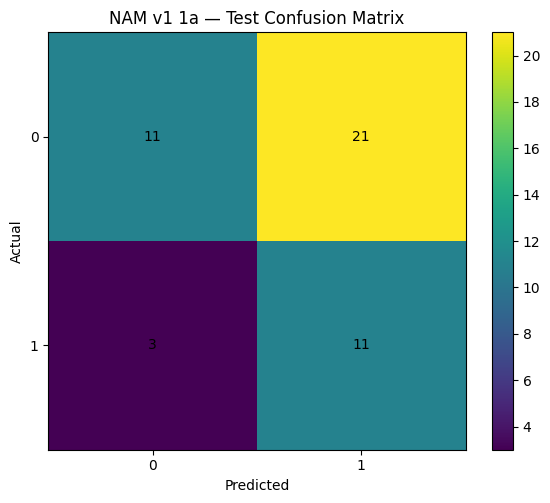

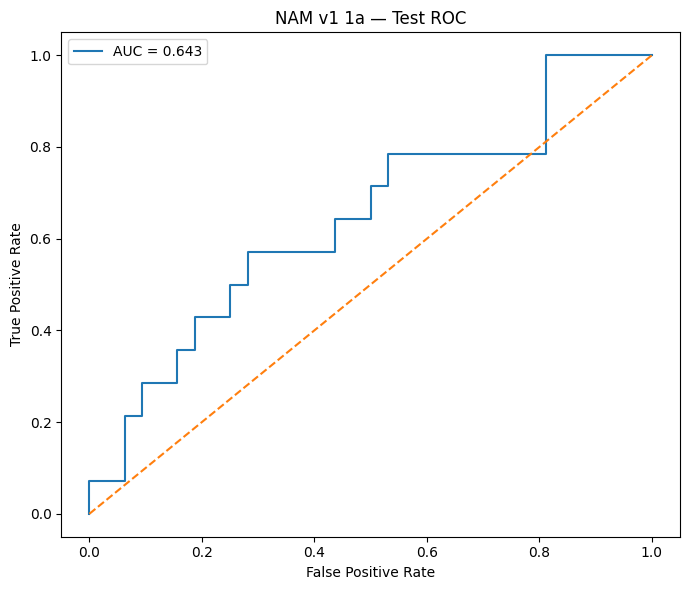

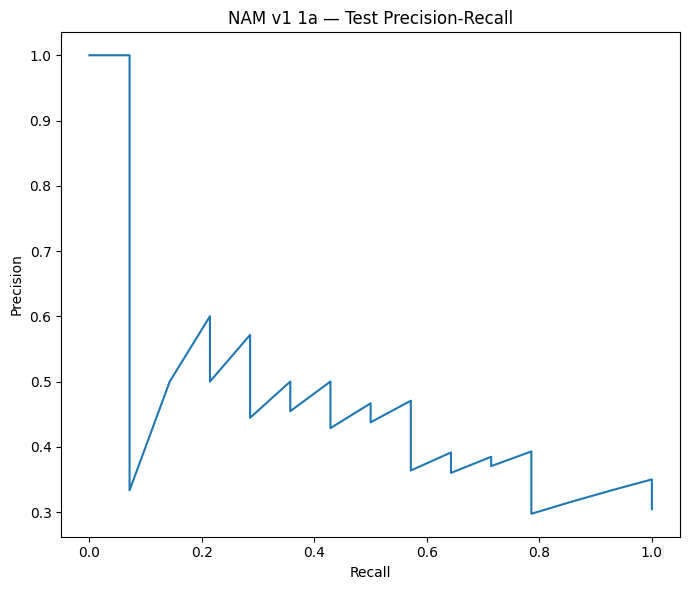

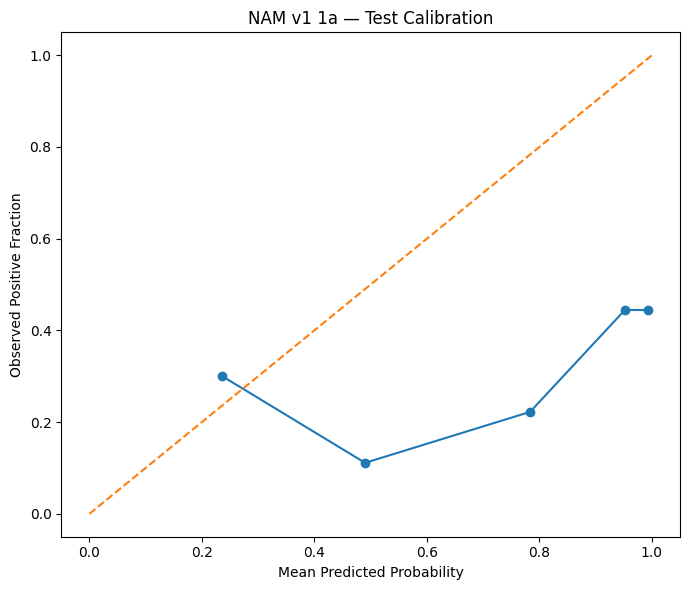


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
13,speech__spectral_tilt,speech,1.326183,0.088960,1.865029
2,speech__phonation_ratio,speech,0.774535,0.206318,0.713929
17,speech__std_f1_loc,speech,0.645271,-0.045409,-0.644551
6,speech__std_f0_hertz,speech,0.622566,0.074699,-0.713178
10,speech__mean_hnr_db,speech,0.614221,-0.100807,-0.664413
21,speech__std_f2_loc,speech,0.604078,-0.148456,-0.143905
24,speech__spectral_gravity,speech,0.594831,-0.109314,0.547951
18,speech__mean_b1_loc,speech,0.512512,0.039630,0.605682
27,speech__spectral_kurtosis,speech,0.495987,0.155008,0.223588
7,speech__mean_intensity_db,speech,0.483272,0.168238,-0.625216



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_1A_-_Speech_Only_-_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


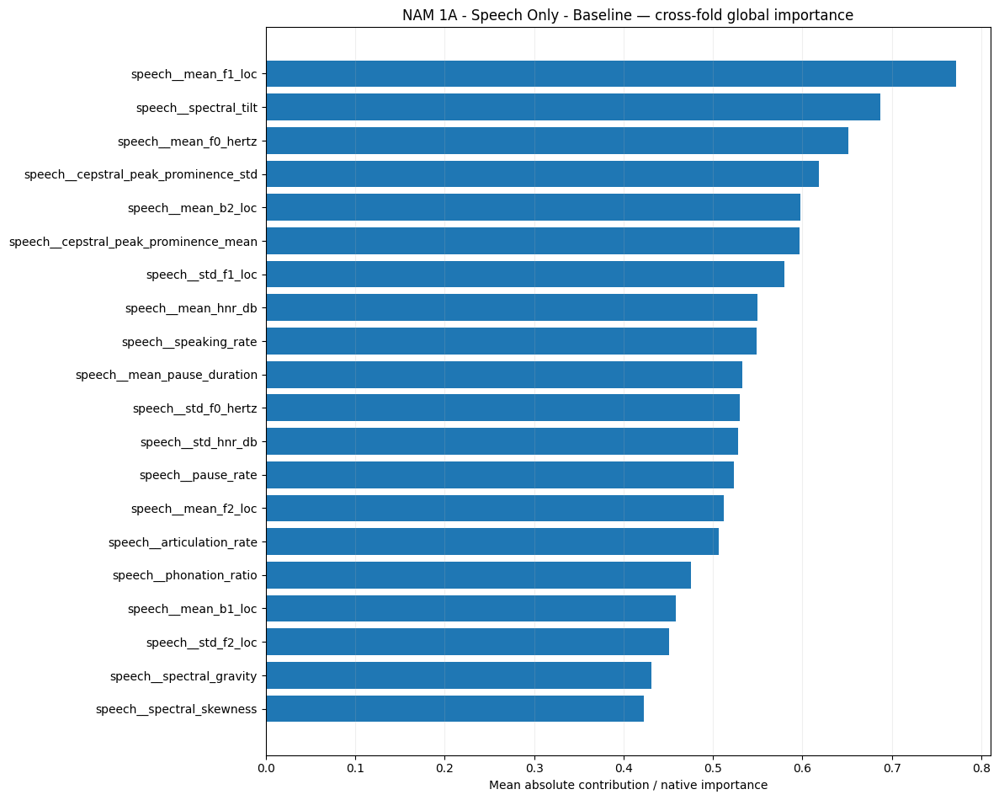


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
16,speech__spectral_kurtosis,5,0.691729,0.168092,0.308684,0.660211,-1.317572,2.944199
24,speech__std_f1_loc,5,0.425306,0.290491,0.579415,0.925223,-1.898396,2.051157
20,speech__spectral_tilt,5,0.291367,0.649602,0.539030,0.785114,-2.104152,2.179019
25,speech__std_f2_loc,5,0.244402,0.562062,0.488703,0.772569,-1.703705,2.586484
0,speech__articulation_rate,5,0.120172,0.670436,0.705404,0.893761,-2.875069,1.011910
13,speech__range_ratio_intensity_db,5,0.117595,0.393880,0.586983,1.045500,-1.038354,0.812457
27,speech__std_intensity_db,5,0.062459,0.437971,0.857115,1.072211,-0.776035,3.066217
5,speech__mean_f0_hertz,5,0.015786,0.585660,0.746338,1.020368,-1.343720,1.842802
21,speech__std_b1_loc,5,-0.019782,0.462183,0.509669,0.791235,-1.540199,2.315497
3,speech__mean_b1_loc,5,-0.021775,0.429744,0.685594,0.857679,-1.699834,2.741646


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_1A_-_Speech_Only_-_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 1a (corresponds to DNAMite 1a)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_1a_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1a",
    dnamite_experiment_id="1a",
    experiment_name='NAM 1A - Speech Only - Baseline',
    task="classification",
    cv_results=experiment_1a_classification_cv,
    final_result=experiment_1a_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1a",
    )
] = NAM_v1_1a_report


In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 1a complete. "
    "Waiting for file writes..."
)

time.sleep(20)

print(
    "Disconnecting runtime."
)

runtime.unassign()

### Experiment 1b Speech Classification with Feature Selection

In [ ]:
experiment_1b_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1B - "
            "Speech Only - Feature Selection"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)


NAM 1B - Speech Only - Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Joint selection: 18 features, C=1.0
[RAM] before inner fit: 1361.0 MB


[codecarbon WARNING @ 19:55:29] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=0.790283; hit ceiling=True
RAM memory:
  start: 1360.953125 MB
  absolute peak: 2114.71484375 MB
  incremental peak: 753.76171875 MB
GPU memory:
  start: 0.0 MB
  end: 0.084228515625 MB
  absolute peak: 0.1064453125 MB
  incremental peak: 0.1064453125 MB
[RAM] after inner cleanup: 2121.1 MB
Joint selection: 14 features, C=1.0
[RAM] before inner fit: 2121.1 MB
GPU memory at training start: 0.066650390625 MB
Epochs ran=21; best epoch=1; best val_loss=0.849788; hit ceiling=False
RAM memory:
  start: 2121.12109375 MB
  absolute peak: 2220.6953125 MB
  incremental peak: 99.57421875 MB
GPU memory:
  start: 0.066650390625 MB
  end: 0.09716796875 MB
  absolute peak: 0.114501953125 MB
  incremental peak: 0.0478515625 MB
[RAM] after inner cleanup: 2220.1 MB
Joint selection: 13 features, C=1.0
[RAM] before inner fit: 2220.1 MB
GPU memory at training start: 0.08349609375 MB
Epochs ran=172; best epoch=152; best val_loss=1.083557; hit ceiling=False
RAM m

In [ ]:
experiment_1b_classification_summary = (
    summarize_nested_cv(
        experiment_1b_classification_cv
    )
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.666667           0.473684  0.000000   0.000000   
1           2  0.703704           0.572368  0.333333   0.500000   
2           3  0.444444           0.605263  0.516129   0.347826   
3           4  0.481481           0.486842  0.363636   0.285714   
4           5  0.555556           0.684211  0.571429   0.400000   

   recall_sensitivity  specificity   roc_auc    pr_auc selected_text_count  \
0                0.00     0.947368  0.473684  0.321463                None   
1                0.25     0.894737  0.546053  0.466666                None   
2                1.00     0.210526  0.598684  0.371914                None   
3                0.50     0.473684  0.447368  0.296661                None   
4                1.00     0.368421  0.690789  0.437674                None   

   joint_selected_count  
0                    13  
1                    16  
2                    16  
3                    17 

In [ ]:
experiment_1b_classification_params = (
    choose_final_parameters(
        experiment_1b_classification_cv
    )
)


experiment_1b_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_1b_classification_params
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)

Joint selection: 13 features, C=1.0
GPU memory at training start: 3.661376953125 MB
Epochs ran=44; best epoch=24; best val_loss=1.040617; hit ceiling=False
RAM memory:
  start: 12091.66796875 MB
  absolute peak: 12091.69140625 MB
  incremental peak: 0.0234375 MB
GPU memory:
  start: 3.661376953125 MB
  end: 3.695556640625 MB
  absolute peak: 3.71240234375 MB
  incremental peak: 0.051025390625 MB
Best training epochs: 24
Joint selection: 18 features, C=1.0
RAM memory:
  start: 11951.671875 MB
  absolute peak: 12224.6171875 MB
  incremental peak: 272.9453125 MB

FINAL TEST METRICS
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.4441964285714286), 'f1': 0.29411764705882354, 'precision': 0.25, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.53125, 'roc_auc': np.float64(0.4977678571428572), 'pr_auc': np.float64(0.3682995358957065)}


#### NAM v1 Experiment 1b — DNAMite-parity outputs (maps to DNAMite 1b)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 1b — NAM 1B - Speech Only - Feature Selection
DNAMite reference experiment: 1b

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.666667,0.473684,0.000000,0.000000,0.00,0.947368,0.473684,0.321463,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,13,200,200,True
1,2,0.703704,0.572368,0.333333,0.500000,0.25,0.894737,0.546053,0.466666,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,16,200,200,True
2,3,0.444444,0.605263,0.516129,0.347826,1.00,0.210526,0.598684,0.371914,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,16,200,200,True
3,4,0.481481,0.486842,0.363636,0.285714,0.50,0.473684,0.447368,0.296661,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,17,200,200,True
4,5,0.555556,0.684211,0.571429,0.400000,1.00,0.368421,0.690789,0.437674,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,19,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.570370,0.112948
balanced_accuracy,0.564474,0.087081
f1,0.356905,0.223246
precision,0.306708,0.188591
recall_sensitivity,0.550000,0.447214
specificity,0.578947,0.326570
roc_auc,0.551316,0.098179
pr_auc,0.378876,0.072918
joint_selected_count,16.200000,2.167948
best_epoch,200.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,1,46.261762,3761.652344,3882.519531,120.867188,0.089111,NaN,0.605713,0.678223,0.694824,tensorflow,1249,0.116028
1,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,2,54.217222,5720.769531,5922.785156,202.015625,0.104004,NaN,1.310791,1.388428,1.414795,tensorflow,3073,0.147041
2,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,3,52.456689,7894.074219,8043.261719,149.187500,0.109863,NaN,2.054932,2.132568,2.164795,tensorflow,3073,0.147041
3,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,4,54.056027,9705.429688,9908.851562,203.421875,0.098389,NaN,2.807129,2.886475,2.905518,tensorflow,1633,0.148811
4,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,5,60.159072,11759.085938,12047.445312,288.359375,0.114746,NaN,3.597168,3.679932,3.711914,tensorflow,3649,0.172195



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,1,0.001516,0.000714
1,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,2,0.001769,0.000007
2,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,3,0.001720,0.000810
3,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,4,0.001773,0.000835
4,NAM v1,NAM 1B - Speech Only - Feature Selection,classification,5,0.001974,0.000929



Final Test Metrics
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.4441964285714286), 'f1': 0.29411764705882354, 'precision': 0.25, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.53125, 'roc_auc': np.float64(0.4977678571428572), 'pr_auc': np.float64(0.3682995358957065)}

Final Model Resource Summary
{'train_seconds': 29.57468579899978, 'start_ram_mb': 11951.671875, 'peak_ram_mb': 12224.6171875, 'incremental_peak_ram_mb': 272.9453125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0009647942703411813, 'training_co2_kg': 0.0004542087409740324}


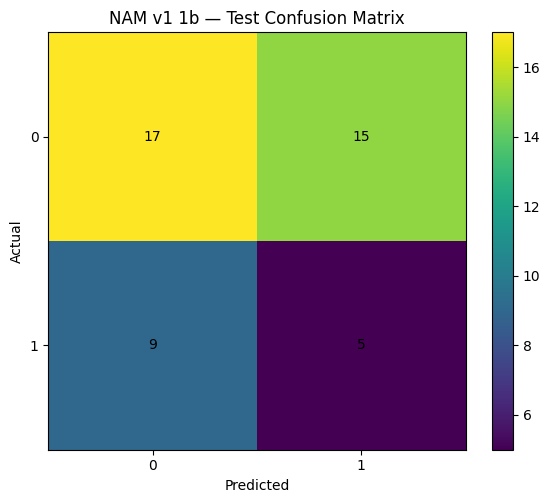

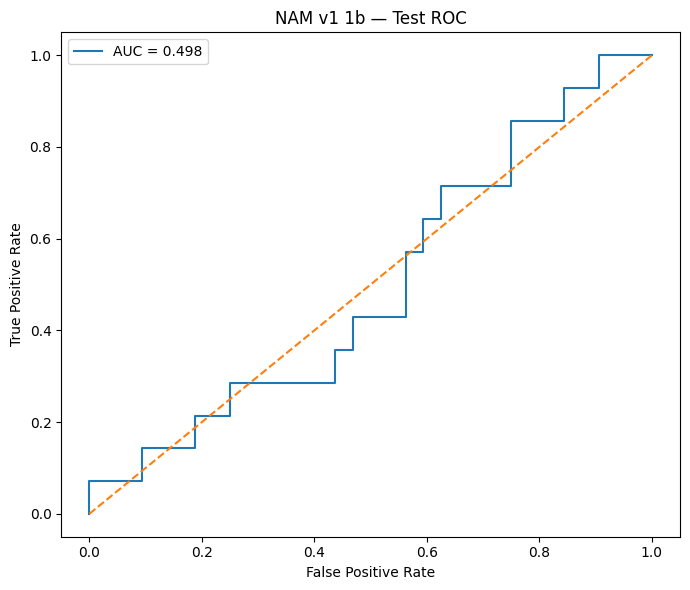

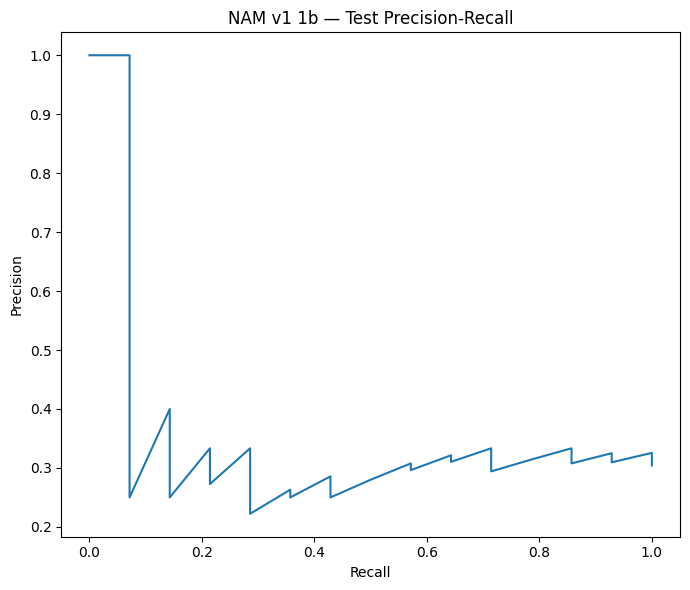

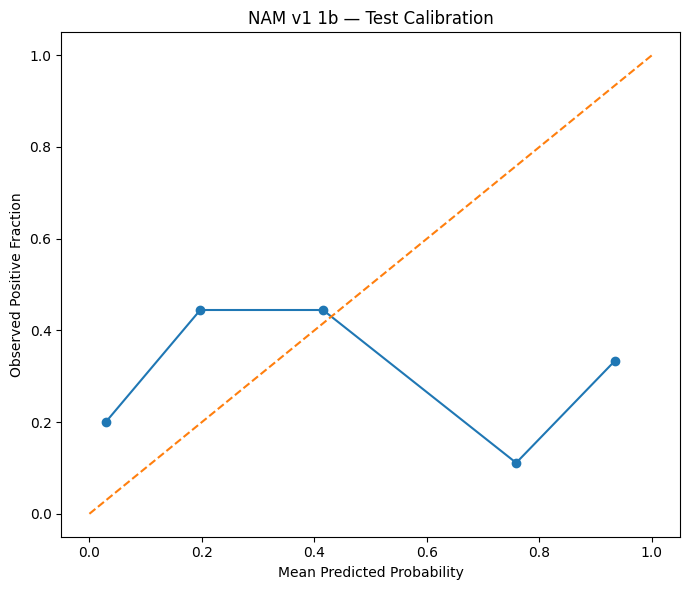


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
2,speech__std_f0_hertz,speech,1.242064,0.078727,-1.391416
17,speech__spectral_kurtosis,speech,1.135996,0.276466,1.364529
4,speech__range_ratio_intensity_db,speech,0.778798,0.119602,-1.203388
12,speech__std_b1_loc,speech,0.669689,-0.101866,1.034020
9,speech__cepstral_peak_prominence_std,speech,0.649809,0.070141,-0.666229
14,speech__std_f2_loc,speech,0.569270,-0.016944,0.302209
6,speech__std_hnr_db,speech,0.556950,0.093895,-0.168340
16,speech__spectral_std_dev,speech,0.453340,-0.120016,0.252112
0,speech__phonation_ratio,speech,0.450465,0.085897,0.481666
13,speech__mean_f2_loc,speech,0.409070,-0.067927,-0.027294



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_1B_-_Speech_Only_-_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


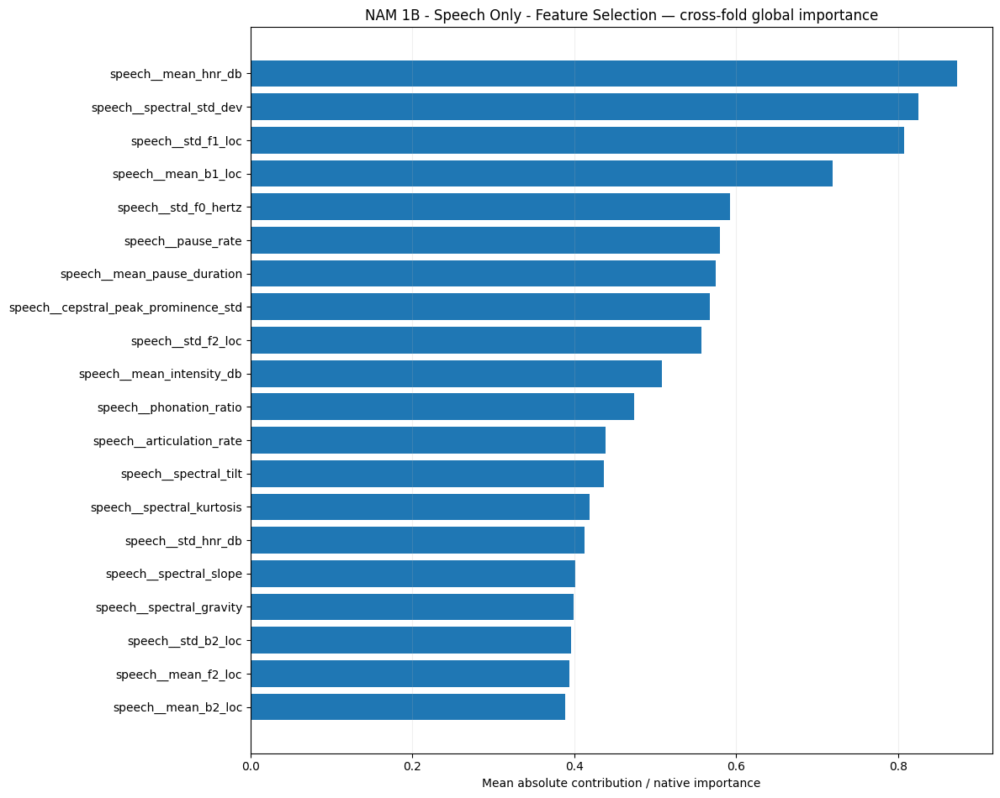


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
13,speech__spectral_std_dev,3,0.880890,0.028138,0.416379,1.061485,-1.666552,2.430222
7,speech__mean_intensity_db,4,0.734535,0.106228,0.367811,0.715103,-1.887187,2.363089
8,speech__pause_rate,4,0.681187,0.153091,0.469405,0.791171,-2.115891,1.710399
6,speech__mean_hnr_db,2,0.605396,NaN,0.838362,1.439529,-3.427094,2.229199
12,speech__spectral_slope,2,0.332835,NaN,0.489084,1.282336,-2.386725,1.817583
11,speech__spectral_kurtosis,3,0.132162,0.534174,0.681399,0.993365,-1.317572,2.944199
18,speech__std_hnr_db,4,0.123668,0.364827,0.565994,0.725801,-1.332545,3.071081
15,speech__std_f0_hertz,4,0.066659,0.668492,0.547771,0.977846,-1.448859,2.319804
10,speech__range_ratio_intensity_db,4,0.039570,0.586961,0.447344,0.758417,-1.038354,0.812457
17,speech__std_f2_loc,4,0.003385,0.858024,0.688382,0.904214,-1.703705,2.586484


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_1B_-_Speech_Only_-_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 1b (corresponds to DNAMite 1b)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_1b_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1b",
    dnamite_experiment_id="1b",
    experiment_name='NAM 1B - Speech Only - Feature Selection',
    task="classification",
    cv_results=experiment_1b_classification_cv,
    final_result=experiment_1b_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1b",
    )
] = NAM_v1_1b_report


### Experiment 1c Speech Classification + Weighted BCE

In [ ]:
experiment_1c_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1C - "
            "Speech Only - Weighted BCE"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)


NAM 1C - Speech Only - Weighted BCE
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
[RAM] before inner fit: 1362.2 MB


[codecarbon WARNING @ 21:01:07] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Class weights: {0: 0.72, 1: 1.6363636363636365}


Epochs ran=200; best epoch=200; best val_loss=1.124804; hit ceiling=True
RAM memory:
  start: 1362.21484375 MB
  absolute peak: 2273.5703125 MB
  incremental peak: 911.35546875 MB
GPU memory:
  start: 0.0 MB
  end: 0.101318359375 MB
  absolute peak: 0.134765625 MB
  incremental peak: 0.134765625 MB
[RAM] after inner cleanup: 2267.8 MB
[RAM] before inner fit: 2267.8 MB
GPU memory at training start: 0.073974609375 MB
Class weights: {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=200; best epoch=200; best val_loss=1.811982; hit ceiling=True
RAM memory:
  start: 2267.7578125 MB
  absolute peak: 2684.24609375 MB
  incremental peak: 416.48828125 MB
GPU memory:
  start: 0.073974609375 MB
  end: 0.172119140625 MB
  absolute peak: 0.203857421875 MB
  incremental peak: 0.1298828125 MB
[RAM] after inner cleanup: 2434.7 MB
[RAM] before inner fit: 2434.7 MB
GPU memory at training start: 0.144775390625 MB
Class weights: {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=200; best ep

In [ ]:
experiment_1c_classification_summary = (
    summarize_nested_cv(
        experiment_1c_classification_cv
    )
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.407407           0.325658  0.111111   0.100000   
1           2  0.629630           0.519737  0.285714   0.333333   
2           3  0.296296           0.500000  0.457143   0.296296   
3           4  0.296296           0.427632  0.387097   0.260870   
4           5  0.407407           0.578947  0.500000   0.333333   

   recall_sensitivity  specificity   roc_auc    pr_auc selected_text_count  \
0               0.125     0.526316  0.217105  0.215447                None   
1               0.250     0.789474  0.513158  0.364871                None   
2               1.000     0.000000  0.654605  0.476018                None   
3               0.750     0.105263  0.552632  0.513159                None   
4               1.000     0.157895  0.486842  0.307497                None   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None  
4  

In [ ]:
experiment_1c_classification_params = (
    choose_final_parameters(
        experiment_1c_classification_cv
    )
)


experiment_1c_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_1c_classification_params
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)

GPU memory at training start: 4.289306640625 MB
Class weights: {0: 0.7105263157894737, 1: 1.6875}
Epochs ran=200; best epoch=200; best val_loss=2.109621; hit ceiling=True
RAM memory:
  start: 19591.58203125 MB
  absolute peak: 19874.75390625 MB
  incremental peak: 283.171875 MB
GPU memory:
  start: 4.289306640625 MB
  end: 4.387451171875 MB
  absolute peak: 4.42822265625 MB
  incremental peak: 0.138916015625 MB
Best training epochs: 200
RAM memory:
  start: 19774.953125 MB
  absolute peak: 20196.93359375 MB
  incremental peak: 421.98046875 MB

FINAL TEST METRICS
{'accuracy': 0.5652173913043478, 'balanced_accuracy': np.float64(0.5669642857142857), 'f1': 0.4444444444444444, 'precision': 0.36363636363636365, 'recall_sensitivity': 0.5714285714285714, 'specificity': 0.5625, 'roc_auc': np.float64(0.46428571428571425), 'pr_auc': np.float64(0.29020924025557704)}


#### NAM v1 Experiment 1c — DNAMite-parity outputs (maps to DNAMite 1e)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 1c — NAM 1C - Speech Only - Weighted BCE
DNAMite reference experiment: 1e

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.407407,0.325658,0.111111,0.100000,0.125,0.526316,0.217105,0.215447,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
1,2,0.629630,0.519737,0.285714,0.333333,0.250,0.789474,0.513158,0.364871,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,1,21,False
2,3,0.296296,0.500000,0.457143,0.296296,1.000,0.000000,0.654605,0.476018,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
3,4,0.296296,0.427632,0.387097,0.260870,0.750,0.105263,0.552632,0.513159,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
4,5,0.407407,0.578947,0.500000,0.333333,1.000,0.157895,0.486842,0.307497,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.407407,0.136083
balanced_accuracy,0.470395,0.097304
f1,0.348213,0.155355
precision,0.264767,0.096902
recall_sensitivity,0.625000,0.414578
specificity,0.315789,0.330784
roc_auc,0.484868,0.162714
pr_auc,0.375398,0.121869
best_epoch,160.200000,88.995506
epochs_ran,164.200000,80.051234



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,1,75.928201,5379.441406,5723.675781,344.234375,0.141357,NaN,0.809082,0.907227,0.950439,tensorflow,5377,0.247696
1,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,2,55.425773,8907.347656,9364.406250,457.058594,0.097656,NaN,1.642334,1.696777,1.739990,tensorflow,5377,0.247696
2,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,3,75.558066,12453.949219,12755.781250,301.832031,0.130371,NaN,2.475586,2.573730,2.605957,tensorflow,2689,0.237930
3,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,4,74.560372,15913.808594,16217.570312,303.761719,0.130371,NaN,3.395752,3.493896,3.526123,tensorflow,2689,0.237930
4,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,5,79.982385,19382.113281,19726.414062,344.300781,0.140869,NaN,4.218506,4.316650,4.359375,tensorflow,5377,0.247696



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,1,0.002491,0.001173
1,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,2,0.001815,0.000854
2,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,3,0.002480,0.001168
3,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,4,0.002447,0.001152
4,NAM v1,NAM 1C - Speech Only - Weighted BCE,classification,5,0.002626,0.001236



Final Test Metrics
{'accuracy': 0.5652173913043478, 'balanced_accuracy': np.float64(0.5669642857142857), 'f1': 0.4444444444444444, 'precision': 0.36363636363636365, 'recall_sensitivity': 0.5714285714285714, 'specificity': 0.5625, 'roc_auc': np.float64(0.46428571428571425), 'pr_auc': np.float64(0.29020924025557704)}

Final Model Resource Summary
{'train_seconds': 60.62680977100172, 'start_ram_mb': 19774.953125, 'peak_ram_mb': 20196.93359375, 'incremental_peak_ram_mb': 421.98046875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0019893178886883373, 'training_co2_kg': 0.0009365370435903616}


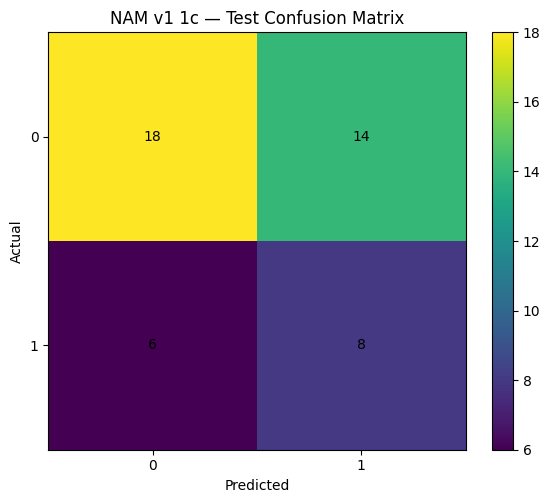

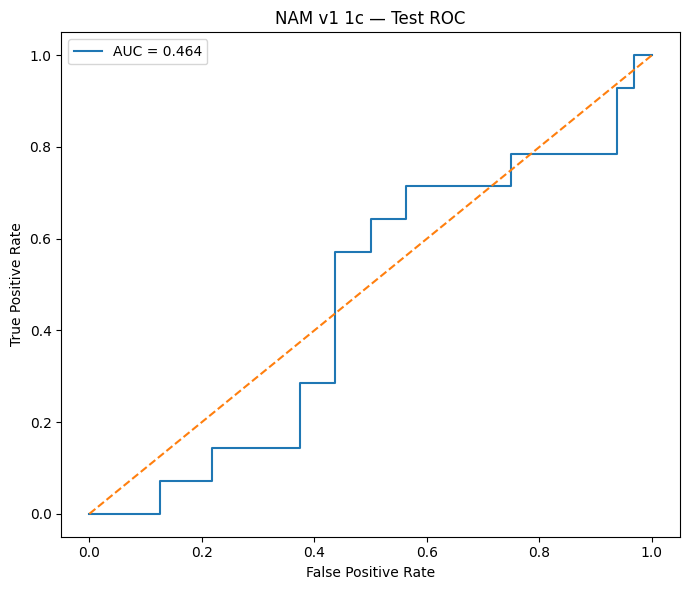

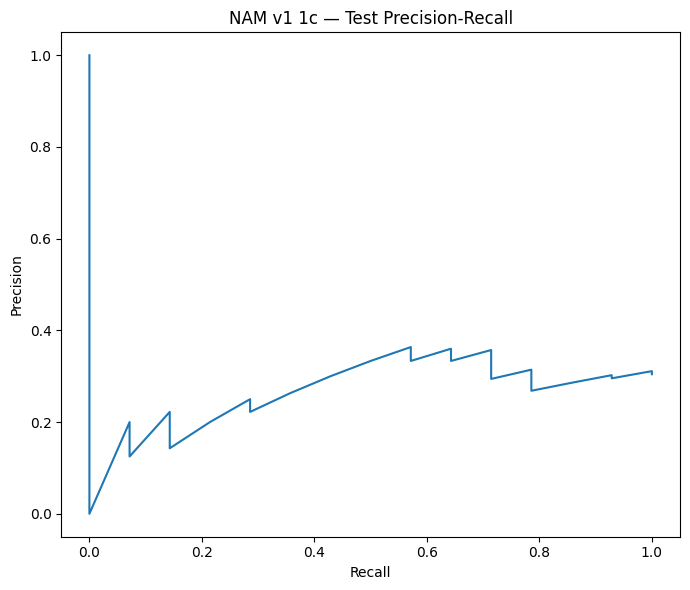

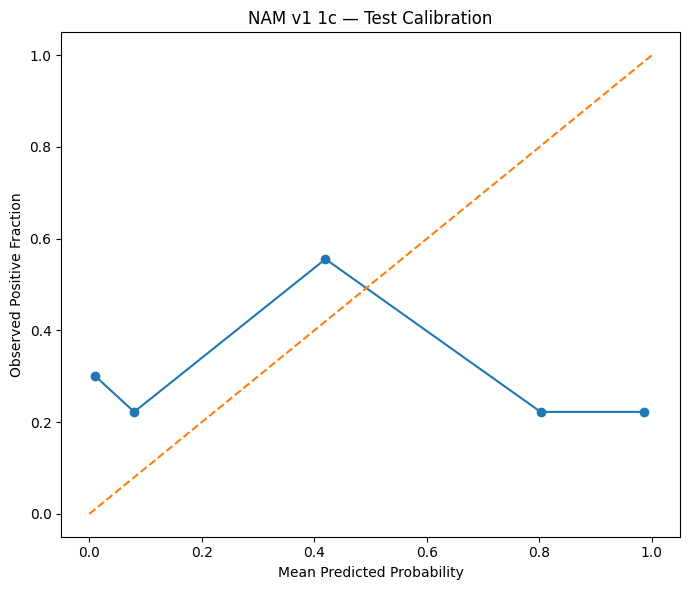


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
3,speech__pause_rate,speech,1.376951,0.001067,-2.225361
25,speech__spectral_std_dev,speech,1.149750,0.427779,-1.182191
18,speech__mean_b1_loc,speech,1.048664,0.001784,1.056504
15,speech__cepstral_peak_prominence_std,speech,0.890976,0.157280,-0.946655
8,speech__std_intensity_db,speech,0.879022,-0.067545,-0.986210
1,speech__articulation_rate,speech,0.761811,-0.124508,1.510459
17,speech__std_f1_loc,speech,0.741861,-0.135758,0.294041
6,speech__std_f0_hertz,speech,0.669112,-0.001805,0.934175
21,speech__std_f2_loc,speech,0.522127,-0.034394,0.531347
2,speech__phonation_ratio,speech,0.499466,0.097636,0.410087



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_1C_-_Speech_Only_-_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


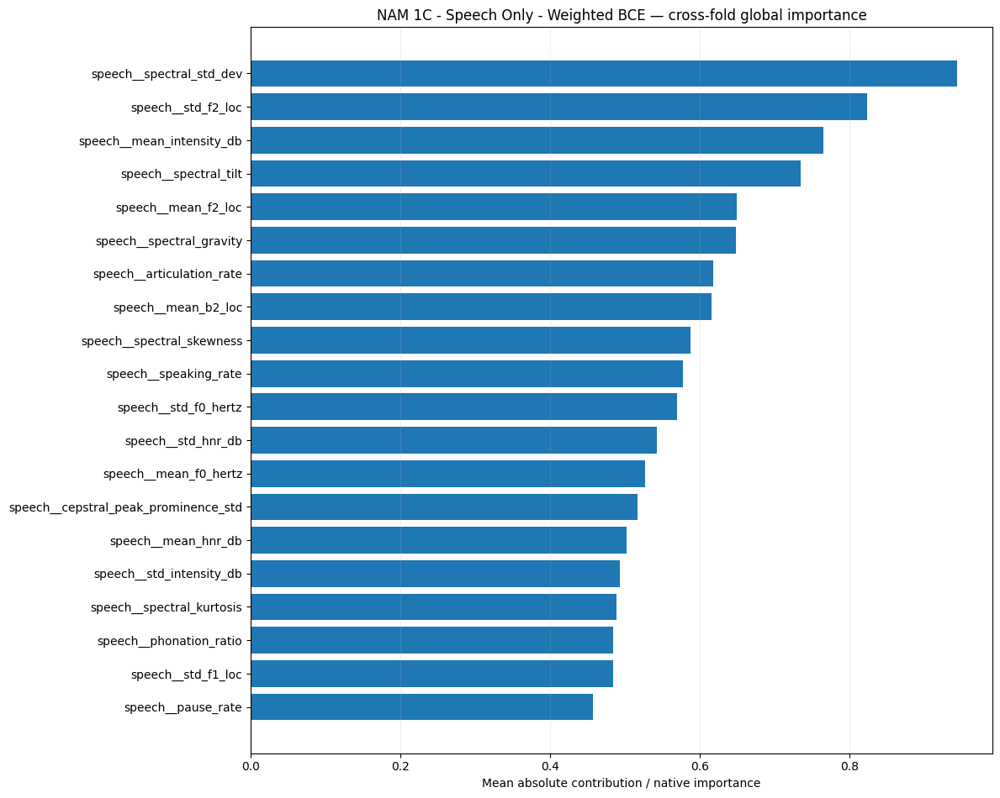


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
7,speech__mean_f2_loc,5,0.725862,0.106289,0.606715,0.795438,-2.080074,2.188417
16,speech__spectral_kurtosis,5,0.385700,0.427883,0.512022,0.649232,-1.317572,2.944199
27,speech__std_intensity_db,5,0.381564,0.322460,0.688401,1.049005,-0.776035,3.066217
24,speech__std_f1_loc,5,0.169963,0.590143,0.586336,0.805312,-1.898396,2.051157
3,speech__mean_b1_loc,5,0.107911,0.574873,0.493867,0.647641,-1.699834,2.741646
25,speech__std_f2_loc,5,0.078066,0.754817,0.943582,1.118296,-1.703705,2.586484
20,speech__spectral_tilt,5,0.076973,0.740417,0.880711,1.142038,-2.104152,2.179019
17,speech__spectral_skewness,5,0.057089,0.674821,0.701001,0.882347,-1.809054,2.054626
26,speech__std_hnr_db,5,0.038656,0.552180,0.523654,0.838773,-1.316103,3.071081
5,speech__mean_f0_hertz,5,0.023563,0.518639,0.538549,0.747928,-1.343720,1.842802


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_1C_-_Speech_Only_-_Weighted_BCE.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 1c (corresponds to DNAMite 1e)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_1c_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1c",
    dnamite_experiment_id="1e",
    experiment_name='NAM 1C - Speech Only - Weighted BCE',
    task="classification",
    cv_results=experiment_1c_classification_cv,
    final_result=experiment_1c_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1c",
    )
] = NAM_v1_1c_report


### Experiment 1d Speech Regression Baseline

In [ ]:
experiment_1d_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1D - "
            "Speech Only - Regression Baseline"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)


NAM 1D - Speech Only - Regression Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
[RAM] before inner fit: 1366.3 MB


[codecarbon WARNING @ 19:22:48] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=53.076233; hit ceiling=True
RAM memory:
  start: 1366.28125 MB
  absolute peak: 2200.16015625 MB
  incremental peak: 833.87890625 MB
GPU memory:
  start: 0.0 MB
  end: 0.101318359375 MB
  absolute peak: 0.134765625 MB
  incremental peak: 0.134765625 MB
[RAM] after inner cleanup: 2206.2 MB
[RAM] before inner fit: 2206.2 MB
GPU memory at training start: 0.073974609375 MB
Epochs ran=200; best epoch=200; best val_loss=54.854977; hit ceiling=True
RAM memory:
  start: 2206.203125 MB
  absolute peak: 2581.65234375 MB
  incremental peak: 375.44921875 MB
GPU memory:
  start: 0.073974609375 MB
  end: 0.172119140625 MB
  absolute peak: 0.203369140625 MB
  incremental peak: 0.12939453125 MB
[RAM] after inner cleanup: 2581.4 MB
[RAM] before inner fit: 2581.4 MB
GPU memory at training start: 0.144775390625 MB
Epochs ran=200; best epoch=200; best val_loss=77.815643; hit ceiling=True
RAM memory:
  start: 2581.44140625 MB
  absolute peak: 2980.73046875 MB
 

/tmp/ipykernel_3877/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 4.945914754161128, 'rmse': np.float64(6.350417091868342), 'r2': -0.28189431361583694, 'spearman_rho': np.float64(0.3464164339082163), 'spearman_p': np.float64(0.07670500947029664), 'exact_accuracy': np.float64(0.07407407407407407), 'within_1': np.float64(0.1111111111111111), 'within_2': np.float64(0.25925925925925924), 'within_3': np.float64(0.4074074074074074)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1D_-_Speech_Only_-_Regression_Baseline/fold_03/model.weights.h5

Outer Fold 4/5
[RAM] before inner fit: 12714.0 MB
GPU memory at training start: 2.72119140625 MB
Epochs ran=200; best epoch=200; best val_loss=38.366341; hit ceiling=True
RAM memory:
  start: 12714.0 MB
  absolute peak: 12978.5 MB
  incremental peak: 264.5 MB
GPU memory:
  start: 2.72119140625 MB
  end: 2.8193359375 MB
  absolute peak: 2.853271484375 MB
  incremental peak: 0.132080078125 MB
[RAM] after inner cleanup: 12781.1 MB
[RAM] before

/tmp/ipykernel_3877/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 9.81151294708252, 'rmse': np.float64(11.748507872747584), 'r2': -4.303151773218759, 'spearman_rho': np.float64(-0.08210839804558306), 'spearman_p': np.float64(0.6838992707068065), 'exact_accuracy': np.float64(0.1111111111111111), 'within_1': np.float64(0.1111111111111111), 'within_2': np.float64(0.1111111111111111), 'within_3': np.float64(0.18518518518518517)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1D_-_Speech_Only_-_Regression_Baseline/fold_04/model.weights.h5

Outer Fold 5/5
[RAM] before inner fit: 16055.5 MB
GPU memory at training start: 3.641357421875 MB
Epochs ran=200; best epoch=200; best val_loss=261.498047; hit ceiling=True
RAM memory:
  start: 16055.5 MB
  absolute peak: 16381.05078125 MB
  incremental peak: 325.55078125 MB
GPU memory:
  start: 3.641357421875 MB
  end: 3.739501953125 MB
  absolute peak: 3.7734375 MB
  incremental peak: 0.132080078125 MB
[RAM] after inner cleanup: 16380.5 MB


/tmp/ipykernel_3877/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 7.487071467770471, 'rmse': np.float64(9.14157709286446), 'r2': -1.6411769158912568, 'spearman_rho': np.float64(0.2577403231923654), 'spearman_p': np.float64(0.19430604410804425), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.14814814814814814), 'within_2': np.float64(0.18518518518518517), 'within_3': np.float64(0.3333333333333333)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1D_-_Speech_Only_-_Regression_Baseline/fold_05/model.weights.h5


In [ ]:
experiment_1d_results_df = pd.DataFrame(
    [
        {
            "outer_fold": result["outer_fold"],

            **result["metrics"],

            **{
                f"parameter_{key}": value
                for key, value
                in result["parameters"].items()
            },
        }

        for result
        in experiment_1d_regression_cv
    ]
)

display(
    experiment_1d_results_df
)

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,parameter_activation,parameter_dropout,parameter_feature_dropout,parameter_learning_rate,parameter_num_units,parameter_shallow
0,1,5.190405,7.017559,-0.776018,-0.265157,0.181329,0.111111,0.148148,0.296296,0.370370,exu,0.1,0.0,0.0010,32,True
1,2,6.793890,8.867761,-1.015133,0.165033,0.410724,0.222222,0.148148,0.259259,0.370370,exu,0.1,0.0,0.0010,64,True
2,3,4.945915,6.350417,-0.281894,0.346416,0.076705,0.074074,0.111111,0.259259,0.407407,exu,0.1,0.0,0.0010,64,True
3,4,9.811513,11.748508,-4.303152,-0.082108,0.683899,0.111111,0.111111,0.111111,0.185185,exu,0.1,0.0,0.0005,64,True
4,5,7.487071,9.141577,-1.641177,0.257740,0.194306,0.148148,0.148148,0.185185,0.333333,exu,0.1,0.0,0.0005,32,True


In [ ]:
experiment_1d_summary = (
    summarize_nested_cv(
        experiment_1d_regression_cv
    )
)

display(
    experiment_1d_summary
)

   outer_fold       mae       rmse        r2  spearman_rho  spearman_p  \
0           1  5.190405   7.017559 -0.776018     -0.265157    0.181329   
1           2  6.793890   8.867761 -1.015133      0.165033    0.410724   
2           3  4.945915   6.350417 -0.281894      0.346416    0.076705   
3           4  9.811513  11.748508 -4.303152     -0.082108    0.683899   
4           5  7.487071   9.141577 -1.641177      0.257740    0.194306   

   exact_accuracy  within_1  within_2  within_3 selected_text_count  \
0        0.111111  0.148148  0.296296  0.370370                None   
1        0.222222  0.148148  0.259259  0.370370                None   
2        0.074074  0.111111  0.259259  0.407407                None   
3        0.111111  0.111111  0.111111  0.185185                None   
4        0.148148  0.148148  0.185185  0.333333                None   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None  
4  

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,5.190405,7.017559,-0.776018,-0.265157,0.181329,0.111111,0.148148,0.296296,0.370370,None,None
1,2,6.793890,8.867761,-1.015133,0.165033,0.410724,0.222222,0.148148,0.259259,0.370370,None,None
2,3,4.945915,6.350417,-0.281894,0.346416,0.076705,0.074074,0.111111,0.259259,0.407407,None,None
3,4,9.811513,11.748508,-4.303152,-0.082108,0.683899,0.111111,0.111111,0.111111,0.185185,None,None
4,5,7.487071,9.141577,-1.641177,0.257740,0.194306,0.148148,0.148148,0.185185,0.333333,None,None


In [ ]:
experiment_1d_best_parameters = (
    choose_final_parameters(
        experiment_1d_regression_cv
    )
)

print(
    "Best parameters:"
)

print(
    experiment_1d_best_parameters
)

Best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}


In [ ]:
import inspect

print(
    inspect.signature(
        train_final_nam_model
    )
)

(task, speech_development, y_development, speech_test, y_test, parameters, experiment_variant, text_development=None, text_test=None, text_representation=None)


In [ ]:
experiment_1d_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_1d_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)

GPU memory at training start: 4.4765625 MB
Epochs ran=200; best epoch=200; best val_loss=56.384369; hit ceiling=True
RAM memory:
  start: 19491.19140625 MB
  absolute peak: 19655.640625 MB
  incremental peak: 164.44921875 MB
GPU memory:
  start: 4.4765625 MB
  end: 4.57470703125 MB
  absolute peak: 4.614990234375 MB
  incremental peak: 0.138427734375 MB
Best training epochs: 200
RAM memory:
  start: 19555.06640625 MB
  absolute peak: 19966.83203125 MB
  incremental peak: 411.765625 MB

FINAL TEST METRICS
{'mae': 12.221026669377865, 'rmse': np.float64(13.990438631345885), 'r2': -3.762706287579668, 'spearman_rho': np.float64(0.1026250963065226), 'spearman_p': np.float64(0.4973423903403598), 'exact_accuracy': np.float64(0.10869565217391304), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.08695652173913043)}


#### NAM v1 Experiment 1d — DNAMite-parity outputs (maps to DNAMite 1c)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 1d — NAM 1D - Speech Only - Regression Baseline
DNAMite reference experiment: 1c

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,5.190405,7.017559,-0.776018,-0.265157,0.181329,0.111111,0.148148,0.296296,0.370370,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
1,2,6.793890,8.867761,-1.015133,0.165033,0.410724,0.222222,0.148148,0.259259,0.370370,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
2,3,4.945915,6.350417,-0.281894,0.346416,0.076705,0.074074,0.111111,0.259259,0.407407,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
3,4,9.811513,11.748508,-4.303152,-0.082108,0.683899,0.111111,0.111111,0.111111,0.185185,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
4,5,7.487071,9.141577,-1.641177,0.257740,0.194306,0.148148,0.148148,0.185185,0.333333,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True



CV Mean ± SD


,mean,sd
mae,6.845759,1.972262
rmse,8.625164,2.111852
r2,-1.603475,1.586433
spearman_rho,0.084385,0.252545
spearman_p,0.309393,0.242029
exact_accuracy,0.133333,0.056169
within_1,0.133333,0.020286
within_2,0.222222,0.074074
within_3,0.333333,0.086860
best_epoch,200.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,1,70.379630,5366.132812,5634.683594,268.550781,0.128418,NaN,0.853027,0.951172,0.981445,tensorflow,2689,0.237930
1,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,2,74.214332,8850.800781,9240.550781,389.750000,0.139404,NaN,1.773682,1.871826,1.913086,tensorflow,5377,0.247696
2,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,3,74.465821,12226.183594,12667.511719,441.328125,0.139404,NaN,2.650391,2.748535,2.789795,tensorflow,5377,0.247696
3,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,4,76.237533,15652.253906,16071.171875,418.917969,0.139404,NaN,3.570557,3.668701,3.709961,tensorflow,5377,0.247696
4,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,5,74.142593,19236.542969,19423.015625,186.472656,0.127441,NaN,4.405762,4.503906,4.533203,tensorflow,2689,0.237930



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,1,0.002202,0.000589
1,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,2,0.002322,0.000621
2,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,3,0.002332,0.000624
3,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,4,0.002385,0.000638
4,NAM v1,NAM 1D - Speech Only - Regression Baseline,regression,5,0.002318,0.000620



Final Test Metrics
{'mae': 12.221026669377865, 'rmse': np.float64(13.990438631345885), 'r2': -3.762706287579668, 'spearman_rho': np.float64(0.1026250963065226), 'spearman_p': np.float64(0.4973423903403598), 'exact_accuracy': np.float64(0.10869565217391304), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.08695652173913043)}

Final Model Resource Summary
{'train_seconds': 59.11557633400025, 'start_ram_mb': 19555.06640625, 'peak_ram_mb': 19966.83203125, 'incremental_peak_ram_mb': 411.765625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.001849477111397852, 'training_co2_kg': 0.0004949607635065161}


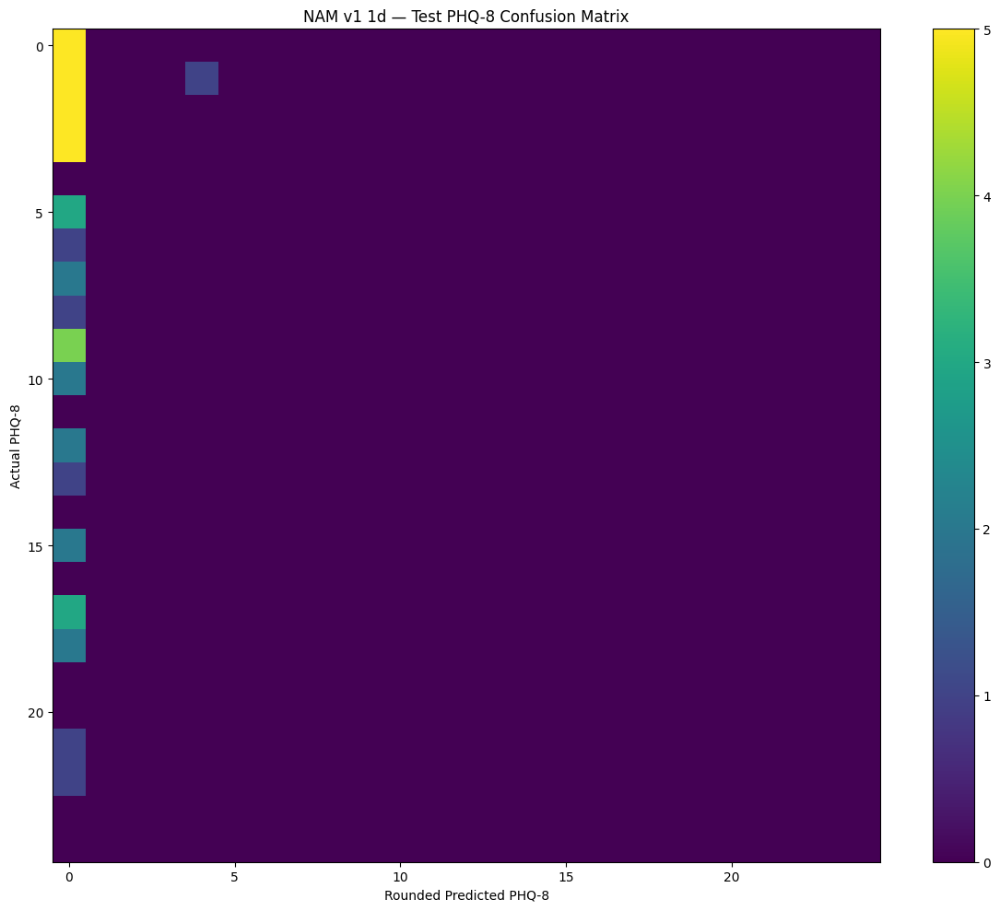

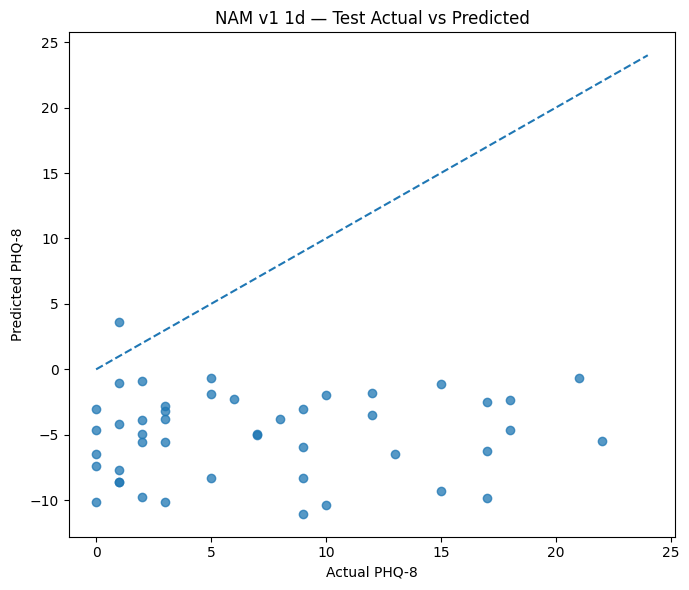


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
25,speech__spectral_std_dev,speech,1.240088,0.454590,-1.184091
14,speech__cepstral_peak_prominence_mean,speech,1.063399,-0.343201,0.972068
15,speech__cepstral_peak_prominence_std,speech,1.011898,0.181938,-1.434610
3,speech__pause_rate,speech,0.740895,0.030148,0.901276
17,speech__std_f1_loc,speech,0.731695,0.095857,-1.078359
1,speech__articulation_rate,speech,0.711692,0.186108,-0.988808
9,speech__range_ratio_intensity_db,speech,0.700626,0.117327,-0.995335
7,speech__mean_intensity_db,speech,0.655348,0.098937,-0.683113
22,speech__mean_b2_loc,speech,0.632405,-0.052820,-0.767121
21,speech__std_f2_loc,speech,0.554902,-0.070307,0.527850



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_1D_-_Speech_Only_-_Regression_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


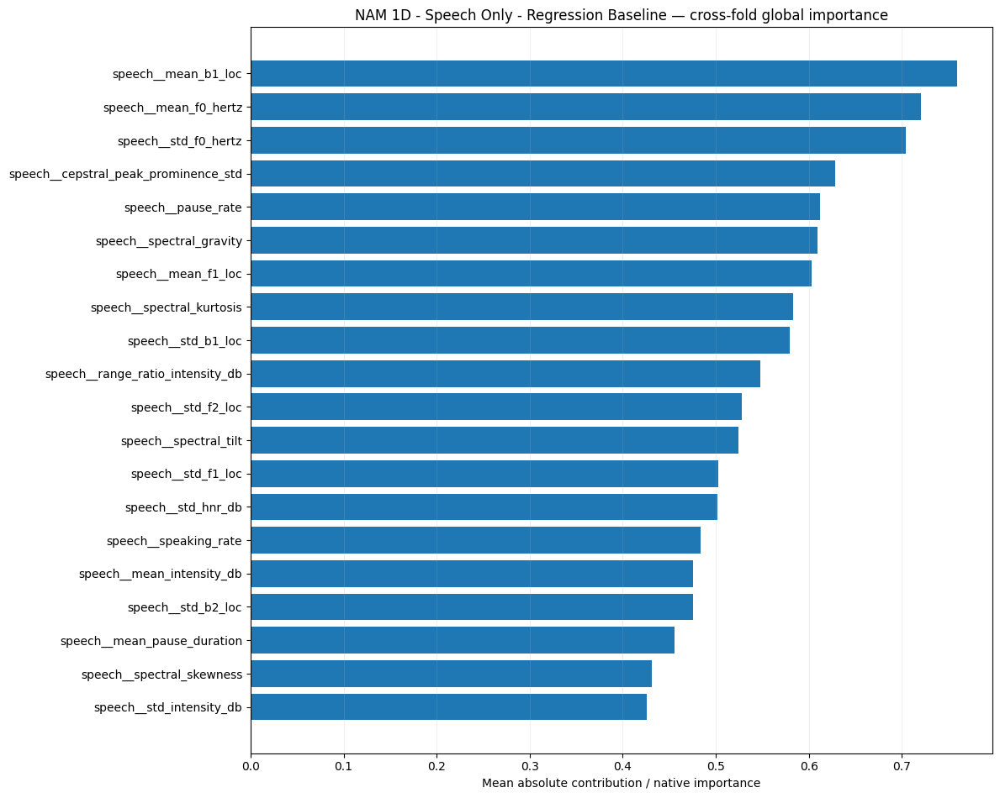


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
13,speech__range_ratio_intensity_db,5,0.449753,0.396582,0.420271,0.669520,-1.038661,0.829560
16,speech__spectral_kurtosis,5,0.250044,0.491596,0.686436,0.805260,-1.266120,2.566644
12,speech__phonation_ratio,5,0.158587,0.567817,0.496862,0.604391,-2.219312,1.596939
4,speech__mean_b2_loc,5,0.125318,0.490100,0.489000,0.994545,-1.484589,2.731267
23,speech__std_f0_hertz,5,0.124897,0.849405,0.807165,1.074708,-1.449444,2.229207
26,speech__std_hnr_db,5,0.070549,0.638846,0.798922,0.957990,-1.297804,2.635509
6,speech__mean_f1_loc,5,0.039723,0.512023,0.582111,1.052824,-1.593647,2.371842
27,speech__std_intensity_db,5,0.004512,0.489071,0.732834,1.223547,-0.770003,3.011079
8,speech__mean_hnr_db,5,-0.025530,0.537939,0.368609,0.581325,-2.095261,2.076465
21,speech__std_b1_loc,5,-0.054231,0.672675,0.764121,1.113656,-1.541928,2.284121


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_1D_-_Speech_Only_-_Regression_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 1d (corresponds to DNAMite 1c)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_1d_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1d",
    dnamite_experiment_id="1c",
    experiment_name='NAM 1D - Speech Only - Regression Baseline',
    task="regression",
    cv_results=experiment_1d_regression_cv,
    final_result=experiment_1d_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1d",
    )
] = NAM_v1_1d_report


### Experiment 1e Speech Regression with Feature Selection

In [ ]:
experiment_1e_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1E - "
            "Speech Only - Regression Feature Selection"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)


NAM 1E - Speech Only - Regression Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Joint selection: 28 features, alpha=0.01
[RAM] before inner fit: 1363.0 MB


[codecarbon WARNING @ 01:11:34] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=21; best epoch=1; best val_loss=58.784451; hit ceiling=False
RAM memory:
  start: 1362.96875 MB
  absolute peak: 2224.66796875 MB
  incremental peak: 861.69921875 MB
GPU memory:
  start: 0.0 MB
  end: 0.0576171875 MB
  absolute peak: 0.091064453125 MB
  incremental peak: 0.091064453125 MB
[RAM] after inner cleanup: 2228.8 MB
Joint selection: 26 features, alpha=0.01
[RAM] before inner fit: 2228.8 MB
GPU memory at training start: 0.0302734375 MB
Epochs ran=200; best epoch=200; best val_loss=109.215820; hit ceiling=True
RAM memory:
  start: 2228.83203125 MB
  absolute peak: 2625.85546875 MB
  incremental peak: 397.0234375 MB
GPU memory:
  start: 0.0302734375 MB
  end: 0.125 MB
  absolute peak: 0.154296875 MB
  incremental peak: 0.1240234375 MB
[RAM] after inner cleanup: 2429.1 MB
Joint selection: 26 features, alpha=0.01
[RAM] before inner fit: 2429.1 MB
GPU memory at training start: 0.099609375 MB
Epochs ran=200; best epoch=200; best val_loss=126.131783; hit ceiling=True
RAM me

/tmp/ipykernel_2937925/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 8.437820386003565, 'rmse': np.float64(10.636425360438187), 'r2': -2.596160892243736, 'spearman_rho': np.float64(0.022992241188598425), 'spearman_p': np.float64(0.9093703976356653), 'exact_accuracy': np.float64(0.18518518518518517), 'within_1': np.float64(0.14814814814814814), 'within_2': np.float64(0.18518518518518517), 'within_3': np.float64(0.18518518518518517)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1E_-_Speech_Only_-_Regression_Feature_Selection/fold_03/model.weights.h5

Outer Fold 4/5
Joint selection: 27 features, alpha=0.01
[RAM] before inner fit: 12139.1 MB
GPU memory at training start: 2.596435546875 MB
Epochs ran=200; best epoch=200; best val_loss=85.662018; hit ceiling=True
RAM memory:
  start: 12139.13671875 MB
  absolute peak: 12359.42578125 MB
  incremental peak: 220.2890625 MB
GPU memory:
  start: 2.596435546875 MB
  end: 2.69287109375 MB
  absolute peak: 2.72314453125 MB
  incremental 

/tmp/ipykernel_2937925/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 5.407891070401227, 'rmse': np.float64(6.906655634932197), 'r2': -0.8327542590600372, 'spearman_rho': np.float64(0.08455939500216764), 'spearman_p': np.float64(0.6749640722985146), 'exact_accuracy': np.float64(0.1111111111111111), 'within_1': np.float64(0.1111111111111111), 'within_2': np.float64(0.25925925925925924), 'within_3': np.float64(0.4074074074074074)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1E_-_Speech_Only_-_Regression_Feature_Selection/fold_04/model.weights.h5

Outer Fold 5/5
Joint selection: 27 features, alpha=0.01
[RAM] before inner fit: 15607.5 MB
GPU memory at training start: 3.46728515625 MB
Epochs ran=200; best epoch=200; best val_loss=109.695396; hit ceiling=True
RAM memory:
  start: 15607.48828125 MB
  absolute peak: 15792.796875 MB
  incremental peak: 185.30859375 MB
GPU memory:
  start: 3.46728515625 MB
  end: 3.563720703125 MB
  absolute peak: 3.593994140625 MB
  incremental peak

/tmp/ipykernel_2937925/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 10.514622498441625, 'rmse': np.float64(11.90930786542445), 'r2': -3.482582436685721, 'spearman_rho': np.float64(0.1409756821266208), 'spearman_p': np.float64(0.4830635415861604), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.037037037037037035), 'within_2': np.float64(0.07407407407407407), 'within_3': np.float64(0.07407407407407407)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1E_-_Speech_Only_-_Regression_Feature_Selection/fold_05/model.weights.h5


In [ ]:
experiment_1e_results_df = pd.DataFrame(
    [
        {
            "outer_fold": result["outer_fold"],

            **result["metrics"],

            **{
                f"parameter_{key}": value
                for key, value
                in result["parameters"].items()
            },
        }

        for result
        in experiment_1e_regression_cv
    ]
)

display(
    experiment_1e_results_df
)

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,parameter_activation,parameter_dropout,parameter_feature_dropout,parameter_learning_rate,parameter_num_units,parameter_shallow
0,1,10.006668,11.699762,-3.936616,0.009798,0.961315,0.074074,0.074074,0.074074,0.111111,exu,0.1,0.0,0.0005,32,True
1,2,6.610525,8.577544,-0.885392,-0.152456,0.447761,0.111111,0.111111,0.222222,0.370370,exu,0.1,0.0,0.0010,32,True
2,3,8.437820,10.636425,-2.596161,0.022992,0.909370,0.185185,0.148148,0.185185,0.185185,exu,0.1,0.0,0.0005,32,True
3,4,5.407891,6.906656,-0.832754,0.084559,0.674964,0.111111,0.111111,0.259259,0.407407,exu,0.1,0.0,0.0010,32,True
4,5,10.514622,11.909308,-3.482582,0.140976,0.483064,0.148148,0.037037,0.074074,0.074074,exu,0.1,0.0,0.0010,64,True


In [ ]:
experiment_1e_summary = (
    summarize_nested_cv(
        experiment_1e_regression_cv
    )
)

display(
    experiment_1e_summary
)

   outer_fold        mae       rmse        r2  spearman_rho  spearman_p  \
0           1  10.006668  11.699762 -3.936616      0.009798    0.961315   
1           2   6.610525   8.577544 -0.885392     -0.152456    0.447761   
2           3   8.437820  10.636425 -2.596161      0.022992    0.909370   
3           4   5.407891   6.906656 -0.832754      0.084559    0.674964   
4           5  10.514622  11.909308 -3.482582      0.140976    0.483064   

   exact_accuracy  within_1  within_2  within_3 selected_text_count  \
0        0.074074  0.074074  0.074074  0.111111                None   
1        0.111111  0.111111  0.222222  0.370370                None   
2        0.185185  0.148148  0.185185  0.185185                None   
3        0.111111  0.111111  0.259259  0.407407                None   
4        0.148148  0.037037  0.074074  0.074074                None   

   joint_selected_count  
0                    27  
1                    27  
2                    27  
3                 

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,10.006668,11.699762,-3.936616,0.009798,0.961315,0.074074,0.074074,0.074074,0.111111,None,27
1,2,6.610525,8.577544,-0.885392,-0.152456,0.447761,0.111111,0.111111,0.222222,0.370370,None,27
2,3,8.437820,10.636425,-2.596161,0.022992,0.909370,0.185185,0.148148,0.185185,0.185185,None,27
3,4,5.407891,6.906656,-0.832754,0.084559,0.674964,0.111111,0.111111,0.259259,0.407407,None,28
4,5,10.514622,11.909308,-3.482582,0.140976,0.483064,0.148148,0.037037,0.074074,0.074074,None,26


In [ ]:
experiment_1e_best_parameters = (
    choose_final_parameters(
        experiment_1e_regression_cv
    )
)

print(
    "Best parameters:"
)

print(
    experiment_1e_best_parameters
)

Best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_1e_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_1e_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)

Joint selection: 28 features, alpha=0.01
GPU memory at training start: 4.308349609375 MB
Epochs ran=200; best epoch=183; best val_loss=45.927841; hit ceiling=True
RAM memory:
  start: 18738.0546875 MB
  absolute peak: 18885.33203125 MB
  incremental peak: 147.27734375 MB
GPU memory:
  start: 4.308349609375 MB
  end: 4.405029296875 MB
  absolute peak: 4.434326171875 MB
  incremental peak: 0.1259765625 MB
Best training epochs: 183
Joint selection: 27 features, alpha=0.01
RAM memory:
  start: 18763.984375 MB
  absolute peak: 19154.66796875 MB
  incremental peak: 390.68359375 MB

FINAL TEST METRICS
{'mae': 12.405717579566915, 'rmse': np.float64(13.973327402797425), 'r2': -3.7510632046711523, 'spearman_rho': np.float64(0.24040764418246907), 'spearman_p': np.float64(0.10753918987380126), 'exact_accuracy': np.float64(0.10869565217391304), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.021739130434782608)}


#### NAM v1 Experiment 1e — DNAMite-parity outputs (maps to DNAMite 1d)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 1e — NAM 1E - Speech Only - Regression Feature Selection
DNAMite reference experiment: 1d

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,10.006668,11.699762,-3.936616,0.009798,0.961315,0.074074,0.074074,0.074074,0.111111,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,27,200,200,True
1,2,6.610525,8.577544,-0.885392,-0.152456,0.447761,0.111111,0.111111,0.222222,0.370370,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,27,200,200,True
2,3,8.437820,10.636425,-2.596161,0.022992,0.909370,0.185185,0.148148,0.185185,0.185185,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,27,200,200,True
3,4,5.407891,6.906656,-0.832754,0.084559,0.674964,0.111111,0.111111,0.259259,0.407407,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,28,200,200,True
4,5,10.514622,11.909308,-3.482582,0.140976,0.483064,0.148148,0.037037,0.074074,0.074074,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,26,200,200,True



CV Mean ± SD


,mean,sd
mae,8.195505,2.179466
rmse,9.945939,2.151583
r2,-2.346701,1.441158
spearman_rho,0.021174,0.110284
spearman_p,0.695295,0.236286
exact_accuracy,0.125926,0.042229
within_1,0.096296,0.042229
within_2,0.162963,0.085266
within_3,0.229630,0.151354
joint_selected_count,27.000000,0.707107



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,1,69.280254,5195.609375,5431.148438,235.539062,0.125977,NaN,0.797607,0.894043,0.923584,tensorflow,2593,0.230301
1,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,2,70.071077,8458.406250,8825.132812,366.726562,0.126953,NaN,1.621338,1.717773,1.748291,tensorflow,2593,0.230301
2,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,3,70.835963,11740.562500,12102.738281,362.175781,0.126465,NaN,2.526367,2.622803,2.652832,tensorflow,2593,0.230301
3,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,4,75.979487,15086.687500,15517.914062,431.226562,0.128906,NaN,3.396484,3.494629,3.525391,tensorflow,2689,0.237930
4,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,5,73.820861,18476.277344,18661.273438,184.996094,0.132568,NaN,4.239014,4.333740,4.371582,tensorflow,4993,0.230171



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,1,0.002273,0.001070
1,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,2,0.002299,0.001082
2,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,3,0.002323,0.001094
3,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,4,0.002491,0.001173
4,NAM v1,NAM 1E - Speech Only - Regression Feature Sele...,regression,5,0.002424,0.001141



Final Test Metrics
{'mae': 12.405717579566915, 'rmse': np.float64(13.973327402797425), 'r2': -3.7510632046711523, 'spearman_rho': np.float64(0.24040764418246907), 'spearman_p': np.float64(0.10753918987380126), 'exact_accuracy': np.float64(0.10869565217391304), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.021739130434782608)}

Final Model Resource Summary
{'train_seconds': 54.76175587400212, 'start_ram_mb': 18763.984375, 'peak_ram_mb': 19154.66796875, 'incremental_peak_ram_mb': 390.68359375, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0017942446511479335, 'training_co2_kg': 0.0008446998796013776}


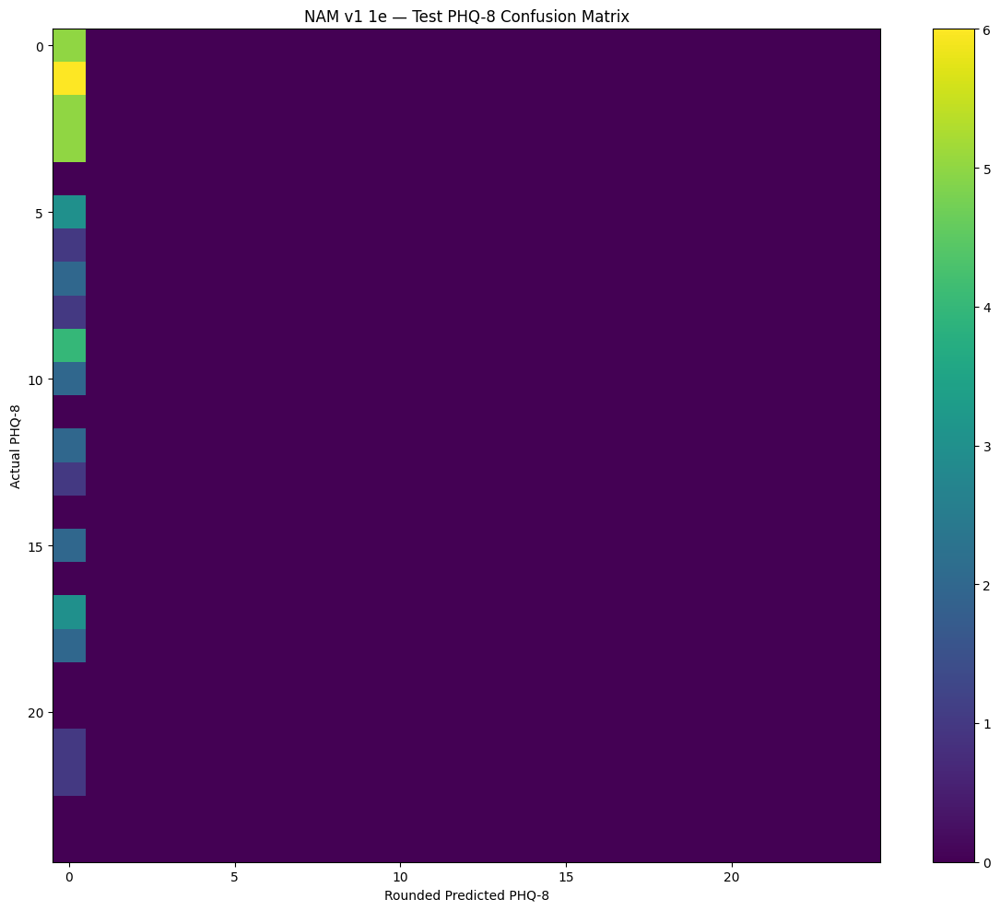

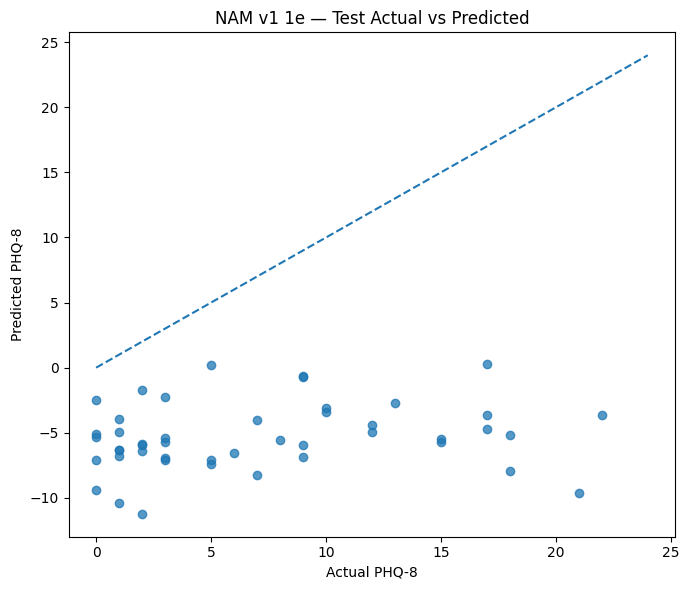


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
22,speech__std_b2_loc,speech,1.574321,-0.041816,1.559863
21,speech__mean_b2_loc,speech,1.145497,0.074844,-0.898585
25,speech__spectral_skewness,speech,0.922050,-0.496397,-2.149867
6,speech__std_f0_hertz,speech,0.687508,0.080428,-0.630547
24,speech__spectral_std_dev,speech,0.674965,0.149287,-0.678188
12,speech__spectral_slope,speech,0.587574,0.241865,-0.504530
15,speech__mean_f1_loc,speech,0.539848,0.090992,-0.851761
3,speech__pause_rate,speech,0.523752,-0.058529,-0.891484
5,speech__mean_f0_hertz,speech,0.516520,-0.080410,-0.606937
18,speech__std_b1_loc,speech,0.511275,-0.013642,0.419859



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_1E_-_Speech_Only_-_Regression_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


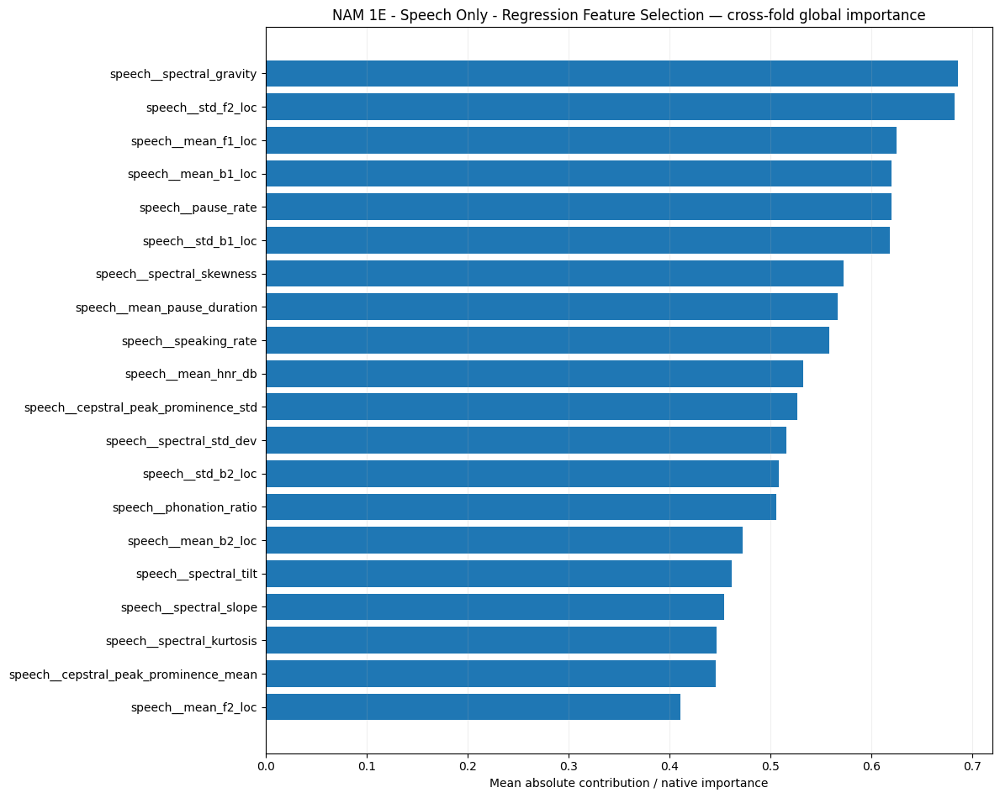


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
18,speech__spectral_slope,5,0.226069,0.767441,0.448617,0.668088,-2.005396,1.926419
16,speech__spectral_kurtosis,5,0.218773,0.653653,0.511792,0.709885,-1.266120,2.566644
20,speech__spectral_tilt,5,0.192006,0.661029,0.469683,0.716695,-2.086141,2.117087
24,speech__std_f1_loc,5,0.120305,0.677533,0.433887,0.872627,-1.861318,1.998083
26,speech__std_hnr_db,5,0.110263,0.559673,0.490942,0.605597,-1.297804,2.635509
10,speech__mean_pause_duration,5,0.101775,0.749571,0.762185,1.211922,-1.178001,2.607113
8,speech__mean_hnr_db,5,0.092533,0.538493,0.663909,0.907336,-2.095261,2.076465
12,speech__phonation_ratio,5,0.068849,0.511978,0.558875,0.969144,-2.219312,1.596939
9,speech__mean_intensity_db,5,0.032433,0.662761,0.416764,0.666046,-1.772843,3.246816
0,speech__articulation_rate,5,0.018371,0.548596,0.428783,0.631485,-3.049239,1.200532


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_1E_-_Speech_Only_-_Regression_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 1e (corresponds to DNAMite 1d)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_1e_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1e",
    dnamite_experiment_id="1d",
    experiment_name='NAM 1E - Speech Only - Regression Feature Selection',
    task="regression",
    cv_results=experiment_1e_regression_cv,
    final_result=experiment_1e_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1e",
    )
] = NAM_v1_1e_report


### Experiment 1f Speech Regression with LDS

In [ ]:
experiment_1f_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1F - "
            "Speech Only - Regression LDS"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)


NAM 1F - Speech Only - Regression LDS
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
[RAM] before inner fit: 1361.5 MB


[codecarbon WARNING @ 02:45:50] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=67.077789; hit ceiling=True
RAM memory:
  start: 1361.48046875 MB
  absolute peak: 2371.66015625 MB
  incremental peak: 1010.1796875 MB
GPU memory:
  start: 0.0 MB
  end: 0.101318359375 MB
  absolute peak: 0.134765625 MB
  incremental peak: 0.134765625 MB
[RAM] after inner cleanup: 2373.0 MB
[RAM] before inner fit: 2373.0 MB
GPU memory at training start: 0.073974609375 MB
Epochs ran=200; best epoch=200; best val_loss=39.835884; hit ceiling=True
RAM memory:
  start: 2372.984375 MB
  absolute peak: 2715.4921875 MB
  incremental peak: 342.5078125 MB
GPU memory:
  start: 0.073974609375 MB
  end: 0.172119140625 MB
  absolute peak: 0.203857421875 MB
  incremental peak: 0.1298828125 MB
[RAM] after inner cleanup: 2464.8 MB
[RAM] before inner fit: 2464.8 MB
GPU memory at training start: 0.144775390625 MB
Epochs ran=200; best epoch=200; best val_loss=101.639511; hit ceiling=True
RAM memory:
  start: 2464.83203125 MB
  absolute peak: 2950.1484375 MB
 

/tmp/ipykernel_3662133/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 13.376427800567061, 'rmse': np.float64(15.364617113877031), 'r2': -6.503971991447426, 'spearman_rho': np.float64(-0.4592316973402725), 'spearman_p': np.float64(0.015967303289369034), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.037037037037037035), 'within_3': np.float64(0.037037037037037035)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1F_-_Speech_Only_-_Regression_LDS/fold_03/model.weights.h5

Outer Fold 4/5
[RAM] before inner fit: 12825.7 MB
GPU memory at training start: 2.76171875 MB
Epochs ran=200; best epoch=200; best val_loss=54.132404; hit ceiling=True
RAM memory:
  start: 12825.69921875 MB
  absolute peak: 12947.2109375 MB
  incremental peak: 121.51171875 MB
GPU memory:
  start: 2.76171875 MB
  end: 2.85986328125 MB
  absolute peak: 2.892333984375 MB
  incremental peak: 0.130615234375 MB
[RAM] after inner cleanup: 12946.6 MB
[RAM] before

/tmp/ipykernel_3662133/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 5.5457142348642705, 'rmse': np.float64(7.176037329795861), 'r2': -0.9785089107218661, 'spearman_rho': np.float64(-0.24755069261504148), 'spearman_p': np.float64(0.21315673367036103), 'exact_accuracy': np.float64(0.07407407407407407), 'within_1': np.float64(0.1111111111111111), 'within_2': np.float64(0.2962962962962963), 'within_3': np.float64(0.37037037037037035)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1F_-_Speech_Only_-_Regression_LDS/fold_04/model.weights.h5

Outer Fold 5/5
[RAM] before inner fit: 16103.7 MB
GPU memory at training start: 3.638427734375 MB
Epochs ran=200; best epoch=200; best val_loss=33.387806; hit ceiling=True
RAM memory:
  start: 16103.67578125 MB
  absolute peak: 16461.3046875 MB
  incremental peak: 357.62890625 MB
GPU memory:
  start: 3.638427734375 MB
  end: 3.736572265625 MB
  absolute peak: 3.7685546875 MB
  incremental peak: 0.130126953125 MB
[RAM] after inner cleanup: 1646

/tmp/ipykernel_3662133/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 5.725606203079224, 'rmse': np.float64(7.040839480034441), 'r2': -0.5667659587901197, 'spearman_rho': np.float64(-0.1520085615973998), 'spearman_p': np.float64(0.4491101451171583), 'exact_accuracy': np.float64(0.037037037037037035), 'within_1': np.float64(0.1111111111111111), 'within_2': np.float64(0.14814814814814814), 'within_3': np.float64(0.2222222222222222)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_1F_-_Speech_Only_-_Regression_LDS/fold_05/model.weights.h5


In [ ]:
experiment_1f_results_df = pd.DataFrame(
    [
        {
            "outer_fold": result["outer_fold"],

            **result["metrics"],

            **{
                f"parameter_{key}": value
                for key, value
                in result["parameters"].items()
            },
        }

        for result
        in experiment_1f_regression_cv
    ]
)

display(
    experiment_1f_results_df
)

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,parameter_activation,parameter_dropout,parameter_feature_dropout,parameter_learning_rate,parameter_num_units,parameter_shallow
0,1,9.016738,10.945598,-3.320701,-0.255972,0.197492,0.111111,0.111111,0.185185,0.259259,exu,0.1,0.0,0.0010,32,True
1,2,5.369045,7.959212,-0.623364,-0.017792,0.929813,0.222222,0.222222,0.370370,0.555556,exu,0.1,0.0,0.0005,32,True
2,3,13.376428,15.364617,-6.503972,-0.459232,0.015967,0.148148,0.000000,0.037037,0.037037,exu,0.1,0.0,0.0005,64,True
3,4,5.545714,7.176037,-0.978509,-0.247551,0.213157,0.074074,0.111111,0.296296,0.370370,exu,0.1,0.0,0.0005,64,True
4,5,5.725606,7.040839,-0.566766,-0.152009,0.449110,0.037037,0.111111,0.148148,0.222222,exu,0.1,0.0,0.0005,64,True


In [ ]:
experiment_1f_summary = (
    summarize_nested_cv(
        experiment_1f_regression_cv
    )
)

display(
    experiment_1f_summary
)

   outer_fold        mae       rmse        r2  spearman_rho  spearman_p  \
0           1   9.016738  10.945598 -3.320701     -0.255972    0.197492   
1           2   5.369045   7.959212 -0.623364     -0.017792    0.929813   
2           3  13.376428  15.364617 -6.503972     -0.459232    0.015967   
3           4   5.545714   7.176037 -0.978509     -0.247551    0.213157   
4           5   5.725606   7.040839 -0.566766     -0.152009    0.449110   

   exact_accuracy  within_1  within_2  within_3 selected_text_count  \
0        0.111111  0.111111  0.185185  0.259259                None   
1        0.222222  0.222222  0.370370  0.555556                None   
2        0.148148  0.000000  0.037037  0.037037                None   
3        0.074074  0.111111  0.296296  0.370370                None   
4        0.037037  0.111111  0.148148  0.222222                None   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,9.016738,10.945598,-3.320701,-0.255972,0.197492,0.111111,0.111111,0.185185,0.259259,None,None
1,2,5.369045,7.959212,-0.623364,-0.017792,0.929813,0.222222,0.222222,0.370370,0.555556,None,None
2,3,13.376428,15.364617,-6.503972,-0.459232,0.015967,0.148148,0.000000,0.037037,0.037037,None,None
3,4,5.545714,7.176037,-0.978509,-0.247551,0.213157,0.074074,0.111111,0.296296,0.370370,None,None
4,5,5.725606,7.040839,-0.566766,-0.152009,0.449110,0.037037,0.111111,0.148148,0.222222,None,None


In [ ]:
experiment_1f_best_parameters = (
    choose_final_parameters(
        experiment_1f_regression_cv
    )
)

print(
    "Best parameters:"
)

print(
    experiment_1f_best_parameters
)

Best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}


In [ ]:
experiment_1f_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_1f_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)

GPU memory at training start: 4.558837890625 MB
Epochs ran=200; best epoch=200; best val_loss=80.690483; hit ceiling=True
RAM memory:
  start: 19482.22265625 MB
  absolute peak: 19672.86328125 MB
  incremental peak: 190.640625 MB
GPU memory:
  start: 4.558837890625 MB
  end: 4.656982421875 MB
  absolute peak: 4.69775390625 MB
  incremental peak: 0.138916015625 MB
Best training epochs: 200
RAM memory:
  start: 19651.4375 MB
  absolute peak: 20040.703125 MB
  incremental peak: 389.265625 MB

FINAL TEST METRICS
{'mae': 7.864969248357027, 'rmse': np.float64(10.067944634581481), 'r2': -1.466452609711662, 'spearman_rho': np.float64(-0.2500016670579281), 'spearman_p': np.float64(0.09380558055215672), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.08695652173913043), 'within_2': np.float64(0.1956521739130435), 'within_3': np.float64(0.2608695652173913)}


#### NAM v1 Experiment 1f — DNAMite-parity outputs (maps to DNAMite 1f)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 1f — NAM 1F - Speech Only - Regression LDS
DNAMite reference experiment: 1f

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,9.016738,10.945598,-3.320701,-0.255972,0.197492,0.111111,0.111111,0.185185,0.259259,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
1,2,5.369045,7.959212,-0.623364,-0.017792,0.929813,0.222222,0.222222,0.370370,0.555556,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
2,3,13.376428,15.364617,-6.503972,-0.459232,0.015967,0.148148,0.000000,0.037037,0.037037,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
3,4,5.545714,7.176037,-0.978509,-0.247551,0.213157,0.074074,0.111111,0.296296,0.370370,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True
4,5,5.725606,7.040839,-0.566766,-0.152009,0.449110,0.037037,0.111111,0.148148,0.222222,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,200,200,True



CV Mean ± SD


,mean,sd
mae,7.806706,3.459452
rmse,9.697261,3.539464
r2,-2.398662,2.560668
spearman_rho,-0.226511,0.161697
spearman_p,0.361108,0.353182
exact_accuracy,0.118519,0.071242
within_1,0.111111,0.078567
within_2,0.207407,0.129894
within_3,0.288889,0.191378
best_epoch,200.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,1,71.051484,5346.000000,5704.683594,358.683594,0.130371,NaN,0.853027,0.951172,0.983398,tensorflow,2689,0.237930
1,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,2,72.683453,8943.597656,9212.988281,269.390625,0.130371,NaN,1.770508,1.868652,1.900879,tensorflow,2689,0.237930
2,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,3,76.435456,12249.308594,12779.277344,529.968750,0.141357,NaN,2.690918,2.789062,2.832275,tensorflow,5377,0.247696
3,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,4,76.913806,15849.261719,16073.003906,223.742188,0.140869,NaN,3.567627,3.665771,3.708496,tensorflow,5377,0.247696
4,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,5,77.130960,19238.531250,19605.210938,366.679688,0.141357,NaN,4.488037,4.586182,4.629395,tensorflow,5377,0.247696



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,1,0.002331,0.001097
1,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,2,0.002385,0.001123
2,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,3,0.002508,0.001181
3,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,4,0.002704,0.001273
4,NAM v1,NAM 1F - Speech Only - Regression LDS,regression,5,0.002533,0.001192



Final Test Metrics
{'mae': 7.864969248357027, 'rmse': np.float64(10.067944634581481), 'r2': -1.466452609711662, 'spearman_rho': np.float64(-0.2500016670579281), 'spearman_p': np.float64(0.09380558055215672), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.08695652173913043), 'within_2': np.float64(0.1956521739130435), 'within_3': np.float64(0.2608695652173913)}

Final Model Resource Summary
{'train_seconds': 59.59761190999416, 'start_ram_mb': 19651.4375, 'peak_ram_mb': 20040.703125, 'incremental_peak_ram_mb': 389.265625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.001954531610288963, 'training_co2_kg': 0.0009201602550866689}


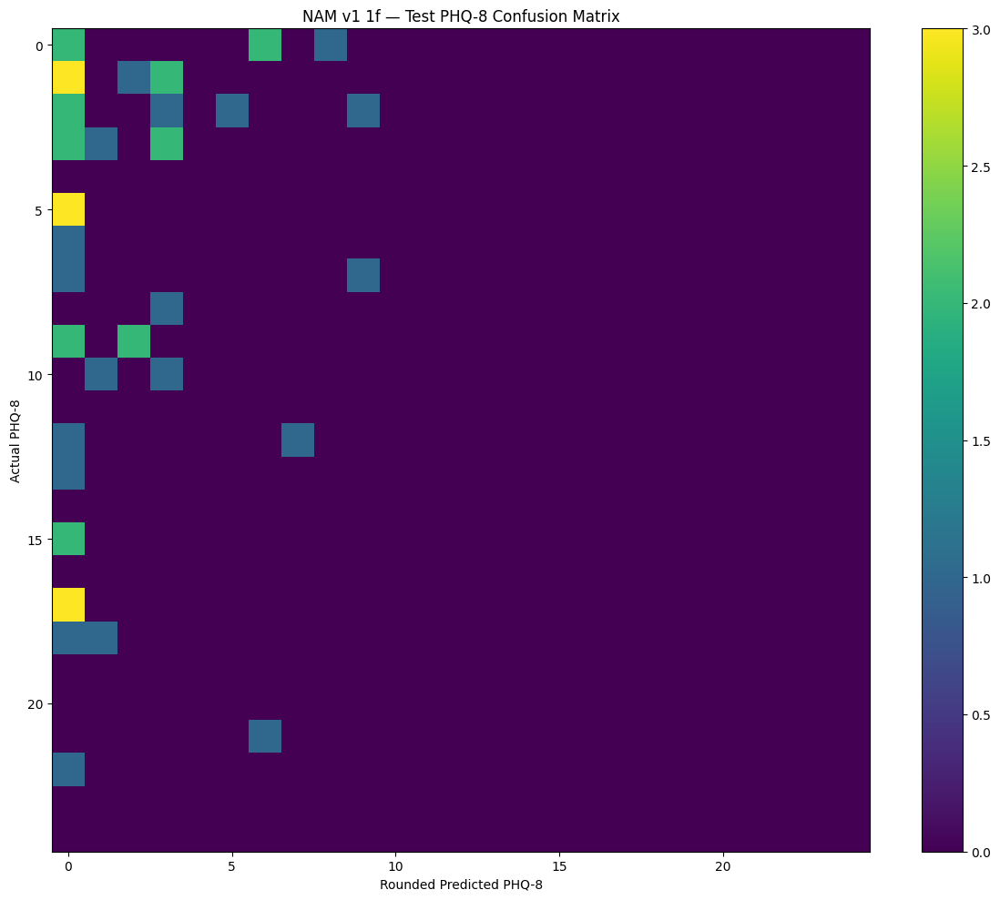

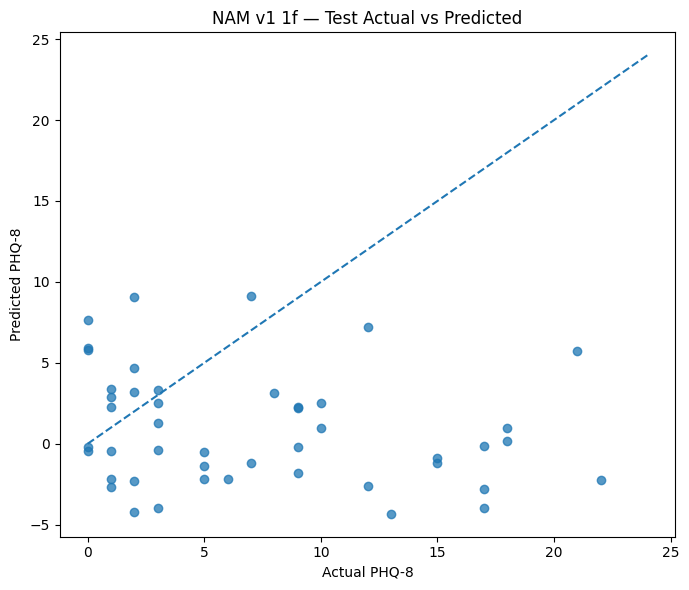


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
7,speech__mean_intensity_db,speech,1.128177,0.162367,-1.339157
21,speech__std_f2_loc,speech,1.040791,-0.033586,0.656001
20,speech__mean_f2_loc,speech,0.997452,0.044630,1.425492
12,speech__spectral_slope,speech,0.873445,0.271668,-0.774265
18,speech__mean_b1_loc,speech,0.855631,0.009850,-1.261535
15,speech__cepstral_peak_prominence_std,speech,0.794559,-0.074591,1.035464
17,speech__std_f1_loc,speech,0.618256,-0.041747,-1.070672
16,speech__mean_f1_loc,speech,0.604023,0.000654,0.683192
22,speech__mean_b2_loc,speech,0.595005,0.011208,0.618921
25,speech__spectral_std_dev,speech,0.590717,-0.102508,0.231348



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_1F_-_Speech_Only_-_Regression_LDS
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


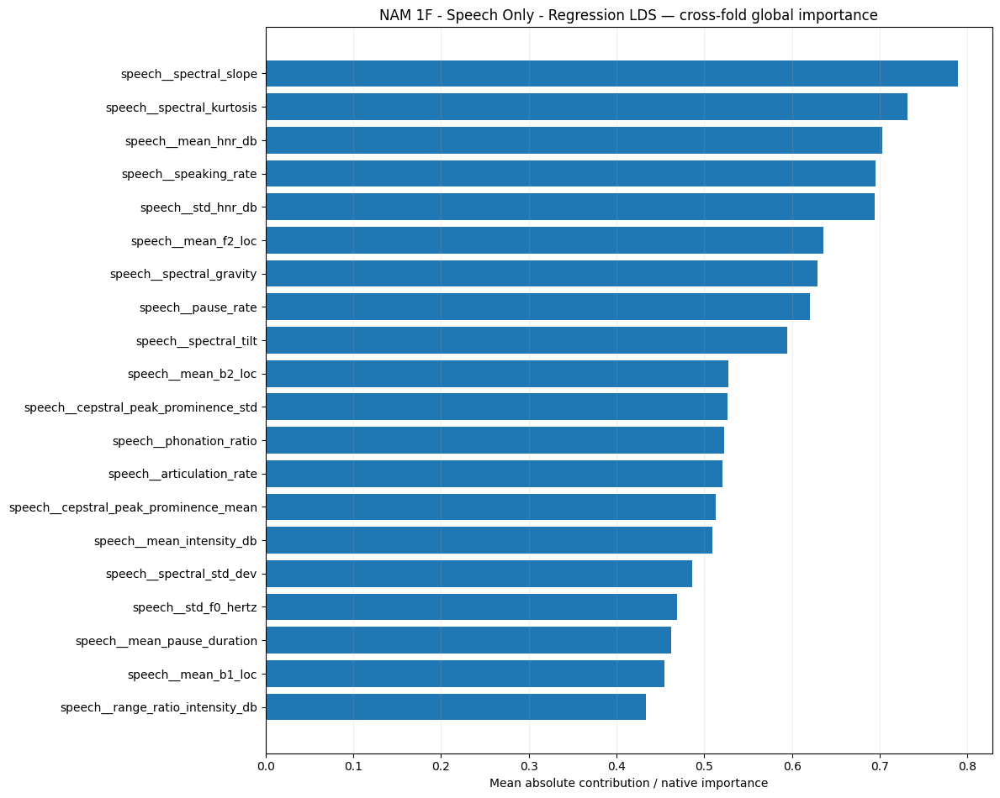


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
18,speech__spectral_slope,5,0.774442,0.110622,0.439440,0.849281,-2.005396,1.926419
7,speech__mean_f2_loc,5,0.746984,0.097055,0.418986,0.822732,-2.069726,2.197272
8,speech__mean_hnr_db,5,0.673544,0.176103,0.459266,0.904410,-2.095261,2.076465
24,speech__std_f1_loc,5,0.261446,0.355006,0.412787,0.717738,-1.861318,1.998083
13,speech__range_ratio_intensity_db,5,0.250361,0.733394,0.450654,0.894489,-1.038661,0.829560
20,speech__spectral_tilt,5,0.165384,0.715732,0.673590,0.883595,-2.086141,2.117087
26,speech__std_hnr_db,5,0.144028,0.857090,1.043380,1.354910,-1.297804,2.635509
0,speech__articulation_rate,5,0.139631,0.585894,0.838862,1.243034,-3.049239,1.200532
1,speech__cepstral_peak_prominence_mean,5,0.114403,0.827449,0.604194,0.998169,-1.970588,2.049994
16,speech__spectral_kurtosis,5,0.106439,0.674851,0.916875,1.280757,-1.266120,2.566644


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_1F_-_Speech_Only_-_Regression_LDS.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 1f (corresponds to DNAMite 1f)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_1f_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1f",
    dnamite_experiment_id="1f",
    experiment_name='NAM 1F - Speech Only - Regression LDS',
    task="regression",
    cv_results=experiment_1f_regression_cv,
    final_result=experiment_1f_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1f",
    )
] = NAM_v1_1f_report


## Experiment 2 -- Speech + Unigram

### Experiment 2a Speech + Unigram Classification

In [ ]:
experiment_2a_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2A - "
            "Speech + Unigrams - Baseline"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2A - Speech + Unigrams - Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 14 TF-IDF features for classification / unigram using C=5.0
[RAM] before inner fit: 1366.2 MB


[codecarbon WARNING @ 16:53:26] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=1.221219; hit ceiling=True
RAM memory:
  start: 1366.23046875 MB
  absolute peak: 2744.7421875 MB
  incremental peak: 1378.51171875 MB
GPU memory:
  start: 0.0 MB
  end: 0.125244140625 MB
  absolute peak: 0.169189453125 MB
  incremental peak: 0.169189453125 MB
[RAM] after inner cleanup: 2749.9 MB
Selected 15 TF-IDF features for classification / unigram using C=5.0
[RAM] before inner fit: 2749.9 MB
GPU memory at training start: 0.084228515625 MB
Epochs ran=200; best epoch=200; best val_loss=2.753617; hit ceiling=True
RAM memory:
  start: 2749.94921875 MB
  absolute peak: 3328.03125 MB
  incremental peak: 578.08203125 MB
GPU memory:
  start: 0.084228515625 MB
  end: 0.2080078125 MB
  absolute peak: 0.24951171875 MB
  incremental peak: 0.165283203125 MB
[RAM] after inner cleanup: 2873.0 MB
Selected 1 TF-IDF features for classification / unigram using C=2.5
[RAM] before inner fit: 2874.3 MB
GPU memory at training start: 0.166015625 MB
Epochs ra

In [ ]:
experiment_2a_classification_summary = (
    summarize_nested_cv(
        experiment_2a_classification_cv
    )
)

display(
    experiment_2a_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.444444           0.351974  0.117647   0.111111   
1           2  0.555556           0.430921  0.142857   0.166667   
2           3  0.629630           0.483553  0.166667   0.250000   
3           4  0.703704           0.644737  0.500000   0.500000   
4           5  0.518519           0.621711  0.518519   0.368421   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.125     0.578947  0.342105  0.262900                    1   
1               0.125     0.736842  0.467105  0.317853                    2   
2               0.125     0.842105  0.453947  0.375928                    3   
3               0.500     0.789474  0.559211  0.361003                    2   
4               0.875     0.368421  0.677632  0.575108                    1   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count
0,1,0.444444,0.351974,0.117647,0.111111,0.125,0.578947,0.342105,0.262900,1,None
1,2,0.555556,0.430921,0.142857,0.166667,0.125,0.736842,0.467105,0.317853,2,None
2,3,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.453947,0.375928,3,None
3,4,0.703704,0.644737,0.500000,0.500000,0.500,0.789474,0.559211,0.361003,2,None
4,5,0.518519,0.621711,0.518519,0.368421,0.875,0.368421,0.677632,0.575108,1,None


In [ ]:
for result in experiment_2a_classification_cv:
    print(
        f"Outer Fold {result['outer_fold']}"
    )
    print(
        result["parameters"]
    )
    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}



In [ ]:
for result in experiment_2a_classification_cv:
    print(
        f"Fold {result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

Fold 1: 1 selected unigrams
Fold 2: 2 selected unigrams
Fold 3: 3 selected unigrams
Fold 4: 2 selected unigrams
Fold 5: 1 selected unigrams


In [ ]:
experiment_2a_best_parameters = (
    choose_final_parameters(
        experiment_2a_classification_cv
    )
)

print(
    "Chosen final parameters:"
)

print(
    experiment_2a_best_parameters
)

Chosen final parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}


In [ ]:
import json

parameter_table = pd.DataFrame(
    {
        "outer_fold": [
            result["outer_fold"]
            for result
            in experiment_2a_classification_cv
        ],

        "parameters": [
            json.dumps(
                result["parameters"],
                sort_keys=True,
            )
            for result
            in experiment_2a_classification_cv
        ],
    }
)

display(
    parameter_table
)

print(
    "\nParameter selection counts:"
)

display(
    parameter_table[
        "parameters"
    ].value_counts()
)

,outer_fold,parameters
0,1,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature..."
1,2,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature..."
2,3,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature..."
3,4,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature..."
4,5,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature..."



Parameter selection counts:


,count
parameters,
"{""activation"": ""exu"", ""dropout"": 0.1, ""feature_dropout"": 0.0, ""learning_rate"": 0.0005, ""num_units"": 64, ""shallow"": true}",4
"{""activation"": ""exu"", ""dropout"": 0.1, ""feature_dropout"": 0.0, ""learning_rate"": 0.001, ""num_units"": 32, ""shallow"": true}",1


In [ ]:
experiment_2a_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_2a_best_parameters
        ),

        experiment_variant="baseline",

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation="unigram",
    )
)

Selected 1 TF-IDF features for classification / unigram using C=2.5
GPU memory at training start: 4.70556640625 MB
Epochs ran=200; best epoch=200; best val_loss=0.690123; hit ceiling=True
RAM memory:
  start: 24694.515625 MB
  absolute peak: 24694.52734375 MB
  incremental peak: 0.01171875 MB
GPU memory:
  start: 4.70556640625 MB
  end: 4.805419921875 MB
  absolute peak: 4.849609375 MB
  incremental peak: 0.14404296875 MB
Best training epochs: 200
Selected 4 TF-IDF features for classification / unigram using C=2.5
RAM memory:
  start: 24673.75390625 MB
  absolute peak: 25077.2734375 MB
  incremental peak: 403.51953125 MB

FINAL TEST METRICS
{'accuracy': 0.5217391304347826, 'balanced_accuracy': np.float64(0.43526785714285715), 'f1': 0.21428571428571427, 'precision': 0.21428571428571427, 'recall_sensitivity': 0.21428571428571427, 'specificity': 0.65625, 'roc_auc': np.float64(0.3794642857142857), 'pr_auc': np.float64(0.28931689280519557)}


In [ ]:
print(
    "Final parameters:"
)

print(
    experiment_2a_classification_final[
        "parameters"
    ]
)


print(
    "\nFinal test metrics:"
)

print(
    experiment_2a_classification_final[
        "metrics"
    ]
)


print(
    "\nBest epoch:"
)

print(
    experiment_2a_classification_final[
        "best_epoch"
    ]
)


print(
    "\nNumber of selected unigrams:"
)

print(
    len(
        experiment_2a_classification_final[
            "selected_text_indices"
        ]
    )
)

Final parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Final test metrics:
{'accuracy': 0.5217391304347826, 'balanced_accuracy': np.float64(0.43526785714285715), 'f1': 0.21428571428571427, 'precision': 0.21428571428571427, 'recall_sensitivity': 0.21428571428571427, 'specificity': 0.65625, 'roc_auc': np.float64(0.3794642857142857), 'pr_auc': np.float64(0.28931689280519557)}

Best epoch:
200

Number of selected unigrams:
4


#### NAM v1 Experiment 2a — DNAMite-parity outputs (maps to DNAMite 2a)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 2a — NAM 2A - Speech + Unigrams - Baseline
DNAMite reference experiment: 2a

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.444444,0.351974,0.117647,0.111111,0.125,0.578947,0.342105,0.262900,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,200,200,True
1,2,0.555556,0.430921,0.142857,0.166667,0.125,0.736842,0.467105,0.317853,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,None,200,200,True
2,3,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.453947,0.375928,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",3,None,200,200,True
3,4,0.703704,0.644737,0.500000,0.500000,0.500,0.789474,0.559211,0.361003,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,None,22,42,False
4,5,0.518519,0.621711,0.518519,0.368421,0.875,0.368421,0.677632,0.575108,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.570370,0.100069
balanced_accuracy,0.506579,0.125000
f1,0.289138,0.201795
precision,0.279240,0.156910
recall_sensitivity,0.350000,0.335410
specificity,0.663158,0.191943
roc_auc,0.500000,0.125691
pr_auc,0.378558,0.118331
selected_text_count,1.800000,0.836660
best_epoch,164.400000,79.604020



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,1,77.462151,6507.449219,6898.210938,390.761719,0.142578,NaN,0.894531,0.994385,1.037109,tensorflow,5569,0.255325
1,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,2,76.633386,10119.855469,10548.941406,429.085938,0.132812,NaN,1.695801,1.797363,1.828613,tensorflow,2881,0.253189
2,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,3,84.078373,15401.355469,15734.929688,333.574219,0.147217,NaN,2.711670,2.814941,2.858887,tensorflow,5953,0.272537
3,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,4,63.345552,20000.750000,20203.230469,202.480469,0.104492,NaN,3.721436,3.783447,3.825928,tensorflow,5761,0.264908
4,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,5,81.605676,24297.824219,24549.792969,251.968750,0.141357,NaN,4.634033,4.733887,4.775391,tensorflow,5569,0.255325



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,1,0.002460,0.001158
1,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,2,0.002433,0.001145
2,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,3,0.002655,0.001250
3,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,4,0.002007,0.000945
4,NAM v1,NAM 2A - Speech + Unigrams - Baseline,classification,5,0.002591,0.001220



Final Test Metrics
{'accuracy': 0.5217391304347826, 'balanced_accuracy': np.float64(0.43526785714285715), 'f1': 0.21428571428571427, 'precision': 0.21428571428571427, 'recall_sensitivity': 0.21428571428571427, 'specificity': 0.65625, 'roc_auc': np.float64(0.3794642857142857), 'pr_auc': np.float64(0.28931689280519557)}

Final Model Resource Summary
{'train_seconds': 67.11481908400037, 'start_ram_mb': 24673.75390625, 'peak_ram_mb': 25077.2734375, 'incremental_peak_ram_mb': 403.51953125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.002129298418740768, 'training_co2_kg': 0.0010024374974700351}


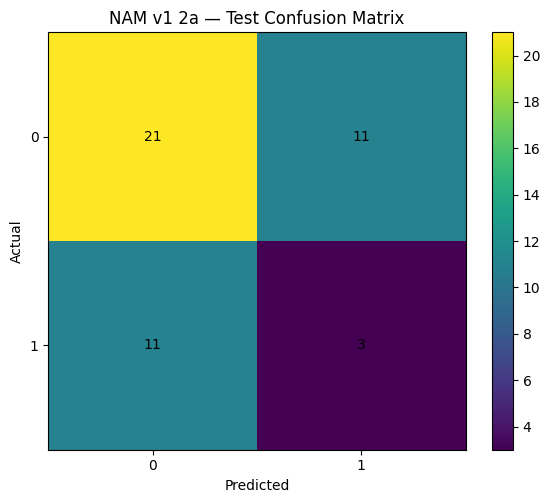

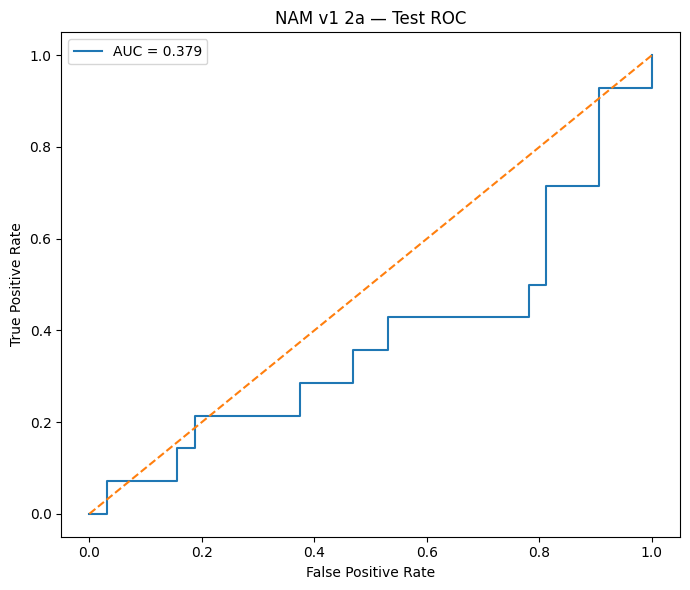

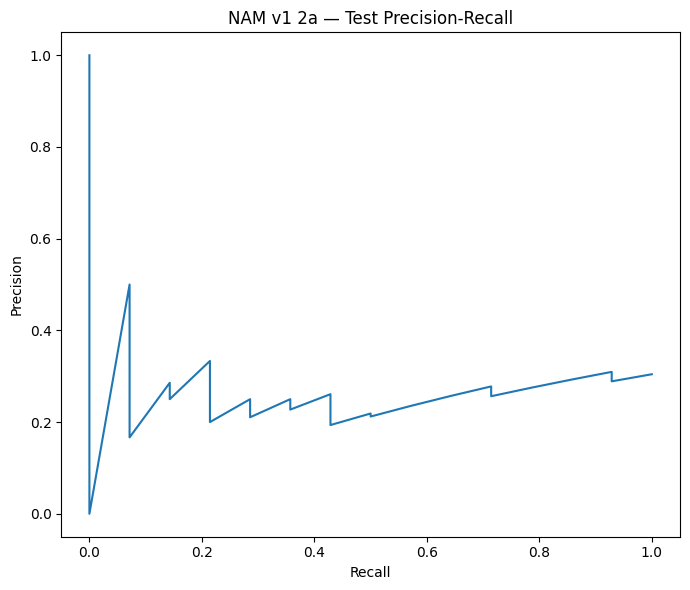

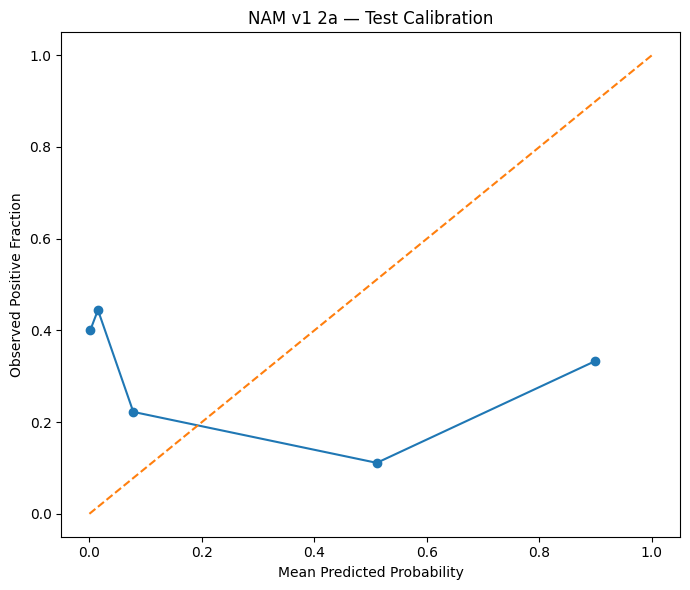


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
7,speech__mean_intensity_db,speech,1.288487,-0.132215,1.460779
9,speech__range_ratio_intensity_db,speech,1.077159,0.265761,-1.505698
3,speech__pause_rate,speech,0.866145,0.002373,-1.343024
0,speech__speaking_rate,speech,0.779946,-0.031157,-0.110271
10,speech__mean_hnr_db,speech,0.728525,0.028869,-1.303382
4,speech__mean_pause_duration,speech,0.723303,0.198971,-0.348088
14,speech__cepstral_peak_prominence_mean,speech,0.634792,0.167468,-0.591806
22,speech__mean_b2_loc,speech,0.626901,0.039194,-0.177613
25,speech__spectral_std_dev,speech,0.594080,-0.142805,0.565223
27,speech__spectral_kurtosis,speech,0.542123,0.251060,0.960990



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_2A_-_Speech_Unigrams_-_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


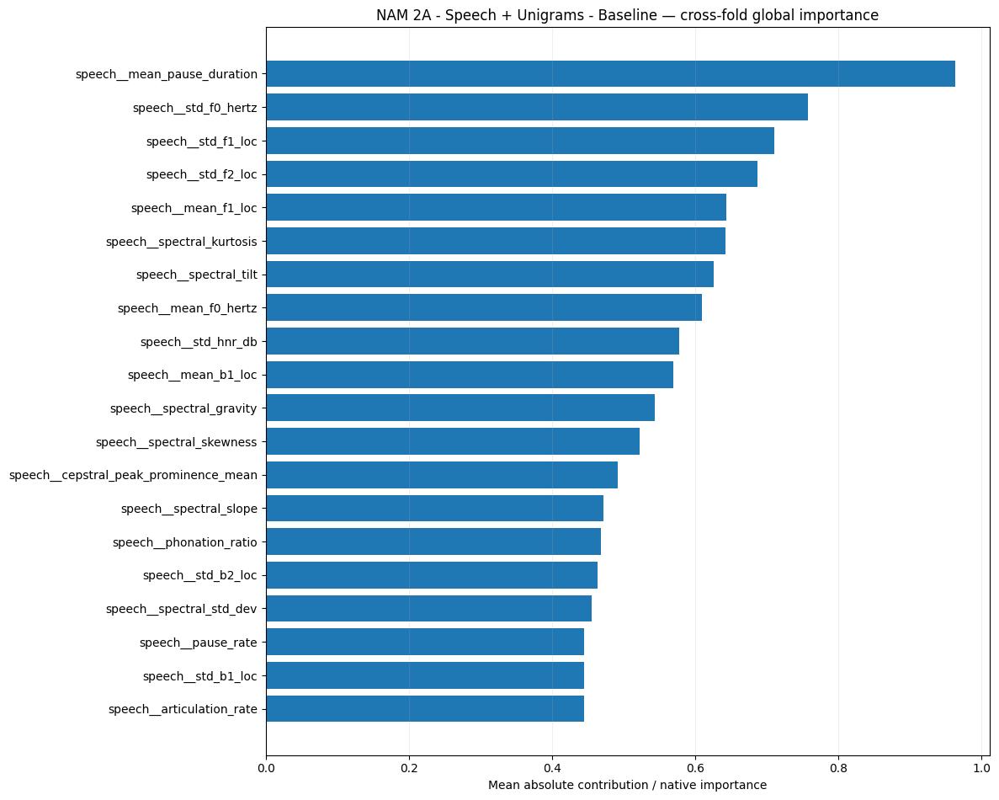


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
12,speech__phonation_ratio,5,0.460976,0.342034,0.462671,0.605576,-2.298891,1.633485
4,speech__mean_b2_loc,5,0.412016,0.235824,0.423058,0.642827,-1.518951,2.798539
26,speech__std_hnr_db,5,0.248657,0.463836,0.565302,0.708446,-1.316103,3.071081
14,speech__speaking_rate,5,0.221676,0.549981,0.247812,0.492788,-2.195560,1.598015
11,speech__pause_rate,5,0.173849,0.457200,0.507569,0.868789,-1.768064,1.710399
23,speech__std_f0_hertz,5,0.160386,0.903838,0.810187,1.068357,-1.441116,2.275466
0,speech__articulation_rate,5,0.146513,0.621388,0.507700,0.783549,-2.875069,1.011910
29,text__therapist,3,0.131834,0.233602,0.126793,0.171074,0.000000,0.085293
1,speech__cepstral_peak_prominence_mean,5,0.071958,0.606135,0.539138,0.746572,-2.021945,1.970126
17,speech__spectral_skewness,5,0.059263,0.414492,0.769875,1.007339,-1.809054,2.054626


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_2A_-_Speech_Unigrams_-_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 2a (corresponds to DNAMite 2a)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_2a_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2a",
    dnamite_experiment_id="2a",
    experiment_name='NAM 2A - Speech + Unigrams - Baseline',
    task="classification",
    cv_results=experiment_2a_classification_cv,
    final_result=experiment_2a_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2a",
    )
] = NAM_v1_2a_report


### Experiment 2b Speech + Unigram Classification with Feature Selection

In [ ]:
experiment_2b_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2B - "
            "Speech + Unigrams - "
            "Joint Feature Selection"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2B - Speech + Unigrams - Joint Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 14 TF-IDF features for classification / unigram using C=5.0
Joint selection: 18 features, C=1.0
[RAM] before inner fit: 1368.8 MB


[codecarbon WARNING @ 18:49:47] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=1.421171; hit ceiling=True
RAM memory:
  start: 1368.765625 MB
  absolute peak: 2153.25 MB
  incremental peak: 784.484375 MB
GPU memory:
  start: 0.0 MB
  end: 0.084228515625 MB
  absolute peak: 0.1064453125 MB
  incremental peak: 0.1064453125 MB
[RAM] after inner cleanup: 2150.2 MB
Selected 15 TF-IDF features for classification / unigram using C=5.0
Joint selection: 14 features, C=1.0
[RAM] before inner fit: 2150.2 MB
GPU memory at training start: 0.066650390625 MB
Epochs ran=200; best epoch=200; best val_loss=0.872035; hit ceiling=True
RAM memory:
  start: 2150.171875 MB
  absolute peak: 2249.93359375 MB
  incremental peak: 99.76171875 MB
GPU memory:
  start: 0.066650390625 MB
  end: 0.140869140625 MB
  absolute peak: 0.15771484375 MB
  incremental peak: 0.091064453125 MB
[RAM] after inner cleanup: 2249.4 MB
Selected 1 TF-IDF features for classification / unigram using C=2.5
Joint selection: 13 features, C=1.0
[RAM] before inner fit: 2249

In [ ]:
experiment_2b_classification_summary = (
    summarize_nested_cv(
        experiment_2b_classification_cv
    )
)

display(
    experiment_2b_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.333333           0.309211  0.181818   0.142857   
1           2  0.370370           0.444079  0.370370   0.263158   
2           3  0.703704           0.572368  0.333333   0.500000   
3           4  0.481481           0.414474  0.222222   0.200000   
4           5  0.555556           0.575658  0.454545   0.357143   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.250     0.368421  0.256579  0.223919                    1   
1               0.625     0.263158  0.427632  0.290727                    2   
2               0.250     0.894737  0.467105  0.367376                    3   
3               0.250     0.578947  0.447368  0.379354                    2   
4               0.625     0.526316  0.651316  0.488390                    1   

   joint_selected_count  
0                    13  
1                    16  
2                    16  
3                 

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count
0,1,0.333333,0.309211,0.181818,0.142857,0.250,0.368421,0.256579,0.223919,1,13
1,2,0.370370,0.444079,0.370370,0.263158,0.625,0.263158,0.427632,0.290727,2,16
2,3,0.703704,0.572368,0.333333,0.500000,0.250,0.894737,0.467105,0.367376,3,16
3,4,0.481481,0.414474,0.222222,0.200000,0.250,0.578947,0.447368,0.379354,2,17
4,5,0.555556,0.575658,0.454545,0.357143,0.625,0.526316,0.651316,0.488390,1,19


In [ ]:
for result in experiment_2b_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}



In [ ]:
for result in experiment_2b_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        "Selected unigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

Outer Fold 1
Selected unigram features: 1
Final jointly selected features: 13

Outer Fold 2
Selected unigram features: 2
Final jointly selected features: 16

Outer Fold 3
Selected unigram features: 3
Final jointly selected features: 16

Outer Fold 4
Selected unigram features: 2
Final jointly selected features: 17

Outer Fold 5
Selected unigram features: 1
Final jointly selected features: 19



In [ ]:
experiment_2b_best_parameters = (
    choose_final_parameters(
        experiment_2b_classification_cv
    )
)

print(
    "Experiment 2B best parameters:"
)

print(
    experiment_2b_best_parameters
)

Experiment 2B best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}


In [ ]:
experiment_2b_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_2b_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 1 TF-IDF features for classification / unigram using C=2.5
Joint selection: 13 features, C=1.0
GPU memory at training start: 3.830078125 MB
Epochs ran=200; best epoch=200; best val_loss=2.244665; hit ceiling=True
RAM memory:
  start: 12138.94140625 MB
  absolute peak: 12138.9453125 MB
  incremental peak: 0.00390625 MB
GPU memory:
  start: 3.830078125 MB
  end: 3.902587890625 MB
  absolute peak: 3.9267578125 MB
  incremental peak: 0.0966796875 MB
Best training epochs: 200
Selected 4 TF-IDF features for classification / unigram using C=2.5
Joint selection: 18 features, C=1.0
RAM memory:
  start: 11960.03515625 MB
  absolute peak: 12249.12109375 MB
  incremental peak: 289.0859375 MB

FINAL TEST METRICS
{'accuracy': 0.3695652173913043, 'balanced_accuracy': np.float64(0.48660714285714285), 'f1': 0.43137254901960786, 'precision': 0.2972972972972973, 'recall_sensitivity': 0.7857142857142857, 'specificity': 0.1875, 'roc_auc': np.float64(0.4174107142857143), 'pr_auc': np.float64(0.2878

In [ ]:
experiment_2b_classification_final[
    "metrics"
]

{'accuracy': 0.3695652173913043,
 'balanced_accuracy': np.float64(0.48660714285714285),
 'f1': 0.43137254901960786,
 'precision': 0.2972972972972973,
 'recall_sensitivity': 0.7857142857142857,
 'specificity': 0.1875,
 'roc_auc': np.float64(0.4174107142857143),
 'pr_auc': np.float64(0.2878993817561548)}

In [ ]:
experiment_2b_classification_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.1,
 'feature_dropout': 0.0,
 'learning_rate': 0.0005,
 'num_units': 64,
 'shallow': True}

In [ ]:
selected_text_indices = (
    experiment_2b_classification_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

Selected unigrams: 4


#### NAM v1 Experiment 2b — DNAMite-parity outputs (maps to DNAMite 2b)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 2b — NAM 2B - Speech + Unigrams - Joint Feature Selection
DNAMite reference experiment: 2b

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.333333,0.309211,0.181818,0.142857,0.250,0.368421,0.256579,0.223919,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,13,200,200,True
1,2,0.370370,0.444079,0.370370,0.263158,0.625,0.263158,0.427632,0.290727,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,16,200,200,True
2,3,0.703704,0.572368,0.333333,0.500000,0.250,0.894737,0.467105,0.367376,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",3,16,200,200,True
3,4,0.481481,0.414474,0.222222,0.200000,0.250,0.578947,0.447368,0.379354,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,17,200,200,True
4,5,0.555556,0.575658,0.454545,0.357143,0.625,0.526316,0.651316,0.488390,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,19,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.488889,0.149071
balanced_accuracy,0.463158,0.112935
f1,0.312458,0.110892
precision,0.292632,0.140575
recall_sensitivity,0.400000,0.205396
specificity,0.526316,0.241188
roc_auc,0.450000,0.140303
pr_auc,0.349953,0.099656
selected_text_count,1.800000,0.836660
joint_selected_count,16.200000,2.167948



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,1,46.446652,3783.480469,3893.351562,109.871094,0.089111,NaN,0.738770,0.811279,0.827881,tensorflow,1249,0.116028
1,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,2,51.857047,5704.183594,5916.320312,212.136719,0.095215,NaN,1.449219,1.526855,1.544434,tensorflow,1537,0.141182
2,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,3,53.724566,7856.320312,8034.710938,178.390625,0.109863,NaN,2.257812,2.335449,2.367676,tensorflow,3073,0.147041
3,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,4,56.257098,9713.015625,9914.281250,201.265625,0.107178,NaN,3.045898,3.125244,3.153076,tensorflow,3265,0.154671
4,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,5,59.793399,11780.250000,12049.773438,269.523438,0.114746,NaN,3.765869,3.848633,3.880615,tensorflow,3649,0.172195



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,1,0.001471,0.000693
1,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,2,0.001643,0.000774
2,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,3,0.001702,0.000801
3,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,4,0.001784,0.000840
4,NAM v1,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,5,0.001896,0.000893



Final Test Metrics
{'accuracy': 0.3695652173913043, 'balanced_accuracy': np.float64(0.48660714285714285), 'f1': 0.43137254901960786, 'precision': 0.2972972972972973, 'recall_sensitivity': 0.7857142857142857, 'specificity': 0.1875, 'roc_auc': np.float64(0.4174107142857143), 'pr_auc': np.float64(0.2878993817561548)}

Final Model Resource Summary
{'train_seconds': 42.8310408189991, 'start_ram_mb': 11960.03515625, 'peak_ram_mb': 12249.12109375, 'incremental_peak_ram_mb': 289.0859375, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.001357207930809306, 'training_co2_kg': 0.0006389504212901975}


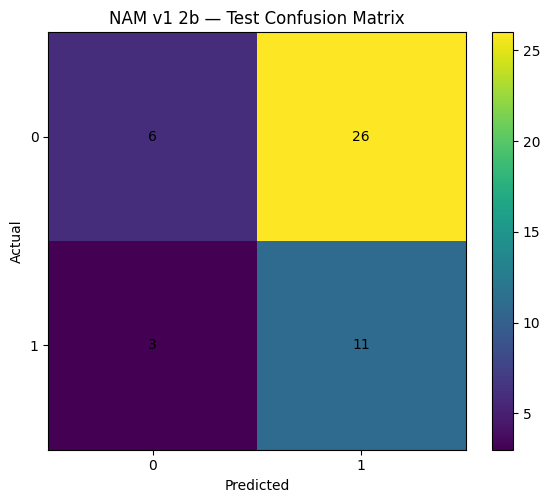

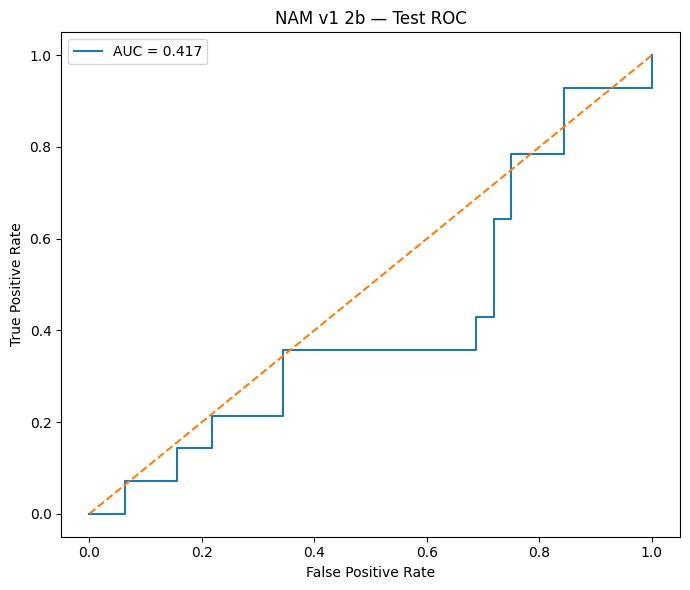

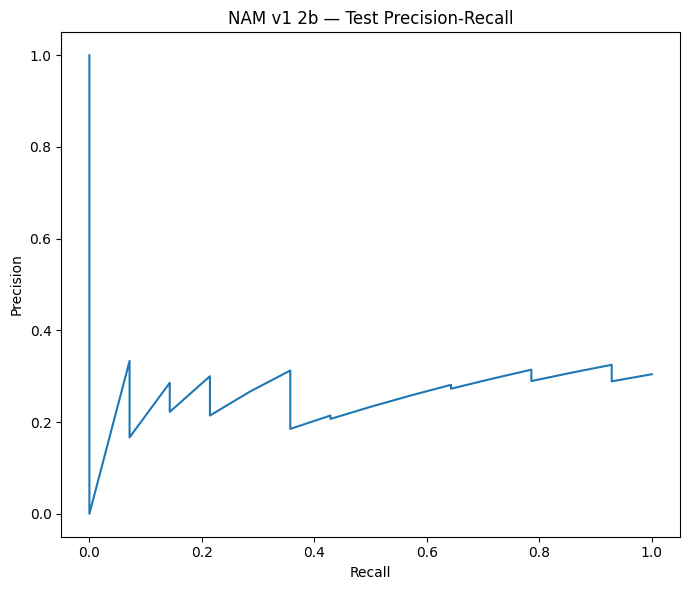

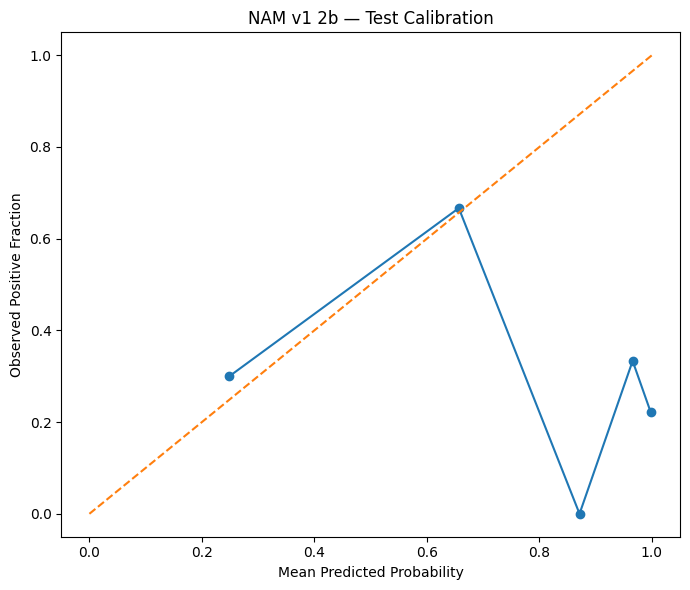


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
4,speech__range_ratio_intensity_db,speech,1.344390,0.316797,-1.844565
15,speech__mean_b2_loc,speech,1.106951,-0.069490,1.376730
8,speech__cepstral_peak_prominence_mean,speech,0.769191,0.051982,0.699925
7,speech__spectral_tilt,speech,0.755324,0.000079,1.114230
14,speech__std_f2_loc,speech,0.700489,-0.045844,0.728122
3,speech__mean_intensity_db,speech,0.686112,0.299790,0.427616
17,speech__spectral_kurtosis,speech,0.662317,0.086669,0.883057
9,speech__cepstral_peak_prominence_std,speech,0.577495,0.059519,-0.442881
16,speech__spectral_std_dev,speech,0.524431,-0.159182,0.310841
12,speech__std_b1_loc,speech,0.500752,0.000270,0.353121



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


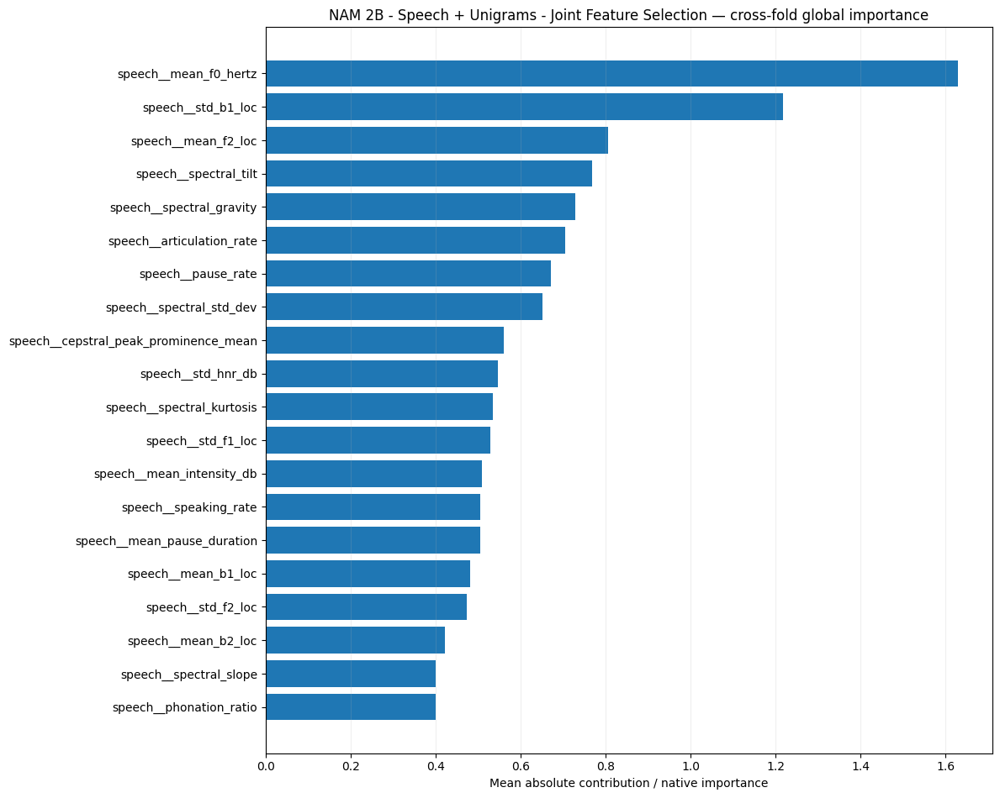


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
11,speech__spectral_kurtosis,3,0.773137,0.053261,0.358046,0.508486,-1.317572,2.944199
19,speech__std_intensity_db,3,0.346562,0.440830,0.314915,1.146784,-0.776035,3.066217
15,speech__std_f0_hertz,4,0.156632,0.287044,0.192657,0.532867,-1.448859,2.319804
9,speech__phonation_ratio,5,0.041766,0.476465,0.405602,0.769309,-2.298891,1.633485
16,speech__std_f1_loc,5,-0.045828,0.644928,0.696048,0.974459,-1.898396,2.051157
18,speech__std_hnr_db,4,-0.081750,0.552158,0.737456,0.941377,-1.332545,3.071081
8,speech__pause_rate,4,-0.090865,0.765066,0.742214,0.959706,-2.115891,1.710399
3,speech__mean_b1_loc,3,-0.091134,0.707105,0.555762,0.962644,-1.699834,2.741646
2,speech__cepstral_peak_prominence_std,5,-0.093649,0.444511,0.722351,0.948766,-1.879563,2.014362
17,speech__std_f2_loc,4,-0.124621,0.677501,0.640230,0.828479,-1.703705,2.586484


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 2b (corresponds to DNAMite 2b)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_2b_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2b",
    dnamite_experiment_id="2b",
    experiment_name='NAM 2B - Speech + Unigrams - Joint Feature Selection',
    task="classification",
    cv_results=experiment_2b_classification_cv,
    final_result=experiment_2b_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2b",
    )
] = NAM_v1_2b_report


### Experiment 2c Speech + Unigram Classification with BCE

In [ ]:
experiment_2c_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2C - "
            "Speech + Unigrams - "
            "Weighted BCE"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2C - Speech + Unigrams - Weighted BCE
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 14 TF-IDF features for classification / unigram using C=5.0
[RAM] before inner fit: 1369.2 MB


[codecarbon WARNING @ 19:58:34] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Class weights: {0: 0.72, 1: 1.6363636363636365}


Epochs ran=21; best epoch=1; best val_loss=1.316594; hit ceiling=False
RAM memory:
  start: 1369.21484375 MB
  absolute peak: 2585.4296875 MB
  incremental peak: 1216.21484375 MB
GPU memory:
  start: 0.0 MB
  end: 0.08154296875 MB
  absolute peak: 0.12548828125 MB
  incremental peak: 0.12548828125 MB
[RAM] after inner cleanup: 2319.1 MB
Selected 15 TF-IDF features for classification / unigram using C=5.0
[RAM] before inner fit: 2320.5 MB
GPU memory at training start: 0.04052734375 MB
Class weights: {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=200; best epoch=200; best val_loss=5.066141; hit ceiling=True
RAM memory:
  start: 2320.45703125 MB
  absolute peak: 3299.65234375 MB
  incremental peak: 979.1953125 MB
GPU memory:
  start: 0.04052734375 MB
  end: 0.164306640625 MB
  absolute peak: 0.206298828125 MB
  incremental peak: 0.165771484375 MB
[RAM] after inner cleanup: 2919.3 MB
Selected 1 TF-IDF features for classification / unigram using C=2.5
[RAM] before inner fit: 2919

In [ ]:
experiment_2c_classification_summary = (
    summarize_nested_cv(
        experiment_2c_classification_cv
    )
)

display(
    experiment_2c_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.481481           0.523026  0.416667   0.312500   
1           2  0.333333           0.490132  0.437500   0.291667   
2           3  0.333333           0.381579  0.307692   0.222222   
3           4  0.703704           0.536184  0.200000   0.500000   
4           5  0.555556           0.467105  0.250000   0.250000   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.625     0.421053  0.460526  0.290986                    1   
1               0.875     0.105263  0.493421  0.346671                    2   
2               0.500     0.263158  0.309211  0.246480                    3   
3               0.125     0.947368  0.605263  0.425228                    2   
4               0.250     0.684211  0.565789  0.335487                    1   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count
0,1,0.481481,0.523026,0.416667,0.312500,0.625,0.421053,0.460526,0.290986,1,None
1,2,0.333333,0.490132,0.437500,0.291667,0.875,0.105263,0.493421,0.346671,2,None
2,3,0.333333,0.381579,0.307692,0.222222,0.500,0.263158,0.309211,0.246480,3,None
3,4,0.703704,0.536184,0.200000,0.500000,0.125,0.947368,0.605263,0.425228,2,None
4,5,0.555556,0.467105,0.250000,0.250000,0.250,0.684211,0.565789,0.335487,1,None


In [ ]:
for result in experiment_2c_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}



In [ ]:
for result in experiment_2c_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

Outer Fold 1: 1 selected unigrams
Outer Fold 2: 2 selected unigrams
Outer Fold 3: 3 selected unigrams
Outer Fold 4: 2 selected unigrams
Outer Fold 5: 1 selected unigrams


In [ ]:
experiment_2c_best_parameters = (
    choose_final_parameters(
        experiment_2c_classification_cv
    )
)

print(
    "Experiment 2C best parameters:"
)

print(
    experiment_2c_best_parameters
)

Experiment 2C best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_2c_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_2c_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 1 TF-IDF features for classification / unigram using C=2.5
GPU memory at training start: 4.7958984375 MB
Class weights: {0: 0.7105263157894737, 1: 1.6875}
Epochs ran=200; best epoch=200; best val_loss=2.096959; hit ceiling=True
RAM memory:
  start: 24506.0390625 MB
  absolute peak: 24679.46875 MB
  incremental peak: 173.4296875 MB
GPU memory:
  start: 4.7958984375 MB
  end: 4.895751953125 MB
  absolute peak: 4.9267578125 MB
  incremental peak: 0.130859375 MB
Best training epochs: 200
Selected 4 TF-IDF features for classification / unigram using C=2.5
RAM memory:
  start: 24628.98828125 MB
  absolute peak: 25067.41015625 MB
  incremental peak: 438.421875 MB

FINAL TEST METRICS
{'accuracy': 0.5869565217391305, 'balanced_accuracy': np.float64(0.5825892857142857), 'f1': 0.45714285714285713, 'precision': 0.38095238095238093, 'recall_sensitivity': 0.5714285714285714, 'specificity': 0.59375, 'roc_auc': np.float64(0.5714285714285714), 'pr_auc': np.float64(0.37154320707709454)}


In [ ]:
experiment_2c_classification_final[
    "metrics"
]

{'accuracy': 0.5869565217391305,
 'balanced_accuracy': np.float64(0.5825892857142857),
 'f1': 0.45714285714285713,
 'precision': 0.38095238095238093,
 'recall_sensitivity': 0.5714285714285714,
 'specificity': 0.59375,
 'roc_auc': np.float64(0.5714285714285714),
 'pr_auc': np.float64(0.37154320707709454)}

In [ ]:
experiment_2c_classification_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.1,
 'feature_dropout': 0.0,
 'learning_rate': 0.0005,
 'num_units': 32,
 'shallow': True}

#### NAM v1 Experiment 2c — DNAMite-parity outputs (maps to DNAMite 2e)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 2c — NAM 2C - Speech + Unigrams - Weighted BCE
DNAMite reference experiment: 2e

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.481481,0.523026,0.416667,0.312500,0.625,0.421053,0.460526,0.290986,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,200,200,True
1,2,0.333333,0.490132,0.437500,0.291667,0.875,0.105263,0.493421,0.346671,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,None,200,200,True
2,3,0.333333,0.381579,0.307692,0.222222,0.500,0.263158,0.309211,0.246480,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",3,None,200,200,True
3,4,0.703704,0.536184,0.200000,0.500000,0.125,0.947368,0.605263,0.425228,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,None,200,200,True
4,5,0.555556,0.467105,0.250000,0.250000,0.250,0.684211,0.565789,0.335487,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,122,142,False



CV Mean ± SD


,mean,sd
accuracy,0.481481,0.157135
balanced_accuracy,0.479605,0.061161
f1,0.322372,0.103167
precision,0.315278,0.109096
recall_sensitivity,0.475000,0.298433
specificity,0.484211,0.335771
roc_auc,0.486842,0.114613
pr_auc,0.328970,0.066837
selected_text_count,1.800000,0.836660
best_epoch,184.400000,34.882660



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,1,79.240365,6662.468750,6932.718750,270.250000,0.143555,NaN,0.873291,0.973145,1.016846,tensorflow,5569,0.255325
1,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,2,81.159585,10212.457031,10510.609375,298.152344,0.146484,NaN,1.762695,1.864258,1.909180,tensorflow,5761,0.264908
2,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,3,82.260173,15542.105469,15881.902344,339.796875,0.136230,NaN,2.822021,2.925049,2.958252,tensorflow,2977,0.260818
3,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,4,80.821190,20126.992188,20329.703125,202.710938,0.133301,NaN,3.832031,3.933594,3.965332,tensorflow,2881,0.253189
4,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,5,72.941584,24278.128906,24534.707031,256.578125,0.115479,NaN,4.739746,4.824219,4.855225,tensorflow,2785,0.245560



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,1,0.002516,0.001185
1,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,2,0.002576,0.001213
2,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,3,0.002607,0.001227
3,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,4,0.002565,0.001208
4,NAM v1,NAM 2C - Speech + Unigrams - Weighted BCE,classification,5,0.002313,0.001089



Final Test Metrics
{'accuracy': 0.5869565217391305, 'balanced_accuracy': np.float64(0.5825892857142857), 'f1': 0.45714285714285713, 'precision': 0.38095238095238093, 'recall_sensitivity': 0.5714285714285714, 'specificity': 0.59375, 'roc_auc': np.float64(0.5714285714285714), 'pr_auc': np.float64(0.37154320707709454)}

Final Model Resource Summary
{'train_seconds': 66.36261717600064, 'start_ram_mb': 24628.98828125, 'peak_ram_mb': 25067.41015625, 'incremental_peak_ram_mb': 438.421875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.002282664895154773, 'training_co2_kg': 0.0010746398273356495}


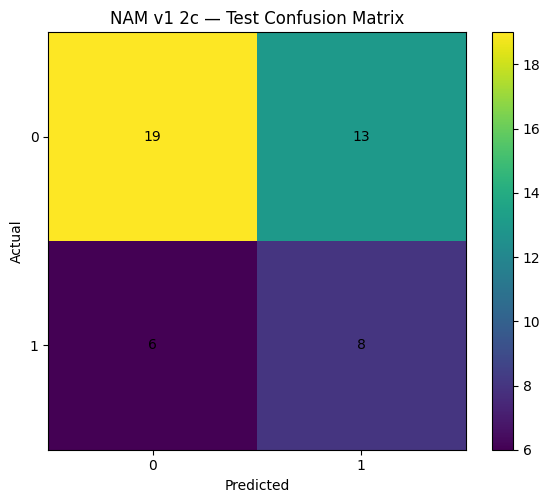

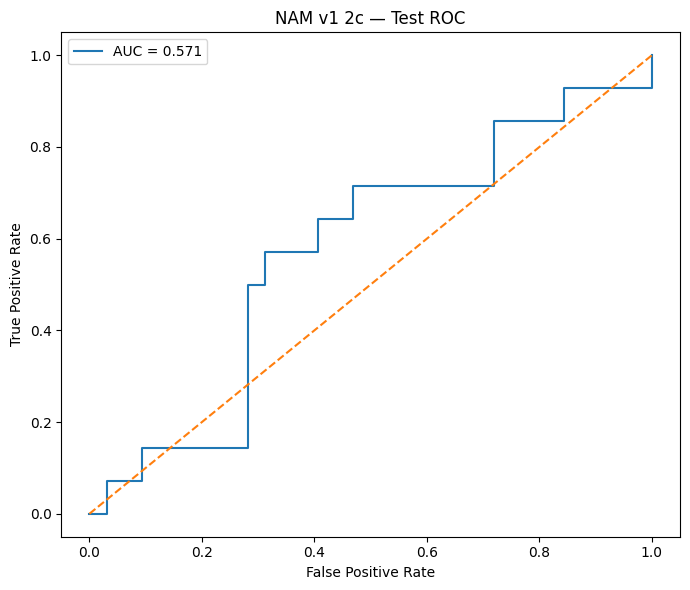

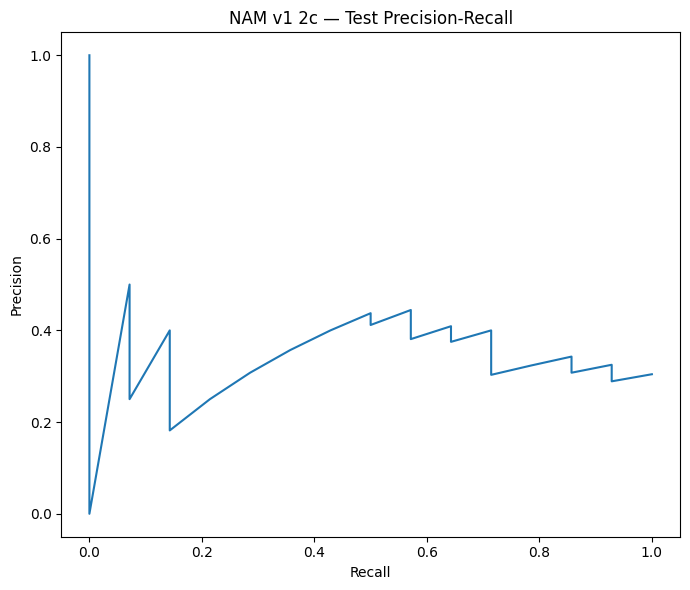

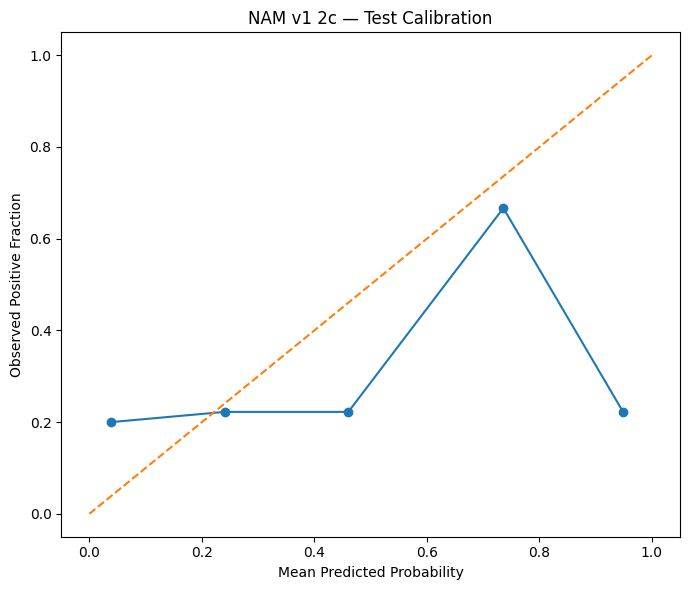


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
14,speech__cepstral_peak_prominence_mean,speech,1.120742,-0.089802,0.944934
0,speech__speaking_rate,speech,0.753783,-0.068538,-1.249195
25,speech__spectral_std_dev,speech,0.744052,0.246698,-0.898894
10,speech__mean_hnr_db,speech,0.731904,-0.043929,0.637924
11,speech__std_hnr_db,speech,0.723212,-0.248341,1.321366
22,speech__mean_b2_loc,speech,0.709511,0.096218,1.217303
6,speech__std_f0_hertz,speech,0.695738,-0.052639,-0.856383
3,speech__pause_rate,speech,0.693563,0.042272,-1.310878
21,speech__std_f2_loc,speech,0.675161,-0.071845,0.930728
23,speech__std_b2_loc,speech,0.659624,0.065473,-0.565785



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_2C_-_Speech_Unigrams_-_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


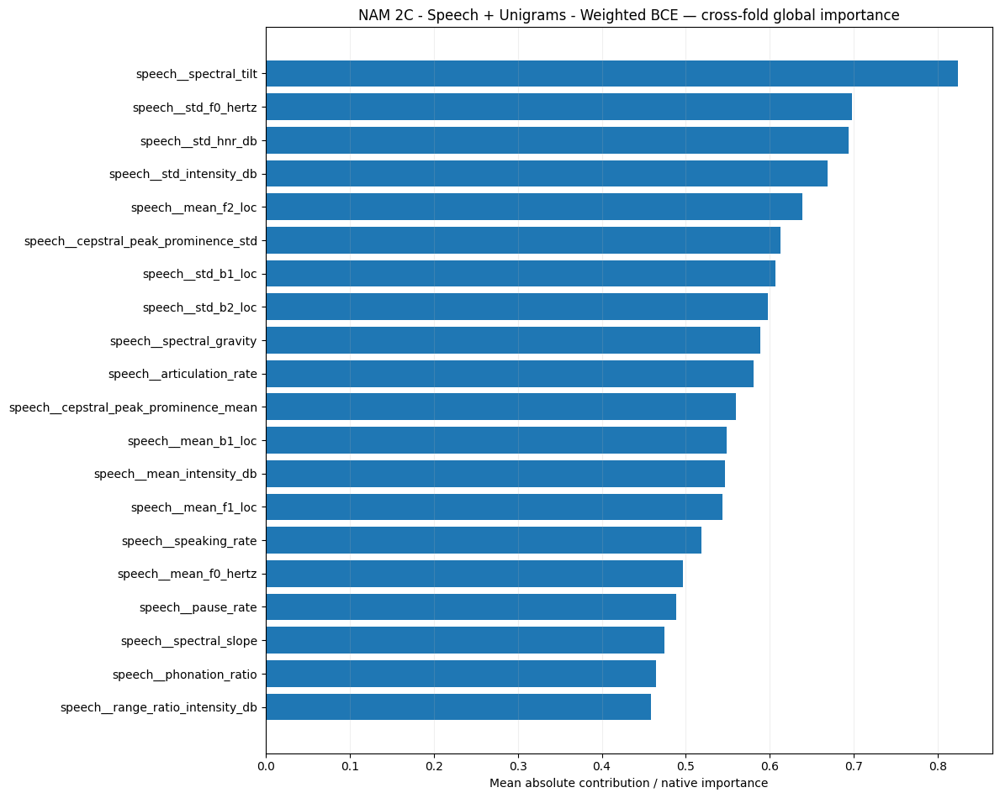


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
12,speech__phonation_ratio,5,0.517552,0.202045,0.415079,0.825238,-2.298891,1.633485
23,speech__std_f0_hertz,5,0.452958,0.312090,0.594282,0.824613,-1.441116,2.275466
1,speech__cepstral_peak_prominence_mean,5,0.388361,0.542493,0.469028,0.632438,-2.021945,1.970126
13,speech__range_ratio_intensity_db,5,0.358129,0.315193,0.487788,0.971609,-1.038354,0.812457
14,speech__speaking_rate,5,0.296018,0.647095,0.598846,0.731192,-2.195560,1.598015
20,speech__spectral_tilt,5,0.251231,0.837317,0.708909,0.937585,-2.104152,2.179019
19,speech__spectral_std_dev,5,0.224164,0.431652,0.382883,0.814997,-1.666552,1.799793
7,speech__mean_f2_loc,5,0.160580,0.686457,0.714501,0.917201,-2.080074,2.188417
22,speech__std_b2_loc,5,0.127047,0.668523,0.731169,1.004966,-1.488311,2.377967
18,speech__spectral_slope,5,0.085647,0.595064,0.544012,0.876180,-2.240396,1.817583


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_2C_-_Speech_Unigrams_-_Weighted_BCE.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 2c (corresponds to DNAMite 2e)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_2c_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2c",
    dnamite_experiment_id="2e",
    experiment_name='NAM 2C - Speech + Unigrams - Weighted BCE',
    task="classification",
    cv_results=experiment_2c_classification_cv,
    final_result=experiment_2c_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2c",
    )
] = NAM_v1_2c_report


### Experiment 2d Speech + Unigram Regression

In [ ]:
experiment_2d_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2D - "
            "Speech + Unigrams - "
            "Regression Baseline"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2D - Speech + Unigrams - Regression Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 1369.7 MB


[codecarbon WARNING @ 21:25:33] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=82.084641; hit ceiling=True
RAM memory:
  start: 1369.67578125 MB
  absolute peak: 3499.01953125 MB
  incremental peak: 2129.34375 MB
GPU memory:
  start: 0.0 MB
  end: 0.21240234375 MB
  absolute peak: 0.308837890625 MB
  incremental peak: 0.308837890625 MB
[RAM] after inner cleanup: 3105.9 MB
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 3106.6 MB
GPU memory at training start: 0.12158203125 MB
Epochs ran=200; best epoch=200; best val_loss=269.924133; hit ceiling=True
RAM memory:
  start: 3106.5703125 MB
  absolute peak: 5155.5625 MB
  incremental peak: 2048.9921875 MB
GPU memory:
  start: 0.12158203125 MB
  end: 0.33251953125 MB
  absolute peak: 0.419921875 MB
  incremental peak: 0.29833984375 MB
[RAM] after inner cleanup: 4347.8 MB
Selected 59 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 4348.3 MB
GPU memory at training start: 0.24072265625 MB
Epochs

/tmp/ipykernel_761908/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 7.830658985508813, 'rmse': np.float64(9.704411322956274), 'r2': -1.9935472120961837, 'spearman_rho': np.float64(-0.16922289514808442), 'spearman_p': np.float64(0.3987752697683055), 'exact_accuracy': np.float64(0.0), 'within_1': np.float64(0.037037037037037035), 'within_2': np.float64(0.14814814814814814), 'within_3': np.float64(0.14814814814814814)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2D_-_Speech_Unigrams_-_Regression_Baseline/fold_03/model.weights.h5

Outer Fold 4/5
Selected 68 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 37186.8 MB
GPU memory at training start: 4.609375 MB
Epochs ran=200; best epoch=200; best val_loss=67.540451; hit ceiling=True
RAM memory:
  start: 37186.76953125 MB
  absolute peak: 38294.11328125 MB
  incremental peak: 1107.34375 MB
GPU memory:
  start: 4.609375 MB
  end: 4.82373046875 MB
  absolute peak: 4.91259765625 MB
  incremental pe

/tmp/ipykernel_761908/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 10.553820985334891, 'rmse': np.float64(12.168348490562948), 'r2': -4.688947292932207, 'spearman_rho': np.float64(0.030637461957307113), 'spearman_p': np.float64(0.8794241856013623), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.07407407407407407), 'within_3': np.float64(0.14814814814814814)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2D_-_Speech_Unigrams_-_Regression_Baseline/fold_04/model.weights.h5

Outer Fold 5/5
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 48292.7 MB
GPU memory at training start: 6.11962890625 MB
Epochs ran=200; best epoch=200; best val_loss=52.538471; hit ceiling=True
RAM memory:
  start: 48292.703125 MB
  absolute peak: 49431.15234375 MB
  incremental peak: 1138.44921875 MB
GPU memory:
  start: 6.11962890625 MB
  end: 6.33056640625 MB
  absolute peak: 6.417724609375 MB
  in

/tmp/ipykernel_761908/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 12.957694618790239, 'rmse': np.float64(14.33884874732251), 'r2': -5.4980613586046045, 'spearman_rho': np.float64(-0.052712646360388644), 'spearman_p': np.float64(0.7939972055043253), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.0)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2D_-_Speech_Unigrams_-_Regression_Baseline/fold_05/model.weights.h5


In [ ]:
experiment_2d_regression_summary = (
    summarize_nested_cv(
        experiment_2d_regression_cv
    )
)

display(
    experiment_2d_regression_summary
)

   outer_fold        mae       rmse         r2  spearman_rho  spearman_p  \
0           1  24.989140  25.580550 -22.599077      0.267913    0.176665   
1           2  24.203311  25.203776 -15.278224     -0.036504    0.856554   
2           3   7.830659   9.704411  -1.993547     -0.169223    0.398775   
3           4  10.553821  12.168348  -4.688947      0.030637    0.879424   
4           5  12.957695  14.338849  -5.498061     -0.052713    0.793997   

   exact_accuracy  within_1  within_2  within_3  selected_text_count  \
0        0.074074  0.000000  0.000000  0.000000                   96   
1        0.185185  0.000000  0.000000  0.000000                  100   
2        0.000000  0.037037  0.148148  0.148148                  102   
3        0.148148  0.000000  0.074074  0.148148                   89   
4        0.148148  0.000000  0.000000  0.000000                   95   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3         

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,24.989140,25.580550,-22.599077,0.267913,0.176665,0.074074,0.000000,0.000000,0.000000,96,None
1,2,24.203311,25.203776,-15.278224,-0.036504,0.856554,0.185185,0.000000,0.000000,0.000000,100,None
2,3,7.830659,9.704411,-1.993547,-0.169223,0.398775,0.000000,0.037037,0.148148,0.148148,102,None
3,4,10.553821,12.168348,-4.688947,0.030637,0.879424,0.148148,0.000000,0.074074,0.148148,89,None
4,5,12.957695,14.338849,-5.498061,-0.052713,0.793997,0.148148,0.000000,0.000000,0.000000,95,None


In [ ]:
for result in experiment_2d_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}



In [ ]:
for result in experiment_2d_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

Outer Fold 1: 96 selected unigrams
Outer Fold 2: 100 selected unigrams
Outer Fold 3: 102 selected unigrams
Outer Fold 4: 89 selected unigrams
Outer Fold 5: 95 selected unigrams


In [ ]:
experiment_2d_best_parameters = (
    choose_final_parameters(
        experiment_2d_regression_cv
    )
)

print(
    "Experiment 2D best parameters:"
)

print(
    experiment_2d_best_parameters
)

Experiment 2D best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}


In [ ]:
EXPERIMENT_2D_NAME = (
    "NAM 2D - "
    "Speech + Unigrams - "
    "Regression Baseline"
)

experiment_2d_regression_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_2d_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 91 TF-IDF features for regression / unigram using alpha=0.0025
GPU memory at training start: 7.631103515625 MB
Epochs ran=200; best epoch=200; best val_loss=250.866272; hit ceiling=True
RAM memory:
  start: 59145.7890625 MB
  absolute peak: 60218.0546875 MB
  incremental peak: 1072.265625 MB
GPU memory:
  start: 7.631103515625 MB
  end: 7.884765625 MB
  absolute peak: 8.002197265625 MB
  incremental peak: 0.37109375 MB
Best training epochs: 200
Selected 115 TF-IDF features for regression / unigram using alpha=0.0025
RAM memory:
  start: 60286.2734375 MB
  absolute peak: 62453.375 MB
  incremental peak: 2167.1015625 MB

FINAL TEST METRICS
{'mae': 16.895416757334832, 'rmse': np.float64(18.473069982323203), 'r2': -7.303654852565533, 'spearman_rho': np.float64(-0.15047141684026322), 'spearman_p': np.float64(0.3182024751185349), 'exact_accuracy': np.float64(0.0), 'within_1': np.float64(0.0), 'within_2': np.float64(0.021739130434782608), 'within_3': np.float64(0.021739130434782608)}

In [ ]:
experiment_2d_regression_final[
    "metrics"
]

{'mae': 16.895416757334832,
 'rmse': np.float64(18.473069982323203),
 'r2': -7.303654852565533,
 'spearman_rho': np.float64(-0.15047141684026322),
 'spearman_p': np.float64(0.3182024751185349),
 'exact_accuracy': np.float64(0.0),
 'within_1': np.float64(0.0),
 'within_2': np.float64(0.021739130434782608),
 'within_3': np.float64(0.021739130434782608)}

In [ ]:
experiment_2d_regression_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.1,
 'feature_dropout': 0.0,
 'learning_rate': 0.001,
 'num_units': 32,
 'shallow': True}

In [ ]:
experiment_2d_regression_final[
    "best_epoch"
]

200

In [ ]:
selected_text_indices = (
    experiment_2d_regression_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

Selected unigrams: 115


#### NAM v1 Experiment 2d — DNAMite-parity outputs (maps to DNAMite 2c)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 2d — NAM 2D - Speech + Unigrams - Regression Baseline
DNAMite reference experiment: 2c

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,24.989140,25.580550,-22.599077,0.267913,0.176665,0.074074,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",96,None,200,200,True
1,2,24.203311,25.203776,-15.278224,-0.036504,0.856554,0.185185,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",100,None,200,200,True
2,3,7.830659,9.704411,-1.993547,-0.169223,0.398775,0.000000,0.037037,0.148148,0.148148,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",102,None,200,200,True
3,4,10.553821,12.168348,-4.688947,0.030637,0.879424,0.148148,0.000000,0.074074,0.148148,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",89,None,200,200,True
4,5,12.957695,14.338849,-5.498061,-0.052713,0.793997,0.148148,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",95,None,200,200,True



CV Mean ± SD


,mean,sd
mae,16.106925,7.963925
rmse,17.399187,7.479693
r2,-10.011571,8.648320
spearman_rho,0.008022,0.162128
spearman_p,0.621083,0.315838
exact_accuracy,0.111111,0.074074
within_1,0.007407,0.016563
within_2,0.044444,0.066254
within_3,0.059259,0.081144
selected_text_count,96.400000,5.029911



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,1,258.070859,13014.519531,14490.250000,1475.730469,0.385010,NaN,1.365967,1.628174,1.750977,tensorflow,11905,1.021591
1,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,2,289.939598,24224.851562,26040.964844,1816.113281,0.426270,NaN,2.895996,3.165039,3.322266,tensorflow,24577,1.105156
2,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,3,277.668221,35870.296875,37458.320312,1588.023438,0.400391,NaN,4.463867,4.736328,4.864258,tensorflow,12481,1.073853
3,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,4,270.677211,46952.222656,48636.085938,1683.863281,0.394287,NaN,5.983643,6.233887,6.377930,tensorflow,22465,1.006935
4,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,5,266.512235,57890.273438,59547.996094,1657.722656,0.381348,NaN,7.490723,7.751221,7.872070,tensorflow,11809,1.013962



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,1,0.008067,0.002159
1,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,2,0.009056,0.002424
2,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,3,0.008678,0.002322
3,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,4,0.008456,0.002263
4,NAM v1,NAM 2D - Speech + Unigrams - Regression Baseline,regression,5,0.008336,0.002231



Final Test Metrics
{'mae': 16.895416757334832, 'rmse': np.float64(18.473069982323203), 'r2': -7.303654852565533, 'spearman_rho': np.float64(-0.15047141684026322), 'spearman_p': np.float64(0.3182024751185349), 'exact_accuracy': np.float64(0.0), 'within_1': np.float64(0.0), 'within_2': np.float64(0.021739130434782608), 'within_3': np.float64(0.021739130434782608)}

Final Model Resource Summary
{'train_seconds': 263.938761428999, 'start_ram_mb': 60286.2734375, 'peak_ram_mb': 62453.375, 'incremental_peak_ram_mb': 2167.1015625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.008259419091411483, 'training_co2_kg': 0.002210402256081724}


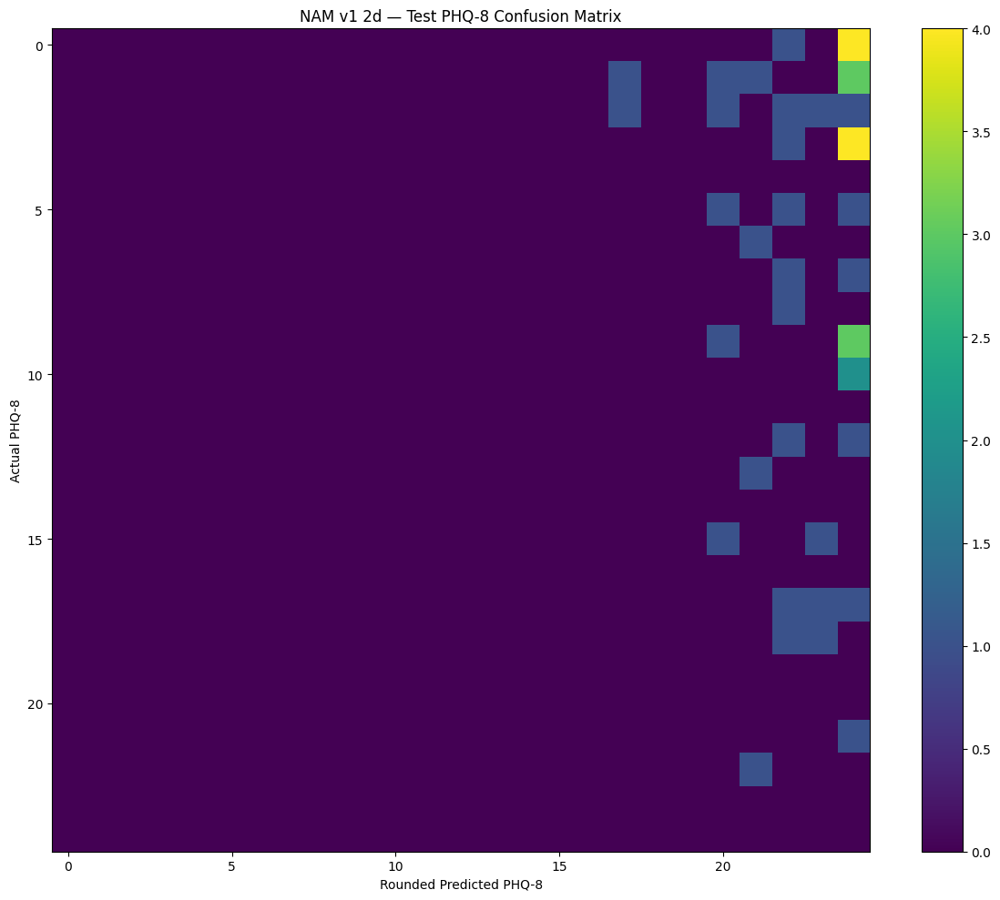

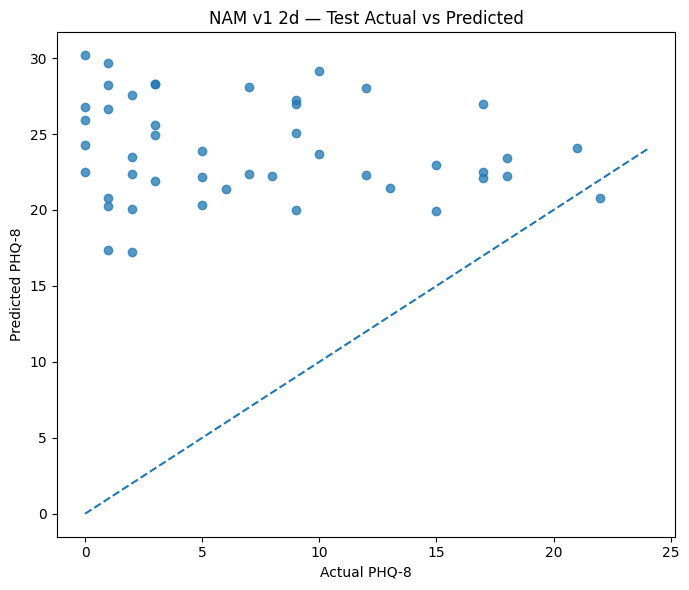


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
16,speech__mean_f1_loc,speech,1.366787,0.003609,1.376389
20,speech__mean_f2_loc,speech,0.879500,0.119368,0.965216
0,speech__speaking_rate,speech,0.780449,0.177151,1.705274
6,speech__std_f0_hertz,speech,0.756575,0.051531,1.239910
11,speech__std_hnr_db,speech,0.719003,0.101908,-0.705776
18,speech__mean_b1_loc,speech,0.604419,-0.031743,-0.406133
7,speech__mean_intensity_db,speech,0.519868,0.107557,-0.673418
25,speech__spectral_std_dev,speech,0.510414,-0.029892,0.456653
1,speech__articulation_rate,speech,0.492222,0.030711,1.022558
10,speech__mean_hnr_db,speech,0.467987,-0.008361,0.205710



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_2D_-_Speech_Unigrams_-_Regression_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


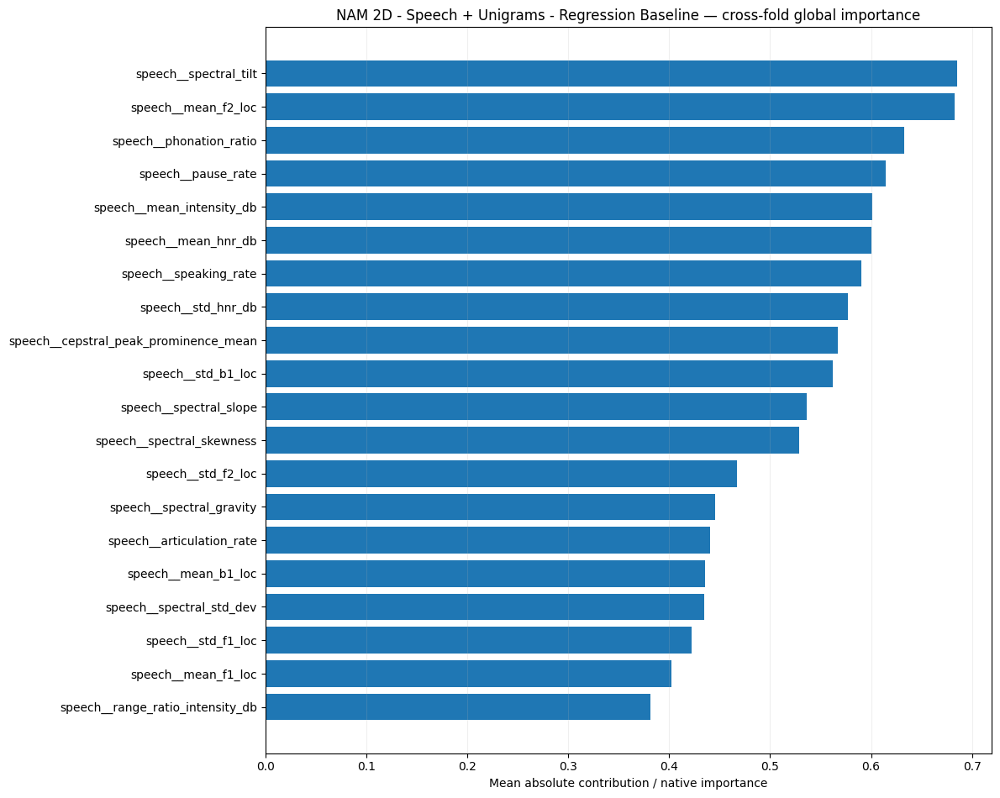

/tmp/ipykernel_761908/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_761908/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_761908/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_761908/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_761908/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_761908/1559648166.py:694: ConstantInputWarning: An input arr


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
75,text__has,2,0.957747,NaN,0.097776,0.187427,0.000000,0.052720
99,text__moved,2,0.954675,NaN,0.115339,0.234535,0.000000,0.067073
81,text__influence,2,0.954386,NaN,0.054651,0.119854,0.000000,0.081682
83,text__interesting,2,0.933082,NaN,0.279567,0.460348,0.000000,0.100147
60,text__disturbing,2,0.910480,NaN,0.160693,0.277703,0.000000,0.107839
65,text__eventually,2,0.908032,NaN,0.132921,0.240965,0.000000,0.082280
86,text__kind,2,0.893984,NaN,0.040434,0.144672,0.000000,0.070170
58,text__depressed,4,0.890405,0.074065,0.084517,0.156089,0.000000,0.063315
117,text__seem,2,0.868580,NaN,0.068596,0.147923,0.000000,0.073322
101,text__needed,2,0.857260,NaN,0.255616,0.327792,0.000000,0.074862


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_2D_-_Speech_Unigrams_-_Regression_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 2d (corresponds to DNAMite 2c)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_2d_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2d",
    dnamite_experiment_id="2c",
    experiment_name='NAM 2D - Speech + Unigrams - Regression Baseline',
    task="regression",
    cv_results=experiment_2d_regression_cv,
    final_result=experiment_2d_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2d",
    )
] = NAM_v1_2d_report


### Experiment 2e Speech + Unigram Regression with Feature Selection

In [ ]:
experiment_2e_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2E - "
            "Speech + Unigrams - "
            "Joint Feature Selection"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2E - Speech + Unigrams - Joint Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 49 features, alpha=0.01
[RAM] before inner fit: 1369.3 MB


[codecarbon WARNING @ 05:30:44] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=49.591309; hit ceiling=True
RAM memory:
  start: 1369.32421875 MB
  absolute peak: 2935.30078125 MB
  incremental peak: 1565.9765625 MB
GPU memory:
  start: 0.0 MB
  end: 0.13720703125 MB
  absolute peak: 0.188720703125 MB
  incremental peak: 0.188720703125 MB
[RAM] after inner cleanup: 2460.4 MB
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 42 features, alpha=0.01
[RAM] before inner fit: 2461.1 MB
GPU memory at training start: 0.08935546875 MB
Epochs ran=200; best epoch=200; best val_loss=85.071114; hit ceiling=True
RAM memory:
  start: 2461.13671875 MB
  absolute peak: 3118.48046875 MB
  incremental peak: 657.34375 MB
GPU memory:
  start: 0.08935546875 MB
  end: 0.21142578125 MB
  absolute peak: 0.252685546875 MB
  incremental peak: 0.163330078125 MB
[RAM] after inner cleanup: 2892.0 MB
Selected 59 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 48 features, alpha=0.0

/tmp/ipykernel_3080169/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 11.433346624727603, 'rmse': np.float64(13.264133551836801), 'r2': -4.592493552987785, 'spearman_rho': np.float64(0.008583770043743413), 'spearman_p': np.float64(0.9661059318310184), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.037037037037037035), 'within_2': np.float64(0.07407407407407407), 'within_3': np.float64(0.1111111111111111)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selection/fold_03/model.weights.h5

Outer Fold 4/5
Selected 68 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 51 features, alpha=0.01
[RAM] before inner fit: 18994.0 MB
GPU memory at training start: 3.14697265625 MB
Epochs ran=200; best epoch=200; best val_loss=74.231018; hit ceiling=True
RAM memory:
  start: 18993.95703125 MB
  absolute peak: 19685.7890625 MB
  incremental peak: 691.83203125 MB
GPU memory:
  start: 3.14697265625 MB
  

/tmp/ipykernel_3080169/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 7.646477756676851, 'rmse': np.float64(9.09617385783887), 'r2': -2.178967860394793, 'spearman_rho': np.float64(-0.12561359402495917), 'spearman_p': np.float64(0.5324287720293416), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.1111111111111111), 'within_2': np.float64(0.14814814814814814), 'within_3': np.float64(0.18518518518518517)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selection/fold_04/model.weights.h5

Outer Fold 5/5
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 47 features, alpha=0.01
[RAM] before inner fit: 25041.4 MB
GPU memory at training start: 4.1982421875 MB
Epochs ran=200; best epoch=200; best val_loss=42.900982; hit ceiling=True
RAM memory:
  start: 25041.3984375 MB
  absolute peak: 25655.53125 MB
  incremental peak: 614.1328125 MB
GPU memory:
  start: 4.1982421875 MB
  end: 4.328

/tmp/ipykernel_3080169/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 5.127352621820238, 'rmse': np.float64(6.304777791767941), 'r2': -0.2563041953352423, 'spearman_rho': np.float64(0.24180394173457348), 'spearman_p': np.float64(0.22431694845624842), 'exact_accuracy': np.float64(0.07407407407407407), 'within_1': np.float64(0.14814814814814814), 'within_2': np.float64(0.25925925925925924), 'within_3': np.float64(0.2962962962962963)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selection/fold_05/model.weights.h5


In [ ]:
experiment_2e_regression_summary = (
    summarize_nested_cv(
        experiment_2e_regression_cv
    )
)

display(
    experiment_2e_regression_summary
)

   outer_fold        mae       rmse        r2  spearman_rho  spearman_p  \
0           1  11.896101  13.396478 -5.472269     -0.133497    0.506799   
1           2   9.459506  11.513915 -2.397205     -0.016871    0.933435   
2           3  11.433347  13.264134 -4.592494      0.008584    0.966106   
3           4   7.646478   9.096174 -2.178968     -0.125614    0.532429   
4           5   5.127353   6.304778 -0.256304      0.241804    0.224317   

   exact_accuracy  within_1  within_2  within_3  selected_text_count  \
0        0.074074  0.000000  0.000000  0.074074                   96   
1        0.222222  0.074074  0.222222  0.222222                  100   
2        0.148148  0.037037  0.074074  0.111111                  102   
3        0.148148  0.111111  0.148148  0.185185                   89   
4        0.074074  0.148148  0.259259  0.296296                   95   

   joint_selected_count  
0                    59  
1                    46  
2                    56  
3           

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,11.896101,13.396478,-5.472269,-0.133497,0.506799,0.074074,0.000000,0.000000,0.074074,96,59
1,2,9.459506,11.513915,-2.397205,-0.016871,0.933435,0.222222,0.074074,0.222222,0.222222,100,46
2,3,11.433347,13.264134,-4.592494,0.008584,0.966106,0.148148,0.037037,0.074074,0.111111,102,56
3,4,7.646478,9.096174,-2.178968,-0.125614,0.532429,0.148148,0.111111,0.148148,0.185185,89,62
4,5,5.127353,6.304778,-0.256304,0.241804,0.224317,0.074074,0.148148,0.259259,0.296296,95,60


In [ ]:
for result in experiment_2e_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}



In [ ]:
for result in experiment_2e_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        "Selected unigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

Outer Fold 1
Selected unigram features: 96
Final jointly selected features: 59

Outer Fold 2
Selected unigram features: 100
Final jointly selected features: 46

Outer Fold 3
Selected unigram features: 102
Final jointly selected features: 56

Outer Fold 4
Selected unigram features: 89
Final jointly selected features: 62

Outer Fold 5
Selected unigram features: 95
Final jointly selected features: 60



In [ ]:
experiment_2e_best_parameters = (
    choose_final_parameters(
        experiment_2e_regression_cv
    )
)

print(
    "Experiment 2E best parameters:"
)

print(
    experiment_2e_best_parameters
)

Experiment 2E best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_2e_regression_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_2e_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 91 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 54 features, alpha=0.01
GPU memory at training start: 5.264892578125 MB
Epochs ran=200; best epoch=200; best val_loss=136.153366; hit ceiling=True
RAM memory:
  start: 30563.47265625 MB
  absolute peak: 31020.58984375 MB
  incremental peak: 457.1171875 MB
GPU memory:
  start: 5.264892578125 MB
  end: 5.407470703125 MB
  absolute peak: 5.462158203125 MB
  incremental peak: 0.197265625 MB
Best training epochs: 200
Selected 115 TF-IDF features for regression / unigram using alpha=0.0025
Joint selection: 68 features, alpha=0.01
RAM memory:
  start: 31001.3671875 MB
  absolute peak: 31987.6015625 MB
  incremental peak: 986.234375 MB

FINAL TEST METRICS
{'mae': 5.773068720879762, 'rmse': np.float64(7.257765079450992), 'r2': -0.28173118702662503, 'spearman_rho': np.float64(0.001733113809760333), 'spearman_p': np.float64(0.9908795349963917), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np

In [ ]:
experiment_2e_regression_final[
    "metrics"
]

{'mae': 5.773068720879762,
 'rmse': np.float64(7.257765079450992),
 'r2': -0.28173118702662503,
 'spearman_rho': np.float64(0.001733113809760333),
 'spearman_p': np.float64(0.9908795349963917),
 'exact_accuracy': np.float64(0.08695652173913043),
 'within_1': np.float64(0.10869565217391304),
 'within_2': np.float64(0.21739130434782608),
 'within_3': np.float64(0.2826086956521739)}

In [ ]:
experiment_2e_regression_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.1,
 'feature_dropout': 0.0,
 'learning_rate': 0.0005,
 'num_units': 32,
 'shallow': True}

In [ ]:
# Number of first stage selected unigrams

selected_text_indices = (
    experiment_2e_regression_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

Selected unigrams: 115


In [ ]:
# Number of final jointly selected features

joint_selected_indices = (
    experiment_2e_regression_final[
        "joint_selected_indices"
    ]
)

print(
    "Final jointly selected features:",
    len(
        joint_selected_indices
    )
)

Final jointly selected features: 68


#### NAM v1 Experiment 2e — DNAMite-parity outputs (maps to DNAMite 2d)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 2e — NAM 2E - Speech + Unigrams - Joint Feature Selection
DNAMite reference experiment: 2d

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,11.896101,13.396478,-5.472269,-0.133497,0.506799,0.074074,0.000000,0.000000,0.074074,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",96,59,200,200,True
1,2,9.459506,11.513915,-2.397205,-0.016871,0.933435,0.222222,0.074074,0.222222,0.222222,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",100,46,200,200,True
2,3,11.433347,13.264134,-4.592494,0.008584,0.966106,0.148148,0.037037,0.074074,0.111111,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",102,56,200,200,True
3,4,7.646478,9.096174,-2.178968,-0.125614,0.532429,0.148148,0.111111,0.148148,0.185185,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",89,62,200,200,True
4,5,5.127353,6.304778,-0.256304,0.241804,0.224317,0.074074,0.148148,0.259259,0.296296,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",95,60,200,200,True



CV Mean ± SD


,mean,sd
mae,9.112557,2.796685
rmse,10.715096,3.016510
r2,-2.979448,2.074329
spearman_rho,-0.005119,0.151902
spearman_p,0.632617,0.313960
exact_accuracy,0.133333,0.061975
within_1,0.074074,0.058561
within_2,0.140741,0.106058
within_3,0.177778,0.088425
selected_text_count,96.400000,5.029911



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,1,133.360620,7606.082031,8404.167969,798.085938,0.210449,NaN,0.926758,1.077881,1.137207,tensorflow,5665,0.492615
1,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,2,110.122712,12508.726562,13253.652344,744.925781,0.175781,NaN,1.978516,2.107422,2.154297,tensorflow,4417,0.386948
2,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,3,131.387421,18579.785156,19088.621094,508.835938,0.202637,NaN,3.055664,3.201660,3.258301,tensorflow,5377,0.467773
3,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,4,143.628593,24491.207031,25193.199219,701.992188,0.218994,NaN,4.102539,4.258789,4.321533,tensorflow,5953,0.515816
4,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,5,140.029305,29944.933594,30768.808594,823.875000,0.213623,NaN,5.170654,5.323486,5.384277,tensorflow,5761,0.500557



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,1,0.004237,0.001995
1,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,2,0.003498,0.001647
2,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,3,0.004175,0.001966
3,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,4,0.004556,0.000018
4,NAM v1,NAM 2E - Speech + Unigrams - Joint Feature Sel...,regression,5,0.004449,0.002094



Final Test Metrics
{'mae': 5.773068720879762, 'rmse': np.float64(7.257765079450992), 'r2': -0.28173118702662503, 'spearman_rho': np.float64(0.001733113809760333), 'spearman_p': np.float64(0.9908795349963917), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.10869565217391304), 'within_2': np.float64(0.21739130434782608), 'within_3': np.float64(0.2826086956521739)}

Final Model Resource Summary
{'train_seconds': 129.11638530899654, 'start_ram_mb': 31001.3671875, 'peak_ram_mb': 31987.6015625, 'incremental_peak_ram_mb': 986.234375, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.00428170963736297, 'training_co2_kg': 0.002015756108206651}


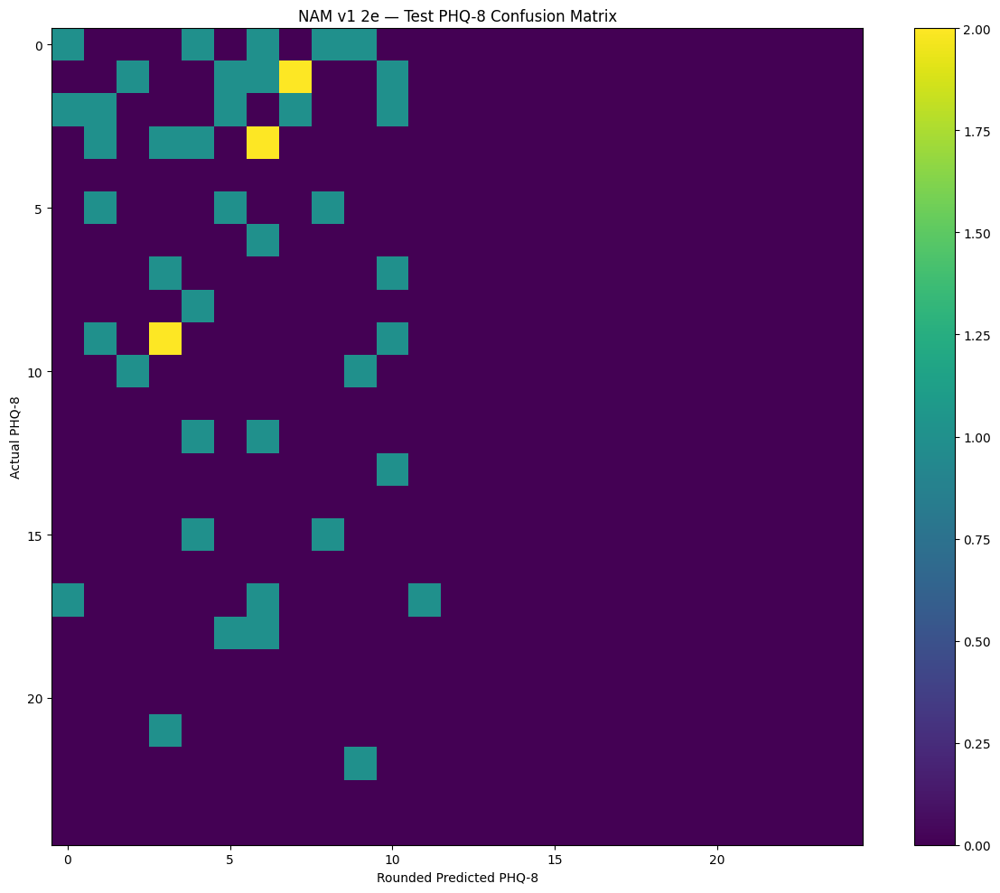

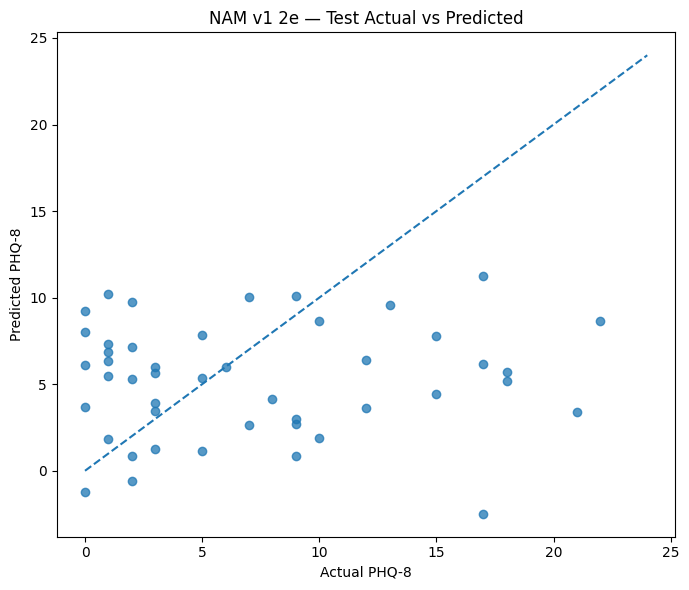


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
7,speech__std_intensity_db,speech,1.133731,0.282558,0.229237
24,speech__spectral_std_dev,speech,0.963437,-0.340802,1.059324
20,speech__std_f2_loc,speech,0.947083,0.023079,-0.855919
16,speech__std_f1_loc,speech,0.943164,0.175056,-0.836308
26,speech__spectral_kurtosis,speech,0.936176,0.167906,0.892178
13,speech__cepstral_peak_prominence_mean,speech,0.830468,0.218737,-1.179914
18,speech__std_b1_loc,speech,0.805917,0.054332,-0.999600
21,speech__mean_b2_loc,speech,0.797774,-0.012932,0.865039
25,speech__spectral_skewness,speech,0.644658,-0.201392,-1.496460
1,speech__articulation_rate,speech,0.551174,-0.031451,-1.342880



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


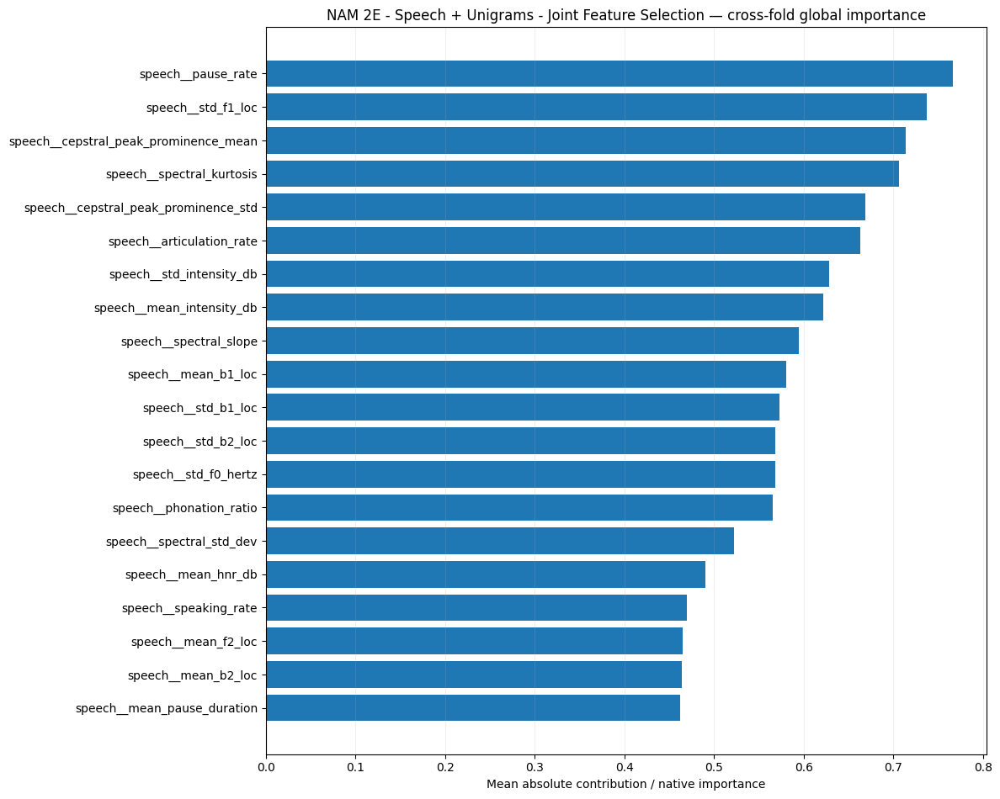

/tmp/ipykernel_3080169/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_3080169/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_3080169/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_3080169/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_3080169/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic



Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
37,text__boyfriend,3,0.943427,NaN,0.136651,0.225859,0.000000,0.092076
48,text__learn,2,0.905682,NaN,0.045346,0.080982,0.000000,0.065453
54,text__she's,2,0.866000,NaN,0.085622,0.155986,0.000000,0.086000
46,text__guilty,2,0.831711,NaN,0.031391,0.059772,0.000000,0.079927
49,text__lives,3,0.720517,0.196601,0.298883,0.417556,0.000000,0.075232
40,text__couldn't,3,0.709634,NaN,0.124450,0.283332,0.000000,0.065477
52,text__needed,2,0.672194,NaN,0.065509,0.110254,0.000000,0.074862
39,text__control,2,0.664916,NaN,0.062844,0.141624,0.000000,0.078981
42,text__depressed,3,0.451689,0.313757,0.086024,0.156963,0.000000,0.063315
31,text__animals,3,0.388593,0.476989,0.178478,0.309449,0.000000,0.076184


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 2e (corresponds to DNAMite 2d)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_2e_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2e",
    dnamite_experiment_id="2d",
    experiment_name='NAM 2E - Speech + Unigrams - Joint Feature Selection',
    task="regression",
    cv_results=experiment_2e_regression_cv,
    final_result=experiment_2e_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2e",
    )
] = NAM_v1_2e_report


In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 2e complete. "
    "Waiting for file writes..."
)

time.sleep(20)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 2e complete. Waiting for file writes...
Disconnecting runtime.


### Experiment 2f Speech + Unigram Regression with LDS

In [ ]:
experiment_2f_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2F - "
            "Speech + Unigrams - LDS"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2F - Speech + Unigrams - LDS
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Selected 65 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 1367.9 MB


[codecarbon WARNING @ 19:04:08] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=651.962585; hit ceiling=True
RAM memory:
  start: 1367.890625 MB
  absolute peak: 3613.51953125 MB
  incremental peak: 2245.62890625 MB
GPU memory:
  start: 0.0 MB
  end: 0.21240234375 MB
  absolute peak: 0.308837890625 MB
  incremental peak: 0.308837890625 MB
[RAM] after inner cleanup: 3070.0 MB
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 3070.5 MB
GPU memory at training start: 0.12158203125 MB
Epochs ran=21; best epoch=1; best val_loss=41.031540; hit ceiling=False
RAM memory:
  start: 3070.49609375 MB
  absolute peak: 4714.90234375 MB
  incremental peak: 1644.40625 MB
GPU memory:
  start: 0.12158203125 MB
  end: 0.288818359375 MB
  absolute peak: 0.37646484375 MB
  incremental peak: 0.2548828125 MB
[RAM] after inner cleanup: 4281.1 MB
Selected 59 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 4281.6 MB
GPU memory at training start: 0.197021484375 MB
E

/tmp/ipykernel_2174/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 14.813990429595664, 'rmse': np.float64(15.918142446134674), 'r2': -7.054387013339655, 'spearman_rho': np.float64(0.1587997458092531), 'spearman_p': np.float64(0.4288609718494798), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.0)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2F_-_Speech_Unigrams_-_LDS/fold_03/model.weights.h5

Outer Fold 4/5
Selected 68 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 37405.1 MB
GPU memory at training start: 4.565673828125 MB
Epochs ran=200; best epoch=200; best val_loss=79.494598; hit ceiling=True
RAM memory:
  start: 37405.10546875 MB
  absolute peak: 38573.05859375 MB
  incremental peak: 1167.953125 MB
GPU memory:
  start: 4.565673828125 MB
  end: 4.780029296875 MB
  absolute peak: 4.869384765625 MB
  incremental peak: 0.3037109375 MB
[RAM] after inn

/tmp/ipykernel_2174/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 15.31250360276964, 'rmse': np.float64(16.210421204934562), 'r2': -9.096183401632487, 'spearman_rho': np.float64(0.23897220326699548), 'spearman_p': np.float64(0.22995773988155543), 'exact_accuracy': np.float64(0.0), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.037037037037037035)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2F_-_Speech_Unigrams_-_LDS/fold_04/model.weights.h5

Outer Fold 5/5
Selected 66 TF-IDF features for regression / unigram using alpha=0.0025
[RAM] before inner fit: 48562.3 MB
GPU memory at training start: 6.119140625 MB
Epochs ran=200; best epoch=200; best val_loss=147.738098; hit ceiling=True
RAM memory:
  start: 48562.27734375 MB
  absolute peak: 49500.734375 MB
  incremental peak: 938.45703125 MB
GPU memory:
  start: 6.119140625 MB
  end: 6.330078125 MB
  absolute peak: 6.417724609375 MB
  incremental peak: 0.298583984375 MB
[RAM] after inner cl

/tmp/ipykernel_2174/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 11.012897897649694, 'rmse': np.float64(12.704279095663798), 'r2': -4.100999638049043, 'spearman_rho': np.float64(-0.11645817219155631), 'spearman_p': np.float64(0.5629438773033186), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.037037037037037035), 'within_2': np.float64(0.037037037037037035), 'within_3': np.float64(0.1111111111111111)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_2F_-_Speech_Unigrams_-_LDS/fold_05/model.weights.h5


In [ ]:
experiment_2f_regression_summary = (
    summarize_nested_cv(
        experiment_2f_regression_cv
    )
)

display(
    experiment_2f_regression_summary
)

   outer_fold        mae       rmse         r2  spearman_rho  spearman_p  \
0           1  27.025101  27.634156 -26.540237     -0.085732    0.670704   
1           2   7.869166  10.101212  -1.614706      0.134357    0.504040   
2           3  14.813990  15.918142  -7.054387      0.158800    0.428861   
3           4  15.312504  16.210421  -9.096183      0.238972    0.229958   
4           5  11.012898  12.704279  -4.101000     -0.116458    0.562944   

   exact_accuracy  within_1  within_2  within_3  selected_text_count  \
0        0.074074  0.000000  0.000000  0.000000                   96   
1        0.148148  0.037037  0.148148  0.222222                  100   
2        0.148148  0.000000  0.000000  0.000000                  102   
3        0.000000  0.000000  0.000000  0.037037                   89   
4        0.148148  0.037037  0.037037  0.111111                   95   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3         

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,27.025101,27.634156,-26.540237,-0.085732,0.670704,0.074074,0.000000,0.000000,0.000000,96,None
1,2,7.869166,10.101212,-1.614706,0.134357,0.504040,0.148148,0.037037,0.148148,0.222222,100,None
2,3,14.813990,15.918142,-7.054387,0.158800,0.428861,0.148148,0.000000,0.000000,0.000000,102,None
3,4,15.312504,16.210421,-9.096183,0.238972,0.229958,0.000000,0.000000,0.000000,0.037037,89,None
4,5,11.012898,12.704279,-4.101000,-0.116458,0.562944,0.148148,0.037037,0.037037,0.111111,95,None


In [ ]:
for result in experiment_2f_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}



In [ ]:
for result in experiment_2f_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

Outer Fold 1: 96 selected unigrams
Outer Fold 2: 100 selected unigrams
Outer Fold 3: 102 selected unigrams
Outer Fold 4: 89 selected unigrams
Outer Fold 5: 95 selected unigrams


In [ ]:
experiment_2f_best_parameters = (
    choose_final_parameters(
        experiment_2f_regression_cv
    )
)

print(
    "Experiment 2F best parameters:"
)

print(
    experiment_2f_best_parameters
)

Experiment 2F best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}


In [ ]:
experiment_2f_regression_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_2f_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 91 TF-IDF features for regression / unigram using alpha=0.0025
GPU memory at training start: 7.630615234375 MB
Epochs ran=200; best epoch=200; best val_loss=42.830036; hit ceiling=True
RAM memory:
  start: 59422.9921875 MB
  absolute peak: 60922.52734375 MB
  incremental peak: 1499.53515625 MB
GPU memory:
  start: 7.630615234375 MB
  end: 7.88427734375 MB
  absolute peak: 8.03125 MB
  incremental peak: 0.400634765625 MB
Best training epochs: 200
Selected 115 TF-IDF features for regression / unigram using alpha=0.0025
RAM memory:
  start: 60789.5234375 MB
  absolute peak: 62799.5625 MB
  incremental peak: 2010.0390625 MB

FINAL TEST METRICS
{'mae': 10.852442868377851, 'rmse': np.float64(12.611422348641922), 'r2': -2.8700740821256145, 'spearman_rho': np.float64(0.13976324937281542), 'spearman_p': np.float64(0.35424276367561747), 'exact_accuracy': np.float64(0.10869565217391304), 'within_1': np.float64(0.021739130434782608), 'within_2': np.float64(0.043478260869565216), 'within_3

In [ ]:
experiment_2f_regression_final[
    "metrics"
]

{'mae': 10.852442868377851,
 'rmse': np.float64(12.611422348641922),
 'r2': -2.8700740821256145,
 'spearman_rho': np.float64(0.13976324937281542),
 'spearman_p': np.float64(0.35424276367561747),
 'exact_accuracy': np.float64(0.10869565217391304),
 'within_1': np.float64(0.021739130434782608),
 'within_2': np.float64(0.043478260869565216),
 'within_3': np.float64(0.10869565217391304)}

In [ ]:
experiment_2f_regression_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.1,
 'feature_dropout': 0.0,
 'learning_rate': 0.001,
 'num_units': 64,
 'shallow': True}

In [ ]:
selected_text_indices = (
    experiment_2f_regression_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

Selected unigrams: 115


#### NAM v1 Experiment 2f — DNAMite-parity outputs (maps to DNAMite 2f)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 2f — NAM 2F - Speech + Unigrams - LDS
DNAMite reference experiment: 2f

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,27.025101,27.634156,-26.540237,-0.085732,0.670704,0.074074,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",96,None,200,200,True
1,2,7.869166,10.101212,-1.614706,0.134357,0.504040,0.148148,0.037037,0.148148,0.222222,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",100,None,200,200,True
2,3,14.813990,15.918142,-7.054387,0.158800,0.428861,0.148148,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",102,None,200,200,True
3,4,15.312504,16.210421,-9.096183,0.238972,0.229958,0.000000,0.000000,0.000000,0.037037,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",89,None,200,200,True
4,5,11.012898,12.704279,-4.101000,-0.116458,0.562944,0.148148,0.037037,0.037037,0.111111,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",95,None,200,200,True



CV Mean ± SD


,mean,sd
mae,15.206732,7.267520
rmse,16.513642,6.703411
r2,-9.681303,9.844751
spearman_rho,0.065988,0.157732
spearman_p,0.479301,0.165045
exact_accuracy,0.103704,0.066254
within_1,0.014815,0.020286
within_2,0.037037,0.064150
within_3,0.074074,0.094426
selected_text_count,96.400000,5.029911



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,1,284.133561,12975.937500,14701.300781,1725.363281,0.415771,NaN,1.365723,1.627930,1.781494,tensorflow,23809,1.066513
1,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,2,293.209324,24382.761719,26586.500000,2203.738281,0.426758,NaN,2.895996,3.165039,3.322754,tensorflow,24577,1.105156
2,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,3,301.804484,35863.320312,37680.183594,1816.863281,0.432373,NaN,4.420166,4.692627,4.852539,tensorflow,24961,1.120728
3,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,4,289.630615,47179.898438,48704.289062,1524.390625,0.394775,NaN,5.983154,6.233398,6.377930,tensorflow,22465,1.006935
4,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,5,284.563947,58220.800781,59735.281250,1514.480469,0.381836,NaN,7.490234,7.750732,7.872070,tensorflow,11809,1.013962



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,1,0.008984,0.004230
1,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,2,0.009280,0.004369
2,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,3,0.009552,0.004497
3,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,4,0.009176,0.004320
4,NAM v1,NAM 2F - Speech + Unigrams - LDS,regression,5,0.009014,0.004244



Final Test Metrics
{'mae': 10.852442868377851, 'rmse': np.float64(12.611422348641922), 'r2': -2.8700740821256145, 'spearman_rho': np.float64(0.13976324937281542), 'spearman_p': np.float64(0.35424276367561747), 'exact_accuracy': np.float64(0.10869565217391304), 'within_1': np.float64(0.021739130434782608), 'within_2': np.float64(0.043478260869565216), 'within_3': np.float64(0.10869565217391304)}

Final Model Resource Summary
{'train_seconds': 309.4029336090025, 'start_ram_mb': 60789.5234375, 'peak_ram_mb': 62799.5625, 'incremental_peak_ram_mb': 2010.0390625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.009799666296619672, 'training_co2_kg': 0.004613516298121499}


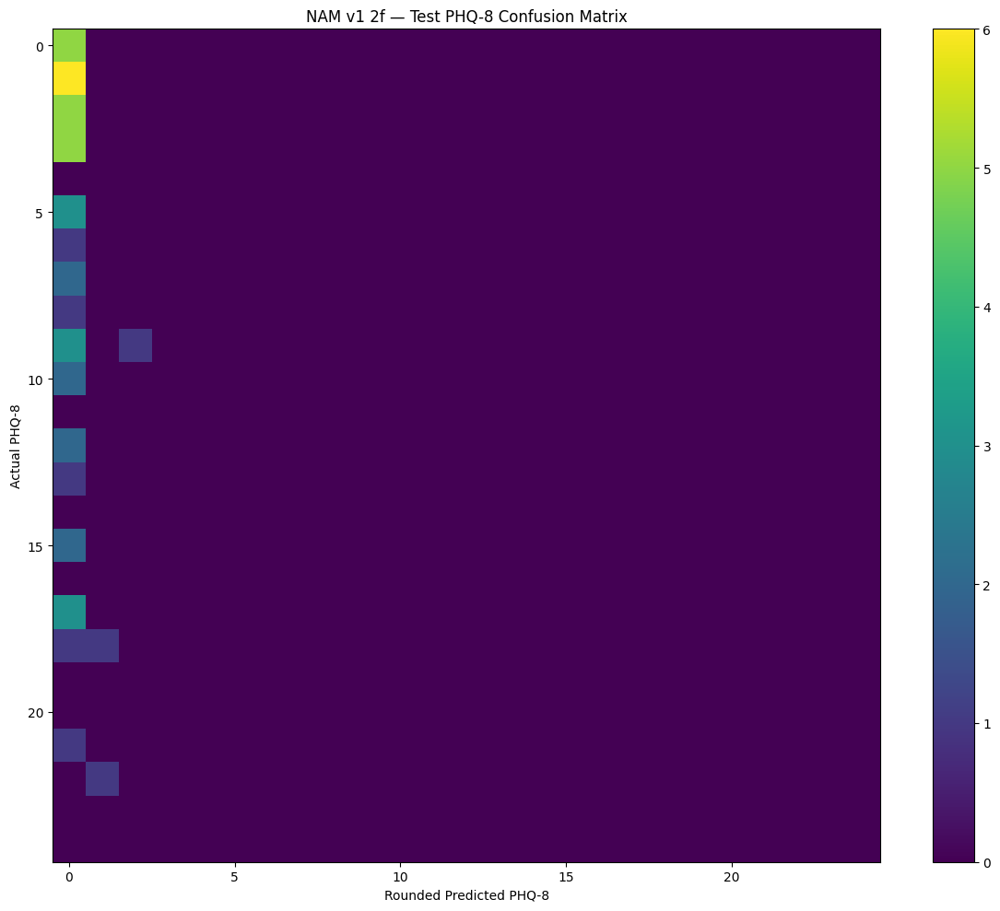

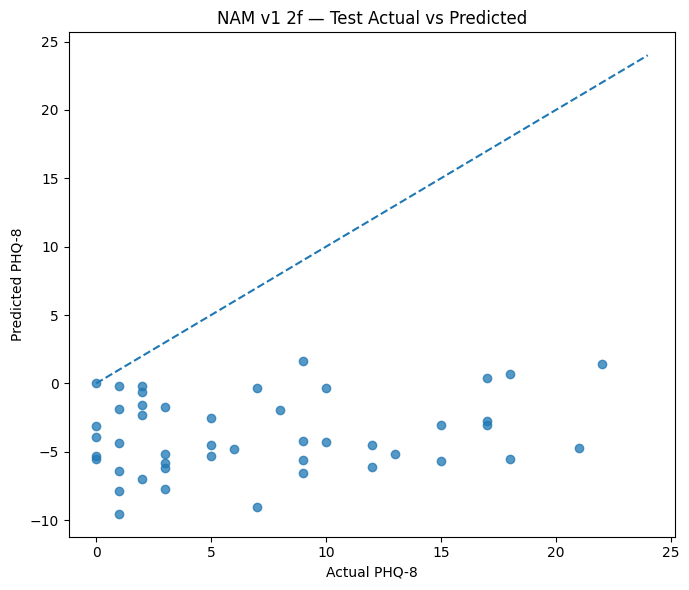


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
20,speech__mean_f2_loc,speech,0.900060,-0.093207,-1.171864
3,speech__pause_rate,speech,0.865617,-0.043260,-1.279778
13,speech__spectral_tilt,speech,0.527490,-0.087219,-1.101027
16,speech__mean_f1_loc,speech,0.493284,0.104653,0.501130
6,speech__std_f0_hertz,speech,0.468589,-0.020109,-0.767038
1,speech__articulation_rate,speech,0.381943,-0.095453,-1.386354
17,speech__std_f1_loc,speech,0.378234,-0.070415,-0.417560
9,speech__range_ratio_intensity_db,speech,0.360136,0.071377,-0.275263
22,speech__mean_b2_loc,speech,0.359431,0.056290,0.513696
19,speech__std_b1_loc,speech,0.357368,-0.014854,0.358211



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_2F_-_Speech_Unigrams_-_LDS
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


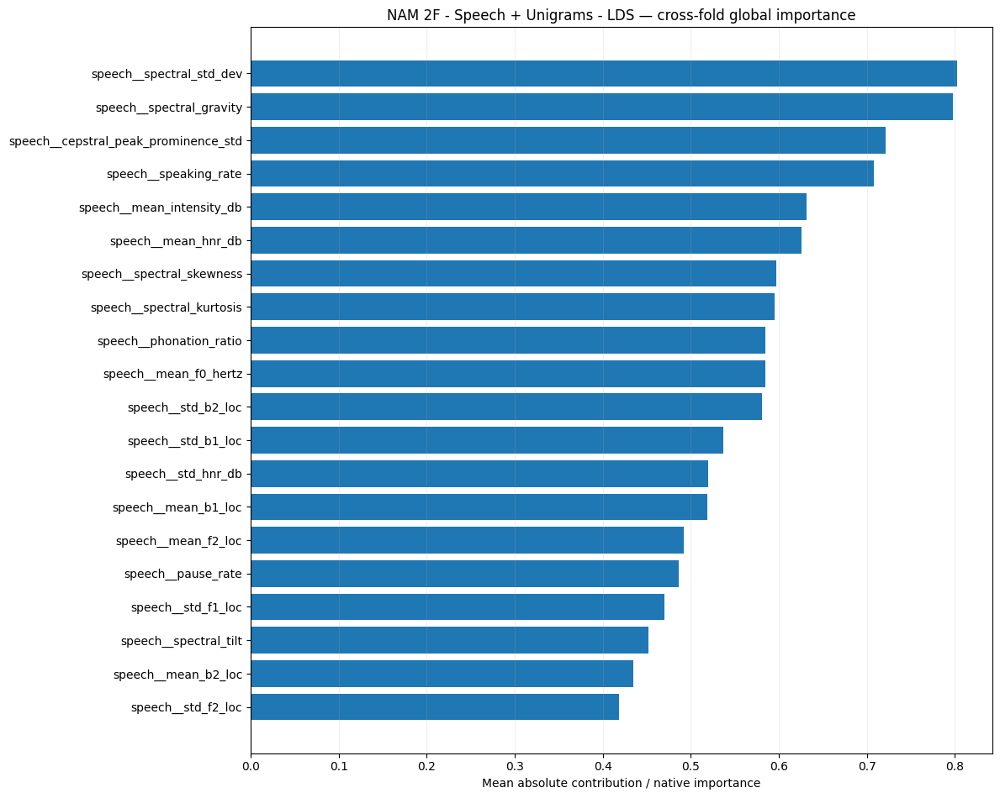

/tmp/ipykernel_2174/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2174/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2174/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic



Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
103,text__parent,2,0.952973,NaN,0.220482,0.544677,0.0,0.090117
39,text__arts,2,0.921176,NaN,0.018157,0.051156,0.0,0.070932
104,text__parents,2,0.914675,NaN,0.093422,0.153539,0.0,0.079949
83,text__interesting,2,0.911476,NaN,0.072378,0.206101,0.0,0.100147
78,text__his,2,0.911042,NaN,0.048853,0.155616,0.0,0.070711
63,text__even,3,0.883561,0.087721,0.057138,0.095861,0.0,0.056963
94,text__management,2,0.862881,NaN,0.239528,0.390394,0.0,0.089020
41,text__basis,2,0.836163,NaN,0.121618,0.266826,0.0,0.082020
30,text__alright,4,0.822945,0.094256,0.106171,0.184321,0.0,0.130945
74,text__happens,2,0.811655,NaN,0.076781,0.168116,0.0,0.085686


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_2F_-_Speech_Unigrams_-_LDS.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 2f (corresponds to DNAMite 2f)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_2f_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2f",
    dnamite_experiment_id="2f",
    experiment_name='NAM 2F - Speech + Unigrams - LDS',
    task="regression",
    cv_results=experiment_2f_regression_cv,
    final_result=experiment_2f_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2f",
    )
] = NAM_v1_2f_report


In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 2f complete. "
    "Waiting for file writes..."
)

time.sleep(20)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 2f complete. Waiting for file writes...
Disconnecting runtime.


## Experiment 3 -- Speech + Unigram/Bigram

In [ ]:
text_matrix=(
    unigram_bigram_data[
        "X_development"
    ]
),

text_representation=(
    "unigram_bigram"
),

### Experiment 3a Speech + Unigram/Bigram Classification

In [ ]:
experiment_3a_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3A - "
            "Speech + Unigrams/Bigrams - "
            "Baseline"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3A - Speech + Unigrams/Bigrams - Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
[RAM] before inner fit: 1360.2 MB


[codecarbon WARNING @ 17:44:11] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=2.766768; hit ceiling=True
RAM memory:
  start: 1360.2265625 MB
  absolute peak: 2448.59375 MB
  incremental peak: 1088.3671875 MB
GPU memory:
  start: 0.0 MB
  end: 0.118408203125 MB
  absolute peak: 0.158203125 MB
  incremental peak: 0.158203125 MB
[RAM] after inner cleanup: 2453.2 MB
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
[RAM] before inner fit: 2453.2 MB
GPU memory at training start: 0.081298828125 MB
Epochs ran=200; best epoch=200; best val_loss=2.816100; hit ceiling=True
RAM memory:
  start: 2453.23828125 MB
  absolute peak: 2955.12109375 MB
  incremental peak: 501.8828125 MB
GPU memory:
  start: 0.081298828125 MB
  end: 0.193115234375 MB
  absolute peak: 0.22802734375 MB
  incremental peak: 0.146728515625 MB
[RAM] after inner cleanup: 2954.9 MB
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
[RAM] before inner fit: 2954.9 MB
GPU memory at training start: 0.157958984375 MB

In [ ]:
experiment_3a_classification_summary = (
    summarize_nested_cv(
        experiment_3a_classification_cv
    )
)

display(
    experiment_3a_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.370370           0.299342  0.105263   0.090909   
1           2  0.407407           0.470395  0.384615   0.277778   
2           3  0.703704           0.536184  0.200000   0.500000   
3           4  0.555556           0.503289  0.333333   0.300000   
4           5  0.592593           0.421053  0.000000   0.000000   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.125     0.473684  0.263158  0.224897                   17   
1               0.625     0.315789  0.506579  0.406712                   17   
2               0.125     0.947368  0.335526  0.340964                   20   
3               0.375     0.631579  0.394737  0.277217                   19   
4               0.000     0.842105  0.368421  0.258213                   17   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count
0,1,0.370370,0.299342,0.105263,0.090909,0.125,0.473684,0.263158,0.224897,17,None
1,2,0.407407,0.470395,0.384615,0.277778,0.625,0.315789,0.506579,0.406712,17,None
2,3,0.703704,0.536184,0.200000,0.500000,0.125,0.947368,0.335526,0.340964,20,None
3,4,0.555556,0.503289,0.333333,0.300000,0.375,0.631579,0.394737,0.277217,19,None
4,5,0.592593,0.421053,0.000000,0.000000,0.000,0.842105,0.368421,0.258213,17,None


In [ ]:
for result in experiment_3a_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected text features: 17

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected text features: 17

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected text features: 20

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}
Selected text features: 19

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}
Selected text features: 17



In [ ]:
experiment_3a_best_parameters = (
    choose_final_parameters(
        experiment_3a_classification_cv
    )
)

print(
    "Experiment 3A best parameters:"
)

print(
    experiment_3a_best_parameters
)

Experiment 3A best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_3a_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_3a_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
GPU memory at training start: 4.771240234375 MB
Epochs ran=200; best epoch=200; best val_loss=1.572384; hit ceiling=True
RAM memory:
  start: 25179.6640625 MB
  absolute peak: 25628.23828125 MB
  incremental peak: 448.57421875 MB
GPU memory:
  start: 4.771240234375 MB
  end: 4.8984375 MB
  absolute peak: 4.94384765625 MB
  incremental peak: 0.172607421875 MB
Best training epochs: 200
Selected 28 TF-IDF features for classification / unigram_bigram using C=5.0
RAM memory:
  start: 25477.125 MB
  absolute peak: 26357.48046875 MB
  incremental peak: 880.35546875 MB

FINAL TEST METRICS
{'accuracy': 0.34782608695652173, 'balanced_accuracy': np.float64(0.45089285714285715), 'f1': 0.4, 'precision': 0.2777777777777778, 'recall_sensitivity': 0.7142857142857143, 'specificity': 0.1875, 'roc_auc': np.float64(0.4330357142857143), 'pr_auc': np.float64(0.28937981004534186)}


In [ ]:
experiment_3a_classification_final[
    "metrics"
]

{'accuracy': 0.34782608695652173,
 'balanced_accuracy': np.float64(0.45089285714285715),
 'f1': 0.4,
 'precision': 0.2777777777777778,
 'recall_sensitivity': 0.7142857142857143,
 'specificity': 0.1875,
 'roc_auc': np.float64(0.4330357142857143),
 'pr_auc': np.float64(0.28937981004534186)}

In [ ]:
experiment_3a_classification_final[
    "best_epoch"
]

200

In [ ]:
experiment_3a_classification_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

#### NAM v1 Experiment 3a — DNAMite-parity outputs (maps to DNAMite 3a)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 3a — NAM 3A - Speech + Unigrams/Bigrams - Baseline
DNAMite reference experiment: 3a

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.370370,0.299342,0.105263,0.090909,0.125,0.473684,0.263158,0.224897,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,200,200,True
1,2,0.407407,0.470395,0.384615,0.277778,0.625,0.315789,0.506579,0.406712,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,200,200,True
2,3,0.703704,0.536184,0.200000,0.500000,0.125,0.947368,0.335526,0.340964,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",20,None,200,200,True
3,4,0.555556,0.503289,0.333333,0.300000,0.375,0.631579,0.394737,0.277217,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",19,None,73,93,False
4,5,0.592593,0.421053,0.000000,0.000000,0.000,0.842105,0.368421,0.258213,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.525926,0.137087
balanced_accuracy,0.446053,0.092387
f1,0.204642,0.158688
precision,0.233737,0.195102
recall_sensitivity,0.250000,0.250000
specificity,0.642105,0.258913
roc_auc,0.373684,0.089168
pr_auc,0.301601,0.072385
selected_text_count,18.000000,1.414214
best_epoch,174.600000,56.796127



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,1,108.461216,6475.582031,7056.691406,581.109375,0.186035,NaN,0.888428,1.015625,1.074463,tensorflow,8641,0.394943
1,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,2,104.513250,11134.542969,11619.753906,485.210938,0.172607,NaN,1.850586,1.977783,2.023193,tensorflow,4321,0.379318
2,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,3,111.030949,15828.941406,16326.128906,497.187500,0.181152,NaN,2.789795,2.922119,2.970947,tensorflow,4609,0.404160
3,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,4,100.961073,20227.433594,21000.453125,773.019531,0.165771,NaN,3.806641,3.911133,3.972412,tensorflow,9025,0.412155
4,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,5,111.478545,24639.910156,25265.562500,625.652344,0.185791,NaN,4.688232,4.815186,4.874023,tensorflow,8641,0.394943



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,1,0.003519,0.001657
1,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,2,0.003380,0.001591
2,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,3,0.003608,0.001699
3,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,4,0.003278,0.001543
4,NAM v1,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,5,0.003621,0.001705



Final Test Metrics
{'accuracy': 0.34782608695652173, 'balanced_accuracy': np.float64(0.45089285714285715), 'f1': 0.4, 'precision': 0.2777777777777778, 'recall_sensitivity': 0.7142857142857143, 'specificity': 0.1875, 'roc_auc': np.float64(0.4330357142857143), 'pr_auc': np.float64(0.28937981004534186)}

Final Model Resource Summary
{'train_seconds': 104.68843485100024, 'start_ram_mb': 25477.125, 'peak_ram_mb': 26357.48046875, 'incremental_peak_ram_mb': 880.35546875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.003399114766845172, 'training_co2_kg': 0.0016002454472796707}


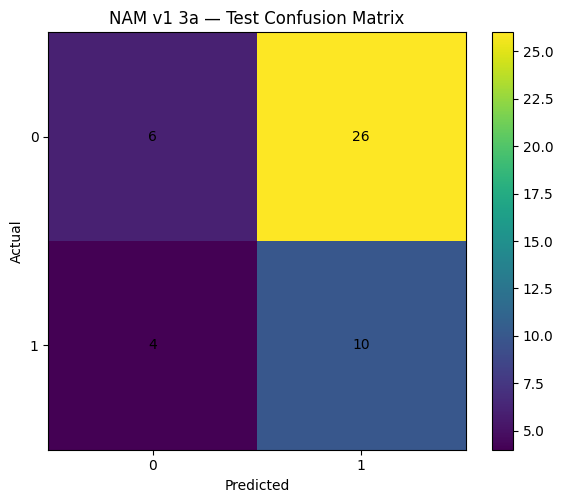

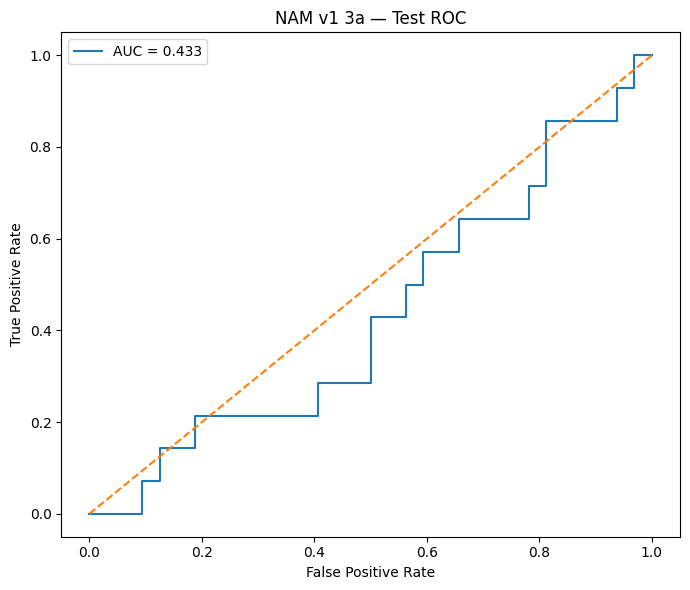

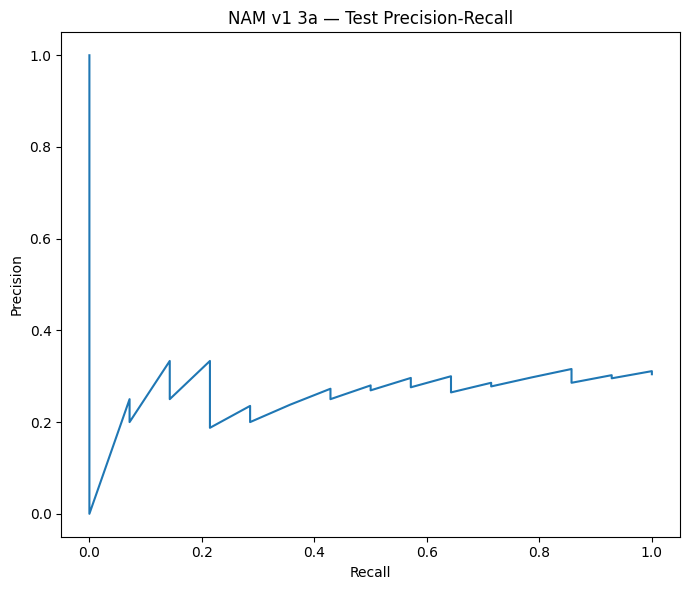

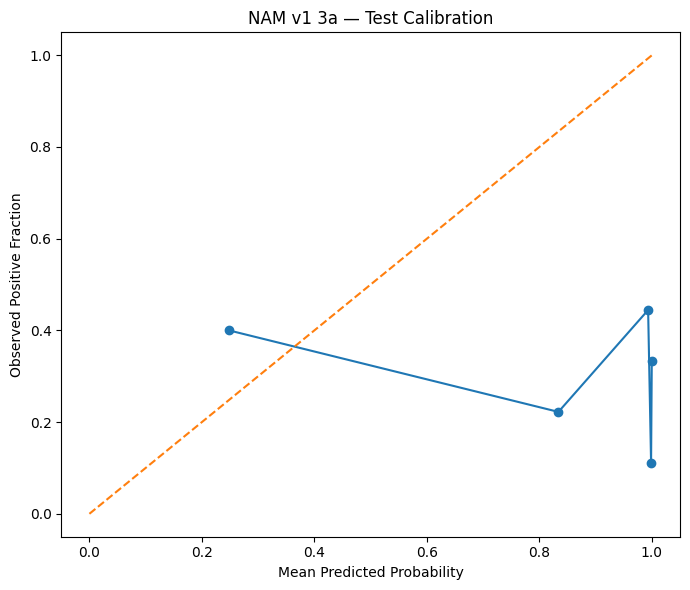


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
20,speech__mean_f2_loc,speech,1.456984,0.108313,1.872884
13,speech__spectral_tilt,speech,1.223245,0.133512,1.725103
18,speech__mean_b1_loc,speech,1.162112,0.040342,1.267497
23,speech__std_b2_loc,speech,0.991025,-0.053545,0.507065
0,speech__speaking_rate,speech,0.987680,-0.141052,-1.581115
5,speech__mean_f0_hertz,speech,0.956808,0.202027,1.341773
19,speech__std_b1_loc,speech,0.953712,0.012361,-1.108151
14,speech__cepstral_peak_prominence_mean,speech,0.822427,-0.016061,-0.811248
11,speech__std_hnr_db,speech,0.796917,-0.167199,0.891465
24,speech__spectral_gravity,speech,0.639324,-0.083423,0.697695



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


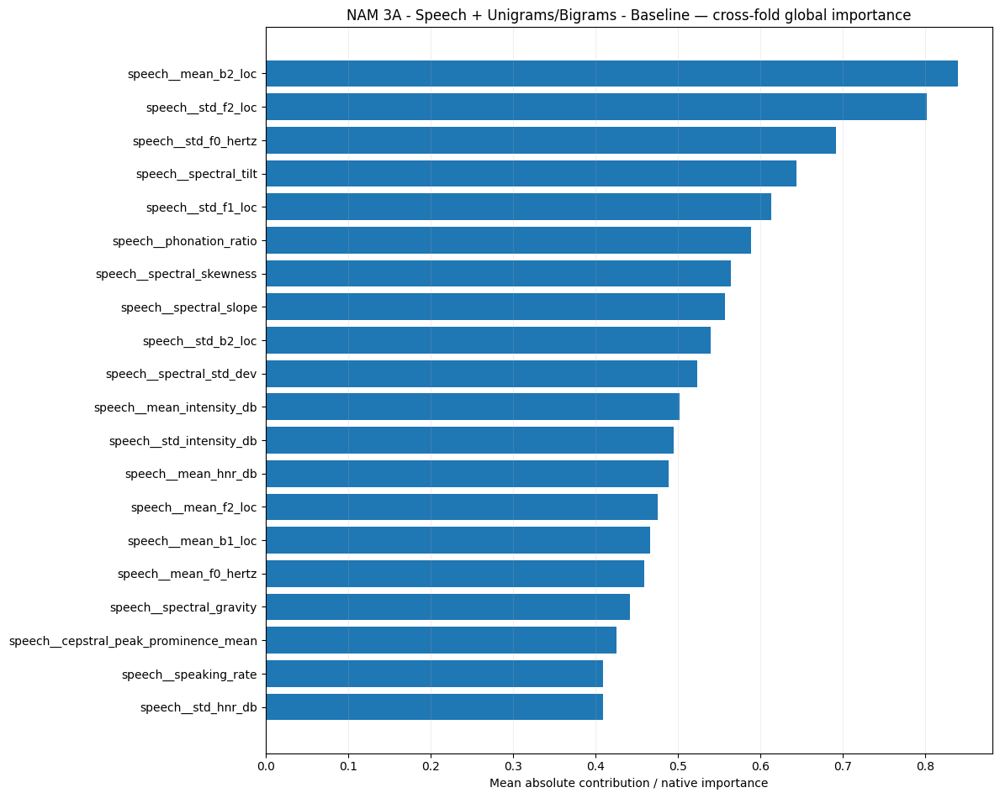

/tmp/ipykernel_554/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic



Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
39,text__probably a,2,0.783428,NaN,0.193866,0.361675,0.000000,0.081510
36,text__medication,2,0.765615,NaN,0.114845,0.249350,0.000000,0.078181
29,text__alright,2,0.385902,NaN,0.205389,0.662910,0.000000,0.123468
11,speech__pause_rate,5,0.381221,0.323328,0.397774,0.644098,-1.768064,1.710399
22,speech__std_b2_loc,5,0.296516,0.556648,0.628644,0.890843,-1.488311,2.377967
23,speech__std_f0_hertz,5,0.188103,0.843823,0.836259,1.038862,-1.441116,2.275466
43,text__to uh,2,0.178670,NaN,0.053122,0.092486,0.000000,0.061432
38,text__people i,2,0.151127,NaN,0.051301,0.119220,0.000000,0.058474
8,speech__mean_hnr_db,5,0.135794,0.704013,0.526739,0.746442,-2.040370,2.087750
9,speech__mean_intensity_db,5,0.067980,0.584928,0.618771,0.914372,-1.887187,2.363089


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 3a (corresponds to DNAMite 3a)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_3a_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3a",
    dnamite_experiment_id="3a",
    experiment_name='NAM 3A - Speech + Unigrams/Bigrams - Baseline',
    task="classification",
    cv_results=experiment_3a_classification_cv,
    final_result=experiment_3a_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3a",
    )
] = NAM_v1_3a_report


### Experiment 3b Speech + Unigram/Bigram Classification with Feature Selection

In [ ]:
experiment_3b_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3B - "
            "Speech + Unigrams/Bigrams - "
            "Feature Selection"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3B - Speech + Unigrams/Bigrams - Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
Joint selection: 18 features, C=1.0
[RAM] before inner fit: 1362.8 MB


[codecarbon WARNING @ 20:00:30] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=2.723482; hit ceiling=True
RAM memory:
  start: 1362.8046875 MB
  absolute peak: 2112.00390625 MB
  incremental peak: 749.19921875 MB
GPU memory:
  start: 0.0 MB
  end: 0.084228515625 MB
  absolute peak: 0.1064453125 MB
  incremental peak: 0.1064453125 MB
[RAM] after inner cleanup: 2114.3 MB
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
Joint selection: 14 features, C=1.0
[RAM] before inner fit: 2114.3 MB
GPU memory at training start: 0.066650390625 MB
Epochs ran=200; best epoch=200; best val_loss=0.974768; hit ceiling=True
RAM memory:
  start: 2114.28125 MB
  absolute peak: 2220.33203125 MB
  incremental peak: 106.05078125 MB
GPU memory:
  start: 0.066650390625 MB
  end: 0.140869140625 MB
  absolute peak: 0.15771484375 MB
  incremental peak: 0.091064453125 MB
[RAM] after inner cleanup: 2219.8 MB
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
Joint selection: 13 features, C=1.0
[RAM] 

In [ ]:
experiment_3b_classification_summary = (
    summarize_nested_cv(
        experiment_3b_classification_cv
    )
)

display(
    experiment_3b_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.481481           0.450658  0.300000   0.250000   
1           2  0.629630           0.483553  0.166667   0.250000   
2           3  0.555556           0.611842  0.500000   0.375000   
3           4  0.592593           0.601974  0.476190   0.384615   
4           5  0.481481           0.595395  0.500000   0.350000   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.375     0.526316  0.355263  0.250512                   17   
1               0.125     0.842105  0.539474  0.340351                   17   
2               0.750     0.473684  0.539474  0.336448                   20   
3               0.625     0.578947  0.644737  0.546202                   19   
4               0.875     0.315789  0.486842  0.314780                   17   

   joint_selected_count  
0                    13  
1                    16  
2                    16  
3                 

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count
0,1,0.481481,0.450658,0.300000,0.250000,0.375,0.526316,0.355263,0.250512,17,13
1,2,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.539474,0.340351,17,16
2,3,0.555556,0.611842,0.500000,0.375000,0.750,0.473684,0.539474,0.336448,20,16
3,4,0.592593,0.601974,0.476190,0.384615,0.625,0.578947,0.644737,0.546202,19,17
4,5,0.481481,0.595395,0.500000,0.350000,0.875,0.315789,0.486842,0.314780,17,19


In [ ]:
for result in experiment_3b_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected unigram/bigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected unigram/bigram features: 17
Final jointly selected features: 13

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected unigram/bigram features: 17
Final jointly selected features: 16

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected unigram/bigram features: 20
Final jointly selected features: 16

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected unigram/bigram features: 19
Final jointly selected features: 17

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected unigram/bigram features: 1

In [ ]:
experiment_3b_best_parameters = (
    choose_final_parameters(
        experiment_3b_classification_cv
    )
)

print(
    experiment_3b_best_parameters
)

{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_3b_classification_final = (
    train_final_nam_model(
        task="classification",
        speech_development=development_speech,
        y_development=y_binary_development,
        speech_test=test_speech,
        y_test=y_binary_test,

        parameters=(
            experiment_3b_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
Joint selection: 13 features, C=1.0
GPU memory at training start: 3.629150390625 MB
Epochs ran=200; best epoch=200; best val_loss=2.855238; hit ceiling=True
RAM memory:
  start: 12090.26171875 MB
  absolute peak: 12090.265625 MB
  incremental peak: 0.00390625 MB
GPU memory:
  start: 3.629150390625 MB
  end: 3.70166015625 MB
  absolute peak: 3.722412109375 MB
  incremental peak: 0.09326171875 MB
Best training epochs: 200
Selected 28 TF-IDF features for classification / unigram_bigram using C=5.0
Joint selection: 18 features, C=1.0
RAM memory:
  start: 11916.48046875 MB
  absolute peak: 12202.34375 MB
  incremental peak: 285.86328125 MB

FINAL TEST METRICS
{'accuracy': 0.6521739130434783, 'balanced_accuracy': np.float64(0.5691964285714286), 'f1': 0.38461538461538464, 'precision': 0.4166666666666667, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.78125, 'roc_auc': np.float64(0.5870535714285714), 'pr_a

In [ ]:
experiment_3b_classification_final[
    "metrics"
]

{'accuracy': 0.6521739130434783,
 'balanced_accuracy': np.float64(0.5691964285714286),
 'f1': 0.38461538461538464,
 'precision': 0.4166666666666667,
 'recall_sensitivity': 0.35714285714285715,
 'specificity': 0.78125,
 'roc_auc': np.float64(0.5870535714285714),
 'pr_auc': np.float64(0.42927672204887335)}

In [ ]:
experiment_3b_classification_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

In [ ]:
print(
    "Final jointly selected features:",
    len(
        experiment_3b_classification_final[
            "joint_selected_indices"
        ]
    )
)

Final jointly selected features: 18


#### NAM v1 Experiment 3b — DNAMite-parity outputs (maps to DNAMite 3b)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 3b — NAM 3B - Speech + Unigrams/Bigrams - Feature Selection
DNAMite reference experiment: 3b

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.481481,0.450658,0.300000,0.250000,0.375,0.526316,0.355263,0.250512,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,13,200,200,True
1,2,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.539474,0.340351,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,16,200,200,True
2,3,0.555556,0.611842,0.500000,0.375000,0.750,0.473684,0.539474,0.336448,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",20,16,200,200,True
3,4,0.592593,0.601974,0.476190,0.384615,0.625,0.578947,0.644737,0.546202,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",19,17,200,200,True
4,5,0.481481,0.595395,0.500000,0.350000,0.875,0.315789,0.486842,0.314780,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,19,200,200,True



CV Mean ± SD


,mean,sd
accuracy,0.548148,0.066254
balanced_accuracy,0.548684,0.075601
f1,0.388571,0.149663
precision,0.321923,0.066861
recall_sensitivity,0.550000,0.301040
specificity,0.547368,0.191943
roc_auc,0.513158,0.105263
pr_auc,0.357659,0.111374
selected_text_count,18.000000,1.414214
joint_selected_count,16.200000,2.167948



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,1,45.720335,3766.847656,3875.871094,109.023438,0.089111,NaN,0.584473,0.656982,0.673584,tensorflow,1249,0.116028
1,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,2,52.833110,5692.328125,5910.214844,217.886719,0.104004,NaN,1.275635,1.353271,1.379639,tensorflow,3073,0.147041
2,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,3,53.329794,7906.992188,8039.457031,132.464844,0.109863,NaN,2.041016,2.118652,2.150879,tensorflow,3073,0.147041
3,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,4,53.674661,9733.085938,9887.195312,154.109375,0.098389,NaN,2.794189,2.873535,2.892578,tensorflow,1633,0.148811
4,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,5,57.650396,11781.152344,12000.585938,219.433594,0.105713,NaN,3.564941,3.647705,3.670654,tensorflow,1825,0.164383



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,1,0.001482,0.000698
1,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,2,0.001716,0.000808
2,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,3,0.001731,0.000815
3,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,4,0.001741,0.000820
4,NAM v1,NAM 3B - Speech + Unigrams/Bigrams - Feature S...,classification,5,0.001871,0.000881



Final Test Metrics
{'accuracy': 0.6521739130434783, 'balanced_accuracy': np.float64(0.5691964285714286), 'f1': 0.38461538461538464, 'precision': 0.4166666666666667, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.78125, 'roc_auc': np.float64(0.5870535714285714), 'pr_auc': np.float64(0.42927672204887335)}

Final Model Resource Summary
{'train_seconds': 41.38538528800018, 'start_ram_mb': 11916.48046875, 'peak_ram_mb': 12202.34375, 'incremental_peak_ram_mb': 285.86328125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0013396321111147139, 'training_co2_kg': 0.0006306760241669184}


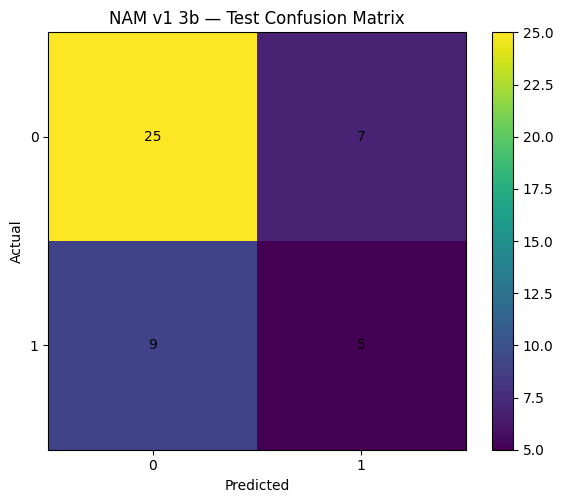

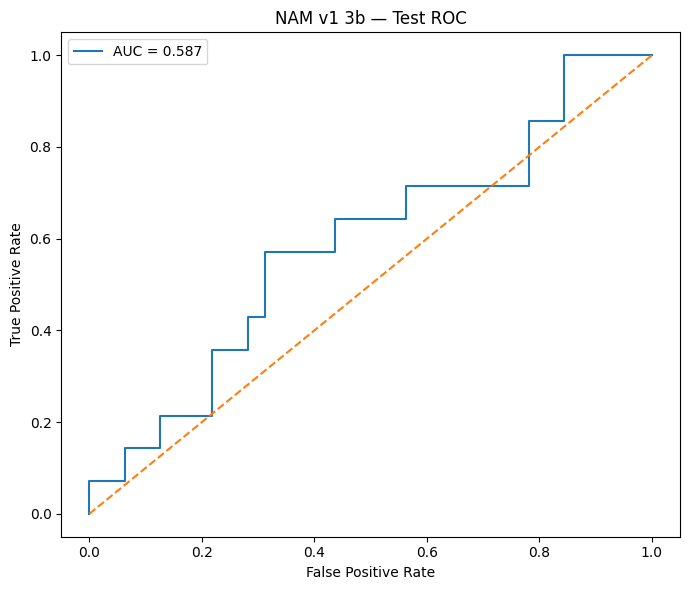

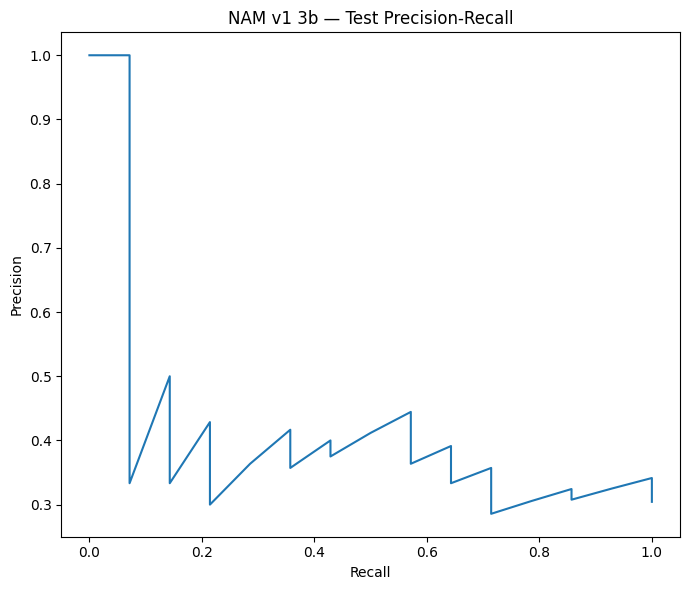

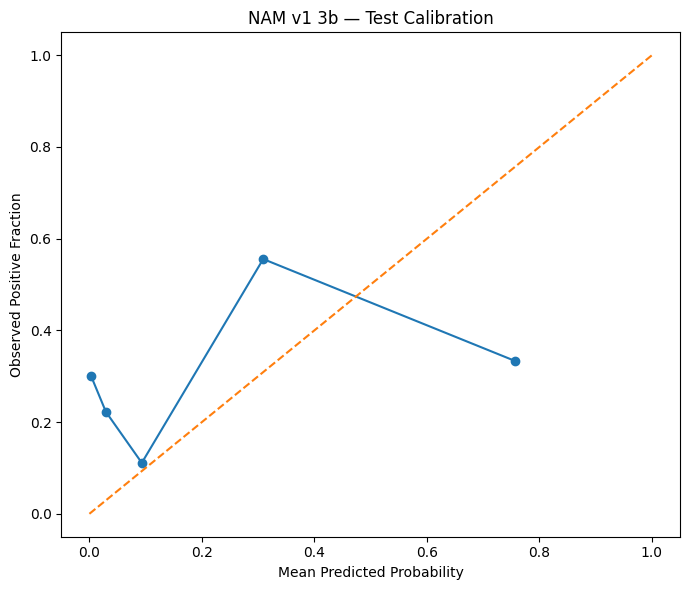


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
5,speech__mean_hnr_db,speech,1.079129,0.018719,-0.932529
14,speech__std_f2_loc,speech,0.903481,-0.028154,-1.177757
7,speech__spectral_tilt,speech,0.899750,-0.056225,-1.237187
12,speech__std_b1_loc,speech,0.827196,-0.016411,0.819373
17,speech__spectral_kurtosis,speech,0.683413,0.269357,0.763868
4,speech__range_ratio_intensity_db,speech,0.597778,-0.178717,0.904351
0,speech__phonation_ratio,speech,0.592076,0.092255,0.581280
6,speech__std_hnr_db,speech,0.510436,0.128888,-0.507196
3,speech__mean_intensity_db,speech,0.508804,0.014993,-0.599101
10,speech__std_f1_loc,speech,0.502561,-0.042961,0.146026



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


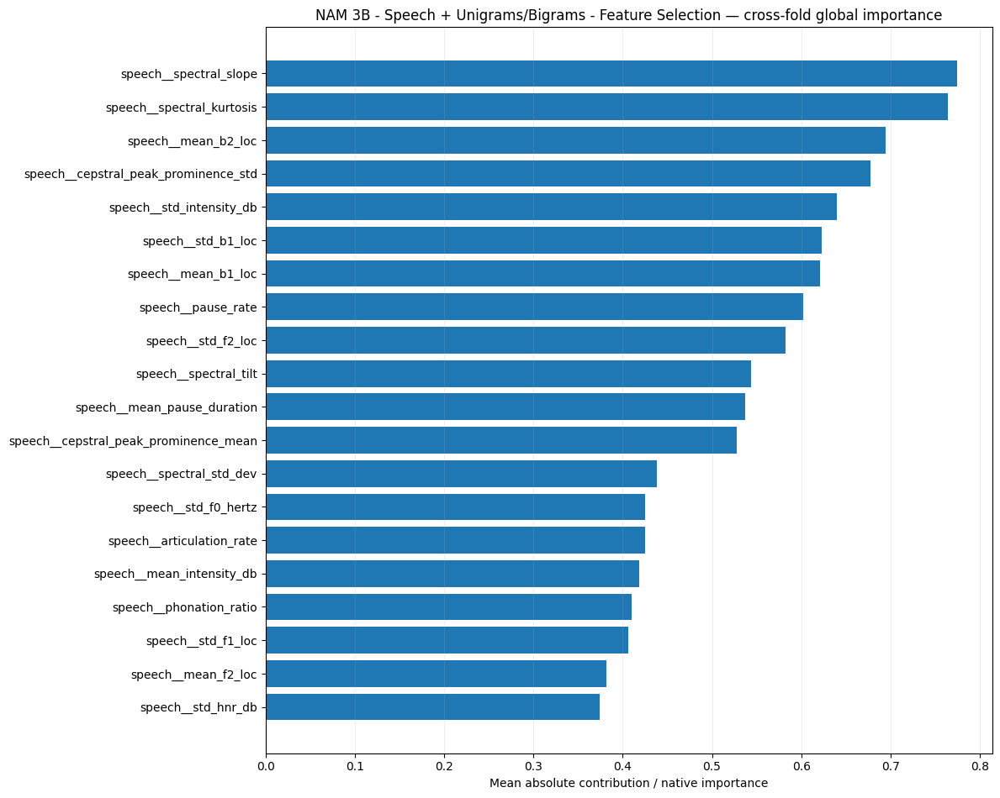


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
3,speech__mean_b1_loc,3,0.308640,0.490720,0.564677,1.357532,-1.699834,2.741646
13,speech__spectral_std_dev,3,0.119941,0.479306,0.378848,1.026956,-1.666552,2.430222
7,speech__mean_intensity_db,4,0.117897,0.664095,0.410183,0.829288,-1.887187,2.363089
14,speech__spectral_tilt,4,0.071560,0.435728,0.566491,0.766885,-2.104152,2.179019
10,speech__range_ratio_intensity_db,4,0.003800,0.401107,0.511270,0.775255,-1.038354,0.812457
8,speech__pause_rate,4,-0.031186,0.614449,0.804176,1.062587,-2.115891,1.710399
5,speech__mean_f2_loc,3,-0.034160,0.497958,0.414982,1.078703,-2.157444,2.188417
16,speech__std_f1_loc,5,-0.046996,0.493430,0.489492,0.769305,-1.898396,2.051157
2,speech__cepstral_peak_prominence_std,5,-0.066906,0.624438,0.858602,1.128142,-1.879563,2.014362
1,speech__cepstral_peak_prominence_mean,5,-0.079956,0.560035,0.740420,1.078406,-2.021945,1.970126


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 3b (corresponds to DNAMite 3b)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_3b_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3b",
    dnamite_experiment_id="3b",
    experiment_name='NAM 3B - Speech + Unigrams/Bigrams - Feature Selection',
    task="classification",
    cv_results=experiment_3b_classification_cv,
    final_result=experiment_3b_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3b",
    )
] = NAM_v1_3b_report


### Experiment 3c Speech + Unigram/Bigram Classification with BCE

In [ ]:
experiment_3c_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3C - "
            "Speech + Unigrams/Bigrams - "
            "BCE"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3C - Speech + Unigrams/Bigrams - BCE
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0
[RAM] before inner fit: 1365.6 MB


[codecarbon WARNING @ 23:56:57] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Class weights: {0: 0.72, 1: 1.6363636363636365}


Epochs ran=200; best epoch=200; best val_loss=1.454330; hit ceiling=True
RAM memory:
  start: 1365.55859375 MB
  absolute peak: 2428.1796875 MB
  incremental peak: 1062.62109375 MB
GPU memory:
  start: 0.0 MB
  end: 0.118408203125 MB
  absolute peak: 0.158203125 MB
  incremental peak: 0.158203125 MB
[RAM] after inner cleanup: 2434.2 MB
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
[RAM] before inner fit: 2434.3 MB
GPU memory at training start: 0.081298828125 MB
Class weights: {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=200; best epoch=200; best val_loss=2.015359; hit ceiling=True
RAM memory:
  start: 2434.3125 MB
  absolute peak: 3025.12109375 MB
  incremental peak: 590.80859375 MB
GPU memory:
  start: 0.081298828125 MB
  end: 0.193115234375 MB
  absolute peak: 0.228515625 MB
  incremental peak: 0.147216796875 MB
[RAM] after inner cleanup: 3024.9 MB
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
[RAM] before inner f

In [ ]:
experiment_3c_classification_summary = (
    summarize_nested_cv(
        experiment_3c_classification_cv
    )
)

display(
    experiment_3c_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.592593           0.421053  0.000000   0.000000   
1           2  0.407407           0.542763  0.466667   0.318182   
2           3  0.703704           0.500000  0.000000   0.000000   
3           4  0.296296           0.500000  0.457143   0.296296   
4           5  0.518519           0.404605  0.133333   0.142857   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.000     0.842105  0.289474  0.233443                   17   
1               0.875     0.210526  0.611842  0.397188                   17   
2               0.000     1.000000  0.407895  0.273248                   20   
3               1.000     0.000000  0.463816  0.288651                   19   
4               0.125     0.684211  0.217105  0.255198                   17   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count
0,1,0.592593,0.421053,0.000000,0.000000,0.000,0.842105,0.289474,0.233443,17,None
1,2,0.407407,0.542763,0.466667,0.318182,0.875,0.210526,0.611842,0.397188,17,None
2,3,0.703704,0.500000,0.000000,0.000000,0.000,1.000000,0.407895,0.273248,20,None
3,4,0.296296,0.500000,0.457143,0.296296,1.000,0.000000,0.463816,0.288651,19,None
4,5,0.518519,0.404605,0.133333,0.142857,0.125,0.684211,0.217105,0.255198,17,None


In [ ]:
for result in experiment_3c_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected text features: 17

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected text features: 17

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected text features: 20

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected text features: 19

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected text features: 17



In [ ]:
experiment_3c_best_parameters = (
    choose_final_parameters(
        experiment_3c_classification_cv
    )
)

print(
    experiment_3c_best_parameters
)

{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}


In [ ]:
experiment_3c_classification_final = (
    train_final_nam_model(
        task="classification",
        speech_development=development_speech,
        y_development=y_binary_development,
        speech_test=test_speech,
        y_test=y_binary_test,

        parameters=(
            experiment_3c_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
GPU memory at training start: 4.66357421875 MB
Class weights: {0: 0.7105263157894737, 1: 1.6875}
Epochs ran=200; best epoch=200; best val_loss=1.343775; hit ceiling=True
RAM memory:
  start: 25170.13671875 MB
  absolute peak: 25787.98828125 MB
  incremental peak: 617.8515625 MB
GPU memory:
  start: 4.66357421875 MB
  end: 4.790771484375 MB
  absolute peak: 4.85009765625 MB
  incremental peak: 0.1865234375 MB
Best training epochs: 200
Selected 28 TF-IDF features for classification / unigram_bigram using C=5.0
RAM memory:
  start: 25614.7421875 MB
  absolute peak: 26412.3203125 MB
  incremental peak: 797.578125 MB

FINAL TEST METRICS
{'accuracy': 0.32608695652173914, 'balanced_accuracy': np.float64(0.515625), 'f1': 0.4745762711864407, 'precision': 0.3111111111111111, 'recall_sensitivity': 1.0, 'specificity': 0.03125, 'roc_auc': np.float64(0.4040178571428571), 'pr_auc': np.float64(0.31862505931688434)}


In [ ]:
experiment_3c_classification_final[
    "metrics"
]

{'accuracy': 0.32608695652173914,
 'balanced_accuracy': np.float64(0.515625),
 'f1': 0.4745762711864407,
 'precision': 0.3111111111111111,
 'recall_sensitivity': 1.0,
 'specificity': 0.03125,
 'roc_auc': np.float64(0.4040178571428571),
 'pr_auc': np.float64(0.31862505931688434)}

In [ ]:
experiment_3c_classification_final[
    "best_epoch"
]

200

In [ ]:
experiment_3c_classification_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

#### NAM v1 Experiment 3c — DNAMite-parity outputs (maps to DNAMite 3e)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 3c — NAM 3C - Speech + Unigrams/Bigrams - BCE
DNAMite reference experiment: 3e

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.592593,0.421053,0.000000,0.000000,0.000,0.842105,0.289474,0.233443,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,200,200,True
1,2,0.407407,0.542763,0.466667,0.318182,0.875,0.210526,0.611842,0.397188,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,200,200,True
2,3,0.703704,0.500000,0.000000,0.000000,0.000,1.000000,0.407895,0.273248,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",20,None,200,200,True
3,4,0.296296,0.500000,0.457143,0.296296,1.000,0.000000,0.463816,0.288651,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",19,None,200,200,True
4,5,0.518519,0.404605,0.133333,0.142857,0.125,0.684211,0.217105,0.255198,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,1,21,False



CV Mean ± SD


,mean,sd
accuracy,0.503704,0.158439
balanced_accuracy,0.473684,0.058521
f1,0.211429,0.235066
precision,0.151467,0.153890
recall_sensitivity,0.400000,0.495290
specificity,0.547368,0.425307
roc_auc,0.398026,0.153833
pr_auc,0.289546,0.063601
selected_text_count,18.000000,1.414214
best_epoch,160.200000,88.995506



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,1,101.126372,6494.750000,7122.785156,628.035156,0.173096,NaN,0.894287,1.021484,1.067383,tensorflow,4321,0.379318
1,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,2,108.027642,10969.789062,11652.683594,682.894531,0.186523,NaN,1.838379,1.965576,2.024902,tensorflow,8641,0.394943
2,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,3,108.764722,15835.917969,16373.214844,537.296875,0.181641,NaN,2.689941,2.822266,2.871582,tensorflow,4609,0.404160
3,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,4,112.769117,20335.175781,21021.429688,686.253906,0.192383,NaN,3.671875,3.802490,3.864258,tensorflow,9025,0.412155
4,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,5,82.271958,24639.964844,25450.613281,810.648438,0.129395,NaN,4.624023,4.707520,4.753418,tensorflow,4321,0.379318



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,1,0.003209,0.001511
1,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,2,0.003429,0.001614
2,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,3,0.003453,0.001626
3,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,4,0.003582,0.001686
4,NAM v1,NAM 3C - Speech + Unigrams/Bigrams - BCE,classification,5,0.002608,0.001228



Final Test Metrics
{'accuracy': 0.32608695652173914, 'balanced_accuracy': np.float64(0.515625), 'f1': 0.4745762711864407, 'precision': 0.3111111111111111, 'recall_sensitivity': 1.0, 'specificity': 0.03125, 'roc_auc': np.float64(0.4040178571428571), 'pr_auc': np.float64(0.31862505931688434)}

Final Model Resource Summary
{'train_seconds': 109.09706603900031, 'start_ram_mb': 25614.7421875, 'peak_ram_mb': 26412.3203125, 'incremental_peak_ram_mb': 797.578125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.003463273436144948, 'training_co2_kg': 0.0016304502580886272}


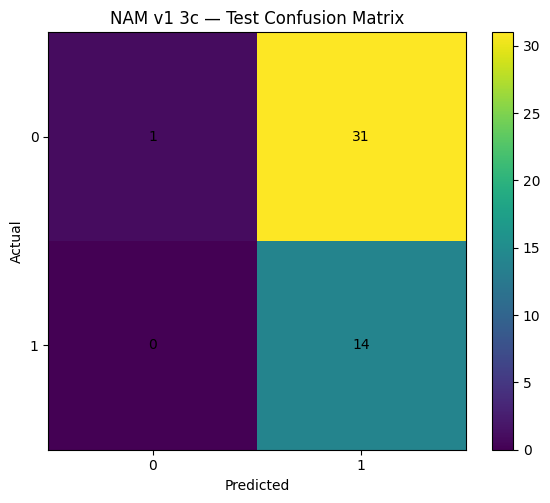

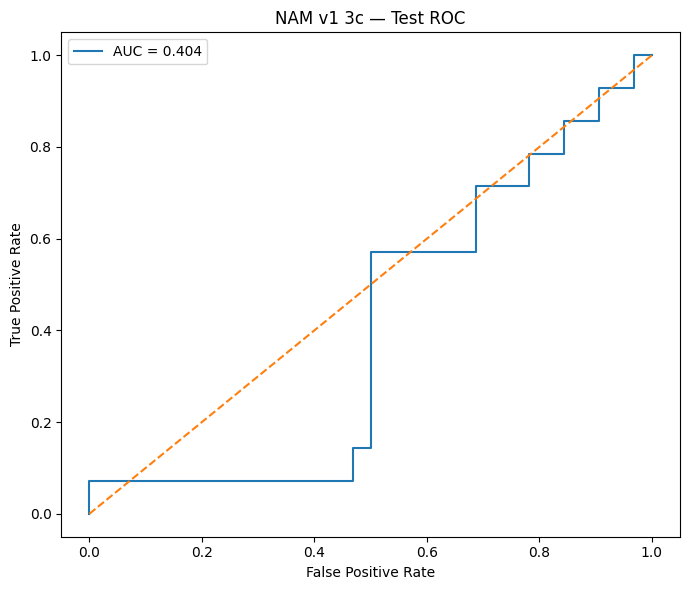

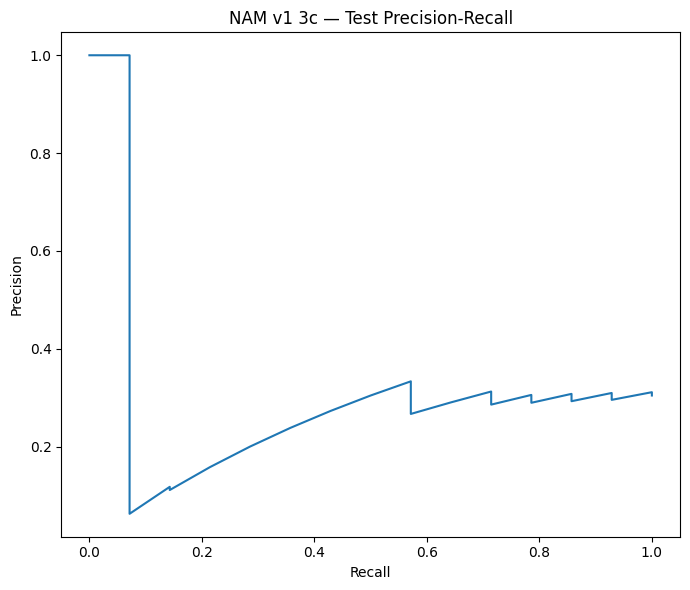

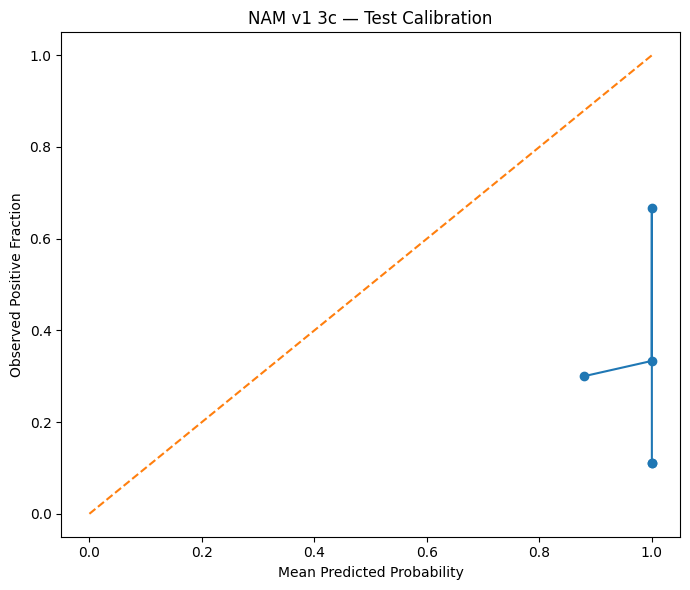


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
17,speech__std_f1_loc,speech,1.094086,0.134928,-1.347282
19,speech__std_b1_loc,speech,1.052341,-0.021965,-0.899204
0,speech__speaking_rate,speech,0.942139,0.079767,1.495521
14,speech__cepstral_peak_prominence_mean,speech,0.909334,-0.089257,0.964022
7,speech__mean_intensity_db,speech,0.645024,0.188105,-0.868707
2,speech__phonation_ratio,speech,0.632920,0.098064,0.850959
24,speech__spectral_gravity,speech,0.599910,-0.126504,1.100927
11,speech__std_hnr_db,speech,0.596317,-0.149019,0.989797
13,speech__spectral_tilt,speech,0.590350,0.116103,-0.474590
18,speech__mean_b1_loc,speech,0.585119,-0.086134,-0.799209



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


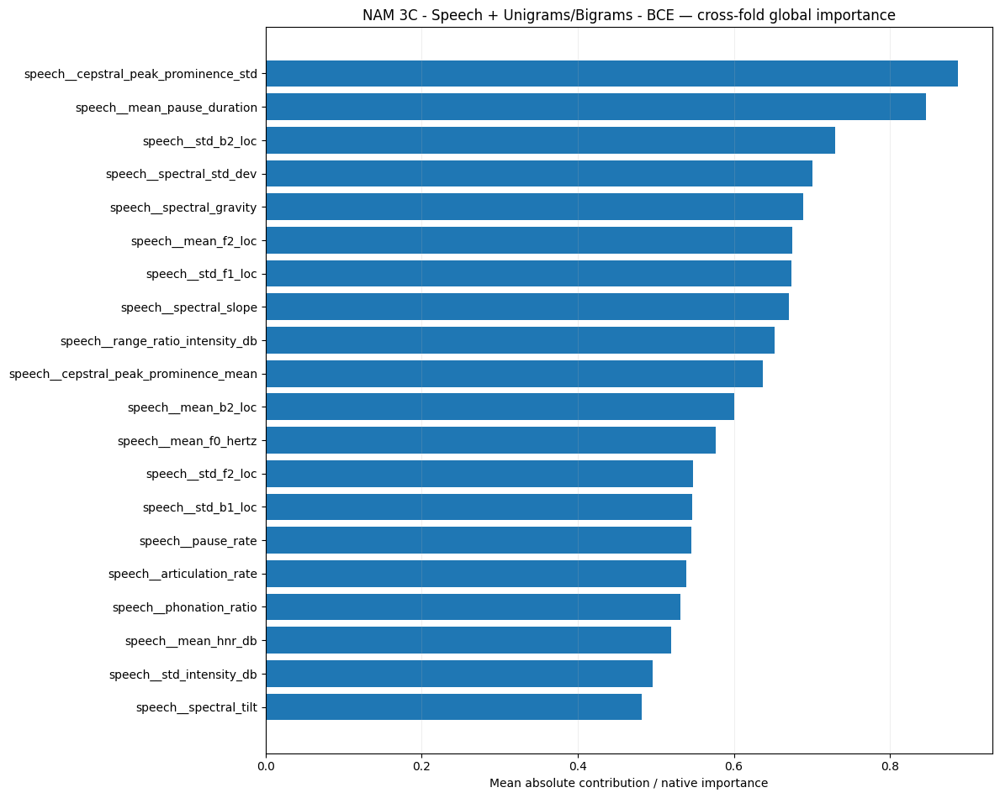

/tmp/ipykernel_4535/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic



Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
44,text__well my,2,0.981223,NaN,0.045286,0.101332,0.000000,0.071999
29,text__alright,2,0.779564,NaN,0.078528,0.187425,0.000000,0.123468
31,text__diagnosed,3,0.742658,0.173911,0.175489,0.406808,0.000000,0.056050
39,text__probably a,2,0.621657,NaN,0.172925,0.415793,0.000000,0.081510
3,speech__mean_b1_loc,5,0.621429,0.321580,0.475388,0.644902,-1.699834,2.741646
37,text__parent,2,0.282195,NaN,0.177853,0.251276,0.000000,0.072535
24,speech__std_f1_loc,5,0.220047,0.718646,0.850137,1.202643,-1.898396,2.051157
1,speech__cepstral_peak_prominence_mean,5,0.172190,0.756755,0.660899,0.894184,-2.021945,1.970126
7,speech__mean_f2_loc,5,0.149917,0.806196,0.950474,1.199700,-2.080074,2.188417
40,text__therapist,5,0.136488,0.471091,0.129414,0.412132,0.000000,0.072054


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 3c (corresponds to DNAMite 3e)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_3c_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3c",
    dnamite_experiment_id="3e",
    experiment_name='NAM 3C - Speech + Unigrams/Bigrams - BCE',
    task="classification",
    cv_results=experiment_3c_classification_cv,
    final_result=experiment_3c_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3c",
    )
] = NAM_v1_3c_report


### Experiment 3d Speech + Unigram/Bigram Regression

In [ ]:
experiment_3d_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3D - "
            "Speech + Unigrams/Bigrams - "
            "Regression Baseline"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3D - Speech + Unigrams/Bigrams - Regression Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 1370.1 MB


[codecarbon WARNING @ 03:29:08] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=115.353973; hit ceiling=True
RAM memory:
  start: 1370.09375 MB
  absolute peak: 3161.55078125 MB
  incremental peak: 1791.45703125 MB
GPU memory:
  start: 0.0 MB
  end: 0.183349609375 MB
  absolute peak: 0.27197265625 MB
  incremental peak: 0.27197265625 MB
[RAM] after inner cleanup: 3133.6 MB
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 3133.6 MB
GPU memory at training start: 0.109130859375 MB
Epochs ran=200; best epoch=200; best val_loss=274.894409; hit ceiling=True
RAM memory:
  start: 3133.5859375 MB
  absolute peak: 4022.08203125 MB
  incremental peak: 888.49609375 MB
GPU memory:
  start: 0.109130859375 MB
  end: 0.291015625 MB
  absolute peak: 0.372802734375 MB
  incremental peak: 0.263671875 MB
[RAM] after inner cleanup: 3980.4 MB
Selected 39 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 3980.4 MB
GPU memory at training start: 0.215820

/tmp/ipykernel_726066/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 17.717360531842267, 'rmse': np.float64(19.31331192607838), 'r2': -10.856628969951469, 'spearman_rho': np.float64(-0.20539735461814593), 'spearman_p': np.float64(0.30405117760174255), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.0)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_Baseline/fold_03/model.weights.h5

Outer Fold 4/5
Selected 45 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 28642.6 MB
GPU memory at training start: 4.009765625 MB
Epochs ran=200; best epoch=200; best val_loss=43.986618; hit ceiling=True
RAM memory:
  start: 28642.59375 MB
  absolute peak: 29566.6328125 MB
  incremental peak: 924.0390625 MB
GPU memory:
  start: 4.009765625 MB
  end: 4.184814453125 MB
  absolute peak: 4.26318359375 MB
  incremental peak: 0.25341796

/tmp/ipykernel_726066/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 9.096684561835396, 'rmse': np.float64(10.566893811137376), 'r2': -3.290059527287716, 'spearman_rho': np.float64(0.057904803099310447), 'spearman_p': np.float64(0.7741999940109818), 'exact_accuracy': np.float64(0.037037037037037035), 'within_1': np.float64(0.07407407407407407), 'within_2': np.float64(0.07407407407407407), 'within_3': np.float64(0.18518518518518517)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_Baseline/fold_04/model.weights.h5

Outer Fold 5/5
Selected 52 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 36841.8 MB
GPU memory at training start: 5.3212890625 MB
Epochs ran=200; best epoch=200; best val_loss=36.344681; hit ceiling=True
RAM memory:
  start: 36841.84765625 MB
  absolute peak: 37936.1640625 MB
  incremental peak: 1094.31640625 MB
GPU memory:
  start: 5.3212890625 MB
  end: 5.50830078125 MB
  absolute 

/tmp/ipykernel_726066/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 11.381708886888292, 'rmse': np.float64(12.45375176904181), 'r2': -3.901800713086832, 'spearman_rho': np.float64(-0.0453573933798693), 'spearman_p': np.float64(0.8222538986184287), 'exact_accuracy': np.float64(0.0), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.037037037037037035)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_Baseline/fold_05/model.weights.h5


In [ ]:
experiment_3d_regression_summary = (
    summarize_nested_cv(
        experiment_3d_regression_cv
    )
)

display(
    experiment_3d_regression_summary
)

   outer_fold        mae       rmse         r2  spearman_rho  spearman_p  \
0           1   4.752461   5.582645  -0.123972      0.135947    0.498962   
1           2  11.431162  13.242204  -3.493620      0.245402    0.217285   
2           3  17.717361  19.313312 -10.856629     -0.205397    0.304051   
3           4   9.096685  10.566894  -3.290060      0.057905    0.774200   
4           5  11.381709  12.453752  -3.901801     -0.045357    0.822254   

   exact_accuracy  within_1  within_2  within_3  selected_text_count  \
0        0.000000  0.037037  0.259259  0.333333                   60   
1        0.185185  0.000000  0.000000  0.037037                   50   
2        0.148148  0.000000  0.000000  0.000000                   54   
3        0.037037  0.074074  0.074074  0.185185                   50   
4        0.000000  0.000000  0.000000  0.037037                   59   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3         

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,4.752461,5.582645,-0.123972,0.135947,0.498962,0.000000,0.037037,0.259259,0.333333,60,None
1,2,11.431162,13.242204,-3.493620,0.245402,0.217285,0.185185,0.000000,0.000000,0.037037,50,None
2,3,17.717361,19.313312,-10.856629,-0.205397,0.304051,0.148148,0.000000,0.000000,0.000000,54,None
3,4,9.096685,10.566894,-3.290060,0.057905,0.774200,0.037037,0.074074,0.074074,0.185185,50,None
4,5,11.381709,12.453752,-3.901801,-0.045357,0.822254,0.000000,0.000000,0.000000,0.037037,59,None


In [ ]:
for result in experiment_3d_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected text features: 60

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected text features: 50

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected text features: 54

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected text features: 50

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}
Selected text features: 59



In [ ]:
experiment_3d_best_parameters = (
    choose_final_parameters(
        experiment_3d_regression_cv
    )
)

print(
    experiment_3d_best_parameters
)

{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
EXPERIMENT_3D_NAME = (
    "NAM 3D - "
    "Speech + Unigrams/Bigrams - "
    "Regression Baseline"
)

experiment_3d_regression_final = (
    train_final_nam_model(
        task="regression",
        speech_development=development_speech,
        y_development=y_regression_development,
        speech_test=test_speech,
        y_test=y_regression_test,

        parameters=(
            experiment_3d_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
GPU memory at training start: 6.686279296875 MB
Epochs ran=200; best epoch=200; best val_loss=46.161579; hit ceiling=True
RAM memory:
  start: 45833.625 MB
  absolute peak: 46439.67578125 MB
  incremental peak: 606.05078125 MB
GPU memory:
  start: 6.686279296875 MB
  end: 6.86474609375 MB
  absolute peak: 6.943603515625 MB
  incremental peak: 0.25732421875 MB
Best training epochs: 200
Selected 59 TF-IDF features for regression / unigram_bigram using alpha=0.01
RAM memory:
  start: 46396.578125 MB
  absolute peak: 47663.0 MB
  incremental peak: 1266.421875 MB

FINAL TEST METRICS
{'mae': 8.191984234944634, 'rmse': np.float64(10.413255050258186), 'r2': -1.6385428370130941, 'spearman_rho': np.float64(0.24443094409798413), 'spearman_p': np.float64(0.10160392706042752), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.06521739130434782), 'within_2': np.float64(0.21739130434782608), 'within

In [ ]:
experiment_3d_regression_final[
    "metrics"
]

{'mae': 8.191984234944634,
 'rmse': np.float64(10.413255050258186),
 'r2': -1.6385428370130941,
 'spearman_rho': np.float64(0.24443094409798413),
 'spearman_p': np.float64(0.10160392706042752),
 'exact_accuracy': np.float64(0.08695652173913043),
 'within_1': np.float64(0.06521739130434782),
 'within_2': np.float64(0.21739130434782608),
 'within_3': np.float64(0.2608695652173913)}

In [ ]:
experiment_3d_regression_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

#### NAM v1 Experiment 3d — DNAMite-parity outputs (maps to DNAMite 3c)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 3d — NAM 3D - Speech + Unigrams/Bigrams - Regression Baseline
DNAMite reference experiment: 3c

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,4.752461,5.582645,-0.123972,0.135947,0.498962,0.000000,0.037037,0.259259,0.333333,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",60,None,200,200,True
1,2,11.431162,13.242204,-3.493620,0.245402,0.217285,0.185185,0.000000,0.000000,0.037037,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",50,None,200,200,True
2,3,17.717361,19.313312,-10.856629,-0.205397,0.304051,0.148148,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",54,None,200,200,True
3,4,9.096685,10.566894,-3.290060,0.057905,0.774200,0.037037,0.074074,0.074074,0.185185,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",50,None,200,200,True
4,5,11.381709,12.453752,-3.901801,-0.045357,0.822254,0.000000,0.000000,0.000000,0.037037,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",59,None,200,200,True



CV Mean ± SD


,mean,sd
mae,10.875875,4.691264
rmse,12.231761,4.954825
r2,-4.333216,3.944993
spearman_rho,0.037700,0.172624
spearman_p,0.523350,0.271400
exact_accuracy,0.074074,0.086860
within_1,0.022222,0.033127
within_2,0.066667,0.112339
within_3,0.118519,0.139566
selected_text_count,54.600000,4.774935



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,1,182.934514,10827.761719,12002.214844,1174.453125,0.298584,NaN,1.251465,1.452148,1.550049,tensorflow,8449,0.731071
1,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,2,175.021867,19142.457031,20318.335938,1175.878906,0.284180,NaN,2.579346,2.762939,2.863525,tensorflow,14977,0.674294
2,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,3,175.533745,27865.093750,28893.785156,1028.691406,0.276367,NaN,3.899414,4.089844,4.175781,tensorflow,7873,0.677780
3,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,4,176.934640,36118.570312,37091.656250,973.085938,0.284180,NaN,5.213867,5.397461,5.498047,tensorflow,14977,0.674294
4,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,5,198.264368,44811.828125,45967.648438,1155.820312,0.310547,NaN,6.572266,6.771240,6.882812,tensorflow,16705,0.754692



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,1,0.005809,0.002735
1,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,2,0.005734,0.002700
2,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,3,0.005568,0.002621
3,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,4,0.005793,0.002727
4,NAM v1,NAM 3D - Speech + Unigrams/Bigrams - Regressio...,regression,5,0.006297,0.002964



Final Test Metrics
{'mae': 8.191984234944634, 'rmse': np.float64(10.413255050258186), 'r2': -1.6385428370130941, 'spearman_rho': np.float64(0.24443094409798413), 'spearman_p': np.float64(0.10160392706042752), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.06521739130434782), 'within_2': np.float64(0.21739130434782608), 'within_3': np.float64(0.2608695652173913)}

Final Model Resource Summary
{'train_seconds': 157.1402924009999, 'start_ram_mb': 46396.578125, 'peak_ram_mb': 47663.0, 'incremental_peak_ram_mb': 1266.421875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.005164641900601969, 'training_co2_kg': 0.002431425607891097}


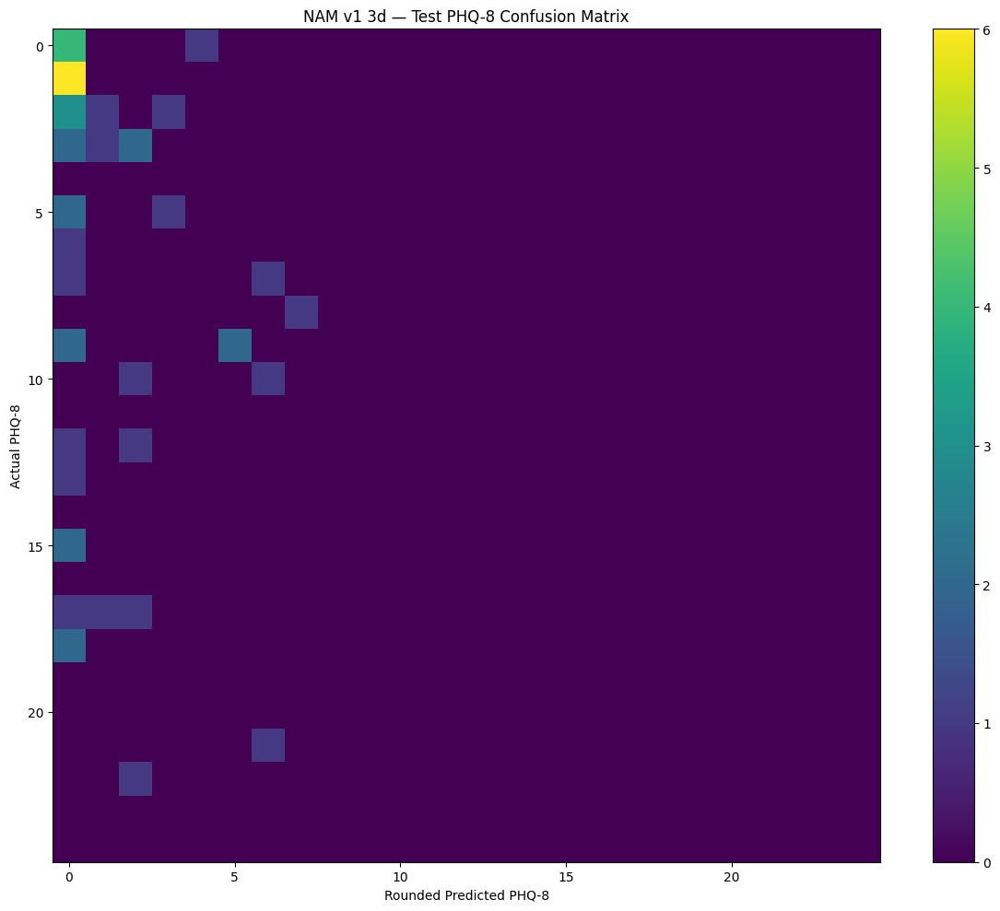

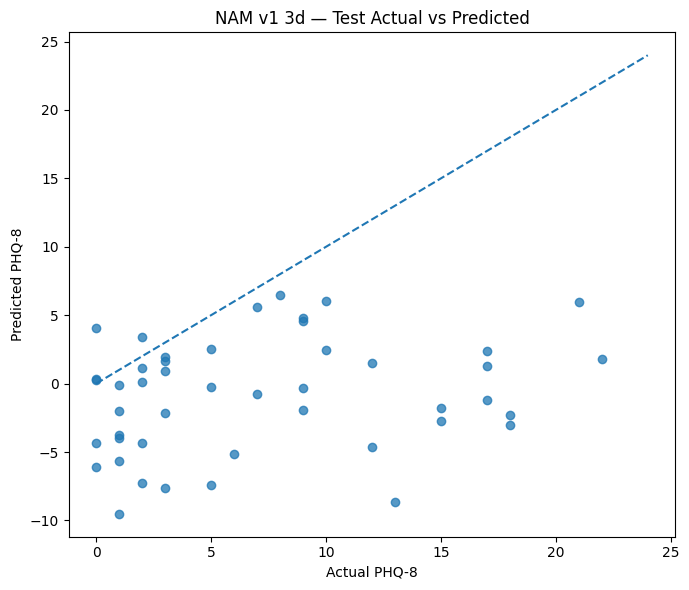


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
10,speech__mean_hnr_db,speech,1.295278,0.050574,1.139262
1,speech__articulation_rate,speech,0.989898,0.354426,-0.399205
17,speech__std_f1_loc,speech,0.931241,-0.230851,1.395270
23,speech__std_b2_loc,speech,0.771781,-0.071999,0.780415
3,speech__pause_rate,speech,0.756329,-0.036174,-1.331412
2,speech__phonation_ratio,speech,0.719587,0.169094,0.899021
24,speech__spectral_gravity,speech,0.691613,-0.135410,0.956328
11,speech__std_hnr_db,speech,0.670068,0.094387,-0.821122
20,speech__mean_f2_loc,speech,0.661411,-0.060448,0.733919
8,speech__std_intensity_db,speech,0.640537,0.037144,-0.320237



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


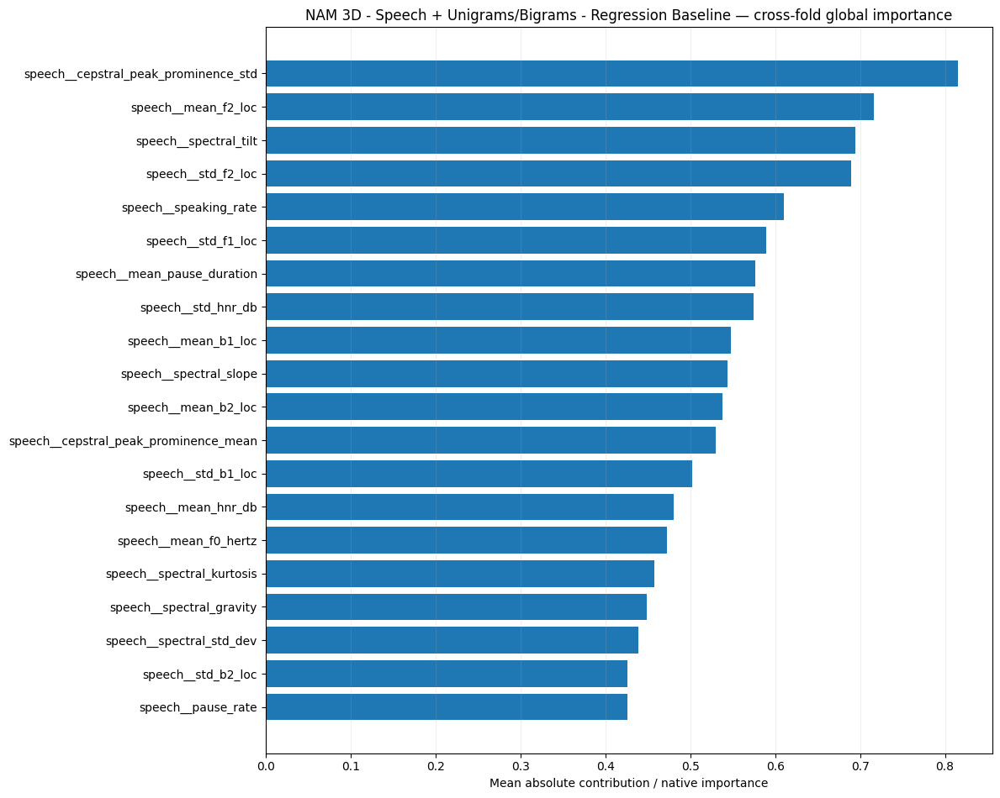

/tmp/ipykernel_726066/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_726066/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_726066/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_726066/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_726066/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_726066/1559648166.py:694: ConstantInputWarning: An input arr


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
54,text__learn,2,0.966147,NaN,0.063991,0.233515,0.000000,0.052229
60,text__not easy,2,0.931826,NaN,0.041181,0.113838,0.000000,0.068840
43,text__even though,2,0.827289,NaN,0.065390,0.172891,0.000000,0.063869
46,text__guilty,4,0.785952,0.150823,0.067002,0.138215,0.000000,0.057285
52,text__know how,2,0.663816,NaN,0.234668,0.433601,0.000000,0.049848
57,text__medication,4,0.609944,0.319824,0.121272,0.235695,0.000000,0.069426
26,speech__std_hnr_db,5,0.534475,0.166751,0.441136,0.566542,-1.297804,2.635509
22,speech__std_b2_loc,5,0.531774,0.253042,0.383822,0.909821,-1.384901,2.373243
2,speech__cepstral_peak_prominence_std,5,0.488872,0.286184,0.727485,0.965146,-2.126806,2.421201
37,text__but uh,2,0.481363,NaN,0.065610,0.155788,0.000000,0.063961


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 3d (corresponds to DNAMite 3c)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_3d_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3d",
    dnamite_experiment_id="3c",
    experiment_name='NAM 3D - Speech + Unigrams/Bigrams - Regression Baseline',
    task="regression",
    cv_results=experiment_3d_regression_cv,
    final_result=experiment_3d_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3d",
    )
] = NAM_v1_3d_report


In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 3d complete. "
    "Waiting for file writes..."
)

time.sleep(20)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 3d complete. Waiting for file writes...
Disconnecting runtime.


### Experiment 3e Speech + Unigram/Bigram Regression with Feature Selection

In [ ]:
experiment_3e_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3E - "
            "Speech + Unigrams/Bigrams - "
            "Feature Selection"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3E - Speech + Unigrams/Bigrams - Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 48 features, alpha=0.01
[RAM] before inner fit: 1366.5 MB


[codecarbon WARNING @ 16:42:44] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=57.995613; hit ceiling=True
RAM memory:
  start: 1366.47265625 MB
  absolute peak: 2778.98046875 MB
  incremental peak: 1412.5078125 MB
GPU memory:
  start: 0.0 MB
  end: 0.135498046875 MB
  absolute peak: 0.185546875 MB
  incremental peak: 0.185546875 MB
[RAM] after inner cleanup: 2782.3 MB
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 45 features, alpha=0.01
[RAM] before inner fit: 2782.4 MB
GPU memory at training start: 0.088623046875 MB
Epochs ran=200; best epoch=200; best val_loss=255.254364; hit ceiling=True
RAM memory:
  start: 2782.359375 MB
  absolute peak: 3162.046875 MB
  incremental peak: 379.6875 MB
GPU memory:
  start: 0.088623046875 MB
  end: 0.2158203125 MB
  absolute peak: 0.259033203125 MB
  incremental peak: 0.17041015625 MB
[RAM] after inner cleanup: 3162.7 MB
Selected 39 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 40 features, alpha=0.

/tmp/ipykernel_1054/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 19.422395564891673, 'rmse': np.float64(20.32237126379748), 'r2': -12.127936953355722, 'spearman_rho': np.float64(0.045064792729652914), 'spearman_p': np.float64(0.8233827176978433), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.0)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Selection/fold_03/model.weights.h5

Outer Fold 4/5
Selected 45 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 45 features, alpha=0.01
[RAM] before inner fit: 18653.9 MB
GPU memory at training start: 3.22900390625 MB
Epochs ran=200; best epoch=200; best val_loss=69.807457; hit ceiling=True
RAM memory:
  start: 18653.90625 MB
  absolute peak: 19050.77734375 MB
  incremental peak: 396.87109375 MB
GPU memory:
  start: 3.22900390625 MB
  end: 3.356201171875 MB
  absolute peak: 3.4

/tmp/ipykernel_1054/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 5.357599906347416, 'rmse': np.float64(6.982711004870487), 'r2': -0.8733406988840637, 'spearman_rho': np.float64(-0.0934442589697867), 'spearman_p': np.float64(0.6429403499886543), 'exact_accuracy': np.float64(0.07407407407407407), 'within_1': np.float64(0.18518518518518517), 'within_2': np.float64(0.2962962962962963), 'within_3': np.float64(0.4444444444444444)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Selection/fold_04/model.weights.h5

Outer Fold 5/5
Selected 52 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 51 features, alpha=0.01
[RAM] before inner fit: 23917.3 MB
GPU memory at training start: 4.22998046875 MB
Epochs ran=200; best epoch=200; best val_loss=76.273590; hit ceiling=True
RAM memory:
  start: 23917.34765625 MB
  absolute peak: 24483.22265625 MB
  incremental peak: 565.875 MB
GPU memory:
  start: 4.22998046875 MB
  e

/tmp/ipykernel_1054/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 22.052558934247052, 'rmse': np.float64(22.79953047803041), 'r2': -15.428845578929451, 'spearman_rho': np.float64(0.3233246622686629), 'spearman_p': np.float64(0.09995428365894256), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.0), 'within_2': np.float64(0.0), 'within_3': np.float64(0.0)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Selection/fold_05/model.weights.h5


In [ ]:
experiment_3e_regression_summary = (
    summarize_nested_cv(
        experiment_3e_regression_cv
    )
)

display(
    experiment_3e_regression_summary
)

   outer_fold        mae       rmse         r2  spearman_rho  spearman_p  \
0           1  10.386136  12.342370  -4.493794     -0.353645    0.070353   
1           2   5.844395   7.140556  -0.306592     -0.043559    0.829198   
2           3  19.422396  20.322371 -12.127937      0.045065    0.823383   
3           4   5.357600   6.982711  -0.873341     -0.093444    0.642940   
4           5  22.052559  22.799530 -15.428846      0.323325    0.099954   

   exact_accuracy  within_1  within_2  within_3  selected_text_count  \
0        0.074074  0.000000  0.074074  0.111111                   60   
1        0.037037  0.111111  0.296296  0.333333                   50   
2        0.148148  0.000000  0.000000  0.000000                   54   
3        0.074074  0.185185  0.296296  0.444444                   50   
4        0.148148  0.000000  0.000000  0.000000                   59   

   joint_selected_count  
0                    52  
1                    45  
2                    53  
3     

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,10.386136,12.342370,-4.493794,-0.353645,0.070353,0.074074,0.000000,0.074074,0.111111,60,52
1,2,5.844395,7.140556,-0.306592,-0.043559,0.829198,0.037037,0.111111,0.296296,0.333333,50,45
2,3,19.422396,20.322371,-12.127937,0.045065,0.823383,0.148148,0.000000,0.000000,0.000000,54,53
3,4,5.357600,6.982711,-0.873341,-0.093444,0.642940,0.074074,0.185185,0.296296,0.444444,50,54
4,5,22.052559,22.799530,-15.428846,0.323325,0.099954,0.148148,0.000000,0.000000,0.000000,59,51


In [ ]:
for result in experiment_3e_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected unigram/bigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected unigram/bigram features: 60
Final jointly selected features: 52

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}
Selected unigram/bigram features: 50
Final jointly selected features: 45

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 64, 'shallow': True}
Selected unigram/bigram features: 54
Final jointly selected features: 53

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected unigram/bigram features: 50
Final jointly selected features: 54

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected unigram/bigram features: 59


In [ ]:
experiment_3e_best_parameters = (
    choose_final_parameters(
        experiment_3e_regression_cv
    )
)

print(
    experiment_3e_best_parameters
)

{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_3e_regression_final = (
    train_final_nam_model(
        task="regression",
        speech_development=development_speech,
        y_development=y_regression_development,
        speech_test=test_speech,
        y_test=y_regression_test,

        parameters=(
            experiment_3e_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 46 features, alpha=0.01
GPU memory at training start: 5.3017578125 MB
Epochs ran=200; best epoch=200; best val_loss=304.341370; hit ceiling=True
RAM memory:
  start: 29178.63671875 MB
  absolute peak: 29445.39453125 MB
  incremental peak: 266.7578125 MB
GPU memory:
  start: 5.3017578125 MB
  end: 5.4306640625 MB
  absolute peak: 5.4775390625 MB
  incremental peak: 0.17578125 MB
Best training epochs: 200
Selected 59 TF-IDF features for regression / unigram_bigram using alpha=0.01
Joint selection: 60 features, alpha=0.01
RAM memory:
  start: 29317.359375 MB
  absolute peak: 30322.4375 MB
  incremental peak: 1005.078125 MB

FINAL TEST METRICS
{'mae': 7.585549400552459, 'rmse': np.float64(9.722998664244633), 'r2': -1.3003376640182913, 'spearman_rho': np.float64(0.15573265519132137), 'spearman_p': np.float64(0.3013772249623852), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.floa

In [ ]:
experiment_3e_regression_final[
    "metrics"
]

{'mae': 7.585549400552459,
 'rmse': np.float64(9.722998664244633),
 'r2': -1.3003376640182913,
 'spearman_rho': np.float64(0.15573265519132137),
 'spearman_p': np.float64(0.3013772249623852),
 'exact_accuracy': np.float64(0.08695652173913043),
 'within_1': np.float64(0.08695652173913043),
 'within_2': np.float64(0.17391304347826086),
 'within_3': np.float64(0.2608695652173913)}

In [ ]:
print(
    "Final jointly selected features:",
    len(
        experiment_3e_regression_final[
            "joint_selected_indices"
        ]
    )
)

Final jointly selected features: 60


In [ ]:
experiment_3e_regression_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

#### NAM v1 Experiment 3e — DNAMite-parity outputs (maps to DNAMite 3d)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 3e — NAM 3E - Speech + Unigrams/Bigrams - Feature Selection
DNAMite reference experiment: 3d

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,10.386136,12.342370,-4.493794,-0.353645,0.070353,0.074074,0.000000,0.074074,0.111111,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",60,52,200,200,True
1,2,5.844395,7.140556,-0.306592,-0.043559,0.829198,0.037037,0.111111,0.296296,0.333333,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",50,45,200,200,True
2,3,19.422396,20.322371,-12.127937,0.045065,0.823383,0.148148,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",54,53,200,200,True
3,4,5.357600,6.982711,-0.873341,-0.093444,0.642940,0.074074,0.185185,0.296296,0.444444,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",50,54,200,200,True
4,5,22.052559,22.799530,-15.428846,0.323325,0.099954,0.148148,0.000000,0.000000,0.000000,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",59,51,200,200,True



CV Mean ± SD


,mean,sd
mae,12.612617,7.727983
rmse,13.917508,7.355477
r2,-6.646102,6.806866
spearman_rho,-0.024452,0.244578
spearman_p,0.493166,0.380059
exact_accuracy,0.096296,0.049690
within_1,0.059259,0.085266
within_2,0.133333,0.151807
within_3,0.177778,0.201843
selected_text_count,54.600000,4.774935



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,1,117.404260,7194.949219,8016.269531,821.320312,0.191406,NaN,0.996582,1.135742,1.187988,tensorflow,4993,0.434990
1,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,2,110.447497,12296.199219,13032.000000,735.800781,0.186035,NaN,2.046143,2.173340,2.232178,tensorflow,8641,0.394943
2,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,3,128.780102,17848.906250,18596.332031,747.425781,0.208984,NaN,3.139893,3.280762,3.348877,tensorflow,10177,0.462151
3,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,4,124.867273,23225.914062,23834.851562,608.937500,0.197266,NaN,4.140137,4.282715,4.337402,tensorflow,5185,0.452202
4,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,5,120.057272,28568.699219,29126.023438,557.324219,0.189209,NaN,5.214111,5.351562,5.403320,tensorflow,4897,0.427361



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,1,0.003715,0.001749
1,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,2,0.003498,0.001647
2,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,3,0.004086,0.001924
3,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,4,0.003953,0.001861
4,NAM v1,NAM 3E - Speech + Unigrams/Bigrams - Feature S...,regression,5,0.003803,0.001790



Final Test Metrics
{'mae': 7.585549400552459, 'rmse': np.float64(9.722998664244633), 'r2': -1.3003376640182913, 'spearman_rho': np.float64(0.15573265519132137), 'spearman_p': np.float64(0.3013772249623852), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.08695652173913043), 'within_2': np.float64(0.17391304347826086), 'within_3': np.float64(0.2608695652173913)}

Final Model Resource Summary
{'train_seconds': 113.04654177199882, 'start_ram_mb': 29317.359375, 'peak_ram_mb': 30322.4375, 'incremental_peak_ram_mb': 1005.078125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0035797811608741215, 'training_co2_kg': 0.0016853001142598015}


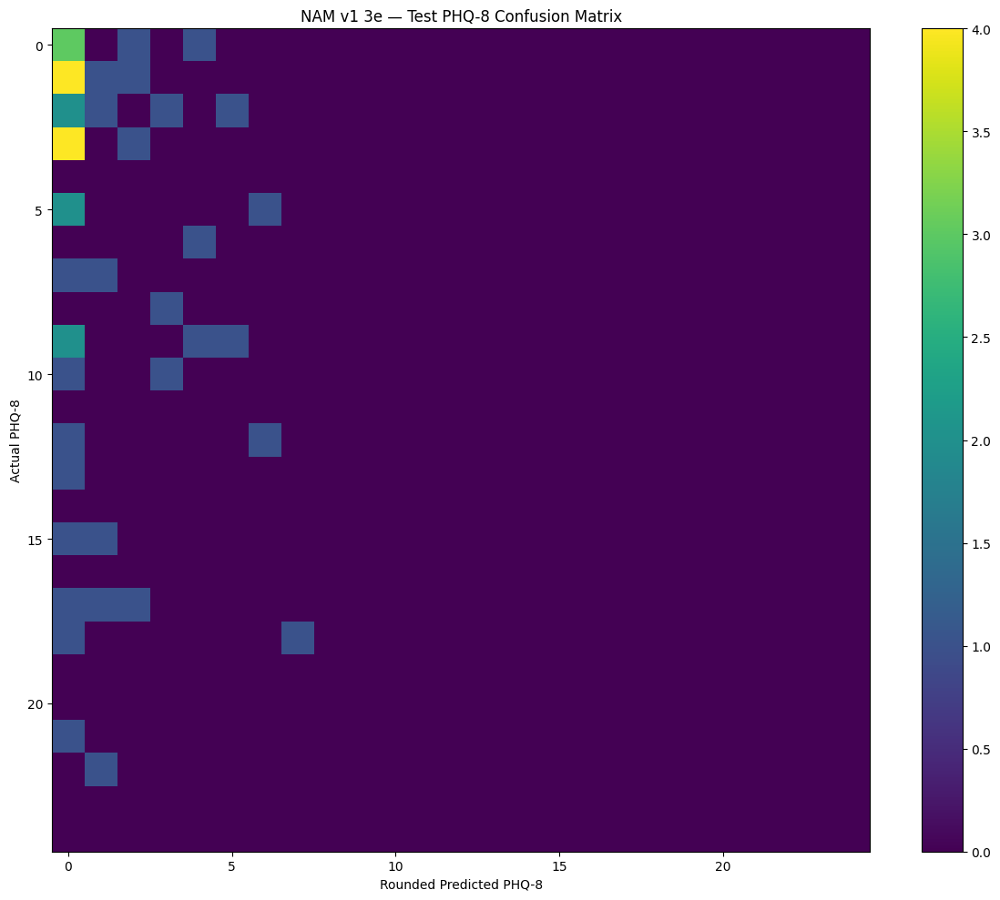

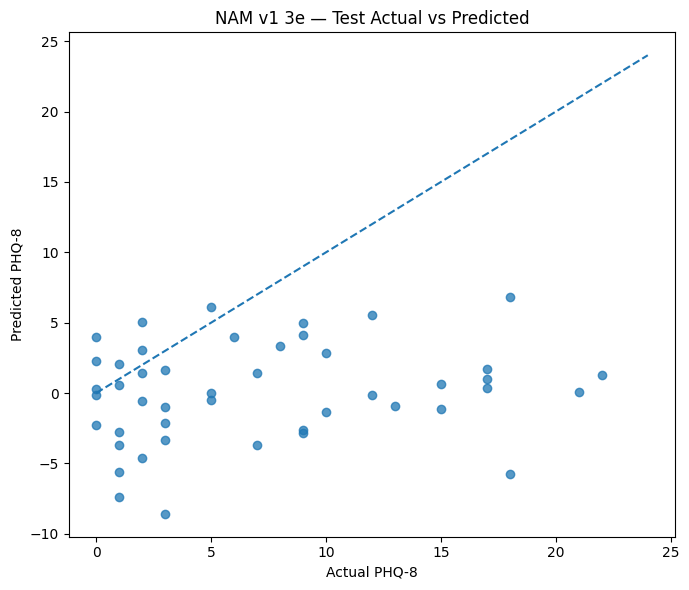


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
6,speech__std_f0_hertz,speech,1.256081,-0.001135,-1.231124
12,speech__spectral_slope,speech,0.848643,0.047676,-0.930841
3,speech__pause_rate,speech,0.802198,0.032918,-1.104142
7,speech__mean_intensity_db,speech,0.723933,-0.167763,-0.664622
4,speech__mean_pause_duration,speech,0.691818,-0.265439,0.633711
5,speech__mean_f0_hertz,speech,0.682145,0.185173,0.968911
22,speech__mean_b2_loc,speech,0.641897,0.043344,0.750775
25,speech__spectral_std_dev,speech,0.627904,0.223496,-0.688409
15,speech__cepstral_peak_prominence_std,speech,0.479213,0.185963,-0.634381
13,speech__spectral_tilt,speech,0.406532,-0.002643,-0.172263



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


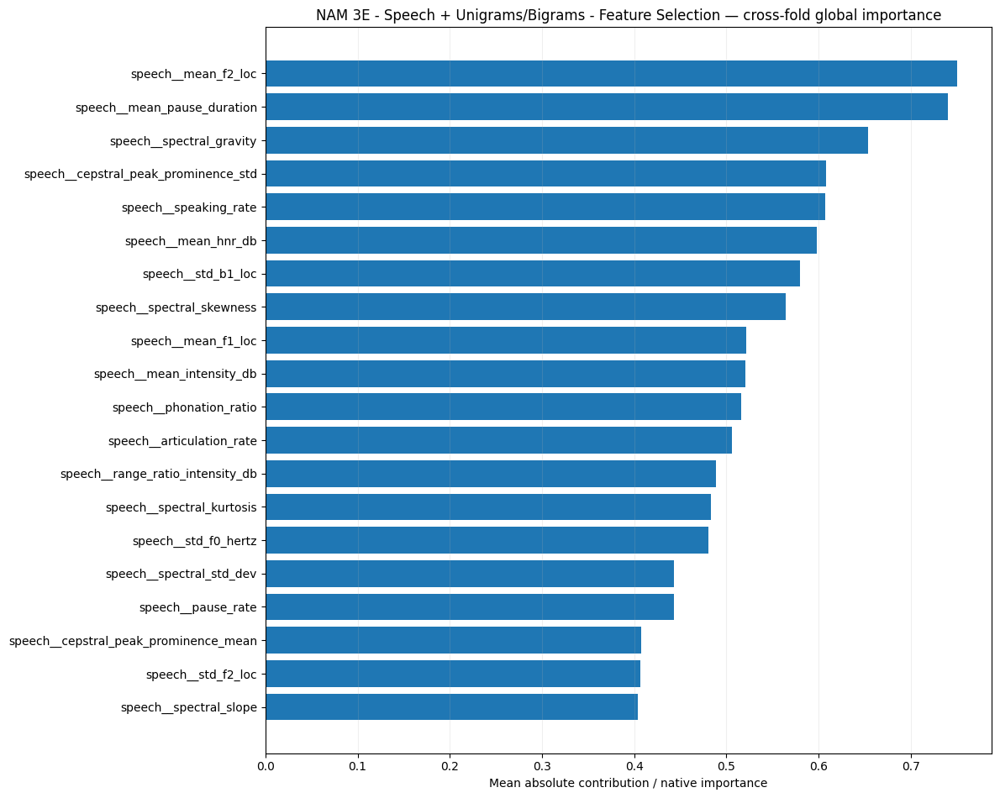

/tmp/ipykernel_1054/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_1054/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_1054/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_1054/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic



Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
33,text__depressed,3,0.876798,0.081365,0.045490,0.109266,0.000000,0.054934
50,text__they just,2,0.831055,NaN,0.062478,0.144000,0.000000,0.056212
46,text__started,2,0.577747,NaN,0.051749,0.095199,0.000000,0.049497
29,text__annotation_sniff,2,0.482808,NaN,0.133719,0.267182,0.000000,0.166479
3,speech__mean_b1_loc,5,0.346072,0.302429,0.256929,0.503845,-1.631855,2.672147
13,speech__range_ratio_intensity_db,5,0.340541,0.335894,0.472668,0.887162,-1.038661,0.829560
54,text__who i,3,0.323062,NaN,0.037458,0.049047,0.000000,0.063918
2,speech__cepstral_peak_prominence_std,5,0.151319,0.800231,0.585939,0.736868,-2.126806,2.421201
7,speech__mean_f2_loc,5,0.133883,0.828961,0.843472,1.100418,-2.069726,2.197272
14,speech__speaking_rate,4,0.115415,0.731884,0.603319,0.866579,-2.406785,1.658730


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 3e (corresponds to DNAMite 3d)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_3e_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3e",
    dnamite_experiment_id="3d",
    experiment_name='NAM 3E - Speech + Unigrams/Bigrams - Feature Selection',
    task="regression",
    cv_results=experiment_3e_regression_cv,
    final_result=experiment_3e_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3e",
    )
] = NAM_v1_3e_report


### Experiment 3f Speech + Unigram/Bigram Regression with LDS

In [ ]:
experiment_3f_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3F - "
            "Speech + Unigrams/Bigrams - "
            "LDS"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3F - Speech + Unigrams/Bigrams - LDS
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Selected 48 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 1365.7 MB


[codecarbon WARNING @ 04:03:42] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=200; best epoch=200; best val_loss=93.514320; hit ceiling=True
RAM memory:
  start: 1365.6796875 MB
  absolute peak: 3381.18359375 MB
  incremental peak: 2015.50390625 MB
GPU memory:
  start: 0.0 MB
  end: 0.183349609375 MB
  absolute peak: 0.27197265625 MB
  incremental peak: 0.27197265625 MB
[RAM] after inner cleanup: 3352.8 MB
Selected 49 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 3352.9 MB
GPU memory at training start: 0.109130859375 MB
Epochs ran=21; best epoch=1; best val_loss=38.844986; hit ceiling=False
RAM memory:
  start: 3352.89453125 MB
  absolute peak: 4186.12109375 MB
  incremental peak: 833.2265625 MB
GPU memory:
  start: 0.109130859375 MB
  end: 0.247314453125 MB
  absolute peak: 0.32958984375 MB
  incremental peak: 0.220458984375 MB
[RAM] after inner cleanup: 3742.6 MB
Selected 39 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 3744.1 MB
GPU memory at training start: 0.172

/tmp/ipykernel_4839/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 7.219936792497282, 'rmse': np.float64(9.198085791201382), 'r2': -1.6893209313707707, 'spearman_rho': np.float64(0.15174879184474963), 'spearman_p': np.float64(0.4498946599076078), 'exact_accuracy': np.float64(0.18518518518518517), 'within_1': np.float64(0.18518518518518517), 'within_2': np.float64(0.2222222222222222), 'within_3': np.float64(0.25925925925925924)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS/fold_03/model.weights.h5

Outer Fold 4/5
Selected 45 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 28683.4 MB
GPU memory at training start: 3.937255859375 MB
Epochs ran=200; best epoch=200; best val_loss=58.186279; hit ceiling=True
RAM memory:
  start: 28683.44921875 MB
  absolute peak: 29564.3671875 MB
  incremental peak: 880.91796875 MB
GPU memory:
  start: 3.937255859375 MB
  end: 4.1123046875 MB
  absolute peak: 4.191162109

/tmp/ipykernel_4839/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 5.553586543710144, 'rmse': np.float64(6.5158517634613995), 'r2': -0.6312143113882582, 'spearman_rho': np.float64(0.4031889993581616), 'spearman_p': np.float64(0.03703736935317318), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.07407407407407407), 'within_2': np.float64(0.18518518518518517), 'within_3': np.float64(0.2962962962962963)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS/fold_04/model.weights.h5

Outer Fold 5/5
Selected 52 TF-IDF features for regression / unigram_bigram using alpha=0.01
[RAM] before inner fit: 36753.7 MB
GPU memory at training start: 5.205078125 MB
Epochs ran=200; best epoch=200; best val_loss=33.853897; hit ceiling=True
RAM memory:
  start: 36753.69140625 MB
  absolute peak: 37811.73046875 MB
  incremental peak: 1058.0390625 MB
GPU memory:
  start: 5.205078125 MB
  end: 5.39208984375 MB
  absolute peak: 5.476806640625

/tmp/ipykernel_4839/2662124513.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 8.369921018679937, 'rmse': np.float64(9.993056302454383), 'r2': -2.1561083863033446, 'spearman_rho': np.float64(0.247320381469963), 'spearman_p': np.float64(0.21359662373648405), 'exact_accuracy': np.float64(0.14814814814814814), 'within_1': np.float64(0.07407407407407407), 'within_2': np.float64(0.1111111111111111), 'within_3': np.float64(0.18518518518518517)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v1/NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS/fold_05/model.weights.h5


In [ ]:
experiment_3f_regression_summary = (
    summarize_nested_cv(
        experiment_3f_regression_cv
    )
)

display(
    experiment_3f_regression_summary
)

   outer_fold       mae      rmse        r2  spearman_rho  spearman_p  \
0           1  4.930331  6.320947 -0.440919      0.000919    0.996372   
1           2  6.654339  9.247465 -1.191398     -0.278531    0.159479   
2           3  7.219937  9.198086 -1.689321      0.151749    0.449895   
3           4  5.553587  6.515852 -0.631214      0.403189    0.037037   
4           5  8.369921  9.993056 -2.156108      0.247320    0.213597   

   exact_accuracy  within_1  within_2  within_3  selected_text_count  \
0        0.074074  0.148148  0.222222  0.407407                   60   
1        0.111111  0.111111  0.259259  0.370370                   50   
2        0.185185  0.185185  0.222222  0.259259                   54   
3        0.148148  0.074074  0.185185  0.296296                   50   
4        0.148148  0.074074  0.111111  0.185185                   59   

  joint_selected_count  
0                 None  
1                 None  
2                 None  
3                 None  
4  

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_text_count,joint_selected_count
0,1,4.930331,6.320947,-0.440919,0.000919,0.996372,0.074074,0.148148,0.222222,0.407407,60,None
1,2,6.654339,9.247465,-1.191398,-0.278531,0.159479,0.111111,0.111111,0.259259,0.370370,50,None
2,3,7.219937,9.198086,-1.689321,0.151749,0.449895,0.185185,0.185185,0.222222,0.259259,54,None
3,4,5.553587,6.515852,-0.631214,0.403189,0.037037,0.148148,0.074074,0.185185,0.296296,50,None
4,5,8.369921,9.993056,-2.156108,0.247320,0.213597,0.148148,0.074074,0.111111,0.185185,59,None


In [ ]:
for result in experiment_3f_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 64, 'shallow': True}
Selected text features: 60

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}
Selected text features: 50

Outer Fold 3
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected text features: 54

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected text features: 50

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}
Selected text features: 59



In [ ]:
experiment_3f_best_parameters = (
    choose_final_parameters(
        experiment_3f_regression_cv
    )
)

print(
    experiment_3f_best_parameters
)

{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 32, 'shallow': True}


In [ ]:
experiment_3f_regression_final = (
    train_final_nam_model(
        task="regression",
        speech_development=development_speech,
        y_development=y_regression_development,
        speech_test=test_speech,
        y_test=y_regression_test,

        parameters=(
            experiment_3f_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 47 TF-IDF features for regression / unigram_bigram using alpha=0.01
GPU memory at training start: 6.56982421875 MB
Epochs ran=200; best epoch=200; best val_loss=76.144989; hit ceiling=True
RAM memory:
  start: 45951.19140625 MB
  absolute peak: 46496.6953125 MB
  incremental peak: 545.50390625 MB
GPU memory:
  start: 6.56982421875 MB
  end: 6.748291015625 MB
  absolute peak: 6.827880859375 MB
  incremental peak: 0.258056640625 MB
Best training epochs: 200
Selected 59 TF-IDF features for regression / unigram_bigram using alpha=0.01
RAM memory:
  start: 46274.828125 MB
  absolute peak: 47320.00390625 MB
  incremental peak: 1045.17578125 MB

FINAL TEST METRICS
{'mae': 12.023572845303494, 'rmse': np.float64(14.370453636393988), 'r2': -4.0249540392420196, 'spearman_rho': np.float64(-0.09340245496172653), 'spearman_p': np.float64(0.5369680011052053), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.0), 'within_2': np.float64(0.043478260869565216), 'within_

In [ ]:
experiment_3f_regression_final[
    "metrics"
]

{'mae': 12.023572845303494,
 'rmse': np.float64(14.370453636393988),
 'r2': -4.0249540392420196,
 'spearman_rho': np.float64(-0.09340245496172653),
 'spearman_p': np.float64(0.5369680011052053),
 'exact_accuracy': np.float64(0.08695652173913043),
 'within_1': np.float64(0.0),
 'within_2': np.float64(0.043478260869565216),
 'within_3': np.float64(0.08695652173913043)}

In [ ]:
experiment_3f_regression_final[
    "best_epoch"
]

200

In [ ]:
experiment_3f_regression_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

In [ ]:
def inspect_regression_predictions(
    name,
    final_result,
    y_true,
):
    y_true = np.asarray(
        y_true
    )

    y_pred = np.asarray(
        final_result[
            "predictions"
        ]
    )

    print(
        "\n" + "=" * 60
    )

    print(name)

    print(
        "=" * 60
    )

    print(
        "\nTRUE PHQ-8:"
    )

    print(
        pd.Series(
            y_true
        ).describe()
    )

    print(
        "\nPREDICTED PHQ-8:"
    )

    print(
        pd.Series(
            y_pred
        ).describe()
    )

    print(
        "\nPrediction range:",
        y_pred.min(),
        "to",
        y_pred.max(),
    )

    for tolerance in [
        1,
        2,
        3,
    ]:
        print(
            f"Within ±{tolerance}:",
            np.mean(
                np.abs(
                    y_true - y_pred
                )
                <= tolerance
            )
        )

#### NAM v1 Experiment 3f — DNAMite-parity outputs (maps to DNAMite 3f)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v1 — 3f — NAM 3F - Speech + Unigrams/Bigrams - LDS
DNAMite reference experiment: 3f

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,4.930331,6.320947,-0.440919,0.000919,0.996372,0.074074,0.148148,0.222222,0.407407,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",60,None,200,200,True
1,2,6.654339,9.247465,-1.191398,-0.278531,0.159479,0.111111,0.111111,0.259259,0.370370,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",50,None,200,200,True
2,3,7.219937,9.198086,-1.689321,0.151749,0.449895,0.185185,0.185185,0.222222,0.259259,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",54,None,200,200,True
3,4,5.553587,6.515852,-0.631214,0.403189,0.037037,0.148148,0.074074,0.185185,0.296296,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",50,None,200,200,True
4,5,8.369921,9.993056,-2.156108,0.247320,0.213597,0.148148,0.074074,0.111111,0.185185,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",59,None,200,200,True



CV Mean ± SD


,mean,sd
mae,6.545623,1.359033
rmse,8.255081,1.707369
r2,-1.221792,0.716065
spearman_rho,0.104929,0.259464
spearman_p,0.371276,0.380251
exact_accuracy,0.133333,0.042229
within_1,0.118519,0.048290
within_2,0.200000,0.056169
within_3,0.303704,0.088425
selected_text_count,54.600000,4.774935



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,1,194.254036,10925.609375,12246.574219,1320.964844,0.320557,NaN,1.207764,1.408447,1.528320,tensorflow,16897,0.764275
1,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,2,166.652387,19646.328125,20426.554688,780.226562,0.265625,NaN,2.491943,2.675537,2.757568,tensorflow,7489,0.644997
2,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,3,174.354061,27899.417969,29031.085938,1131.667969,0.277100,NaN,3.826904,4.017334,4.104004,tensorflow,7873,0.677780
3,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,4,169.194194,36020.558594,37041.687500,1021.128906,0.265625,NaN,5.097656,5.281250,5.363281,tensorflow,7489,0.644997
4,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,5,193.644252,44838.464844,45826.144531,987.679688,0.289795,NaN,6.456055,6.654785,6.745850,tensorflow,8353,0.723442



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,1,0.006356,0.002993
1,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,2,0.005453,0.002567
2,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,3,0.005708,0.002687
3,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,4,0.005535,0.002606
4,NAM v1,NAM 3F - Speech + Unigrams/Bigrams - LDS,regression,5,0.006354,0.002991



Final Test Metrics
{'mae': 12.023572845303494, 'rmse': np.float64(14.370453636393988), 'r2': -4.0249540392420196, 'spearman_rho': np.float64(-0.09340245496172653), 'spearman_p': np.float64(0.5369680011052053), 'exact_accuracy': np.float64(0.08695652173913043), 'within_1': np.float64(0.0), 'within_2': np.float64(0.043478260869565216), 'within_3': np.float64(0.08695652173913043)}

Final Model Resource Summary
{'train_seconds': 170.18699992599977, 'start_ram_mb': 46274.828125, 'peak_ram_mb': 47320.00390625, 'incremental_peak_ram_mb': 1045.17578125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.005579184789845206, 'training_co2_kg': 0.0026265853529176954}


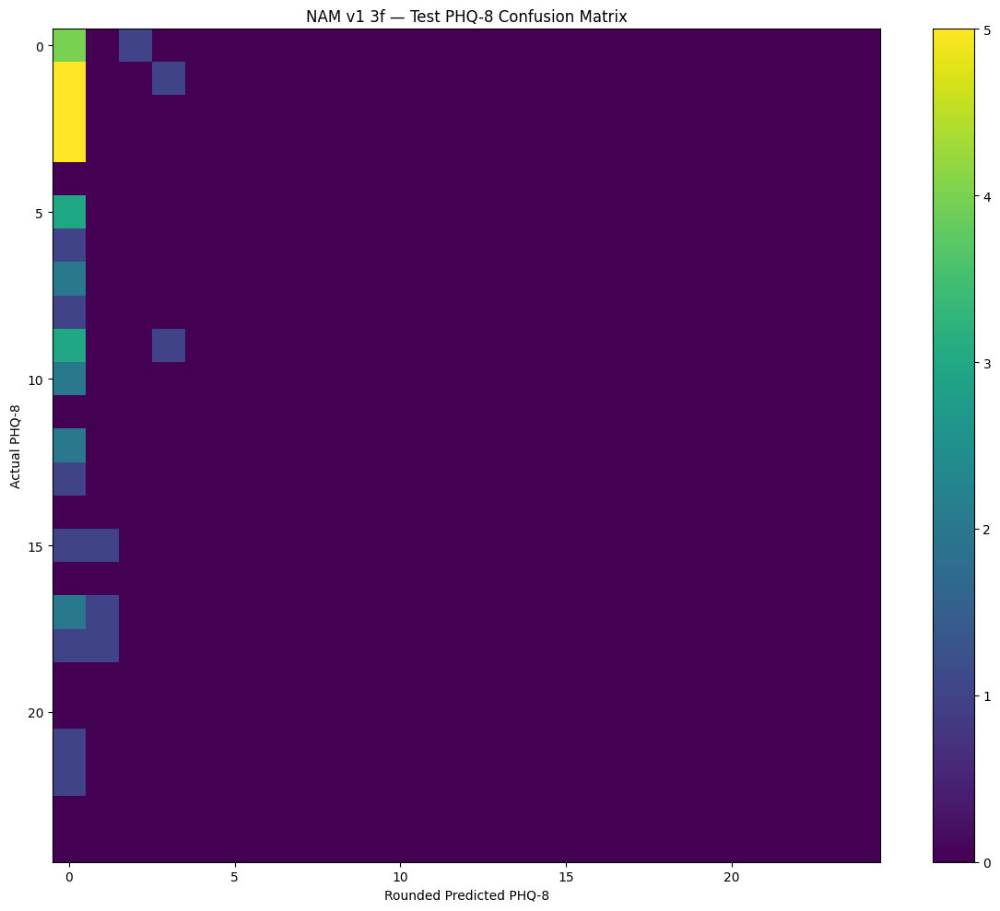

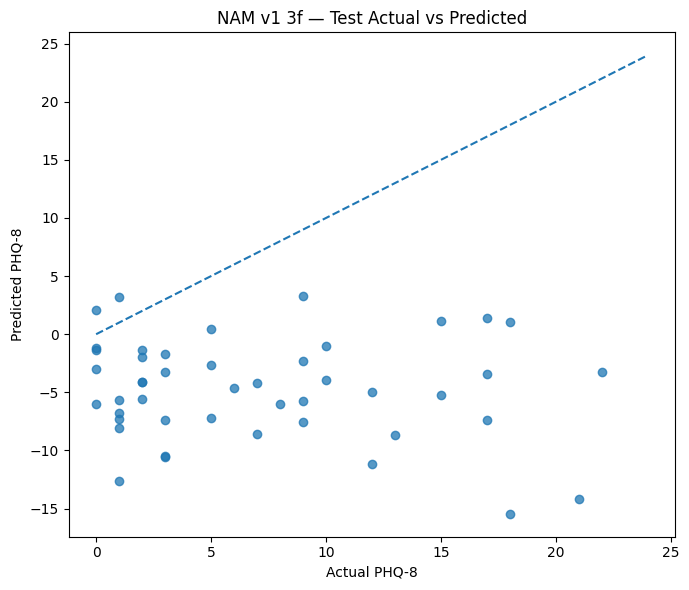


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
6,speech__std_f0_hertz,speech,1.427950,-0.064929,-1.641809
3,speech__pause_rate,speech,1.069910,0.057127,-1.579548
12,speech__spectral_slope,speech,1.011456,-0.303972,0.919103
14,speech__cepstral_peak_prominence_mean,speech,0.942622,0.190401,-0.941794
2,speech__phonation_ratio,speech,0.911402,0.142363,1.601302
22,speech__mean_b2_loc,speech,0.830501,0.074974,1.571992
17,speech__std_f1_loc,speech,0.735549,0.105347,-0.954674
15,speech__cepstral_peak_prominence_std,speech,0.733496,-0.213980,0.686622
1,speech__articulation_rate,speech,0.706637,-0.018511,1.251904
16,speech__mean_f1_loc,speech,0.699074,0.070694,-0.806296



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v1/NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


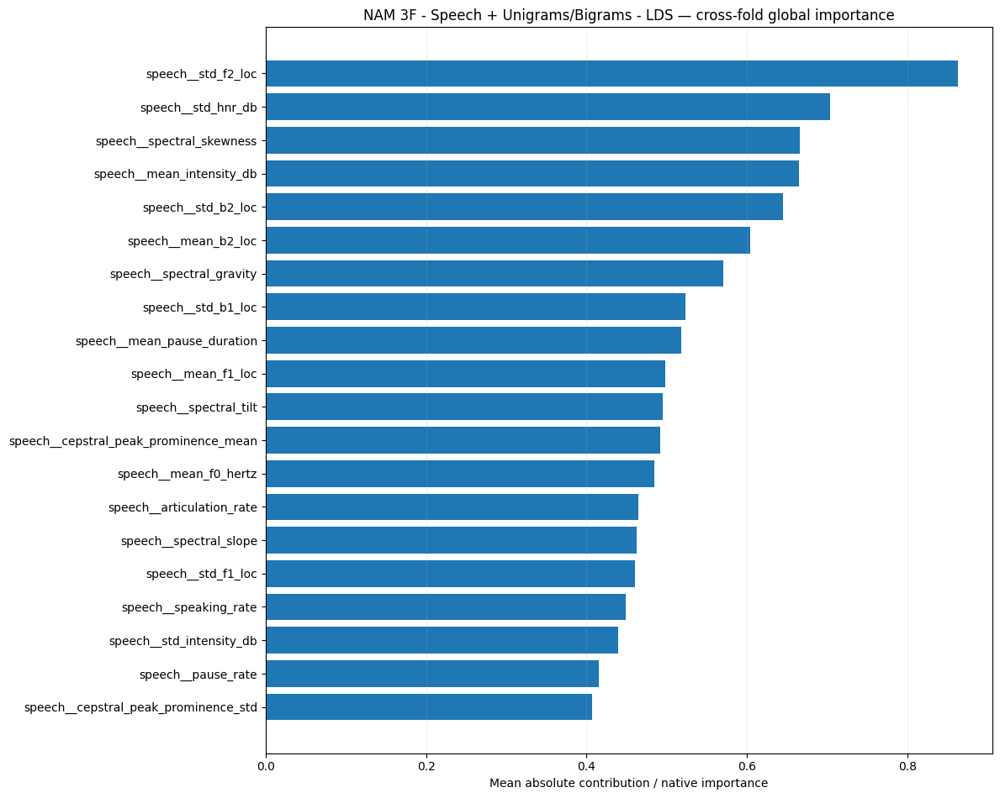

/tmp/ipykernel_4839/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_4839/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_4839/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_4839/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_4839/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_4839/1559648166.py:694: ConstantInputWarning: An input array is consta


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
59,text__my uh,2,0.971531,NaN,0.053952,0.161597,0.000000,0.052298
37,text__but uh,2,0.948243,NaN,0.180311,0.329384,0.000000,0.063961
35,text__at all,2,0.917742,NaN,0.042271,0.119755,0.000000,0.055431
58,text__mexico,3,0.886295,0.064291,0.098140,0.147659,0.000000,0.065659
33,text__annotation_laughter oh,5,0.849314,0.065887,0.034044,0.073956,0.000000,0.059628
70,text__situation i,3,0.835670,0.095677,0.166652,0.257161,0.000000,0.071998
89,text__you're welcome,2,0.787826,NaN,0.038326,0.063607,0.000000,0.046610
44,text__for me,2,0.758053,NaN,0.096799,0.148629,0.000000,0.052037
60,text__not easy,2,0.733978,NaN,0.086832,0.256094,0.000000,0.068840
28,text__a walk,2,0.625915,NaN,0.078711,0.271864,0.000000,0.069215


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v1__NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS.json


In [ ]:
# DNAMite-parity report for NAM_v1 Experiment 3f (corresponds to DNAMite 3f)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v1_3f_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3f",
    dnamite_experiment_id="3f",
    experiment_name='NAM 3F - Speech + Unigrams/Bigrams - LDS',
    task="regression",
    cv_results=experiment_3f_regression_cv,
    final_result=experiment_3f_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3f",
    )
] = NAM_v1_3f_report


In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 3f complete. "
    "Waiting for file writes..."
)

time.sleep(20)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 3f complete. Waiting for file writes...
Disconnecting runtime.


### Table

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


# ============================================================
# 1. NAM v1 results directory
# ============================================================

NAM_V1_RESULTS_DIR = Path(
    "/content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1"
)


# ============================================================
# 2. Experiment folders
# ============================================================

EXPERIMENT_FOLDERS = {
    "1A": "NAM_1A_-_Speech_Only_-_Baseline",
    "1B": "NAM_1B_-_Speech_Only_-_Feature_Selection",
    "1C": "NAM_1C_-_Speech_Only_-_Weighted_BCE",
    "2A": "NAM_2A_-_Speech_Unigrams_-_Baseline",
    "2B": "NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection",
    "2C": "NAM_2C_-_Speech_Unigrams_-_Weighted_BCE",
    "3A": "NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline",
    "3B": "NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Selection",
    "3C": "NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE",
}


# ============================================================
# 3. Metrics to report
# ============================================================

METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall_sensitivity",
    "specificity",
    "roc_auc",
    "pr_auc",
]


DISPLAY_NAMES = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "f1": "F1",
    "precision": "Precision",
    "recall_sensitivity": "Sensitivity",
    "specificity": "Specificity",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
}


# ============================================================
# 4. Helper: recursively find JSON result files
# ============================================================

def find_json_files(experiment_dir):

    return sorted(
        experiment_dir.rglob("*.json")
    )


# ============================================================
# 5. Helper: recursively search a JSON object for metrics
# ============================================================

def find_metric_dicts(obj):

    matches = []

    if isinstance(obj, dict):

        # Check whether this dictionary looks like a
        # fold-level metric dictionary.
        metric_count = sum(
            metric in obj
            for metric in METRICS
        )

        if metric_count >= 4:
            matches.append(obj)

        for value in obj.values():
            matches.extend(
                find_metric_dicts(value)
            )

    elif isinstance(obj, list):

        for value in obj:
            matches.extend(
                find_metric_dicts(value)
            )

    return matches


# ============================================================
# 6. Load fold-level metrics for one experiment
# ============================================================

def load_experiment_metrics(experiment_dir):

    json_files = find_json_files(
        experiment_dir
    )

    rows = []

    for json_path in json_files:

        try:
            with open(
                json_path,
                "r",
                encoding="utf-8",
            ) as f:
                data = json.load(f)

        except Exception:
            continue

        metric_dicts = find_metric_dicts(
            data
        )

        for metric_dict in metric_dicts:

            row = {}

            for metric in METRICS:

                value = metric_dict.get(
                    metric,
                    np.nan,
                )

                try:
                    value = float(value)
                except (TypeError, ValueError):
                    value = np.nan

                row[metric] = value

            if not all(
                np.isnan(value)
                for value in row.values()
            ):
                rows.append(row)

    if len(rows) == 0:
        raise ValueError(
            f"No fold-level metrics found in:\n"
            f"{experiment_dir}"
        )

    return pd.DataFrame(rows)


# ============================================================
# 7. Create mean ± SD table
# ============================================================

summary_rows = []

all_fold_results = {}


for experiment_name, folder_name in EXPERIMENT_FOLDERS.items():

    experiment_dir = (
        NAM_V1_RESULTS_DIR
        / folder_name
    )

    print(
        f"Reading {experiment_name}: "
        f"{experiment_dir}"
    )

    fold_df = load_experiment_metrics(
        experiment_dir
    )

    all_fold_results[
        experiment_name
    ] = fold_df

    print(
        f"  Found {len(fold_df)} "
        f"candidate metric rows"
    )

    summary_row = {
        "Experiment": experiment_name,
    }

    for metric in METRICS:

        values = (
            fold_df[metric]
            .dropna()
        )

        mean_value = values.mean()

        sd_value = values.std(
            ddof=1
        )

        summary_row[
            DISPLAY_NAMES[metric]
        ] = (
            f"{mean_value:.3f} "
            f"± {sd_value:.3f}"
        )

    summary_rows.append(
        summary_row
    )


nam_v1_classification_table = pd.DataFrame(
    summary_rows
)


# ============================================================
# 8. Display table
# ============================================================

display(
    nam_v1_classification_table
)

Reading 1A: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1/NAM_1A_-_Speech_Only_-_Baseline
  Found 5 candidate metric rows
Reading 1B: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1/NAM_1B_-_Speech_Only_-_Feature_Selection
  Found 5 candidate metric rows
Reading 1C: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1/NAM_1C_-_Speech_Only_-_Weighted_BCE
  Found 5 candidate metric rows
Reading 2A: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1/NAM_2A_-_Speech_Unigrams_-_Baseline
  Found 5 candidate metric rows
Reading 2B: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1/NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection
  Found 5 candidate metric rows
Reading 2C: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1/NAM_2C_-_Speech_Unigrams_-_Weighted_BCE
  Found 5 candidate metric rows
Reading 3A: /content/drive/MyDrive/Thesis/Model_Co

,Experiment,Accuracy,Balanced Accuracy,F1,Precision,Sensitivity,Specificity,ROC-AUC,PR-AUC
0,1A,0.474 ± 0.106,0.568 ± 0.073,0.465 ± 0.081,0.338 ± 0.040,0.800 ± 0.259,0.337 ± 0.228,0.551 ± 0.136,0.417 ± 0.089
1,1B,0.570 ± 0.113,0.564 ± 0.087,0.357 ± 0.223,0.307 ± 0.189,0.550 ± 0.447,0.579 ± 0.327,0.551 ± 0.098,0.379 ± 0.073
2,1C,0.407 ± 0.136,0.470 ± 0.097,0.348 ± 0.155,0.265 ± 0.097,0.625 ± 0.415,0.316 ± 0.331,0.485 ± 0.163,0.375 ± 0.122
3,2A,0.570 ± 0.100,0.507 ± 0.125,0.289 ± 0.202,0.279 ± 0.157,0.350 ± 0.335,0.663 ± 0.192,0.500 ± 0.126,0.379 ± 0.118
4,2B,0.489 ± 0.149,0.463 ± 0.113,0.312 ± 0.111,0.293 ± 0.141,0.400 ± 0.205,0.526 ± 0.241,0.450 ± 0.140,0.350 ± 0.100
5,2C,0.481 ± 0.157,0.480 ± 0.061,0.322 ± 0.103,0.315 ± 0.109,0.475 ± 0.298,0.484 ± 0.336,0.487 ± 0.115,0.329 ± 0.067
6,3A,0.526 ± 0.137,0.446 ± 0.092,0.205 ± 0.159,0.234 ± 0.195,0.250 ± 0.250,0.642 ± 0.259,0.374 ± 0.089,0.302 ± 0.072
7,3B,0.548 ± 0.066,0.549 ± 0.076,0.389 ± 0.150,0.322 ± 0.067,0.550 ± 0.301,0.547 ± 0.192,0.513 ± 0.105,0.358 ± 0.111
8,3C,0.504 ± 0.158,0.474 ± 0.059,0.211 ± 0.235,0.151 ± 0.154,0.400 ± 0.495,0.547 ± 0.425,0.398 ± 0.154,0.290 ± 0.064


# NAM v2

The following cells are the optimized NAM approach. NAM v2 keeps the same 18 experiment families as NAM v1 but uses the expanded/optimized parameter tuning strategy.


## NAM v2 source verification

Verified against the attached `9_NAM_Optimized_Updated.ipynb` source notebook. The complete NAM v2 experiment section (Experiments 1a–3f) is present in this master. The master adds only study-protocol instrumentation around the optimized implementation: shared outer-fold reuse, Google Drive artifact export, development/resource/energy tracking, fold-model and interpretability export, final-result/test-plot/feature-importance export, manifests, latency bundles, domain sanity checks, and paper-table aggregation.

The DNAMite↔NAM correspondence above is used for all NAM v2 parity reports and cross-model paper-table alignment.


In [ ]:
MODEL_FAMILY = 'NAM v2'
print('Running model family:', MODEL_FAMILY)

Running model family: NAM v2


In [ ]:
from pathlib import Path
import copy
import json
import math
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import tensorflow as tf

from scipy.ndimage import gaussian_filter1d
from scipy.stats import spearmanr

from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    ParameterGrid,
)
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

import os

#os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import gc
import tensorflow as tf

from scipy import sparse

In [ ]:
# print(f"Uninstalling TensorFlow {tf.__version__}")
# !pip uninstall tensorflow -y

In [ ]:
# print("Installing TensorFlow 1.15.0")
# !pip install tensorflow==1.15.0 --ignore-installed

In [ ]:
# import tensorflow as tf
# print("TensorFlow version after re-installation:", tf.__version__)

# # Restart the runtime to ensure the new TensorFlow version is loaded
# import os
# os.kill(os.getpid(), 9)

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

print(
    "GPU devices:",
    tf.config.list_physical_devices("GPU")
)

print(
    "All devices:",
    tf.config.list_physical_devices()
)

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
All devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Mon Sep 28 23:49:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   35C    P0             53W /  400W |       6MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("GPU devices:", tf.config.list_physical_devices("GPU"))

print(
    tf.sysconfig.get_build_info()
)

TensorFlow version: 2.20.0
Built with CUDA: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
OrderedDict({'cpu_compiler': 'clang 18', 'cuda_compute_capabilities': ['sm_60', 'sm_70', 'sm_80', 'sm_89', 'compute_90'], 'cuda_version': '12.5.1', 'cudnn_version': '9', 'is_cuda_build': True, 'is_rocm_build': False, 'is_tensorrt_build': False})


In [ ]:
import os

print(
    "CUDA_VISIBLE_DEVICES:",
    os.environ.get(
        "CUDA_VISIBLE_DEVICES"
    )
)

CUDA_VISIBLE_DEVICES: None


In [ ]:
import tensorflow as tf
import time

with tf.device("/GPU:0"):

    a = tf.random.normal(
        [5000, 5000]
    )

    b = tf.random.normal(
        [5000, 5000]
    )

    start = time.time()

    c = tf.matmul(
        a,
        b
    )

    # Force execution to finish
    _ = c.numpy()

elapsed = time.time() - start

print(
    "Device:",
    c.device
)

print(
    "Time:",
    elapsed,
)

Device: /job:localhost/replica:0/task:0/device:GPU:0
Time: 0.2127518653869629


In [ ]:
print(
    "GPU available:",
    len(
        tf.config.list_physical_devices("GPU")
    ) > 0
)

print(
    "TensorFlow version:",
    tf.__version__
)

GPU available: True
TensorFlow version: 2.20.0


In [ ]:
# from google.colab import drive

# drive.mount(
#     "/content/drive"
# )

In [ ]:
#!rm -rf /content/google-research

In [ ]:
!git clone https://github.com/google-research/google-research.git

# !wget -q \
#     https://github.com/google-research/google-research/archive/refs/heads/master.zip \
#     -O /content/google-research.zip

# !unzip -q \
#     /content/google-research.zip \
#     -d /content

# !mv \
#     /content/google-research-master \
#     /content/google-research

In [ ]:
!find /content \
    -maxdepth 3 \
    -type d \
    -name "neural_additive_models" \
    2>/dev/null

/content/google-research/neural_additive_models


In [ ]:
# ============================================================
# GOOGLE NAM REPOSITORY
# ============================================================

# GOOGLE_RESEARCH_ROOT = Path(
#     "/Users/sonalprasad/Documents/Thesis/google-research"
# )

GOOGLE_RESEARCH_ROOT = Path(
    "/content/google-research"
)

if str(GOOGLE_RESEARCH_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(GOOGLE_RESEARCH_ROOT),
    )

from neural_additive_models.models import NAM

In [ ]:
# ============================================================
# PATHS
# ============================================================

# THESIS_ROOT = Path(
#     "/Users/sonalprasad/Documents/Thesis"
# )

# NAM_RESULTS_ROOT = (
#     THESIS_ROOT
#     / "NAM_Results"
# )

# NAM_RESULTS_ROOT.mkdir(
#     parents=True,
#     exist_ok=True,
# )

THESIS_ROOT = Path(
    "/content/drive/MyDrive/Thesis"
)

THESIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

DATA_ROOT = (
    THESIS_ROOT
    / "Data"
)

TFIDF_ROOT = (
    THESIS_ROOT
    / "TFIDF"
)

NAM_RESULTS_ROOT = (
    THESIS_ROOT
    / "NAM_Results"
)

NAM_RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# TARGETS
# ============================================================

BINARY_TARGET = "PHQ8_Binary"
REGRESSION_TARGET = "PHQ8_Score"

PARTICIPANT_ID_COLUMN = "Participant_ID"
DATASET_COLUMN = "Dataset"


# ============================================================
# REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42

np.random.seed(
    RANDOM_STATE
)

tf.random.set_seed(
    RANDOM_STATE
)


# ============================================================
# NESTED CROSS-VALIDATION
# SAME AS DNAMITE
# ============================================================

OUTER_CV_FOLDS = 5
INNER_CV_FOLDS = 3


# ============================================================
# NAM TRAINING -- OPTIMIZED SEARCH
# ============================================================

# Increased from 200 so we can determine whether models were
# simply stopping because of the old epoch ceiling.
NAM_MAX_EPOCHS = 500
NAM_BATCH_SIZE = 32
NAM_EARLY_STOPPING_PATIENCE = 30
NAM_EARLY_STOPPING_MIN_DELTA = 1e-4
NAM_CLASSIFICATION_THRESHOLD = 0.50


# ============================================================
# REGRESSION CV
# ============================================================

# Regression targets remain continuous. These strata are used
# ONLY to distribute PHQ-8 severity more evenly across folds.
USE_STRATIFIED_REGRESSION_CV = True


# ============================================================
# NAM PARAMETER SEARCH
# ============================================================

# A deliberately moderate grid for the small DAIC-WOZ
# development set. The same grid is used for classification
# and regression for a fair model-capacity search.
NAM_PARAM_GRID = {
    "learning_rate": [
        1e-3,
        5e-4,
    ],
    "num_units": [
        8,
        16,
        32,
    ],
    "dropout": [
        0.1,
        0.25,
    ],
    "feature_dropout": [
        0.0,
    ],
    "shallow": [
        True,
    ],
    "activation": [
        "exu",
    ],
}

NAM_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        NAM_PARAM_GRID
    )
)

print(
    "NAM parameter configurations:",
    len(NAM_PARAMETER_CANDIDATES)
)


# ============================================================
# STAGED HYPERPARAMETER TUNING
# ============================================================

# To avoid an enormous Cartesian product, feature-selection
# strength and imbalance strength are tuned first using the
# SAME inner-CV folds and this fixed, modest NAM configuration.
# The full NAM architecture grid is then tuned using the chosen
# preprocessing/weighting setting. Everything remains inside
# the outer-training partition.
STAGE_TUNING_NAM_PARAMETERS = {
    "learning_rate": 5e-4,
    "num_units": 16,
    "dropout": 0.1,
    "feature_dropout": 0.0,
    "shallow": True,
    "activation": "exu",
}

# Weighted BCE: multiplier is applied to the automatically
# balanced positive-class weight. 1.0 reproduces the previous
# automatic class weighting.
WEIGHTED_BCE_POSITIVE_MULTIPLIERS = [
    1.0,
    #1.25,
    1.5,
    2.0,
]


NAM parameter configurations: 12


In [ ]:
# ============================================================
# TF-IDF REPRESENTATIONS
# ============================================================

UNIGRAM_REPRESENTATION = "unigram"

UNIGRAM_BIGRAM_REPRESENTATION = (
    "unigram_bigram"
)


# ============================================================
# INITIAL TEXT-ONLY FEATURE SELECTION
#
# This is performed even for the multimodal BASELINE.
# ============================================================

TEXT_SELECTION_CONFIG = {
    "unigram": {
        "classification": {
            "C": 2.5,
        },

        "regression": {
            "alpha": 0.0025,
        },
    },

    "unigram_bigram": {
        "classification": {
            "C": 5.0,
        },

        "regression": {
            "alpha": 0.01,
        },
    },
}

TEXT_LASSO_TOLERANCE = 1e-4

TEXT_LASSO_MAX_ITER = 20_000

TEXT_LOGISTIC_MAX_ITER = 10_000

TEXT_LOGISTIC_CLASS_WEIGHT = (
    "balanced"
)

In [ ]:
# ============================================================
# JOINT SPEECH + TEXT FEATURE SELECTION -- TUNED
# ============================================================

# These are tuned by inner CV using downstream NAM performance,
# rather than accepting the first value that yields >0 features.
JOINT_CLASSIFICATION_C_CANDIDATES = [
    0.05,
    0.25,
    1.0,
    5.0,
]
# JOINT_CLASSIFICATION_C_CANDIDATES = [
#     0.01,
#     0.025,
#     0.05,
#     0.1,
#     0.25,
#     0.5,
#     1.0,
#     2.5,
#     5.0,
# ]

# JOINT_REGRESSION_ALPHA_CANDIDATES = [
#     0.001,
#     0.0025,
#     0.005,
#     0.01,
#     0.025,
#     0.05,
#     0.1,
#     0.25,
#     0.5,
#     1.0,
# ]

JOINT_REGRESSION_ALPHA_CANDIDATES = [
    0.0025,
    0.01,
    0.05,
    0.25,
]

JOINT_LOGISTIC_MAX_ITER = 20_000
JOINT_LASSO_MAX_ITER = 20_000
JOINT_LASSO_TOLERANCE = 1e-4


In [ ]:
# ============================================================
# LABEL DISTRIBUTION SMOOTHING -- TUNED
# ============================================================

PHQ8_MIN = 0
PHQ8_MAX = 24

LDS_EPSILON = 1e-6

# sigma=2 / sqrt_inverse is still included, but it is no longer
# assumed to be optimal. Inner CV chooses among these settings.
LDS_SIGMA_CANDIDATES = [
    1.0,
    2.0,
]

LDS_REWEIGHT_METHOD_CANDIDATES = [
    "sqrt_inverse",
]

# LDS_SIGMA_CANDIDATES = [
#     0.5,
#     1.0,
#     2.0,
#     3.0,
#     4.0,
# ]

# LDS_REWEIGHT_METHOD_CANDIDATES = [
#     "sqrt_inverse",
#     "inverse",
# ]

# Backward-compatible defaults for direct diagnostic calls.
LDS_SIGMA = 2.0
LDS_REWEIGHT_METHOD = "sqrt_inverse"


In [ ]:
def select_joint_features(
    X_train,
    y_train,
    task,
    selection_value=None,
):
    """
    Perform SECOND-STAGE feature selection across the entire
    baseline feature space.

    The regularization strength is supplied by inner-CV tuning.
    No "first non-zero subset wins" shortcut is used anymore.
    """

    if task == "classification":
        C = (
            1.0
            if selection_value is None
            else float(selection_value)
        )

        selector = LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=C,
            class_weight="balanced",
            max_iter=JOINT_LOGISTIC_MAX_ITER,
            random_state=RANDOM_STATE,
        )
        selector.fit(X_train, y_train)
        selected_indices = np.flatnonzero(
            selector.coef_[0] != 0
        )

        if len(selected_indices) == 0:
            raise RuntimeError(
                f"Joint classification selection returned zero features for C={C}."
            )

        print(
            "Joint selection:",
            len(selected_indices),
            "features,",
            f"C={C}",
        )
        return np.asarray(selected_indices, dtype=int)

    elif task == "regression":
        alpha = (
            0.01
            if selection_value is None
            else float(selection_value)
        )

        selector = Lasso(
            alpha=alpha,
            max_iter=JOINT_LASSO_MAX_ITER,
            tol=JOINT_LASSO_TOLERANCE,
            random_state=RANDOM_STATE,
        )
        selector.fit(X_train, y_train)
        selected_indices = np.flatnonzero(
            selector.coef_ != 0
        )

        if len(selected_indices) == 0:
            raise RuntimeError(
                f"Joint regression selection returned zero features for alpha={alpha}."
            )

        print(
            "Joint selection:",
            len(selected_indices),
            "features,",
            f"alpha={alpha}",
        )
        return np.asarray(selected_indices, dtype=int)

    else:
        raise ValueError(f"Unknown task: {task}")


In [ ]:
def calculate_classification_weights(
    y_train,
    positive_class_multiplier=1.0,
):
    """
    Return a sample weight for every training sample.

    First compute sklearn's balanced class weights. Then multiply
    the positive-class weight by a tunable strength multiplier.
    A multiplier of 1.0 reproduces the previous behavior.
    """
    y_train = np.asarray(y_train).astype(int)
    classes = np.unique(y_train)

    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train,
    )

    class_weight_lookup = {
        int(label): float(weight)
        for label, weight in zip(classes, class_weights)
    }

    if 1 in class_weight_lookup:
        class_weight_lookup[1] *= float(
            positive_class_multiplier
        )

    sample_weights = np.asarray(
        [
            class_weight_lookup[int(label)]
            for label in y_train
        ],
        dtype=np.float32,
    )

    # Keep the average gradient scale roughly comparable across
    # candidate multipliers.
    sample_weights = sample_weights / np.mean(sample_weights)

    return sample_weights, class_weight_lookup


In [ ]:
def train_nam(
    X_train,
    y_train,
    X_val,
    y_val,
    task,
    parameters,
    imbalance_strategy="none",
):
    """
    Train one NAM model and retain epoch diagnostics.

    Tuned imbalance parameters, when present, are read from the
    parameter dictionary:
        positive_class_multiplier
        lds_sigma
        lds_reweight_method
    """
    X_train = np.asarray(X_train, dtype=np.float32)
    X_val = np.asarray(X_val, dtype=np.float32)
    y_train = np.asarray(y_train, dtype=np.float32)
    y_val = np.asarray(y_val, dtype=np.float32)

    sample_weight = None

    if imbalance_strategy == "weighted_bce":
        if task != "classification":
            raise ValueError(
                "Weighted BCE may only be used for classification."
            )

        positive_multiplier = float(
            parameters.get(
                "positive_class_multiplier",
                1.0,
            )
        )

        sample_weight, class_weight_lookup = (
            calculate_classification_weights(
                y_train,
                positive_class_multiplier=positive_multiplier,
            )
        )

        print(
            "Weighted BCE:",
            f"positive multiplier={positive_multiplier}",
            "class weights=",
            class_weight_lookup,
        )

    elif imbalance_strategy == "lds":
        if task != "regression":
            raise ValueError(
                "LDS may only be used for regression."
            )

        lds_sigma = float(
            parameters.get("lds_sigma", LDS_SIGMA)
        )
        lds_method = parameters.get(
            "lds_reweight_method",
            LDS_REWEIGHT_METHOD,
        )

        sample_weight = calculate_lds_weights(
            y_train,
            sigma=lds_sigma,
            reweight_method=lds_method,
        )

        print(
            "LDS:",
            f"sigma={lds_sigma},",
            f"method={lds_method},",
            f"weight range=({sample_weight.min():.3f}, {sample_weight.max():.3f})",
        )

    elif imbalance_strategy != "none":
        raise ValueError(
            f"Unknown imbalance strategy: {imbalance_strategy}"
        )

    model = create_nam_model(
        num_features=X_train.shape[1],
        parameters=parameters,
    )
    model = compile_nam_model(
        model=model,
        task=task,
        parameters=parameters,
    )

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=NAM_EARLY_STOPPING_PATIENCE,
        min_delta=NAM_EARLY_STOPPING_MIN_DELTA,
        restore_best_weights=True,
        verbose=0,
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        sample_weight=sample_weight,
        epochs=NAM_MAX_EPOCHS,
        batch_size=NAM_BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=0,
        shuffle=True,
    )

    history_dict = history.history
    epochs_ran = len(history_dict["loss"])

    if "val_loss" in history_dict and len(history_dict["val_loss"]) > 0:
        best_epoch = int(
            np.argmin(history_dict["val_loss"]) + 1
        )
        best_val_loss = float(
            np.min(history_dict["val_loss"])
        )
    else:
        best_epoch = epochs_ran
        best_val_loss = np.nan

    hit_epoch_ceiling = (
        epochs_ran >= NAM_MAX_EPOCHS
    )

    print(
        f"Epochs ran={epochs_ran}; "
        f"best epoch={best_epoch}; "
        f"best val_loss={best_val_loss:.6f}; "
        f"hit ceiling={hit_epoch_ceiling}"
    )

    del history
    del early_stopping

    return {
        "model": model,
        "history": history_dict,
        "sample_weight": sample_weight,
        "epochs_ran": epochs_ran,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "hit_epoch_ceiling": hit_epoch_ceiling,
    }


In [ ]:
def evaluate_classification(
    y_true,
    probabilities,
    predictions,
):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = np.asarray(predictions).astype(int)

    specificity = recall_score(
        y_true,
        predictions,
        pos_label=0,
        zero_division=0,
    )

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions,
        ),
        "f1": f1_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "recall_sensitivity": recall_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "specificity": specificity,
        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
        ),
        "pr_auc": average_precision_score(
            y_true,
            probabilities,
        ),
    }


In [ ]:
def calculate_regression_metrics(
    y_true,
    y_pred,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "mae": mean_absolute_error(
            y_true,
            y_pred,
        ),

        "rmse": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred,
            )
        ),

        "r2": r2_score(
            y_true,
            y_pred,
        ),

        "spearman_rho": spearmanr(
            y_true,
            y_pred,
        ).statistic,

        "exact_accuracy": np.mean(
            np.rint(y_pred)
            == y_true
        ),

        "within_1": np.mean(
            np.abs(
                y_true - y_pred
            ) <= 1
        ),

        "within_2": np.mean(
            np.abs(
                y_true - y_pred
            ) <= 2
        ),

        "within_3": np.mean(
            np.abs(
                y_true - y_pred
            ) <= 3
        ),
    }

In [ ]:
def evaluate_regression(
    y_true,
    predictions,
):
    y_true = np.asarray(y_true, dtype=float)
    predictions = np.asarray(predictions, dtype=float)

    spearman_result = spearmanr(
        y_true,
        predictions,
    )

    rounded_predictions = np.clip(
        np.rint(predictions),
        PHQ8_MIN,
        PHQ8_MAX,
    )

    errors = np.abs(y_true - predictions)

    return {
        "mae": mean_absolute_error(
            y_true,
            predictions,
        ),
        "rmse": np.sqrt(
            mean_squared_error(
                y_true,
                predictions,
            )
        ),
        "r2": r2_score(
            y_true,
            predictions,
        ),
        "spearman_rho": spearman_result.statistic,
        "spearman_p": spearman_result.pvalue,
        "exact_accuracy": np.mean(
            rounded_predictions == y_true
        ),
        "within_1": np.mean(errors <= 1),
        "within_2": np.mean(errors <= 2),
        "within_3": np.mean(errors <= 3),
    }


In [ ]:
def prepare_nam_fold(
    task,
    speech_features,
    train_indices,
    val_indices,
    y,
    experiment_variant,
    text_matrix=None,
    text_representation=None,
    selection_value=None,
):
    """
    experiment_variant:

        "baseline"
        "feature_selection"
        "imbalance"

    IMPORTANT:

    baseline:
        baseline features only

    feature_selection:
        baseline
        +
        joint feature selection

    imbalance:
        baseline features
        +
        imbalance strategy

    Imbalance DOES NOT inherit joint selection.
    """

    y = np.asarray(y)


    X_train_speech = (
        speech_features.iloc[
            train_indices
        ]
    )

    X_val_speech = (
        speech_features.iloc[
            val_indices
        ]
    )


    y_train = y[
        train_indices
    ]

    y_val = y[
        val_indices
    ]


    # ========================================================
    # OPTIONAL TEXT
    # ========================================================

    if text_matrix is not None:

        text_train = (
            text_matrix[
                train_indices
            ]
        )

        text_val = (
            text_matrix[
                val_indices
            ]
        )

    else:

        text_train = None
        text_val = None


    # ========================================================
    # BASELINE FEATURE SPACE
    # ========================================================

    prepared = build_baseline_features(
        task=task,

        X_train_speech=(
            X_train_speech
        ),

        X_other_speech=(
            X_val_speech
        ),

        y_train=y_train,

        text_train=(
            text_train
        ),

        text_other=(
            text_val
        ),

        text_representation=(
            text_representation
        ),
    )


    X_train = prepared[
        "X_train"
    ]

    X_val = prepared[
        "X_other"
    ]


    joint_selected_indices = None


    # ========================================================
    # MODEL 2: JOINT FEATURE SELECTION
    # ========================================================

    if (
        experiment_variant
        == "feature_selection"
    ):

        joint_selected_indices = (
            select_joint_features(
                X_train=X_train,
                y_train=y_train,
                task=task,
                selection_value=selection_value,
            )
        )


        X_train = (
            X_train[
                :,
                joint_selected_indices
            ]
        )

        X_val = (
            X_val[
                :,
                joint_selected_indices
            ]
        )


    elif experiment_variant not in [
        "baseline",
        "imbalance",
    ]:

        raise ValueError(
            "Unknown experiment variant: "
            f"{experiment_variant}"
        )


    return {
        "X_train": X_train,

        "X_val": X_val,

        "y_train": y_train,

        "y_val": y_val,

        "selected_text_indices": (
            prepared[
                "selected_text_indices"
            ]
        ),

        "joint_selected_indices": (
            joint_selected_indices
        ),

        # Retain fitted preprocessing objects so the exact
        # held-out pipeline can be saved and benchmarked later.
        "speech_imputer": (
            prepared["speech_imputer"]
        ),

        "speech_scaler": (
            prepared["speech_scaler"]
        ),
    }

In [ ]:
def make_regression_strata(
    y,
    n_splits,
):
    """
    Create strata ONLY for fold assignment; y itself stays continuous.

    First try clinically interpretable 5-point PHQ-8 bands:
        0-4, 5-9, 10-14, 15-19, 20-24.
    If any band is too small for the requested number of folds,
    fall back to quantile strata. If stratification is impossible,
    return None so the caller can fall back to KFold.
    """
    y = np.asarray(y, dtype=float)

    fixed = pd.cut(
        y,
        bins=[-np.inf, 5, 10, 15, 20, np.inf],
        labels=False,
        right=False,
    ).astype(int)

    fixed_counts = pd.Series(fixed).value_counts()
    if len(fixed_counts) >= 2 and fixed_counts.min() >= n_splits:
        return fixed

    max_q = min(
        5,
        max(2, len(y) // n_splits),
    )

    for q in range(max_q, 1, -1):
        try:
            quantile_strata = pd.qcut(
                y,
                q=q,
                labels=False,
                duplicates="drop",
            )
            quantile_strata = np.asarray(
                quantile_strata,
                dtype=int,
            )
            counts = pd.Series(
                quantile_strata
            ).value_counts()
            if len(counts) >= 2 and counts.min() >= n_splits:
                return quantile_strata
        except (ValueError, TypeError):
            pass

    return None


def make_cv_folds(
    task,
    y_subset,
    n_splits,
):
    """Return relative train/validation indices for one CV level."""
    y_subset = np.asarray(y_subset)

    if task == "classification":
        splitter = StratifiedKFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=RANDOM_STATE,
        )
        return list(
            splitter.split(
                np.zeros(len(y_subset)),
                y_subset,
            )
        )

    if task == "regression" and USE_STRATIFIED_REGRESSION_CV:
        strata = make_regression_strata(
            y_subset,
            n_splits=n_splits,
        )
        if strata is not None:
            print(
                "Regression fold strata counts:",
                pd.Series(strata).value_counts().sort_index().to_dict(),
            )
            splitter = StratifiedKFold(
                n_splits=n_splits,
                shuffle=True,
                random_state=RANDOM_STATE,
            )
            return list(
                splitter.split(
                    np.zeros(len(y_subset)),
                    strata,
                )
            )

        warnings.warn(
            "Could not form valid regression strata; falling back to KFold."
        )

    splitter = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    return list(
        splitter.split(
            np.arange(len(y_subset))
        )
    )


def _score_inner_model(
    task,
    trained,
    prepared,
):
    pred = predict_nam(
        trained["model"],
        prepared["X_val"],
        task=task,
    )

    if task == "classification":
        metrics = evaluate_classification(
            prepared["y_val"],
            pred["probabilities"],
            pred["predictions"],
        )
        score = metrics["balanced_accuracy"]
    else:
        metrics = evaluate_regression(
            prepared["y_val"],
            pred["predictions"],
        )
        score = metrics["mae"]

    return float(score), pred


def tune_joint_selection_strength(
    task,
    speech_features,
    y,
    outer_train_indices,
    inner_folds,
    text_matrix=None,
    text_representation=None,
):
    """
    Tune L1/LASSO selection strength using inner-CV NAM performance.
    This fixes the previous first-nonzero-subset behavior.
    """
    candidates = (
        JOINT_CLASSIFICATION_C_CANDIDATES
        if task == "classification"
        else JOINT_REGRESSION_ALPHA_CANDIDATES
    )

    rows = []

    for selection_value in candidates:
        fold_scores = []
        valid = True

        for inner_train_relative, inner_val_relative in inner_folds:
            inner_train_indices = outer_train_indices[inner_train_relative]
            inner_val_indices = outer_train_indices[inner_val_relative]

            try:
                prepared = prepare_nam_fold(
                    task=task,
                    speech_features=speech_features,
                    train_indices=inner_train_indices,
                    val_indices=inner_val_indices,
                    y=y,
                    experiment_variant="feature_selection",
                    text_matrix=text_matrix,
                    text_representation=text_representation,
                    selection_value=selection_value,
                )
            except RuntimeError:
                valid = False
                break

            trained = train_nam(
                X_train=prepared["X_train"],
                y_train=prepared["y_train"],
                X_val=prepared["X_val"],
                y_val=prepared["y_val"],
                task=task,
                parameters=STAGE_TUNING_NAM_PARAMETERS,
                imbalance_strategy="none",
            )

            score, pred = _score_inner_model(
                task,
                trained,
                prepared,
            )
            fold_scores.append(score)

            del trained, pred
            del prepared
            tf.keras.backend.clear_session()
            gc.collect()

        if valid and fold_scores:
            rows.append({
                "selection_value": float(selection_value),
                "mean_score": float(np.mean(fold_scores)),
                "fold_scores": fold_scores,
            })

    if not rows:
        raise RuntimeError(
            "No valid joint feature-selection setting was found."
        )

    if task == "classification":
        best = max(rows, key=lambda x: x["mean_score"])
        name = "C"
    else:
        best = min(rows, key=lambda x: x["mean_score"])
        name = "alpha"

    print(
        f"Best joint-selection {name}:",
        best["selection_value"],
        "inner score:",
        best["mean_score"],
    )
    return best


def tune_imbalance_strength(
    task,
    speech_features,
    y,
    outer_train_indices,
    inner_folds,
    text_matrix=None,
    text_representation=None,
):
    """
    Tune Weighted-BCE strength or LDS settings inside inner CV.
    """
    if task == "classification":
        candidates = [
            {"positive_class_multiplier": float(v)}
            for v in WEIGHTED_BCE_POSITIVE_MULTIPLIERS
        ]
        strategy = "weighted_bce"
    else:
        candidates = [
            {
                "lds_sigma": float(sigma),
                "lds_reweight_method": method,
            }
            for sigma in LDS_SIGMA_CANDIDATES
            for method in LDS_REWEIGHT_METHOD_CANDIDATES
        ]
        strategy = "lds"

    rows = []

    for extra in candidates:
        fold_scores = []
        stage_parameters = copy.deepcopy(
            STAGE_TUNING_NAM_PARAMETERS
        )
        stage_parameters.update(extra)

        for inner_train_relative, inner_val_relative in inner_folds:
            inner_train_indices = outer_train_indices[inner_train_relative]
            inner_val_indices = outer_train_indices[inner_val_relative]

            prepared = prepare_nam_fold(
                task=task,
                speech_features=speech_features,
                train_indices=inner_train_indices,
                val_indices=inner_val_indices,
                y=y,
                experiment_variant="imbalance",
                text_matrix=text_matrix,
                text_representation=text_representation,
            )

            trained = train_nam(
                X_train=prepared["X_train"],
                y_train=prepared["y_train"],
                X_val=prepared["X_val"],
                y_val=prepared["y_val"],
                task=task,
                parameters=stage_parameters,
                imbalance_strategy=strategy,
            )

            score, pred = _score_inner_model(
                task,
                trained,
                prepared,
            )
            fold_scores.append(score)

            del trained, pred
            tf.keras.backend.clear_session()
            gc.collect()

        rows.append({
            "extra_parameters": copy.deepcopy(extra),
            "mean_score": float(np.mean(fold_scores)),
            "fold_scores": fold_scores,
        })

    if task == "classification":
        best = max(rows, key=lambda x: x["mean_score"])
    else:
        best = min(rows, key=lambda x: x["mean_score"])

    print(
        "Best imbalance parameters:",
        best["extra_parameters"],
        "inner score:",
        best["mean_score"],
    )
    return best


def tune_nam_parameters(
    task,
    speech_features,
    y,
    outer_train_indices,
    experiment_variant,
    text_matrix=None,
    text_representation=None,
):
    """
    INNER CROSS-VALIDATION.

    Classification: maximize balanced accuracy.
    Regression: minimize MAE.

    Feature-selection strength and imbalance strength are tuned
    first on the same inner folds, then the NAM architecture grid
    is searched using the selected setting. This staged approach
    controls compute while keeping all choices inside outer train.
    """
    y = np.asarray(y)
    y_outer_train = y[outer_train_indices]

    inner_folds = make_cv_folds(
        task=task,
        y_subset=y_outer_train,
        n_splits=INNER_CV_FOLDS,
    )

    extra_parameters = {}

    if experiment_variant == "feature_selection":
        selection_result = tune_joint_selection_strength(
            task=task,
            speech_features=speech_features,
            y=y,
            outer_train_indices=outer_train_indices,
            inner_folds=inner_folds,
            text_matrix=text_matrix,
            text_representation=text_representation,
        )
        extra_parameters["joint_selection_value"] = (
            selection_result["selection_value"]
        )

    elif experiment_variant == "imbalance":
        imbalance_result = tune_imbalance_strength(
            task=task,
            speech_features=speech_features,
            y=y,
            outer_train_indices=outer_train_indices,
            inner_folds=inner_folds,
            text_matrix=text_matrix,
            text_representation=text_representation,
        )
        extra_parameters.update(
            imbalance_result["extra_parameters"]
        )

    candidate_results = []

    for base_parameters in NAM_PARAMETER_CANDIDATES:
        parameters = copy.deepcopy(base_parameters)
        parameters.update(extra_parameters)
        fold_scores = []

        for inner_train_relative, inner_val_relative in inner_folds:
            inner_train_indices = outer_train_indices[inner_train_relative]
            inner_val_indices = outer_train_indices[inner_val_relative]

            prepared = prepare_nam_fold(
                task=task,
                speech_features=speech_features,
                train_indices=inner_train_indices,
                val_indices=inner_val_indices,
                y=y,
                experiment_variant=experiment_variant,
                text_matrix=text_matrix,
                text_representation=text_representation,
                selection_value=parameters.get(
                    "joint_selection_value"
                ),
            )

            imbalance_strategy = get_imbalance_strategy(
                task,
                experiment_variant,
            )

            trained = train_nam(
                X_train=prepared["X_train"],
                y_train=prepared["y_train"],
                X_val=prepared["X_val"],
                y_val=prepared["y_val"],
                task=task,
                parameters=parameters,
                imbalance_strategy=imbalance_strategy,
            )

            score, pred = _score_inner_model(
                task,
                trained,
                prepared,
            )
            fold_scores.append(score)

            del trained, pred
            tf.keras.backend.clear_session()
            gc.collect()

        candidate_results.append({
            "parameters": copy.deepcopy(parameters),
            "mean_score": float(np.mean(fold_scores)),
            "fold_scores": fold_scores,
        })

    if task == "classification":
        best_result = max(
            candidate_results,
            key=lambda x: x["mean_score"],
        )
    else:
        best_result = min(
            candidate_results,
            key=lambda x: x["mean_score"],
        )

    print("\nBest parameters:", best_result["parameters"])
    print("Inner CV score:", best_result["mean_score"])
    return best_result


In [ ]:
def summarize_nested_cv(
    fold_results,
):
    rows = []

    for result in fold_results:
        row = {
            "outer_fold": result["outer_fold"],
        }
        row.update(result["metrics"])

        baseline = result.get(
            "trivial_baseline_metrics"
        )
        if baseline is not None:
            for key, value in baseline.items():
                row[f"baseline_{key}"] = value

        row["selected_text_count"] = result.get(
            "selected_text_count"
        )
        row["joint_selected_count"] = result.get(
            "joint_selected_count"
        )
        row["best_epoch"] = result.get(
            "best_epoch"
        )
        row["epochs_ran"] = result.get(
            "epochs_ran"
        )
        row["hit_epoch_ceiling"] = result.get(
            "hit_epoch_ceiling"
        )
        rows.append(row)

    results_df = pd.DataFrame(rows)

    print(results_df)
    print("\nMean:")
    print(
        results_df
        .select_dtypes(include=np.number)
        .mean()
    )
    print("\nStd:")
    print(
        results_df
        .select_dtypes(include=np.number)
        .std()
    )

    if "hit_epoch_ceiling" in results_df.columns:
        ceiling_count = int(
            results_df["hit_epoch_ceiling"]
            .fillna(False)
            .astype(bool)
            .sum()
        )
        print(
            f"\nEpoch ceiling reached in {ceiling_count}/"
            f"{len(results_df)} outer folds."
        )

    return results_df


In [ ]:
def train_final_nam_model(
    task,
    speech_development,
    y_development,
    speech_test,
    y_test,
    parameters,
    experiment_variant,
    text_development=None,
    text_test=None,
    text_representation=None,
):
    y_development = np.asarray(y_development)
    y_test = np.asarray(y_test)

    # ========================================================
    # INTERNAL VALIDATION SPLIT FOR EARLY STOPPING
    # ========================================================
    internal_folds = make_cv_folds(
        task=task,
        y_subset=y_development,
        n_splits=5,
    )
    train_indices, val_indices = internal_folds[0]

    prepared = prepare_nam_fold(
        task=task,
        speech_features=speech_development,
        train_indices=train_indices,
        val_indices=val_indices,
        y=y_development,
        experiment_variant=experiment_variant,
        text_matrix=text_development,
        text_representation=text_representation,
        selection_value=parameters.get(
            "joint_selection_value"
        ),
    )

    imbalance_strategy = get_imbalance_strategy(
        task,
        experiment_variant,
    )

    trained = train_nam(
        X_train=prepared["X_train"],
        y_train=prepared["y_train"],
        X_val=prepared["X_val"],
        y_val=prepared["y_val"],
        task=task,
        parameters=parameters,
        imbalance_strategy=imbalance_strategy,
    )

    # Use the actual minimum-validation-loss epoch, rather than
    # the total number of epochs that happened to run.
    best_epoch = int(trained["best_epoch"])

    print(
        "Best training epoch from internal validation:",
        best_epoch,
    )
    print(
        "Internal run epochs:",
        trained["epochs_ran"],
        "hit ceiling:",
        trained["hit_epoch_ceiling"],
    )

    # ========================================================
    # FIT PREPROCESSING ON ALL DEVELOPMENT DATA
    # ========================================================
    X_dev_speech, speech_imputer, speech_scaler = (
        fit_speech_preprocessor(
            speech_development
        )
    )

    X_test_speech = transform_speech(
        speech_test,
        speech_imputer,
        speech_scaler,
    )

    selected_text_indices = None

    if text_development is not None:
        selected_text_indices = select_text_features(
            X_train_text=text_development,
            y_train=y_development,
            task=task,
            text_representation=text_representation,
        )

        X_dev_text = ensure_dense(
            text_development[:, selected_text_indices]
        )
        X_test_text_selected = ensure_dense(
            text_test[:, selected_text_indices]
        )

        X_dev = np.hstack([
            X_dev_speech,
            X_dev_text,
        ])
        X_test_final = np.hstack([
            X_test_speech,
            X_test_text_selected,
        ])
    else:
        X_dev = X_dev_speech
        X_test_final = X_test_speech

    # ========================================================
    # TUNED JOINT FEATURE SELECTION
    # ========================================================
    joint_selected_indices = None

    if experiment_variant == "feature_selection":
        joint_selected_indices = select_joint_features(
            X_train=X_dev,
            y_train=y_development,
            task=task,
            selection_value=parameters.get(
                "joint_selection_value"
            ),
        )

        X_dev = X_dev[:, joint_selected_indices]
        X_test_final = X_test_final[:, joint_selected_indices]

    X_dev = X_dev.astype(np.float32)
    X_test_final = X_test_final.astype(np.float32)

    # ========================================================
    # TUNED SAMPLE WEIGHTS ON ALL DEVELOPMENT DATA
    # ========================================================
    sample_weight = None

    if imbalance_strategy == "weighted_bce":
        sample_weight, class_weights = (
            calculate_classification_weights(
                y_development,
                positive_class_multiplier=float(
                    parameters.get(
                        "positive_class_multiplier",
                        1.0,
                    )
                ),
            )
        )
        print(
            "Final Weighted-BCE class weights:",
            class_weights,
        )

    elif imbalance_strategy == "lds":
        sample_weight = calculate_lds_weights(
            y_development,
            sigma=float(
                parameters.get(
                    "lds_sigma",
                    LDS_SIGMA,
                )
            ),
            reweight_method=parameters.get(
                "lds_reweight_method",
                LDS_REWEIGHT_METHOD,
            ),
        )

    # ========================================================
    # FINAL NAM
    # ========================================================
    final_model = create_nam_model(
        num_features=X_dev.shape[1],
        parameters=parameters,
    )
    final_model = compile_nam_model(
        final_model,
        task,
        parameters,
    )

    # Measure only the final selected-model fit, matching the DNAMite protocol.
    final_resource_monitor = TrainingResourceMonitor()
    final_energy_monitor = TrainingEnergyMonitor()
    final_resource_monitor.start()
    final_energy_monitor.start()
    try:
        final_model.fit(
            X_dev,
            y_development,
            sample_weight=sample_weight,
            epochs=max(1, best_epoch),
            batch_size=NAM_BATCH_SIZE,
            shuffle=True,
            verbose=0,
        )
    finally:
        final_energy_metrics = final_energy_monitor.stop()
        final_resource_metrics = final_resource_monitor.stop()

    # ========================================================
    # LOCKED TEST EVALUATION
    # ========================================================
    test_predictions = predict_nam(
        final_model,
        X_test_final,
        task,
    )

    trivial_baseline_metrics = None

    if task == "classification":
        metrics = evaluate_classification(
            y_test,
            test_predictions["probabilities"],
            test_predictions["predictions"],
        )
    else:
        metrics = evaluate_regression(
            y_test,
            test_predictions["predictions"],
        )

        mean_prediction = float(
            np.mean(y_development)
        )
        trivial_test_predictions = np.full(
            len(y_test),
            mean_prediction,
            dtype=float,
        )
        trivial_baseline_metrics = evaluate_regression(
            y_test,
            trivial_test_predictions,
        )

    print("\nFINAL TEST METRICS")
    print(metrics)

    if trivial_baseline_metrics is not None:
        print("\nTRIVIAL MEAN-PREDICTOR TEST BASELINE")
        print(trivial_baseline_metrics)

    return {
        "model": final_model,
        "metrics": metrics,
        "trivial_baseline_metrics": trivial_baseline_metrics,
        "predictions": test_predictions,
        "selected_text_indices": selected_text_indices,
        "joint_selected_indices": joint_selected_indices,
        "parameters": parameters,
        "best_epoch": best_epoch,
        "epoch_diagnostics": {
            "internal_epochs_ran": trained["epochs_ran"],
            "internal_best_epoch": trained["best_epoch"],
            "internal_best_val_loss": trained["best_val_loss"],
            "internal_hit_epoch_ceiling": trained["hit_epoch_ceiling"],
        },
        "final_resource_metrics": (
            final_resource_metrics
        ),

        "final_energy_metrics": (
            final_energy_metrics
        ),

        "X_development_final": (
            X_dev
        ),

        "X_test_final": (
            X_test_final
        ),

        "speech_imputer": speech_imputer,
        "speech_scaler": speech_scaler,
    }

### Load Speech Dataset

In [ ]:
# ============================================================
# PATHS
# ============================================================

SPEECH_CSV_PATH = (
    THESIS_ROOT
    / "DAICWOZ_speechfeatures.csv"
)

# ============================================================
# TF-IDF EXPERIMENT FOLDERS
# ============================================================

UNIGRAM_FOLDER = "unigram_3000"

UNIGRAM_BIGRAM_FOLDER = (
    "unigram_bigram_3000"
)


# ============================================================
# TARGETS
# ============================================================

BINARY_TARGET = "PHQ8_Binary"
REGRESSION_TARGET = "PHQ8_Score"

PARTICIPANT_ID_COLUMN = "Participant_ID"
DATASET_COLUMN = "Dataset"


# ============================================================
# PHQ-8 RANGE
# ============================================================

PHQ8_MIN = 0
PHQ8_MAX = 24

PHQ8_CLASS_LABELS = np.arange(
    PHQ8_MIN,
    PHQ8_MAX + 1,
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42


# ============================================================
# NESTED CROSS-VALIDATION
# ============================================================

OUTER_CV_FOLDS = 5
INNER_CV_FOLDS = 3


# ============================================================
# FEATURE SELECTION TOGGLES
# ============================================================

# L1 Logistic Regression / LASSO selection on TF-IDF.
USE_TEXT_L1_SELECTION = True

# DNAMite's own feature-selection algorithm.
#USE_DNAMITE_FEATURE_SELECTION = False


# ============================================================
# TEXT FEATURE SELECTION
# ============================================================

UNIGRAM_REPRESENTATION = "unigram"

UNIGRAM_BIGRAM_REPRESENTATION = (
    "unigram_bigram"
)

TEXT_SELECTION_CONFIG = {
    "unigram": {
        "classification": {
            "C": 2.5,
        },
        "regression": {
            "alpha": 0.0025,
        },
    },

    "unigram_bigram": {
        "classification": {
            "C": 5.0,
        },
        "regression": {
            "alpha": 0.01,
        },
    },
}

TEXT_LASSO_TOLERANCE = 1e-4

TEXT_LASSO_MAX_ITER = 20_000
TEXT_LOGISTIC_MAX_ITER = 10_000
TEXT_LOGISTIC_CLASS_WEIGHT = "balanced"

In [ ]:
CORE_SPEECH_FEATURES = [ "speaking_rate", "articulation_rate", "phonation_ratio", "pause_rate", "mean_pause_duration", "mean_f0_hertz", "std_f0_hertz", "mean_intensity_db", "std_intensity_db", "range_ratio_intensity_db", "mean_hnr_db", "std_hnr_db", "spectral_slope", "spectral_tilt", "cepstral_peak_prominence_mean", "cepstral_peak_prominence_std", "mean_f1_loc", "std_f1_loc", "mean_b1_loc", "std_b1_loc", "mean_f2_loc", "std_f2_loc", "mean_b2_loc", "std_b2_loc", "spectral_gravity", "spectral_std_dev", "spectral_skewness", "spectral_kurtosis"]

speech_df = pd.read_csv(
    SPEECH_CSV_PATH
)

speech_df[DATASET_COLUMN] = (
    speech_df[DATASET_COLUMN]
    .astype(str)
    .str.strip()
    .str.lower()
)

speech_df[PARTICIPANT_ID_COLUMN] = (
    pd.to_numeric(
        speech_df[PARTICIPANT_ID_COLUMN],
        errors="raise",
    )
    .astype(int)
)


# ------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------

required_columns = [
    PARTICIPANT_ID_COLUMN,
    DATASET_COLUMN,
    BINARY_TARGET,
    REGRESSION_TARGET,
    *CORE_SPEECH_FEATURES,
]

missing_columns = [
    column
    for column in required_columns
    if column not in speech_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns:\n"
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# Verify one row per participant
# ------------------------------------------------------------

if speech_df[
    PARTICIPANT_ID_COLUMN
].duplicated().any():
    duplicate_ids = (
        speech_df.loc[
            speech_df[
                PARTICIPANT_ID_COLUMN
            ].duplicated(
                keep=False
            ),
            PARTICIPANT_ID_COLUMN,
        ]
        .tolist()
    )

    raise ValueError(
        "Participant_ID is not unique. "
        f"Duplicates: {duplicate_ids}"
    )


print(
    "Rows:",
    len(speech_df),
)

print(
    "Unique participants:",
    speech_df[
        PARTICIPANT_ID_COLUMN
    ].nunique(),
)

print()

print(
    speech_df[
        DATASET_COLUMN
    ].value_counts()
)

Rows: 181
Unique participants: 181

Dataset
train    103
test      46
dev       32
Name: count, dtype: int64


In [ ]:
development_df = (
    speech_df[
        speech_df[
            DATASET_COLUMN
        ].isin(
            [
                "train",
                "dev",
            ]
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

test_df = (
    speech_df[
        speech_df[
            DATASET_COLUMN
        ].eq(
            "test"
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "Development participants:",
    len(development_df),
)

print(
    "Test participants:",
    len(test_df),
)


# ------------------------------------------------------------
# Make sure nobody appears in both
# ------------------------------------------------------------

overlap = set(
    development_df[
        PARTICIPANT_ID_COLUMN
    ]
).intersection(
    set(
        test_df[
            PARTICIPANT_ID_COLUMN
        ]
    )
)

if overlap:
    raise ValueError(
        "Participant leakage between development "
        f"and test: {sorted(overlap)}"
    )


print(
    "\nBinary target distribution "
    "in development data:"
)

print(
    development_df[
        BINARY_TARGET
    ].value_counts(
        sort=False
    )
)

print(
    "\nPHQ-8 score distribution "
    "in development data:"
)

print(
    development_df[
        REGRESSION_TARGET
    ]
    .value_counts(
        sort=False
    )
    .sort_index()
)

Development participants: 135
Test participants: 46

Binary target distribution in development data:
PHQ8_Binary
0    95
1    40
Name: count, dtype: int64

PHQ-8 score distribution in development data:
PHQ8_Score
0     19
1     11
2     11
3      9
4     10
5      6
6      5
7     13
8      4
9      6
10     9
11     7
12     5
13     2
14     2
15     3
16     5
17     1
18     2
19     1
20     3
23     1
Name: count, dtype: int64


In [ ]:
SPEECH_FEATURE_NAMES = [
    f"speech__{feature}"
    for feature in CORE_SPEECH_FEATURES
]


development_speech = (
    development_df[
        CORE_SPEECH_FEATURES
    ]
    .copy()
)

development_speech.columns = (
    SPEECH_FEATURE_NAMES
)


test_speech = (
    test_df[
        CORE_SPEECH_FEATURES
    ]
    .copy()
)

test_speech.columns = (
    SPEECH_FEATURE_NAMES
)


# Ensure numeric values
development_speech = (
    development_speech
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)

test_speech = (
    test_speech
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
)


print(
    development_speech.shape
)

print(
    test_speech.shape
)

(135, 28)
(46, 28)


In [ ]:
y_binary_development = (
    development_df[
        BINARY_TARGET
    ]
    .astype(int)
    .to_numpy()
)

y_binary_test = (
    test_df[
        BINARY_TARGET
    ]
    .astype(int)
    .to_numpy()
)


y_regression_development = (
    development_df[
        REGRESSION_TARGET
    ]
    .astype(float)
    .to_numpy()
)

y_regression_test = (
    test_df[
        REGRESSION_TARGET
    ]
    .astype(float)
    .to_numpy()
)

TF-IDF Utilities

In [ ]:
unigram_data = (
    load_tfidf_experiment(
        UNIGRAM_FOLDER
    )
)

print()

unigram_bigram_data = (
    load_tfidf_experiment(
        UNIGRAM_BIGRAM_FOLDER
    )
)

Loading: /content/drive/MyDrive/Thesis/TFIDF/unigram_3000
Development: (135, 3000)
Test: (46, 3000)
Vocabulary: 3000

Loading: /content/drive/MyDrive/Thesis/TFIDF/unigram_bigram_3000
Development: (135, 3000)
Test: (46, 3000)
Vocabulary: 3000


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.0 when using version 1.6.1. This might lead to breaking cod

## NAM v2 artifact instrumentation

This wrapper preserves the optimized NAM v2 tuning/search behavior while recording the same fold-level cost, energy, model, metric, and interpretability artifacts as DNAMite.

In [ ]:
# ============================================================
# NAM v2 — DNAMite-style training instrumentation
# ============================================================

# Keep the version-specific NAM implementation, but wrap every
# train_nam call so inner-CV development fits and selected
# outer-fold fits use the same resource/energy protocol as DNAMite.
#_NAM_BASE_TRAIN_IMPL = train_nam
_train_nam_v2_base = train_nam
_NAM_MEASUREMENT_CONTEXT = None
_NAM_DEVELOPMENT_FIT_MEASUREMENTS = []


def train_nam(*args, **kwargs):
    global _NAM_DEVELOPMENT_FIT_MEASUREMENTS

    resource_monitor = TrainingResourceMonitor(
        framework="tensorflow"
    )
    energy_monitor = TrainingEnergyMonitor()

    resource_monitor.start()
    energy_monitor.start()

    try:

        trained = _train_nam_v2_base(
            *args,
            **kwargs,
        )

    finally:

        try:

            energy_metrics = (
                energy_monitor.stop()
            )

        finally:

            resource_metrics = (
                resource_monitor.stop()
            )

    trained = dict(trained)
    trained["resource_metrics"] = resource_metrics
    trained["energy_metrics"] = energy_metrics

    if _NAM_MEASUREMENT_CONTEXT == "development":
        _NAM_DEVELOPMENT_FIT_MEASUREMENTS.append(
            {
                **resource_metrics,
                **energy_metrics,
                "tuning_stage": "inner_cv_model_selection",
            }
        )

    # Monitor objects are no longer needed.
    del resource_monitor
    del energy_monitor

    return trained


def _save_nam_outer_fold_bundle(
    trained,
    prepared,
    model_family,
    experiment_name,
    outer_fold,
    task,
    best_parameters,
    text_representation,
):
    model_dir = (
        MASTER_MODEL_ROOT
        / _safe_name(model_family)
        / _safe_name(experiment_name)
        / f"fold_{int(outer_fold):02d}"
    )
    model_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    try:
        with open(
            model_dir / "preprocessing.pkl",
            "wb",
        ) as file:
            pickle.dump(
                {
                    "speech_imputer": prepared.get(
                        "speech_imputer"
                    ),
                    "speech_scaler": prepared.get(
                        "speech_scaler"
                    ),
                    "selected_text_indices": prepared.get(
                        "selected_text_indices"
                    ),
                    "joint_selected_indices": prepared.get(
                        "joint_selected_indices"
                    ),
                    "parameters": copy.deepcopy(
                        best_parameters
                    ),
                    "task": task,
                    "text_representation": text_representation,
                },
                file,
            )
    except Exception as error:
        (
            model_dir
            / "PREPROCESSING_SAVE_ERROR.txt"
        ).write_text(
            str(error)
        )

In [ ]:
def nested_cv_nam(
    experiment_name,
    task,
    speech_features,
    y,
    experiment_variant,
    text_matrix=None,
    text_representation=None,
):
    """
    NAM v2 nested cross-validation with DNAMite-parity
    training instrumentation.

    NAM v2 differences are preserved:
      - optimized staged inner-CV tuning
      - tuned joint feature-selection strength
      - tuned imbalance strength
      - expanded NAM hyperparameter search
      - PHQ-8-aware regression CV where configured

    The locked test set is not used here.
    """

    global _NAM_MEASUREMENT_CONTEXT
    global _NAM_DEVELOPMENT_FIT_MEASUREMENTS

    print(
        "\n" + "=" * 80
    )
    print(
        experiment_name
    )
    print(
        "=" * 80
    )

    y = np.asarray(y)

    # ========================================================
    # OUTER FOLDS
    # ========================================================

    outer_splits = get_master_outer_folds(
        task,
        y,
        OUTER_CV_FOLDS,
        RANDOM_STATE,
    )

    fold_results = []

    # ========================================================
    # OUTER CV
    # ========================================================

    for outer_fold, (
        outer_train_indices,
        outer_val_indices,
    ) in enumerate(
        outer_splits,
        start=1,
    ):

        print(
            f"\nOuter Fold {outer_fold}/"
            f"{OUTER_CV_FOLDS}"
        )

        # ====================================================
        # 1. INNER CV / DEVELOPMENT-SIDE MODEL SELECTION
        # ====================================================

        _NAM_DEVELOPMENT_FIT_MEASUREMENTS = []
        _NAM_MEASUREMENT_CONTEXT = "development"

        try:
            best_inner = tune_nam_parameters(
                task=task,
                speech_features=speech_features,
                y=y,
                outer_train_indices=outer_train_indices,
                experiment_variant=experiment_variant,
                text_matrix=text_matrix,
                text_representation=text_representation,
            )

        finally:
            _NAM_MEASUREMENT_CONTEXT = None

        best_parameters = copy.deepcopy(
            best_inner["parameters"]
        )

        print(
            "\nBest parameters:"
        )
        print(
            best_parameters
        )

        # ====================================================
        # 2. DEVELOPMENT COST
        # ====================================================

        development_cost = summarize_development_cost(
            _NAM_DEVELOPMENT_FIT_MEASUREMENTS
        )

        development_cost_path = save_fold_development_cost(
            model_family=MODEL_FAMILY,
            experiment_name=experiment_name,
            task=task,
            outer_fold=outer_fold,
            development_cost=development_cost,
        )

        print(
            "Development cost:",
            development_cost,
        )

        print(
            "Saved development cost:",
            development_cost_path,
        )

        # ====================================================
        # 3. PREPARE OUTER TRAIN / VALIDATION DATA
        #
        # IMPORTANT NAM v2 DIFFERENCE:
        # use the joint-selection strength chosen by inner CV.
        # ====================================================

        prepared = prepare_nam_fold(
            task=task,
            speech_features=speech_features,
            train_indices=outer_train_indices,
            val_indices=outer_val_indices,
            y=y,
            experiment_variant=experiment_variant,
            text_matrix=text_matrix,
            text_representation=text_representation,
            selection_value=best_parameters.get(
                "joint_selection_value"
            ),
        )

        # ====================================================
        # 4. IMBALANCE STRATEGY
        # ====================================================

        imbalance_strategy = get_imbalance_strategy(
            task,
            experiment_variant,
        )

        # ====================================================
        # 5. TRAIN SELECTED OUTER-FOLD MODEL
        # ====================================================

        _NAM_MEASUREMENT_CONTEXT = "outer_fold"

        try:
            trained = train_nam(
                X_train=prepared["X_train"],
                y_train=prepared["y_train"],
                X_val=prepared["X_val"],
                y_val=prepared["y_val"],
                task=task,
                parameters=best_parameters,
                imbalance_strategy=imbalance_strategy,
            )

        finally:
            _NAM_MEASUREMENT_CONTEXT = None

        # ====================================================
        # 6. RESOURCE + ENERGY METRICS
        # ====================================================

        resource_metrics = copy.deepcopy(
            trained.get(
                "resource_metrics",
                {},
            )
        )

        energy_metrics = copy.deepcopy(
            trained.get(
                "energy_metrics",
                {},
            )
        )

        try:
            resource_metrics[
                "parameter_count"
            ] = count_nam_parameters(
                trained["model"]
            )

        except Exception as error:
            print(
                "Parameter count warning:",
                error,
            )

        resource_path = save_fold_resource_metrics(
            model_family=MODEL_FAMILY,
            experiment_name=experiment_name,
            task=task,
            outer_fold=outer_fold,
            resource_metrics=resource_metrics,
        )

        energy_path = save_fold_energy_metrics(
            model_family=MODEL_FAMILY,
            experiment_name=experiment_name,
            task=task,
            outer_fold=outer_fold,
            energy_metrics=energy_metrics,
        )

        # ====================================================
        # 7. OUTER-FOLD PREDICTIONS
        # ====================================================

        predictions = predict_nam(
            trained["model"],
            prepared["X_val"],
            task=task,
        )

        # ====================================================
        # 8. OUTER-FOLD METRICS
        # ====================================================

        if task == "classification":

            metrics = evaluate_classification(
                prepared["y_val"],
                predictions["probabilities"],
                predictions["predictions"],
            )

            trivial_baseline_metrics = None

        else:

            metrics = evaluate_regression(
                prepared["y_val"],
                predictions["predictions"],
            )

            mean_prediction = float(
                np.mean(
                    prepared["y_train"]
                )
            )

            trivial_predictions = np.full(
                len(
                    prepared["y_val"]
                ),
                mean_prediction,
                dtype=float,
            )

            trivial_baseline_metrics = (
                evaluate_regression(
                    prepared["y_val"],
                    trivial_predictions,
                )
            )

        print(
            "Outer validation metrics:"
        )
        print(
            metrics
        )

        # ====================================================
        # 9. HELD-OUT NAM INTERPRETABILITY
        #
        # X_train is the reference distribution.
        # X_val contains the held-out participants being
        # explained.
        # ====================================================

        try:
            feature_names = resolve_nam_feature_names(
                speech_features,
                prepared,
                text_representation=(
                    text_representation
                ),
            )

            save_nam_fold_interpretability(
                model=trained["model"],

                X_val=prepared["X_val"],
                y_true=prepared["y_val"],
                predictions=predictions,

                feature_names=feature_names,

                model_family=MODEL_FAMILY,
                experiment_name=experiment_name,
                outer_fold=outer_fold,
                task=task,

                sample_indices=outer_val_indices,

                # --------------------------------------------
                # Reference data must come from outer train
                # --------------------------------------------
                X_reference=prepared["X_train"],

                parameters=best_parameters,

                selected_text_indices=prepared.get(
                    "selected_text_indices"
                ),

                joint_selected_indices=prepared.get(
                    "joint_selected_indices"
                ),

                experiment_variant=experiment_variant,
            )

        except Exception as error:
            print(
                "Interpretability export warning:",
                error,
            )

        # ====================================================
        # 10. SAVE FOLD METRICS
        # ====================================================

        record_fold_metrics(
            MODEL_FAMILY,
            experiment_name,
            task,
            outer_fold,
            metrics,
            best_parameters,
        )

        # ====================================================
        # 11. SAVE OUTER-FOLD MODEL
        # ====================================================

        model_path = None

        try:
            model_path = save_keras_fold_model(
                model=trained["model"],
                model_family=MODEL_FAMILY,
                experiment_name=experiment_name,
                outer_fold=outer_fold,
                parameters=best_parameters,
                num_features=prepared["X_train"].shape[1],
            )

            if (
                model_path is not None
                and Path(model_path).exists()
            ):
                resource_metrics[
                    "model_size_mb"
                ] = float(
                    Path(
                        model_path
                    ).stat().st_size
                    / 1024**2
                )

                save_fold_resource_metrics(
                    model_family=MODEL_FAMILY,
                    experiment_name=experiment_name,
                    task=task,
                    outer_fold=outer_fold,
                    resource_metrics=resource_metrics,
                )

        except Exception as error:
            print(
                "Model save warning:",
                error,
            )

        # ====================================================
        # 12. SAVE PREPROCESSING INFORMATION
        # ====================================================

        _save_nam_outer_fold_bundle(
            trained=trained,
            prepared=prepared,
            model_family=MODEL_FAMILY,
            experiment_name=experiment_name,
            outer_fold=outer_fold,
            task=task,
            best_parameters=best_parameters,
            text_representation=text_representation,
        )

        # ====================================================
        # 13. STORE FOLD RESULT
        # ====================================================

        fold_results.append(
            {
                "outer_fold": outer_fold,

                "parameters": copy.deepcopy(
                    best_parameters
                ),

                "metrics": metrics,

                "trivial_baseline_metrics": (
                    trivial_baseline_metrics
                ),

                "selected_text_count": (
                    None
                    if prepared.get(
                        "selected_text_indices"
                    )
                    is None
                    else len(
                        prepared[
                            "selected_text_indices"
                        ]
                    )
                ),

                "joint_selected_count": (
                    None
                    if prepared.get(
                        "joint_selected_indices"
                    )
                    is None
                    else len(
                        prepared[
                            "joint_selected_indices"
                        ]
                    )
                ),

                "best_epoch": trained.get(
                    "best_epoch"
                ),

                "epochs_ran": trained.get(
                    "epochs_ran"
                ),

                "hit_epoch_ceiling": trained.get(
                    "hit_epoch_ceiling"
                ),

                "development_cost": (
                    development_cost
                ),

                "resource_metrics": (
                    resource_metrics
                ),

                "energy_metrics": (
                    energy_metrics
                ),

                "model_path": model_path,
            }
        )

        # ====================================================
        # 14. CLEAN UP BEFORE NEXT FOLD
        # ====================================================

        del trained
        del predictions
        del prepared

        tf.keras.backend.clear_session()
        gc.collect()

    return fold_results

### Results Tables for NAM v1

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
import numpy as np
import json
import re
from IPython.display import display

BASE_DIR = Path(
    "/content/drive/MyDrive/Thesis/Model_Comparison_Results"
)

CV_DIR = BASE_DIR / "fold_metrics" / "NAM_v1"
FINAL_DIR = BASE_DIR / "final_results" / "NAM_v1"

assert CV_DIR.exists(), f"CV folder not found: {CV_DIR}"
assert FINAL_DIR.exists(), f"Final folder not found: {FINAL_DIR}"

print("CV directory:", CV_DIR)
print("Final directory:", FINAL_DIR)


Mounted at /content/drive
CV directory: /content/drive/MyDrive/Thesis/Model_Comparison_Results/fold_metrics/NAM_v1
Final directory: /content/drive/MyDrive/Thesis/Model_Comparison_Results/final_results/NAM_v1


In [ ]:
def load_cv_results(cv_dir):
    rows = []

    for experiment_dir in sorted(cv_dir.iterdir()):
        if not experiment_dir.is_dir():
            continue

        experiment = experiment_dir.name

        for fold_file in sorted(experiment_dir.glob("fold_*.json")):
            with open(fold_file, "r") as f:
                data = json.load(f)

            # Supports metrics stored directly or under "metrics"
            metrics = data.get("metrics", data)

            fold_match = re.search(r"fold_(\d+)", fold_file.stem)
            fold = int(fold_match.group(1)) if fold_match else None

            row = {
                "experiment": experiment,
                "fold": fold
            }

            for key, value in metrics.items():
                if (
                    isinstance(value, (int, float))
                    and not isinstance(value, bool)
                ):
                    row[key] = float(value)

            rows.append(row)

    return pd.DataFrame(rows)


cv_df = load_cv_results(CV_DIR)

print(f"Loaded {len(cv_df)} fold results")
print(f"Experiments: {cv_df['experiment'].nunique()}")

display(cv_df.head())
print("Available columns:", cv_df.columns.tolist())


Loaded 90 fold results
Experiments: 18


,experiment,fold,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3
0,NAM_1A_-_Speech_Only_-_Baseline,1,1.0,0.481481,0.595395,0.500000,0.350000,0.875,0.315789,0.565789,0.433201,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NAM_1A_-_Speech_Only_-_Baseline,2,2.0,0.407407,0.506579,0.428571,0.300000,0.750,0.263158,0.559211,0.383283,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NAM_1A_-_Speech_Only_-_Baseline,3,3.0,0.592593,0.529605,0.352941,0.333333,0.375,0.684211,0.565789,0.501921,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NAM_1A_-_Speech_Only_-_Baseline,4,4.0,0.333333,0.526316,0.470588,0.307692,1.000,0.052632,0.342105,0.281930,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NAM_1A_-_Speech_Only_-_Baseline,5,5.0,0.555556,0.684211,0.571429,0.400000,1.000,0.368421,0.723684,0.485243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Available columns: ['experiment', 'fold', 'outer_fold', 'accuracy', 'balanced_accuracy', 'f1', 'precision', 'recall_sensitivity', 'specificity', 'roc_auc', 'pr_auc', 'mae', 'rmse', 'r2', 'spearman_rho', 'spearman_p', 'exact_accuracy', 'within_1', 'within_2', 'within_3']


In [ ]:
import re

def get_task(experiment_name):
    name = experiment_name.upper().strip()

    # Extract experiment ID:
    # NAM_1A -> A
    # NAM_2B -> B
    # NAM_3F -> F
    match = re.search(r"NAM_[123]([A-F])(?:_|$)", name)

    if not match:
        return "unknown"

    experiment_letter = match.group(1)

    if experiment_letter in {"A", "B", "C"}:
        return "classification"

    if experiment_letter in {"D", "E", "F"}:
        return "regression"

    return "unknown"


# Assign task to CV results
cv_df["task"] = cv_df["experiment"].apply(get_task)

print("Classification experiments:")
display(
    cv_df[cv_df["task"] == "classification"][
        ["experiment", "fold"]
    ].drop_duplicates().sort_values(["experiment", "fold"])
)

print("\nRegression experiments:")
display(
    cv_df[cv_df["task"] == "regression"][
        ["experiment", "fold"]
    ].drop_duplicates().sort_values(["experiment", "fold"])
)

unknown = cv_df[cv_df["task"] == "unknown"]["experiment"].unique()

if len(unknown):
    print("\nUnrecognized experiments:", unknown)

# Verify experiment counts
print("\nExperiment summary:")
display(
    cv_df.groupby("task").agg(
        experiments=("experiment", "nunique"),
        total_folds=("fold", "count")
    ).reset_index()
)


Classification experiments:


,experiment,fold
0,NAM_1A_-_Speech_Only_-_Baseline,1
1,NAM_1A_-_Speech_Only_-_Baseline,2
2,NAM_1A_-_Speech_Only_-_Baseline,3
3,NAM_1A_-_Speech_Only_-_Baseline,4
4,NAM_1A_-_Speech_Only_-_Baseline,5
5,NAM_1B_-_Speech_Only_-_Feature_Selection,1
6,NAM_1B_-_Speech_Only_-_Feature_Selection,2
7,NAM_1B_-_Speech_Only_-_Feature_Selection,3
8,NAM_1B_-_Speech_Only_-_Feature_Selection,4
9,NAM_1B_-_Speech_Only_-_Feature_Selection,5



Regression experiments:


,experiment,fold
15,NAM_1D_-_Speech_Only_-_Regression_Baseline,1
16,NAM_1D_-_Speech_Only_-_Regression_Baseline,2
17,NAM_1D_-_Speech_Only_-_Regression_Baseline,3
18,NAM_1D_-_Speech_Only_-_Regression_Baseline,4
19,NAM_1D_-_Speech_Only_-_Regression_Baseline,5
20,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,1
21,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,2
22,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,3
23,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,4
24,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,5



Experiment summary:


,task,experiments,total_folds
0,classification,9,45
1,regression,9,45


In [ ]:
CLASSIFICATION_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall_sensitivity",
    "sensitivity",
    "specificity",
    "roc_auc"
]

REGRESSION_METRICS = [
    "mae",
    "rmse",
    "r2",
    "mse",
    "spearman_rho",
    "spearman_p",
    "exact_accuracy",
    "within_1",
    "within_2",
    "within_3"
]


def create_cv_table(df, task, metrics):
    subset = df[df["task"] == task].copy()

    if subset.empty:
        return pd.DataFrame()

    available_metrics = [
        m for m in metrics if m in subset.columns
    ]

    rows = []

    for experiment, group in subset.groupby("experiment"):
        row = {
            "Experiment": experiment,
            "Folds": group["fold"].nunique()
        }

        for metric in available_metrics:
            values = pd.to_numeric(
                group[metric], errors="coerce"
            ).dropna()

            if len(values) == 0:
                row[metric] = "—"
                continue

            mean = values.mean()
            std = values.std(ddof=1)

            row[metric] = f"{mean:.4f} ± {std:.4f}"

        rows.append(row)

    return (
        pd.DataFrame(rows)
        .sort_values("Experiment")
        .reset_index(drop=True)
    )


classification_cv_table = create_cv_table(
    cv_df, "classification", CLASSIFICATION_METRICS
)

regression_cv_table = create_cv_table(
    cv_df, "regression", REGRESSION_METRICS
)

print("NAM v1 — Classification CV Training")
display(classification_cv_table)

print("\nNAM v1 — Regression CV Training")
display(regression_cv_table)


NAM v1 — Classification CV Training


,Experiment,Folds,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc
0,NAM_1A_-_Speech_Only_-_Baseline,5,0.4741 ± 0.1061,0.5684 ± 0.0729,0.4647 ± 0.0813,0.3382 ± 0.0399,0.8000 ± 0.2592,0.3368 ± 0.2282,0.5513 ± 0.1360
1,NAM_1B_-_Speech_Only_-_Feature_Selection,5,0.5704 ± 0.1129,0.5645 ± 0.0871,0.3569 ± 0.2232,0.3067 ± 0.1886,0.5500 ± 0.4472,0.5789 ± 0.3266,0.5513 ± 0.0982
2,NAM_1C_-_Speech_Only_-_Weighted_BCE,5,0.4074 ± 0.1361,0.4704 ± 0.0973,0.3482 ± 0.1554,0.2648 ± 0.0969,0.6250 ± 0.4146,0.3158 ± 0.3308,0.4849 ± 0.1627
3,NAM_2A_-_Speech_Unigrams_-_Baseline,5,0.5704 ± 0.1001,0.5066 ± 0.1250,0.2891 ± 0.2018,0.2792 ± 0.1569,0.3500 ± 0.3354,0.6632 ± 0.1919,0.5000 ± 0.1257
4,NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selec...,5,0.4889 ± 0.1491,0.4632 ± 0.1129,0.3125 ± 0.1109,0.2926 ± 0.1406,0.4000 ± 0.2054,0.5263 ± 0.2412,0.4500 ± 0.1403
5,NAM_2C_-_Speech_Unigrams_-_Weighted_BCE,5,0.4815 ± 0.1571,0.4796 ± 0.0612,0.3224 ± 0.1032,0.3153 ± 0.1091,0.4750 ± 0.2984,0.4842 ± 0.3358,0.4868 ± 0.1146
6,NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline,5,0.5259 ± 0.1371,0.4461 ± 0.0924,0.2046 ± 0.1587,0.2337 ± 0.1951,0.2500 ± 0.2500,0.6421 ± 0.2589,0.3737 ± 0.0892
7,NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,5,0.5481 ± 0.0663,0.5487 ± 0.0756,0.3886 ± 0.1497,0.3219 ± 0.0669,0.5500 ± 0.3010,0.5474 ± 0.1919,0.5132 ± 0.1053
8,NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE,5,0.5037 ± 0.1584,0.4737 ± 0.0585,0.2114 ± 0.2351,0.1515 ± 0.1539,0.4000 ± 0.4953,0.5474 ± 0.4253,0.3980 ± 0.1538



NAM v1 — Regression CV Training


,Experiment,Folds,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3
0,NAM_1D_-_Speech_Only_-_Regression_Baseline,5,6.8458 ± 1.9723,8.6252 ± 2.1119,-1.6035 ± 1.5864,0.0844 ± 0.2525,0.3094 ± 0.2420,0.1333 ± 0.0562,0.1333 ± 0.0203,0.2222 ± 0.0741,0.3333 ± 0.0869
1,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,5,8.1955 ± 2.1795,9.9459 ± 2.1516,-2.3467 ± 1.4412,0.0212 ± 0.1103,0.6953 ± 0.2363,0.1259 ± 0.0422,0.0963 ± 0.0422,0.1630 ± 0.0853,0.2296 ± 0.1514
2,NAM_1F_-_Speech_Only_-_Regression_LDS,5,7.8067 ± 3.4595,9.6973 ± 3.5395,-2.3987 ± 2.5607,-0.2265 ± 0.1617,0.3611 ± 0.3532,0.1185 ± 0.0712,0.1111 ± 0.0786,0.2074 ± 0.1299,0.2889 ± 0.1914
3,NAM_2D_-_Speech_Unigrams_-_Regression_Baseline,5,16.1069 ± 7.9639,17.3992 ± 7.4797,-10.0116 ± 8.6483,0.0080 ± 0.1621,0.6211 ± 0.3158,0.1111 ± 0.0741,0.0074 ± 0.0166,0.0444 ± 0.0663,0.0593 ± 0.0811
4,NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selec...,5,9.1126 ± 2.7967,10.7151 ± 3.0165,-2.9794 ± 2.0743,-0.0051 ± 0.1519,0.6326 ± 0.3140,0.1333 ± 0.0620,0.0741 ± 0.0586,0.1407 ± 0.1061,0.1778 ± 0.0884
5,NAM_2F_-_Speech_Unigrams_-_LDS,5,15.2067 ± 7.2675,16.5136 ± 6.7034,-9.6813 ± 9.8448,0.0660 ± 0.1577,0.4793 ± 0.1650,0.1037 ± 0.0663,0.0148 ± 0.0203,0.0370 ± 0.0642,0.0741 ± 0.0944
6,NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_...,5,10.8759 ± 4.6913,12.2318 ± 4.9548,-4.3332 ± 3.9450,0.0377 ± 0.1726,0.5234 ± 0.2714,0.0741 ± 0.0869,0.0222 ± 0.0331,0.0667 ± 0.1123,0.1185 ± 0.1396
7,NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,5,12.6126 ± 7.7280,13.9175 ± 7.3555,-6.6461 ± 6.8069,-0.0245 ± 0.2446,0.4932 ± 0.3801,0.0963 ± 0.0497,0.0593 ± 0.0853,0.1333 ± 0.1518,0.1778 ± 0.2018
8,NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS,5,6.5456 ± 1.3590,8.2551 ± 1.7074,-1.2218 ± 0.7161,0.1049 ± 0.2595,0.3713 ± 0.3803,0.1333 ± 0.0422,0.1185 ± 0.0483,0.2000 ± 0.0562,0.3037 ± 0.0884


In [ ]:
def load_final_results(final_dir):
    rows = []

    for experiment_dir in sorted(final_dir.iterdir()):
        if not experiment_dir.is_dir():
            continue

        metrics_file = experiment_dir / "final_test_metrics.json"

        if not metrics_file.exists():
            print(f"Missing: {metrics_file}")
            continue

        with open(metrics_file, "r") as f:
            data = json.load(f)

        metrics = data.get("test_metrics", data.get("metrics", data))

        row = {
            "experiment": experiment_dir.name,
            "task": get_task(experiment_dir.name)
        }

        for key, value in metrics.items():
            if (
                isinstance(value, (int, float))
                and not isinstance(value, bool)
            ):
                row[key] = float(value)

        rows.append(row)

    return pd.DataFrame(rows)


final_df = load_final_results(FINAL_DIR)

print(f"Loaded {len(final_df)} final model results")
display(final_df.head())
print("Available columns:", final_df.columns.tolist())

Loaded 18 final model results


,experiment,task,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3
0,NAM_1A_-_Speech_Only_-_Baseline,classification,0.478261,0.564732,0.478261,0.343750,0.785714,0.34375,0.642857,0.484042,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NAM_1B_-_Speech_Only_-_Feature_Selection,classification,0.478261,0.444196,0.294118,0.250000,0.357143,0.53125,0.497768,0.368300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NAM_1C_-_Speech_Only_-_Weighted_BCE,classification,0.565217,0.566964,0.444444,0.363636,0.571429,0.56250,0.464286,0.290209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NAM_1D_-_Speech_Only_-_Regression_Baseline,regression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.221027,13.990439,-3.762706,0.102625,0.497342,0.108696,0.0,0.0,0.086957
4,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,regression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.405718,13.973327,-3.751063,0.240408,0.107539,0.108696,0.0,0.0,0.021739


Available columns: ['experiment', 'task', 'accuracy', 'balanced_accuracy', 'f1', 'precision', 'recall_sensitivity', 'specificity', 'roc_auc', 'pr_auc', 'mae', 'rmse', 'r2', 'spearman_rho', 'spearman_p', 'exact_accuracy', 'within_1', 'within_2', 'within_3']


In [ ]:
def create_final_table(df, task, metrics):
    subset = df[df["task"] == task].copy()

    if subset.empty:
        return pd.DataFrame()

    available_metrics = [
        m for m in metrics if m in subset.columns
    ]

    result = subset[
        ["experiment"] + available_metrics
    ].copy()

    result = result.rename(
        columns={"experiment": "Experiment"}
    )

    return (
        result.sort_values("Experiment")
              .reset_index(drop=True)
              .round(4)
    )


classification_final_table = create_final_table(
    final_df, "classification", CLASSIFICATION_METRICS
)

regression_final_table = create_final_table(
    final_df, "regression", REGRESSION_METRICS
)

print("NAM v1 — Final Classification Models")
display(classification_final_table)

print("\nNAM v1 — Final Regression Models")
display(regression_final_table)


NAM v1 — Final Classification Models


,Experiment,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc
0,NAM_1A_-_Speech_Only_-_Baseline,0.4783,0.5647,0.4783,0.3438,0.7857,0.3438,0.6429
1,NAM_1B_-_Speech_Only_-_Feature_Selection,0.4783,0.4442,0.2941,0.2500,0.3571,0.5312,0.4978
2,NAM_1C_-_Speech_Only_-_Weighted_BCE,0.5652,0.5670,0.4444,0.3636,0.5714,0.5625,0.4643
3,NAM_2A_-_Speech_Unigrams_-_Baseline,0.5217,0.4353,0.2143,0.2143,0.2143,0.6562,0.3795
4,NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selec...,0.3696,0.4866,0.4314,0.2973,0.7857,0.1875,0.4174
5,NAM_2C_-_Speech_Unigrams_-_Weighted_BCE,0.5870,0.5826,0.4571,0.3810,0.5714,0.5938,0.5714
6,NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline,0.3478,0.4509,0.4000,0.2778,0.7143,0.1875,0.4330
7,NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,0.6522,0.5692,0.3846,0.4167,0.3571,0.7812,0.5871
8,NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE,0.3261,0.5156,0.4746,0.3111,1.0000,0.0312,0.4040



NAM v1 — Final Regression Models


,Experiment,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3
0,NAM_1D_-_Speech_Only_-_Regression_Baseline,12.2210,13.9904,-3.7627,0.1026,0.4973,0.1087,0.0000,0.0000,0.0870
1,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,12.4057,13.9733,-3.7511,0.2404,0.1075,0.1087,0.0000,0.0000,0.0217
2,NAM_1F_-_Speech_Only_-_Regression_LDS,7.8650,10.0679,-1.4665,-0.2500,0.0938,0.0870,0.0870,0.1957,0.2609
3,NAM_2D_-_Speech_Unigrams_-_Regression_Baseline,16.8954,18.4731,-7.3037,-0.1505,0.3182,0.0000,0.0000,0.0217,0.0217
4,NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selec...,5.7731,7.2578,-0.2817,0.0017,0.9909,0.0870,0.1087,0.2174,0.2826
5,NAM_2F_-_Speech_Unigrams_-_LDS,10.8524,12.6114,-2.8701,0.1398,0.3542,0.1087,0.0217,0.0435,0.1087
6,NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_...,8.1920,10.4133,-1.6385,0.2444,0.1016,0.0870,0.0652,0.2174,0.2609
7,NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,7.5855,9.7230,-1.3003,0.1557,0.3014,0.0870,0.0870,0.1739,0.2609
8,NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS,12.0236,14.3705,-4.0250,-0.0934,0.5370,0.0870,0.0000,0.0435,0.0870


In [ ]:
tables = {
    "1. NAM v1 — Classification CV Training": classification_cv_table,
    "2. NAM v1 — Regression CV Training": regression_cv_table,
    "3. NAM v1 — Final Classification Models": classification_final_table,
    "4. NAM v1 — Final Regression Models": regression_final_table
}

for title, df in tables.items():
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)

    if df.empty:
        print("No matching experiments found.")
    else:
        display(df)



1. NAM v1 — Classification CV Training


,Experiment,Folds,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc
0,NAM_1A_-_Speech_Only_-_Baseline,5,0.4741 ± 0.1061,0.5684 ± 0.0729,0.4647 ± 0.0813,0.3382 ± 0.0399,0.8000 ± 0.2592,0.3368 ± 0.2282,0.5513 ± 0.1360
1,NAM_1B_-_Speech_Only_-_Feature_Selection,5,0.5704 ± 0.1129,0.5645 ± 0.0871,0.3569 ± 0.2232,0.3067 ± 0.1886,0.5500 ± 0.4472,0.5789 ± 0.3266,0.5513 ± 0.0982
2,NAM_1C_-_Speech_Only_-_Weighted_BCE,5,0.4074 ± 0.1361,0.4704 ± 0.0973,0.3482 ± 0.1554,0.2648 ± 0.0969,0.6250 ± 0.4146,0.3158 ± 0.3308,0.4849 ± 0.1627
3,NAM_2A_-_Speech_Unigrams_-_Baseline,5,0.5704 ± 0.1001,0.5066 ± 0.1250,0.2891 ± 0.2018,0.2792 ± 0.1569,0.3500 ± 0.3354,0.6632 ± 0.1919,0.5000 ± 0.1257
4,NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selec...,5,0.4889 ± 0.1491,0.4632 ± 0.1129,0.3125 ± 0.1109,0.2926 ± 0.1406,0.4000 ± 0.2054,0.5263 ± 0.2412,0.4500 ± 0.1403
5,NAM_2C_-_Speech_Unigrams_-_Weighted_BCE,5,0.4815 ± 0.1571,0.4796 ± 0.0612,0.3224 ± 0.1032,0.3153 ± 0.1091,0.4750 ± 0.2984,0.4842 ± 0.3358,0.4868 ± 0.1146
6,NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline,5,0.5259 ± 0.1371,0.4461 ± 0.0924,0.2046 ± 0.1587,0.2337 ± 0.1951,0.2500 ± 0.2500,0.6421 ± 0.2589,0.3737 ± 0.0892
7,NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,5,0.5481 ± 0.0663,0.5487 ± 0.0756,0.3886 ± 0.1497,0.3219 ± 0.0669,0.5500 ± 0.3010,0.5474 ± 0.1919,0.5132 ± 0.1053
8,NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE,5,0.5037 ± 0.1584,0.4737 ± 0.0585,0.2114 ± 0.2351,0.1515 ± 0.1539,0.4000 ± 0.4953,0.5474 ± 0.4253,0.3980 ± 0.1538



2. NAM v1 — Regression CV Training


,Experiment,Folds,mae,rmse,r2
0,NAM_1D_-_Speech_Only_-_Regression_Baseline,5,6.8458 ± 1.9723,8.6252 ± 2.1119,-1.6035 ± 1.5864
1,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,5,8.1955 ± 2.1795,9.9459 ± 2.1516,-2.3467 ± 1.4412
2,NAM_1F_-_Speech_Only_-_Regression_LDS,5,7.8067 ± 3.4595,9.6973 ± 3.5395,-2.3987 ± 2.5607
3,NAM_2D_-_Speech_Unigrams_-_Regression_Baseline,5,16.1069 ± 7.9639,17.3992 ± 7.4797,-10.0116 ± 8.6483
4,NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selec...,5,9.1126 ± 2.7967,10.7151 ± 3.0165,-2.9794 ± 2.0743
5,NAM_2F_-_Speech_Unigrams_-_LDS,5,15.2067 ± 7.2675,16.5136 ± 6.7034,-9.6813 ± 9.8448
6,NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_...,5,10.8759 ± 4.6913,12.2318 ± 4.9548,-4.3332 ± 3.9450
7,NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,5,12.6126 ± 7.7280,13.9175 ± 7.3555,-6.6461 ± 6.8069
8,NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS,5,6.5456 ± 1.3590,8.2551 ± 1.7074,-1.2218 ± 0.7161



3. NAM v1 — Final Classification Models


,Experiment,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc
0,NAM_1A_-_Speech_Only_-_Baseline,0.4783,0.5647,0.4783,0.3438,0.7857,0.3438,0.6429
1,NAM_1B_-_Speech_Only_-_Feature_Selection,0.4783,0.4442,0.2941,0.2500,0.3571,0.5312,0.4978
2,NAM_1C_-_Speech_Only_-_Weighted_BCE,0.5652,0.5670,0.4444,0.3636,0.5714,0.5625,0.4643
3,NAM_2A_-_Speech_Unigrams_-_Baseline,0.5217,0.4353,0.2143,0.2143,0.2143,0.6562,0.3795
4,NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selec...,0.3696,0.4866,0.4314,0.2973,0.7857,0.1875,0.4174
5,NAM_2C_-_Speech_Unigrams_-_Weighted_BCE,0.5870,0.5826,0.4571,0.3810,0.5714,0.5938,0.5714
6,NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline,0.3478,0.4509,0.4000,0.2778,0.7143,0.1875,0.4330
7,NAM_3B_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,0.6522,0.5692,0.3846,0.4167,0.3571,0.7812,0.5871
8,NAM_3C_-_Speech_Unigrams_Bigrams_-_BCE,0.3261,0.5156,0.4746,0.3111,1.0000,0.0312,0.4040



4. NAM v1 — Final Regression Models


,Experiment,mae,rmse,r2
0,NAM_1D_-_Speech_Only_-_Regression_Baseline,12.2210,13.9904,-3.7627
1,NAM_1E_-_Speech_Only_-_Regression_Feature_Sele...,12.4057,13.9733,-3.7511
2,NAM_1F_-_Speech_Only_-_Regression_LDS,7.8650,10.0679,-1.4665
3,NAM_2D_-_Speech_Unigrams_-_Regression_Baseline,16.8954,18.4731,-7.3037
4,NAM_2E_-_Speech_Unigrams_-_Joint_Feature_Selec...,5.7731,7.2578,-0.2817
5,NAM_2F_-_Speech_Unigrams_-_LDS,10.8524,12.6114,-2.8701
6,NAM_3D_-_Speech_Unigrams_Bigrams_-_Regression_...,8.1920,10.4133,-1.6385
7,NAM_3E_-_Speech_Unigrams_Bigrams_-_Feature_Sel...,7.5855,9.7230,-1.3003
8,NAM_3F_-_Speech_Unigrams_Bigrams_-_LDS,12.0236,14.3705,-4.0250


Latex

In [ ]:
# NAM v1 classification CV results
latex = classification_cv_table.to_latex(
    index=False,
    escape=True,
    caption="NAM v1 classification cross-validation results",
    label="tab:nam_v1_classification_cv"
)

print(latex)


\begin{table}
\caption{NAM v1 classification cross-validation results}
\label{tab:nam_v1_classification_cv}
\begin{tabular}{lrlllllll}
\toprule
Experiment & Folds & accuracy & balanced\_accuracy & f1 & precision & recall\_sensitivity & specificity & roc\_auc \\
\midrule
NAM\_1A\_-\_Speech\_Only\_-\_Baseline & 5 & 0.4741 ± 0.1061 & 0.5684 ± 0.0729 & 0.4647 ± 0.0813 & 0.3382 ± 0.0399 & 0.8000 ± 0.2592 & 0.3368 ± 0.2282 & 0.5513 ± 0.1360 \\
NAM\_1B\_-\_Speech\_Only\_-\_Feature\_Selection & 5 & 0.5704 ± 0.1129 & 0.5645 ± 0.0871 & 0.3569 ± 0.2232 & 0.3067 ± 0.1886 & 0.5500 ± 0.4472 & 0.5789 ± 0.3266 & 0.5513 ± 0.0982 \\
NAM\_1C\_-\_Speech\_Only\_-\_Weighted\_BCE & 5 & 0.4074 ± 0.1361 & 0.4704 ± 0.0973 & 0.3482 ± 0.1554 & 0.2648 ± 0.0969 & 0.6250 ± 0.4146 & 0.3158 ± 0.3308 & 0.4849 ± 0.1627 \\
NAM\_2A\_-\_Speech\_Unigrams\_-\_Baseline & 5 & 0.5704 ± 0.1001 & 0.5066 ± 0.1250 & 0.2891 ± 0.2018 & 0.2792 ± 0.1569 & 0.3500 ± 0.3354 & 0.6632 ± 0.1919 & 0.5000 ± 0.1257 \\
NAM\_2B\_-\_Speech\_Unigra

In [ ]:

import re

def format_mean_std_for_latex(value):
    """Convert 'mean ± std' into a two-line LaTeX cell."""
    if not isinstance(value, str):
        return value

    match = re.fullmatch(
        r"\s*([+-]?\d*\.?\d+)\s*±\s*([+-]?\d*\.?\d+)\s*",
        value
    )

    if match:
        mean, std = match.groups()
        return rf"\makecell{{{mean} $\pm$ \\ {std}}}"

    return value


def cv_table_to_latex(df, caption, label):
    formatted = df.copy()

    for col in formatted.columns:
        formatted[col] = formatted[col].apply(
            format_mean_std_for_latex
        )

    latex = formatted.to_latex(
        index=False,
        escape=False,
        caption=caption,
        label=label
    )

    return latex


In [ ]:
# NAM v1 classification CV results
latex = classification_cv_table.to_latex(
    index=False,
    escape=True,
    caption="NAM v1 classification cross-validation results",
    label="tab:nam_v1_classification_cv"
)

print(latex)

\begin{table}
\caption{NAM v1 classification cross-validation results}
\label{tab:nam_v1_classification_cv}
\begin{tabular}{lrlllllll}
\toprule
Experiment & Folds & accuracy & balanced\_accuracy & f1 & precision & recall\_sensitivity & specificity & roc\_auc \\
\midrule
NAM\_1A\_-\_Speech\_Only\_-\_Baseline & 5 & 0.4741 ± 0.1061 & 0.5684 ± 0.0729 & 0.4647 ± 0.0813 & 0.3382 ± 0.0399 & 0.8000 ± 0.2592 & 0.3368 ± 0.2282 & 0.5513 ± 0.1360 \\
NAM\_1B\_-\_Speech\_Only\_-\_Feature\_Selection & 5 & 0.5704 ± 0.1129 & 0.5645 ± 0.0871 & 0.3569 ± 0.2232 & 0.3067 ± 0.1886 & 0.5500 ± 0.4472 & 0.5789 ± 0.3266 & 0.5513 ± 0.0982 \\
NAM\_1C\_-\_Speech\_Only\_-\_Weighted\_BCE & 5 & 0.4074 ± 0.1361 & 0.4704 ± 0.0973 & 0.3482 ± 0.1554 & 0.2648 ± 0.0969 & 0.6250 ± 0.4146 & 0.3158 ± 0.3308 & 0.4849 ± 0.1627 \\
NAM\_2A\_-\_Speech\_Unigrams\_-\_Baseline & 5 & 0.5704 ± 0.1001 & 0.5066 ± 0.1250 & 0.2891 ± 0.2018 & 0.2792 ± 0.1569 & 0.3500 ± 0.3354 & 0.6632 ± 0.1919 & 0.5000 ± 0.1257 \\
NAM\_2B\_-\_Speech\_Unigra

### NAM v1 Classification Final Model

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import json
import re
import pandas as pd
from pathlib import Path
from IPython.display import display

FINAL_DIR = Path(
    "/content/drive/MyDrive/Thesis/"
    "Model_Comparison_Results/final_results/NAM_v1"
)

print("Folder exists:", FINAL_DIR.exists())


Mounted at /content/drive
Folder exists: True


In [ ]:

METRICS = [
    "accuracy",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall_sensitivity",
    "specificity",
    "roc_auc",
    "pr_auc",
]

FEATURE_NAMES = {
    "1": "Speech",
    "2": "Speech & Unigrams",
    "3": "Speech & Unigrams/Bigrams",
}

EXPERIMENT_TYPES = {
    "A": "Baseline",
    "B": "Feature Selection",
    "C": "Weighted BCE",
}

records = []

for folder in sorted(FINAL_DIR.iterdir()):
    if not folder.is_dir():
        continue

    match = re.search(
        r"NAM[_-]?([123])([ABC])(?:_|-|$)",
        folder.name,
        flags=re.IGNORECASE
    )

    if not match:
        continue

    group, letter = match.groups()
    letter = letter.upper()
    exp_id = f"{group}{letter}"

    json_path = folder / "final_test_metrics.json"

    if not json_path.exists():
        print("Missing JSON:", json_path)
        continue

    with open(json_path) as f:
        data = json.load(f)

    row = {
        "Experiment": exp_id,
        "Experiment Type": EXPERIMENT_TYPES[letter],
        "Features": FEATURE_NAMES[group],
    }

    for metric in METRICS:
        row[metric] = data.get(metric, None)

    records.append(row)

final_df = pd.DataFrame(records)

final_df = final_df.sort_values(
    "Experiment"
).reset_index(drop=True)

display(final_df)


,Experiment,Experiment Type,Features,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc
0,1A,Baseline,Speech,0.478261,0.564732,0.478261,0.343750,0.785714,0.34375,0.642857,0.484042
1,1B,Feature Selection,Speech,0.478261,0.444196,0.294118,0.250000,0.357143,0.53125,0.497768,0.368300
2,1C,Weighted BCE,Speech,0.565217,0.566964,0.444444,0.363636,0.571429,0.56250,0.464286,0.290209
3,2A,Baseline,Speech & Unigrams,0.521739,0.435268,0.214286,0.214286,0.214286,0.65625,0.379464,0.289317
4,2B,Feature Selection,Speech & Unigrams,0.369565,0.486607,0.431373,0.297297,0.785714,0.18750,0.417411,0.287899
5,2C,Weighted BCE,Speech & Unigrams,0.586957,0.582589,0.457143,0.380952,0.571429,0.59375,0.571429,0.371543
6,3A,Baseline,Speech & Unigrams/Bigrams,0.347826,0.450893,0.400000,0.277778,0.714286,0.18750,0.433036,0.289380
7,3B,Feature Selection,Speech & Unigrams/Bigrams,0.652174,0.569196,0.384615,0.416667,0.357143,0.78125,0.587054,0.429277
8,3C,Weighted BCE,Speech & Unigrams/Bigrams,0.326087,0.515625,0.474576,0.311111,1.000000,0.03125,0.404018,0.318625


In [ ]:

expected = [
    f"{group}{letter}"
    for group in "123"
    for letter in "ABC"
]

missing_experiments = sorted(
    set(expected) - set(final_df["Experiment"])
)

print("Experiments loaded:", len(final_df))
print("Missing experiments:", missing_experiments)

print("\nMissing metric values:")
display(
    final_df[METRICS].isna().sum().to_frame(
        name="Missing Count"
    )
)

print("\nPR AUC values:")
display(final_df[["Experiment", "pr_auc"]])

if final_df["pr_auc"].isna().any():
    print(
        "\nSome PR AUC values are missing. "
        "Inspect the JSON keys below:"
    )

    for folder in sorted(FINAL_DIR.iterdir()):
        json_path = folder / "final_test_metrics.json"

        if json_path.exists():
            with open(json_path) as f:
                data = json.load(f)

            print(folder.name, list(data.keys()))


Experiments loaded: 9
Missing experiments: []

Missing metric values:


,Missing Count
accuracy,0
balanced_accuracy,0
f1,0
precision,0
recall_sensitivity,0
specificity,0
roc_auc,0
pr_auc,0



PR AUC values:


,Experiment,pr_auc
0,1A,0.484042
1,1B,0.368300
2,1C,0.290209
3,2A,0.289317
4,2B,0.287899
5,2C,0.371543
6,3A,0.289380
7,3B,0.429277
8,3C,0.318625


In [ ]:

COLUMN_NAMES = {
    "Experiment": "Experiment",
    "Experiment Type": "Experiment Type",
    "Features": "Features",
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "f1": "F1",
    "precision": "Precision",
    "recall_sensitivity": "Sensitivity",
    "specificity": "Specificity",
    "roc_auc": "ROC AUC",
    "pr_auc": "PR AUC",
}

table = final_df.rename(columns=COLUMN_NAMES)

display(
    table.style
    .format({
        COLUMN_NAMES[m]: "{:.4f}"
        for m in METRICS
    }, na_rep="N/A")
    .hide(axis="index")
)


Experiment,Experiment Type,Features,Accuracy,Balanced Accuracy,F1,Precision,Sensitivity,Specificity,ROC AUC,PR AUC
1A,Baseline,Speech,0.4783,0.5647,0.4783,0.3438,0.7857,0.3438,0.6429,0.4840
1B,Feature Selection,Speech,0.4783,0.4442,0.2941,0.2500,0.3571,0.5312,0.4978,0.3683
1C,Weighted BCE,Speech,0.5652,0.5670,0.4444,0.3636,0.5714,0.5625,0.4643,0.2902
2A,Baseline,Speech & Unigrams,0.5217,0.4353,0.2143,0.2143,0.2143,0.6562,0.3795,0.2893
2B,Feature Selection,Speech & Unigrams,0.3696,0.4866,0.4314,0.2973,0.7857,0.1875,0.4174,0.2879
2C,Weighted BCE,Speech & Unigrams,0.5870,0.5826,0.4571,0.3810,0.5714,0.5938,0.5714,0.3715
3A,Baseline,Speech & Unigrams/Bigrams,0.3478,0.4509,0.4000,0.2778,0.7143,0.1875,0.4330,0.2894
3B,Feature Selection,Speech & Unigrams/Bigrams,0.6522,0.5692,0.3846,0.4167,0.3571,0.7812,0.5871,0.4293
3C,Weighted BCE,Speech & Unigrams/Bigrams,0.3261,0.5156,0.4746,0.3111,1.0000,0.0312,0.4040,0.3186


## NAM v2 protocol changes

This version adds the tuning changes while preserving the locked DAIC-WOZ test set. Regression CV now uses PHQ-8-aware stratified fold assignment when feasible, while keeping the regression target continuous. Joint L1/LASSO feature-selection strength is tuned inside inner CV instead of accepting the first non-zero subset. Weighted-BCE positive-class strength and LDS sigma/reweighting are also tuned inside inner CV. The NAM architecture search is expanded, maximum epochs are 500 with patience 30, epoch-ceiling diagnostics are recorded, regression is compared with a mean-predictor baseline, and classification reports PR-AUC in addition to ROC-AUC.

## Experiment 1 -- Speech Only

### Experiment 1a Baseline Classification

In [ ]:
experiment_1a_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1A - "
            "Speech Only - Baseline"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)


NAM 1A - Speech Only - Baseline

Outer Fold 1/5
GPU memory at training start: 384.831298828125 MB
Epochs ran=500; best epoch=500; best val_loss=1.101044; hit ceiling=True
RAM memory:
  start: 3233.5703125 MB
  absolute peak: 3585.2734375 MB
  incremental peak: 351.703125 MB
GPU memory:
  start: 384.831298828125 MB
  end: 385.11474609375 MB
  absolute peak: 385.141845703125 MB
  incremental peak: 0.310546875 MB
GPU memory at training start: 385.08740234375 MB
Epochs ran=500; best epoch=500; best val_loss=1.011015; hit ceiling=True
RAM memory:
  start: 3585.11328125 MB
  absolute peak: 3889.125 MB
  incremental peak: 304.01171875 MB
GPU memory:
  start: 385.08740234375 MB
  end: 385.38037109375 MB
  absolute peak: 385.407470703125 MB
  incremental peak: 0.320068359375 MB
GPU memory at training start: 385.35302734375 MB
Epochs ran=500; best epoch=500; best val_loss=1.986270; hit ceiling=True
RAM memory:
  start: 3748.08984375 MB
  absolute peak: 4139.47265625 MB
  incremental peak: 391.3

In [ ]:
experiment_1a_classification_summary = (
    summarize_nested_cv(
        experiment_1a_classification_cv
    )
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.703704           0.500000  0.000000   0.000000   
1           2  0.666667           0.618421  0.470588   0.444444   
2           3  0.666667           0.509868  0.181818   0.333333   
3           4  0.629630           0.483553  0.166667   0.250000   
4           5  0.555556           0.467105  0.250000   0.250000   

   recall_sensitivity  specificity   roc_auc    pr_auc selected_text_count  \
0               0.000     1.000000  0.453947  0.286520                None   
1               0.500     0.736842  0.565789  0.486600                None   
2               0.125     0.894737  0.447368  0.313568                None   
3               0.125     0.842105  0.447368  0.297845                None   
4               0.250     0.684211  0.493421  0.336756                None   

  joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                 None         500         500              

In [ ]:
experiment_1a_classification_params = (
    choose_final_parameters(
        experiment_1a_classification_cv
    )
)


experiment_1a_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_1a_classification_params
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)

GPU memory at training start: 427.156982421875 MB
Epochs ran=500; best epoch=500; best val_loss=3.682292; hit ceiling=True
RAM memory:
  start: 50400.8984375 MB
  absolute peak: 50601.21875 MB
  incremental peak: 200.3203125 MB
GPU memory:
  start: 427.156982421875 MB
  end: 427.449951171875 MB
  absolute peak: 427.47900390625 MB
  incremental peak: 0.322021484375 MB
Best training epoch from internal validation: 500
Internal run epochs: 500 hit ceiling: True
RAM memory:
  start: 50502.47265625 MB
  absolute peak: 50869.3671875 MB
  incremental peak: 366.89453125 MB

FINAL TEST METRICS
{'accuracy': 0.5, 'balanced_accuracy': np.float64(0.5), 'f1': 0.3783783783783784, 'precision': 0.30434782608695654, 'recall_sensitivity': 0.5, 'specificity': 0.5, 'roc_auc': np.float64(0.4553571428571429), 'pr_auc': np.float64(0.29305469874283213)}


#### NAM v2 Experiment 1a — DNAMite-parity outputs (maps to DNAMite 1a)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 1a — NAM 1A - Speech Only - Baseline
DNAMite reference experiment: 1a

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.703704,0.500000,0.000000,0.000000,0.000,1.000000,0.453947,0.286520,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,500,500,True
1,2,0.666667,0.618421,0.470588,0.444444,0.500,0.736842,0.565789,0.486600,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,500,500,True
2,3,0.666667,0.509868,0.181818,0.333333,0.125,0.894737,0.447368,0.313568,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,500,500,True
3,4,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.447368,0.297845,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,9,31,False
4,5,0.555556,0.467105,0.250000,0.250000,0.250,0.684211,0.493421,0.336756,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,283,283,False



CV Mean ± SD


,mean,sd
accuracy,0.644444,0.056169
balanced_accuracy,0.515789,0.059638
f1,0.213815,0.170445
precision,0.255556,0.163630
recall_sensitivity,0.200000,0.189572
specificity,0.831579,0.125656
roc_auc,0.481579,0.050833
pr_auc,0.344258,0.081773
best_epoch,358.400000,216.747088
epochs_ran,362.800000,207.924746



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 1A - Speech Only - Baseline,classification,1,125.178599,12666.074219,12896.019531,229.945312,0.321045,NaN,393.616455,393.908447,393.937500,tensorflow,673,0.230118
1,NAM v2,NAM 1A - Speech Only - Baseline,classification,2,122.900783,22067.835938,22231.199219,163.363281,0.255859,NaN,402.224609,402.451172,402.480469,tensorflow,2689,0.237930
2,NAM v2,NAM 1A - Speech Only - Baseline,classification,3,125.913127,31405.671875,31772.570312,366.898438,0.324951,NaN,410.531738,410.824707,410.856689,tensorflow,1345,0.232071
3,NAM v2,NAM 1A - Speech Only - Baseline,classification,4,65.070470,40910.957031,41062.671875,151.714844,0.086182,NaN,418.792725,418.849609,418.878906,tensorflow,673,0.230118
4,NAM v2,NAM 1A - Speech Only - Baseline,classification,5,95.692648,50264.695312,50420.519531,155.824219,0.151611,NaN,427.062012,427.184326,427.213623,tensorflow,673,0.230118



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 1A - Speech Only - Baseline,classification,1,0.003972,0.001870
1,NAM v2,NAM 1A - Speech Only - Baseline,classification,2,0.003907,0.001839
2,NAM v2,NAM 1A - Speech Only - Baseline,classification,3,0.004003,0.001885
3,NAM v2,NAM 1A - Speech Only - Baseline,classification,4,0.002055,0.000967
4,NAM v2,NAM 1A - Speech Only - Baseline,classification,5,0.003088,0.001454



Final Test Metrics
{'accuracy': 0.5, 'balanced_accuracy': np.float64(0.5), 'f1': 0.3783783783783784, 'precision': 0.30434782608695654, 'recall_sensitivity': 0.5, 'specificity': 0.5, 'roc_auc': np.float64(0.4553571428571429), 'pr_auc': np.float64(0.29305469874283213)}

Final Model Resource Summary
{'train_seconds': 83.671183542996, 'start_ram_mb': 50502.47265625, 'peak_ram_mb': 50869.3671875, 'incremental_peak_ram_mb': 366.89453125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0027048785705857167, 'training_co2_kg': 0.0012734108480960554}


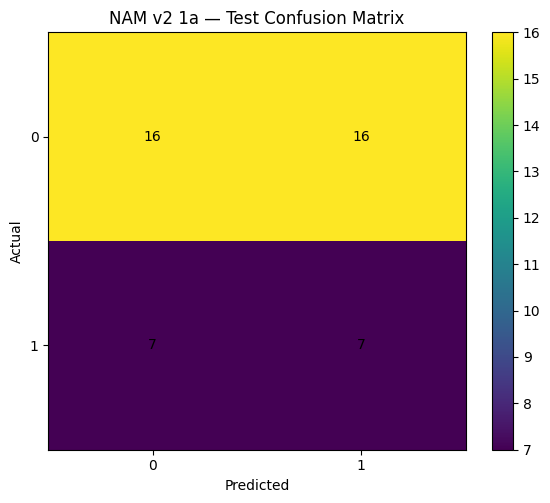

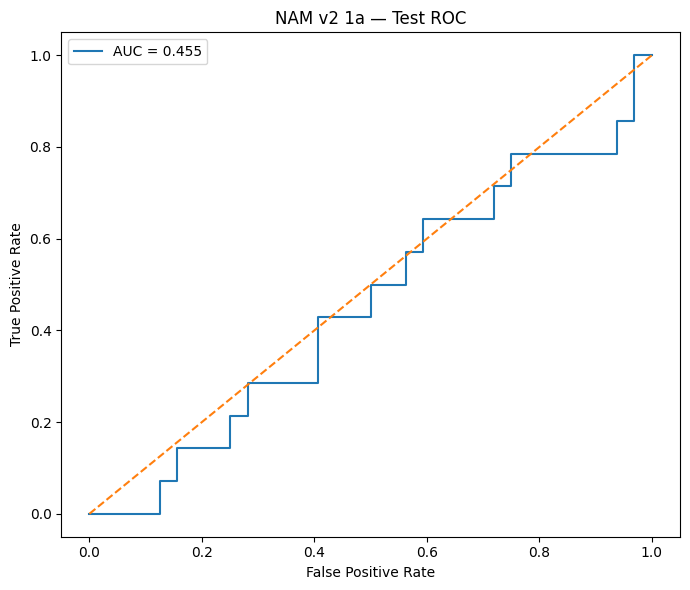

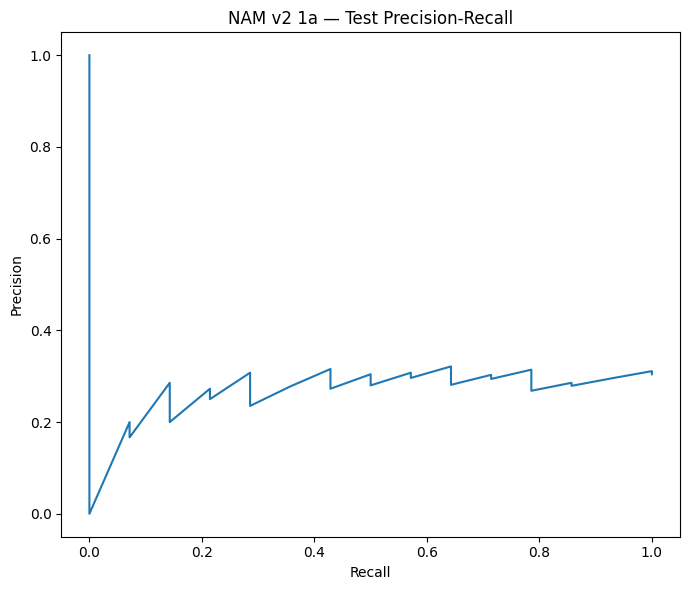

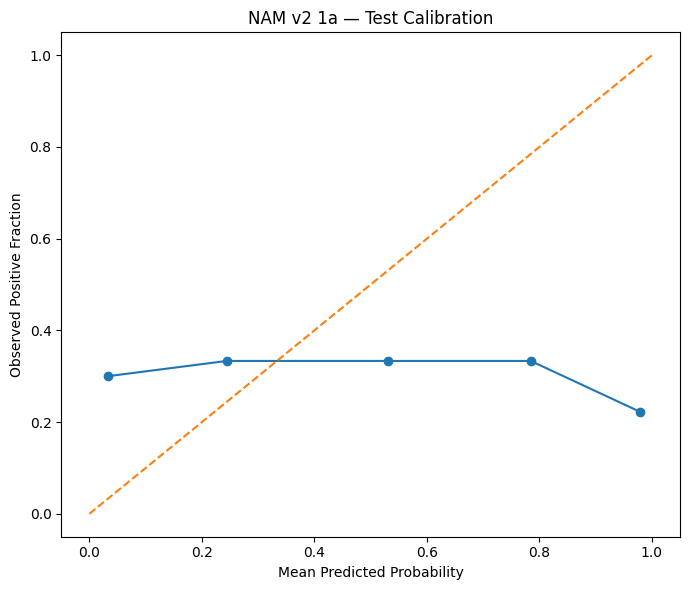


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
8,speech__std_intensity_db,speech,1.033273,-0.120365,-1.429437
24,speech__spectral_gravity,speech,0.850924,-0.116927,1.593926
9,speech__range_ratio_intensity_db,speech,0.785895,0.173263,-0.975048
19,speech__std_b1_loc,speech,0.748230,-0.033442,0.762730
14,speech__cepstral_peak_prominence_mean,speech,0.738078,0.124182,-0.545338
1,speech__articulation_rate,speech,0.692858,-0.150892,-0.401694
0,speech__speaking_rate,speech,0.685462,0.080659,0.874317
13,speech__spectral_tilt,speech,0.556589,-0.007124,0.676399
20,speech__mean_f2_loc,speech,0.447629,-0.030297,0.591596
27,speech__spectral_kurtosis,speech,0.437157,-0.101081,-0.190523



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_1A_-_Speech_Only_-_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


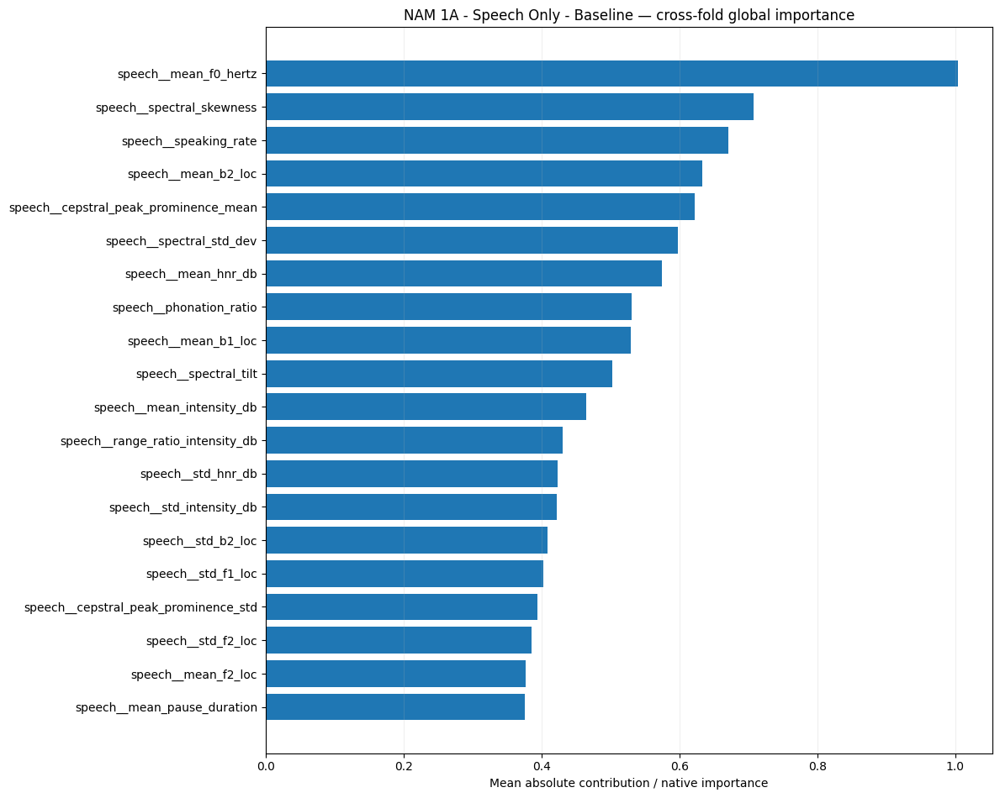


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
2,speech__cepstral_peak_prominence_std,5,0.592998,0.128908,0.374967,0.608513,-1.879563,2.014362
19,speech__spectral_std_dev,5,0.549463,0.404196,0.481485,0.680474,-1.666552,1.799793
24,speech__std_f1_loc,5,0.453389,0.227290,0.382049,0.659488,-1.898396,2.051157
5,speech__mean_f0_hertz,5,0.277646,0.841820,0.776928,0.935928,-1.343720,1.842802
11,speech__pause_rate,5,0.263661,0.305638,0.239799,0.493364,-1.768064,1.710399
6,speech__mean_f1_loc,5,0.243210,0.528329,0.334131,0.499159,-1.655399,2.398479
13,speech__range_ratio_intensity_db,5,0.237085,0.353273,0.498213,0.718390,-1.038354,0.812457
4,speech__mean_b2_loc,5,0.229263,0.642643,0.488857,0.683334,-1.518951,2.798539
20,speech__spectral_tilt,5,0.151245,0.531586,0.584449,0.795338,-2.104152,2.179019
3,speech__mean_b1_loc,5,0.143819,0.735172,0.660121,0.744644,-1.699834,2.741646


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_1A_-_Speech_Only_-_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 1a (corresponds to DNAMite 1a)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_1a_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1a",
    dnamite_experiment_id="1a",
    experiment_name='NAM 1A - Speech Only - Baseline',
    task="classification",
    cv_results=experiment_1a_classification_cv,
    final_result=experiment_1a_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1a",
    )
] = NAM_v2_1a_report


In [ ]:
import gc
import tensorflow as tf

# Delete the final trained NAM
del experiment_1a_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 1a complete. "
    "Waiting for file writes..."
)

time.sleep(30)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 1a complete. Waiting for file writes...
Disconnecting runtime.


### Experiment 1b Speech Classification with Feature Selection

In [ ]:
experiment_1b_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1B - "
            "Speech Only - Feature Selection"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)


NAM 1B - Speech Only - Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Joint selection: 4 features, C=0.25


[codecarbon WARNING @ 16:53:50] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Epochs ran=447; best epoch=443; best val_loss=0.688391; hit ceiling=False
RAM memory:
  start: 1367.31640625 MB
  absolute peak: 1814.68359375 MB
  incremental peak: 447.3671875 MB
GPU memory:
  start: 0.0 MB
  end: 0.135009765625 MB
  absolute peak: 0.143310546875 MB
  incremental peak: 0.143310546875 MB
Joint selection: 9 features, C=0.25
GPU memory at training start: 0.131103515625 MB


Epochs ran=500; best epoch=500; best val_loss=1.324405; hit ceiling=True
RAM memory:
  start: 1824.69921875 MB
  absolute peak: 1953.21875 MB
  incremental peak: 128.51953125 MB
GPU memory:
  start: 0.131103515625 MB
  end: 0.3916015625 MB
  absolute peak: 0.4033203125 MB
  incremental peak: 0.272216796875 MB
Joint selection: 5 features, C=0.25
GPU memory at training start: 0.3828125 MB
Epochs ran=500; best epoch=500; best val_loss=1.221318; hit ceiling=True
RAM memory:
  start: 1949.5234375 MB
  absolute peak: 2016.95703125 MB
  incremental peak: 67.43359375 MB
GPU memory:
  start: 0.3828125 MB
  end: 0.636474609375 MB
  absolute peak: 0.646240234375 MB
  incremental peak: 0.263427734375 MB
Joint selection: 18 features, C=1.0
GPU memory at training start: 0.631591796875 MB
Epochs ran=500; best epoch=500; best val_loss=4.013446; hit ceiling=True
RAM memory:
  start: 2016.32421875 MB
  absolute peak: 2393.78515625 MB
  incremental peak: 377.4609375 MB
GPU memory:
  start: 0.631591796875

In [ ]:
experiment_1b_classification_summary = (
    summarize_nested_cv(
        experiment_1b_classification_cv
    )
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.592593           0.457237  0.153846   0.200000   
1           2  0.333333           0.381579  0.307692   0.222222   
2           3  0.666667           0.618421  0.470588   0.444444   
3           4  0.555556           0.539474  0.400000   0.333333   
4           5  0.555556           0.611842  0.500000   0.375000   

   recall_sensitivity  specificity   roc_auc    pr_auc selected_text_count  \
0               0.125     0.789474  0.434211  0.317006                None   
1               0.500     0.263158  0.355263  0.347748                None   
2               0.500     0.736842  0.513158  0.441082                None   
3               0.500     0.578947  0.559211  0.484375                None   
4               0.750     0.473684  0.822368  0.758269                None   

   joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                     7         500         500            

In [ ]:
experiment_1b_classification_params = (
    choose_final_parameters(
        experiment_1b_classification_cv
    )
)


experiment_1b_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_1b_classification_params
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)

Joint selection: 7 features, C=0.25
GPU memory at training start: 45.108154296875 MB
Epochs ran=500; best epoch=500; best val_loss=0.777396; hit ceiling=True
RAM memory:
  start: 31899.625 MB
  absolute peak: 31899.65625 MB
  incremental peak: 0.03125 MB
GPU memory:
  start: 45.108154296875 MB
  end: 45.310791015625 MB
  absolute peak: 45.32080078125 MB
  incremental peak: 0.212646484375 MB
Best training epoch from internal validation: 500
Internal run epochs: 500 hit ceiling: True
Joint selection: 8 features, C=0.25
RAM memory:
  start: 31740.47265625 MB
  absolute peak: 31907.328125 MB
  incremental peak: 166.85546875 MB

FINAL TEST METRICS
{'accuracy': 0.6739130434782609, 'balanced_accuracy': np.float64(0.5647321428571428), 'f1': 0.34782608695652173, 'precision': 0.4444444444444444, 'recall_sensitivity': 0.2857142857142857, 'specificity': 0.84375, 'roc_auc': np.float64(0.5892857142857143), 'pr_auc': np.float64(0.5455584910645573)}


#### NAM v2 Experiment 1b — DNAMite-parity outputs (maps to DNAMite 1b)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 1b — NAM 1B - Speech Only - Feature Selection
DNAMite reference experiment: 1b

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.592593,0.457237,0.153846,0.200000,0.125,0.789474,0.434211,0.317006,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,7,500,500,True
1,2,0.333333,0.381579,0.307692,0.222222,0.500,0.263158,0.355263,0.347748,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,24,500,500,True
2,3,0.666667,0.618421,0.470588,0.444444,0.500,0.736842,0.513158,0.441082,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,25,499,500,True
3,4,0.555556,0.539474,0.400000,0.333333,0.500,0.578947,0.559211,0.484375,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,9,500,500,True
4,5,0.555556,0.611842,0.500000,0.375000,0.750,0.473684,0.822368,0.758269,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,6,500,500,True



CV Mean ± SD


,mean,sd
accuracy,0.540741,0.124502
balanced_accuracy,0.521711,0.101963
f1,0.366425,0.140053
precision,0.315000,0.103108
recall_sensitivity,0.475000,0.223607
specificity,0.568421,0.211838
roc_auc,0.536842,0.177546
pr_auc,0.469696,0.174996
joint_selected_count,14.200000,9.471008
best_epoch,499.800000,0.447214



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,1,67.350024,5568.691406,5664.781250,96.089844,0.194336,NaN,8.174561,8.358887,8.368896,tensorflow,337,0.065849
1,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,2,100.713529,14659.054688,15020.582031,361.527344,0.311768,NaN,18.176758,18.462891,18.488525,tensorflow,2305,0.205147
2,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,3,102.646604,24120.589844,24395.046875,274.457031,0.232422,NaN,27.260498,27.463867,27.492920,tensorflow,1201,0.208870
3,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,4,72.901337,27885.816406,28052.921875,167.105469,0.271484,NaN,36.061523,36.321045,36.333008,tensorflow,433,0.081421
4,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,5,67.786278,31731.734375,31780.507812,48.773438,0.266113,NaN,44.859375,45.114014,45.125488,tensorflow,577,0.060173



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,1,0.002165,0.001019
1,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,2,0.003242,0.001526
2,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,3,0.003302,0.001555
3,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,4,0.002343,0.001103
4,NAM v2,NAM 1B - Speech Only - Feature Selection,classification,5,0.002180,0.001026



Final Test Metrics
{'accuracy': 0.6739130434782609, 'balanced_accuracy': np.float64(0.5647321428571428), 'f1': 0.34782608695652173, 'precision': 0.4444444444444444, 'recall_sensitivity': 0.2857142857142857, 'specificity': 0.84375, 'roc_auc': np.float64(0.5892857142857143), 'pr_auc': np.float64(0.5455584910645573)}

Final Model Resource Summary
{'train_seconds': 42.16785349099882, 'start_ram_mb': 31740.47265625, 'peak_ram_mb': 31907.328125, 'incremental_peak_ram_mb': 166.85546875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0013524324754281198, 'training_co2_kg': 0.0006367022180794765}


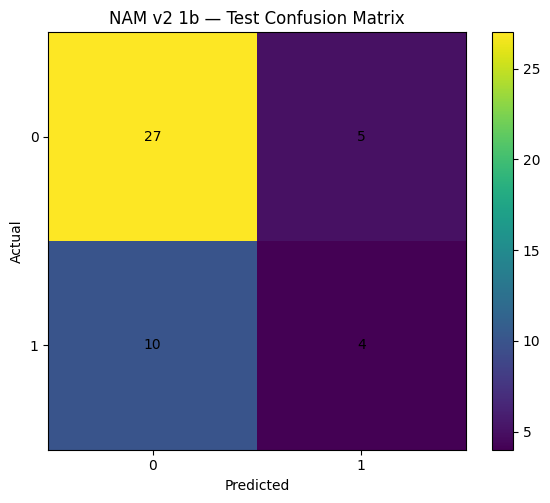

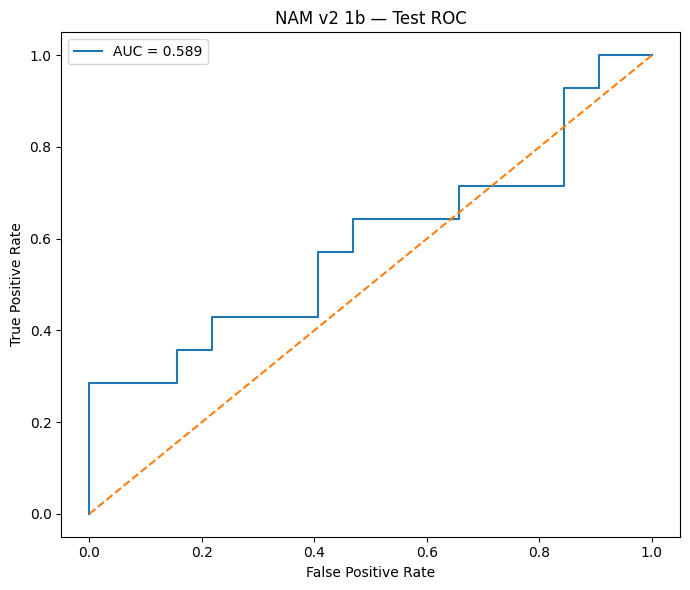

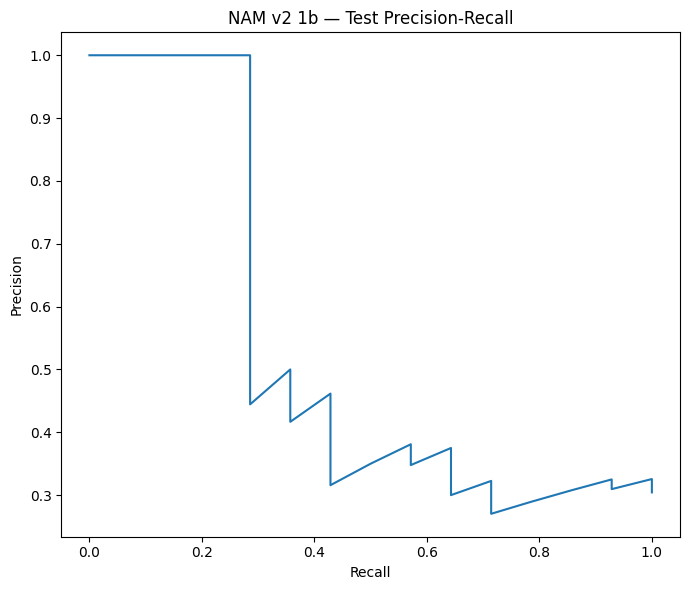

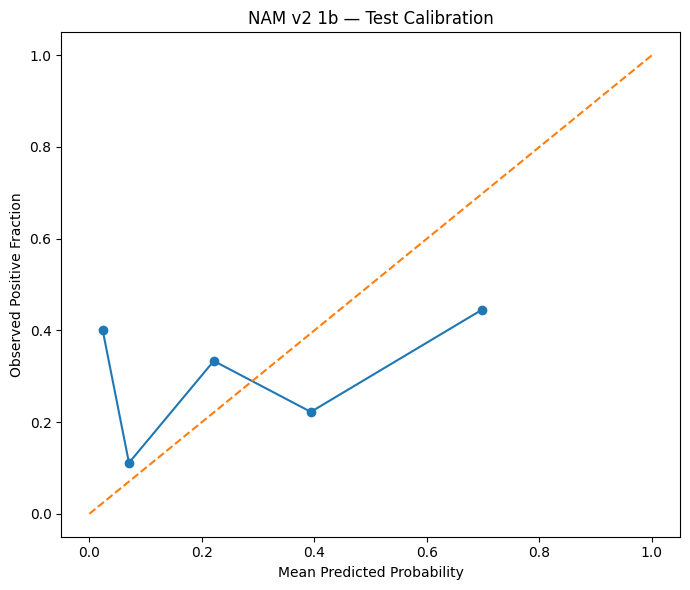


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
5,speech__std_f1_loc,speech,1.644317,0.312141,-1.338331
6,speech__std_f2_loc,speech,0.836762,-0.099534,0.731460
1,speech__std_f0_hertz,speech,0.707994,0.069704,-1.288999
3,speech__mean_hnr_db,speech,0.543586,0.046609,0.778054
0,speech__phonation_ratio,speech,0.333600,-0.044988,-0.648285
7,speech__mean_b2_loc,speech,0.249794,-0.011017,0.392998
2,speech__range_ratio_intensity_db,speech,0.215304,-0.084240,0.314312
4,speech__cepstral_peak_prominence_mean,speech,0.135729,-0.008016,-0.096715



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_1B_-_Speech_Only_-_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


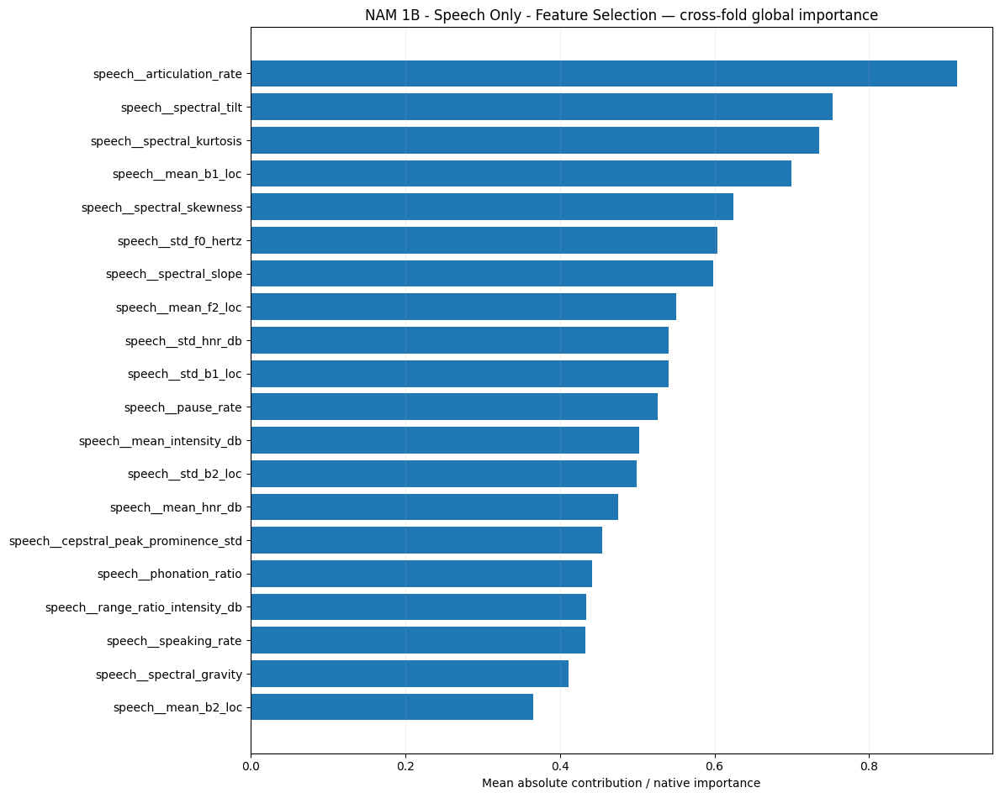


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
14,speech__spectral_kurtosis,2,0.877649,NaN,0.597016,0.971257,-1.317572,3.021330
18,speech__std_b1_loc,3,0.745850,0.131783,0.268056,0.572956,-1.559469,2.315497
7,speech__mean_hnr_db,4,0.723334,0.214020,0.370875,0.584345,-2.040370,2.137782
15,speech__spectral_skewness,2,0.654072,NaN,0.656639,1.005003,-1.809054,2.249689
13,speech__spectral_gravity,2,0.574131,NaN,0.318822,0.795967,-1.664999,2.443405
1,speech__cepstral_peak_prominence_std,2,0.570341,NaN,0.390203,0.697752,-2.267357,2.014362
23,speech__std_hnr_db,2,0.370840,NaN,0.569558,1.444428,-1.332545,3.071081
8,speech__mean_pause_duration,2,0.324978,NaN,0.129754,0.735740,-1.245163,2.914632
12,speech__speaking_rate,3,0.156773,0.058136,0.501853,0.903778,-2.195560,1.707387
10,speech__phonation_ratio,4,0.077765,0.600140,0.545393,0.815746,-2.298891,1.665699


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_1B_-_Speech_Only_-_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 1b (corresponds to DNAMite 1b)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_1b_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1b",
    dnamite_experiment_id="1b",
    experiment_name='NAM 1B - Speech Only - Feature Selection',
    task="classification",
    cv_results=experiment_1b_classification_cv,
    final_result=experiment_1b_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1b",
    )
] = NAM_v2_1b_report


In [ ]:
# Delete the final trained NAM
del experiment_1b_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 1c Speech Classification + Weighted BCE

In [ ]:
experiment_1c_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1C - "
            "Speech Only - Weighted BCE"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)


NAM 1C - Speech Only - Weighted BCE
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5


[codecarbon WARNING @ 05:55:47] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.72, 1: 1.6363636363636365}


Epochs ran=500; best epoch=500; best val_loss=1.020976; hit ceiling=True
RAM memory:
  start: 1452.83203125 MB
  absolute peak: 2356.19921875 MB
  incremental peak: 903.3671875 MB
GPU memory:
  start: 0.0 MB
  end: 0.296142578125 MB
  absolute peak: 0.329345703125 MB
  incremental peak: 0.329345703125 MB
GPU memory at training start: 0.268798828125 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=500; best epoch=500; best val_loss=1.593863; hit ceiling=True
RAM memory:
  start: 2362.5 MB
  absolute peak: 2759.3046875 MB
  incremental peak: 396.8046875 MB
GPU memory:
  start: 0.268798828125 MB
  end: 0.556640625 MB
  absolute peak: 0.587890625 MB
  incremental peak: 0.319091796875 MB
GPU memory at training start: 0.529296875 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=31; best epoch=1; best val_loss=1.260587; hit ceiling=False
RAM memory:
  start: 2550.3

In [ ]:
experiment_1c_classification_summary = (
    summarize_nested_cv(
        experiment_1c_classification_cv
    )
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.629630           0.555921  0.375000   0.375000   
1           2  0.333333           0.417763  0.357143   0.250000   
2           3  0.518519           0.368421  0.000000   0.000000   
3           4  0.629630           0.628289  0.500000   0.416667   
4           5  0.444444           0.532895  0.444444   0.315789   

   recall_sensitivity  specificity   roc_auc    pr_auc selected_text_count  \
0               0.375     0.736842  0.552632  0.453003                None   
1               0.625     0.210526  0.414474  0.294854                None   
2               0.000     0.736842  0.421053  0.276868                None   
3               0.625     0.631579  0.631579  0.555325                None   
4               0.750     0.315789  0.578947  0.446318                None   

  joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                 None         483         500              

In [ ]:
experiment_1c_classification_params = (
    choose_final_parameters(
        experiment_1c_classification_cv
    )
)


experiment_1c_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_1c_classification_params
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)

GPU memory at training start: 53.418212890625 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.7105263157894737, 1: 1.6875}
Epochs ran=500; best epoch=500; best val_loss=1.322370; hit ceiling=True
RAM memory:
  start: 61351.87109375 MB
  absolute peak: 61439.41015625 MB
  incremental peak: 87.5390625 MB
GPU memory:
  start: 53.418212890625 MB
  end: 53.709228515625 MB
  absolute peak: 53.73876953125 MB
  incremental peak: 0.320556640625 MB
Best training epoch from internal validation: 500
Internal run epochs: 500 hit ceiling: True
Final Weighted-BCE class weights: {0: 0.7105263157894737, 1: 1.6875}
RAM memory:
  start: 61304.69921875 MB
  absolute peak: 61713.1171875 MB
  incremental peak: 408.41796875 MB

FINAL TEST METRICS
{'accuracy': 0.6086956521739131, 'balanced_accuracy': np.float64(0.5379464285714286), 'f1': 0.35714285714285715, 'precision': 0.35714285714285715, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.71875, 'roc_auc': np.float64(0.56696428571428

#### NAM v2 Experiment 1c — DNAMite-parity outputs (maps to DNAMite 1e)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 1c — NAM 1C - Speech Only - Weighted BCE
DNAMite reference experiment: 1e

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.629630,0.555921,0.375000,0.375000,0.375,0.736842,0.552632,0.453003,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,483,500,True
1,2,0.333333,0.417763,0.357143,0.250000,0.625,0.210526,0.414474,0.294854,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,500,500,True
2,3,0.518519,0.368421,0.000000,0.000000,0.000,0.736842,0.421053,0.276868,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,500,500,True
3,4,0.629630,0.628289,0.500000,0.416667,0.625,0.631579,0.631579,0.555325,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,495,500,True
4,5,0.444444,0.532895,0.444444,0.315789,0.750,0.315789,0.578947,0.446318,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,500,500,True



CV Mean ± SD


,mean,sd
accuracy,0.511111,0.126686
balanced_accuracy,0.500658,0.105761
f1,0.335317,0.195907
precision,0.271491,0.164257
recall_sensitivity,0.475000,0.298433
specificity,0.526316,0.246864
roc_auc,0.519737,0.097360
pr_auc,0.405274,0.117429
best_epoch,495.600000,7.368853
epochs_ran,500.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,1,109.794900,13818.179688,14186.875000,368.695312,0.297119,NaN,9.909180,10.176514,10.206299,tensorflow,673,0.230118
1,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,2,111.834992,25501.953125,25872.484375,370.531250,0.322021,NaN,20.604492,20.896973,20.926514,tensorflow,673,0.230118
2,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,3,112.965231,37315.246094,37744.191406,428.945312,0.301758,NaN,31.776367,32.048340,32.078125,tensorflow,673,0.230118
3,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,4,112.167180,49056.882812,49491.921875,435.039062,0.281494,NaN,42.400391,42.652100,42.681885,tensorflow,2689,0.237930
4,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,5,114.658464,60986.914062,61246.289062,259.375000,0.324219,NaN,53.154297,53.445557,53.478516,tensorflow,1345,0.232071



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,1,0.003535,0.001664
1,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,2,0.003598,0.001694
2,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,3,0.003633,0.001710
3,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,4,0.003606,0.001697
4,NAM v2,NAM 1C - Speech Only - Weighted BCE,classification,5,0.003688,0.001736



Final Test Metrics
{'accuracy': 0.6086956521739131, 'balanced_accuracy': np.float64(0.5379464285714286), 'f1': 0.35714285714285715, 'precision': 0.35714285714285715, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.71875, 'roc_auc': np.float64(0.5669642857142857), 'pr_auc': np.float64(0.3914857841963765)}

Final Model Resource Summary
{'train_seconds': 78.53026048799802, 'start_ram_mb': 61304.69921875, 'peak_ram_mb': 61713.1171875, 'incremental_peak_ram_mb': 408.41796875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0025218503011371386, 'training_co2_kg': 0.0011872442503202455}


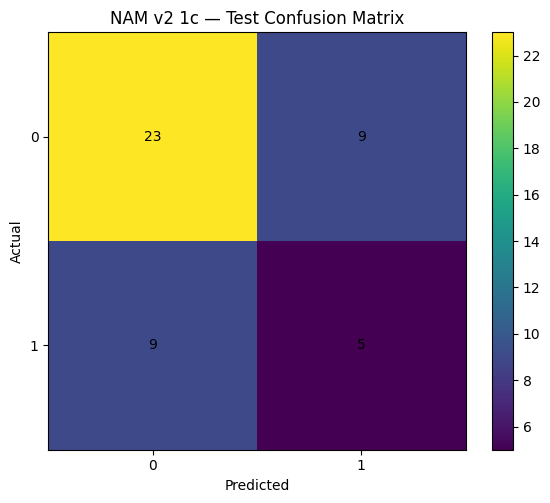

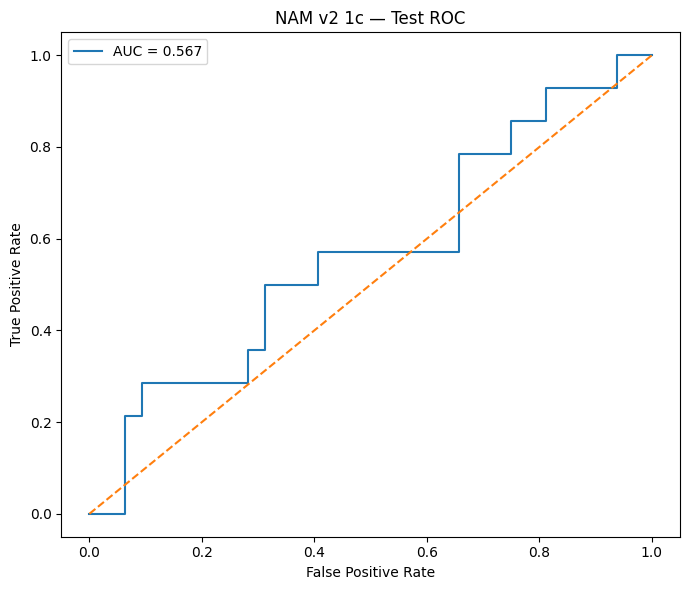

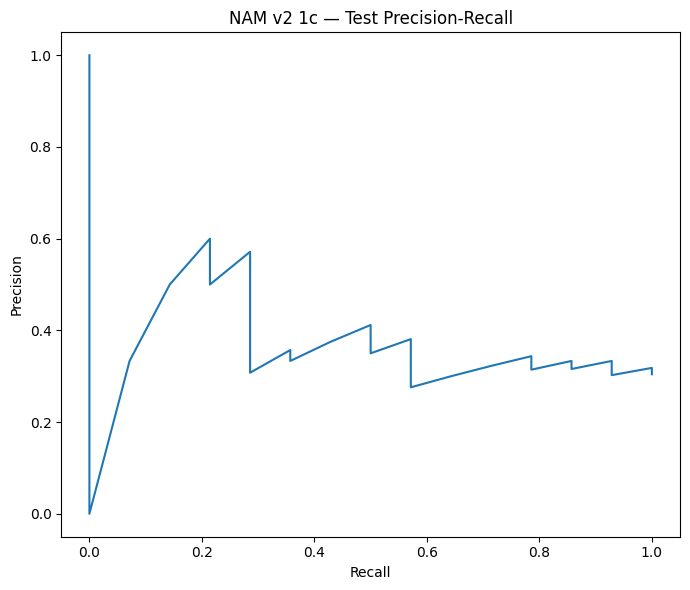

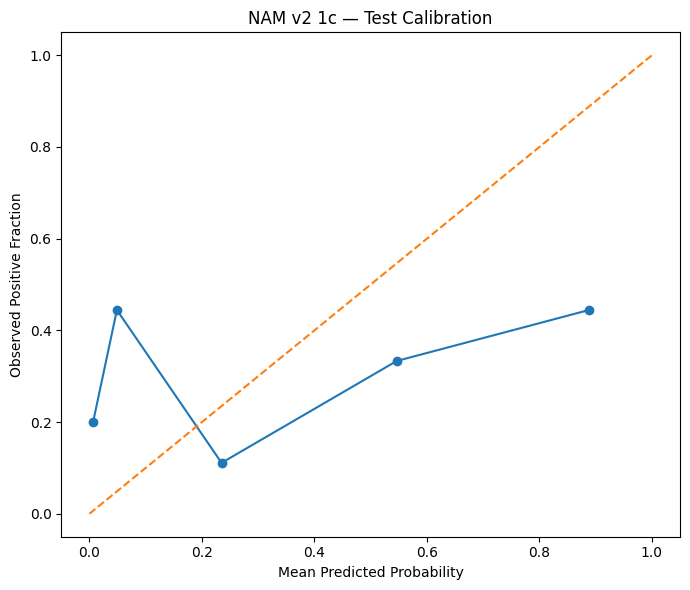


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
7,speech__mean_intensity_db,speech,0.873208,-0.198619,-0.892421
9,speech__range_ratio_intensity_db,speech,0.814606,0.238760,-1.040005
21,speech__std_f2_loc,speech,0.662816,-0.005858,0.850574
4,speech__mean_pause_duration,speech,0.542325,-0.214546,0.576728
24,speech__spectral_gravity,speech,0.533691,0.096656,-0.671565
18,speech__mean_b1_loc,speech,0.519913,-0.010667,0.384649
16,speech__mean_f1_loc,speech,0.499985,0.013647,-0.622137
26,speech__spectral_skewness,speech,0.494813,0.147342,0.799048
17,speech__std_f1_loc,speech,0.487919,-0.079998,0.418348
13,speech__spectral_tilt,speech,0.478013,-0.012596,-0.623835



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_1C_-_Speech_Only_-_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


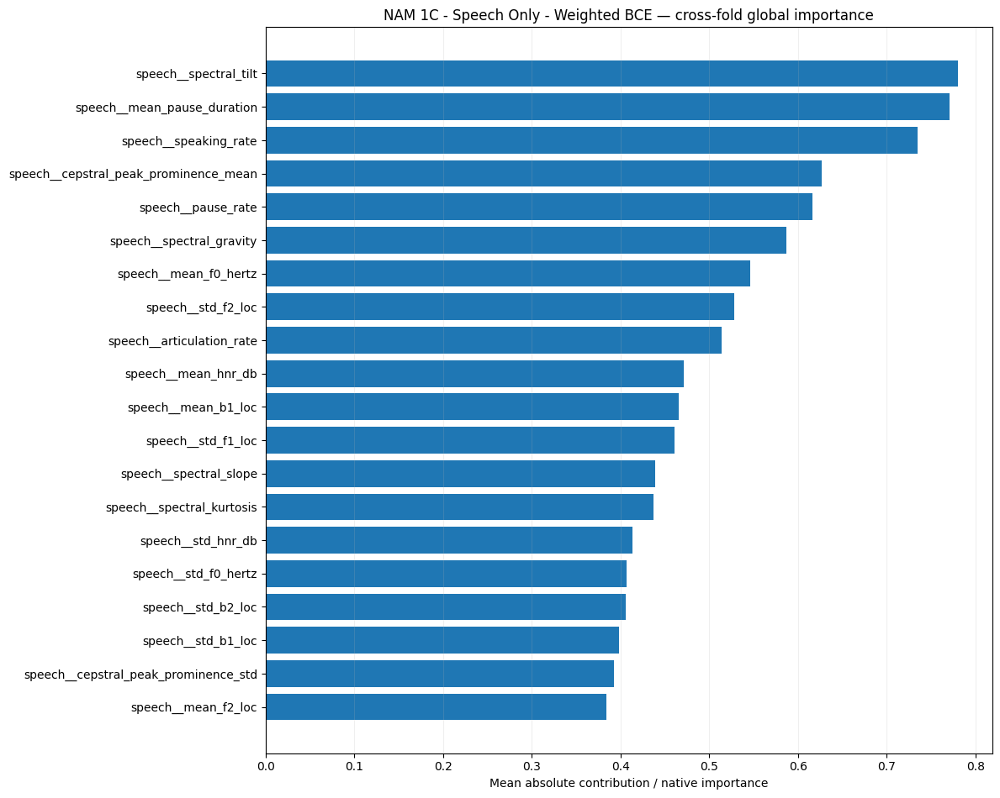


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
10,speech__mean_pause_duration,5,0.480492,0.230554,0.652720,0.934053,-1.180979,2.695285
3,speech__mean_b1_loc,5,0.416917,0.301452,0.458998,0.738090,-1.699834,2.741646
18,speech__spectral_slope,5,0.180305,0.860192,0.516941,0.670660,-2.240396,1.817583
6,speech__mean_f1_loc,5,0.155771,0.438077,0.327224,0.469351,-1.655399,2.398479
8,speech__mean_hnr_db,5,0.096240,0.721627,0.531453,0.704150,-2.040370,2.087750
0,speech__articulation_rate,5,0.090328,0.778322,0.823327,1.048009,-2.875069,1.011910
16,speech__spectral_kurtosis,5,0.084084,0.691244,0.629500,0.833594,-1.317572,2.944199
13,speech__range_ratio_intensity_db,5,0.042209,0.490521,0.404132,0.540149,-1.038354,0.812457
17,speech__spectral_skewness,5,0.030008,0.523712,0.398639,0.638820,-1.809054,2.054626
19,speech__spectral_std_dev,5,-0.006688,0.654120,0.462019,0.670562,-1.666552,1.799793


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_1C_-_Speech_Only_-_Weighted_BCE.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 1c (corresponds to DNAMite 1e)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_1c_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1c",
    dnamite_experiment_id="1e",
    experiment_name='NAM 1C - Speech Only - Weighted BCE',
    task="classification",
    cv_results=experiment_1c_classification_cv,
    final_result=experiment_1c_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1c",
    )
] = NAM_v2_1c_report


In [ ]:
# Delete the final trained NAM
del experiment_1c_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 1c complete. "
    "Waiting for file writes..."
)

time.sleep(30)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 1c complete. Waiting for file writes...
Disconnecting runtime.


### Experiment 1d Speech Regression Baseline

In [ ]:
experiment_1d_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1D - "
            "Speech Only - Regression Baseline"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)


NAM 1D - Speech Only - Regression Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/regression_135_74b76fd5eec4.npz

Outer Fold 1/5
Regression fold strata counts: {0: 48, 1: 26, 2: 21, 3: 9, 4: 4}


[codecarbon WARNING @ 18:37:36] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=500; best epoch=500; best val_loss=138.610077; hit ceiling=True
RAM memory:
  start: 1542.453125 MB
  absolute peak: 2430.6953125 MB
  incremental peak: 888.2421875 MB
GPU memory:
  start: 0.0 MB
  end: 0.296142578125 MB
  absolute peak: 0.32568359375 MB
  incremental peak: 0.32568359375 MB
GPU memory at training start: 0.268798828125 MB
Epochs ran=500; best epoch=500; best val_loss=177.480652; hit ceiling=True
RAM memory:
  start: 2435.13671875 MB
  absolute peak: 2749.76171875 MB
  incremental peak: 314.625 MB
GPU memory:
  start: 0.268798828125 MB
  end: 0.561767578125 MB
  absolute peak: 0.589111328125 MB
  incremental peak: 0.3203125 MB
GPU memory at training start: 0.534423828125 MB
Epochs ran=500; best epoch=500; best val_loss=74.873016; hit ceiling=True
RAM memory:
  start: 2749.5234375 MB
  absolute peak: 3020.640625 MB
  incremental peak: 271.1171875 MB
GPU memory:
  start: 0.534423828125 MB
  end: 0.827392578125 MB
  absolute peak: 0.8544921875 MB
  incremental pe

/tmp/ipykernel_1294734/2141328902.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


...

Outer validation metrics:
{'mae': 5.393364756195633, 'rmse': np.float64(6.980941295705545), 'r2': -0.5490865815692612, 'spearman_rho': np.float64(0.21244830858264946), 'spearman_p': np.float64(0.28738194132878553), 'exact_accuracy': np.float64(0.037037037037037035), 'within_1': np.float64(0.2222222222222222), 'within_2': np.float64(0.25925925925925924), 'within_3': np.float64(0.4074074074074074)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v2/NAM_1D_-_Speech_Only_-_Regression_Baseline/fold_03/model.weights.h5

Outer Fold 4/5
Regression fold strata counts: {0: 48, 1: 29, 2: 18, 3: 9, 4: 4}
GPU memory at training start: 27.857421875 MB
Epochs ran=500; best epoch=500; best val_loss=189.163467; hit ceiling=True
RAM memory:
  start: 30470.66015625 MB
  absolute peak: 30798.90234375 MB
  incremental peak: 328.2421875 MB
GPU memory:
  start: 27.857421875 MB
  end: 28.150390625 MB
  absolute peak: 28.177490234375 MB
  incremental peak: 0.320068359375 MB

/tmp/ipykernel_1294734/2141328902.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 7.394075583528589, 'rmse': np.float64(9.207960353817288), 'r2': -2.257583176803856, 'spearman_rho': np.float64(0.004595619293596067), 'spearman_p': np.float64(0.9818499777461145), 'exact_accuracy': np.float64(0.1111111111111111), 'within_1': np.float64(0.14814814814814814), 'within_2': np.float64(0.2222222222222222), 'within_3': np.float64(0.2222222222222222)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v2/NAM_1D_-_Speech_Only_-_Regression_Baseline/fold_04/model.weights.h5

Outer Fold 5/5
Regression fold strata counts: {0: 48, 1: 27, 2: 21, 3: 9, 4: 3}
GPU memory at training start: 37.42578125 MB
Epochs ran=500; best epoch=500; best val_loss=165.402527; hit ceiling=True
RAM memory:
  start: 39952.62890625 MB
  absolute peak: 40059.2265625 MB
  incremental peak: 106.59765625 MB
GPU memory:
  start: 37.42578125 MB
  end: 37.71875 MB
  absolute peak: 37.745849609375 MB
  incremental peak: 0.320068359375 MB
GPU memo

/tmp/ipykernel_1294734/2141328902.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


Outer validation metrics:
{'mae': 6.3641796641879615, 'rmse': np.float64(7.638211817242141), 'r2': -0.8439053996673418, 'spearman_rho': np.float64(-0.2638697006761315), 'spearman_p': np.float64(0.1835370933021883), 'exact_accuracy': np.float64(0.0), 'within_1': np.float64(0.07407407407407407), 'within_2': np.float64(0.1111111111111111), 'within_3': np.float64(0.2222222222222222)}
Saved NAM weights: /content/drive/MyDrive/Thesis/Model_Comparison_Results/models/NAM_v2/NAM_1D_-_Speech_Only_-_Regression_Baseline/fold_05/model.weights.h5


In [ ]:
experiment_1d_results_df = pd.DataFrame(
    [
        {
            "outer_fold": result["outer_fold"],

            **result["metrics"],

            **{
                f"parameter_{key}": value
                for key, value
                in result["parameters"].items()
            },
        }

        for result
        in experiment_1d_regression_cv
    ]
)

display(
    experiment_1d_results_df
)

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,parameter_activation,parameter_dropout,parameter_feature_dropout,parameter_learning_rate,parameter_num_units,parameter_shallow
0,1,7.703816,9.150077,-2.019428,0.339254,0.083422,0.074074,0.037037,0.037037,0.074074,exu,0.25,0.0,0.0005,32,True
1,2,6.646926,8.416068,-0.815074,-0.144174,0.473090,0.111111,0.111111,0.222222,0.333333,exu,0.10,0.0,0.0010,32,True
2,3,5.393365,6.980941,-0.549087,0.212448,0.287382,0.037037,0.222222,0.259259,0.407407,exu,0.10,0.0,0.0010,16,True
3,4,7.394076,9.207960,-2.257583,0.004596,0.981850,0.111111,0.148148,0.222222,0.222222,exu,0.10,0.0,0.0010,16,True
4,5,6.364180,7.638212,-0.843905,-0.263870,0.183537,0.000000,0.074074,0.111111,0.222222,exu,0.25,0.0,0.0005,16,True


In [ ]:
experiment_1d_summary = (
    summarize_nested_cv(
        experiment_1d_regression_cv
    )
)

display(
    experiment_1d_summary
)

   outer_fold       mae      rmse        r2  spearman_rho  spearman_p  \
0           1  7.703816  9.150077 -2.019428      0.339254    0.083422   
1           2  6.646926  8.416068 -0.815074     -0.144174    0.473090   
2           3  5.393365  6.980941 -0.549087      0.212448    0.287382   
3           4  7.394076  9.207960 -2.257583      0.004596    0.981850   
4           5  6.364180  7.638212 -0.843905     -0.263870    0.183537   

   exact_accuracy  within_1  within_2  within_3  ...  baseline_spearman_p  \
0        0.074074  0.037037  0.037037  0.074074  ...                  NaN   
1        0.111111  0.111111  0.222222  0.333333  ...                  NaN   
2        0.037037  0.222222  0.259259  0.407407  ...                  NaN   
3        0.111111  0.148148  0.222222  0.222222  ...                  NaN   
4        0.000000  0.074074  0.111111  0.222222  ...                  NaN   

   baseline_exact_accuracy  baseline_within_1  baseline_within_2  \
0                 0.074074    

,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,...,baseline_spearman_p,baseline_exact_accuracy,baseline_within_1,baseline_within_2,baseline_within_3,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,7.703816,9.150077,-2.019428,0.339254,0.083422,0.074074,0.037037,0.037037,0.074074,...,NaN,0.074074,0.148148,0.222222,0.407407,None,None,500,500,True
1,2,6.646926,8.416068,-0.815074,-0.144174,0.473090,0.111111,0.111111,0.222222,0.333333,...,NaN,0.074074,0.074074,0.259259,0.296296,None,None,500,500,True
2,3,5.393365,6.980941,-0.549087,0.212448,0.287382,0.037037,0.222222,0.259259,0.407407,...,NaN,0.148148,0.148148,0.185185,0.370370,None,None,500,500,True
3,4,7.394076,9.207960,-2.257583,0.004596,0.981850,0.111111,0.148148,0.222222,0.222222,...,NaN,0.111111,0.148148,0.185185,0.259259,None,None,500,500,True
4,5,6.364180,7.638212,-0.843905,-0.263870,0.183537,0.000000,0.074074,0.111111,0.222222,...,NaN,0.074074,0.148148,0.185185,0.296296,None,None,500,500,True


In [ ]:
experiment_1d_best_parameters = (
    choose_final_parameters(
        experiment_1d_regression_cv
    )
)

print(
    "Best parameters:"
)

print(
    experiment_1d_best_parameters
)

Best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True}


In [ ]:
import inspect

print(
    inspect.signature(
        train_final_nam_model
    )
)

(task, speech_development, y_development, speech_test, y_test, parameters, experiment_variant, text_development=None, text_test=None, text_representation=None)


In [ ]:
experiment_1d_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_1d_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),
    )
)

Regression fold strata counts: {0: 30, 1: 30, 2: 24, 3: 26, 4: 25}
GPU memory at training start: 47.14892578125 MB
Epochs ran=31; best epoch=1; best val_loss=43.649483; hit ceiling=False
RAM memory:
  start: 49251.4765625 MB
  absolute peak: 49378.6796875 MB
  incremental peak: 127.203125 MB
GPU memory:
  start: 47.14892578125 MB
  end: 47.205810546875 MB
  absolute peak: 47.237548828125 MB
  incremental peak: 0.088623046875 MB
Best training epoch from internal validation: 1
Internal run epochs: 31 hit ceiling: False
RAM memory:
  start: 49235.421875 MB
  absolute peak: 49594.66015625 MB
  incremental peak: 359.23828125 MB

FINAL TEST METRICS
{'mae': 7.252207172305687, 'rmse': np.float64(9.270509015754621), 'r2': -1.0912131410870765, 'spearman_rho': np.float64(0.027915511721496793), 'spearman_p': np.float64(0.8538899161259901), 'exact_accuracy': np.float64(0.15217391304347827), 'within_1': np.float64(0.15217391304347827), 'within_2': np.float64(0.2391304347826087), 'within_3': np.float

/tmp/ipykernel_1294734/2141328902.py:8: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_result = spearmanr(


#### NAM v2 Experiment 1d — DNAMite-parity outputs (maps to DNAMite 1c)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 1d — NAM 1D - Speech Only - Regression Baseline
DNAMite reference experiment: 1c

CV Results


,outer_fold,mae,rmse,r2,spearman_rho,spearman_p,exact_accuracy,within_1,within_2,within_3,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,7.703816,9.150077,-2.019428,0.339254,0.083422,0.074074,0.037037,0.037037,0.074074,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,500,500,True
1,2,6.646926,8.416068,-0.815074,-0.144174,0.473090,0.111111,0.111111,0.222222,0.333333,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,500,500,True
2,3,5.393365,6.980941,-0.549087,0.212448,0.287382,0.037037,0.222222,0.259259,0.407407,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,500,500,True
3,4,7.394076,9.207960,-2.257583,0.004596,0.981850,0.111111,0.148148,0.222222,0.222222,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",None,None,500,500,True
4,5,6.364180,7.638212,-0.843905,-0.263870,0.183537,0.000000,0.074074,0.111111,0.222222,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",None,None,500,500,True



CV Mean ± SD


,mean,sd
mae,6.700472,0.909983
rmse,8.278652,0.966449
r2,-1.297015,0.781272
spearman_rho,0.029651,0.248126
spearman_p,0.401856,0.354836
exact_accuracy,0.066667,0.048290
within_1,0.118519,0.071242
within_2,0.170370,0.092962
within_3,0.251852,0.126686
best_epoch,500.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,1,114.729583,11378.246094,11779.269531,401.023438,0.322021,NaN,8.857178,9.150146,9.179199,tensorflow,2689,0.237930
1,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,2,116.509149,20776.699219,21129.339844,352.640625,0.321045,NaN,18.210205,18.502197,18.531250,tensorflow,2689,0.237930
2,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,3,117.802316,30260.925781,30586.605469,325.679688,0.323486,NaN,27.592773,27.884766,27.916260,tensorflow,1345,0.232071
3,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,4,121.025433,39572.726562,39806.035156,233.308594,0.323486,NaN,37.161133,37.453125,37.484619,tensorflow,1345,0.232071
4,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,5,119.358428,48781.218750,49114.031250,332.812500,0.322510,NaN,46.885254,47.176270,47.207764,tensorflow,1345,0.232071



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,1,0.003680,0.001732
1,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,2,0.003736,0.001759
2,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,3,0.003779,0.001779
3,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,4,0.003880,0.001827
4,NAM v2,NAM 1D - Speech Only - Regression Baseline,regression,5,0.003853,0.001814



Final Test Metrics
{'mae': 7.252207172305687, 'rmse': np.float64(9.270509015754621), 'r2': -1.0912131410870765, 'spearman_rho': np.float64(0.027915511721496793), 'spearman_p': np.float64(0.8538899161259901), 'exact_accuracy': np.float64(0.15217391304347827), 'within_1': np.float64(0.15217391304347827), 'within_2': np.float64(0.2391304347826087), 'within_3': np.float64(0.32608695652173914)}

Final Model Resource Summary
{'train_seconds': 42.65682968299734, 'start_ram_mb': 49235.421875, 'peak_ram_mb': 49594.66015625, 'incremental_peak_ram_mb': 359.23828125, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0013571166111113397, 'training_co2_kg': 0.0006389074295288299}


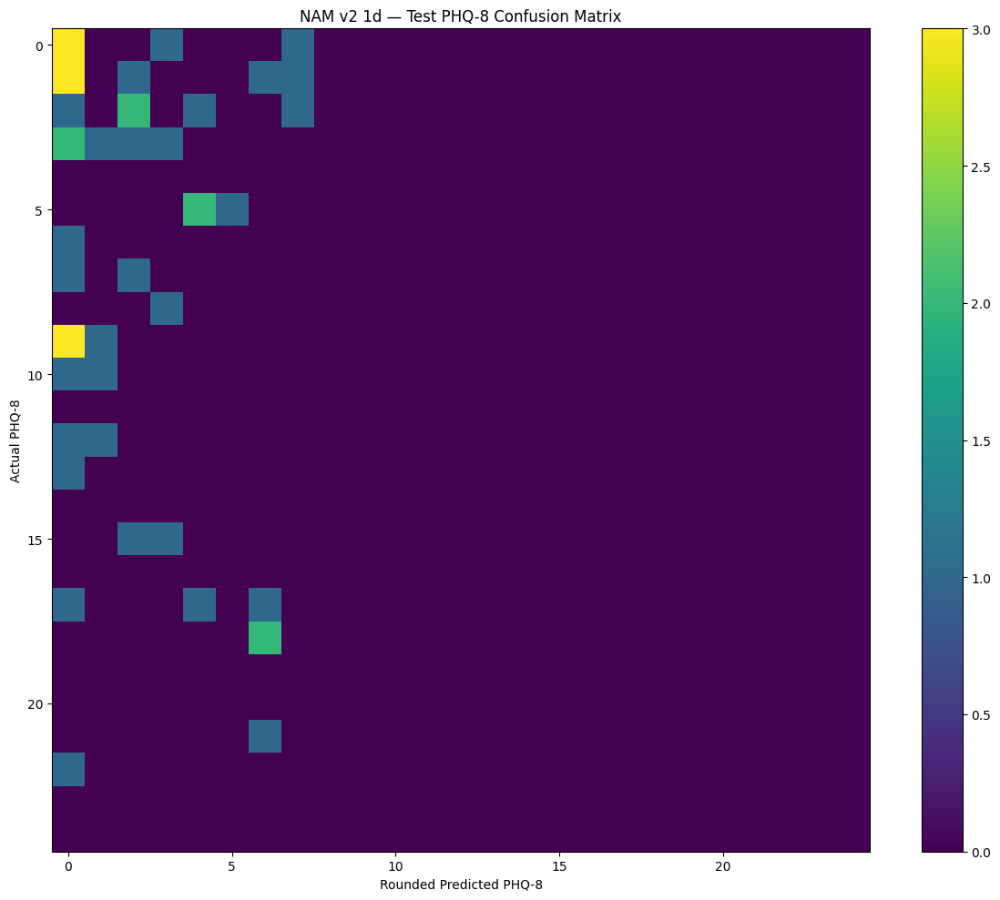

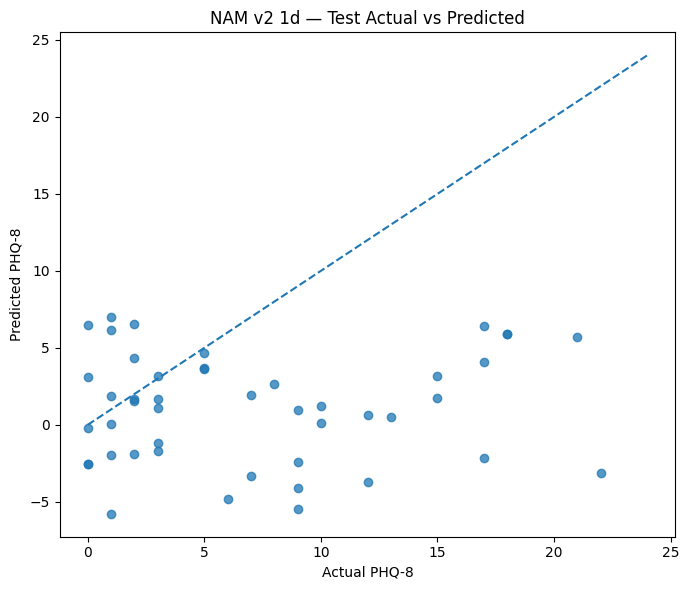


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
2,speech__phonation_ratio,speech,1.647068,-0.357474,-2.402979
27,speech__spectral_kurtosis,speech,1.162419,0.622635,2.227226
4,speech__mean_pause_duration,speech,0.993075,-0.208961,0.678178
24,speech__spectral_gravity,speech,0.951835,0.159098,-1.092318
22,speech__mean_b2_loc,speech,0.898958,-0.028061,-0.978674
12,speech__spectral_slope,speech,0.872719,0.282978,-0.269103
15,speech__cepstral_peak_prominence_std,speech,0.846555,-0.115908,1.080437
10,speech__mean_hnr_db,speech,0.769232,0.031591,0.588672
6,speech__std_f0_hertz,speech,0.751068,0.020434,1.019532
14,speech__cepstral_peak_prominence_mean,speech,0.736602,-0.196783,0.681320



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_1D_-_Speech_Only_-_Regression_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


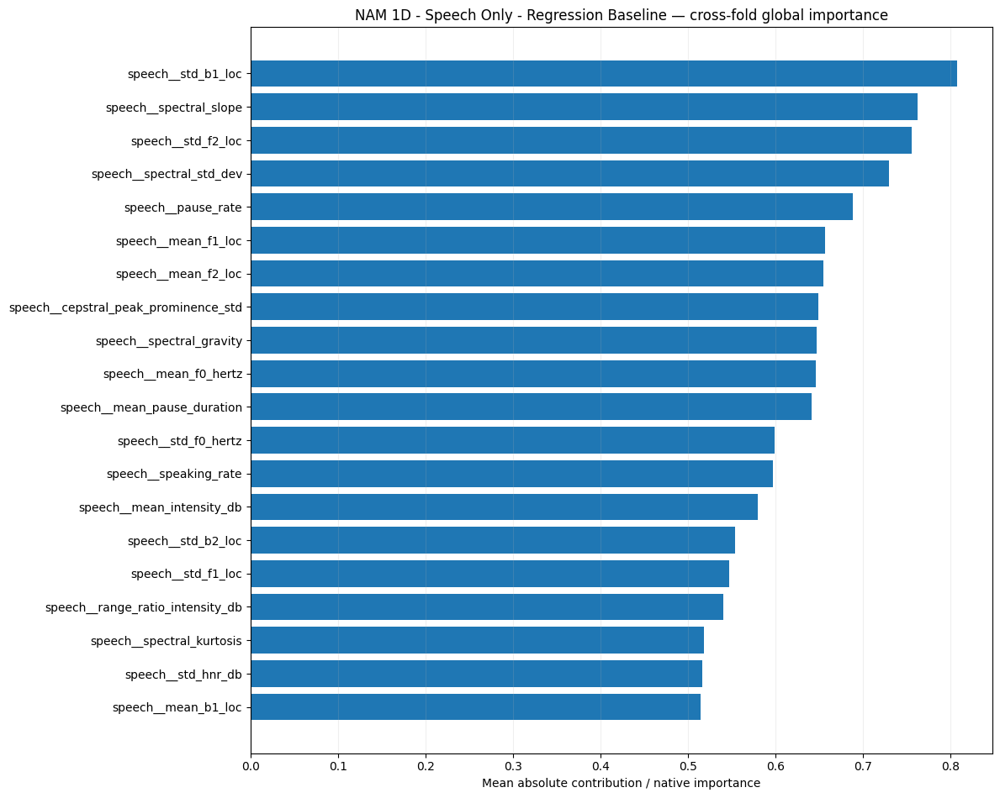


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
2,speech__cepstral_peak_prominence_std,5,0.757601,0.085957,0.416762,0.690490,-2.126806,2.421201
21,speech__std_b1_loc,5,0.747010,0.198019,0.668819,0.903693,-1.541928,2.284121
20,speech__spectral_tilt,5,0.269797,0.382383,0.452912,0.697953,-2.086141,2.117087
3,speech__mean_b1_loc,5,0.188129,0.716050,0.500948,0.728751,-1.631855,2.672147
24,speech__std_f1_loc,5,0.176948,0.774338,0.482556,0.915999,-1.861318,1.998083
7,speech__mean_f2_loc,5,0.159624,0.863917,0.767230,1.024988,-2.069726,2.197272
23,speech__std_f0_hertz,5,0.152860,0.653921,0.676912,0.801797,-1.449444,2.229207
17,speech__spectral_skewness,5,0.152530,0.551097,0.324182,0.667372,-1.805789,2.174063
22,speech__std_b2_loc,5,0.140107,0.815049,0.623329,0.907005,-1.384901,2.373243
14,speech__speaking_rate,5,0.116314,0.643637,0.608885,0.777348,-2.383316,1.658730


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_1D_-_Speech_Only_-_Regression_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 1d (corresponds to DNAMite 1c)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_1d_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1d",
    dnamite_experiment_id="1c",
    experiment_name='NAM 1D - Speech Only - Regression Baseline',
    task="regression",
    cv_results=experiment_1d_regression_cv,
    final_result=experiment_1d_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1d",
    )
] = NAM_v2_1d_report


In [ ]:
# Delete the final trained NAM
del experiment_1d_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 1e Speech Regression with Feature Selection

In [ ]:
experiment_1e_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1E - "
            "Speech Only - Regression Feature Selection"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)

In [ ]:
experiment_1e_results_df = pd.DataFrame(
    [
        {
            "outer_fold": result["outer_fold"],

            **result["metrics"],

            **{
                f"parameter_{key}": value
                for key, value
                in result["parameters"].items()
            },
        }

        for result
        in experiment_1e_regression_cv
    ]
)

display(
    experiment_1e_results_df
)

In [ ]:
experiment_1e_summary = (
    summarize_nested_cv(
        experiment_1e_regression_cv
    )
)

display(
    experiment_1e_summary
)

In [ ]:
experiment_1e_best_parameters = (
    choose_final_parameters(
        experiment_1e_regression_cv
    )
)

print(
    "Best parameters:"
)

print(
    experiment_1e_best_parameters
)

In [ ]:
experiment_1e_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_1e_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),
    )
)

#### NAM v2 Experiment 1e — DNAMite-parity outputs (maps to DNAMite 1d)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 1e (corresponds to DNAMite 1d)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_1e_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1e",
    dnamite_experiment_id="1d",
    experiment_name='NAM 1E - Speech Only - Regression Feature Selection',
    task="regression",
    cv_results=experiment_1e_regression_cv,
    final_result=experiment_1e_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1e",
    )
] = NAM_v2_1e_report


In [ ]:
# Delete the final trained NAM
del experiment_1e_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 1f Speech Regression with LDS

In [ ]:
experiment_1f_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 1F - "
            "Speech Only - Regression LDS"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)

In [ ]:
experiment_1f_results_df = pd.DataFrame(
    [
        {
            "outer_fold": result["outer_fold"],

            **result["metrics"],

            **{
                f"parameter_{key}": value
                for key, value
                in result["parameters"].items()
            },
        }

        for result
        in experiment_1f_regression_cv
    ]
)

display(
    experiment_1f_results_df
)

In [ ]:
experiment_1f_summary = (
    summarize_nested_cv(
        experiment_1f_regression_cv
    )
)

display(
    experiment_1f_summary
)

In [ ]:
experiment_1f_best_parameters = (
    choose_final_parameters(
        experiment_1f_regression_cv
    )
)

print(
    "Best parameters:"
)

print(
    experiment_1f_best_parameters
)

In [ ]:
experiment_1f_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_1f_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),
    )
)

#### NAM v2 Experiment 1f — DNAMite-parity outputs (maps to DNAMite 1f)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 1f (corresponds to DNAMite 1f)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_1f_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="1f",
    dnamite_experiment_id="1f",
    experiment_name='NAM 1F - Speech Only - Regression LDS',
    task="regression",
    cv_results=experiment_1f_regression_cv,
    final_result=experiment_1f_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=None,
    text_representation=None,
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "1f",
    )
] = NAM_v2_1f_report


In [ ]:
# Delete the final trained NAM
#del experiment_1f_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

## Experiment 2 -- Speech + Unigram

### Experiment 2a Speech + Unigram Classification

In [ ]:
experiment_2a_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2A - "
            "Speech + Unigrams - Baseline"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2A - Speech + Unigrams - Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 14 TF-IDF features for classification / unigram using C=5.0


[codecarbon WARNING @ 18:13:43] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=500; best epoch=500; best val_loss=1.600232; hit ceiling=True
RAM memory:
  start: 1367.98828125 MB
  absolute peak: 2594.6640625 MB
  incremental peak: 1226.67578125 MB
GPU memory:
  start: 0.0 MB
  end: 0.320068359375 MB
  absolute peak: 0.36376953125 MB
  incremental peak: 0.36376953125 MB
Selected 15 TF-IDF features for classification / unigram using C=5.0
GPU memory at training start: 0.279052734375 MB
Epochs ran=500; best epoch=500; best val_loss=1.700621; hit ceiling=True
RAM memory:
  start: 2599.9140625 MB
  absolute peak: 2870.734375 MB
  incremental peak: 270.8203125 MB
GPU memory:
  start: 0.279052734375 MB
  end: 0.59765625 MB
  absolute peak: 0.638916015625 MB
  incremental peak: 0.35986328125 MB
Selected 1 TF-IDF features for classification / unigram using C=2.5
GPU memory at training start: 0.5556640625 MB
Epochs ran=500; best epoch=500; best val_loss=1.346177; hit ceiling=True
RAM memory:
  start: 2745.42578125 MB
  absolute peak: 3168.27734375 MB
  incremen

In [ ]:
experiment_2a_classification_summary = (
    summarize_nested_cv(
        experiment_2a_classification_cv
    )
)

display(
    experiment_2a_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.370370           0.371711  0.260870   0.200000   
1           2  0.629630           0.519737  0.285714   0.333333   
2           3  0.370370           0.444079  0.370370   0.263158   
3           4  0.629630           0.700658  0.583333   0.437500   
4           5  0.555556           0.648026  0.538462   0.388889   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.375     0.368421  0.381579  0.260541                    1   
1               0.250     0.789474  0.532895  0.331201                    2   
2               0.625     0.263158  0.500000  0.332092                    3   
3               0.875     0.526316  0.671053  0.397638                    2   
4               0.875     0.421053  0.815789  0.609740                    1   

  joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                 None         500         500        

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.370370,0.371711,0.260870,0.200000,0.375,0.368421,0.381579,0.260541,1,None,500,500,True
1,2,0.629630,0.519737,0.285714,0.333333,0.250,0.789474,0.532895,0.331201,2,None,500,500,True
2,3,0.370370,0.444079,0.370370,0.263158,0.625,0.263158,0.500000,0.332092,3,None,500,500,True
3,4,0.629630,0.700658,0.583333,0.437500,0.875,0.526316,0.671053,0.397638,2,None,500,500,True
4,5,0.555556,0.648026,0.538462,0.388889,0.875,0.421053,0.815789,0.609740,1,None,500,500,True


In [ ]:
for result in experiment_2a_classification_cv:
    print(
        f"Outer Fold {result['outer_fold']}"
    )
    print(
        result["parameters"]
    )
    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 16, 'shallow': True}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 8, 'shallow': True}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 8, 'shallow': True}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}



In [ ]:
for result in experiment_2a_classification_cv:
    print(
        f"Fold {result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

Fold 1: 1 selected unigrams
Fold 2: 2 selected unigrams
Fold 3: 3 selected unigrams
Fold 4: 2 selected unigrams
Fold 5: 1 selected unigrams


In [ ]:
experiment_2a_best_parameters = (
    choose_final_parameters(
        experiment_2a_classification_cv
    )
)

print(
    "Chosen final parameters:"
)

print(
    experiment_2a_best_parameters
)

Chosen final parameters:
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}


In [ ]:
import json

parameter_table = pd.DataFrame(
    {
        "outer_fold": [
            result["outer_fold"]
            for result
            in experiment_2a_classification_cv
        ],

        "parameters": [
            json.dumps(
                result["parameters"],
                sort_keys=True,
            )
            for result
            in experiment_2a_classification_cv
        ],
    }
)

display(
    parameter_table
)

print(
    "\nParameter selection counts:"
)

display(
    parameter_table[
        "parameters"
    ].value_counts()
)

,outer_fold,parameters
0,1,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature..."
1,2,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur..."
2,3,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur..."
3,4,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur..."
4,5,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur..."



Parameter selection counts:


,count
parameters,
"{""activation"": ""exu"", ""dropout"": 0.25, ""feature_dropout"": 0.0, ""learning_rate"": 0.001, ""num_units"": 32, ""shallow"": true}",2
"{""activation"": ""exu"", ""dropout"": 0.25, ""feature_dropout"": 0.0, ""learning_rate"": 0.001, ""num_units"": 8, ""shallow"": true}",2
"{""activation"": ""exu"", ""dropout"": 0.1, ""feature_dropout"": 0.0, ""learning_rate"": 0.0005, ""num_units"": 16, ""shallow"": true}",1


In [ ]:
experiment_2a_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_2a_best_parameters
        ),

        experiment_variant="baseline",

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation="unigram",
    )
)

Selected 1 TF-IDF features for classification / unigram using C=2.5
GPU memory at training start: 43.845947265625 MB
Epochs ran=500; best epoch=500; best val_loss=3.086602; hit ceiling=True
RAM memory:
  start: 63166.015625 MB
  absolute peak: 63256.7578125 MB
  incremental peak: 90.7421875 MB
GPU memory:
  start: 43.845947265625 MB
  end: 44.14013671875 MB
  absolute peak: 44.17041015625 MB
  incremental peak: 0.324462890625 MB
Best training epoch from internal validation: 500
Internal run epochs: 500 hit ceiling: True
Selected 4 TF-IDF features for classification / unigram using C=2.5
RAM memory:
  start: 63156.49609375 MB
  absolute peak: 63576.4140625 MB
  incremental peak: 419.91796875 MB

FINAL TEST METRICS
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.4441964285714286), 'f1': 0.29411764705882354, 'precision': 0.25, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.53125, 'roc_auc': np.float64(0.48660714285714285), 'pr_auc': np.float64(0.34122195664

In [ ]:
print(
    "Final parameters:"
)

print(
    experiment_2a_classification_final[
        "parameters"
    ]
)


print(
    "\nFinal test metrics:"
)

print(
    experiment_2a_classification_final[
        "metrics"
    ]
)


print(
    "\nBest epoch:"
)

print(
    experiment_2a_classification_final[
        "best_epoch"
    ]
)


print(
    "\nNumber of selected unigrams:"
)

print(
    len(
        experiment_2a_classification_final[
            "selected_text_indices"
        ]
    )
)

Final parameters:
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 32, 'shallow': True}

Final test metrics:
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.4441964285714286), 'f1': 0.29411764705882354, 'precision': 0.25, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.53125, 'roc_auc': np.float64(0.48660714285714285), 'pr_auc': np.float64(0.34122195664523775)}

Best epoch:
500

Number of selected unigrams:
4


#### NAM v2 Experiment 2a — DNAMite-parity outputs (maps to DNAMite 2a)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 2a — NAM 2A - Speech + Unigrams - Baseline
DNAMite reference experiment: 2a

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.370370,0.371711,0.260870,0.200000,0.375,0.368421,0.381579,0.260541,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,500,500,True
1,2,0.629630,0.519737,0.285714,0.333333,0.250,0.789474,0.532895,0.331201,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",2,None,500,500,True
2,3,0.370370,0.444079,0.370370,0.263158,0.625,0.263158,0.500000,0.332092,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",3,None,500,500,True
3,4,0.629630,0.700658,0.583333,0.437500,0.875,0.526316,0.671053,0.397638,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",2,None,500,500,True
4,5,0.555556,0.648026,0.538462,0.388889,0.875,0.421053,0.815789,0.609740,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",1,None,500,500,True



CV Mean ± SD


,mean,sd
accuracy,0.511111,0.131989
balanced_accuracy,0.536842,0.137262
f1,0.407750,0.146440
precision,0.324576,0.095205
recall_sensitivity,0.600000,0.285044
specificity,0.473684,0.200415
roc_auc,0.580263,0.167240
pr_auc,0.386243,0.134018
selected_text_count,1.800000,0.836660
best_epoch,500.000000,0.000000



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,1,111.355193,14535.984375,14689.050781,153.066406,0.327637,NaN,8.403320,8.697998,8.730957,tensorflow,1393,0.239700
1,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,2,112.424432,24340.750000,24553.367188,212.617188,0.308594,NaN,16.907715,17.185303,17.216309,tensorflow,2881,0.253189
2,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,3,121.878854,38645.707031,38831.976562,186.269531,0.333496,NaN,25.857910,26.155518,26.191406,tensorflow,745,0.253006
3,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,4,120.541168,51097.519531,51166.136719,68.617188,0.335693,NaN,35.135010,35.431396,35.470703,tensorflow,721,0.245377
4,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,5,117.285166,62884.945312,63061.515625,176.570312,0.326904,NaN,43.580078,43.874268,43.906982,tensorflow,2785,0.245560



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,1,0.003595,0.000962
1,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,2,0.003633,0.000972
2,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,3,0.003939,0.001054
3,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,4,0.003894,0.001042
4,NAM v2,NAM 2A - Speech + Unigrams - Baseline,classification,5,0.003792,0.001015



Final Test Metrics
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.4441964285714286), 'f1': 0.29411764705882354, 'precision': 0.25, 'recall_sensitivity': 0.35714285714285715, 'specificity': 0.53125, 'roc_auc': np.float64(0.48660714285714285), 'pr_auc': np.float64(0.34122195664523775)}

Final Model Resource Summary
{'train_seconds': 85.02239781600292, 'start_ram_mb': 63156.49609375, 'peak_ram_mb': 63576.4140625, 'incremental_peak_ram_mb': 419.91796875, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0027535828664824688, 'training_co2_kg': 0.0007369193538937713}


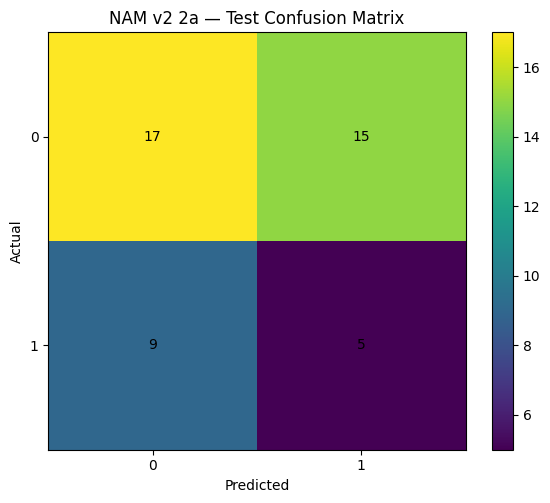

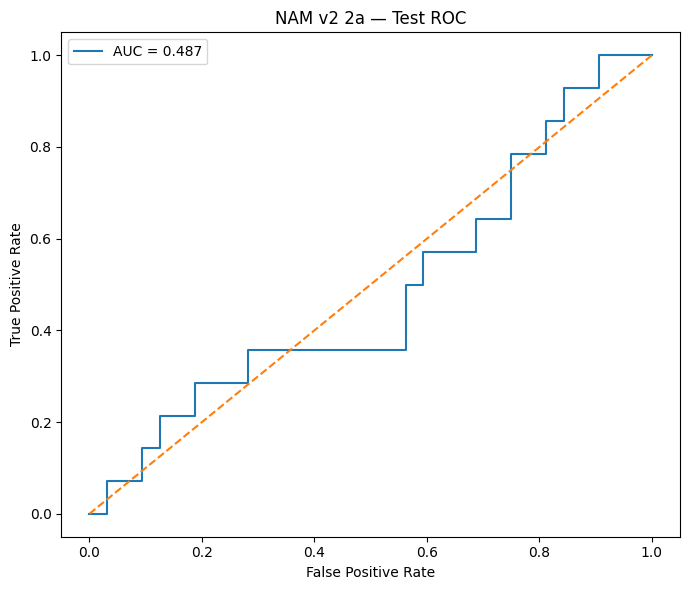

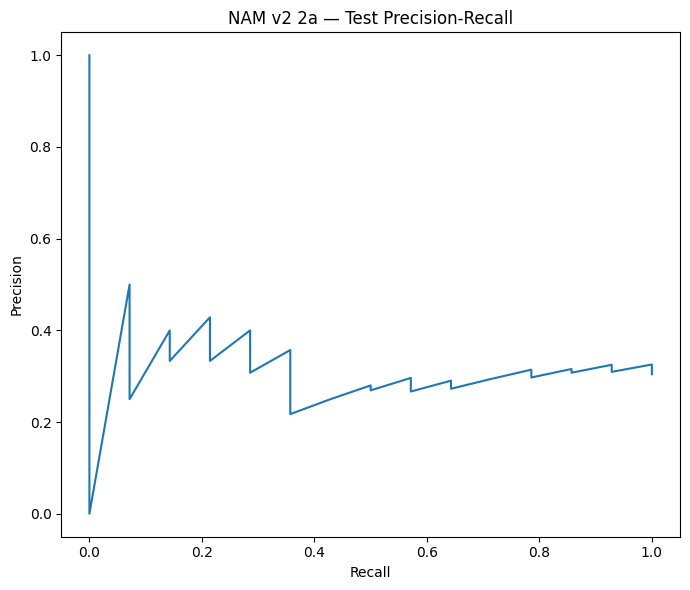

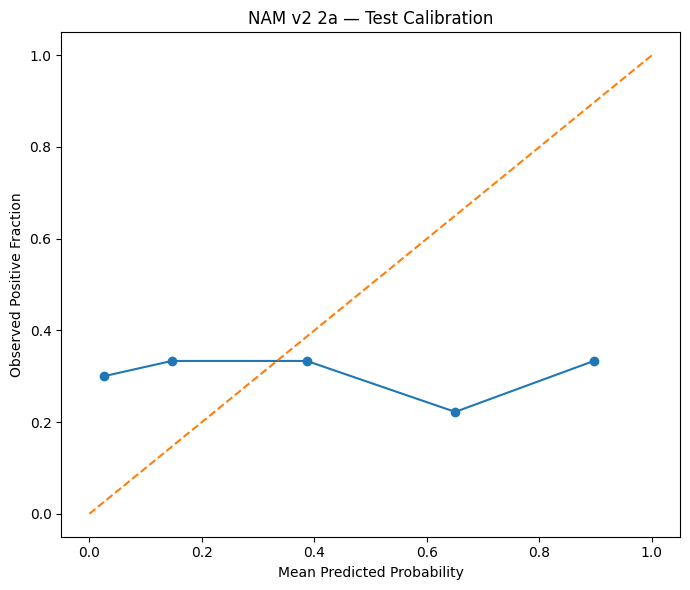


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
16,speech__mean_f1_loc,speech,0.902092,0.043487,1.159135
22,speech__mean_b2_loc,speech,0.844353,0.016114,0.787506
17,speech__std_f1_loc,speech,0.839709,0.119066,-1.325826
15,speech__cepstral_peak_prominence_std,speech,0.702566,-0.049335,0.861381
7,speech__mean_intensity_db,speech,0.666085,0.050629,-0.796841
5,speech__mean_f0_hertz,speech,0.649003,-0.185232,-0.907678
0,speech__speaking_rate,speech,0.643869,0.106258,0.919476
21,speech__std_f2_loc,speech,0.642484,-0.056882,-0.429306
4,speech__mean_pause_duration,speech,0.561935,0.145282,-0.200129
3,speech__pause_rate,speech,0.542657,0.009411,-0.868078



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_2A_-_Speech_Unigrams_-_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


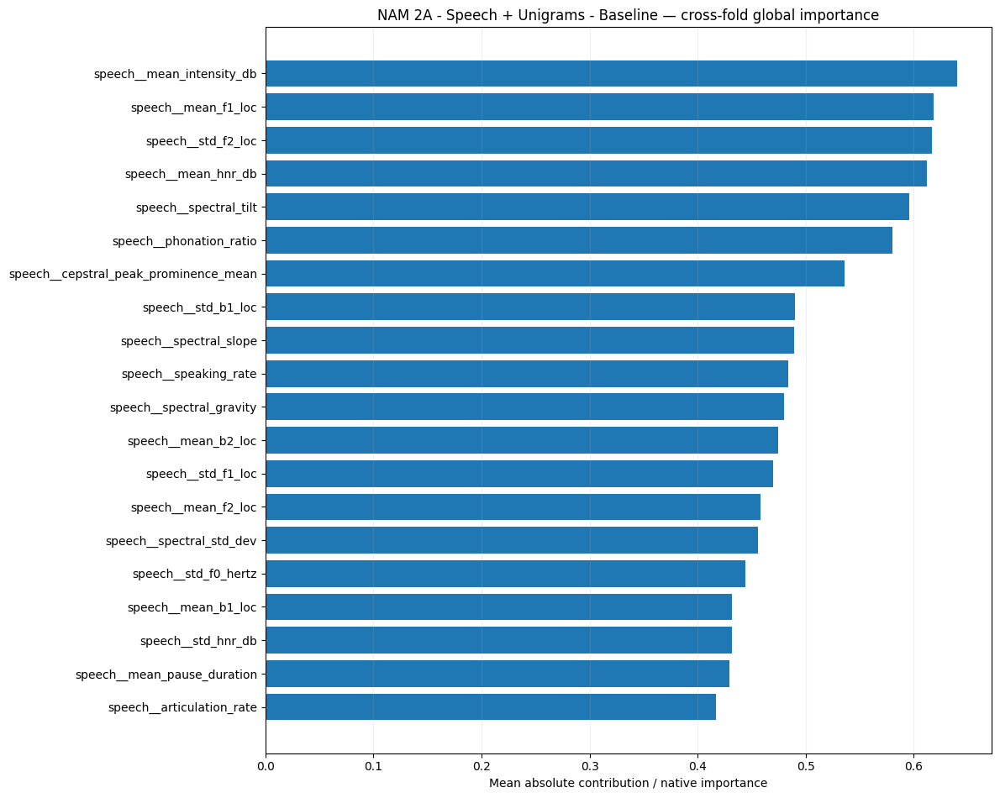

/tmp/ipykernel_2235/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic



Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
29,text__therapist,3,0.989184,NaN,0.227482,0.458113,0.000000,0.085293
21,speech__std_b1_loc,5,0.635393,0.179692,0.483859,0.747544,-1.540199,2.315497
0,speech__articulation_rate,5,0.416110,0.345672,0.466497,0.914449,-2.875069,1.011910
23,speech__std_f0_hertz,5,0.413848,0.335564,0.474756,0.667600,-1.441116,2.275466
16,speech__spectral_kurtosis,5,0.334310,0.360418,0.317861,0.560293,-1.317572,2.944199
15,speech__spectral_gravity,5,0.178885,0.443420,0.495144,0.890167,-1.599719,2.395075
12,speech__phonation_ratio,5,0.178319,0.823307,0.687501,0.851299,-2.298891,1.633485
9,speech__mean_intensity_db,5,0.159529,0.546853,0.941434,1.088189,-1.887187,2.363089
18,speech__spectral_slope,5,0.146322,0.818386,0.462989,0.712520,-2.240396,1.817583
25,speech__std_f2_loc,5,0.096691,0.783783,0.742505,0.940647,-1.703705,2.586484


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_2A_-_Speech_Unigrams_-_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 2a (corresponds to DNAMite 2a)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_2a_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2a",
    dnamite_experiment_id="2a",
    experiment_name='NAM 2A - Speech + Unigrams - Baseline',
    task="classification",
    cv_results=experiment_2a_classification_cv,
    final_result=experiment_2a_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2a",
    )
] = NAM_v2_2a_report


In [ ]:
# Delete the final trained NAM
del experiment_2a_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 2b Speech + Unigram Classification with Feature Selection

In [ ]:
experiment_2b_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2B - "
            "Speech + Unigrams - "
            "Joint Feature Selection"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2B - Speech + Unigrams - Joint Feature Selection
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 14 TF-IDF features for classification / unigram using C=5.0
Selected 14 TF-IDF features for classification / unigram using C=5.0
Joint selection: 4 features, C=0.25


[codecarbon WARNING @ 19:48:29] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Epochs ran=500; best epoch=500; best val_loss=1.304184; hit ceiling=True
RAM memory:
  start: 1368.19921875 MB
  absolute peak: 1819.3984375 MB
  incremental peak: 451.19921875 MB
GPU memory:
  start: 0.0 MB
  end: 0.255126953125 MB
  absolute peak: 0.26318359375 MB
  incremental peak: 0.26318359375 MB
Selected 15 TF-IDF features for classification / unigram using C=5.0
Joint selection: 9 features, C=0.25
GPU memory at training start: 0.251220703125 MB


Epochs ran=500; best epoch=500; best val_loss=1.187245; hit ceiling=True
RAM memory:
  start: 1825.22265625 MB
  absolute peak: 1993.1015625 MB
  incremental peak: 167.87890625 MB
GPU memory:
  start: 0.251220703125 MB
  end: 0.51171875 MB
  absolute peak: 0.5234375 MB
  incremental peak: 0.272216796875 MB
Selected 1 TF-IDF features for classification / unigram using C=2.5
Joint selection: 5 features, C=0.25
GPU memory at training start: 0.5029296875 MB
Epochs ran=500; best epoch=500; best val_loss=1.085181; hit ceiling=True
RAM memory:
  start: 1965.4765625 MB
  absolute peak: 2039.3359375 MB
  incremental peak: 73.859375 MB
GPU memory:
  start: 0.5029296875 MB
  end: 0.756591796875 MB
  absolute peak: 0.766357421875 MB
  incremental peak: 0.263427734375 MB
Selected 14 TF-IDF features for classification / unigram using C=5.0
Joint selection: 18 features, C=1.0
GPU memory at training start: 0.751708984375 MB
Epochs ran=31; best epoch=1; best val_loss=0.855965; hit ceiling=False
RAM mem

In [ ]:
experiment_2b_classification_summary = (
    summarize_nested_cv(
        experiment_2b_classification_cv
    )
)

display(
    experiment_2b_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.407407           0.434211  0.333333   0.250000   
1           2  0.666667           0.618421  0.470588   0.444444   
2           3  0.629630           0.555921  0.375000   0.375000   
3           4  0.555556           0.503289  0.333333   0.300000   
4           5  0.555556           0.394737  0.000000   0.000000   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.500     0.368421  0.296053  0.237013                    1   
1               0.500     0.736842  0.585526  0.577188                    2   
2               0.375     0.736842  0.677632  0.486411                    3   
3               0.375     0.631579  0.388158  0.275142                    2   
4               0.000     0.789474  0.111842  0.195986                    1   

   joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                    25         500         500      

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.407407,0.434211,0.333333,0.250000,0.500,0.368421,0.296053,0.237013,1,25,500,500,True
1,2,0.666667,0.618421,0.470588,0.444444,0.500,0.736842,0.585526,0.577188,2,16,500,500,True
2,3,0.629630,0.555921,0.375000,0.375000,0.375,0.736842,0.677632,0.486411,3,6,500,500,True
3,4,0.555556,0.503289,0.333333,0.300000,0.375,0.631579,0.388158,0.275142,2,17,448,464,False
4,5,0.555556,0.394737,0.000000,0.000000,0.000,0.789474,0.111842,0.195986,1,6,500,500,True


In [ ]:
for result in experiment_2b_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True, 'joint_selection_value': 5.0}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 8, 'shallow': True, 'joint_selection_value': 1.0}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 8, 'shallow': True, 'joint_selection_value': 0.25}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True, 'joint_selection_value': 1.0}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 8, 'shallow': True, 'joint_selection_value': 0.25}



In [ ]:
for result in experiment_2b_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        "Selected unigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

Outer Fold 1
Selected unigram features: 1
Final jointly selected features: 25

Outer Fold 2
Selected unigram features: 2
Final jointly selected features: 16

Outer Fold 3
Selected unigram features: 3
Final jointly selected features: 6

Outer Fold 4
Selected unigram features: 2
Final jointly selected features: 17

Outer Fold 5
Selected unigram features: 1
Final jointly selected features: 6



In [ ]:
experiment_2b_best_parameters = (
    choose_final_parameters(
        experiment_2b_classification_cv
    )
)

print(
    "Experiment 2B best parameters:"
)

print(
    experiment_2b_best_parameters
)

Experiment 2B best parameters:
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'joint_selection_value': 5.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True}


In [ ]:
experiment_2b_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_2b_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 1 TF-IDF features for classification / unigram using C=2.5
Joint selection: 25 features, C=5.0
GPU memory at training start: 47.667236328125 MB
Epochs ran=500; best epoch=500; best val_loss=2.005423; hit ceiling=True
RAM memory:
  start: 32304.359375 MB
  absolute peak: 32624.5546875 MB
  incremental peak: 320.1953125 MB
GPU memory:
  start: 47.667236328125 MB
  end: 47.9521484375 MB
  absolute peak: 47.98095703125 MB
  incremental peak: 0.313720703125 MB
Best training epoch from internal validation: 500
Internal run epochs: 500 hit ceiling: True
Selected 4 TF-IDF features for classification / unigram using C=2.5
Joint selection: 31 features, C=5.0
RAM memory:
  start: 32477.2734375 MB
  absolute peak: 33138.25 MB
  incremental peak: 660.9765625 MB

FINAL TEST METRICS
{'accuracy': 0.43478260869565216, 'balanced_accuracy': np.float64(0.49330357142857145), 'f1': 0.4090909090909091, 'precision': 0.3, 'recall_sensitivity': 0.6428571428571429, 'specificity': 0.34375, 'roc_auc': np.

In [ ]:
experiment_2b_classification_final[
    "metrics"
]

{'accuracy': 0.43478260869565216,
 'balanced_accuracy': np.float64(0.49330357142857145),
 'f1': 0.4090909090909091,
 'precision': 0.3,
 'recall_sensitivity': 0.6428571428571429,
 'specificity': 0.34375,
 'roc_auc': np.float64(0.3839285714285714),
 'pr_auc': np.float64(0.2644017329011688)}

In [ ]:
experiment_2b_classification_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.25,
 'feature_dropout': 0.0,
 'joint_selection_value': 5.0,
 'learning_rate': 0.001,
 'num_units': 16,
 'shallow': True}

In [ ]:
selected_text_indices = (
    experiment_2b_classification_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

Selected unigrams: 4


#### NAM v2 Experiment 2b — DNAMite-parity outputs (maps to DNAMite 2b)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 2b — NAM 2B - Speech + Unigrams - Joint Feature Selection
DNAMite reference experiment: 2b

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.407407,0.434211,0.333333,0.250000,0.500,0.368421,0.296053,0.237013,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",1,25,500,500,True
1,2,0.666667,0.618421,0.470588,0.444444,0.500,0.736842,0.585526,0.577188,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,16,500,500,True
2,3,0.629630,0.555921,0.375000,0.375000,0.375,0.736842,0.677632,0.486411,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",3,6,500,500,True
3,4,0.555556,0.503289,0.333333,0.300000,0.375,0.631579,0.388158,0.275142,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,17,448,464,False
4,5,0.555556,0.394737,0.000000,0.000000,0.000,0.789474,0.111842,0.195986,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,6,500,500,True



CV Mean ± SD


,mean,sd
accuracy,0.562963,0.099381
balanced_accuracy,0.501316,0.090224
f1,0.302451,0.178127
precision,0.273889,0.169985
recall_sensitivity,0.350000,0.205396
specificity,0.652632,0.168914
roc_auc,0.411842,0.226262
pr_auc,0.354348,0.167495
selected_text_count,1.800000,0.836660
joint_selected_count,14.000000,8.093207



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,1,104.655578,11869.562500,11998.632812,129.070312,0.316162,NaN,10.437012,10.724365,10.753174,tensorflow,1201,0.208870
1,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,2,87.580282,18280.785156,18460.093750,179.308594,0.221680,NaN,20.534912,20.739014,20.756592,tensorflow,385,0.135323
2,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,3,69.641469,21963.160156,22076.996094,113.835938,0.254150,NaN,29.681885,29.921143,29.936035,tensorflow,145,0.058220
3,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,4,84.451062,28321.410156,28452.605469,131.195312,0.229248,NaN,39.717041,39.925537,39.946289,tensorflow,817,0.144905
4,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,5,70.467350,32145.636719,32186.597656,40.960938,0.268555,NaN,47.419189,47.673096,47.687744,tensorflow,145,0.058220



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,1,0.002801,0.000011
1,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,2,0.002351,0.001107
2,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,3,0.001869,0.000880
3,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,4,0.002264,0.001066
4,NAM v2,NAM 2B - Speech + Unigrams - Joint Feature Sel...,classification,5,0.001891,0.000890



Final Test Metrics
{'accuracy': 0.43478260869565216, 'balanced_accuracy': np.float64(0.49330357142857145), 'f1': 0.4090909090909091, 'precision': 0.3, 'recall_sensitivity': 0.6428571428571429, 'specificity': 0.34375, 'roc_auc': np.float64(0.3839285714285714), 'pr_auc': np.float64(0.2644017329011688)}

Final Model Resource Summary
{'train_seconds': 82.3478884770011, 'start_ram_mb': 32477.2734375, 'peak_ram_mb': 33138.25, 'incremental_peak_ram_mb': 660.9765625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.002207982447237532, 'training_co2_kg': 0.001039480600457827}


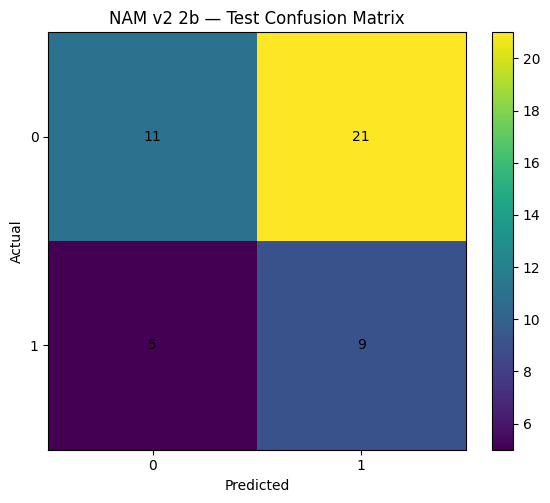

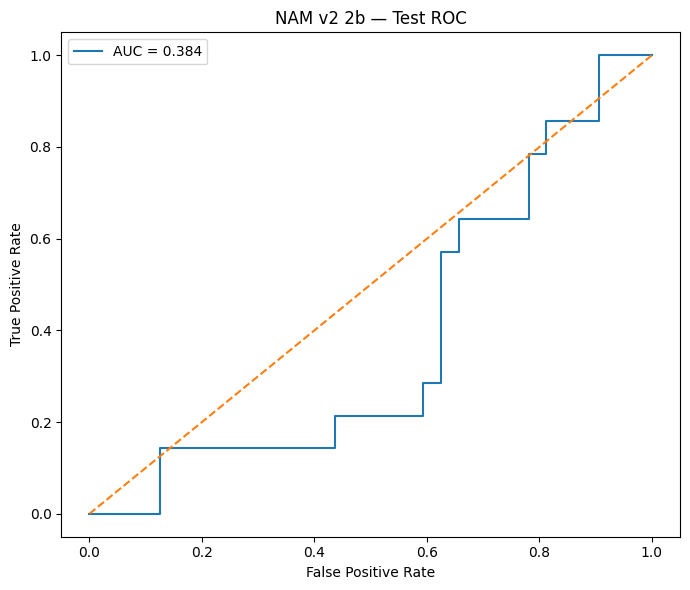

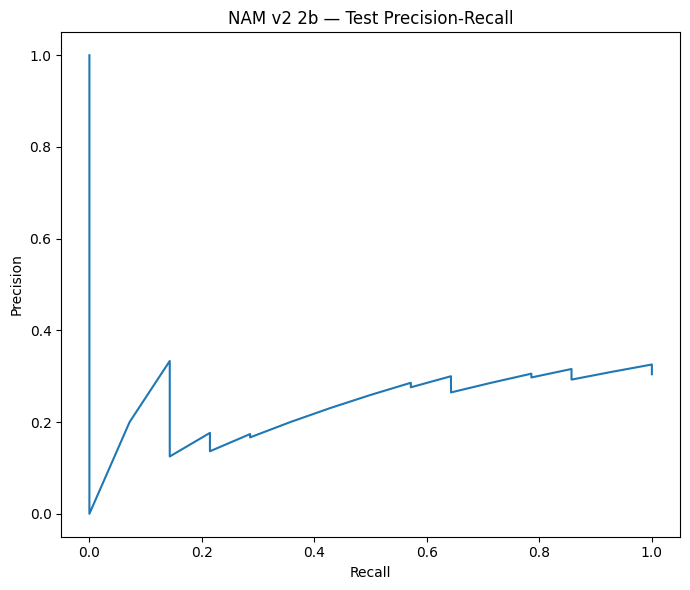

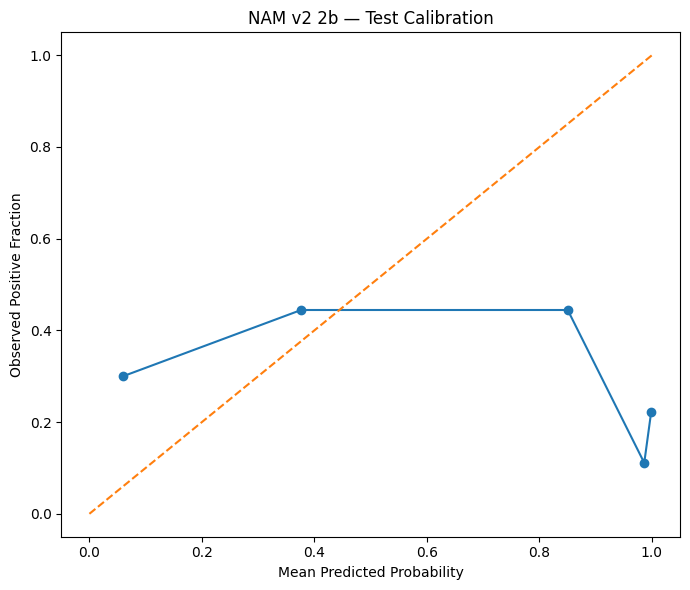


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
20,speech__std_f2_loc,speech,1.109569,-0.066520,1.004923
18,speech__std_b1_loc,speech,1.104544,-0.049406,1.234972
0,speech__speaking_rate,speech,1.031125,0.117942,1.707918
24,speech__spectral_std_dev,speech,0.785748,0.216551,-0.971046
2,speech__phonation_ratio,speech,0.740636,0.106665,1.037131
13,speech__cepstral_peak_prominence_mean,speech,0.712542,0.022766,-0.655735
6,speech__mean_intensity_db,speech,0.676040,0.098303,0.661652
15,speech__mean_f1_loc,speech,0.663796,-0.125794,0.404748
21,speech__mean_b2_loc,speech,0.640511,0.007421,-0.794821
23,speech__spectral_gravity,speech,0.605754,-0.036427,1.032733



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


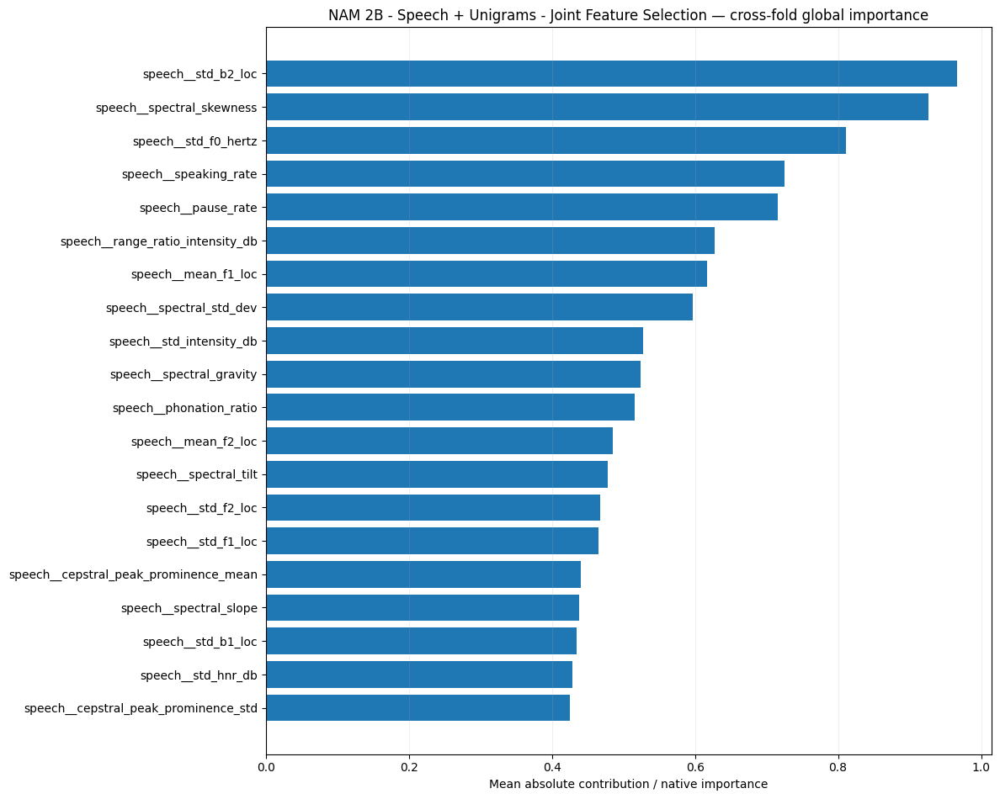


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
18,speech__std_b2_loc,2,0.898349,NaN,0.609470,0.757718,-1.633501,2.377967
14,speech__spectral_slope,2,0.878183,NaN,0.210533,0.982935,-2.252661,2.238711
5,speech__mean_f2_loc,2,0.728214,NaN,0.298115,1.019841,-2.157444,2.188417
16,speech__spectral_tilt,3,0.689723,0.218729,0.355171,0.684072,-2.126365,2.192738
2,speech__cepstral_peak_prominence_std,4,0.462596,0.140988,0.415329,0.843240,-1.879563,2.014362
4,speech__mean_b2_loc,2,0.319185,NaN,0.364666,1.150869,-1.558465,2.907931
17,speech__std_b1_loc,2,0.242788,NaN,0.502797,1.008714,-1.598414,2.341442
8,speech__mean_pause_duration,2,0.208285,NaN,0.353015,0.661253,-1.180979,2.889393
1,speech__cepstral_peak_prominence_mean,3,0.149752,0.356531,0.510493,0.900051,-2.021945,1.970126
11,speech__range_ratio_intensity_db,4,0.067506,0.571050,0.758455,0.994467,-1.038354,0.854829


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_2B_-_Speech_Unigrams_-_Joint_Feature_Selection.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 2b (corresponds to DNAMite 2b)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_2b_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2b",
    dnamite_experiment_id="2b",
    experiment_name='NAM 2B - Speech + Unigrams - Joint Feature Selection',
    task="classification",
    cv_results=experiment_2b_classification_cv,
    final_result=experiment_2b_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2b",
    )
] = NAM_v2_2b_report


In [ ]:
# Delete the final trained NAM
del experiment_2b_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 2b complete. "
    "Waiting for file writes..."
)

time.sleep(30)

print(
    "Disconnecting runtime."
)

runtime.unassign()

### Experiment 2c Speech + Unigram Classification with BCE

In [ ]:
NAM_PARAM_GRID = {
    "learning_rate": [
        1e-3,
        5e-4,
    ],
    "num_units": [
        16,
    ],
    "dropout": [
        0.25,
    ],
    "feature_dropout": [
        0.0,
    ],
    "shallow": [
        True,
    ],
    "activation": [
        "exu",
    ],
}

NAM_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        NAM_PARAM_GRID
    )
)

In [ ]:
experiment_2c_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2C - "
            "Speech + Unigrams - "
            "Weighted BCE"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)


NAM 2C - Speech + Unigrams - Weighted BCE
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 14 TF-IDF features for classification / unigram using C=5.0


[codecarbon WARNING @ 02:51:16] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.72, 1: 1.6363636363636365}


Epochs ran=31; best epoch=2; best val_loss=0.936487; hit ceiling=False
RAM memory:
  start: 1371.0078125 MB
  absolute peak: 2720.09765625 MB
  incremental peak: 1349.08984375 MB
GPU memory:
  start: 0.0 MB
  end: 0.083984375 MB
  absolute peak: 0.1279296875 MB
  incremental peak: 0.1279296875 MB
Selected 15 TF-IDF features for classification / unigram using C=5.0
GPU memory at training start: 0.04296875 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.7058823529411765, 1: 1.7142857142857142}
Epochs ran=500; best epoch=500; best val_loss=1.474447; hit ceiling=True
RAM memory:
  start: 2368.5703125 MB
  absolute peak: 3225.4765625 MB
  incremental peak: 856.90625 MB
GPU memory:
  start: 0.04296875 MB
  end: 0.361572265625 MB
  absolute peak: 0.4033203125 MB
  incremental peak: 0.3603515625 MB
Selected 1 TF-IDF features for classification / unigram using C=2.5
GPU memory at training start: 0.319580078125 MB
Weighted BCE: positive multiplier=1.0 class weights= {0: 0.705882352

In [ ]:
experiment_2c_classification_summary = (
    summarize_nested_cv(
        experiment_2c_classification_cv
    )
)

display(
    experiment_2c_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.444444           0.424342  0.285714   0.230769   
1           2  0.629630           0.519737  0.285714   0.333333   
2           3  0.666667           0.473684  0.000000   0.000000   
3           4  0.703704           0.608553  0.428571   0.500000   
4           5  0.296296           0.246711  0.095238   0.076923   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.375     0.473684  0.427632  0.367487                    1   
1               0.250     0.789474  0.361842  0.276640                    2   
2               0.000     0.947368  0.414474  0.292775                    3   
3               0.375     0.842105  0.657895  0.494932                    2   
4               0.125     0.368421  0.282895  0.231779                    1   

  joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                 None         500         500        

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.444444,0.424342,0.285714,0.230769,0.375,0.473684,0.427632,0.367487,1,None,500,500,True
1,2,0.629630,0.519737,0.285714,0.333333,0.250,0.789474,0.361842,0.276640,2,None,328,329,False
2,3,0.666667,0.473684,0.000000,0.000000,0.000,0.947368,0.414474,0.292775,3,None,500,500,True
3,4,0.703704,0.608553,0.428571,0.500000,0.375,0.842105,0.657895,0.494932,2,None,497,500,True
4,5,0.296296,0.246711,0.095238,0.076923,0.125,0.368421,0.282895,0.231779,1,None,500,500,True


In [ ]:
for result in experiment_2c_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 8, 'shallow': True, 'positive_class_multiplier': 1.5}

Outer Fold 2
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 8, 'shallow': True, 'positive_class_multiplier': 2.0}

Outer Fold 3
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 16, 'shallow': True, 'positive_class_multiplier': 1.5}

Outer Fold 4
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True, 'positive_class_multiplier': 2.0}

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 16, 'shallow': True, 'positive_class_multiplier': 2.0}



In [ ]:
for result in experiment_2c_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

Outer Fold 1: 1 selected unigrams
Outer Fold 2: 2 selected unigrams
Outer Fold 3: 3 selected unigrams
Outer Fold 4: 2 selected unigrams
Outer Fold 5: 1 selected unigrams


In [ ]:
experiment_2c_best_parameters = (
    choose_final_parameters(
        experiment_2c_classification_cv
    )
)

print(
    "Experiment 2C best parameters:"
)

print(
    experiment_2c_best_parameters
)

Experiment 2C best parameters:
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 8, 'positive_class_multiplier': 1.5, 'shallow': True}


In [ ]:
experiment_2c_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_2c_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

Selected 1 TF-IDF features for classification / unigram using C=2.5
GPU memory at training start: 53.281982421875 MB
Weighted BCE: positive multiplier=1.5 class weights= {0: 0.7105263157894737, 1: 2.53125}
Epochs ran=31; best epoch=1; best val_loss=0.949626; hit ceiling=False
RAM memory:
  start: 78522.828125 MB
  absolute peak: 78577.47265625 MB
  incremental peak: 54.64453125 MB
GPU memory:
  start: 53.281982421875 MB
  end: 53.340576171875 MB
  absolute peak: 53.37158203125 MB
  incremental peak: 0.089599609375 MB
Best training epoch from internal validation: 1
Internal run epochs: 31 hit ceiling: False
Selected 4 TF-IDF features for classification / unigram using C=2.5
Final Weighted-BCE class weights: {0: 0.7105263157894737, 1: 2.53125}
RAM memory:
  start: 78527.82421875 MB
  absolute peak: 78896.890625 MB
  incremental peak: 369.06640625 MB

FINAL TEST METRICS
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.5848214285714286), 'f1': 0.5, 'precision': 0.35294117

In [ ]:
experiment_2c_classification_final[
    "metrics"
]

{'accuracy': 0.4782608695652174,
 'balanced_accuracy': np.float64(0.5848214285714286),
 'f1': 0.5,
 'precision': 0.35294117647058826,
 'recall_sensitivity': 0.8571428571428571,
 'specificity': 0.3125,
 'roc_auc': np.float64(0.5959821428571428),
 'pr_auc': np.float64(0.3814838736772882)}

In [ ]:
experiment_2c_classification_final[
    "parameters"
]

{'activation': 'exu',
 'dropout': 0.1,
 'feature_dropout': 0.0,
 'learning_rate': 0.0005,
 'num_units': 8,
 'positive_class_multiplier': 1.5,
 'shallow': True}

#### NAM v2 Experiment 2c — DNAMite-parity outputs (maps to DNAMite 2e)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 2c — NAM 2C - Speech + Unigrams - Weighted BCE
DNAMite reference experiment: 2e

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.444444,0.424342,0.285714,0.230769,0.375,0.473684,0.427632,0.367487,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,500,500,True
1,2,0.629630,0.519737,0.285714,0.333333,0.250,0.789474,0.361842,0.276640,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,None,328,329,False
2,3,0.666667,0.473684,0.000000,0.000000,0.000,0.947368,0.414474,0.292775,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",3,None,500,500,True
3,4,0.703704,0.608553,0.428571,0.500000,0.375,0.842105,0.657895,0.494932,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",2,None,497,500,True
4,5,0.296296,0.246711,0.095238,0.076923,0.125,0.368421,0.282895,0.231779,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",1,None,500,500,True



CV Mean ± SD


,mean,sd
accuracy,0.548148,0.172531
balanced_accuracy,0.454605,0.134575
f1,0.219048,0.170367
precision,0.228205,0.199934
recall_sensitivity,0.225000,0.162980
specificity,0.684211,0.249653
roc_auc,0.428947,0.140056
pr_auc,0.332723,0.103018
selected_text_count,1.800000,0.836660
best_epoch,465.000000,76.596345



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,1,115.198324,17756.644531,18051.417969,294.773438,0.324951,NaN,10.348145,10.642334,10.673096,tensorflow,697,0.237747
1,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,2,97.794731,30067.742188,30335.367188,267.625000,0.169922,NaN,20.503418,20.641357,20.673340,tensorflow,721,0.245377
2,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,3,124.050153,47702.347656,48053.109375,350.761719,0.333252,NaN,30.707520,31.004639,31.040771,tensorflow,1489,0.254959
3,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,4,124.457110,63203.343750,63616.050781,412.707031,0.294922,NaN,42.067871,42.318848,42.362793,tensorflow,1441,0.247330
4,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,5,124.305020,78254.230469,78466.402344,212.171875,0.330078,NaN,53.017090,53.310303,53.347168,tensorflow,1393,0.239700



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,1,0.003656,0.000978
1,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,2,0.003095,0.000828
2,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,3,0.003937,0.001054
3,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,4,0.003960,0.001060
4,NAM v2,NAM 2C - Speech + Unigrams - Weighted BCE,classification,5,0.003942,0.001055



Final Test Metrics
{'accuracy': 0.4782608695652174, 'balanced_accuracy': np.float64(0.5848214285714286), 'f1': 0.5, 'precision': 0.35294117647058826, 'recall_sensitivity': 0.8571428571428571, 'specificity': 0.3125, 'roc_auc': np.float64(0.5959821428571428), 'pr_auc': np.float64(0.3814838736772882)}

Final Model Resource Summary
{'train_seconds': 50.242585137995775, 'start_ram_mb': 78527.82421875, 'peak_ram_mb': 78896.890625, 'incremental_peak_ram_mb': 369.06640625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.0015913811954177334, 'training_co2_kg': 0.0004258886182800847}


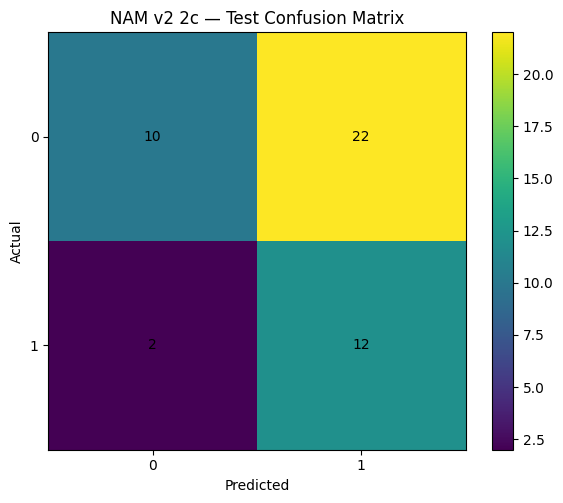

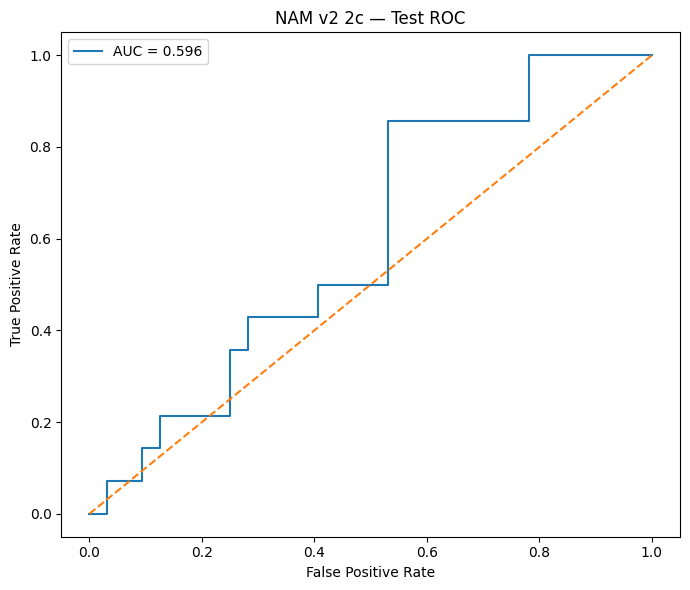

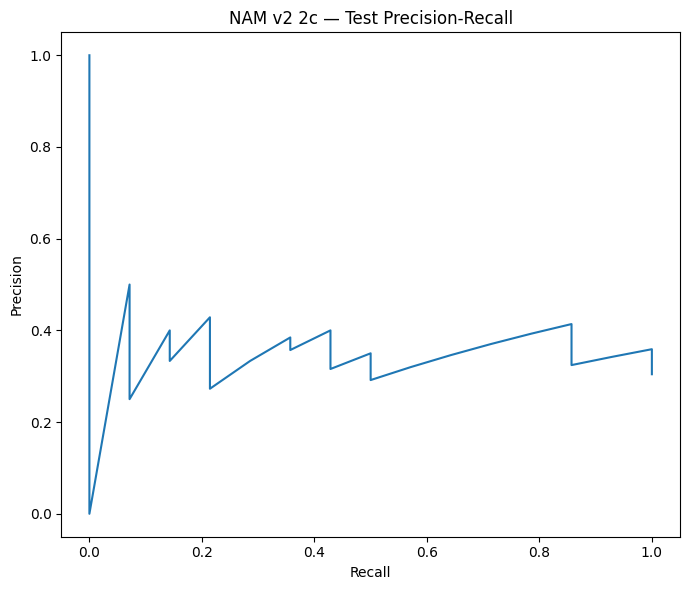

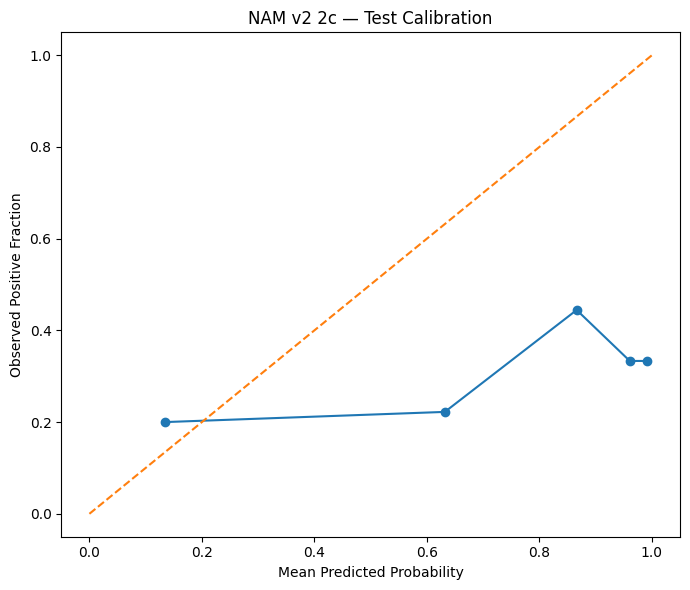


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
11,speech__std_hnr_db,speech,1.040066,-0.169664,0.821393
17,speech__std_f1_loc,speech,0.754430,-0.092167,0.851433
10,speech__mean_hnr_db,speech,0.740698,-0.015010,-0.662086
6,speech__std_f0_hertz,speech,0.739273,0.051013,0.916676
21,speech__std_f2_loc,speech,0.667435,0.024842,-1.199243
16,speech__mean_f1_loc,speech,0.646728,-0.129389,0.630496
25,speech__spectral_std_dev,speech,0.646450,-0.157286,0.305747
27,speech__spectral_kurtosis,speech,0.579937,0.123162,0.616250
5,speech__mean_f0_hertz,speech,0.464495,-0.056951,-0.244111
1,speech__articulation_rate,speech,0.462609,0.173341,0.504100



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_2C_-_Speech_Unigrams_-_Weighted_BCE
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


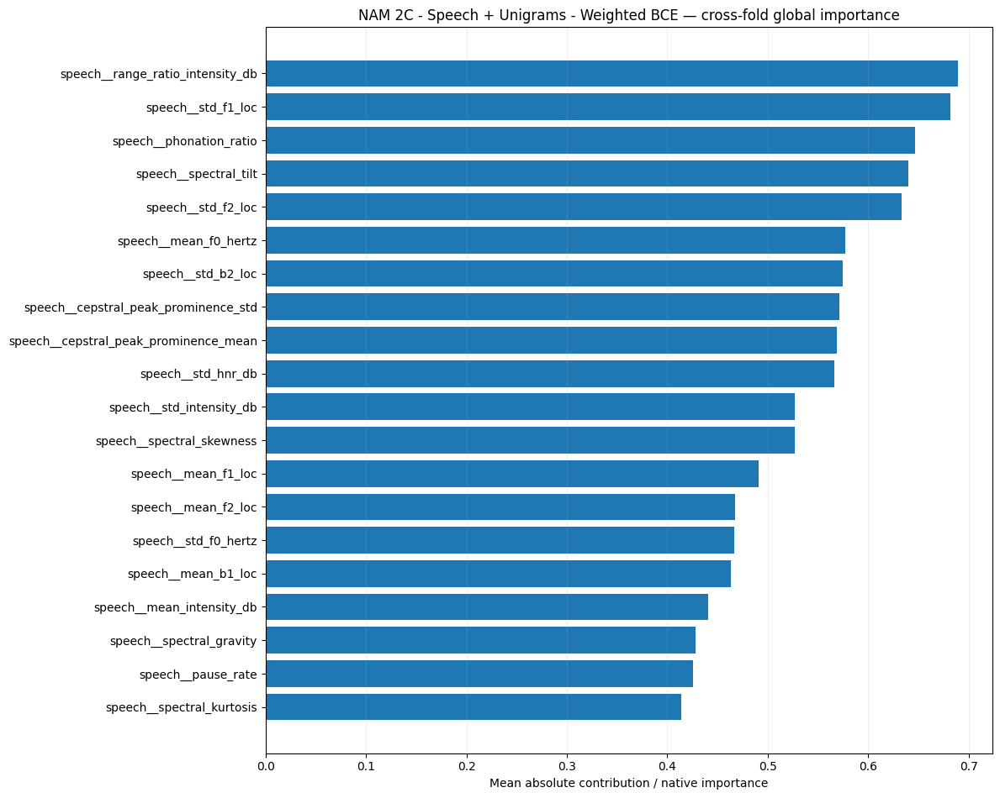


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
18,speech__spectral_slope,5,0.700015,0.202181,0.289626,0.490329,-2.240396,1.817583
16,speech__spectral_kurtosis,5,0.581781,0.241111,0.312338,0.537704,-1.317572,2.944199
11,speech__pause_rate,5,0.433176,0.396711,0.384245,0.582268,-1.768064,1.710399
21,speech__std_b1_loc,5,0.356323,0.362508,0.355398,0.746759,-1.540199,2.315497
17,speech__spectral_skewness,5,0.178464,0.825278,0.659470,0.959284,-1.809054,2.054626
14,speech__speaking_rate,5,0.151166,0.411101,0.363808,0.613034,-2.195560,1.598015
24,speech__std_f1_loc,5,0.119638,0.700575,0.830956,1.186346,-1.898396,2.051157
10,speech__mean_pause_duration,5,0.089887,0.321426,0.405385,0.645149,-1.180979,2.695285
22,speech__std_b2_loc,5,0.087081,0.762456,0.678735,1.156071,-1.488311,2.377967
4,speech__mean_b2_loc,5,0.062476,0.498096,0.488344,0.664766,-1.518951,2.798539


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_2C_-_Speech_Unigrams_-_Weighted_BCE.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 2c (corresponds to DNAMite 2e)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_2c_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2c",
    dnamite_experiment_id="2e",
    experiment_name='NAM 2C - Speech + Unigrams - Weighted BCE',
    task="classification",
    cv_results=experiment_2c_classification_cv,
    final_result=experiment_2c_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2c",
    )
] = NAM_v2_2c_report


In [ ]:
# Delete the final trained NAM
del experiment_2c_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 2c complete. "
    "Waiting for file writes..."
)

time.sleep(30)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 2c complete. Waiting for file writes...
Disconnecting runtime.


### Experiment 2d Speech + Unigram Regression

In [ ]:
NAM_PARAM_GRID = {
    "learning_rate": [
        1e-3,
        5e-4,
    ],
    "num_units": [
        8,
    ],
    "dropout": [
        0.25,
    ],
    "feature_dropout": [
        0.0,
    ],
    "shallow": [
        True,
    ],
    "activation": [
        "exu",
    ],
}

NAM_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        NAM_PARAM_GRID
    )
)

In [ ]:
experiment_2d_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2D - "
            "Speech + Unigrams - "
            "Regression Baseline"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

In [ ]:
experiment_2d_regression_summary = (
    summarize_nested_cv(
        experiment_2d_regression_cv
    )
)

display(
    experiment_2d_regression_summary
)

In [ ]:
for result in experiment_2d_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

In [ ]:
for result in experiment_2d_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

In [ ]:
experiment_2d_best_parameters = (
    choose_final_parameters(
        experiment_2d_regression_cv
    )
)

print(
    "Experiment 2D best parameters:"
)

print(
    experiment_2d_best_parameters
)

In [ ]:
experiment_2d_regression_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_2d_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

In [ ]:
experiment_2d_regression_final[
    "metrics"
]

In [ ]:
experiment_2d_regression_final[
    "parameters"
]

In [ ]:
experiment_2d_regression_final[
    "best_epoch"
]

In [ ]:
selected_text_indices = (
    experiment_2d_regression_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

#### NAM v2 Experiment 2d — DNAMite-parity outputs (maps to DNAMite 2c)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 2d (corresponds to DNAMite 2c)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_2d_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2d",
    dnamite_experiment_id="2c",
    experiment_name='NAM 2D - Speech + Unigrams - Regression Baseline',
    task="regression",
    cv_results=experiment_2d_regression_cv,
    final_result=experiment_2d_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2d",
    )
] = NAM_v2_2d_report


In [ ]:
# Delete the final trained NAM
del experiment_2d_regression_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 2e Speech + Unigram Regression with Feature Selection

In [ ]:
experiment_2e_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2E - "
            "Speech + Unigrams - "
            "Joint Feature Selection"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

In [ ]:
experiment_2e_regression_summary = (
    summarize_nested_cv(
        experiment_2e_regression_cv
    )
)

display(
    experiment_2e_regression_summary
)

In [ ]:
for result in experiment_2e_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

In [ ]:
for result in experiment_2e_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        "Selected unigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

In [ ]:
experiment_2e_best_parameters = (
    choose_final_parameters(
        experiment_2e_regression_cv
    )
)

print(
    "Experiment 2E best parameters:"
)

print(
    experiment_2e_best_parameters
)

In [ ]:
experiment_2e_regression_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_2e_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

In [ ]:
experiment_2e_regression_final[
    "metrics"
]

In [ ]:
experiment_2e_regression_final[
    "parameters"
]

In [ ]:
# Number of first stage selected unigrams

selected_text_indices = (
    experiment_2e_regression_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

In [ ]:
# Number of final jointly selected features

joint_selected_indices = (
    experiment_2e_regression_final[
        "joint_selected_indices"
    ]
)

print(
    "Final jointly selected features:",
    len(
        joint_selected_indices
    )
)

#### NAM v2 Experiment 2e — DNAMite-parity outputs (maps to DNAMite 2d)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 2e (corresponds to DNAMite 2d)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_2e_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2e",
    dnamite_experiment_id="2d",
    experiment_name='NAM 2E - Speech + Unigrams - Joint Feature Selection',
    task="regression",
    cv_results=experiment_2e_regression_cv,
    final_result=experiment_2e_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2e",
    )
] = NAM_v2_2e_report


In [ ]:
# Delete the final trained NAM
del experiment_2e_regression_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 2f Speech + Unigram Regression with LDS

In [ ]:
experiment_2f_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 2F - "
            "Speech + Unigrams - LDS"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

In [ ]:
experiment_2f_regression_summary = (
    summarize_nested_cv(
        experiment_2f_regression_cv
    )
)

display(
    experiment_2f_regression_summary
)

In [ ]:
for result in experiment_2f_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print()

In [ ]:
for result in experiment_2f_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}: "
        f"{result['selected_text_count']} "
        "selected unigrams"
    )

In [ ]:
experiment_2f_best_parameters = (
    choose_final_parameters(
        experiment_2f_regression_cv
    )
)

print(
    "Experiment 2F best parameters:"
)

print(
    experiment_2f_best_parameters
)

In [ ]:
experiment_2f_regression_final = (
    train_final_nam_model(
        task="regression",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_regression_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_regression_test
        ),

        parameters=(
            experiment_2f_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram"
        ),
    )
)

In [ ]:
experiment_2f_regression_final[
    "metrics"
]

In [ ]:
experiment_2f_regression_final[
    "parameters"
]

In [ ]:
selected_text_indices = (
    experiment_2f_regression_final[
        "selected_text_indices"
    ]
)

print(
    "Selected unigrams:",
    len(
        selected_text_indices
    )
)

#### NAM v2 Experiment 2f — DNAMite-parity outputs (maps to DNAMite 2f)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 2f (corresponds to DNAMite 2f)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_2f_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="2f",
    dnamite_experiment_id="2f",
    experiment_name='NAM 2F - Speech + Unigrams - LDS',
    task="regression",
    cv_results=experiment_2f_regression_cv,
    final_result=experiment_2f_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_data["X_test"],
    text_representation="unigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "2f",
    )
] = NAM_v2_2f_report


In [ ]:
# Delete the final trained NAM
del experiment_2f_regression_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

## Experiment 3 -- Speech + Unigram/Bigram

In [ ]:
text_matrix=(
    unigram_bigram_data[
        "X_development"
    ]
),

text_representation=(
    "unigram_bigram"
),

### Experiment 3a Speech + Unigram/Bigram Classification

In [ ]:
experiment_3a_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3A - "
            "Speech + Unigrams/Bigrams - "
            "Baseline"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)


NAM 3A - Speech + Unigrams/Bigrams - Baseline
Saved/reused master outer folds: /content/drive/MyDrive/Thesis/Model_Comparison_Results/master_folds/classification_135_6bcca75438aa.npz

Outer Fold 1/5
Selected 10 TF-IDF features for classification / unigram_bigram using C=5.0


[codecarbon WARNING @ 01:58:48] Multiple instances of codecarbon are allowed to run at the same time.


GPU memory at training start: 0.0 MB


Epochs ran=31; best epoch=1; best val_loss=1.350117; hit ceiling=False
RAM memory:
  start: 1538.8515625 MB
  absolute peak: 2600.484375 MB
  incremental peak: 1061.6328125 MB
GPU memory:
  start: 0.0 MB
  end: 0.0771484375 MB
  absolute peak: 0.116943359375 MB
  incremental peak: 0.116943359375 MB
Selected 8 TF-IDF features for classification / unigram_bigram using C=5.0
GPU memory at training start: 0.0400390625 MB
Epochs ran=500; best epoch=500; best val_loss=1.437368; hit ceiling=True
RAM memory:
  start: 2607.296875 MB
  absolute peak: 2975.4921875 MB
  incremental peak: 368.1953125 MB
GPU memory:
  start: 0.0400390625 MB
  end: 0.3466796875 MB
  absolute peak: 0.38134765625 MB
  incremental peak: 0.34130859375 MB
Selected 9 TF-IDF features for classification / unigram_bigram using C=5.0
GPU memory at training start: 0.3115234375 MB
Epochs ran=500; best epoch=500; best val_loss=1.571747; hit ceiling=True
RAM memory:
  start: 2976.56640625 MB
  absolute peak: 3421.14453125 MB
  inc

In [ ]:
experiment_3a_classification_summary = (
    summarize_nested_cv(
        experiment_3a_classification_cv
    )
)

display(
    experiment_3a_classification_summary
)

   outer_fold  accuracy  balanced_accuracy        f1  precision  \
0           1  0.333333           0.453947  0.400000   0.272727   
1           2  0.629630           0.483553  0.166667   0.250000   
2           3  0.703704           0.500000  0.000000   0.000000   
3           4  0.518519           0.440789  0.235294   0.222222   
4           5  0.666667           0.473684  0.000000   0.000000   

   recall_sensitivity  specificity   roc_auc    pr_auc  selected_text_count  \
0               0.750     0.157895  0.486842  0.340305                   17   
1               0.125     0.842105  0.434211  0.373040                   17   
2               0.000     1.000000  0.572368  0.363624                   20   
3               0.250     0.631579  0.519737  0.326260                   19   
4               0.000     0.947368  0.315789  0.254578                   17   

  joint_selected_count  best_epoch  epochs_ran  hit_epoch_ceiling  
0                 None         500         500        

,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.333333,0.453947,0.400000,0.272727,0.750,0.157895,0.486842,0.340305,17,None,500,500,True
1,2,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.434211,0.373040,17,None,1,31,False
2,3,0.703704,0.500000,0.000000,0.000000,0.000,1.000000,0.572368,0.363624,20,None,500,500,True
3,4,0.518519,0.440789,0.235294,0.222222,0.250,0.631579,0.519737,0.326260,19,None,221,244,False
4,5,0.666667,0.473684,0.000000,0.000000,0.000,0.947368,0.315789,0.254578,17,None,500,500,True


In [ ]:
for result in experiment_3a_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

Outer Fold 1
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 8, 'shallow': True}
Selected text features: 17

Outer Fold 2
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True}
Selected text features: 17

Outer Fold 3
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True}
Selected text features: 20

Outer Fold 4
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True}
Selected text features: 19

Outer Fold 5
{'activation': 'exu', 'dropout': 0.1, 'feature_dropout': 0.0, 'learning_rate': 0.0005, 'num_units': 16, 'shallow': True}
Selected text features: 17



In [ ]:
experiment_3a_best_parameters = (
    choose_final_parameters(
        experiment_3a_classification_cv
    )
)

print(
    "Experiment 3A best parameters:"
)

print(
    experiment_3a_best_parameters
)

Experiment 3A best parameters:
{'activation': 'exu', 'dropout': 0.25, 'feature_dropout': 0.0, 'learning_rate': 0.001, 'num_units': 16, 'shallow': True}


In [ ]:
experiment_3a_classification_final = (
    train_final_nam_model(
        task="classification",

        speech_development=(
            development_speech
        ),

        y_development=(
            y_binary_development
        ),

        speech_test=(
            test_speech
        ),

        y_test=(
            y_binary_test
        ),

        parameters=(
            experiment_3a_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

Selected 17 TF-IDF features for classification / unigram_bigram using C=5.0
GPU memory at training start: 42.7666015625 MB
Epochs ran=500; best epoch=500; best val_loss=1.555314; hit ceiling=True
RAM memory:
  start: 64031.0078125 MB
  absolute peak: 64308.51171875 MB
  incremental peak: 277.50390625 MB
GPU memory:
  start: 42.7666015625 MB
  end: 43.07421875 MB
  absolute peak: 43.12353515625 MB
  incremental peak: 0.35693359375 MB
Best training epoch from internal validation: 500
Internal run epochs: 500 hit ceiling: True
Selected 28 TF-IDF features for classification / unigram_bigram using C=5.0
RAM memory:
  start: 64257.74609375 MB
  absolute peak: 65041.03125 MB
  incremental peak: 783.28515625 MB

FINAL TEST METRICS
{'accuracy': 0.6086956521739131, 'balanced_accuracy': np.float64(0.4776785714285714), 'f1': 0.18181818181818182, 'precision': 0.25, 'recall_sensitivity': 0.14285714285714285, 'specificity': 0.8125, 'roc_auc': np.float64(0.5825892857142858), 'pr_auc': np.float64(0.375

In [ ]:
experiment_3a_classification_final[
    "metrics"
]

{'accuracy': 0.6086956521739131,
 'balanced_accuracy': np.float64(0.4776785714285714),
 'f1': 0.18181818181818182,
 'precision': 0.25,
 'recall_sensitivity': 0.14285714285714285,
 'specificity': 0.8125,
 'roc_auc': np.float64(0.5825892857142858),
 'pr_auc': np.float64(0.3757963433751593)}

In [ ]:
experiment_3a_classification_final[
    "best_epoch"
]

500

In [ ]:
experiment_3a_classification_final[
    "model"
].summary()

Model: "nam"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 1 (4.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4 (20.00 B)

#### NAM v2 Experiment 3a — DNAMite-parity outputs (maps to DNAMite 3a)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.



NAM v2 — 3a — NAM 3A - Speech + Unigrams/Bigrams - Baseline
DNAMite reference experiment: 3a

CV Results


,outer_fold,accuracy,balanced_accuracy,f1,precision,recall_sensitivity,specificity,roc_auc,pr_auc,selected_parameters_json,selected_text_count,joint_selected_count,best_epoch,epochs_ran,hit_epoch_ceiling
0,1,0.333333,0.453947,0.400000,0.272727,0.750,0.157895,0.486842,0.340305,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,500,500,True
1,2,0.629630,0.483553,0.166667,0.250000,0.125,0.842105,0.434211,0.373040,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",17,None,1,31,False
2,3,0.703704,0.500000,0.000000,0.000000,0.000,1.000000,0.572368,0.363624,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",20,None,500,500,True
3,4,0.518519,0.440789,0.235294,0.222222,0.250,0.631579,0.519737,0.326260,"{""activation"": ""exu"", ""dropout"": 0.25, ""featur...",19,None,221,244,False
4,5,0.666667,0.473684,0.000000,0.000000,0.000,0.947368,0.315789,0.254578,"{""activation"": ""exu"", ""dropout"": 0.1, ""feature...",17,None,500,500,True



CV Mean ± SD


,mean,sd
accuracy,0.570370,0.149531
balanced_accuracy,0.470395,0.023492
f1,0.160392,0.169199
precision,0.148990,0.137180
recall_sensitivity,0.225000,0.311247
specificity,0.715789,0.342308
roc_auc,0.465789,0.097737
pr_auc,0.331562,0.046850
selected_text_count,18.000000,1.414214
best_epoch,344.400000,226.817768



Selected Hyperparameters Across Outer Folds


...


Resources


,model_family,experiment_name,task,outer_fold,train_seconds,start_ram_mb,peak_ram_mb,incremental_peak_ram_mb,peak_gpu_memory_mb,peak_gpu_reserved_mb,start_gpu_memory_mb,end_gpu_memory_mb,absolute_peak_gpu_memory_mb,resource_framework,parameter_count,model_size_mb
0,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,1,145.783223,14355.410156,15035.050781,679.640625,0.367188,NaN,7.991455,8.313477,8.358643,tensorflow,1081,0.367599
1,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,2,86.623238,26710.484375,27088.105469,377.621094,0.135498,NaN,16.333496,16.419434,16.468994,tensorflow,2161,0.371506
2,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,3,153.993962,39267.425781,39994.628906,727.203125,0.379639,NaN,24.962891,25.290039,25.342529,tensorflow,2305,0.394394
3,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,4,121.247137,51647.886719,52335.468750,687.582031,0.216797,NaN,33.988037,34.153076,34.204834,tensorflow,2257,0.386765
4,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,5,150.689135,63464.894531,64033.585938,568.691406,0.370361,NaN,42.489502,42.810547,42.859863,tensorflow,2161,0.371506



Energy


,model_family,experiment_name,task,outer_fold,training_energy_kwh,training_co2_kg
0,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,1,0.004707,0.001260
1,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,2,0.002786,0.000746
2,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,3,0.004959,0.001327
3,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,4,0.003900,0.001044
4,NAM v2,NAM 3A - Speech + Unigrams/Bigrams - Baseline,classification,5,0.004858,0.001300



Final Test Metrics
{'accuracy': 0.6086956521739131, 'balanced_accuracy': np.float64(0.4776785714285714), 'f1': 0.18181818181818182, 'precision': 0.25, 'recall_sensitivity': 0.14285714285714285, 'specificity': 0.8125, 'roc_auc': np.float64(0.5825892857142858), 'pr_auc': np.float64(0.3757963433751593)}

Final Model Resource Summary
{'train_seconds': 129.07047068099928, 'start_ram_mb': 64257.74609375, 'peak_ram_mb': 65041.03125, 'incremental_peak_ram_mb': 783.28515625, 'peak_gpu_memory_mb': 0.0, 'peak_gpu_reserved_mb': 0.0, 'start_gpu_memory_mb': 0.0, 'end_gpu_memory_mb': 0.0, 'absolute_peak_gpu_memory_mb': 0.0, 'resource_framework': 'pytorch'}

Final Model Energy Summary
{'training_energy_kwh': 0.004159069846499279, 'training_co2_kg': 0.0011130585904598302}


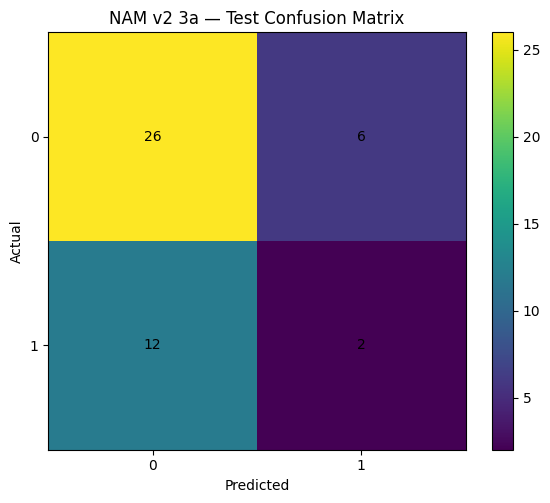

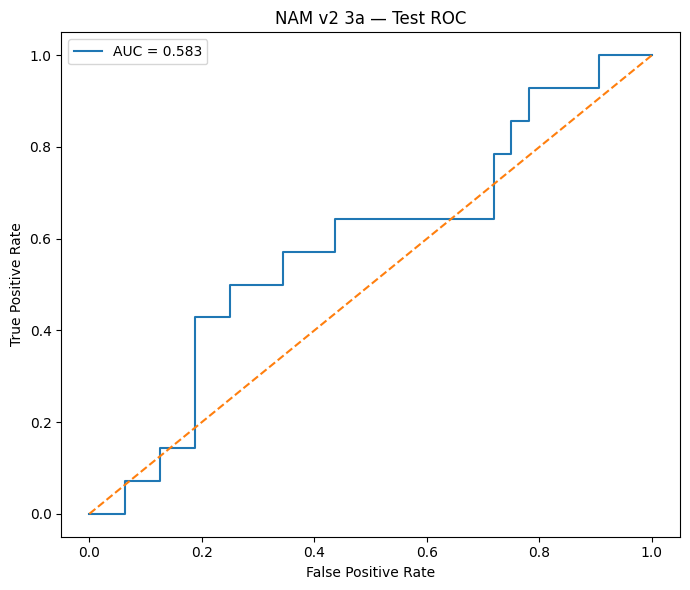

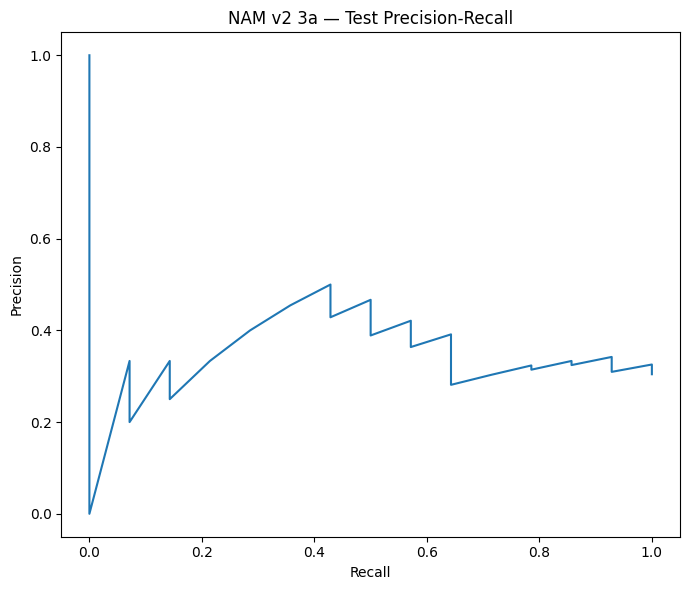

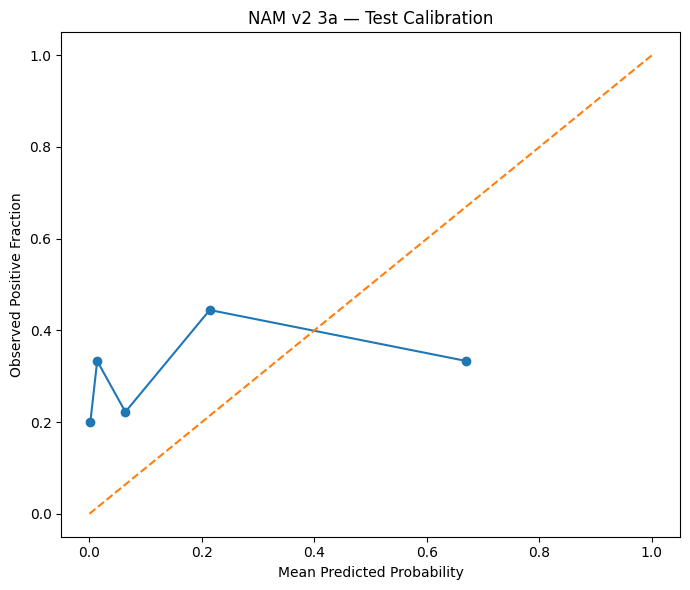


Final Model Feature Importance


,feature,modality,importance,mean_centered_contribution,mean_raw_feature_nn_output
19,speech__std_b1_loc,speech,1.414641,0.031139,-1.548225
5,speech__mean_f0_hertz,speech,0.960600,0.014346,0.824965
7,speech__mean_intensity_db,speech,0.843990,-0.017088,-0.927930
1,speech__articulation_rate,speech,0.808568,-0.179301,0.609688
25,speech__spectral_std_dev,speech,0.759316,-0.257282,1.007414
0,speech__speaking_rate,speech,0.727801,-0.040649,-0.835879
14,speech__cepstral_peak_prominence_mean,speech,0.701065,0.128230,-0.516481
9,speech__range_ratio_intensity_db,speech,0.659584,-0.236988,0.815134
13,speech__spectral_tilt,speech,0.547941,0.032949,-0.543170
24,speech__spectral_gravity,speech,0.525995,-0.061671,0.018755



--- Aggregating interpretability ---
Reading from: /content/drive/MyDrive/Thesis/Model_Comparison_Results/interpretability/NAM_v2/NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline
Experiment directory exists: True
Fold directories found: 5

 fold_01
  feature_importance.csv: True
  feature_curves.csv: True

 fold_02
  feature_importance.csv: True
  feature_curves.csv: True

 fold_03
  feature_importance.csv: True
  feature_curves.csv: True

 fold_04
  feature_importance.csv: True
  feature_curves.csv: True

 fold_05
  feature_importance.csv: True
  feature_curves.csv: True


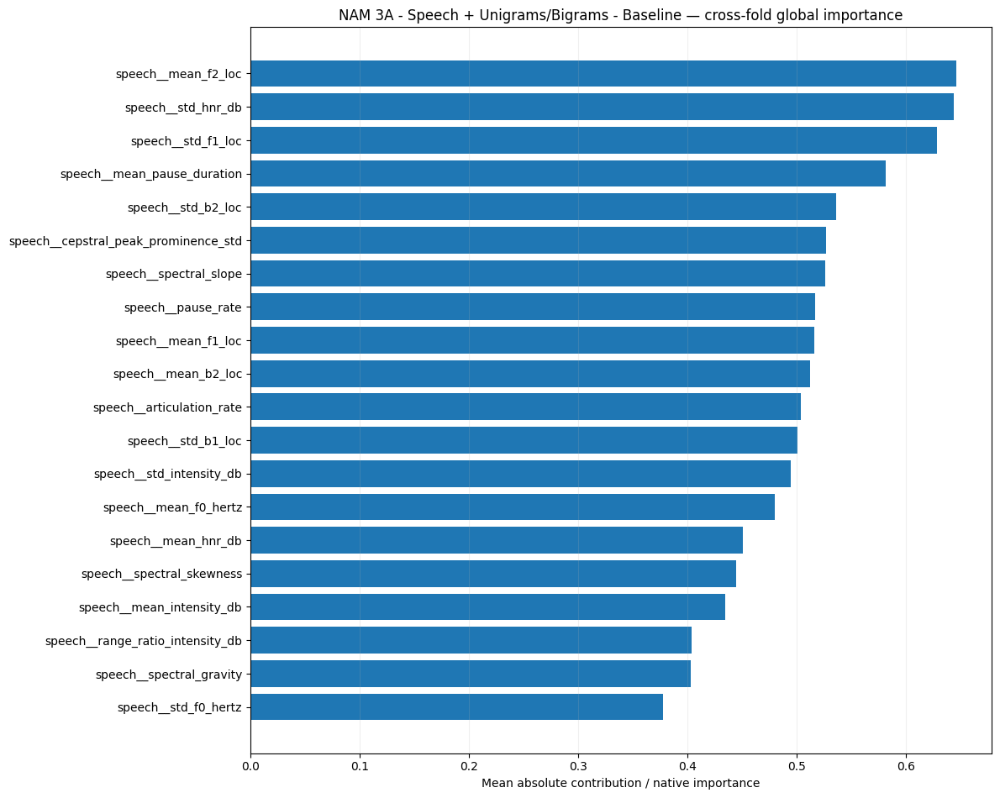

/tmp/ipykernel_2987/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2987/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2987/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2987/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2987/1559648166.py:694: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = spearmanr(matrix[a], matrix[b]).statistic
/tmp/ipykernel_2987/1559648166.py:694: ConstantInputWarning: An input array is consta


Google NAM Shape-Function Stability


,feature,n_folds,mean_pairwise_shape_spearman,sd_pairwise_shape_spearman,mean_pointwise_shape_sd,max_pointwise_shape_sd,overlap_min,overlap_max
33,text__help,2,0.475546,NaN,0.186349,0.378999,0.000000,0.058436
29,text__alright,2,0.418727,NaN,0.102478,0.197624,0.000000,0.123468
43,text__to uh,2,0.348493,NaN,0.165162,0.287760,0.000000,0.061432
41,text__they just,3,0.312534,NaN,0.071923,0.164885,0.000000,0.056212
17,speech__spectral_skewness,5,0.221096,0.656046,0.420500,0.598708,-1.809054,2.054626
31,text__diagnosed,3,0.192248,NaN,0.233381,0.359788,0.000000,0.056050
2,speech__cepstral_peak_prominence_std,5,0.165549,0.785556,0.591948,0.879258,-1.879563,2.014362
18,speech__spectral_slope,5,0.111655,0.475754,0.566414,0.871624,-2.240396,1.817583
40,text__therapist,5,0.085816,0.499707,0.042547,0.152868,0.000000,0.072054
0,speech__articulation_rate,5,0.056442,0.574019,1.096775,1.436150,-2.875069,1.011910


Saved: /content/drive/MyDrive/Thesis/Model_Comparison_Results/manifests/NAM_v2__NAM_3A_-_Speech_Unigrams_Bigrams_-_Baseline.json


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 3a (corresponds to DNAMite 3a)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_3a_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3a",
    dnamite_experiment_id="3a",
    experiment_name='NAM 3A - Speech + Unigrams/Bigrams - Baseline',
    task="classification",
    cv_results=experiment_3a_classification_cv,
    final_result=experiment_3a_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3a",
    )
] = NAM_v2_3a_report


In [ ]:
# Delete the final trained NAM
del experiment_3a_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

In [ ]:
import time
from google.colab import runtime

print(
    "Experiment 3a complete. "
    "Waiting for file writes..."
)

time.sleep(30)

print(
    "Disconnecting runtime."
)

runtime.unassign()

Experiment 3a complete. Waiting for file writes...
Disconnecting runtime.


### Experiment 3b Speech + Unigram/Bigram Classification with Feature Selection

In [ ]:
experiment_3b_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3B - "
            "Speech + Unigrams/Bigrams - "
            "Feature Selection"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3b_classification_summary = (
    summarize_nested_cv(
        experiment_3b_classification_cv
    )
)

display(
    experiment_3b_classification_summary
)

In [ ]:
for result in experiment_3b_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected unigram/bigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

In [ ]:
experiment_3b_best_parameters = (
    choose_final_parameters(
        experiment_3b_classification_cv
    )
)

print(
    experiment_3b_best_parameters
)

In [ ]:
experiment_3b_classification_final = (
    train_final_nam_model(
        task="classification",
        speech_development=development_speech,
        y_development=y_binary_development,
        speech_test=test_speech,
        y_test=y_binary_test,

        parameters=(
            experiment_3b_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3b_classification_final[
    "metrics"
]

In [ ]:
experiment_3b_classification_final[
    "model"
].summary()

In [ ]:
print(
    "Final jointly selected features:",
    len(
        experiment_3b_classification_final[
            "joint_selected_indices"
        ]
    )
)

In [ ]:
experiment_3b_classification_final.keys()

In [ ]:
unigram_bigram_data.keys()

In [ ]:
all_text_features = np.array(
    unigram_bigram_data[
        "vectorizer"
    ].get_feature_names_out()
)

selected_text_indices = (
    experiment_3b_classification_final[
        "selected_text_indices"
    ]
)

selected_text_features = (
    all_text_features[
        selected_text_indices
    ]
)

print(
    "Number selected:",
    len(selected_text_features)
)

selected_text_features

In [ ]:
import numpy as np
import pandas as pd


# ============================================================
# 1. Original unigram + bigram vocabulary
# ============================================================

all_text_features = np.array(
    unigram_bigram_data[
        "vectorizer"
    ].get_feature_names_out()
)


# ============================================================
# 2. Stage 1: text features selected before joint selection
# ============================================================

selected_text_indices = (
    experiment_3b_classification_final[
        "selected_text_indices"
    ]
)

selected_text_features = (
    all_text_features[
        selected_text_indices
    ]
)

print(
    "Stage-1 selected text features:",
    len(selected_text_features)
)


# ============================================================
# 3. Build feature names entering joint selection
# ============================================================

joint_input_feature_names = np.array(
    list(SPEECH_FEATURE_NAMES)
    + list(selected_text_features)
)


# ============================================================
# 4. Stage 2: final jointly selected features
# ============================================================

joint_selected_indices = (
    experiment_3b_classification_final[
        "joint_selected_indices"
    ]
)

final_selected_features = (
    joint_input_feature_names[
        joint_selected_indices
    ]
)

print(
    "Final jointly selected features:",
    len(final_selected_features)
)


# ============================================================
# 5. Categorize final features
# ============================================================

speech_feature_set = set(
    SPEECH_FEATURE_NAMES
)

rows = []

for feature in final_selected_features:

    if feature in speech_feature_set:
        feature_type = "Speech"

    elif " " in feature:
        feature_type = "Bigram"

    else:
        feature_type = "Unigram"

    rows.append(
        {
            "feature": feature,
            "type": feature_type,
        }
    )


final_feature_table = pd.DataFrame(
    rows
)

display(
    final_feature_table
)


# ============================================================
# 6. Summary counts
# ============================================================

print("\nFinal feature counts:")

print(
    final_feature_table[
        "type"
    ].value_counts()
)

In [ ]:
# Final selected unigrams

final_selected_unigrams = (
    final_feature_table[
        final_feature_table[
            "type"
        ] == "Unigram"
    ]
    .reset_index(
        drop=True
    )
)

display(
    final_selected_unigrams
)

In [ ]:
# Final selected bigrams

final_selected_bigrams = (
    final_feature_table[
        final_feature_table[
            "type"
        ] == "Bigram"
    ]
    .reset_index(
        drop=True
    )
)

display(
    final_selected_bigrams
)

In [ ]:
stage1_text_table = pd.DataFrame(
    {
        "feature": selected_text_features,
        "type": [
            (
                "Bigram"
                if " " in feature
                else "Unigram"
            )
            for feature
            in selected_text_features
        ],
    }
)

display(
    stage1_text_table
)

print(
    stage1_text_table[
        "type"
    ].value_counts()
)

#### NAM v2 Experiment 3b — DNAMite-parity outputs (maps to DNAMite 3b)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 3b (corresponds to DNAMite 3b)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_3b_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3b",
    dnamite_experiment_id="3b",
    experiment_name='NAM 3B - Speech + Unigrams/Bigrams - Feature Selection',
    task="classification",
    cv_results=experiment_3b_classification_cv,
    final_result=experiment_3b_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3b",
    )
] = NAM_v2_3b_report


In [ ]:
# Delete the final trained NAM
#del experiment_3b_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 3c Speech + Unigram/Bigram Classification with BCE

In [ ]:
NAM_PARAM_GRID = {
    "learning_rate": [
        1e-3,
        5e-4,
    ],
    "num_units": [
        8,
    ],
    "dropout": [
        0.25,
    ],
    "feature_dropout": [
        0.0,
    ],
    "shallow": [
        True,
    ],
    "activation": [
        "exu",
    ],
}

NAM_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        NAM_PARAM_GRID
    )
)

In [ ]:
experiment_3c_classification_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3C - "
            "Speech + Unigrams/Bigrams - "
            "BCE"
        ),

        task="classification",

        speech_features=(
            development_speech
        ),

        y=(
            y_binary_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3c_classification_summary = (
    summarize_nested_cv(
        experiment_3c_classification_cv
    )
)

display(
    experiment_3c_classification_summary
)

In [ ]:
for result in experiment_3c_classification_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

In [ ]:
experiment_3c_best_parameters = (
    choose_final_parameters(
        experiment_3c_classification_cv
    )
)

print(
    experiment_3c_best_parameters
)

In [ ]:
experiment_3c_classification_final = (
    train_final_nam_model(
        task="classification",
        speech_development=development_speech,
        y_development=y_binary_development,
        speech_test=test_speech,
        y_test=y_binary_test,

        parameters=(
            experiment_3c_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3c_classification_final[
    "metrics"
]

In [ ]:
experiment_3c_classification_final[
    "best_epoch"
]

In [ ]:
experiment_3c_classification_final[
    "model"
].summary()

#### NAM v2 Experiment 3c — DNAMite-parity outputs (maps to DNAMite 3e)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 3c (corresponds to DNAMite 3e)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_3c_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3c",
    dnamite_experiment_id="3e",
    experiment_name='NAM 3C - Speech + Unigrams/Bigrams - BCE',
    task="classification",
    cv_results=experiment_3c_classification_cv,
    final_result=experiment_3c_classification_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_binary_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3c",
    )
] = NAM_v2_3c_report


In [ ]:
# Delete the final trained NAM
del experiment_3c_classification_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 3d Speech + Unigram/Bigram Regression

In [ ]:
experiment_3d_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3D - "
            "Speech + Unigrams/Bigrams - "
            "Regression Baseline"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "baseline"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3d_regression_summary = (
    summarize_nested_cv(
        experiment_3d_regression_cv
    )
)

display(
    experiment_3d_regression_summary
)

In [ ]:
for result in experiment_3d_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

In [ ]:
experiment_3d_best_parameters = (
    choose_final_parameters(
        experiment_3d_regression_cv
    )
)

print(
    experiment_3d_best_parameters
)

In [ ]:
experiment_3d_regression_final = (
    train_final_nam_model(
        task="regression",
        speech_development=development_speech,
        y_development=y_regression_development,
        speech_test=test_speech,
        y_test=y_regression_test,

        parameters=(
            experiment_3d_best_parameters
        ),

        experiment_variant=(
            "baseline"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3d_regression_final[
    "metrics"
]

In [ ]:
experiment_3d_regression_final[
    "model"
].summary()

#### NAM v2 Experiment 3d — DNAMite-parity outputs (maps to DNAMite 3c)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 3d (corresponds to DNAMite 3c)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_3d_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3d",
    dnamite_experiment_id="3c",
    experiment_name='NAM 3D - Speech + Unigrams/Bigrams - Regression Baseline',
    task="regression",
    cv_results=experiment_3d_regression_cv,
    final_result=experiment_3d_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3d",
    )
] = NAM_v2_3d_report


In [ ]:
# Delete the final trained NAM
del experiment_3d_regression_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 3e Speech + Unigram/Bigram Regression with Feature Selection

In [ ]:
NAM_PARAM_GRID = {
    "learning_rate": [
        1e-3,
        5e-4,
    ],
    "num_units": [
        8,
    ],
    "dropout": [
        0.25,
    ],
    "feature_dropout": [
        0.0,
    ],
    "shallow": [
        True,
    ],
    "activation": [
        "exu",
    ],
}

NAM_PARAMETER_CANDIDATES = list(
    ParameterGrid(
        NAM_PARAM_GRID
    )
)

In [ ]:
experiment_3e_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3E - "
            "Speech + Unigrams/Bigrams - "
            "Feature Selection"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3e_regression_summary = (
    summarize_nested_cv(
        experiment_3e_regression_cv
    )
)

display(
    experiment_3e_regression_summary
)

In [ ]:
for result in experiment_3e_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected unigram/bigram features:",
        result["selected_text_count"],
    )

    print(
        "Final jointly selected features:",
        result["joint_selected_count"],
    )

    print()

In [ ]:
experiment_3e_best_parameters = (
    choose_final_parameters(
        experiment_3e_regression_cv
    )
)

print(
    experiment_3e_best_parameters
)

In [ ]:
experiment_3e_regression_final = (
    train_final_nam_model(
        task="regression",
        speech_development=development_speech,
        y_development=y_regression_development,
        speech_test=test_speech,
        y_test=y_regression_test,

        parameters=(
            experiment_3e_best_parameters
        ),

        experiment_variant=(
            "feature_selection"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3e_regression_final[
    "metrics"
]

In [ ]:
print(
    "Final jointly selected features:",
    len(
        experiment_3e_regression_final[
            "joint_selected_indices"
        ]
    )
)

In [ ]:
experiment_3e_regression_final[
    "model"
].summary()

#### NAM v2 Experiment 3e — DNAMite-parity outputs (maps to DNAMite 3d)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 3e (corresponds to DNAMite 3d)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_3e_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3e",
    dnamite_experiment_id="3d",
    experiment_name='NAM 3E - Speech + Unigrams/Bigrams - Feature Selection',
    task="regression",
    cv_results=experiment_3e_regression_cv,
    final_result=experiment_3e_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3e",
    )
] = NAM_v2_3e_report


In [ ]:
# Delete the final trained NAM
del experiment_3e_regression_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

### Experiment 3f Speech + Unigram/Bigram Regression with LDS

In [ ]:
experiment_3f_regression_cv = (
    nested_cv_nam(
        experiment_name=(
            "NAM 3F - "
            "Speech + Unigrams/Bigrams - "
            "LDS"
        ),

        task="regression",

        speech_features=(
            development_speech
        ),

        y=(
            y_regression_development
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_matrix=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3f_regression_summary = (
    summarize_nested_cv(
        experiment_3f_regression_cv
    )
)

display(
    experiment_3f_regression_summary
)

In [ ]:
for result in experiment_3f_regression_cv:

    print(
        f"Outer Fold "
        f"{result['outer_fold']}"
    )

    print(
        result["parameters"]
    )

    print(
        "Selected text features:",
        result["selected_text_count"],
    )

    print()

In [ ]:
experiment_3f_best_parameters = (
    choose_final_parameters(
        experiment_3f_regression_cv
    )
)

print(
    experiment_3f_best_parameters
)

In [ ]:
experiment_3f_regression_final = (
    train_final_nam_model(
        task="regression",
        speech_development=development_speech,
        y_development=y_regression_development,
        speech_test=test_speech,
        y_test=y_regression_test,

        parameters=(
            experiment_3f_best_parameters
        ),

        experiment_variant=(
            "imbalance"
        ),

        text_development=(
            unigram_bigram_data[
                "X_development"
            ]
        ),

        text_test=(
            unigram_bigram_data[
                "X_test"
            ]
        ),

        text_representation=(
            "unigram_bigram"
        ),
    )
)

In [ ]:
experiment_3f_regression_final[
    "metrics"
]

In [ ]:
experiment_3f_regression_final[
    "best_epoch"
]

In [ ]:
experiment_3f_regression_final[
    "model"
].summary()

#### NAM v2 Experiment 3f — DNAMite-parity outputs (maps to DNAMite 3f)

This cell saves/displays CV results, selected outer-fold hyperparameters, interpretability, development cost, resource/energy summaries, the final model, locked-test plots, and final-model feature importance.

**Google-NAM-native interpretability:** this experiment also stores every-feature shape functions and density, top-10 centered shape plots, exact centered global importance, participant-level additive decompositions, speech-vs-text contribution decomposition when applicable, outer-fold shape stability, centering/baseline metadata, no-interaction documentation, feature-selection provenance, and regularization diagnostics.


In [ ]:
# DNAMite-parity report for NAM_v2 Experiment 3f (corresponds to DNAMite 3f)
NAM_EXPERIMENT_REPORTS = globals().setdefault(
    "NAM_EXPERIMENT_REPORTS",
    {},
)

NAM_v2_3f_report = report_nam_experiment(
    model_family=MODEL_FAMILY,
    experiment_id="3f",
    dnamite_experiment_id="3f",
    experiment_name='NAM 3F - Speech + Unigrams/Bigrams - LDS',
    task="regression",
    cv_results=experiment_3f_regression_cv,
    final_result=experiment_3f_regression_final,
    speech_development=development_speech,
    speech_test=test_speech,
    y_test=y_regression_test,
    text_test=unigram_bigram_data["X_test"],
    text_representation="unigram_bigram",
)

NAM_EXPERIMENT_REPORTS[
    (
        MODEL_FAMILY,
        "3f",
    )
] = NAM_v2_3f_report


In [ ]:
# Delete the final trained NAM
del experiment_3f_regression_final

# Clear TensorFlow / Keras state
tf.keras.backend.clear_session()

# Ask Python to collect unreachable objects
gc.collect()

# Cross-Model Analysis

This section compares DNAMite, NAM v1, and NAM v2 after model-specific training is complete.

It contains:
- DNAMite ↔ NAM experiment mapping;
- performance comparison;
- feature-importance / interpretability comparison;
- development and training efficiency;
- final-test latency;
- domain sanity checks;
- artifact coverage;
- paper tables.


## DNAMite ↔ NAM experiment mapping

Cross-model tables use `native_experiment_id` together with `dnamite_reference_experiment_id` so corresponding scientific experiments are compared even where NAM and DNAMite use different native labels.


In [ ]:
# Aggregate saved outer-fold metrics from all primary model families.
rows = []

for p in sorted(
    MASTER_METRICS_ROOT.glob("**/*.json")
):
    try:
        row = json.loads(
            p.read_text()
        )

        if (
            "experiment_name"
            not in row
        ):
            row[
                "experiment_name"
            ] = row.get(
                "experiment"
            )

        rows.append(
            row
        )

    except Exception as e:
        print(
            "Skipping",
            p,
            e,
        )

all_fold_results = pd.DataFrame(
    rows
)

print(
    "Saved fold records:",
    len(
        all_fold_results
    )
)

display(
    all_fold_results.head()
)

if len(
    all_fold_results
):
    id_cols = {
        "model_family",
        "experiment",
        "experiment_name",
        "task",
        "outer_fold",
        "parameters_json",
        "selected_parameters",
    }

    metric_cols = [
        c
        for c in (
            all_fold_results.columns
        )
        if (
            c not in id_cols
            and pd.api.types.is_numeric_dtype(
                all_fold_results[
                    c
                ]
            )
        )
    ]

    summary = (
        all_fold_results.groupby(
            [
                "model_family",
                "experiment_name",
                "task",
            ]
        )[
            metric_cols
        ]
        .agg(
            [
                "mean",
                "std",
            ]
        )
        .reset_index()
    )

    summary.to_csv(
        MASTER_OUTPUT_ROOT
        / "performance_comparison_mean_sd.csv",
        index=False,
    )

    display(
        summary
    )


## Feature-importance and interpretability comparison

For each saved outer-fold model, export a common schema under `interpretability/<model>/<experiment>/fold_##/`:

- `global_feature_importance.csv`: mean absolute additive contribution per feature.
- `shape_functions.csv`: feature value/grid, learned contribution, fold, feature name.
- `local_contributions.csv`: per-sample feature contributions for held-out samples.
- `severity_feature_importance.csv`: contribution magnitude grouped by PHQ-8 severity.
- `error_analysis.csv`: contributions for TP/TN/FP/FN or low/high regression error.
- `interaction_importance.csv`: DNAMite pairwise interaction strengths when enabled/available.

The saved fold models make it possible to calculate these without retraining and to benchmark inference latency from disk-loaded models. The final analysis should report both mean importance and fold-to-fold stability.


## Interpretability aggregation and paper outputs

Fold-level interpretability is now generated automatically inside the NAM and DNAMite outer-CV loops. After an experiment finishes, aggregate its saved fold artifacts with `aggregate_interpretability_across_folds(...)`. This creates cross-fold importance stability, top-k frequency, rank correlations, and contribution-curve stability without retraining.


In [ ]:
# ============================================================
# Contribution-curve aggregation across outer folds
# Expected columns: feature, feature_value, contribution, fold
# ============================================================

def aggregate_contribution_curves(curves_df, confidence=0.95):
    required = {"feature", "feature_value", "contribution", "fold"}
    missing = required - set(curves_df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    grouped = (
        curves_df
        .groupby(["feature", "feature_value"])["contribution"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    grouped["se"] = grouped["std"] / np.sqrt(grouped["count"].clip(lower=1))

    # t critical values are preferable with only ~5 folds.
    try:
        from scipy.stats import t
        grouped["critical"] = grouped["count"].apply(
            lambda n: float(t.ppf((1 + confidence) / 2, df=max(int(n)-1, 1)))
        )
    except Exception:
        grouped["critical"] = 1.96

    grouped["lower"] = grouped["mean"] - grouped["critical"] * grouped["se"]
    grouped["upper"] = grouped["mean"] + grouped["critical"] * grouped["se"]
    return grouped

DOMAIN_EXPECTATION_COLUMNS = [
    "feature",
    "prior_source",
    "expected_direction_or_shape",
    "prior_strength",
    "learned_direction_or_shape",
    "folds_consistent",
    "folds_total",
    "agreement_category",
    "notes",
]

def make_domain_expectation_template(features):
    df = pd.DataFrame({"feature": list(features)})
    for col in DOMAIN_EXPECTATION_COLUMNS[1:]:
        df[col] = ""
    return df[DOMAIN_EXPECTATION_COLUMNS]

# Example after defining speech feature names:
# domain_checks = make_domain_expectation_template(SPEECH_FEATURE_COLUMNS)
# domain_checks.to_csv(MASTER_SANITY_ROOT / "speech_feature_domain_expectations.csv", index=False)


## Performance and efficiency result tables

Keep performance and computational efficiency in separate tables. Classification retains the full set of previously evaluated metrics; regression retains MAE/RMSE/R²/Spearman and PHQ-8 tolerance accuracies. Efficiency is split into training/tuning cost and post-training inference cost.


In [ ]:
# ============================================================
# PAPER TABLE SCHEMAS
# ============================================================
CLASSIFICATION_METRICS = [
    "accuracy", "balanced_accuracy", "f1", "precision",
    "recall_sensitivity", "specificity", "roc_auc", "pr_auc",
]
REGRESSION_METRICS = [
    "mae", "rmse", "r2", "spearman_rho",
    "exact_accuracy", "within_1", "within_2", "within_3",
]
# TRAINING_EFFICIENCY_METRICS = [
#     "total_cv_tuning_seconds", "final_fit_seconds",
#     "outer_fold_train_seconds", "best_epoch", "epochs_ran",
#     "peak_ram_mb", "peak_gpu_memory_mb", "model_size_mb",
#     "parameter_count", "training_energy_kwh", "training_co2_kg",
# ]
TRAINING_EFFICIENCY_METRICS = [
    # Hyperparameter-search / development cost
    "development_fit_count",
    "development_seconds",
    "development_energy_kwh",
    "development_co2_kg",

    # Final selected outer-fold model
    "final_fold_train_seconds",
    "final_fold_peak_ram_mb",
    "final_fold_peak_gpu_memory_mb",
    "final_fold_training_energy_kwh",
    "final_fold_training_co2_kg",

    # Model characteristics
    "best_epoch",
    "epochs_ran",
    "model_size_mb",
    "parameter_count",
]

TRAINING_EFFICIENCY_LABELS = {
    # Hyperparameter-search / development cost
    "development_fit_count": (
        "Hyperparameter-Search Fits"
    ),
    "development_seconds": (
        "Hyperparameter-Search Model-Fit Time (s)"
    ),
    "development_energy_kwh": (
        "Hyperparameter-Search Energy (kWh)"
    ),
    "development_co2_kg": (
        "Hyperparameter-Search CO₂ (kg)"
    ),

    # Final selected outer-fold model
    "final_fold_train_seconds": (
        "Final Fold Training Time (s)"
    ),
    "final_fold_peak_ram_mb": (
        "Final Fold Peak RAM (MiB)"
    ),
    "final_fold_peak_gpu_memory_mb": (
        "Final Fold Peak GPU Memory (MiB)"
    ),
    "final_fold_training_energy_kwh": (
        "Final Fold Training Energy (kWh)"
    ),
    "final_fold_training_co2_kg": (
        "Final Fold Training CO₂ (kg)"
    ),

    # Model characteristics
    "best_epoch": (
        "Best Epoch"
    ),
    "epochs_ran": (
        "Epochs Run"
    ),
    "model_size_mb": (
        "Model Size (MB)"
    ),
    "parameter_count": (
        "Parameter Count"
    ),
}

INFERENCE_EFFICIENCY_METRICS = [
    "model_load_ms",
    "model_only_mean_ms", "model_only_median_ms", "model_only_p95_ms", "model_only_p99_ms",
    "model_only_throughput_samples_per_sec",
    "pipeline_mean_ms", "pipeline_median_ms", "pipeline_p95_ms", "pipeline_p99_ms",
    "pipeline_throughput_samples_per_sec",
    "inference_peak_ram_mb", "inference_peak_gpu_memory_mb",
    "inference_energy_kwh",
]

def mean_sd_string(series, digits=4):
    s = pd.to_numeric(series, errors="coerce").dropna()
    if len(s) == 0:
        return ""
    if len(s) == 1:
        return f"{s.iloc[0]:.{digits}f}"
    return f"{s.mean():.{digits}f} ± {s.std(ddof=1):.{digits}f}"

def build_performance_table(fold_df, task):
    metrics = CLASSIFICATION_METRICS if task == "classification" else REGRESSION_METRICS
    d = fold_df[fold_df["task"] == task].copy()
    keys = ["model_family", "experiment_name"]
    rows = []
    for key, g in d.groupby(keys, dropna=False):
        row = dict(zip(keys, key if isinstance(key, tuple) else (key,)))
        for metric in metrics:
            if metric in g.columns:
                row[metric] = mean_sd_string(g[metric])
        rows.append(row)
    return add_experiment_alignment_columns(
        pd.DataFrame(rows)
    )

def collect_training_efficiency_data():

    rows_by_key = {}


    # --------------------------------------------------------
    # 1. Hyperparameter-search / development cost
    # --------------------------------------------------------

    for path in (
        MASTER_DEVELOPMENT_COST_ROOT.glob(
            "**/fold_*.json"
        )
    ):

        try:

            d = json.loads(
                path.read_text()
            )

            key = (
                d.get("model_family"),
                d.get("experiment_name"),
                d.get("task"),
                d.get("outer_fold"),
            )

            rows_by_key.setdefault(
                key,
                {
                    "model_family": (
                        d.get("model_family")
                    ),
                    "experiment_name": (
                        d.get("experiment_name")
                    ),
                    "task": (
                        d.get("task")
                    ),
                    "outer_fold": (
                        d.get("outer_fold")
                    ),
                },
            )

            for metric in [
                "development_fit_count",
                "development_seconds",
                "development_energy_kwh",
                "development_co2_kg",
            ]:

                if metric in d:
                    rows_by_key[
                        key
                    ][metric] = d[metric]

        except Exception as e:

            print(
                "Skipping development-cost file:",
                path,
                e,
            )


    # --------------------------------------------------------
    # 2. Final-fold resource utilization
    # --------------------------------------------------------

    for path in (
        MASTER_RESOURCE_ROOT.glob(
            "**/fold_*.json"
        )
    ):

        try:

            d = json.loads(
                path.read_text()
            )

            key = (
                d.get("model_family"),
                d.get("experiment_name"),
                d.get("task"),
                d.get("outer_fold"),
            )

            rows_by_key.setdefault(
                key,
                {
                    "model_family": (
                        d.get("model_family")
                    ),
                    "experiment_name": (
                        d.get("experiment_name")
                    ),
                    "task": (
                        d.get("task")
                    ),
                    "outer_fold": (
                        d.get("outer_fold")
                    ),
                },
            )

            if "train_seconds" in d:
                rows_by_key[
                    key
                ][
                    "final_fold_train_seconds"
                ] = d["train_seconds"]

            if "peak_ram_mb" in d:
                rows_by_key[
                    key
                ][
                    "final_fold_peak_ram_mb"
                ] = d["peak_ram_mb"]

            if "peak_gpu_memory_mb" in d:
                rows_by_key[
                    key
                ][
                    "final_fold_peak_gpu_memory_mb"
                ] = d[
                    "peak_gpu_memory_mb"
                ]

        except Exception as e:

            print(
                "Skipping resource file:",
                path,
                e,
            )


    # --------------------------------------------------------
    # 3. Final-fold energy
    # --------------------------------------------------------

    for path in (
        MASTER_ENERGY_ROOT.glob(
            "**/fold_*.json"
        )
    ):

        try:

            d = json.loads(
                path.read_text()
            )

            key = (
                d.get("model_family"),
                d.get("experiment_name"),
                d.get("task"),
                d.get("outer_fold"),
            )

            rows_by_key.setdefault(
                key,
                {
                    "model_family": (
                        d.get("model_family")
                    ),
                    "experiment_name": (
                        d.get("experiment_name")
                    ),
                    "task": (
                        d.get("task")
                    ),
                    "outer_fold": (
                        d.get("outer_fold")
                    ),
                },
            )

            if "training_energy_kwh" in d:
                rows_by_key[
                    key
                ][
                    "final_fold_training_energy_kwh"
                ] = d[
                    "training_energy_kwh"
                ]

            if "training_co2_kg" in d:
                rows_by_key[
                    key
                ][
                    "final_fold_training_co2_kg"
                ] = d[
                    "training_co2_kg"
                ]

        except Exception as e:

            print(
                "Skipping energy file:",
                path,
                e,
            )


    return add_experiment_alignment_columns(
        pd.DataFrame(
            list(
                rows_by_key.values()
            )
        )
    )


def build_training_efficiency_table(
    training_efficiency_df,
    task=None,
):

    if training_efficiency_df.empty:
        return training_efficiency_df


    d = training_efficiency_df.copy()


    # Optionally create classification-only
    # or regression-only table.

    if task is not None:

        d = d[
            d["task"] == task
        ].copy()


    metrics = [
        "development_fit_count",
        "development_seconds",
        "development_energy_kwh",
        "development_co2_kg",

        "final_fold_train_seconds",
        "final_fold_peak_ram_mb",
        "final_fold_peak_gpu_memory_mb",
        "final_fold_training_energy_kwh",
        "final_fold_training_co2_kg",
    ]


    rows = []


    group_columns = [
        "model_family",
        "experiment_name",
        "task",
    ]


    for key, g in d.groupby(
        group_columns,
        dropna=False,
    ):

        model_family, experiment_name, task_name = key

        native_experiment_id = (
            _normalize_experiment_id(
                experiment_name
            )
        )

        row = {
            "Model": model_family,
            "Experiment": experiment_name,
            "Native Experiment ID": (
                native_experiment_id
            ),
            "DNAMite Reference Experiment ID": (
                _dnamite_reference_experiment_id(
                    model_family,
                    native_experiment_id,
                )
            ),
            "Task": task_name,
        }


        for metric in metrics:

            if metric not in g.columns:
                continue


            values = pd.to_numeric(
                g[metric],
                errors="coerce",
            ).dropna()


            if len(values) == 0:
                continue


            label = (
                TRAINING_EFFICIENCY_LABELS[
                    metric
                ]
            )


            # Number of development fits is
            # useful as an integer mean ± SD.

            if metric == "development_fit_count":

                if len(values) == 1:

                    row[label] = str(
                        int(values.iloc[0])
                    )

                else:

                    row[label] = (
                        f"{values.mean():.1f}"
                        f" ± "
                        f"{values.std(ddof=1):.1f}"
                    )


            # Energy / CO2 values can be
            # extremely small, so retain
            # sufficient precision.

            elif metric in [
                "development_energy_kwh",
                "development_co2_kg",
                "final_fold_training_energy_kwh",
                "final_fold_training_co2_kg",
            ]:

                if len(values) == 1:

                    row[label] = (
                        f"{values.iloc[0]:.6e}"
                    )

                else:

                    row[label] = (
                        f"{values.mean():.6e}"
                        f" ± "
                        f"{values.std(ddof=1):.6e}"
                    )

            else:

                row[label] = (
                    mean_sd_string(
                        values,
                        digits=4,
                    )
                )


        rows.append(
            row
        )


    return pd.DataFrame(
        rows
    )

# After fold metrics have been collected:
# classification_table = build_performance_table(all_fold_results, "classification")
# regression_table = build_performance_table(all_fold_results, "regression")
# classification_table.to_csv(MASTER_TABLE_ROOT / "classification_performance.csv", index=False)
# regression_table.to_csv(MASTER_TABLE_ROOT / "regression_performance.csv", index=False)


In [ ]:
# ============================================================
# LATENCY TABLE AGGREGATION
# ============================================================

def collect_latency_summaries():
    rows = []
    for p in MASTER_LATENCY_ROOT.glob("**/latency_summary.json"):
        try:
            d = json.loads(p.read_text())
            row = {
                "model_family": d.get("model_family"),
                "experiment_name": d.get("experiment_name"),
                "outer_fold": d.get("outer_fold"),
            }
            for prefix in ["model_only", "pipeline"]:
                for k, v in d.get(prefix, {}).items():
                    row[f"{prefix}_{k}"] = v
            rows.append(row)
        except Exception as e:
            print("Skipping", p, e)
    return pd.DataFrame(rows)

def build_latency_table(latency_df):
    if latency_df.empty:
        return latency_df
    metrics = [
        "model_only_mean_ms", "model_only_median_ms", "model_only_p95_ms", "model_only_p99_ms",
        "model_only_throughput_samples_per_sec",
        "pipeline_mean_ms", "pipeline_median_ms", "pipeline_p95_ms", "pipeline_p99_ms",
        "pipeline_throughput_samples_per_sec",
    ]
    rows = []
    for (model, exp), g in latency_df.groupby(["model_family", "experiment_name"]):
        row = {"model_family": model, "experiment_name": exp}
        for m in metrics:
            if m in g.columns:
                row[m] = mean_sd_string(g[m])
        rows.append(row)
    return pd.DataFrame(rows)

# latency_df = collect_latency_summaries()
# latency_table = build_latency_table(latency_df)
# latency_table.to_csv(MASTER_TABLE_ROOT / "inference_efficiency.csv", index=False)


In [ ]:
# ------------------------------------------------------------
# Training-efficiency tables
# ------------------------------------------------------------

training_efficiency_df = (
    collect_training_efficiency_data()
)


classification_training_efficiency_table = (
    build_training_efficiency_table(
        training_efficiency_df,
        task="classification",
    )
)


regression_training_efficiency_table = (
    build_training_efficiency_table(
        training_efficiency_df,
        task="regression",
    )
)


display(
    classification_training_efficiency_table
)

display(
    regression_training_efficiency_table
)


classification_training_efficiency_table.to_csv(
    MASTER_TABLE_ROOT
    / "classification_training_efficiency.csv",
    index=False,
)


regression_training_efficiency_table.to_csv(
    MASTER_TABLE_ROOT
    / "regression_training_efficiency.csv",
    index=False,
)

In [ ]:
# ============================================================
# EXAMPLES — run after each experiment completes
# ============================================================
# aggregate_interpretability_across_folds("NAM v1", "Experiment 1a", top_k=10)
# aggregate_interpretability_across_folds("NAM v2", "Experiment 1a", top_k=10)
# aggregate_interpretability_across_folds("DNAMite Optimized", "Experiment 1a", top_k=10)

## Final paper table contents

**Classification:** Accuracy, Balanced Accuracy, F1, Precision, Sensitivity/Recall, Specificity, ROC-AUC, PR-AUC — outer-fold mean ± SD.

**Regression:** MAE, RMSE, R², Spearman ρ, Exact Accuracy, Within ±1, Within ±2, Within ±3 — outer-fold mean ± SD, with the leakage-safe mean-predictor baseline retained as a reference.

**Training/resources:** hyperparameter-search/development cost is reported separately from final-fold model training cost. Development metrics include the number of inner-CV model fits, cumulative model-fit time, estimated energy, and estimated CO₂ across feature-selection, imbalance, and architecture tuning when applicable. Final-fold metrics include training time, peak RAM, peak GPU memory, estimated training energy, and estimated CO₂ for the selected model trained within each outer fold. Model size, parameter count, and epoch information are also reported.

**Inference/deployment:** saved-model load time, model-only mean/median/P95/P99 latency, model-only throughput, end-to-end pipeline mean/median/P95/P99 latency, pipeline throughput, peak inference RAM/GPU memory, and estimated inference energy. Latency uses 20 repetitions for every held-out sample.

## Domain sanity, latency, and paper tables

Run these cells after all **18 DNAMite**, **18 NAM v1**, and **18 NAM v2** experiments have completed. They calculate and store the requested `domain_sanity_checks`, final-test `latency`, and `paper_tables` artifacts for the three primary model families.

The domain-sanity layer below measures numerical validity and cross-fold stability of learned importance/shape behavior. It is kept separate from the literature-based clinical expectation template so model-derived behavior is not silently treated as clinical ground truth.


In [ ]:

# ============================================================
# DOMAIN SANITY CHECKS — all 54 primary experiments
# ============================================================
# These checks quantify whether learned importance/shape behavior is
# numerically valid and stable across held-out outer folds. They do
# not replace the separate literature-based clinical expectation
# template defined above.

PRIMARY_MODEL_FAMILIES = [
    "DNAMite Optimized",
    "NAM v1",
    "NAM v2",
]

EXPECTED_EXPERIMENTS_PER_FAMILY = 18


def collect_all_saved_fold_metrics():
    rows = []

    for path in sorted(
        MASTER_METRICS_ROOT.glob("**/*.json")
    ):
        try:
            row = json.loads(
                path.read_text()
            )
        except Exception as error:
            print(
                "Skipping fold-metric file:",
                path,
                error,
            )
            continue

        if (
            "experiment_name"
            not in row
        ):
            row[
                "experiment_name"
            ] = row.get(
                "experiment"
            )

        if (
            row.get(
                "model_family"
            )
            in PRIMARY_MODEL_FAMILIES
        ):
            rows.append(
                row
            )

    return add_experiment_alignment_columns(
        pd.DataFrame(
            rows
        )
    )


def _mean_pairwise_rank_spearman(
    importance_by_fold,
):
    correlations = []

    fold_ids = sorted(
        importance_by_fold
    )

    for i in range(
        len(
            fold_ids
        )
    ):
        for j in range(
            i + 1,
            len(
                fold_ids
            ),
        ):
            left = (
                importance_by_fold[
                    fold_ids[i]
                ]
                .rename(
                    "left"
                )
            )

            right = (
                importance_by_fold[
                    fold_ids[j]
                ]
                .rename(
                    "right"
                )
            )

            joined = pd.concat(
                [
                    left,
                    right,
                ],
                axis=1,
                join="inner",
            ).dropna()

            if len(
                joined
            ) < 2:
                continue

            rho = (
                joined[
                    "left"
                ]
                .rank(
                    ascending=False,
                )
                .corr(
                    joined[
                        "right"
                    ].rank(
                        ascending=False,
                    ),
                    method="spearman",
                )
            )

            if pd.notna(
                rho
            ):
                correlations.append(
                    float(
                        rho
                    )
                )

    if not correlations:
        return np.nan

    return float(
        np.mean(
            correlations
        )
    )


def _curve_direction_table(
    curve_frames,
):
    rows = []

    for fold_id, frame in (
        curve_frames.items()
    ):
        if frame.empty:
            continue

        required = {
            "feature",
            "feature_value",
            "contribution",
        }

        if not required.issubset(
            frame.columns
        ):
            continue

        for feature, group in (
            frame.groupby(
                "feature"
            )
        ):
            x = pd.to_numeric(
                group[
                    "feature_value"
                ],
                errors="coerce",
            )

            y = pd.to_numeric(
                group[
                    "contribution"
                ],
                errors="coerce",
            )

            valid = (
                x.notna()
                & y.notna()
            )

            if valid.sum() < 3:
                continue

            rho = x[
                valid
            ].corr(
                y[
                    valid
                ],
                method="spearman",
            )

            if pd.isna(
                rho
            ):
                direction = "flat_or_undefined"
            elif rho > 0.05:
                direction = "positive"
            elif rho < -0.05:
                direction = "negative"
            else:
                direction = "flat_or_nonmonotonic"

            rows.append(
                {
                    "fold": int(
                        fold_id
                    ),
                    "feature": str(
                        feature
                    ),
                    "curve_spearman_rho": (
                        float(
                            rho
                        )
                        if pd.notna(
                            rho
                        )
                        else np.nan
                    ),
                    "direction": (
                        direction
                    ),
                }
            )

    return pd.DataFrame(
        rows
    )


def calculate_domain_sanity_checks(
    fold_metrics_df=None,
    top_k=10,
):
    if fold_metrics_df is None:
        fold_metrics_df = (
            collect_all_saved_fold_metrics()
        )

    if fold_metrics_df.empty:
        print(
            "No primary-model fold metrics were found."
        )
        return (
            pd.DataFrame(),
            pd.DataFrame(),
        )

    registry = (
        fold_metrics_df[
            [
                "model_family",
                "experiment_name",
                "task",
            ]
        ]
        .dropna(
            subset=[
                "model_family",
                "experiment_name",
            ]
        )
        .drop_duplicates()
        .sort_values(
            [
                "model_family",
                "experiment_name",
            ]
        )
    )

    summary_rows = []
    feature_rows = []

    for _, experiment in (
        registry.iterrows()
    ):
        model_family = (
            experiment[
                "model_family"
            ]
        )

        experiment_name = (
            experiment[
                "experiment_name"
            ]
        )

        task = (
            experiment.get(
                "task"
            )
        )

        interp_root = (
            MASTER_INTERP_ROOT
            / _safe_name(
                model_family
            )
            / _safe_name(
                experiment_name
            )
        )

        importance_files = sorted(
            interp_root.glob(
                "fold_*/feature_importance.csv"
            )
        )

        importance_by_fold = {}
        long_importance = []
        finite_count = 0
        value_count = 0

        for path in (
            importance_files
        ):
            try:
                fold_id = int(
                    path.parent.name.split(
                        "_"
                    )[-1]
                )

                frame = pd.read_csv(
                    path
                )

                if not {
                    "feature",
                    "importance",
                }.issubset(
                    frame.columns
                ):
                    continue

                frame = frame[
                    [
                        "feature",
                        "importance",
                    ]
                ].copy()

                frame[
                    "feature"
                ] = frame[
                    "feature"
                ].astype(
                    str
                )

                frame[
                    "importance"
                ] = pd.to_numeric(
                    frame[
                        "importance"
                    ],
                    errors="coerce",
                )

                value_count += int(
                    len(
                        frame
                    )
                )

                finite_count += int(
                    np.isfinite(
                        frame[
                            "importance"
                        ].to_numpy(
                            dtype=float
                        )
                    ).sum()
                )

                series = (
                    frame.set_index(
                        "feature"
                    )[
                        "importance"
                    ]
                )

                importance_by_fold[
                    fold_id
                ] = series

                ranked = frame.sort_values(
                    "importance",
                    ascending=False,
                ).reset_index(
                    drop=True
                )

                ranked[
                    "rank"
                ] = np.arange(
                    1,
                    len(
                        ranked
                    )
                    + 1,
                )

                ranked[
                    "in_top_k"
                ] = (
                    ranked[
                        "rank"
                    ]
                    <= int(
                        top_k
                    )
                )

                ranked[
                    "fold"
                ] = int(
                    fold_id
                )

                long_importance.append(
                    ranked
                )

            except Exception as error:
                print(
                    "Skipping interpretability file:",
                    path,
                    error,
                )

        curve_frames = {}

        for path in sorted(
            interp_root.glob(
                "fold_*/feature_curves.csv"
            )
        ):
            try:
                fold_id = int(
                    path.parent.name.split(
                        "_"
                    )[-1]
                )

                curve_frames[
                    fold_id
                ] = pd.read_csv(
                    path
                )
            except Exception as error:
                print(
                    "Skipping curve file:",
                    path,
                    error,
                )

        direction_df = (
            _curve_direction_table(
                curve_frames
            )
        )

        if long_importance:
            long_df = pd.concat(
                long_importance,
                ignore_index=True,
            )

            feature_summary = (
                long_df.groupby(
                    "feature",
                    as_index=False,
                )
                .agg(
                    folds_present=(
                        "fold",
                        "nunique",
                    ),
                    mean_importance=(
                        "importance",
                        "mean",
                    ),
                    sd_importance=(
                        "importance",
                        "std",
                    ),
                    mean_rank=(
                        "rank",
                        "mean",
                    ),
                    top_k_frequency=(
                        "in_top_k",
                        "mean",
                    ),
                )
            )
        else:
            feature_summary = pd.DataFrame(
                columns=[
                    "feature",
                    "folds_present",
                    "mean_importance",
                    "sd_importance",
                    "mean_rank",
                    "top_k_frequency",
                ]
            )

        if (
            not direction_df.empty
            and not feature_summary.empty
        ):
            direction_summary_rows = []

            for feature, group in (
                direction_df.groupby(
                    "feature"
                )
            ):
                counts = (
                    group[
                        "direction"
                    ]
                    .value_counts()
                )

                valid_directions = (
                    group[
                        "direction"
                    ].isin(
                        [
                            "positive",
                            "negative",
                            "flat_or_nonmonotonic",
                        ]
                    )
                )

                n_valid = int(
                    valid_directions.sum()
                )

                if n_valid:
                    stable_fraction = float(
                        group.loc[
                            valid_directions,
                            "direction",
                        ]
                        .value_counts()
                        .max()
                        / n_valid
                    )
                else:
                    stable_fraction = np.nan

                direction_summary_rows.append(
                    {
                        "feature": str(
                            feature
                        ),
                        "curve_folds_present": int(
                            group[
                                "fold"
                            ].nunique()
                        ),
                        "mean_curve_spearman_rho": float(
                            pd.to_numeric(
                                group[
                                    "curve_spearman_rho"
                                ],
                                errors="coerce",
                            ).mean()
                        ),
                        "curve_direction_consistency": (
                            stable_fraction
                        ),
                        "modal_curve_direction": (
                            counts.index[
                                0
                            ]
                            if len(
                                counts
                            )
                            else ""
                        ),
                    }
                )

            feature_summary = (
                feature_summary.merge(
                    pd.DataFrame(
                        direction_summary_rows
                    ),
                    on="feature",
                    how="left",
                )
            )

        feature_summary.insert(
            0,
            "task",
            task,
        )

        feature_summary.insert(
            0,
            "experiment_name",
            experiment_name,
        )

        feature_summary.insert(
            0,
            "model_family",
            model_family,
        )

        feature_rows.append(
            feature_summary
        )

        sanity_dir = (
            MASTER_SANITY_ROOT
            / _safe_name(
                model_family
            )
            / _safe_name(
                experiment_name
            )
        )

        sanity_dir.mkdir(
            parents=True,
            exist_ok=True,
        )

        feature_summary.to_csv(
            sanity_dir
            / "domain_sanity_checks.csv",
            index=False,
        )

        direction_df.to_csv(
            sanity_dir
            / "curve_direction_by_fold.csv",
            index=False,
        )

        summary_rows.append(
            {
                "model_family": (
                    model_family
                ),
                "experiment_name": (
                    experiment_name
                ),
                "task": task,
                "interpretability_folds": int(
                    len(
                        importance_by_fold
                    )
                ),
                "importance_features_union": int(
                    feature_summary[
                        "feature"
                    ].nunique()
                    if not feature_summary.empty
                    else 0
                ),
                "finite_importance_fraction": (
                    float(
                        finite_count
                        / value_count
                    )
                    if value_count
                    else np.nan
                ),
                "mean_pairwise_rank_spearman": (
                    _mean_pairwise_rank_spearman(
                        importance_by_fold
                    )
                ),
                "mean_top_k_frequency": (
                    float(
                        feature_summary[
                            "top_k_frequency"
                        ].mean()
                    )
                    if (
                        not feature_summary.empty
                        and "top_k_frequency"
                        in feature_summary
                    )
                    else np.nan
                ),
                "mean_curve_direction_consistency": (
                    float(
                        pd.to_numeric(
                            feature_summary.get(
                                "curve_direction_consistency"
                            ),
                            errors="coerce",
                        ).mean()
                    )
                    if (
                        not feature_summary.empty
                        and "curve_direction_consistency"
                        in feature_summary
                    )
                    else np.nan
                ),
            }
        )

    domain_sanity_checks = (
        add_experiment_alignment_columns(
            pd.DataFrame(
                summary_rows
            )
        )
    )

    domain_sanity_feature_checks = (
        pd.concat(
            feature_rows,
            ignore_index=True,
        )
        if feature_rows
        else pd.DataFrame()
    )

    domain_sanity_feature_checks = (
        add_experiment_alignment_columns(
            domain_sanity_feature_checks
        )
    )

    domain_sanity_checks.to_csv(
        MASTER_SANITY_ROOT
        / "domain_sanity_checks_all_experiments.csv",
        index=False,
    )

    domain_sanity_feature_checks.to_csv(
        MASTER_SANITY_ROOT
        / "domain_sanity_feature_checks_all_experiments.csv",
        index=False,
    )

    print(
        "\nDomain sanity-check coverage"
    )

    coverage = (
        domain_sanity_checks.groupby(
            "model_family"
        )[
            "experiment_name"
        ]
        .nunique()
        .reindex(
            PRIMARY_MODEL_FAMILIES,
            fill_value=0,
        )
    )

    display(
        coverage.to_frame(
            "experiments"
        )
    )

    for family, count in (
        coverage.items()
    ):
        if int(
            count
        ) != (
            EXPECTED_EXPERIMENTS_PER_FAMILY
        ):
            print(
                "WARNING:",
                family,
                "has",
                int(
                    count
                ),
                "domain-sanity experiment rows;",
                "expected",
                EXPECTED_EXPERIMENTS_PER_FAMILY,
            )

    return (
        domain_sanity_checks,
        domain_sanity_feature_checks,
    )


all_saved_fold_metrics = (
    collect_all_saved_fold_metrics()
)

(
    domain_sanity_checks,
    domain_sanity_feature_checks,
) = calculate_domain_sanity_checks(
    all_saved_fold_metrics
)

display(
    domain_sanity_checks
)


## Final-test latency for all 36 experiments

Latency is measured with the existing protocol of **20 repetitions per held-out test sample**, for both model-only prediction and the preprocessing + model pipeline. NAM v1/v2 are benchmarked from their saved final-model artifacts; DNAMite uses its final locked-test model and saved bundle. Results are written under `latency/` and summarized into `paper_tables/inference_efficiency.csv`.


### Final Model Benchmarking — Pass 1: Inference Latency

In [ ]:
from pathlib import Path
import gc
import json
import pickle
import time

import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy import sparse

BENCH_ROOT = Path(
    "/content/drive/MyDrive/Thesis/Model_Comparison_Results"
)
DNAMITE_ROOT = BENCH_ROOT / "models" / "DNAMite_Optimized"
NAM_ROOT = BENCH_ROOT / "models" / "NAM_v1"
LATENCY_ROOT = BENCH_ROOT / "latency"
LATENCY_ROOT.mkdir(parents=True, exist_ok=True)

N_WARMUP = 30
N_REPEATS = 20

MAX_EXPERIMENTS_PER_FAMILY = None

assert "test_speech" in globals()
assert "create_nam_model" in globals()
assert len(test_speech) > 0

def summarize_ms(values):
    x = np.asarray(values, dtype=np.float64)
    return {
        "mean_ms": float(np.mean(x)),
        "median_ms": float(np.median(x)),
        "std_ms": float(np.std(x)),
        "p95_ms": float(np.percentile(x, 95)),
        "p99_ms": float(np.percentile(x, 99)),
        "min_ms": float(np.min(x)),
        "max_ms": float(np.max(x)),
    }

def time_single_calls(predict_one, n_rows):
    # Warm up before collecting measurements.
    for i in range(N_WARMUP):
        predict_one(i % n_rows)

    samples = []
    for row_idx in range(n_rows):
        for _ in range(N_REPEATS):
            start = time.perf_counter_ns()
            predict_one(row_idx)
            elapsed_ms = (
                time.perf_counter_ns() - start
            ) / 1_000_000
            samples.append(elapsed_ms)

    return np.asarray(samples, dtype=np.float64)

def check_finite(X, label):
    array = np.asarray(X, dtype=np.float64)
    assert array.ndim == 2, f"{label}: expected 2D"
    assert array.shape[0] > 0, f"{label}: empty input"
    assert np.isfinite(array).all(), (
        f"{label}: non-finite model input"
    )

def nam_text_matrix(representation):
    name = str(representation or "").lower().replace("-", "_")

    if "bigram" in name:
        assert "unigram_bigram_data" in globals()
        return unigram_bigram_data["X_test"]

    if "unigram" in name:
        assert "unigram_data" in globals()
        return unigram_data["X_test"]

    raise ValueError(
        f"Unknown NAM text representation: {representation}"
    )

def reconstruct_nam_inputs(prep, raw_speech):
    speech = prep["speech_imputer"].transform(raw_speech)
    speech = prep["speech_scaler"].transform(speech)

    representation = prep.get("text_representation")

    if representation is not None:
        text = nam_text_matrix(representation)
        assert text.shape[0] == speech.shape[0], (
            "Speech/text row count mismatch"
        )

        selected = prep.get("selected_text_indices")
        if selected is not None:
            text = text[:, np.asarray(selected, dtype=int)]

        if sparse.issparse(text):
            text = text.toarray()

        X = np.hstack([speech, np.asarray(text)])
    else:
        X = speech

    joint = prep.get("joint_selected_indices")
    if joint is not None:
        X = X[:, np.asarray(joint, dtype=int)]

    X = np.asarray(X, dtype=np.float32)
    check_finite(X, "NAM reconstructed input")
    return X

def list_final_dirs(root, required_filename):
    return [
        folder / "final"
        for folder in sorted(root.iterdir())
        if folder.is_dir()
        and (folder / "final" / required_filename).exists()
    ]

def benchmark_dnamite(final):
    experiment = final.parent.name
    prep = joblib.load(final / "preprocessing.joblib")

    start = time.perf_counter_ns()
    with open(final / "model_full.pkl", "rb") as f:
        model = pickle.load(f)
    load_ms = (time.perf_counter_ns() - start) / 1e6

    # The saved model, not the experiment label, defines
    # the actual inference feature set.
    expected_names = list(model.feature_names_in_)
    assert expected_names == list(prep["feature_names"])

    # Pre-create the model-only input outside timed calls.
    X_ready = test_speech.loc[:, expected_names].copy()
    assert len(X_ready) == len(test_speech)

    # DNAMite may handle missing values internally, so
    # check for invalid infinities but allow NaNs.
    numeric = X_ready.to_numpy(dtype=np.float64)
    assert not np.isinf(numeric).any()

    task = (
        "classification"
        if hasattr(model, "predict_proba")
        else "regression"
    )

    def predict_batch(batch):
        if task == "classification":
            output = model.predict_proba(batch)
        else:
            output = model.predict(batch)
        assert np.isfinite(np.asarray(output)).all()
        return output

    def model_only(i):
        batch = X_ready.iloc[i:i+1]
        return predict_batch(batch)

    def end_to_end(i):
        # Include raw speech column selection and ordering.
        batch = test_speech.iloc[i:i+1]
        batch = batch.loc[:, expected_names].copy()
        return predict_batch(batch)

    model_samples = time_single_calls(
        model_only, len(X_ready)
    )
    e2e_samples = time_single_calls(
        end_to_end, len(X_ready)
    )

    row = {
        "family": "DNAMite_Optimized",
        "experiment": experiment,
        "task": task,
        "n_test_rows": len(X_ready),
        "n_features": len(expected_names),
        "model_load_ms": load_ms,
        "n_warmup": N_WARMUP,
        "repeats_per_row": N_REPEATS,
    }
    row.update({
        f"model_only_{k}": v
        for k, v in summarize_ms(model_samples).items()
    })
    row.update({
        f"preprocess_predict_{k}": v
        for k, v in summarize_ms(e2e_samples).items()
    })

    del model
    gc.collect()
    return row, model_samples, e2e_samples

def benchmark_nam(final):
    experiment = final.parent.name
    bundle = final / "latency_bundle"

    with open(final / "preprocessing.pkl", "rb") as f:
        prep = pickle.load(f)

    X_saved = np.load(bundle / "model_ready_X.npy")
    raw_speech = np.load(bundle / "raw_speech.npy")

    # Validate preprocessing outside the timed calls.
    X_reconstructed = reconstruct_nam_inputs(
        prep, raw_speech
    )
    assert X_reconstructed.shape == X_saved.shape
    assert np.allclose(
        X_reconstructed, X_saved, rtol=1e-5, atol=1e-6
    ), f"{experiment}: preprocessing mismatch"

    check_finite(X_saved, "NAM saved input")

    # Architecture reconstruction + weight loading.
    start = time.perf_counter_ns()
    model = create_nam_model(
        num_features=X_saved.shape[1],
        parameters=prep["parameters"],
    )
    model.load_weights(str(final / "model.weights.h5"))
    load_ms = (time.perf_counter_ns() - start) / 1e6

    task = prep["task"]

    def forward(batch):
        # .numpy() synchronizes GPU execution before
        # the timer stops.
        output = model(
            tf.convert_to_tensor(batch, dtype=tf.float32),
            training=False,
        ).numpy().reshape(-1)

        if task == "classification":
            # Sigmoid probability, consistent with predict_nam.
            output = 1.0 / (1.0 + np.exp(-output))

        assert np.isfinite(output).all()
        return output

    def model_only(i):
        return forward(X_saved[i:i+1])

    def end_to_end(i):
        # Reconstruct one participant's input inside timing.
        # Text rows are indexed by the same held-out row.
        raw = raw_speech[i:i+1]
        speech = prep["speech_imputer"].transform(raw)
        speech = prep["speech_scaler"].transform(speech)

        representation = prep.get("text_representation")
        if representation is not None:
            text = nam_text_matrix(representation)[i:i+1]
            selected = prep.get("selected_text_indices")
            if selected is not None:
                text = text[:, np.asarray(selected, dtype=int)]
            if sparse.issparse(text):
                text = text.toarray()
            batch = np.hstack([speech, np.asarray(text)])
        else:
            batch = speech

        joint = prep.get("joint_selected_indices")
        if joint is not None:
            batch = batch[:, np.asarray(joint, dtype=int)]

        batch = np.asarray(batch, dtype=np.float32)
        assert batch.shape[1] == X_saved.shape[1]
        return forward(batch)

    model_samples = time_single_calls(
        model_only, len(X_saved)
    )
    e2e_samples = time_single_calls(
        end_to_end, len(X_saved)
    )

    row = {
        "family": "NAM_v1",
        "experiment": experiment,
        "task": task,
        "n_test_rows": len(X_saved),
        "n_features": X_saved.shape[1],
        "model_load_ms": load_ms,
        "n_warmup": N_WARMUP,
        "repeats_per_row": N_REPEATS,
    }
    row.update({
        f"model_only_{k}": v
        for k, v in summarize_ms(model_samples).items()
    })
    row.update({
        f"preprocess_predict_{k}": v
        for k, v in summarize_ms(e2e_samples).items()
    })

    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return row, model_samples, e2e_samples


In [ ]:
from datetime import datetime, timezone

dnamite_dirs = list_final_dirs(
    DNAMITE_ROOT, "model_full.pkl"
)
nam_dirs = list_final_dirs(
    NAM_ROOT, "model.weights.h5"
)

print("DNAMite models found:", len(dnamite_dirs))
print("NAM models found:", len(nam_dirs))

assert len(dnamite_dirs) == 18
assert len(nam_dirs) == 18

if MAX_EXPERIMENTS_PER_FAMILY is not None:
    dnamite_dirs = dnamite_dirs[:MAX_EXPERIMENTS_PER_FAMILY]
    nam_dirs = nam_dirs[:MAX_EXPERIMENTS_PER_FAMILY]

results = []
failures = []
raw_timings = {}

for family, directories, benchmark_fn in [
    ("DNAMite_Optimized", dnamite_dirs, benchmark_dnamite),
    ("NAM_v1", nam_dirs, benchmark_nam),
]:
    for index, final in enumerate(directories, start=1):
        experiment = final.parent.name
        print(
            f"\n[{family} {index}/{len(directories)}] "
            f"{experiment}"
        )

        try:
            row, model_times, e2e_times = benchmark_fn(final)
            results.append(row)

            key = f"{family}__{experiment}"
            raw_timings[key] = {
                "model_only_ms": model_times,
                "preprocess_predict_ms": e2e_times,
            }

            print(
                "Model-only p95:",
                round(row["model_only_p95_ms"], 3), "ms"
            )
            print(
                "Preprocess + predict p95:",
                round(row["preprocess_predict_p95_ms"], 3), "ms"
            )

        except Exception as exc:
            failures.append({
                "family": family,
                "experiment": experiment,
                "error": repr(exc),
            })
            print("FAILED:", repr(exc))

        finally:
            gc.collect()

results_df = pd.DataFrame(results)
failures_df = pd.DataFrame(failures)

timestamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S"
)

summary_path = LATENCY_ROOT / f"latency_summary_{timestamp}.csv"
failure_path = LATENCY_ROOT / f"latency_failures_{timestamp}.csv"
raw_path = LATENCY_ROOT / f"latency_raw_{timestamp}.npz"

results_df.to_csv(summary_path, index=False)
failures_df.to_csv(failure_path, index=False)

np.savez_compressed(
    raw_path,
    **{
        f"{key}__{metric}": values
        for key, timing in raw_timings.items()
        for metric, values in timing.items()
    }
)

print("\nSuccessful experiments:", len(results_df))
print("Failed experiments:", len(failures_df))
print("\nSaved summary:", summary_path)
print("Saved failures:", failure_path)
print("Saved raw timing samples:", raw_path)

if not results_df.empty:
    display(
        results_df[
            [
                "family",
                "experiment",
                "n_features",
                "model_load_ms",
                "model_only_median_ms",
                "model_only_p95_ms",
                "model_only_p99_ms",
                "preprocess_predict_p95_ms",
            ]
        ]
    )

if not failures_df.empty:
    display(failures_df)


DNAMite models found: 18
NAM models found: 18

[DNAMite_Optimized 1/18] Experiment_1a_-_Speech_Only
Model-only p95: 2.053 ms
Preprocess + predict p95: 2.812 ms

[DNAMite_Optimized 2/18] Experiment_1b_-_Speech_Only_Feature_Selection
Model-only p95: 3.049 ms
Preprocess + predict p95: 3.1 ms

[DNAMite_Optimized 3/18] Experiment_1c_-_Speech_Only_Regression
Model-only p95: 2.21 ms
Preprocess + predict p95: 2.819 ms

[DNAMite_Optimized 4/18] Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection
Model-only p95: 3.085 ms
Preprocess + predict p95: 3.709 ms

[DNAMite_Optimized 5/18] Experiment_1e_-_Speech_Only_Weighted_BCE
Model-only p95: 2.211 ms
Preprocess + predict p95: 2.509 ms

[DNAMite_Optimized 6/18] Experiment_1f_-_Speech_Only_LDS
Model-only p95: 2.152 ms
Preprocess + predict p95: 2.843 ms

[DNAMite_Optimized 7/18] Experiment_2a_-_Speech_TF-IDF_Unigrams
Model-only p95: 2.122 ms
Preprocess + predict p95: 2.465 ms

[DNAMite_Optimized 8/18] Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite_Fea

,family,experiment,n_features,model_load_ms,model_only_median_ms,model_only_p95_ms,model_only_p99_ms,preprocess_predict_p95_ms
0,DNAMite_Optimized,Experiment_1a_-_Speech_Only,28,12.057859,1.948119,2.053175,2.326593,2.811918
1,DNAMite_Optimized,Experiment_1b_-_Speech_Only_Feature_Selection,28,7.163046,2.356320,3.048881,3.536123,3.100176
2,DNAMite_Optimized,Experiment_1c_-_Speech_Only_Regression,28,9.511055,2.086759,2.209820,2.539005,2.819075
3,DNAMite_Optimized,Experiment_1d_-_Speech_Only_DNAMite_Feature_Se...,28,8.780258,2.466027,3.085150,3.595235,3.709118
4,DNAMite_Optimized,Experiment_1e_-_Speech_Only_Weighted_BCE,28,12.976363,1.943061,2.211187,2.805181,2.508578
5,DNAMite_Optimized,Experiment_1f_-_Speech_Only_LDS,28,8.263635,2.000471,2.151865,2.551062,2.842938
6,DNAMite_Optimized,Experiment_2a_-_Speech_TF-IDF_Unigrams,28,12.487846,1.962058,2.122200,2.459137,2.464548
7,DNAMite_Optimized,Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite...,28,5.554261,2.215909,2.523161,3.140220,2.688720
8,DNAMite_Optimized,Experiment_2c_-_Speech_TF-IDF_Unigrams,28,9.644310,1.991805,2.526360,3.007676,2.992142
9,DNAMite_Optimized,Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite...,28,8.548588,2.362008,2.461389,2.831771,3.051412


### Pass 2: Inference Resources & GPU

In [ ]:
%pip -q install psutil nvidia-ml-py

In [ ]:
import gc
import os
import pickle
import threading
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import psutil
import tensorflow as tf

from pynvml import (
    nvmlInit,
    nvmlShutdown,
    nvmlDeviceGetHandleByIndex,
    nvmlDeviceGetMemoryInfo,
    nvmlDeviceGetUtilizationRates,
    nvmlDeviceGetPowerUsage,
    nvmlDeviceGetName,
)

BENCH_ROOT = Path(
    "/content/drive/MyDrive/Thesis/Model_Comparison_Results"
)
DNAMITE_ROOT = BENCH_ROOT / "models" / "DNAMite_Optimized"
NAM_ROOT = BENCH_ROOT / "models" / "NAM_v1"

RESOURCE_ROOT = BENCH_ROOT / "resources_gpu_energy"
CARBON_ROOT = BENCH_ROOT / "codecarbon"

RESOURCE_ROOT.mkdir(parents=True, exist_ok=True)
CARBON_ROOT.mkdir(parents=True, exist_ok=True)

N_WARMUP = 30
N_REPEATS = 20

MAX_EXPERIMENTS_PER_FAMILY = None

# GPU monitoring is sampled periodically.
SAMPLE_INTERVAL_S = 0.1

assert "test_speech" in globals()
assert "create_nam_model" in globals()
assert "reconstruct_nam_inputs" in globals()
assert "list_final_dirs" in globals()

DNAMITE_DIRS = list_final_dirs(
    DNAMITE_ROOT, "model_full.pkl"
)
NAM_DIRS = list_final_dirs(
    NAM_ROOT, "model.weights.h5"
)

assert len(DNAMITE_DIRS) == 18
assert len(NAM_DIRS) == 18

if MAX_EXPERIMENTS_PER_FAMILY is not None:
    DNAMITE_DIRS = DNAMITE_DIRS[
        :MAX_EXPERIMENTS_PER_FAMILY
    ]
    NAM_DIRS = NAM_DIRS[
        :MAX_EXPERIMENTS_PER_FAMILY
    ]

try:
    nvmlInit()
    GPU_HANDLE = nvmlDeviceGetHandleByIndex(0)
    GPU_NAME = nvmlDeviceGetName(GPU_HANDLE)
    print("GPU:", GPU_NAME)
except Exception as exc:
    GPU_HANDLE = None
    GPU_NAME = None
    print("NVIDIA GPU monitoring unavailable:", exc)

def restore_for_benchmark(family, final):
    """Restore a trained model and prepare batch-1 inputs."""

    experiment = final.parent.name

    if family == "DNAMite_Optimized":
        with open(final / "model_full.pkl", "rb") as f:
            model = pickle.load(f)

        feature_names = list(model.feature_names_in_)
        X = test_speech.loc[:, feature_names].copy()

        values = X.to_numpy(dtype=np.float64)
        assert not np.isinf(values).any()

        task = (
            "classification"
            if hasattr(model, "predict_proba")
            else "regression"
        )

        def predict_one(i):
            batch = X.iloc[i:i+1]
            if task == "classification":
                output = model.predict_proba(batch)
            else:
                output = model.predict(batch)

            assert np.isfinite(np.asarray(output)).all()

    else:
        with open(final / "preprocessing.pkl", "rb") as f:
            prep = pickle.load(f)

        bundle = final / "latency_bundle"
        X = np.load(bundle / "model_ready_X.npy")
        raw_speech = np.load(bundle / "raw_speech.npy")

        # Lightweight validation of the saved preprocessing.
        reconstructed = reconstruct_nam_inputs(
            prep, raw_speech
        )
        assert reconstructed.shape == X.shape
        assert np.allclose(
            reconstructed, X, rtol=1e-5, atol=1e-6
        )
        assert np.isfinite(X).all()

        model = create_nam_model(
            num_features=X.shape[1],
            parameters=prep["parameters"],
        )
        model.load_weights(
            str(final / "model.weights.h5")
        )

        task = prep["task"]

        def predict_one(i):
            output = model(
                tf.convert_to_tensor(
                    X[i:i+1], dtype=tf.float32
                ),
                training=False,
            ).numpy()

            assert np.isfinite(output).all()

    return {
        "family": family,
        "experiment": experiment,
        "task": task,
        "model": model,
        "predict_one": predict_one,
        "n_rows": len(X),
        "n_features": X.shape[1],
    }

def warmup_model(ctx):
    for i in range(N_WARMUP):
        ctx["predict_one"](i % ctx["n_rows"])

def run_inference_workload(ctx):
    """Run the same batch-1 workload as the latency test."""
    start = time.perf_counter()

    for i in range(ctx["n_rows"]):
        for _ in range(N_REPEATS):
            ctx["predict_one"](i)

    return time.perf_counter() - start

def release_model(ctx):
    del ctx["predict_one"]
    del ctx["model"]
    gc.collect()
    if ctx["family"] == "NAM_v1":
        tf.keras.backend.clear_session()

def benchmark_targets():
    for family, dirs in [
        ("DNAMite_Optimized", DNAMITE_DIRS),
        ("NAM_v1", NAM_DIRS),
    ]:
        for final in dirs:
            yield family, final

print("DNAMite selected:", len(DNAMITE_DIRS))
print("NAM selected:", len(NAM_DIRS))
print("Predictions per model:",
      46 * N_REPEATS, "if 46 held-out rows")

GPU: NVIDIA A100-SXM4-80GB
DNAMite selected: 18
NAM selected: 18
Predictions per model: 920 if 46 held-out rows


In [ ]:
class ResourceMonitor:
    def __init__(self, interval_s=0.1):
        self.interval_s = interval_s
        self.process = psutil.Process(os.getpid())
        self.samples = []
        self.stop_event = threading.Event()
        self.thread = None

    def sample(self):
        timestamp = time.perf_counter()
        mem = self.process.memory_info()

        record = {
            "time_s": timestamp,
            "process_ram_mb": mem.rss / (1024 ** 2),
        }

        if GPU_HANDLE is not None:
            try:
                gpu_mem = nvmlDeviceGetMemoryInfo(
                    GPU_HANDLE
                )
                util = nvmlDeviceGetUtilizationRates(
                    GPU_HANDLE
                )
                power = nvmlDeviceGetPowerUsage(
                    GPU_HANDLE
                ) / 1000.0

                record.update({
                    "gpu_memory_mb":
                        gpu_mem.used / (1024 ** 2),
                    "gpu_utilization_pct": util.gpu,
                    "gpu_memory_utilization_pct":
                        util.memory,
                    "gpu_power_w": power,
                })
            except Exception:
                pass

        self.samples.append(record)

    def _worker(self):
        while not self.stop_event.is_set():
            self.sample()
            self.stop_event.wait(self.interval_s)

    def start(self):
        self.samples = []
        self.stop_event.clear()
        self.sample()
        self.cpu_start = self.process.cpu_times()
        self.wall_start = time.perf_counter()

        self.thread = threading.Thread(
            target=self._worker, daemon=True
        )
        self.thread.start()

    def stop(self):
        self.stop_event.set()
        self.thread.join()

        self.sample()
        self.wall_end = time.perf_counter()
        self.cpu_end = self.process.cpu_times()

        return self.summarize()

    def summarize(self):
        df = pd.DataFrame(self.samples)

        elapsed_s = self.wall_end - self.wall_start
        cpu_seconds = (
            self.cpu_end.user + self.cpu_end.system
            - self.cpu_start.user - self.cpu_start.system
        )

        # One fully occupied logical CPU core = 100%.
        cpu_pct = (
            100.0 * cpu_seconds / elapsed_s
            if elapsed_s > 0 else np.nan
        )

        result = {
            "monitor_duration_s": elapsed_s,
            "process_cpu_seconds": cpu_seconds,
            "process_cpu_pct_one_core_basis": cpu_pct,
            "peak_process_ram_mb":
                float(df["process_ram_mb"].max()),
            "mean_process_ram_mb":
                float(df["process_ram_mb"].mean()),
            "monitor_samples": len(df),
        }

        for column in [
            "gpu_memory_mb",
            "gpu_utilization_pct",
            "gpu_memory_utilization_pct",
            "gpu_power_w",
        ]:
            if column in df:
                result[f"mean_{column}"] = float(
                    df[column].mean()
                )
                result[f"peak_{column}"] = float(
                    df[column].max()
                )
            else:
                result[f"mean_{column}"] = np.nan
                result[f"peak_{column}"] = np.nan

        # Integrate sampled GPU power over time.
        # W * seconds / 3600 = Wh.
        if (
            "gpu_power_w" in df
            and df["gpu_power_w"].notna().sum() >= 2
        ):
            power_df = df.dropna(
                subset=["gpu_power_w"]
            ).sort_values("time_s")

            energy_wh = np.trapezoid(
                power_df["gpu_power_w"].to_numpy(),
                power_df["time_s"].to_numpy(),
            ) / 3600.0
        else:
            energy_wh = np.nan

        result["gpu_energy_wh"] = float(energy_wh)
        result["gpu_energy_joules"] = float(
            energy_wh * 3600.0
        )

        return result, df


In [ ]:
from datetime import datetime, timezone

resource_results = []
resource_failures = []

run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S"
)

for family, final in benchmark_targets():
    experiment = final.parent.name
    ctx = None

    print(f"\n[Resources] {family} / {experiment}")

    try:
        ctx = restore_for_benchmark(family, final)
        warmup_model(ctx)

        monitor = ResourceMonitor(
            interval_s=SAMPLE_INTERVAL_S
        )

        monitor.start()
        try:
            inference_duration_s = (
                run_inference_workload(ctx)
            )
        finally:
            metrics, samples_df = monitor.stop()

        row = {
            "family": family,
            "experiment": experiment,
            "task": ctx["task"],
            "n_rows": ctx["n_rows"],
            "n_features": ctx["n_features"],
            "n_predictions":
                ctx["n_rows"] * N_REPEATS,
            "inference_duration_s":
                inference_duration_s,
            "gpu_name": GPU_NAME,
            **metrics,
        }

        if np.isfinite(row["gpu_energy_joules"]):
            row["gpu_energy_j_per_prediction"] = (
                row["gpu_energy_joules"]
                / row["n_predictions"]
            )
        else:
            row["gpu_energy_j_per_prediction"] = np.nan

        resource_results.append(row)

        sample_file = (
            RESOURCE_ROOT
            / f"{run_id}_{family}_{experiment}_samples.csv"
        )
        samples_df.to_csv(sample_file, index=False)

        print(
            "Peak RAM (MB):",
            round(row["peak_process_ram_mb"], 2)
        )
        print(
            "Mean process CPU (% of one core):",
            round(
                row["process_cpu_pct_one_core_basis"], 2
            )
        )
        print(
            "GPU energy (Wh):",
            row["gpu_energy_wh"]
        )

    except Exception as exc:
        resource_failures.append({
            "family": family,
            "experiment": experiment,
            "error": repr(exc),
        })
        print("FAILED:", repr(exc))

    finally:
        if ctx is not None:
            release_model(ctx)
        gc.collect()

    # Save after each experiment to protect against
    # interruptions in long Colab sessions.
    pd.DataFrame(resource_results).to_csv(
        RESOURCE_ROOT / f"resources_summary_{run_id}.csv",
        index=False,
    )
    pd.DataFrame(resource_failures).to_csv(
        RESOURCE_ROOT / f"resources_failures_{run_id}.csv",
        index=False,
    )

resource_df = pd.DataFrame(resource_results)

print("\nSuccessful:", len(resource_results))
print("Failed:", len(resource_failures))

if not resource_df.empty:
    display(resource_df[
        [
            "family",
            "experiment",
            "peak_process_ram_mb",
            "process_cpu_pct_one_core_basis",
            "peak_gpu_memory_mb",
            "mean_gpu_utilization_pct",
            "gpu_energy_wh",
            "gpu_energy_j_per_prediction",
        ]
    ])

if resource_failures:
    display(pd.DataFrame(resource_failures))



[Resources] DNAMite_Optimized / Experiment_1a_-_Speech_Only
Peak RAM (MB): 2147.63
Mean process CPU (% of one core): 600.33
GPU energy (Wh): 0.029794820402790204

[Resources] DNAMite_Optimized / Experiment_1b_-_Speech_Only_Feature_Selection
Peak RAM (MB): 2149.91
Mean process CPU (% of one core): 600.1
GPU energy (Wh): 0.03521897154971131

[Resources] DNAMite_Optimized / Experiment_1c_-_Speech_Only_Regression
Peak RAM (MB): 2150.02
Mean process CPU (% of one core): 600.4
GPU energy (Wh): 0.0318574883031663

[Resources] DNAMite_Optimized / Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection
Peak RAM (MB): 2150.26
Mean process CPU (% of one core): 600.33
GPU energy (Wh): 0.038158010081967036

[Resources] DNAMite_Optimized / Experiment_1e_-_Speech_Only_Weighted_BCE
Peak RAM (MB): 2153.85
Mean process CPU (% of one core): 600.34
GPU energy (Wh): 0.02969385498292462

[Resources] DNAMite_Optimized / Experiment_1f_-_Speech_Only_LDS
Peak RAM (MB): 2149.37
Mean process CPU (% of one core): 6

,family,experiment,peak_process_ram_mb,process_cpu_pct_one_core_basis,peak_gpu_memory_mb,mean_gpu_utilization_pct,gpu_energy_wh,gpu_energy_j_per_prediction
0,DNAMite_Optimized,Experiment_1a_-_Speech_Only,2147.632812,600.333654,1209.1875,0.000000,0.029795,0.116588
1,DNAMite_Optimized,Experiment_1b_-_Speech_Only_Feature_Selection,2149.910156,600.103090,1209.1875,0.000000,0.035219,0.137813
2,DNAMite_Optimized,Experiment_1c_-_Speech_Only_Regression,2150.019531,600.396320,1209.1875,0.000000,0.031857,0.124660
3,DNAMite_Optimized,Experiment_1d_-_Speech_Only_DNAMite_Feature_Se...,2150.257812,600.329268,1209.1875,0.000000,0.038158,0.149314
4,DNAMite_Optimized,Experiment_1e_-_Speech_Only_Weighted_BCE,2153.847656,600.338219,1209.1875,0.000000,0.029694,0.116193
5,DNAMite_Optimized,Experiment_1f_-_Speech_Only_LDS,2149.367188,600.368419,1209.1875,0.000000,0.030237,0.118319
6,DNAMite_Optimized,Experiment_2a_-_Speech_TF-IDF_Unigrams,2155.332031,600.298562,1209.1875,0.000000,0.028897,0.113075
7,DNAMite_Optimized,Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite...,2147.042969,100.414812,1209.1875,0.000000,0.032839,0.128500
8,DNAMite_Optimized,Experiment_2c_-_Speech_TF-IDF_Unigrams,2149.890625,600.666295,1209.1875,0.000000,0.030964,0.121163
9,DNAMite_Optimized,Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite...,2151.109375,600.006746,1209.1875,0.000000,0.035728,0.139805


### Pass 3: Inference CodeCarbon Energy and Emissions

In [ ]:
from codecarbon import EmissionsTracker
from datetime import datetime, timezone
import time

CARBON_MIN_DURATION_S = 60.0

carbon_results = []
carbon_failures = []

carbon_run_id = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S")

for family, final in benchmark_targets():
    experiment = final.parent.name
    ctx = None
    tracker = None

    print(f"\n[CodeCarbon] {family} / {experiment}")

    try:
        ctx = restore_for_benchmark(family, final)
        warmup_model(ctx)

        output_dir = (
            CARBON_ROOT / carbon_run_id / family / experiment
        )
        output_dir.mkdir(parents=True, exist_ok=True)

        tracker = EmissionsTracker(
            project_name=f"{family}_{experiment}",
            output_dir=str(output_dir),
            output_file="emissions.csv",
            save_to_file=True,
            log_level="error",
            measure_power_secs=1,
            tracking_mode="process",
            allow_multiple_runs=True,
        )

        total_predictions = 0
        measured_seconds = 0.0

        tracker.start()
        start = time.perf_counter()

        try:
            # Repeat complete inference workloads until
            # the measurement interval reaches 60 seconds.
            while measured_seconds < CARBON_MIN_DURATION_S:
                run_inference_workload(ctx)

                total_predictions += (
                    ctx["n_rows"] * N_REPEATS
                )
                measured_seconds = (
                    time.perf_counter() - start
                )
        finally:
            emissions_kg = tracker.stop()

        emissions_data = tracker.final_emissions_data

        energy_kwh = getattr(
            emissions_data, "energy_consumed", np.nan
        )
        cpu_energy_kwh = getattr(
            emissions_data, "cpu_energy", np.nan
        )
        gpu_energy_kwh = getattr(
            emissions_data, "gpu_energy", np.nan
        )
        ram_energy_kwh = getattr(
            emissions_data, "ram_energy", np.nan
        )

        row = {
            "family": family,
            "experiment": experiment,
            "task": ctx["task"],
            "n_features": ctx["n_features"],
            "n_rows": ctx["n_rows"],
            "total_predictions": total_predictions,
            "duration_s": measured_seconds,
            "energy_kwh": energy_kwh,
            "cpu_energy_kwh": cpu_energy_kwh,
            "gpu_energy_kwh": gpu_energy_kwh,
            "ram_energy_kwh": ram_energy_kwh,
            "emissions_kg_co2e": emissions_kg,
            "energy_j_per_prediction": (
                energy_kwh * 3_600_000
                / total_predictions
            ),
            "emissions_g_co2e_per_1000_predictions": (
                emissions_kg * 1000 * 1000
                / total_predictions
            ),
        }

        carbon_results.append(row)

        print(
            "Duration (s):",
            round(measured_seconds, 2)
        )
        print(
            "Energy (kWh):",
            energy_kwh
        )
        print(
            "Emissions (kg CO2e):",
            emissions_kg
        )
        print(
            "Energy per prediction (J):",
            row["energy_j_per_prediction"]
        )

    except Exception as exc:
        carbon_failures.append({
            "family": family,
            "experiment": experiment,
            "error": repr(exc),
        })
        print("FAILED:", repr(exc))

    finally:
        if ctx is not None:
            release_model(ctx)
        gc.collect()

    pd.DataFrame(carbon_results).to_csv(
        CARBON_ROOT / f"codecarbon_summary_{carbon_run_id}.csv",
        index=False,
    )
    pd.DataFrame(carbon_failures).to_csv(
        CARBON_ROOT / f"codecarbon_failures_{carbon_run_id}.csv",
        index=False,
    )

carbon_df = pd.DataFrame(carbon_results)

print("\nSuccessful:", len(carbon_results))
print("Failed:", len(carbon_failures))

if not carbon_df.empty:
    display(carbon_df[
        [
            "family",
            "experiment",
            "duration_s",
            "total_predictions",
            "energy_kwh",
            "emissions_kg_co2e",
            "energy_j_per_prediction",
            "emissions_g_co2e_per_1000_predictions",
        ]
    ])

if carbon_failures:
    display(pd.DataFrame(carbon_failures))


[codecarbon WARNING @ 03:02:04] Multiple instances of codecarbon are allowed to run at the same time.



[CodeCarbon] DNAMite_Optimized / Experiment_1a_-_Speech_Only
Duration (s): 61.08
Energy (kWh): 0.0015016671926110078
Emissions (kg CO2e): 0.0007069593859389882
Energy per prediction (J): 0.1836277817051504

[CodeCarbon] DNAMite_Optimized / Experiment_1b_-_Speech_Only_Feature_Selection
Duration (s): 61.69
Energy (kWh): 0.0015095924722524497
Emissions (kg CO2e): 0.0007106904728644251
Energy per prediction (J): 0.21878151771774634

[CodeCarbon] DNAMite_Optimized / Experiment_1c_-_Speech_Only_Regression
Duration (s): 61.52
Energy (kWh): 0.001508921881466007
Emissions (kg CO2e): 0.0007103747701222112
Energy per prediction (J): 0.19681589758252266

[CodeCarbon] DNAMite_Optimized / Experiment_1d_-_Speech_Only_DNAMite_Feature_Selection
Duration (s): 62.31
Energy (kWh): 0.0015220076280305652
Emissions (kg CO2e): 0.0007165353171471135
Energy per prediction (J): 0.22906469318185765

[CodeCarbon] DNAMite_Optimized / Experiment_1e_-_Speech_Only_Weighted_BCE
Duration (s): 60.68
Energy (kWh): 0.0014

,family,experiment,duration_s,total_predictions,energy_kwh,emissions_kg_co2e,energy_j_per_prediction,emissions_g_co2e_per_1000_predictions
0,DNAMite_Optimized,Experiment_1a_-_Speech_Only,61.076387,29440,0.001502,0.000707,0.183628,0.024014
1,DNAMite_Optimized,Experiment_1b_-_Speech_Only_Feature_Selection,61.693931,24840,0.001510,0.000711,0.218782,0.028611
2,DNAMite_Optimized,Experiment_1c_-_Speech_Only_Regression,61.520012,27600,0.001509,0.000710,0.196816,0.025738
3,DNAMite_Optimized,Experiment_1d_-_Speech_Only_DNAMite_Feature_Se...,62.308628,23920,0.001522,0.000717,0.229065,0.029955
4,DNAMite_Optimized,Experiment_1e_-_Speech_Only_Weighted_BCE,60.679933,29440,0.001487,0.000700,0.181801,0.023775
5,DNAMite_Optimized,Experiment_1f_-_Speech_Only_LDS,60.771309,28520,0.001492,0.000702,0.188318,0.024627
6,DNAMite_Optimized,Experiment_2a_-_Speech_TF-IDF_Unigrams,60.514205,29440,0.001489,0.000701,0.182115,0.023816
7,DNAMite_Optimized,Experiment_2b_-_Speech_TF-IDF_Unigrams_DNAMite...,61.821693,27600,0.001229,0.000578,0.160276,0.020960
8,DNAMite_Optimized,Experiment_2c_-_Speech_TF-IDF_Unigrams,60.796877,28520,0.001483,0.000698,0.187144,0.024473
9,DNAMite_Optimized,Experiment_2d_-_Speech_TF-IDF_Unigrams_DNAMite...,60.971820,23920,0.001533,0.000722,0.230783,0.030180


In [ ]:
# ============================================================
# FINAL-TEST INFERENCE LATENCY — all 54 primary experiments
# ============================================================
# NAM final models are reloaded from the artifacts saved by each
# experiment report. DNAMite final models remain available in the
# notebook and are also backed by their saved pickle bundles.

def _single_sample_index(value):
    return int(
        np.asarray(
            value
        ).reshape(
            -1
        )[0]
    )


def _load_nam_latency_artifacts(
    model_family,
    experiment_name,
):
    final_dir = (
        MASTER_MODEL_ROOT
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
        / "final"
    )

    bundle_dir = (
        final_dir
        / "latency_bundle"
    )

    metadata = json.loads(
        (
            bundle_dir
            / "metadata.json"
        ).read_text()
    )

    with open(
        bundle_dir
        / "preprocessing.pkl",
        "rb",
    ) as file:
        preprocessing = (
            pickle.load(
                file
            )
        )

    X_model_ready = np.load(
        bundle_dir
        / "model_ready_X.npy",
        allow_pickle=False,
    ).astype(
        np.float32
    )

    raw_speech = np.load(
        bundle_dir
        / "raw_speech.npy",
        allow_pickle=True,
    )

    raw_text = None

    if (
        bundle_dir
        / "raw_text.npz"
    ).exists():
        from scipy import sparse

        raw_text = (
            sparse.load_npz(
                bundle_dir
                / "raw_text.npz"
            )
        )

    elif (
        bundle_dir
        / "raw_text.npy"
    ).exists():
        raw_text = np.load(
            bundle_dir
            / "raw_text.npy",
            allow_pickle=True,
        )

    model_path = (
        final_dir
        / "model.keras"
    )

    weights_path = (
        final_dir
        / "model.weights.h5"
    )

    load_start = (
        time.perf_counter_ns()
    )

    try:
        model = (
            tf.keras.models.load_model(
                model_path,
                compile=False,
            )
        )

        load_method = (
            "keras_model"
        )

    except Exception as load_error:
        # Fallback for custom-model serialization differences:
        # recreate the official NAM architecture and load weights.
        parameters = (
            preprocessing[
                "parameters"
            ]
        )

        model = create_nam_model(
            num_features=(
                X_model_ready.shape[
                    1
                ]
            ),
            parameters=(
                parameters
            ),
        )

        model.load_weights(
            weights_path
        )

        load_method = (
            "recreated_from_weights"
        )

        print(
            "Full-model load warning for",
            model_family,
            experiment_name,
            ":",
            load_error,
        )

    model_load_ms = (
        time.perf_counter_ns()
        - load_start
    ) / 1e6

    return {
        "model": model,
        "model_load_ms": float(
            model_load_ms
        ),
        "load_method": load_method,
        "metadata": metadata,
        "preprocessing": preprocessing,
        "X_model_ready": (
            X_model_ready
        ),
        "raw_speech": (
            raw_speech
        ),
        "raw_text": (
            raw_text
        ),
    }


def benchmark_saved_nam_final_model(
    model_family,
    experiment_name,
):
    artifacts = (
        _load_nam_latency_artifacts(
            model_family,
            experiment_name,
        )
    )

    model = artifacts[
        "model"
    ]

    X_model_ready = (
        artifacts[
            "X_model_ready"
        ]
    )

    preprocessing = (
        artifacts[
            "preprocessing"
        ]
    )

    raw_speech = (
        artifacts[
            "raw_speech"
        ]
    )

    raw_text = (
        artifacts[
            "raw_text"
        ]
    )

    speech_imputer = (
        preprocessing[
            "speech_imputer"
        ]
    )

    speech_scaler = (
        preprocessing[
            "speech_scaler"
        ]
    )

    selected_text_indices = (
        preprocessing.get(
            "selected_text_indices"
        )
    )

    joint_selected_indices = (
        preprocessing.get(
            "joint_selected_indices"
        )
    )

    def model_predict_fn(
        X_one,
    ):
        X_one = np.asarray(
            X_one,
            dtype=np.float32,
        )

        return model(
            X_one,
            training=False,
        )

    def pipeline_predict_fn(
        sample_index,
    ):
        i = _single_sample_index(
            sample_index
        )

        X_speech_one = (
            raw_speech[
                i : i + 1
            ]
        )

        X_speech_one = (
            speech_imputer.transform(
                X_speech_one
            )
        )

        X_speech_one = (
            speech_scaler.transform(
                X_speech_one
            )
        )

        if raw_text is not None:
            text_one = (
                raw_text[
                    i : i + 1
                ]
            )

            if (
                selected_text_indices
                is not None
            ):
                text_one = (
                    text_one[
                        :,
                        np.asarray(
                            selected_text_indices,
                            dtype=int,
                        )
                    ]
                )

            text_one = ensure_dense(
                text_one
            )

            X_one = np.hstack(
                [
                    X_speech_one,
                    text_one,
                ]
            )

        else:
            X_one = (
                X_speech_one
            )

        if (
            joint_selected_indices
            is not None
        ):
            X_one = X_one[
                :,
                np.asarray(
                    joint_selected_indices,
                    dtype=int,
                ),
            ]

        X_one = np.asarray(
            X_one,
            dtype=np.float32,
        )

        return model(
            X_one,
            training=False,
        )

    payload = (
        benchmark_model_and_pipeline_latency(
            model_predict_fn=(
                model_predict_fn
            ),
            pipeline_predict_fn=(
                pipeline_predict_fn
            ),
            X_model_ready=(
                X_model_ready
            ),
            X_pipeline_input=(
                np.arange(
                    len(
                        X_model_ready
                    )
                )
            ),
            model_family=(
                model_family
            ),
            experiment_name=(
                experiment_name
            ),
            outer_fold=0,
        )
    )

    payload[
        "scope"
    ] = "locked_final_test"

    payload[
        "model_load_ms"
    ] = artifacts[
        "model_load_ms"
    ]

    payload[
        "load_method"
    ] = artifacts[
        "load_method"
    ]

    summary_path = (
        MASTER_LATENCY_ROOT
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
        / "fold_00"
        / "latency_summary.json"
    )

    summary_path.write_text(
        json.dumps(
            payload,
            indent=2,
            default=str,
        )
    )

    tf.keras.backend.clear_session()

    return payload


DNAMITE_FINAL_EXPERIMENT_REGISTRY = [
    # id, experiment-name global, final-result global, task, text representation
    (
        "1a",
        "EXPERIMENT_1A_NAME",
        "experiment_1a_binary_final",
        "classification",
        None,
    ),
    (
        "1b",
        "EXPERIMENT_1B_NAME",
        "experiment_1b_binary_final",
        "classification",
        None,
    ),
    (
        "1c",
        "EXPERIMENT_1C_NAME",
        "experiment_1c_regression_final",
        "regression",
        None,
    ),
    (
        "1d",
        "EXPERIMENT_1D_NAME",
        "experiment_1d_regression_final",
        "regression",
        None,
    ),
    (
        "1e",
        "EXPERIMENT_1E_NAME",
        "experiment_1e_binary_final",
        "classification",
        None,
    ),
    (
        "1f",
        "EXPERIMENT_1F_NAME",
        "experiment_1f_regression_final",
        "regression",
        None,
    ),
    (
        "2a",
        "EXPERIMENT_2A_NAME",
        "experiment_2a_binary_final",
        "classification",
        "unigram",
    ),
    (
        "2b",
        "EXPERIMENT_2B_NAME",
        "experiment_2b_binary_final",
        "classification",
        "unigram",
    ),
    (
        "2c",
        "EXPERIMENT_2C_NAME",
        "experiment_2c_regression_final",
        "regression",
        "unigram",
    ),
    (
        "2d",
        "EXPERIMENT_2D_NAME",
        "experiment_2d_regression_final",
        "regression",
        "unigram",
    ),
    (
        "2e",
        "EXPERIMENT_2E_NAME",
        "experiment_2e_binary_final",
        "classification",
        "unigram",
    ),
    (
        "2f",
        "EXPERIMENT_2F_NAME",
        "experiment_2f_regression_final",
        "regression",
        "unigram",
    ),
    (
        "3a",
        "EXPERIMENT_3A_NAME",
        "experiment_3a_binary_final",
        "classification",
        "unigram_bigram",
    ),
    (
        "3b",
        "EXPERIMENT_3B_NAME",
        "experiment_3b_binary_final",
        "classification",
        "unigram_bigram",
    ),
    (
        "3c",
        "EXPERIMENT_3C_NAME",
        "experiment_3c_regression_final",
        "regression",
        "unigram_bigram",
    ),
    (
        "3d",
        "EXPERIMENT_3D_NAME",
        "experiment_3d_regression_final",
        "regression",
        "unigram_bigram",
    ),
    (
        "3e",
        "EXPERIMENT_3E_NAME",
        "experiment_3e_binary_final",
        "classification",
        "unigram_bigram",
    ),
    (
        "3f",
        "EXPERIMENT_3F_NAME",
        "experiment_3f_regression_final",
        "regression",
        "unigram_bigram",
    ),
]


def benchmark_dnamite_final_model(
    experiment_name,
    final_result,
    task,
    text_representation=None,
):
    model = final_result[
        "model"
    ]

    X_model_ready = (
        final_result[
            "X_test"
        ]
    )

    selected_text_indices = (
        final_result.get(
            "selected_text_indices"
        )
    )

    text_matrix = None
    text_vocabulary = None

    if (
        text_representation
        == "unigram"
    ):
        text_matrix = (
            unigram_data[
                "X_test"
            ]
        )

        text_vocabulary = (
            unigram_data[
                "vocabulary"
            ]
        )

    elif (
        text_representation
        == "unigram_bigram"
    ):
        text_matrix = (
            unigram_bigram_data[
                "X_test"
            ]
        )

        text_vocabulary = (
            unigram_bigram_data[
                "vocabulary"
            ]
        )

    def model_predict_fn(
        X_one,
    ):
        if (
            task
            == "classification"
        ):
            return model.predict_proba(
                X_one
            )

        return model.predict(
            X_one
        )

    def pipeline_predict_fn(
        sample_index,
    ):
        i = _single_sample_index(
            sample_index
        )

        X_one = build_feature_dataframe(
            speech_features=(
                test_speech
            ),
            row_indices=[
                i
            ],
            text_matrix=(
                text_matrix
            ),
            text_vocabulary=(
                text_vocabulary
            ),
            selected_text_indices=(
                selected_text_indices
            ),
        )

        X_one = (
            prepare_dnamite_dataframe(
                X_one
            )
        )

        if (
            task
            == "classification"
        ):
            raw_probability = np.asarray(
                model.predict_proba(
                    X_one
                )
            ).reshape(
                -1
            )

            calibrator = (
                final_result.get(
                    "calibrator"
                )
            )

            if (
                calibrator
                is not None
            ):
                return (
                    apply_probability_calibrator(
                        calibrator,
                        raw_probability,
                    )
                )

            return raw_probability

        return model.predict(
            X_one
        )

    model_load_ms = np.nan

    model_path = (
        final_result.get(
            "model_path"
        )
    )

    if model_path:
        try:
            start = (
                time.perf_counter_ns()
            )

            with open(
                model_path,
                "rb",
            ) as file:
                _ = pickle.load(
                    file
                )

            model_load_ms = (
                time.perf_counter_ns()
                - start
            ) / 1e6

        except Exception as error:
            print(
                "DNAMite load-time warning:",
                experiment_name,
                error,
            )

    payload = (
        benchmark_model_and_pipeline_latency(
            model_predict_fn=(
                model_predict_fn
            ),
            pipeline_predict_fn=(
                pipeline_predict_fn
            ),
            X_model_ready=(
                X_model_ready
            ),
            X_pipeline_input=(
                np.arange(
                    len(
                        X_model_ready
                    )
                )
            ),
            model_family=(
                "DNAMite Optimized"
            ),
            experiment_name=(
                experiment_name
            ),
            outer_fold=0,
        )
    )

    payload[
        "scope"
    ] = "locked_final_test"

    payload[
        "model_load_ms"
    ] = (
        float(
            model_load_ms
        )
        if np.isfinite(
            model_load_ms
        )
        else None
    )

    summary_path = (
        MASTER_LATENCY_ROOT
        / _safe_name(
            "DNAMite Optimized"
        )
        / _safe_name(
            experiment_name
        )
        / "fold_00"
        / "latency_summary.json"
    )

    summary_path.write_text(
        json.dumps(
            payload,
            indent=2,
            default=str,
        )
    )

    return payload


def _primary_experiment_registry_from_metrics(
    fold_metrics_df,
    model_family,
):
    if fold_metrics_df.empty:
        return []

    subset = (
        fold_metrics_df[
            fold_metrics_df[
                "model_family"
            ]
            == model_family
        ][
            [
                "experiment_name",
                "task",
            ]
        ]
        .dropna(
            subset=[
                "experiment_name",
            ]
        )
        .drop_duplicates()
        .sort_values(
            "experiment_name"
        )
    )

    return subset.to_dict(
        "records"
    )


def run_all_primary_latency_benchmarks(
    fold_metrics_df=None,
):
    if fold_metrics_df is None:
        fold_metrics_df = (
            collect_all_saved_fold_metrics()
        )

    payloads = []

    # --------------------------------------------------------
    # NAM v1 + NAM v2: benchmark from saved final-model bundles
    # --------------------------------------------------------
    for model_family in [
        "NAM v1",
        "NAM v2",
    ]:
        registry = (
            _primary_experiment_registry_from_metrics(
                fold_metrics_df,
                model_family,
            )
        )

        if len(
            registry
        ) != (
            EXPECTED_EXPERIMENTS_PER_FAMILY
        ):
            print(
                "WARNING:",
                model_family,
                "latency registry has",
                len(
                    registry
                ),
                "experiments; expected",
                EXPECTED_EXPERIMENTS_PER_FAMILY,
            )

        for item in registry:
            experiment_name = (
                item[
                    "experiment_name"
                ]
            )

            try:
                payloads.append(
                    benchmark_saved_nam_final_model(
                        model_family,
                        experiment_name,
                    )
                )

            except Exception as error:
                print(
                    "NAM latency benchmark failed:",
                    model_family,
                    experiment_name,
                    error,
                )

    # --------------------------------------------------------
    # DNAMite: benchmark the 18 locked-test final models
    # --------------------------------------------------------
    dnamite_count = 0

    for (
        experiment_id,
        name_global,
        result_global,
        task,
        text_representation,
    ) in DNAMITE_FINAL_EXPERIMENT_REGISTRY:
        experiment_name = (
            globals().get(
                name_global
            )
        )

        final_result = (
            globals().get(
                result_global
            )
        )

        if (
            experiment_name
            is None
            or final_result
            is None
        ):
            print(
                "DNAMite latency artifact missing:",
                experiment_id,
                name_global,
                result_global,
            )
            continue

        dnamite_count += 1

        try:
            payloads.append(
                benchmark_dnamite_final_model(
                    experiment_name=(
                        experiment_name
                    ),
                    final_result=(
                        final_result
                    ),
                    task=task,
                    text_representation=(
                        text_representation
                    ),
                )
            )

        except Exception as error:
            print(
                "DNAMite latency benchmark failed:",
                experiment_name,
                error,
            )

    if (
        dnamite_count
        != EXPECTED_EXPERIMENTS_PER_FAMILY
    ):
        print(
            "WARNING: DNAMite latency registry resolved",
            dnamite_count,
            "experiments; expected",
            EXPECTED_EXPERIMENTS_PER_FAMILY,
        )

    return payloads


def collect_final_test_latency_summaries():
    rows = []

    for path in sorted(
        MASTER_LATENCY_ROOT.glob(
            "**/latency_summary.json"
        )
    ):
        try:
            d = json.loads(
                path.read_text()
            )

            if (
                d.get(
                    "model_family"
                )
                not in PRIMARY_MODEL_FAMILIES
            ):
                continue

            row = {
                "model_family": (
                    d.get(
                        "model_family"
                    )
                ),
                "experiment_name": (
                    d.get(
                        "experiment_name"
                    )
                ),
                "outer_fold": (
                    d.get(
                        "outer_fold"
                    )
                ),
                "scope": (
                    d.get(
                        "scope"
                    )
                ),
                "model_load_ms": (
                    d.get(
                        "model_load_ms"
                    )
                ),
            }

            for prefix in [
                "model_only",
                "pipeline",
            ]:
                for key, value in (
                    d.get(
                        prefix,
                        {}
                    ).items()
                ):
                    row[
                        f"{prefix}_{key}"
                    ] = value

            rows.append(
                row
            )

        except Exception as error:
            print(
                "Skipping latency file:",
                path,
                error,
            )

    return add_experiment_alignment_columns(
        pd.DataFrame(
            rows
        )
    )


def build_final_test_latency_table(
    latency_df,
):
    if latency_df.empty:
        return latency_df

    metrics = [
        "model_load_ms",
        "model_only_mean_ms",
        "model_only_median_ms",
        "model_only_p95_ms",
        "model_only_p99_ms",
        "model_only_throughput_samples_per_sec",
        "pipeline_mean_ms",
        "pipeline_median_ms",
        "pipeline_p95_ms",
        "pipeline_p99_ms",
        "pipeline_throughput_samples_per_sec",
    ]

    rows = []

    for (
        model_family,
        experiment_name,
    ), group in (
        latency_df.groupby(
            [
                "model_family",
                "experiment_name",
            ]
        )
    ):
        row = {
            "model_family": (
                model_family
            ),
            "experiment_name": (
                experiment_name
            ),
        }

        for metric in metrics:
            if metric in group.columns:
                values = pd.to_numeric(
                    group[
                        metric
                    ],
                    errors="coerce",
                ).dropna()

                if len(
                    values
                ):
                    row[
                        metric
                    ] = (
                        float(
                            values.mean()
                        )
                        if len(
                            values
                        )
                        == 1
                        else mean_sd_string(
                            values
                        )
                    )

        rows.append(
            row
        )

    return add_experiment_alignment_columns(
        pd.DataFrame(
            rows
        )
    )


latency_payloads = (
    run_all_primary_latency_benchmarks(
        all_saved_fold_metrics
    )
)

latency = (
    collect_final_test_latency_summaries()
)

latency_table = (
    build_final_test_latency_table(
        latency
    )
)

latency.to_csv(
    MASTER_LATENCY_ROOT
    / "all_primary_final_test_latency_raw_summary.csv",
    index=False,
)

latency_table.to_csv(
    MASTER_TABLE_ROOT
    / "inference_efficiency.csv",
    index=False,
)

print(
    "\nFinal-test latency coverage"
)

display(
    latency.groupby(
        "model_family"
    )[
        "experiment_name"
    ]
    .nunique()
    .reindex(
        PRIMARY_MODEL_FAMILIES,
        fill_value=0,
    )
    .to_frame(
        "experiments"
    )
)

display(
    latency_table
)


### Build and save all paper tables

This cell writes performance, development/training efficiency, inference efficiency, domain sanity, and artifact-coverage tables for DNAMite, NAM v1, and NAM v2. It also performs a final **18 / 18 / 18** experiment-count audit.

The saved paper outputs also include the explicit **DNAMite↔NAM experiment-correspondence table**, and performance/efficiency/latency/sanity tables carry both the native experiment ID and the aligned DNAMite reference ID so rows can be compared correctly across model families.


In [ ]:

# ============================================================
# PAPER TABLES + ARTIFACT COVERAGE — all 54 primary experiments
# ============================================================

def _count_json_folds(
    root,
    model_family,
    experiment_name,
):
    folder = (
        root
        / _safe_name(
            model_family
        )
        / _safe_name(
            experiment_name
        )
    )

    return int(
        len(
            list(
                folder.glob(
                    "fold_*.json"
                )
            )
        )
    )


def build_primary_artifact_coverage(
    fold_metrics_df,
):
    if fold_metrics_df.empty:
        return pd.DataFrame()

    registry = (
        fold_metrics_df[
            [
                "model_family",
                "experiment_name",
                "task",
            ]
        ]
        .dropna(
            subset=[
                "model_family",
                "experiment_name",
            ]
        )
        .drop_duplicates()
        .sort_values(
            [
                "model_family",
                "experiment_name",
            ]
        )
    )

    rows = []

    for _, item in (
        registry.iterrows()
    ):
        model_family = (
            item[
                "model_family"
            ]
        )

        experiment_name = (
            item[
                "experiment_name"
            ]
        )

        if (
            model_family
            not in PRIMARY_MODEL_FAMILIES
        ):
            continue

        safe_family = _safe_name(
            model_family
        )

        safe_experiment = _safe_name(
            experiment_name
        )

        metric_folder = (
            MASTER_METRICS_ROOT
            / safe_family
            / safe_experiment
        )

        interp_folder = (
            MASTER_INTERP_ROOT
            / safe_family
            / safe_experiment
        )

        model_folder = (
            MASTER_MODEL_ROOT
            / safe_family
            / safe_experiment
        )

        final_results_folder = (
            MASTER_FINAL_RESULTS_ROOT
            / safe_family
            / safe_experiment
        )

        latency_folder = (
            MASTER_LATENCY_ROOT
            / safe_family
            / safe_experiment
        )

        manifest_path = (
            MASTER_MANIFEST_ROOT
            / (
                _safe_name(
                    f"{model_family}__"
                    f"{experiment_name}"
                )
                + ".json"
            )
        )

        rows.append(
            {
                "model_family": (
                    model_family
                ),
                "experiment_name": (
                    experiment_name
                ),
                "task": (
                    item.get(
                        "task"
                    )
                ),
                "native_experiment_id": (
                    _normalize_experiment_id(
                        experiment_name
                    )
                ),
                "dnamite_reference_experiment_id": (
                    _dnamite_reference_experiment_id(
                        model_family,
                        experiment_name,
                    )
                ),
                "fold_metrics_count": int(
                    len(
                        list(
                            metric_folder.glob(
                                "*.json"
                            )
                        )
                    )
                ),
                "development_cost_fold_count": (
                    _count_json_folds(
                        MASTER_DEVELOPMENT_COST_ROOT,
                        model_family,
                        experiment_name,
                    )
                ),
                "resource_fold_count": (
                    _count_json_folds(
                        MASTER_RESOURCE_ROOT,
                        model_family,
                        experiment_name,
                    )
                ),
                "energy_fold_count": (
                    _count_json_folds(
                        MASTER_ENERGY_ROOT,
                        model_family,
                        experiment_name,
                    )
                ),
                "interpretability_fold_count": int(
                    len(
                        list(
                            interp_folder.glob(
                                "fold_*/feature_importance.csv"
                            )
                        )
                    )
                ),
                "saved_outer_fold_model_count": int(
                    len(
                        [
                            path
                            for path
                            in model_folder.glob(
                                "fold_*"
                            )
                            if path.is_dir()
                        ]
                    )
                ),
                "final_results_present": (
                    final_results_folder.exists()
                ),
                "final_model_present": bool(
                    list(
                        model_folder.glob(
                            "final/model.keras"
                        )
                    )
                    or list(
                        model_folder.glob(
                            "final/model.weights.h5"
                        )
                    )
                    or list(
                        model_folder.glob(
                            "fold_00/final_model_bundle.pkl"
                        )
                    )
                ),
                "manifest_present": (
                    manifest_path.exists()
                ),
                "latency_present": bool(
                    list(
                        latency_folder.glob(
                            "**/latency_summary.json"
                        )
                    )
                ),
            }
        )

    return pd.DataFrame(
        rows
    )


# ------------------------------------------------------------
# Performance tables
# ------------------------------------------------------------
classification_performance_table = (
    build_performance_table(
        all_saved_fold_metrics,
        task="classification",
    )
)

regression_performance_table = (
    build_performance_table(
        all_saved_fold_metrics,
        task="regression",
    )
)


# ------------------------------------------------------------
# Training/development efficiency tables
# ------------------------------------------------------------
training_efficiency_df = (
    collect_training_efficiency_data()
)

training_efficiency_df = (
    training_efficiency_df[
        training_efficiency_df[
            "model_family"
        ].isin(
            PRIMARY_MODEL_FAMILIES
        )
    ].copy()
    if not training_efficiency_df.empty
    else training_efficiency_df
)

classification_training_efficiency_table = (
    build_training_efficiency_table(
        training_efficiency_df,
        task="classification",
    )
)

regression_training_efficiency_table = (
    build_training_efficiency_table(
        training_efficiency_df,
        task="regression",
    )
)


# ------------------------------------------------------------
# Coverage / audit table
# ------------------------------------------------------------
artifact_coverage_table = (
    build_primary_artifact_coverage(
        all_saved_fold_metrics
    )
)


# ------------------------------------------------------------
# In-memory paper-table collection
# ------------------------------------------------------------
paper_tables = {
    "experiment_correspondence": (
        EXPERIMENT_CORRESPONDENCE_TABLE
    ),
    "classification_performance": (
        classification_performance_table
    ),
    "regression_performance": (
        regression_performance_table
    ),
    "classification_training_efficiency": (
        classification_training_efficiency_table
    ),
    "regression_training_efficiency": (
        regression_training_efficiency_table
    ),
    "inference_efficiency": (
        latency_table
    ),
    "domain_sanity_checks": (
        domain_sanity_checks
    ),
    "artifact_coverage": (
        artifact_coverage_table
    ),
}


# ------------------------------------------------------------
# Save all paper tables
# ------------------------------------------------------------
for table_name, table_df in (
    paper_tables.items()
):
    table_path = (
        MASTER_TABLE_ROOT
        / f"{table_name}.csv"
    )

    table_df.to_csv(
        table_path,
        index=False,
    )

    print(
        "Saved:",
        table_path
    )


# Save raw standardized rows too, so every table can be rebuilt.
all_saved_fold_metrics.to_csv(
    MASTER_TABLE_ROOT
    / "all_primary_fold_metrics.csv",
    index=False,
)

training_efficiency_df.to_csv(
    MASTER_TABLE_ROOT
    / "all_primary_training_efficiency_raw.csv",
    index=False,
)

latency.to_csv(
    MASTER_TABLE_ROOT
    / "all_primary_latency_raw_summary.csv",
    index=False,
)

domain_sanity_feature_checks.to_csv(
    MASTER_TABLE_ROOT
    / "all_primary_domain_sanity_feature_checks.csv",
    index=False,
)


# ------------------------------------------------------------
# Paper-table manifest
# ------------------------------------------------------------
paper_table_manifest = {
    "primary_model_families": (
        PRIMARY_MODEL_FAMILIES
    ),
    "expected_experiments_per_family": (
        EXPECTED_EXPERIMENTS_PER_FAMILY
    ),
    "tables": {
        name: {
            "rows": int(
                len(
                    frame
                )
            ),
            "columns": (
                frame.columns.tolist()
            ),
            "path": str(
                MASTER_TABLE_ROOT
                / f"{name}.csv"
            ),
        }
        for name, frame in (
            paper_tables.items()
        )
    },
}

(
    MASTER_TABLE_ROOT
    / "paper_tables_manifest.json"
).write_text(
    json.dumps(
        paper_table_manifest,
        indent=2,
        default=str,
    )
)


# ------------------------------------------------------------
# Cross-model correspondence audit
# ------------------------------------------------------------
alignment_audit = (
    all_saved_fold_metrics[
        [
            "model_family",
            "native_experiment_id",
            "dnamite_reference_experiment_id",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "dnamite_reference_experiment_id",
            "model_family",
        ]
    )
)

alignment_audit.to_csv(
    MASTER_TABLE_ROOT
    / "experiment_alignment_audit.csv",
    index=False,
)

print(
    "\nDNAMite/NAM experiment correspondence audit"
)

display(
    alignment_audit
)


# ------------------------------------------------------------
# Final 18/18/18 experiment audit
# ------------------------------------------------------------
experiment_counts = (
    all_saved_fold_metrics.groupby(
        "model_family"
    )[
        "experiment_name"
    ]
    .nunique()
    .reindex(
        PRIMARY_MODEL_FAMILIES,
        fill_value=0,
    )
)

print(
    "\nPrimary experiment coverage"
)

display(
    experiment_counts.to_frame(
        "unique_experiments"
    )
)

for family, count in (
    experiment_counts.items()
):
    if int(
        count
    ) != (
        EXPECTED_EXPERIMENTS_PER_FAMILY
    ):
        print(
            "WARNING:",
            family,
            "has",
            int(
                count
            ),
            "saved experiments; expected",
            EXPECTED_EXPERIMENTS_PER_FAMILY,
        )


print(
    "\nArtifact coverage"
)

display(
    artifact_coverage_table
)


print(
    "\nClassification performance"
)

display(
    classification_performance_table
)


print(
    "\nRegression performance"
)

display(
    regression_performance_table
)


print(
    "\nInference efficiency"
)

display(
    latency_table
)


print(
    "\nDomain sanity checks"
)

display(
    domain_sanity_checks
)
